# Industrial Watch v2 — tải và chuẩn bị dữ liệu trên Colab

Mở notebook này trong VS Code, chọn kernel **Colab** đang dùng. Chạy tuần tự từng cell. Dữ liệu tải vào Colab và ZIP/báo cáo lưu trên Drive. Chưa huấn luyện model.

Dataset: [Industrial Watch v2](https://universe.roboflow.com/industrial-watch-f4kfa/bottle-defect-detection-srfqc/dataset/2), CC BY 4.0. Phiên bản công bố: 4.560 train, 402 validation, 201 test (đã augmentation).

**Bước 3 dùng API export chính thức**. Mở https://app.roboflow.com/settings/api, đăng nhập Roboflow và copy **Private API Key** (giá trị key một dòng). Dán vào ô nhập ẩn của bước 3. Không dán cả code Jupyter, Raw URL hoặc chữ mẫu API_KEY. Không gửi key vào chat/source notebook.

API gọi cố định industrial-watch-f4kfa/bottle-defect-detection-srfqc/2/yolov8 để xin ZIP, ghi lại metadata không chứa key, rồi tải trực tiếp trên Colab. Việc chuyển sang API chưa được xác nhận thành công với tài khoản của Human; nếu API hoặc ZIP vẫn bị chặn, cell in HTTP_DIAGNOSTIC an toàn để chẩn đoán và dừng.

Nguồn: https://docs.roboflow.com/datasets/versions/dataset-versions/exporting-data


## 1. Kiểm tra cloud và Drive
Cell tự kiểm tra trong kernel này, không phụ thuộc biến của notebook kiểm tra kết nối. Nếu thiếu Drive, mount lại bằng extension trước.

In [2]:
import os
import platform
import shutil
import sys
from pathlib import Path

if platform.system() != "Linux" or not Path("/content").is_dir():
    raise RuntimeError("Chọn kernel Colab; cell này không được chạy trên Windows.")
import google.colab

DRIVE = Path("/content/drive/MyDrive")
if not os.path.ismount("/content/drive") or not DRIVE.is_dir():
    raise RuntimeError("Drive chưa mount trong server này. Chạy drive.mount trước.")
print("CLOUD_OK:", platform.system(), sys.executable)
print("DRIVE_OK:", DRIVE)
print(f"Ổ làm việc Colab còn {shutil.disk_usage('/content').free / 2**30:.1f} GiB")

def require_cloud():
    if platform.system() != "Linux" or not Path("/content").is_dir():
        raise RuntimeError("Chỉ chạy trên kernel Colab.")
    if not os.path.ismount("/content/drive") or not DRIVE.is_dir():
        raise RuntimeError("Drive chưa mount trong server Colab này.")


CLOUD_OK: Linux /usr/bin/python3
DRIVE_OK: /content/drive/MyDrive
Ổ làm việc Colab còn 70.1 GiB


## 2. Thư viện đọc ZIP, YAML và ảnh
Chỉ cài thư viện còn thiếu trên Colab. Cell không cài lại PyTorch/CUDA.

In [3]:
require_cloud()
import importlib.util
import subprocess
packages = {"requests": "requests", "yaml": "PyYAML", "PIL": "Pillow"}
missing = [package for module, package in packages.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing])
import requests
import yaml
from PIL import Image, ImageDraw
from importlib.metadata import version
print({name: version(name) for name in ("requests", "PyYAML", "Pillow")})


{'requests': '2.32.4', 'PyYAML': '6.0.3', 'Pillow': '11.3.0'}


## 3. Nhập một Private API key, tải ZIP vào Colab và sao lưu lên Drive
Mở https://app.roboflow.com/settings/api → Settings > API Keys → copy **Private API Key**. Chạy cell dưới, dán chỉ giá trị key vào ô nhập ẩn trên cùng VS Code rồi Enter. Không copy cả khối code Jupyter hoặc key trong Raw URL.

Nếu đang giữ tab notebook cũ có ô nhập API key/Jupyter code, giá trị key một dòng cũng hoạt động trong bản đó; không cần khởi động lại kernel.

EXPORT_API_OK xác nhận API cấp link ZIP. DOWNLOAD_OK và SOURCE_SAVED xác nhận tải và lưu. Sau đó mới chuyển sang bước 4. Mỗi lần chạy tạo thư mục mới.


In [4]:
require_cloud()
import getpass
import hashlib
import json
import time
import uuid
import zipfile
from datetime import datetime, timezone
from urllib.parse import urlparse

SOURCE_URL = "https://universe.roboflow.com/industrial-watch-f4kfa/bottle-defect-detection-srfqc/dataset/2"
RUN_ID = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ") + "-" + uuid.uuid4().hex[:6]
WORK = Path("/content/bottleqc/industrial-watch-v2") / RUN_ID
SAVED = DRIVE / "BottleQC/datasets/industrial-watch-v2" / RUN_ID
WORK.mkdir(parents=True, exist_ok=False)
SAVED.mkdir(parents=True, exist_ok=False)

def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()

def parse_private_api_key(entered):
    key = entered.strip()
    placeholders = {"API_KEY", "YOUR_API_KEY", "YOUR_PRIVATE_API_KEY"}
    if not key:
        raise RuntimeError("INPUT_EMPTY: ô nhập đang trống. Copy Private API key tại app.roboflow.com/settings/api, dán rồi Enter.")
    if key.strip("\"'") in placeholders:
        raise RuntimeError("INPUT_PLACEHOLDER: API_KEY chỉ là chữ mẫu. Cần Private API key thật từ Settings > API Keys.")
    if key.startswith(("https://", "http://")):
        raise RuntimeError("INPUT_URL: cần một Private API key từ Settings > API Keys; link tải không dùng ở ô này.")
    if any(word in key for word in ("Roboflow", "api_key", "!pip", "import ", "curl ")):
        raise RuntimeError("INPUT_CODE: ô này chỉ nhận Private API key một dòng. Mở app.roboflow.com/settings/api và bấm Copy ở Private API Key.")
    if any(c.isspace() for c in key) or len(key) > 512 or any(c in key for c in (chr(34), chr(39))):
        raise RuntimeError("INPUT_NOT_SINGLE_KEY: chỉ dán giá trị key; không có dấu nháy, khoảng trắng hoặc xuống dòng.")
    return key

def http_diagnostic(response, stage):
    # Chỉ các trường an toàn; không in URL, query, response body hoặc key.
    return {"stage": stage, "http": response.status_code,
            "host": urlparse(response.url).hostname,
            "content_type": response.headers.get("Content-Type", "").split(";")[0],
            "cloudflare_challenge": response.headers.get("cf-mitigated", "").lower() == "challenge"}

def fetch_export_zip(destination):
    entered = api_key = download_url = payload = None
    stage = "input"
    status = None
    safe_detail = None
    try:
        try:
            entered = getpass.getpass("Chỉ dán Private API key một dòng từ Roboflow Settings > API Keys (được ẩn): ").strip()
        except KeyboardInterrupt:
            raise RuntimeError("Ô nhập bị hủy. Chạy lại bước 3, dán vào ô trên cùng rồi nhấn Enter.") from None
        api_key = parse_private_api_key(entered)
        entered = None
        endpoint = "https://api.roboflow.com/industrial-watch-f4kfa/bottle-defect-detection-srfqc/2/yolov8"
        stage = "export_api"
        for attempt in range(24):
            with requests.get(endpoint, params={"api_key": api_key}, timeout=(30, 60), allow_redirects=False) as response:
                status = response.status_code
                safe_detail = http_diagnostic(response, stage)
                if status not in (200, 202):
                    print("HTTP_DIAGNOSTIC:", safe_detail)
                    if safe_detail["cloudflare_challenge"]:
                        raise RuntimeError("EXPORT_API_CHALLENGE: API chính thức cũng yêu cầu xác minh trình duyệt. Dừng để xử lý với Roboflow.")
                    if status in (401, 403):
                        raise RuntimeError("EXPORT_API_DENIED: API từ chối quyền. Cần Private API key thật từ Settings > API Keys và quyền export dataset.")
                    raise RuntimeError(f"EXPORT_API_HTTP_{status}: chưa lấy được export.")
                try:
                    payload = response.json()
                except ValueError:
                    raise RuntimeError("EXPORT_API_INVALID_RESPONSE: API không trả JSON.") from None
                if not isinstance(payload, dict):
                    raise RuntimeError("EXPORT_API_INVALID_RESPONSE: sai cấu trúc JSON.")
                download_url = (payload.get("export") or {}).get("link")
                if download_url:
                    break
            print(f"Roboflow đang chuẩn bị export... {attempt+1}/24")
            time.sleep(5)
        else:
            raise RuntimeError("EXPORT_NOT_READY: chưa có ZIP sau 2 phút; chạy lại bước 3 sau.")
        parsed = urlparse(download_url)
        if parsed.scheme != "https" or not parsed.hostname or parsed.username or parsed.password:
            raise RuntimeError("EXPORT_API_INVALID_LINK: link export không phải HTTPS hợp lệ.")
        project_info = payload.get("project") or {}
        version_info = payload.get("version") or {}
        if project_info.get("type") not in (None, "object-detection"):
            raise RuntimeError("API trả project khác task detection.")
        if project_info.get("id") and str(project_info["id"]).split("/")[-1] != "bottle-defect-detection-srfqc":
            raise RuntimeError("API trả sai project.")
        if version_info.get("id") and str(version_info["id"]).split("/")[-1] != "2":
            raise RuntimeError("API trả sai dataset version.")
        export_record = {"endpoint": endpoint, "requested_version": 2, "requested_format": "yolov8",
                         "returned_format": (payload.get("export") or {}).get("format"),
                         "returned_version_id": version_info.get("id"),
                         "returned_images": version_info.get("images"),
                         "returned_splits": version_info.get("splits")}
        # Không lưu payload vì có signed link. Không gửi API key sang URL tải ZIP.
        payload = api_key = None
        print("EXPORT_API_OK: Industrial Watch v2, YOLOv8 bbox export")
        stage = "zip_download"
        partial = destination.with_suffix(".part")
        with requests.get(download_url, stream=True, timeout=(30, 180)) as response:
            status = response.status_code
            safe_detail = http_diagnostic(response, stage)
            if status != 200:
                print("HTTP_DIAGNOSTIC:", safe_detail)
                if safe_detail["cloudflare_challenge"]:
                    raise RuntimeError("ZIP_DOWNLOAD_CHALLENGE: link API trả về vẫn bị Cloudflare yêu cầu xác minh. Dừng; không lặp lại request liên tục.")
                raise RuntimeError(f"ZIP_DOWNLOAD_HTTP_{status}: máy chủ từ chối lượt tải ZIP.")
            expected = int(response.headers.get("Content-Length", "0"))
            if expected and expected * 3 > shutil.disk_usage(WORK).free:
                raise RuntimeError("Ổ Colab không đủ dung lượng.")
            count = 0
            started = last_print = time.monotonic()
            with partial.open("xb") as stream:
                for chunk in response.iter_content(1024 * 1024):
                    if chunk:
                        stream.write(chunk)
                        count += len(chunk)
                        if shutil.disk_usage(WORK).free < 256 * 1024**2:
                            raise RuntimeError("Ổ Colab gần đầy.")
                        if time.monotonic() - last_print > 10:
                            print(f"Đã tải {count / 2**20:.0f} MiB")
                            last_print = time.monotonic()
            if expected and count != expected:
                raise RuntimeError("Download chưa đủ byte.")
        stage = "zip_validation"
        if not zipfile.is_zipfile(partial):
            raise RuntimeError("Phản hồi tải xuống không phải ZIP.")
        with zipfile.ZipFile(partial) as archive:
            if archive.testzip():
                raise RuntimeError("ZIP bị hỏng.")
        partial.rename(destination)
        print(f"DOWNLOAD_OK: {count / 2**20:.1f} MiB, {time.monotonic() - started:.0f}s")
        return export_record
    except requests.RequestException:
        if safe_detail:
            print("HTTP_DIAGNOSTIC:", safe_detail)
        raise RuntimeError(f"NETWORK_ERROR tại {stage}: kiểm tra mạng/timeout; không in URL/key.") from None
    finally:
        entered = api_key = download_url = payload = None

SOURCE_ZIP = WORK / "source-export.zip"
api_export_record = fetch_export_zip(SOURCE_ZIP)
source_digest = sha256_file(SOURCE_ZIP)
shutil.copyfile(SOURCE_ZIP, SAVED / SOURCE_ZIP.name)
if sha256_file(SAVED / SOURCE_ZIP.name) != source_digest:
    raise RuntimeError("Bản sao ZIP trên Drive sai checksum; chưa tiếp tục.")
source_record = {
    "source_url": SOURCE_URL, "author": "Industrial Watch", "license": "CC BY 4.0",
    "version": 2, "requested_format": "YOLOv8", "export_api": api_export_record, "downloaded_at": datetime.now(timezone.utc).isoformat(),
    "source_zip_sha256": source_digest, "python": sys.version,
    "packages": {name: version(name) for name in ("requests", "PyYAML", "Pillow")},
    "note": "API endpoint khóa đúng project/v2. API key và signed download link không được lưu. ZIP có checksum riêng.",
}
(SAVED / "source.json").write_text(json.dumps(source_record, indent=2, ensure_ascii=False), encoding="utf-8")
print("SOURCE_SAVED:", SAVED)


EXPORT_API_OK: Industrial Watch v2, YOLOv8 bbox export
DOWNLOAD_OK: 170.4 MiB, 3s
SOURCE_SAVED: /content/drive/MyDrive/BottleQC/datasets/industrial-watch-v2/20261102T070951Z-85f802


## 4. Giải nén trên ổ tạm Colab
Giữ nguyên ZIP nguồn trên Drive. Không đọc/chạy bất kỳ script nào trong dataset.

In [ ]:
require_cloud()
import stat

RAW = WORK / "source"
if RAW.exists():
    raise RuntimeError("Thư mục giải nén đã tồn tại. Chạy bước 3 tạo lượt mới nếu muốn làm lại từ đầu.")
with zipfile.ZipFile(SOURCE_ZIP) as archive:
    entries = archive.infolist()
    paths = []
    for entry in entries:
        relative = Path(entry.filename)
        if relative.is_absolute() or ".." in relative.parts or "\\" in entry.filename:
            raise RuntimeError("ZIP có đường dẫn không hợp lệ.")
        if stat.S_ISLNK(entry.external_attr >> 16):
            raise RuntimeError("ZIP chứa symlink; cần kiểm tra thủ công.")
        paths.append(entry.filename)
    if len(paths) != len(set(paths)):
        raise RuntimeError("ZIP chứa tên file trùng.")
    expanded_bytes = sum(entry.file_size for entry in entries)
    if expanded_bytes * 2.5 > shutil.disk_usage(WORK).free:
        raise RuntimeError("Ổ Colab không đủ cho giải nén và tạo bản chuẩn hóa.")
    archive.extractall(RAW)

yaml_files = list(RAW.rglob("data.yaml"))
if len(yaml_files) != 1:
    raise RuntimeError("Cần đúng một data.yaml trong ZIP export.")
SOURCE_ROOT = yaml_files[0].parent
SOURCE_CONFIG = yaml.safe_load(yaml_files[0].read_text(encoding="utf-8"))
print("EXTRACT_OK:", SOURCE_ROOT)
print("Nguồn names:", SOURCE_CONFIG.get("names"))


## 5. Kiểm tra và chuẩn hóa lớp
Giữ nguyên split nguồn. Đổi ID trong **file TXT và data.yaml** sang 0=bottle, 1=cap, 2=label. Bbox được giữ nguyên; polygon YOLO được chuyển thành bbox bao ngoài bằng tọa độ min/max để phù hợp detection và số hàng chuyển đổi được ghi trong audit. Kiểm tra ảnh, ghép cặp nhãn, tọa độ, duplicate ảnh và ảnh gần giống giữa các tập. Không tự sửa box sai hoặc tự coi file thiếu nhãn là ảnh âm tính.

Bản reviewed-2026-11-02-v1 loại đúng 6 ảnh train đã duyệt: 3 bản trùng pixel với val/test và 3 ảnh có đối tượng nhưng thiếu nhãn. Bản val/test được giữ; mỗi ảnh bị loại ghi vào exclusions.json. Không tự loại các cặp chỉ gần giống. Số ảnh nguồn vẫn được kiểm tra trước khi lọc; thống kê candidate được tính lại sau khi lọc.


In [10]:
require_cloud()
from collections import Counter, defaultdict
import math
import struct

TARGET_NAMES = ["bottle", "cap", "label"]
EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}


CLEANING_REVISION = "reviewed-2026-11-02-v1"
REVIEWED_EXCLUSIONS = {'images/train/Plastico_181_jpg.rf.6f7f6b97ab2229eaaa976a61e353e28b.jpg': {'reason': 'reviewed_exact_duplicate_of_evaluation', 'keep': 'images/val/Plastico_181_jpg.rf.f17540c75890e399ea1c0a20a60f651c.jpg'}, 'images/train/Plastico_255_jpg.rf.ee9cabccd0342d8e0500f459c8fc8d27.jpg': {'reason': 'reviewed_exact_duplicate_of_evaluation', 'keep': 'images/test/Plastico_255_jpg.rf.d1ae9f1ac53b62b19dcfe6fd4c5f9187.jpg'}, 'images/train/Plastico_334_jpg.rf.33f2ccd054819e9de9e848c38cb82cba.jpg': {'reason': 'reviewed_exact_duplicate_of_evaluation', 'keep': 'images/val/Plastico_334_jpg.rf.41cf0fea763c09f9b82b9f6866560929.jpg'}, 'images/train/images-17-_jpeg_jpg.rf.1da8375f519b6963cdcd2e5a7b5be8cd.jpg': {'reason': 'reviewed_missing_annotations'}, 'images/train/images-17-_jpeg_jpg.rf.5a7cb69d1dcac5f8d8c7e435e07f2676.jpg': {'reason': 'reviewed_missing_annotations'}, 'images/train/images-17-_jpeg_jpg.rf.de037d9e19df09bde51bed3d45c79064.jpg': {'reason': 'reviewed_missing_annotations'}}

def apply_reviewed_exclusions(records, output, rules):
    # Validate every rule before removing any generated candidate file.
    lookup = {r["image"]: r for r in records}
    excluded = []
    root = output.resolve()
    for image_path, rule in rules.items():
        record = lookup.get(image_path)
        if record is None or record["split"] != "train":
            raise ValueError(f"Ảnh train đã duyệt không tồn tại: {image_path}")
        paths = [(output / record[k]).resolve() for k in ("image", "label")]
        if any(root not in path.parents or not path.is_file() for path in paths):
            raise ValueError(f"Đường dẫn candidate không hợp lệ: {image_path}")
        if rule["reason"] == "reviewed_missing_annotations":
            if (output / record["label"]).read_text(encoding="utf-8").strip():
                raise ValueError(f"Ảnh từng thiếu nhãn nay đã có nhãn; cần duyệt lại: {image_path}")
        elif rule["reason"] == "reviewed_exact_duplicate_of_evaluation":
            kept = lookup.get(rule["keep"])
            if (kept is None or kept["split"] not in {"val", "test"}
                    or kept["pixel_sha256"] != record["pixel_sha256"]):
                raise ValueError(f"Không còn khớp bản val/test đã duyệt: {image_path}")
        else:
            raise ValueError("Quy tắc loại ảnh chưa được duyệt.")
        excluded.append({**record, **rule})
    for record in excluded:
        (output / record["image"]).unlink()
        (output / record["label"]).unlink()
    return [r for r in records if r["image"] not in rules], excluded

def source_mapping(config):
    names = config.get("names")
    if isinstance(names, list):
        names = dict(enumerate(names))
    if not isinstance(names, dict):
        raise ValueError("names phải là list hoặc dict.")
    names = {int(k): str(v).strip().casefold() for k, v in names.items()}
    if len(names) != 3 or set(names.values()) != set(TARGET_NAMES) or set(names) != {0, 1, 2}:
        raise ValueError("Dataset không có đúng ba lớp bottle/cap/label.")
    return names, {old: TARGET_NAMES.index(name) for old, name in names.items()}

def remap_rows(text, mapping):
    rows = []
    counts = Counter()
    polygon_rows_converted = 0
    for number, line in enumerate(text.splitlines(), 1):
        if not line.strip():
            continue
        fields = line.split()
        try:
            old_id = int(fields[0])
        except (ValueError, IndexError):
            raise ValueError(f"Dòng {number}: class ID không hợp lệ.") from None
        if old_id not in mapping:
            raise ValueError(f"Dòng {number}: class ID không khai báo.")

        if len(fields) == 5:
            box = [float(v) for v in fields[1:]]
            output_values = fields[1:]
        elif len(fields) >= 7 and (len(fields) - 1) % 2 == 0:
            # YOLO segmentation row: class followed by at least 3 normalized x,y points.
            coordinates = [float(v) for v in fields[1:]]
            if not all(math.isfinite(v) and 0 <= v <= 1 for v in coordinates):
                raise ValueError(f"Dòng {number}: tọa độ polygon không hữu hạn hoặc ngoài [0,1].")
            xs, ys = coordinates[0::2], coordinates[1::2]
            left, right = min(xs), max(xs)
            top, bottom = min(ys), max(ys)
            box = [(left + right) / 2, (top + bottom) / 2, right - left, bottom - top]
            output_values = [format(v, ".10g") for v in box]
            polygon_rows_converted += 1
        else:
            raise ValueError(f"Dòng {number}: cần 5 giá trị bbox hoặc polygon YOLO có ít nhất 3 điểm.")

        x, y, w, h = box
        if (not all(math.isfinite(v) for v in box) or not 0 < w <= 1 or not 0 < h <= 1
                or not 0 <= x <= 1 or not 0 <= y <= 1
                or x-w/2 < 0 or y-h/2 < 0
                or x+w/2 > 1 or y+h/2 > 1):
            raise ValueError(f"Dòng {number}: box không hợp lệ hoặc ngoài ảnh.")
        new_id = mapping[old_id]
        rows.append(f"{new_id} " + " ".join(output_values))
        counts[TARGET_NAMES[new_id]] += 1
    return ("\n".join(rows) + "\n" if rows else ""), counts, polygon_rows_converted

def dhash(image):
    small = image.convert("L").resize((9, 8))
    pixels = list(small.getdata())
    value = 0
    for y in range(8):
        for x in range(8):
            value = (value << 1) | int(pixels[y*9+x] > pixels[y*9+x+1])
    return value

def prepare_dataset(source_root, config, output, expected_counts=None):
    if output.exists():
        raise ValueError("Output đã tồn tại; không ghi đè. Chạy bước 3 tạo lượt mới để làm lại.")
    names, mapping = source_mapping(config)
    output.mkdir(parents=True)
    records, errors = [], []
    stats = {}
    for split, source_split in (("train", "train"), ("val", "valid"), ("test", "test")):
        image_root = source_root / source_split / "images"
        label_root = source_root / source_split / "labels"
        images = sorted(p for p in image_root.rglob("*") if p.is_file() and p.suffix.lower() in EXTENSIONS)
        if not image_root.is_dir() or not label_root.is_dir() or not images:
            errors.append(f"{source_split}: thiếu thư mục ảnh/nhãn hoặc không có ảnh.")
            continue
        expected = [p.relative_to(image_root).with_suffix(".txt") for p in images]
        actual = {p.relative_to(label_root) for p in label_root.rglob("*.txt")}
        if len(expected) != len(set(expected)):
            errors.append(f"{source_split}: nhiều ảnh dùng chung tên nhãn.")
        missing, orphan = set(expected) - actual, actual - set(expected)
        errors.extend(f"{source_split}: thiếu nhãn {p}" for p in sorted(missing))
        errors.extend(f"{source_split}: nhãn không có ảnh {p}" for p in sorted(orphan))
        split_counts, negatives, split_polygons_converted = Counter(), 0, 0
        for image_path in images:
            relative = image_path.relative_to(image_root)
            label_path = (label_root / relative).with_suffix(".txt")
            if not label_path.is_file():
                continue
            try:
                text, counts, polygon_count = remap_rows(label_path.read_text(encoding="utf-8"), mapping)
                with Image.open(image_path) as image:
                    image.load()
                    rgb = image.convert("RGB")
                    pixel_digest = hashlib.sha256(struct.pack(">II", *rgb.size) + rgb.tobytes()).hexdigest()
                    perceptual = dhash(rgb)
                    width, height = rgb.size
                target_image = output / "images" / split / relative
                target_label = (output / "labels" / split / relative).with_suffix(".txt")
                target_image.parent.mkdir(parents=True, exist_ok=True)
                target_label.parent.mkdir(parents=True, exist_ok=True)
                shutil.copyfile(image_path, target_image)
                target_label.write_text(text, encoding="utf-8")
                records.append({
                    "split": split, "image": target_image.relative_to(output).as_posix(),
                    "label": target_label.relative_to(output).as_posix(),
                    "source_image": image_path.relative_to(source_root).as_posix(),
                    "sha256": sha256_file(image_path), "pixel_sha256": pixel_digest,
                    "dhash": perceptual, "width": width, "height": height,
                    "boxes": dict(counts), "empty_label": not bool(text),
                    "polygon_rows_converted_to_bbox": polygon_count,
                })
                split_counts.update(counts)
                split_polygons_converted += polygon_count
                negatives += int(not text)
            except Exception as exc:
                errors.append(f"{source_split}/{relative}: {exc}")
        stats[split] = {"images": len(images), "processed": sum(r["split"] == split for r in records),
                        "empty_labels": negatives, "boxes": dict(split_counts),
                        "polygon_rows_converted_to_bbox": split_polygons_converted}
    if expected_counts is not None:
        actual_counts = {split: values["images"] for split, values in stats.items()}
        if actual_counts != expected_counts:
            errors.append(f"Số ảnh khác v2 đã chọn: {actual_counts}; dự kiến {expected_counts}. Kiểm tra version/export.")
    source_stats = stats
    excluded = []
    if not errors:
        try:
            records, excluded = apply_reviewed_exclusions(records, output, REVIEWED_EXCLUSIONS)
        except ValueError as exc:
            errors.append(str(exc))
    stats = {}
    for split in ("train", "val", "test"):
        kept = [r for r in records if r["split"] == split]
        boxes = Counter()
        for record in kept:
            boxes.update(record["boxes"])
        stats[split] = {
            "source_images": source_stats.get(split, {}).get("images", 0),
            "processed_before_filter": source_stats.get(split, {}).get("processed", 0),
            "images": len(kept),
            "excluded": sum(r["split"] == split for r in excluded),
            "empty_labels": sum(r["empty_label"] for r in kept),
            "boxes": dict(boxes),
            "polygon_rows_converted_to_bbox": sum(r["polygon_rows_converted_to_bbox"] for r in kept),
        }
    groups = defaultdict(list)
    for record in records:
        groups[record["pixel_sha256"]].append(record["image"])
    split_of = {r["image"]: r["split"] for r in records}
    duplicates = [items for items in groups.values() if len(items) > 1]
    leaks = [items for items in duplicates if len({split_of[p] for p in items}) > 1]
    near_pairs, near_count = [], 0
    for i, first in enumerate(records):
        for second in records[i+1:]:
            if first["split"] == second["split"] or first["pixel_sha256"] == second["pixel_sha256"]:
                continue
            distance = (first["dhash"] ^ second["dhash"]).bit_count()
            if distance <= 4:
                near_count += 1
                if len(near_pairs) < 100:
                    near_pairs.append({"a": first["image"], "b": second["image"], "distance": distance})
    report = {
        "status": "INVALID" if errors else "CANDIDATE_REQUIRES_REVIEW",
        "source_names": names, "id_remap": mapping, "target_names": TARGET_NAMES,
        "splits": stats, "source_splits": source_stats, "errors": errors, "duplicate_groups": duplicates,
        "cleaning": {"revision": CLEANING_REVISION, "excluded_count": len(excluded),
                     "excluded": excluded, "near_duplicates_auto_removed": False},
        "polygon_conversion": {
            "rows_converted": sum(v["polygon_rows_converted_to_bbox"] for v in stats.values()),
            "rule": "Axis-aligned bbox from min/max polygon vertex coordinates.",
        },
        "cross_split_exact_duplicates": leaks, "near_duplicate_candidate_count": near_count,
        "near_duplicate_examples": near_pairs,
        "limitations": [
            "dHash chỉ tìm ứng viên gần giống, có thể nhầm và bỏ sót ảnh crop/augment.",
            "Chưa có thông tin source_video/session để chứng minh split độc lập.",
            "Chưa đánh giá thủ công tính đúng/đủ của bbox và tình huống thiếu nắp/nhãn.",
            "Giữ các bản val/test của nhóm trùng đã duyệt; loại 6 ảnh train đã duyệt khỏi candidate.",
            "Ảnh gần giống vẫn cần xem; candidate chưa được xác nhận độc lập giữa split.",
        ],
    }
    if not errors:
        dataset_yaml = {"path": str(output), "train": "images/train", "val": "images/val",
                        "test": "images/test", "nc": 3, "names": dict(enumerate(TARGET_NAMES))}
        (output / "data.yaml").write_text(yaml.safe_dump(dataset_yaml, sort_keys=False), encoding="utf-8")
    return records, report

PREPARED = WORK / "prepared"
if PREPARED.exists():
    if PREPARED.is_symlink() or PREPARED.resolve().parent != WORK.resolve():
        raise RuntimeError("Đường dẫn prepared không an toàn; dừng để bảo toàn dữ liệu.")
    shutil.rmtree(PREPARED)  # Xóa bản tạm dở từ lần kiểm tra cấu trúc vừa thất bại.
records, audit = prepare_dataset(SOURCE_ROOT, SOURCE_CONFIG, PREPARED,
                                 expected_counts={"train": 4560, "val": 402, "test": 201})
(SAVED / "exclusions.json").write_text(json.dumps(audit["cleaning"], indent=2, ensure_ascii=False), encoding="utf-8")
(SAVED / "audit.json").write_text(json.dumps(audit, indent=2, ensure_ascii=False), encoding="utf-8")
with (SAVED / "file_manifest.jsonl").open("w", encoding="utf-8") as stream:
    for record in records:
        stream.write(json.dumps(record, ensure_ascii=False) + "\n")
print("PREPARATION_REVISION:", CLEANING_REVISION)
print("Đã loại khỏi candidate:", audit["cleaning"]["excluded_count"], "ảnh train đã duyệt")
print("ID_REMAP:", audit["id_remap"])
print("Polygon rows chuyển thành bbox:", audit["polygon_conversion"]["rows_converted"])
print(json.dumps(audit["splits"], indent=2))
print("Lỗi cấu trúc:", len(audit["errors"]))
print("Nhóm ảnh trùng khác split:", len(audit["cross_split_exact_duplicates"]))
print("Cặp gần giống khác split cần xem:", audit["near_duplicate_candidate_count"])
if audit["errors"]:
    print("\n".join(audit["errors"][:10]))
    raise RuntimeError("Dữ liệu có lỗi. Bản nguồn và audit.json đã lưu; chưa xuất prepared.zip.")
print("STRUCTURE_OK — còn cần xem ảnh/duplicate; chưa phải kết quả model.")


PREPARATION_REVISION: reviewed-2026-11-02-v1
Đã loại khỏi candidate: 6 ảnh train đã duyệt
ID_REMAP: {0: 0, 1: 1, 2: 2}
Polygon rows chuyển thành bbox: 133
{
  "train": {
    "source_images": 4560,
    "processed_before_filter": 4560,
    "images": 4554,
    "excluded": 6,
    "empty_labels": 0,
    "boxes": {
      "bottle": 6630,
      "cap": 3811,
      "label": 3020
    },
    "polygon_rows_converted_to_bbox": 126
  },
  "val": {
    "source_images": 402,
    "processed_before_filter": 402,
    "images": 402,
    "excluded": 0,
    "empty_labels": 0,
    "boxes": {
      "bottle": 557,
      "label": 283,
      "cap": 387
    },
    "polygon_rows_converted_to_bbox": 2
  },
  "test": {
    "source_images": 201,
    "processed_before_filter": 201,
    "images": 201,
    "excluded": 0,
    "empty_labels": 0,
    "boxes": {
      "bottle": 245,
      "label": 119,
      "cap": 152
    },
    "polygon_rows_converted_to_bbox": 5
  }
}
Lỗi cấu trúc: 0
Nhóm ảnh trùng khác split: 0
Cặp gần g

## 6. Xem nhãn và cảnh báo split
Màu đỏ: bottle, xanh lá: cap, xanh dương: label. Xem các box mẫu, toàn bộ nhóm trùng pixel khác split và ảnh không có box. Các cặp dHash gần giống chỉ là ứng viên, phải xem ảnh để xác nhận. Trùng giữa train/val/test có thể làm kết quả đánh giá lạc quan; chưa train/đánh giá cho tới khi xem các cảnh báo. Sáu ảnh mỗi tập chỉ là mẫu ban đầu, không thay thế kiểm tra toàn dataset. Giữ test để đánh giá cuối.


CLEANING: reviewed-2026-11-02-v1 excluded: 6
EXCLUDED: images/train/Plastico_181_jpg.rf.6f7f6b97ab2229eaaa976a61e353e28b.jpg reviewed_exact_duplicate_of_evaluation
EXCLUDED: images/train/Plastico_255_jpg.rf.ee9cabccd0342d8e0500f459c8fc8d27.jpg reviewed_exact_duplicate_of_evaluation
EXCLUDED: images/train/Plastico_334_jpg.rf.33f2ccd054819e9de9e848c38cb82cba.jpg reviewed_exact_duplicate_of_evaluation
EXCLUDED: images/train/images-17-_jpeg_jpg.rf.1da8375f519b6963cdcd2e5a7b5be8cd.jpg reviewed_missing_annotations
EXCLUDED: images/train/images-17-_jpeg_jpg.rf.5a7cb69d1dcac5f8d8c7e435e07f2676.jpg reviewed_missing_annotations
EXCLUDED: images/train/images-17-_jpeg_jpg.rf.de037d9e19df09bde51bed3d45c79064.jpg reviewed_missing_annotations
MẪU: train


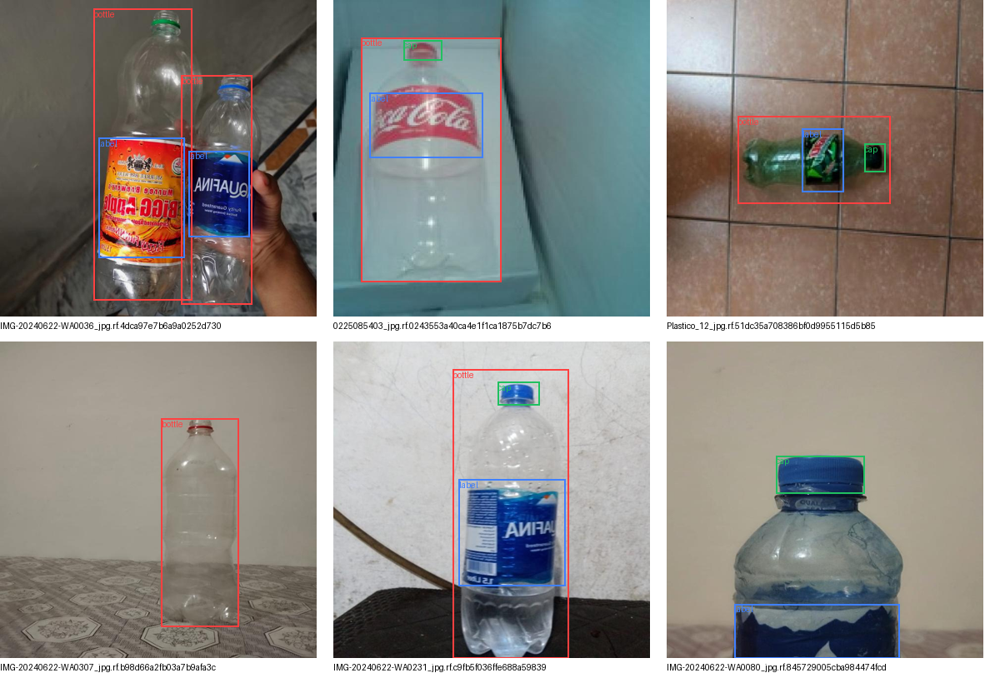

MẪU: val


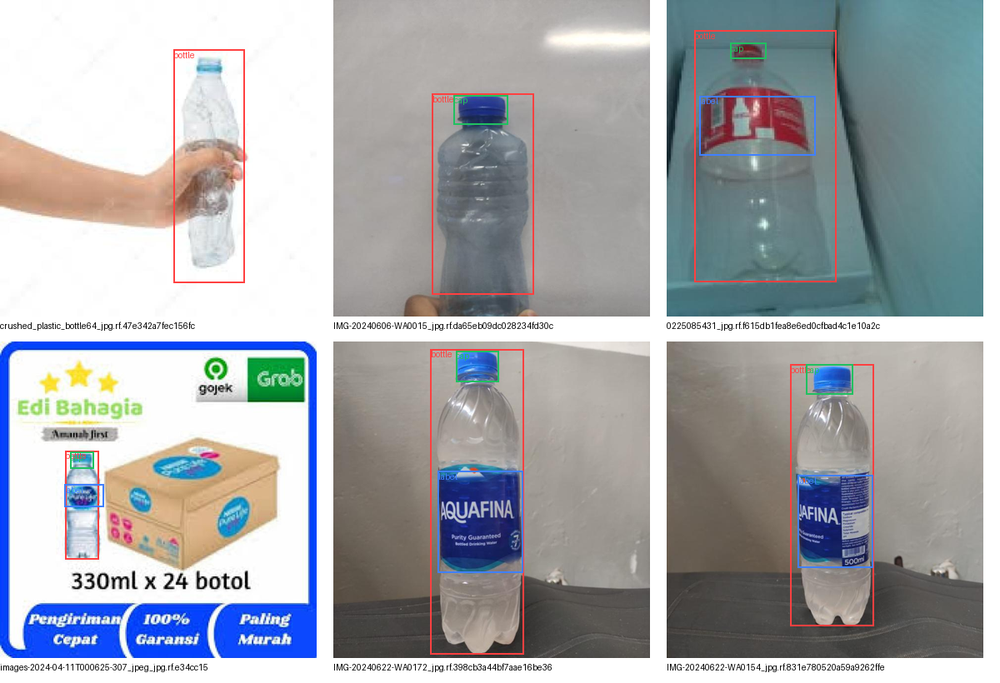

ẢNH KHÔNG CÓ BOX — cần xác nhận là ảnh âm tính hay thiếu nhãn: 0
CẦN SO SÁNH: {'a': 'images/train/0001_jpg.rf.1374f9b6bc1f8a4511e96a0058671482.jpg', 'b': 'images/val/0002_jpg.rf.7d3dfd2375f93a5b77f4854a6b0564ac.jpg', 'distance': 0}


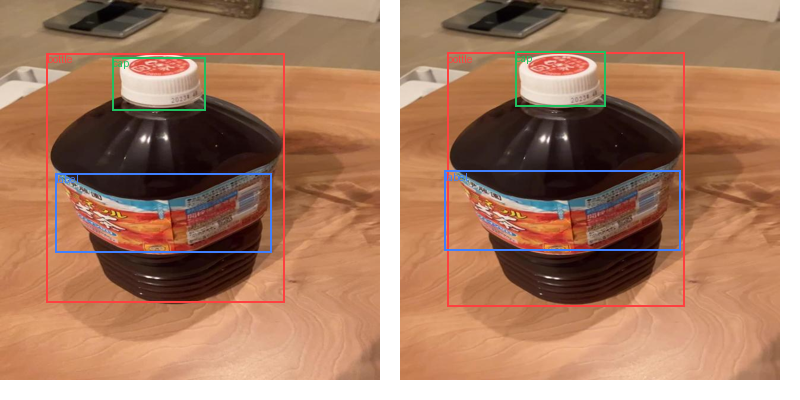

CẦN SO SÁNH: {'a': 'images/train/0217013439_jpg.rf.163a53ce214bec2be6d5fa2cf47af125.jpg', 'b': 'images/test/0217013439_jpg.rf.4995f2188dadac13c8823edb80add12b.jpg', 'distance': 0}


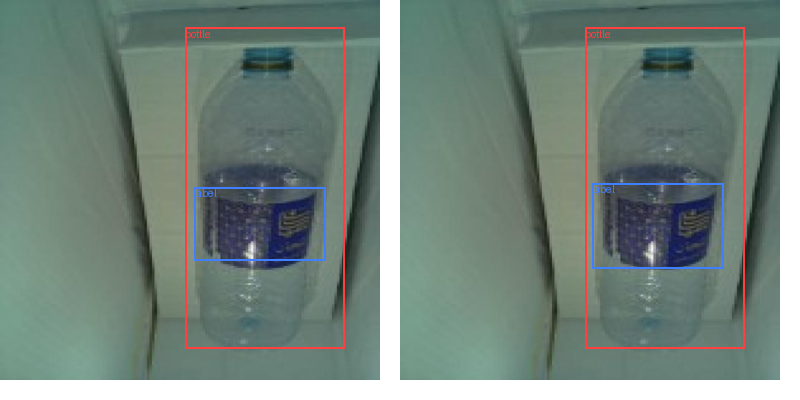

CẦN SO SÁNH: {'a': 'images/train/0217013439_jpg.rf.6dc8aa1c75b776aa620705be87674656.jpg', 'b': 'images/val/0217013439_jpg.rf.e73ec7693beeee7b22a3c92b3aa67739.jpg', 'distance': 4}


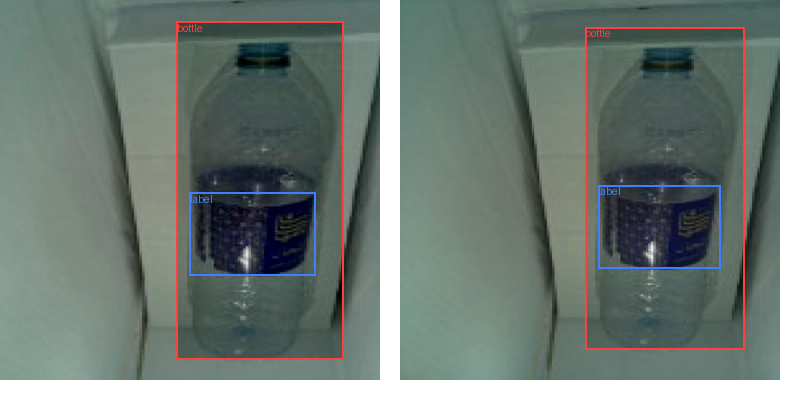

In [11]:
require_cloud()
import random
from IPython.display import display

print("CLEANING:", audit.get("cleaning", {}).get("revision"), "excluded:", audit.get("cleaning", {}).get("excluded_count"))
for item in audit.get("cleaning", {}).get("excluded", []):
    print("EXCLUDED:", item["image"], item["reason"])

COLORS = {"bottle": "#ff4040", "cap": "#20c060", "label": "#4080ff"}
def overlay_record(record, max_size=(380, 380)):
    with Image.open(PREPARED / record["image"]) as image:
        image = image.convert("RGB")
        image.thumbnail(max_size)
        draw = ImageDraw.Draw(image)
        for line in (PREPARED / record["label"]).read_text().splitlines():
            cls, x, y, w, h = line.split()
            x, y, w, h = map(float, (x, y, w, h))
            name = TARGET_NAMES[int(cls)]
            draw.rectangle(((x-w/2)*image.width, (y-h/2)*image.height,
                            (x+w/2)*image.width, (y+h/2)*image.height),
                           outline=COLORS[name], width=2)
            draw.text(((x-w/2)*image.width, (y-h/2)*image.height), name, fill=COLORS[name])
        return image.copy()

for split in ("train", "val"):
    print("MẪU:", split)
    pool = [r for r in records if r["split"] == split]
    chosen = random.Random(42).sample(pool, min(6, len(pool)))
    sheet = Image.new("RGB", (3*400, 2*410), "white")
    for i, record in enumerate(chosen):
        image = overlay_record(record)
        position = ((i % 3)*400, (i // 3)*410)
        sheet.paste(image, position)
        ImageDraw.Draw(sheet).text((position[0], position[1]+385), Path(record["image"]).name[:48], fill="black")
    display(sheet)

lookup = {r["image"]: r for r in records}

for group_number, group in enumerate(audit["cross_split_exact_duplicates"], 1):
    print(f"TRÙNG PIXEL GIỮA SPLIT — nhóm {group_number}:", group)
    columns = min(3, len(group))
    rows_count = (len(group) + columns - 1) // columns
    sheet = Image.new("RGB", (columns * 400, rows_count * 410), "white")
    for i, image_path in enumerate(group):
        record = lookup[image_path]
        image = overlay_record(record)
        position = ((i % columns) * 400, (i // columns) * 410)
        sheet.paste(image, position)
        ImageDraw.Draw(sheet).text(
            (position[0], position[1] + 385),
            f"{record['split']}: {Path(image_path).name[:40]}", fill="black")
    display(sheet)

empty_records = [r for r in records if not (PREPARED / r["label"]).read_text(encoding="utf-8").strip()]
print("ẢNH KHÔNG CÓ BOX — cần xác nhận là ảnh âm tính hay thiếu nhãn:", len(empty_records))
for record in empty_records:
    print("EMPTY_LABEL:", record["split"], record["image"])
    display(overlay_record(record))

for pair in audit["near_duplicate_examples"][:3]:
    print("CẦN SO SÁNH:", pair)
    sheet = Image.new("RGB", (800, 400), "white")
    sheet.paste(overlay_record(lookup[pair["a"]]), (0, 0))
    sheet.paste(overlay_record(lookup[pair["b"]]), (400, 0))
    display(sheet)


## 7. Lưu bản chuẩn hóa và báo cáo vào Drive
Cell xuất một **candidate** để xem xét. Nếu báo ảnh trùng/gần giống khác split, cần xử lý hoặc đánh giá lại split trước khi dùng số đo validation/test. Không tự xóa ảnh hay đổi split tại đây.

In [12]:
require_cloud()
if audit.get("cleaning", {}).get("revision") != "reviewed-2026-11-02-v1" or audit["cleaning"]["excluded_count"] != 6:
    raise RuntimeError("Chạy lại bước 5 bản reviewed-2026-11-02-v1 trước khi lưu candidate.")
if audit["cross_split_exact_duplicates"]:
    raise RuntimeError("Còn ảnh trùng pixel giữa split; cần xem audit trước khi lưu candidate.")
if audit["errors"]:
    raise RuntimeError("Còn lỗi cấu trúc; chưa xuất candidate.")
(PREPARED / "source.json").write_text(json.dumps(source_record, indent=2, ensure_ascii=False), encoding="utf-8")
(PREPARED / "exclusions.json").write_text(json.dumps(audit["cleaning"], indent=2, ensure_ascii=False), encoding="utf-8")
(PREPARED / "audit.json").write_text(json.dumps(audit, indent=2, ensure_ascii=False), encoding="utf-8")
for readme in SOURCE_ROOT.glob("README*"):
    if readme.is_file():
        shutil.copyfile(readme, PREPARED / ("SOURCE_" + readme.name))
prepared_archive = Path(shutil.make_archive(str(WORK / "prepared-candidate"), "zip", PREPARED))
drive_archive = SAVED / prepared_archive.name
shutil.copyfile(prepared_archive, drive_archive)
digest = sha256_file(prepared_archive)
if sha256_file(drive_archive) != digest:
    raise RuntimeError("Bản prepared ZIP trên Drive sai checksum.")
(SAVED / "checksums.json").write_text(json.dumps({
    SOURCE_ZIP.name: source_digest, drive_archive.name: digest,
}, indent=2), encoding="utf-8")
print("CANDIDATE_SAVED:", drive_archive)
print("DATA_YAML của phiên hiện tại:", PREPARED / "data.yaml")
print("REPORT:", SAVED / "audit.json")
print("Dừng ở đây để xem audit và nhãn trước khi training.")


CANDIDATE_SAVED: /content/drive/MyDrive/BottleQC/datasets/industrial-watch-v2/20261102T070951Z-85f802/prepared-candidate.zip
DATA_YAML của phiên hiện tại: /content/bottleqc/industrial-watch-v2/20261102T070951Z-85f802/prepared/data.yaml
REPORT: /content/drive/MyDrive/BottleQC/datasets/industrial-watch-v2/20261102T070951Z-85f802/audit.json
Dừng ở đây để xem audit và nhãn trước khi training.


## 8. Phân tích các cặp gần giống còn lại
Chạy trong cùng Colab kernel sau bước 7. Cell lưu toàn bộ danh sách ứng viên lên Drive, thống kê theo split và độ giống, rồi hiện tối đa 12 cặp có pixel gần nhau nhất với các tổ hợp tên nguồn/split khác nhau. Ảnh preview ở đây không vẽ box để dễ so nội dung ảnh gốc. Đây là công cụ hỗ trợ duyệt; không tự xóa ảnh hoặc quyết định chia lại split.


NEAR_REVIEW_REPORT: /content/drive/MyDrive/BottleQC/datasets/industrial-watch-v2/20261102T070951Z-85f802/near-duplicate-review-v1.csv
{
  "status": "PENDING_VISUAL_REVIEW",
  "pairs": 2065,
  "unique_images_in_candidates": 1084,
  "by_split_pair": {
    "test/train": 599,
    "train/val": 1273,
    "test/val": 193
  },
  "by_dhash_distance": {
    "0": 263,
    "1": 373,
    "2": 367,
    "3": 514,
    "4": 548
  },
  "pairs_with_same_source_name": 320,
  "metric": "Mean absolute RGB difference after resize to 96x96, normalized 0..1; lower means more similar aligned pixels.",
  "limitations": [
    "dHash và RGB có thể nhầm khi cùng nền; có thể bỏ sót ảnh crop/xoay/đổi sáng.",
    "Cùng tên nguồn chỉ hỗ trợ tìm nhóm; không chứng minh là cùng ảnh hoặc cùng phiên quay.",
    "12 ví dụ được ưu tiên theo mức giống nhau; không phải mẫu đại diện cho mọi cặp.",
    "Chưa có quyết định loại ảnh hoặc chia lại split từ kết quả này."
  ]
}
REVIEW_PAIR 1 {'a': 'images/train/Plastico_254_jpg.rf.97c

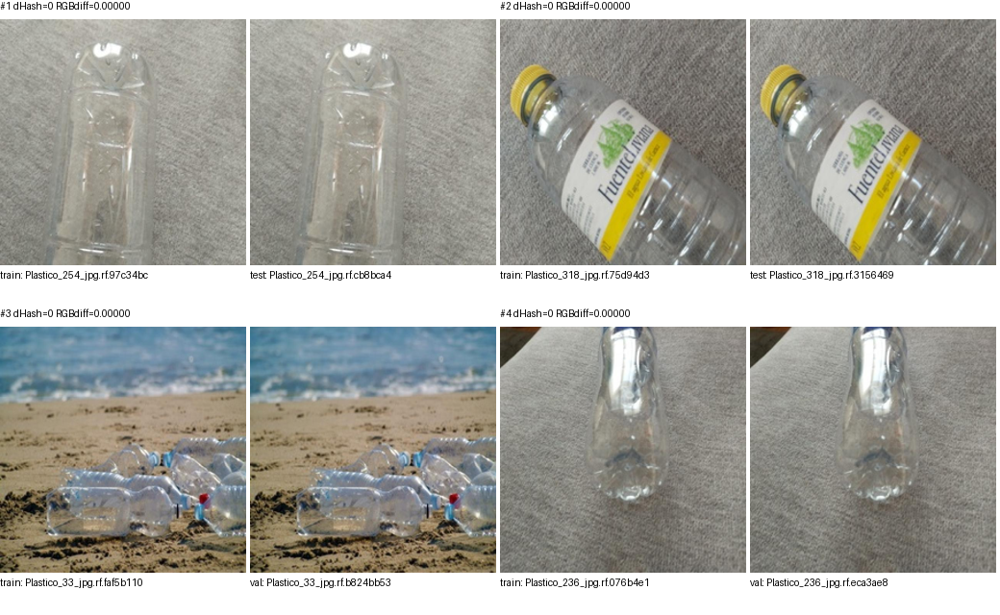

REVIEW_PAIR 5 {'a': 'images/train/Plastico_247_jpg.rf.2a31dba901ea1d8386a6b98a41c2ddc7.jpg', 'b': 'images/test/Plastico_247_jpg.rf.bdbf759fa61f912cc8b5bbcaaef44e20.jpg', 'split_a': 'train', 'split_b': 'test', 'source_key_a': 'Plastico_247_jpg', 'source_key_b': 'Plastico_247_jpg', 'dhash_distance': 0, 'rgb_mean_absolute_difference': 7.091957153231663e-07, 'same_source_key': True}
REVIEW_PAIR 6 {'a': 'images/train/Plastico_299_jpg.rf.e15547aaf144a23a1816a15d80b061fd.jpg', 'b': 'images/val/Plastico_299_jpg.rf.823157c19f77bf92917314a20195cf2d.jpg', 'split_a': 'train', 'split_b': 'val', 'source_key_a': 'Plastico_299_jpg', 'source_key_b': 'Plastico_299_jpg', 'dhash_distance': 0, 'rgb_mean_absolute_difference': 4.113335148874365e-06, 'same_source_key': True}
REVIEW_PAIR 7 {'a': 'images/train/Plastico_337_jpg.rf.9642250770c73a4171f9e675f52d659f.jpg', 'b': 'images/val/Plastico_337_jpg.rf.79411ad5690c943e53db220d4bc9ccc2.jpg', 'split_a': 'train', 'split_b': 'val', 'source_key_a': 'Plastico_337_j

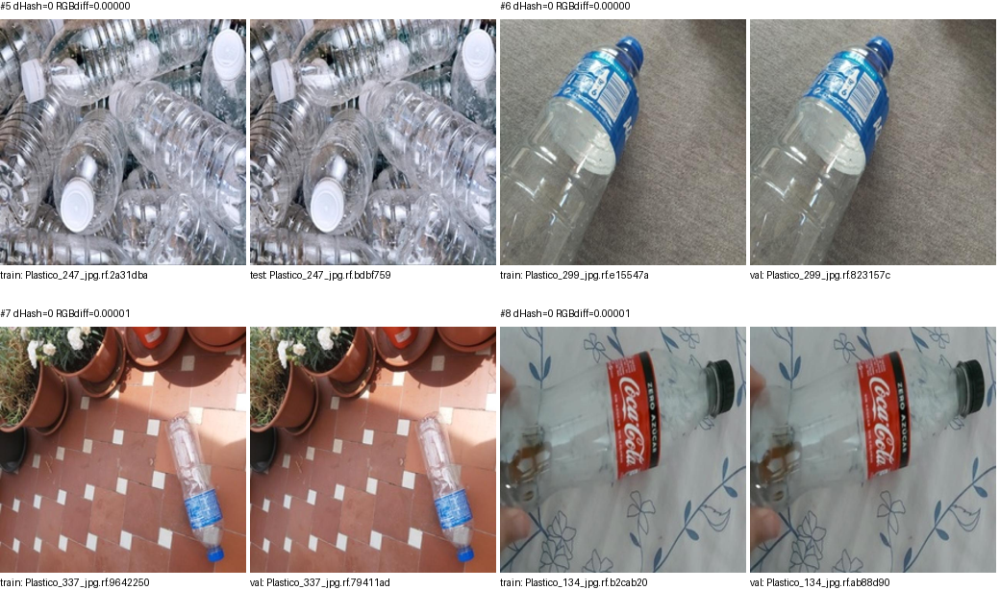

REVIEW_PAIR 9 {'a': 'images/train/Plastico_238_jpg.rf.03c6aa959fd0c52c74039fc8b4415b67.jpg', 'b': 'images/test/Plastico_238_jpg.rf.260abc15e441b8dc6d2a832d2a0c106e.jpg', 'split_a': 'train', 'split_b': 'test', 'source_key_a': 'Plastico_238_jpg', 'source_key_b': 'Plastico_238_jpg', 'dhash_distance': 0, 'rgb_mean_absolute_difference': 1.1488970588235294e-05, 'same_source_key': True}
REVIEW_PAIR 10 {'a': 'images/train/Plastico_263_jpg.rf.bc5bee7f7e0f652bed84164089853117.jpg', 'b': 'images/val/Plastico_263_jpg.rf.e4f96226816ef1391177d1735ae3e65c.jpg', 'split_a': 'train', 'split_b': 'val', 'source_key_a': 'Plastico_263_jpg', 'source_key_b': 'Plastico_263_jpg', 'dhash_distance': 0, 'rgb_mean_absolute_difference': 1.347471859114016e-05, 'same_source_key': True}
REVIEW_PAIR 11 {'a': 'images/train/Plastico_196_jpg.rf.3c5402ee3d092d82a5cdd16806aec6a1.jpg', 'b': 'images/val/Plastico_196_jpg.rf.e2f6093b41379022893568927d4418dc.jpg', 'split_a': 'train', 'split_b': 'val', 'source_key_a': 'Plastico_19

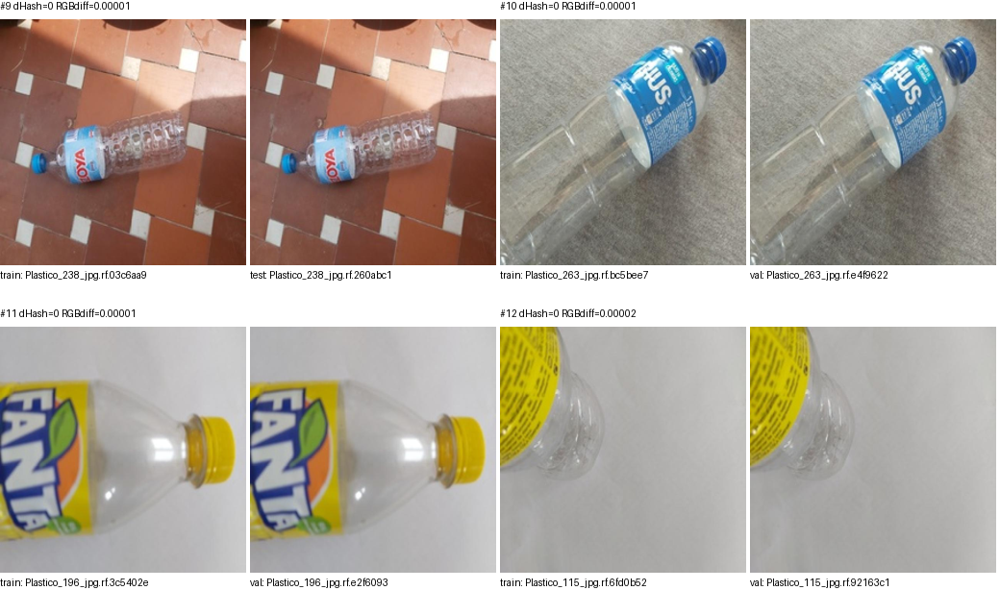

NEAR_REVIEW_READY — lưu notebook (Ctrl+S) để đọc ảnh/output; chưa tự loại thêm ảnh hoặc train.


In [13]:
require_cloud()
import csv
import re
from collections import Counter
from PIL import Image, ImageChops, ImageStat, ImageDraw
from IPython.display import display

if not all(name in globals() for name in ("records", "audit", "PREPARED", "SAVED")):
    raise RuntimeError("Thiếu trạng thái phiên hiện tại. Cần khôi phục candidate đã lưu; không tải lại dataset vội.")
if audit.get("cleaning", {}).get("revision") != "reviewed-2026-11-02-v1" or audit["errors"]:
    raise RuntimeError("Cần bản candidate bước 5 đã lọc 6 ảnh và không có lỗi cấu trúc.")
if not (SAVED / "prepared-candidate.zip").is_file():
    raise RuntimeError("Lưu candidate bằng bước 7 trước khi phân tích tiếp.")

def source_name_key(record):
    return re.sub(r"\.rf\.[^.]+$", "", Path(record["image"]).stem)

def collect_near_pairs(items):
    pairs = []
    for i, first in enumerate(items):
        for second in items[i + 1:]:
            if first["split"] == second["split"] or first["pixel_sha256"] == second["pixel_sha256"]:
                continue
            distance = (first["dhash"] ^ second["dhash"]).bit_count()
            if distance <= 4:
                pairs.append({"a": first["image"], "b": second["image"],
                              "split_a": first["split"], "split_b": second["split"],
                              "source_key_a": source_name_key(first),
                              "source_key_b": source_name_key(second),
                              "dhash_distance": distance})
    return pairs

def rank_near_pairs(pairs, root):
    # This is a comparison aid, not a duplicate decision threshold.
    thumbnails = {}
    for name in sorted({p[k] for p in pairs for k in ("a", "b")}):
        with Image.open(root / name) as picture:
            thumbnails[name] = picture.convert("RGB").resize((96, 96))
    ranked = []
    for pair in pairs:
        difference = ImageChops.difference(thumbnails[pair["a"]], thumbnails[pair["b"]])
        mae = sum(ImageStat.Stat(difference).mean) / (3 * 255)
        ranked.append({**pair, "rgb_mean_absolute_difference": mae,
                       "same_source_key": pair["source_key_a"] == pair["source_key_b"]})
    return sorted(ranked, key=lambda p: (p["rgb_mean_absolute_difference"], p["dhash_distance"], p["a"], p["b"]))

pairs = collect_near_pairs(records)
if len(pairs) != audit["near_duplicate_candidate_count"]:
    raise RuntimeError("Số cặp khác audit bước 5; kiểm tra notebook/kernel trước khi tiếp tục.")
ranked_pairs = rank_near_pairs(pairs, PREPARED)
fields = ["a", "b", "split_a", "split_b", "source_key_a", "source_key_b",
          "dhash_distance", "rgb_mean_absolute_difference", "same_source_key"]
review_csv = SAVED / "near-duplicate-review-v1.csv"
with review_csv.open("w", encoding="utf-8", newline="") as stream:
    writer = csv.DictWriter(stream, fieldnames=fields)
    writer.writeheader()
    writer.writerows(ranked_pairs)

summary = {
    "status": "PENDING_VISUAL_REVIEW", "pairs": len(ranked_pairs),
    "unique_images_in_candidates": len({p[k] for p in ranked_pairs for k in ("a", "b")}),
    "by_split_pair": dict(Counter("/".join(sorted((p["split_a"], p["split_b"]))) for p in ranked_pairs)),
    "by_dhash_distance": dict(sorted(Counter(p["dhash_distance"] for p in ranked_pairs).items())),
    "pairs_with_same_source_name": sum(p["same_source_key"] for p in ranked_pairs),
    "metric": "Mean absolute RGB difference after resize to 96x96, normalized 0..1; lower means more similar aligned pixels.",
    "limitations": [
        "dHash và RGB có thể nhầm khi cùng nền; có thể bỏ sót ảnh crop/xoay/đổi sáng.",
        "Cùng tên nguồn chỉ hỗ trợ tìm nhóm; không chứng minh là cùng ảnh hoặc cùng phiên quay.",
        "12 ví dụ được ưu tiên theo mức giống nhau; không phải mẫu đại diện cho mọi cặp.",
        "Chưa có quyết định loại ảnh hoặc chia lại split từ kết quả này.",
    ],
}
(SAVED / "near-duplicate-review-v1.json").write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding="utf-8")
print("NEAR_REVIEW_REPORT:", review_csv)
print(json.dumps(summary, ensure_ascii=False, indent=2))

# Show up to 12 distinct source-name/split combinations, most visually similar first.
examples, seen = [], set()
for pair in ranked_pairs:
    key = (tuple(sorted((pair["source_key_a"], pair["source_key_b"]))),
           tuple(sorted((pair["split_a"], pair["split_b"]))))
    if key in seen:
        continue
    seen.add(key)
    examples.append(pair)
    if len(examples) == 12:
        break
for start in range(0, len(examples), 4):
    sheet = Image.new("RGB", (1040, 640), "white")
    draw = ImageDraw.Draw(sheet)
    for j, pair in enumerate(examples[start:start + 4]):
        x, y = (j % 2) * 520, (j // 2) * 320
        title = f"#{start+j+1} dHash={pair['dhash_distance']} RGBdiff={pair['rgb_mean_absolute_difference']:.5f}"
        draw.text((x, y), title, fill="black")
        for side, name in enumerate((pair["a"], pair["b"])):
            with Image.open(PREPARED / name) as picture:
                picture = picture.convert("RGB")
                picture.thumbnail((256, 256))
                sheet.paste(picture, (x + side * 260, y + 20))
            draw.text((x + side * 260, y + 280), name.split("/")[1] + ": " + Path(name).name[:27], fill="black")
        print("REVIEW_PAIR", start+j+1, pair)
    display(sheet)
print("NEAR_REVIEW_READY — lưu notebook (Ctrl+S) để đọc ảnh/output; chưa tự loại thêm ảnh hoặc train.")


## 9. Gom nhóm và duyệt toàn bộ ứng viên gần trùng

Nếu kernel cũ còn sống, chạy **9A → 9B → 9C**. Nếu mở runtime mới, mount Drive rồi chạy **9R → 9A → 9B → 9C**. 9R khôi phục candidate và danh sách cặp đã lưu trên Drive, không tải lại dataset nguồn. Nếu VS Code đang mở bản cũ, đóng tab sau khi lưu output cần giữ, rồi mở lại bản trên đĩa.

- **9A** lập nhóm từ **mọi cặp** của bước 8: train–val, train–test, val–test, cùng tên và khác tên nguồn. Mỗi ảnh là một nút; mỗi cặp nghi trùng là một liên kết. Nhóm liên thông chỉ giúp duyệt ảnh liên quan, **không có nghĩa mọi ảnh trong nhóm đều trùng**. Phạm vi vẫn là các ứng viên dHash≤4 của bước 8, có thể bỏ sót ảnh biến đổi khác.
- **9B** chạy một lần để xuất **tất cả nhóm, mọi trang ảnh và mọi trang cặp** vào output notebook và một báo cáo HTML đầy đủ trên Drive. Không đổi GROUP_NUMBER/IMAGE_PAGE/PAIR_PAGE. Tạo một CSV chung cho toàn bộ cặp để nhập quyết định. Điểm ảnh và tên nguồn chỉ hỗ trợ đối chiếu.
- **9C** đọc CSV chung và lưu **cả lô trong một lần chạy**, vẫn giữ quyết định riêng cho **từng cặp**: `duplicate` = cùng ảnh nguồn/bản biến đổi đã xác nhận; `different` = ảnh nguồn khác nhau; `unsure` = chưa đủ căn cứ. Mỗi quyết định cần ghi lý do. Không có thao tác xác nhận cả nhóm theo suy diễn bắc cầu.

Báo cáo và quyết định được lưu trong thư mục Drive của candidate hiện tại. Chạy lại 9A sẽ nạp quyết định đã lưu và kiểm tra đúng candidate/danh sách cặp. Không xóa ảnh, sửa nhãn, chuyển split, tạo candidate mới hoặc train. Ngay cả khi duyệt hết, vẫn phải thống nhất cách xử lý các nhóm trùng và kiểm tra lại split trước training.

### 9R. Khôi phục từ Drive — chỉ dùng khi runtime mới

Nếu kernel cũ vẫn còn trạng thái bước 8, bỏ qua cell này và chạy 9A bên dưới.


In [1]:
import csv
import hashlib
import json
import os
import platform
import shutil
import stat
import zipfile
from pathlib import Path
from google.colab import drive
from IPython.display import display
from PIL import Image, ImageDraw
from collections import Counter, defaultdict
import math
import textwrap
import html
from datetime import datetime, timezone

if platform.system() != "Linux" or not Path("/content").is_dir():
    raise RuntimeError("Cell khôi phục chỉ chạy trong Colab.")
if not os.path.ismount("/content/drive"):
    drive.mount("/content/drive")
DRIVE = Path("/content/drive/MyDrive")
if not DRIVE.is_dir():
    raise RuntimeError("Drive chưa mount đúng tài khoản.")

def require_cloud():
    if platform.system() != "Linux" or not Path("/content").is_dir():
        raise RuntimeError("Chỉ chạy trong kernel Colab.")
    if not os.path.ismount("/content/drive") or not DRIVE.is_dir():
        raise RuntimeError("Google Drive chưa mount trong runtime này.")

def restore_sha256(file_path):
    digest = hashlib.sha256()
    with Path(file_path).open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()

DATA_ROOT = DRIVE / "BottleQC/datasets/industrial-watch-v2"
if not DATA_ROOT.is_dir():
    raise RuntimeError("Không thấy thư mục dataset đã lưu trên Drive.")
run_candidates = []
for folder in DATA_ROOT.iterdir():
    if not folder.is_dir():
        continue
    required_files = ("prepared-candidate.zip", "checksums.json", "audit.json",
                      "near-duplicate-review-v1.csv", "near-duplicate-review-v1.json")
    if all((folder / name).is_file() for name in required_files):
        run_candidates.append(folder)
if not run_candidates:
    raise RuntimeError("Không tìm thấy candidate kèm báo cáo bước 8; không tải lại nguồn. Kiểm tra Drive.")
SAVED = max(run_candidates, key=lambda folder: folder.name)
archive = SAVED / "prepared-candidate.zip"
expected_sha = json.loads((SAVED / "checksums.json").read_text(encoding="utf-8")).get(archive.name)
if not isinstance(expected_sha, str) or restore_sha256(archive) != expected_sha:
    raise RuntimeError("Checksum candidate sai hoặc Drive chưa đồng bộ; dừng khôi phục.")
audit = json.loads((SAVED / "audit.json").read_text(encoding="utf-8"))
if audit.get("errors") or audit.get("cleaning", {}).get("revision") != "reviewed-2026-11-02-v1":
    raise RuntimeError("Candidate không khớp bản đã duyệt; dừng khôi phục.")
summary = json.loads((SAVED / "near-duplicate-review-v1.json").read_text(encoding="utf-8"))
expected_pairs = audit.get("near_duplicate_candidate_count")
if summary.get("pairs") != expected_pairs:
    raise RuntimeError("Số cặp trong báo cáo bước 8 không khớp audit.")
ranked_pairs = []
with (SAVED / "near-duplicate-review-v1.csv").open(encoding="utf-8", newline="") as stream:
    for row in csv.DictReader(stream):
        if row.get("same_source_key") not in ("True", "False"):
            raise RuntimeError("Cờ cùng tên nguồn trong CSV không hợp lệ.")
        ranked_pairs.append({"a": row["a"], "b": row["b"],
                             "split_a": row["split_a"], "split_b": row["split_b"],
                             "source_key_a": row["source_key_a"], "source_key_b": row["source_key_b"],
                             "dhash_distance": int(row["dhash_distance"]),
                             "rgb_mean_absolute_difference": float(row["rgb_mean_absolute_difference"]),
                             "same_source_key": row["same_source_key"] == "True"})
if len(ranked_pairs) != expected_pairs:
    raise RuntimeError("CSV bước 8 không đủ cặp; dừng khôi phục.")

# Extract the reviewed candidate to ephemeral Colab disk, after validating every ZIP path.
restore_root = Path("/content/bottleqc/section9-restored")
restore_root.mkdir(parents=True, exist_ok=True)
PREPARED = restore_root / SAVED.name
if PREPARED.exists():
    raise RuntimeError("Bản giải nén này đã tồn tại; không ghi đè. Dùng runtime mới nếu cần khôi phục lại.")
with zipfile.ZipFile(archive) as source_zip:
    entries = source_zip.infolist()
    seen_paths = set()
    for entry in entries:
        relative = Path(entry.filename)
        if (relative.is_absolute() or ".." in relative.parts or "\\" in entry.filename
                or ":" in entry.filename or stat.S_ISLNK(entry.external_attr >> 16)):
            raise RuntimeError("ZIP candidate có đường dẫn không hợp lệ; dừng giải nén.")
        normalized = relative.as_posix()
        if normalized in seen_paths:
            raise RuntimeError("ZIP candidate có đường dẫn trùng.")
        seen_paths.add(normalized)
    required_bytes = sum(entry.file_size for entry in entries)
    if required_bytes > shutil.disk_usage(restore_root).free:
        raise RuntimeError("Không đủ ổ tạm Colab để giải nén candidate.")
    PREPARED.mkdir(parents=True, exist_ok=False)
    source_zip.extractall(PREPARED)
if not (PREPARED / "data.yaml").is_file() or not (PREPARED / "images").is_dir():
    raise RuntimeError("Candidate ZIP thiếu data.yaml hoặc images.")

print("REVIEW_STATE_RESTORED:", SAVED)
print("Candidate checksum OK; cặp khôi phục:", len(ranked_pairs))
print("Candidate giải nén trên ổ Colab tạm; source ZIP và candidate trên Drive không bị sửa.")
print("Tiếp theo chạy cell 9A rồi xem nhóm đầu bằng 9B. Không chạy lại bước tải nguồn.")


Mounted at /content/drive
REVIEW_STATE_RESTORED: /content/drive/MyDrive/BottleQC/datasets/industrial-watch-v2/20261102T070951Z-85f802
Candidate checksum OK; cặp khôi phục: 2065
Candidate giải nén trên ổ Colab tạm; source ZIP và candidate trên Drive không bị sửa.
Tiếp theo chạy cell 9A rồi xem nhóm đầu bằng 9B. Không chạy lại bước tải nguồn.


### 9A. Dựng nhóm và nạp tiến độ đã lưu

Chạy cell code ngay dưới tiêu đề này trước 9B. Cell kiểm tra candidate, dựng toàn bộ nhóm và nạp lại quyết định đã lưu trên Drive; không xóa tiến độ. Chạy xong sẽ in `GROUP_REVIEW_READY`.


In [8]:
require_cloud()
import csv
import hashlib
import html
import json
import math
import textwrap
from collections import Counter, defaultdict
from datetime import datetime, timezone
from pathlib import Path
from PIL import Image, ImageDraw
from IPython.display import HTML, display

required = ("ranked_pairs", "audit", "PREPARED", "SAVED")
if not all(name in globals() for name in required):
    raise RuntimeError("Thiếu trạng thái bước 8. Khôi phục candidate trên Colab; không tải lại dataset vội.")
if audit.get("errors") or audit.get("cleaning", {}).get("revision") != "reviewed-2026-11-02-v1":
    raise RuntimeError("Candidate không đúng bản đã duyệt sáu ảnh ở bước 5.")
if len(ranked_pairs) != audit["near_duplicate_candidate_count"]:
    raise RuntimeError("Danh sách bước 8 không khớp số cặp trong audit.")
if not (SAVED / "prepared-candidate.zip").is_file():
    raise RuntimeError("Không tìm thấy candidate đã lưu ở bước 7.")
candidate_sha = json.loads((SAVED / "checksums.json").read_text(encoding="utf-8"))["prepared-candidate.zip"]
if len(candidate_sha) != 64 or any(c not in "0123456789abcdef" for c in candidate_sha):
    raise RuntimeError("Checksum candidate không hợp lệ.")
candidate_digest = hashlib.sha256()
with (SAVED / "prepared-candidate.zip").open("rb") as stream:
    for block in iter(lambda: stream.read(1024 * 1024), b""):
        candidate_digest.update(block)
if candidate_digest.hexdigest() != candidate_sha:
    raise RuntimeError("Checksum candidate khác bản bước 7; không tiếp tục review.")

REVIEW_CHOICES = {"duplicate", "different", "unsure"}
PAIR_FIELDS = ["group_number", "group_id", "pair_id", "a", "b", "split_a", "split_b",
               "source_key_a", "source_key_b", "same_source_key", "dhash_distance",
               "rgb_mean_absolute_difference"]

def write_review_json(destination, value):
    temporary = destination.with_name(destination.name + ".tmp")
    temporary.write_text(json.dumps(value, ensure_ascii=False, indent=2), encoding="utf-8")
    temporary.replace(destination)

def write_review_csv(destination, fields, rows):
    temporary = destination.with_name(destination.name + ".tmp")
    with temporary.open("w", encoding="utf-8-sig", newline="") as stream:
        writer = csv.DictWriter(stream, fieldnames=fields)
        writer.writeheader()
        writer.writerows(rows)
    temporary.replace(destination)

def build_review_groups(pairs, root):
    adjacency, edges, image_info = defaultdict(set), {}, {}
    for raw in pairs:
        pair = dict(raw)
        a, b = pair["a"], pair["b"]
        if a == b or pair["split_a"] == pair["split_b"]:
            raise ValueError("Cặp phải gồm hai ảnh khác split.")
        for suffix in ("a", "b"):
            name, split = pair[suffix], pair["split_" + suffix]
            relative = Path(name)
            if (split not in {"train", "val", "test"} or relative.is_absolute()
                    or ".." in relative.parts or "\\" in name
                    or relative.parts[:2] != ("images", split)):
                raise ValueError("Đường dẫn ảnh/split không hợp lệ: " + name)
            target = (root / relative).resolve()
            if not target.is_relative_to(root.resolve()) or not target.is_file():
                raise ValueError("Không tìm thấy ảnh trong candidate: " + name)
            info = {"split": split, "source_key": pair["source_key_" + suffix]}
            if name in image_info and image_info[name] != info:
                raise ValueError("Metadata ảnh không nhất quán: " + name)
            image_info[name] = info
        if pair["same_source_key"] != (pair["source_key_a"] == pair["source_key_b"]):
            raise ValueError("Cờ cùng tên nguồn không khớp.")
        mae = pair["rgb_mean_absolute_difference"]
        distance = pair["dhash_distance"]
        if not math.isfinite(mae) or not 0 <= mae <= 1 or not 0 <= distance <= 4:
            raise ValueError("Điểm giống ảnh không hợp lệ.")
        key = tuple(sorted((a, b)))
        pair_id = "P-" + hashlib.sha256(json.dumps(key).encode()).hexdigest()[:12]
        if pair_id in edges:
            raise ValueError("Cặp bị lặp hoặc mã cặp bị trùng.")
        pair["pair_id"] = pair_id
        edges[pair_id] = pair
        adjacency[a].add(b)
        adjacency[b].add(a)

    components, visited = [], set()
    for seed in sorted(adjacency):
        if seed in visited:
            continue
        members, stack = [], [seed]
        visited.add(seed)
        while stack:
            name = stack.pop()
            members.append(name)
            for neighbour in sorted(adjacency[name]):
                if neighbour not in visited:
                    visited.add(neighbour)
                    stack.append(neighbour)
        members.sort()
        components.append({"members": members, "pairs": []})
    by_image = {name: group for group in components for name in group["members"]}
    for pair in edges.values():
        by_image[pair["a"]]["pairs"].append(pair)
    for group in components:
        group["pairs"].sort(key=lambda p: (not p["same_source_key"],
                                             p["rgb_mean_absolute_difference"], p["pair_id"]))
    components.sort(key=lambda g: (not any(p["same_source_key"] for p in g["pairs"]),
                                   min(p["rgb_mean_absolute_difference"] for p in g["pairs"]),
                                   g["members"]))
    group_ids = set()
    for number, group in enumerate(components, 1):
        group_id = "G-" + hashlib.sha256(json.dumps(group["members"]).encode()).hexdigest()[:12]
        if group_id in group_ids:
            raise ValueError("Mã nhóm bị trùng.")
        group_ids.add(group_id)
        group.update(group_number=number, group_id=group_id)
        for pair in group["pairs"]:
            pair.update(group_number=number, group_id=group_id)
    return components, edges, image_info

review_groups, review_pairs, review_images = build_review_groups(ranked_pairs, PREPARED)
signature = {"candidate_sha256": candidate_sha,
             "pairs": sorted(ranked_pairs, key=lambda p: (p["a"], p["b"]))}
review_fingerprint = hashlib.sha256(json.dumps(signature, sort_keys=True).encode()).hexdigest()
review_state_file = SAVED / "near-duplicate-decisions-v1.json"

def load_review_decisions():
    if not review_state_file.exists():
        return {}
    state = json.loads(review_state_file.read_text(encoding="utf-8"))
    if state.get("schema") != 1 or state.get("fingerprint") != review_fingerprint:
        raise RuntimeError("Quyết định đã lưu thuộc candidate/danh sách cặp khác; không ghi đè.")
    decisions = state["decisions"]
    if not isinstance(decisions, dict):
        raise ValueError("File quyết định sai cấu trúc.")
    for pair_id, entry in decisions.items():
        if (pair_id not in review_pairs or entry["decision"] not in REVIEW_CHOICES
                or not isinstance(entry["note"], str) or not entry["note"].strip()):
            raise ValueError("Quyết định đã lưu không hợp lệ: " + pair_id)
    return decisions

def review_progress(decisions):
    counts = Counter(entry["decision"] for entry in decisions.values())
    return {"pairs": len(review_pairs), "images": len(review_images), "groups": len(review_groups),
            "pending": len(review_pairs) - len(decisions),
            "duplicate": counts["duplicate"], "different": counts["different"], "unsure": counts["unsure"],
            "unresolved": len(review_pairs) - counts["duplicate"] - counts["different"],
            "split_cleaning": "NOT_APPLIED"}

def export_review_progress(decisions):
    rows = []
    for group in review_groups:
        for pair in group["pairs"]:
            entry = decisions.get(pair["pair_id"], {})
            rows.append({**{key: pair[key] for key in PAIR_FIELDS},
                         "decision": entry.get("decision", "pending"), "note": entry.get("note", ""),
                         "updated_at": entry.get("updated_at", "")})
    write_review_csv(SAVED / "near-duplicate-decisions-v1.csv",
                     PAIR_FIELDS + ["decision", "note", "updated_at"], rows)
    write_review_json(SAVED / "near-duplicate-progress-v1.json", review_progress(decisions))

def save_review_decisions(updates):
    require_cloud()
    if not isinstance(updates, dict):
        raise ValueError("Dùng dict mã cặp → decision/note.")
    # Read the durable state again so rerunning a cell preserves other recorded pairs.
    decisions = load_review_decisions()
    timestamp = datetime.now(timezone.utc).isoformat()
    for pair_id, entry in updates.items():
        if pair_id not in review_pairs:
            raise ValueError("Mã cặp không tồn tại: " + pair_id)
        if (not isinstance(entry, dict) or set(entry) != {"decision", "note"}
                or entry["decision"] not in REVIEW_CHOICES
                or not isinstance(entry["note"], str) or not entry["note"].strip()):
            raise ValueError("Cần decision hợp lệ và note không rỗng cho " + pair_id)
        decisions[pair_id] = {"decision": entry["decision"], "note": entry["note"].strip(),
                              "updated_at": timestamp}
    # Validate the entire batch before writing anything; JSON is the authoritative record.
    if updates:
        write_review_json(review_state_file, {"schema": 1, "fingerprint": review_fingerprint,
                          "candidate_sha256": candidate_sha, "decisions": decisions})
    export_review_progress(decisions)
    print(json.dumps(review_progress(decisions), ensure_ascii=False, indent=2))
    print("DECISIONS_SAVED:", review_state_file if review_state_file.exists() else "Chưa nhập quyết định")
    print("Chỉ ghi kết quả duyệt; candidate và các split chưa thay đổi.")

def show_review_group(number, image_page=1, pair_page=1, *, decisions=None, emit=None):
    require_cloud()
    if not 1 <= number <= len(review_groups):
        raise ValueError(f"GROUP_NUMBER phải từ 1 đến {len(review_groups)}.")
    group = review_groups[number - 1]
    image_pages = math.ceil(len(group["members"]) / 6)
    pair_pages = math.ceil(len(group["pairs"]) / 4)
    if ((image_page is not None and not 1 <= image_page <= image_pages)
            or (pair_page is not None and not 1 <= pair_page <= pair_pages)):
        raise ValueError(f"IMAGE_PAGE: 1..{image_pages}; PAIR_PAGE: 1..{pair_pages}.")
    if decisions is None:
        decisions = load_review_decisions()
    if emit is None:
        emit = display
    print(f"GROUP {number}/{len(review_groups)} {group['group_id']} | "
          f"{len(group['members'])} ảnh, {len(group['pairs'])} cặp")
    print("Split:", dict(Counter(review_images[name]["split"] for name in group["members"])))
    print("Quyết định:", dict(Counter(decisions.get(p["pair_id"], {}).get("decision", "pending")
                                       for p in group["pairs"])))
    print(f"Ảnh trang {image_page}/{image_pages}; cặp trang {pair_page}/{pair_pages}. "
          "Nhóm liên thông không phải kết luận trùng.")
    if image_page is not None:
        members = group["members"][(image_page - 1) * 6:image_page * 6]
        gallery = Image.new("RGB", (960, 320 * math.ceil(len(members) / 3)), "white")
        draw = ImageDraw.Draw(gallery)
        for index, name in enumerate(members):
            x, y = (index % 3) * 320, (index // 3) * 320
            member_number = group["members"].index(name) + 1
            draw.text((x + 4, y + 2), f"Image {member_number} | {review_images[name]['split']}", fill="black")
            with Image.open(PREPARED / name) as picture:
                picture = picture.convert("RGB")
                picture.thumbnail((310, 240))
                gallery.paste(picture, (x + 4, y + 22))
            draw.text((x + 4, y + 264), "\n".join(textwrap.wrap(Path(name).name, 42)), fill="black")
        emit(gallery)
        emit(HTML("<p>Đường dẫn ảnh trên trang:</p><ol>" + "".join(
            "<li>Image " + str(group["members"].index(name) + 1) + ": <code>" + html.escape(name) + "</code></li>"
            for name in members) + "</ol>"))
    if pair_page is not None:
        visible_pairs = group["pairs"][(pair_page - 1) * 4:pair_page * 4]
        sheet = Image.new("RGB", (1040, 340 * math.ceil(len(visible_pairs) / 2)), "white")
        draw = ImageDraw.Draw(sheet)
        table_rows = []
        for index, pair in enumerate(visible_pairs):
            x, y = (index % 2) * 520, (index // 2) * 340
            pair_id = pair["pair_id"]
            entry = decisions.get(pair_id, {})
            decision = entry.get("decision", "pending")
            draw.text((x + 2, y + 2), f"{pair_id} | {decision}", fill="black")
            draw.text((x + 2, y + 18), f"dHash={pair['dhash_distance']} RGB={pair['rgb_mean_absolute_difference']:.3g} "
                      f"same_name={pair['same_source_key']}", fill="black")
            for side, key in enumerate(("a", "b")):
                name = pair[key]
                with Image.open(PREPARED / name) as picture:
                    picture = picture.convert("RGB")
                    picture.thumbnail((252, 238))
                    sheet.paste(picture, (x + side * 260 + 2, y + 38))
                caption = f"Image {group['members'].index(name) + 1} | {pair['split_' + key]}"
                draw.text((x + side * 260 + 2, y + 280), caption, fill="black")
                draw.text((x + side * 260 + 2, y + 296),
                          "\n".join(textwrap.wrap(Path(name).name, 33)), fill="black")
            values = [pair_id, pair["a"], pair["b"], decision, entry.get("note", "")]
            table_rows.append("<tr>" + "".join("<td>" + html.escape(value) + "</td>" for value in values) + "</tr>")
        emit(sheet)
        emit(HTML("<table><thead><tr><th>pair_id</th><th>Ảnh A</th><th>Ảnh B</th>"
                     "<th>Quyết định</th><th>Lý do</th></tr></thead><tbody>" + "".join(table_rows) + "</tbody></table>"))
    print("Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.")

existing_decisions = load_review_decisions()  # Reject mismatched state before updating reports.
write_review_json(SAVED / "near-duplicate-groups-v1.json", {
    "schema": 1, "fingerprint": review_fingerprint, "candidate_sha256": candidate_sha,
    "meaning": "Connected candidate groups for review, not confirmed duplicate groups",
    "groups": review_groups})
write_review_csv(SAVED / "near-duplicate-group-pairs-v1.csv", PAIR_FIELDS,
                 ({key: pair[key] for key in PAIR_FIELDS} for group in review_groups for pair in group["pairs"]))
write_review_csv(SAVED / "near-duplicate-group-images-v1.csv",
                 ["group_number", "group_id", "image_number", "image", "split", "source_key"],
                 ({"group_number": group["group_number"], "group_id": group["group_id"],
                   "image_number": index, "image": name, **review_images[name]}
                  for group in review_groups for index, name in enumerate(group["members"], 1)))
export_review_progress(existing_decisions)
print("GROUP_REVIEW_READY:", SAVED)
print(json.dumps(review_progress(existing_decisions), ensure_ascii=False, indent=2))
print("Cặp theo split:", dict(Counter("/".join(sorted((p["split_a"], p["split_b"])))
                                     for p in review_pairs.values())))
print("Cùng tên nguồn:", sum(p["same_source_key"] for p in review_pairs.values()),
      "| Khác tên nguồn:", sum(not p["same_source_key"] for p in review_pairs.values()))
print("Chạy 9B một lần để xuất toàn bộ nhóm và mọi trang. Chưa xác nhận thêm cặp nào và chưa thay đổi candidate.")

GROUP_REVIEW_READY: /content/drive/MyDrive/BottleQC/datasets/industrial-watch-v2/20261102T070951Z-85f802
{
  "pairs": 2065,
  "images": 1084,
  "groups": 166,
  "pending": 2062,
  "duplicate": 3,
  "different": 0,
  "unsure": 0,
  "unresolved": 2062,
  "split_cleaning": "NOT_APPLIED"
}
Cặp theo split: {'test/train': 599, 'train/val': 1273, 'test/val': 193}
Cùng tên nguồn: 320 | Khác tên nguồn: 1745
Chạy 9B một lần để xuất toàn bộ nhóm và mọi trang. Chưa xác nhận thêm cặp nào và chưa thay đổi candidate.


### 9B. Xuất toàn bộ nhóm và cặp — chạy một lần

**Chạy lại 9A trước khi chạy bản 9B mới này.** Cell tự chạy từ nhóm đầu đến nhóm cuối và hết mọi trang, kể cả nhóm lớn. Không cần sửa số nhóm. Output dùng JPEG để giảm dung lượng; báo cáo HTML tự chứa đầy đủ ảnh, cặp, đường dẫn và quyết định hiện tại được lưu trên Drive. Có thể tải riêng HTML để mở bằng trình duyệt; không cần tải dataset. Output dài nên Colab/VS Code có thể thu gọn; HTML là bản đầy đủ. Nếu bị ngắt, chạy lại cell; chỉ file HTML hoàn tất mới được báo `ALL_GROUPS_EXPORTED`.

CSV `near-duplicate-review-input-v1.csv` có **mỗi cặp một dòng**. Mở bằng trình sửa CSV/Sheets, chỉ sửa `decision` (`duplicate`/`different`/`unsure`) và `note` (lý do), rồi lưu CSV UTF-8 trở lại đúng đường dẫn Drive được in ra. Giữ nguyên các cột định danh, đủ mọi dòng và định dạng CSV dấu phẩy. Mặc định cặp chưa duyệt là `pending`. CSV đã tồn tại được giữ nguyên khi chạy lại 9B, tránh mất phần nhập dở. 9B không lưu quyết định hay thay đổi candidate.


BATCH_CSV_CREATED: /content/drive/MyDrive/BottleQC/datasets/industrial-watch-v2/20261102T070951Z-85f802/near-duplicate-review-input-v1.csv


GROUP 1/166 G-27202e8c80ec | 2 ảnh, 1 cặp
Split: {'test': 1, 'train': 1}
Quyết định: {'duplicate': 1}
Ảnh trang 1/1; cặp trang 1/1. Nhóm liên thông không phải kết luận trùng.


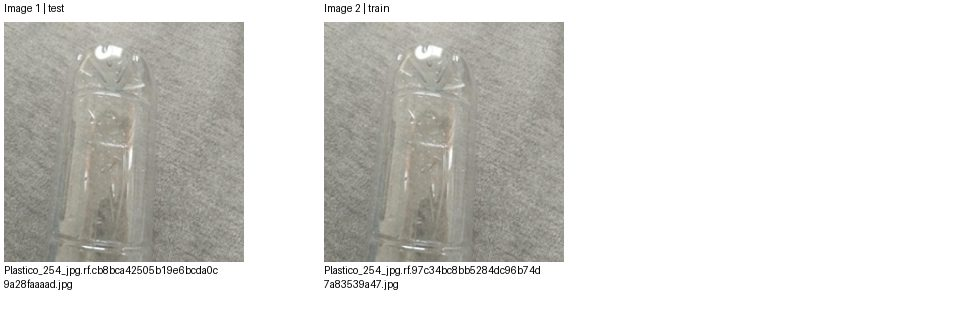

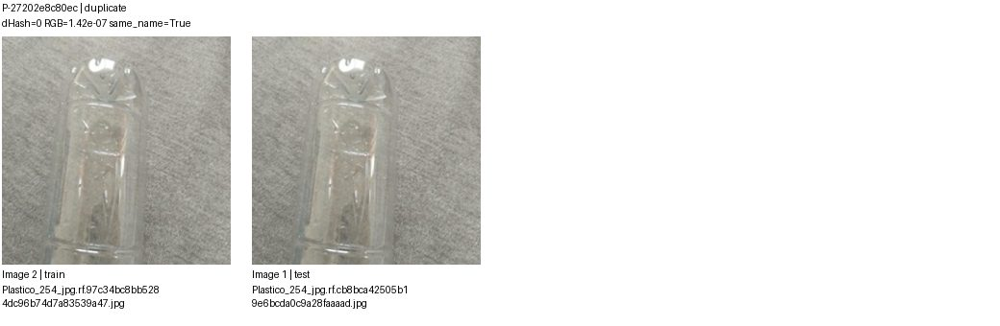

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-27202e8c80ec,images/train/Plastico_254_jpg.rf.97c34bc8bb5284dc96b74d7a83539a47.jpg,images/test/Plastico_254_jpg.rf.cb8bca42505b19e6bcda0c9a28faaaad.jpg,duplicate,"Visually reviewed group 1: same bottle, pose, grey background and reflection details in the train/test copies. Replaces the previous encoding-damaged note."


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 2/166 G-e06fd2973317 | 3 ảnh, 2 cặp
Split: {'test': 1, 'train': 2}
Quyết định: {'duplicate': 2}
Ảnh trang 1/1; cặp trang 1/1. Nhóm liên thông không phải kết luận trùng.


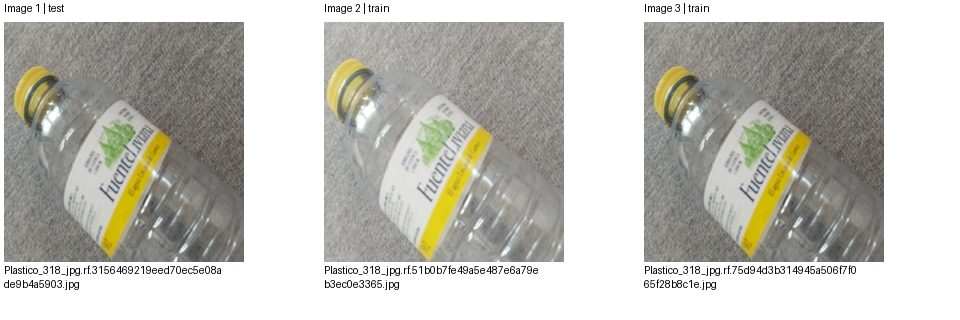

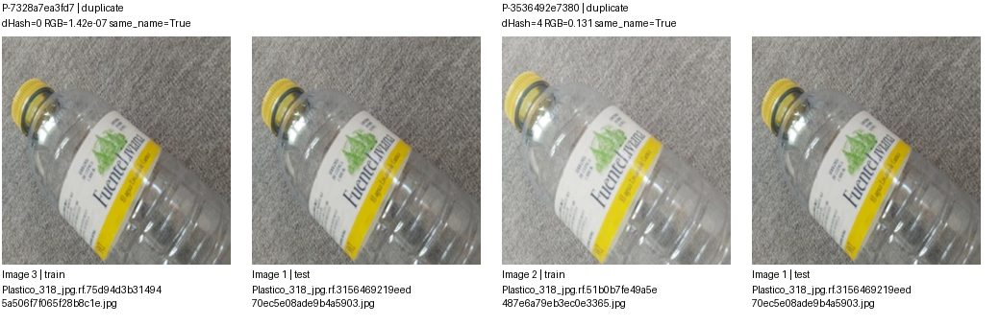

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-7328a7ea3fd7,images/train/Plastico_318_jpg.rf.75d94d3b314945a506f7f065f28b8c1e.jpg,images/test/Plastico_318_jpg.rf.3156469219eed70ec5e08ade9b4a5903.jpg,duplicate,"Visually reviewed group 2 pair: identical bottle pose, cap, label details and background texture in the train/test copies."
P-3536492e7380,images/train/Plastico_318_jpg.rf.51b0b7fe49a5e487e6a79eb3ec0e3365.jpg,images/test/Plastico_318_jpg.rf.3156469219eed70ec5e08ade9b4a5903.jpg,duplicate,"Visually reviewed group 2 pair: same source photograph; the train image is brighter, with matching bottle geometry, label and background texture."


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 3/166 G-2a4e3a316c83 | 3 ảnh, 2 cặp
Split: {'train': 2, 'val': 1}
Quyết định: {'pending': 2}
Ảnh trang 1/1; cặp trang 1/1. Nhóm liên thông không phải kết luận trùng.


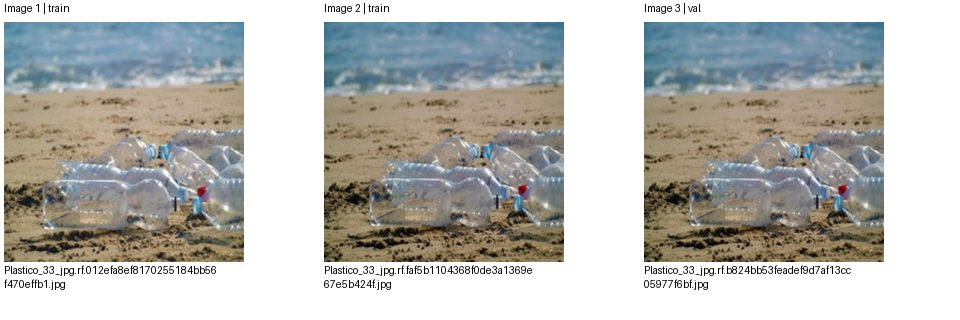

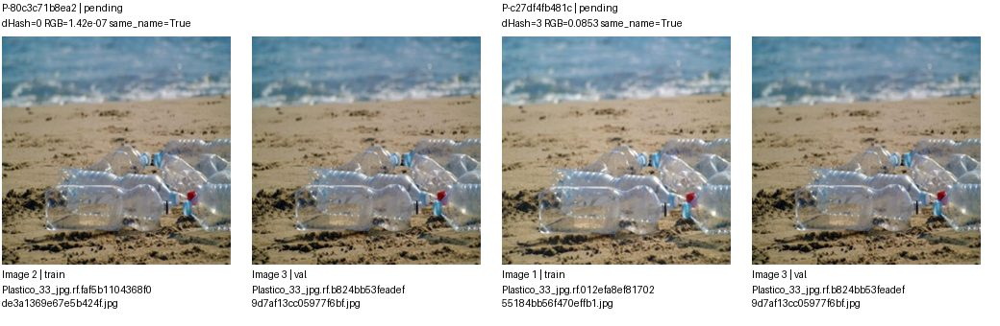

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-80c3c71b8ea2,images/train/Plastico_33_jpg.rf.faf5b1104368f0de3a1369e67e5b424f.jpg,images/val/Plastico_33_jpg.rf.b824bb53feadef9d7af13cc05977f6bf.jpg,pending,
P-c27df4fb481c,images/train/Plastico_33_jpg.rf.012efa8ef8170255184bb56f470effb1.jpg,images/val/Plastico_33_jpg.rf.b824bb53feadef9d7af13cc05977f6bf.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 4/166 G-d863994218c1 | 2 ảnh, 1 cặp
Split: {'train': 1, 'val': 1}
Quyết định: {'pending': 1}
Ảnh trang 1/1; cặp trang 1/1. Nhóm liên thông không phải kết luận trùng.


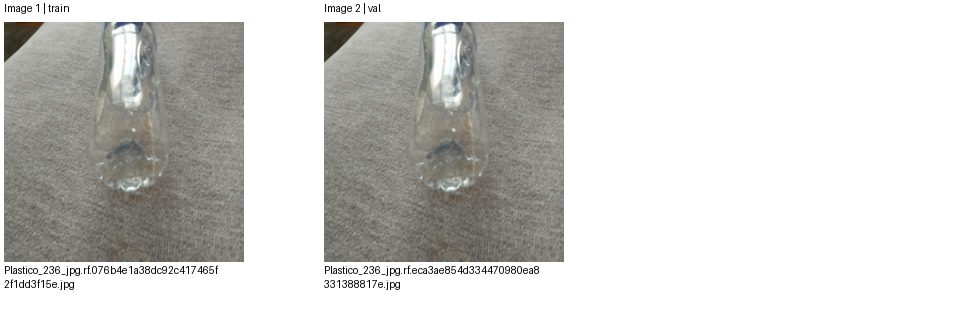

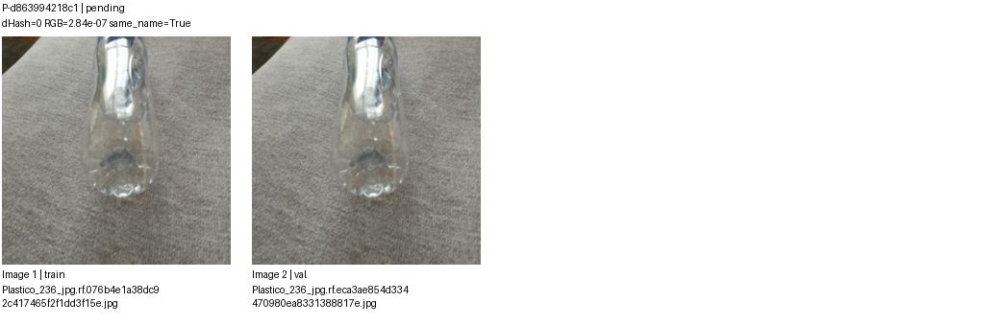

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-d863994218c1,images/train/Plastico_236_jpg.rf.076b4e1a38dc92c417465f2f1dd3f15e.jpg,images/val/Plastico_236_jpg.rf.eca3ae854d334470980ea8331388817e.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 5/166 G-917cdea3cb50 | 2 ảnh, 1 cặp
Split: {'test': 1, 'train': 1}
Quyết định: {'pending': 1}
Ảnh trang 1/1; cặp trang 1/1. Nhóm liên thông không phải kết luận trùng.


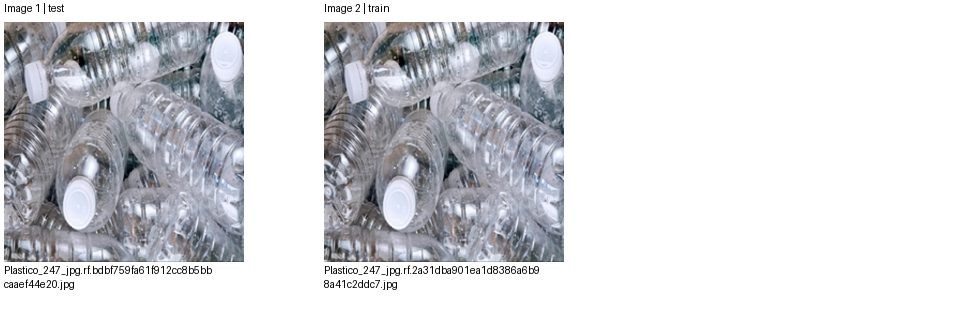

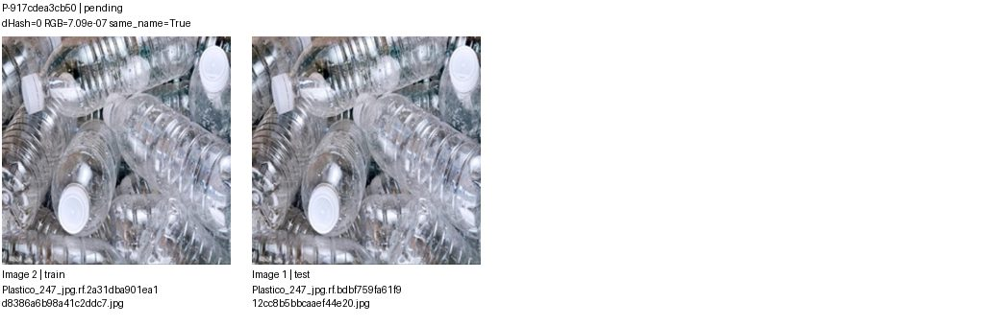

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-917cdea3cb50,images/train/Plastico_247_jpg.rf.2a31dba901ea1d8386a6b98a41c2ddc7.jpg,images/test/Plastico_247_jpg.rf.bdbf759fa61f912cc8b5bbcaaef44e20.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 6/166 G-0b182b811468 | 2 ảnh, 1 cặp
Split: {'train': 1, 'val': 1}
Quyết định: {'pending': 1}
Ảnh trang 1/1; cặp trang 1/1. Nhóm liên thông không phải kết luận trùng.


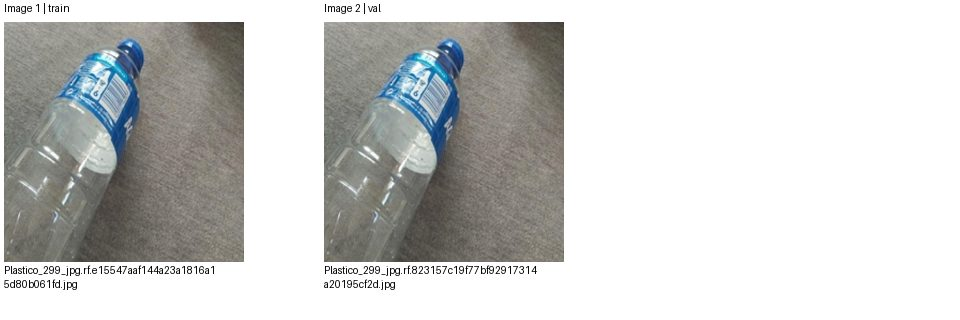

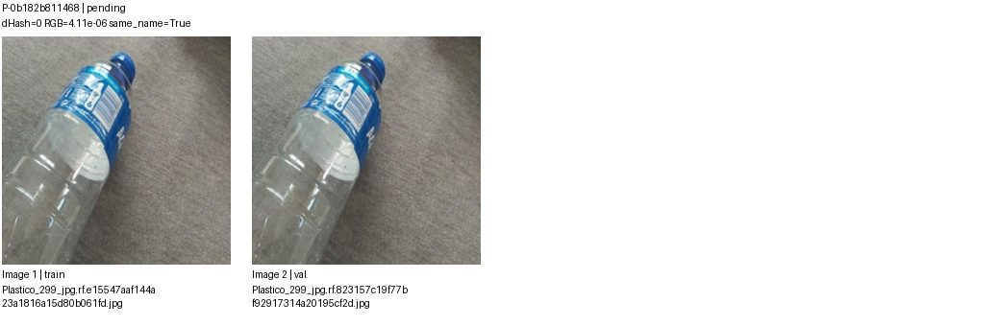

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-0b182b811468,images/train/Plastico_299_jpg.rf.e15547aaf144a23a1816a15d80b061fd.jpg,images/val/Plastico_299_jpg.rf.823157c19f77bf92917314a20195cf2d.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 7/166 G-b7786c515044 | 2 ảnh, 1 cặp
Split: {'train': 1, 'val': 1}
Quyết định: {'pending': 1}
Ảnh trang 1/1; cặp trang 1/1. Nhóm liên thông không phải kết luận trùng.


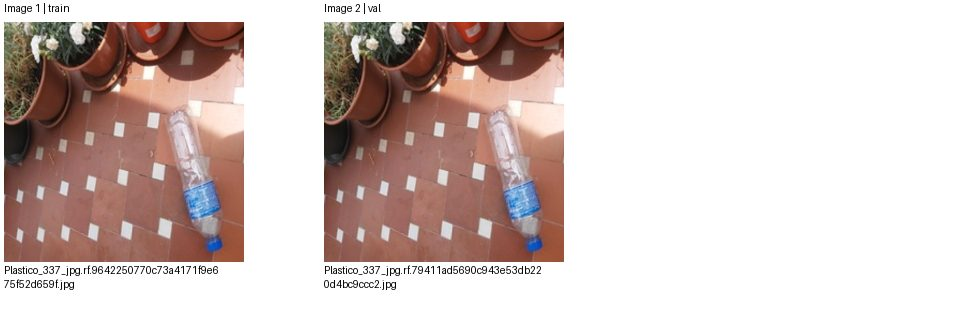

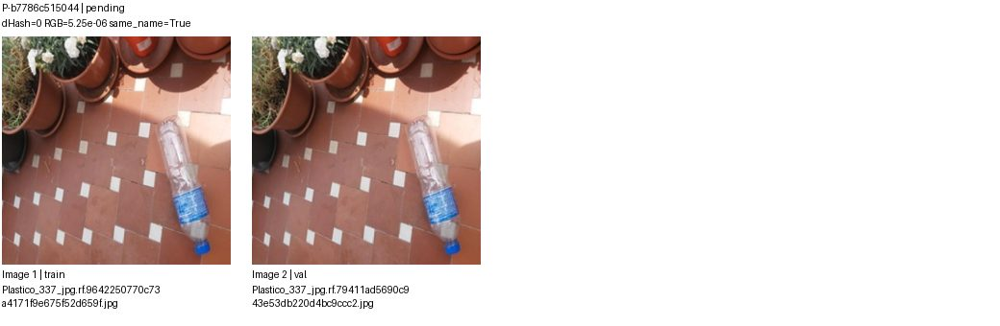

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-b7786c515044,images/train/Plastico_337_jpg.rf.9642250770c73a4171f9e675f52d659f.jpg,images/val/Plastico_337_jpg.rf.79411ad5690c943e53db220d4bc9ccc2.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 8/166 G-e420e3980126 | 3 ảnh, 2 cặp
Split: {'train': 2, 'val': 1}
Quyết định: {'pending': 2}
Ảnh trang 1/1; cặp trang 1/1. Nhóm liên thông không phải kết luận trùng.


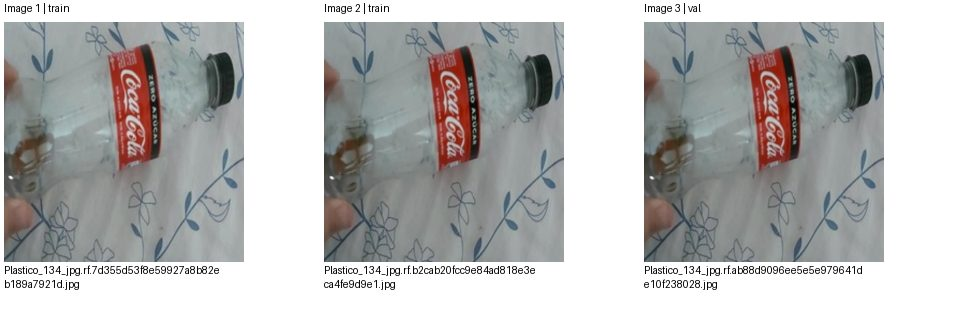

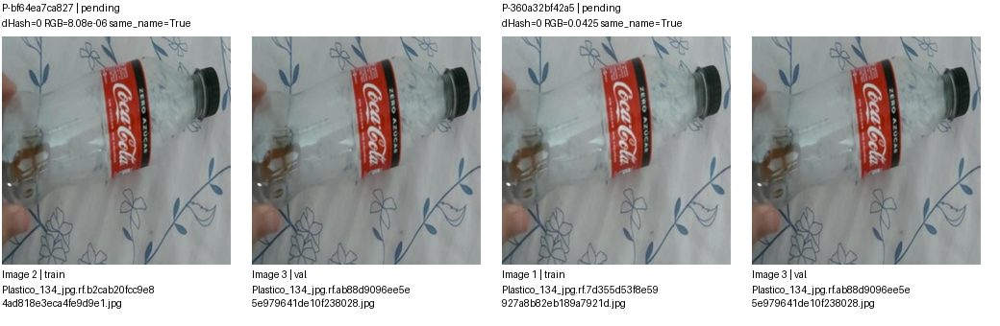

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-bf64ea7ca827,images/train/Plastico_134_jpg.rf.b2cab20fcc9e84ad818e3eca4fe9d9e1.jpg,images/val/Plastico_134_jpg.rf.ab88d9096ee5e5e979641de10f238028.jpg,pending,
P-360a32bf42a5,images/train/Plastico_134_jpg.rf.7d355d53f8e59927a8b82eb189a7921d.jpg,images/val/Plastico_134_jpg.rf.ab88d9096ee5e5e979641de10f238028.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 9/166 G-153ccc3381d2 | 3 ảnh, 2 cặp
Split: {'test': 1, 'train': 2}
Quyết định: {'pending': 2}
Ảnh trang 1/1; cặp trang 1/1. Nhóm liên thông không phải kết luận trùng.


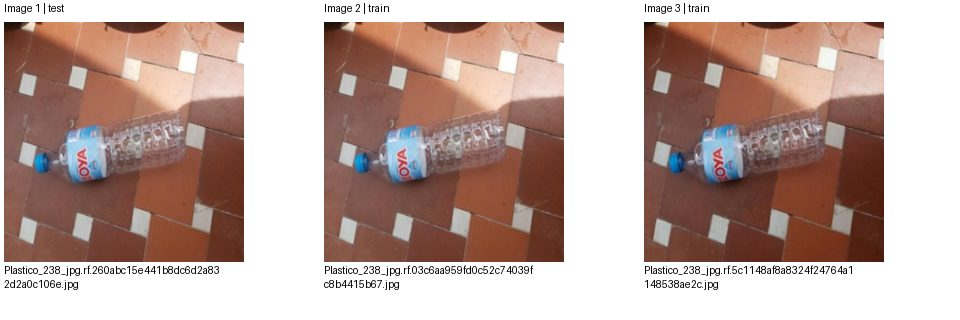

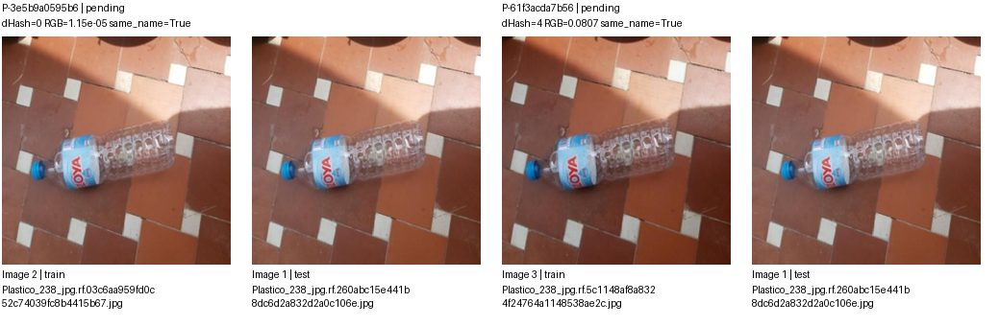

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-3e5b9a0595b6,images/train/Plastico_238_jpg.rf.03c6aa959fd0c52c74039fc8b4415b67.jpg,images/test/Plastico_238_jpg.rf.260abc15e441b8dc6d2a832d2a0c106e.jpg,pending,
P-61f3acda7b56,images/train/Plastico_238_jpg.rf.5c1148af8a8324f24764a1148538ae2c.jpg,images/test/Plastico_238_jpg.rf.260abc15e441b8dc6d2a832d2a0c106e.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 10/166 G-a2bfcdfc556f | 2 ảnh, 1 cặp
Split: {'train': 1, 'val': 1}
Quyết định: {'pending': 1}
Ảnh trang 1/1; cặp trang 1/1. Nhóm liên thông không phải kết luận trùng.


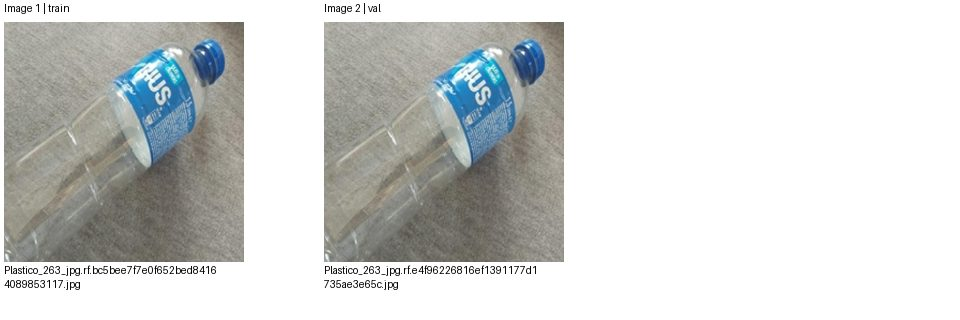

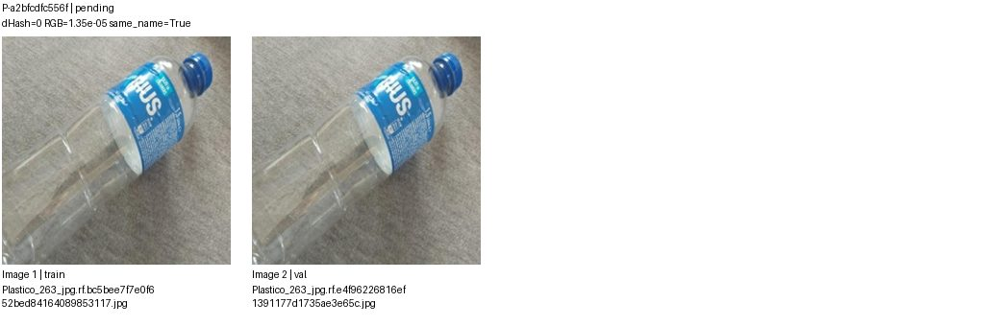

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-a2bfcdfc556f,images/train/Plastico_263_jpg.rf.bc5bee7f7e0f652bed84164089853117.jpg,images/val/Plastico_263_jpg.rf.e4f96226816ef1391177d1735ae3e65c.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 11/166 G-1185f35da8d4 | 3 ảnh, 2 cặp
Split: {'train': 2, 'val': 1}
Quyết định: {'pending': 2}
Ảnh trang 1/1; cặp trang 1/1. Nhóm liên thông không phải kết luận trùng.


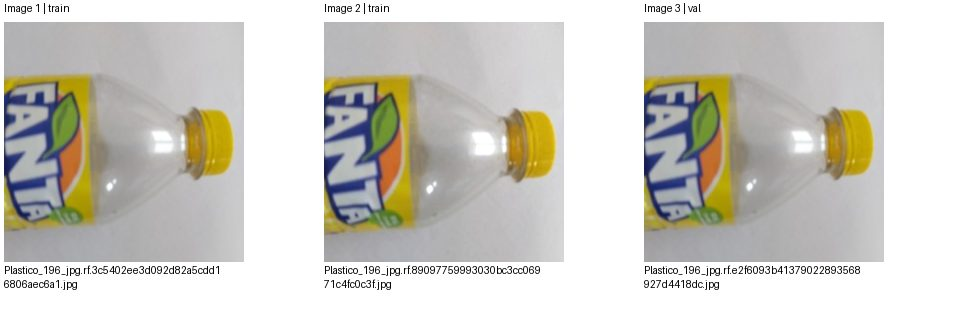

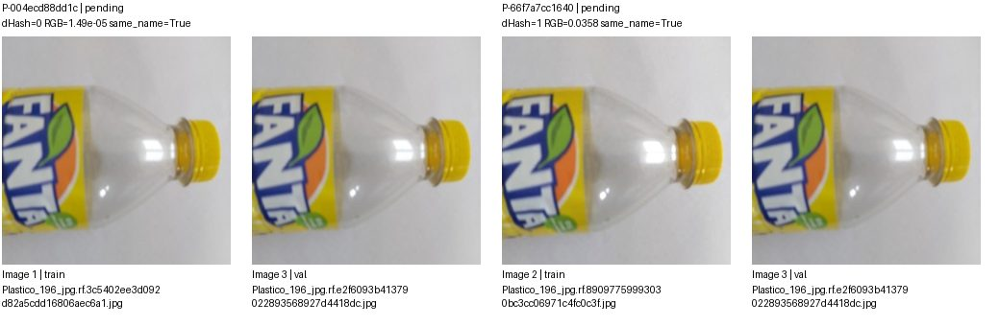

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-004ecd88dd1c,images/train/Plastico_196_jpg.rf.3c5402ee3d092d82a5cdd16806aec6a1.jpg,images/val/Plastico_196_jpg.rf.e2f6093b41379022893568927d4418dc.jpg,pending,
P-66f7a7cc1640,images/train/Plastico_196_jpg.rf.89097759993030bc3cc06971c4fc0c3f.jpg,images/val/Plastico_196_jpg.rf.e2f6093b41379022893568927d4418dc.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 12/166 G-acd8ba6b5372 | 4 ảnh, 3 cặp
Split: {'train': 3, 'val': 1}
Quyết định: {'pending': 3}
Ảnh trang 1/1; cặp trang 1/1. Nhóm liên thông không phải kết luận trùng.


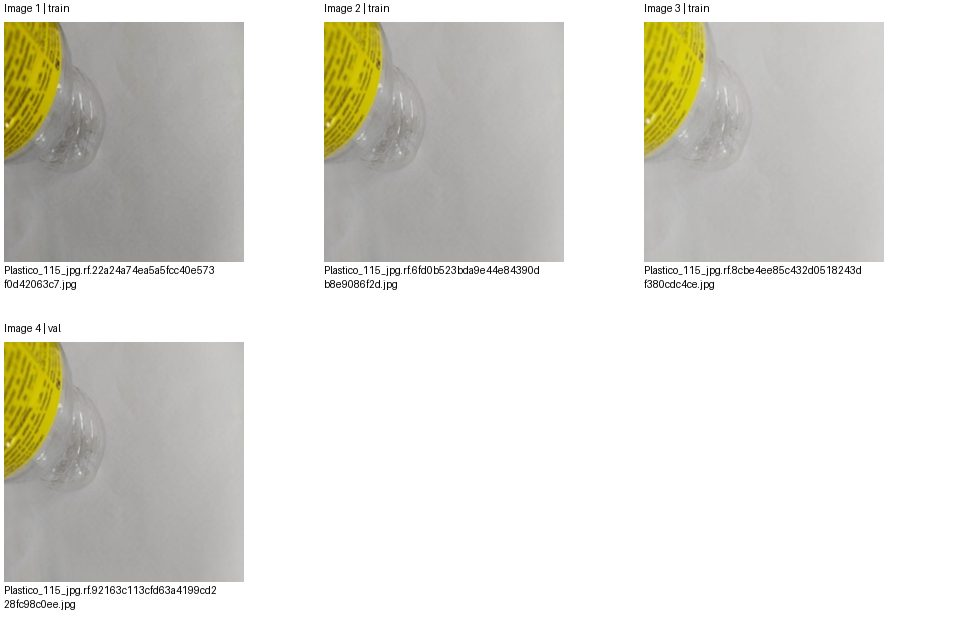

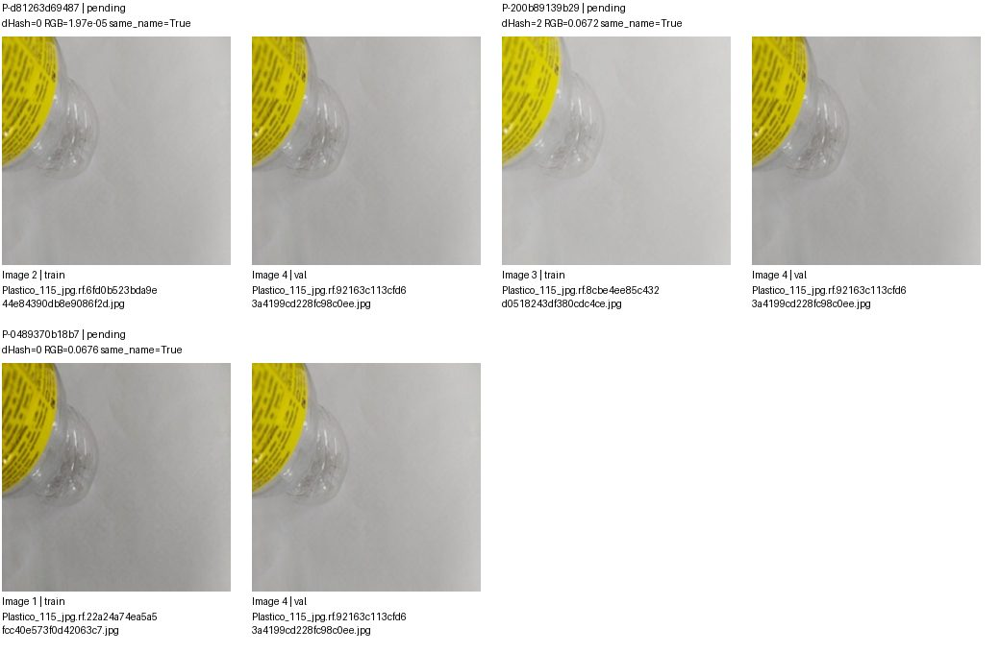

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-d81263d69487,images/train/Plastico_115_jpg.rf.6fd0b523bda9e44e84390db8e9086f2d.jpg,images/val/Plastico_115_jpg.rf.92163c113cfd63a4199cd228fc98c0ee.jpg,pending,
P-200b89139b29,images/train/Plastico_115_jpg.rf.8cbe4ee85c432d0518243df380cdc4ce.jpg,images/val/Plastico_115_jpg.rf.92163c113cfd63a4199cd228fc98c0ee.jpg,pending,
P-0489370b18b7,images/train/Plastico_115_jpg.rf.22a24a74ea5a5fcc40e573f0d42063c7.jpg,images/val/Plastico_115_jpg.rf.92163c113cfd63a4199cd228fc98c0ee.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 13/166 G-64ae6d7dd59e | 2 ảnh, 1 cặp
Split: {'train': 1, 'val': 1}
Quyết định: {'pending': 1}
Ảnh trang 1/1; cặp trang 1/1. Nhóm liên thông không phải kết luận trùng.


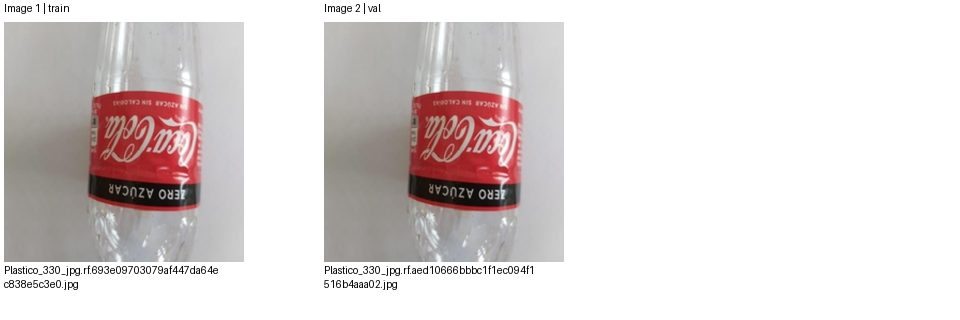

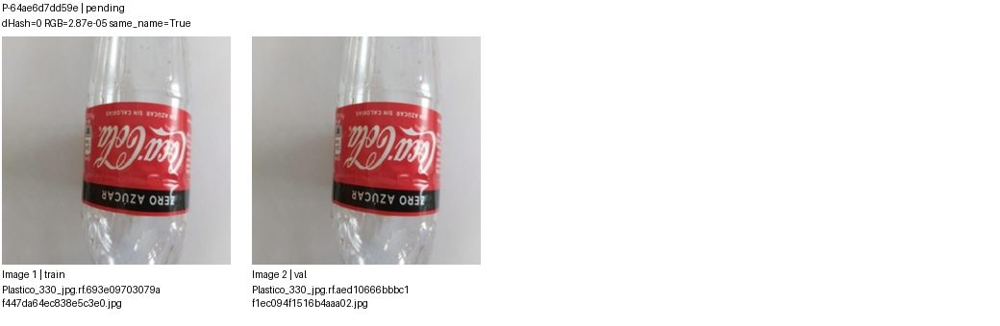

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-64ae6d7dd59e,images/train/Plastico_330_jpg.rf.693e09703079af447da64ec838e5c3e0.jpg,images/val/Plastico_330_jpg.rf.aed10666bbbc1f1ec094f1516b4aaa02.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 14/166 G-835e3249f983 | 3 ảnh, 2 cặp
Split: {'train': 2, 'val': 1}
Quyết định: {'pending': 2}
Ảnh trang 1/1; cặp trang 1/1. Nhóm liên thông không phải kết luận trùng.


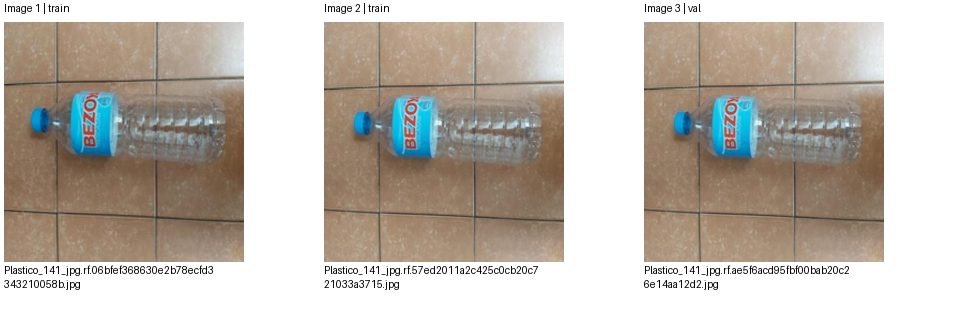

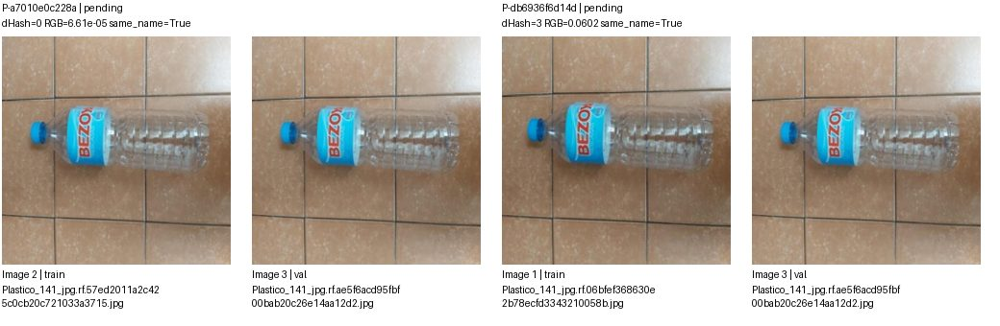

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-a7010e0c228a,images/train/Plastico_141_jpg.rf.57ed2011a2c425c0cb20c721033a3715.jpg,images/val/Plastico_141_jpg.rf.ae5f6acd95fbf00bab20c26e14aa12d2.jpg,pending,
P-db6936f6d14d,images/train/Plastico_141_jpg.rf.06bfef368630e2b78ecfd3343210058b.jpg,images/val/Plastico_141_jpg.rf.ae5f6acd95fbf00bab20c26e14aa12d2.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 15/166 G-152a72df548a | 2 ảnh, 1 cặp
Split: {'test': 1, 'train': 1}
Quyết định: {'pending': 1}
Ảnh trang 1/1; cặp trang 1/1. Nhóm liên thông không phải kết luận trùng.


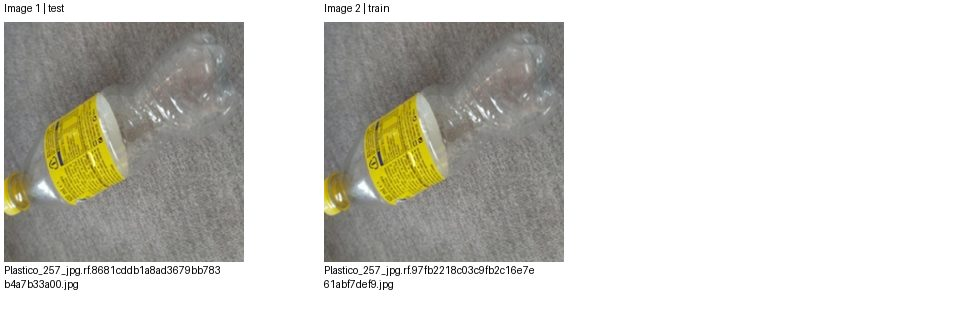

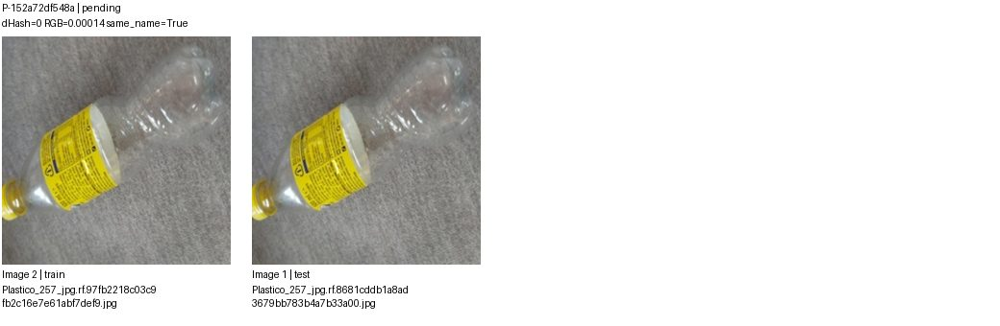

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-152a72df548a,images/train/Plastico_257_jpg.rf.97fb2218c03c9fb2c16e7e61abf7def9.jpg,images/test/Plastico_257_jpg.rf.8681cddb1a8ad3679bb783b4a7b33a00.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 16/166 G-852a83dad5e3 | 2 ảnh, 1 cặp
Split: {'test': 1, 'train': 1}
Quyết định: {'pending': 1}
Ảnh trang 1/1; cặp trang 1/1. Nhóm liên thông không phải kết luận trùng.


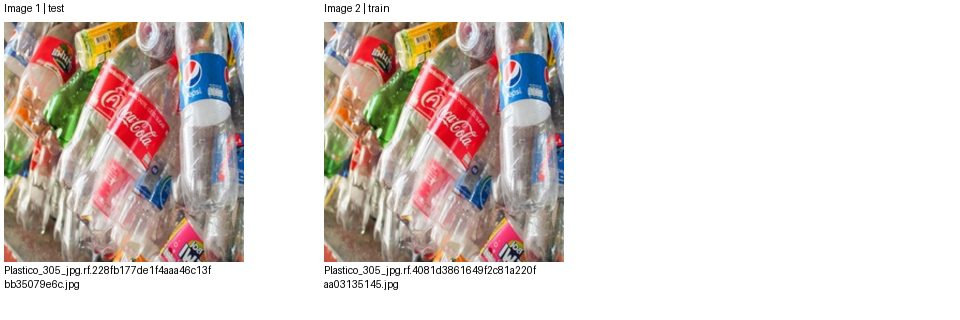

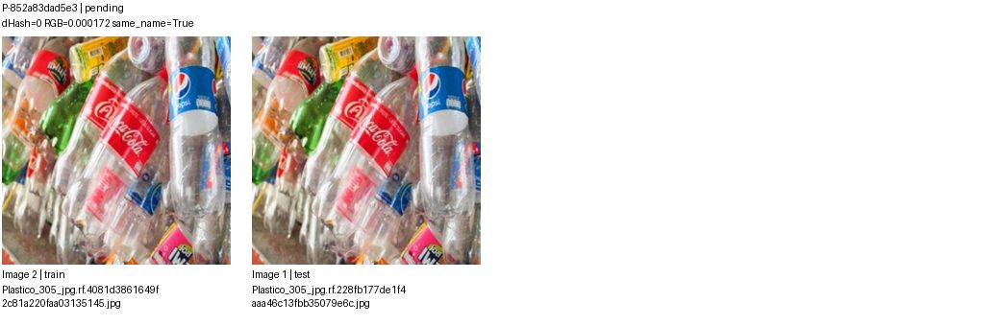

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-852a83dad5e3,images/train/Plastico_305_jpg.rf.4081d3861649f2c81a220faa03135145.jpg,images/test/Plastico_305_jpg.rf.228fb177de1f4aaa46c13fbb35079e6c.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 17/166 G-0db3ba02c438 | 4 ảnh, 4 cặp
Split: {'test': 1, 'train': 1, 'val': 2}
Quyết định: {'pending': 4}
Ảnh trang 1/1; cặp trang 1/1. Nhóm liên thông không phải kết luận trùng.


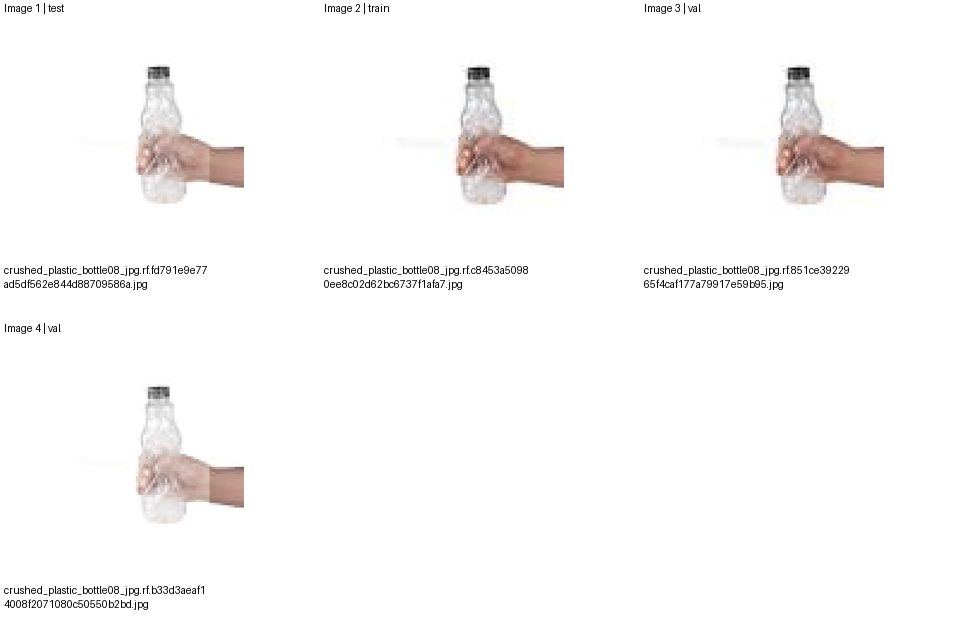

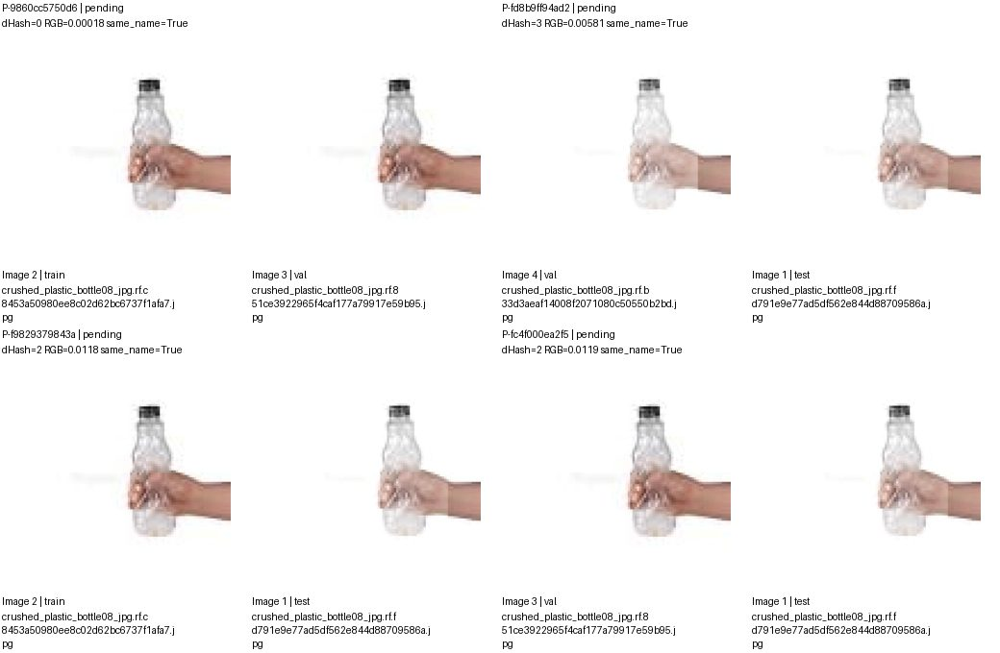

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-9860cc5750d6,images/train/crushed_plastic_bottle08_jpg.rf.c8453a50980ee8c02d62bc6737f1afa7.jpg,images/val/crushed_plastic_bottle08_jpg.rf.851ce3922965f4caf177a79917e59b95.jpg,pending,
P-fd8b9ff94ad2,images/val/crushed_plastic_bottle08_jpg.rf.b33d3aeaf14008f2071080c50550b2bd.jpg,images/test/crushed_plastic_bottle08_jpg.rf.fd791e9e77ad5df562e844d88709586a.jpg,pending,
P-f9829379843a,images/train/crushed_plastic_bottle08_jpg.rf.c8453a50980ee8c02d62bc6737f1afa7.jpg,images/test/crushed_plastic_bottle08_jpg.rf.fd791e9e77ad5df562e844d88709586a.jpg,pending,
P-fc4f000ea2f5,images/val/crushed_plastic_bottle08_jpg.rf.851ce3922965f4caf177a79917e59b95.jpg,images/test/crushed_plastic_bottle08_jpg.rf.fd791e9e77ad5df562e844d88709586a.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 18/166 G-0d1d008f38c4 | 4 ảnh, 5 cặp
Split: {'test': 1, 'train': 1, 'val': 2}
Quyết định: {'pending': 5}
Ảnh trang 1/1; cặp trang 1/2. Nhóm liên thông không phải kết luận trùng.


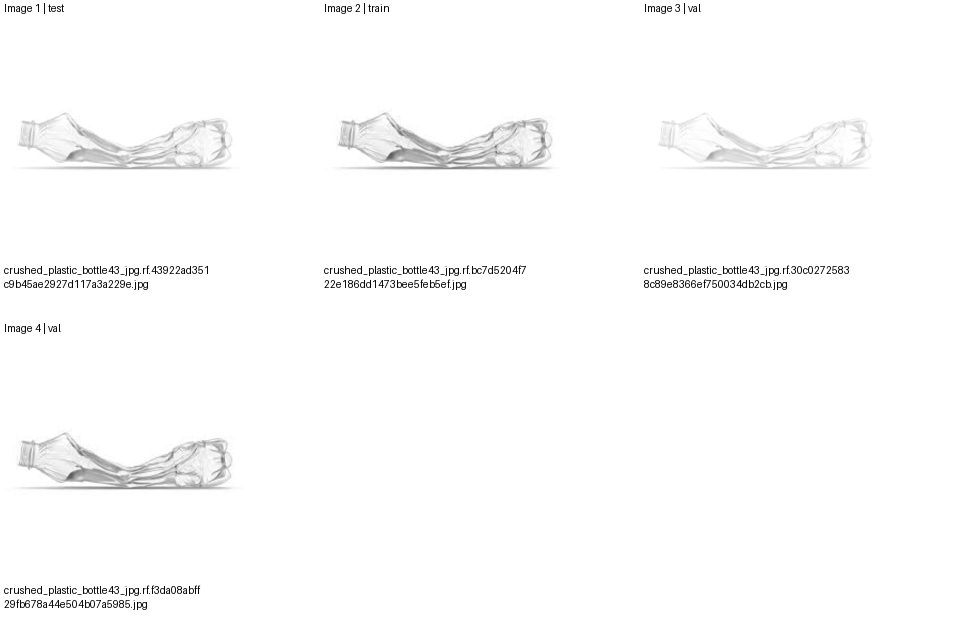

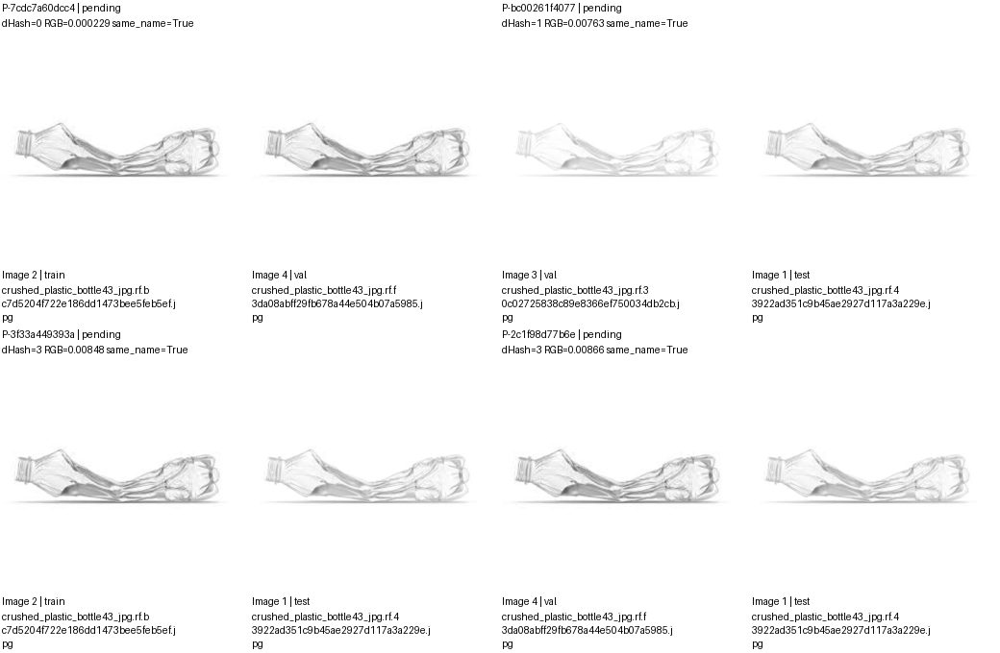

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-7cdc7a60dcc4,images/train/crushed_plastic_bottle43_jpg.rf.bc7d5204f722e186dd1473bee5feb5ef.jpg,images/val/crushed_plastic_bottle43_jpg.rf.f3da08abff29fb678a44e504b07a5985.jpg,pending,
P-bc00261f4077,images/val/crushed_plastic_bottle43_jpg.rf.30c02725838c89e8366ef750034db2cb.jpg,images/test/crushed_plastic_bottle43_jpg.rf.43922ad351c9b45ae2927d117a3a229e.jpg,pending,
P-3f33a449393a,images/train/crushed_plastic_bottle43_jpg.rf.bc7d5204f722e186dd1473bee5feb5ef.jpg,images/test/crushed_plastic_bottle43_jpg.rf.43922ad351c9b45ae2927d117a3a229e.jpg,pending,
P-2c1f98d77b6e,images/val/crushed_plastic_bottle43_jpg.rf.f3da08abff29fb678a44e504b07a5985.jpg,images/test/crushed_plastic_bottle43_jpg.rf.43922ad351c9b45ae2927d117a3a229e.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 18/166 G-0d1d008f38c4 | 4 ảnh, 5 cặp
Split: {'test': 1, 'train': 1, 'val': 2}
Quyết định: {'pending': 5}
Ảnh trang None/1; cặp trang 2/2. Nhóm liên thông không phải kết luận trùng.


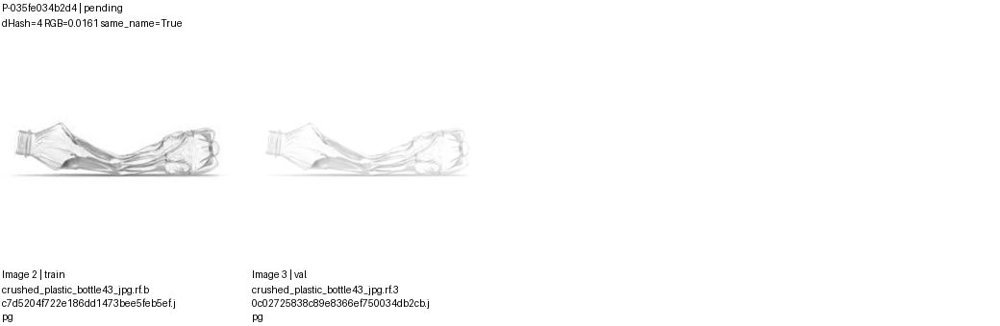

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-035fe034b2d4,images/train/crushed_plastic_bottle43_jpg.rf.bc7d5204f722e186dd1473bee5feb5ef.jpg,images/val/crushed_plastic_bottle43_jpg.rf.30c02725838c89e8366ef750034db2cb.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 19/166 G-9218f2db1542 | 2 ảnh, 1 cặp
Split: {'train': 1, 'val': 1}
Quyết định: {'pending': 1}
Ảnh trang 1/1; cặp trang 1/1. Nhóm liên thông không phải kết luận trùng.


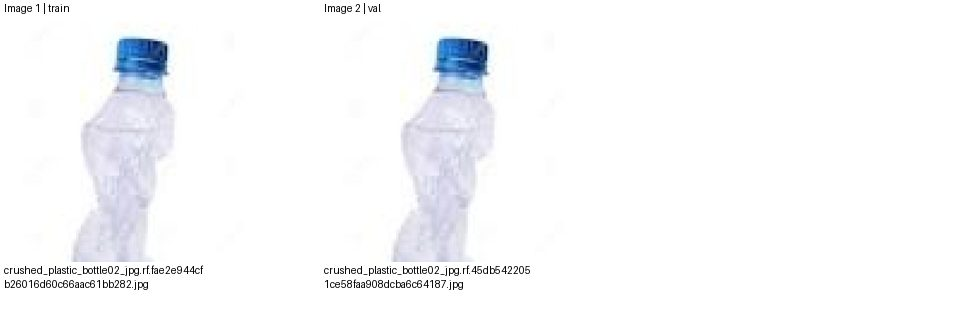

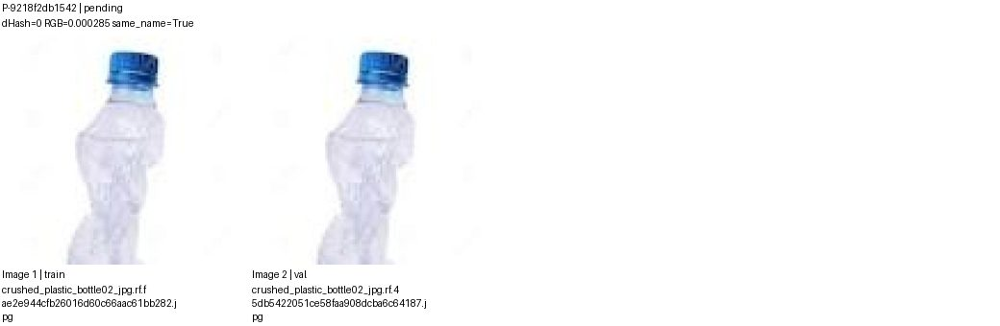

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-9218f2db1542,images/train/crushed_plastic_bottle02_jpg.rf.fae2e944cfb26016d60c66aac61bb282.jpg,images/val/crushed_plastic_bottle02_jpg.rf.45db5422051ce58faa908dcba6c64187.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 20/166 G-85c6fe8395a7 | 5 ảnh, 4 cặp
Split: {'train': 4, 'val': 1}
Quyết định: {'pending': 4}
Ảnh trang 1/1; cặp trang 1/1. Nhóm liên thông không phải kết luận trùng.


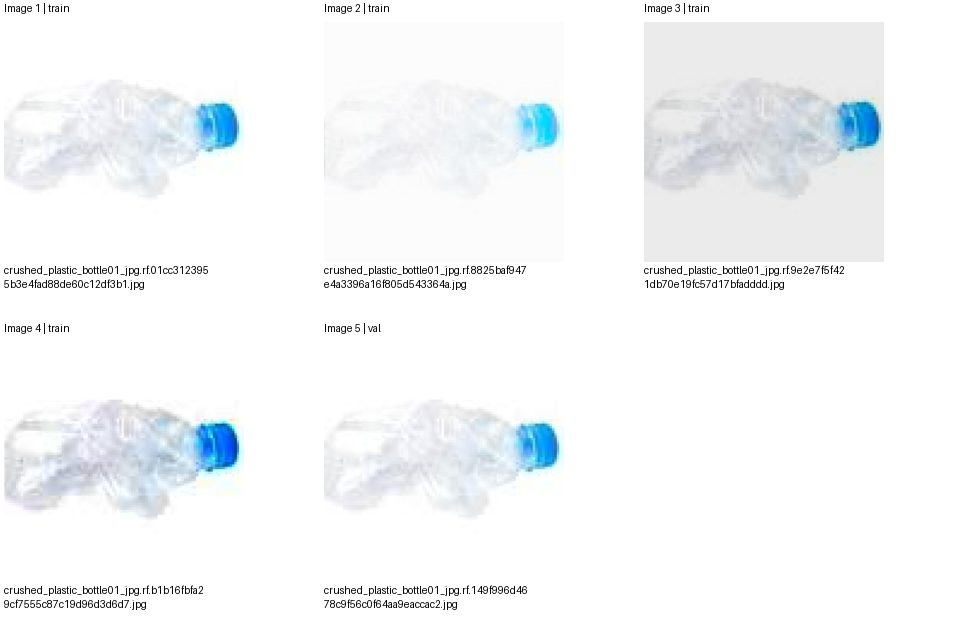

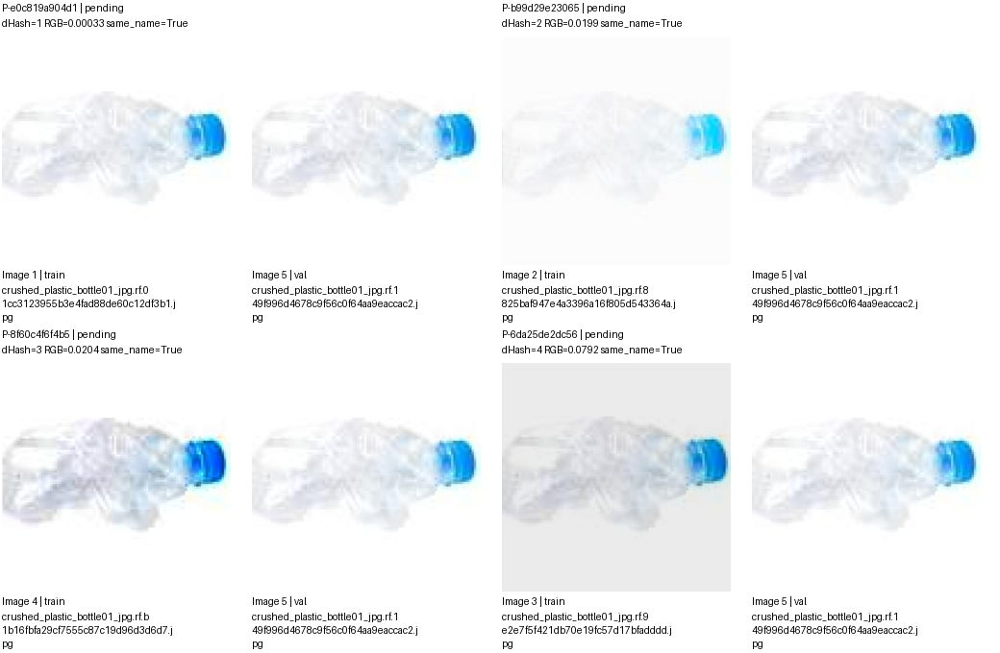

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-e0c819a904d1,images/train/crushed_plastic_bottle01_jpg.rf.01cc3123955b3e4fad88de60c12df3b1.jpg,images/val/crushed_plastic_bottle01_jpg.rf.149f996d4678c9f56c0f64aa9eaccac2.jpg,pending,
P-b99d29e23065,images/train/crushed_plastic_bottle01_jpg.rf.8825baf947e4a3396a16f805d543364a.jpg,images/val/crushed_plastic_bottle01_jpg.rf.149f996d4678c9f56c0f64aa9eaccac2.jpg,pending,
P-8f60c4f6f4b5,images/train/crushed_plastic_bottle01_jpg.rf.b1b16fbfa29cf7555c87c19d96d3d6d7.jpg,images/val/crushed_plastic_bottle01_jpg.rf.149f996d4678c9f56c0f64aa9eaccac2.jpg,pending,
P-6da25de2dc56,images/train/crushed_plastic_bottle01_jpg.rf.9e2e7f5f421db70e19fc57d17bfadddd.jpg,images/val/crushed_plastic_bottle01_jpg.rf.149f996d4678c9f56c0f64aa9eaccac2.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 21/166 G-65dc5674ac5a | 3 ảnh, 3 cặp
Split: {'test': 1, 'train': 1, 'val': 1}
Quyết định: {'pending': 3}
Ảnh trang 1/1; cặp trang 1/1. Nhóm liên thông không phải kết luận trùng.


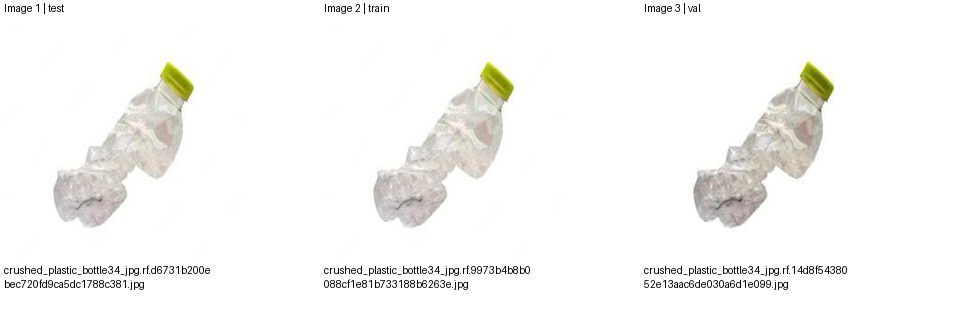

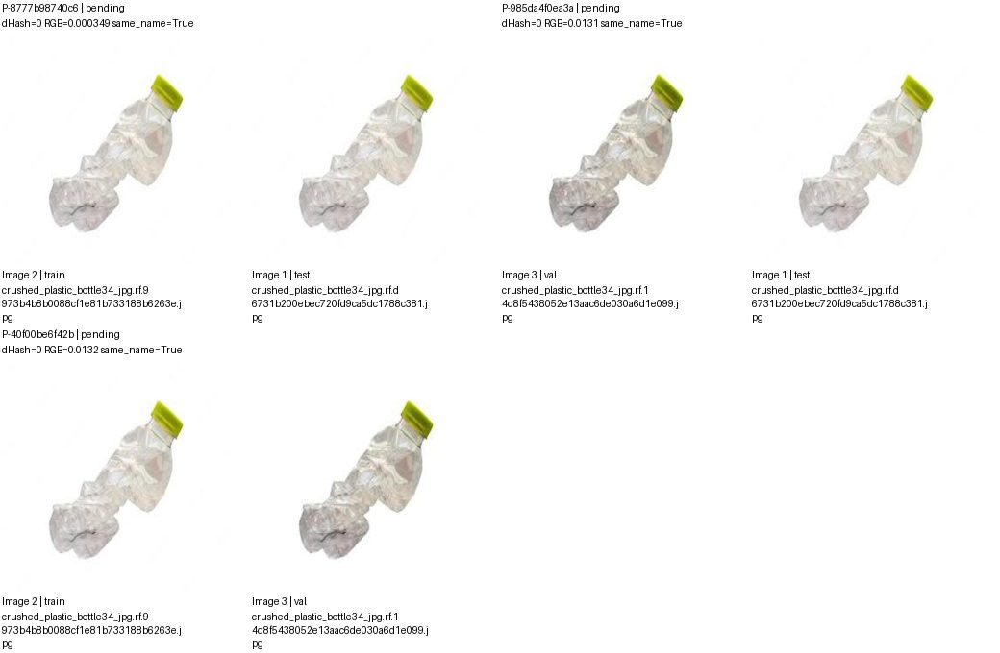

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-8777b98740c6,images/train/crushed_plastic_bottle34_jpg.rf.9973b4b8b0088cf1e81b733188b6263e.jpg,images/test/crushed_plastic_bottle34_jpg.rf.d6731b200ebec720fd9ca5dc1788c381.jpg,pending,
P-985da4f0ea3a,images/val/crushed_plastic_bottle34_jpg.rf.14d8f5438052e13aac6de030a6d1e099.jpg,images/test/crushed_plastic_bottle34_jpg.rf.d6731b200ebec720fd9ca5dc1788c381.jpg,pending,
P-40f00be6f42b,images/train/crushed_plastic_bottle34_jpg.rf.9973b4b8b0088cf1e81b733188b6263e.jpg,images/val/crushed_plastic_bottle34_jpg.rf.14d8f5438052e13aac6de030a6d1e099.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 22/166 G-19b8bd818235 | 4 ảnh, 3 cặp
Split: {'train': 2, 'val': 2}
Quyết định: {'pending': 3}
Ảnh trang 1/1; cặp trang 1/1. Nhóm liên thông không phải kết luận trùng.


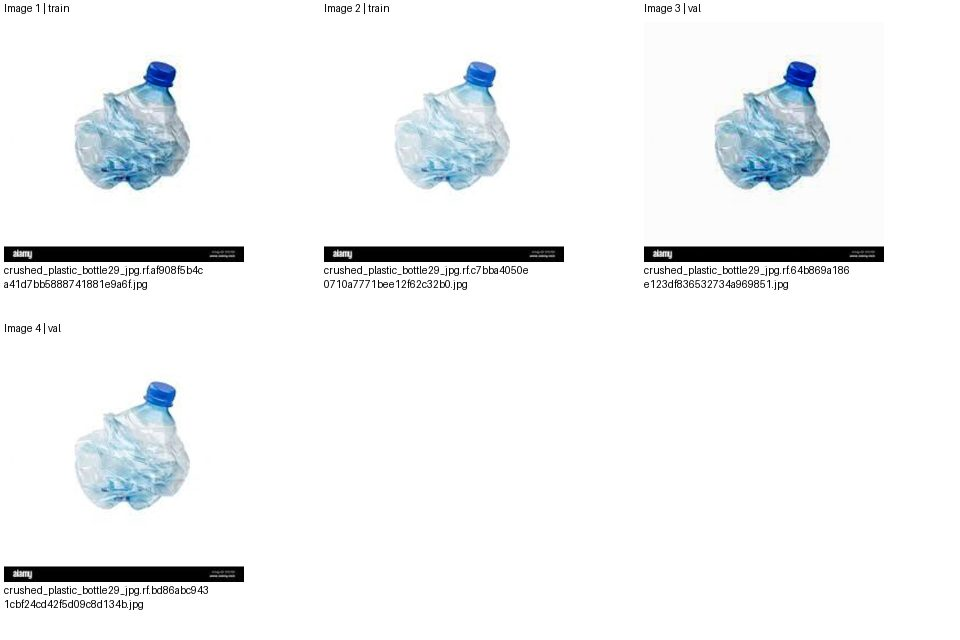

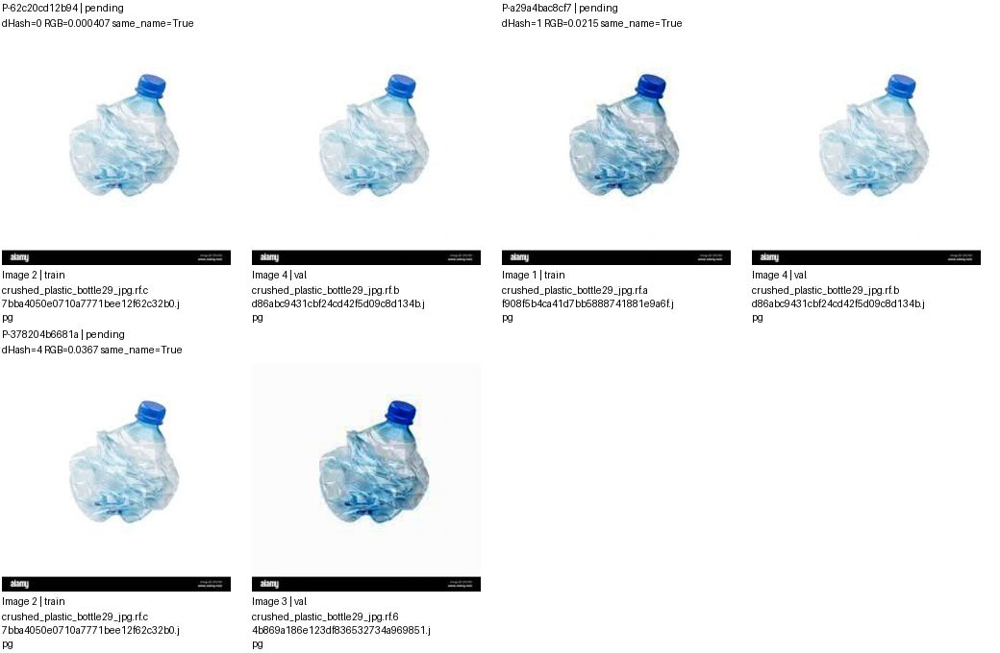

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-62c20cd12b94,images/train/crushed_plastic_bottle29_jpg.rf.c7bba4050e0710a7771bee12f62c32b0.jpg,images/val/crushed_plastic_bottle29_jpg.rf.bd86abc9431cbf24cd42f5d09c8d134b.jpg,pending,
P-a29a4bac8cf7,images/train/crushed_plastic_bottle29_jpg.rf.af908f5b4ca41d7bb5888741881e9a6f.jpg,images/val/crushed_plastic_bottle29_jpg.rf.bd86abc9431cbf24cd42f5d09c8d134b.jpg,pending,
P-378204b6681a,images/train/crushed_plastic_bottle29_jpg.rf.c7bba4050e0710a7771bee12f62c32b0.jpg,images/val/crushed_plastic_bottle29_jpg.rf.64b869a186e123df836532734a969851.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 23/166 G-1294c6fa571c | 5 ảnh, 7 cặp
Split: {'test': 1, 'train': 2, 'val': 2}
Quyết định: {'pending': 7}
Ảnh trang 1/1; cặp trang 1/2. Nhóm liên thông không phải kết luận trùng.


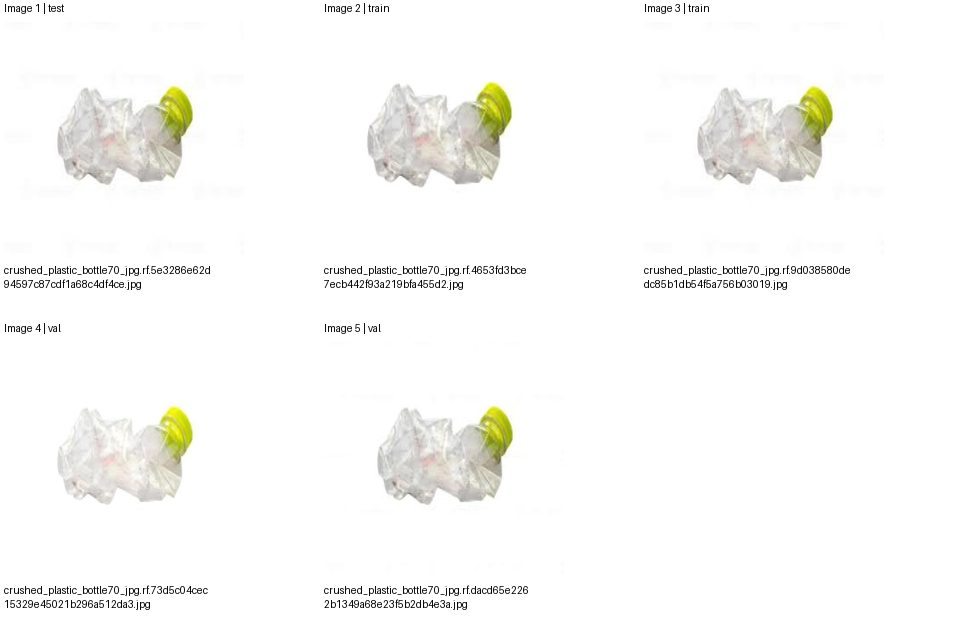

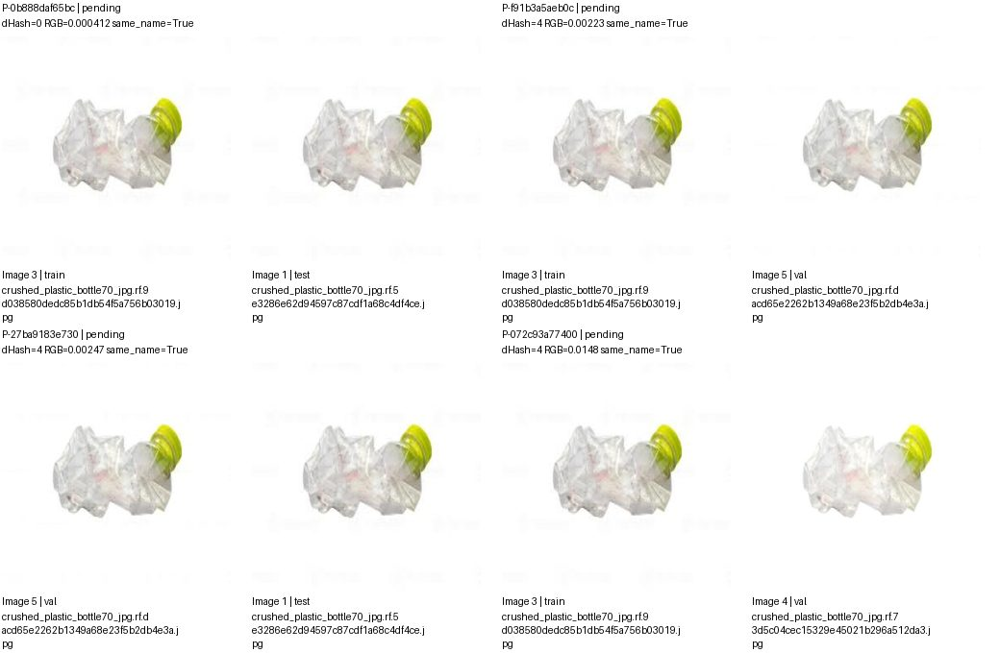

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-0b888daf65bc,images/train/crushed_plastic_bottle70_jpg.rf.9d038580dedc85b1db54f5a756b03019.jpg,images/test/crushed_plastic_bottle70_jpg.rf.5e3286e62d94597c87cdf1a68c4df4ce.jpg,pending,
P-f91b3a5aeb0c,images/train/crushed_plastic_bottle70_jpg.rf.9d038580dedc85b1db54f5a756b03019.jpg,images/val/crushed_plastic_bottle70_jpg.rf.dacd65e2262b1349a68e23f5b2db4e3a.jpg,pending,
P-27ba9183e730,images/val/crushed_plastic_bottle70_jpg.rf.dacd65e2262b1349a68e23f5b2db4e3a.jpg,images/test/crushed_plastic_bottle70_jpg.rf.5e3286e62d94597c87cdf1a68c4df4ce.jpg,pending,
P-072c93a77400,images/train/crushed_plastic_bottle70_jpg.rf.9d038580dedc85b1db54f5a756b03019.jpg,images/val/crushed_plastic_bottle70_jpg.rf.73d5c04cec15329e45021b296a512da3.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 23/166 G-1294c6fa571c | 5 ảnh, 7 cặp
Split: {'test': 1, 'train': 2, 'val': 2}
Quyết định: {'pending': 7}
Ảnh trang None/1; cặp trang 2/2. Nhóm liên thông không phải kết luận trùng.


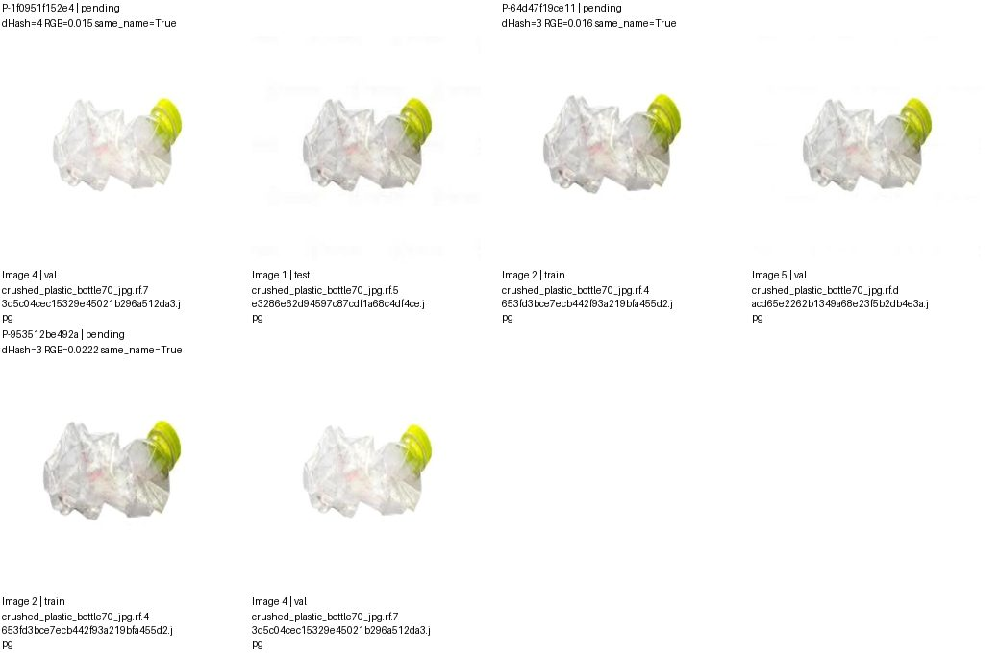

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-1f0951f152e4,images/val/crushed_plastic_bottle70_jpg.rf.73d5c04cec15329e45021b296a512da3.jpg,images/test/crushed_plastic_bottle70_jpg.rf.5e3286e62d94597c87cdf1a68c4df4ce.jpg,pending,
P-64d47f19ce11,images/train/crushed_plastic_bottle70_jpg.rf.4653fd3bce7ecb442f93a219bfa455d2.jpg,images/val/crushed_plastic_bottle70_jpg.rf.dacd65e2262b1349a68e23f5b2db4e3a.jpg,pending,
P-953512be492a,images/train/crushed_plastic_bottle70_jpg.rf.4653fd3bce7ecb442f93a219bfa455d2.jpg,images/val/crushed_plastic_bottle70_jpg.rf.73d5c04cec15329e45021b296a512da3.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 24/166 G-accc5d922cc1 | 5 ảnh, 4 cặp
Split: {'train': 3, 'val': 2}
Quyết định: {'pending': 4}
Ảnh trang 1/1; cặp trang 1/1. Nhóm liên thông không phải kết luận trùng.


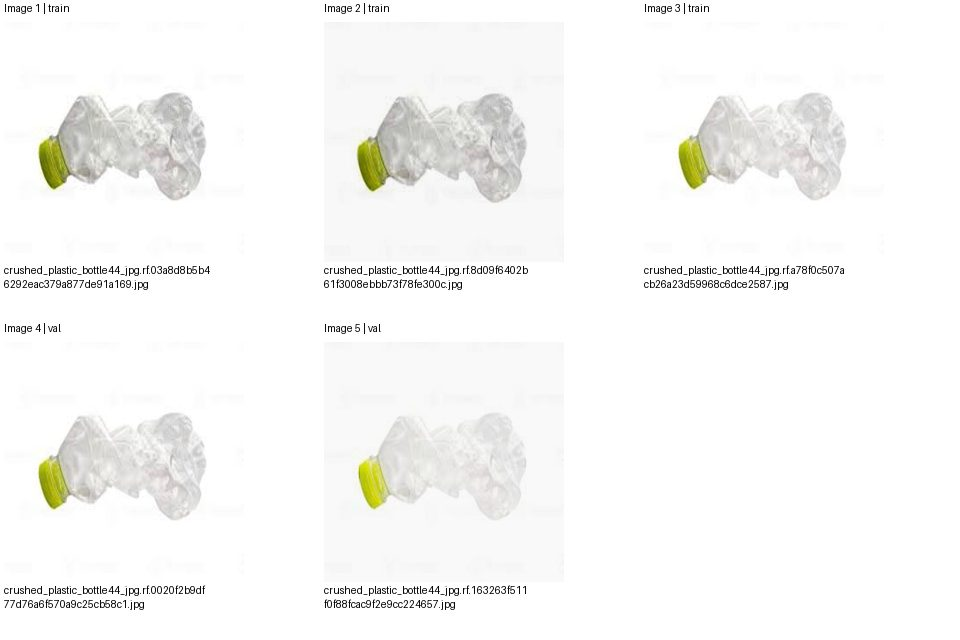

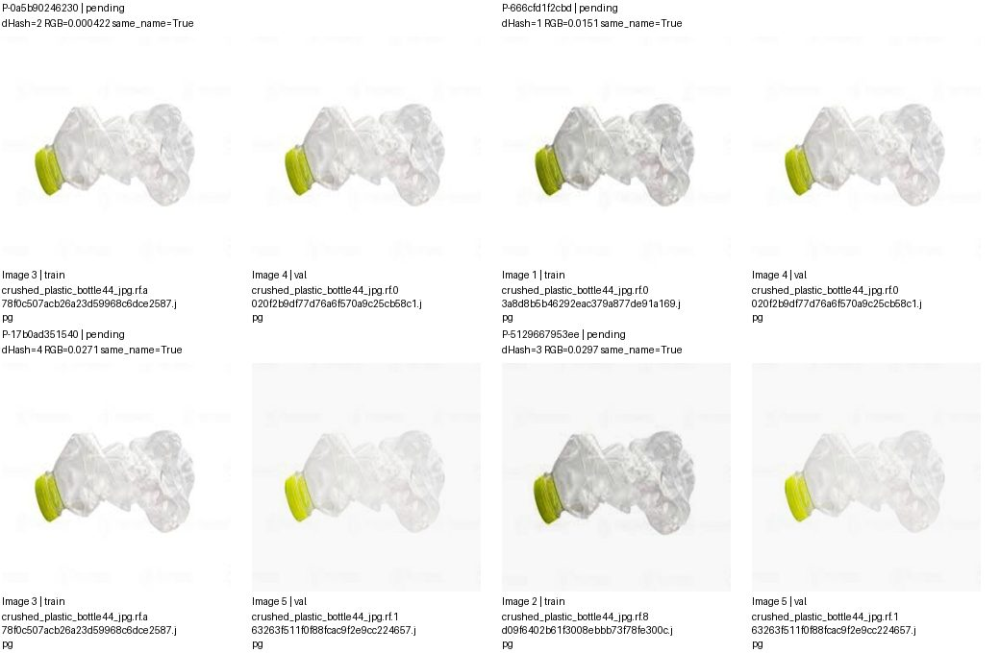

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-0a5b90246230,images/train/crushed_plastic_bottle44_jpg.rf.a78f0c507acb26a23d59968c6dce2587.jpg,images/val/crushed_plastic_bottle44_jpg.rf.0020f2b9df77d76a6f570a9c25cb58c1.jpg,pending,
P-666cfd1f2cbd,images/train/crushed_plastic_bottle44_jpg.rf.03a8d8b5b46292eac379a877de91a169.jpg,images/val/crushed_plastic_bottle44_jpg.rf.0020f2b9df77d76a6f570a9c25cb58c1.jpg,pending,
P-17b0ad351540,images/train/crushed_plastic_bottle44_jpg.rf.a78f0c507acb26a23d59968c6dce2587.jpg,images/val/crushed_plastic_bottle44_jpg.rf.163263f511f0f88fcac9f2e9cc224657.jpg,pending,
P-5129667953ee,images/train/crushed_plastic_bottle44_jpg.rf.8d09f6402b61f3008ebbb73f78fe300c.jpg,images/val/crushed_plastic_bottle44_jpg.rf.163263f511f0f88fcac9f2e9cc224657.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 25/166 G-0c3a5ded8108 | 3 ảnh, 2 cặp
Split: {'train': 1, 'val': 2}
Quyết định: {'pending': 2}
Ảnh trang 1/1; cặp trang 1/1. Nhóm liên thông không phải kết luận trùng.


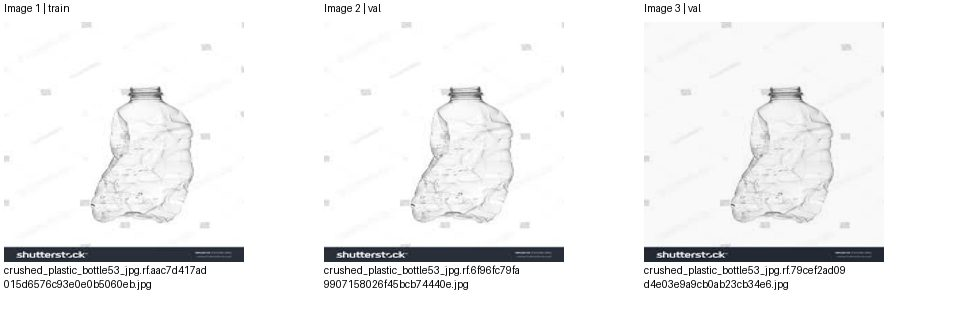

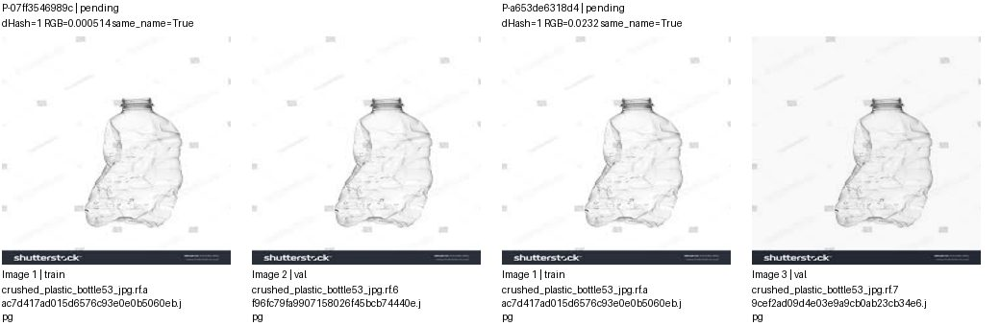

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-07ff3546989c,images/train/crushed_plastic_bottle53_jpg.rf.aac7d417ad015d6576c93e0e0b5060eb.jpg,images/val/crushed_plastic_bottle53_jpg.rf.6f96fc79fa9907158026f45bcb74440e.jpg,pending,
P-a653de6318d4,images/train/crushed_plastic_bottle53_jpg.rf.aac7d417ad015d6576c93e0e0b5060eb.jpg,images/val/crushed_plastic_bottle53_jpg.rf.79cef2ad09d4e03e9a9cb0ab23cb34e6.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 26/166 G-e2b1a5d87bc4 | 2 ảnh, 1 cặp
Split: {'train': 1, 'val': 1}
Quyết định: {'pending': 1}
Ảnh trang 1/1; cặp trang 1/1. Nhóm liên thông không phải kết luận trùng.


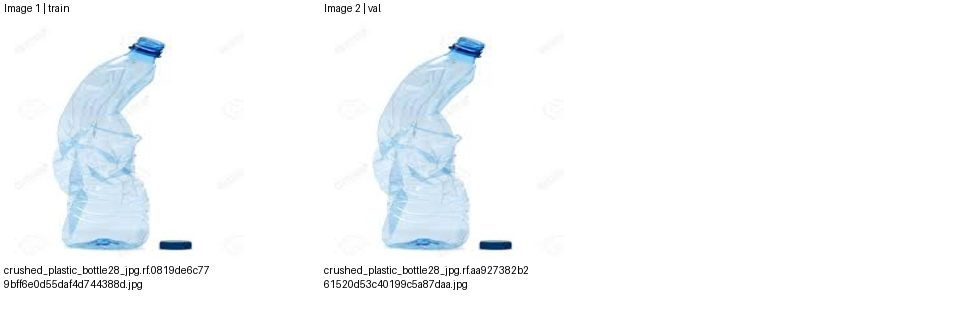

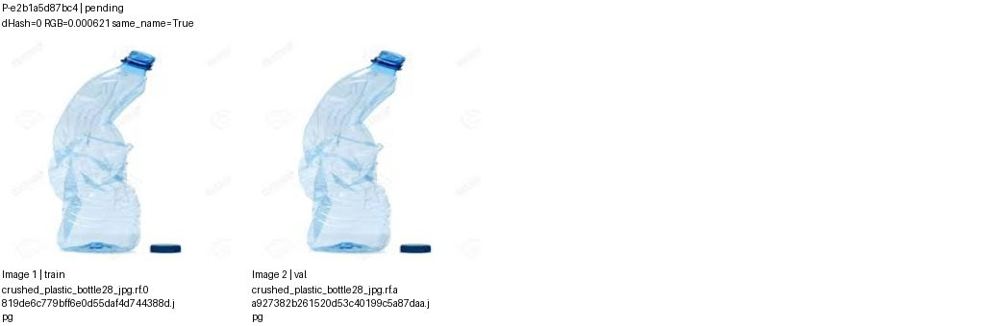

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-e2b1a5d87bc4,images/train/crushed_plastic_bottle28_jpg.rf.0819de6c779bff6e0d55daf4d744388d.jpg,images/val/crushed_plastic_bottle28_jpg.rf.aa927382b261520d53c40199c5a87daa.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 27/166 G-46f28c387f28 | 10 ảnh, 15 cặp
Split: {'test': 2, 'train': 8}
Quyết định: {'pending': 15}
Ảnh trang 1/2; cặp trang 1/4. Nhóm liên thông không phải kết luận trùng.


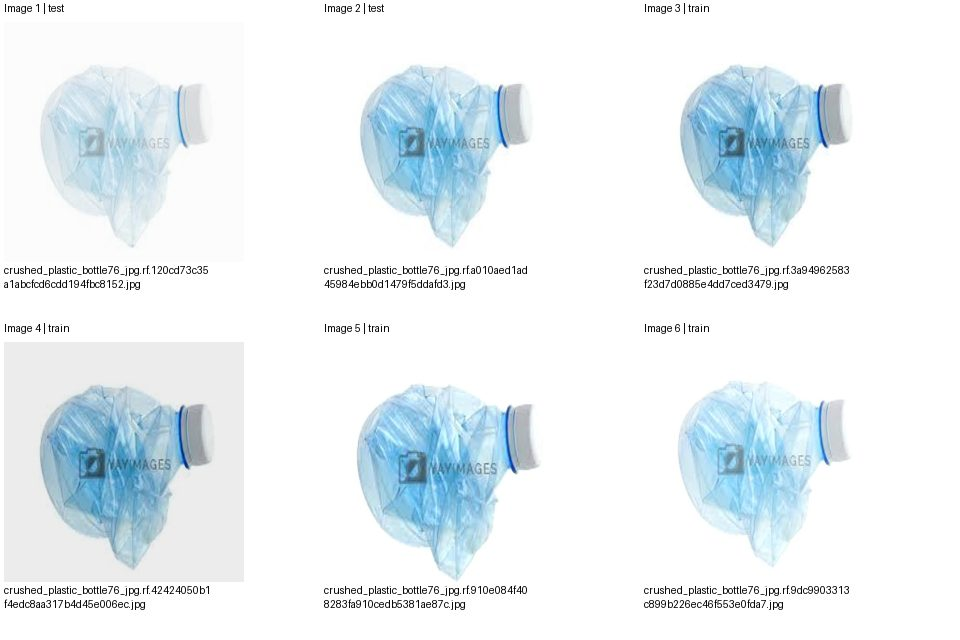

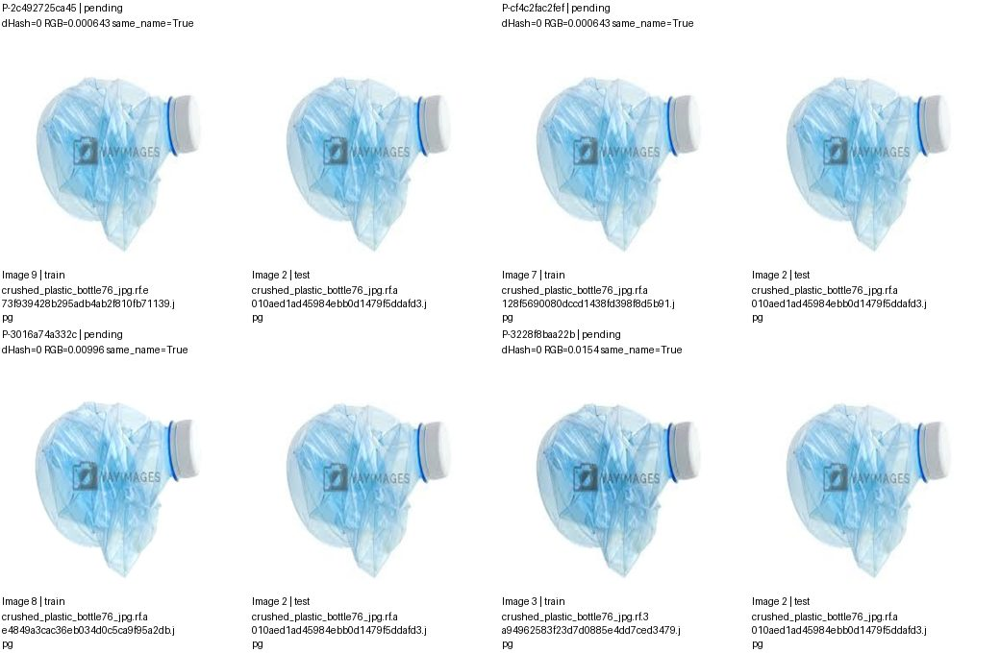

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-2c492725ca45,images/train/crushed_plastic_bottle76_jpg.rf.e73f939428b295adb4ab2f810fb71139.jpg,images/test/crushed_plastic_bottle76_jpg.rf.a010aed1ad45984ebb0d1479f5ddafd3.jpg,pending,
P-cf4c2fac2fef,images/train/crushed_plastic_bottle76_jpg.rf.a128f5690080dccd1438fd398f8d5b91.jpg,images/test/crushed_plastic_bottle76_jpg.rf.a010aed1ad45984ebb0d1479f5ddafd3.jpg,pending,
P-3016a74a332c,images/train/crushed_plastic_bottle76_jpg.rf.ae4849a3cac36eb034d0c5ca9f95a2db.jpg,images/test/crushed_plastic_bottle76_jpg.rf.a010aed1ad45984ebb0d1479f5ddafd3.jpg,pending,
P-3228f8baa22b,images/train/crushed_plastic_bottle76_jpg.rf.3a94962583f23d7d0885e4dd7ced3479.jpg,images/test/crushed_plastic_bottle76_jpg.rf.a010aed1ad45984ebb0d1479f5ddafd3.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 27/166 G-46f28c387f28 | 10 ảnh, 15 cặp
Split: {'test': 2, 'train': 8}
Quyết định: {'pending': 15}
Ảnh trang 2/2; cặp trang 2/4. Nhóm liên thông không phải kết luận trùng.


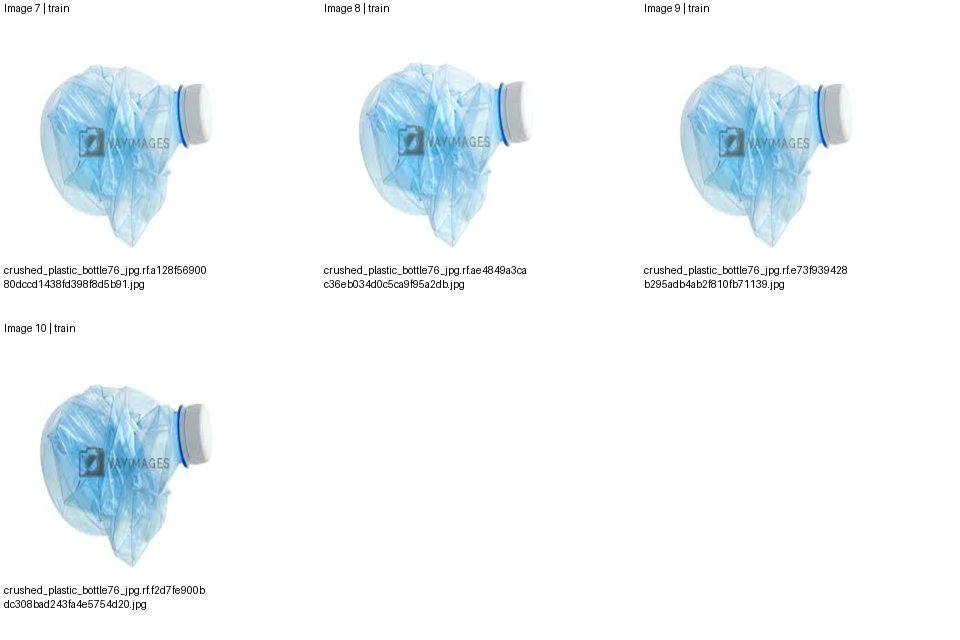

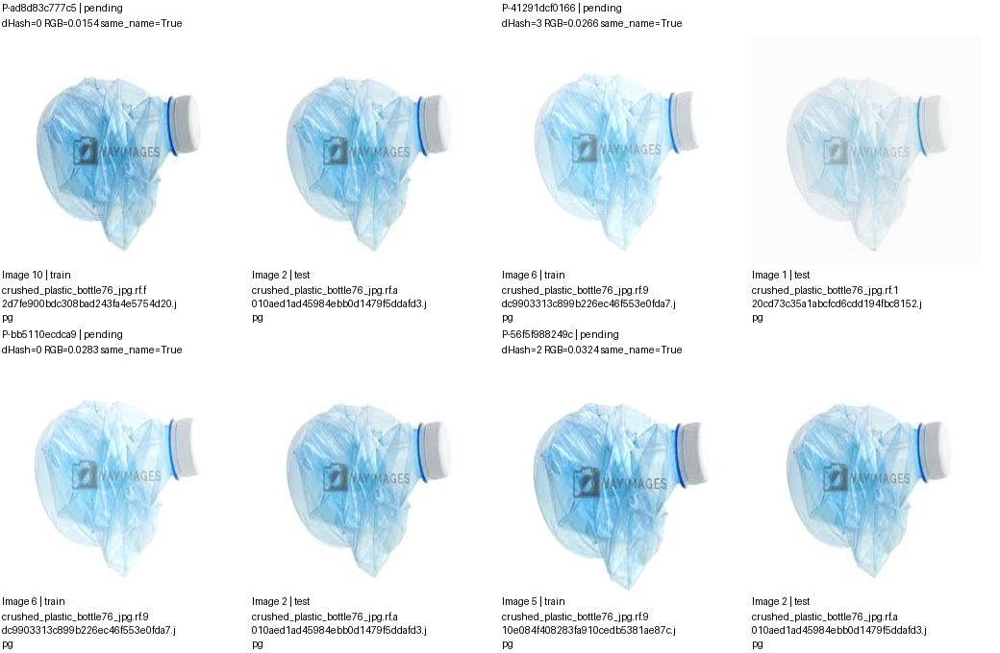

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-ad8d83c777c5,images/train/crushed_plastic_bottle76_jpg.rf.f2d7fe900bdc308bad243fa4e5754d20.jpg,images/test/crushed_plastic_bottle76_jpg.rf.a010aed1ad45984ebb0d1479f5ddafd3.jpg,pending,
P-41291dcf0166,images/train/crushed_plastic_bottle76_jpg.rf.9dc9903313c899b226ec46f553e0fda7.jpg,images/test/crushed_plastic_bottle76_jpg.rf.120cd73c35a1abcfcd6cdd194fbc8152.jpg,pending,
P-bb5110ecdca9,images/train/crushed_plastic_bottle76_jpg.rf.9dc9903313c899b226ec46f553e0fda7.jpg,images/test/crushed_plastic_bottle76_jpg.rf.a010aed1ad45984ebb0d1479f5ddafd3.jpg,pending,
P-56f5f988249c,images/train/crushed_plastic_bottle76_jpg.rf.910e084f408283fa910cedb5381ae87c.jpg,images/test/crushed_plastic_bottle76_jpg.rf.a010aed1ad45984ebb0d1479f5ddafd3.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 27/166 G-46f28c387f28 | 10 ảnh, 15 cặp
Split: {'test': 2, 'train': 8}
Quyết định: {'pending': 15}
Ảnh trang None/2; cặp trang 3/4. Nhóm liên thông không phải kết luận trùng.


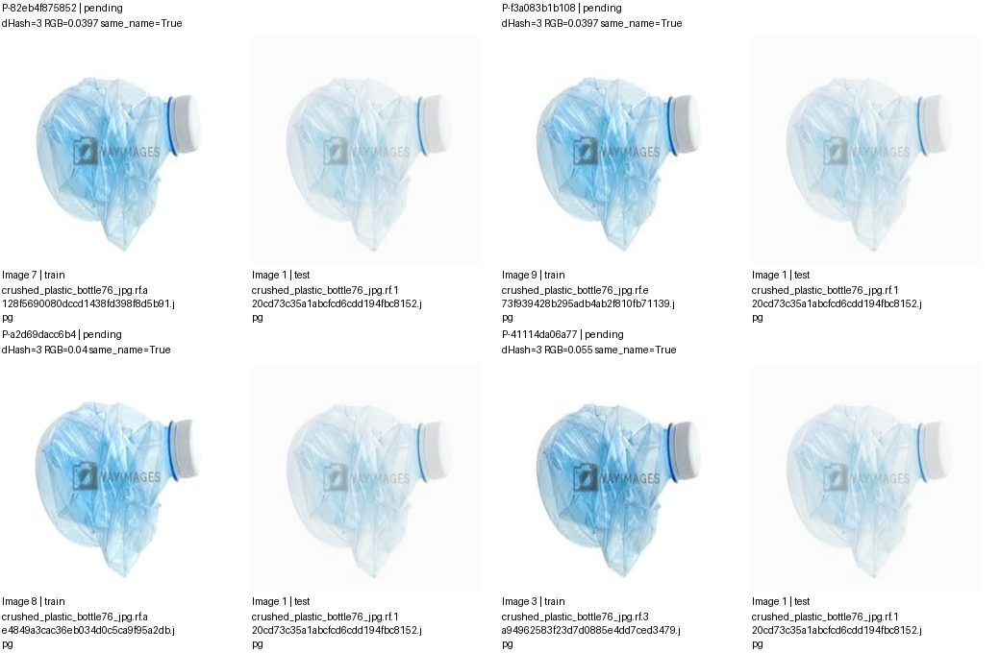

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-82eb4f875852,images/train/crushed_plastic_bottle76_jpg.rf.a128f5690080dccd1438fd398f8d5b91.jpg,images/test/crushed_plastic_bottle76_jpg.rf.120cd73c35a1abcfcd6cdd194fbc8152.jpg,pending,
P-f3a083b1b108,images/train/crushed_plastic_bottle76_jpg.rf.e73f939428b295adb4ab2f810fb71139.jpg,images/test/crushed_plastic_bottle76_jpg.rf.120cd73c35a1abcfcd6cdd194fbc8152.jpg,pending,
P-a2d69dacc6b4,images/train/crushed_plastic_bottle76_jpg.rf.ae4849a3cac36eb034d0c5ca9f95a2db.jpg,images/test/crushed_plastic_bottle76_jpg.rf.120cd73c35a1abcfcd6cdd194fbc8152.jpg,pending,
P-41114da06a77,images/train/crushed_plastic_bottle76_jpg.rf.3a94962583f23d7d0885e4dd7ced3479.jpg,images/test/crushed_plastic_bottle76_jpg.rf.120cd73c35a1abcfcd6cdd194fbc8152.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 27/166 G-46f28c387f28 | 10 ảnh, 15 cặp
Split: {'test': 2, 'train': 8}
Quyết định: {'pending': 15}
Ảnh trang None/2; cặp trang 4/4. Nhóm liên thông không phải kết luận trùng.


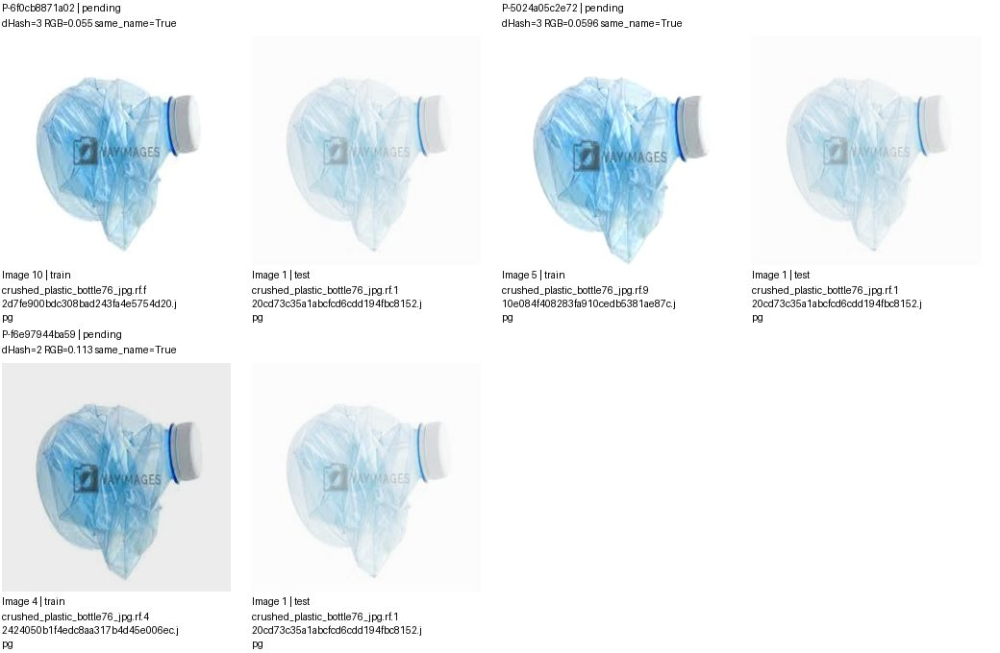

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-6f0cb8871a02,images/train/crushed_plastic_bottle76_jpg.rf.f2d7fe900bdc308bad243fa4e5754d20.jpg,images/test/crushed_plastic_bottle76_jpg.rf.120cd73c35a1abcfcd6cdd194fbc8152.jpg,pending,
P-5024a05c2e72,images/train/crushed_plastic_bottle76_jpg.rf.910e084f408283fa910cedb5381ae87c.jpg,images/test/crushed_plastic_bottle76_jpg.rf.120cd73c35a1abcfcd6cdd194fbc8152.jpg,pending,
P-f6e97944ba59,images/train/crushed_plastic_bottle76_jpg.rf.42424050b1f4edc8aa317b4d45e006ec.jpg,images/test/crushed_plastic_bottle76_jpg.rf.120cd73c35a1abcfcd6cdd194fbc8152.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 28/166 G-3a8d55746e37 | 6 ảnh, 9 cặp
Split: {'train': 3, 'val': 3}
Quyết định: {'pending': 9}
Ảnh trang 1/1; cặp trang 1/3. Nhóm liên thông không phải kết luận trùng.


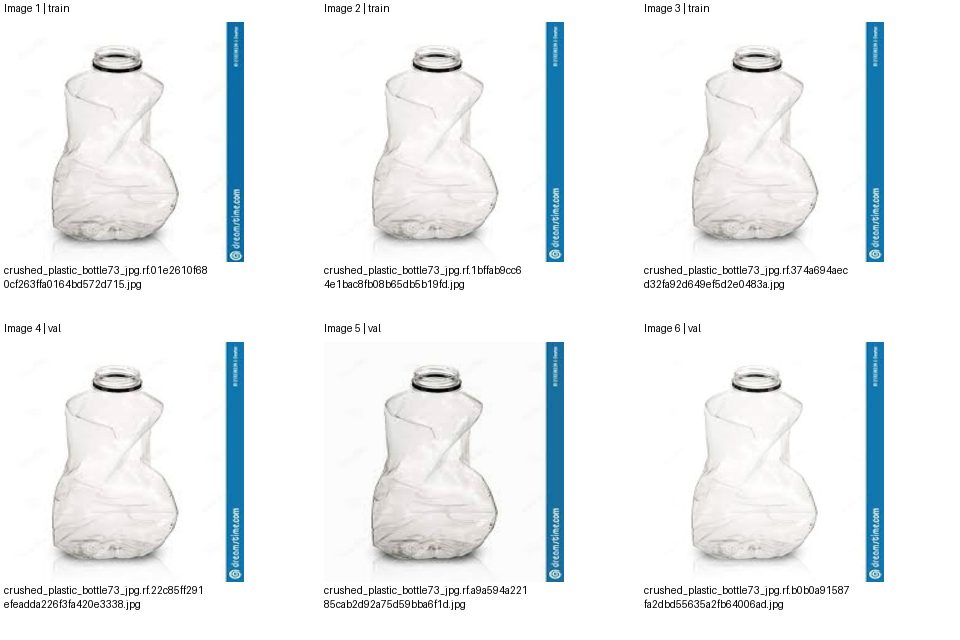

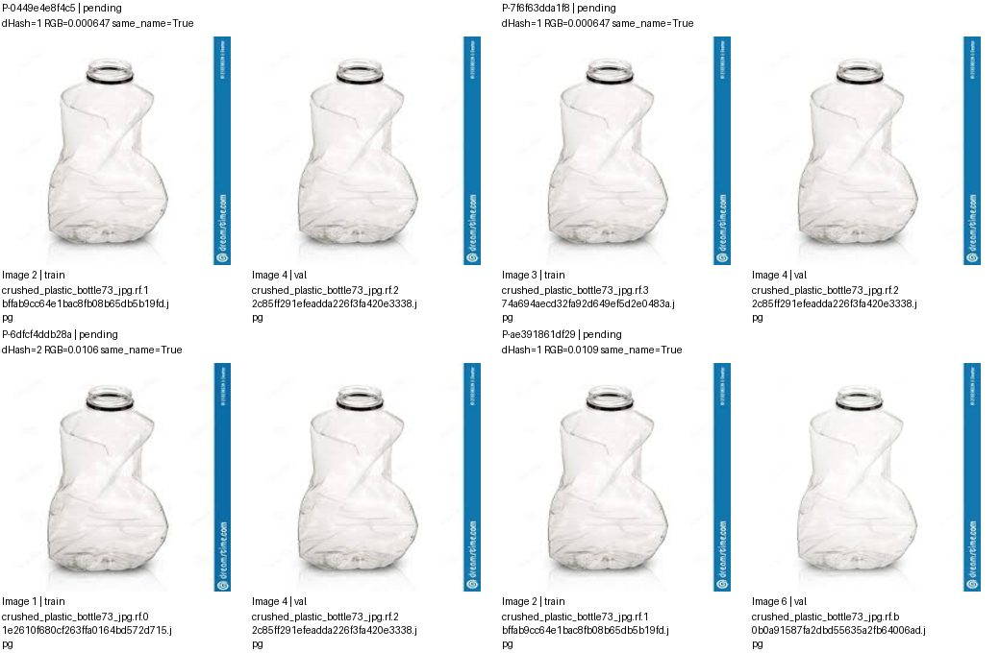

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-0449e4e8f4c5,images/train/crushed_plastic_bottle73_jpg.rf.1bffab9cc64e1bac8fb08b65db5b19fd.jpg,images/val/crushed_plastic_bottle73_jpg.rf.22c85ff291efeadda226f3fa420e3338.jpg,pending,
P-7f6f63dda1f8,images/train/crushed_plastic_bottle73_jpg.rf.374a694aecd32fa92d649ef5d2e0483a.jpg,images/val/crushed_plastic_bottle73_jpg.rf.22c85ff291efeadda226f3fa420e3338.jpg,pending,
P-6dfcf4ddb28a,images/train/crushed_plastic_bottle73_jpg.rf.01e2610f680cf263ffa0164bd572d715.jpg,images/val/crushed_plastic_bottle73_jpg.rf.22c85ff291efeadda226f3fa420e3338.jpg,pending,
P-ae391861df29,images/train/crushed_plastic_bottle73_jpg.rf.1bffab9cc64e1bac8fb08b65db5b19fd.jpg,images/val/crushed_plastic_bottle73_jpg.rf.b0b0a91587fa2dbd55635a2fb64006ad.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 28/166 G-3a8d55746e37 | 6 ảnh, 9 cặp
Split: {'train': 3, 'val': 3}
Quyết định: {'pending': 9}
Ảnh trang None/1; cặp trang 2/3. Nhóm liên thông không phải kết luận trùng.


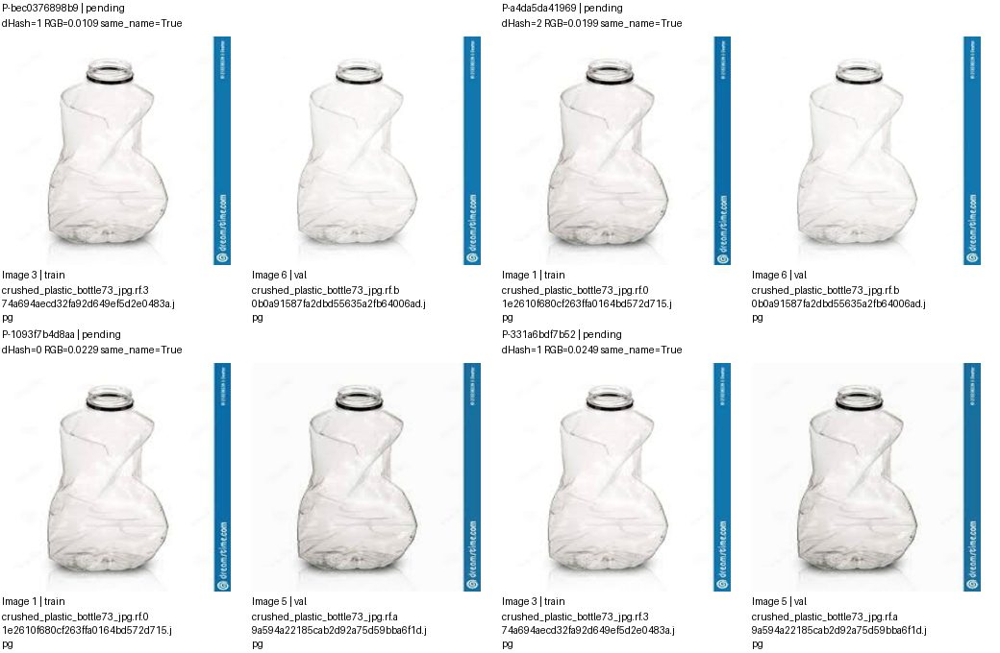

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-bec0376898b9,images/train/crushed_plastic_bottle73_jpg.rf.374a694aecd32fa92d649ef5d2e0483a.jpg,images/val/crushed_plastic_bottle73_jpg.rf.b0b0a91587fa2dbd55635a2fb64006ad.jpg,pending,
P-a4da5da41969,images/train/crushed_plastic_bottle73_jpg.rf.01e2610f680cf263ffa0164bd572d715.jpg,images/val/crushed_plastic_bottle73_jpg.rf.b0b0a91587fa2dbd55635a2fb64006ad.jpg,pending,
P-1093f7b4d8aa,images/train/crushed_plastic_bottle73_jpg.rf.01e2610f680cf263ffa0164bd572d715.jpg,images/val/crushed_plastic_bottle73_jpg.rf.a9a594a22185cab2d92a75d59bba6f1d.jpg,pending,
P-331a6bdf7b52,images/train/crushed_plastic_bottle73_jpg.rf.374a694aecd32fa92d649ef5d2e0483a.jpg,images/val/crushed_plastic_bottle73_jpg.rf.a9a594a22185cab2d92a75d59bba6f1d.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 28/166 G-3a8d55746e37 | 6 ảnh, 9 cặp
Split: {'train': 3, 'val': 3}
Quyết định: {'pending': 9}
Ảnh trang None/1; cặp trang 3/3. Nhóm liên thông không phải kết luận trùng.


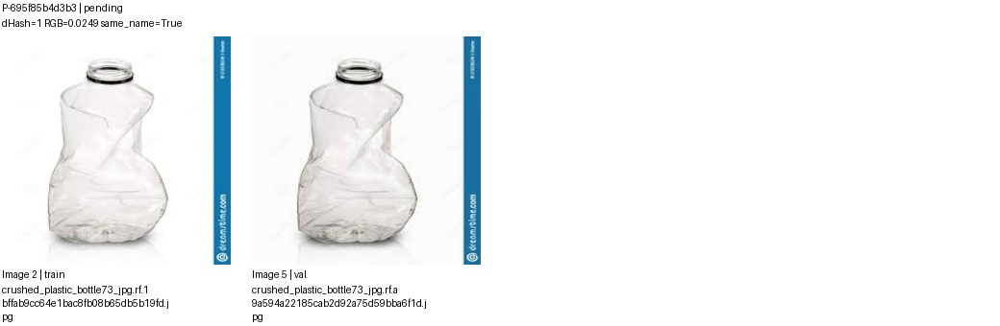

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-695f85b4d3b3,images/train/crushed_plastic_bottle73_jpg.rf.1bffab9cc64e1bac8fb08b65db5b19fd.jpg,images/val/crushed_plastic_bottle73_jpg.rf.a9a594a22185cab2d92a75d59bba6f1d.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 29/166 G-bdc45f4d0796 | 9 ảnh, 8 cặp
Split: {'train': 8, 'val': 1}
Quyết định: {'pending': 8}
Ảnh trang 1/2; cặp trang 1/2. Nhóm liên thông không phải kết luận trùng.


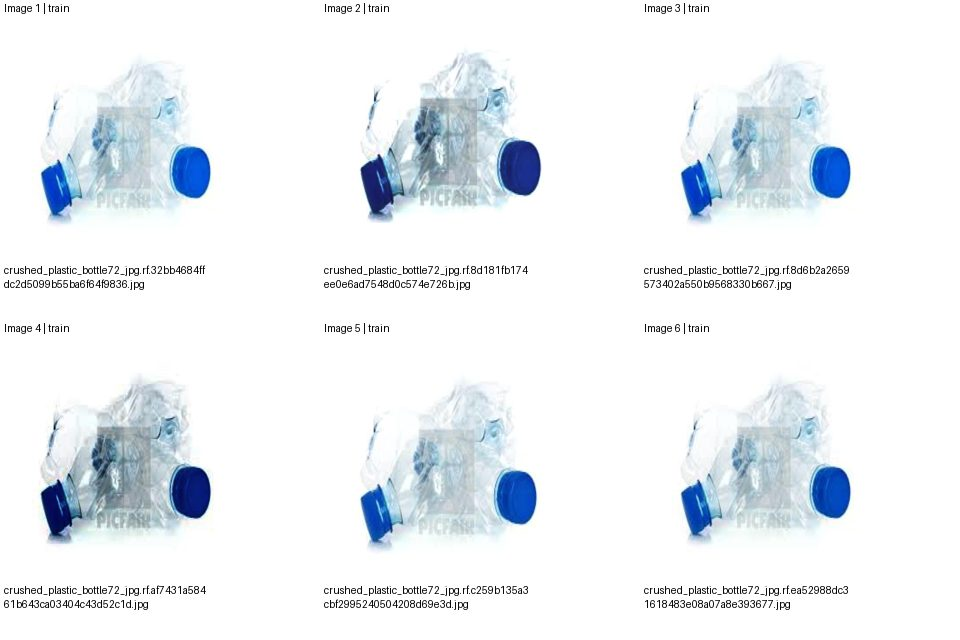

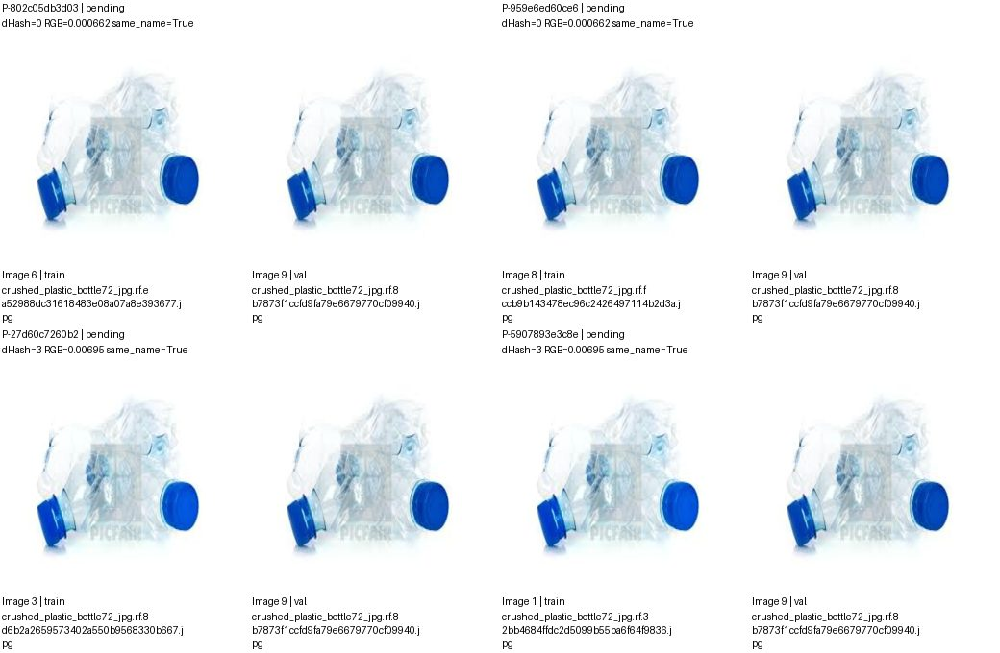

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-802c05db3d03,images/train/crushed_plastic_bottle72_jpg.rf.ea52988dc31618483e08a07a8e393677.jpg,images/val/crushed_plastic_bottle72_jpg.rf.8b7873f1ccfd9fa79e6679770cf09940.jpg,pending,
P-959e6ed60ce6,images/train/crushed_plastic_bottle72_jpg.rf.fccb9b143478ec96c2426497114b2d3a.jpg,images/val/crushed_plastic_bottle72_jpg.rf.8b7873f1ccfd9fa79e6679770cf09940.jpg,pending,
P-27d60c7260b2,images/train/crushed_plastic_bottle72_jpg.rf.8d6b2a2659573402a550b9568330b667.jpg,images/val/crushed_plastic_bottle72_jpg.rf.8b7873f1ccfd9fa79e6679770cf09940.jpg,pending,
P-5907893e3c8e,images/train/crushed_plastic_bottle72_jpg.rf.32bb4684ffdc2d5099b55ba6f64f9836.jpg,images/val/crushed_plastic_bottle72_jpg.rf.8b7873f1ccfd9fa79e6679770cf09940.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 29/166 G-bdc45f4d0796 | 9 ảnh, 8 cặp
Split: {'train': 8, 'val': 1}
Quyết định: {'pending': 8}
Ảnh trang 2/2; cặp trang 2/2. Nhóm liên thông không phải kết luận trùng.


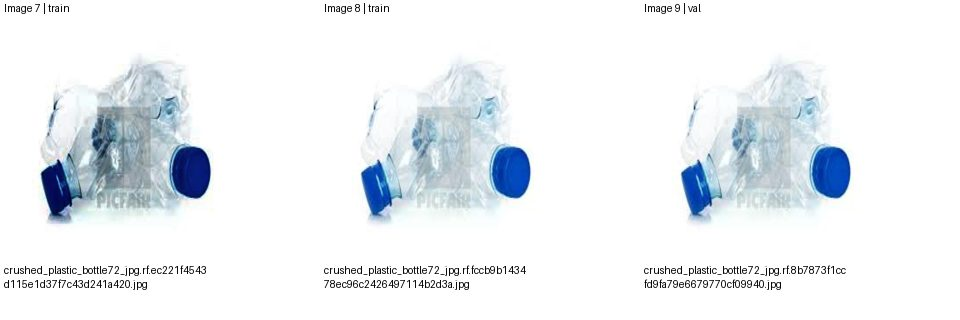

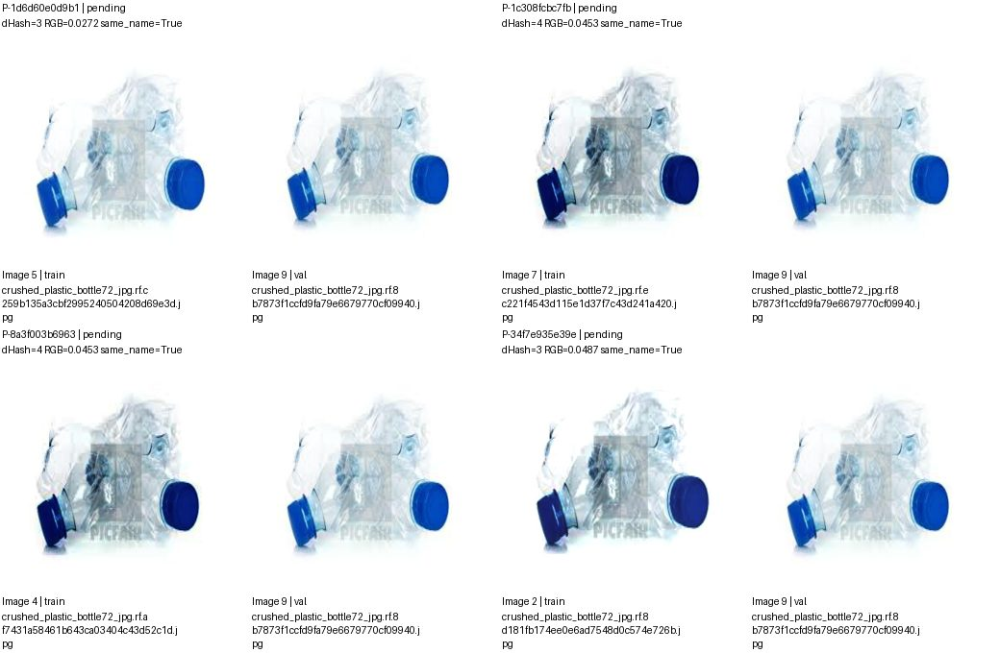

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-1d6d60e0d9b1,images/train/crushed_plastic_bottle72_jpg.rf.c259b135a3cbf2995240504208d69e3d.jpg,images/val/crushed_plastic_bottle72_jpg.rf.8b7873f1ccfd9fa79e6679770cf09940.jpg,pending,
P-1c308fcbc7fb,images/train/crushed_plastic_bottle72_jpg.rf.ec221f4543d115e1d37f7c43d241a420.jpg,images/val/crushed_plastic_bottle72_jpg.rf.8b7873f1ccfd9fa79e6679770cf09940.jpg,pending,
P-8a3f003b6963,images/train/crushed_plastic_bottle72_jpg.rf.af7431a58461b643ca03404c43d52c1d.jpg,images/val/crushed_plastic_bottle72_jpg.rf.8b7873f1ccfd9fa79e6679770cf09940.jpg,pending,
P-34f7e935e39e,images/train/crushed_plastic_bottle72_jpg.rf.8d181fb174ee0e6ad7548d0c574e726b.jpg,images/val/crushed_plastic_bottle72_jpg.rf.8b7873f1ccfd9fa79e6679770cf09940.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 30/166 G-2c6b439bdd1e | 4 ảnh, 3 cặp
Split: {'train': 3, 'val': 1}
Quyết định: {'pending': 3}
Ảnh trang 1/1; cặp trang 1/1. Nhóm liên thông không phải kết luận trùng.


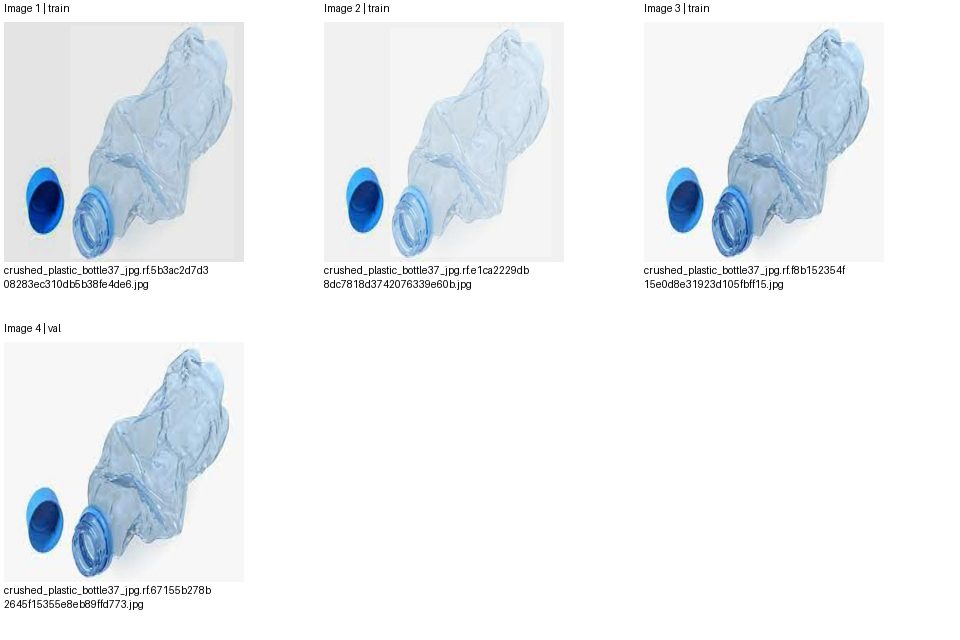

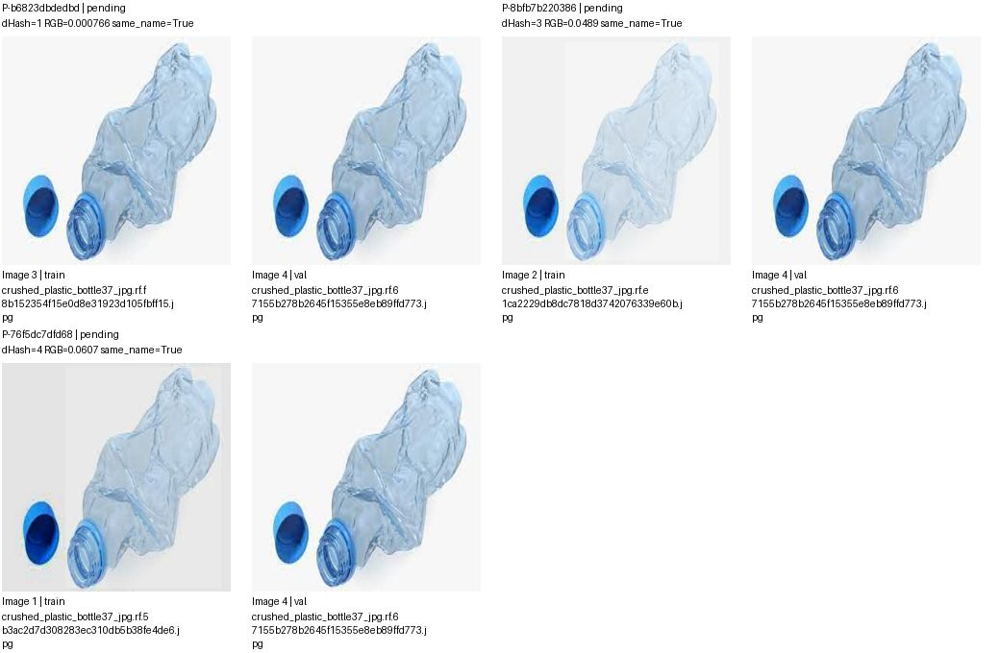

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-b6823dbdedbd,images/train/crushed_plastic_bottle37_jpg.rf.f8b152354f15e0d8e31923d105fbff15.jpg,images/val/crushed_plastic_bottle37_jpg.rf.67155b278b2645f15355e8eb89ffd773.jpg,pending,
P-8bfb7b220386,images/train/crushed_plastic_bottle37_jpg.rf.e1ca2229db8dc7818d3742076339e60b.jpg,images/val/crushed_plastic_bottle37_jpg.rf.67155b278b2645f15355e8eb89ffd773.jpg,pending,
P-76f5dc7dfd68,images/train/crushed_plastic_bottle37_jpg.rf.5b3ac2d7d308283ec310db5b38fe4de6.jpg,images/val/crushed_plastic_bottle37_jpg.rf.67155b278b2645f15355e8eb89ffd773.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 31/166 G-0edd6f9c82dd | 3 ảnh, 3 cặp
Split: {'test': 1, 'train': 1, 'val': 1}
Quyết định: {'pending': 3}
Ảnh trang 1/1; cặp trang 1/1. Nhóm liên thông không phải kết luận trùng.


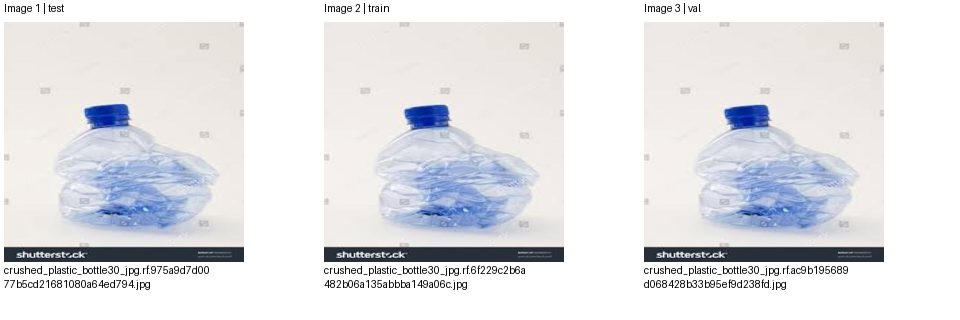

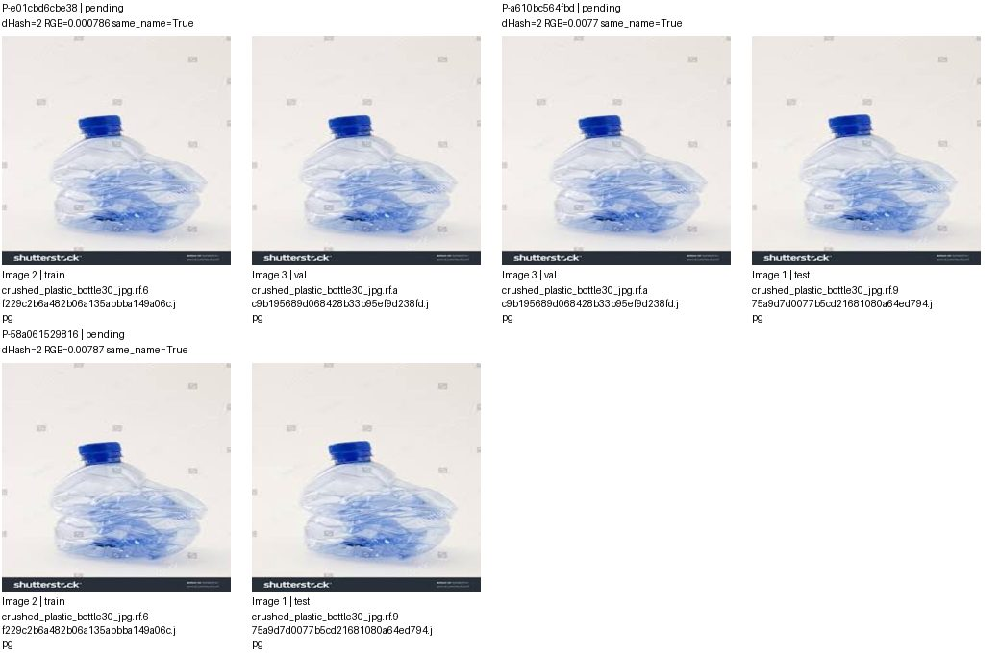

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-e01cbd6cbe38,images/train/crushed_plastic_bottle30_jpg.rf.6f229c2b6a482b06a135abbba149a06c.jpg,images/val/crushed_plastic_bottle30_jpg.rf.ac9b195689d068428b33b95ef9d238fd.jpg,pending,
P-a610bc564fbd,images/val/crushed_plastic_bottle30_jpg.rf.ac9b195689d068428b33b95ef9d238fd.jpg,images/test/crushed_plastic_bottle30_jpg.rf.975a9d7d0077b5cd21681080a64ed794.jpg,pending,
P-58a061529816,images/train/crushed_plastic_bottle30_jpg.rf.6f229c2b6a482b06a135abbba149a06c.jpg,images/test/crushed_plastic_bottle30_jpg.rf.975a9d7d0077b5cd21681080a64ed794.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 32/166 G-a8d021fc5b0c | 2 ảnh, 1 cặp
Split: {'train': 1, 'val': 1}
Quyết định: {'pending': 1}
Ảnh trang 1/1; cặp trang 1/1. Nhóm liên thông không phải kết luận trùng.


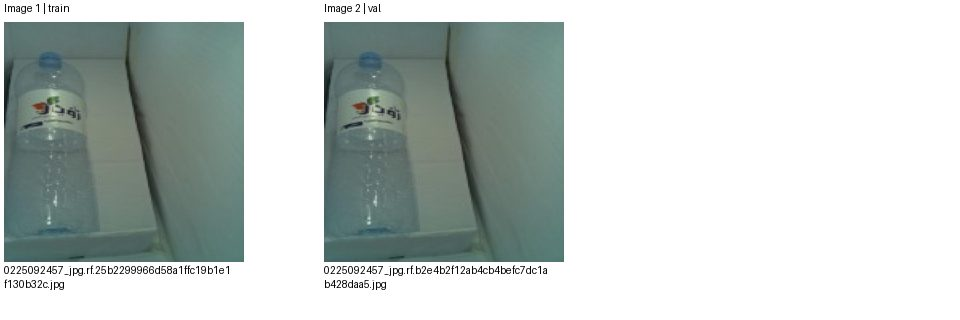

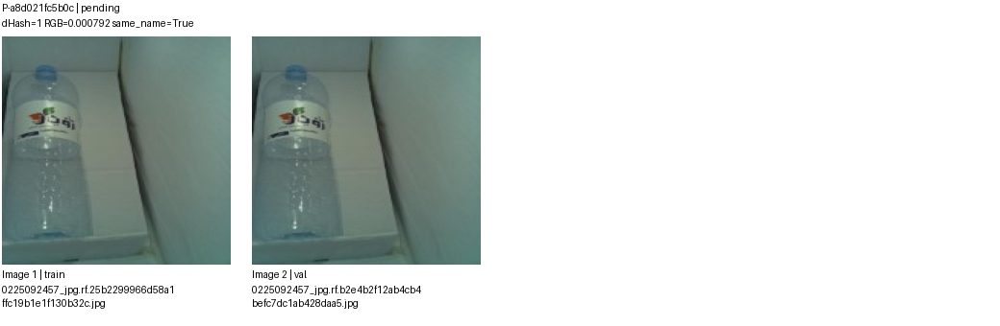

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-a8d021fc5b0c,images/train/0225092457_jpg.rf.25b2299966d58a1ffc19b1e1f130b32c.jpg,images/val/0225092457_jpg.rf.b2e4b2f12ab4cb4befc7dc1ab428daa5.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 33/166 G-43e45ee1e19e | 2 ảnh, 1 cặp
Split: {'train': 1, 'val': 1}
Quyết định: {'pending': 1}
Ảnh trang 1/1; cặp trang 1/1. Nhóm liên thông không phải kết luận trùng.


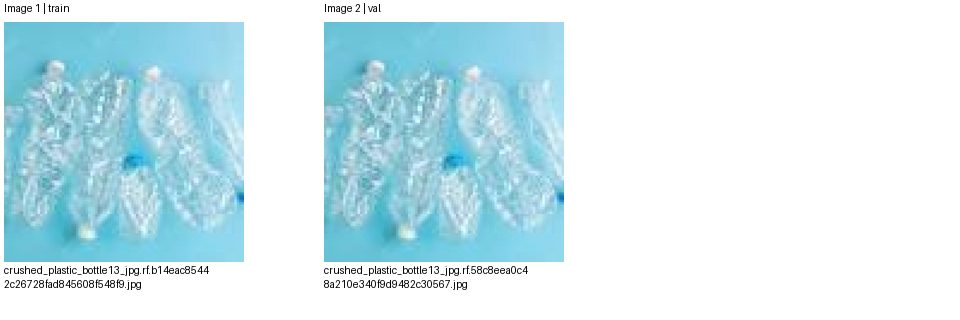

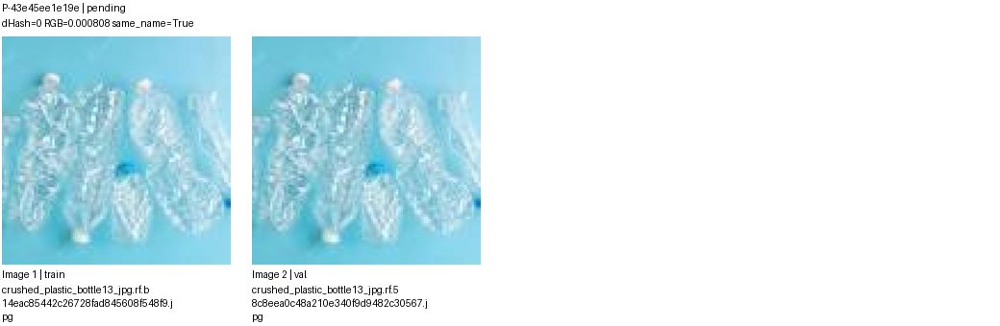

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-43e45ee1e19e,images/train/crushed_plastic_bottle13_jpg.rf.b14eac85442c26728fad845608f548f9.jpg,images/val/crushed_plastic_bottle13_jpg.rf.58c8eea0c48a210e340f9d9482c30567.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 34/166 G-fd6d72221ef7 | 46 ảnh, 95 cặp
Split: {'test': 3, 'train': 36, 'val': 7}
Quyết định: {'pending': 95}
Ảnh trang 1/8; cặp trang 1/24. Nhóm liên thông không phải kết luận trùng.


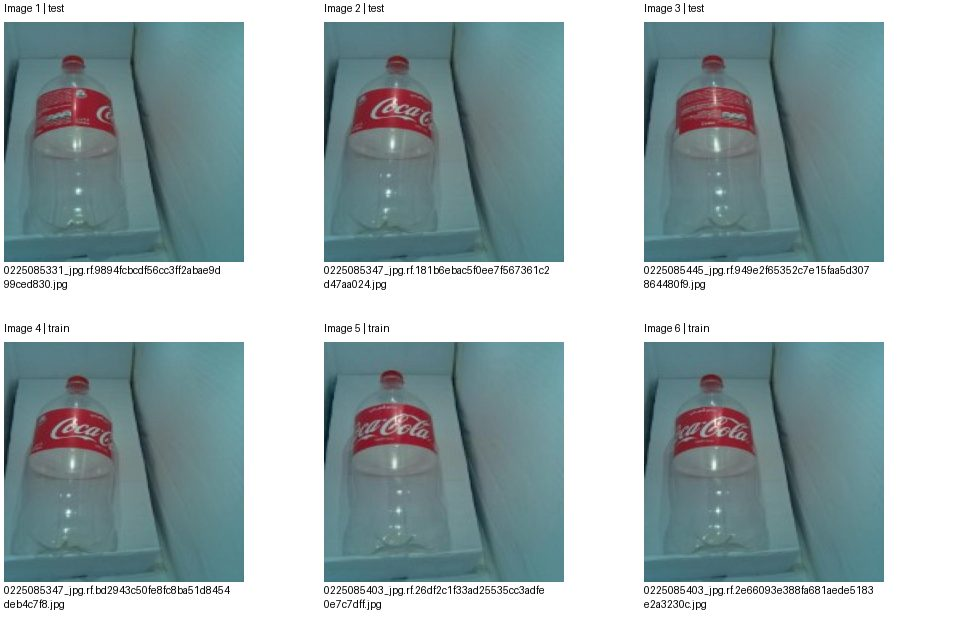

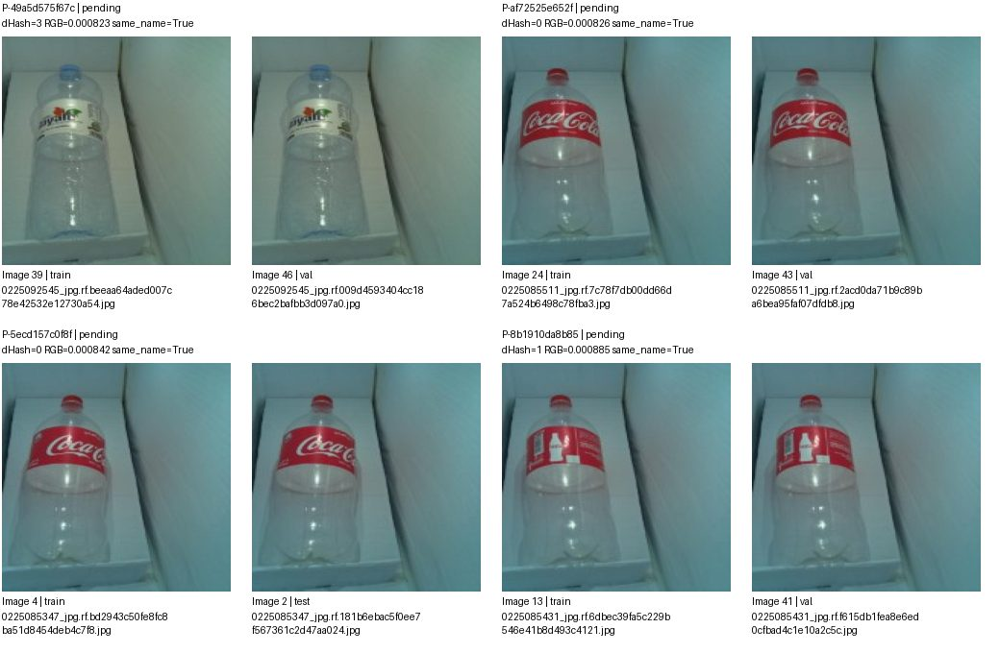

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-49a5d575f67c,images/train/0225092545_jpg.rf.beeaa64aded007c78e42532e12730a54.jpg,images/val/0225092545_jpg.rf.009d4593404cc186bec2bafbb3d097a0.jpg,pending,
P-af72525e652f,images/train/0225085511_jpg.rf.7c78f7db00dd66d7a524b6498c78fba3.jpg,images/val/0225085511_jpg.rf.2acd0da71b9c89ba6bea95faf07dfdb8.jpg,pending,
P-5ecd157c0f8f,images/train/0225085347_jpg.rf.bd2943c50fe8fc8ba51d8454deb4c7f8.jpg,images/test/0225085347_jpg.rf.181b6ebac5f0ee7f567361c2d47aa024.jpg,pending,
P-8b1910da8b85,images/train/0225085431_jpg.rf.6dbec39fa5c229b546e41b8d493c4121.jpg,images/val/0225085431_jpg.rf.f615db1fea8e6ed0cfbad4c1e10a2c5c.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 34/166 G-fd6d72221ef7 | 46 ảnh, 95 cặp
Split: {'test': 3, 'train': 36, 'val': 7}
Quyết định: {'pending': 95}
Ảnh trang 2/8; cặp trang 2/24. Nhóm liên thông không phải kết luận trùng.


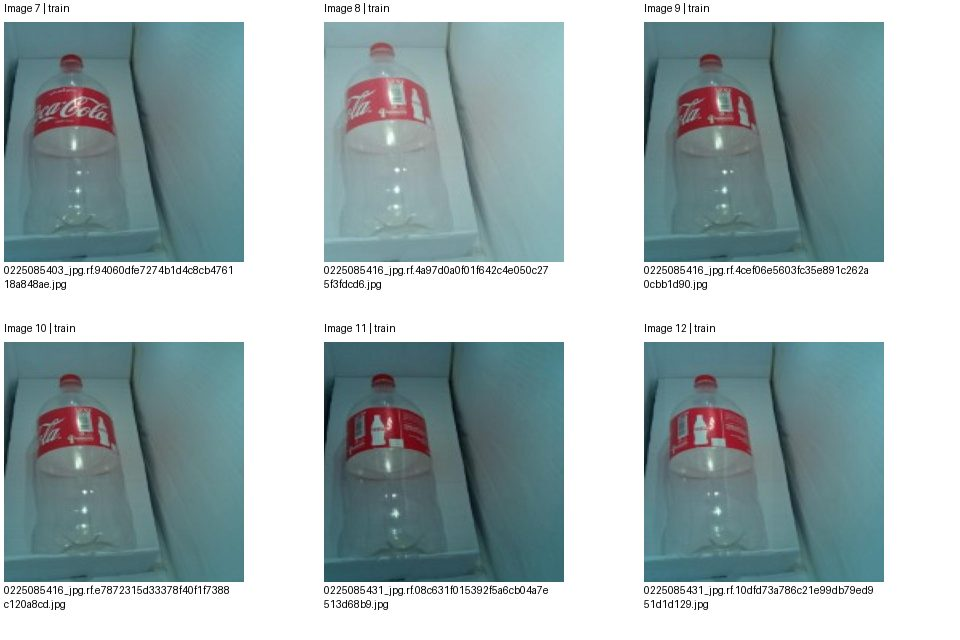

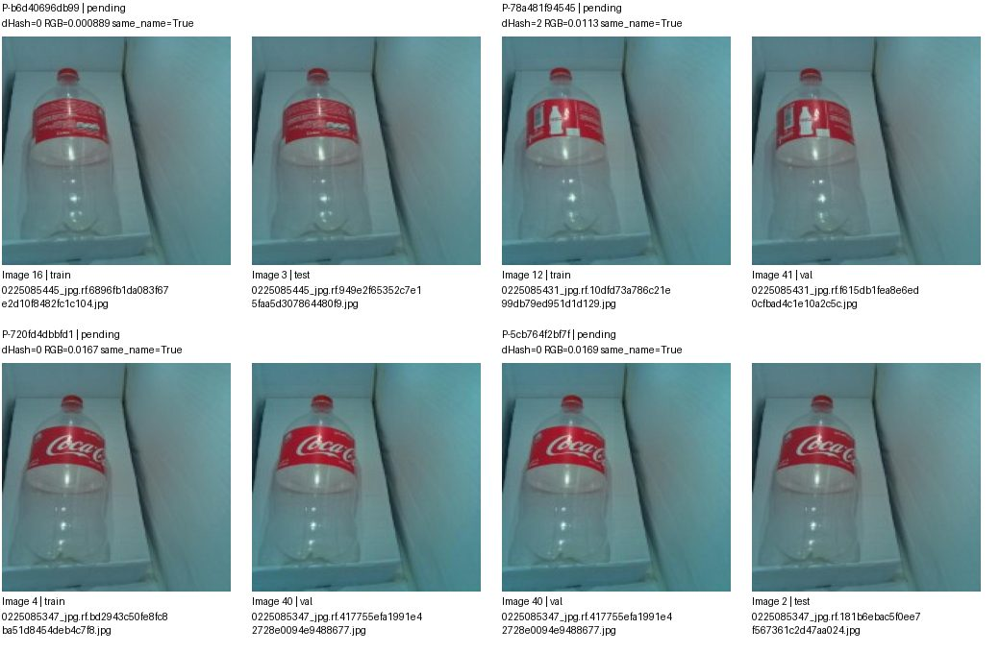

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-b6d40696db99,images/train/0225085445_jpg.rf.6896fb1da083f67e2d10f8482fc1c104.jpg,images/test/0225085445_jpg.rf.949e2f65352c7e15faa5d307864480f9.jpg,pending,
P-78a481f94545,images/train/0225085431_jpg.rf.10dfd73a786c21e99db79ed951d1d129.jpg,images/val/0225085431_jpg.rf.f615db1fea8e6ed0cfbad4c1e10a2c5c.jpg,pending,
P-720fd4dbbfd1,images/train/0225085347_jpg.rf.bd2943c50fe8fc8ba51d8454deb4c7f8.jpg,images/val/0225085347_jpg.rf.417755efa1991e42728e0094e9488677.jpg,pending,
P-5cb764f2bf7f,images/val/0225085347_jpg.rf.417755efa1991e42728e0094e9488677.jpg,images/test/0225085347_jpg.rf.181b6ebac5f0ee7f567361c2d47aa024.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 34/166 G-fd6d72221ef7 | 46 ảnh, 95 cặp
Split: {'test': 3, 'train': 36, 'val': 7}
Quyết định: {'pending': 95}
Ảnh trang 3/8; cặp trang 3/24. Nhóm liên thông không phải kết luận trùng.


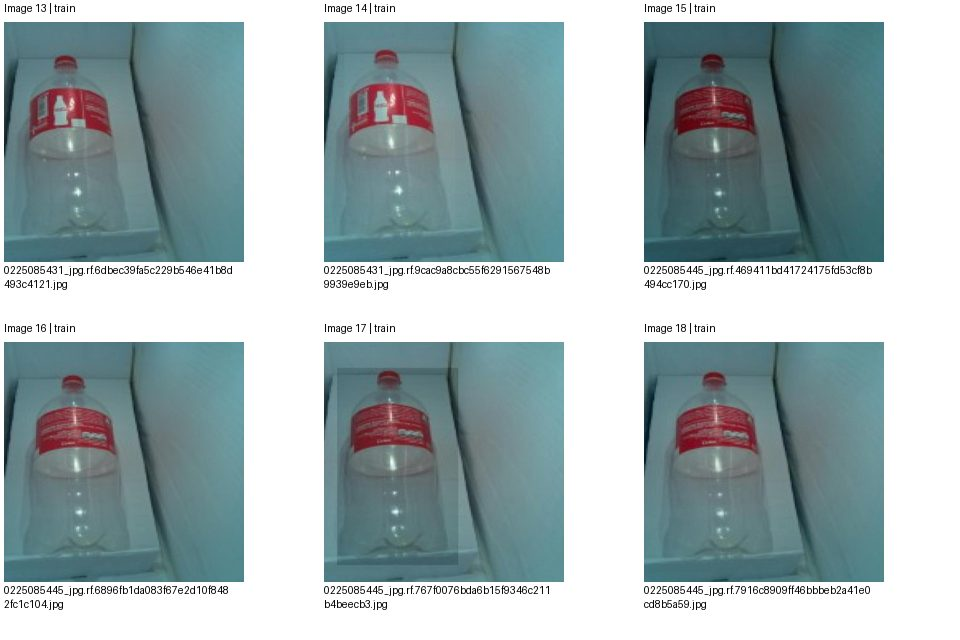

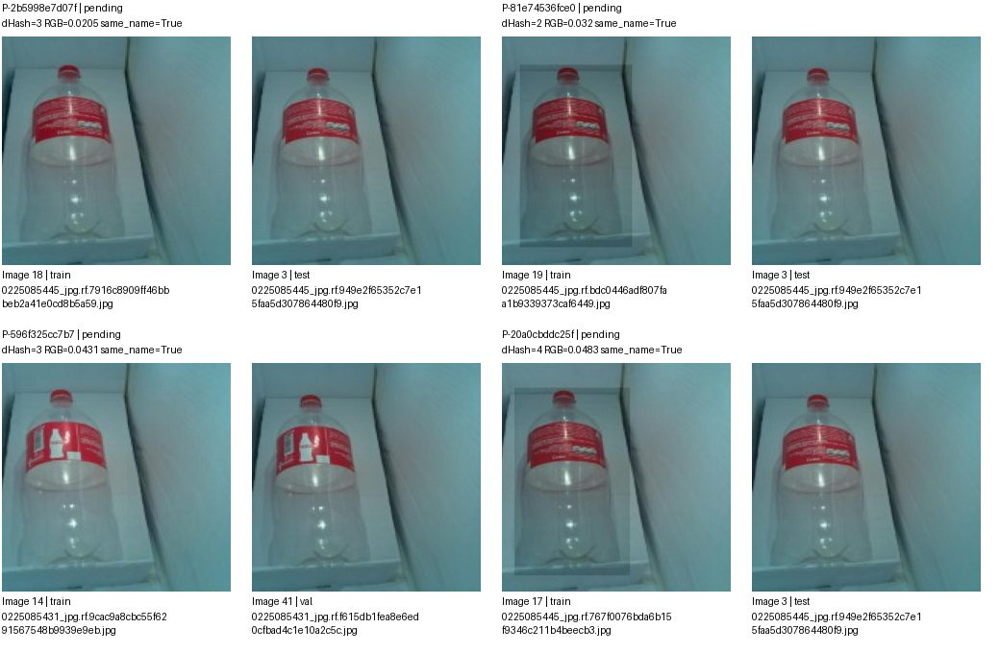

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-2b5998e7d07f,images/train/0225085445_jpg.rf.7916c8909ff46bbbeb2a41e0cd8b5a59.jpg,images/test/0225085445_jpg.rf.949e2f65352c7e15faa5d307864480f9.jpg,pending,
P-81e74536fce0,images/train/0225085445_jpg.rf.bdc0446adf807faa1b9339373caf6449.jpg,images/test/0225085445_jpg.rf.949e2f65352c7e15faa5d307864480f9.jpg,pending,
P-596f325cc7b7,images/train/0225085431_jpg.rf.9cac9a8cbc55f6291567548b9939e9eb.jpg,images/val/0225085431_jpg.rf.f615db1fea8e6ed0cfbad4c1e10a2c5c.jpg,pending,
P-20a0cbddc25f,images/train/0225085445_jpg.rf.767f0076bda6b15f9346c211b4beecb3.jpg,images/test/0225085445_jpg.rf.949e2f65352c7e15faa5d307864480f9.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 34/166 G-fd6d72221ef7 | 46 ảnh, 95 cặp
Split: {'test': 3, 'train': 36, 'val': 7}
Quyết định: {'pending': 95}
Ảnh trang 4/8; cặp trang 4/24. Nhóm liên thông không phải kết luận trùng.


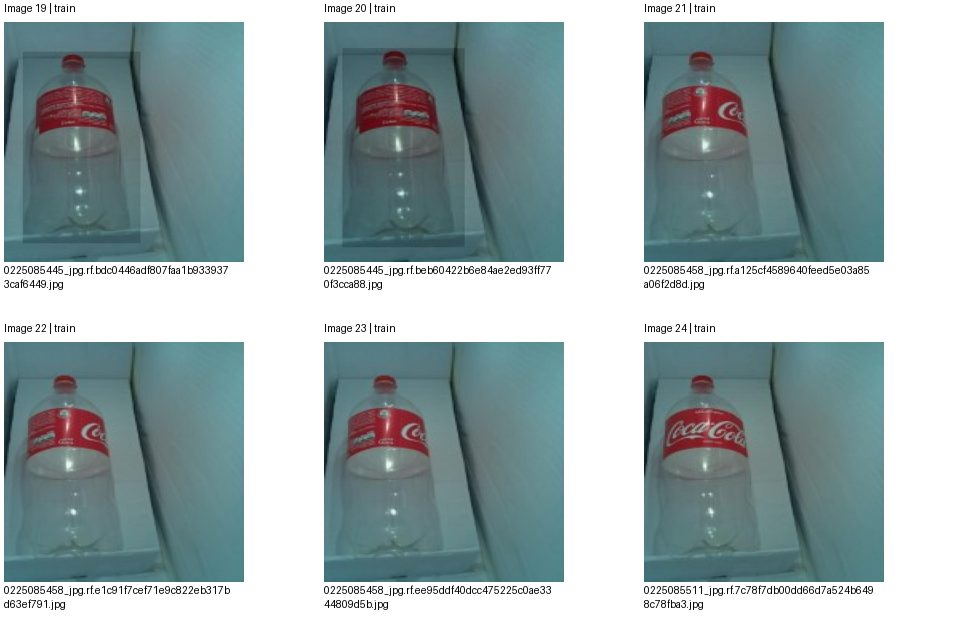

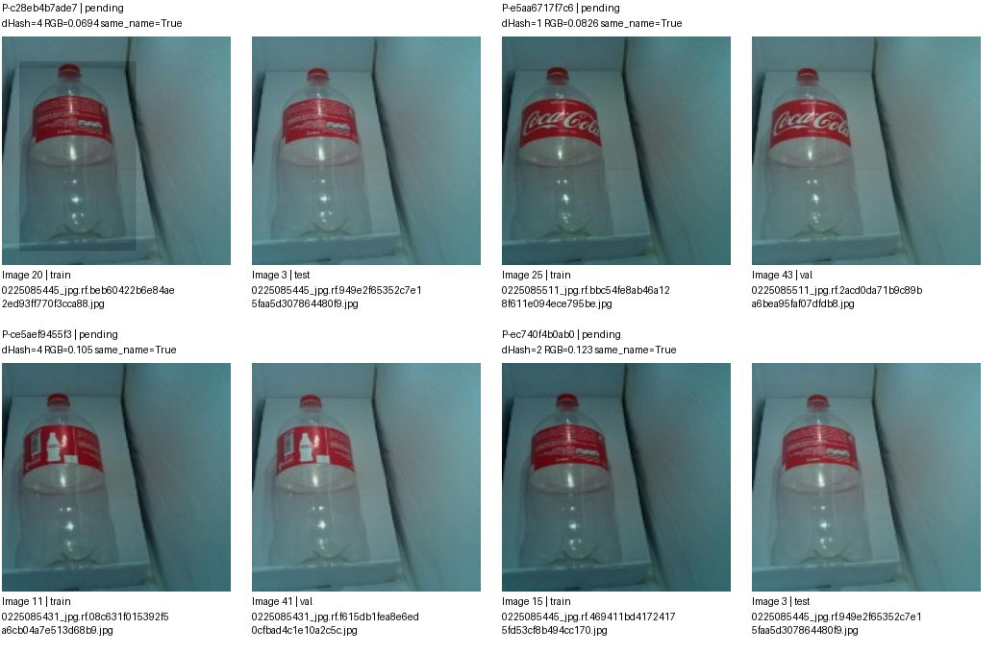

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-c28eb4b7ade7,images/train/0225085445_jpg.rf.beb60422b6e84ae2ed93ff770f3cca88.jpg,images/test/0225085445_jpg.rf.949e2f65352c7e15faa5d307864480f9.jpg,pending,
P-e5aa6717f7c6,images/train/0225085511_jpg.rf.bbc54fe8ab46a128f611e094ece795be.jpg,images/val/0225085511_jpg.rf.2acd0da71b9c89ba6bea95faf07dfdb8.jpg,pending,
P-ce5aef9455f3,images/train/0225085431_jpg.rf.08c631f015392f5a6cb04a7e513d68b9.jpg,images/val/0225085431_jpg.rf.f615db1fea8e6ed0cfbad4c1e10a2c5c.jpg,pending,
P-ec740f4b0ab0,images/train/0225085445_jpg.rf.469411bd41724175fd53cf8b494cc170.jpg,images/test/0225085445_jpg.rf.949e2f65352c7e15faa5d307864480f9.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 34/166 G-fd6d72221ef7 | 46 ảnh, 95 cặp
Split: {'test': 3, 'train': 36, 'val': 7}
Quyết định: {'pending': 95}
Ảnh trang 5/8; cặp trang 5/24. Nhóm liên thông không phải kết luận trùng.


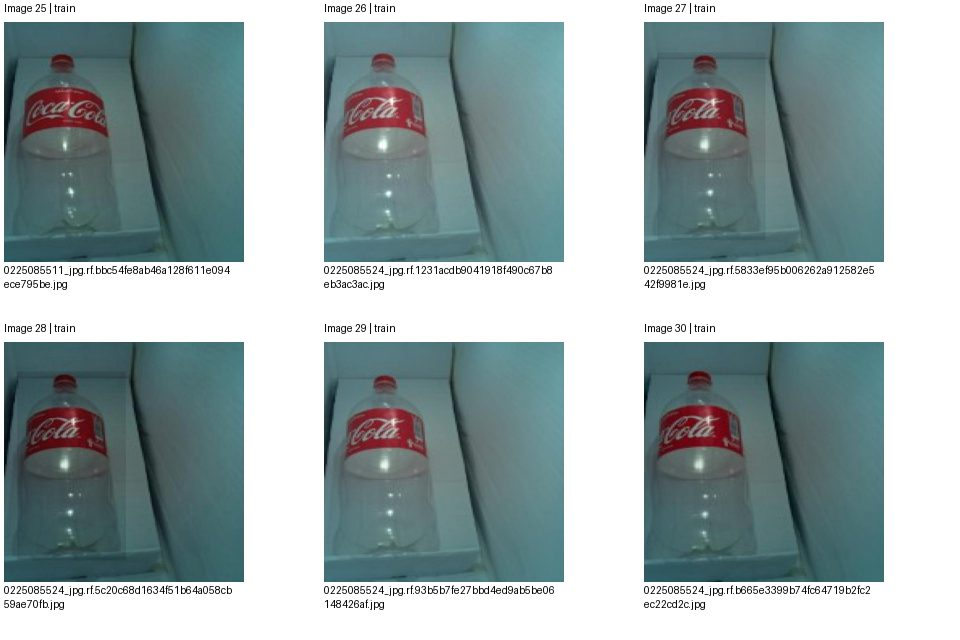

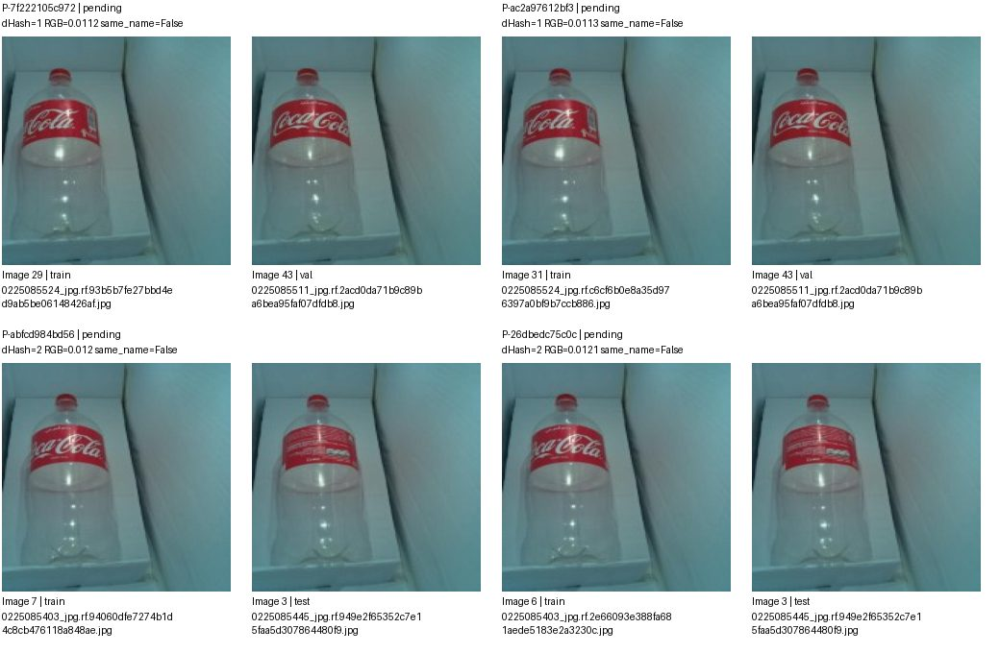

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-7f222105c972,images/train/0225085524_jpg.rf.93b5b7fe27bbd4ed9ab5be06148426af.jpg,images/val/0225085511_jpg.rf.2acd0da71b9c89ba6bea95faf07dfdb8.jpg,pending,
P-ac2a97612bf3,images/train/0225085524_jpg.rf.c6cf6b0e8a35d976397a0bf9b7ccb886.jpg,images/val/0225085511_jpg.rf.2acd0da71b9c89ba6bea95faf07dfdb8.jpg,pending,
P-abfcd984bd56,images/train/0225085403_jpg.rf.94060dfe7274b1d4c8cb476118a848ae.jpg,images/test/0225085445_jpg.rf.949e2f65352c7e15faa5d307864480f9.jpg,pending,
P-26dbedc75c0c,images/train/0225085403_jpg.rf.2e66093e388fa681aede5183e2a3230c.jpg,images/test/0225085445_jpg.rf.949e2f65352c7e15faa5d307864480f9.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 34/166 G-fd6d72221ef7 | 46 ảnh, 95 cặp
Split: {'test': 3, 'train': 36, 'val': 7}
Quyết định: {'pending': 95}
Ảnh trang 6/8; cặp trang 6/24. Nhóm liên thông không phải kết luận trùng.


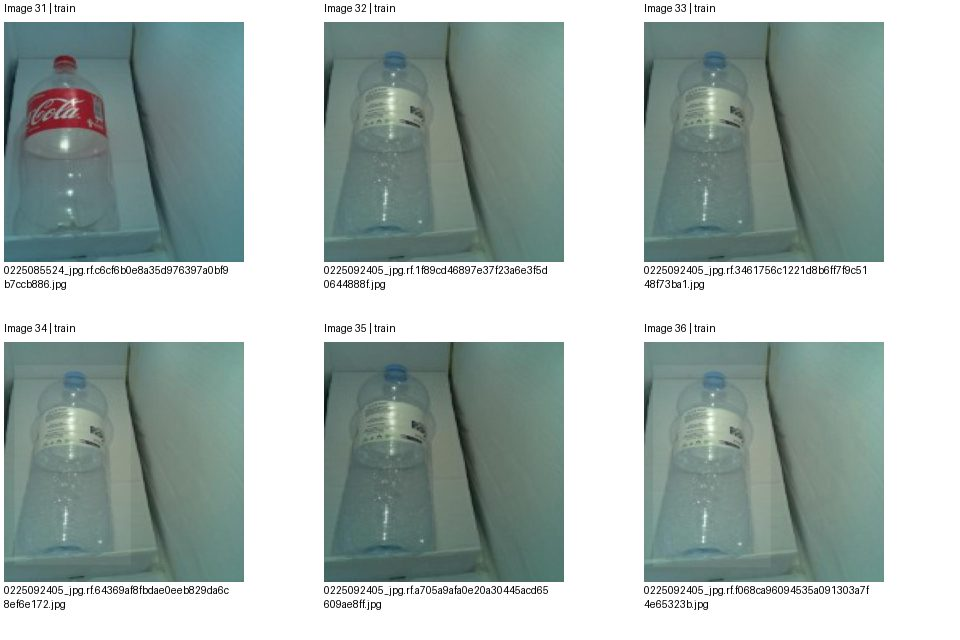

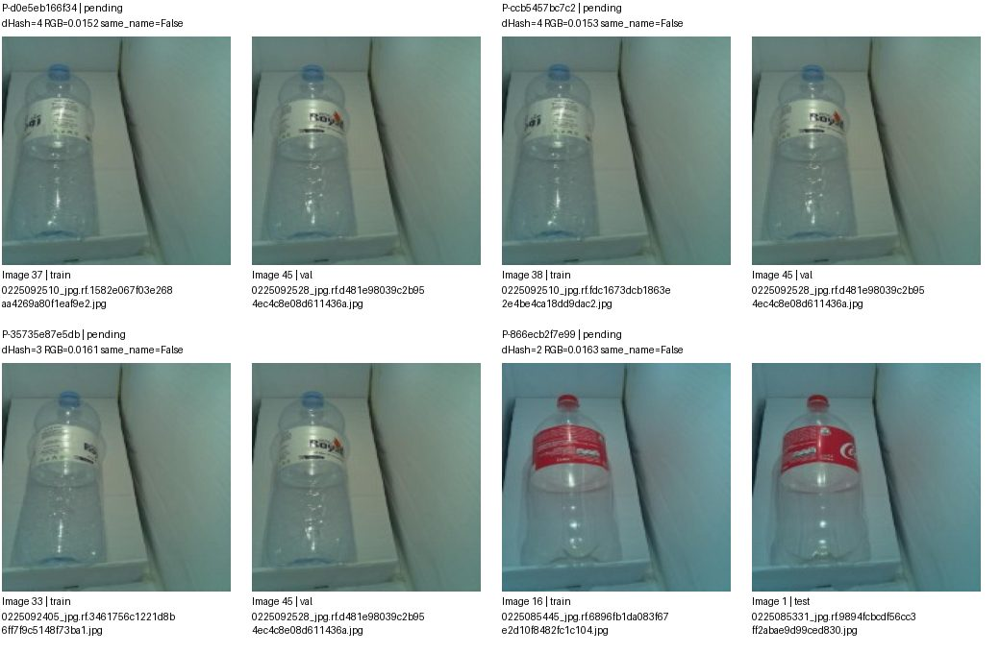

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-d0e5eb166f34,images/train/0225092510_jpg.rf.1582e067f03e268aa4269a80f1eaf9e2.jpg,images/val/0225092528_jpg.rf.d481e98039c2b954ec4c8e08d611436a.jpg,pending,
P-ccb5457bc7c2,images/train/0225092510_jpg.rf.fdc1673dcb1863e2e4be4ca18dd9dac2.jpg,images/val/0225092528_jpg.rf.d481e98039c2b954ec4c8e08d611436a.jpg,pending,
P-35735e87e5db,images/train/0225092405_jpg.rf.3461756c1221d8b6ff7f9c5148f73ba1.jpg,images/val/0225092528_jpg.rf.d481e98039c2b954ec4c8e08d611436a.jpg,pending,
P-866ecb2f7e99,images/train/0225085445_jpg.rf.6896fb1da083f67e2d10f8482fc1c104.jpg,images/test/0225085331_jpg.rf.9894fcbcdf56cc3ff2abae9d99ced830.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 34/166 G-fd6d72221ef7 | 46 ảnh, 95 cặp
Split: {'test': 3, 'train': 36, 'val': 7}
Quyết định: {'pending': 95}
Ảnh trang 7/8; cặp trang 7/24. Nhóm liên thông không phải kết luận trùng.


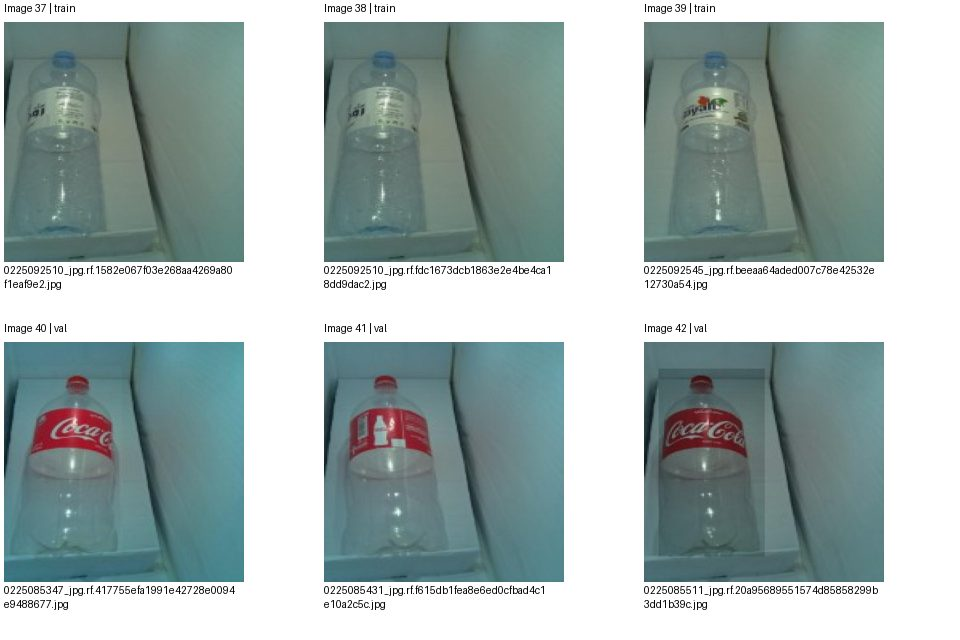

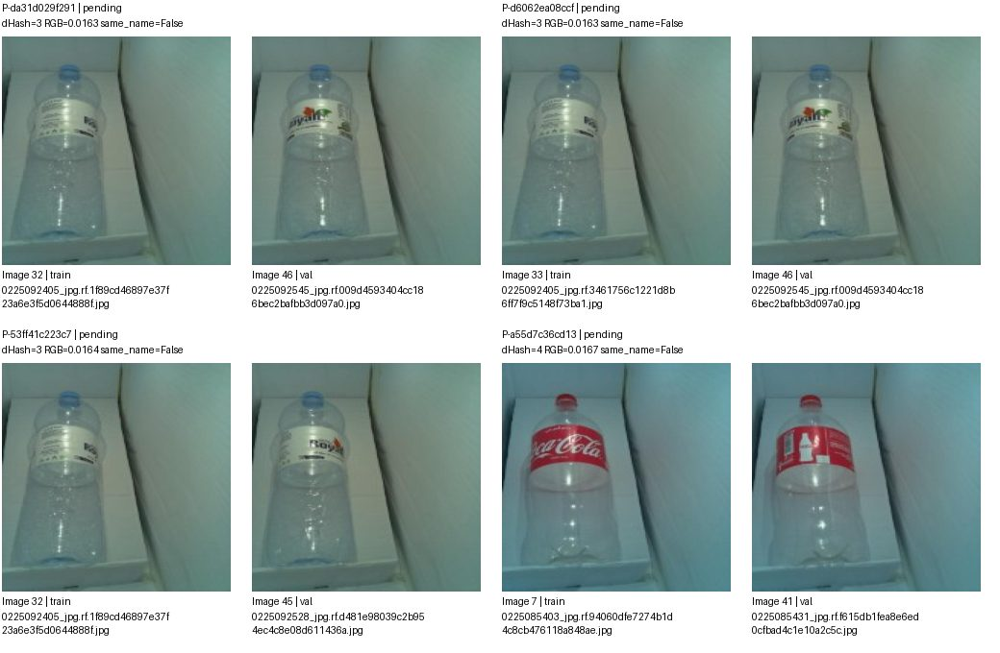

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-da31d029f291,images/train/0225092405_jpg.rf.1f89cd46897e37f23a6e3f5d0644888f.jpg,images/val/0225092545_jpg.rf.009d4593404cc186bec2bafbb3d097a0.jpg,pending,
P-d6062ea08ccf,images/train/0225092405_jpg.rf.3461756c1221d8b6ff7f9c5148f73ba1.jpg,images/val/0225092545_jpg.rf.009d4593404cc186bec2bafbb3d097a0.jpg,pending,
P-53ff41c223c7,images/train/0225092405_jpg.rf.1f89cd46897e37f23a6e3f5d0644888f.jpg,images/val/0225092528_jpg.rf.d481e98039c2b954ec4c8e08d611436a.jpg,pending,
P-a55d7c36cd13,images/train/0225085403_jpg.rf.94060dfe7274b1d4c8cb476118a848ae.jpg,images/val/0225085431_jpg.rf.f615db1fea8e6ed0cfbad4c1e10a2c5c.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 34/166 G-fd6d72221ef7 | 46 ảnh, 95 cặp
Split: {'test': 3, 'train': 36, 'val': 7}
Quyết định: {'pending': 95}
Ảnh trang 8/8; cặp trang 8/24. Nhóm liên thông không phải kết luận trùng.


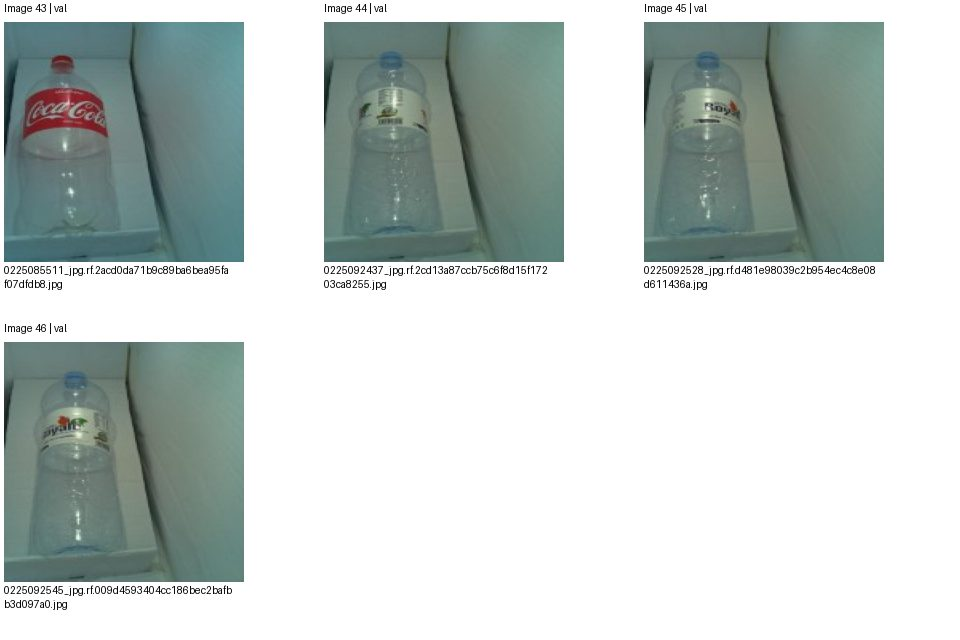

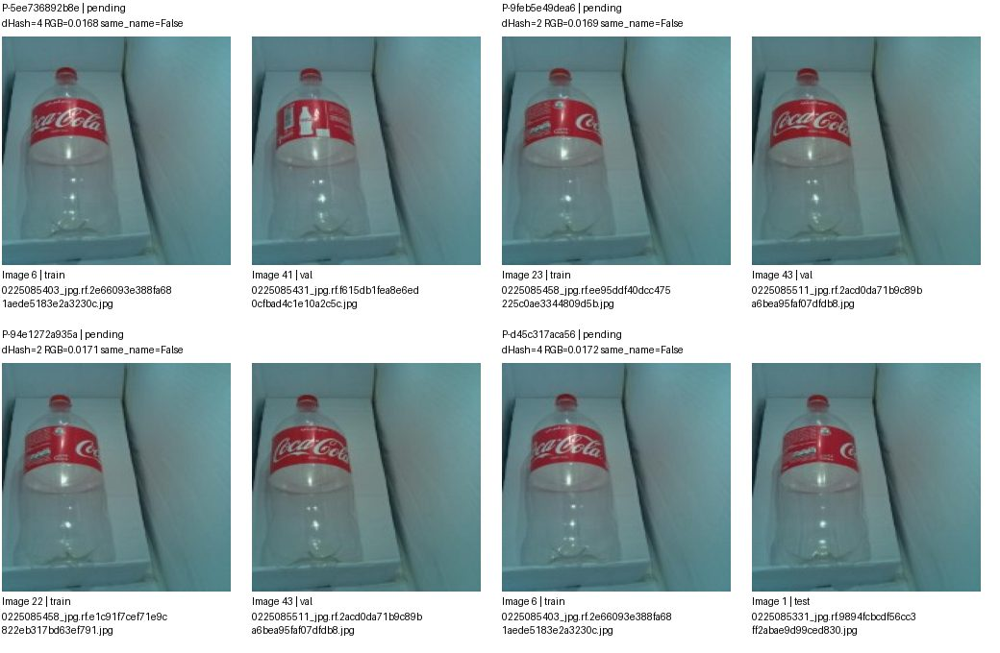

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-5ee736892b8e,images/train/0225085403_jpg.rf.2e66093e388fa681aede5183e2a3230c.jpg,images/val/0225085431_jpg.rf.f615db1fea8e6ed0cfbad4c1e10a2c5c.jpg,pending,
P-9feb5e49dea6,images/train/0225085458_jpg.rf.ee95ddf40dcc475225c0ae3344809d5b.jpg,images/val/0225085511_jpg.rf.2acd0da71b9c89ba6bea95faf07dfdb8.jpg,pending,
P-94e1272a935a,images/train/0225085458_jpg.rf.e1c91f7cef71e9c822eb317bd63ef791.jpg,images/val/0225085511_jpg.rf.2acd0da71b9c89ba6bea95faf07dfdb8.jpg,pending,
P-d45c317aca56,images/train/0225085403_jpg.rf.2e66093e388fa681aede5183e2a3230c.jpg,images/test/0225085331_jpg.rf.9894fcbcdf56cc3ff2abae9d99ced830.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 34/166 G-fd6d72221ef7 | 46 ảnh, 95 cặp
Split: {'test': 3, 'train': 36, 'val': 7}
Quyết định: {'pending': 95}
Ảnh trang None/8; cặp trang 9/24. Nhóm liên thông không phải kết luận trùng.


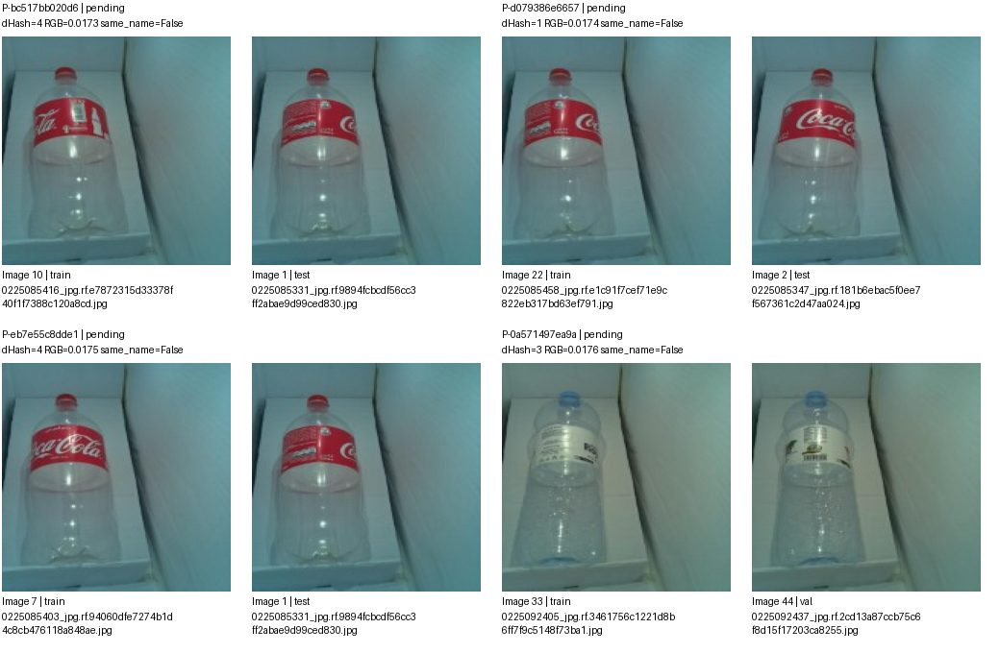

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-bc517bb020d6,images/train/0225085416_jpg.rf.e7872315d33378f40f1f7388c120a8cd.jpg,images/test/0225085331_jpg.rf.9894fcbcdf56cc3ff2abae9d99ced830.jpg,pending,
P-d079386e6657,images/train/0225085458_jpg.rf.e1c91f7cef71e9c822eb317bd63ef791.jpg,images/test/0225085347_jpg.rf.181b6ebac5f0ee7f567361c2d47aa024.jpg,pending,
P-eb7e55c8dde1,images/train/0225085403_jpg.rf.94060dfe7274b1d4c8cb476118a848ae.jpg,images/test/0225085331_jpg.rf.9894fcbcdf56cc3ff2abae9d99ced830.jpg,pending,
P-0a571497ea9a,images/train/0225092405_jpg.rf.3461756c1221d8b6ff7f9c5148f73ba1.jpg,images/val/0225092437_jpg.rf.2cd13a87ccb75c6f8d15f17203ca8255.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 34/166 G-fd6d72221ef7 | 46 ảnh, 95 cặp
Split: {'test': 3, 'train': 36, 'val': 7}
Quyết định: {'pending': 95}
Ảnh trang None/8; cặp trang 10/24. Nhóm liên thông không phải kết luận trùng.


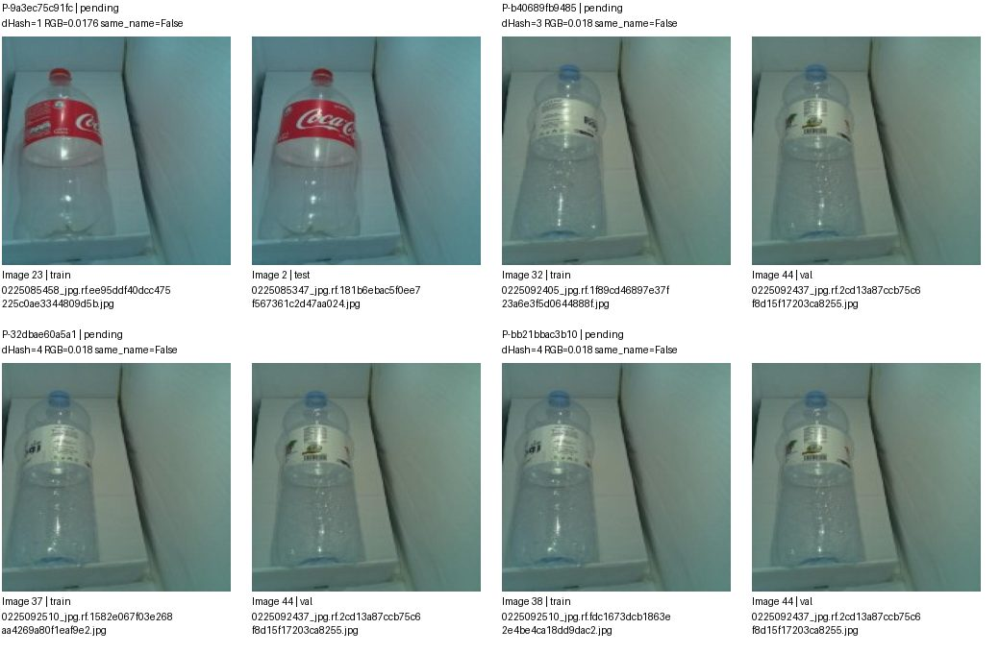

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-9a3ec75c91fc,images/train/0225085458_jpg.rf.ee95ddf40dcc475225c0ae3344809d5b.jpg,images/test/0225085347_jpg.rf.181b6ebac5f0ee7f567361c2d47aa024.jpg,pending,
P-b40689fb9485,images/train/0225092405_jpg.rf.1f89cd46897e37f23a6e3f5d0644888f.jpg,images/val/0225092437_jpg.rf.2cd13a87ccb75c6f8d15f17203ca8255.jpg,pending,
P-32dbae60a5a1,images/train/0225092510_jpg.rf.1582e067f03e268aa4269a80f1eaf9e2.jpg,images/val/0225092437_jpg.rf.2cd13a87ccb75c6f8d15f17203ca8255.jpg,pending,
P-bb21bbac3b10,images/train/0225092510_jpg.rf.fdc1673dcb1863e2e4be4ca18dd9dac2.jpg,images/val/0225092437_jpg.rf.2cd13a87ccb75c6f8d15f17203ca8255.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 34/166 G-fd6d72221ef7 | 46 ảnh, 95 cặp
Split: {'test': 3, 'train': 36, 'val': 7}
Quyết định: {'pending': 95}
Ảnh trang None/8; cặp trang 11/24. Nhóm liên thông không phải kết luận trùng.


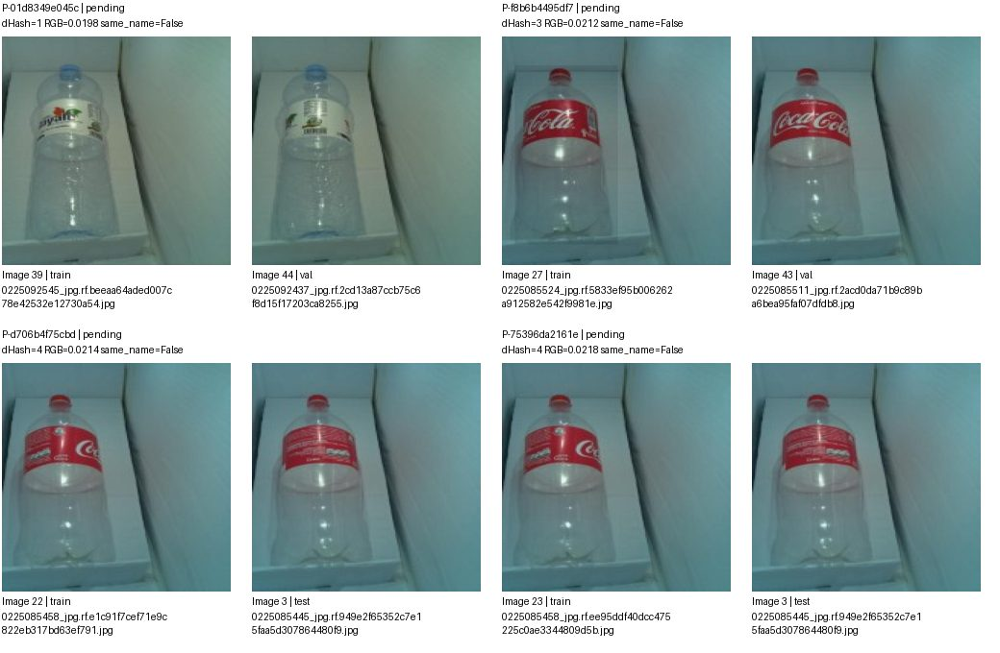

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-01d8349e045c,images/train/0225092545_jpg.rf.beeaa64aded007c78e42532e12730a54.jpg,images/val/0225092437_jpg.rf.2cd13a87ccb75c6f8d15f17203ca8255.jpg,pending,
P-f8b6b4495df7,images/train/0225085524_jpg.rf.5833ef95b006262a912582e542f9981e.jpg,images/val/0225085511_jpg.rf.2acd0da71b9c89ba6bea95faf07dfdb8.jpg,pending,
P-d706b4f75cbd,images/train/0225085458_jpg.rf.e1c91f7cef71e9c822eb317bd63ef791.jpg,images/test/0225085445_jpg.rf.949e2f65352c7e15faa5d307864480f9.jpg,pending,
P-75396da2161e,images/train/0225085458_jpg.rf.ee95ddf40dcc475225c0ae3344809d5b.jpg,images/test/0225085445_jpg.rf.949e2f65352c7e15faa5d307864480f9.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 34/166 G-fd6d72221ef7 | 46 ảnh, 95 cặp
Split: {'test': 3, 'train': 36, 'val': 7}
Quyết định: {'pending': 95}
Ảnh trang None/8; cặp trang 12/24. Nhóm liên thông không phải kết luận trùng.


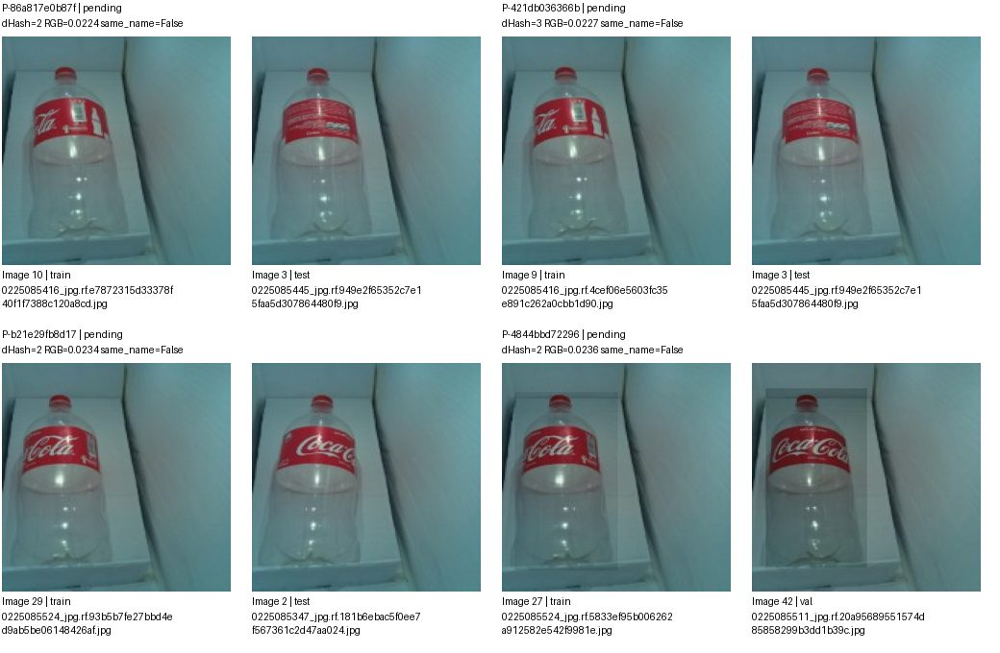

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-86a817e0b87f,images/train/0225085416_jpg.rf.e7872315d33378f40f1f7388c120a8cd.jpg,images/test/0225085445_jpg.rf.949e2f65352c7e15faa5d307864480f9.jpg,pending,
P-421db036366b,images/train/0225085416_jpg.rf.4cef06e5603fc35e891c262a0cbb1d90.jpg,images/test/0225085445_jpg.rf.949e2f65352c7e15faa5d307864480f9.jpg,pending,
P-b21e29fb8d17,images/train/0225085524_jpg.rf.93b5b7fe27bbd4ed9ab5be06148426af.jpg,images/test/0225085347_jpg.rf.181b6ebac5f0ee7f567361c2d47aa024.jpg,pending,
P-4844bbd72296,images/train/0225085524_jpg.rf.5833ef95b006262a912582e542f9981e.jpg,images/val/0225085511_jpg.rf.20a95689551574d85858299b3dd1b39c.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 34/166 G-fd6d72221ef7 | 46 ảnh, 95 cặp
Split: {'test': 3, 'train': 36, 'val': 7}
Quyết định: {'pending': 95}
Ảnh trang None/8; cặp trang 13/24. Nhóm liên thông không phải kết luận trùng.


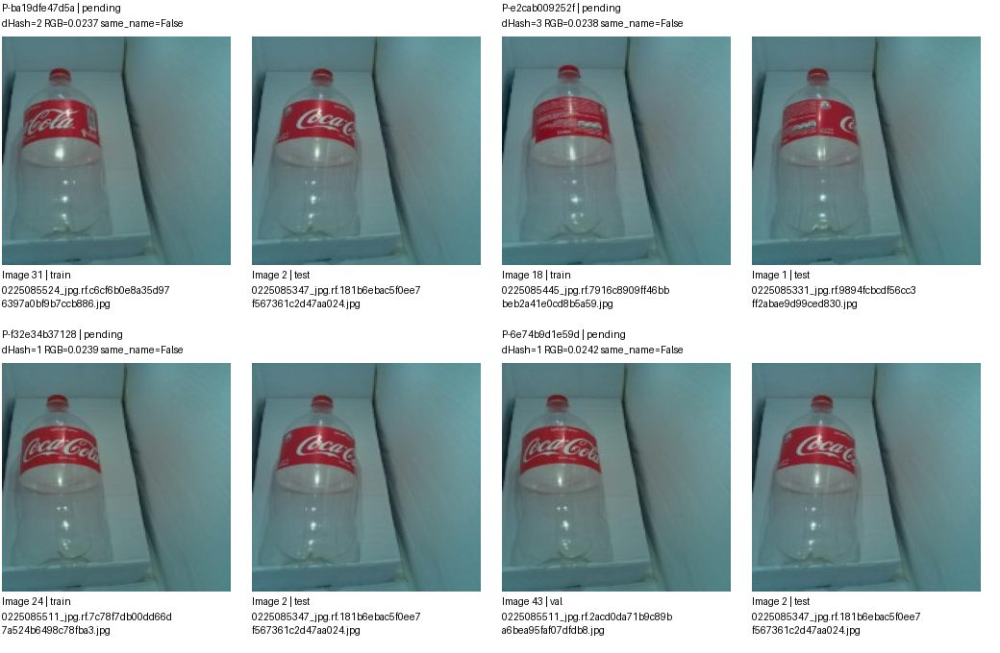

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-ba19dfe47d5a,images/train/0225085524_jpg.rf.c6cf6b0e8a35d976397a0bf9b7ccb886.jpg,images/test/0225085347_jpg.rf.181b6ebac5f0ee7f567361c2d47aa024.jpg,pending,
P-e2cab009252f,images/train/0225085445_jpg.rf.7916c8909ff46bbbeb2a41e0cd8b5a59.jpg,images/test/0225085331_jpg.rf.9894fcbcdf56cc3ff2abae9d99ced830.jpg,pending,
P-f32e34b37128,images/train/0225085511_jpg.rf.7c78f7db00dd66d7a524b6498c78fba3.jpg,images/test/0225085347_jpg.rf.181b6ebac5f0ee7f567361c2d47aa024.jpg,pending,
P-6e74b9d1e59d,images/val/0225085511_jpg.rf.2acd0da71b9c89ba6bea95faf07dfdb8.jpg,images/test/0225085347_jpg.rf.181b6ebac5f0ee7f567361c2d47aa024.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 34/166 G-fd6d72221ef7 | 46 ảnh, 95 cặp
Split: {'test': 3, 'train': 36, 'val': 7}
Quyết định: {'pending': 95}
Ảnh trang None/8; cặp trang 14/24. Nhóm liên thông không phải kết luận trùng.


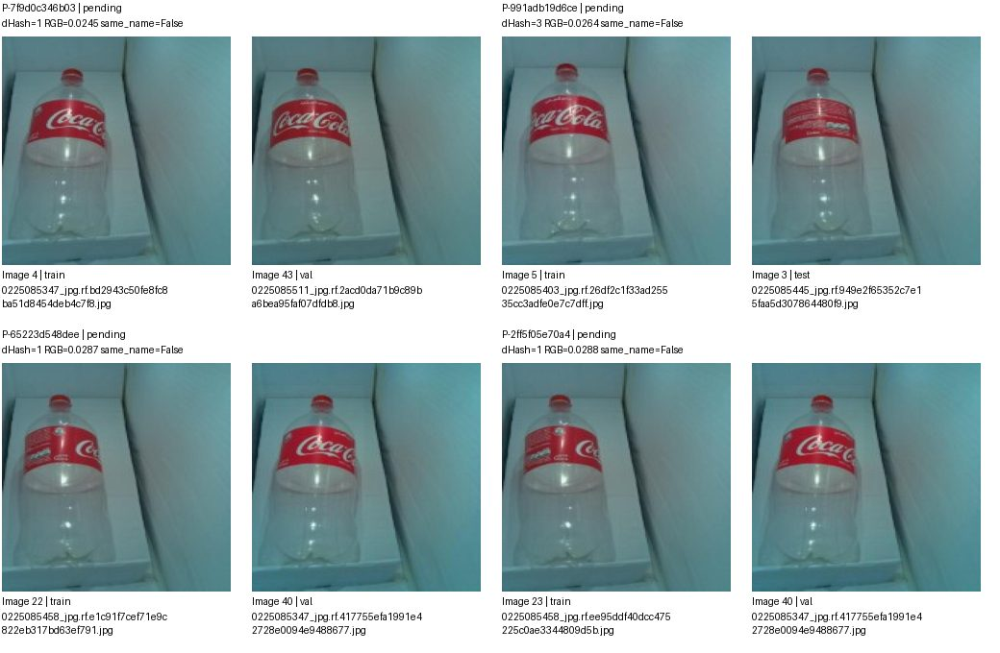

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-7f9d0c346b03,images/train/0225085347_jpg.rf.bd2943c50fe8fc8ba51d8454deb4c7f8.jpg,images/val/0225085511_jpg.rf.2acd0da71b9c89ba6bea95faf07dfdb8.jpg,pending,
P-991adb19d6ce,images/train/0225085403_jpg.rf.26df2c1f33ad25535cc3adfe0e7c7dff.jpg,images/test/0225085445_jpg.rf.949e2f65352c7e15faa5d307864480f9.jpg,pending,
P-65223d548dee,images/train/0225085458_jpg.rf.e1c91f7cef71e9c822eb317bd63ef791.jpg,images/val/0225085347_jpg.rf.417755efa1991e42728e0094e9488677.jpg,pending,
P-2ff5f05e70a4,images/train/0225085458_jpg.rf.ee95ddf40dcc475225c0ae3344809d5b.jpg,images/val/0225085347_jpg.rf.417755efa1991e42728e0094e9488677.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 34/166 G-fd6d72221ef7 | 46 ảnh, 95 cặp
Split: {'test': 3, 'train': 36, 'val': 7}
Quyết định: {'pending': 95}
Ảnh trang None/8; cặp trang 15/24. Nhóm liên thông không phải kết luận trùng.


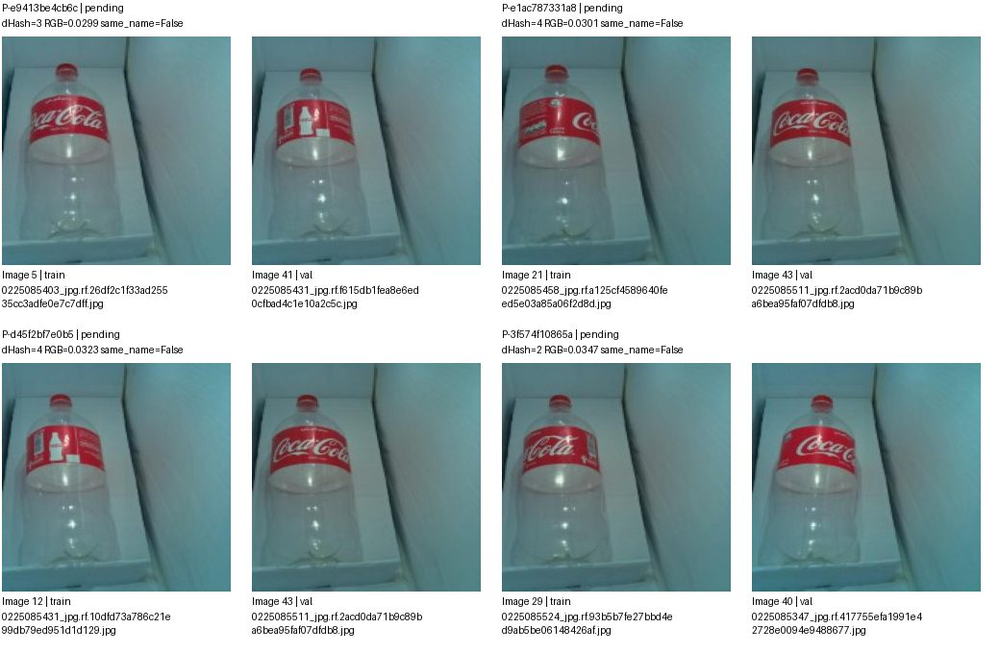

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-e9413be4cb6c,images/train/0225085403_jpg.rf.26df2c1f33ad25535cc3adfe0e7c7dff.jpg,images/val/0225085431_jpg.rf.f615db1fea8e6ed0cfbad4c1e10a2c5c.jpg,pending,
P-e1ac787331a8,images/train/0225085458_jpg.rf.a125cf4589640feed5e03a85a06f2d8d.jpg,images/val/0225085511_jpg.rf.2acd0da71b9c89ba6bea95faf07dfdb8.jpg,pending,
P-d45f2bf7e0b5,images/train/0225085431_jpg.rf.10dfd73a786c21e99db79ed951d1d129.jpg,images/val/0225085511_jpg.rf.2acd0da71b9c89ba6bea95faf07dfdb8.jpg,pending,
P-3f574f10865a,images/train/0225085524_jpg.rf.93b5b7fe27bbd4ed9ab5be06148426af.jpg,images/val/0225085347_jpg.rf.417755efa1991e42728e0094e9488677.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 34/166 G-fd6d72221ef7 | 46 ảnh, 95 cặp
Split: {'test': 3, 'train': 36, 'val': 7}
Quyết định: {'pending': 95}
Ảnh trang None/8; cặp trang 16/24. Nhóm liên thông không phải kết luận trùng.


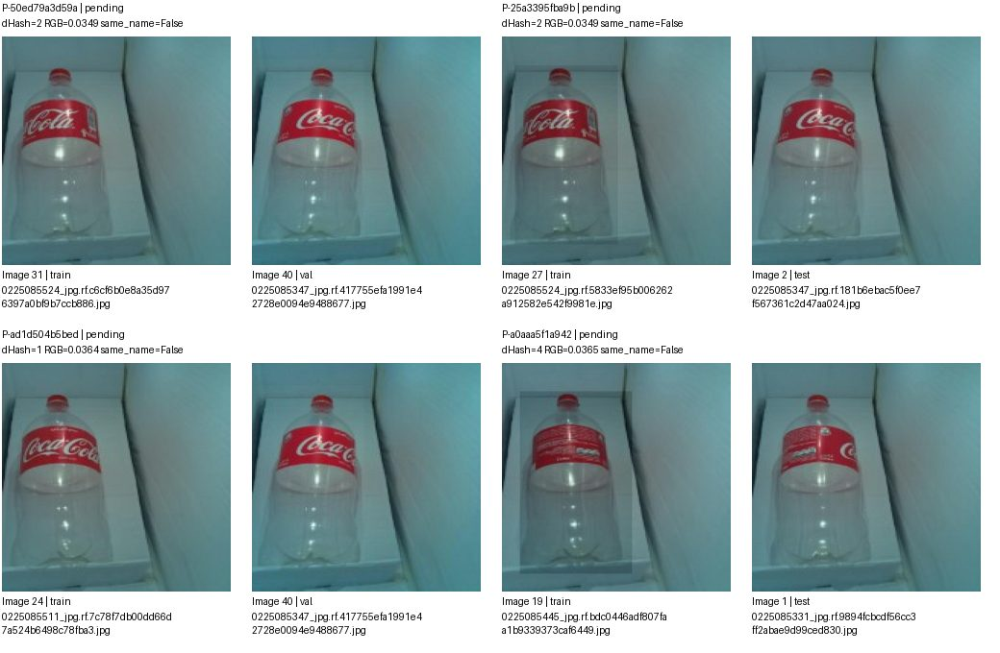

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-50ed79a3d59a,images/train/0225085524_jpg.rf.c6cf6b0e8a35d976397a0bf9b7ccb886.jpg,images/val/0225085347_jpg.rf.417755efa1991e42728e0094e9488677.jpg,pending,
P-25a3395fba9b,images/train/0225085524_jpg.rf.5833ef95b006262a912582e542f9981e.jpg,images/test/0225085347_jpg.rf.181b6ebac5f0ee7f567361c2d47aa024.jpg,pending,
P-ad1d504b5bed,images/train/0225085511_jpg.rf.7c78f7db00dd66d7a524b6498c78fba3.jpg,images/val/0225085347_jpg.rf.417755efa1991e42728e0094e9488677.jpg,pending,
P-a0aaa5f1a942,images/train/0225085445_jpg.rf.bdc0446adf807faa1b9339373caf6449.jpg,images/test/0225085331_jpg.rf.9894fcbcdf56cc3ff2abae9d99ced830.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 34/166 G-fd6d72221ef7 | 46 ảnh, 95 cặp
Split: {'test': 3, 'train': 36, 'val': 7}
Quyết định: {'pending': 95}
Ảnh trang None/8; cặp trang 17/24. Nhóm liên thông không phải kết luận trùng.


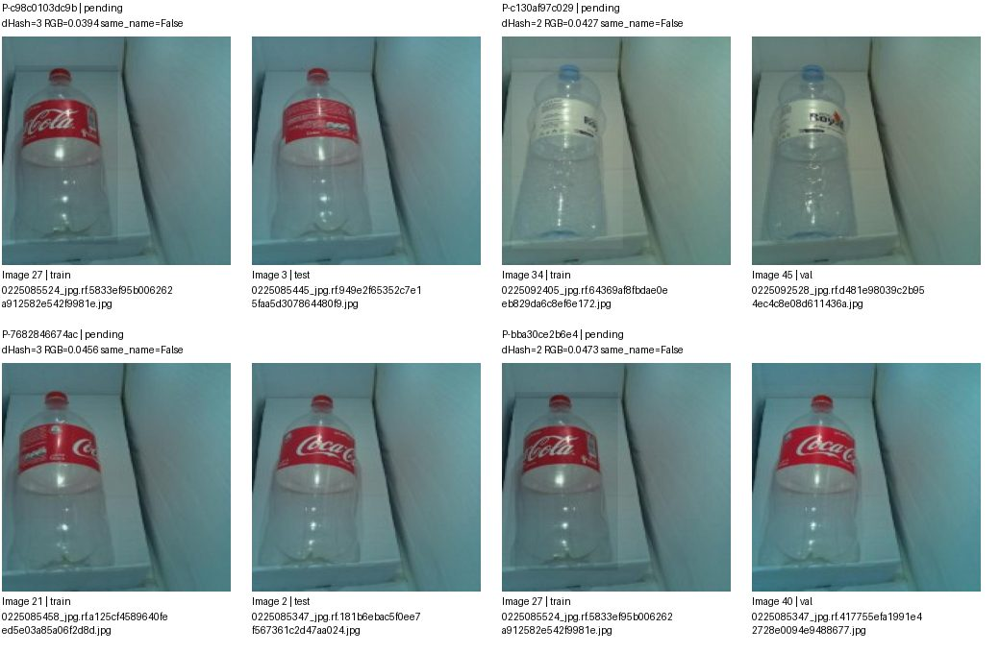

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-c98c0103dc9b,images/train/0225085524_jpg.rf.5833ef95b006262a912582e542f9981e.jpg,images/test/0225085445_jpg.rf.949e2f65352c7e15faa5d307864480f9.jpg,pending,
P-c130af97c029,images/train/0225092405_jpg.rf.64369af8fbdae0eeb829da6c8ef6e172.jpg,images/val/0225092528_jpg.rf.d481e98039c2b954ec4c8e08d611436a.jpg,pending,
P-7682846674ac,images/train/0225085458_jpg.rf.a125cf4589640feed5e03a85a06f2d8d.jpg,images/test/0225085347_jpg.rf.181b6ebac5f0ee7f567361c2d47aa024.jpg,pending,
P-bba30ce2b6e4,images/train/0225085524_jpg.rf.5833ef95b006262a912582e542f9981e.jpg,images/val/0225085347_jpg.rf.417755efa1991e42728e0094e9488677.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 34/166 G-fd6d72221ef7 | 46 ảnh, 95 cặp
Split: {'test': 3, 'train': 36, 'val': 7}
Quyết định: {'pending': 95}
Ảnh trang None/8; cặp trang 18/24. Nhóm liên thông không phải kết luận trùng.


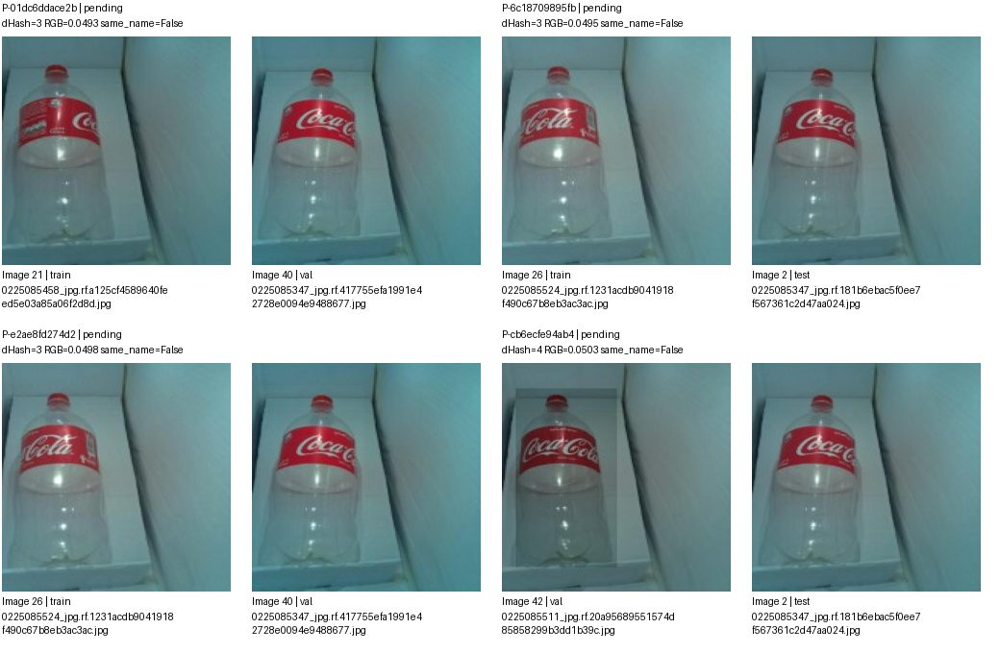

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-01dc6ddace2b,images/train/0225085458_jpg.rf.a125cf4589640feed5e03a85a06f2d8d.jpg,images/val/0225085347_jpg.rf.417755efa1991e42728e0094e9488677.jpg,pending,
P-6c18709895fb,images/train/0225085524_jpg.rf.1231acdb9041918f490c67b8eb3ac3ac.jpg,images/test/0225085347_jpg.rf.181b6ebac5f0ee7f567361c2d47aa024.jpg,pending,
P-e2ae8fd274d2,images/train/0225085524_jpg.rf.1231acdb9041918f490c67b8eb3ac3ac.jpg,images/val/0225085347_jpg.rf.417755efa1991e42728e0094e9488677.jpg,pending,
P-cb6ecfe94ab4,images/val/0225085511_jpg.rf.20a95689551574d85858299b3dd1b39c.jpg,images/test/0225085347_jpg.rf.181b6ebac5f0ee7f567361c2d47aa024.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 34/166 G-fd6d72221ef7 | 46 ảnh, 95 cặp
Split: {'test': 3, 'train': 36, 'val': 7}
Quyết định: {'pending': 95}
Ảnh trang None/8; cặp trang 19/24. Nhóm liên thông không phải kết luận trùng.


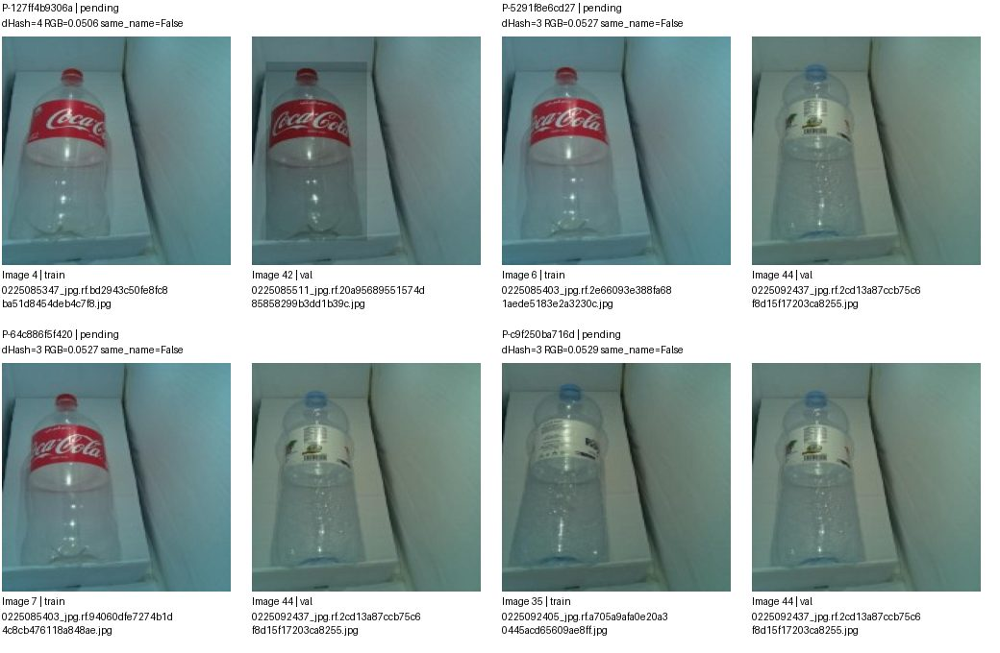

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-127ff4b9306a,images/train/0225085347_jpg.rf.bd2943c50fe8fc8ba51d8454deb4c7f8.jpg,images/val/0225085511_jpg.rf.20a95689551574d85858299b3dd1b39c.jpg,pending,
P-5291f8e6cd27,images/train/0225085403_jpg.rf.2e66093e388fa681aede5183e2a3230c.jpg,images/val/0225092437_jpg.rf.2cd13a87ccb75c6f8d15f17203ca8255.jpg,pending,
P-64c886f5f420,images/train/0225085403_jpg.rf.94060dfe7274b1d4c8cb476118a848ae.jpg,images/val/0225092437_jpg.rf.2cd13a87ccb75c6f8d15f17203ca8255.jpg,pending,
P-c9f250ba716d,images/train/0225092405_jpg.rf.a705a9afa0e20a30445acd65609ae8ff.jpg,images/val/0225092437_jpg.rf.2cd13a87ccb75c6f8d15f17203ca8255.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 34/166 G-fd6d72221ef7 | 46 ảnh, 95 cặp
Split: {'test': 3, 'train': 36, 'val': 7}
Quyết định: {'pending': 95}
Ảnh trang None/8; cặp trang 20/24. Nhóm liên thông không phải kết luận trùng.


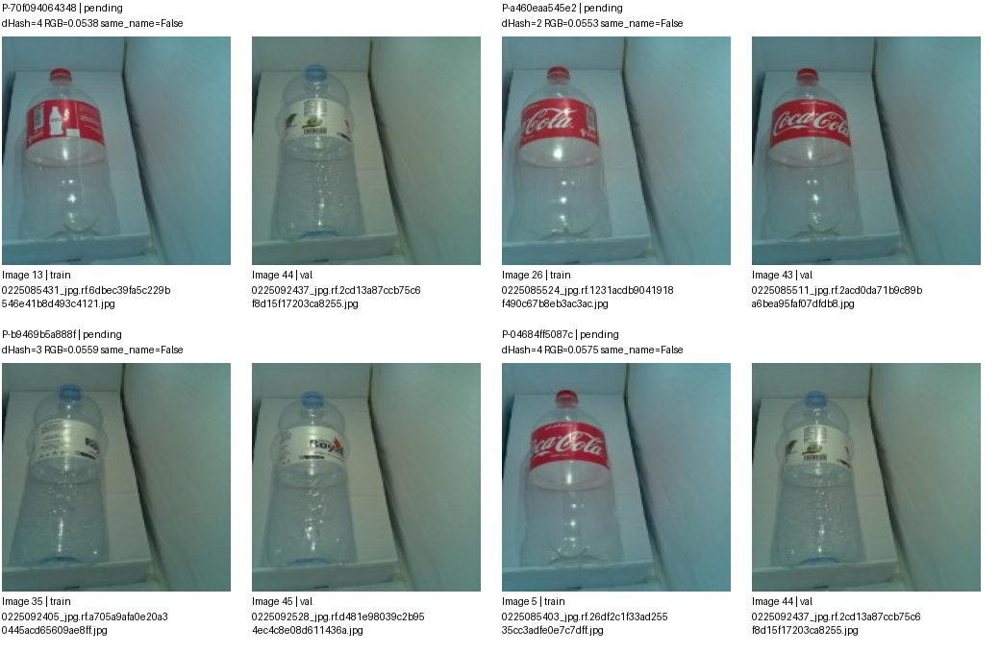

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-70f094064348,images/train/0225085431_jpg.rf.6dbec39fa5c229b546e41b8d493c4121.jpg,images/val/0225092437_jpg.rf.2cd13a87ccb75c6f8d15f17203ca8255.jpg,pending,
P-a460eaa545e2,images/train/0225085524_jpg.rf.1231acdb9041918f490c67b8eb3ac3ac.jpg,images/val/0225085511_jpg.rf.2acd0da71b9c89ba6bea95faf07dfdb8.jpg,pending,
P-b9469b5a888f,images/train/0225092405_jpg.rf.a705a9afa0e20a30445acd65609ae8ff.jpg,images/val/0225092528_jpg.rf.d481e98039c2b954ec4c8e08d611436a.jpg,pending,
P-04684ff5087c,images/train/0225085403_jpg.rf.26df2c1f33ad25535cc3adfe0e7c7dff.jpg,images/val/0225092437_jpg.rf.2cd13a87ccb75c6f8d15f17203ca8255.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 34/166 G-fd6d72221ef7 | 46 ảnh, 95 cặp
Split: {'test': 3, 'train': 36, 'val': 7}
Quyết định: {'pending': 95}
Ảnh trang None/8; cặp trang 21/24. Nhóm liên thông không phải kết luận trùng.


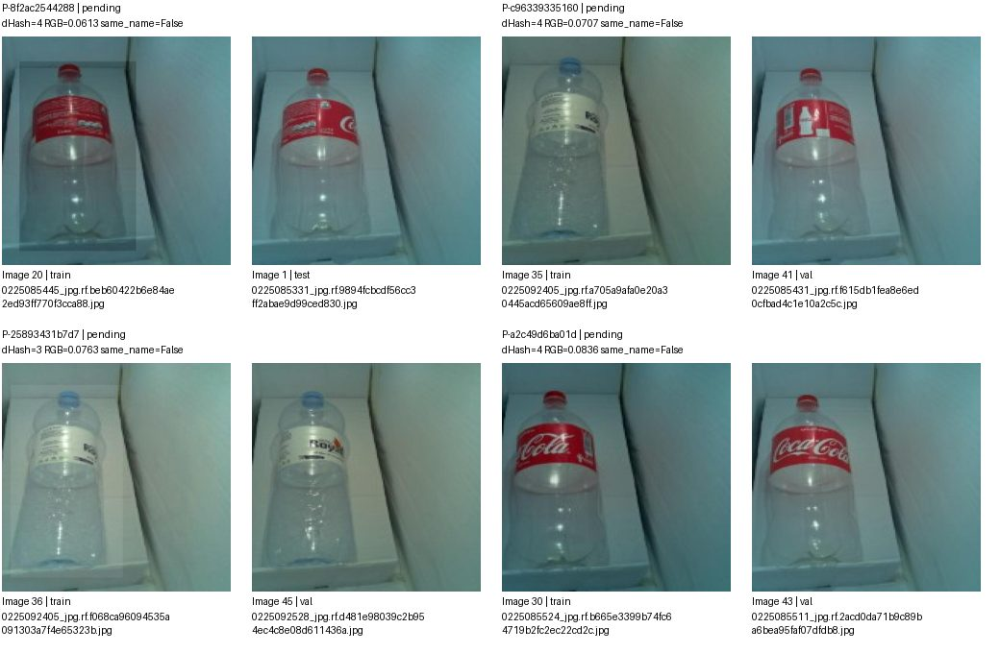

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-8f2ac2544288,images/train/0225085445_jpg.rf.beb60422b6e84ae2ed93ff770f3cca88.jpg,images/test/0225085331_jpg.rf.9894fcbcdf56cc3ff2abae9d99ced830.jpg,pending,
P-c96339335160,images/train/0225092405_jpg.rf.a705a9afa0e20a30445acd65609ae8ff.jpg,images/val/0225085431_jpg.rf.f615db1fea8e6ed0cfbad4c1e10a2c5c.jpg,pending,
P-25893431b7d7,images/train/0225092405_jpg.rf.f068ca96094535a091303a7f4e65323b.jpg,images/val/0225092528_jpg.rf.d481e98039c2b954ec4c8e08d611436a.jpg,pending,
P-a2c49d6ba01d,images/train/0225085524_jpg.rf.b665e3399b74fc64719b2fc2ec22cd2c.jpg,images/val/0225085511_jpg.rf.2acd0da71b9c89ba6bea95faf07dfdb8.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 34/166 G-fd6d72221ef7 | 46 ảnh, 95 cặp
Split: {'test': 3, 'train': 36, 'val': 7}
Quyết định: {'pending': 95}
Ảnh trang None/8; cặp trang 22/24. Nhóm liên thông không phải kết luận trùng.


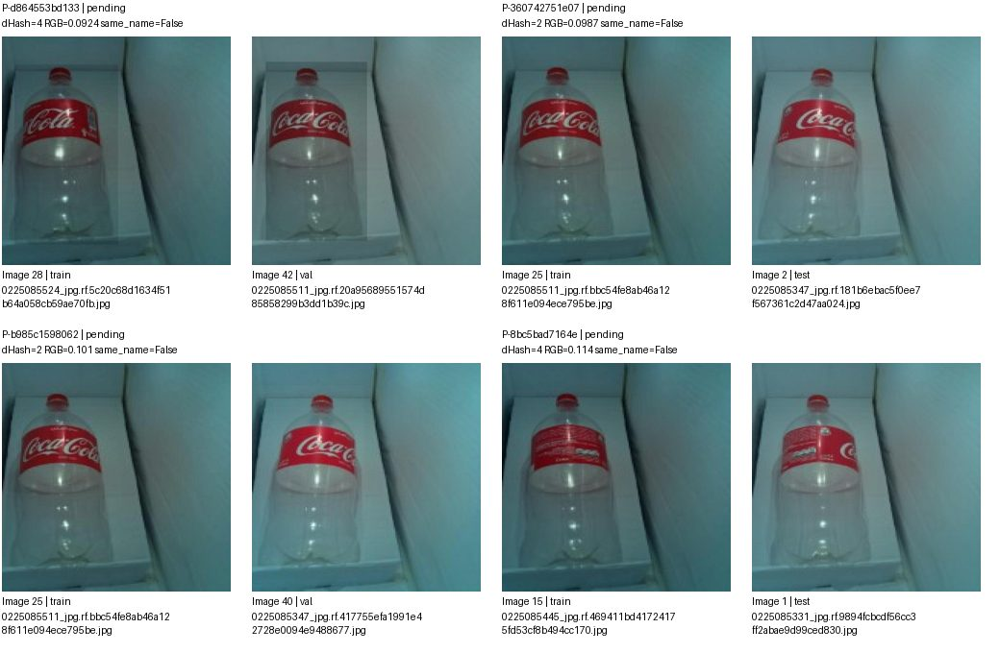

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-d864553bd133,images/train/0225085524_jpg.rf.5c20c68d1634f51b64a058cb59ae70fb.jpg,images/val/0225085511_jpg.rf.20a95689551574d85858299b3dd1b39c.jpg,pending,
P-360742751e07,images/train/0225085511_jpg.rf.bbc54fe8ab46a128f611e094ece795be.jpg,images/test/0225085347_jpg.rf.181b6ebac5f0ee7f567361c2d47aa024.jpg,pending,
P-b985c1598062,images/train/0225085511_jpg.rf.bbc54fe8ab46a128f611e094ece795be.jpg,images/val/0225085347_jpg.rf.417755efa1991e42728e0094e9488677.jpg,pending,
P-8bc5bad7164e,images/train/0225085445_jpg.rf.469411bd41724175fd53cf8b494cc170.jpg,images/test/0225085331_jpg.rf.9894fcbcdf56cc3ff2abae9d99ced830.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 34/166 G-fd6d72221ef7 | 46 ảnh, 95 cặp
Split: {'test': 3, 'train': 36, 'val': 7}
Quyết định: {'pending': 95}
Ảnh trang None/8; cặp trang 23/24. Nhóm liên thông không phải kết luận trùng.


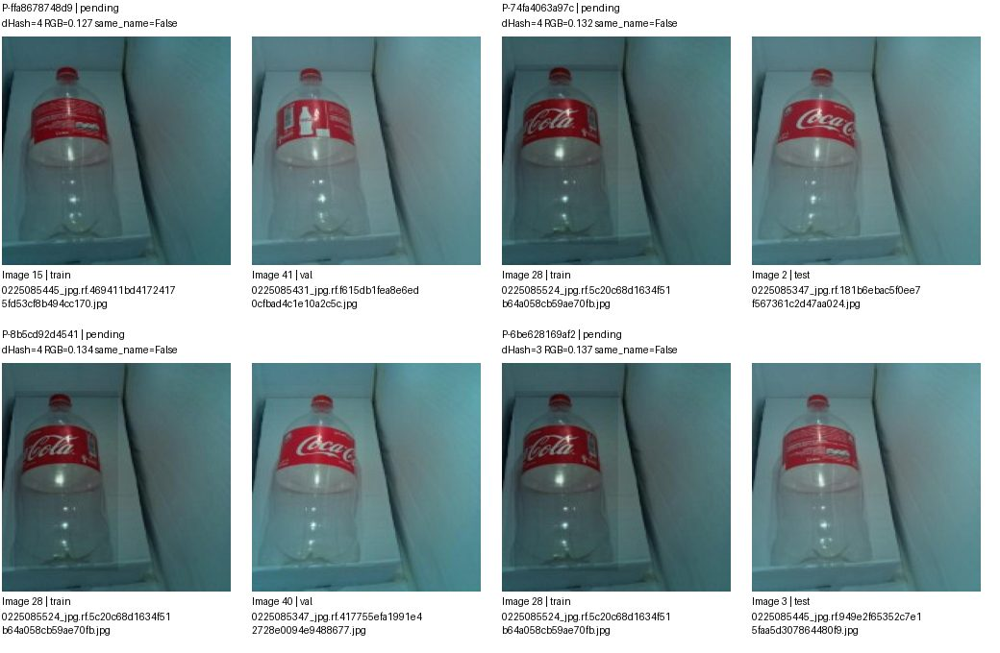

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-ffa8678748d9,images/train/0225085445_jpg.rf.469411bd41724175fd53cf8b494cc170.jpg,images/val/0225085431_jpg.rf.f615db1fea8e6ed0cfbad4c1e10a2c5c.jpg,pending,
P-74fa4063a97c,images/train/0225085524_jpg.rf.5c20c68d1634f51b64a058cb59ae70fb.jpg,images/test/0225085347_jpg.rf.181b6ebac5f0ee7f567361c2d47aa024.jpg,pending,
P-8b5cd92d4541,images/train/0225085524_jpg.rf.5c20c68d1634f51b64a058cb59ae70fb.jpg,images/val/0225085347_jpg.rf.417755efa1991e42728e0094e9488677.jpg,pending,
P-6be628169af2,images/train/0225085524_jpg.rf.5c20c68d1634f51b64a058cb59ae70fb.jpg,images/test/0225085445_jpg.rf.949e2f65352c7e15faa5d307864480f9.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 34/166 G-fd6d72221ef7 | 46 ảnh, 95 cặp
Split: {'test': 3, 'train': 36, 'val': 7}
Quyết định: {'pending': 95}
Ảnh trang None/8; cặp trang 24/24. Nhóm liên thông không phải kết luận trùng.


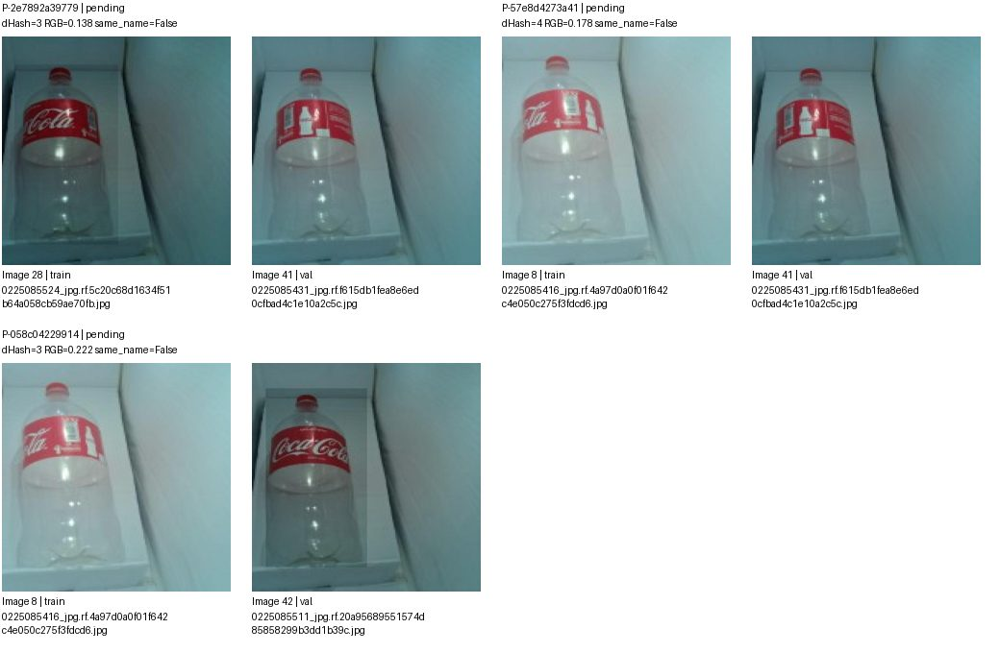

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-2e7892a39779,images/train/0225085524_jpg.rf.5c20c68d1634f51b64a058cb59ae70fb.jpg,images/val/0225085431_jpg.rf.f615db1fea8e6ed0cfbad4c1e10a2c5c.jpg,pending,
P-57e8d4273a41,images/train/0225085416_jpg.rf.4a97d0a0f01f642c4e050c275f3fdcd6.jpg,images/val/0225085431_jpg.rf.f615db1fea8e6ed0cfbad4c1e10a2c5c.jpg,pending,
P-058c04229914,images/train/0225085416_jpg.rf.4a97d0a0f01f642c4e050c275f3fdcd6.jpg,images/val/0225085511_jpg.rf.20a95689551574d85858299b3dd1b39c.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 35/166 G-c0c5c6238696 | 3 ảnh, 2 cặp
Split: {'train': 2, 'val': 1}
Quyết định: {'pending': 2}
Ảnh trang 1/1; cặp trang 1/1. Nhóm liên thông không phải kết luận trùng.


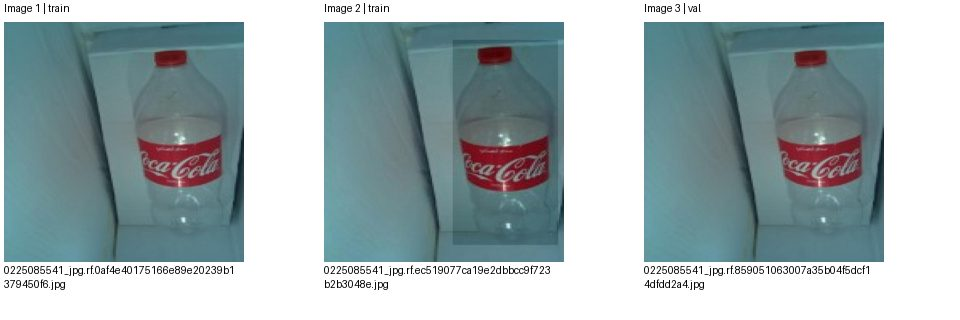

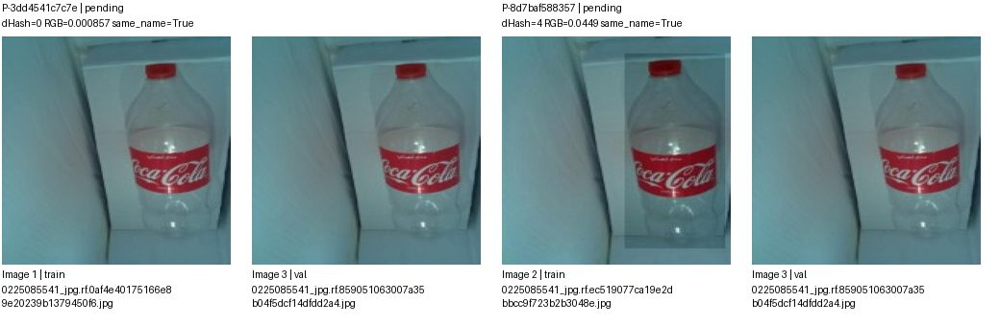

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-3dd4541c7c7e,images/train/0225085541_jpg.rf.0af4e40175166e89e20239b1379450f6.jpg,images/val/0225085541_jpg.rf.859051063007a35b04f5dcf14dfdd2a4.jpg,pending,
P-8d7baf588357,images/train/0225085541_jpg.rf.ec519077ca19e2dbbcc9f723b2b3048e.jpg,images/val/0225085541_jpg.rf.859051063007a35b04f5dcf14dfdd2a4.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 36/166 G-2820220d9bc2 | 2 ảnh, 1 cặp
Split: {'test': 1, 'train': 1}
Quyết định: {'pending': 1}
Ảnh trang 1/1; cặp trang 1/1. Nhóm liên thông không phải kết luận trùng.


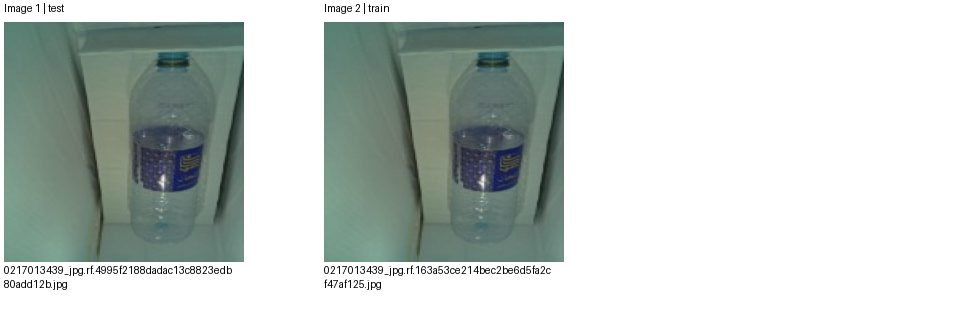

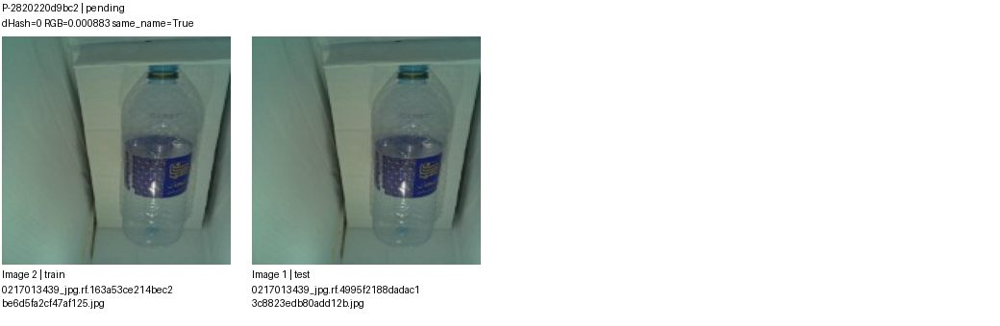

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-2820220d9bc2,images/train/0217013439_jpg.rf.163a53ce214bec2be6d5fa2cf47af125.jpg,images/test/0217013439_jpg.rf.4995f2188dadac13c8823edb80add12b.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 37/166 G-40e517a3af7f | 6 ảnh, 7 cặp
Split: {'train': 4, 'val': 2}
Quyết định: {'pending': 7}
Ảnh trang 1/1; cặp trang 1/2. Nhóm liên thông không phải kết luận trùng.


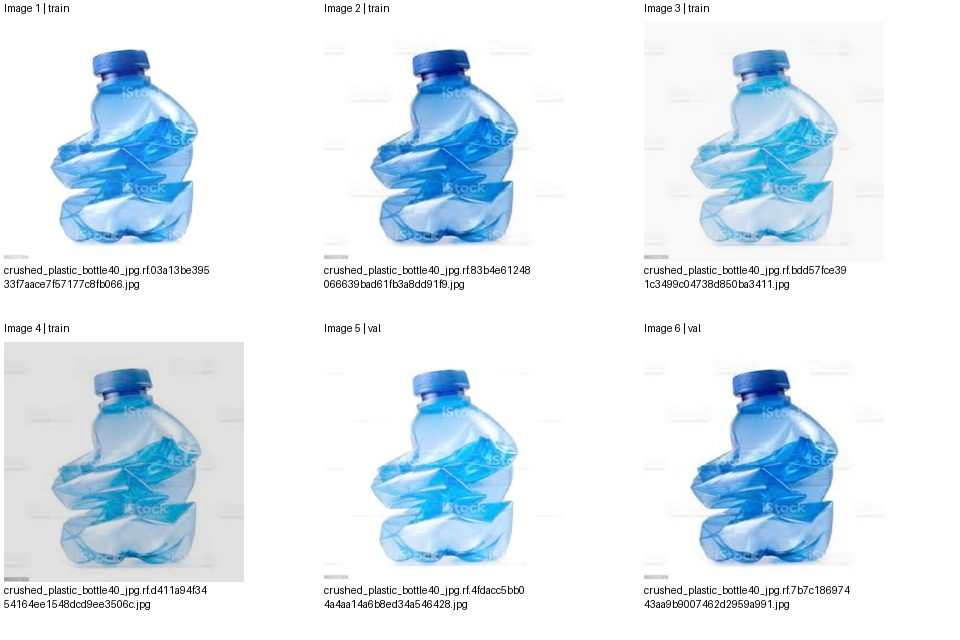

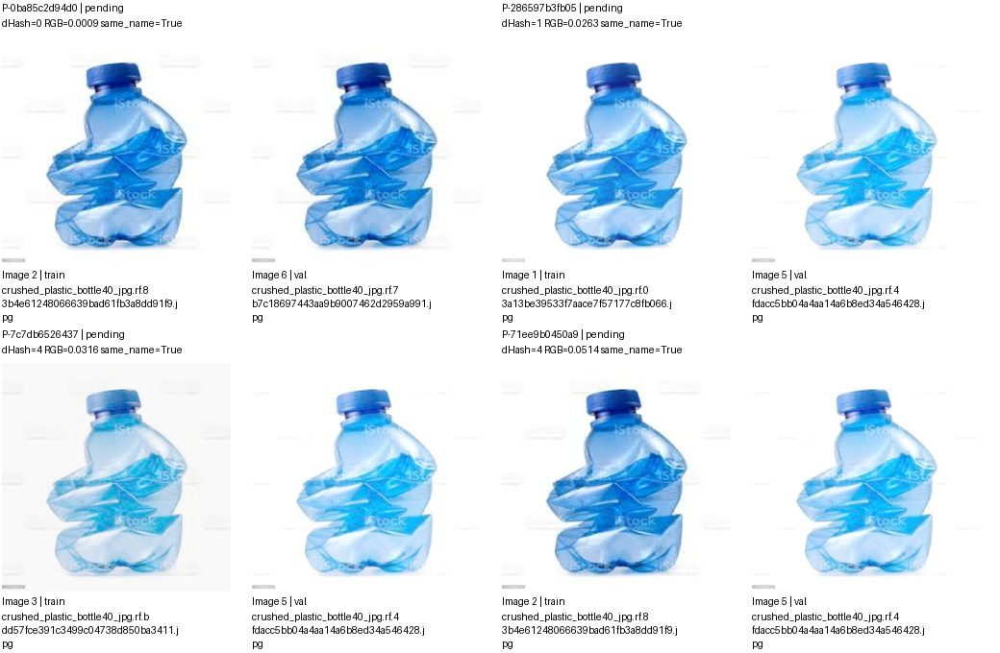

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-0ba85c2d94d0,images/train/crushed_plastic_bottle40_jpg.rf.83b4e61248066639bad61fb3a8dd91f9.jpg,images/val/crushed_plastic_bottle40_jpg.rf.7b7c18697443aa9b9007462d2959a991.jpg,pending,
P-286597b3fb05,images/train/crushed_plastic_bottle40_jpg.rf.03a13be39533f7aace7f57177c8fb066.jpg,images/val/crushed_plastic_bottle40_jpg.rf.4fdacc5bb04a4aa14a6b8ed34a546428.jpg,pending,
P-7c7db6526437,images/train/crushed_plastic_bottle40_jpg.rf.bdd57fce391c3499c04738d850ba3411.jpg,images/val/crushed_plastic_bottle40_jpg.rf.4fdacc5bb04a4aa14a6b8ed34a546428.jpg,pending,
P-71ee9b0450a9,images/train/crushed_plastic_bottle40_jpg.rf.83b4e61248066639bad61fb3a8dd91f9.jpg,images/val/crushed_plastic_bottle40_jpg.rf.4fdacc5bb04a4aa14a6b8ed34a546428.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 37/166 G-40e517a3af7f | 6 ảnh, 7 cặp
Split: {'train': 4, 'val': 2}
Quyết định: {'pending': 7}
Ảnh trang None/1; cặp trang 2/2. Nhóm liên thông không phải kết luận trùng.


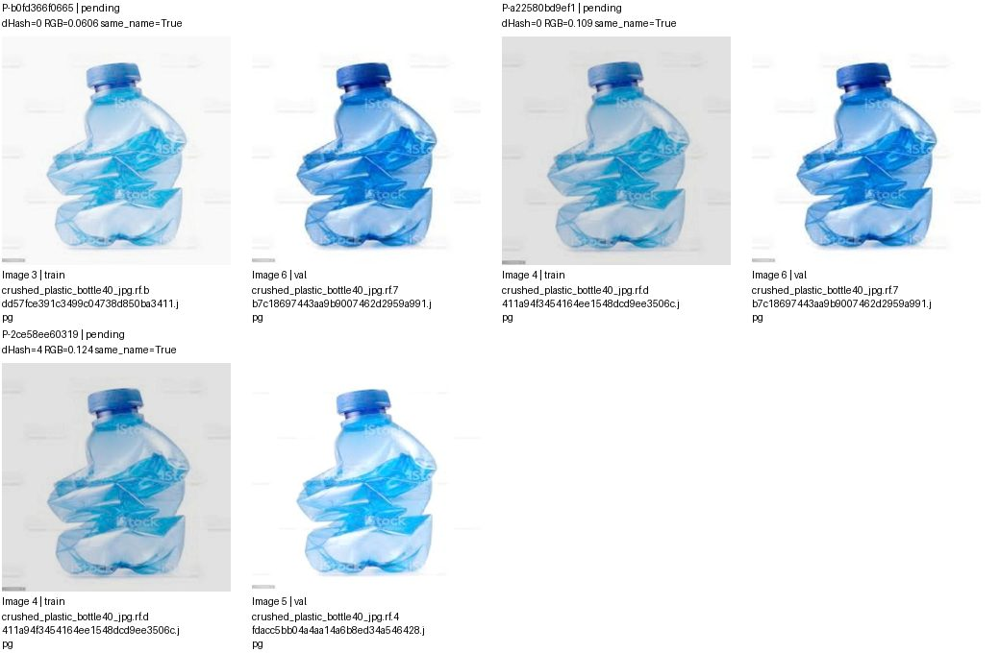

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-b0fd366f0665,images/train/crushed_plastic_bottle40_jpg.rf.bdd57fce391c3499c04738d850ba3411.jpg,images/val/crushed_plastic_bottle40_jpg.rf.7b7c18697443aa9b9007462d2959a991.jpg,pending,
P-a22580bd9ef1,images/train/crushed_plastic_bottle40_jpg.rf.d411a94f3454164ee1548dcd9ee3506c.jpg,images/val/crushed_plastic_bottle40_jpg.rf.7b7c18697443aa9b9007462d2959a991.jpg,pending,
P-2ce58ee60319,images/train/crushed_plastic_bottle40_jpg.rf.d411a94f3454164ee1548dcd9ee3506c.jpg,images/val/crushed_plastic_bottle40_jpg.rf.4fdacc5bb04a4aa14a6b8ed34a546428.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 38/166 G-40ffd92b588b | 4 ảnh, 3 cặp
Split: {'train': 3, 'val': 1}
Quyết định: {'pending': 3}
Ảnh trang 1/1; cặp trang 1/1. Nhóm liên thông không phải kết luận trùng.


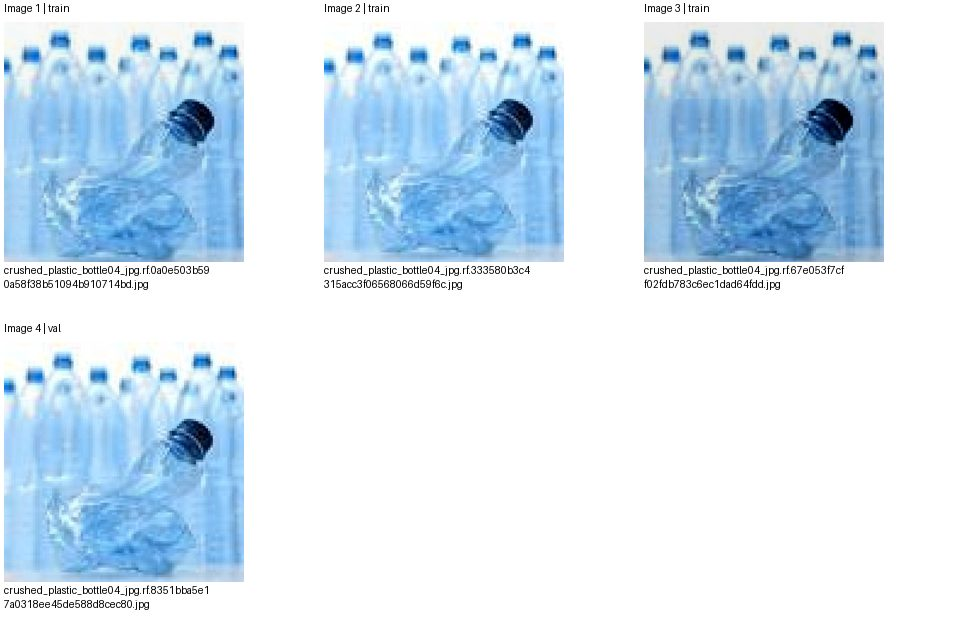

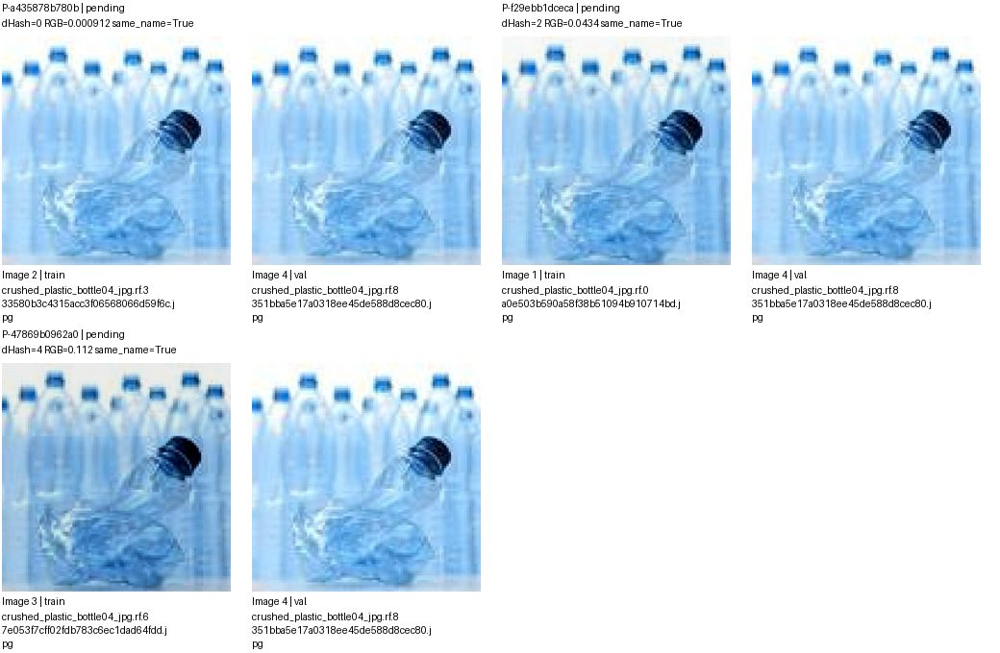

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-a435878b780b,images/train/crushed_plastic_bottle04_jpg.rf.333580b3c4315acc3f06568066d59f6c.jpg,images/val/crushed_plastic_bottle04_jpg.rf.8351bba5e17a0318ee45de588d8cec80.jpg,pending,
P-f29ebb1dceca,images/train/crushed_plastic_bottle04_jpg.rf.0a0e503b590a58f38b51094b910714bd.jpg,images/val/crushed_plastic_bottle04_jpg.rf.8351bba5e17a0318ee45de588d8cec80.jpg,pending,
P-47869b0962a0,images/train/crushed_plastic_bottle04_jpg.rf.67e053f7cff02fdb783c6ec1dad64fdd.jpg,images/val/crushed_plastic_bottle04_jpg.rf.8351bba5e17a0318ee45de588d8cec80.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 39/166 G-cbc7c6bbbc27 | 3 ảnh, 2 cặp
Split: {'train': 2, 'val': 1}
Quyết định: {'pending': 2}
Ảnh trang 1/1; cặp trang 1/1. Nhóm liên thông không phải kết luận trùng.


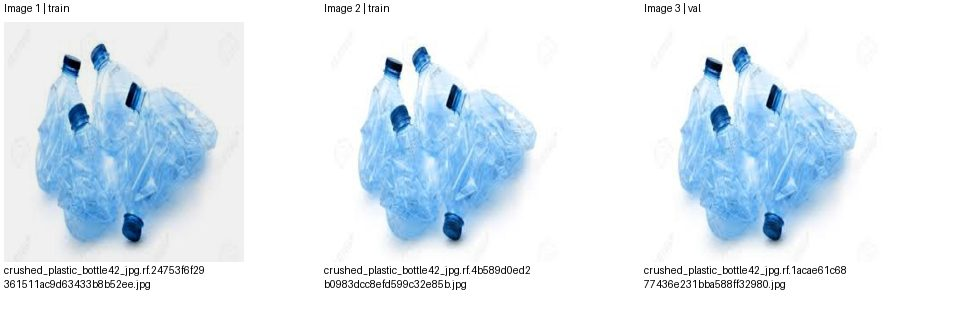

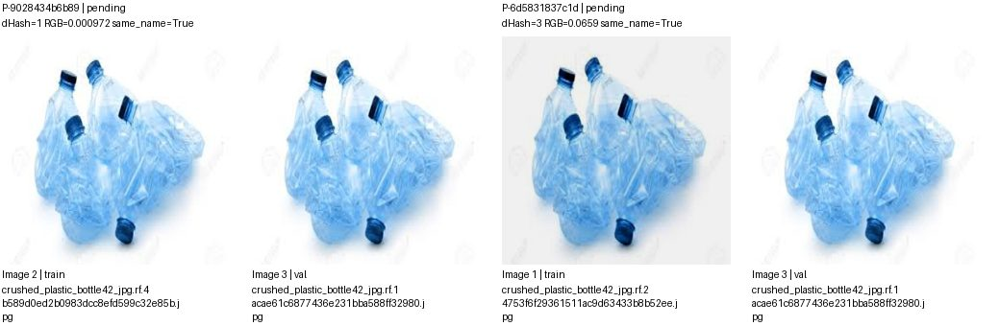

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-9028434b6b89,images/train/crushed_plastic_bottle42_jpg.rf.4b589d0ed2b0983dcc8efd599c32e85b.jpg,images/val/crushed_plastic_bottle42_jpg.rf.1acae61c6877436e231bba588ff32980.jpg,pending,
P-6d5831837c1d,images/train/crushed_plastic_bottle42_jpg.rf.24753f6f29361511ac9d63433b8b52ee.jpg,images/val/crushed_plastic_bottle42_jpg.rf.1acae61c6877436e231bba588ff32980.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 40/166 G-97e8505444ed | 5 ảnh, 8 cặp
Split: {'test': 1, 'train': 2, 'val': 2}
Quyết định: {'pending': 8}
Ảnh trang 1/1; cặp trang 1/2. Nhóm liên thông không phải kết luận trùng.


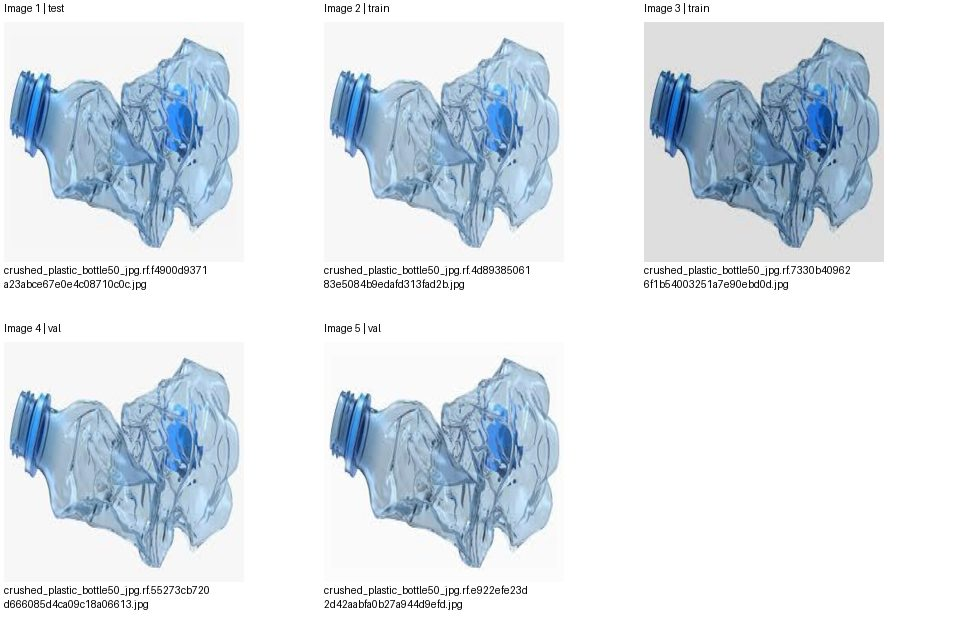

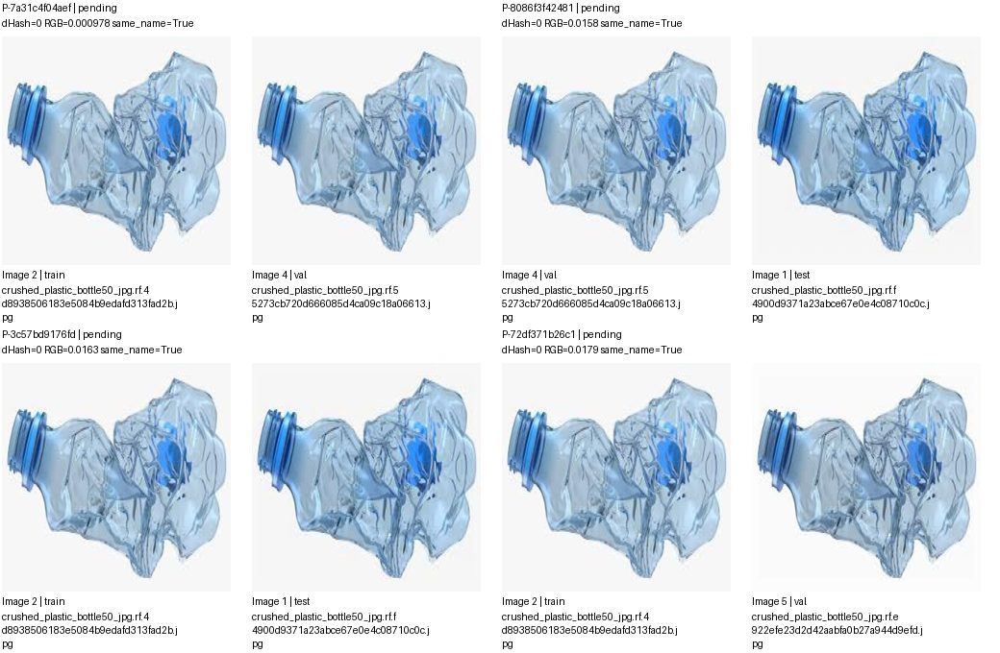

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-7a31c4f04aef,images/train/crushed_plastic_bottle50_jpg.rf.4d8938506183e5084b9edafd313fad2b.jpg,images/val/crushed_plastic_bottle50_jpg.rf.55273cb720d666085d4ca09c18a06613.jpg,pending,
P-8086f3f42481,images/val/crushed_plastic_bottle50_jpg.rf.55273cb720d666085d4ca09c18a06613.jpg,images/test/crushed_plastic_bottle50_jpg.rf.f4900d9371a23abce67e0e4c08710c0c.jpg,pending,
P-3c57bd9176fd,images/train/crushed_plastic_bottle50_jpg.rf.4d8938506183e5084b9edafd313fad2b.jpg,images/test/crushed_plastic_bottle50_jpg.rf.f4900d9371a23abce67e0e4c08710c0c.jpg,pending,
P-72df371b26c1,images/train/crushed_plastic_bottle50_jpg.rf.4d8938506183e5084b9edafd313fad2b.jpg,images/val/crushed_plastic_bottle50_jpg.rf.e922efe23d2d42aabfa0b27a944d9efd.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 40/166 G-97e8505444ed | 5 ảnh, 8 cặp
Split: {'test': 1, 'train': 2, 'val': 2}
Quyết định: {'pending': 8}
Ảnh trang None/1; cặp trang 2/2. Nhóm liên thông không phải kết luận trùng.


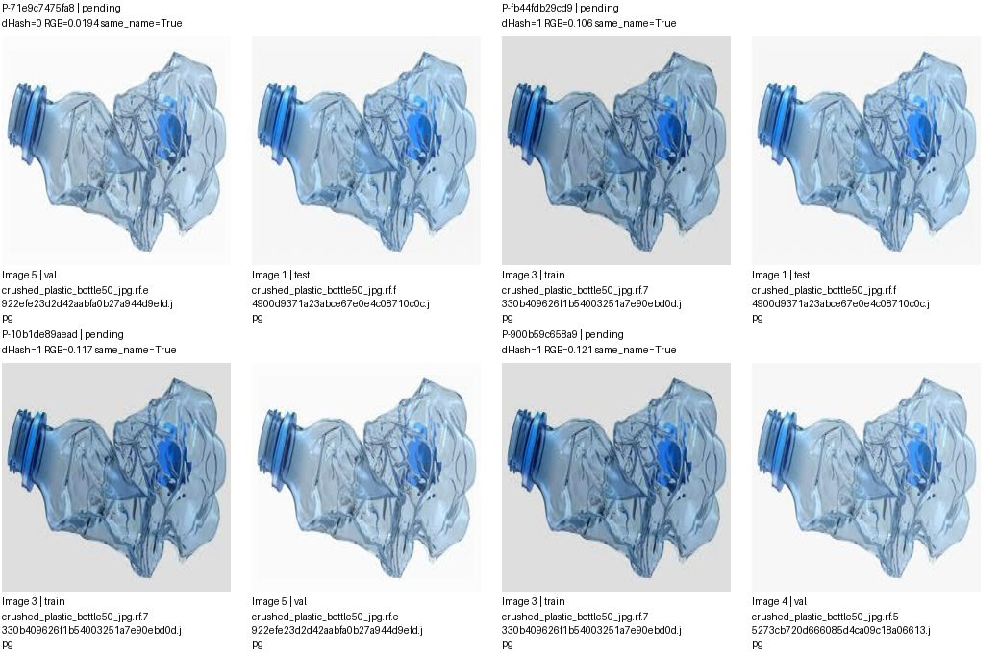

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-71e9c7475fa8,images/val/crushed_plastic_bottle50_jpg.rf.e922efe23d2d42aabfa0b27a944d9efd.jpg,images/test/crushed_plastic_bottle50_jpg.rf.f4900d9371a23abce67e0e4c08710c0c.jpg,pending,
P-fb44fdb29cd9,images/train/crushed_plastic_bottle50_jpg.rf.7330b409626f1b54003251a7e90ebd0d.jpg,images/test/crushed_plastic_bottle50_jpg.rf.f4900d9371a23abce67e0e4c08710c0c.jpg,pending,
P-10b1de89aead,images/train/crushed_plastic_bottle50_jpg.rf.7330b409626f1b54003251a7e90ebd0d.jpg,images/val/crushed_plastic_bottle50_jpg.rf.e922efe23d2d42aabfa0b27a944d9efd.jpg,pending,
P-900b59c658a9,images/train/crushed_plastic_bottle50_jpg.rf.7330b409626f1b54003251a7e90ebd0d.jpg,images/val/crushed_plastic_bottle50_jpg.rf.55273cb720d666085d4ca09c18a06613.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 41/166 G-ee383ad588c4 | 4 ảnh, 4 cặp
Split: {'train': 2, 'val': 2}
Quyết định: {'pending': 4}
Ảnh trang 1/1; cặp trang 1/1. Nhóm liên thông không phải kết luận trùng.


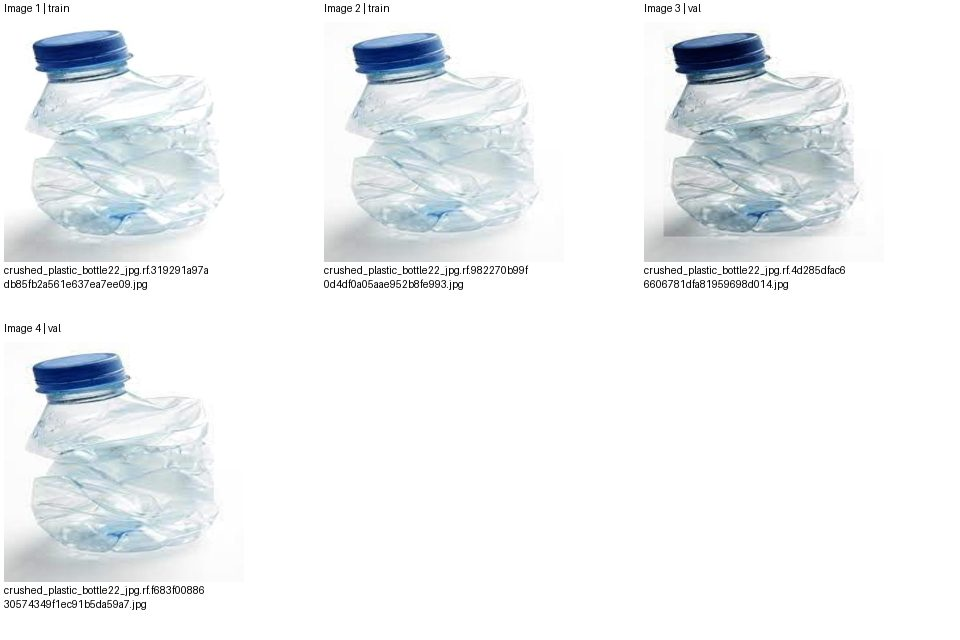

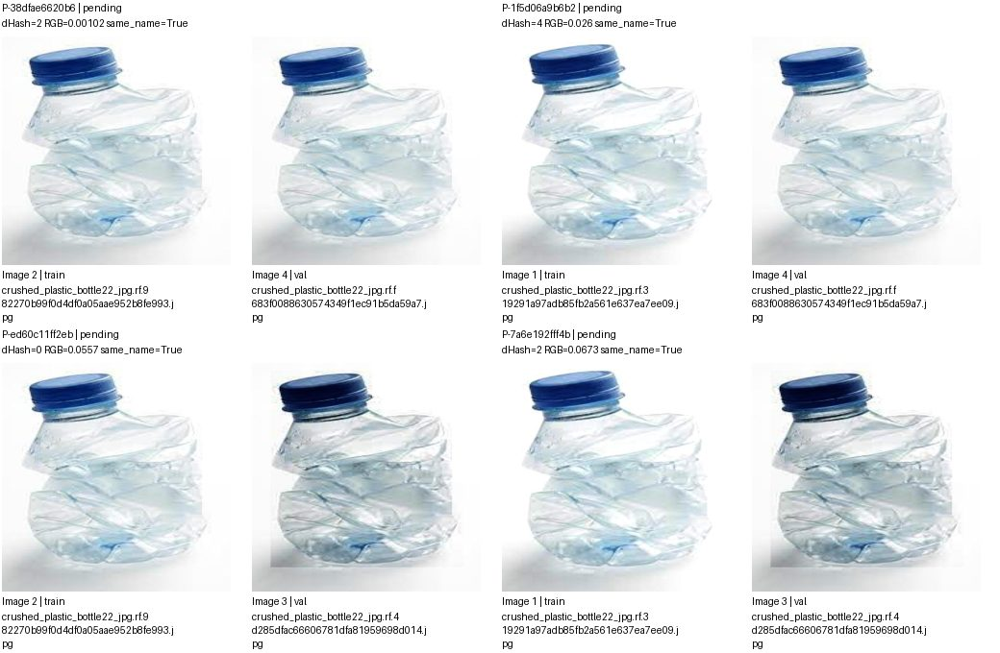

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-38dfae6620b6,images/train/crushed_plastic_bottle22_jpg.rf.982270b99f0d4df0a05aae952b8fe993.jpg,images/val/crushed_plastic_bottle22_jpg.rf.f683f0088630574349f1ec91b5da59a7.jpg,pending,
P-1f5d06a9b6b2,images/train/crushed_plastic_bottle22_jpg.rf.319291a97adb85fb2a561e637ea7ee09.jpg,images/val/crushed_plastic_bottle22_jpg.rf.f683f0088630574349f1ec91b5da59a7.jpg,pending,
P-ed60c11ff2eb,images/train/crushed_plastic_bottle22_jpg.rf.982270b99f0d4df0a05aae952b8fe993.jpg,images/val/crushed_plastic_bottle22_jpg.rf.4d285dfac66606781dfa81959698d014.jpg,pending,
P-7a6e192fff4b,images/train/crushed_plastic_bottle22_jpg.rf.319291a97adb85fb2a561e637ea7ee09.jpg,images/val/crushed_plastic_bottle22_jpg.rf.4d285dfac66606781dfa81959698d014.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 42/166 G-ec3cb055e19c | 4 ảnh, 3 cặp
Split: {'train': 3, 'val': 1}
Quyết định: {'pending': 3}
Ảnh trang 1/1; cặp trang 1/1. Nhóm liên thông không phải kết luận trùng.


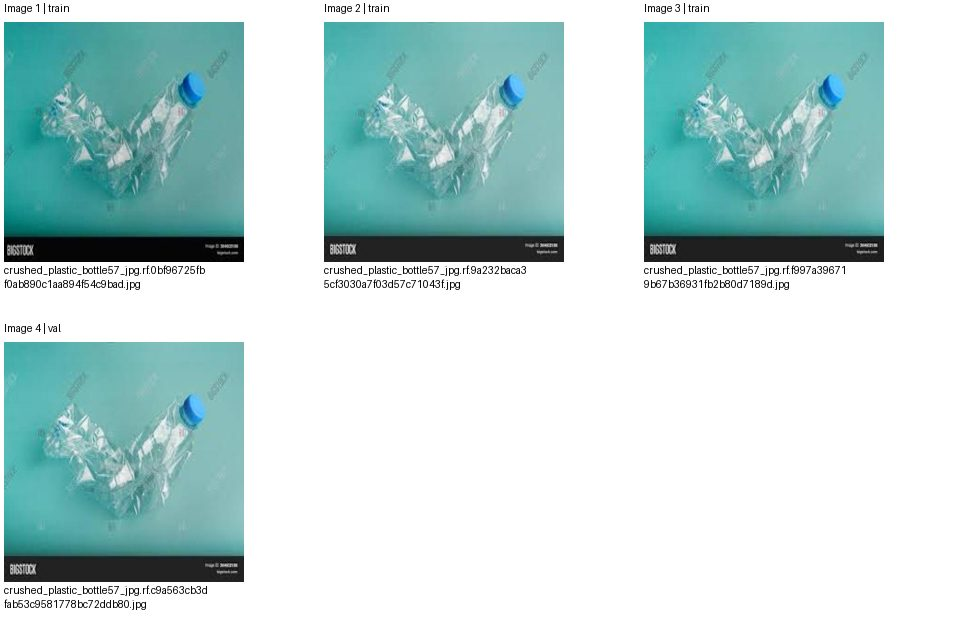

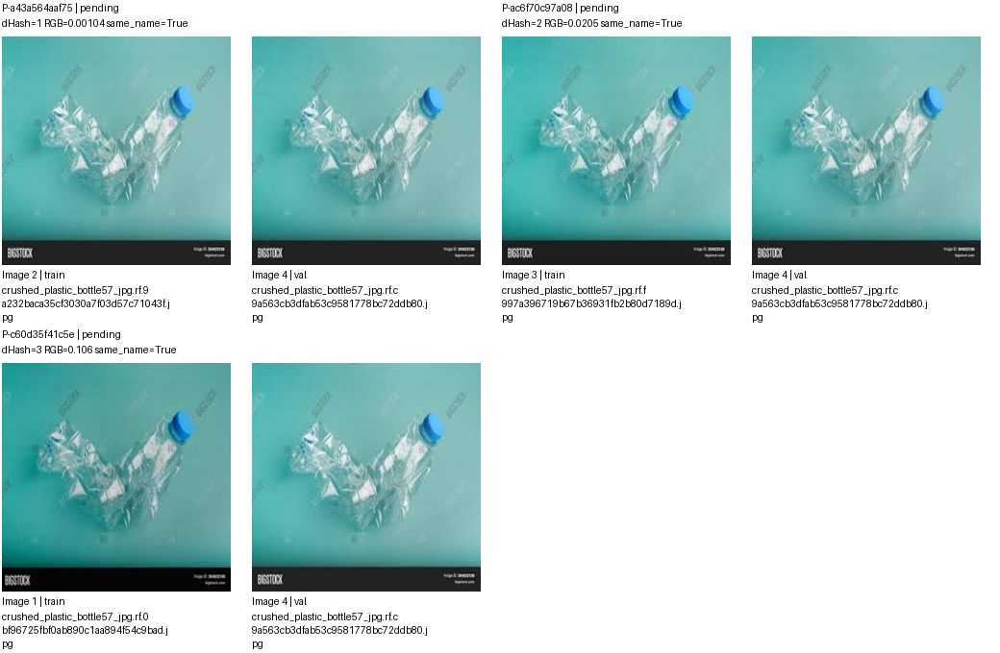

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-a43a564aaf75,images/train/crushed_plastic_bottle57_jpg.rf.9a232baca35cf3030a7f03d57c71043f.jpg,images/val/crushed_plastic_bottle57_jpg.rf.c9a563cb3dfab53c9581778bc72ddb80.jpg,pending,
P-ac6f70c97a08,images/train/crushed_plastic_bottle57_jpg.rf.f997a396719b67b36931fb2b80d7189d.jpg,images/val/crushed_plastic_bottle57_jpg.rf.c9a563cb3dfab53c9581778bc72ddb80.jpg,pending,
P-c60d35f41c5e,images/train/crushed_plastic_bottle57_jpg.rf.0bf96725fbf0ab890c1aa894f54c9bad.jpg,images/val/crushed_plastic_bottle57_jpg.rf.c9a563cb3dfab53c9581778bc72ddb80.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 43/166 G-545be6c81977 | 5 ảnh, 4 cặp
Split: {'test': 1, 'train': 4}
Quyết định: {'pending': 4}
Ảnh trang 1/1; cặp trang 1/1. Nhóm liên thông không phải kết luận trùng.


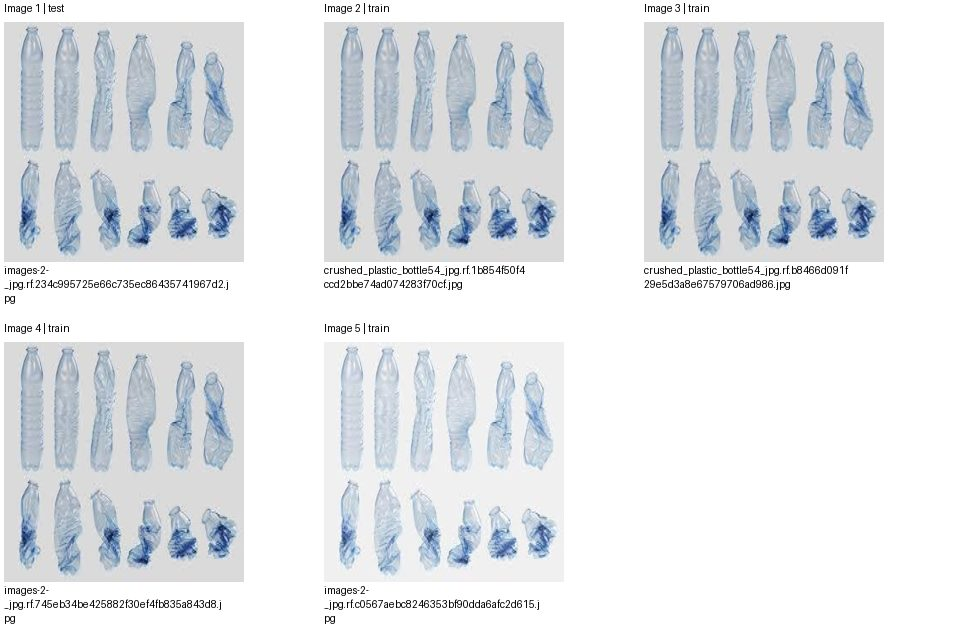

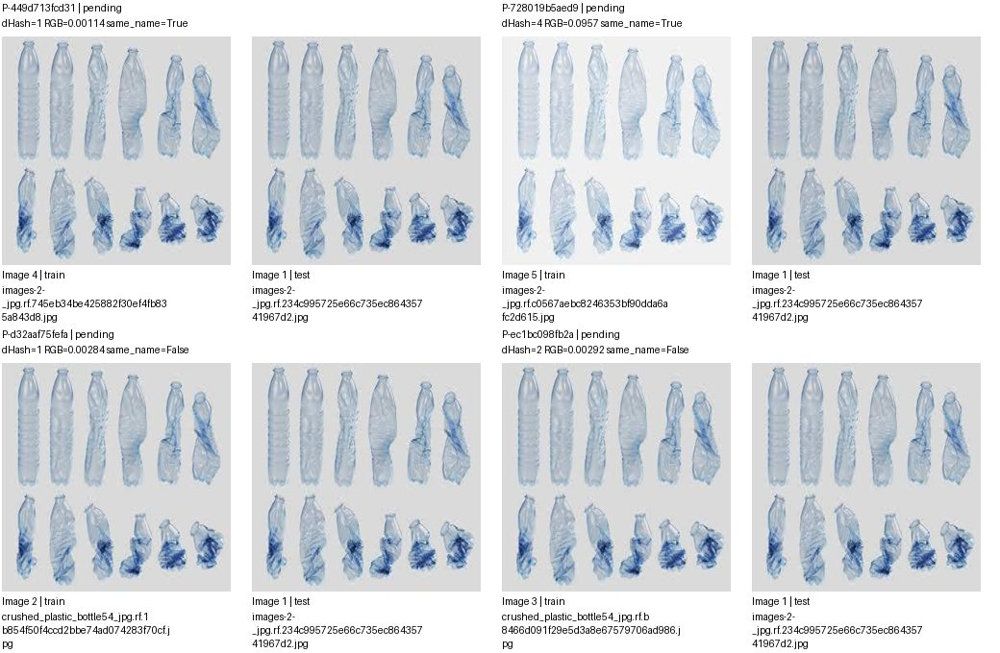

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-449d713fcd31,images/train/images-2-_jpg.rf.745eb34be425882f30ef4fb835a843d8.jpg,images/test/images-2-_jpg.rf.234c995725e66c735ec86435741967d2.jpg,pending,
P-728019b5aed9,images/train/images-2-_jpg.rf.c0567aebc8246353bf90dda6afc2d615.jpg,images/test/images-2-_jpg.rf.234c995725e66c735ec86435741967d2.jpg,pending,
P-d32aaf75fefa,images/train/crushed_plastic_bottle54_jpg.rf.1b854f50f4ccd2bbe74ad074283f70cf.jpg,images/test/images-2-_jpg.rf.234c995725e66c735ec86435741967d2.jpg,pending,
P-ec1bc098fb2a,images/train/crushed_plastic_bottle54_jpg.rf.b8466d091f29e5d3a8e67579706ad986.jpg,images/test/images-2-_jpg.rf.234c995725e66c735ec86435741967d2.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 44/166 G-f97841d91596 | 2 ảnh, 1 cặp
Split: {'train': 1, 'val': 1}
Quyết định: {'pending': 1}
Ảnh trang 1/1; cặp trang 1/1. Nhóm liên thông không phải kết luận trùng.


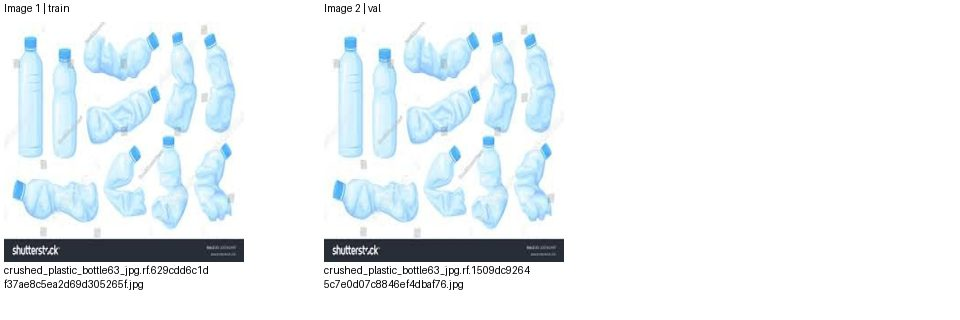

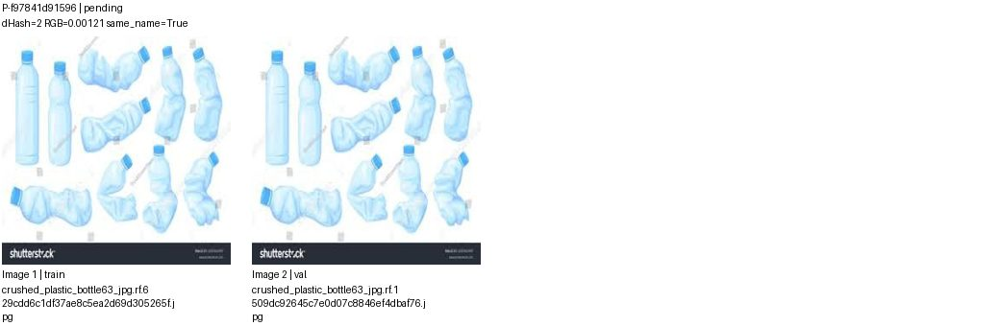

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-f97841d91596,images/train/crushed_plastic_bottle63_jpg.rf.629cdd6c1df37ae8c5ea2d69d305265f.jpg,images/val/crushed_plastic_bottle63_jpg.rf.1509dc92645c7e0d07c8846ef4dbaf76.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 45/166 G-fca749a5c2f7 | 4 ảnh, 3 cặp
Split: {'train': 3, 'val': 1}
Quyết định: {'pending': 3}
Ảnh trang 1/1; cặp trang 1/1. Nhóm liên thông không phải kết luận trùng.


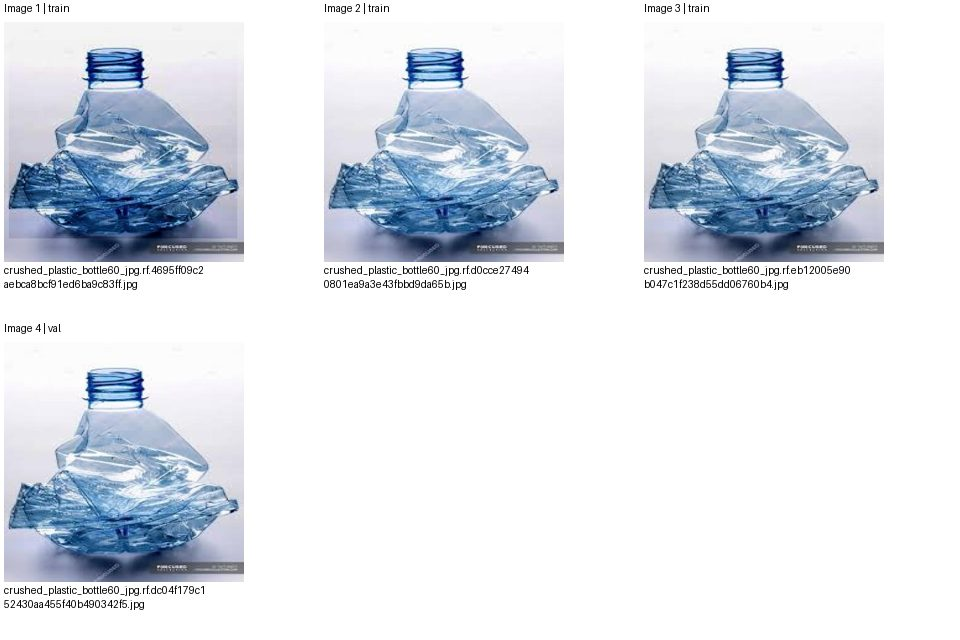

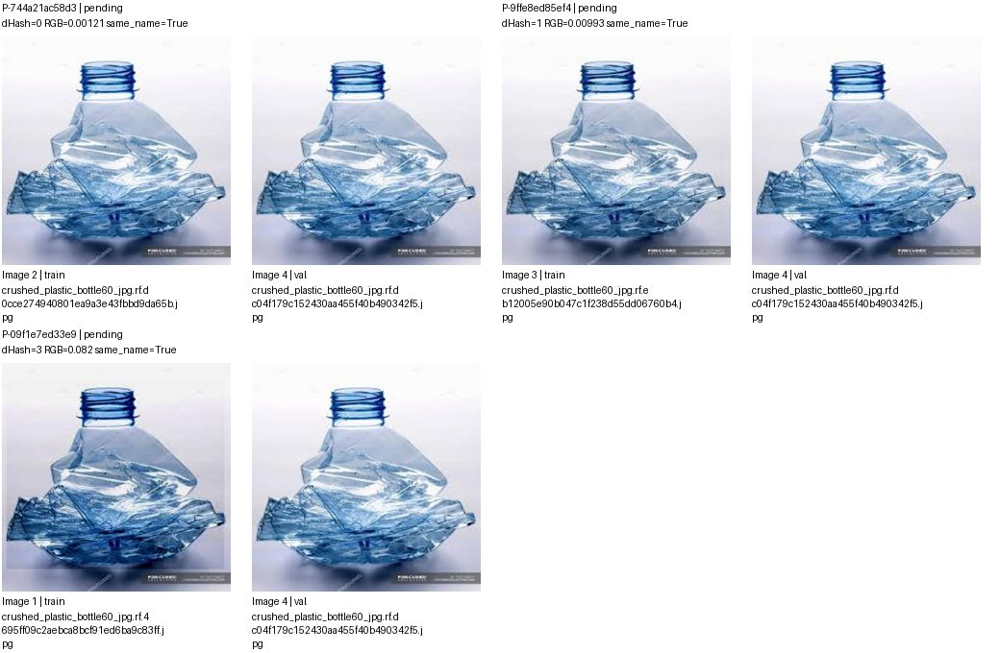

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-744a21ac58d3,images/train/crushed_plastic_bottle60_jpg.rf.d0cce274940801ea9a3e43fbbd9da65b.jpg,images/val/crushed_plastic_bottle60_jpg.rf.dc04f179c152430aa455f40b490342f5.jpg,pending,
P-9ffe8ed85ef4,images/train/crushed_plastic_bottle60_jpg.rf.eb12005e90b047c1f238d55dd06760b4.jpg,images/val/crushed_plastic_bottle60_jpg.rf.dc04f179c152430aa455f40b490342f5.jpg,pending,
P-09f1e7ed33e9,images/train/crushed_plastic_bottle60_jpg.rf.4695ff09c2aebca8bcf91ed6ba9c83ff.jpg,images/val/crushed_plastic_bottle60_jpg.rf.dc04f179c152430aa455f40b490342f5.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 46/166 G-e6b91e72ea76 | 2 ảnh, 1 cặp
Split: {'test': 1, 'train': 1}
Quyết định: {'pending': 1}
Ảnh trang 1/1; cặp trang 1/1. Nhóm liên thông không phải kết luận trùng.


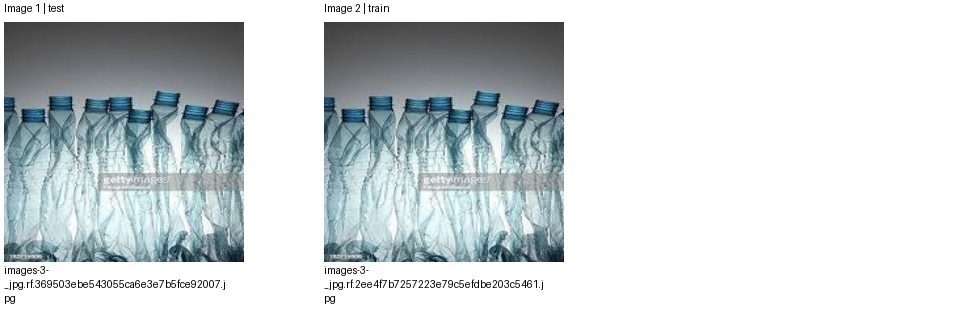

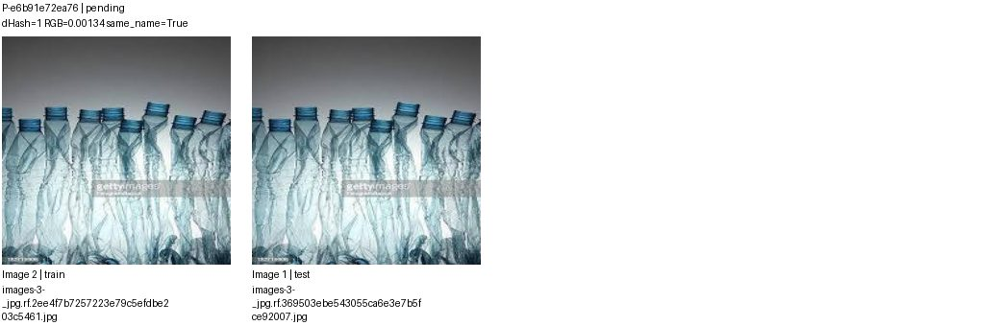

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-e6b91e72ea76,images/train/images-3-_jpg.rf.2ee4f7b7257223e79c5efdbe203c5461.jpg,images/test/images-3-_jpg.rf.369503ebe543055ca6e3e7b5fce92007.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 47/166 G-ba624b4baf36 | 4 ảnh, 3 cặp
Split: {'train': 3, 'val': 1}
Quyết định: {'pending': 3}
Ảnh trang 1/1; cặp trang 1/1. Nhóm liên thông không phải kết luận trùng.


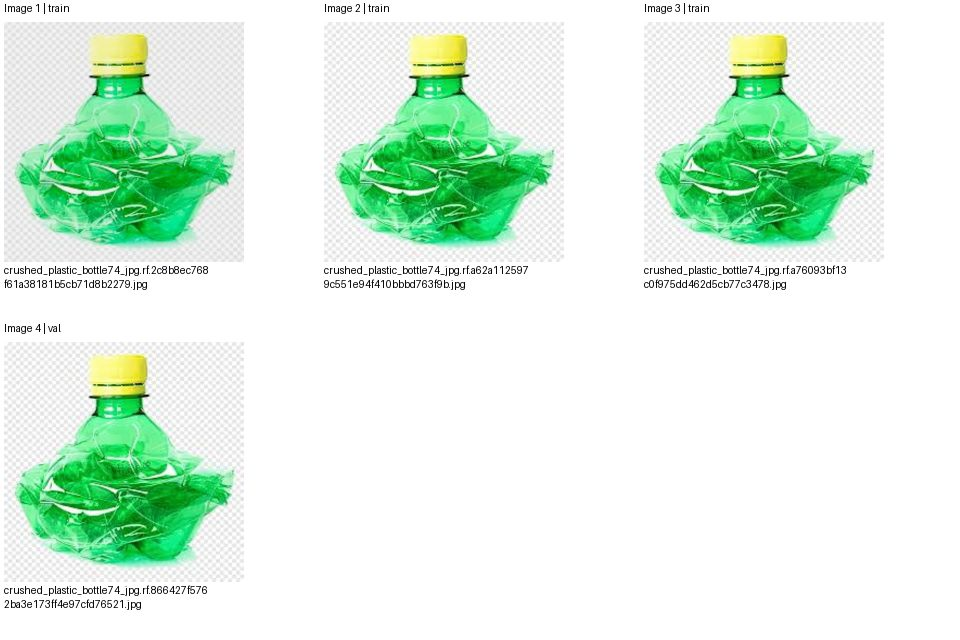

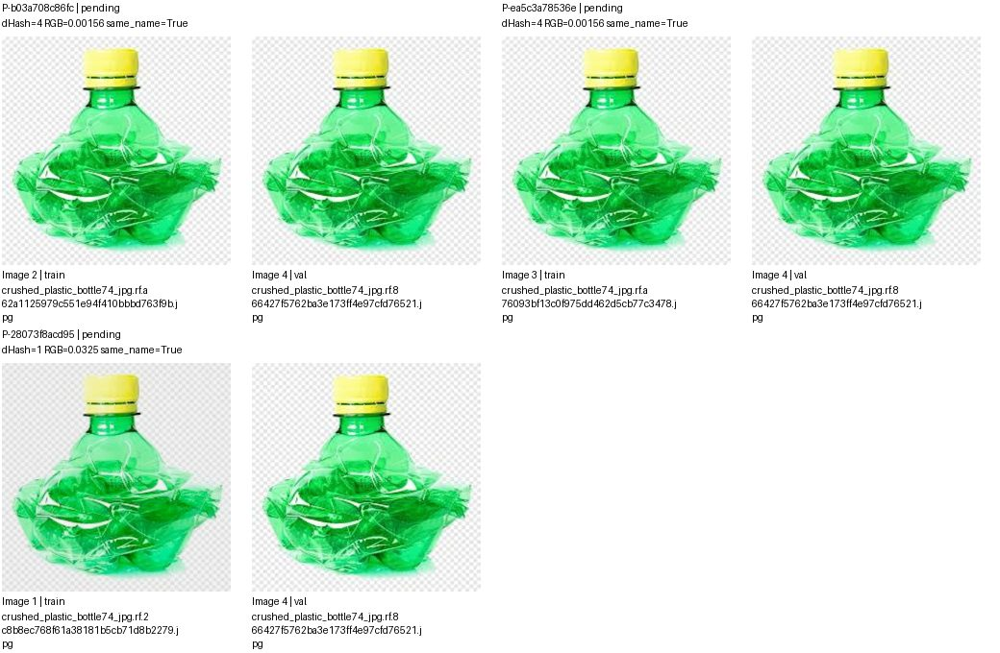

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-b03a708c86fc,images/train/crushed_plastic_bottle74_jpg.rf.a62a1125979c551e94f410bbbd763f9b.jpg,images/val/crushed_plastic_bottle74_jpg.rf.866427f5762ba3e173ff4e97cfd76521.jpg,pending,
P-ea5c3a78536e,images/train/crushed_plastic_bottle74_jpg.rf.a76093bf13c0f975dd462d5cb77c3478.jpg,images/val/crushed_plastic_bottle74_jpg.rf.866427f5762ba3e173ff4e97cfd76521.jpg,pending,
P-28073f8acd95,images/train/crushed_plastic_bottle74_jpg.rf.2c8b8ec768f61a38181b5cb71d8b2279.jpg,images/val/crushed_plastic_bottle74_jpg.rf.866427f5762ba3e173ff4e97cfd76521.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 48/166 G-2818f60dde32 | 5 ảnh, 4 cặp
Split: {'train': 4, 'val': 1}
Quyết định: {'pending': 4}
Ảnh trang 1/1; cặp trang 1/1. Nhóm liên thông không phải kết luận trùng.


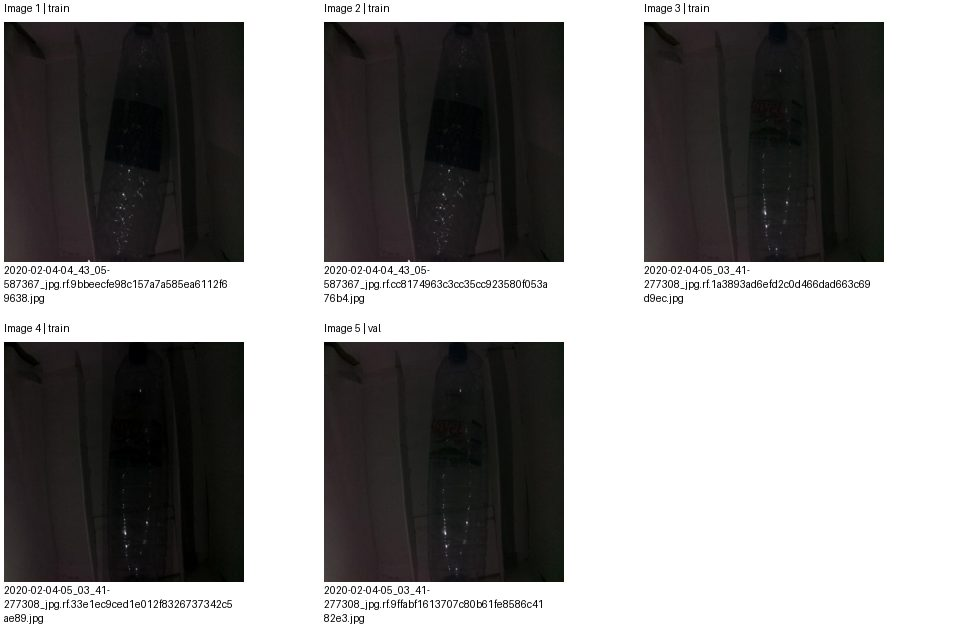

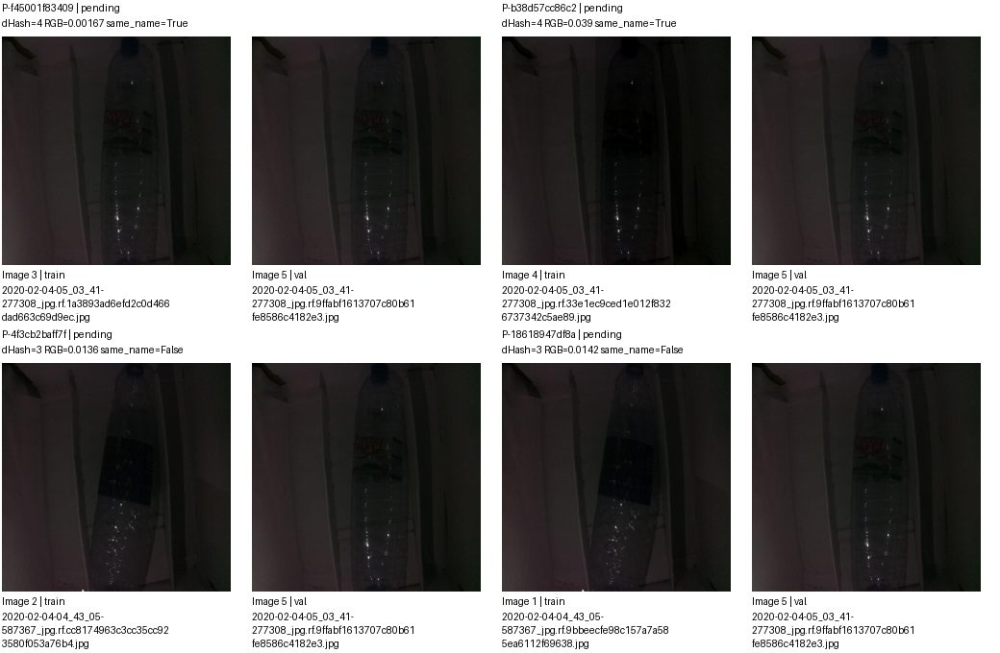

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-f45001f83409,images/train/2020-02-04-05_03_41-277308_jpg.rf.1a3893ad6efd2c0d466dad663c69d9ec.jpg,images/val/2020-02-04-05_03_41-277308_jpg.rf.9ffabf1613707c80b61fe8586c4182e3.jpg,pending,
P-b38d57cc86c2,images/train/2020-02-04-05_03_41-277308_jpg.rf.33e1ec9ced1e012f8326737342c5ae89.jpg,images/val/2020-02-04-05_03_41-277308_jpg.rf.9ffabf1613707c80b61fe8586c4182e3.jpg,pending,
P-4f3cb2baff7f,images/train/2020-02-04-04_43_05-587367_jpg.rf.cc8174963c3cc35cc923580f053a76b4.jpg,images/val/2020-02-04-05_03_41-277308_jpg.rf.9ffabf1613707c80b61fe8586c4182e3.jpg,pending,
P-18618947df8a,images/train/2020-02-04-04_43_05-587367_jpg.rf.9bbeecfe98c157a7a585ea6112f69638.jpg,images/val/2020-02-04-05_03_41-277308_jpg.rf.9ffabf1613707c80b61fe8586c4182e3.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 49/166 G-a2c1d2e83a0f | 3 ảnh, 2 cặp
Split: {'train': 2, 'val': 1}
Quyết định: {'pending': 2}
Ảnh trang 1/1; cặp trang 1/1. Nhóm liên thông không phải kết luận trùng.


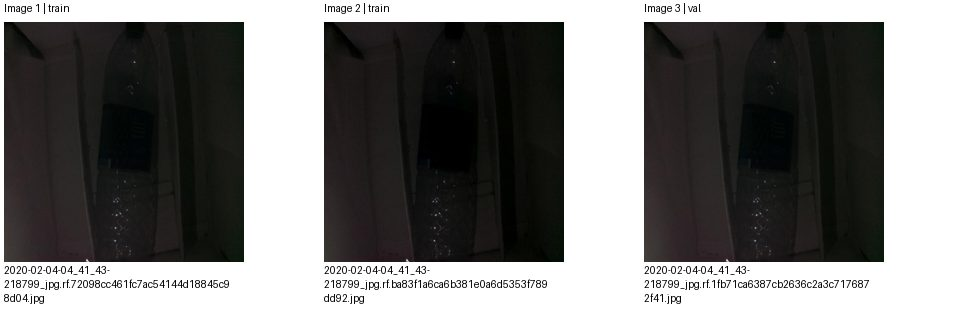

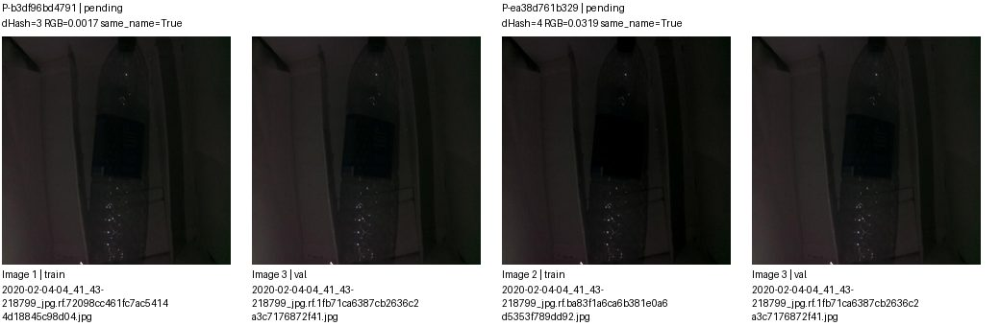

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-b3df96bd4791,images/train/2020-02-04-04_41_43-218799_jpg.rf.72098cc461fc7ac54144d18845c98d04.jpg,images/val/2020-02-04-04_41_43-218799_jpg.rf.1fb71ca6387cb2636c2a3c7176872f41.jpg,pending,
P-ea38d761b329,images/train/2020-02-04-04_41_43-218799_jpg.rf.ba83f1a6ca6b381e0a6d5353f789dd92.jpg,images/val/2020-02-04-04_41_43-218799_jpg.rf.1fb71ca6387cb2636c2a3c7176872f41.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 50/166 G-892135ae28d7 | 32 ảnh, 63 cặp
Split: {'test': 5, 'train': 19, 'val': 8}
Quyết định: {'pending': 63}
Ảnh trang 1/6; cặp trang 1/16. Nhóm liên thông không phải kết luận trùng.


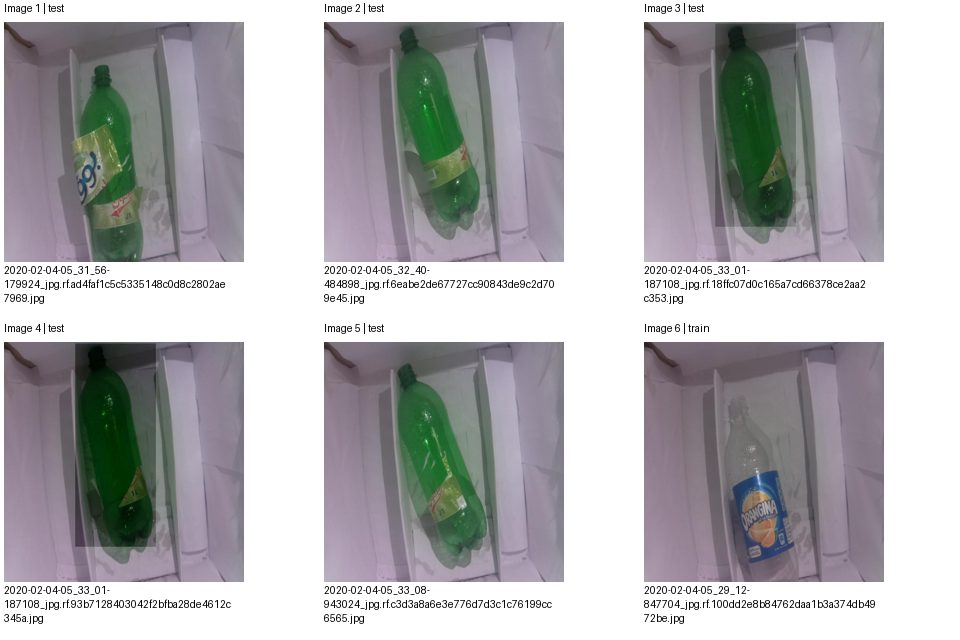

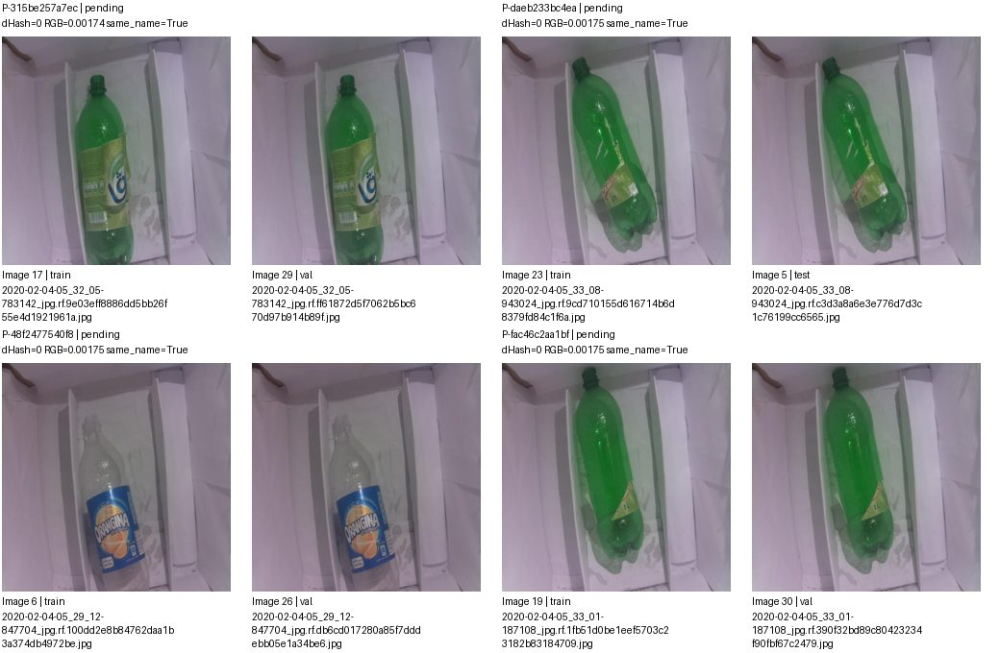

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-315be257a7ec,images/train/2020-02-04-05_32_05-783142_jpg.rf.9e03eff8886dd5bb26f55e4d1921961a.jpg,images/val/2020-02-04-05_32_05-783142_jpg.rf.ff61872d5f7062b5bc670d97b914b89f.jpg,pending,
P-daeb233bc4ea,images/train/2020-02-04-05_33_08-943024_jpg.rf.9cd710155d616714b6d8379fd84c1f6a.jpg,images/test/2020-02-04-05_33_08-943024_jpg.rf.c3d3a8a6e3e776d7d3c1c76199cc6565.jpg,pending,
P-48f2477540f8,images/train/2020-02-04-05_29_12-847704_jpg.rf.100dd2e8b84762daa1b3a374db4972be.jpg,images/val/2020-02-04-05_29_12-847704_jpg.rf.db6cd017280a85f7dddebb05e1a34be6.jpg,pending,
P-fac46c2aa1bf,images/train/2020-02-04-05_33_01-187108_jpg.rf.1fb51d0be1eef5703c23182b83184709.jpg,images/val/2020-02-04-05_33_01-187108_jpg.rf.390f32bd89c80423234f90fbf67c2479.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 50/166 G-892135ae28d7 | 32 ảnh, 63 cặp
Split: {'test': 5, 'train': 19, 'val': 8}
Quyết định: {'pending': 63}
Ảnh trang 2/6; cặp trang 2/16. Nhóm liên thông không phải kết luận trùng.


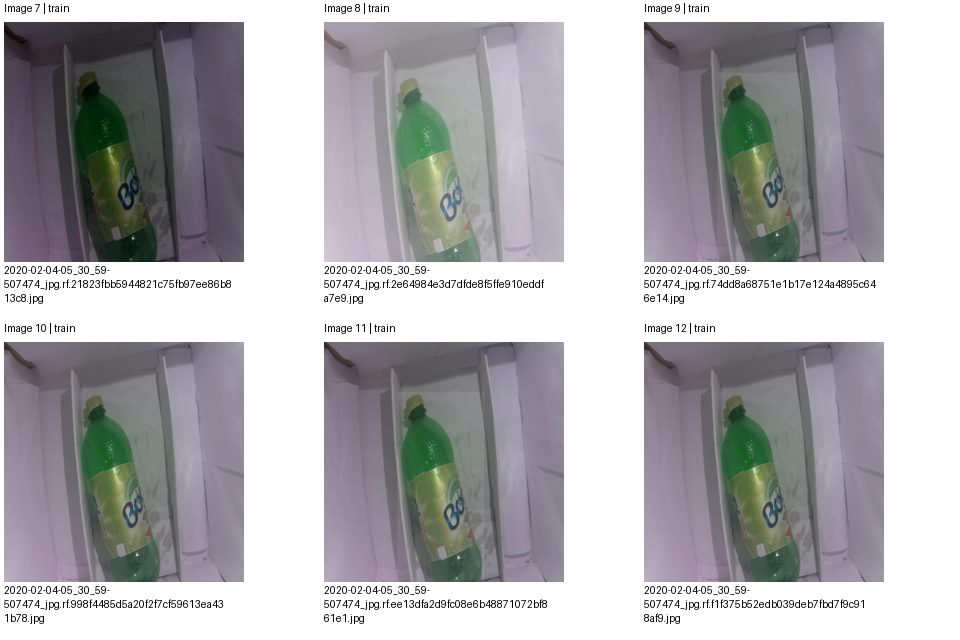

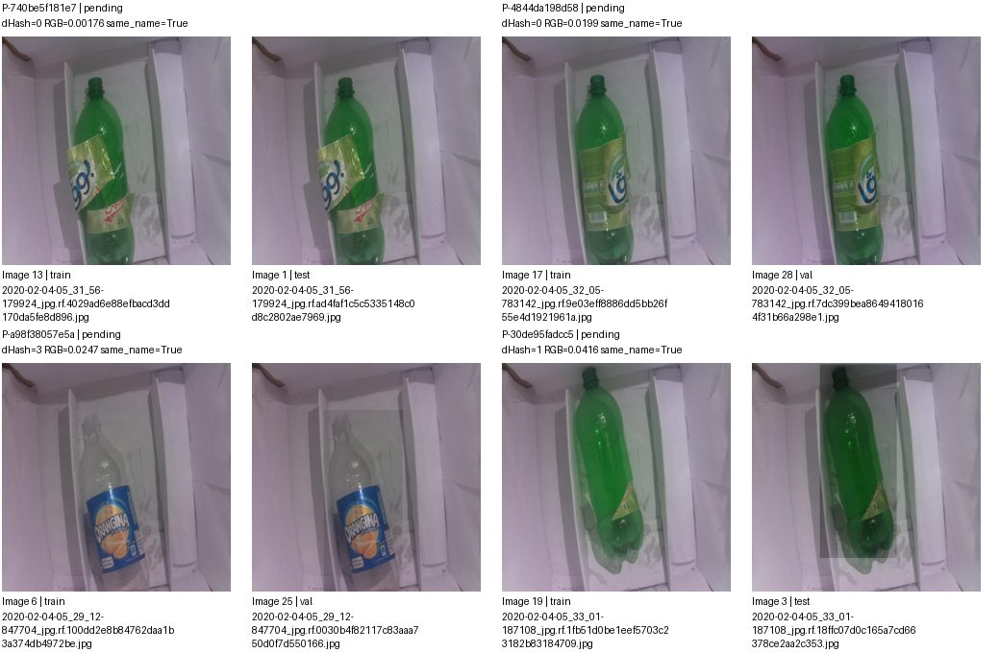

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-740be5f181e7,images/train/2020-02-04-05_31_56-179924_jpg.rf.4029ad6e88efbacd3dd170da5fe8d896.jpg,images/test/2020-02-04-05_31_56-179924_jpg.rf.ad4faf1c5c5335148c0d8c2802ae7969.jpg,pending,
P-4844da198d58,images/train/2020-02-04-05_32_05-783142_jpg.rf.9e03eff8886dd5bb26f55e4d1921961a.jpg,images/val/2020-02-04-05_32_05-783142_jpg.rf.7dc399bea86494180164f31b66a298e1.jpg,pending,
P-a98f38057e5a,images/train/2020-02-04-05_29_12-847704_jpg.rf.100dd2e8b84762daa1b3a374db4972be.jpg,images/val/2020-02-04-05_29_12-847704_jpg.rf.0030b4f82117c83aaa750d0f7d550166.jpg,pending,
P-30de95fadcc5,images/train/2020-02-04-05_33_01-187108_jpg.rf.1fb51d0be1eef5703c23182b83184709.jpg,images/test/2020-02-04-05_33_01-187108_jpg.rf.18ffc07d0c165a7cd66378ce2aa2c353.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 50/166 G-892135ae28d7 | 32 ảnh, 63 cặp
Split: {'test': 5, 'train': 19, 'val': 8}
Quyết định: {'pending': 63}
Ảnh trang 3/6; cặp trang 3/16. Nhóm liên thông không phải kết luận trùng.


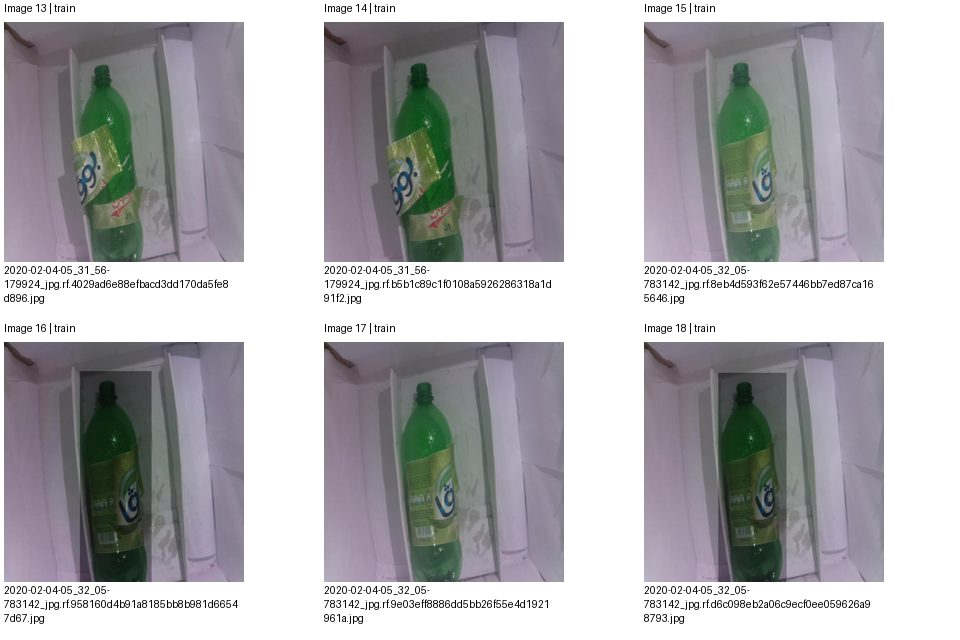

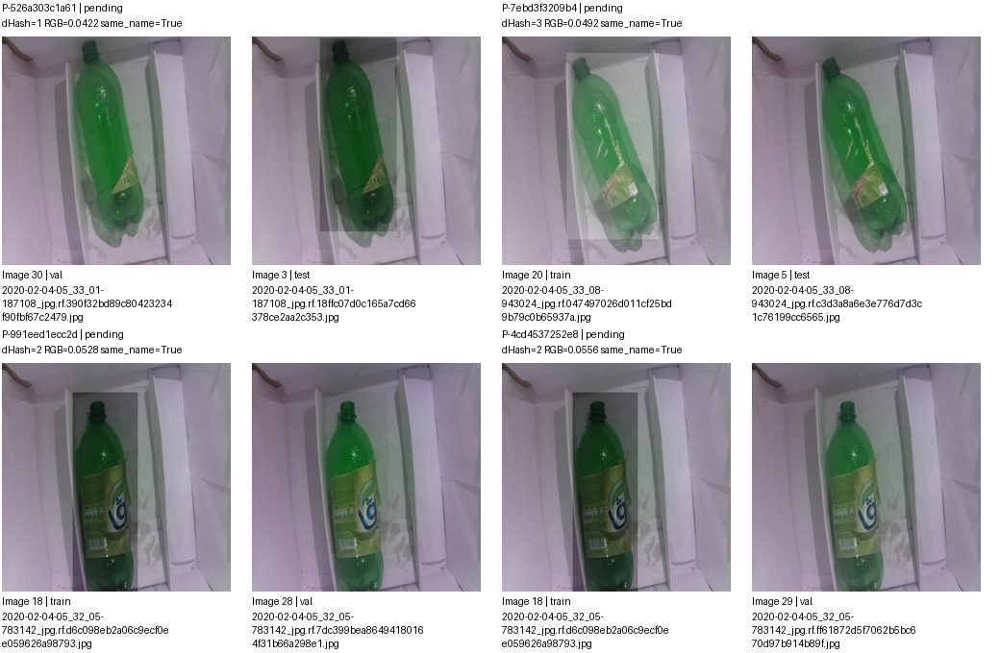

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-526a303c1a61,images/val/2020-02-04-05_33_01-187108_jpg.rf.390f32bd89c80423234f90fbf67c2479.jpg,images/test/2020-02-04-05_33_01-187108_jpg.rf.18ffc07d0c165a7cd66378ce2aa2c353.jpg,pending,
P-7ebd3f3209b4,images/train/2020-02-04-05_33_08-943024_jpg.rf.047497026d011cf25bd9b79c0b65937a.jpg,images/test/2020-02-04-05_33_08-943024_jpg.rf.c3d3a8a6e3e776d7d3c1c76199cc6565.jpg,pending,
P-991eed1ecc2d,images/train/2020-02-04-05_32_05-783142_jpg.rf.d6c098eb2a06c9ecf0ee059626a98793.jpg,images/val/2020-02-04-05_32_05-783142_jpg.rf.7dc399bea86494180164f31b66a298e1.jpg,pending,
P-4cd4537252e8,images/train/2020-02-04-05_32_05-783142_jpg.rf.d6c098eb2a06c9ecf0ee059626a98793.jpg,images/val/2020-02-04-05_32_05-783142_jpg.rf.ff61872d5f7062b5bc670d97b914b89f.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 50/166 G-892135ae28d7 | 32 ảnh, 63 cặp
Split: {'test': 5, 'train': 19, 'val': 8}
Quyết định: {'pending': 63}
Ảnh trang 4/6; cặp trang 4/16. Nhóm liên thông không phải kết luận trùng.


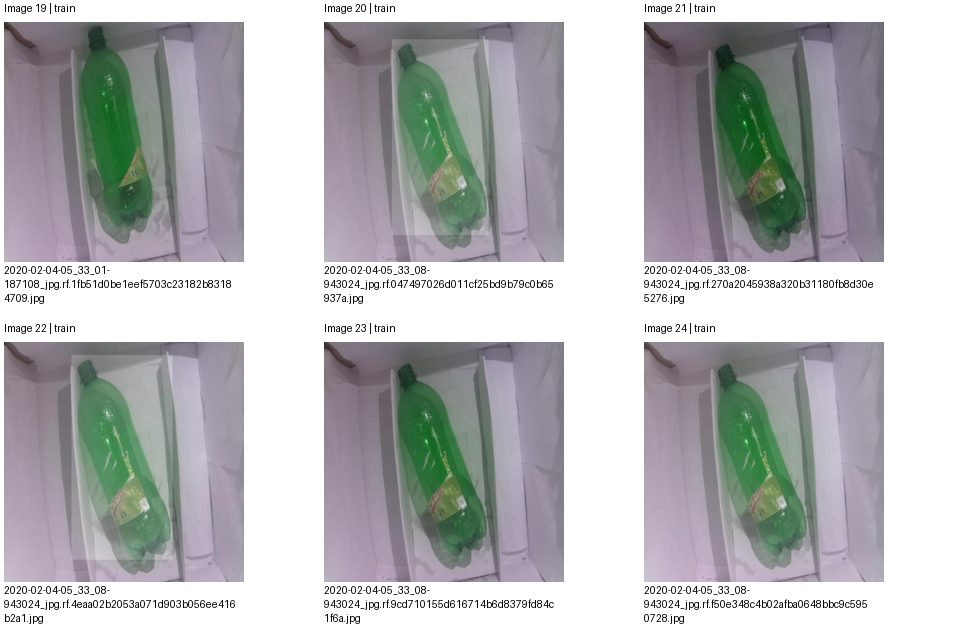

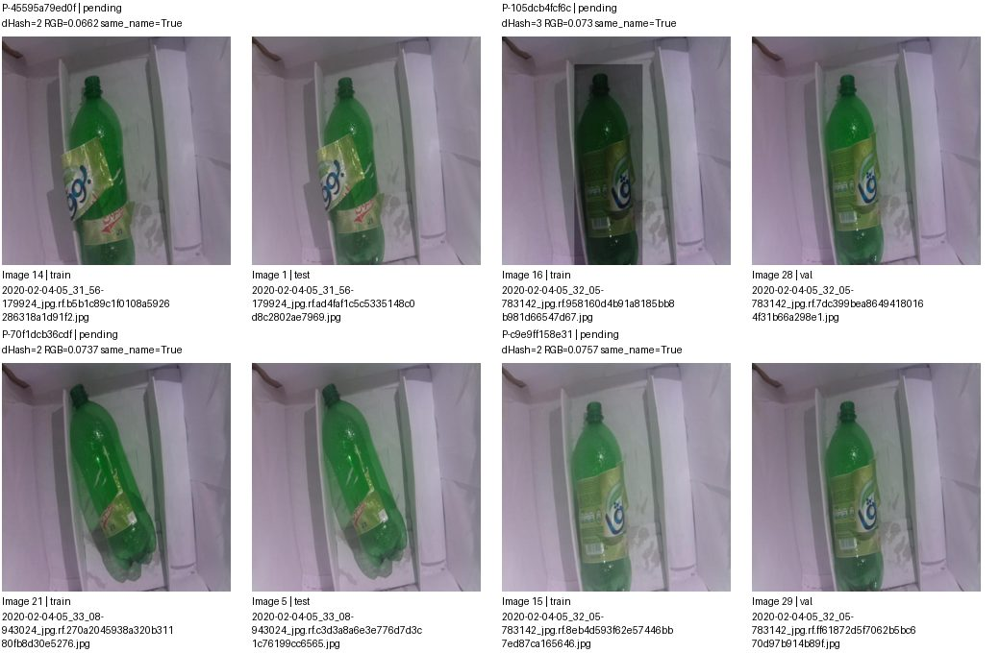

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-45595a79ed0f,images/train/2020-02-04-05_31_56-179924_jpg.rf.b5b1c89c1f0108a5926286318a1d91f2.jpg,images/test/2020-02-04-05_31_56-179924_jpg.rf.ad4faf1c5c5335148c0d8c2802ae7969.jpg,pending,
P-105dcb4fcf6c,images/train/2020-02-04-05_32_05-783142_jpg.rf.958160d4b91a8185bb8b981d66547d67.jpg,images/val/2020-02-04-05_32_05-783142_jpg.rf.7dc399bea86494180164f31b66a298e1.jpg,pending,
P-70f1dcb36cdf,images/train/2020-02-04-05_33_08-943024_jpg.rf.270a2045938a320b31180fb8d30e5276.jpg,images/test/2020-02-04-05_33_08-943024_jpg.rf.c3d3a8a6e3e776d7d3c1c76199cc6565.jpg,pending,
P-c9e9ff158e31,images/train/2020-02-04-05_32_05-783142_jpg.rf.8eb4d593f62e57446bb7ed87ca165646.jpg,images/val/2020-02-04-05_32_05-783142_jpg.rf.ff61872d5f7062b5bc670d97b914b89f.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 50/166 G-892135ae28d7 | 32 ảnh, 63 cặp
Split: {'test': 5, 'train': 19, 'val': 8}
Quyết định: {'pending': 63}
Ảnh trang 5/6; cặp trang 5/16. Nhóm liên thông không phải kết luận trùng.


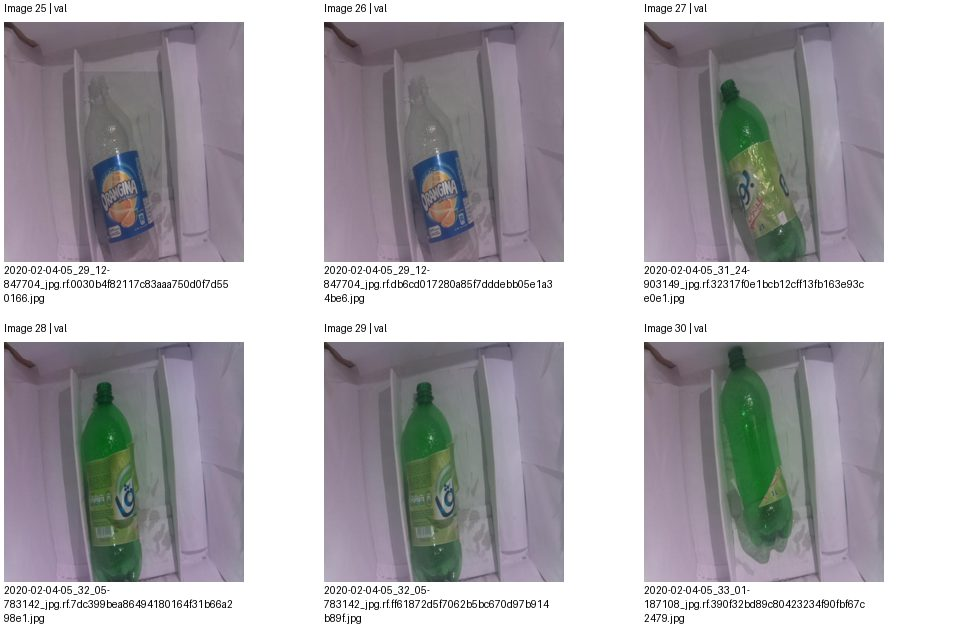

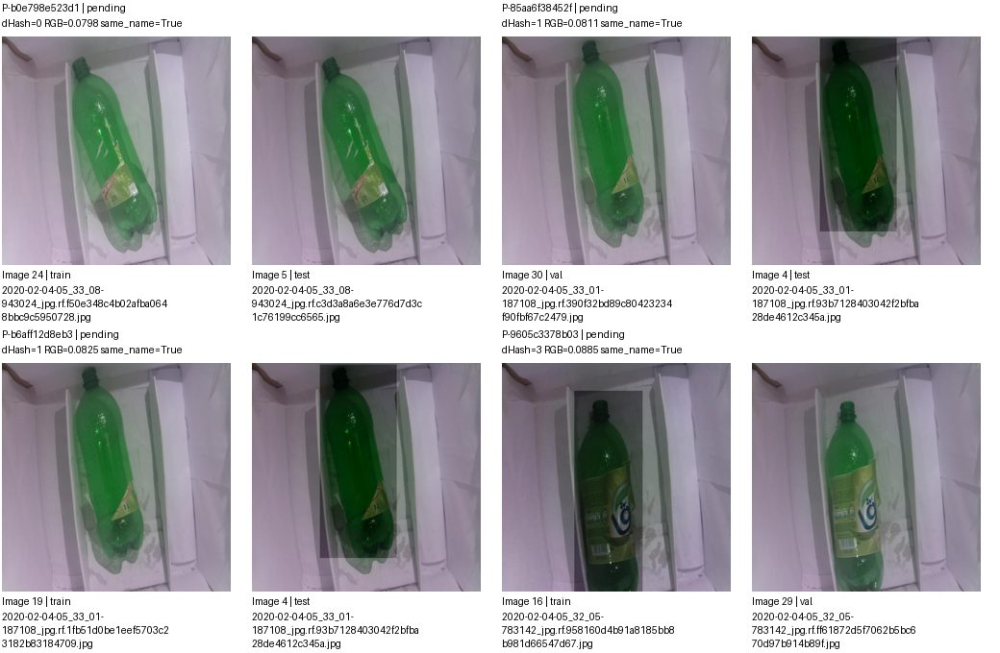

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-b0e798e523d1,images/train/2020-02-04-05_33_08-943024_jpg.rf.f50e348c4b02afba0648bbc9c5950728.jpg,images/test/2020-02-04-05_33_08-943024_jpg.rf.c3d3a8a6e3e776d7d3c1c76199cc6565.jpg,pending,
P-85aa6f38452f,images/val/2020-02-04-05_33_01-187108_jpg.rf.390f32bd89c80423234f90fbf67c2479.jpg,images/test/2020-02-04-05_33_01-187108_jpg.rf.93b7128403042f2bfba28de4612c345a.jpg,pending,
P-b6aff12d8eb3,images/train/2020-02-04-05_33_01-187108_jpg.rf.1fb51d0be1eef5703c23182b83184709.jpg,images/test/2020-02-04-05_33_01-187108_jpg.rf.93b7128403042f2bfba28de4612c345a.jpg,pending,
P-9605c3378b03,images/train/2020-02-04-05_32_05-783142_jpg.rf.958160d4b91a8185bb8b981d66547d67.jpg,images/val/2020-02-04-05_32_05-783142_jpg.rf.ff61872d5f7062b5bc670d97b914b89f.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 50/166 G-892135ae28d7 | 32 ảnh, 63 cặp
Split: {'test': 5, 'train': 19, 'val': 8}
Quyết định: {'pending': 63}
Ảnh trang 6/6; cặp trang 6/16. Nhóm liên thông không phải kết luận trùng.


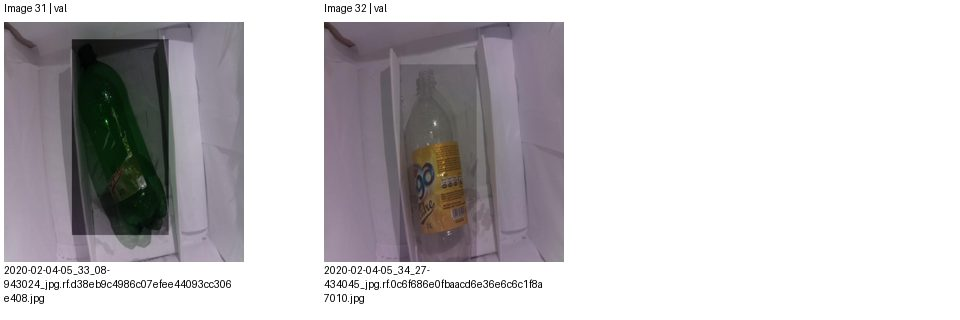

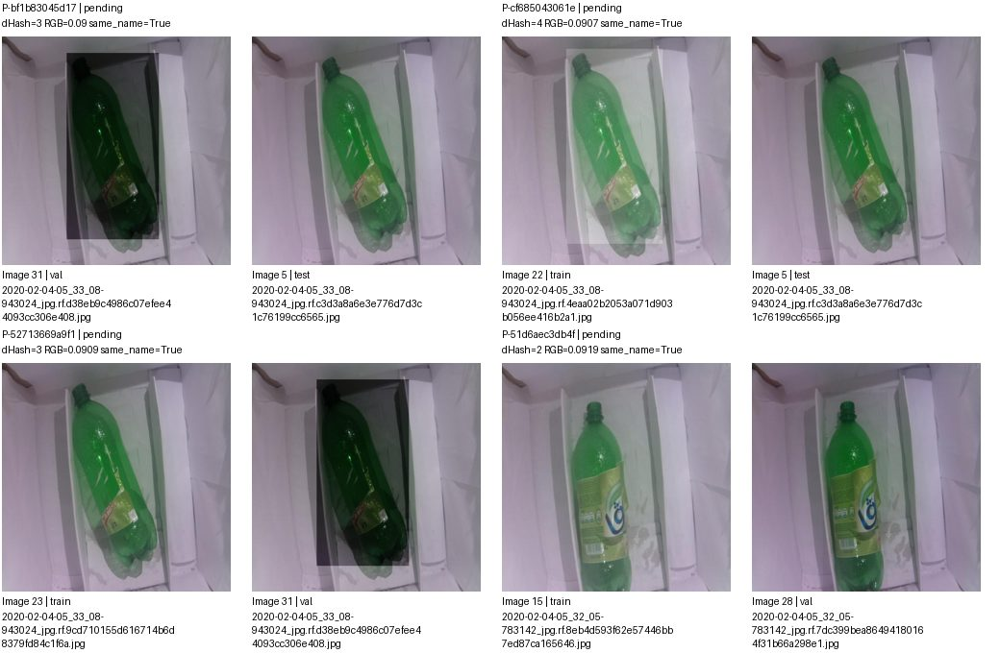

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-bf1b83045d17,images/val/2020-02-04-05_33_08-943024_jpg.rf.d38eb9c4986c07efee44093cc306e408.jpg,images/test/2020-02-04-05_33_08-943024_jpg.rf.c3d3a8a6e3e776d7d3c1c76199cc6565.jpg,pending,
P-cf685043061e,images/train/2020-02-04-05_33_08-943024_jpg.rf.4eaa02b2053a071d903b056ee416b2a1.jpg,images/test/2020-02-04-05_33_08-943024_jpg.rf.c3d3a8a6e3e776d7d3c1c76199cc6565.jpg,pending,
P-52713669a9f1,images/train/2020-02-04-05_33_08-943024_jpg.rf.9cd710155d616714b6d8379fd84c1f6a.jpg,images/val/2020-02-04-05_33_08-943024_jpg.rf.d38eb9c4986c07efee44093cc306e408.jpg,pending,
P-51d6aec3db4f,images/train/2020-02-04-05_32_05-783142_jpg.rf.8eb4d593f62e57446bb7ed87ca165646.jpg,images/val/2020-02-04-05_32_05-783142_jpg.rf.7dc399bea86494180164f31b66a298e1.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 50/166 G-892135ae28d7 | 32 ảnh, 63 cặp
Split: {'test': 5, 'train': 19, 'val': 8}
Quyết định: {'pending': 63}
Ảnh trang None/6; cặp trang 7/16. Nhóm liên thông không phải kết luận trùng.


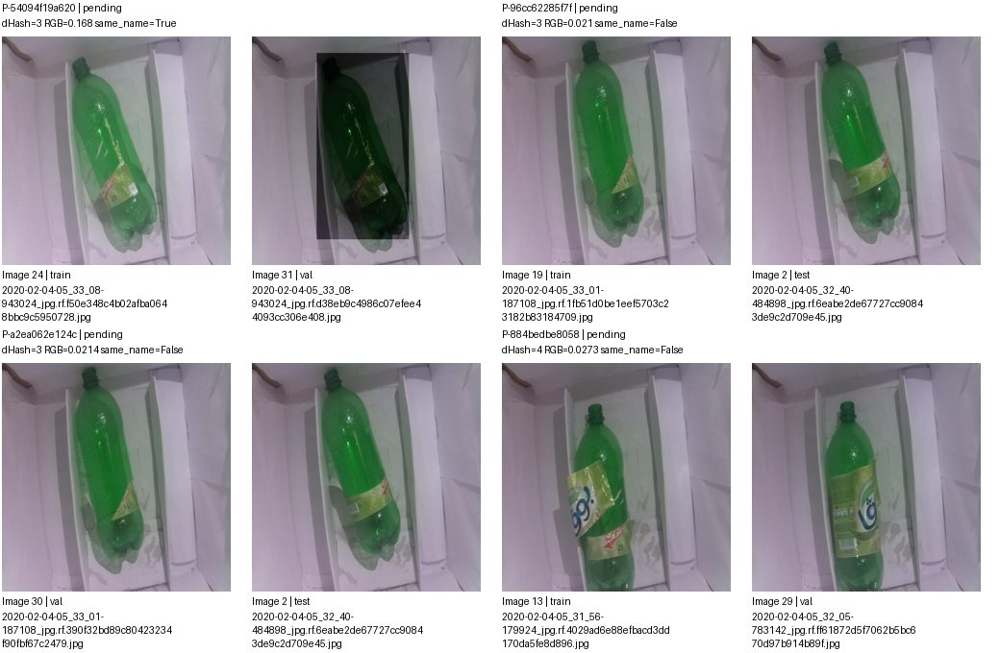

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-54094f19a620,images/train/2020-02-04-05_33_08-943024_jpg.rf.f50e348c4b02afba0648bbc9c5950728.jpg,images/val/2020-02-04-05_33_08-943024_jpg.rf.d38eb9c4986c07efee44093cc306e408.jpg,pending,
P-96cc62285f7f,images/train/2020-02-04-05_33_01-187108_jpg.rf.1fb51d0be1eef5703c23182b83184709.jpg,images/test/2020-02-04-05_32_40-484898_jpg.rf.6eabe2de67727cc90843de9c2d709e45.jpg,pending,
P-a2ea062e124c,images/val/2020-02-04-05_33_01-187108_jpg.rf.390f32bd89c80423234f90fbf67c2479.jpg,images/test/2020-02-04-05_32_40-484898_jpg.rf.6eabe2de67727cc90843de9c2d709e45.jpg,pending,
P-884bedbe8058,images/train/2020-02-04-05_31_56-179924_jpg.rf.4029ad6e88efbacd3dd170da5fe8d896.jpg,images/val/2020-02-04-05_32_05-783142_jpg.rf.ff61872d5f7062b5bc670d97b914b89f.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 50/166 G-892135ae28d7 | 32 ảnh, 63 cặp
Split: {'test': 5, 'train': 19, 'val': 8}
Quyết định: {'pending': 63}
Ảnh trang None/6; cặp trang 8/16. Nhóm liên thông không phải kết luận trùng.


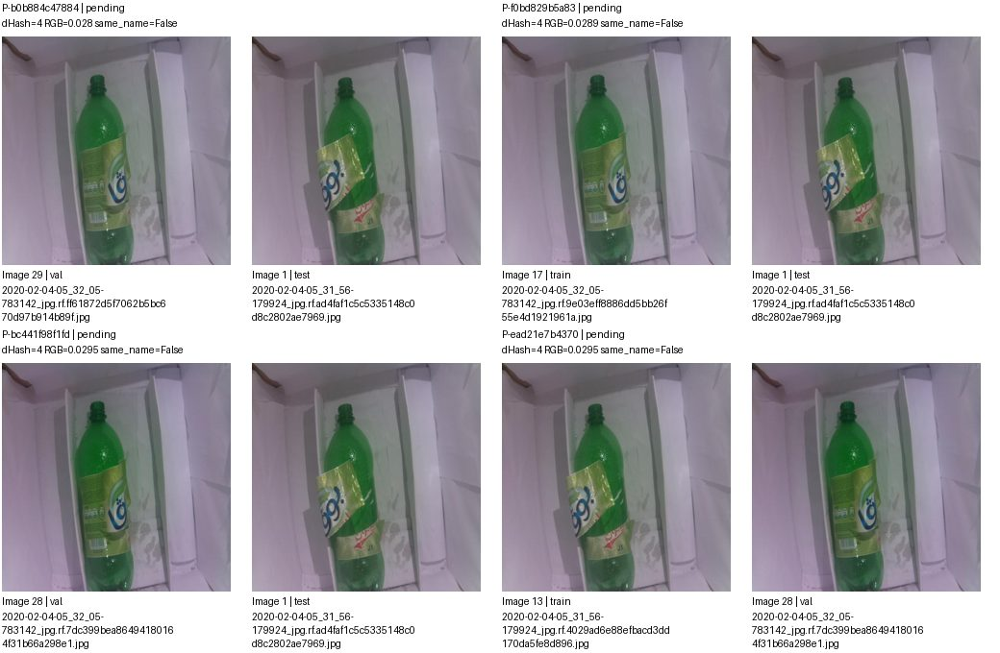

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-b0b884c47884,images/val/2020-02-04-05_32_05-783142_jpg.rf.ff61872d5f7062b5bc670d97b914b89f.jpg,images/test/2020-02-04-05_31_56-179924_jpg.rf.ad4faf1c5c5335148c0d8c2802ae7969.jpg,pending,
P-f0bd829b5a83,images/train/2020-02-04-05_32_05-783142_jpg.rf.9e03eff8886dd5bb26f55e4d1921961a.jpg,images/test/2020-02-04-05_31_56-179924_jpg.rf.ad4faf1c5c5335148c0d8c2802ae7969.jpg,pending,
P-bc441f98f1fd,images/val/2020-02-04-05_32_05-783142_jpg.rf.7dc399bea86494180164f31b66a298e1.jpg,images/test/2020-02-04-05_31_56-179924_jpg.rf.ad4faf1c5c5335148c0d8c2802ae7969.jpg,pending,
P-ead21e7b4370,images/train/2020-02-04-05_31_56-179924_jpg.rf.4029ad6e88efbacd3dd170da5fe8d896.jpg,images/val/2020-02-04-05_32_05-783142_jpg.rf.7dc399bea86494180164f31b66a298e1.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 50/166 G-892135ae28d7 | 32 ảnh, 63 cặp
Split: {'test': 5, 'train': 19, 'val': 8}
Quyết định: {'pending': 63}
Ảnh trang None/6; cặp trang 9/16. Nhóm liên thông không phải kết luận trùng.


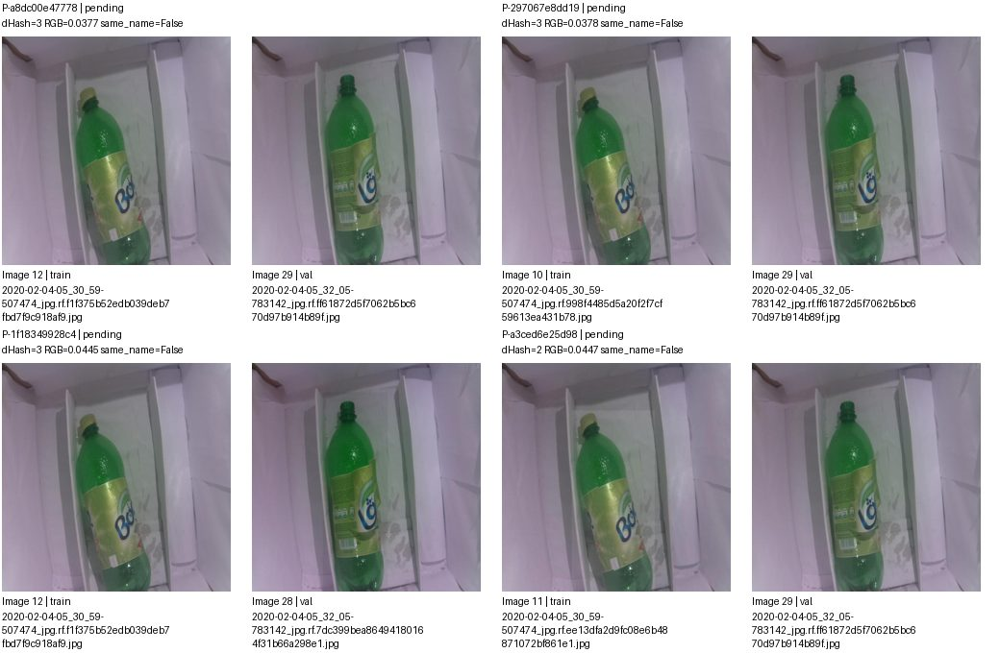

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-a8dc00e47778,images/train/2020-02-04-05_30_59-507474_jpg.rf.f1f375b52edb039deb7fbd7f9c918af9.jpg,images/val/2020-02-04-05_32_05-783142_jpg.rf.ff61872d5f7062b5bc670d97b914b89f.jpg,pending,
P-297067e8dd19,images/train/2020-02-04-05_30_59-507474_jpg.rf.998f4485d5a20f2f7cf59613ea431b78.jpg,images/val/2020-02-04-05_32_05-783142_jpg.rf.ff61872d5f7062b5bc670d97b914b89f.jpg,pending,
P-1f18349928c4,images/train/2020-02-04-05_30_59-507474_jpg.rf.f1f375b52edb039deb7fbd7f9c918af9.jpg,images/val/2020-02-04-05_32_05-783142_jpg.rf.7dc399bea86494180164f31b66a298e1.jpg,pending,
P-a3ced6e25d98,images/train/2020-02-04-05_30_59-507474_jpg.rf.ee13dfa2d9fc08e6b48871072bf861e1.jpg,images/val/2020-02-04-05_32_05-783142_jpg.rf.ff61872d5f7062b5bc670d97b914b89f.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 50/166 G-892135ae28d7 | 32 ảnh, 63 cặp
Split: {'test': 5, 'train': 19, 'val': 8}
Quyết định: {'pending': 63}
Ảnh trang None/6; cặp trang 10/16. Nhóm liên thông không phải kết luận trùng.


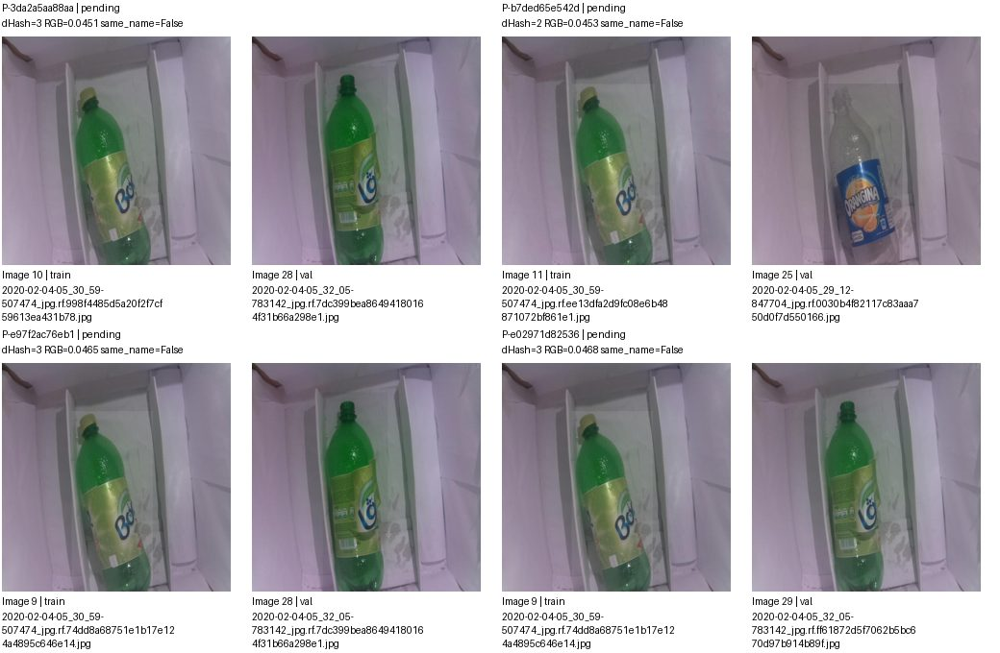

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-3da2a5aa88aa,images/train/2020-02-04-05_30_59-507474_jpg.rf.998f4485d5a20f2f7cf59613ea431b78.jpg,images/val/2020-02-04-05_32_05-783142_jpg.rf.7dc399bea86494180164f31b66a298e1.jpg,pending,
P-b7ded65e542d,images/train/2020-02-04-05_30_59-507474_jpg.rf.ee13dfa2d9fc08e6b48871072bf861e1.jpg,images/val/2020-02-04-05_29_12-847704_jpg.rf.0030b4f82117c83aaa750d0f7d550166.jpg,pending,
P-e97f2ac76eb1,images/train/2020-02-04-05_30_59-507474_jpg.rf.74dd8a68751e1b17e124a4895c646e14.jpg,images/val/2020-02-04-05_32_05-783142_jpg.rf.7dc399bea86494180164f31b66a298e1.jpg,pending,
P-e02971d82536,images/train/2020-02-04-05_30_59-507474_jpg.rf.74dd8a68751e1b17e124a4895c646e14.jpg,images/val/2020-02-04-05_32_05-783142_jpg.rf.ff61872d5f7062b5bc670d97b914b89f.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 50/166 G-892135ae28d7 | 32 ảnh, 63 cặp
Split: {'test': 5, 'train': 19, 'val': 8}
Quyết định: {'pending': 63}
Ảnh trang None/6; cặp trang 11/16. Nhóm liên thông không phải kết luận trùng.


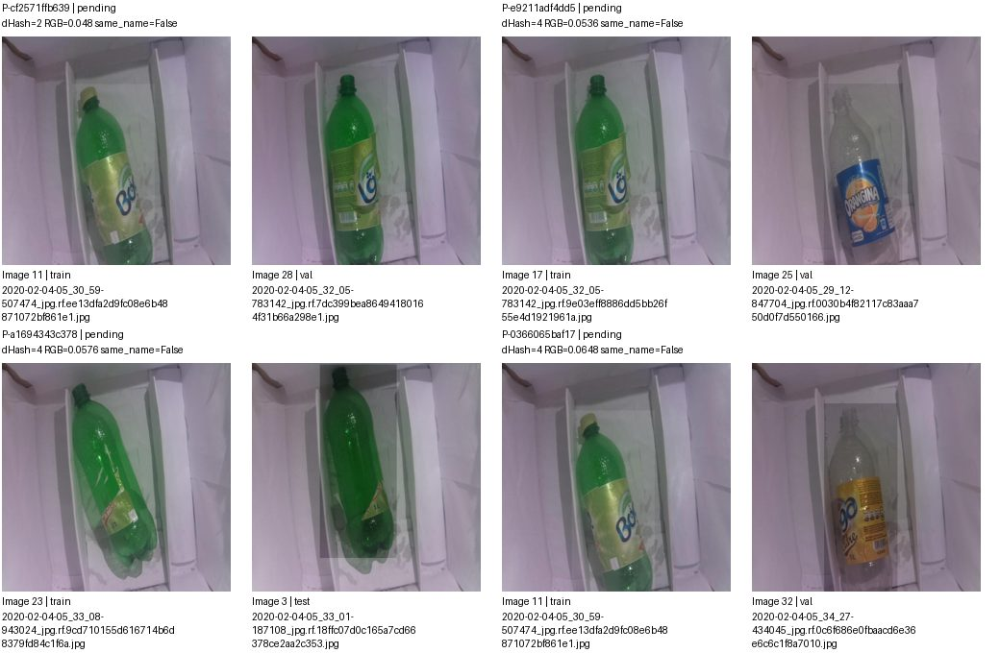

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-cf2571ffb639,images/train/2020-02-04-05_30_59-507474_jpg.rf.ee13dfa2d9fc08e6b48871072bf861e1.jpg,images/val/2020-02-04-05_32_05-783142_jpg.rf.7dc399bea86494180164f31b66a298e1.jpg,pending,
P-e9211adf4dd5,images/train/2020-02-04-05_32_05-783142_jpg.rf.9e03eff8886dd5bb26f55e4d1921961a.jpg,images/val/2020-02-04-05_29_12-847704_jpg.rf.0030b4f82117c83aaa750d0f7d550166.jpg,pending,
P-a1694343c378,images/train/2020-02-04-05_33_08-943024_jpg.rf.9cd710155d616714b6d8379fd84c1f6a.jpg,images/test/2020-02-04-05_33_01-187108_jpg.rf.18ffc07d0c165a7cd66378ce2aa2c353.jpg,pending,
P-0366065baf17,images/train/2020-02-04-05_30_59-507474_jpg.rf.ee13dfa2d9fc08e6b48871072bf861e1.jpg,images/val/2020-02-04-05_34_27-434045_jpg.rf.0c6f686e0fbaacd6e36e6c6c1f8a7010.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 50/166 G-892135ae28d7 | 32 ảnh, 63 cặp
Split: {'test': 5, 'train': 19, 'val': 8}
Quyết định: {'pending': 63}
Ảnh trang None/6; cặp trang 12/16. Nhóm liên thông không phải kết luận trùng.


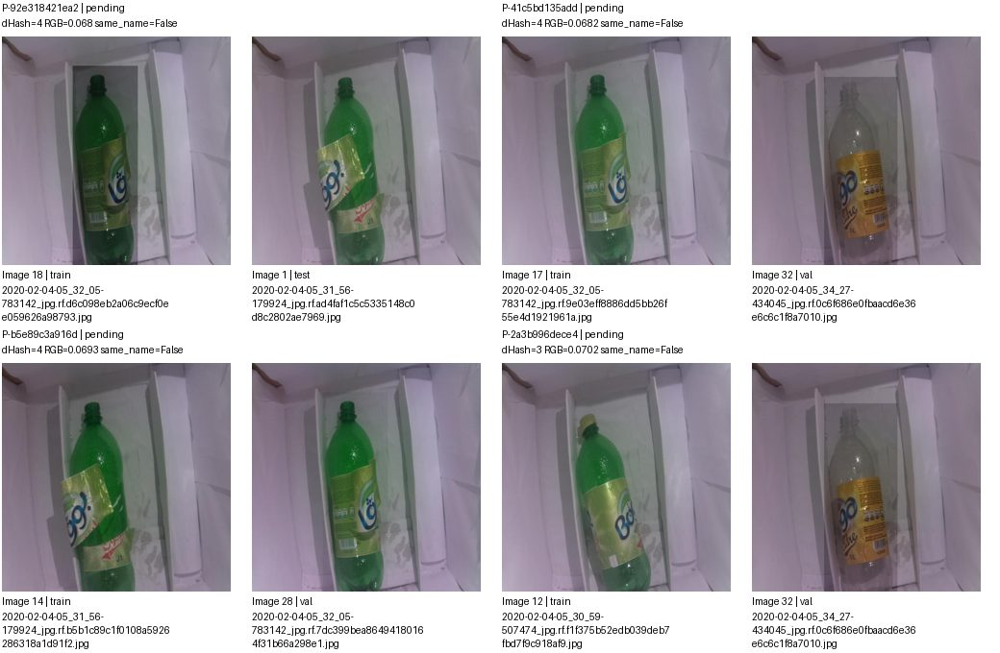

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-92e318421ea2,images/train/2020-02-04-05_32_05-783142_jpg.rf.d6c098eb2a06c9ecf0ee059626a98793.jpg,images/test/2020-02-04-05_31_56-179924_jpg.rf.ad4faf1c5c5335148c0d8c2802ae7969.jpg,pending,
P-41c5bd135add,images/train/2020-02-04-05_32_05-783142_jpg.rf.9e03eff8886dd5bb26f55e4d1921961a.jpg,images/val/2020-02-04-05_34_27-434045_jpg.rf.0c6f686e0fbaacd6e36e6c6c1f8a7010.jpg,pending,
P-b5e89c3a916d,images/train/2020-02-04-05_31_56-179924_jpg.rf.b5b1c89c1f0108a5926286318a1d91f2.jpg,images/val/2020-02-04-05_32_05-783142_jpg.rf.7dc399bea86494180164f31b66a298e1.jpg,pending,
P-2a3b996dece4,images/train/2020-02-04-05_30_59-507474_jpg.rf.f1f375b52edb039deb7fbd7f9c918af9.jpg,images/val/2020-02-04-05_34_27-434045_jpg.rf.0c6f686e0fbaacd6e36e6c6c1f8a7010.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 50/166 G-892135ae28d7 | 32 ảnh, 63 cặp
Split: {'test': 5, 'train': 19, 'val': 8}
Quyết định: {'pending': 63}
Ảnh trang None/6; cặp trang 13/16. Nhóm liên thông không phải kết luận trùng.


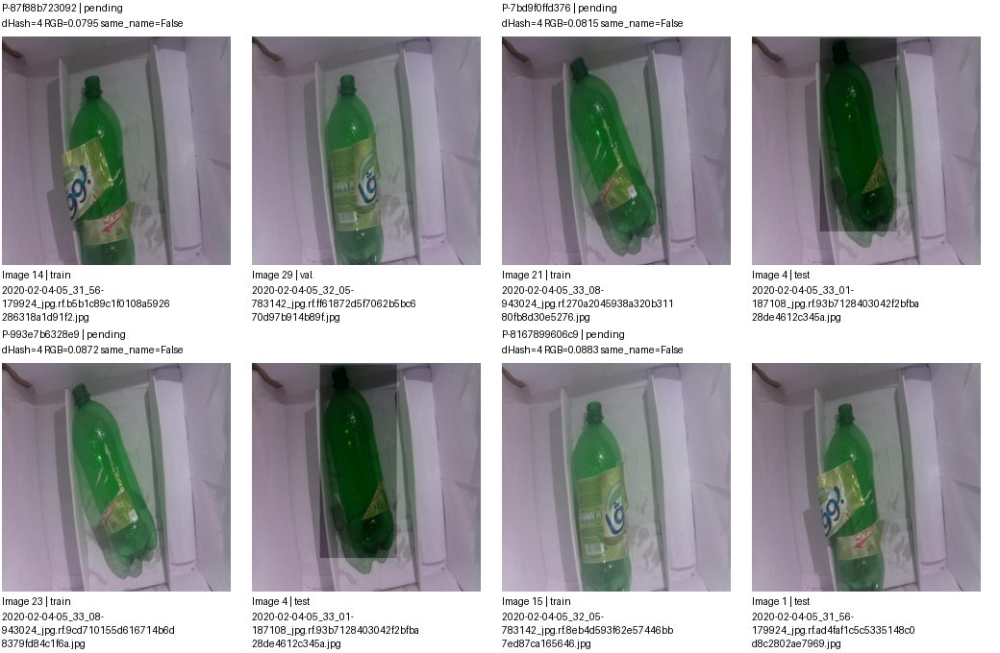

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-87f88b723092,images/train/2020-02-04-05_31_56-179924_jpg.rf.b5b1c89c1f0108a5926286318a1d91f2.jpg,images/val/2020-02-04-05_32_05-783142_jpg.rf.ff61872d5f7062b5bc670d97b914b89f.jpg,pending,
P-7bd9f0ffd376,images/train/2020-02-04-05_33_08-943024_jpg.rf.270a2045938a320b31180fb8d30e5276.jpg,images/test/2020-02-04-05_33_01-187108_jpg.rf.93b7128403042f2bfba28de4612c345a.jpg,pending,
P-993e7b6328e9,images/train/2020-02-04-05_33_08-943024_jpg.rf.9cd710155d616714b6d8379fd84c1f6a.jpg,images/test/2020-02-04-05_33_01-187108_jpg.rf.93b7128403042f2bfba28de4612c345a.jpg,pending,
P-8167899606c9,images/train/2020-02-04-05_32_05-783142_jpg.rf.8eb4d593f62e57446bb7ed87ca165646.jpg,images/test/2020-02-04-05_31_56-179924_jpg.rf.ad4faf1c5c5335148c0d8c2802ae7969.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 50/166 G-892135ae28d7 | 32 ảnh, 63 cặp
Split: {'test': 5, 'train': 19, 'val': 8}
Quyết định: {'pending': 63}
Ảnh trang None/6; cặp trang 14/16. Nhóm liên thông không phải kết luận trùng.


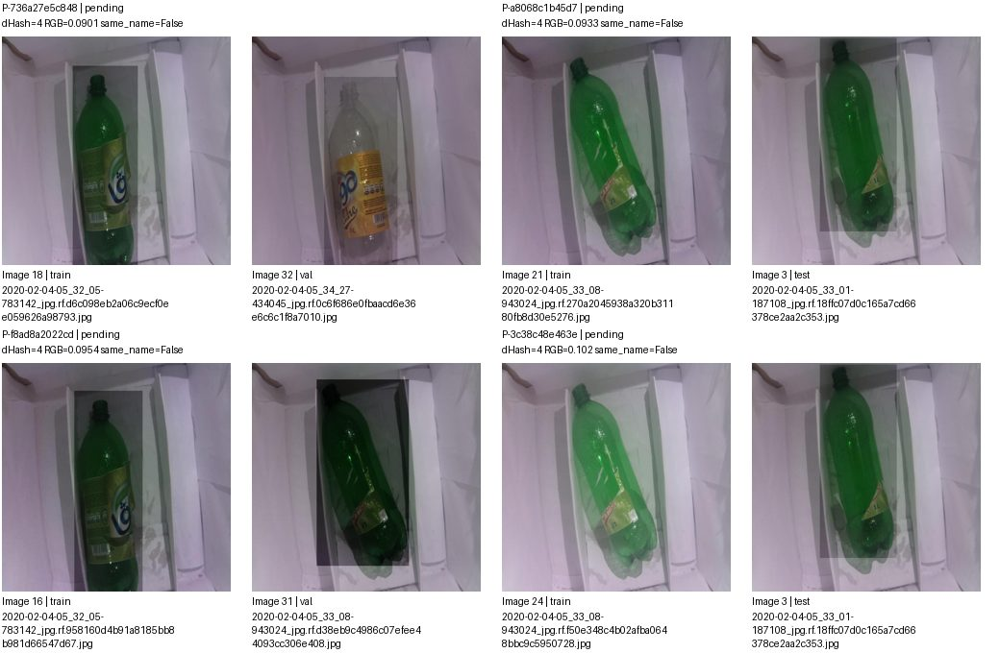

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-736a27e5c848,images/train/2020-02-04-05_32_05-783142_jpg.rf.d6c098eb2a06c9ecf0ee059626a98793.jpg,images/val/2020-02-04-05_34_27-434045_jpg.rf.0c6f686e0fbaacd6e36e6c6c1f8a7010.jpg,pending,
P-a8068c1b45d7,images/train/2020-02-04-05_33_08-943024_jpg.rf.270a2045938a320b31180fb8d30e5276.jpg,images/test/2020-02-04-05_33_01-187108_jpg.rf.18ffc07d0c165a7cd66378ce2aa2c353.jpg,pending,
P-f8ad8a2022cd,images/train/2020-02-04-05_32_05-783142_jpg.rf.958160d4b91a8185bb8b981d66547d67.jpg,images/val/2020-02-04-05_33_08-943024_jpg.rf.d38eb9c4986c07efee44093cc306e408.jpg,pending,
P-3c38c48e463e,images/train/2020-02-04-05_33_08-943024_jpg.rf.f50e348c4b02afba0648bbc9c5950728.jpg,images/test/2020-02-04-05_33_01-187108_jpg.rf.18ffc07d0c165a7cd66378ce2aa2c353.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 50/166 G-892135ae28d7 | 32 ảnh, 63 cặp
Split: {'test': 5, 'train': 19, 'val': 8}
Quyết định: {'pending': 63}
Ảnh trang None/6; cặp trang 15/16. Nhóm liên thông không phải kết luận trùng.


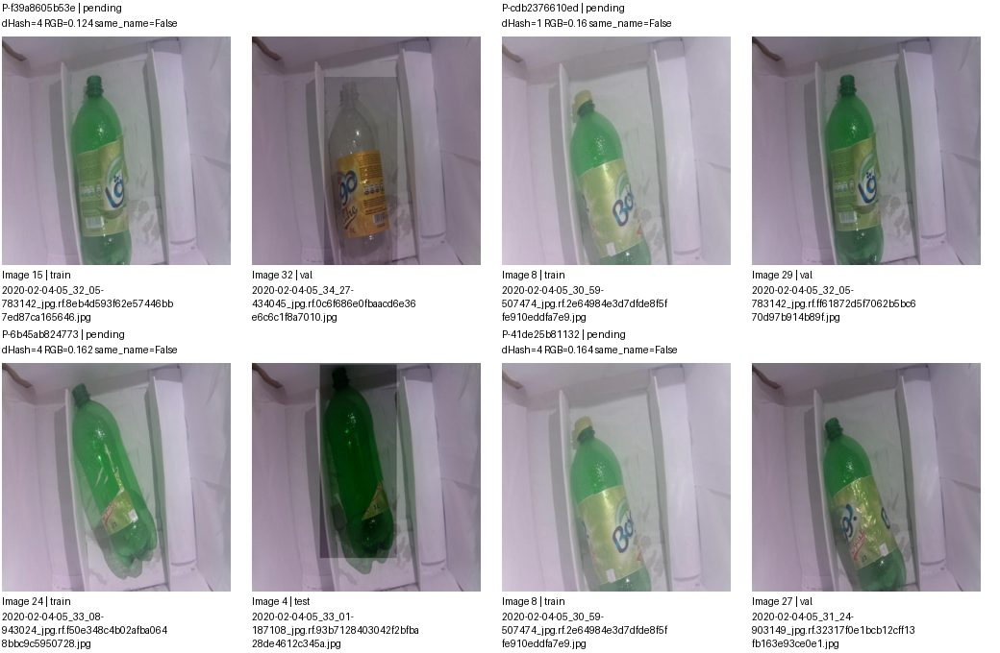

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-f39a8605b53e,images/train/2020-02-04-05_32_05-783142_jpg.rf.8eb4d593f62e57446bb7ed87ca165646.jpg,images/val/2020-02-04-05_34_27-434045_jpg.rf.0c6f686e0fbaacd6e36e6c6c1f8a7010.jpg,pending,
P-cdb2376610ed,images/train/2020-02-04-05_30_59-507474_jpg.rf.2e64984e3d7dfde8f5ffe910eddfa7e9.jpg,images/val/2020-02-04-05_32_05-783142_jpg.rf.ff61872d5f7062b5bc670d97b914b89f.jpg,pending,
P-6b45ab824773,images/train/2020-02-04-05_33_08-943024_jpg.rf.f50e348c4b02afba0648bbc9c5950728.jpg,images/test/2020-02-04-05_33_01-187108_jpg.rf.93b7128403042f2bfba28de4612c345a.jpg,pending,
P-41de25b81132,images/train/2020-02-04-05_30_59-507474_jpg.rf.2e64984e3d7dfde8f5ffe910eddfa7e9.jpg,images/val/2020-02-04-05_31_24-903149_jpg.rf.32317f0e1bcb12cff13fb163e93ce0e1.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 50/166 G-892135ae28d7 | 32 ảnh, 63 cặp
Split: {'test': 5, 'train': 19, 'val': 8}
Quyết định: {'pending': 63}
Ảnh trang None/6; cặp trang 16/16. Nhóm liên thông không phải kết luận trùng.


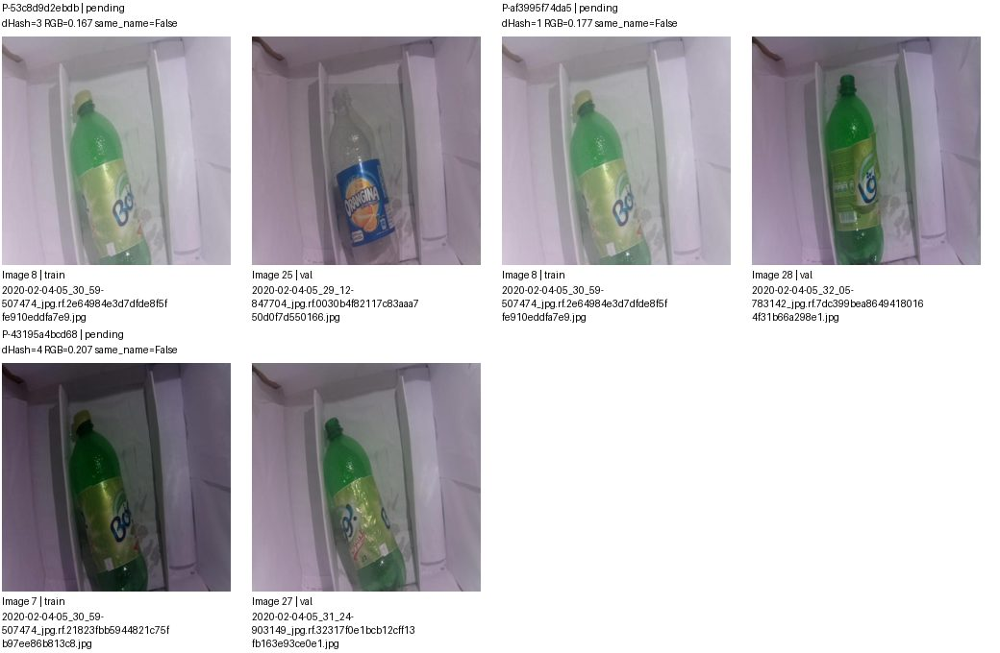

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-53c8d9d2ebdb,images/train/2020-02-04-05_30_59-507474_jpg.rf.2e64984e3d7dfde8f5ffe910eddfa7e9.jpg,images/val/2020-02-04-05_29_12-847704_jpg.rf.0030b4f82117c83aaa750d0f7d550166.jpg,pending,
P-af3995f74da5,images/train/2020-02-04-05_30_59-507474_jpg.rf.2e64984e3d7dfde8f5ffe910eddfa7e9.jpg,images/val/2020-02-04-05_32_05-783142_jpg.rf.7dc399bea86494180164f31b66a298e1.jpg,pending,
P-43195a4bcd68,images/train/2020-02-04-05_30_59-507474_jpg.rf.21823fbb5944821c75fb97ee86b813c8.jpg,images/val/2020-02-04-05_31_24-903149_jpg.rf.32317f0e1bcb12cff13fb163e93ce0e1.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 51/166 G-8ab1d82811a3 | 2 ảnh, 1 cặp
Split: {'test': 1, 'train': 1}
Quyết định: {'pending': 1}
Ảnh trang 1/1; cặp trang 1/1. Nhóm liên thông không phải kết luận trùng.


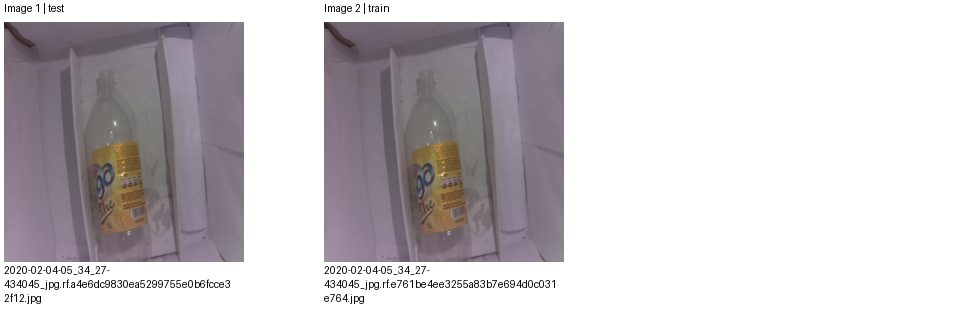

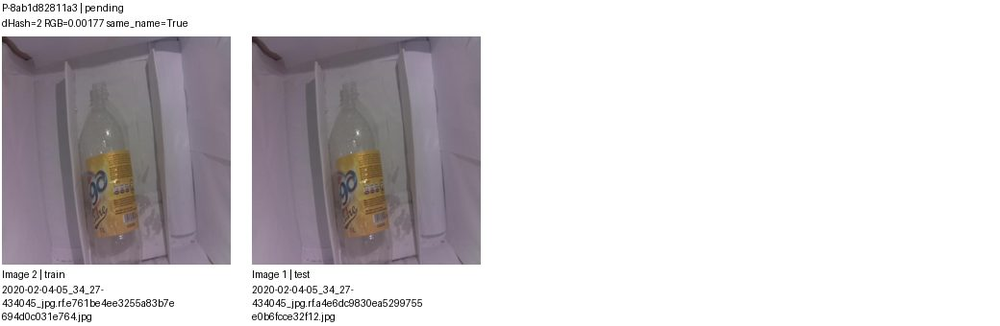

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-8ab1d82811a3,images/train/2020-02-04-05_34_27-434045_jpg.rf.e761be4ee3255a83b7e694d0c031e764.jpg,images/test/2020-02-04-05_34_27-434045_jpg.rf.a4e6dc9830ea5299755e0b6fcce32f12.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 52/166 G-586696e3c556 | 77 ảnh, 388 cặp
Split: {'test': 2, 'train': 70, 'val': 5}
Quyết định: {'pending': 388}
Ảnh trang 1/13; cặp trang 1/97. Nhóm liên thông không phải kết luận trùng.


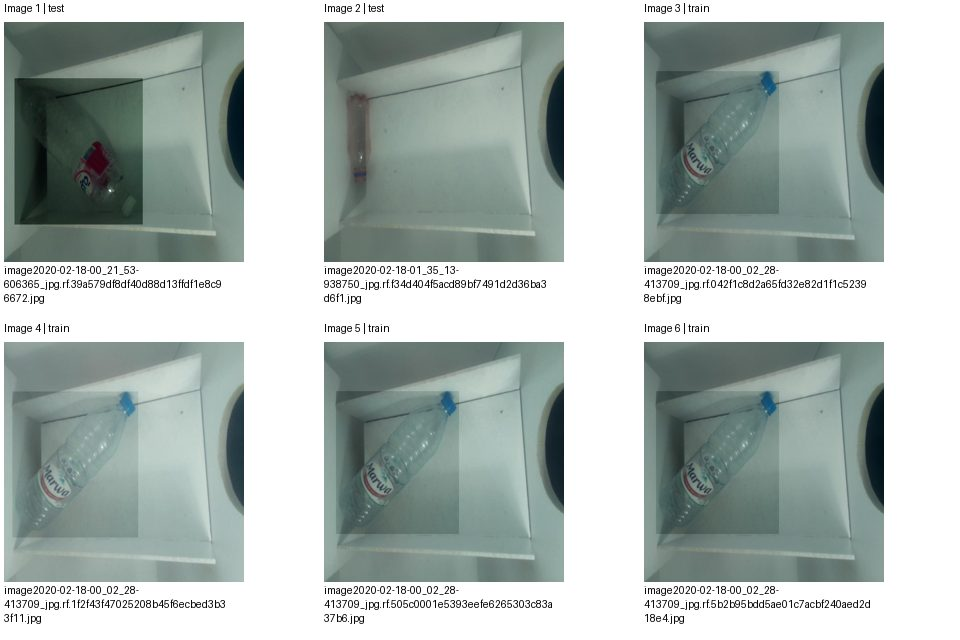

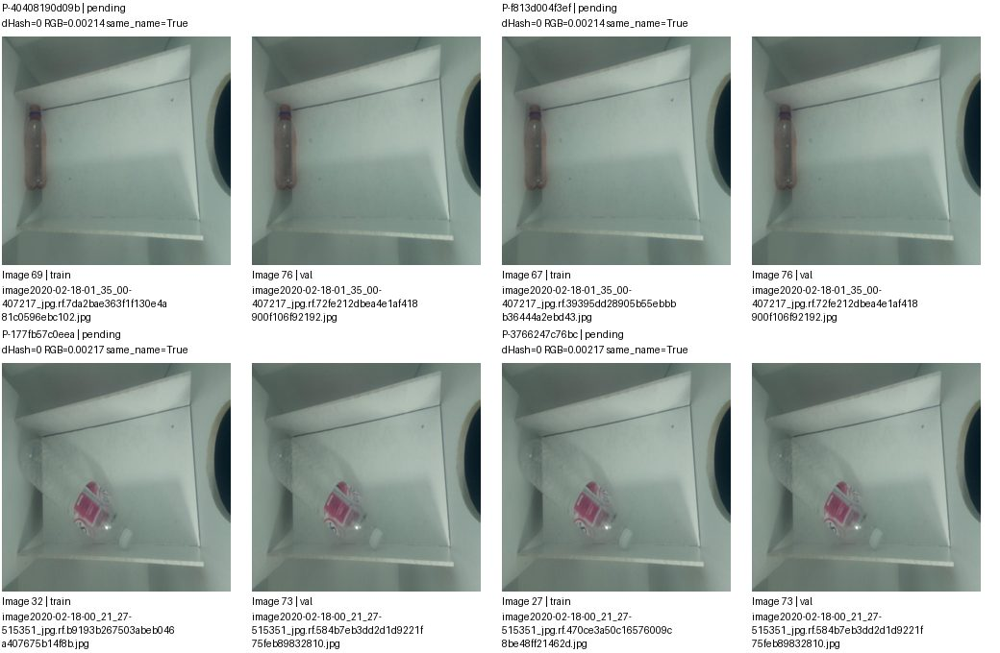

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-40408190d09b,images/train/image2020-02-18-01_35_00-407217_jpg.rf.7da2bae363f1f130e4a81c0596ebc102.jpg,images/val/image2020-02-18-01_35_00-407217_jpg.rf.72fe212dbea4e1af418900f106f92192.jpg,pending,
P-f813d004f3ef,images/train/image2020-02-18-01_35_00-407217_jpg.rf.39395dd28905b55ebbbb36444a2ebd43.jpg,images/val/image2020-02-18-01_35_00-407217_jpg.rf.72fe212dbea4e1af418900f106f92192.jpg,pending,
P-177fb57c0eea,images/train/image2020-02-18-00_21_27-515351_jpg.rf.b9193b267503abeb046a407675b14f8b.jpg,images/val/image2020-02-18-00_21_27-515351_jpg.rf.584b7eb3dd2d1d9221f75feb89832810.jpg,pending,
P-3766247c76bc,images/train/image2020-02-18-00_21_27-515351_jpg.rf.470ce3a50c16576009c8be48ff21462d.jpg,images/val/image2020-02-18-00_21_27-515351_jpg.rf.584b7eb3dd2d1d9221f75feb89832810.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 52/166 G-586696e3c556 | 77 ảnh, 388 cặp
Split: {'test': 2, 'train': 70, 'val': 5}
Quyết định: {'pending': 388}
Ảnh trang 2/13; cặp trang 2/97. Nhóm liên thông không phải kết luận trùng.


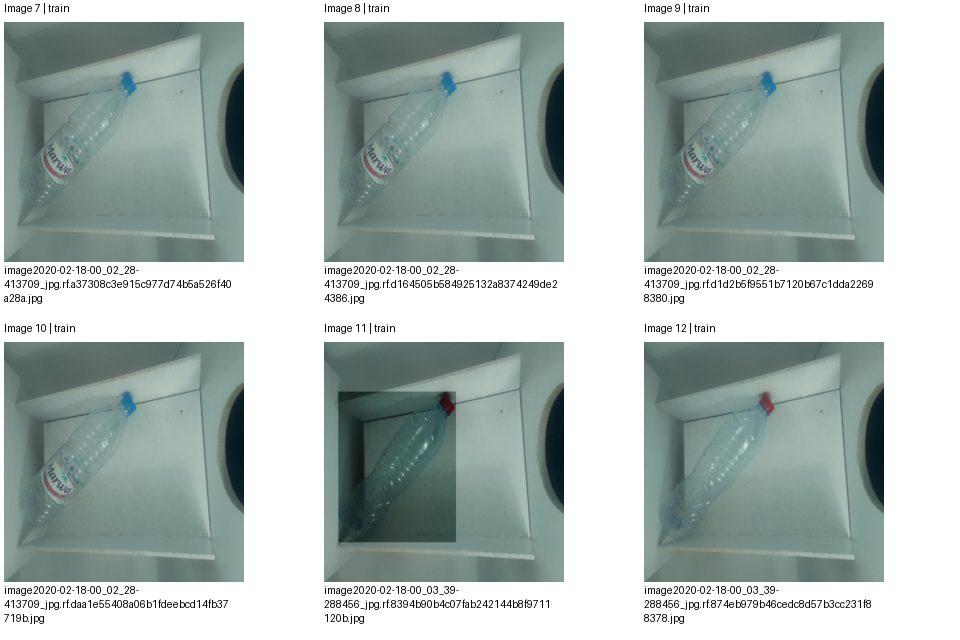

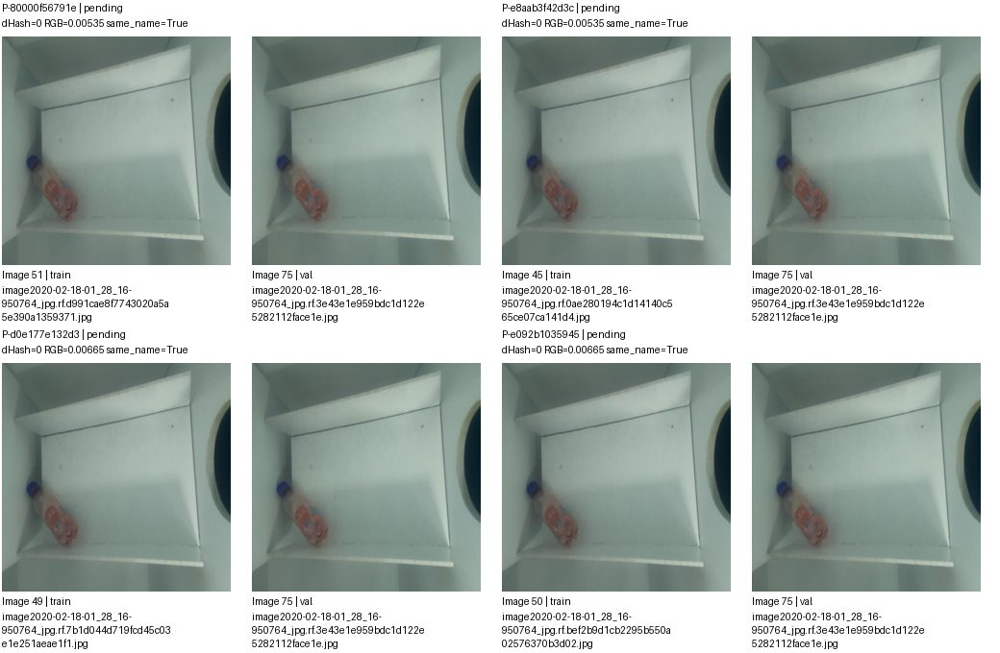

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-80000f56791e,images/train/image2020-02-18-01_28_16-950764_jpg.rf.d991cae8f7743020a5a5e390a1359371.jpg,images/val/image2020-02-18-01_28_16-950764_jpg.rf.3e43e1e959bdc1d122e5282112face1e.jpg,pending,
P-e8aab3f42d3c,images/train/image2020-02-18-01_28_16-950764_jpg.rf.0ae280194c1d14140c565ce07ca141d4.jpg,images/val/image2020-02-18-01_28_16-950764_jpg.rf.3e43e1e959bdc1d122e5282112face1e.jpg,pending,
P-d0e177e132d3,images/train/image2020-02-18-01_28_16-950764_jpg.rf.7b1d044d719fcd45c03e1e251aeae1f1.jpg,images/val/image2020-02-18-01_28_16-950764_jpg.rf.3e43e1e959bdc1d122e5282112face1e.jpg,pending,
P-e092b1035945,images/train/image2020-02-18-01_28_16-950764_jpg.rf.bef2b9d1cb2295b550a02576370b3d02.jpg,images/val/image2020-02-18-01_28_16-950764_jpg.rf.3e43e1e959bdc1d122e5282112face1e.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 52/166 G-586696e3c556 | 77 ảnh, 388 cặp
Split: {'test': 2, 'train': 70, 'val': 5}
Quyết định: {'pending': 388}
Ảnh trang 3/13; cặp trang 3/97. Nhóm liên thông không phải kết luận trùng.


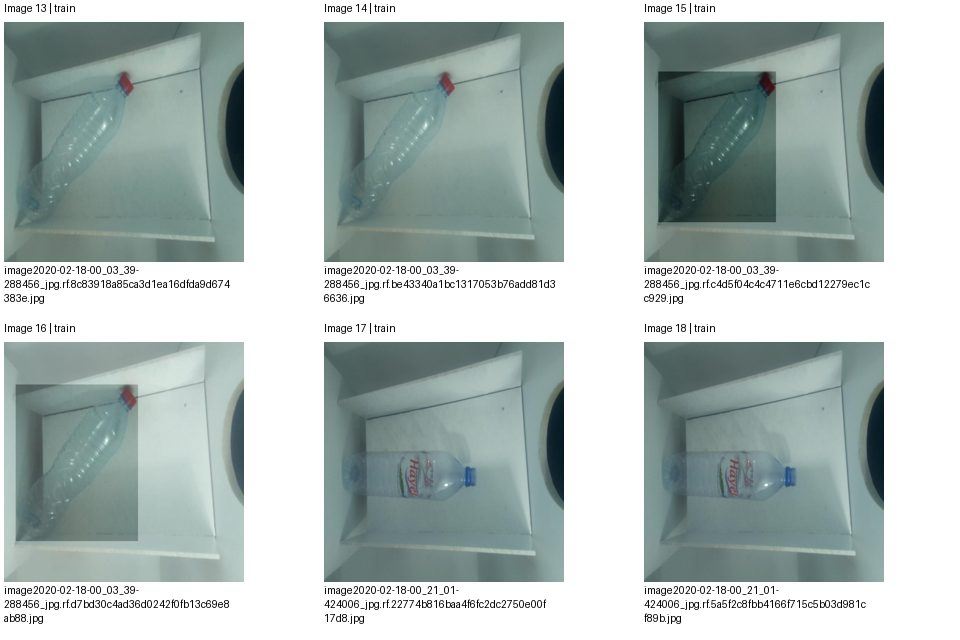

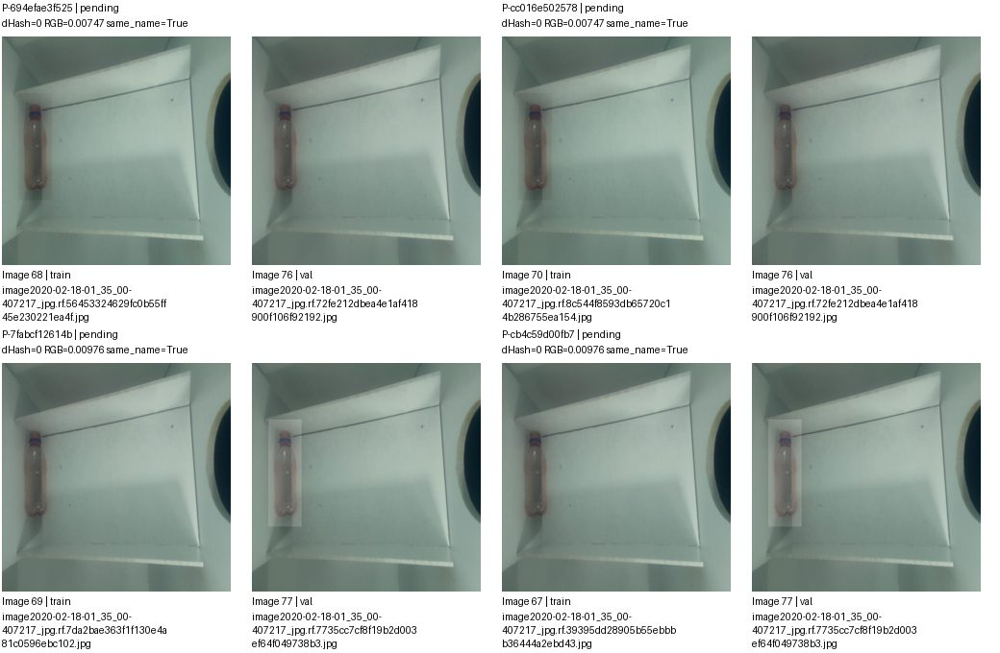

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-694efae3f525,images/train/image2020-02-18-01_35_00-407217_jpg.rf.56453324629fc0b55ff45e230221ea4f.jpg,images/val/image2020-02-18-01_35_00-407217_jpg.rf.72fe212dbea4e1af418900f106f92192.jpg,pending,
P-cc016e502578,images/train/image2020-02-18-01_35_00-407217_jpg.rf.8c544f8593db65720c14b286755ea154.jpg,images/val/image2020-02-18-01_35_00-407217_jpg.rf.72fe212dbea4e1af418900f106f92192.jpg,pending,
P-7fabcf12614b,images/train/image2020-02-18-01_35_00-407217_jpg.rf.7da2bae363f1f130e4a81c0596ebc102.jpg,images/val/image2020-02-18-01_35_00-407217_jpg.rf.7735cc7cf8f19b2d003ef64f049738b3.jpg,pending,
P-cb4c59d00fb7,images/train/image2020-02-18-01_35_00-407217_jpg.rf.39395dd28905b55ebbbb36444a2ebd43.jpg,images/val/image2020-02-18-01_35_00-407217_jpg.rf.7735cc7cf8f19b2d003ef64f049738b3.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 52/166 G-586696e3c556 | 77 ảnh, 388 cặp
Split: {'test': 2, 'train': 70, 'val': 5}
Quyết định: {'pending': 388}
Ảnh trang 4/13; cặp trang 4/97. Nhóm liên thông không phải kết luận trùng.


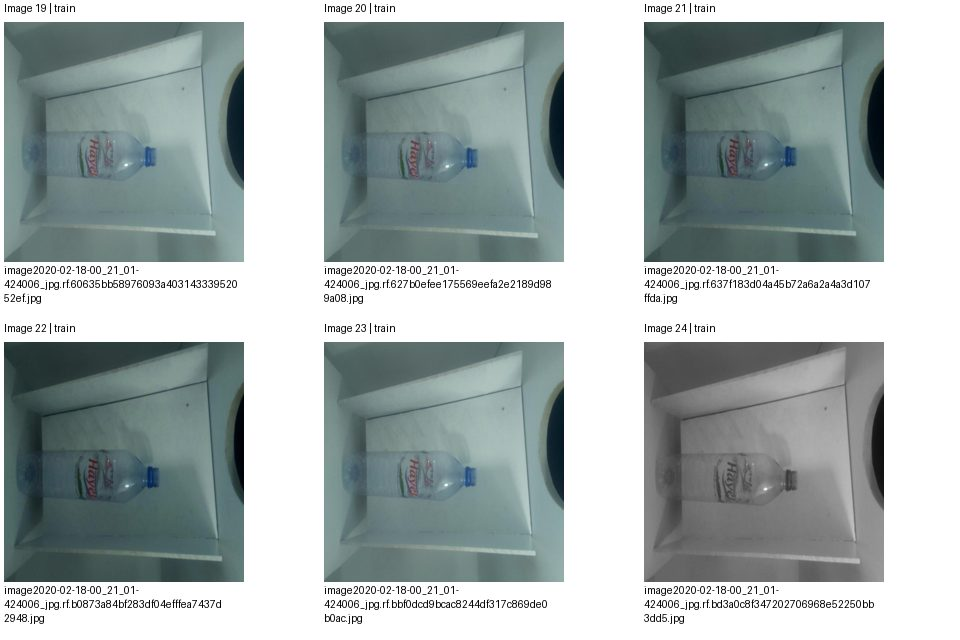

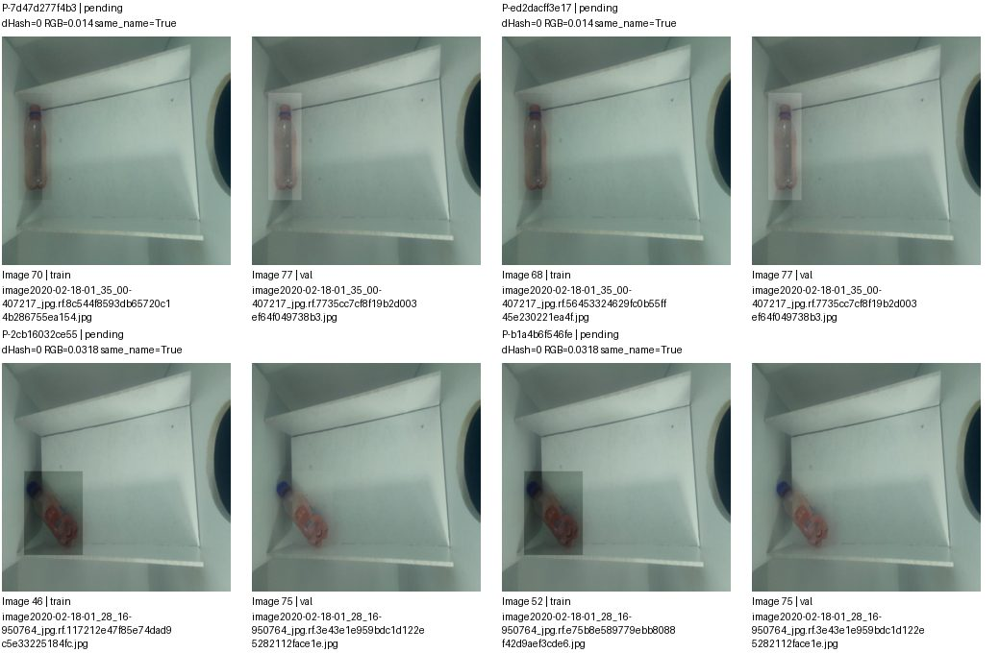

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-7d47d277f4b3,images/train/image2020-02-18-01_35_00-407217_jpg.rf.8c544f8593db65720c14b286755ea154.jpg,images/val/image2020-02-18-01_35_00-407217_jpg.rf.7735cc7cf8f19b2d003ef64f049738b3.jpg,pending,
P-ed2dacff3e17,images/train/image2020-02-18-01_35_00-407217_jpg.rf.56453324629fc0b55ff45e230221ea4f.jpg,images/val/image2020-02-18-01_35_00-407217_jpg.rf.7735cc7cf8f19b2d003ef64f049738b3.jpg,pending,
P-2cb16032ce55,images/train/image2020-02-18-01_28_16-950764_jpg.rf.117212e47f85e74dad9c5e33225184fc.jpg,images/val/image2020-02-18-01_28_16-950764_jpg.rf.3e43e1e959bdc1d122e5282112face1e.jpg,pending,
P-b1a4b6f546fe,images/train/image2020-02-18-01_28_16-950764_jpg.rf.e75b8e589779ebb8088f42d9aef3cde6.jpg,images/val/image2020-02-18-01_28_16-950764_jpg.rf.3e43e1e959bdc1d122e5282112face1e.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 52/166 G-586696e3c556 | 77 ảnh, 388 cặp
Split: {'test': 2, 'train': 70, 'val': 5}
Quyết định: {'pending': 388}
Ảnh trang 5/13; cặp trang 5/97. Nhóm liên thông không phải kết luận trùng.


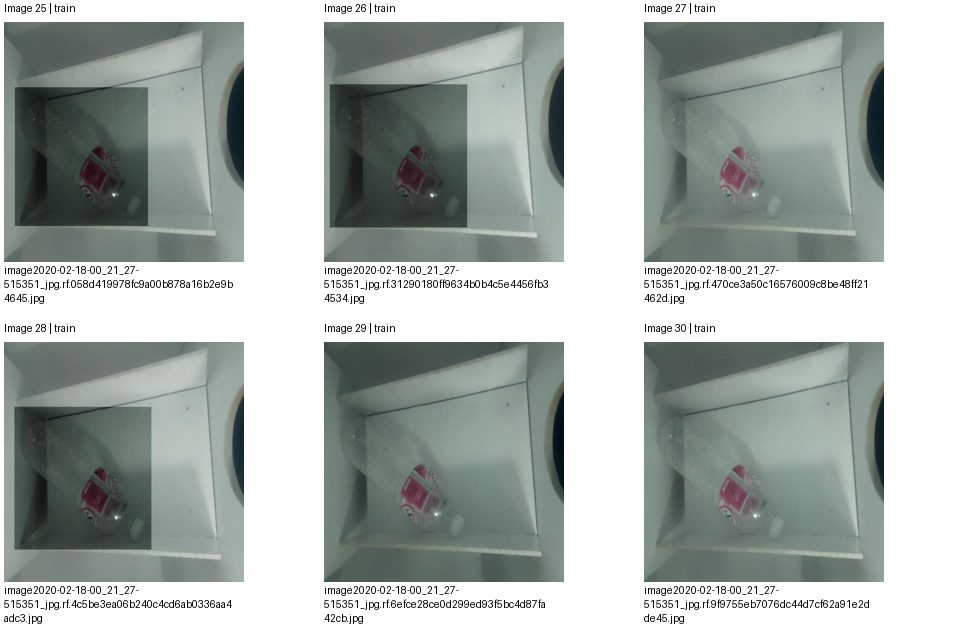

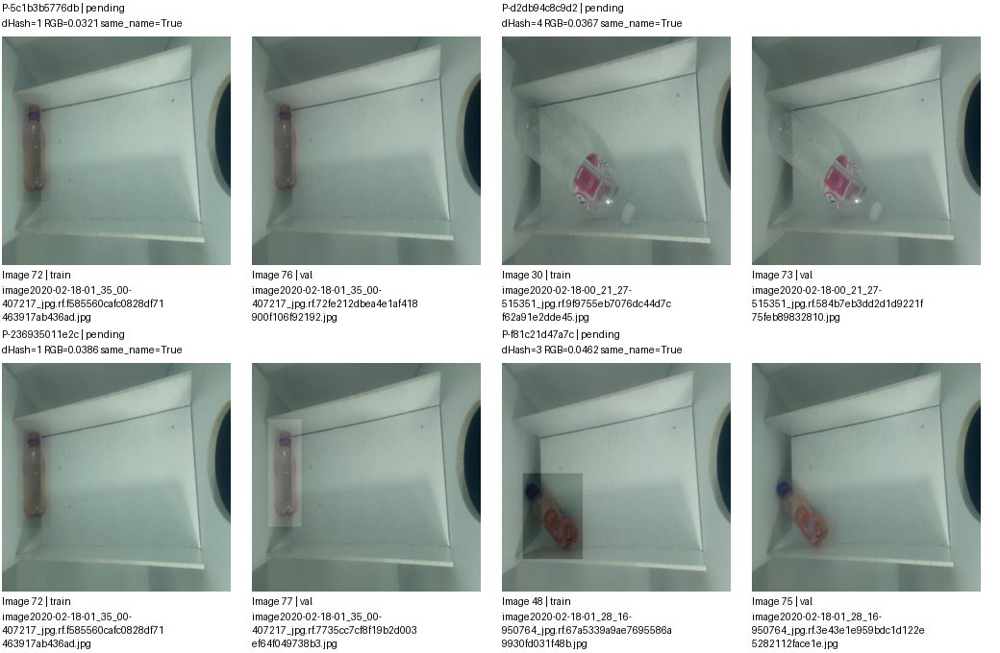

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-5c1b3b5776db,images/train/image2020-02-18-01_35_00-407217_jpg.rf.f585560cafc0828df71463917ab436ad.jpg,images/val/image2020-02-18-01_35_00-407217_jpg.rf.72fe212dbea4e1af418900f106f92192.jpg,pending,
P-d2db94c8c9d2,images/train/image2020-02-18-00_21_27-515351_jpg.rf.9f9755eb7076dc44d7cf62a91e2dde45.jpg,images/val/image2020-02-18-00_21_27-515351_jpg.rf.584b7eb3dd2d1d9221f75feb89832810.jpg,pending,
P-236935011e2c,images/train/image2020-02-18-01_35_00-407217_jpg.rf.f585560cafc0828df71463917ab436ad.jpg,images/val/image2020-02-18-01_35_00-407217_jpg.rf.7735cc7cf8f19b2d003ef64f049738b3.jpg,pending,
P-f81c21d47a7c,images/train/image2020-02-18-01_28_16-950764_jpg.rf.67a5339a9ae7695586a9930fd031f48b.jpg,images/val/image2020-02-18-01_28_16-950764_jpg.rf.3e43e1e959bdc1d122e5282112face1e.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 52/166 G-586696e3c556 | 77 ảnh, 388 cặp
Split: {'test': 2, 'train': 70, 'val': 5}
Quyết định: {'pending': 388}
Ảnh trang 6/13; cặp trang 6/97. Nhóm liên thông không phải kết luận trùng.


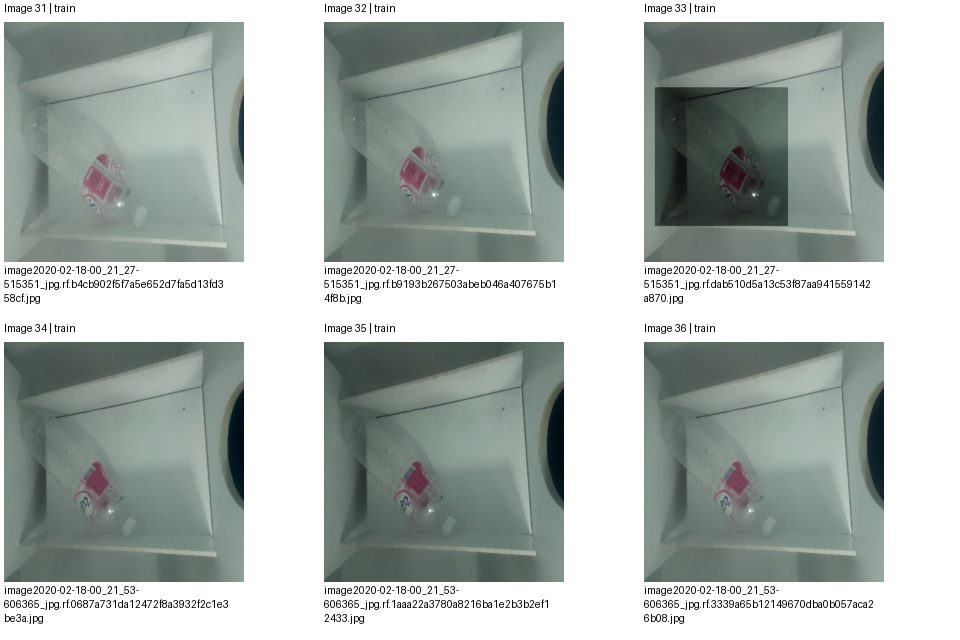

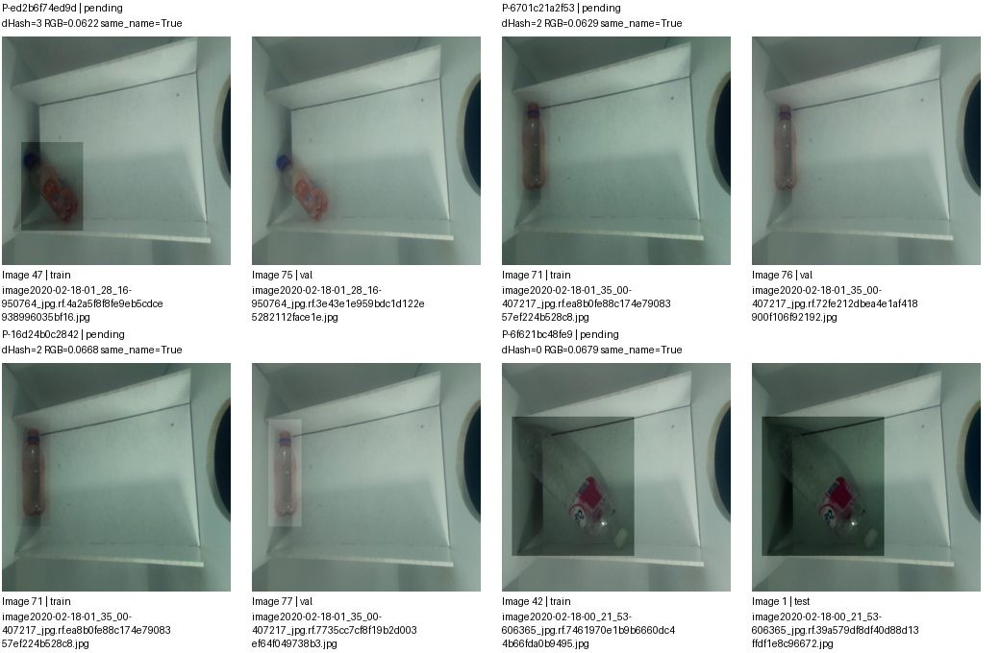

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-ed2b6f74ed9d,images/train/image2020-02-18-01_28_16-950764_jpg.rf.4a2a5f8f8fe9eb5cdce938996035bf16.jpg,images/val/image2020-02-18-01_28_16-950764_jpg.rf.3e43e1e959bdc1d122e5282112face1e.jpg,pending,
P-6701c21a2f53,images/train/image2020-02-18-01_35_00-407217_jpg.rf.ea8b0fe88c174e7908357ef224b528c8.jpg,images/val/image2020-02-18-01_35_00-407217_jpg.rf.72fe212dbea4e1af418900f106f92192.jpg,pending,
P-16d24b0c2842,images/train/image2020-02-18-01_35_00-407217_jpg.rf.ea8b0fe88c174e7908357ef224b528c8.jpg,images/val/image2020-02-18-01_35_00-407217_jpg.rf.7735cc7cf8f19b2d003ef64f049738b3.jpg,pending,
P-6f621bc48fe9,images/train/image2020-02-18-00_21_53-606365_jpg.rf.7461970e1b9b6660dc44b66fda0b9495.jpg,images/test/image2020-02-18-00_21_53-606365_jpg.rf.39a579df8df40d88d13ffdf1e8c96672.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 52/166 G-586696e3c556 | 77 ảnh, 388 cặp
Split: {'test': 2, 'train': 70, 'val': 5}
Quyết định: {'pending': 388}
Ảnh trang 7/13; cặp trang 7/97. Nhóm liên thông không phải kết luận trùng.


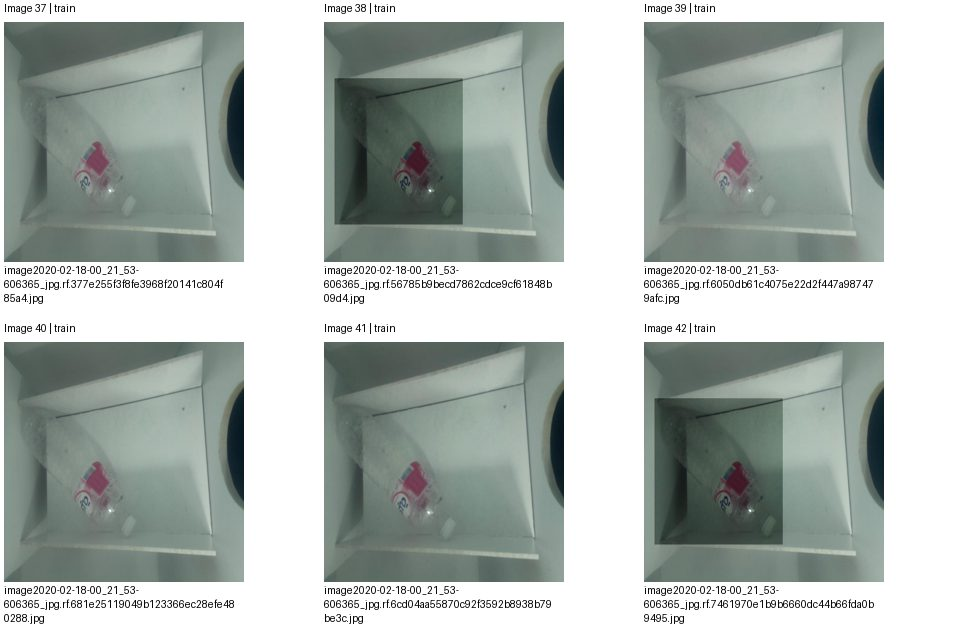

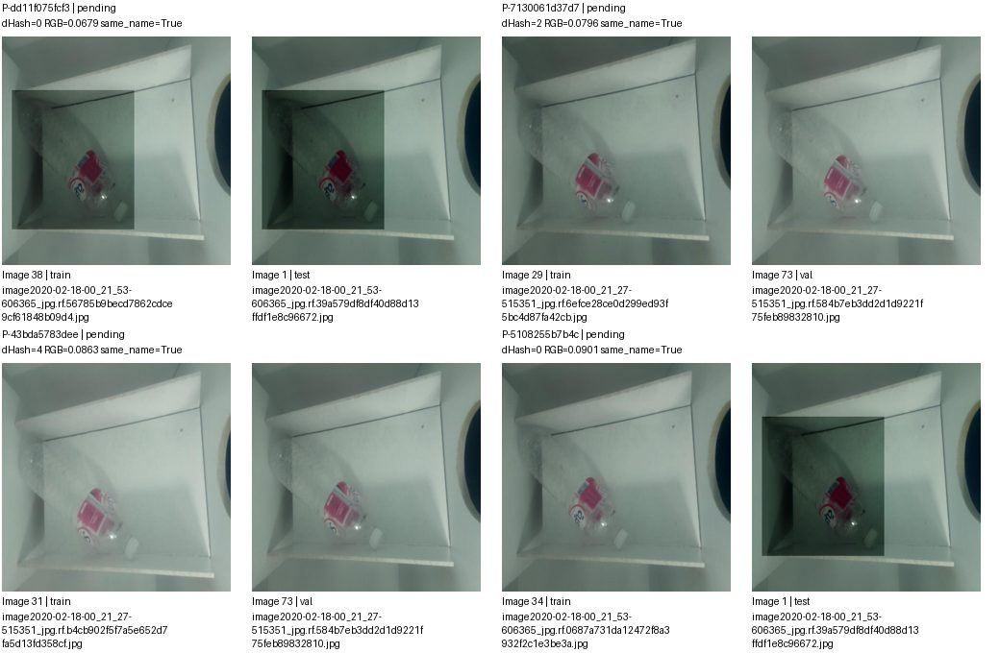

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-dd11f075fcf3,images/train/image2020-02-18-00_21_53-606365_jpg.rf.56785b9becd7862cdce9cf61848b09d4.jpg,images/test/image2020-02-18-00_21_53-606365_jpg.rf.39a579df8df40d88d13ffdf1e8c96672.jpg,pending,
P-7130061d37d7,images/train/image2020-02-18-00_21_27-515351_jpg.rf.6efce28ce0d299ed93f5bc4d87fa42cb.jpg,images/val/image2020-02-18-00_21_27-515351_jpg.rf.584b7eb3dd2d1d9221f75feb89832810.jpg,pending,
P-43bda5783dee,images/train/image2020-02-18-00_21_27-515351_jpg.rf.b4cb902f5f7a5e652d7fa5d13fd358cf.jpg,images/val/image2020-02-18-00_21_27-515351_jpg.rf.584b7eb3dd2d1d9221f75feb89832810.jpg,pending,
P-5108255b7b4c,images/train/image2020-02-18-00_21_53-606365_jpg.rf.0687a731da12472f8a3932f2c1e3be3a.jpg,images/test/image2020-02-18-00_21_53-606365_jpg.rf.39a579df8df40d88d13ffdf1e8c96672.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 52/166 G-586696e3c556 | 77 ảnh, 388 cặp
Split: {'test': 2, 'train': 70, 'val': 5}
Quyết định: {'pending': 388}
Ảnh trang 8/13; cặp trang 8/97. Nhóm liên thông không phải kết luận trùng.


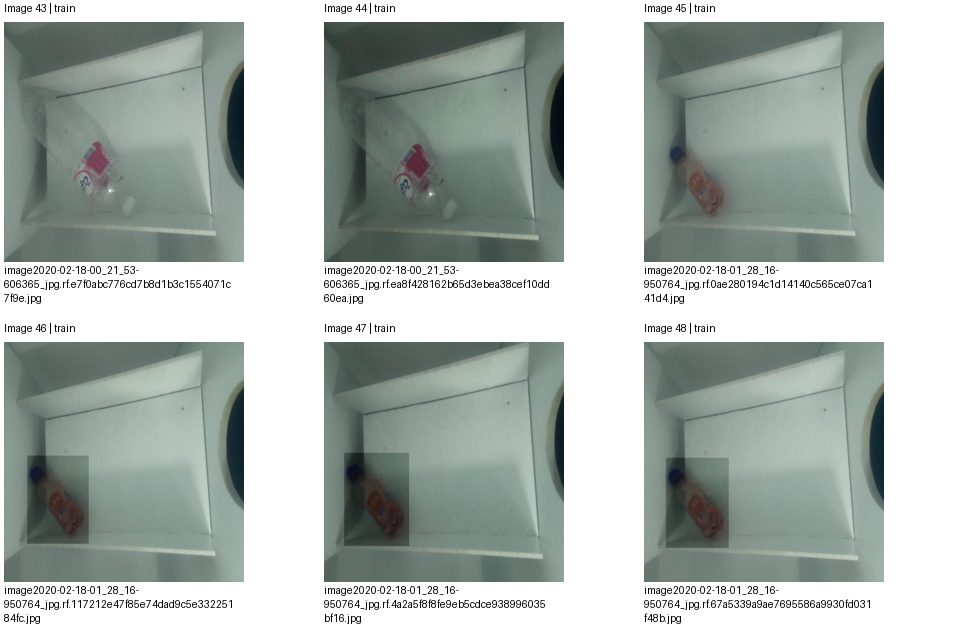

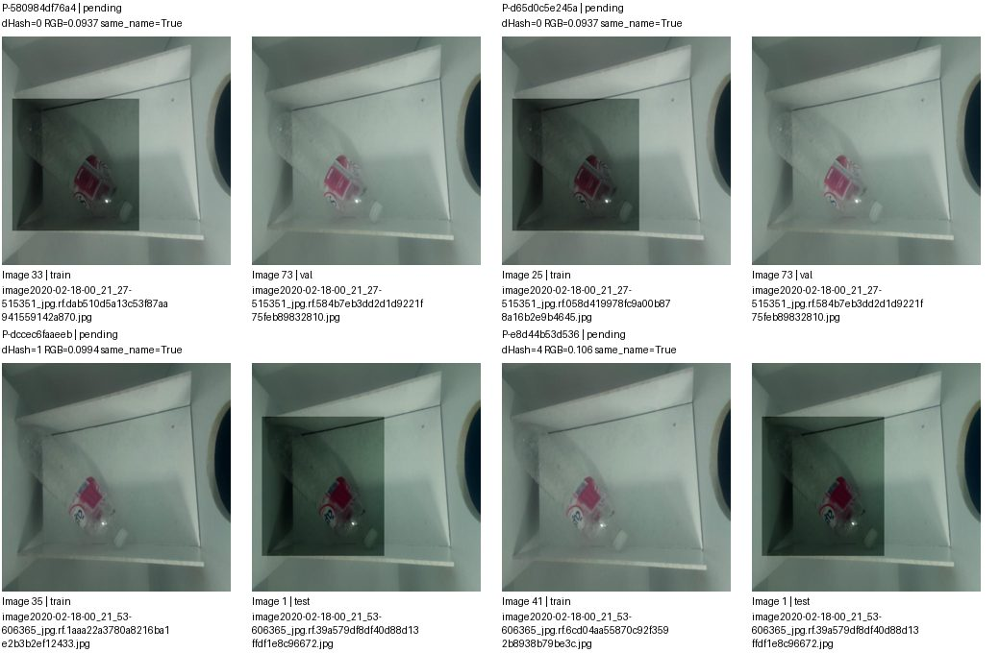

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-580984df76a4,images/train/image2020-02-18-00_21_27-515351_jpg.rf.dab510d5a13c53f87aa941559142a870.jpg,images/val/image2020-02-18-00_21_27-515351_jpg.rf.584b7eb3dd2d1d9221f75feb89832810.jpg,pending,
P-d65d0c5e245a,images/train/image2020-02-18-00_21_27-515351_jpg.rf.058d419978fc9a00b878a16b2e9b4645.jpg,images/val/image2020-02-18-00_21_27-515351_jpg.rf.584b7eb3dd2d1d9221f75feb89832810.jpg,pending,
P-dccec6faaeeb,images/train/image2020-02-18-00_21_53-606365_jpg.rf.1aaa22a3780a8216ba1e2b3b2ef12433.jpg,images/test/image2020-02-18-00_21_53-606365_jpg.rf.39a579df8df40d88d13ffdf1e8c96672.jpg,pending,
P-e8d44b53d536,images/train/image2020-02-18-00_21_53-606365_jpg.rf.6cd04aa55870c92f3592b8938b79be3c.jpg,images/test/image2020-02-18-00_21_53-606365_jpg.rf.39a579df8df40d88d13ffdf1e8c96672.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 52/166 G-586696e3c556 | 77 ảnh, 388 cặp
Split: {'test': 2, 'train': 70, 'val': 5}
Quyết định: {'pending': 388}
Ảnh trang 9/13; cặp trang 9/97. Nhóm liên thông không phải kết luận trùng.


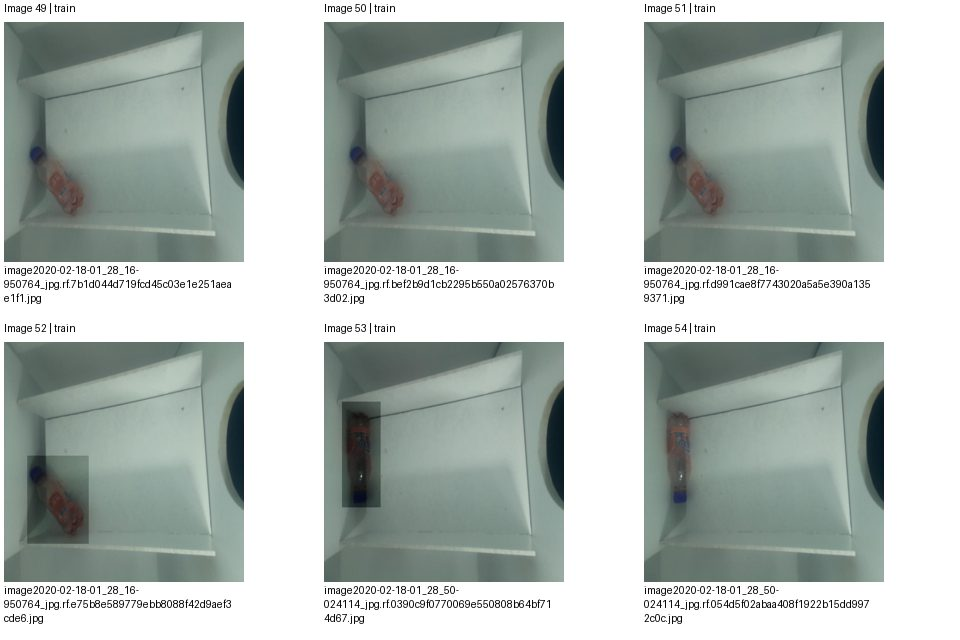

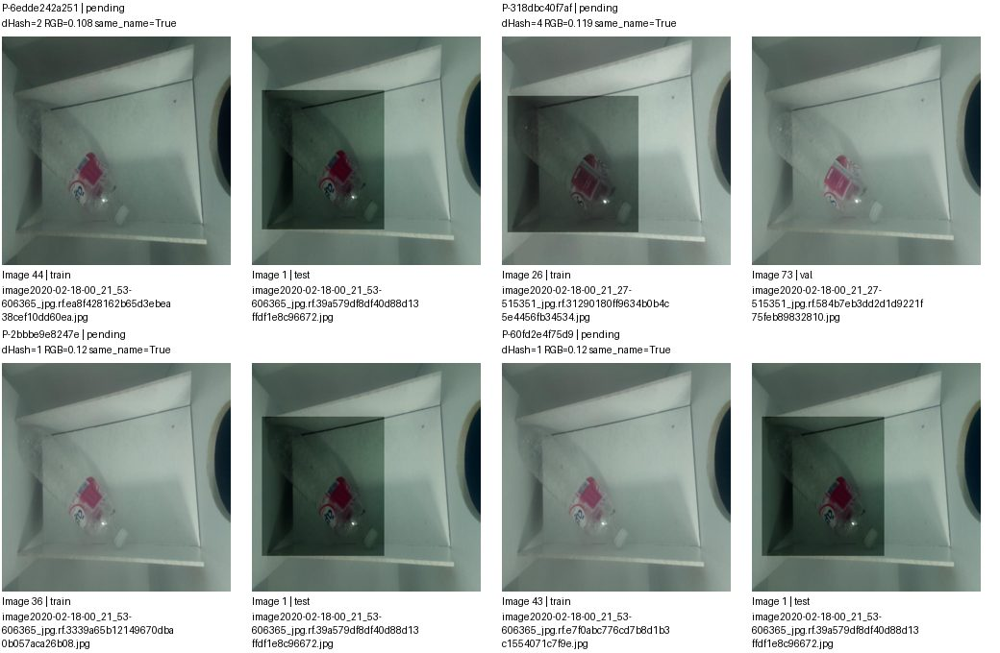

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-6edde242a251,images/train/image2020-02-18-00_21_53-606365_jpg.rf.ea8f428162b65d3ebea38cef10dd60ea.jpg,images/test/image2020-02-18-00_21_53-606365_jpg.rf.39a579df8df40d88d13ffdf1e8c96672.jpg,pending,
P-318dbc40f7af,images/train/image2020-02-18-00_21_27-515351_jpg.rf.31290180ff9634b0b4c5e4456fb34534.jpg,images/val/image2020-02-18-00_21_27-515351_jpg.rf.584b7eb3dd2d1d9221f75feb89832810.jpg,pending,
P-2bbbe9e8247e,images/train/image2020-02-18-00_21_53-606365_jpg.rf.3339a65b12149670dba0b057aca26b08.jpg,images/test/image2020-02-18-00_21_53-606365_jpg.rf.39a579df8df40d88d13ffdf1e8c96672.jpg,pending,
P-60fd2e4f75d9,images/train/image2020-02-18-00_21_53-606365_jpg.rf.e7f0abc776cd7b8d1b3c1554071c7f9e.jpg,images/test/image2020-02-18-00_21_53-606365_jpg.rf.39a579df8df40d88d13ffdf1e8c96672.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 52/166 G-586696e3c556 | 77 ảnh, 388 cặp
Split: {'test': 2, 'train': 70, 'val': 5}
Quyết định: {'pending': 388}
Ảnh trang 10/13; cặp trang 10/97. Nhóm liên thông không phải kết luận trùng.


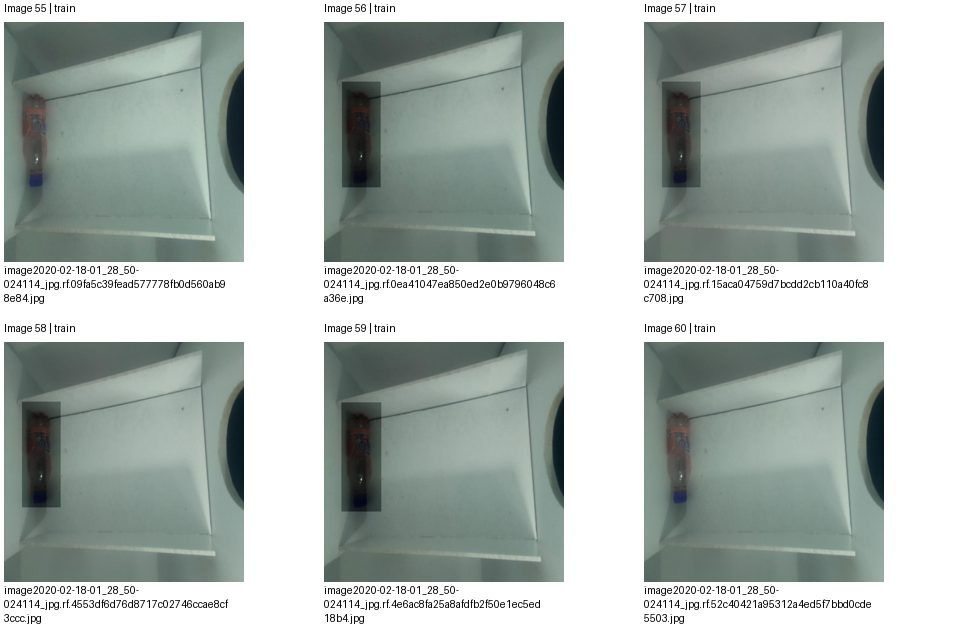

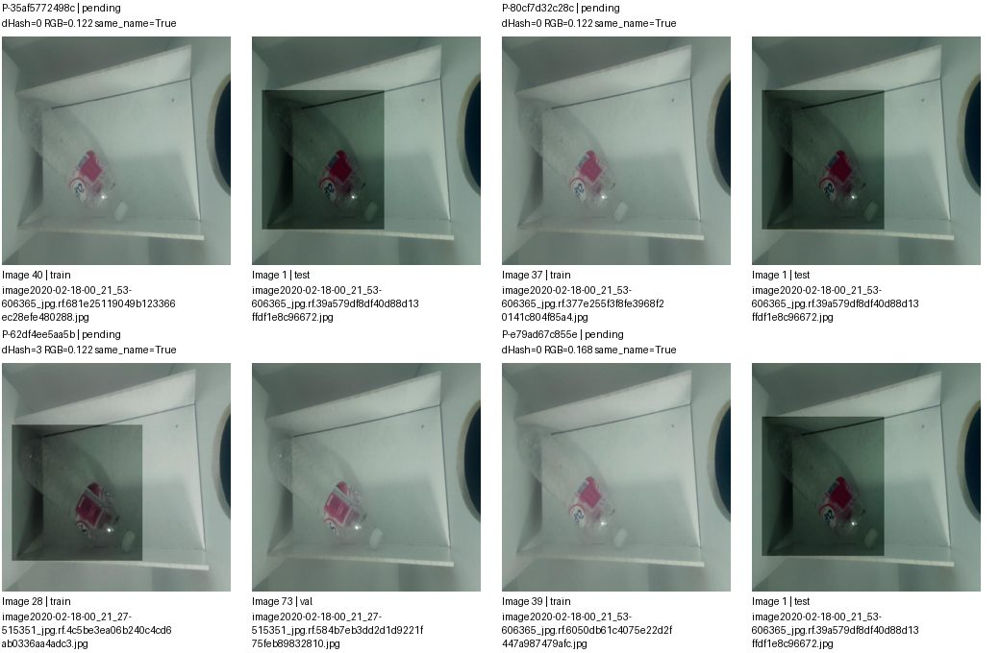

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-35af5772498c,images/train/image2020-02-18-00_21_53-606365_jpg.rf.681e25119049b123366ec28efe480288.jpg,images/test/image2020-02-18-00_21_53-606365_jpg.rf.39a579df8df40d88d13ffdf1e8c96672.jpg,pending,
P-80cf7d32c28c,images/train/image2020-02-18-00_21_53-606365_jpg.rf.377e255f3f8fe3968f20141c804f85a4.jpg,images/test/image2020-02-18-00_21_53-606365_jpg.rf.39a579df8df40d88d13ffdf1e8c96672.jpg,pending,
P-62df4ee5aa5b,images/train/image2020-02-18-00_21_27-515351_jpg.rf.4c5be3ea06b240c4cd6ab0336aa4adc3.jpg,images/val/image2020-02-18-00_21_27-515351_jpg.rf.584b7eb3dd2d1d9221f75feb89832810.jpg,pending,
P-e79ad67c855e,images/train/image2020-02-18-00_21_53-606365_jpg.rf.6050db61c4075e22d2f447a987479afc.jpg,images/test/image2020-02-18-00_21_53-606365_jpg.rf.39a579df8df40d88d13ffdf1e8c96672.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 52/166 G-586696e3c556 | 77 ảnh, 388 cặp
Split: {'test': 2, 'train': 70, 'val': 5}
Quyết định: {'pending': 388}
Ảnh trang 11/13; cặp trang 11/97. Nhóm liên thông không phải kết luận trùng.


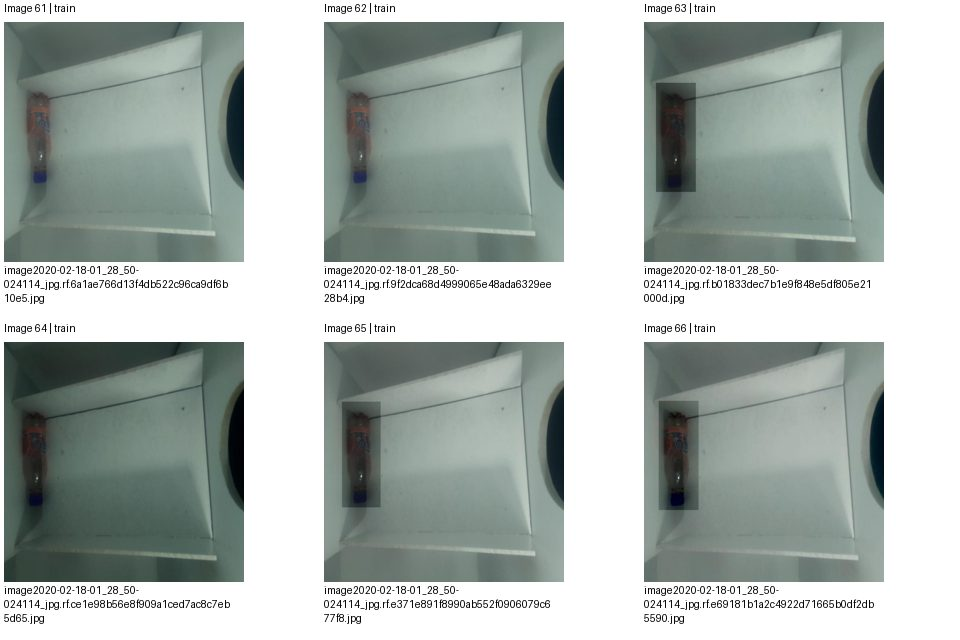

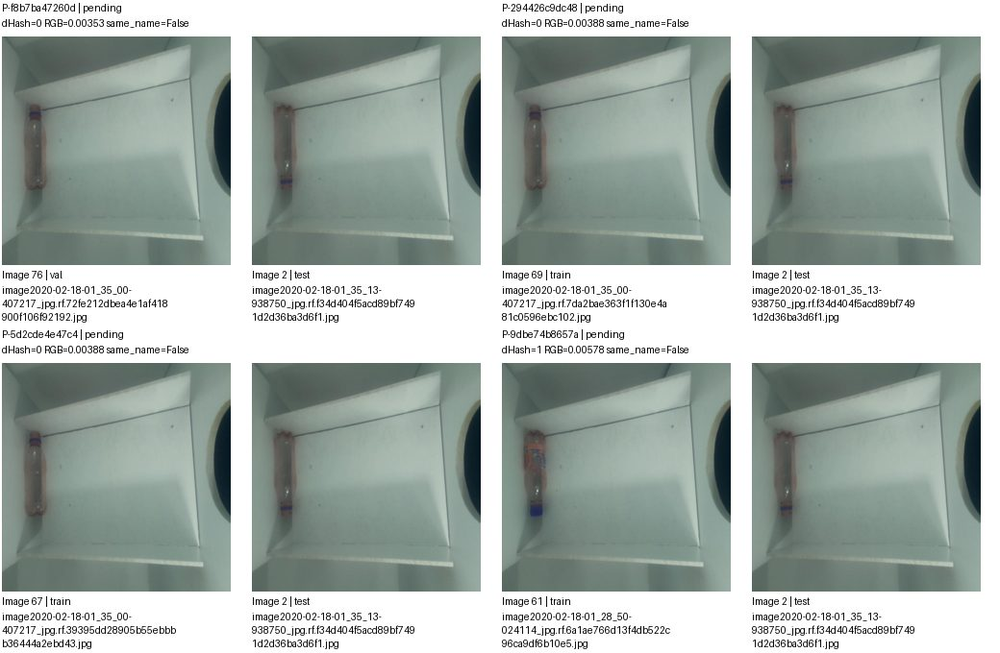

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-f8b7ba47260d,images/val/image2020-02-18-01_35_00-407217_jpg.rf.72fe212dbea4e1af418900f106f92192.jpg,images/test/image2020-02-18-01_35_13-938750_jpg.rf.f34d404f5acd89bf7491d2d36ba3d6f1.jpg,pending,
P-294426c9dc48,images/train/image2020-02-18-01_35_00-407217_jpg.rf.7da2bae363f1f130e4a81c0596ebc102.jpg,images/test/image2020-02-18-01_35_13-938750_jpg.rf.f34d404f5acd89bf7491d2d36ba3d6f1.jpg,pending,
P-5d2cde4e47c4,images/train/image2020-02-18-01_35_00-407217_jpg.rf.39395dd28905b55ebbbb36444a2ebd43.jpg,images/test/image2020-02-18-01_35_13-938750_jpg.rf.f34d404f5acd89bf7491d2d36ba3d6f1.jpg,pending,
P-9dbe74b8657a,images/train/image2020-02-18-01_28_50-024114_jpg.rf.6a1ae766d13f4db522c96ca9df6b10e5.jpg,images/test/image2020-02-18-01_35_13-938750_jpg.rf.f34d404f5acd89bf7491d2d36ba3d6f1.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 52/166 G-586696e3c556 | 77 ảnh, 388 cặp
Split: {'test': 2, 'train': 70, 'val': 5}
Quyết định: {'pending': 388}
Ảnh trang 12/13; cặp trang 12/97. Nhóm liên thông không phải kết luận trùng.


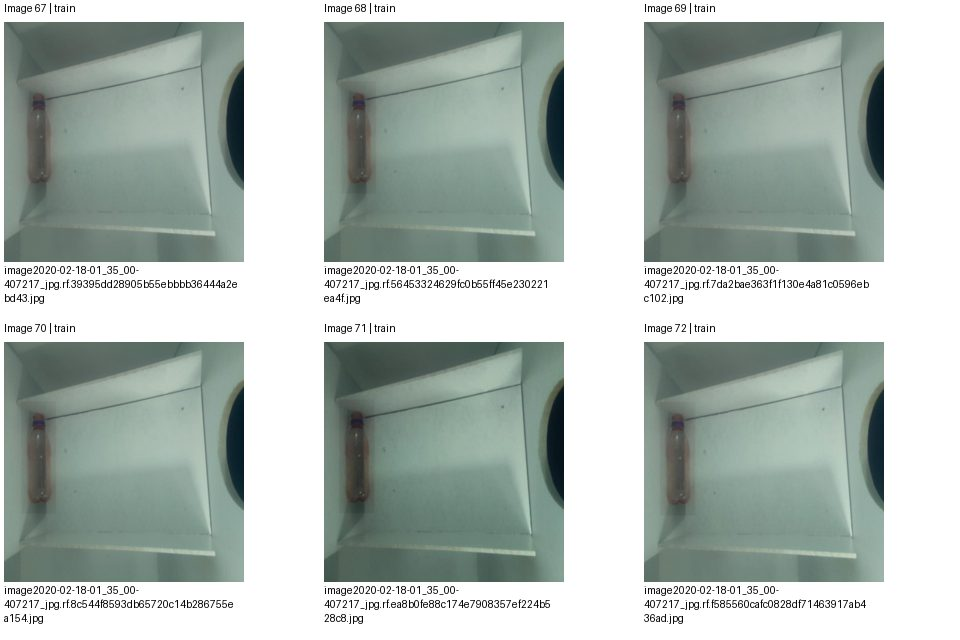

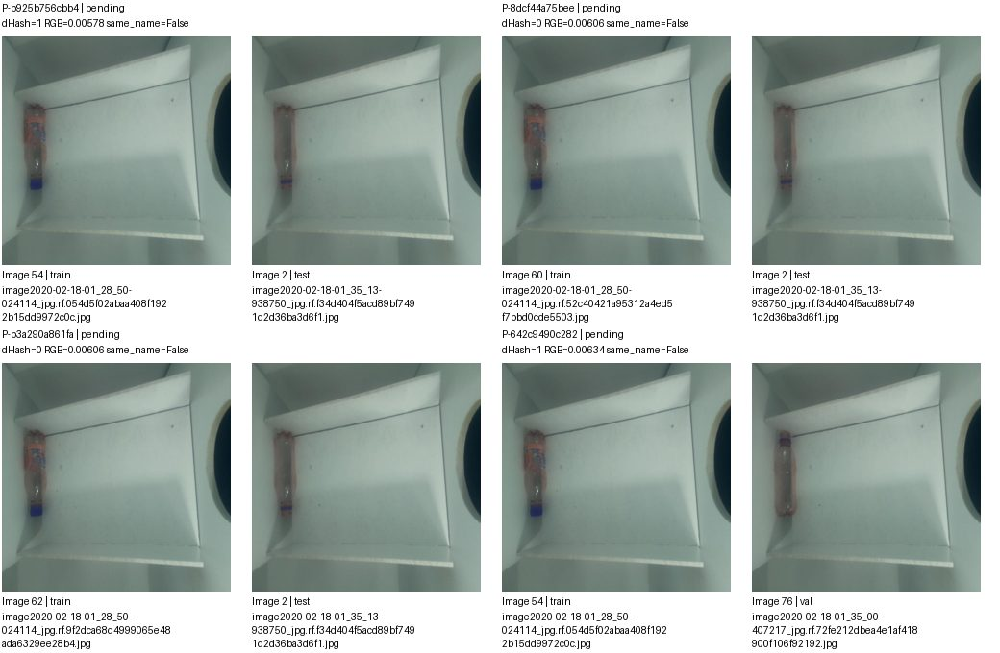

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-b925b756cbb4,images/train/image2020-02-18-01_28_50-024114_jpg.rf.054d5f02abaa408f1922b15dd9972c0c.jpg,images/test/image2020-02-18-01_35_13-938750_jpg.rf.f34d404f5acd89bf7491d2d36ba3d6f1.jpg,pending,
P-8dcf44a75bee,images/train/image2020-02-18-01_28_50-024114_jpg.rf.52c40421a95312a4ed5f7bbd0cde5503.jpg,images/test/image2020-02-18-01_35_13-938750_jpg.rf.f34d404f5acd89bf7491d2d36ba3d6f1.jpg,pending,
P-b3a290a861fa,images/train/image2020-02-18-01_28_50-024114_jpg.rf.9f2dca68d4999065e48ada6329ee28b4.jpg,images/test/image2020-02-18-01_35_13-938750_jpg.rf.f34d404f5acd89bf7491d2d36ba3d6f1.jpg,pending,
P-642c9490c282,images/train/image2020-02-18-01_28_50-024114_jpg.rf.054d5f02abaa408f1922b15dd9972c0c.jpg,images/val/image2020-02-18-01_35_00-407217_jpg.rf.72fe212dbea4e1af418900f106f92192.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 52/166 G-586696e3c556 | 77 ảnh, 388 cặp
Split: {'test': 2, 'train': 70, 'val': 5}
Quyết định: {'pending': 388}
Ảnh trang 13/13; cặp trang 13/97. Nhóm liên thông không phải kết luận trùng.


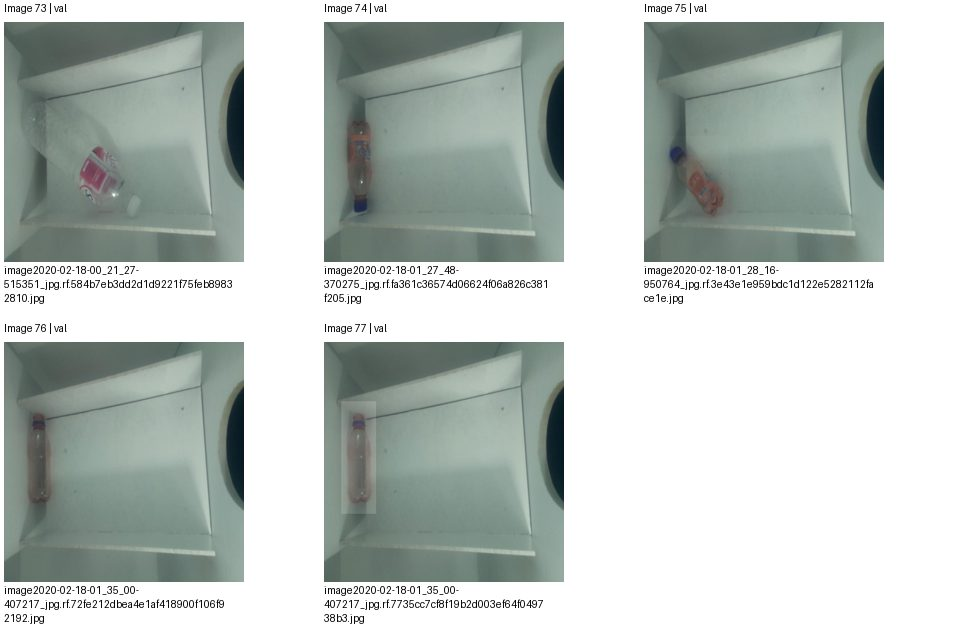

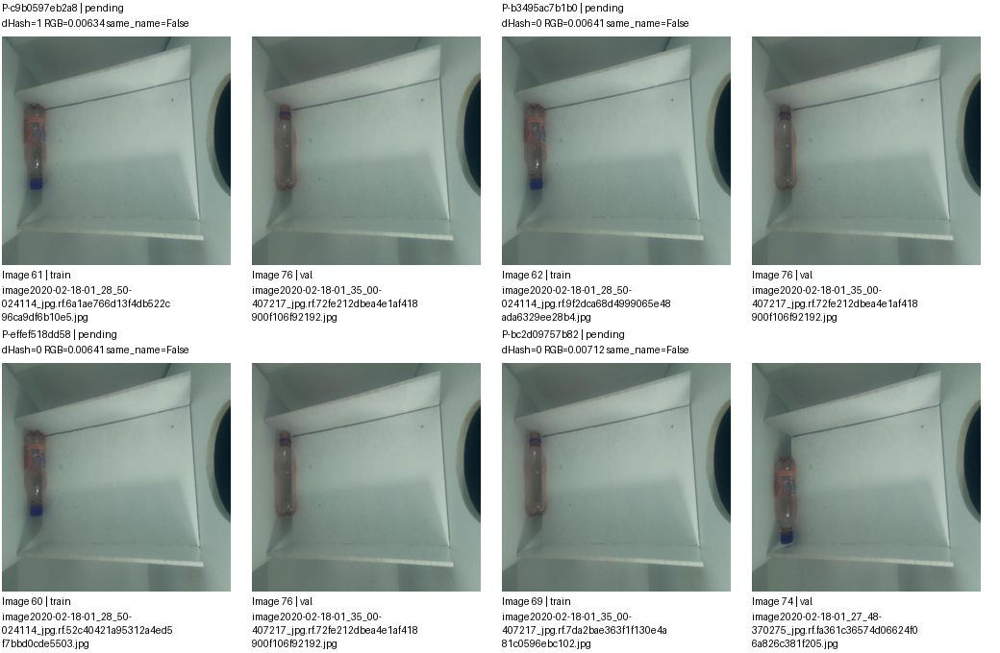

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-c9b0597eb2a8,images/train/image2020-02-18-01_28_50-024114_jpg.rf.6a1ae766d13f4db522c96ca9df6b10e5.jpg,images/val/image2020-02-18-01_35_00-407217_jpg.rf.72fe212dbea4e1af418900f106f92192.jpg,pending,
P-b3495ac7b1b0,images/train/image2020-02-18-01_28_50-024114_jpg.rf.9f2dca68d4999065e48ada6329ee28b4.jpg,images/val/image2020-02-18-01_35_00-407217_jpg.rf.72fe212dbea4e1af418900f106f92192.jpg,pending,
P-effef518dd58,images/train/image2020-02-18-01_28_50-024114_jpg.rf.52c40421a95312a4ed5f7bbd0cde5503.jpg,images/val/image2020-02-18-01_35_00-407217_jpg.rf.72fe212dbea4e1af418900f106f92192.jpg,pending,
P-bc2d09757b82,images/train/image2020-02-18-01_35_00-407217_jpg.rf.7da2bae363f1f130e4a81c0596ebc102.jpg,images/val/image2020-02-18-01_27_48-370275_jpg.rf.fa361c36574d06624f06a826c381f205.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 52/166 G-586696e3c556 | 77 ảnh, 388 cặp
Split: {'test': 2, 'train': 70, 'val': 5}
Quyết định: {'pending': 388}
Ảnh trang None/13; cặp trang 14/97. Nhóm liên thông không phải kết luận trùng.


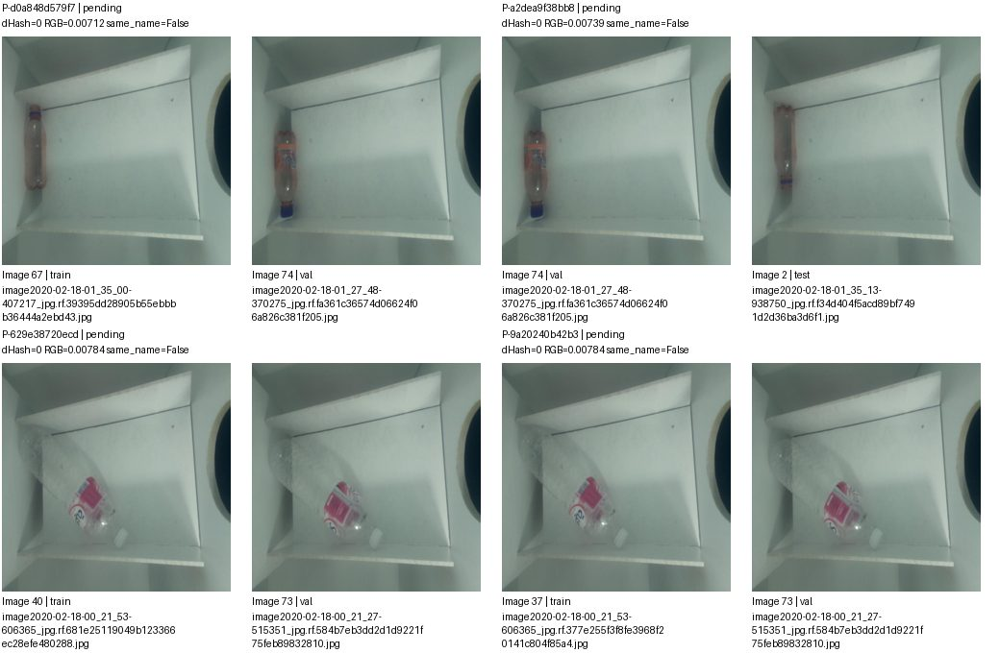

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-d0a848d579f7,images/train/image2020-02-18-01_35_00-407217_jpg.rf.39395dd28905b55ebbbb36444a2ebd43.jpg,images/val/image2020-02-18-01_27_48-370275_jpg.rf.fa361c36574d06624f06a826c381f205.jpg,pending,
P-a2dea9f38bb8,images/val/image2020-02-18-01_27_48-370275_jpg.rf.fa361c36574d06624f06a826c381f205.jpg,images/test/image2020-02-18-01_35_13-938750_jpg.rf.f34d404f5acd89bf7491d2d36ba3d6f1.jpg,pending,
P-629e38720ecd,images/train/image2020-02-18-00_21_53-606365_jpg.rf.681e25119049b123366ec28efe480288.jpg,images/val/image2020-02-18-00_21_27-515351_jpg.rf.584b7eb3dd2d1d9221f75feb89832810.jpg,pending,
P-9a20240b42b3,images/train/image2020-02-18-00_21_53-606365_jpg.rf.377e255f3f8fe3968f20141c804f85a4.jpg,images/val/image2020-02-18-00_21_27-515351_jpg.rf.584b7eb3dd2d1d9221f75feb89832810.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 52/166 G-586696e3c556 | 77 ảnh, 388 cặp
Split: {'test': 2, 'train': 70, 'val': 5}
Quyết định: {'pending': 388}
Ảnh trang None/13; cặp trang 15/97. Nhóm liên thông không phải kết luận trùng.


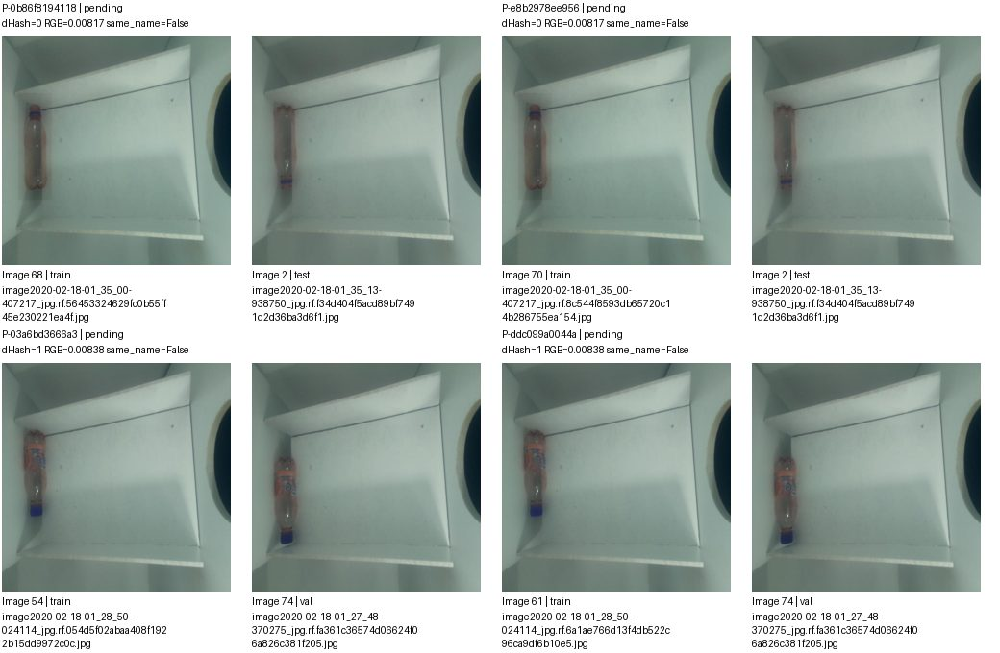

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-0b86f8194118,images/train/image2020-02-18-01_35_00-407217_jpg.rf.56453324629fc0b55ff45e230221ea4f.jpg,images/test/image2020-02-18-01_35_13-938750_jpg.rf.f34d404f5acd89bf7491d2d36ba3d6f1.jpg,pending,
P-e8b2978ee956,images/train/image2020-02-18-01_35_00-407217_jpg.rf.8c544f8593db65720c14b286755ea154.jpg,images/test/image2020-02-18-01_35_13-938750_jpg.rf.f34d404f5acd89bf7491d2d36ba3d6f1.jpg,pending,
P-03a6bd3666a3,images/train/image2020-02-18-01_28_50-024114_jpg.rf.054d5f02abaa408f1922b15dd9972c0c.jpg,images/val/image2020-02-18-01_27_48-370275_jpg.rf.fa361c36574d06624f06a826c381f205.jpg,pending,
P-ddc099a0044a,images/train/image2020-02-18-01_28_50-024114_jpg.rf.6a1ae766d13f4db522c96ca9df6b10e5.jpg,images/val/image2020-02-18-01_27_48-370275_jpg.rf.fa361c36574d06624f06a826c381f205.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 52/166 G-586696e3c556 | 77 ảnh, 388 cặp
Split: {'test': 2, 'train': 70, 'val': 5}
Quyết định: {'pending': 388}
Ảnh trang None/13; cặp trang 16/97. Nhóm liên thông không phải kết luận trùng.


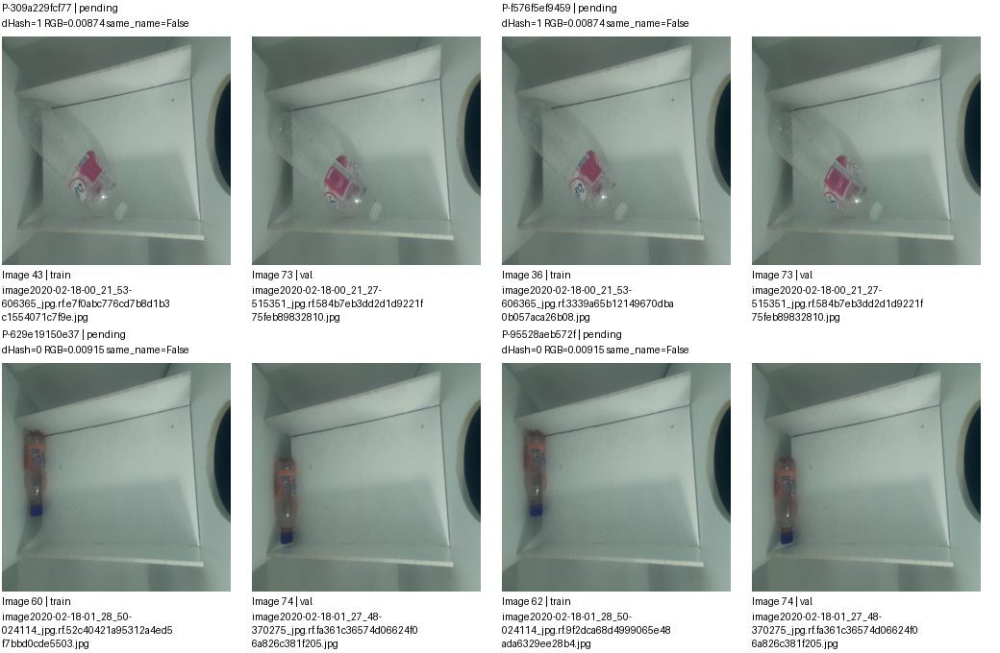

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-309a229fcf77,images/train/image2020-02-18-00_21_53-606365_jpg.rf.e7f0abc776cd7b8d1b3c1554071c7f9e.jpg,images/val/image2020-02-18-00_21_27-515351_jpg.rf.584b7eb3dd2d1d9221f75feb89832810.jpg,pending,
P-f576f5ef9459,images/train/image2020-02-18-00_21_53-606365_jpg.rf.3339a65b12149670dba0b057aca26b08.jpg,images/val/image2020-02-18-00_21_27-515351_jpg.rf.584b7eb3dd2d1d9221f75feb89832810.jpg,pending,
P-629e19150e37,images/train/image2020-02-18-01_28_50-024114_jpg.rf.52c40421a95312a4ed5f7bbd0cde5503.jpg,images/val/image2020-02-18-01_27_48-370275_jpg.rf.fa361c36574d06624f06a826c381f205.jpg,pending,
P-95528aeb572f,images/train/image2020-02-18-01_28_50-024114_jpg.rf.9f2dca68d4999065e48ada6329ee28b4.jpg,images/val/image2020-02-18-01_27_48-370275_jpg.rf.fa361c36574d06624f06a826c381f205.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 52/166 G-586696e3c556 | 77 ảnh, 388 cặp
Split: {'test': 2, 'train': 70, 'val': 5}
Quyết định: {'pending': 388}
Ảnh trang None/13; cặp trang 17/97. Nhóm liên thông không phải kết luận trùng.


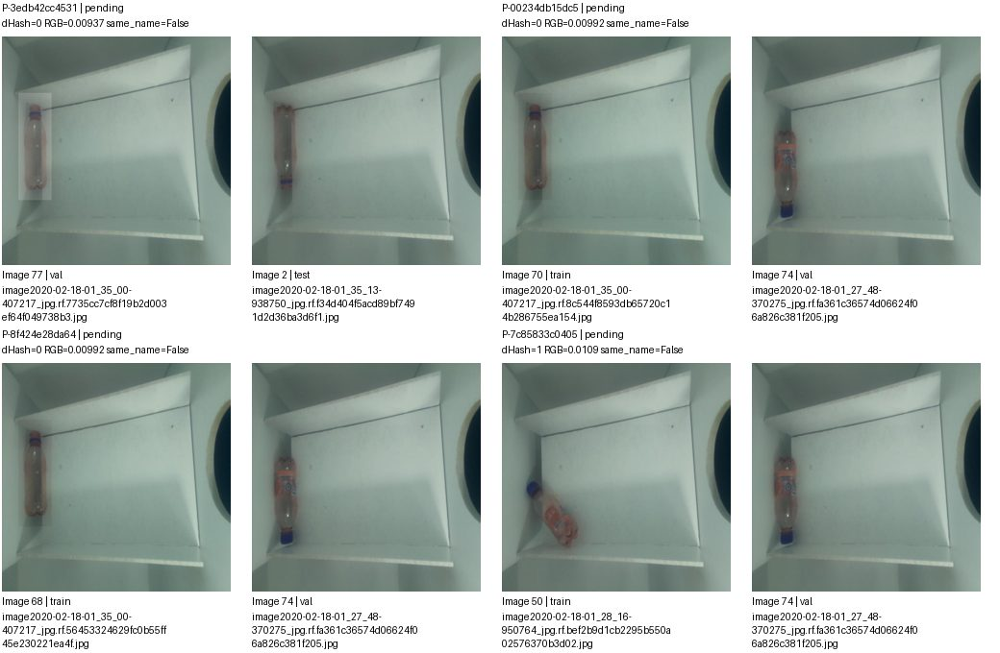

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-3edb42cc4531,images/val/image2020-02-18-01_35_00-407217_jpg.rf.7735cc7cf8f19b2d003ef64f049738b3.jpg,images/test/image2020-02-18-01_35_13-938750_jpg.rf.f34d404f5acd89bf7491d2d36ba3d6f1.jpg,pending,
P-00234db15dc5,images/train/image2020-02-18-01_35_00-407217_jpg.rf.8c544f8593db65720c14b286755ea154.jpg,images/val/image2020-02-18-01_27_48-370275_jpg.rf.fa361c36574d06624f06a826c381f205.jpg,pending,
P-8f424e28da64,images/train/image2020-02-18-01_35_00-407217_jpg.rf.56453324629fc0b55ff45e230221ea4f.jpg,images/val/image2020-02-18-01_27_48-370275_jpg.rf.fa361c36574d06624f06a826c381f205.jpg,pending,
P-7c85833c0405,images/train/image2020-02-18-01_28_16-950764_jpg.rf.bef2b9d1cb2295b550a02576370b3d02.jpg,images/val/image2020-02-18-01_27_48-370275_jpg.rf.fa361c36574d06624f06a826c381f205.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 52/166 G-586696e3c556 | 77 ảnh, 388 cặp
Split: {'test': 2, 'train': 70, 'val': 5}
Quyết định: {'pending': 388}
Ảnh trang None/13; cặp trang 18/97. Nhóm liên thông không phải kết luận trùng.


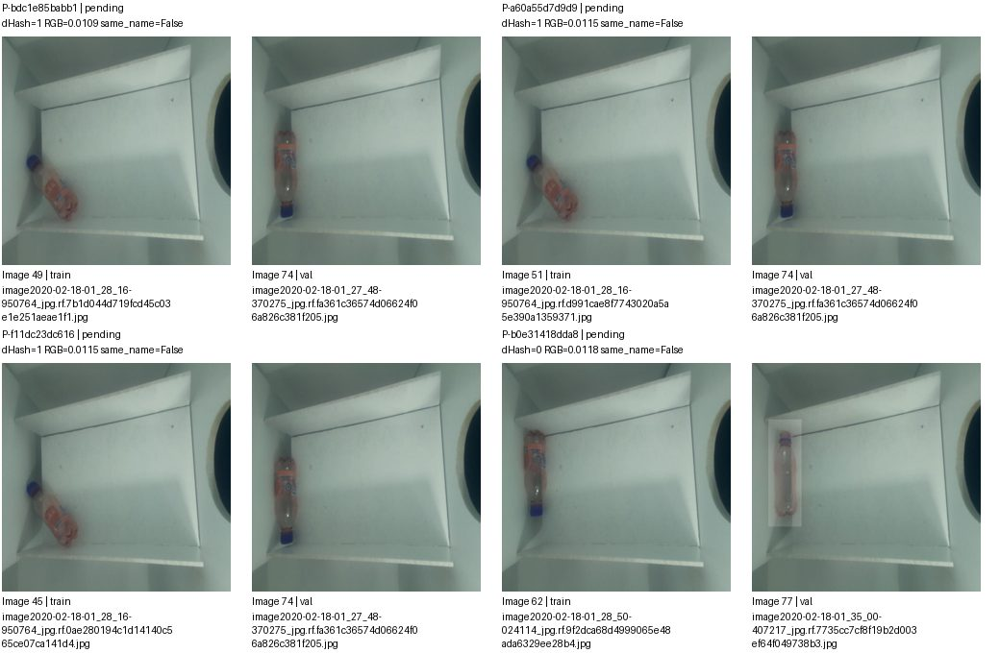

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-bdc1e85babb1,images/train/image2020-02-18-01_28_16-950764_jpg.rf.7b1d044d719fcd45c03e1e251aeae1f1.jpg,images/val/image2020-02-18-01_27_48-370275_jpg.rf.fa361c36574d06624f06a826c381f205.jpg,pending,
P-a60a55d7d9d9,images/train/image2020-02-18-01_28_16-950764_jpg.rf.d991cae8f7743020a5a5e390a1359371.jpg,images/val/image2020-02-18-01_27_48-370275_jpg.rf.fa361c36574d06624f06a826c381f205.jpg,pending,
P-f11dc23dc616,images/train/image2020-02-18-01_28_16-950764_jpg.rf.0ae280194c1d14140c565ce07ca141d4.jpg,images/val/image2020-02-18-01_27_48-370275_jpg.rf.fa361c36574d06624f06a826c381f205.jpg,pending,
P-b0e31418dda8,images/train/image2020-02-18-01_28_50-024114_jpg.rf.9f2dca68d4999065e48ada6329ee28b4.jpg,images/val/image2020-02-18-01_35_00-407217_jpg.rf.7735cc7cf8f19b2d003ef64f049738b3.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 52/166 G-586696e3c556 | 77 ảnh, 388 cặp
Split: {'test': 2, 'train': 70, 'val': 5}
Quyết định: {'pending': 388}
Ảnh trang None/13; cặp trang 19/97. Nhóm liên thông không phải kết luận trùng.


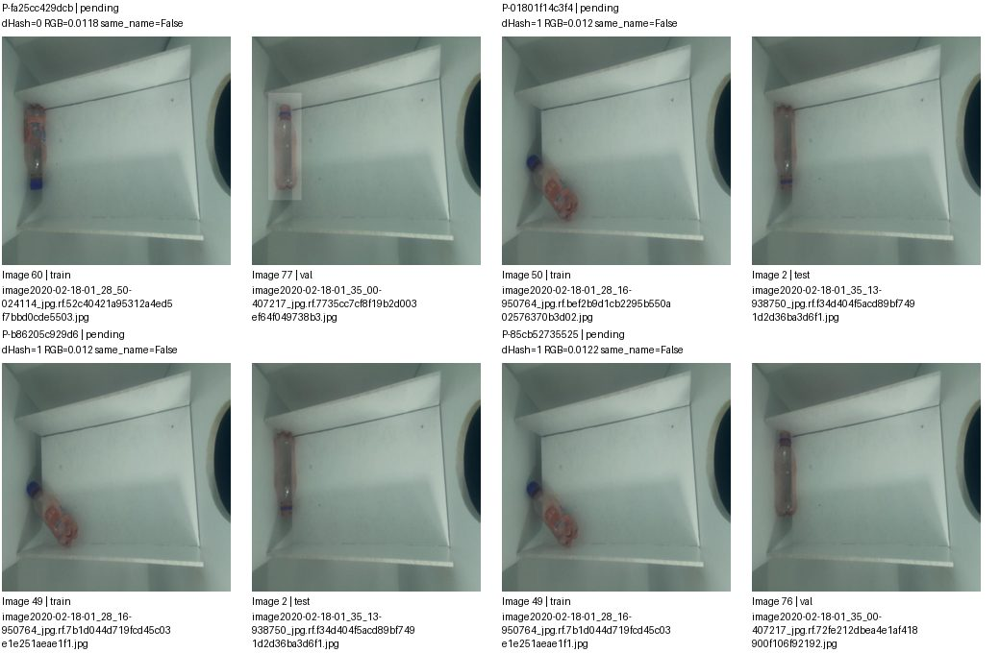

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-fa25cc429dcb,images/train/image2020-02-18-01_28_50-024114_jpg.rf.52c40421a95312a4ed5f7bbd0cde5503.jpg,images/val/image2020-02-18-01_35_00-407217_jpg.rf.7735cc7cf8f19b2d003ef64f049738b3.jpg,pending,
P-01801f14c3f4,images/train/image2020-02-18-01_28_16-950764_jpg.rf.bef2b9d1cb2295b550a02576370b3d02.jpg,images/test/image2020-02-18-01_35_13-938750_jpg.rf.f34d404f5acd89bf7491d2d36ba3d6f1.jpg,pending,
P-b86205c929d6,images/train/image2020-02-18-01_28_16-950764_jpg.rf.7b1d044d719fcd45c03e1e251aeae1f1.jpg,images/test/image2020-02-18-01_35_13-938750_jpg.rf.f34d404f5acd89bf7491d2d36ba3d6f1.jpg,pending,
P-85cb52735525,images/train/image2020-02-18-01_28_16-950764_jpg.rf.7b1d044d719fcd45c03e1e251aeae1f1.jpg,images/val/image2020-02-18-01_35_00-407217_jpg.rf.72fe212dbea4e1af418900f106f92192.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 52/166 G-586696e3c556 | 77 ảnh, 388 cặp
Split: {'test': 2, 'train': 70, 'val': 5}
Quyết định: {'pending': 388}
Ảnh trang None/13; cặp trang 20/97. Nhóm liên thông không phải kết luận trùng.


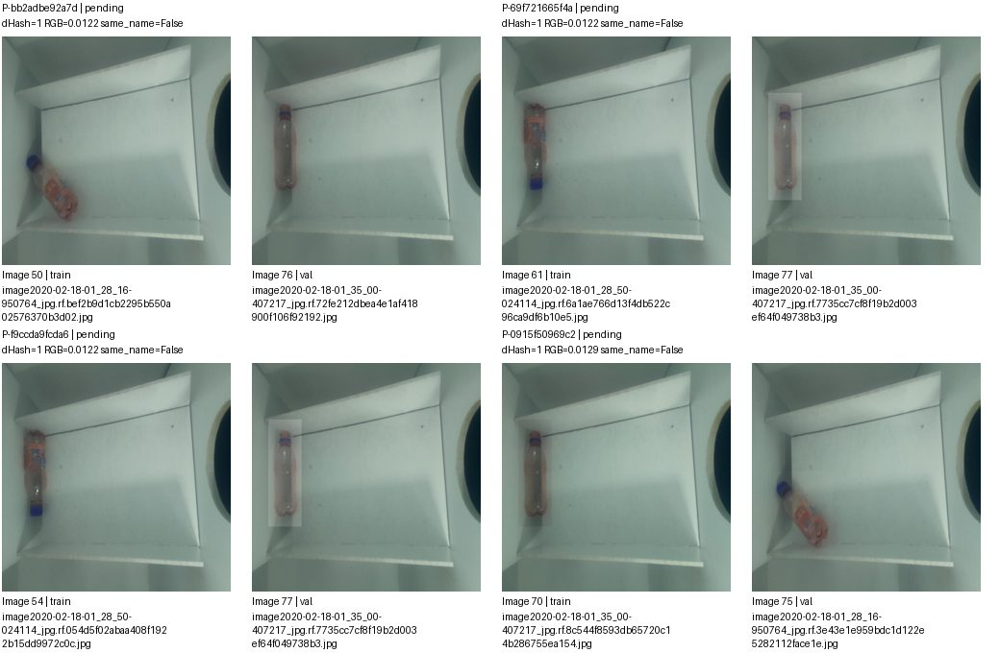

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-bb2adbe92a7d,images/train/image2020-02-18-01_28_16-950764_jpg.rf.bef2b9d1cb2295b550a02576370b3d02.jpg,images/val/image2020-02-18-01_35_00-407217_jpg.rf.72fe212dbea4e1af418900f106f92192.jpg,pending,
P-69f721665f4a,images/train/image2020-02-18-01_28_50-024114_jpg.rf.6a1ae766d13f4db522c96ca9df6b10e5.jpg,images/val/image2020-02-18-01_35_00-407217_jpg.rf.7735cc7cf8f19b2d003ef64f049738b3.jpg,pending,
P-f9ccda9fcda6,images/train/image2020-02-18-01_28_50-024114_jpg.rf.054d5f02abaa408f1922b15dd9972c0c.jpg,images/val/image2020-02-18-01_35_00-407217_jpg.rf.7735cc7cf8f19b2d003ef64f049738b3.jpg,pending,
P-0915f50969c2,images/train/image2020-02-18-01_35_00-407217_jpg.rf.8c544f8593db65720c14b286755ea154.jpg,images/val/image2020-02-18-01_28_16-950764_jpg.rf.3e43e1e959bdc1d122e5282112face1e.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 52/166 G-586696e3c556 | 77 ảnh, 388 cặp
Split: {'test': 2, 'train': 70, 'val': 5}
Quyết định: {'pending': 388}
Ảnh trang None/13; cặp trang 21/97. Nhóm liên thông không phải kết luận trùng.


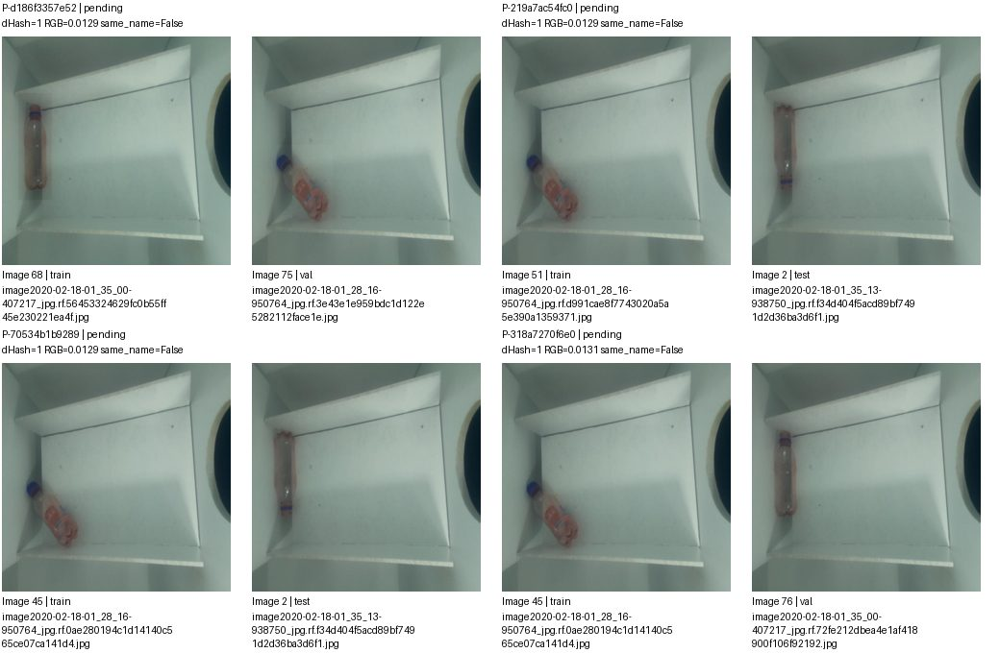

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-d186f3357e52,images/train/image2020-02-18-01_35_00-407217_jpg.rf.56453324629fc0b55ff45e230221ea4f.jpg,images/val/image2020-02-18-01_28_16-950764_jpg.rf.3e43e1e959bdc1d122e5282112face1e.jpg,pending,
P-219a7ac54fc0,images/train/image2020-02-18-01_28_16-950764_jpg.rf.d991cae8f7743020a5a5e390a1359371.jpg,images/test/image2020-02-18-01_35_13-938750_jpg.rf.f34d404f5acd89bf7491d2d36ba3d6f1.jpg,pending,
P-70534b1b9289,images/train/image2020-02-18-01_28_16-950764_jpg.rf.0ae280194c1d14140c565ce07ca141d4.jpg,images/test/image2020-02-18-01_35_13-938750_jpg.rf.f34d404f5acd89bf7491d2d36ba3d6f1.jpg,pending,
P-318a7270f6e0,images/train/image2020-02-18-01_28_16-950764_jpg.rf.0ae280194c1d14140c565ce07ca141d4.jpg,images/val/image2020-02-18-01_35_00-407217_jpg.rf.72fe212dbea4e1af418900f106f92192.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 52/166 G-586696e3c556 | 77 ảnh, 388 cặp
Split: {'test': 2, 'train': 70, 'val': 5}
Quyết định: {'pending': 388}
Ảnh trang None/13; cặp trang 22/97. Nhóm liên thông không phải kết luận trùng.


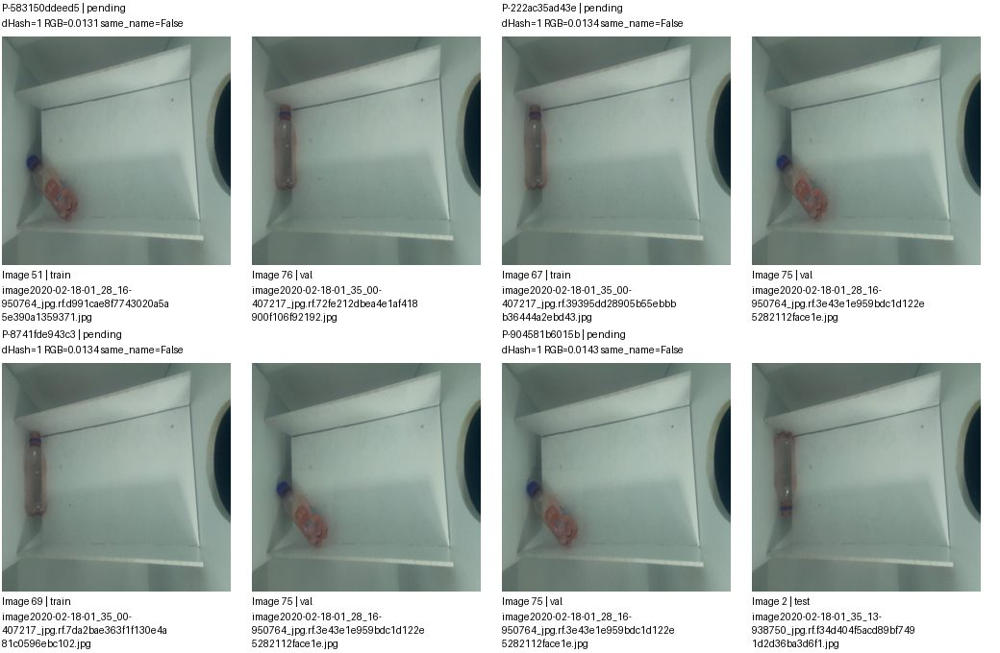

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-583150ddeed5,images/train/image2020-02-18-01_28_16-950764_jpg.rf.d991cae8f7743020a5a5e390a1359371.jpg,images/val/image2020-02-18-01_35_00-407217_jpg.rf.72fe212dbea4e1af418900f106f92192.jpg,pending,
P-222ac35ad43e,images/train/image2020-02-18-01_35_00-407217_jpg.rf.39395dd28905b55ebbbb36444a2ebd43.jpg,images/val/image2020-02-18-01_28_16-950764_jpg.rf.3e43e1e959bdc1d122e5282112face1e.jpg,pending,
P-8741fde943c3,images/train/image2020-02-18-01_35_00-407217_jpg.rf.7da2bae363f1f130e4a81c0596ebc102.jpg,images/val/image2020-02-18-01_28_16-950764_jpg.rf.3e43e1e959bdc1d122e5282112face1e.jpg,pending,
P-904581b6015b,images/val/image2020-02-18-01_28_16-950764_jpg.rf.3e43e1e959bdc1d122e5282112face1e.jpg,images/test/image2020-02-18-01_35_13-938750_jpg.rf.f34d404f5acd89bf7491d2d36ba3d6f1.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 52/166 G-586696e3c556 | 77 ảnh, 388 cặp
Split: {'test': 2, 'train': 70, 'val': 5}
Quyết định: {'pending': 388}
Ảnh trang None/13; cặp trang 23/97. Nhóm liên thông không phải kết luận trùng.


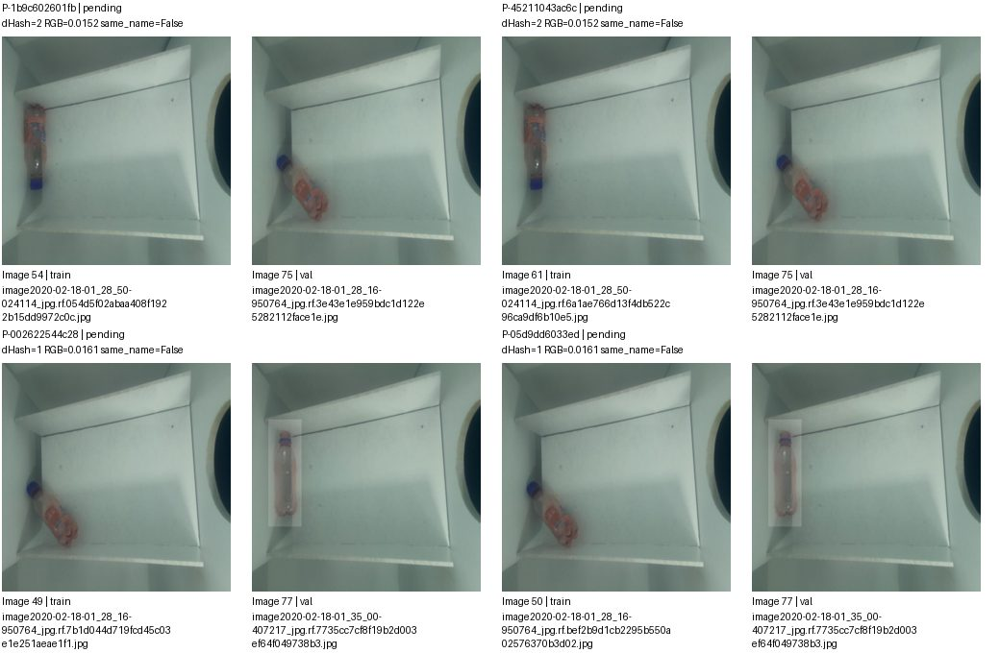

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-1b9c602601fb,images/train/image2020-02-18-01_28_50-024114_jpg.rf.054d5f02abaa408f1922b15dd9972c0c.jpg,images/val/image2020-02-18-01_28_16-950764_jpg.rf.3e43e1e959bdc1d122e5282112face1e.jpg,pending,
P-45211043ac6c,images/train/image2020-02-18-01_28_50-024114_jpg.rf.6a1ae766d13f4db522c96ca9df6b10e5.jpg,images/val/image2020-02-18-01_28_16-950764_jpg.rf.3e43e1e959bdc1d122e5282112face1e.jpg,pending,
P-002622544c28,images/train/image2020-02-18-01_28_16-950764_jpg.rf.7b1d044d719fcd45c03e1e251aeae1f1.jpg,images/val/image2020-02-18-01_35_00-407217_jpg.rf.7735cc7cf8f19b2d003ef64f049738b3.jpg,pending,
P-05d9dd6033ed,images/train/image2020-02-18-01_28_16-950764_jpg.rf.bef2b9d1cb2295b550a02576370b3d02.jpg,images/val/image2020-02-18-01_35_00-407217_jpg.rf.7735cc7cf8f19b2d003ef64f049738b3.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 52/166 G-586696e3c556 | 77 ảnh, 388 cặp
Split: {'test': 2, 'train': 70, 'val': 5}
Quyết định: {'pending': 388}
Ảnh trang None/13; cặp trang 24/97. Nhóm liên thông không phải kết luận trùng.


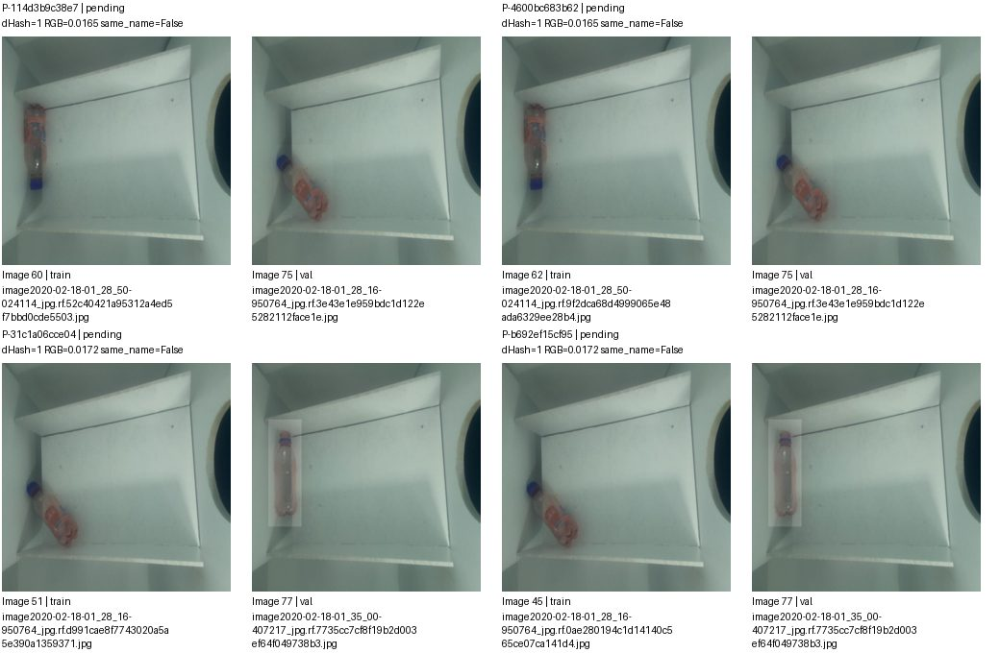

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-114d3b9c38e7,images/train/image2020-02-18-01_28_50-024114_jpg.rf.52c40421a95312a4ed5f7bbd0cde5503.jpg,images/val/image2020-02-18-01_28_16-950764_jpg.rf.3e43e1e959bdc1d122e5282112face1e.jpg,pending,
P-4600bc683b62,images/train/image2020-02-18-01_28_50-024114_jpg.rf.9f2dca68d4999065e48ada6329ee28b4.jpg,images/val/image2020-02-18-01_28_16-950764_jpg.rf.3e43e1e959bdc1d122e5282112face1e.jpg,pending,
P-31c1a06cce04,images/train/image2020-02-18-01_28_16-950764_jpg.rf.d991cae8f7743020a5a5e390a1359371.jpg,images/val/image2020-02-18-01_35_00-407217_jpg.rf.7735cc7cf8f19b2d003ef64f049738b3.jpg,pending,
P-b692ef15cf95,images/train/image2020-02-18-01_28_16-950764_jpg.rf.0ae280194c1d14140c565ce07ca141d4.jpg,images/val/image2020-02-18-01_35_00-407217_jpg.rf.7735cc7cf8f19b2d003ef64f049738b3.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 52/166 G-586696e3c556 | 77 ảnh, 388 cặp
Split: {'test': 2, 'train': 70, 'val': 5}
Quyết định: {'pending': 388}
Ảnh trang None/13; cặp trang 25/97. Nhóm liên thông không phải kết luận trùng.


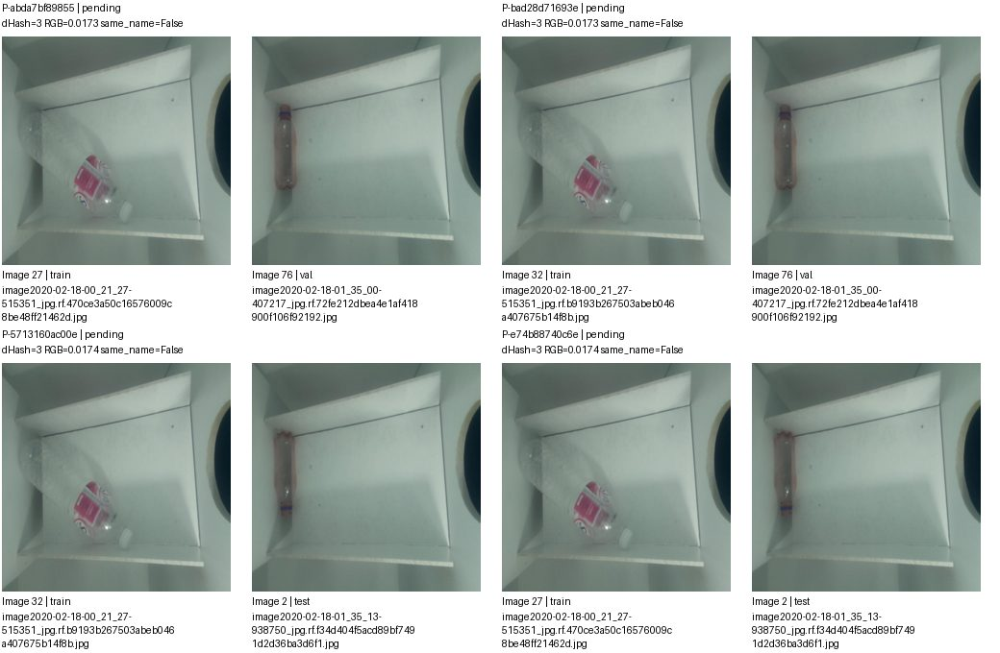

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-abda7bf89855,images/train/image2020-02-18-00_21_27-515351_jpg.rf.470ce3a50c16576009c8be48ff21462d.jpg,images/val/image2020-02-18-01_35_00-407217_jpg.rf.72fe212dbea4e1af418900f106f92192.jpg,pending,
P-bad28d71693e,images/train/image2020-02-18-00_21_27-515351_jpg.rf.b9193b267503abeb046a407675b14f8b.jpg,images/val/image2020-02-18-01_35_00-407217_jpg.rf.72fe212dbea4e1af418900f106f92192.jpg,pending,
P-5713160ac00e,images/train/image2020-02-18-00_21_27-515351_jpg.rf.b9193b267503abeb046a407675b14f8b.jpg,images/test/image2020-02-18-01_35_13-938750_jpg.rf.f34d404f5acd89bf7491d2d36ba3d6f1.jpg,pending,
P-e74b88740c6e,images/train/image2020-02-18-00_21_27-515351_jpg.rf.470ce3a50c16576009c8be48ff21462d.jpg,images/test/image2020-02-18-01_35_13-938750_jpg.rf.f34d404f5acd89bf7491d2d36ba3d6f1.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 52/166 G-586696e3c556 | 77 ảnh, 388 cặp
Split: {'test': 2, 'train': 70, 'val': 5}
Quyết định: {'pending': 388}
Ảnh trang None/13; cặp trang 26/97. Nhóm liên thông không phải kết luận trùng.


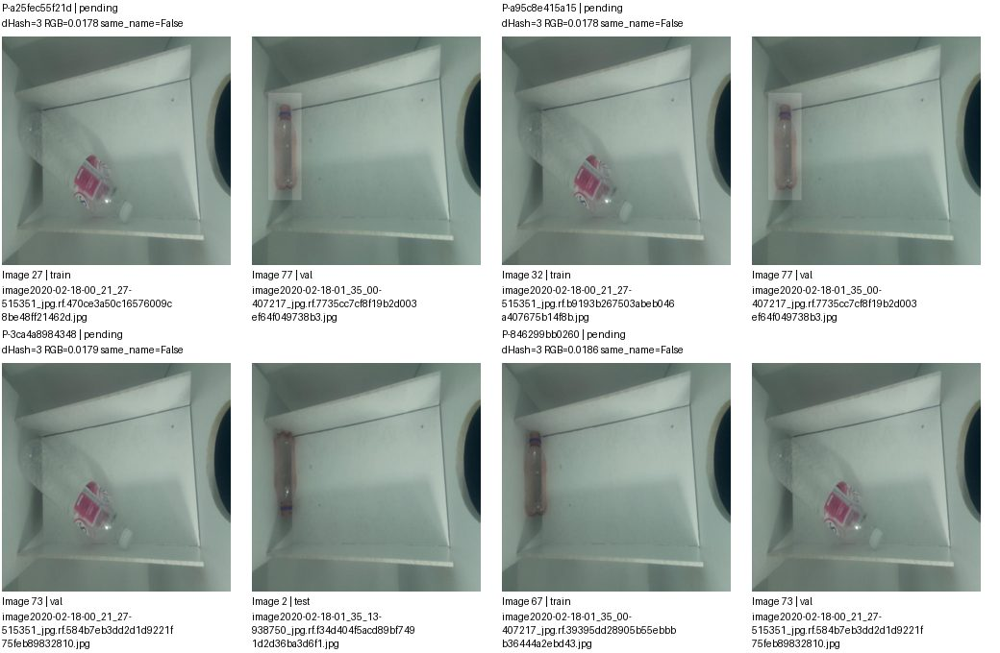

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-a25fec55f21d,images/train/image2020-02-18-00_21_27-515351_jpg.rf.470ce3a50c16576009c8be48ff21462d.jpg,images/val/image2020-02-18-01_35_00-407217_jpg.rf.7735cc7cf8f19b2d003ef64f049738b3.jpg,pending,
P-a95c8e415a15,images/train/image2020-02-18-00_21_27-515351_jpg.rf.b9193b267503abeb046a407675b14f8b.jpg,images/val/image2020-02-18-01_35_00-407217_jpg.rf.7735cc7cf8f19b2d003ef64f049738b3.jpg,pending,
P-3ca4a8984348,images/val/image2020-02-18-00_21_27-515351_jpg.rf.584b7eb3dd2d1d9221f75feb89832810.jpg,images/test/image2020-02-18-01_35_13-938750_jpg.rf.f34d404f5acd89bf7491d2d36ba3d6f1.jpg,pending,
P-846299bb0260,images/train/image2020-02-18-01_35_00-407217_jpg.rf.39395dd28905b55ebbbb36444a2ebd43.jpg,images/val/image2020-02-18-00_21_27-515351_jpg.rf.584b7eb3dd2d1d9221f75feb89832810.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 52/166 G-586696e3c556 | 77 ảnh, 388 cặp
Split: {'test': 2, 'train': 70, 'val': 5}
Quyết định: {'pending': 388}
Ảnh trang None/13; cặp trang 27/97. Nhóm liên thông không phải kết luận trùng.


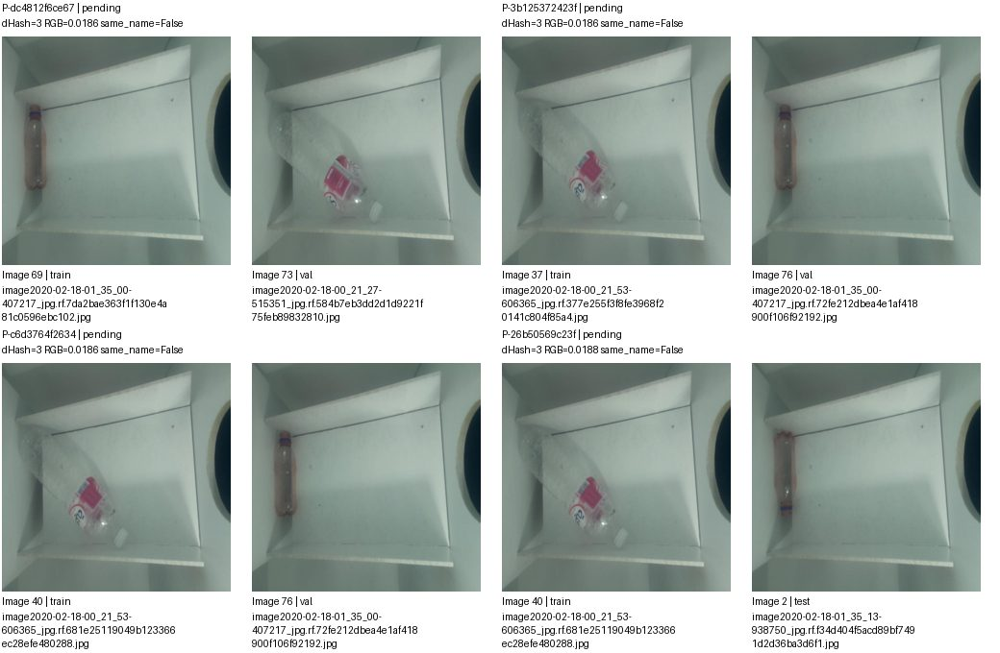

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-dc4812f6ce67,images/train/image2020-02-18-01_35_00-407217_jpg.rf.7da2bae363f1f130e4a81c0596ebc102.jpg,images/val/image2020-02-18-00_21_27-515351_jpg.rf.584b7eb3dd2d1d9221f75feb89832810.jpg,pending,
P-3b125372423f,images/train/image2020-02-18-00_21_53-606365_jpg.rf.377e255f3f8fe3968f20141c804f85a4.jpg,images/val/image2020-02-18-01_35_00-407217_jpg.rf.72fe212dbea4e1af418900f106f92192.jpg,pending,
P-c6d3764f2634,images/train/image2020-02-18-00_21_53-606365_jpg.rf.681e25119049b123366ec28efe480288.jpg,images/val/image2020-02-18-01_35_00-407217_jpg.rf.72fe212dbea4e1af418900f106f92192.jpg,pending,
P-26b50569c23f,images/train/image2020-02-18-00_21_53-606365_jpg.rf.681e25119049b123366ec28efe480288.jpg,images/test/image2020-02-18-01_35_13-938750_jpg.rf.f34d404f5acd89bf7491d2d36ba3d6f1.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 52/166 G-586696e3c556 | 77 ảnh, 388 cặp
Split: {'test': 2, 'train': 70, 'val': 5}
Quyết định: {'pending': 388}
Ảnh trang None/13; cặp trang 28/97. Nhóm liên thông không phải kết luận trùng.


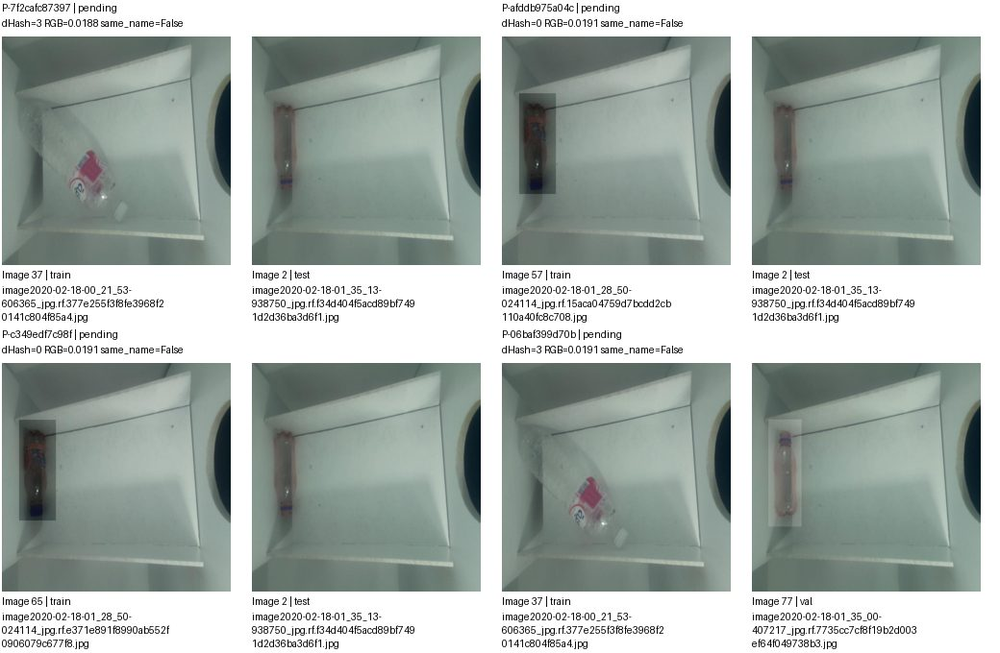

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-7f2cafc87397,images/train/image2020-02-18-00_21_53-606365_jpg.rf.377e255f3f8fe3968f20141c804f85a4.jpg,images/test/image2020-02-18-01_35_13-938750_jpg.rf.f34d404f5acd89bf7491d2d36ba3d6f1.jpg,pending,
P-afddb975a04c,images/train/image2020-02-18-01_28_50-024114_jpg.rf.15aca04759d7bcdd2cb110a40fc8c708.jpg,images/test/image2020-02-18-01_35_13-938750_jpg.rf.f34d404f5acd89bf7491d2d36ba3d6f1.jpg,pending,
P-c349edf7c98f,images/train/image2020-02-18-01_28_50-024114_jpg.rf.e371e891f8990ab552f0906079c677f8.jpg,images/test/image2020-02-18-01_35_13-938750_jpg.rf.f34d404f5acd89bf7491d2d36ba3d6f1.jpg,pending,
P-06baf399d70b,images/train/image2020-02-18-00_21_53-606365_jpg.rf.377e255f3f8fe3968f20141c804f85a4.jpg,images/val/image2020-02-18-01_35_00-407217_jpg.rf.7735cc7cf8f19b2d003ef64f049738b3.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 52/166 G-586696e3c556 | 77 ảnh, 388 cặp
Split: {'test': 2, 'train': 70, 'val': 5}
Quyết định: {'pending': 388}
Ảnh trang None/13; cặp trang 29/97. Nhóm liên thông không phải kết luận trùng.


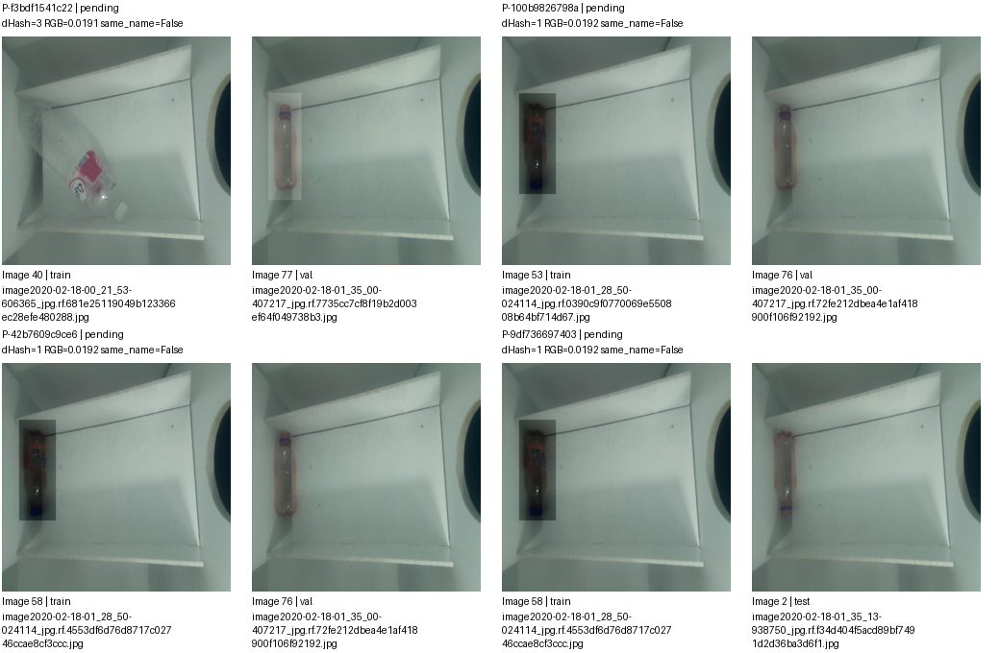

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-f3bdf1541c22,images/train/image2020-02-18-00_21_53-606365_jpg.rf.681e25119049b123366ec28efe480288.jpg,images/val/image2020-02-18-01_35_00-407217_jpg.rf.7735cc7cf8f19b2d003ef64f049738b3.jpg,pending,
P-100b9826798a,images/train/image2020-02-18-01_28_50-024114_jpg.rf.0390c9f0770069e550808b64bf714d67.jpg,images/val/image2020-02-18-01_35_00-407217_jpg.rf.72fe212dbea4e1af418900f106f92192.jpg,pending,
P-42b7609c9ce6,images/train/image2020-02-18-01_28_50-024114_jpg.rf.4553df6d76d8717c02746ccae8cf3ccc.jpg,images/val/image2020-02-18-01_35_00-407217_jpg.rf.72fe212dbea4e1af418900f106f92192.jpg,pending,
P-9df736697403,images/train/image2020-02-18-01_28_50-024114_jpg.rf.4553df6d76d8717c02746ccae8cf3ccc.jpg,images/test/image2020-02-18-01_35_13-938750_jpg.rf.f34d404f5acd89bf7491d2d36ba3d6f1.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 52/166 G-586696e3c556 | 77 ảnh, 388 cặp
Split: {'test': 2, 'train': 70, 'val': 5}
Quyết định: {'pending': 388}
Ảnh trang None/13; cặp trang 30/97. Nhóm liên thông không phải kết luận trùng.


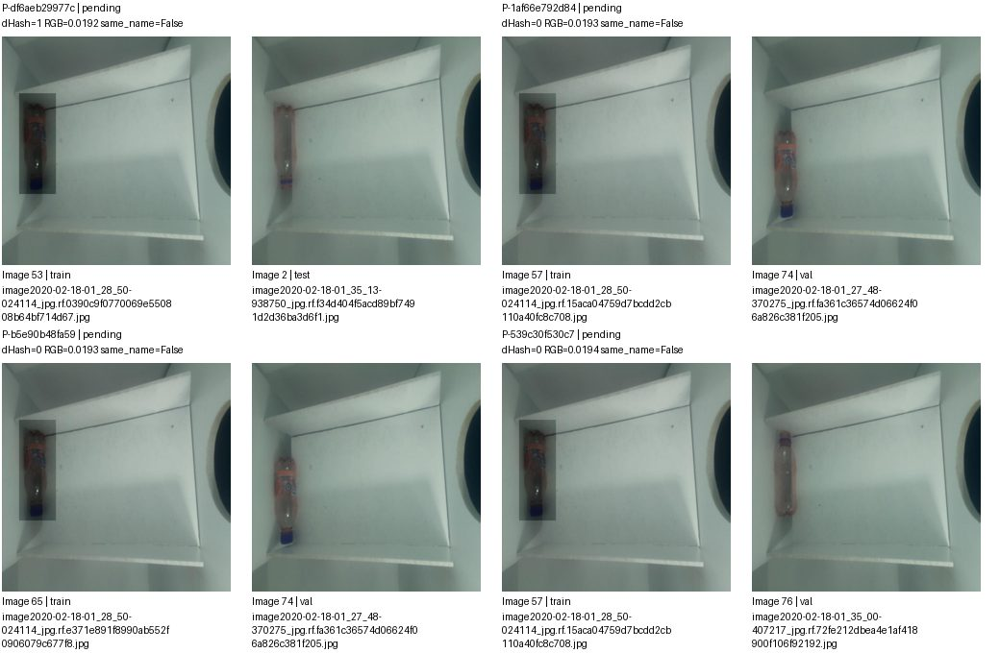

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-df6aeb29977c,images/train/image2020-02-18-01_28_50-024114_jpg.rf.0390c9f0770069e550808b64bf714d67.jpg,images/test/image2020-02-18-01_35_13-938750_jpg.rf.f34d404f5acd89bf7491d2d36ba3d6f1.jpg,pending,
P-1af66e792d84,images/train/image2020-02-18-01_28_50-024114_jpg.rf.15aca04759d7bcdd2cb110a40fc8c708.jpg,images/val/image2020-02-18-01_27_48-370275_jpg.rf.fa361c36574d06624f06a826c381f205.jpg,pending,
P-b5e90b48fa59,images/train/image2020-02-18-01_28_50-024114_jpg.rf.e371e891f8990ab552f0906079c677f8.jpg,images/val/image2020-02-18-01_27_48-370275_jpg.rf.fa361c36574d06624f06a826c381f205.jpg,pending,
P-539c30f530c7,images/train/image2020-02-18-01_28_50-024114_jpg.rf.15aca04759d7bcdd2cb110a40fc8c708.jpg,images/val/image2020-02-18-01_35_00-407217_jpg.rf.72fe212dbea4e1af418900f106f92192.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 52/166 G-586696e3c556 | 77 ảnh, 388 cặp
Split: {'test': 2, 'train': 70, 'val': 5}
Quyết định: {'pending': 388}
Ảnh trang None/13; cặp trang 31/97. Nhóm liên thông không phải kết luận trùng.


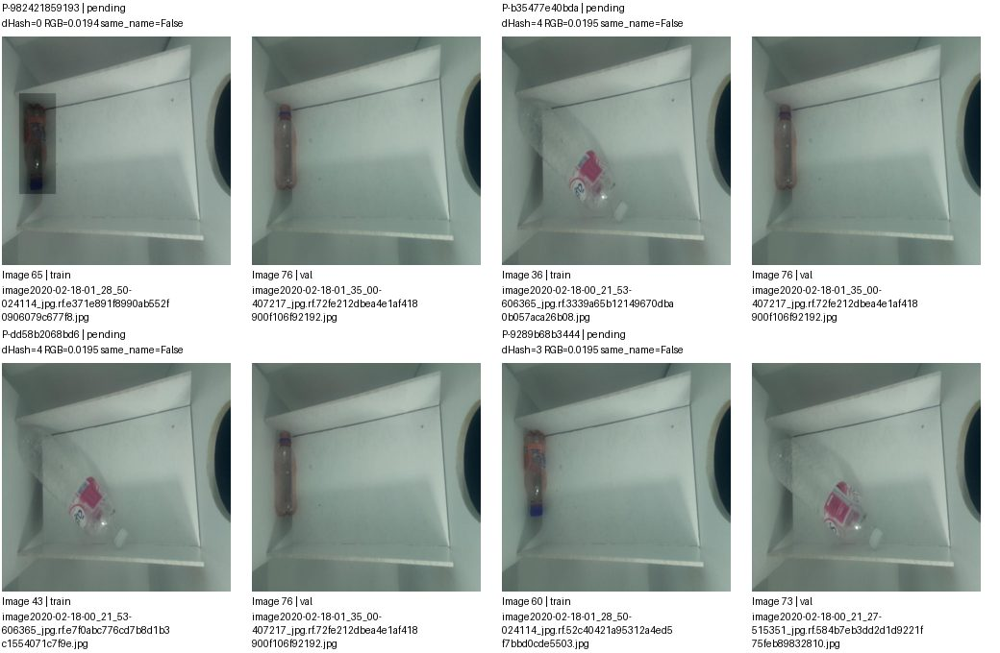

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-982421859193,images/train/image2020-02-18-01_28_50-024114_jpg.rf.e371e891f8990ab552f0906079c677f8.jpg,images/val/image2020-02-18-01_35_00-407217_jpg.rf.72fe212dbea4e1af418900f106f92192.jpg,pending,
P-b35477e40bda,images/train/image2020-02-18-00_21_53-606365_jpg.rf.3339a65b12149670dba0b057aca26b08.jpg,images/val/image2020-02-18-01_35_00-407217_jpg.rf.72fe212dbea4e1af418900f106f92192.jpg,pending,
P-dd58b2068bd6,images/train/image2020-02-18-00_21_53-606365_jpg.rf.e7f0abc776cd7b8d1b3c1554071c7f9e.jpg,images/val/image2020-02-18-01_35_00-407217_jpg.rf.72fe212dbea4e1af418900f106f92192.jpg,pending,
P-9289b68b3444,images/train/image2020-02-18-01_28_50-024114_jpg.rf.52c40421a95312a4ed5f7bbd0cde5503.jpg,images/val/image2020-02-18-00_21_27-515351_jpg.rf.584b7eb3dd2d1d9221f75feb89832810.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 52/166 G-586696e3c556 | 77 ảnh, 388 cặp
Split: {'test': 2, 'train': 70, 'val': 5}
Quyết định: {'pending': 388}
Ảnh trang None/13; cặp trang 32/97. Nhóm liên thông không phải kết luận trùng.


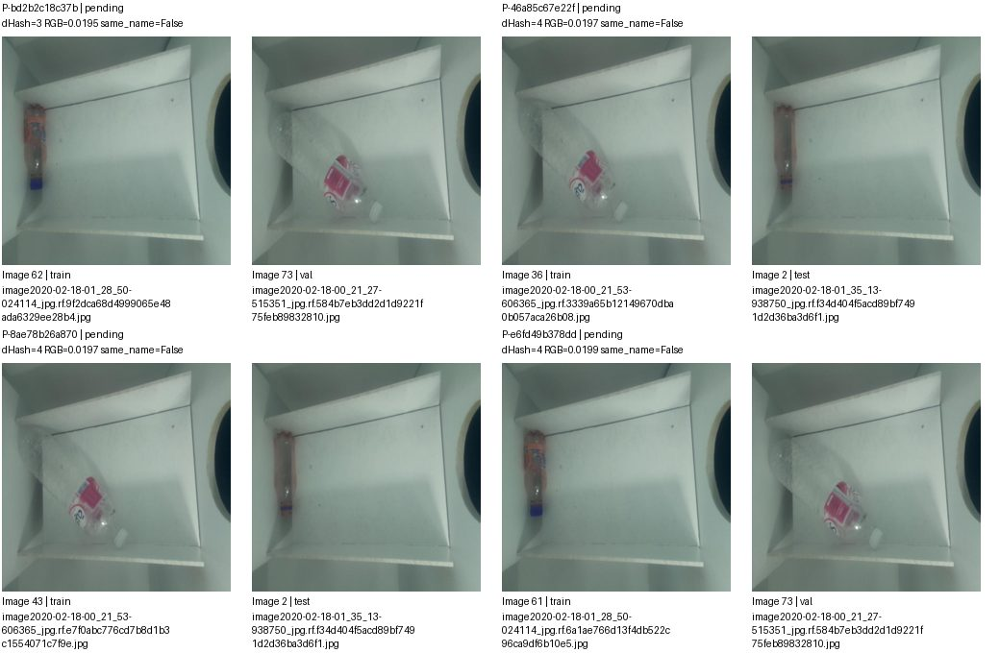

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-bd2b2c18c37b,images/train/image2020-02-18-01_28_50-024114_jpg.rf.9f2dca68d4999065e48ada6329ee28b4.jpg,images/val/image2020-02-18-00_21_27-515351_jpg.rf.584b7eb3dd2d1d9221f75feb89832810.jpg,pending,
P-46a85c67e22f,images/train/image2020-02-18-00_21_53-606365_jpg.rf.3339a65b12149670dba0b057aca26b08.jpg,images/test/image2020-02-18-01_35_13-938750_jpg.rf.f34d404f5acd89bf7491d2d36ba3d6f1.jpg,pending,
P-8ae78b26a870,images/train/image2020-02-18-00_21_53-606365_jpg.rf.e7f0abc776cd7b8d1b3c1554071c7f9e.jpg,images/test/image2020-02-18-01_35_13-938750_jpg.rf.f34d404f5acd89bf7491d2d36ba3d6f1.jpg,pending,
P-e6fd49b378dd,images/train/image2020-02-18-01_28_50-024114_jpg.rf.6a1ae766d13f4db522c96ca9df6b10e5.jpg,images/val/image2020-02-18-00_21_27-515351_jpg.rf.584b7eb3dd2d1d9221f75feb89832810.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 52/166 G-586696e3c556 | 77 ảnh, 388 cặp
Split: {'test': 2, 'train': 70, 'val': 5}
Quyết định: {'pending': 388}
Ảnh trang None/13; cặp trang 33/97. Nhóm liên thông không phải kết luận trùng.


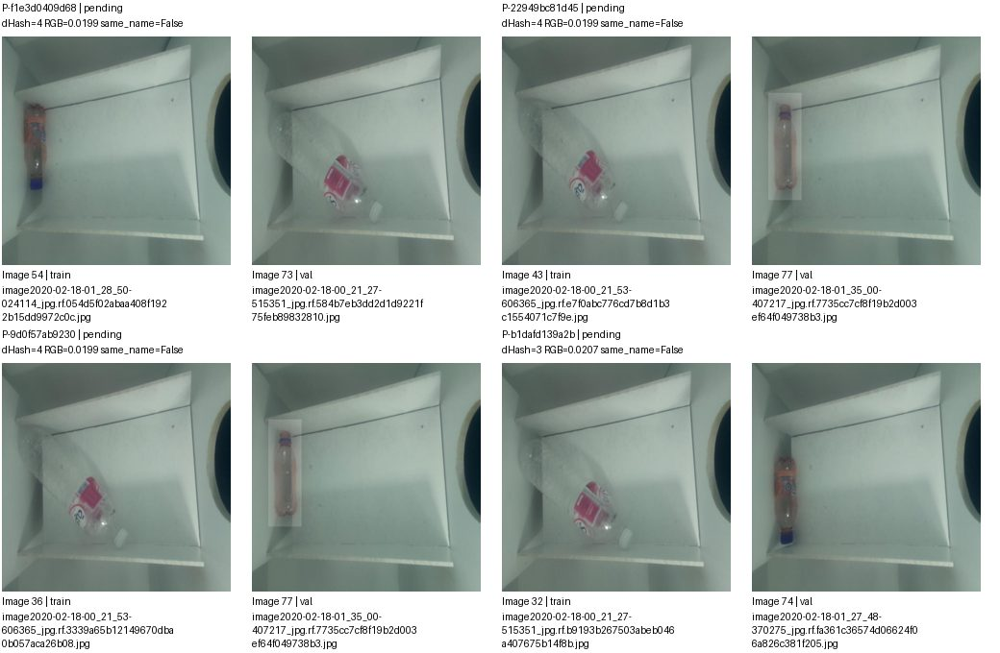

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-f1e3d0409d68,images/train/image2020-02-18-01_28_50-024114_jpg.rf.054d5f02abaa408f1922b15dd9972c0c.jpg,images/val/image2020-02-18-00_21_27-515351_jpg.rf.584b7eb3dd2d1d9221f75feb89832810.jpg,pending,
P-22949bc81d45,images/train/image2020-02-18-00_21_53-606365_jpg.rf.e7f0abc776cd7b8d1b3c1554071c7f9e.jpg,images/val/image2020-02-18-01_35_00-407217_jpg.rf.7735cc7cf8f19b2d003ef64f049738b3.jpg,pending,
P-9d0f57ab9230,images/train/image2020-02-18-00_21_53-606365_jpg.rf.3339a65b12149670dba0b057aca26b08.jpg,images/val/image2020-02-18-01_35_00-407217_jpg.rf.7735cc7cf8f19b2d003ef64f049738b3.jpg,pending,
P-b1dafd139a2b,images/train/image2020-02-18-00_21_27-515351_jpg.rf.b9193b267503abeb046a407675b14f8b.jpg,images/val/image2020-02-18-01_27_48-370275_jpg.rf.fa361c36574d06624f06a826c381f205.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 52/166 G-586696e3c556 | 77 ảnh, 388 cặp
Split: {'test': 2, 'train': 70, 'val': 5}
Quyết định: {'pending': 388}
Ảnh trang None/13; cặp trang 34/97. Nhóm liên thông không phải kết luận trùng.


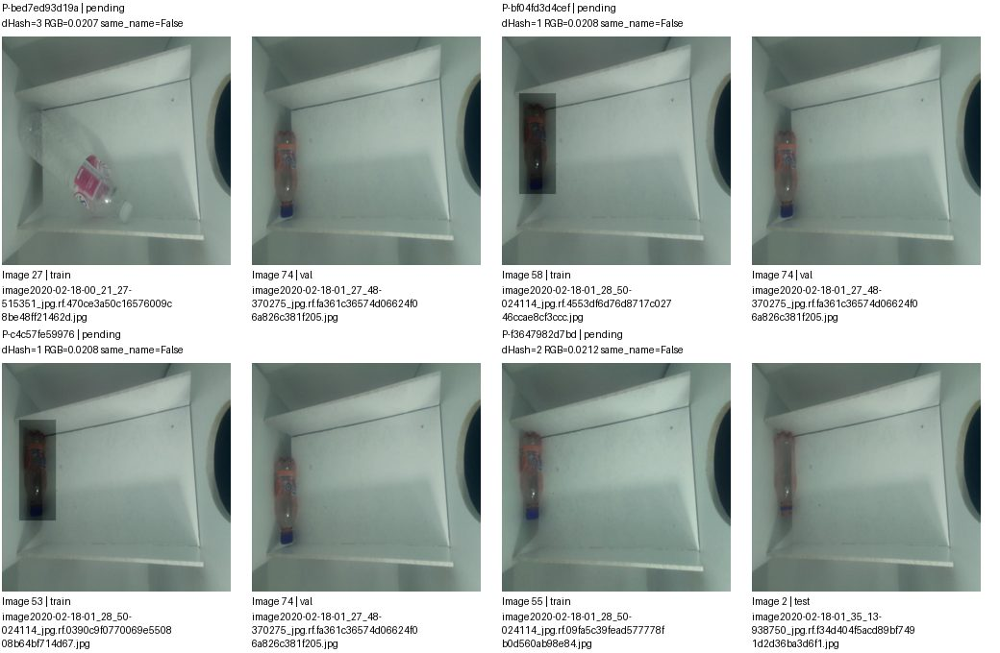

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-bed7ed93d19a,images/train/image2020-02-18-00_21_27-515351_jpg.rf.470ce3a50c16576009c8be48ff21462d.jpg,images/val/image2020-02-18-01_27_48-370275_jpg.rf.fa361c36574d06624f06a826c381f205.jpg,pending,
P-bf04fd3d4cef,images/train/image2020-02-18-01_28_50-024114_jpg.rf.4553df6d76d8717c02746ccae8cf3ccc.jpg,images/val/image2020-02-18-01_27_48-370275_jpg.rf.fa361c36574d06624f06a826c381f205.jpg,pending,
P-c4c57fe59976,images/train/image2020-02-18-01_28_50-024114_jpg.rf.0390c9f0770069e550808b64bf714d67.jpg,images/val/image2020-02-18-01_27_48-370275_jpg.rf.fa361c36574d06624f06a826c381f205.jpg,pending,
P-f3647982d7bd,images/train/image2020-02-18-01_28_50-024114_jpg.rf.09fa5c39fead577778fb0d560ab98e84.jpg,images/test/image2020-02-18-01_35_13-938750_jpg.rf.f34d404f5acd89bf7491d2d36ba3d6f1.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 52/166 G-586696e3c556 | 77 ảnh, 388 cặp
Split: {'test': 2, 'train': 70, 'val': 5}
Quyết định: {'pending': 388}
Ảnh trang None/13; cặp trang 35/97. Nhóm liên thông không phải kết luận trùng.


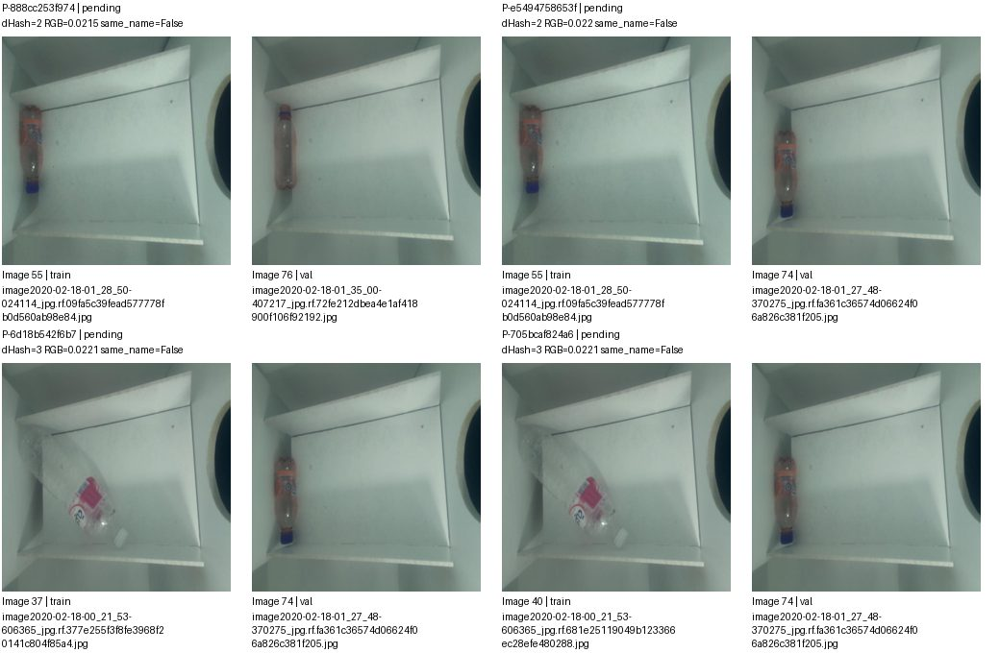

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-888cc253f974,images/train/image2020-02-18-01_28_50-024114_jpg.rf.09fa5c39fead577778fb0d560ab98e84.jpg,images/val/image2020-02-18-01_35_00-407217_jpg.rf.72fe212dbea4e1af418900f106f92192.jpg,pending,
P-e5494758653f,images/train/image2020-02-18-01_28_50-024114_jpg.rf.09fa5c39fead577778fb0d560ab98e84.jpg,images/val/image2020-02-18-01_27_48-370275_jpg.rf.fa361c36574d06624f06a826c381f205.jpg,pending,
P-6d18b542f6b7,images/train/image2020-02-18-00_21_53-606365_jpg.rf.377e255f3f8fe3968f20141c804f85a4.jpg,images/val/image2020-02-18-01_27_48-370275_jpg.rf.fa361c36574d06624f06a826c381f205.jpg,pending,
P-705bcaf824a6,images/train/image2020-02-18-00_21_53-606365_jpg.rf.681e25119049b123366ec28efe480288.jpg,images/val/image2020-02-18-01_27_48-370275_jpg.rf.fa361c36574d06624f06a826c381f205.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 52/166 G-586696e3c556 | 77 ảnh, 388 cặp
Split: {'test': 2, 'train': 70, 'val': 5}
Quyết định: {'pending': 388}
Ảnh trang None/13; cặp trang 36/97. Nhóm liên thông không phải kết luận trùng.


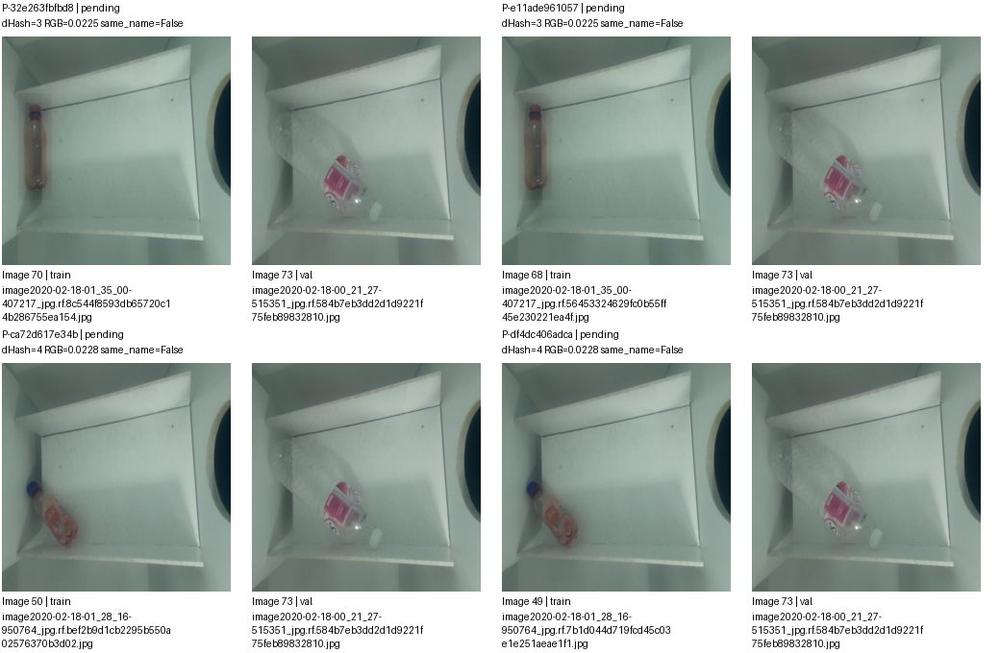

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-32e263fbfbd8,images/train/image2020-02-18-01_35_00-407217_jpg.rf.8c544f8593db65720c14b286755ea154.jpg,images/val/image2020-02-18-00_21_27-515351_jpg.rf.584b7eb3dd2d1d9221f75feb89832810.jpg,pending,
P-e11ade961057,images/train/image2020-02-18-01_35_00-407217_jpg.rf.56453324629fc0b55ff45e230221ea4f.jpg,images/val/image2020-02-18-00_21_27-515351_jpg.rf.584b7eb3dd2d1d9221f75feb89832810.jpg,pending,
P-ca72d617e34b,images/train/image2020-02-18-01_28_16-950764_jpg.rf.bef2b9d1cb2295b550a02576370b3d02.jpg,images/val/image2020-02-18-00_21_27-515351_jpg.rf.584b7eb3dd2d1d9221f75feb89832810.jpg,pending,
P-df4dc406adca,images/train/image2020-02-18-01_28_16-950764_jpg.rf.7b1d044d719fcd45c03e1e251aeae1f1.jpg,images/val/image2020-02-18-00_21_27-515351_jpg.rf.584b7eb3dd2d1d9221f75feb89832810.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 52/166 G-586696e3c556 | 77 ảnh, 388 cặp
Split: {'test': 2, 'train': 70, 'val': 5}
Quyết định: {'pending': 388}
Ảnh trang None/13; cặp trang 37/97. Nhóm liên thông không phải kết luận trùng.


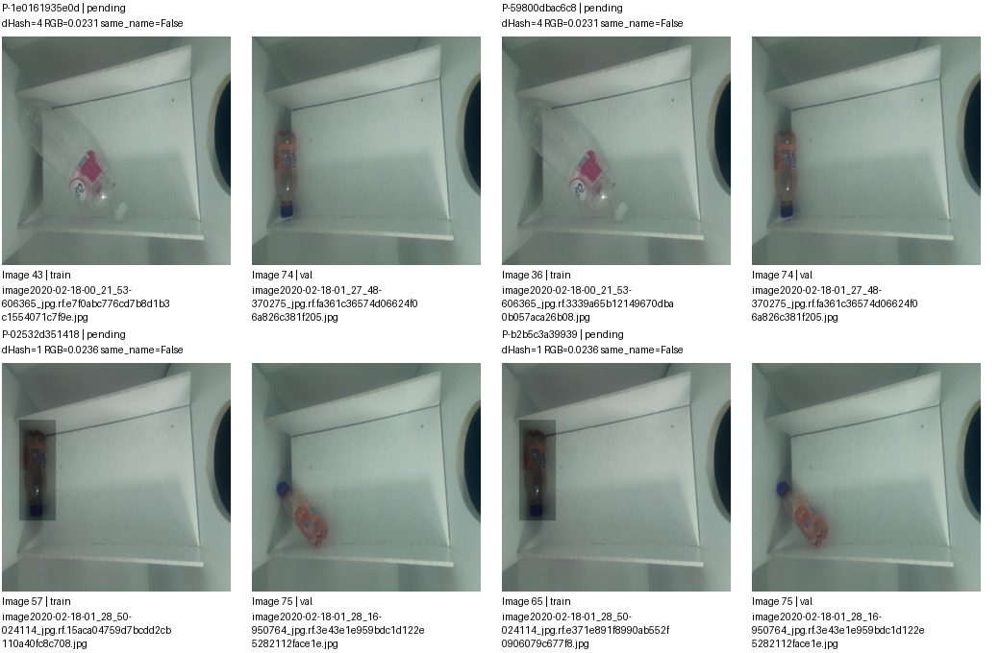

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-1e0161935e0d,images/train/image2020-02-18-00_21_53-606365_jpg.rf.e7f0abc776cd7b8d1b3c1554071c7f9e.jpg,images/val/image2020-02-18-01_27_48-370275_jpg.rf.fa361c36574d06624f06a826c381f205.jpg,pending,
P-59800dbac6c8,images/train/image2020-02-18-00_21_53-606365_jpg.rf.3339a65b12149670dba0b057aca26b08.jpg,images/val/image2020-02-18-01_27_48-370275_jpg.rf.fa361c36574d06624f06a826c381f205.jpg,pending,
P-02532d351418,images/train/image2020-02-18-01_28_50-024114_jpg.rf.15aca04759d7bcdd2cb110a40fc8c708.jpg,images/val/image2020-02-18-01_28_16-950764_jpg.rf.3e43e1e959bdc1d122e5282112face1e.jpg,pending,
P-b2b5c3a39939,images/train/image2020-02-18-01_28_50-024114_jpg.rf.e371e891f8990ab552f0906079c677f8.jpg,images/val/image2020-02-18-01_28_16-950764_jpg.rf.3e43e1e959bdc1d122e5282112face1e.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 52/166 G-586696e3c556 | 77 ảnh, 388 cặp
Split: {'test': 2, 'train': 70, 'val': 5}
Quyết định: {'pending': 388}
Ảnh trang None/13; cặp trang 38/97. Nhóm liên thông không phải kết luận trùng.


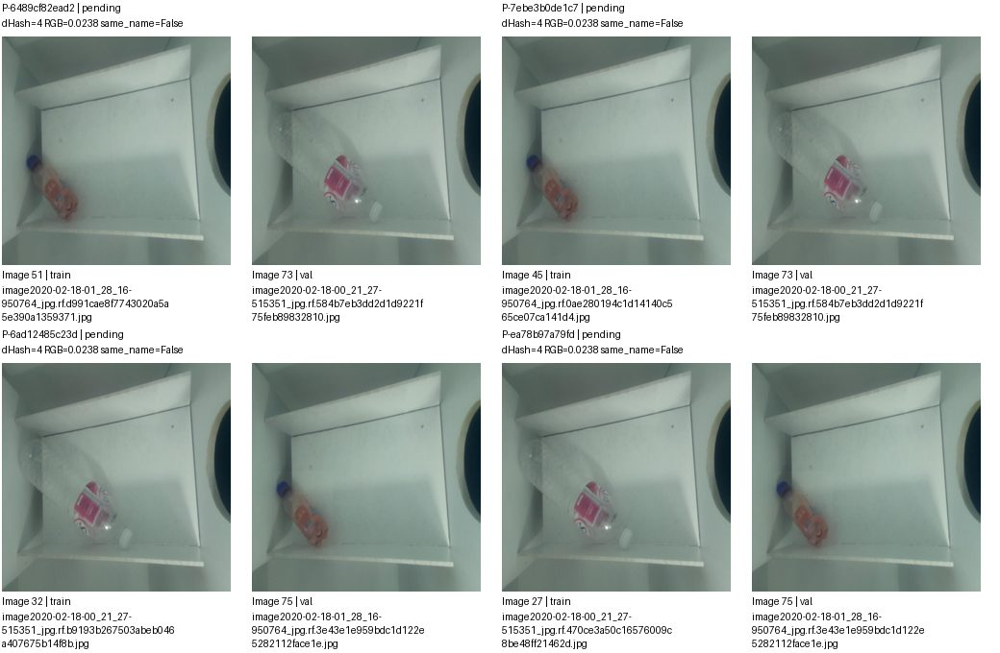

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-6489cf82ead2,images/train/image2020-02-18-01_28_16-950764_jpg.rf.d991cae8f7743020a5a5e390a1359371.jpg,images/val/image2020-02-18-00_21_27-515351_jpg.rf.584b7eb3dd2d1d9221f75feb89832810.jpg,pending,
P-7ebe3b0de1c7,images/train/image2020-02-18-01_28_16-950764_jpg.rf.0ae280194c1d14140c565ce07ca141d4.jpg,images/val/image2020-02-18-00_21_27-515351_jpg.rf.584b7eb3dd2d1d9221f75feb89832810.jpg,pending,
P-6ad12485c23d,images/train/image2020-02-18-00_21_27-515351_jpg.rf.b9193b267503abeb046a407675b14f8b.jpg,images/val/image2020-02-18-01_28_16-950764_jpg.rf.3e43e1e959bdc1d122e5282112face1e.jpg,pending,
P-ea78b97a79fd,images/train/image2020-02-18-00_21_27-515351_jpg.rf.470ce3a50c16576009c8be48ff21462d.jpg,images/val/image2020-02-18-01_28_16-950764_jpg.rf.3e43e1e959bdc1d122e5282112face1e.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 52/166 G-586696e3c556 | 77 ảnh, 388 cặp
Split: {'test': 2, 'train': 70, 'val': 5}
Quyết định: {'pending': 388}
Ảnh trang None/13; cặp trang 39/97. Nhóm liên thông không phải kết luận trùng.


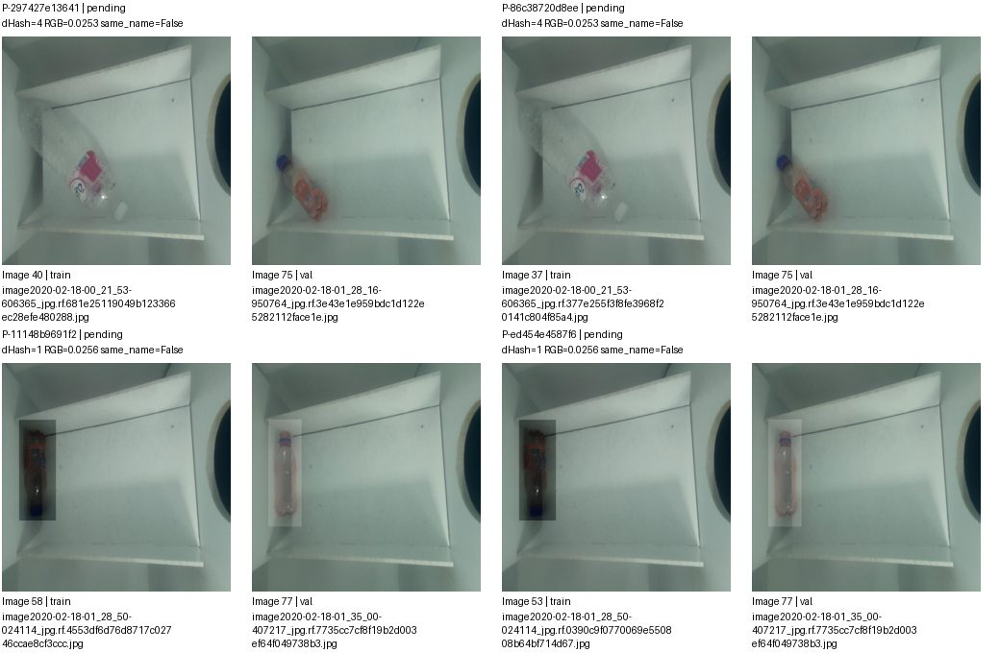

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-297427e13641,images/train/image2020-02-18-00_21_53-606365_jpg.rf.681e25119049b123366ec28efe480288.jpg,images/val/image2020-02-18-01_28_16-950764_jpg.rf.3e43e1e959bdc1d122e5282112face1e.jpg,pending,
P-86c38720d8ee,images/train/image2020-02-18-00_21_53-606365_jpg.rf.377e255f3f8fe3968f20141c804f85a4.jpg,images/val/image2020-02-18-01_28_16-950764_jpg.rf.3e43e1e959bdc1d122e5282112face1e.jpg,pending,
P-11148b9691f2,images/train/image2020-02-18-01_28_50-024114_jpg.rf.4553df6d76d8717c02746ccae8cf3ccc.jpg,images/val/image2020-02-18-01_35_00-407217_jpg.rf.7735cc7cf8f19b2d003ef64f049738b3.jpg,pending,
P-ed454e4587f6,images/train/image2020-02-18-01_28_50-024114_jpg.rf.0390c9f0770069e550808b64bf714d67.jpg,images/val/image2020-02-18-01_35_00-407217_jpg.rf.7735cc7cf8f19b2d003ef64f049738b3.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 52/166 G-586696e3c556 | 77 ảnh, 388 cặp
Split: {'test': 2, 'train': 70, 'val': 5}
Quyết định: {'pending': 388}
Ảnh trang None/13; cặp trang 40/97. Nhóm liên thông không phải kết luận trùng.


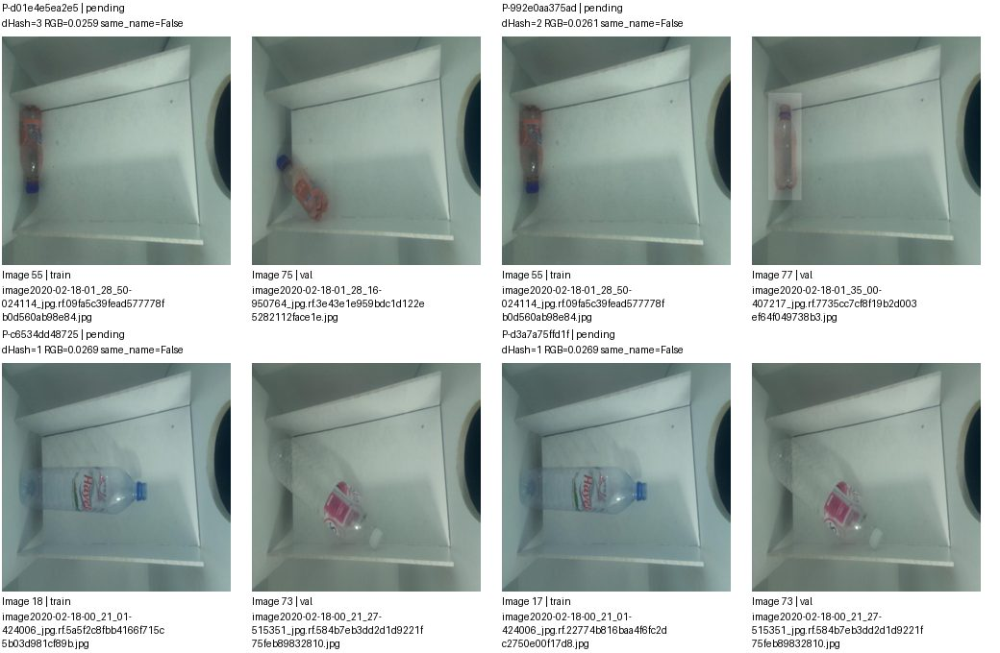

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-d01e4e5ea2e5,images/train/image2020-02-18-01_28_50-024114_jpg.rf.09fa5c39fead577778fb0d560ab98e84.jpg,images/val/image2020-02-18-01_28_16-950764_jpg.rf.3e43e1e959bdc1d122e5282112face1e.jpg,pending,
P-992e0aa375ad,images/train/image2020-02-18-01_28_50-024114_jpg.rf.09fa5c39fead577778fb0d560ab98e84.jpg,images/val/image2020-02-18-01_35_00-407217_jpg.rf.7735cc7cf8f19b2d003ef64f049738b3.jpg,pending,
P-c6534dd48725,images/train/image2020-02-18-00_21_01-424006_jpg.rf.5a5f2c8fbb4166f715c5b03d981cf89b.jpg,images/val/image2020-02-18-00_21_27-515351_jpg.rf.584b7eb3dd2d1d9221f75feb89832810.jpg,pending,
P-d3a7a75ffd1f,images/train/image2020-02-18-00_21_01-424006_jpg.rf.22774b816baa4f6fc2dc2750e00f17d8.jpg,images/val/image2020-02-18-00_21_27-515351_jpg.rf.584b7eb3dd2d1d9221f75feb89832810.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 52/166 G-586696e3c556 | 77 ảnh, 388 cặp
Split: {'test': 2, 'train': 70, 'val': 5}
Quyết định: {'pending': 388}
Ảnh trang None/13; cặp trang 41/97. Nhóm liên thông không phải kết luận trùng.


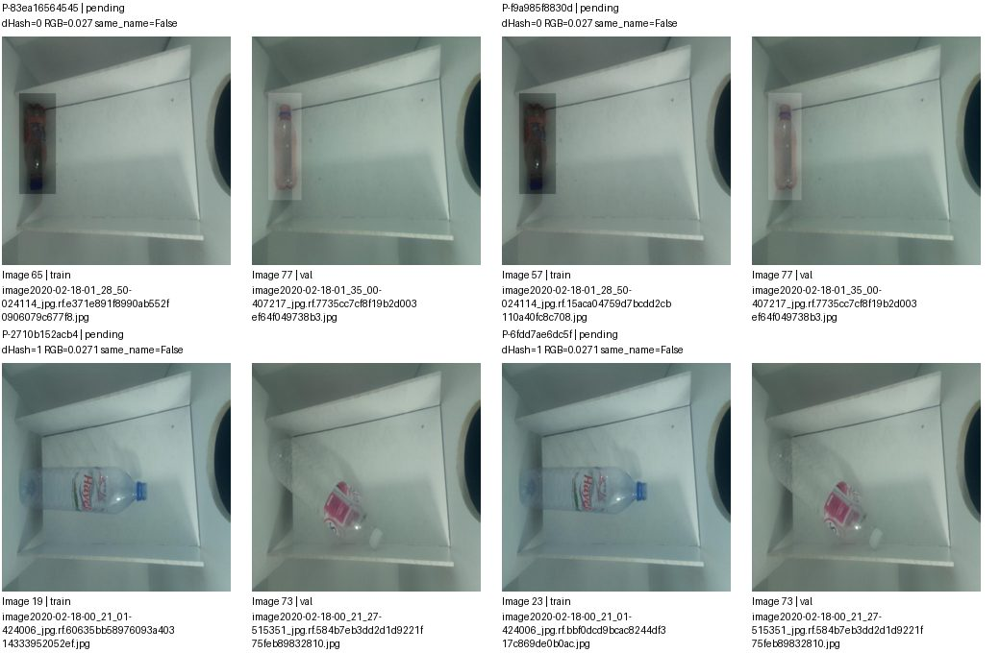

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-83ea16564545,images/train/image2020-02-18-01_28_50-024114_jpg.rf.e371e891f8990ab552f0906079c677f8.jpg,images/val/image2020-02-18-01_35_00-407217_jpg.rf.7735cc7cf8f19b2d003ef64f049738b3.jpg,pending,
P-f9a985f8830d,images/train/image2020-02-18-01_28_50-024114_jpg.rf.15aca04759d7bcdd2cb110a40fc8c708.jpg,images/val/image2020-02-18-01_35_00-407217_jpg.rf.7735cc7cf8f19b2d003ef64f049738b3.jpg,pending,
P-2710b152acb4,images/train/image2020-02-18-00_21_01-424006_jpg.rf.60635bb58976093a40314333952052ef.jpg,images/val/image2020-02-18-00_21_27-515351_jpg.rf.584b7eb3dd2d1d9221f75feb89832810.jpg,pending,
P-6fdd7ae6dc5f,images/train/image2020-02-18-00_21_01-424006_jpg.rf.bbf0dcd9bcac8244df317c869de0b0ac.jpg,images/val/image2020-02-18-00_21_27-515351_jpg.rf.584b7eb3dd2d1d9221f75feb89832810.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 52/166 G-586696e3c556 | 77 ảnh, 388 cặp
Split: {'test': 2, 'train': 70, 'val': 5}
Quyết định: {'pending': 388}
Ảnh trang None/13; cặp trang 42/97. Nhóm liên thông không phải kết luận trùng.


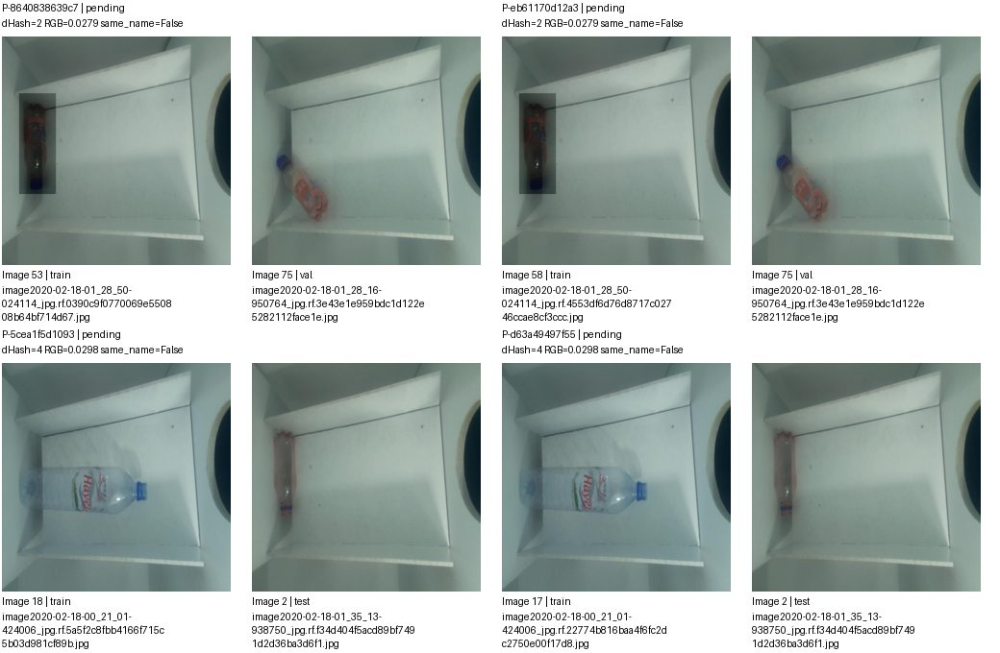

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-8640838639c7,images/train/image2020-02-18-01_28_50-024114_jpg.rf.0390c9f0770069e550808b64bf714d67.jpg,images/val/image2020-02-18-01_28_16-950764_jpg.rf.3e43e1e959bdc1d122e5282112face1e.jpg,pending,
P-eb61170d12a3,images/train/image2020-02-18-01_28_50-024114_jpg.rf.4553df6d76d8717c02746ccae8cf3ccc.jpg,images/val/image2020-02-18-01_28_16-950764_jpg.rf.3e43e1e959bdc1d122e5282112face1e.jpg,pending,
P-5cea1f5d1093,images/train/image2020-02-18-00_21_01-424006_jpg.rf.5a5f2c8fbb4166f715c5b03d981cf89b.jpg,images/test/image2020-02-18-01_35_13-938750_jpg.rf.f34d404f5acd89bf7491d2d36ba3d6f1.jpg,pending,
P-d63a49497f55,images/train/image2020-02-18-00_21_01-424006_jpg.rf.22774b816baa4f6fc2dc2750e00f17d8.jpg,images/test/image2020-02-18-01_35_13-938750_jpg.rf.f34d404f5acd89bf7491d2d36ba3d6f1.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 52/166 G-586696e3c556 | 77 ảnh, 388 cặp
Split: {'test': 2, 'train': 70, 'val': 5}
Quyết định: {'pending': 388}
Ảnh trang None/13; cặp trang 43/97. Nhóm liên thông không phải kết luận trùng.


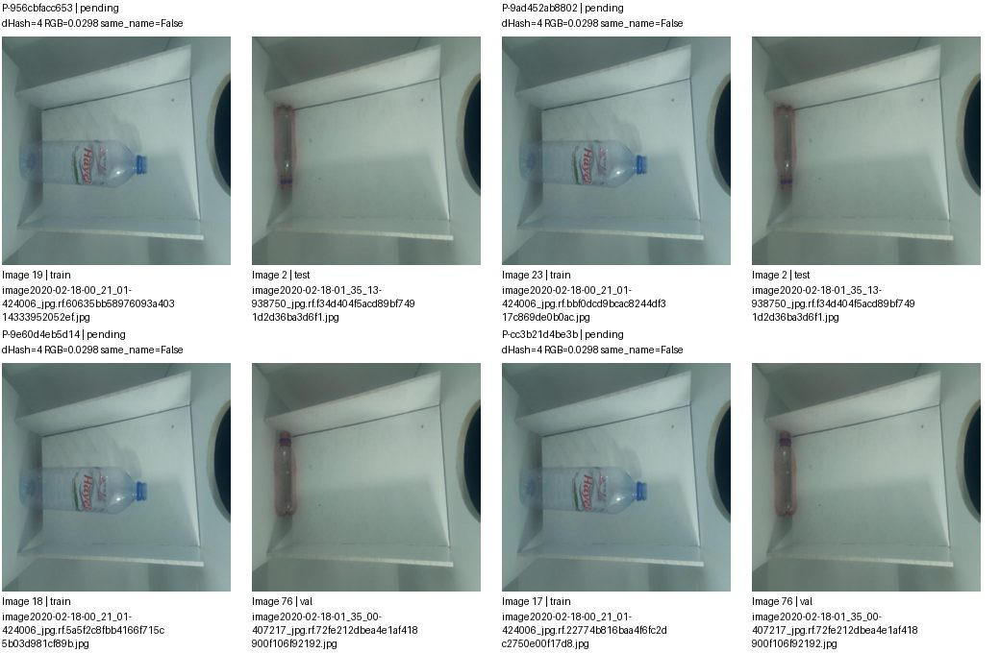

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-956cbfacc653,images/train/image2020-02-18-00_21_01-424006_jpg.rf.60635bb58976093a40314333952052ef.jpg,images/test/image2020-02-18-01_35_13-938750_jpg.rf.f34d404f5acd89bf7491d2d36ba3d6f1.jpg,pending,
P-9ad452ab8802,images/train/image2020-02-18-00_21_01-424006_jpg.rf.bbf0dcd9bcac8244df317c869de0b0ac.jpg,images/test/image2020-02-18-01_35_13-938750_jpg.rf.f34d404f5acd89bf7491d2d36ba3d6f1.jpg,pending,
P-9e60d4eb5d14,images/train/image2020-02-18-00_21_01-424006_jpg.rf.5a5f2c8fbb4166f715c5b03d981cf89b.jpg,images/val/image2020-02-18-01_35_00-407217_jpg.rf.72fe212dbea4e1af418900f106f92192.jpg,pending,
P-cc3b21d4be3b,images/train/image2020-02-18-00_21_01-424006_jpg.rf.22774b816baa4f6fc2dc2750e00f17d8.jpg,images/val/image2020-02-18-01_35_00-407217_jpg.rf.72fe212dbea4e1af418900f106f92192.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 52/166 G-586696e3c556 | 77 ảnh, 388 cặp
Split: {'test': 2, 'train': 70, 'val': 5}
Quyết định: {'pending': 388}
Ảnh trang None/13; cặp trang 44/97. Nhóm liên thông không phải kết luận trùng.


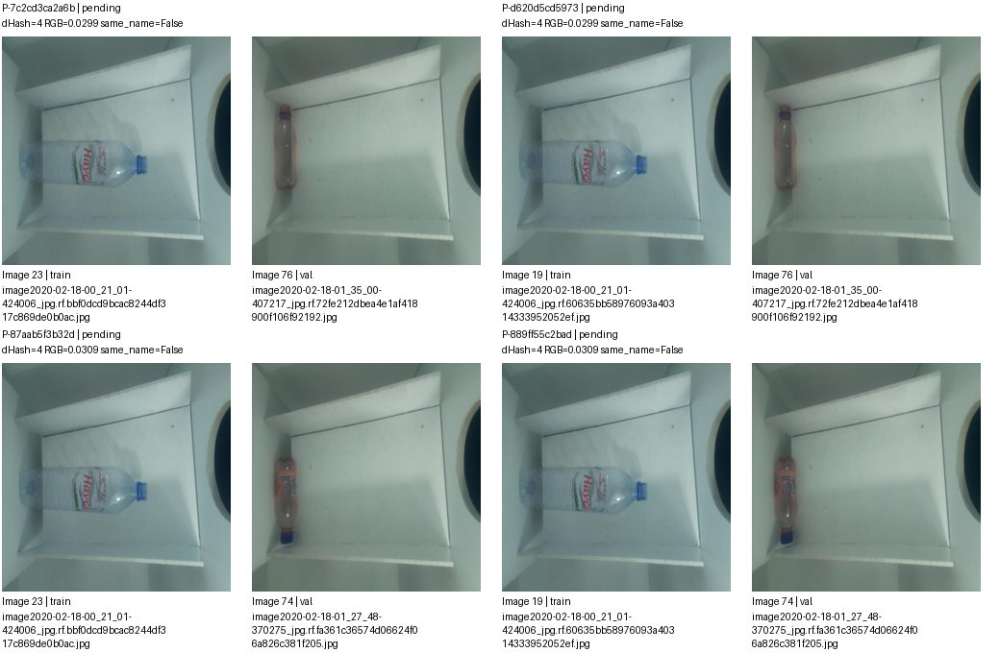

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-7c2cd3ca2a6b,images/train/image2020-02-18-00_21_01-424006_jpg.rf.bbf0dcd9bcac8244df317c869de0b0ac.jpg,images/val/image2020-02-18-01_35_00-407217_jpg.rf.72fe212dbea4e1af418900f106f92192.jpg,pending,
P-d620d5cd5973,images/train/image2020-02-18-00_21_01-424006_jpg.rf.60635bb58976093a40314333952052ef.jpg,images/val/image2020-02-18-01_35_00-407217_jpg.rf.72fe212dbea4e1af418900f106f92192.jpg,pending,
P-87aab5f3b32d,images/train/image2020-02-18-00_21_01-424006_jpg.rf.bbf0dcd9bcac8244df317c869de0b0ac.jpg,images/val/image2020-02-18-01_27_48-370275_jpg.rf.fa361c36574d06624f06a826c381f205.jpg,pending,
P-889ff55c2bad,images/train/image2020-02-18-00_21_01-424006_jpg.rf.60635bb58976093a40314333952052ef.jpg,images/val/image2020-02-18-01_27_48-370275_jpg.rf.fa361c36574d06624f06a826c381f205.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 52/166 G-586696e3c556 | 77 ảnh, 388 cặp
Split: {'test': 2, 'train': 70, 'val': 5}
Quyết định: {'pending': 388}
Ảnh trang None/13; cặp trang 45/97. Nhóm liên thông không phải kết luận trùng.


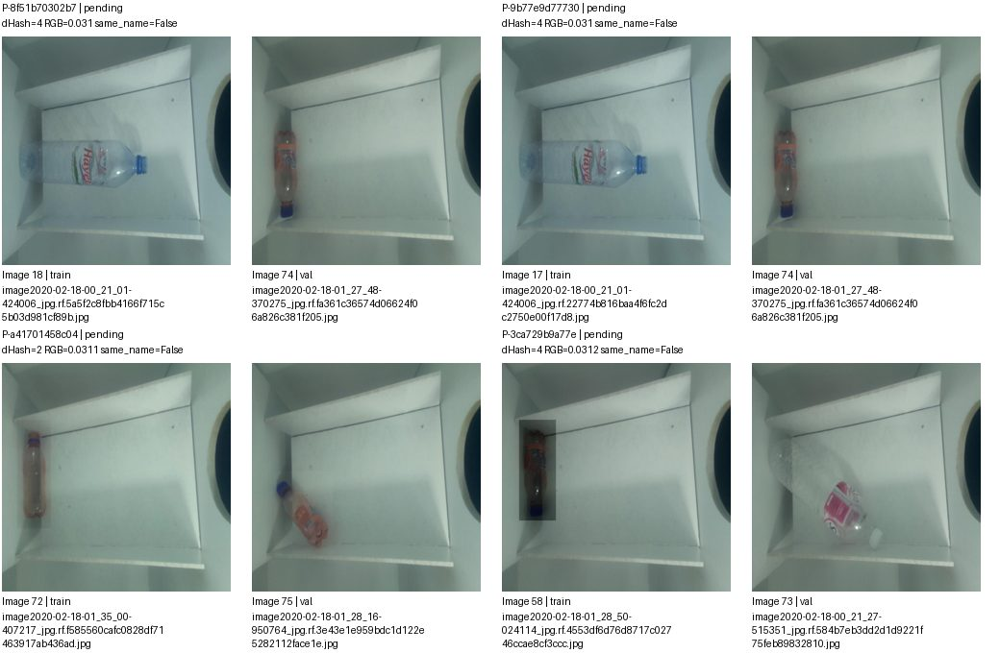

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-8f51b70302b7,images/train/image2020-02-18-00_21_01-424006_jpg.rf.5a5f2c8fbb4166f715c5b03d981cf89b.jpg,images/val/image2020-02-18-01_27_48-370275_jpg.rf.fa361c36574d06624f06a826c381f205.jpg,pending,
P-9b77e9d77730,images/train/image2020-02-18-00_21_01-424006_jpg.rf.22774b816baa4f6fc2dc2750e00f17d8.jpg,images/val/image2020-02-18-01_27_48-370275_jpg.rf.fa361c36574d06624f06a826c381f205.jpg,pending,
P-a41701458c04,images/train/image2020-02-18-01_35_00-407217_jpg.rf.f585560cafc0828df71463917ab436ad.jpg,images/val/image2020-02-18-01_28_16-950764_jpg.rf.3e43e1e959bdc1d122e5282112face1e.jpg,pending,
P-3ca729b9a77e,images/train/image2020-02-18-01_28_50-024114_jpg.rf.4553df6d76d8717c02746ccae8cf3ccc.jpg,images/val/image2020-02-18-00_21_27-515351_jpg.rf.584b7eb3dd2d1d9221f75feb89832810.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 52/166 G-586696e3c556 | 77 ảnh, 388 cặp
Split: {'test': 2, 'train': 70, 'val': 5}
Quyết định: {'pending': 388}
Ảnh trang None/13; cặp trang 46/97. Nhóm liên thông không phải kết luận trùng.


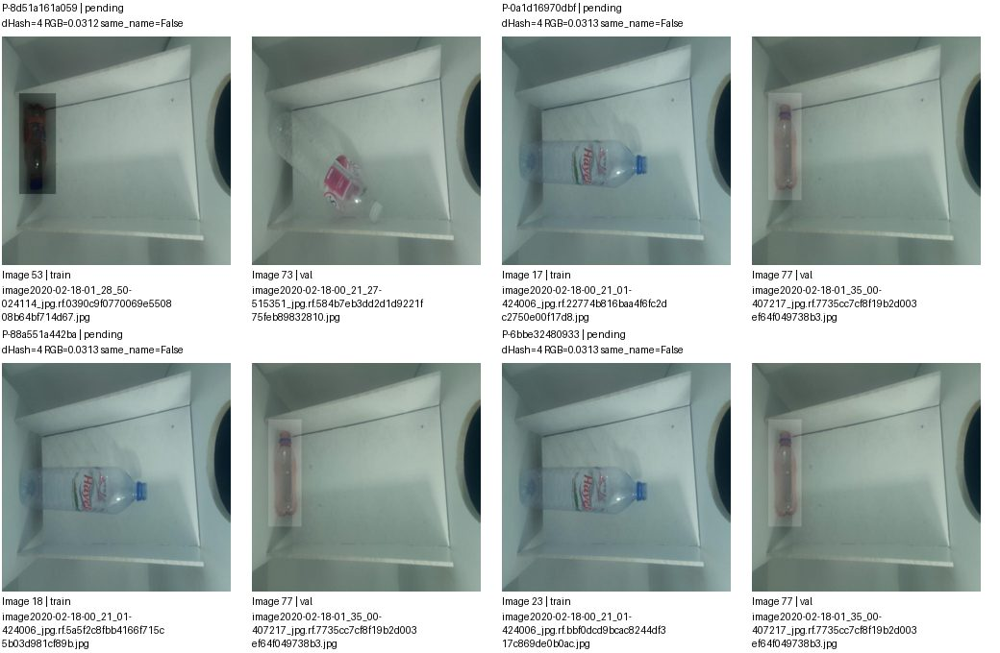

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-8d51a161a059,images/train/image2020-02-18-01_28_50-024114_jpg.rf.0390c9f0770069e550808b64bf714d67.jpg,images/val/image2020-02-18-00_21_27-515351_jpg.rf.584b7eb3dd2d1d9221f75feb89832810.jpg,pending,
P-0a1d16970dbf,images/train/image2020-02-18-00_21_01-424006_jpg.rf.22774b816baa4f6fc2dc2750e00f17d8.jpg,images/val/image2020-02-18-01_35_00-407217_jpg.rf.7735cc7cf8f19b2d003ef64f049738b3.jpg,pending,
P-88a551a442ba,images/train/image2020-02-18-00_21_01-424006_jpg.rf.5a5f2c8fbb4166f715c5b03d981cf89b.jpg,images/val/image2020-02-18-01_35_00-407217_jpg.rf.7735cc7cf8f19b2d003ef64f049738b3.jpg,pending,
P-6bbe32480933,images/train/image2020-02-18-00_21_01-424006_jpg.rf.bbf0dcd9bcac8244df317c869de0b0ac.jpg,images/val/image2020-02-18-01_35_00-407217_jpg.rf.7735cc7cf8f19b2d003ef64f049738b3.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 52/166 G-586696e3c556 | 77 ảnh, 388 cặp
Split: {'test': 2, 'train': 70, 'val': 5}
Quyết định: {'pending': 388}
Ảnh trang None/13; cặp trang 47/97. Nhóm liên thông không phải kết luận trùng.


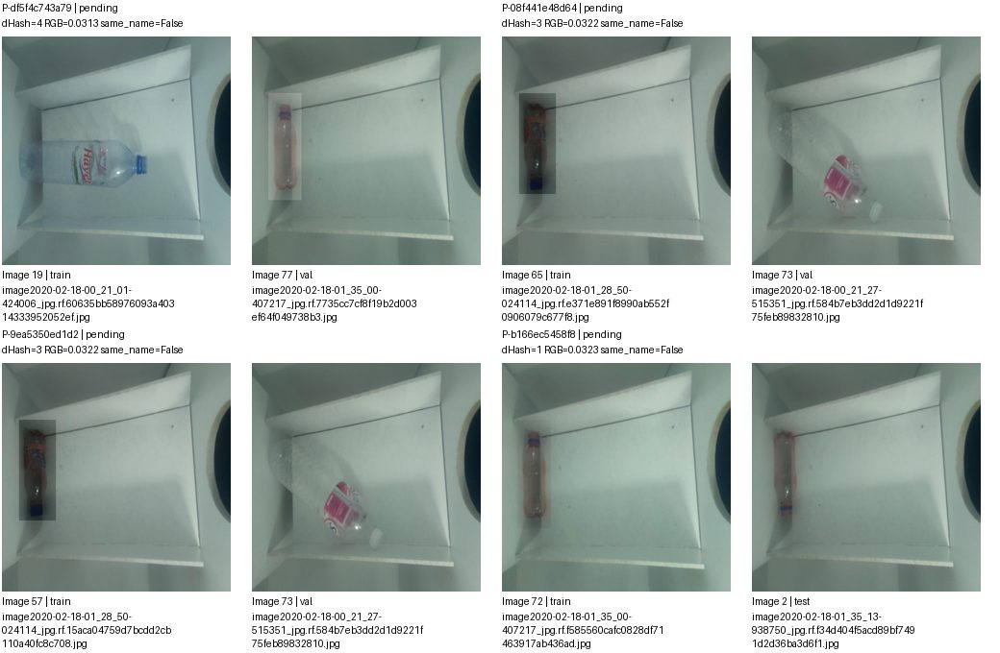

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-df5f4c743a79,images/train/image2020-02-18-00_21_01-424006_jpg.rf.60635bb58976093a40314333952052ef.jpg,images/val/image2020-02-18-01_35_00-407217_jpg.rf.7735cc7cf8f19b2d003ef64f049738b3.jpg,pending,
P-08f441e48d64,images/train/image2020-02-18-01_28_50-024114_jpg.rf.e371e891f8990ab552f0906079c677f8.jpg,images/val/image2020-02-18-00_21_27-515351_jpg.rf.584b7eb3dd2d1d9221f75feb89832810.jpg,pending,
P-9ea5350ed1d2,images/train/image2020-02-18-01_28_50-024114_jpg.rf.15aca04759d7bcdd2cb110a40fc8c708.jpg,images/val/image2020-02-18-00_21_27-515351_jpg.rf.584b7eb3dd2d1d9221f75feb89832810.jpg,pending,
P-b166ec5458f8,images/train/image2020-02-18-01_35_00-407217_jpg.rf.f585560cafc0828df71463917ab436ad.jpg,images/test/image2020-02-18-01_35_13-938750_jpg.rf.f34d404f5acd89bf7491d2d36ba3d6f1.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 52/166 G-586696e3c556 | 77 ảnh, 388 cặp
Split: {'test': 2, 'train': 70, 'val': 5}
Quyết định: {'pending': 388}
Ảnh trang None/13; cặp trang 48/97. Nhóm liên thông không phải kết luận trùng.


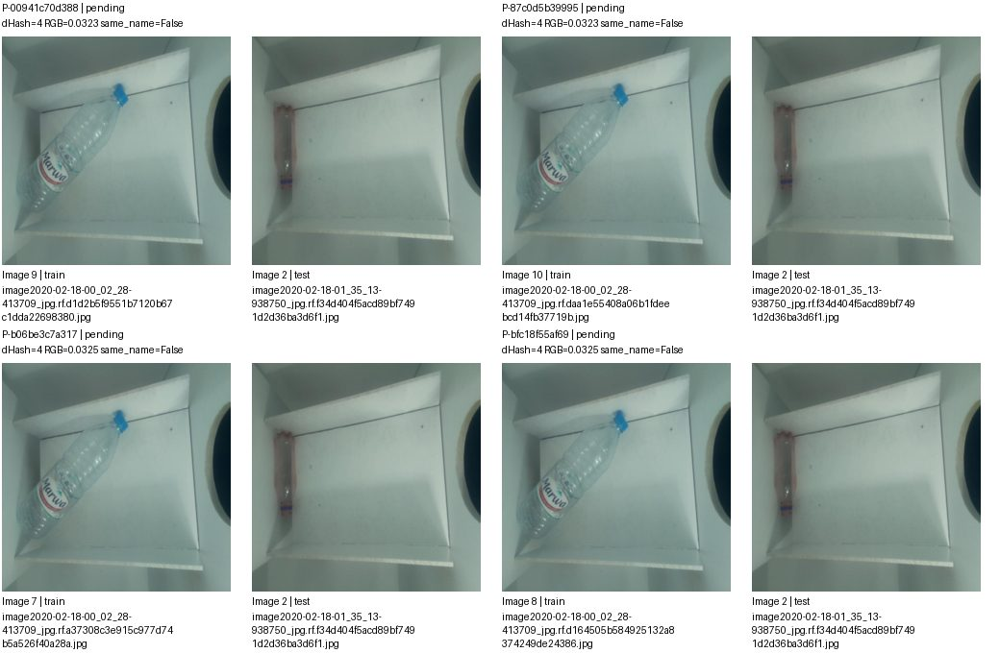

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-00941c70d388,images/train/image2020-02-18-00_02_28-413709_jpg.rf.d1d2b5f9551b7120b67c1dda22698380.jpg,images/test/image2020-02-18-01_35_13-938750_jpg.rf.f34d404f5acd89bf7491d2d36ba3d6f1.jpg,pending,
P-87c0d5b39995,images/train/image2020-02-18-00_02_28-413709_jpg.rf.daa1e55408a06b1fdeebcd14fb37719b.jpg,images/test/image2020-02-18-01_35_13-938750_jpg.rf.f34d404f5acd89bf7491d2d36ba3d6f1.jpg,pending,
P-b06be3c7a317,images/train/image2020-02-18-00_02_28-413709_jpg.rf.a37308c3e915c977d74b5a526f40a28a.jpg,images/test/image2020-02-18-01_35_13-938750_jpg.rf.f34d404f5acd89bf7491d2d36ba3d6f1.jpg,pending,
P-bfc18f55af69,images/train/image2020-02-18-00_02_28-413709_jpg.rf.d164505b584925132a8374249de24386.jpg,images/test/image2020-02-18-01_35_13-938750_jpg.rf.f34d404f5acd89bf7491d2d36ba3d6f1.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 52/166 G-586696e3c556 | 77 ảnh, 388 cặp
Split: {'test': 2, 'train': 70, 'val': 5}
Quyết định: {'pending': 388}
Ảnh trang None/13; cặp trang 49/97. Nhóm liên thông không phải kết luận trùng.


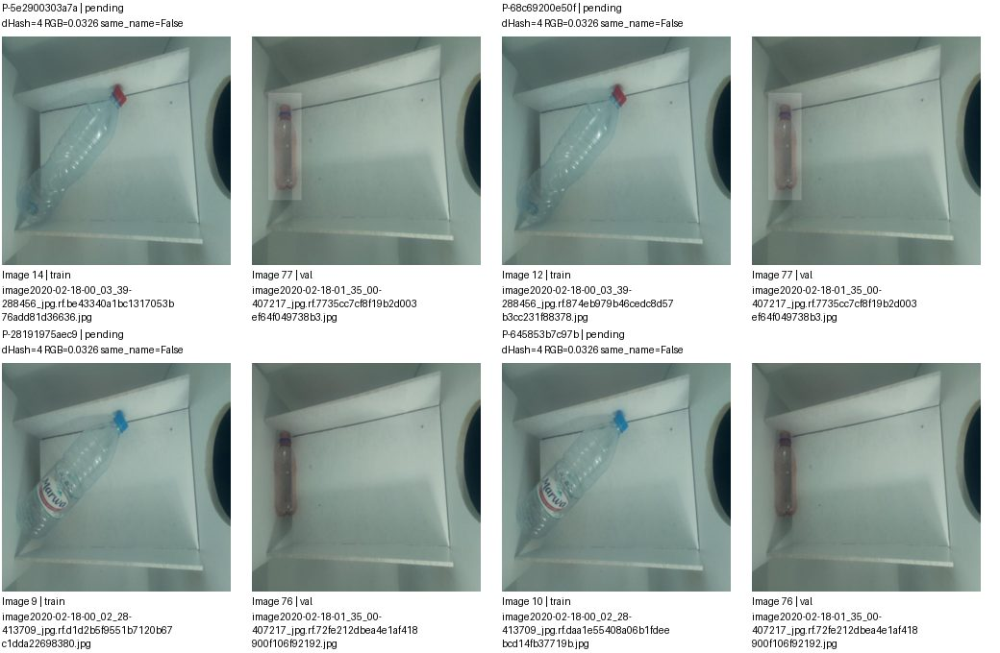

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-5e2900303a7a,images/train/image2020-02-18-00_03_39-288456_jpg.rf.be43340a1bc1317053b76add81d36636.jpg,images/val/image2020-02-18-01_35_00-407217_jpg.rf.7735cc7cf8f19b2d003ef64f049738b3.jpg,pending,
P-68c69200e50f,images/train/image2020-02-18-00_03_39-288456_jpg.rf.874eb979b46cedc8d57b3cc231f88378.jpg,images/val/image2020-02-18-01_35_00-407217_jpg.rf.7735cc7cf8f19b2d003ef64f049738b3.jpg,pending,
P-28191975aec9,images/train/image2020-02-18-00_02_28-413709_jpg.rf.d1d2b5f9551b7120b67c1dda22698380.jpg,images/val/image2020-02-18-01_35_00-407217_jpg.rf.72fe212dbea4e1af418900f106f92192.jpg,pending,
P-645853b7c97b,images/train/image2020-02-18-00_02_28-413709_jpg.rf.daa1e55408a06b1fdeebcd14fb37719b.jpg,images/val/image2020-02-18-01_35_00-407217_jpg.rf.72fe212dbea4e1af418900f106f92192.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 52/166 G-586696e3c556 | 77 ảnh, 388 cặp
Split: {'test': 2, 'train': 70, 'val': 5}
Quyết định: {'pending': 388}
Ảnh trang None/13; cặp trang 50/97. Nhóm liên thông không phải kết luận trùng.


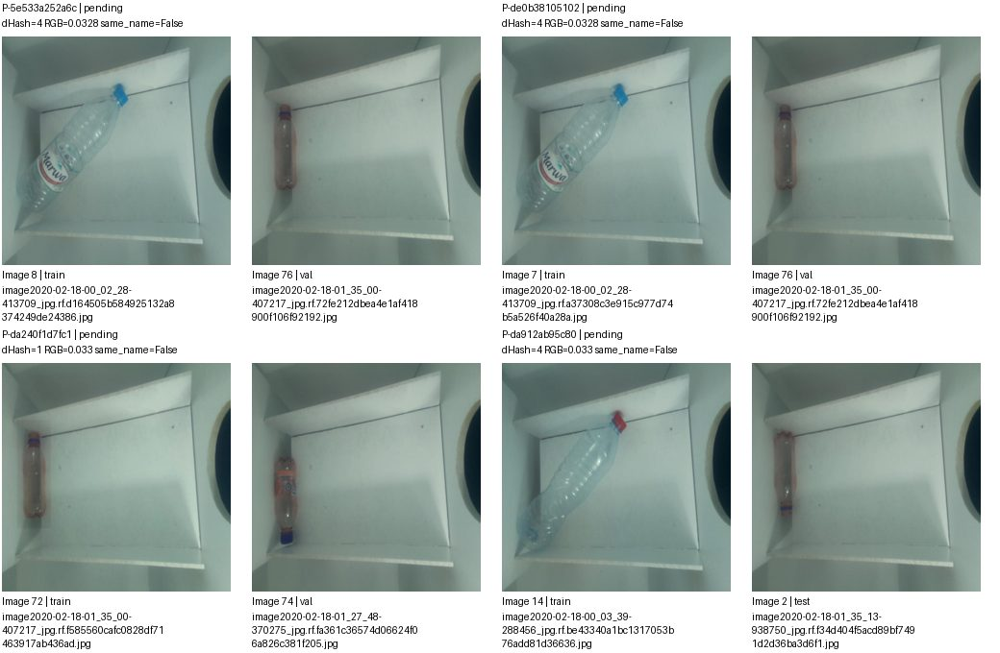

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-5e533a252a6c,images/train/image2020-02-18-00_02_28-413709_jpg.rf.d164505b584925132a8374249de24386.jpg,images/val/image2020-02-18-01_35_00-407217_jpg.rf.72fe212dbea4e1af418900f106f92192.jpg,pending,
P-de0b38105102,images/train/image2020-02-18-00_02_28-413709_jpg.rf.a37308c3e915c977d74b5a526f40a28a.jpg,images/val/image2020-02-18-01_35_00-407217_jpg.rf.72fe212dbea4e1af418900f106f92192.jpg,pending,
P-da240f1d7fc1,images/train/image2020-02-18-01_35_00-407217_jpg.rf.f585560cafc0828df71463917ab436ad.jpg,images/val/image2020-02-18-01_27_48-370275_jpg.rf.fa361c36574d06624f06a826c381f205.jpg,pending,
P-da912ab95c80,images/train/image2020-02-18-00_03_39-288456_jpg.rf.be43340a1bc1317053b76add81d36636.jpg,images/test/image2020-02-18-01_35_13-938750_jpg.rf.f34d404f5acd89bf7491d2d36ba3d6f1.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 52/166 G-586696e3c556 | 77 ảnh, 388 cặp
Split: {'test': 2, 'train': 70, 'val': 5}
Quyết định: {'pending': 388}
Ảnh trang None/13; cặp trang 51/97. Nhóm liên thông không phải kết luận trùng.


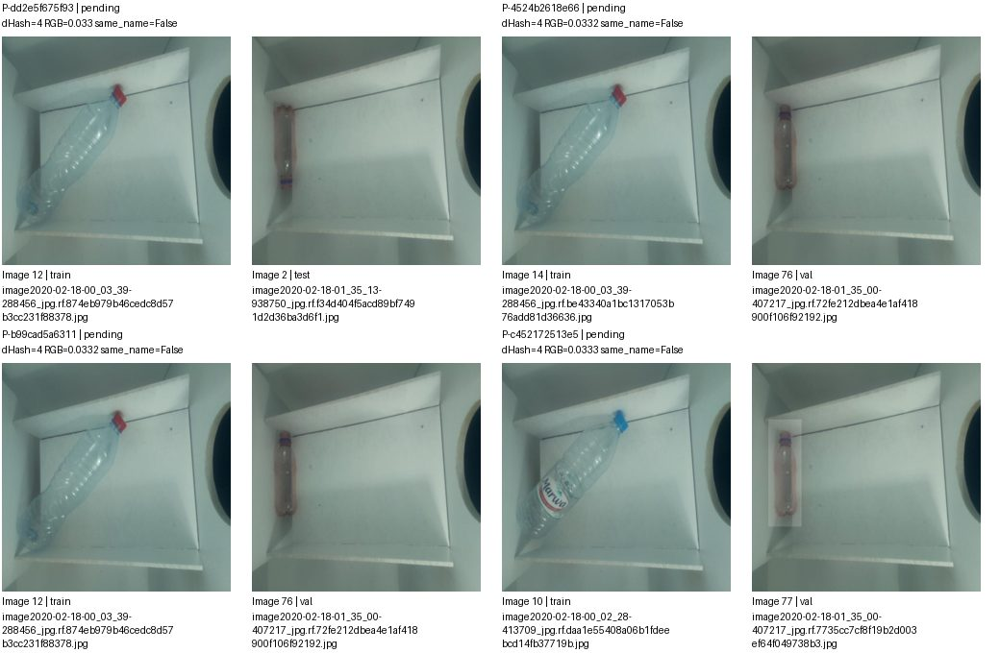

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-dd2e5f675f93,images/train/image2020-02-18-00_03_39-288456_jpg.rf.874eb979b46cedc8d57b3cc231f88378.jpg,images/test/image2020-02-18-01_35_13-938750_jpg.rf.f34d404f5acd89bf7491d2d36ba3d6f1.jpg,pending,
P-4524b2618e66,images/train/image2020-02-18-00_03_39-288456_jpg.rf.be43340a1bc1317053b76add81d36636.jpg,images/val/image2020-02-18-01_35_00-407217_jpg.rf.72fe212dbea4e1af418900f106f92192.jpg,pending,
P-b99cad5a6311,images/train/image2020-02-18-00_03_39-288456_jpg.rf.874eb979b46cedc8d57b3cc231f88378.jpg,images/val/image2020-02-18-01_35_00-407217_jpg.rf.72fe212dbea4e1af418900f106f92192.jpg,pending,
P-c452172513e5,images/train/image2020-02-18-00_02_28-413709_jpg.rf.daa1e55408a06b1fdeebcd14fb37719b.jpg,images/val/image2020-02-18-01_35_00-407217_jpg.rf.7735cc7cf8f19b2d003ef64f049738b3.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 52/166 G-586696e3c556 | 77 ảnh, 388 cặp
Split: {'test': 2, 'train': 70, 'val': 5}
Quyết định: {'pending': 388}
Ảnh trang None/13; cặp trang 52/97. Nhóm liên thông không phải kết luận trùng.


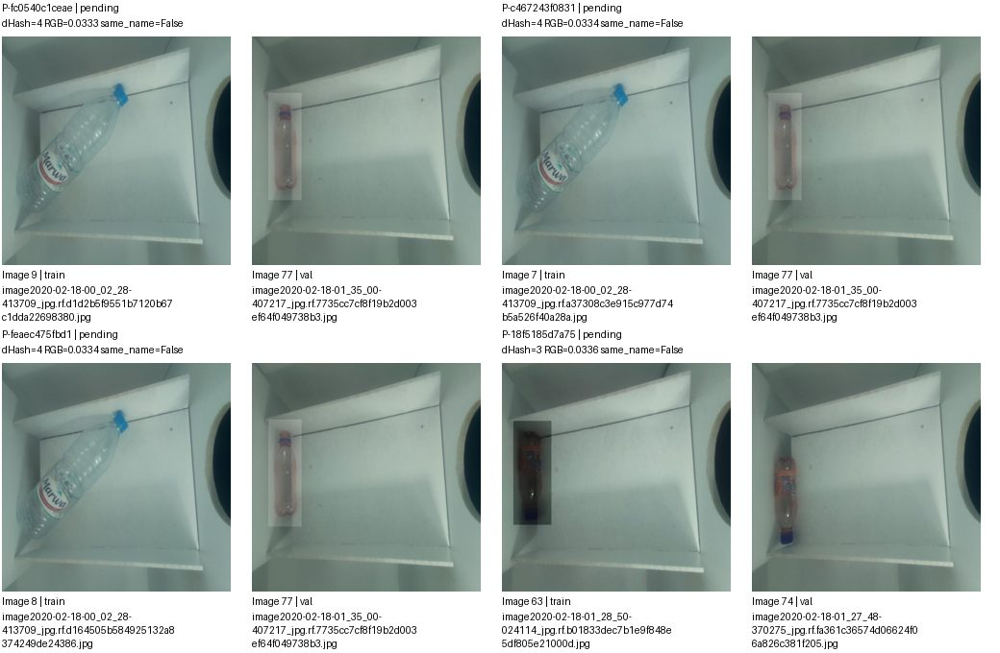

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-fc0540c1ceae,images/train/image2020-02-18-00_02_28-413709_jpg.rf.d1d2b5f9551b7120b67c1dda22698380.jpg,images/val/image2020-02-18-01_35_00-407217_jpg.rf.7735cc7cf8f19b2d003ef64f049738b3.jpg,pending,
P-c467243f0831,images/train/image2020-02-18-00_02_28-413709_jpg.rf.a37308c3e915c977d74b5a526f40a28a.jpg,images/val/image2020-02-18-01_35_00-407217_jpg.rf.7735cc7cf8f19b2d003ef64f049738b3.jpg,pending,
P-feaec475fbd1,images/train/image2020-02-18-00_02_28-413709_jpg.rf.d164505b584925132a8374249de24386.jpg,images/val/image2020-02-18-01_35_00-407217_jpg.rf.7735cc7cf8f19b2d003ef64f049738b3.jpg,pending,
P-18f5185d7a75,images/train/image2020-02-18-01_28_50-024114_jpg.rf.b01833dec7b1e9f848e5df805e21000d.jpg,images/val/image2020-02-18-01_27_48-370275_jpg.rf.fa361c36574d06624f06a826c381f205.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 52/166 G-586696e3c556 | 77 ảnh, 388 cặp
Split: {'test': 2, 'train': 70, 'val': 5}
Quyết định: {'pending': 388}
Ảnh trang None/13; cặp trang 53/97. Nhóm liên thông không phải kết luận trùng.


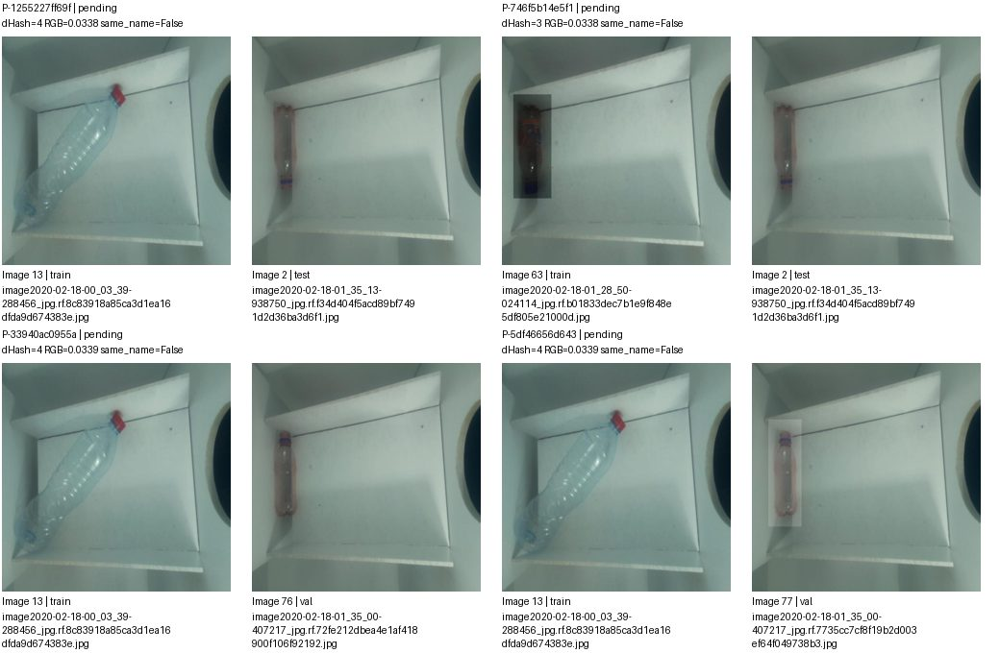

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-1255227ff69f,images/train/image2020-02-18-00_03_39-288456_jpg.rf.8c83918a85ca3d1ea16dfda9d674383e.jpg,images/test/image2020-02-18-01_35_13-938750_jpg.rf.f34d404f5acd89bf7491d2d36ba3d6f1.jpg,pending,
P-746f5b14e5f1,images/train/image2020-02-18-01_28_50-024114_jpg.rf.b01833dec7b1e9f848e5df805e21000d.jpg,images/test/image2020-02-18-01_35_13-938750_jpg.rf.f34d404f5acd89bf7491d2d36ba3d6f1.jpg,pending,
P-33940ac0955a,images/train/image2020-02-18-00_03_39-288456_jpg.rf.8c83918a85ca3d1ea16dfda9d674383e.jpg,images/val/image2020-02-18-01_35_00-407217_jpg.rf.72fe212dbea4e1af418900f106f92192.jpg,pending,
P-5df46656d643,images/train/image2020-02-18-00_03_39-288456_jpg.rf.8c83918a85ca3d1ea16dfda9d674383e.jpg,images/val/image2020-02-18-01_35_00-407217_jpg.rf.7735cc7cf8f19b2d003ef64f049738b3.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 52/166 G-586696e3c556 | 77 ảnh, 388 cặp
Split: {'test': 2, 'train': 70, 'val': 5}
Quyết định: {'pending': 388}
Ảnh trang None/13; cặp trang 54/97. Nhóm liên thông không phải kết luận trùng.


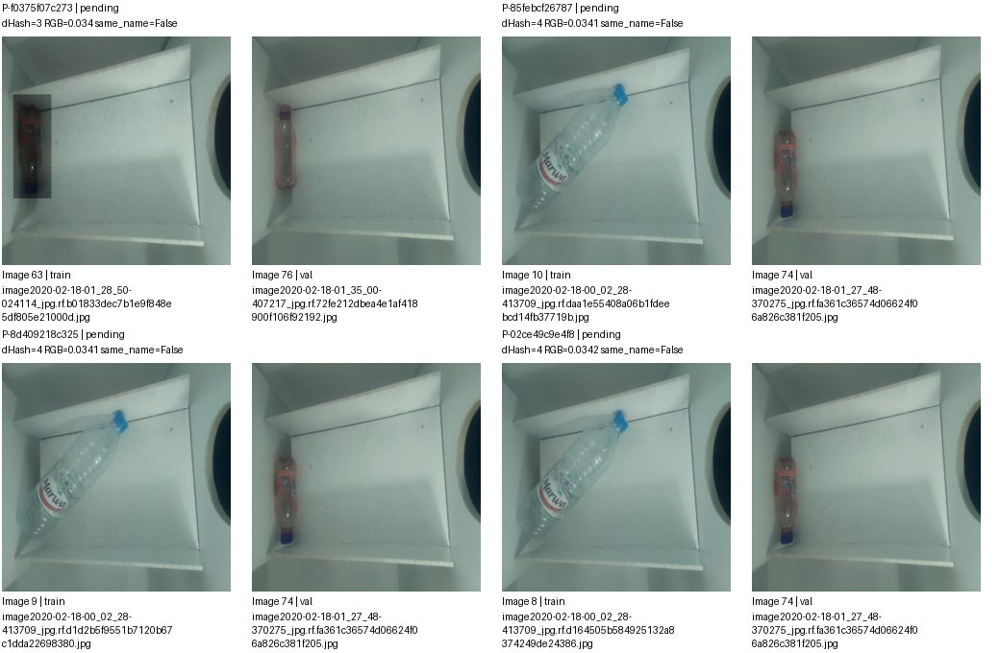

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-f0375f07c273,images/train/image2020-02-18-01_28_50-024114_jpg.rf.b01833dec7b1e9f848e5df805e21000d.jpg,images/val/image2020-02-18-01_35_00-407217_jpg.rf.72fe212dbea4e1af418900f106f92192.jpg,pending,
P-85febcf26787,images/train/image2020-02-18-00_02_28-413709_jpg.rf.daa1e55408a06b1fdeebcd14fb37719b.jpg,images/val/image2020-02-18-01_27_48-370275_jpg.rf.fa361c36574d06624f06a826c381f205.jpg,pending,
P-8d409218c325,images/train/image2020-02-18-00_02_28-413709_jpg.rf.d1d2b5f9551b7120b67c1dda22698380.jpg,images/val/image2020-02-18-01_27_48-370275_jpg.rf.fa361c36574d06624f06a826c381f205.jpg,pending,
P-02ce49c9e4f8,images/train/image2020-02-18-00_02_28-413709_jpg.rf.d164505b584925132a8374249de24386.jpg,images/val/image2020-02-18-01_27_48-370275_jpg.rf.fa361c36574d06624f06a826c381f205.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 52/166 G-586696e3c556 | 77 ảnh, 388 cặp
Split: {'test': 2, 'train': 70, 'val': 5}
Quyết định: {'pending': 388}
Ảnh trang None/13; cặp trang 55/97. Nhóm liên thông không phải kết luận trùng.


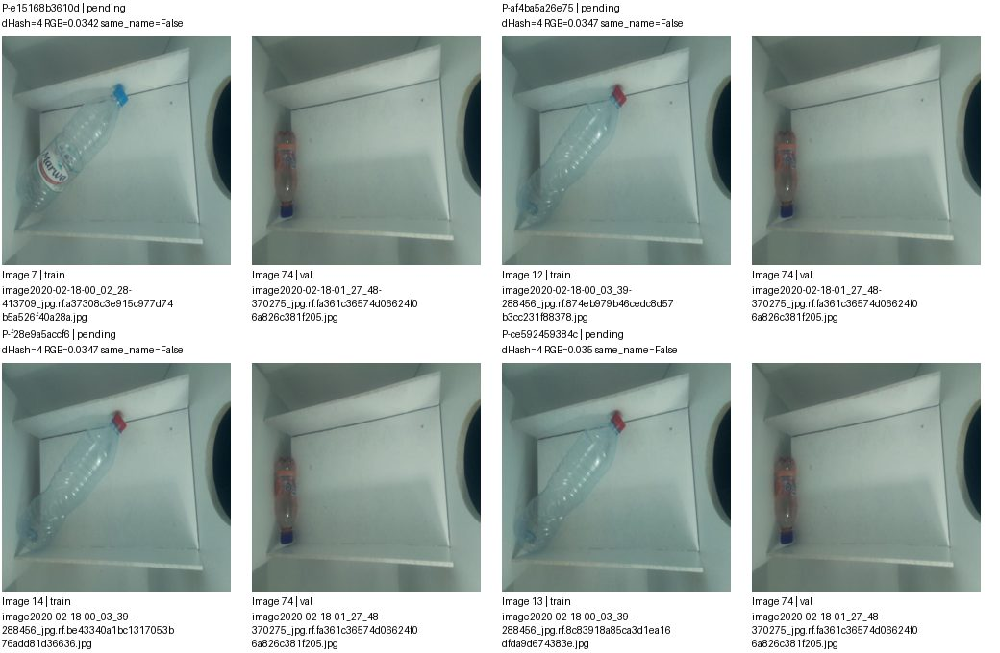

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-e15168b3610d,images/train/image2020-02-18-00_02_28-413709_jpg.rf.a37308c3e915c977d74b5a526f40a28a.jpg,images/val/image2020-02-18-01_27_48-370275_jpg.rf.fa361c36574d06624f06a826c381f205.jpg,pending,
P-af4ba5a26e75,images/train/image2020-02-18-00_03_39-288456_jpg.rf.874eb979b46cedc8d57b3cc231f88378.jpg,images/val/image2020-02-18-01_27_48-370275_jpg.rf.fa361c36574d06624f06a826c381f205.jpg,pending,
P-f28e9a5accf6,images/train/image2020-02-18-00_03_39-288456_jpg.rf.be43340a1bc1317053b76add81d36636.jpg,images/val/image2020-02-18-01_27_48-370275_jpg.rf.fa361c36574d06624f06a826c381f205.jpg,pending,
P-ce592459384c,images/train/image2020-02-18-00_03_39-288456_jpg.rf.8c83918a85ca3d1ea16dfda9d674383e.jpg,images/val/image2020-02-18-01_27_48-370275_jpg.rf.fa361c36574d06624f06a826c381f205.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 52/166 G-586696e3c556 | 77 ảnh, 388 cặp
Split: {'test': 2, 'train': 70, 'val': 5}
Quyết định: {'pending': 388}
Ảnh trang None/13; cặp trang 56/97. Nhóm liên thông không phải kết luận trùng.


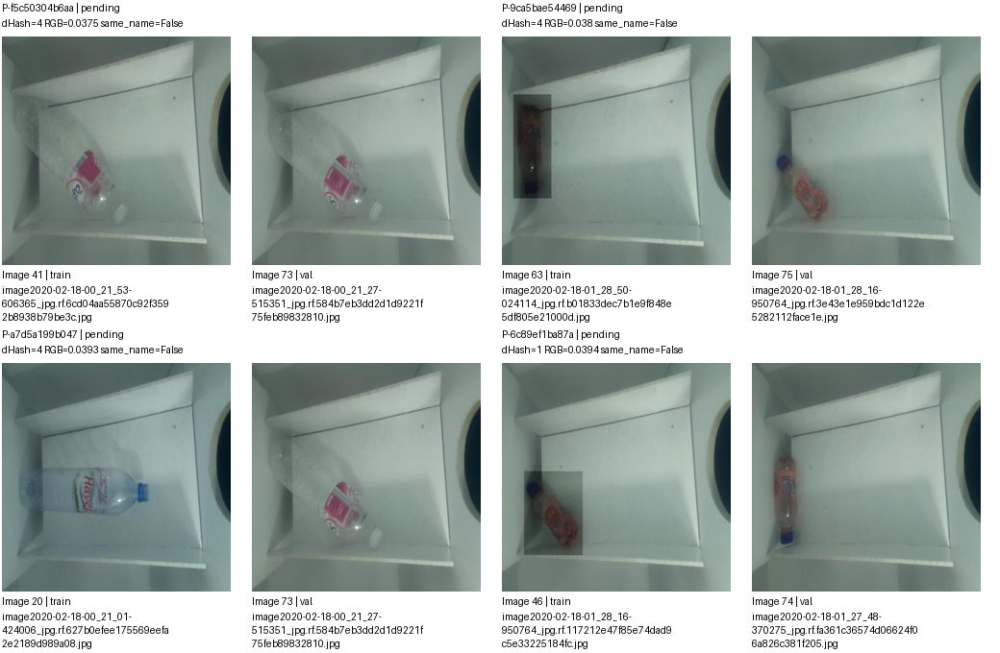

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-f5c50304b6aa,images/train/image2020-02-18-00_21_53-606365_jpg.rf.6cd04aa55870c92f3592b8938b79be3c.jpg,images/val/image2020-02-18-00_21_27-515351_jpg.rf.584b7eb3dd2d1d9221f75feb89832810.jpg,pending,
P-9ca5bae54469,images/train/image2020-02-18-01_28_50-024114_jpg.rf.b01833dec7b1e9f848e5df805e21000d.jpg,images/val/image2020-02-18-01_28_16-950764_jpg.rf.3e43e1e959bdc1d122e5282112face1e.jpg,pending,
P-a7d5a199b047,images/train/image2020-02-18-00_21_01-424006_jpg.rf.627b0efee175569eefa2e2189d989a08.jpg,images/val/image2020-02-18-00_21_27-515351_jpg.rf.584b7eb3dd2d1d9221f75feb89832810.jpg,pending,
P-6c89ef1ba87a,images/train/image2020-02-18-01_28_16-950764_jpg.rf.117212e47f85e74dad9c5e33225184fc.jpg,images/val/image2020-02-18-01_27_48-370275_jpg.rf.fa361c36574d06624f06a826c381f205.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 52/166 G-586696e3c556 | 77 ảnh, 388 cặp
Split: {'test': 2, 'train': 70, 'val': 5}
Quyết định: {'pending': 388}
Ảnh trang None/13; cặp trang 57/97. Nhóm liên thông không phải kết luận trùng.


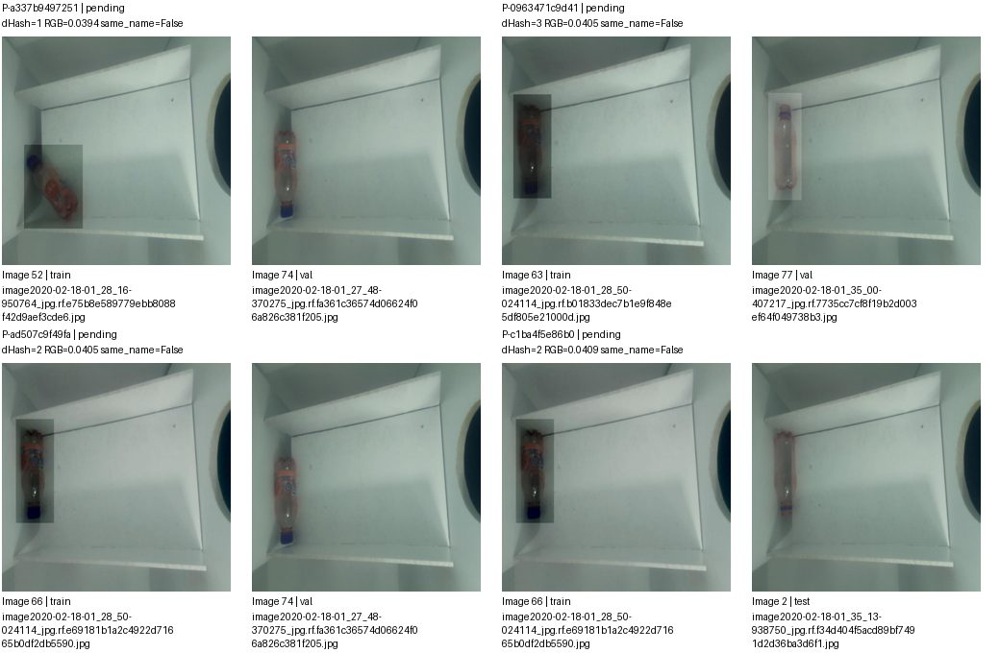

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-a337b9497251,images/train/image2020-02-18-01_28_16-950764_jpg.rf.e75b8e589779ebb8088f42d9aef3cde6.jpg,images/val/image2020-02-18-01_27_48-370275_jpg.rf.fa361c36574d06624f06a826c381f205.jpg,pending,
P-0963471c9d41,images/train/image2020-02-18-01_28_50-024114_jpg.rf.b01833dec7b1e9f848e5df805e21000d.jpg,images/val/image2020-02-18-01_35_00-407217_jpg.rf.7735cc7cf8f19b2d003ef64f049738b3.jpg,pending,
P-ad507c9f49fa,images/train/image2020-02-18-01_28_50-024114_jpg.rf.e69181b1a2c4922d71665b0df2db5590.jpg,images/val/image2020-02-18-01_27_48-370275_jpg.rf.fa361c36574d06624f06a826c381f205.jpg,pending,
P-c1ba4f5e86b0,images/train/image2020-02-18-01_28_50-024114_jpg.rf.e69181b1a2c4922d71665b0df2db5590.jpg,images/test/image2020-02-18-01_35_13-938750_jpg.rf.f34d404f5acd89bf7491d2d36ba3d6f1.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 52/166 G-586696e3c556 | 77 ảnh, 388 cặp
Split: {'test': 2, 'train': 70, 'val': 5}
Quyết định: {'pending': 388}
Ảnh trang None/13; cặp trang 58/97. Nhóm liên thông không phải kết luận trùng.


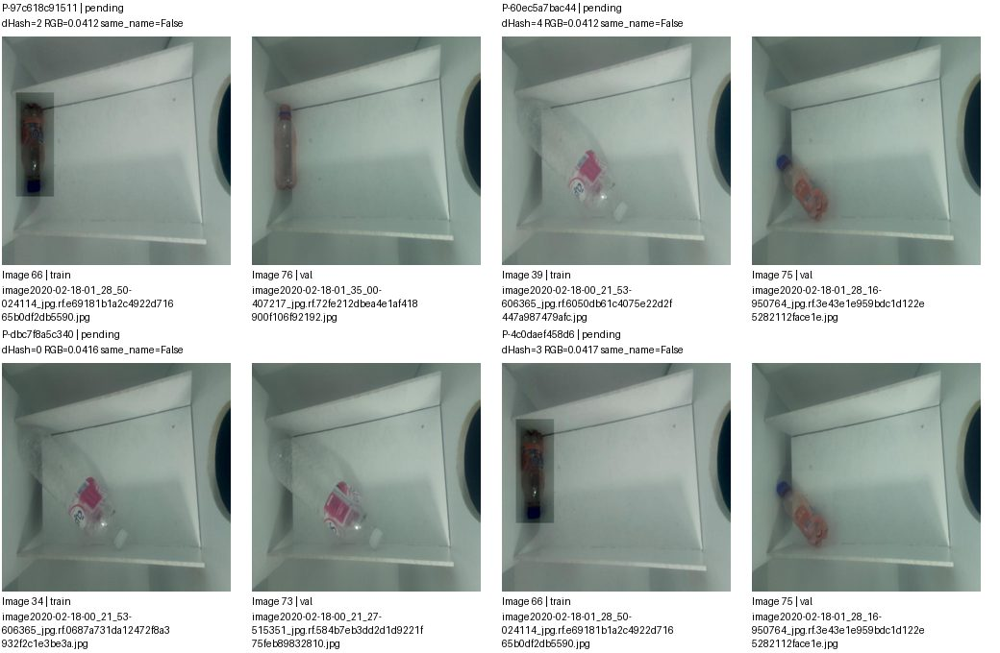

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-97c618c91511,images/train/image2020-02-18-01_28_50-024114_jpg.rf.e69181b1a2c4922d71665b0df2db5590.jpg,images/val/image2020-02-18-01_35_00-407217_jpg.rf.72fe212dbea4e1af418900f106f92192.jpg,pending,
P-60ec5a7bac44,images/train/image2020-02-18-00_21_53-606365_jpg.rf.6050db61c4075e22d2f447a987479afc.jpg,images/val/image2020-02-18-01_28_16-950764_jpg.rf.3e43e1e959bdc1d122e5282112face1e.jpg,pending,
P-dbc7f8a5c340,images/train/image2020-02-18-00_21_53-606365_jpg.rf.0687a731da12472f8a3932f2c1e3be3a.jpg,images/val/image2020-02-18-00_21_27-515351_jpg.rf.584b7eb3dd2d1d9221f75feb89832810.jpg,pending,
P-4c0daef458d6,images/train/image2020-02-18-01_28_50-024114_jpg.rf.e69181b1a2c4922d71665b0df2db5590.jpg,images/val/image2020-02-18-01_28_16-950764_jpg.rf.3e43e1e959bdc1d122e5282112face1e.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 52/166 G-586696e3c556 | 77 ảnh, 388 cặp
Split: {'test': 2, 'train': 70, 'val': 5}
Quyết định: {'pending': 388}
Ảnh trang None/13; cặp trang 59/97. Nhóm liên thông không phải kết luận trùng.


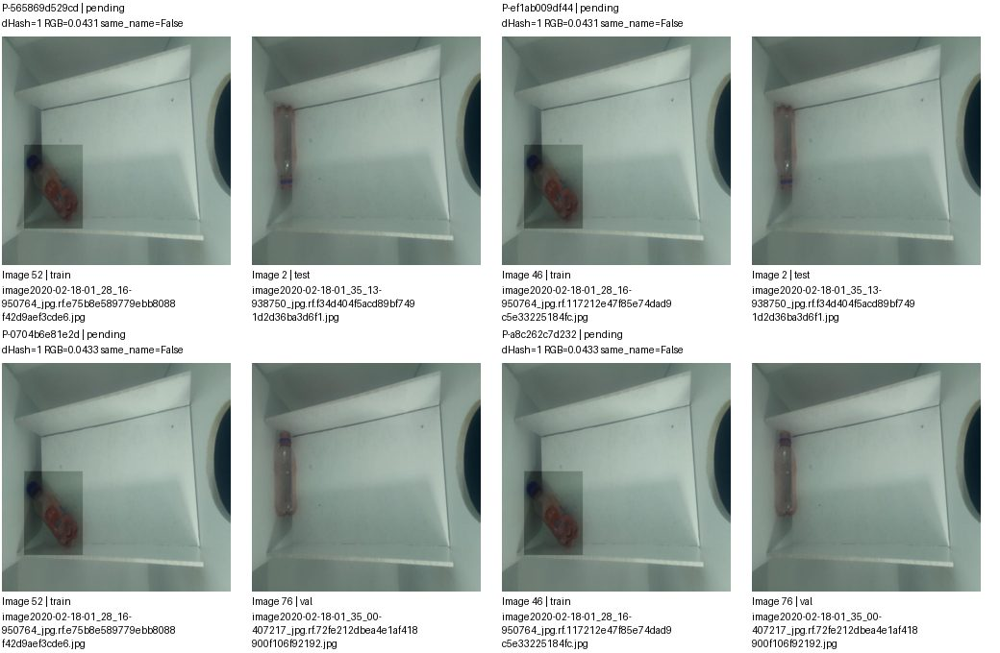

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-565869d529cd,images/train/image2020-02-18-01_28_16-950764_jpg.rf.e75b8e589779ebb8088f42d9aef3cde6.jpg,images/test/image2020-02-18-01_35_13-938750_jpg.rf.f34d404f5acd89bf7491d2d36ba3d6f1.jpg,pending,
P-ef1ab009df44,images/train/image2020-02-18-01_28_16-950764_jpg.rf.117212e47f85e74dad9c5e33225184fc.jpg,images/test/image2020-02-18-01_35_13-938750_jpg.rf.f34d404f5acd89bf7491d2d36ba3d6f1.jpg,pending,
P-0704b6e81e2d,images/train/image2020-02-18-01_28_16-950764_jpg.rf.e75b8e589779ebb8088f42d9aef3cde6.jpg,images/val/image2020-02-18-01_35_00-407217_jpg.rf.72fe212dbea4e1af418900f106f92192.jpg,pending,
P-a8c262c7d232,images/train/image2020-02-18-01_28_16-950764_jpg.rf.117212e47f85e74dad9c5e33225184fc.jpg,images/val/image2020-02-18-01_35_00-407217_jpg.rf.72fe212dbea4e1af418900f106f92192.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 52/166 G-586696e3c556 | 77 ảnh, 388 cặp
Split: {'test': 2, 'train': 70, 'val': 5}
Quyết định: {'pending': 388}
Ảnh trang None/13; cặp trang 60/97. Nhóm liên thông không phải kết luận trùng.


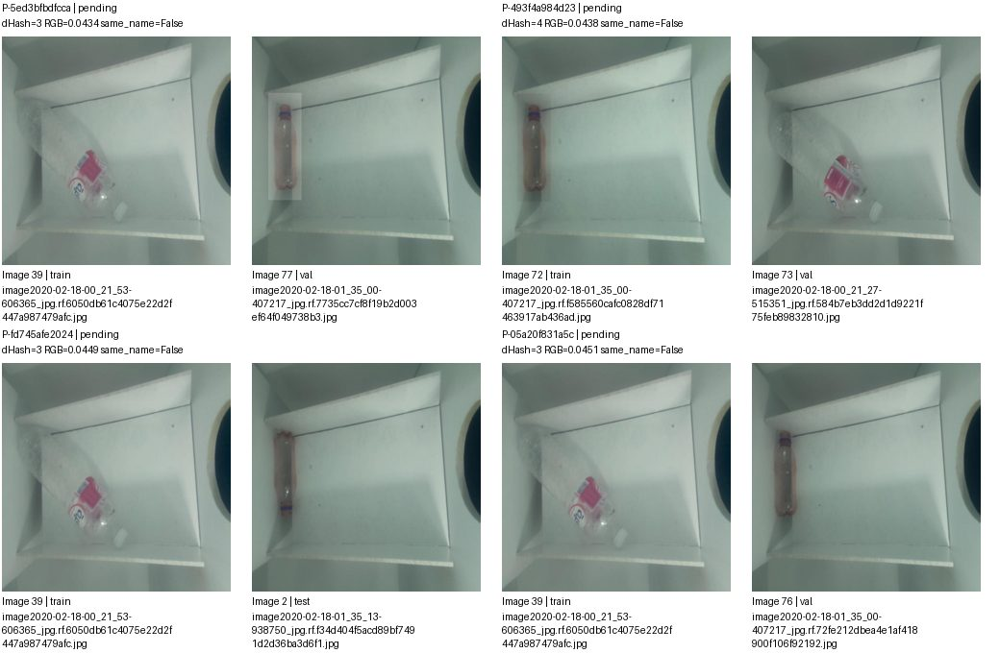

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-5ed3bfbdfcca,images/train/image2020-02-18-00_21_53-606365_jpg.rf.6050db61c4075e22d2f447a987479afc.jpg,images/val/image2020-02-18-01_35_00-407217_jpg.rf.7735cc7cf8f19b2d003ef64f049738b3.jpg,pending,
P-493f4a984d23,images/train/image2020-02-18-01_35_00-407217_jpg.rf.f585560cafc0828df71463917ab436ad.jpg,images/val/image2020-02-18-00_21_27-515351_jpg.rf.584b7eb3dd2d1d9221f75feb89832810.jpg,pending,
P-fd745afe2024,images/train/image2020-02-18-00_21_53-606365_jpg.rf.6050db61c4075e22d2f447a987479afc.jpg,images/test/image2020-02-18-01_35_13-938750_jpg.rf.f34d404f5acd89bf7491d2d36ba3d6f1.jpg,pending,
P-05a20f831a5c,images/train/image2020-02-18-00_21_53-606365_jpg.rf.6050db61c4075e22d2f447a987479afc.jpg,images/val/image2020-02-18-01_35_00-407217_jpg.rf.72fe212dbea4e1af418900f106f92192.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 52/166 G-586696e3c556 | 77 ảnh, 388 cặp
Split: {'test': 2, 'train': 70, 'val': 5}
Quyết định: {'pending': 388}
Ảnh trang None/13; cặp trang 61/97. Nhóm liên thông không phải kết luận trùng.


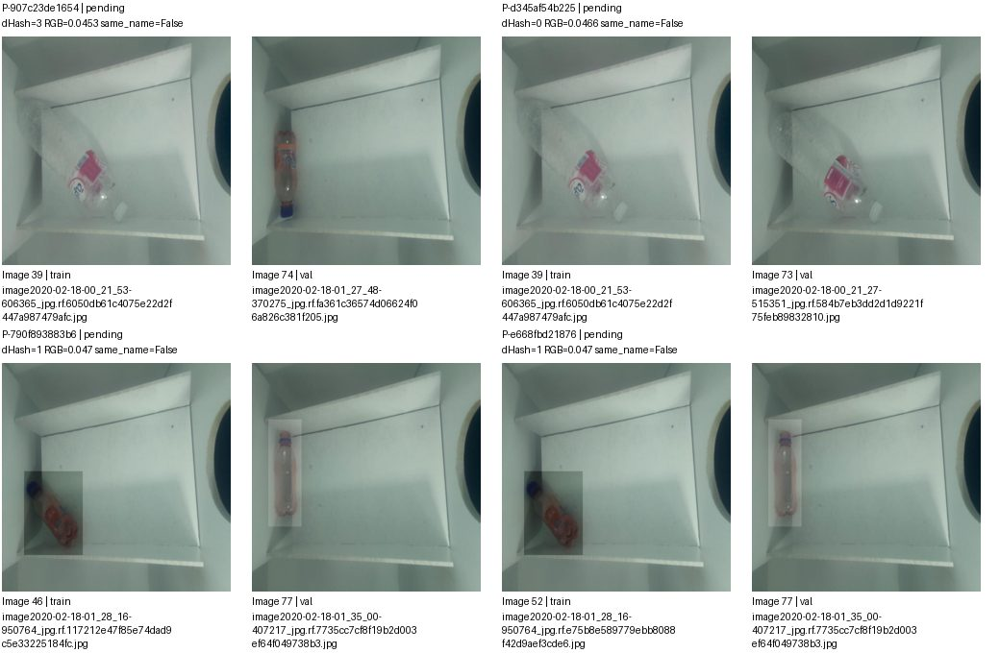

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-907c23de1654,images/train/image2020-02-18-00_21_53-606365_jpg.rf.6050db61c4075e22d2f447a987479afc.jpg,images/val/image2020-02-18-01_27_48-370275_jpg.rf.fa361c36574d06624f06a826c381f205.jpg,pending,
P-d345af54b225,images/train/image2020-02-18-00_21_53-606365_jpg.rf.6050db61c4075e22d2f447a987479afc.jpg,images/val/image2020-02-18-00_21_27-515351_jpg.rf.584b7eb3dd2d1d9221f75feb89832810.jpg,pending,
P-790f893883b6,images/train/image2020-02-18-01_28_16-950764_jpg.rf.117212e47f85e74dad9c5e33225184fc.jpg,images/val/image2020-02-18-01_35_00-407217_jpg.rf.7735cc7cf8f19b2d003ef64f049738b3.jpg,pending,
P-e668fbd21876,images/train/image2020-02-18-01_28_16-950764_jpg.rf.e75b8e589779ebb8088f42d9aef3cde6.jpg,images/val/image2020-02-18-01_35_00-407217_jpg.rf.7735cc7cf8f19b2d003ef64f049738b3.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 52/166 G-586696e3c556 | 77 ảnh, 388 cặp
Split: {'test': 2, 'train': 70, 'val': 5}
Quyết định: {'pending': 388}
Ảnh trang None/13; cặp trang 62/97. Nhóm liên thông không phải kết luận trùng.


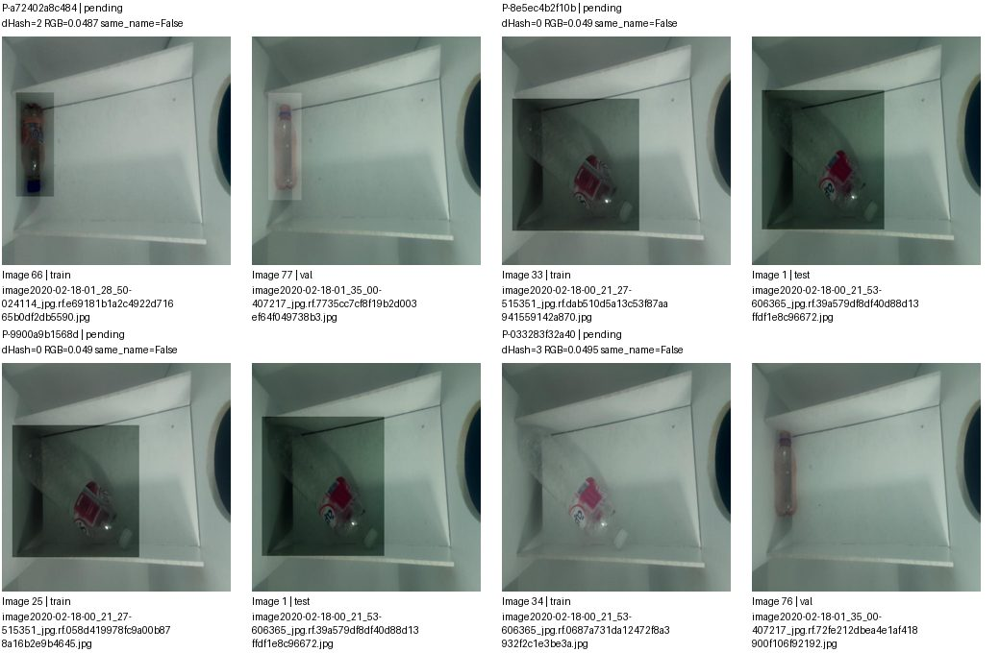

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-a72402a8c484,images/train/image2020-02-18-01_28_50-024114_jpg.rf.e69181b1a2c4922d71665b0df2db5590.jpg,images/val/image2020-02-18-01_35_00-407217_jpg.rf.7735cc7cf8f19b2d003ef64f049738b3.jpg,pending,
P-8e5ec4b2f10b,images/train/image2020-02-18-00_21_27-515351_jpg.rf.dab510d5a13c53f87aa941559142a870.jpg,images/test/image2020-02-18-00_21_53-606365_jpg.rf.39a579df8df40d88d13ffdf1e8c96672.jpg,pending,
P-9900a9b1568d,images/train/image2020-02-18-00_21_27-515351_jpg.rf.058d419978fc9a00b878a16b2e9b4645.jpg,images/test/image2020-02-18-00_21_53-606365_jpg.rf.39a579df8df40d88d13ffdf1e8c96672.jpg,pending,
P-033283f32a40,images/train/image2020-02-18-00_21_53-606365_jpg.rf.0687a731da12472f8a3932f2c1e3be3a.jpg,images/val/image2020-02-18-01_35_00-407217_jpg.rf.72fe212dbea4e1af418900f106f92192.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 52/166 G-586696e3c556 | 77 ảnh, 388 cặp
Split: {'test': 2, 'train': 70, 'val': 5}
Quyết định: {'pending': 388}
Ảnh trang None/13; cặp trang 63/97. Nhóm liên thông không phải kết luận trùng.


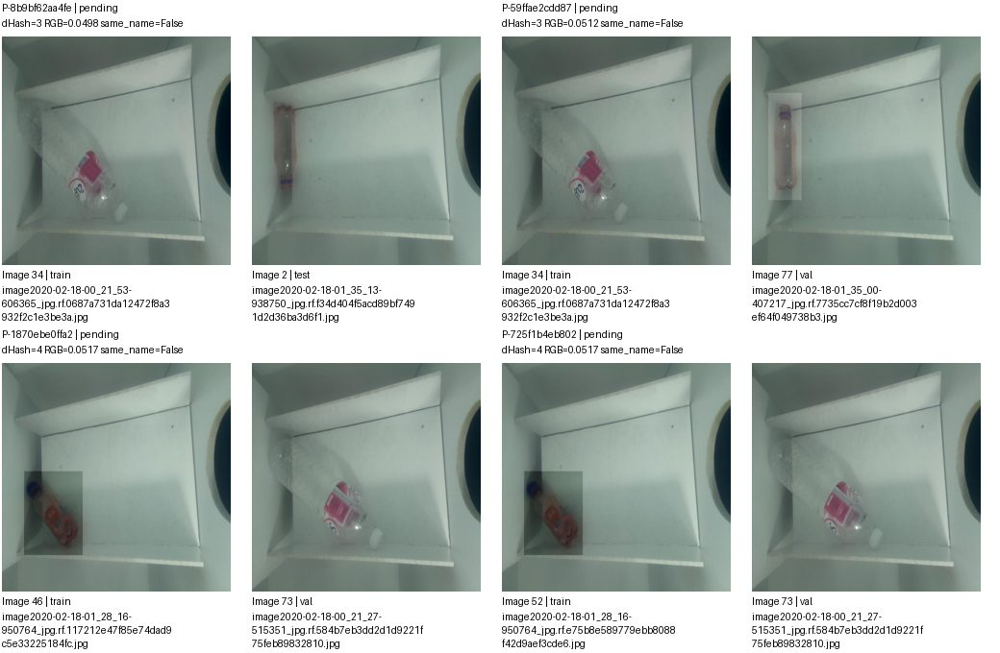

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-8b9bf62aa4fe,images/train/image2020-02-18-00_21_53-606365_jpg.rf.0687a731da12472f8a3932f2c1e3be3a.jpg,images/test/image2020-02-18-01_35_13-938750_jpg.rf.f34d404f5acd89bf7491d2d36ba3d6f1.jpg,pending,
P-59ffae2cdd87,images/train/image2020-02-18-00_21_53-606365_jpg.rf.0687a731da12472f8a3932f2c1e3be3a.jpg,images/val/image2020-02-18-01_35_00-407217_jpg.rf.7735cc7cf8f19b2d003ef64f049738b3.jpg,pending,
P-1870ebe0ffa2,images/train/image2020-02-18-01_28_16-950764_jpg.rf.117212e47f85e74dad9c5e33225184fc.jpg,images/val/image2020-02-18-00_21_27-515351_jpg.rf.584b7eb3dd2d1d9221f75feb89832810.jpg,pending,
P-725f1b4eb802,images/train/image2020-02-18-01_28_16-950764_jpg.rf.e75b8e589779ebb8088f42d9aef3cde6.jpg,images/val/image2020-02-18-00_21_27-515351_jpg.rf.584b7eb3dd2d1d9221f75feb89832810.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 52/166 G-586696e3c556 | 77 ảnh, 388 cặp
Split: {'test': 2, 'train': 70, 'val': 5}
Quyết định: {'pending': 388}
Ảnh trang None/13; cặp trang 64/97. Nhóm liên thông không phải kết luận trùng.


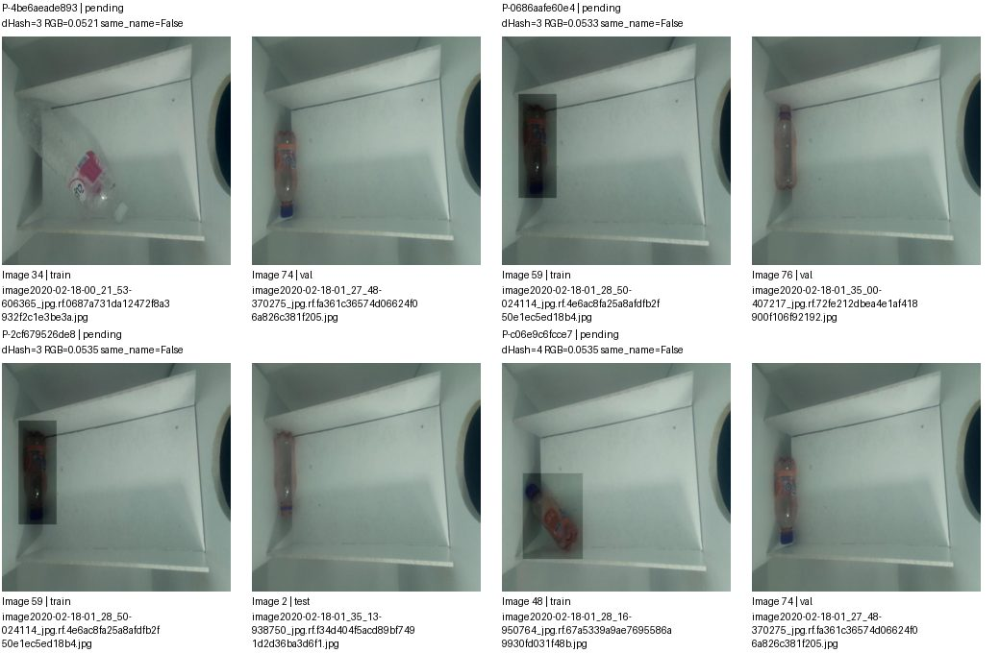

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-4be6aeade893,images/train/image2020-02-18-00_21_53-606365_jpg.rf.0687a731da12472f8a3932f2c1e3be3a.jpg,images/val/image2020-02-18-01_27_48-370275_jpg.rf.fa361c36574d06624f06a826c381f205.jpg,pending,
P-0686aafe60e4,images/train/image2020-02-18-01_28_50-024114_jpg.rf.4e6ac8fa25a8afdfb2f50e1ec5ed18b4.jpg,images/val/image2020-02-18-01_35_00-407217_jpg.rf.72fe212dbea4e1af418900f106f92192.jpg,pending,
P-2cf679526de8,images/train/image2020-02-18-01_28_50-024114_jpg.rf.4e6ac8fa25a8afdfb2f50e1ec5ed18b4.jpg,images/test/image2020-02-18-01_35_13-938750_jpg.rf.f34d404f5acd89bf7491d2d36ba3d6f1.jpg,pending,
P-c06e9c6fcce7,images/train/image2020-02-18-01_28_16-950764_jpg.rf.67a5339a9ae7695586a9930fd031f48b.jpg,images/val/image2020-02-18-01_27_48-370275_jpg.rf.fa361c36574d06624f06a826c381f205.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 52/166 G-586696e3c556 | 77 ảnh, 388 cặp
Split: {'test': 2, 'train': 70, 'val': 5}
Quyết định: {'pending': 388}
Ảnh trang None/13; cặp trang 65/97. Nhóm liên thông không phải kết luận trùng.


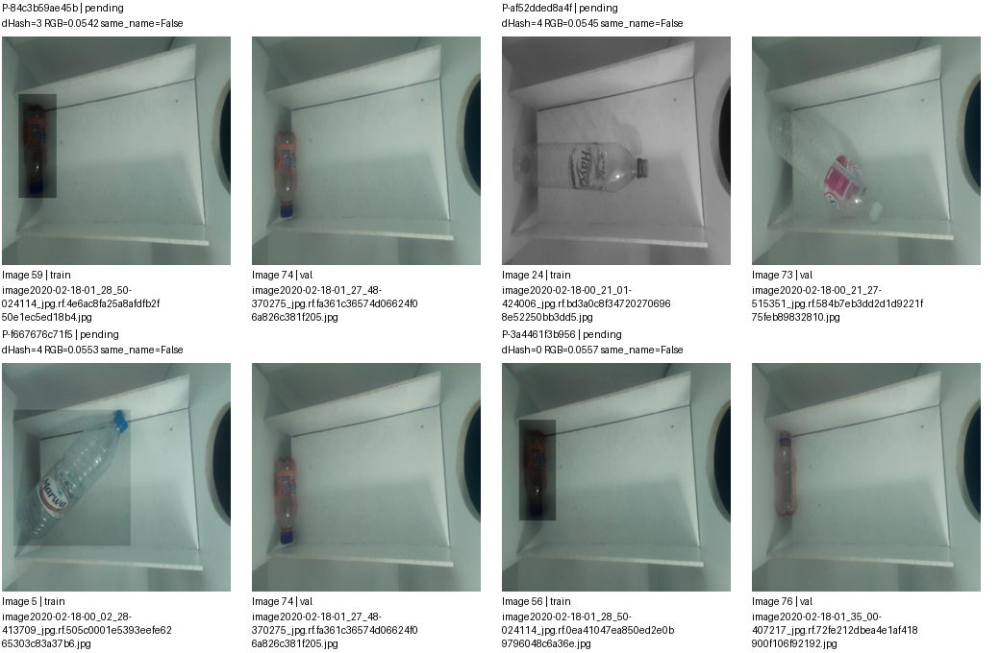

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-84c3b59ae45b,images/train/image2020-02-18-01_28_50-024114_jpg.rf.4e6ac8fa25a8afdfb2f50e1ec5ed18b4.jpg,images/val/image2020-02-18-01_27_48-370275_jpg.rf.fa361c36574d06624f06a826c381f205.jpg,pending,
P-af52dded8a4f,images/train/image2020-02-18-00_21_01-424006_jpg.rf.bd3a0c8f347202706968e52250bb3dd5.jpg,images/val/image2020-02-18-00_21_27-515351_jpg.rf.584b7eb3dd2d1d9221f75feb89832810.jpg,pending,
P-f667676c71f5,images/train/image2020-02-18-00_02_28-413709_jpg.rf.505c0001e5393eefe6265303c83a37b6.jpg,images/val/image2020-02-18-01_27_48-370275_jpg.rf.fa361c36574d06624f06a826c381f205.jpg,pending,
P-3a4461f3b956,images/train/image2020-02-18-01_28_50-024114_jpg.rf.0ea41047ea850ed2e0b9796048c6a36e.jpg,images/val/image2020-02-18-01_35_00-407217_jpg.rf.72fe212dbea4e1af418900f106f92192.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 52/166 G-586696e3c556 | 77 ảnh, 388 cặp
Split: {'test': 2, 'train': 70, 'val': 5}
Quyết định: {'pending': 388}
Ảnh trang None/13; cặp trang 66/97. Nhóm liên thông không phải kết luận trùng.


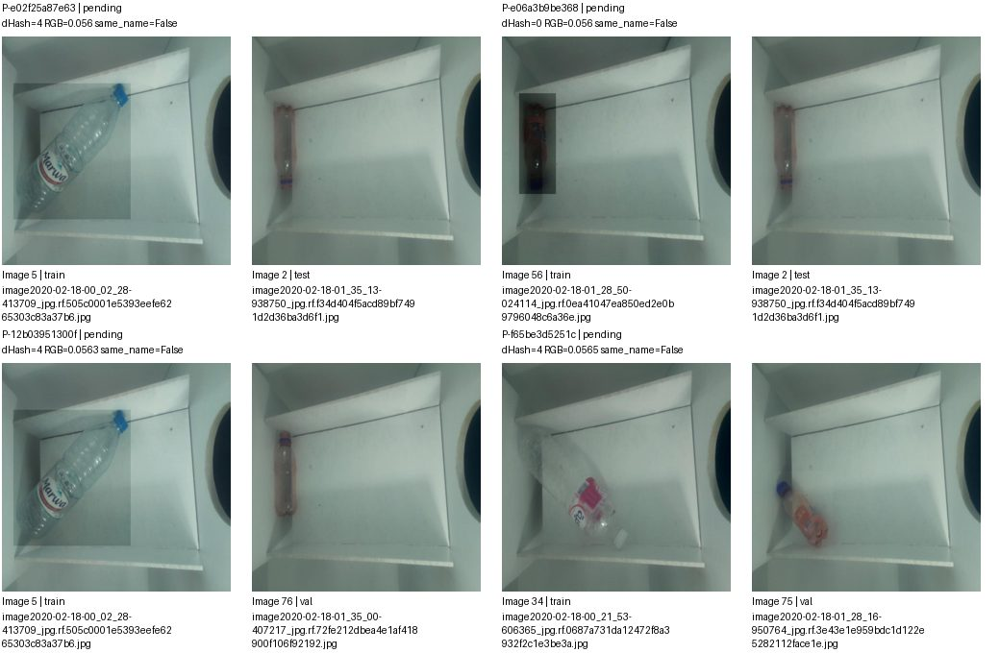

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-e02f25a87e63,images/train/image2020-02-18-00_02_28-413709_jpg.rf.505c0001e5393eefe6265303c83a37b6.jpg,images/test/image2020-02-18-01_35_13-938750_jpg.rf.f34d404f5acd89bf7491d2d36ba3d6f1.jpg,pending,
P-e06a3b9be368,images/train/image2020-02-18-01_28_50-024114_jpg.rf.0ea41047ea850ed2e0b9796048c6a36e.jpg,images/test/image2020-02-18-01_35_13-938750_jpg.rf.f34d404f5acd89bf7491d2d36ba3d6f1.jpg,pending,
P-12b03951300f,images/train/image2020-02-18-00_02_28-413709_jpg.rf.505c0001e5393eefe6265303c83a37b6.jpg,images/val/image2020-02-18-01_35_00-407217_jpg.rf.72fe212dbea4e1af418900f106f92192.jpg,pending,
P-f65be3d5251c,images/train/image2020-02-18-00_21_53-606365_jpg.rf.0687a731da12472f8a3932f2c1e3be3a.jpg,images/val/image2020-02-18-01_28_16-950764_jpg.rf.3e43e1e959bdc1d122e5282112face1e.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 52/166 G-586696e3c556 | 77 ảnh, 388 cặp
Split: {'test': 2, 'train': 70, 'val': 5}
Quyết định: {'pending': 388}
Ảnh trang None/13; cặp trang 67/97. Nhóm liên thông không phải kết luận trùng.


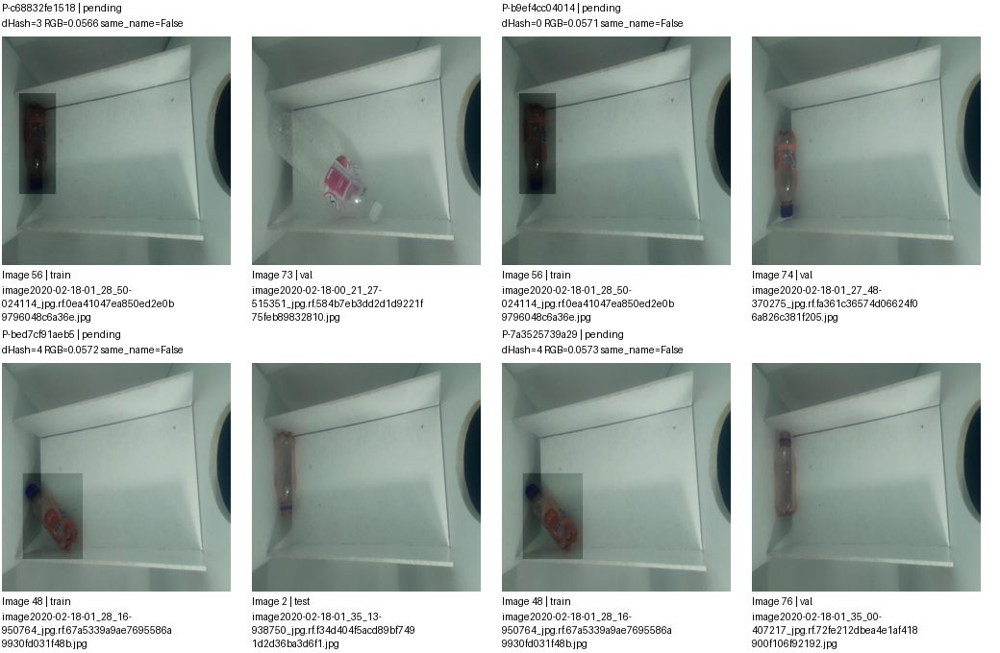

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-c68832fe1518,images/train/image2020-02-18-01_28_50-024114_jpg.rf.0ea41047ea850ed2e0b9796048c6a36e.jpg,images/val/image2020-02-18-00_21_27-515351_jpg.rf.584b7eb3dd2d1d9221f75feb89832810.jpg,pending,
P-b9ef4cc04014,images/train/image2020-02-18-01_28_50-024114_jpg.rf.0ea41047ea850ed2e0b9796048c6a36e.jpg,images/val/image2020-02-18-01_27_48-370275_jpg.rf.fa361c36574d06624f06a826c381f205.jpg,pending,
P-bed7cf91aeb5,images/train/image2020-02-18-01_28_16-950764_jpg.rf.67a5339a9ae7695586a9930fd031f48b.jpg,images/test/image2020-02-18-01_35_13-938750_jpg.rf.f34d404f5acd89bf7491d2d36ba3d6f1.jpg,pending,
P-7a3525739a29,images/train/image2020-02-18-01_28_16-950764_jpg.rf.67a5339a9ae7695586a9930fd031f48b.jpg,images/val/image2020-02-18-01_35_00-407217_jpg.rf.72fe212dbea4e1af418900f106f92192.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 52/166 G-586696e3c556 | 77 ảnh, 388 cặp
Split: {'test': 2, 'train': 70, 'val': 5}
Quyết định: {'pending': 388}
Ảnh trang None/13; cặp trang 68/97. Nhóm liên thông không phải kết luận trùng.


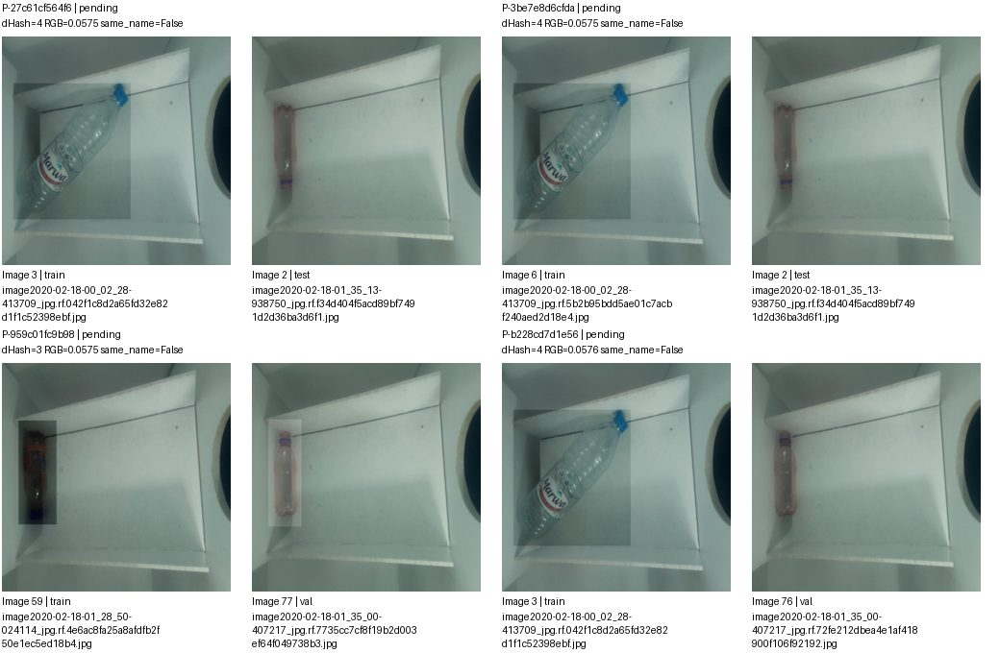

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-27c61cf564f6,images/train/image2020-02-18-00_02_28-413709_jpg.rf.042f1c8d2a65fd32e82d1f1c52398ebf.jpg,images/test/image2020-02-18-01_35_13-938750_jpg.rf.f34d404f5acd89bf7491d2d36ba3d6f1.jpg,pending,
P-3be7e8d6cfda,images/train/image2020-02-18-00_02_28-413709_jpg.rf.5b2b95bdd5ae01c7acbf240aed2d18e4.jpg,images/test/image2020-02-18-01_35_13-938750_jpg.rf.f34d404f5acd89bf7491d2d36ba3d6f1.jpg,pending,
P-959c01fc9b98,images/train/image2020-02-18-01_28_50-024114_jpg.rf.4e6ac8fa25a8afdfb2f50e1ec5ed18b4.jpg,images/val/image2020-02-18-01_35_00-407217_jpg.rf.7735cc7cf8f19b2d003ef64f049738b3.jpg,pending,
P-b228cd7d1e56,images/train/image2020-02-18-00_02_28-413709_jpg.rf.042f1c8d2a65fd32e82d1f1c52398ebf.jpg,images/val/image2020-02-18-01_35_00-407217_jpg.rf.72fe212dbea4e1af418900f106f92192.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 52/166 G-586696e3c556 | 77 ảnh, 388 cặp
Split: {'test': 2, 'train': 70, 'val': 5}
Quyết định: {'pending': 388}
Ảnh trang None/13; cặp trang 69/97. Nhóm liên thông không phải kết luận trùng.


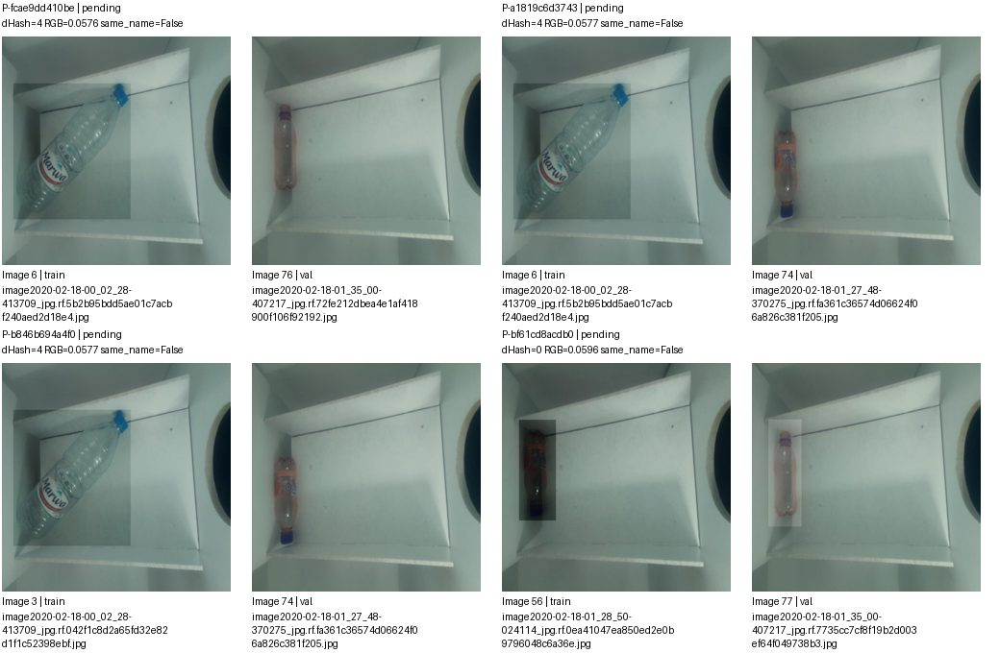

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-fcae9dd410be,images/train/image2020-02-18-00_02_28-413709_jpg.rf.5b2b95bdd5ae01c7acbf240aed2d18e4.jpg,images/val/image2020-02-18-01_35_00-407217_jpg.rf.72fe212dbea4e1af418900f106f92192.jpg,pending,
P-a1819c6d3743,images/train/image2020-02-18-00_02_28-413709_jpg.rf.5b2b95bdd5ae01c7acbf240aed2d18e4.jpg,images/val/image2020-02-18-01_27_48-370275_jpg.rf.fa361c36574d06624f06a826c381f205.jpg,pending,
P-b846b694a4f0,images/train/image2020-02-18-00_02_28-413709_jpg.rf.042f1c8d2a65fd32e82d1f1c52398ebf.jpg,images/val/image2020-02-18-01_27_48-370275_jpg.rf.fa361c36574d06624f06a826c381f205.jpg,pending,
P-bf61cd8acdb0,images/train/image2020-02-18-01_28_50-024114_jpg.rf.0ea41047ea850ed2e0b9796048c6a36e.jpg,images/val/image2020-02-18-01_35_00-407217_jpg.rf.7735cc7cf8f19b2d003ef64f049738b3.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 52/166 G-586696e3c556 | 77 ảnh, 388 cặp
Split: {'test': 2, 'train': 70, 'val': 5}
Quyết định: {'pending': 388}
Ảnh trang None/13; cặp trang 70/97. Nhóm liên thông không phải kết luận trùng.


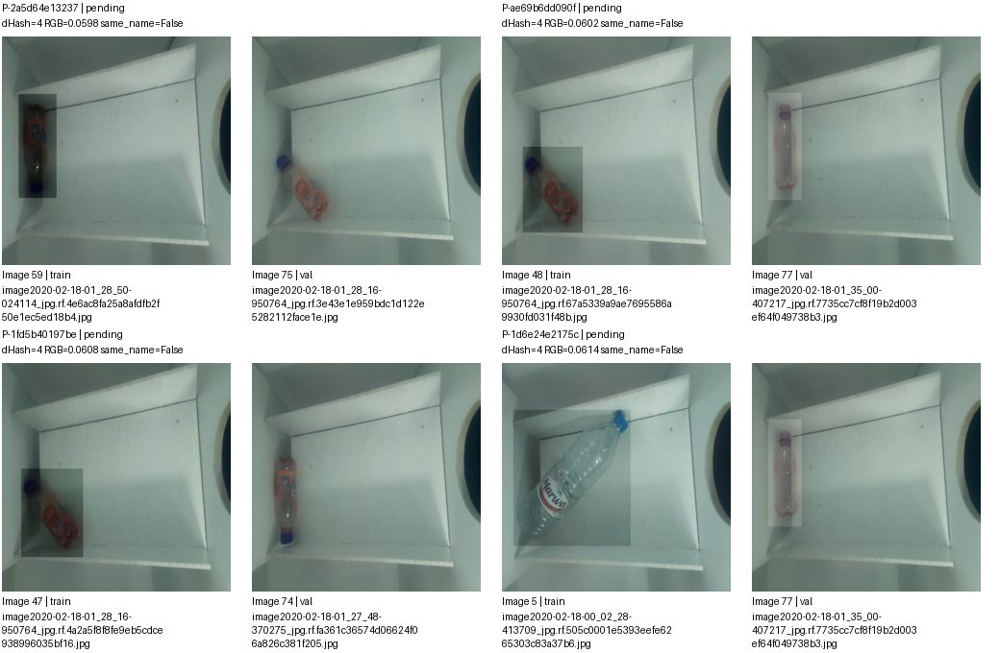

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-2a5d64e13237,images/train/image2020-02-18-01_28_50-024114_jpg.rf.4e6ac8fa25a8afdfb2f50e1ec5ed18b4.jpg,images/val/image2020-02-18-01_28_16-950764_jpg.rf.3e43e1e959bdc1d122e5282112face1e.jpg,pending,
P-ae69b6dd090f,images/train/image2020-02-18-01_28_16-950764_jpg.rf.67a5339a9ae7695586a9930fd031f48b.jpg,images/val/image2020-02-18-01_35_00-407217_jpg.rf.7735cc7cf8f19b2d003ef64f049738b3.jpg,pending,
P-1fd5b40197be,images/train/image2020-02-18-01_28_16-950764_jpg.rf.4a2a5f8f8fe9eb5cdce938996035bf16.jpg,images/val/image2020-02-18-01_27_48-370275_jpg.rf.fa361c36574d06624f06a826c381f205.jpg,pending,
P-1d6e24e2175c,images/train/image2020-02-18-00_02_28-413709_jpg.rf.505c0001e5393eefe6265303c83a37b6.jpg,images/val/image2020-02-18-01_35_00-407217_jpg.rf.7735cc7cf8f19b2d003ef64f049738b3.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 52/166 G-586696e3c556 | 77 ảnh, 388 cặp
Split: {'test': 2, 'train': 70, 'val': 5}
Quyết định: {'pending': 388}
Ảnh trang None/13; cặp trang 71/97. Nhóm liên thông không phải kết luận trùng.


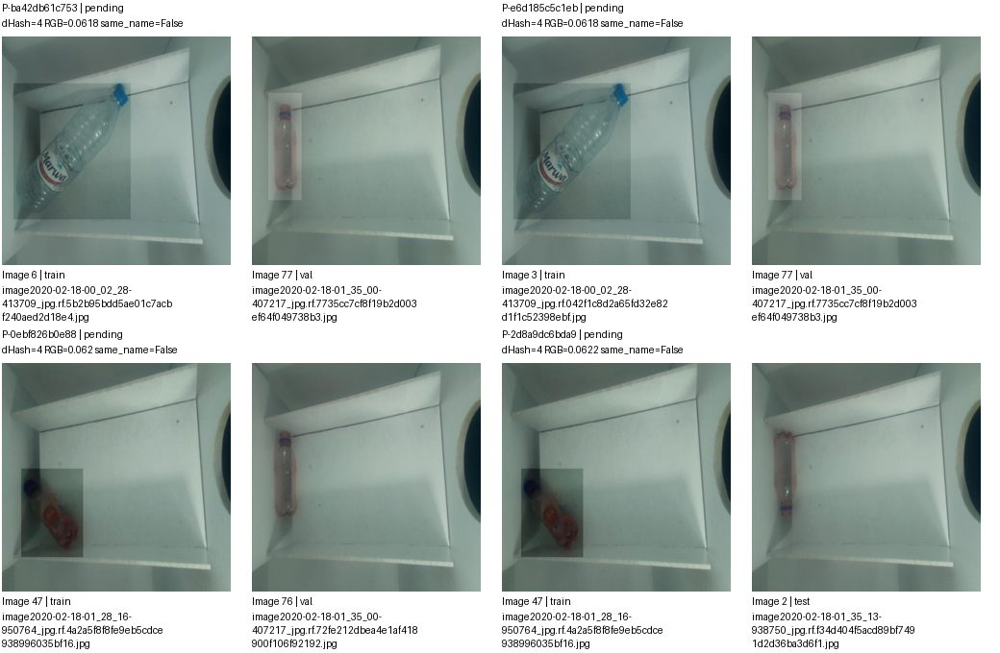

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-ba42db61c753,images/train/image2020-02-18-00_02_28-413709_jpg.rf.5b2b95bdd5ae01c7acbf240aed2d18e4.jpg,images/val/image2020-02-18-01_35_00-407217_jpg.rf.7735cc7cf8f19b2d003ef64f049738b3.jpg,pending,
P-e6d185c5c1eb,images/train/image2020-02-18-00_02_28-413709_jpg.rf.042f1c8d2a65fd32e82d1f1c52398ebf.jpg,images/val/image2020-02-18-01_35_00-407217_jpg.rf.7735cc7cf8f19b2d003ef64f049738b3.jpg,pending,
P-0ebf826b0e88,images/train/image2020-02-18-01_28_16-950764_jpg.rf.4a2a5f8f8fe9eb5cdce938996035bf16.jpg,images/val/image2020-02-18-01_35_00-407217_jpg.rf.72fe212dbea4e1af418900f106f92192.jpg,pending,
P-2d8a9dc6bda9,images/train/image2020-02-18-01_28_16-950764_jpg.rf.4a2a5f8f8fe9eb5cdce938996035bf16.jpg,images/test/image2020-02-18-01_35_13-938750_jpg.rf.f34d404f5acd89bf7491d2d36ba3d6f1.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 52/166 G-586696e3c556 | 77 ảnh, 388 cặp
Split: {'test': 2, 'train': 70, 'val': 5}
Quyết định: {'pending': 388}
Ảnh trang None/13; cặp trang 72/97. Nhóm liên thông không phải kết luận trùng.


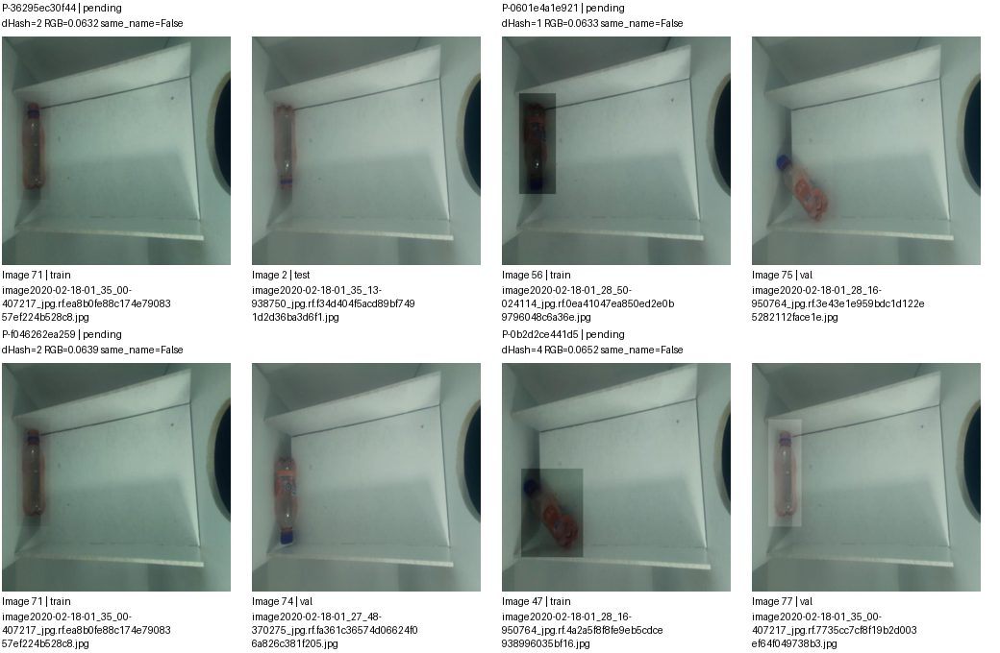

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-36295ec30f44,images/train/image2020-02-18-01_35_00-407217_jpg.rf.ea8b0fe88c174e7908357ef224b528c8.jpg,images/test/image2020-02-18-01_35_13-938750_jpg.rf.f34d404f5acd89bf7491d2d36ba3d6f1.jpg,pending,
P-0601e4a1e921,images/train/image2020-02-18-01_28_50-024114_jpg.rf.0ea41047ea850ed2e0b9796048c6a36e.jpg,images/val/image2020-02-18-01_28_16-950764_jpg.rf.3e43e1e959bdc1d122e5282112face1e.jpg,pending,
P-f046262ea259,images/train/image2020-02-18-01_35_00-407217_jpg.rf.ea8b0fe88c174e7908357ef224b528c8.jpg,images/val/image2020-02-18-01_27_48-370275_jpg.rf.fa361c36574d06624f06a826c381f205.jpg,pending,
P-0b2d2ce441d5,images/train/image2020-02-18-01_28_16-950764_jpg.rf.4a2a5f8f8fe9eb5cdce938996035bf16.jpg,images/val/image2020-02-18-01_35_00-407217_jpg.rf.7735cc7cf8f19b2d003ef64f049738b3.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 52/166 G-586696e3c556 | 77 ảnh, 388 cặp
Split: {'test': 2, 'train': 70, 'val': 5}
Quyết định: {'pending': 388}
Ảnh trang None/13; cặp trang 73/97. Nhóm liên thông không phải kết luận trùng.


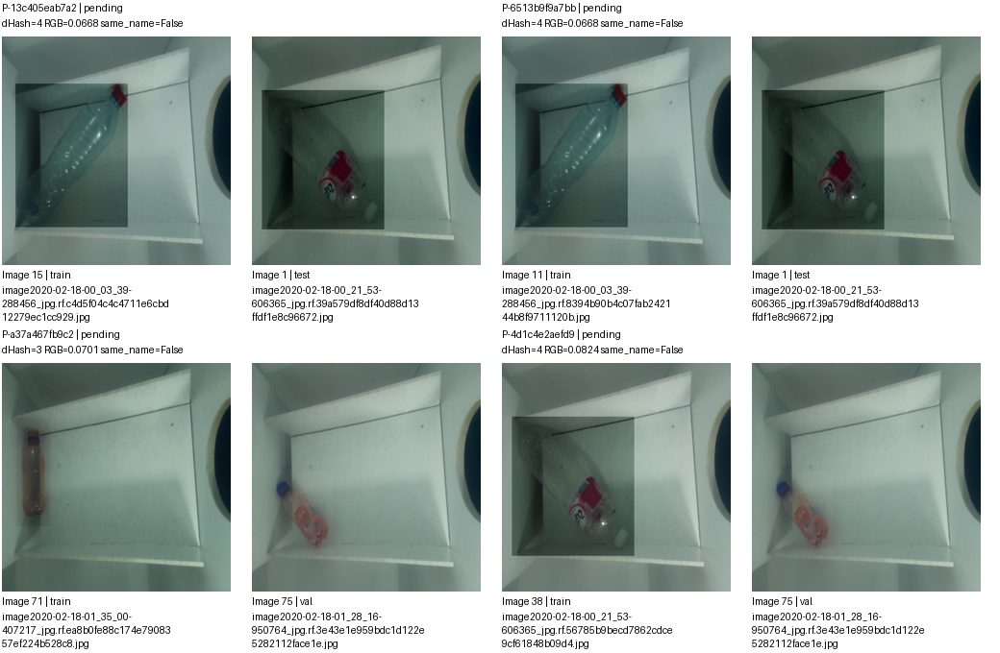

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-13c405eab7a2,images/train/image2020-02-18-00_03_39-288456_jpg.rf.c4d5f04c4c4711e6cbd12279ec1cc929.jpg,images/test/image2020-02-18-00_21_53-606365_jpg.rf.39a579df8df40d88d13ffdf1e8c96672.jpg,pending,
P-6513b9f9a7bb,images/train/image2020-02-18-00_03_39-288456_jpg.rf.8394b90b4c07fab242144b8f9711120b.jpg,images/test/image2020-02-18-00_21_53-606365_jpg.rf.39a579df8df40d88d13ffdf1e8c96672.jpg,pending,
P-a37a467fb9c2,images/train/image2020-02-18-01_35_00-407217_jpg.rf.ea8b0fe88c174e7908357ef224b528c8.jpg,images/val/image2020-02-18-01_28_16-950764_jpg.rf.3e43e1e959bdc1d122e5282112face1e.jpg,pending,
P-4d1c4e2aefd9,images/train/image2020-02-18-00_21_53-606365_jpg.rf.56785b9becd7862cdce9cf61848b09d4.jpg,images/val/image2020-02-18-01_28_16-950764_jpg.rf.3e43e1e959bdc1d122e5282112face1e.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 52/166 G-586696e3c556 | 77 ảnh, 388 cặp
Split: {'test': 2, 'train': 70, 'val': 5}
Quyết định: {'pending': 388}
Ảnh trang None/13; cặp trang 74/97. Nhóm liên thông không phải kết luận trùng.


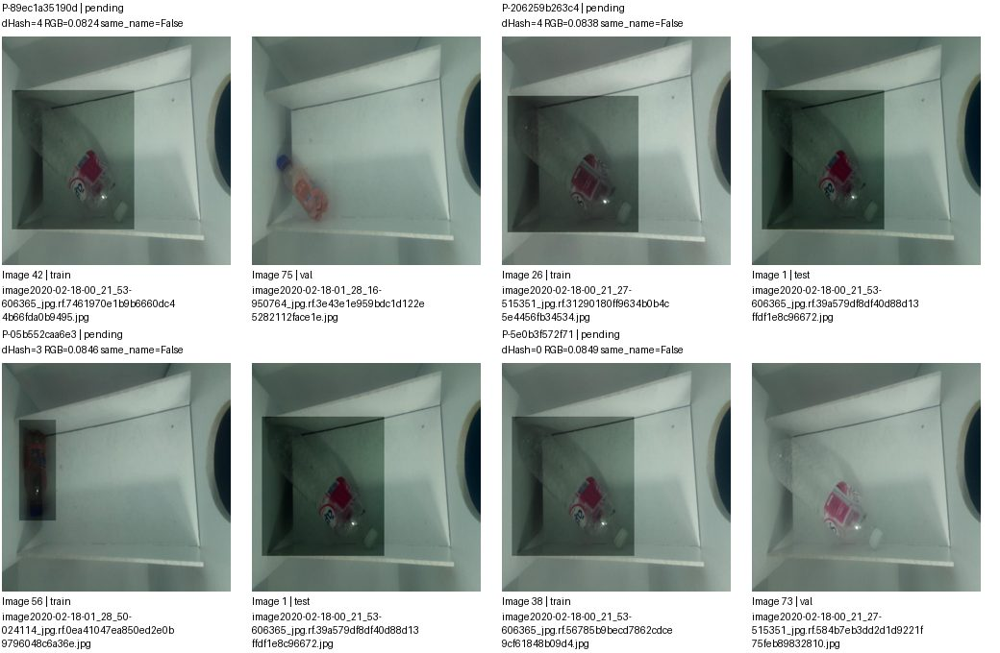

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-89ec1a35190d,images/train/image2020-02-18-00_21_53-606365_jpg.rf.7461970e1b9b6660dc44b66fda0b9495.jpg,images/val/image2020-02-18-01_28_16-950764_jpg.rf.3e43e1e959bdc1d122e5282112face1e.jpg,pending,
P-206259b263c4,images/train/image2020-02-18-00_21_27-515351_jpg.rf.31290180ff9634b0b4c5e4456fb34534.jpg,images/test/image2020-02-18-00_21_53-606365_jpg.rf.39a579df8df40d88d13ffdf1e8c96672.jpg,pending,
P-05b552caa6e3,images/train/image2020-02-18-01_28_50-024114_jpg.rf.0ea41047ea850ed2e0b9796048c6a36e.jpg,images/test/image2020-02-18-00_21_53-606365_jpg.rf.39a579df8df40d88d13ffdf1e8c96672.jpg,pending,
P-5e0b3f572f71,images/train/image2020-02-18-00_21_53-606365_jpg.rf.56785b9becd7862cdce9cf61848b09d4.jpg,images/val/image2020-02-18-00_21_27-515351_jpg.rf.584b7eb3dd2d1d9221f75feb89832810.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 52/166 G-586696e3c556 | 77 ảnh, 388 cặp
Split: {'test': 2, 'train': 70, 'val': 5}
Quyết định: {'pending': 388}
Ảnh trang None/13; cặp trang 75/97. Nhóm liên thông không phải kết luận trùng.


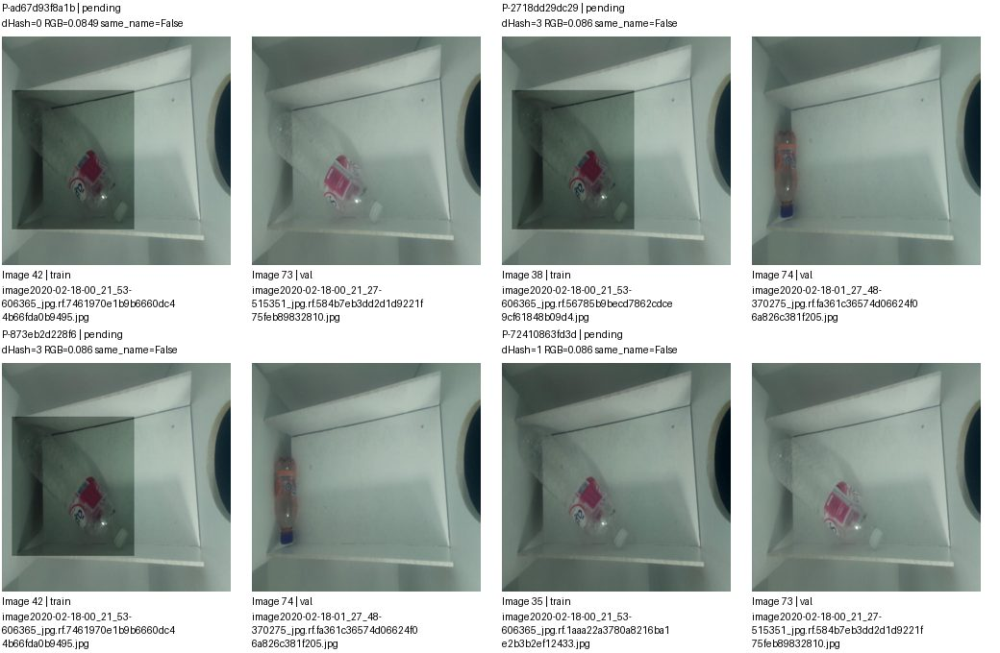

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-ad67d93f8a1b,images/train/image2020-02-18-00_21_53-606365_jpg.rf.7461970e1b9b6660dc44b66fda0b9495.jpg,images/val/image2020-02-18-00_21_27-515351_jpg.rf.584b7eb3dd2d1d9221f75feb89832810.jpg,pending,
P-2718dd29dc29,images/train/image2020-02-18-00_21_53-606365_jpg.rf.56785b9becd7862cdce9cf61848b09d4.jpg,images/val/image2020-02-18-01_27_48-370275_jpg.rf.fa361c36574d06624f06a826c381f205.jpg,pending,
P-873eb2d228f6,images/train/image2020-02-18-00_21_53-606365_jpg.rf.7461970e1b9b6660dc44b66fda0b9495.jpg,images/val/image2020-02-18-01_27_48-370275_jpg.rf.fa361c36574d06624f06a826c381f205.jpg,pending,
P-72410863fd3d,images/train/image2020-02-18-00_21_53-606365_jpg.rf.1aaa22a3780a8216ba1e2b3b2ef12433.jpg,images/val/image2020-02-18-00_21_27-515351_jpg.rf.584b7eb3dd2d1d9221f75feb89832810.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 52/166 G-586696e3c556 | 77 ảnh, 388 cặp
Split: {'test': 2, 'train': 70, 'val': 5}
Quyết định: {'pending': 388}
Ảnh trang None/13; cặp trang 76/97. Nhóm liên thông không phải kết luận trùng.


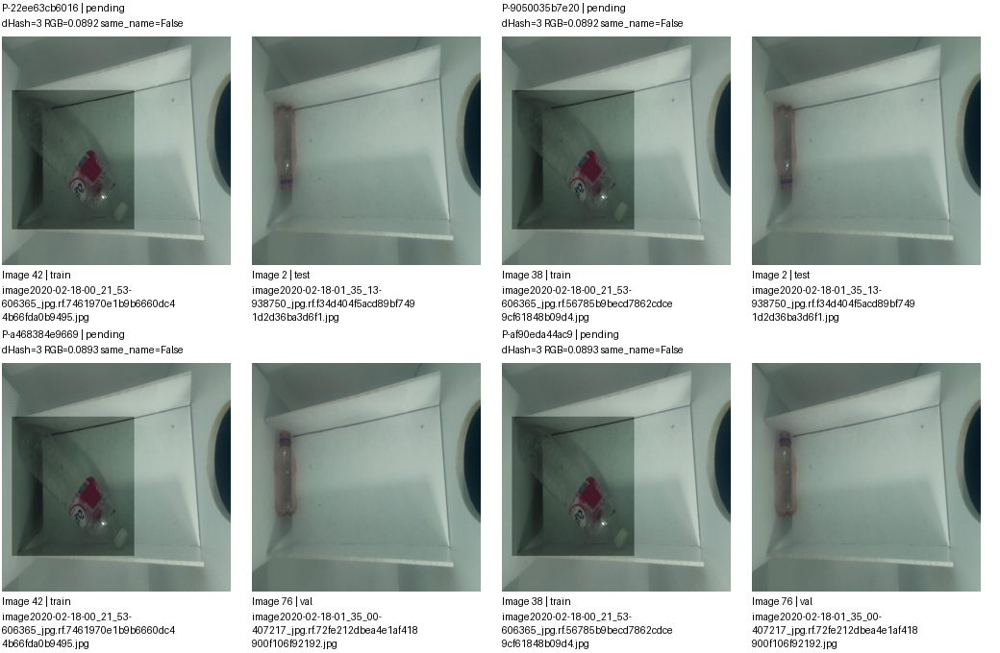

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-22ee63cb6016,images/train/image2020-02-18-00_21_53-606365_jpg.rf.7461970e1b9b6660dc44b66fda0b9495.jpg,images/test/image2020-02-18-01_35_13-938750_jpg.rf.f34d404f5acd89bf7491d2d36ba3d6f1.jpg,pending,
P-9050035b7e20,images/train/image2020-02-18-00_21_53-606365_jpg.rf.56785b9becd7862cdce9cf61848b09d4.jpg,images/test/image2020-02-18-01_35_13-938750_jpg.rf.f34d404f5acd89bf7491d2d36ba3d6f1.jpg,pending,
P-a468384e9669,images/train/image2020-02-18-00_21_53-606365_jpg.rf.7461970e1b9b6660dc44b66fda0b9495.jpg,images/val/image2020-02-18-01_35_00-407217_jpg.rf.72fe212dbea4e1af418900f106f92192.jpg,pending,
P-af90eda44ac9,images/train/image2020-02-18-00_21_53-606365_jpg.rf.56785b9becd7862cdce9cf61848b09d4.jpg,images/val/image2020-02-18-01_35_00-407217_jpg.rf.72fe212dbea4e1af418900f106f92192.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 52/166 G-586696e3c556 | 77 ảnh, 388 cặp
Split: {'test': 2, 'train': 70, 'val': 5}
Quyết định: {'pending': 388}
Ảnh trang None/13; cặp trang 77/97. Nhóm liên thông không phải kết luận trùng.


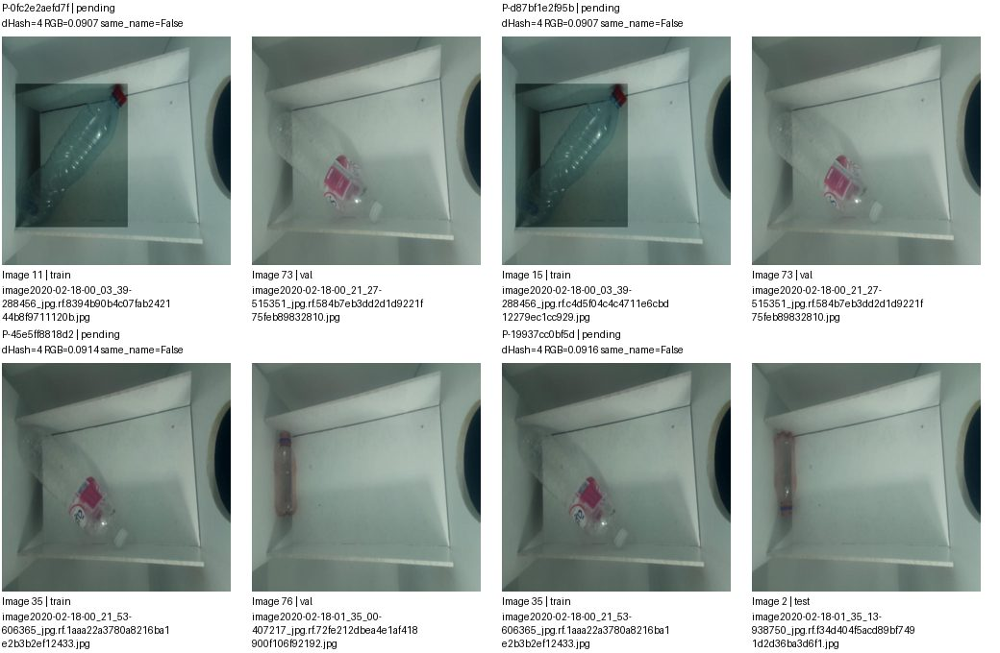

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-0fc2e2aefd7f,images/train/image2020-02-18-00_03_39-288456_jpg.rf.8394b90b4c07fab242144b8f9711120b.jpg,images/val/image2020-02-18-00_21_27-515351_jpg.rf.584b7eb3dd2d1d9221f75feb89832810.jpg,pending,
P-d87bf1e2f95b,images/train/image2020-02-18-00_03_39-288456_jpg.rf.c4d5f04c4c4711e6cbd12279ec1cc929.jpg,images/val/image2020-02-18-00_21_27-515351_jpg.rf.584b7eb3dd2d1d9221f75feb89832810.jpg,pending,
P-45e5ff8818d2,images/train/image2020-02-18-00_21_53-606365_jpg.rf.1aaa22a3780a8216ba1e2b3b2ef12433.jpg,images/val/image2020-02-18-01_35_00-407217_jpg.rf.72fe212dbea4e1af418900f106f92192.jpg,pending,
P-19937cc0bf5d,images/train/image2020-02-18-00_21_53-606365_jpg.rf.1aaa22a3780a8216ba1e2b3b2ef12433.jpg,images/test/image2020-02-18-01_35_13-938750_jpg.rf.f34d404f5acd89bf7491d2d36ba3d6f1.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 52/166 G-586696e3c556 | 77 ảnh, 388 cặp
Split: {'test': 2, 'train': 70, 'val': 5}
Quyết định: {'pending': 388}
Ảnh trang None/13; cặp trang 78/97. Nhóm liên thông không phải kết luận trùng.


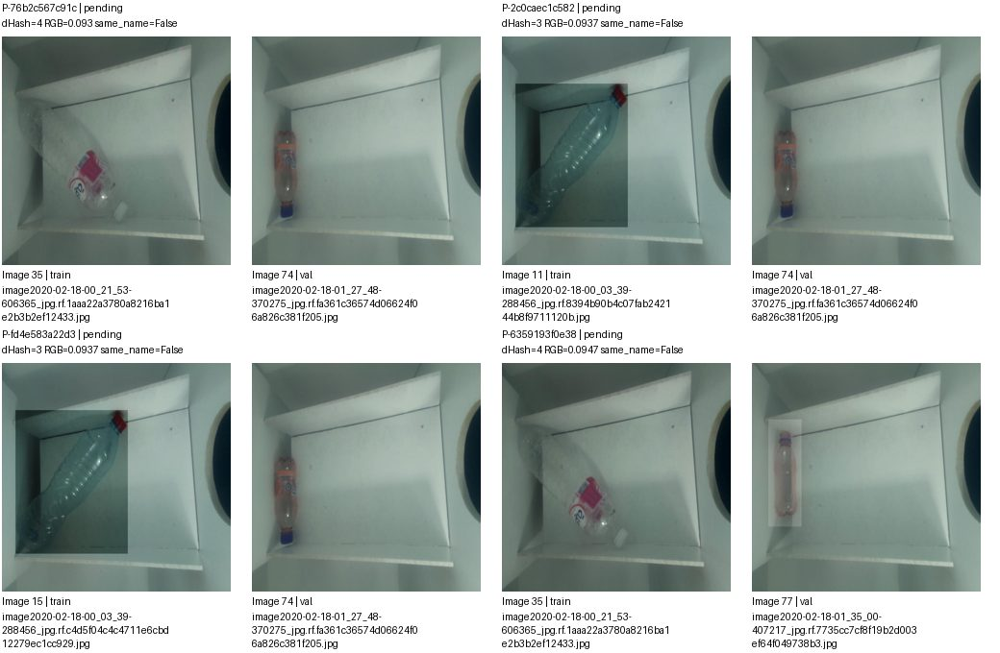

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-76b2c567c91c,images/train/image2020-02-18-00_21_53-606365_jpg.rf.1aaa22a3780a8216ba1e2b3b2ef12433.jpg,images/val/image2020-02-18-01_27_48-370275_jpg.rf.fa361c36574d06624f06a826c381f205.jpg,pending,
P-2c0caec1c582,images/train/image2020-02-18-00_03_39-288456_jpg.rf.8394b90b4c07fab242144b8f9711120b.jpg,images/val/image2020-02-18-01_27_48-370275_jpg.rf.fa361c36574d06624f06a826c381f205.jpg,pending,
P-fd4e583a22d3,images/train/image2020-02-18-00_03_39-288456_jpg.rf.c4d5f04c4c4711e6cbd12279ec1cc929.jpg,images/val/image2020-02-18-01_27_48-370275_jpg.rf.fa361c36574d06624f06a826c381f205.jpg,pending,
P-6359193f0e38,images/train/image2020-02-18-00_21_53-606365_jpg.rf.1aaa22a3780a8216ba1e2b3b2ef12433.jpg,images/val/image2020-02-18-01_35_00-407217_jpg.rf.7735cc7cf8f19b2d003ef64f049738b3.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 52/166 G-586696e3c556 | 77 ảnh, 388 cặp
Split: {'test': 2, 'train': 70, 'val': 5}
Quyết định: {'pending': 388}
Ảnh trang None/13; cặp trang 79/97. Nhóm liên thông không phải kết luận trùng.


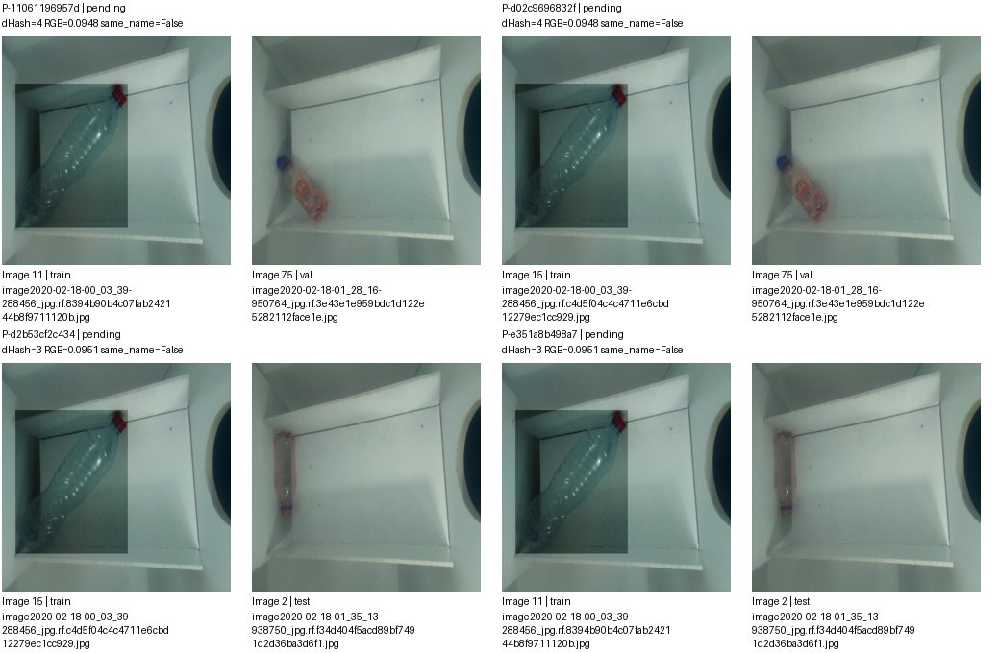

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-11061196957d,images/train/image2020-02-18-00_03_39-288456_jpg.rf.8394b90b4c07fab242144b8f9711120b.jpg,images/val/image2020-02-18-01_28_16-950764_jpg.rf.3e43e1e959bdc1d122e5282112face1e.jpg,pending,
P-d02c9696832f,images/train/image2020-02-18-00_03_39-288456_jpg.rf.c4d5f04c4c4711e6cbd12279ec1cc929.jpg,images/val/image2020-02-18-01_28_16-950764_jpg.rf.3e43e1e959bdc1d122e5282112face1e.jpg,pending,
P-d2b53cf2c434,images/train/image2020-02-18-00_03_39-288456_jpg.rf.c4d5f04c4c4711e6cbd12279ec1cc929.jpg,images/test/image2020-02-18-01_35_13-938750_jpg.rf.f34d404f5acd89bf7491d2d36ba3d6f1.jpg,pending,
P-e351a8b498a7,images/train/image2020-02-18-00_03_39-288456_jpg.rf.8394b90b4c07fab242144b8f9711120b.jpg,images/test/image2020-02-18-01_35_13-938750_jpg.rf.f34d404f5acd89bf7491d2d36ba3d6f1.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 52/166 G-586696e3c556 | 77 ảnh, 388 cặp
Split: {'test': 2, 'train': 70, 'val': 5}
Quyết định: {'pending': 388}
Ảnh trang None/13; cặp trang 80/97. Nhóm liên thông không phải kết luận trùng.


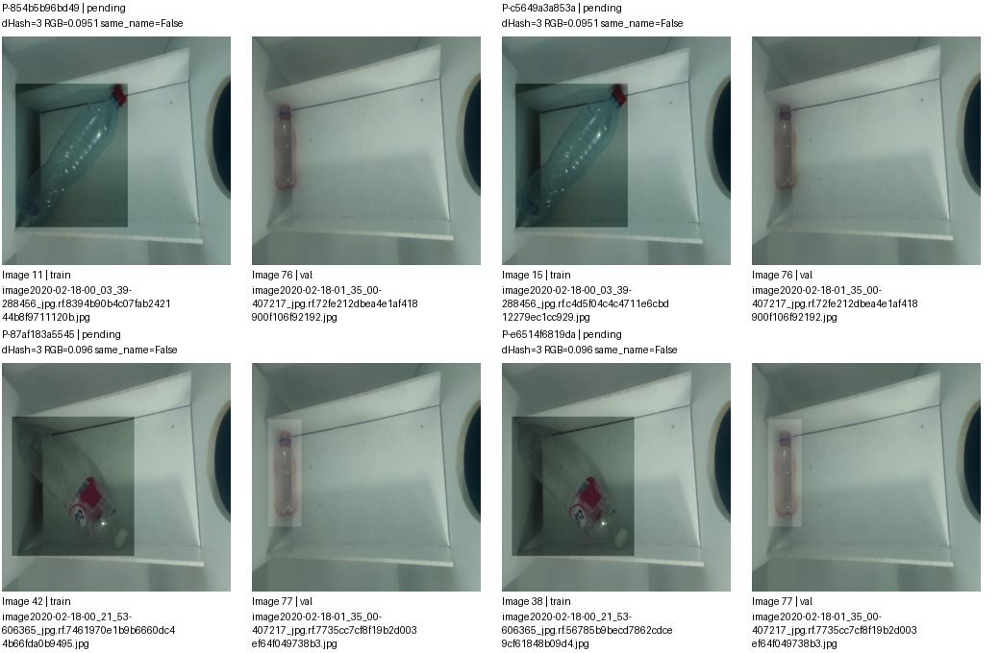

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-854b5b96bd49,images/train/image2020-02-18-00_03_39-288456_jpg.rf.8394b90b4c07fab242144b8f9711120b.jpg,images/val/image2020-02-18-01_35_00-407217_jpg.rf.72fe212dbea4e1af418900f106f92192.jpg,pending,
P-c5649a3a853a,images/train/image2020-02-18-00_03_39-288456_jpg.rf.c4d5f04c4c4711e6cbd12279ec1cc929.jpg,images/val/image2020-02-18-01_35_00-407217_jpg.rf.72fe212dbea4e1af418900f106f92192.jpg,pending,
P-87af183a5545,images/train/image2020-02-18-00_21_53-606365_jpg.rf.7461970e1b9b6660dc44b66fda0b9495.jpg,images/val/image2020-02-18-01_35_00-407217_jpg.rf.7735cc7cf8f19b2d003ef64f049738b3.jpg,pending,
P-e6514f6819da,images/train/image2020-02-18-00_21_53-606365_jpg.rf.56785b9becd7862cdce9cf61848b09d4.jpg,images/val/image2020-02-18-01_35_00-407217_jpg.rf.7735cc7cf8f19b2d003ef64f049738b3.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 52/166 G-586696e3c556 | 77 ảnh, 388 cặp
Split: {'test': 2, 'train': 70, 'val': 5}
Quyết định: {'pending': 388}
Ảnh trang None/13; cặp trang 81/97. Nhóm liên thông không phải kết luận trùng.


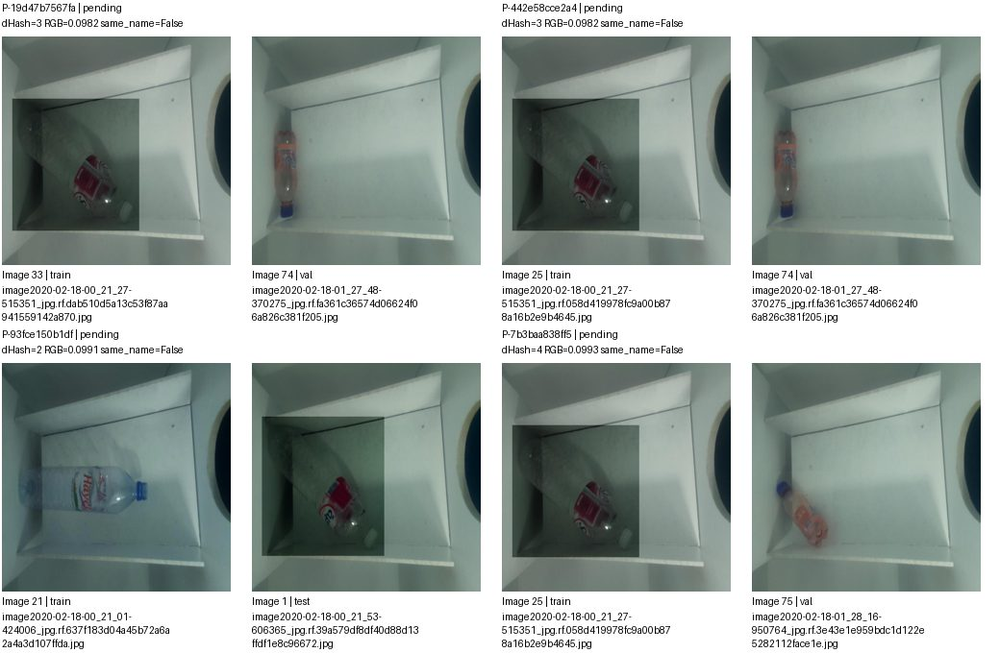

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-19d47b7567fa,images/train/image2020-02-18-00_21_27-515351_jpg.rf.dab510d5a13c53f87aa941559142a870.jpg,images/val/image2020-02-18-01_27_48-370275_jpg.rf.fa361c36574d06624f06a826c381f205.jpg,pending,
P-442e58cce2a4,images/train/image2020-02-18-00_21_27-515351_jpg.rf.058d419978fc9a00b878a16b2e9b4645.jpg,images/val/image2020-02-18-01_27_48-370275_jpg.rf.fa361c36574d06624f06a826c381f205.jpg,pending,
P-93fce150b1df,images/train/image2020-02-18-00_21_01-424006_jpg.rf.637f183d04a45b72a6a2a4a3d107ffda.jpg,images/test/image2020-02-18-00_21_53-606365_jpg.rf.39a579df8df40d88d13ffdf1e8c96672.jpg,pending,
P-7b3baa838ff5,images/train/image2020-02-18-00_21_27-515351_jpg.rf.058d419978fc9a00b878a16b2e9b4645.jpg,images/val/image2020-02-18-01_28_16-950764_jpg.rf.3e43e1e959bdc1d122e5282112face1e.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 52/166 G-586696e3c556 | 77 ảnh, 388 cặp
Split: {'test': 2, 'train': 70, 'val': 5}
Quyết định: {'pending': 388}
Ảnh trang None/13; cặp trang 82/97. Nhóm liên thông không phải kết luận trùng.


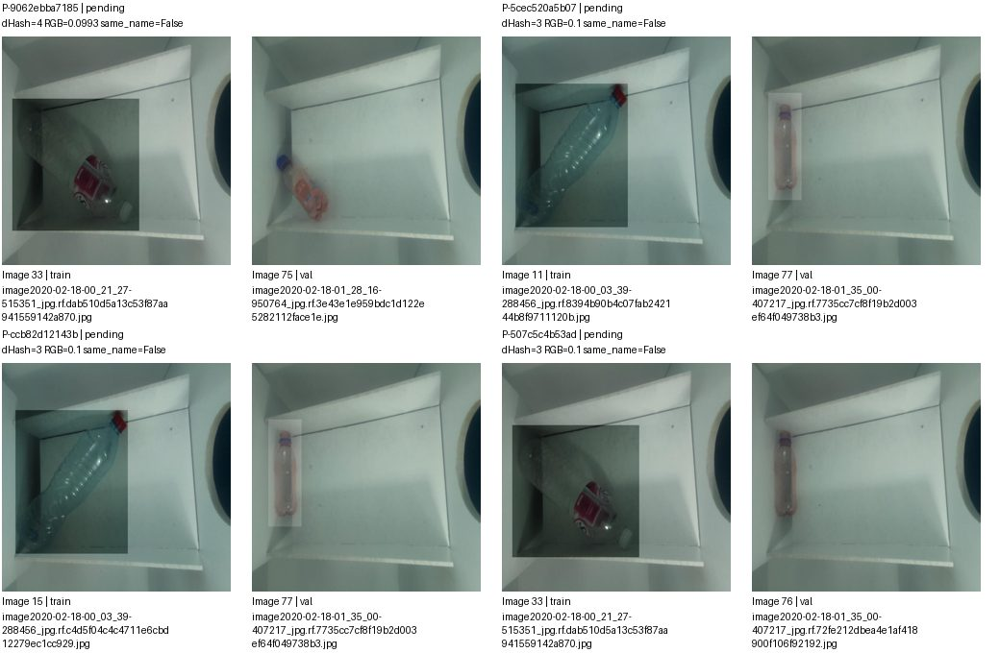

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-9062ebba7185,images/train/image2020-02-18-00_21_27-515351_jpg.rf.dab510d5a13c53f87aa941559142a870.jpg,images/val/image2020-02-18-01_28_16-950764_jpg.rf.3e43e1e959bdc1d122e5282112face1e.jpg,pending,
P-5cec520a5b07,images/train/image2020-02-18-00_03_39-288456_jpg.rf.8394b90b4c07fab242144b8f9711120b.jpg,images/val/image2020-02-18-01_35_00-407217_jpg.rf.7735cc7cf8f19b2d003ef64f049738b3.jpg,pending,
P-ccb82d12143b,images/train/image2020-02-18-00_03_39-288456_jpg.rf.c4d5f04c4c4711e6cbd12279ec1cc929.jpg,images/val/image2020-02-18-01_35_00-407217_jpg.rf.7735cc7cf8f19b2d003ef64f049738b3.jpg,pending,
P-507c5c4b53ad,images/train/image2020-02-18-00_21_27-515351_jpg.rf.dab510d5a13c53f87aa941559142a870.jpg,images/val/image2020-02-18-01_35_00-407217_jpg.rf.72fe212dbea4e1af418900f106f92192.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 52/166 G-586696e3c556 | 77 ảnh, 388 cặp
Split: {'test': 2, 'train': 70, 'val': 5}
Quyết định: {'pending': 388}
Ảnh trang None/13; cặp trang 83/97. Nhóm liên thông không phải kết luận trùng.


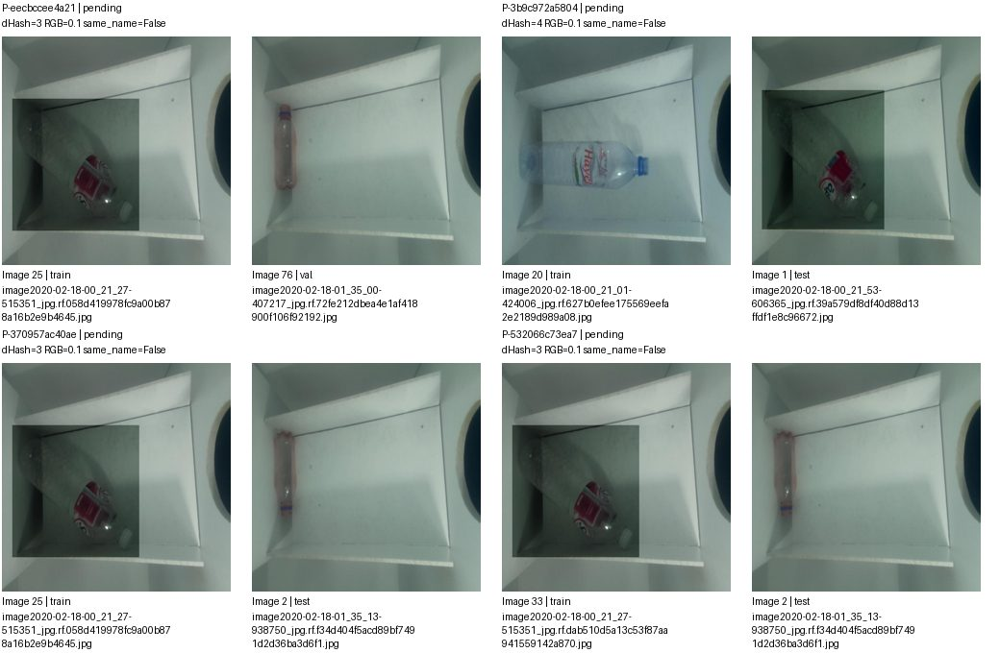

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-eecbccee4a21,images/train/image2020-02-18-00_21_27-515351_jpg.rf.058d419978fc9a00b878a16b2e9b4645.jpg,images/val/image2020-02-18-01_35_00-407217_jpg.rf.72fe212dbea4e1af418900f106f92192.jpg,pending,
P-3b9c972a5804,images/train/image2020-02-18-00_21_01-424006_jpg.rf.627b0efee175569eefa2e2189d989a08.jpg,images/test/image2020-02-18-00_21_53-606365_jpg.rf.39a579df8df40d88d13ffdf1e8c96672.jpg,pending,
P-370957ac40ae,images/train/image2020-02-18-00_21_27-515351_jpg.rf.058d419978fc9a00b878a16b2e9b4645.jpg,images/test/image2020-02-18-01_35_13-938750_jpg.rf.f34d404f5acd89bf7491d2d36ba3d6f1.jpg,pending,
P-532066c73ea7,images/train/image2020-02-18-00_21_27-515351_jpg.rf.dab510d5a13c53f87aa941559142a870.jpg,images/test/image2020-02-18-01_35_13-938750_jpg.rf.f34d404f5acd89bf7491d2d36ba3d6f1.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 52/166 G-586696e3c556 | 77 ảnh, 388 cặp
Split: {'test': 2, 'train': 70, 'val': 5}
Quyết định: {'pending': 388}
Ảnh trang None/13; cặp trang 84/97. Nhóm liên thông không phải kết luận trùng.


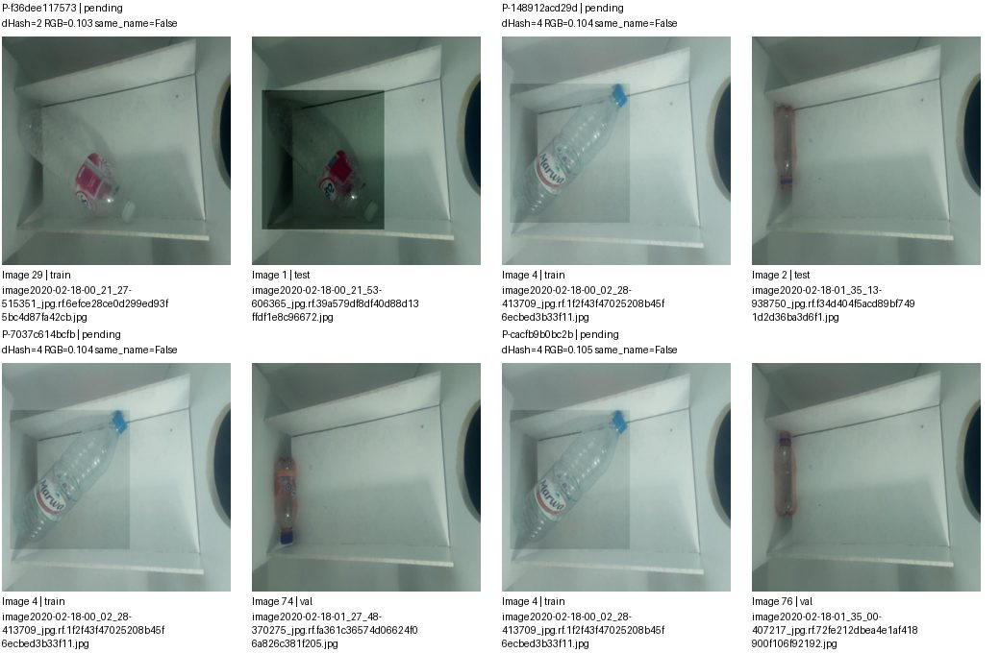

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-f36dee117573,images/train/image2020-02-18-00_21_27-515351_jpg.rf.6efce28ce0d299ed93f5bc4d87fa42cb.jpg,images/test/image2020-02-18-00_21_53-606365_jpg.rf.39a579df8df40d88d13ffdf1e8c96672.jpg,pending,
P-148912acd29d,images/train/image2020-02-18-00_02_28-413709_jpg.rf.1f2f43f47025208b45f6ecbed3b33f11.jpg,images/test/image2020-02-18-01_35_13-938750_jpg.rf.f34d404f5acd89bf7491d2d36ba3d6f1.jpg,pending,
P-7037c614bcfb,images/train/image2020-02-18-00_02_28-413709_jpg.rf.1f2f43f47025208b45f6ecbed3b33f11.jpg,images/val/image2020-02-18-01_27_48-370275_jpg.rf.fa361c36574d06624f06a826c381f205.jpg,pending,
P-cacfb9b0bc2b,images/train/image2020-02-18-00_02_28-413709_jpg.rf.1f2f43f47025208b45f6ecbed3b33f11.jpg,images/val/image2020-02-18-01_35_00-407217_jpg.rf.72fe212dbea4e1af418900f106f92192.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 52/166 G-586696e3c556 | 77 ảnh, 388 cặp
Split: {'test': 2, 'train': 70, 'val': 5}
Quyết định: {'pending': 388}
Ảnh trang None/13; cặp trang 85/97. Nhóm liên thông không phải kết luận trùng.


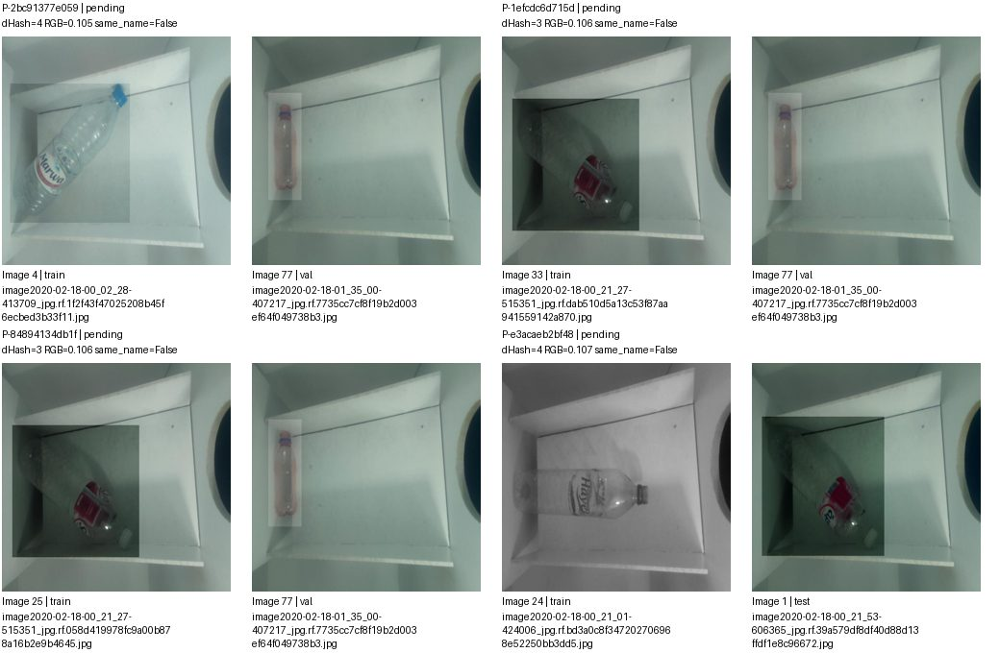

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-2bc91377e059,images/train/image2020-02-18-00_02_28-413709_jpg.rf.1f2f43f47025208b45f6ecbed3b33f11.jpg,images/val/image2020-02-18-01_35_00-407217_jpg.rf.7735cc7cf8f19b2d003ef64f049738b3.jpg,pending,
P-1efcdc6d715d,images/train/image2020-02-18-00_21_27-515351_jpg.rf.dab510d5a13c53f87aa941559142a870.jpg,images/val/image2020-02-18-01_35_00-407217_jpg.rf.7735cc7cf8f19b2d003ef64f049738b3.jpg,pending,
P-84894134db1f,images/train/image2020-02-18-00_21_27-515351_jpg.rf.058d419978fc9a00b878a16b2e9b4645.jpg,images/val/image2020-02-18-01_35_00-407217_jpg.rf.7735cc7cf8f19b2d003ef64f049738b3.jpg,pending,
P-e3acaeb2bf48,images/train/image2020-02-18-00_21_01-424006_jpg.rf.bd3a0c8f347202706968e52250bb3dd5.jpg,images/test/image2020-02-18-00_21_53-606365_jpg.rf.39a579df8df40d88d13ffdf1e8c96672.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 52/166 G-586696e3c556 | 77 ảnh, 388 cặp
Split: {'test': 2, 'train': 70, 'val': 5}
Quyết định: {'pending': 388}
Ảnh trang None/13; cặp trang 86/97. Nhóm liên thông không phải kết luận trùng.


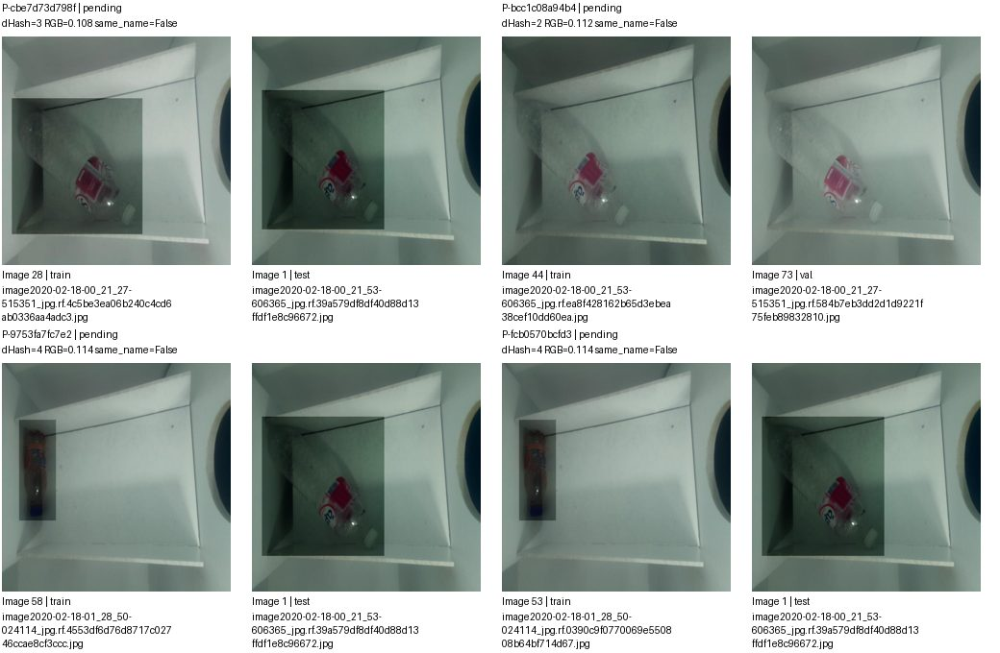

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-cbe7d73d798f,images/train/image2020-02-18-00_21_27-515351_jpg.rf.4c5be3ea06b240c4cd6ab0336aa4adc3.jpg,images/test/image2020-02-18-00_21_53-606365_jpg.rf.39a579df8df40d88d13ffdf1e8c96672.jpg,pending,
P-bcc1c08a94b4,images/train/image2020-02-18-00_21_53-606365_jpg.rf.ea8f428162b65d3ebea38cef10dd60ea.jpg,images/val/image2020-02-18-00_21_27-515351_jpg.rf.584b7eb3dd2d1d9221f75feb89832810.jpg,pending,
P-9753fa7fc7e2,images/train/image2020-02-18-01_28_50-024114_jpg.rf.4553df6d76d8717c02746ccae8cf3ccc.jpg,images/test/image2020-02-18-00_21_53-606365_jpg.rf.39a579df8df40d88d13ffdf1e8c96672.jpg,pending,
P-fcb0570bcfd3,images/train/image2020-02-18-01_28_50-024114_jpg.rf.0390c9f0770069e550808b64bf714d67.jpg,images/test/image2020-02-18-00_21_53-606365_jpg.rf.39a579df8df40d88d13ffdf1e8c96672.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 52/166 G-586696e3c556 | 77 ảnh, 388 cặp
Split: {'test': 2, 'train': 70, 'val': 5}
Quyết định: {'pending': 388}
Ảnh trang None/13; cặp trang 87/97. Nhóm liên thông không phải kết luận trùng.


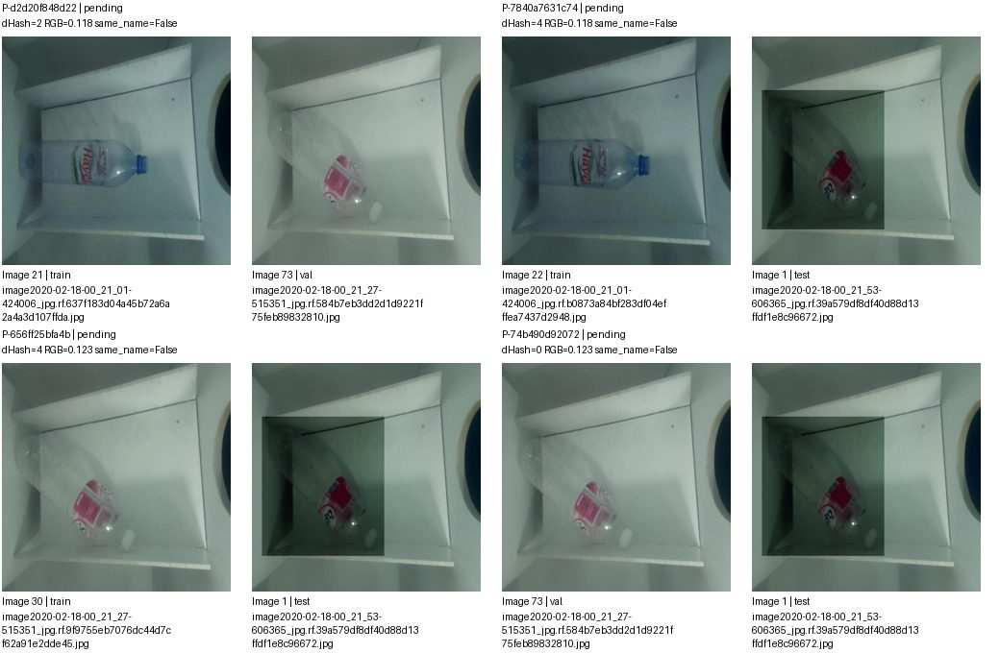

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-d2d20f848d22,images/train/image2020-02-18-00_21_01-424006_jpg.rf.637f183d04a45b72a6a2a4a3d107ffda.jpg,images/val/image2020-02-18-00_21_27-515351_jpg.rf.584b7eb3dd2d1d9221f75feb89832810.jpg,pending,
P-7840a7631c74,images/train/image2020-02-18-00_21_01-424006_jpg.rf.b0873a84bf283df04efffea7437d2948.jpg,images/test/image2020-02-18-00_21_53-606365_jpg.rf.39a579df8df40d88d13ffdf1e8c96672.jpg,pending,
P-656ff25bfa4b,images/train/image2020-02-18-00_21_27-515351_jpg.rf.9f9755eb7076dc44d7cf62a91e2dde45.jpg,images/test/image2020-02-18-00_21_53-606365_jpg.rf.39a579df8df40d88d13ffdf1e8c96672.jpg,pending,
P-74b490d92072,images/val/image2020-02-18-00_21_27-515351_jpg.rf.584b7eb3dd2d1d9221f75feb89832810.jpg,images/test/image2020-02-18-00_21_53-606365_jpg.rf.39a579df8df40d88d13ffdf1e8c96672.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 52/166 G-586696e3c556 | 77 ảnh, 388 cặp
Split: {'test': 2, 'train': 70, 'val': 5}
Quyết định: {'pending': 388}
Ảnh trang None/13; cặp trang 88/97. Nhóm liên thông không phải kết luận trùng.


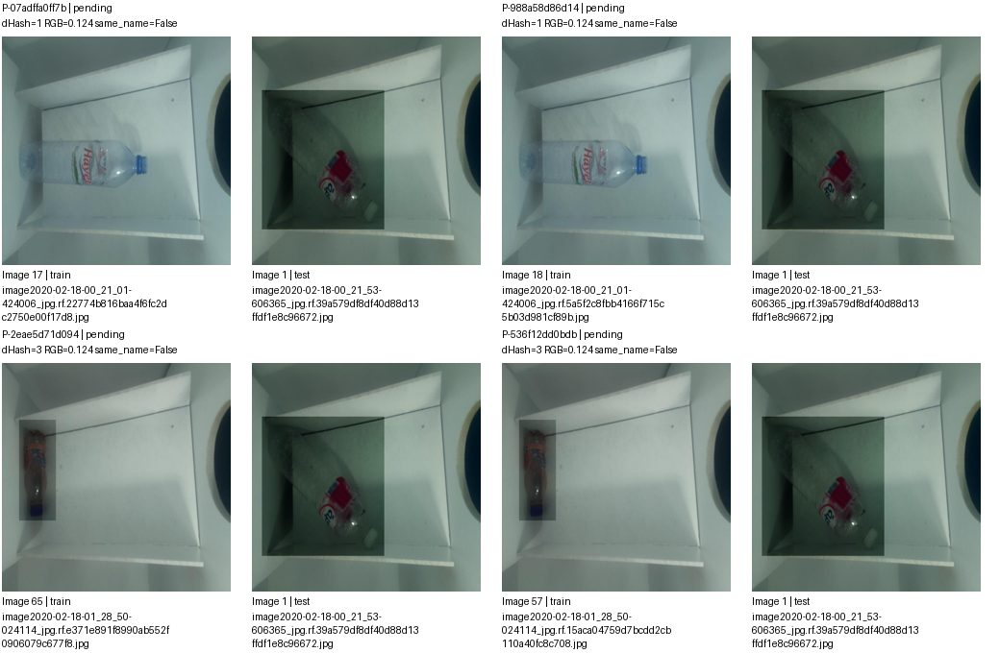

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-07adffa0ff7b,images/train/image2020-02-18-00_21_01-424006_jpg.rf.22774b816baa4f6fc2dc2750e00f17d8.jpg,images/test/image2020-02-18-00_21_53-606365_jpg.rf.39a579df8df40d88d13ffdf1e8c96672.jpg,pending,
P-988a58d86d14,images/train/image2020-02-18-00_21_01-424006_jpg.rf.5a5f2c8fbb4166f715c5b03d981cf89b.jpg,images/test/image2020-02-18-00_21_53-606365_jpg.rf.39a579df8df40d88d13ffdf1e8c96672.jpg,pending,
P-2eae5d71d094,images/train/image2020-02-18-01_28_50-024114_jpg.rf.e371e891f8990ab552f0906079c677f8.jpg,images/test/image2020-02-18-00_21_53-606365_jpg.rf.39a579df8df40d88d13ffdf1e8c96672.jpg,pending,
P-536f12dd0bdb,images/train/image2020-02-18-01_28_50-024114_jpg.rf.15aca04759d7bcdd2cb110a40fc8c708.jpg,images/test/image2020-02-18-00_21_53-606365_jpg.rf.39a579df8df40d88d13ffdf1e8c96672.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 52/166 G-586696e3c556 | 77 ảnh, 388 cặp
Split: {'test': 2, 'train': 70, 'val': 5}
Quyết định: {'pending': 388}
Ảnh trang None/13; cặp trang 89/97. Nhóm liên thông không phải kết luận trùng.


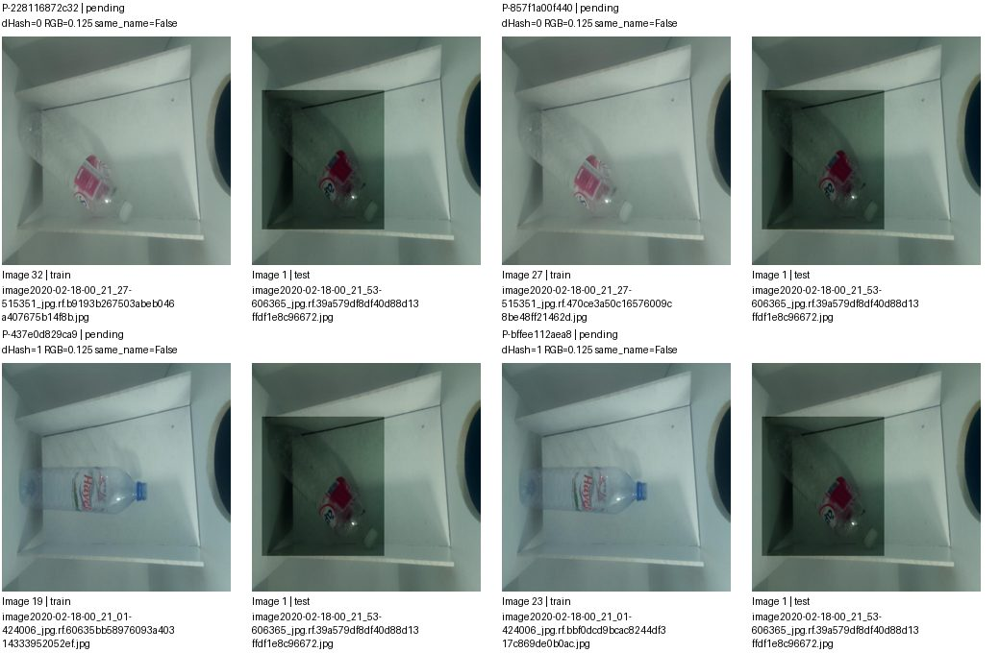

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-228116872c32,images/train/image2020-02-18-00_21_27-515351_jpg.rf.b9193b267503abeb046a407675b14f8b.jpg,images/test/image2020-02-18-00_21_53-606365_jpg.rf.39a579df8df40d88d13ffdf1e8c96672.jpg,pending,
P-857f1a00f440,images/train/image2020-02-18-00_21_27-515351_jpg.rf.470ce3a50c16576009c8be48ff21462d.jpg,images/test/image2020-02-18-00_21_53-606365_jpg.rf.39a579df8df40d88d13ffdf1e8c96672.jpg,pending,
P-437e0d829ca9,images/train/image2020-02-18-00_21_01-424006_jpg.rf.60635bb58976093a40314333952052ef.jpg,images/test/image2020-02-18-00_21_53-606365_jpg.rf.39a579df8df40d88d13ffdf1e8c96672.jpg,pending,
P-bffee112aea8,images/train/image2020-02-18-00_21_01-424006_jpg.rf.bbf0dcd9bcac8244df317c869de0b0ac.jpg,images/test/image2020-02-18-00_21_53-606365_jpg.rf.39a579df8df40d88d13ffdf1e8c96672.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 52/166 G-586696e3c556 | 77 ảnh, 388 cặp
Split: {'test': 2, 'train': 70, 'val': 5}
Quyết định: {'pending': 388}
Ảnh trang None/13; cặp trang 90/97. Nhóm liên thông không phải kết luận trùng.


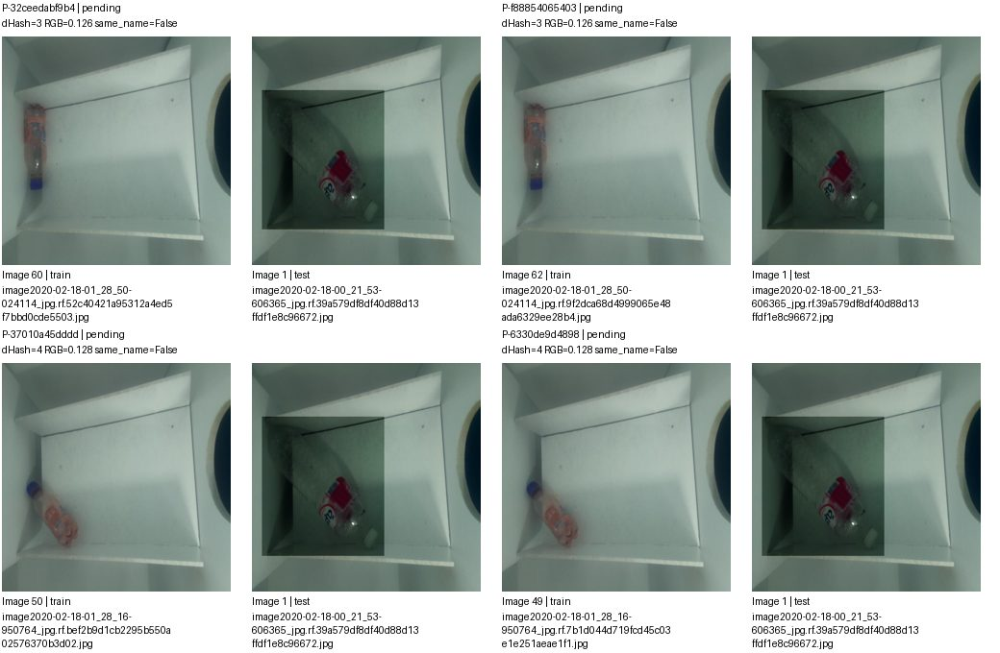

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-32ceedabf9b4,images/train/image2020-02-18-01_28_50-024114_jpg.rf.52c40421a95312a4ed5f7bbd0cde5503.jpg,images/test/image2020-02-18-00_21_53-606365_jpg.rf.39a579df8df40d88d13ffdf1e8c96672.jpg,pending,
P-f88854065403,images/train/image2020-02-18-01_28_50-024114_jpg.rf.9f2dca68d4999065e48ada6329ee28b4.jpg,images/test/image2020-02-18-00_21_53-606365_jpg.rf.39a579df8df40d88d13ffdf1e8c96672.jpg,pending,
P-37010a45dddd,images/train/image2020-02-18-01_28_16-950764_jpg.rf.bef2b9d1cb2295b550a02576370b3d02.jpg,images/test/image2020-02-18-00_21_53-606365_jpg.rf.39a579df8df40d88d13ffdf1e8c96672.jpg,pending,
P-6330de9d4898,images/train/image2020-02-18-01_28_16-950764_jpg.rf.7b1d044d719fcd45c03e1e251aeae1f1.jpg,images/test/image2020-02-18-00_21_53-606365_jpg.rf.39a579df8df40d88d13ffdf1e8c96672.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 52/166 G-586696e3c556 | 77 ảnh, 388 cặp
Split: {'test': 2, 'train': 70, 'val': 5}
Quyết định: {'pending': 388}
Ảnh trang None/13; cặp trang 91/97. Nhóm liên thông không phải kết luận trùng.


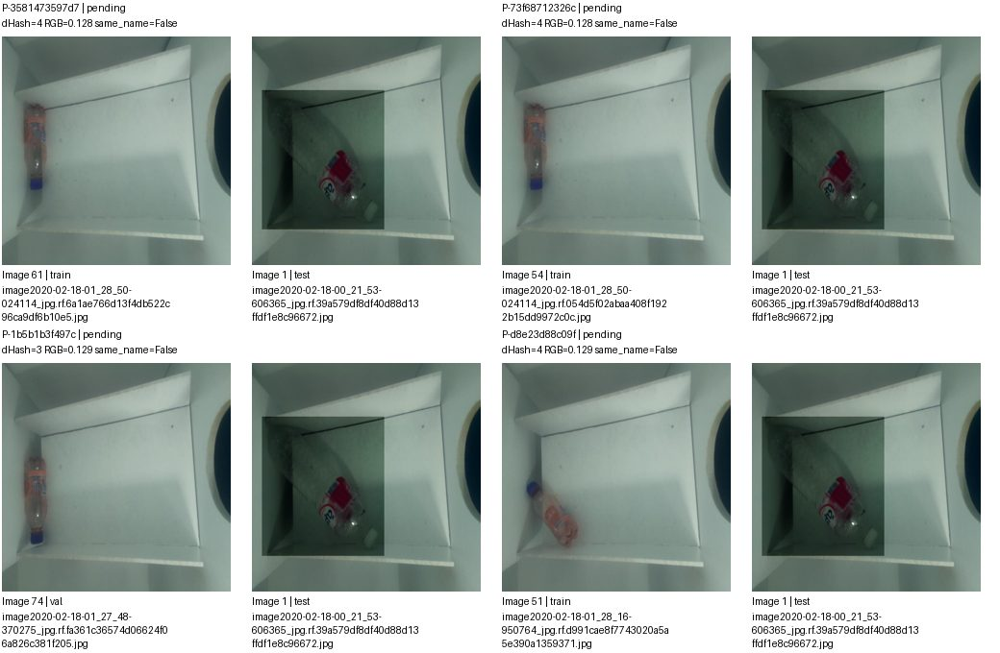

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-3581473597d7,images/train/image2020-02-18-01_28_50-024114_jpg.rf.6a1ae766d13f4db522c96ca9df6b10e5.jpg,images/test/image2020-02-18-00_21_53-606365_jpg.rf.39a579df8df40d88d13ffdf1e8c96672.jpg,pending,
P-73f68712326c,images/train/image2020-02-18-01_28_50-024114_jpg.rf.054d5f02abaa408f1922b15dd9972c0c.jpg,images/test/image2020-02-18-00_21_53-606365_jpg.rf.39a579df8df40d88d13ffdf1e8c96672.jpg,pending,
P-1b5b1b3f497c,images/val/image2020-02-18-01_27_48-370275_jpg.rf.fa361c36574d06624f06a826c381f205.jpg,images/test/image2020-02-18-00_21_53-606365_jpg.rf.39a579df8df40d88d13ffdf1e8c96672.jpg,pending,
P-d8e23d88c09f,images/train/image2020-02-18-01_28_16-950764_jpg.rf.d991cae8f7743020a5a5e390a1359371.jpg,images/test/image2020-02-18-00_21_53-606365_jpg.rf.39a579df8df40d88d13ffdf1e8c96672.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 52/166 G-586696e3c556 | 77 ảnh, 388 cặp
Split: {'test': 2, 'train': 70, 'val': 5}
Quyết định: {'pending': 388}
Ảnh trang None/13; cặp trang 92/97. Nhóm liên thông không phải kết luận trùng.


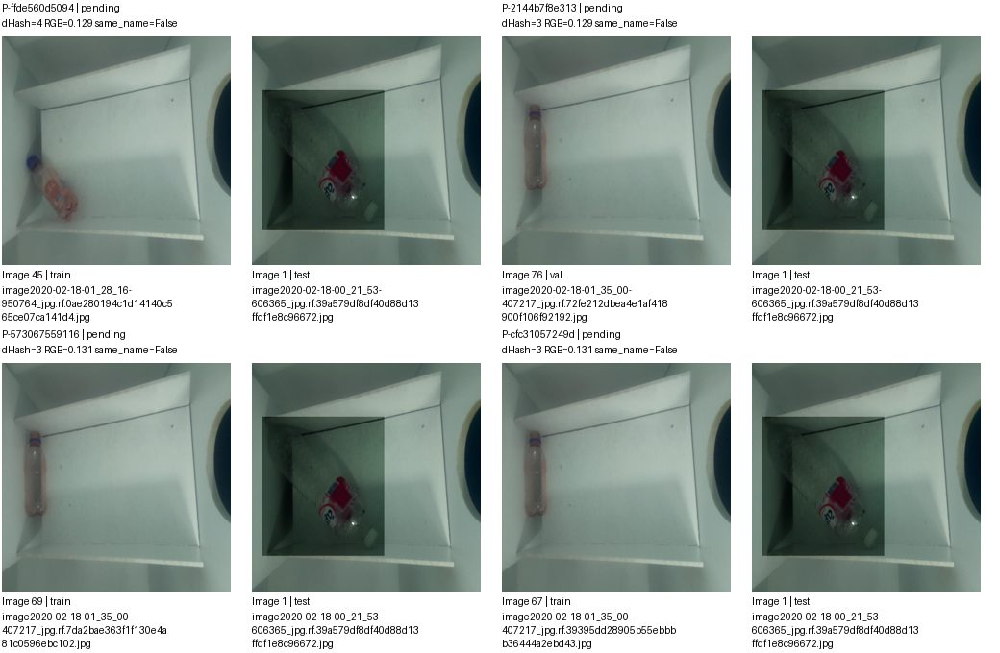

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-ffde560d5094,images/train/image2020-02-18-01_28_16-950764_jpg.rf.0ae280194c1d14140c565ce07ca141d4.jpg,images/test/image2020-02-18-00_21_53-606365_jpg.rf.39a579df8df40d88d13ffdf1e8c96672.jpg,pending,
P-2144b7f8e313,images/val/image2020-02-18-01_35_00-407217_jpg.rf.72fe212dbea4e1af418900f106f92192.jpg,images/test/image2020-02-18-00_21_53-606365_jpg.rf.39a579df8df40d88d13ffdf1e8c96672.jpg,pending,
P-573067559116,images/train/image2020-02-18-01_35_00-407217_jpg.rf.7da2bae363f1f130e4a81c0596ebc102.jpg,images/test/image2020-02-18-00_21_53-606365_jpg.rf.39a579df8df40d88d13ffdf1e8c96672.jpg,pending,
P-cfc31057249d,images/train/image2020-02-18-01_35_00-407217_jpg.rf.39395dd28905b55ebbbb36444a2ebd43.jpg,images/test/image2020-02-18-00_21_53-606365_jpg.rf.39a579df8df40d88d13ffdf1e8c96672.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 52/166 G-586696e3c556 | 77 ảnh, 388 cặp
Split: {'test': 2, 'train': 70, 'val': 5}
Quyết định: {'pending': 388}
Ảnh trang None/13; cặp trang 93/97. Nhóm liên thông không phải kết luận trùng.


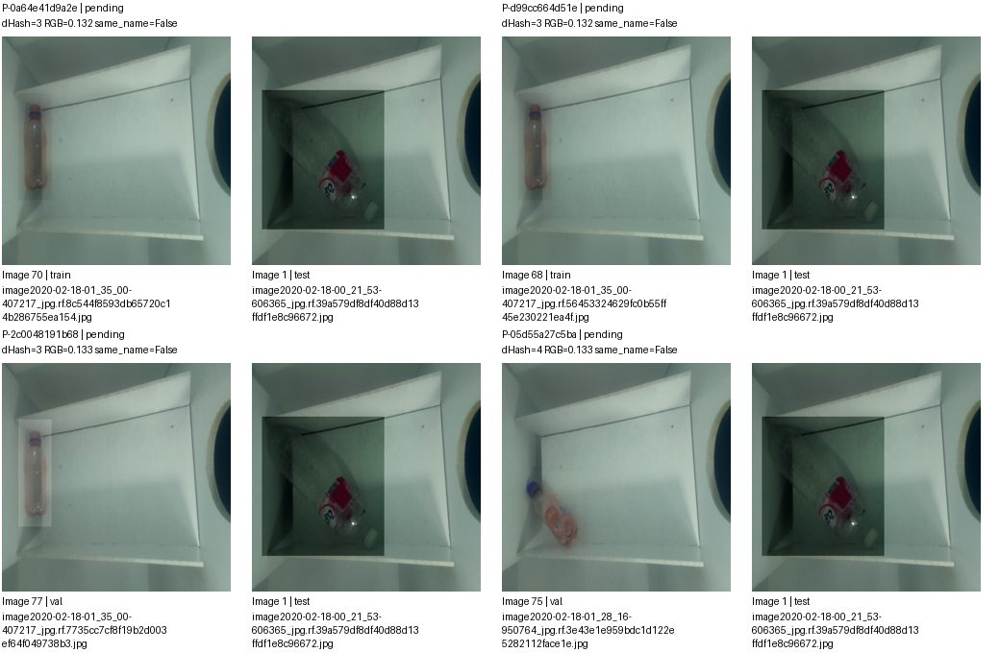

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-0a64e41d9a2e,images/train/image2020-02-18-01_35_00-407217_jpg.rf.8c544f8593db65720c14b286755ea154.jpg,images/test/image2020-02-18-00_21_53-606365_jpg.rf.39a579df8df40d88d13ffdf1e8c96672.jpg,pending,
P-d99cc664d51e,images/train/image2020-02-18-01_35_00-407217_jpg.rf.56453324629fc0b55ff45e230221ea4f.jpg,images/test/image2020-02-18-00_21_53-606365_jpg.rf.39a579df8df40d88d13ffdf1e8c96672.jpg,pending,
P-2c0048191b68,images/val/image2020-02-18-01_35_00-407217_jpg.rf.7735cc7cf8f19b2d003ef64f049738b3.jpg,images/test/image2020-02-18-00_21_53-606365_jpg.rf.39a579df8df40d88d13ffdf1e8c96672.jpg,pending,
P-05d55a27c5ba,images/val/image2020-02-18-01_28_16-950764_jpg.rf.3e43e1e959bdc1d122e5282112face1e.jpg,images/test/image2020-02-18-00_21_53-606365_jpg.rf.39a579df8df40d88d13ffdf1e8c96672.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 52/166 G-586696e3c556 | 77 ảnh, 388 cặp
Split: {'test': 2, 'train': 70, 'val': 5}
Quyết định: {'pending': 388}
Ảnh trang None/13; cặp trang 94/97. Nhóm liên thông không phải kết luận trùng.


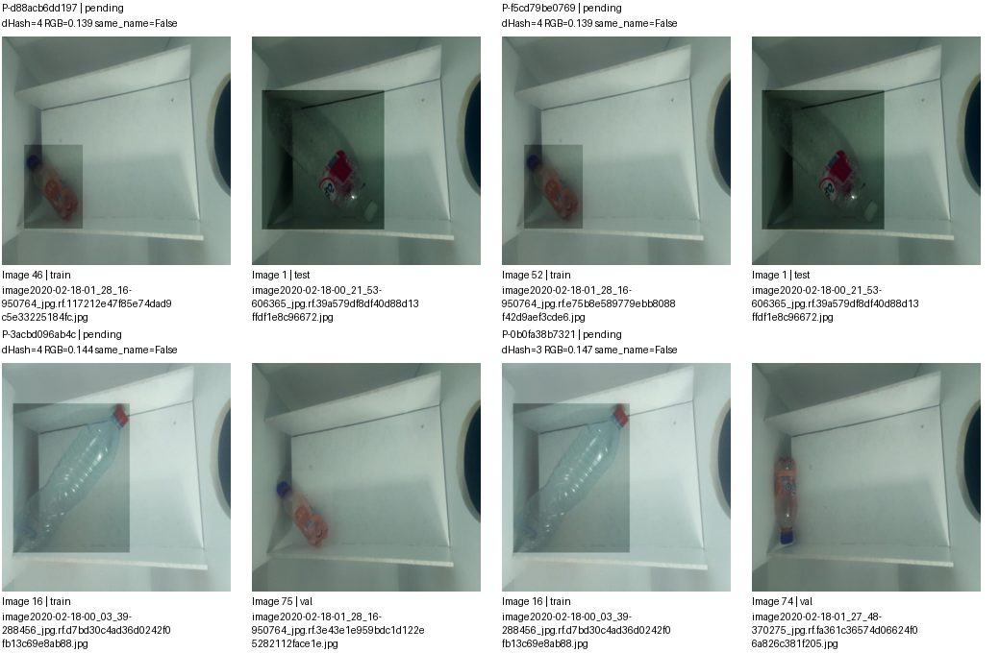

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-d88acb6dd197,images/train/image2020-02-18-01_28_16-950764_jpg.rf.117212e47f85e74dad9c5e33225184fc.jpg,images/test/image2020-02-18-00_21_53-606365_jpg.rf.39a579df8df40d88d13ffdf1e8c96672.jpg,pending,
P-f5cd79be0769,images/train/image2020-02-18-01_28_16-950764_jpg.rf.e75b8e589779ebb8088f42d9aef3cde6.jpg,images/test/image2020-02-18-00_21_53-606365_jpg.rf.39a579df8df40d88d13ffdf1e8c96672.jpg,pending,
P-3acbd096ab4c,images/train/image2020-02-18-00_03_39-288456_jpg.rf.d7bd30c4ad36d0242f0fb13c69e8ab88.jpg,images/val/image2020-02-18-01_28_16-950764_jpg.rf.3e43e1e959bdc1d122e5282112face1e.jpg,pending,
P-0b0fa38b7321,images/train/image2020-02-18-00_03_39-288456_jpg.rf.d7bd30c4ad36d0242f0fb13c69e8ab88.jpg,images/val/image2020-02-18-01_27_48-370275_jpg.rf.fa361c36574d06624f06a826c381f205.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 52/166 G-586696e3c556 | 77 ảnh, 388 cặp
Split: {'test': 2, 'train': 70, 'val': 5}
Quyết định: {'pending': 388}
Ảnh trang None/13; cặp trang 95/97. Nhóm liên thông không phải kết luận trùng.


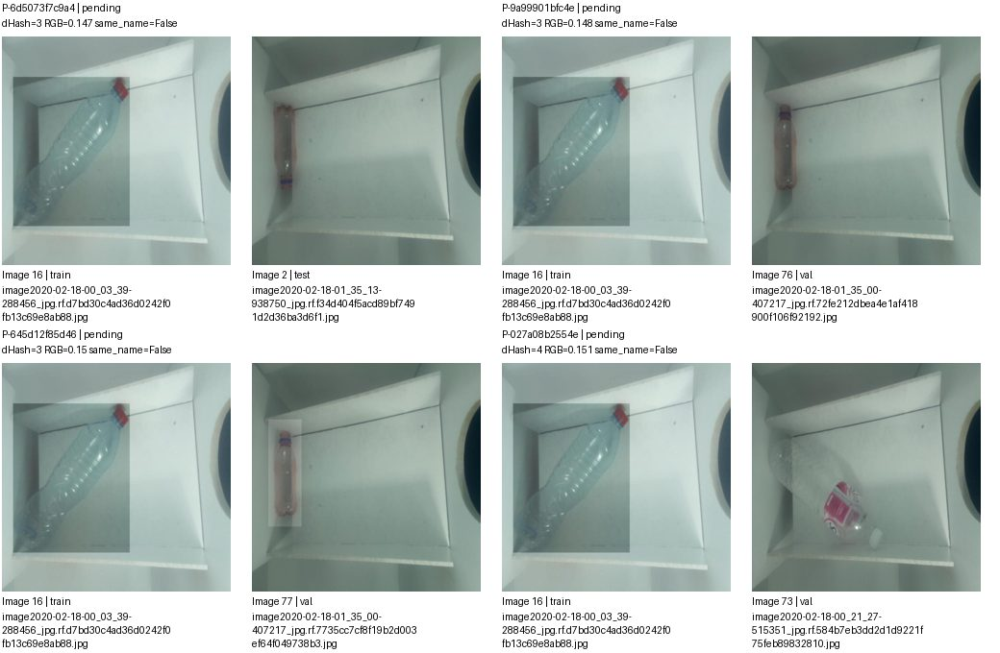

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-6d5073f7c9a4,images/train/image2020-02-18-00_03_39-288456_jpg.rf.d7bd30c4ad36d0242f0fb13c69e8ab88.jpg,images/test/image2020-02-18-01_35_13-938750_jpg.rf.f34d404f5acd89bf7491d2d36ba3d6f1.jpg,pending,
P-9a99901bfc4e,images/train/image2020-02-18-00_03_39-288456_jpg.rf.d7bd30c4ad36d0242f0fb13c69e8ab88.jpg,images/val/image2020-02-18-01_35_00-407217_jpg.rf.72fe212dbea4e1af418900f106f92192.jpg,pending,
P-645d12f85d46,images/train/image2020-02-18-00_03_39-288456_jpg.rf.d7bd30c4ad36d0242f0fb13c69e8ab88.jpg,images/val/image2020-02-18-01_35_00-407217_jpg.rf.7735cc7cf8f19b2d003ef64f049738b3.jpg,pending,
P-027a08b2554e,images/train/image2020-02-18-00_03_39-288456_jpg.rf.d7bd30c4ad36d0242f0fb13c69e8ab88.jpg,images/val/image2020-02-18-00_21_27-515351_jpg.rf.584b7eb3dd2d1d9221f75feb89832810.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 52/166 G-586696e3c556 | 77 ảnh, 388 cặp
Split: {'test': 2, 'train': 70, 'val': 5}
Quyết định: {'pending': 388}
Ảnh trang None/13; cặp trang 96/97. Nhóm liên thông không phải kết luận trùng.


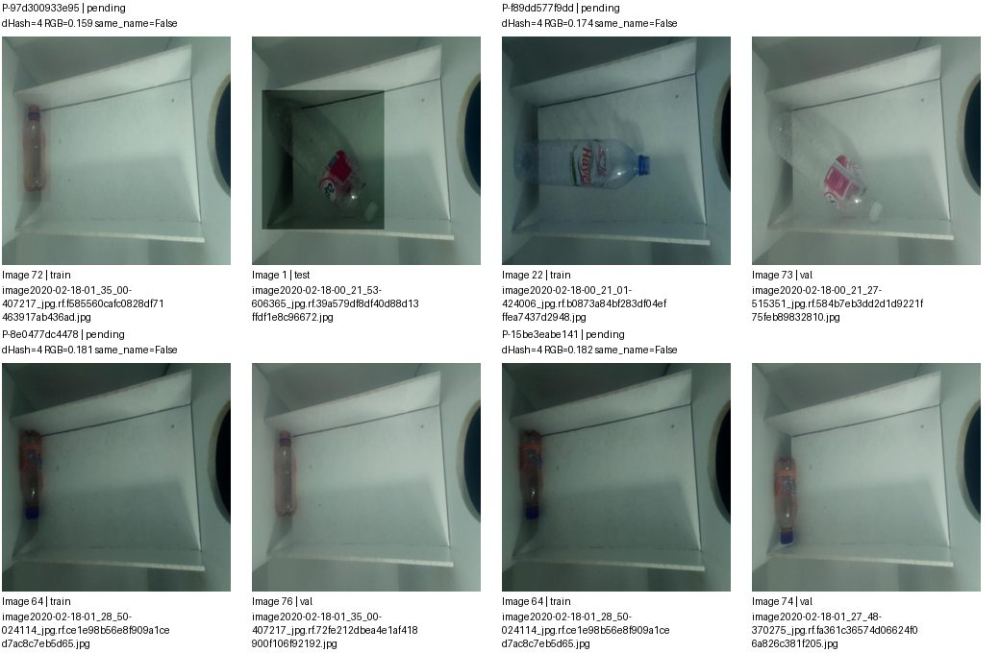

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-97d300933e95,images/train/image2020-02-18-01_35_00-407217_jpg.rf.f585560cafc0828df71463917ab436ad.jpg,images/test/image2020-02-18-00_21_53-606365_jpg.rf.39a579df8df40d88d13ffdf1e8c96672.jpg,pending,
P-f89dd577f9dd,images/train/image2020-02-18-00_21_01-424006_jpg.rf.b0873a84bf283df04efffea7437d2948.jpg,images/val/image2020-02-18-00_21_27-515351_jpg.rf.584b7eb3dd2d1d9221f75feb89832810.jpg,pending,
P-8e0477dc4478,images/train/image2020-02-18-01_28_50-024114_jpg.rf.ce1e98b56e8f909a1ced7ac8c7eb5d65.jpg,images/val/image2020-02-18-01_35_00-407217_jpg.rf.72fe212dbea4e1af418900f106f92192.jpg,pending,
P-15be3eabe141,images/train/image2020-02-18-01_28_50-024114_jpg.rf.ce1e98b56e8f909a1ced7ac8c7eb5d65.jpg,images/val/image2020-02-18-01_27_48-370275_jpg.rf.fa361c36574d06624f06a826c381f205.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 52/166 G-586696e3c556 | 77 ảnh, 388 cặp
Split: {'test': 2, 'train': 70, 'val': 5}
Quyết định: {'pending': 388}
Ảnh trang None/13; cặp trang 97/97. Nhóm liên thông không phải kết luận trùng.


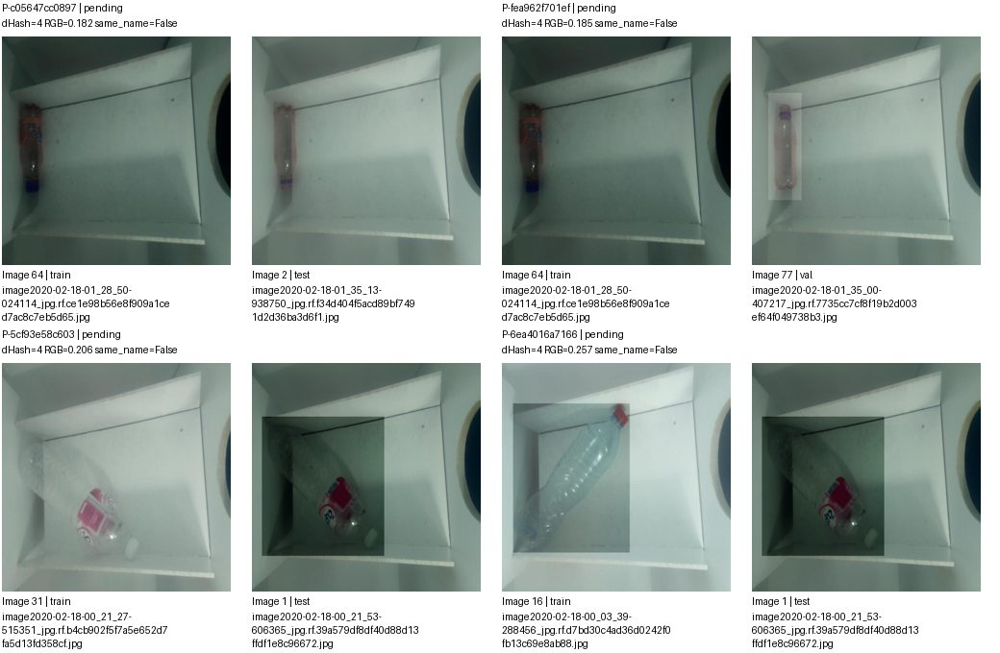

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-c05647cc0897,images/train/image2020-02-18-01_28_50-024114_jpg.rf.ce1e98b56e8f909a1ced7ac8c7eb5d65.jpg,images/test/image2020-02-18-01_35_13-938750_jpg.rf.f34d404f5acd89bf7491d2d36ba3d6f1.jpg,pending,
P-fea962f701ef,images/train/image2020-02-18-01_28_50-024114_jpg.rf.ce1e98b56e8f909a1ced7ac8c7eb5d65.jpg,images/val/image2020-02-18-01_35_00-407217_jpg.rf.7735cc7cf8f19b2d003ef64f049738b3.jpg,pending,
P-5cf93e58c603,images/train/image2020-02-18-00_21_27-515351_jpg.rf.b4cb902f5f7a5e652d7fa5d13fd358cf.jpg,images/test/image2020-02-18-00_21_53-606365_jpg.rf.39a579df8df40d88d13ffdf1e8c96672.jpg,pending,
P-6ea4016a7166,images/train/image2020-02-18-00_03_39-288456_jpg.rf.d7bd30c4ad36d0242f0fb13c69e8ab88.jpg,images/test/image2020-02-18-00_21_53-606365_jpg.rf.39a579df8df40d88d13ffdf1e8c96672.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 53/166 G-f2985d4df25e | 5 ảnh, 4 cặp
Split: {'train': 4, 'val': 1}
Quyết định: {'pending': 4}
Ảnh trang 1/1; cặp trang 1/1. Nhóm liên thông không phải kết luận trùng.


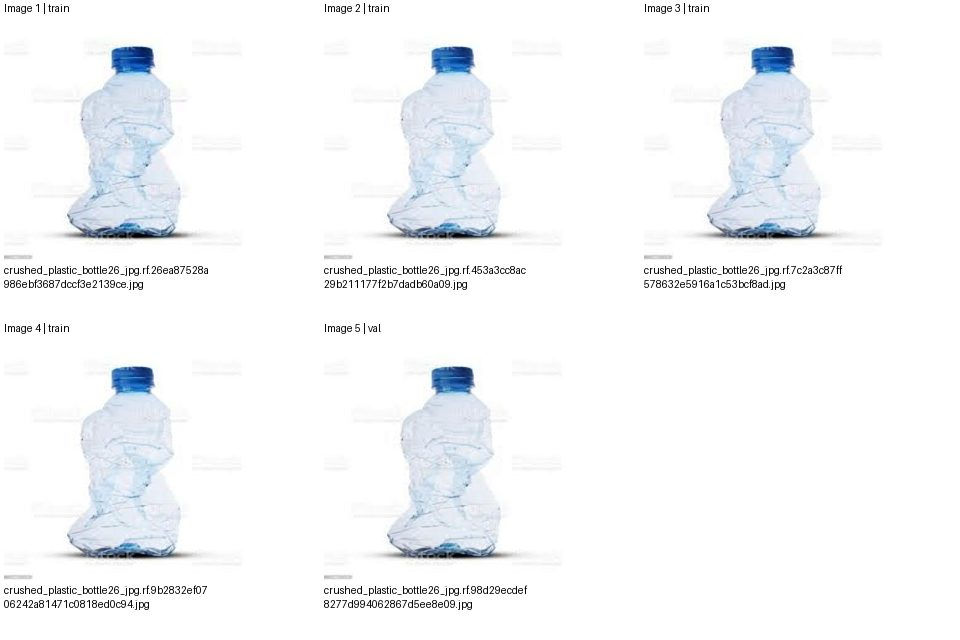

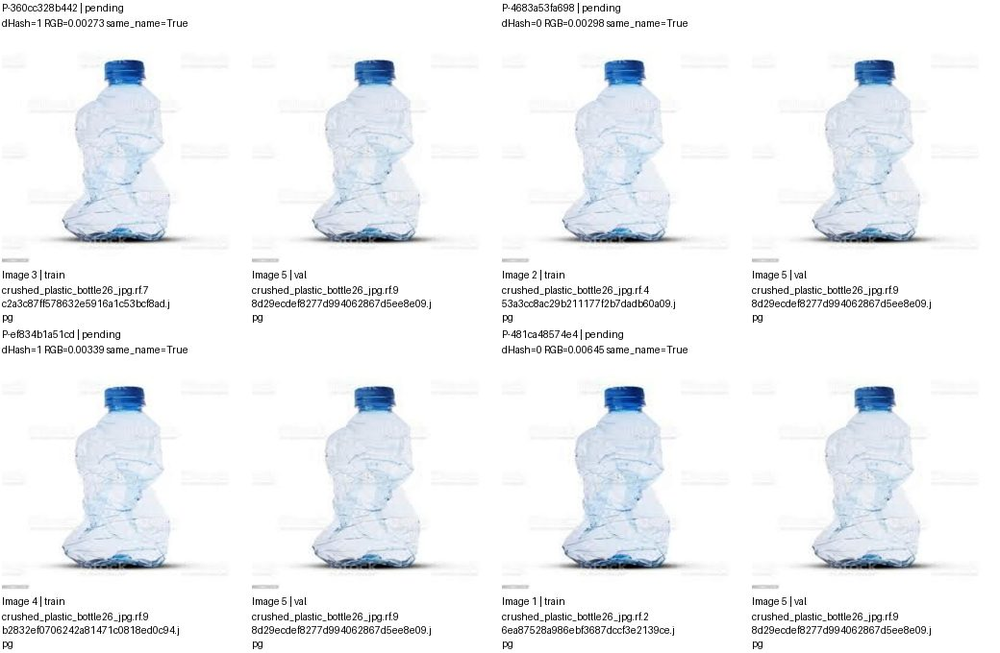

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-360cc328b442,images/train/crushed_plastic_bottle26_jpg.rf.7c2a3c87ff578632e5916a1c53bcf8ad.jpg,images/val/crushed_plastic_bottle26_jpg.rf.98d29ecdef8277d994062867d5ee8e09.jpg,pending,
P-4683a53fa698,images/train/crushed_plastic_bottle26_jpg.rf.453a3cc8ac29b211177f2b7dadb60a09.jpg,images/val/crushed_plastic_bottle26_jpg.rf.98d29ecdef8277d994062867d5ee8e09.jpg,pending,
P-ef834b1a51cd,images/train/crushed_plastic_bottle26_jpg.rf.9b2832ef0706242a81471c0818ed0c94.jpg,images/val/crushed_plastic_bottle26_jpg.rf.98d29ecdef8277d994062867d5ee8e09.jpg,pending,
P-481ca48574e4,images/train/crushed_plastic_bottle26_jpg.rf.26ea87528a986ebf3687dccf3e2139ce.jpg,images/val/crushed_plastic_bottle26_jpg.rf.98d29ecdef8277d994062867d5ee8e09.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 54/166 G-b824de185135 | 5 ảnh, 4 cặp
Split: {'test': 1, 'train': 4}
Quyết định: {'pending': 4}
Ảnh trang 1/1; cặp trang 1/1. Nhóm liên thông không phải kết luận trùng.


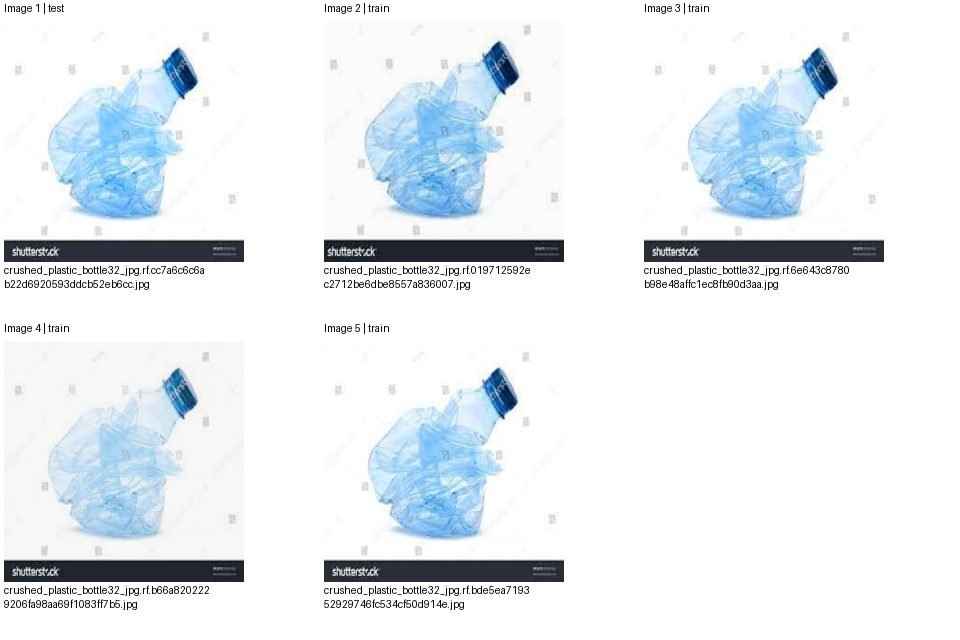

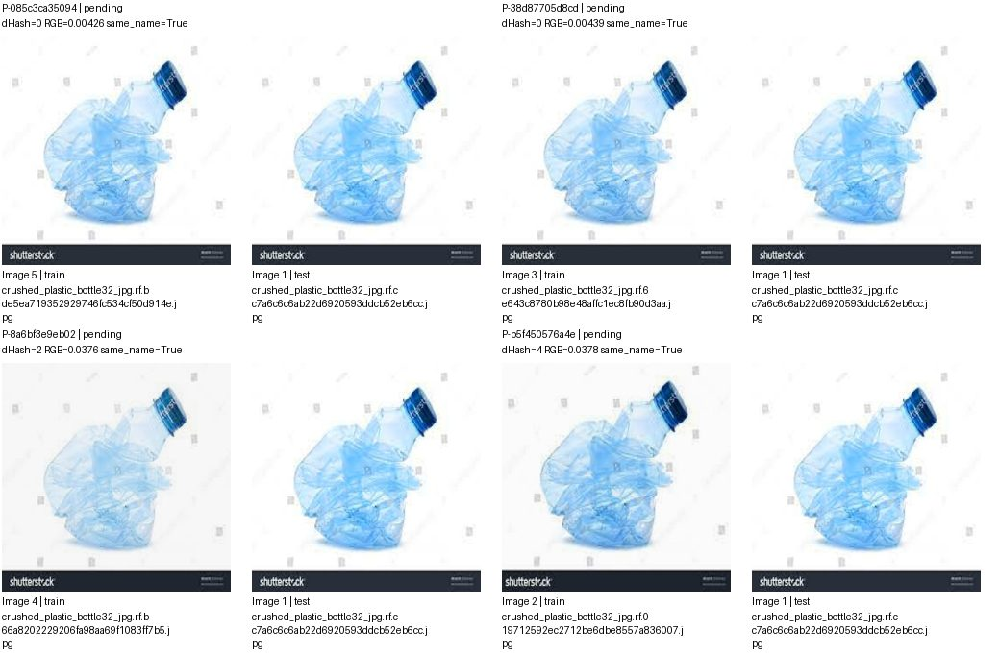

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-085c3ca35094,images/train/crushed_plastic_bottle32_jpg.rf.bde5ea719352929746fc534cf50d914e.jpg,images/test/crushed_plastic_bottle32_jpg.rf.cc7a6c6c6ab22d6920593ddcb52eb6cc.jpg,pending,
P-38d87705d8cd,images/train/crushed_plastic_bottle32_jpg.rf.6e643c8780b98e48affc1ec8fb90d3aa.jpg,images/test/crushed_plastic_bottle32_jpg.rf.cc7a6c6c6ab22d6920593ddcb52eb6cc.jpg,pending,
P-8a6bf3e9eb02,images/train/crushed_plastic_bottle32_jpg.rf.b66a8202229206fa98aa69f1083ff7b5.jpg,images/test/crushed_plastic_bottle32_jpg.rf.cc7a6c6c6ab22d6920593ddcb52eb6cc.jpg,pending,
P-b5f450576a4e,images/train/crushed_plastic_bottle32_jpg.rf.019712592ec2712be6dbe8557a836007.jpg,images/test/crushed_plastic_bottle32_jpg.rf.cc7a6c6c6ab22d6920593ddcb52eb6cc.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 55/166 G-982e454aca22 | 21 ảnh, 56 cặp
Split: {'test': 2, 'train': 15, 'val': 4}
Quyết định: {'pending': 56}
Ảnh trang 1/4; cặp trang 1/14. Nhóm liên thông không phải kết luận trùng.


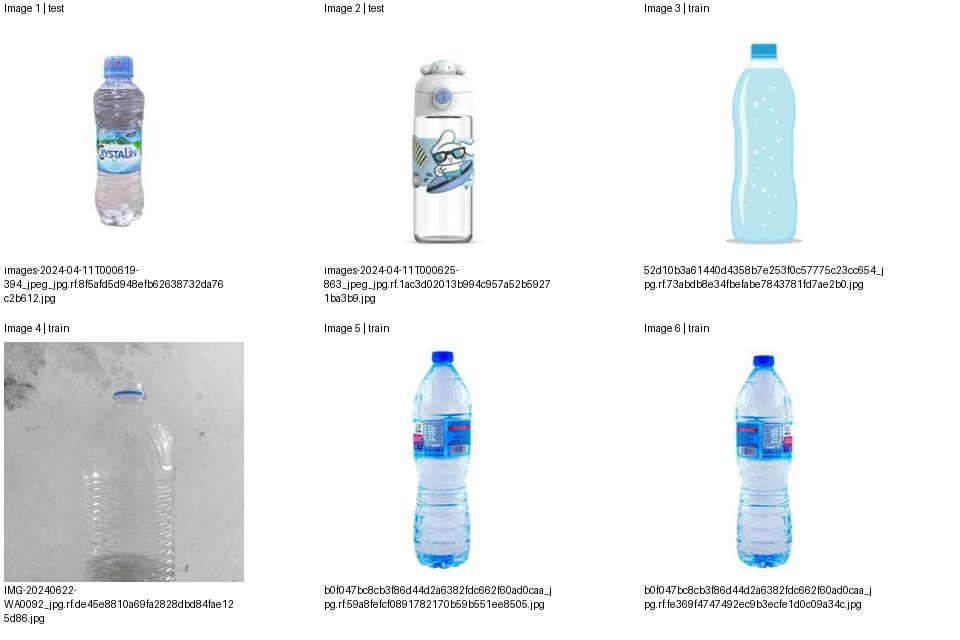

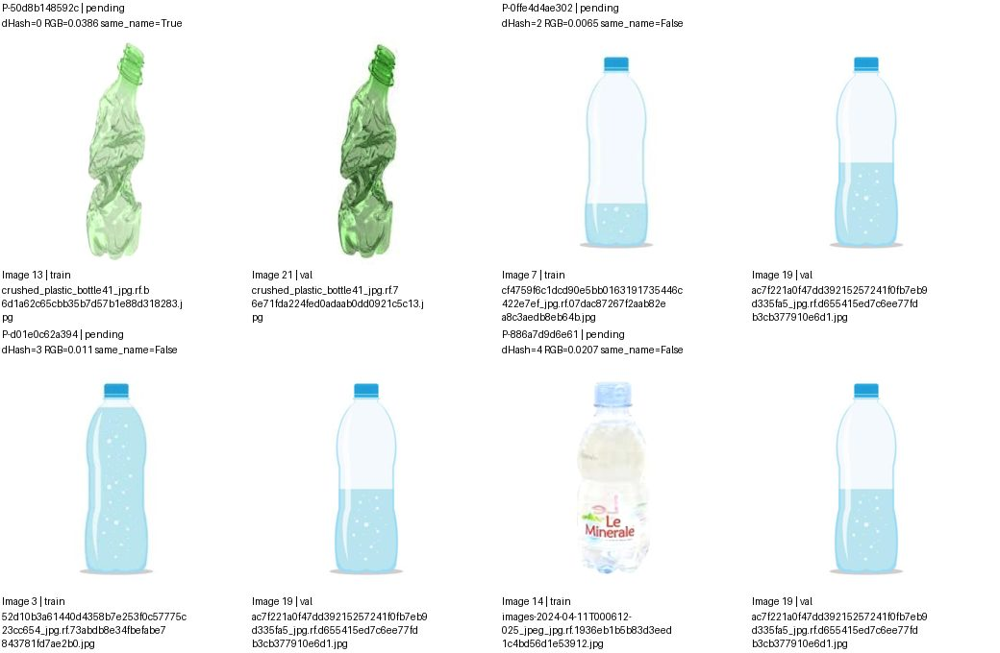

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-50d8b148592c,images/train/crushed_plastic_bottle41_jpg.rf.b6d1a62c65cbb35b7d57b1e88d318283.jpg,images/val/crushed_plastic_bottle41_jpg.rf.76e71fda224fed0adaab0dd0921c5c13.jpg,pending,
P-0ffe4d4ae302,images/train/cf4759f6c1dcd90e5bb0163191735446c422e7ef_jpg.rf.07dac87267f2aab82ea8c3aedb8eb64b.jpg,images/val/ac7f221a0f47dd39215257241f0fb7eb9d335fa5_jpg.rf.d655415ed7c6ee77fdb3cb377910e6d1.jpg,pending,
P-d01e0c62a394,images/train/52d10b3a61440d4358b7e253f0c57775c23cc654_jpg.rf.73abdb8e34fbefabe7843781fd7ae2b0.jpg,images/val/ac7f221a0f47dd39215257241f0fb7eb9d335fa5_jpg.rf.d655415ed7c6ee77fdb3cb377910e6d1.jpg,pending,
P-886a7d9d6e61,images/train/images-2024-04-11T000612-025_jpeg_jpg.rf.1936eb1b5b83d3eed1c4bd56d1e53912.jpg,images/val/ac7f221a0f47dd39215257241f0fb7eb9d335fa5_jpg.rf.d655415ed7c6ee77fdb3cb377910e6d1.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 55/166 G-982e454aca22 | 21 ảnh, 56 cặp
Split: {'test': 2, 'train': 15, 'val': 4}
Quyết định: {'pending': 56}
Ảnh trang 2/4; cặp trang 2/14. Nhóm liên thông không phải kết luận trùng.


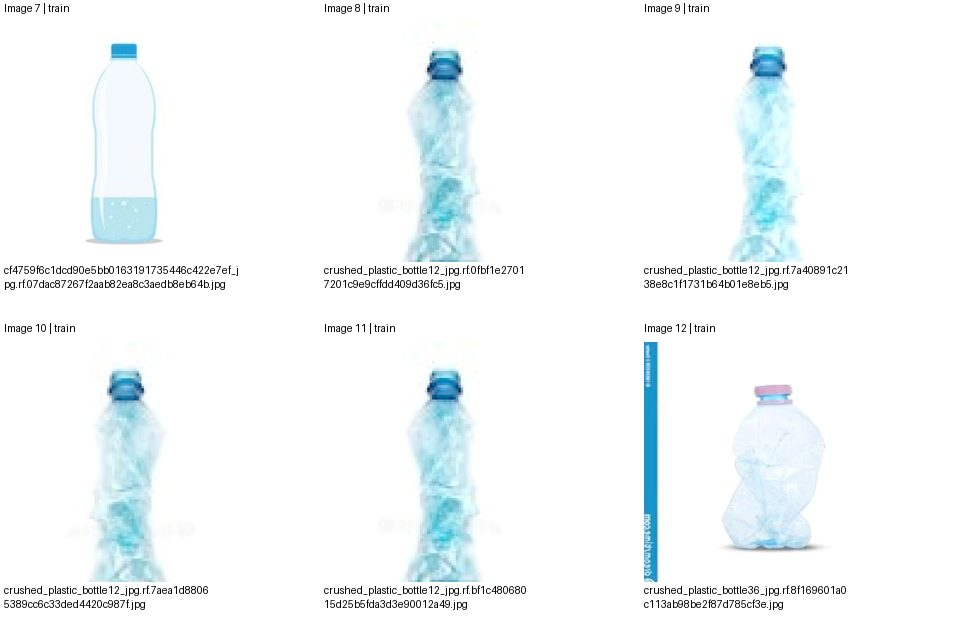

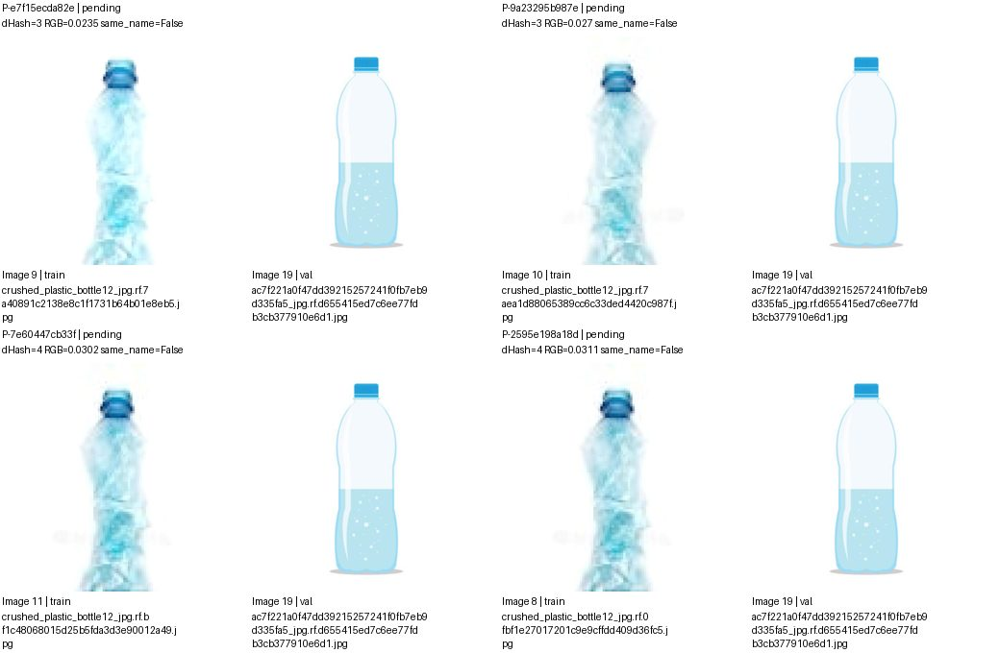

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-e7f15ecda82e,images/train/crushed_plastic_bottle12_jpg.rf.7a40891c2138e8c1f1731b64b01e8eb5.jpg,images/val/ac7f221a0f47dd39215257241f0fb7eb9d335fa5_jpg.rf.d655415ed7c6ee77fdb3cb377910e6d1.jpg,pending,
P-9a23295b987e,images/train/crushed_plastic_bottle12_jpg.rf.7aea1d88065389cc6c33ded4420c987f.jpg,images/val/ac7f221a0f47dd39215257241f0fb7eb9d335fa5_jpg.rf.d655415ed7c6ee77fdb3cb377910e6d1.jpg,pending,
P-7e60447cb33f,images/train/crushed_plastic_bottle12_jpg.rf.bf1c48068015d25b5fda3d3e90012a49.jpg,images/val/ac7f221a0f47dd39215257241f0fb7eb9d335fa5_jpg.rf.d655415ed7c6ee77fdb3cb377910e6d1.jpg,pending,
P-2595e198a18d,images/train/crushed_plastic_bottle12_jpg.rf.0fbf1e27017201c9e9cffdd409d36fc5.jpg,images/val/ac7f221a0f47dd39215257241f0fb7eb9d335fa5_jpg.rf.d655415ed7c6ee77fdb3cb377910e6d1.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 55/166 G-982e454aca22 | 21 ảnh, 56 cặp
Split: {'test': 2, 'train': 15, 'val': 4}
Quyết định: {'pending': 56}
Ảnh trang 3/4; cặp trang 3/14. Nhóm liên thông không phải kết luận trùng.


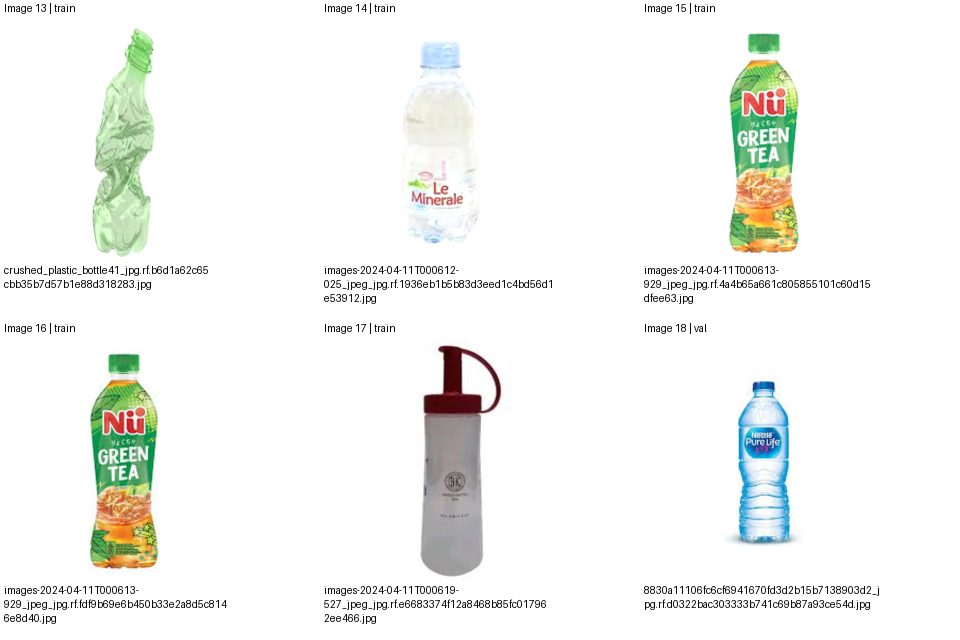

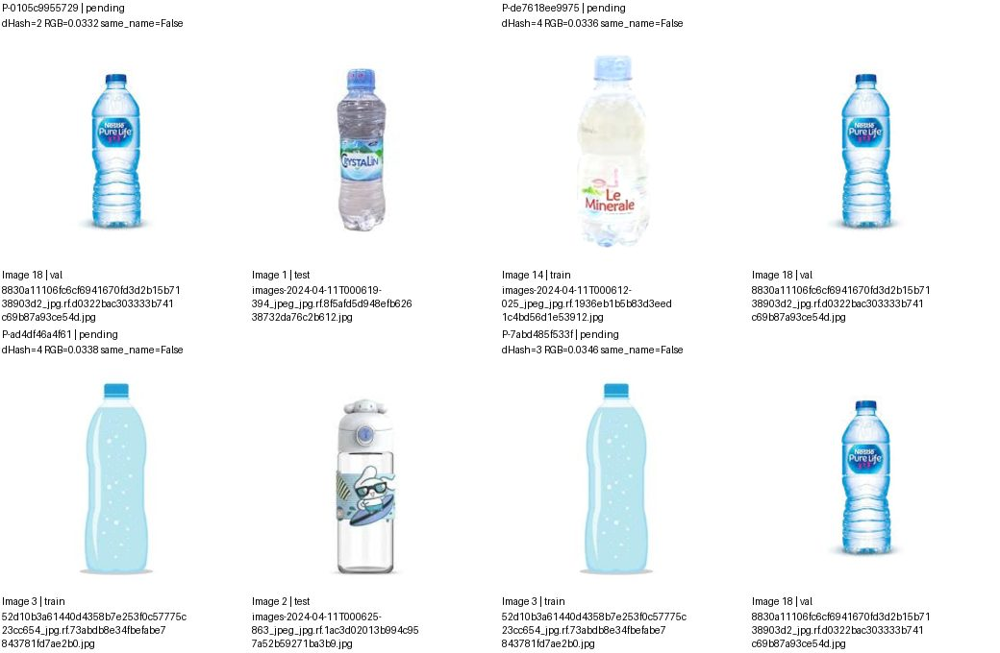

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-0105c9955729,images/val/8830a11106fc6cf6941670fd3d2b15b7138903d2_jpg.rf.d0322bac303333b741c69b87a93ce54d.jpg,images/test/images-2024-04-11T000619-394_jpeg_jpg.rf.8f5afd5d948efb62638732da76c2b612.jpg,pending,
P-de7618ee9975,images/train/images-2024-04-11T000612-025_jpeg_jpg.rf.1936eb1b5b83d3eed1c4bd56d1e53912.jpg,images/val/8830a11106fc6cf6941670fd3d2b15b7138903d2_jpg.rf.d0322bac303333b741c69b87a93ce54d.jpg,pending,
P-ad4df46a4f61,images/train/52d10b3a61440d4358b7e253f0c57775c23cc654_jpg.rf.73abdb8e34fbefabe7843781fd7ae2b0.jpg,images/test/images-2024-04-11T000625-863_jpeg_jpg.rf.1ac3d02013b994c957a52b59271ba3b9.jpg,pending,
P-7abd485f533f,images/train/52d10b3a61440d4358b7e253f0c57775c23cc654_jpg.rf.73abdb8e34fbefabe7843781fd7ae2b0.jpg,images/val/8830a11106fc6cf6941670fd3d2b15b7138903d2_jpg.rf.d0322bac303333b741c69b87a93ce54d.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 55/166 G-982e454aca22 | 21 ảnh, 56 cặp
Split: {'test': 2, 'train': 15, 'val': 4}
Quyết định: {'pending': 56}
Ảnh trang 4/4; cặp trang 4/14. Nhóm liên thông không phải kết luận trùng.


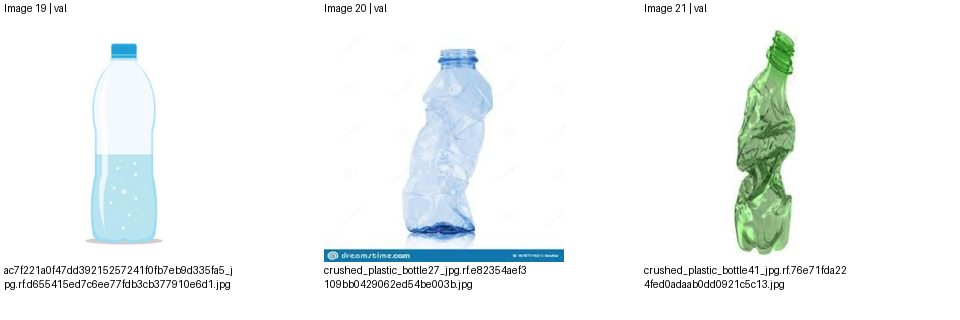

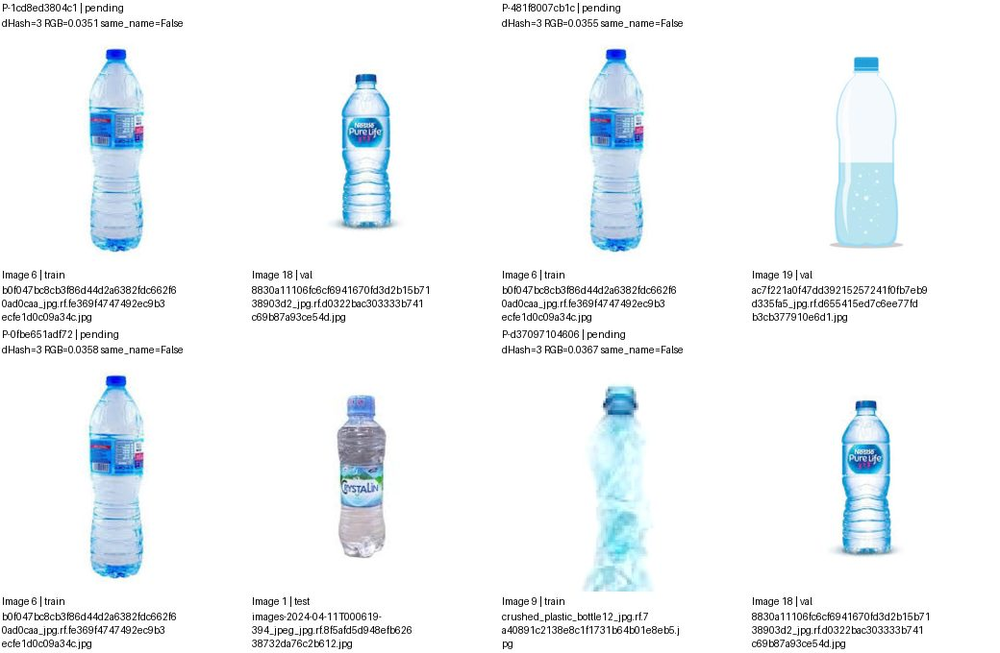

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-1cd8ed3804c1,images/train/b0f047bc8cb3f86d44d2a6382fdc662f60ad0caa_jpg.rf.fe369f4747492ec9b3ecfe1d0c09a34c.jpg,images/val/8830a11106fc6cf6941670fd3d2b15b7138903d2_jpg.rf.d0322bac303333b741c69b87a93ce54d.jpg,pending,
P-481f8007cb1c,images/train/b0f047bc8cb3f86d44d2a6382fdc662f60ad0caa_jpg.rf.fe369f4747492ec9b3ecfe1d0c09a34c.jpg,images/val/ac7f221a0f47dd39215257241f0fb7eb9d335fa5_jpg.rf.d655415ed7c6ee77fdb3cb377910e6d1.jpg,pending,
P-0fbe651adf72,images/train/b0f047bc8cb3f86d44d2a6382fdc662f60ad0caa_jpg.rf.fe369f4747492ec9b3ecfe1d0c09a34c.jpg,images/test/images-2024-04-11T000619-394_jpeg_jpg.rf.8f5afd5d948efb62638732da76c2b612.jpg,pending,
P-d37097104606,images/train/crushed_plastic_bottle12_jpg.rf.7a40891c2138e8c1f1731b64b01e8eb5.jpg,images/val/8830a11106fc6cf6941670fd3d2b15b7138903d2_jpg.rf.d0322bac303333b741c69b87a93ce54d.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 55/166 G-982e454aca22 | 21 ảnh, 56 cặp
Split: {'test': 2, 'train': 15, 'val': 4}
Quyết định: {'pending': 56}
Ảnh trang None/4; cặp trang 5/14. Nhóm liên thông không phải kết luận trùng.


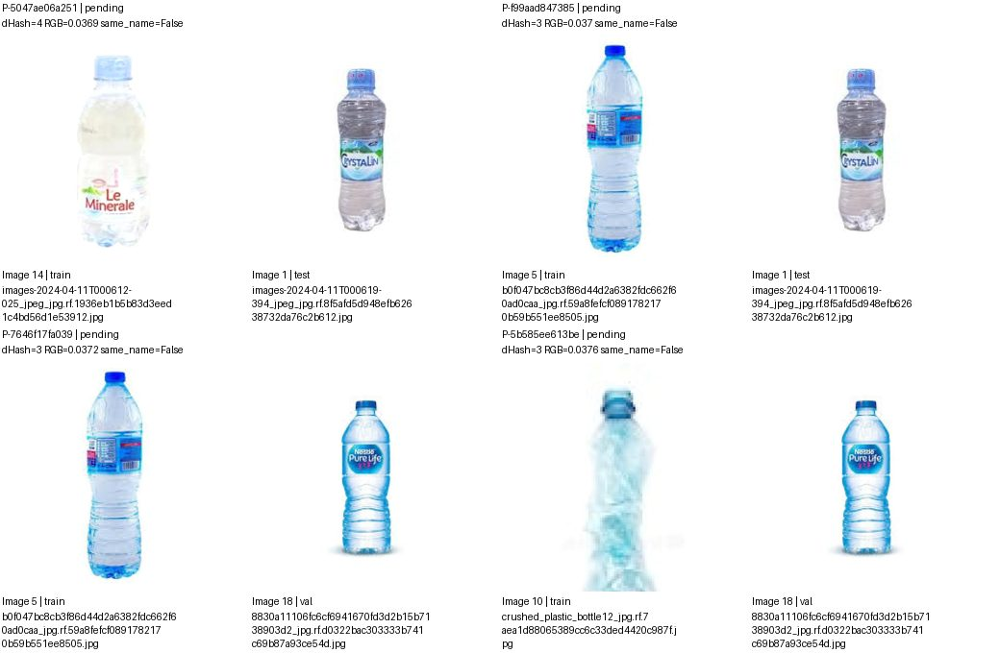

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-5047ae06a251,images/train/images-2024-04-11T000612-025_jpeg_jpg.rf.1936eb1b5b83d3eed1c4bd56d1e53912.jpg,images/test/images-2024-04-11T000619-394_jpeg_jpg.rf.8f5afd5d948efb62638732da76c2b612.jpg,pending,
P-f99aad847385,images/train/b0f047bc8cb3f86d44d2a6382fdc662f60ad0caa_jpg.rf.59a8fefcf0891782170b59b551ee8505.jpg,images/test/images-2024-04-11T000619-394_jpeg_jpg.rf.8f5afd5d948efb62638732da76c2b612.jpg,pending,
P-7646f17fa039,images/train/b0f047bc8cb3f86d44d2a6382fdc662f60ad0caa_jpg.rf.59a8fefcf0891782170b59b551ee8505.jpg,images/val/8830a11106fc6cf6941670fd3d2b15b7138903d2_jpg.rf.d0322bac303333b741c69b87a93ce54d.jpg,pending,
P-5b585ee613be,images/train/crushed_plastic_bottle12_jpg.rf.7aea1d88065389cc6c33ded4420c987f.jpg,images/val/8830a11106fc6cf6941670fd3d2b15b7138903d2_jpg.rf.d0322bac303333b741c69b87a93ce54d.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 55/166 G-982e454aca22 | 21 ảnh, 56 cặp
Split: {'test': 2, 'train': 15, 'val': 4}
Quyết định: {'pending': 56}
Ảnh trang None/4; cặp trang 6/14. Nhóm liên thông không phải kết luận trùng.


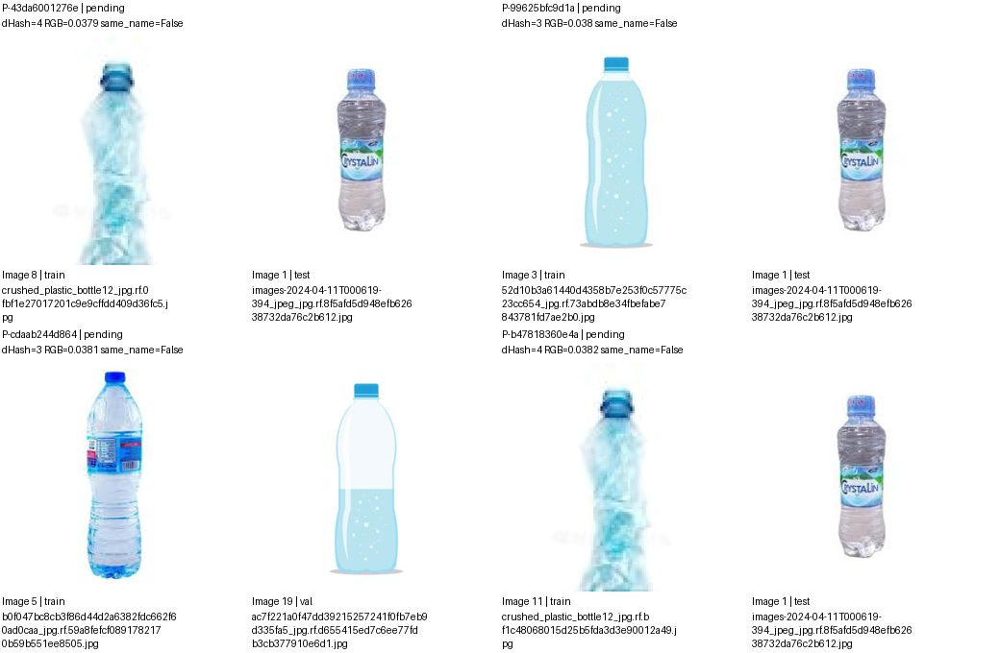

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-43da6001276e,images/train/crushed_plastic_bottle12_jpg.rf.0fbf1e27017201c9e9cffdd409d36fc5.jpg,images/test/images-2024-04-11T000619-394_jpeg_jpg.rf.8f5afd5d948efb62638732da76c2b612.jpg,pending,
P-99625bfc9d1a,images/train/52d10b3a61440d4358b7e253f0c57775c23cc654_jpg.rf.73abdb8e34fbefabe7843781fd7ae2b0.jpg,images/test/images-2024-04-11T000619-394_jpeg_jpg.rf.8f5afd5d948efb62638732da76c2b612.jpg,pending,
P-cdaab244d864,images/train/b0f047bc8cb3f86d44d2a6382fdc662f60ad0caa_jpg.rf.59a8fefcf0891782170b59b551ee8505.jpg,images/val/ac7f221a0f47dd39215257241f0fb7eb9d335fa5_jpg.rf.d655415ed7c6ee77fdb3cb377910e6d1.jpg,pending,
P-b47818360e4a,images/train/crushed_plastic_bottle12_jpg.rf.bf1c48068015d25b5fda3d3e90012a49.jpg,images/test/images-2024-04-11T000619-394_jpeg_jpg.rf.8f5afd5d948efb62638732da76c2b612.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 55/166 G-982e454aca22 | 21 ảnh, 56 cặp
Split: {'test': 2, 'train': 15, 'val': 4}
Quyết định: {'pending': 56}
Ảnh trang None/4; cặp trang 7/14. Nhóm liên thông không phải kết luận trùng.


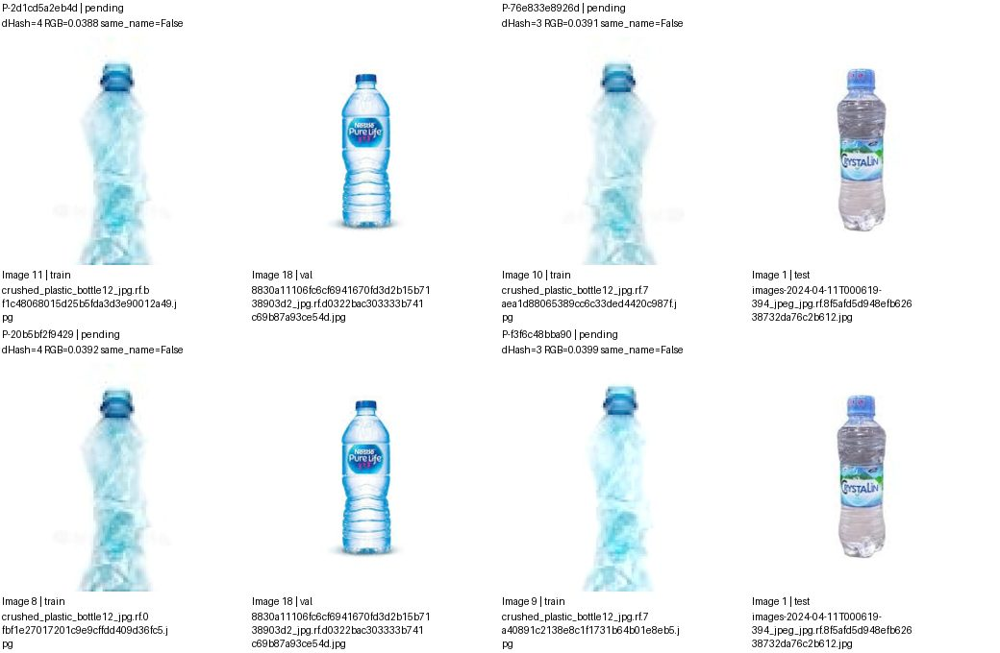

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-2d1cd5a2eb4d,images/train/crushed_plastic_bottle12_jpg.rf.bf1c48068015d25b5fda3d3e90012a49.jpg,images/val/8830a11106fc6cf6941670fd3d2b15b7138903d2_jpg.rf.d0322bac303333b741c69b87a93ce54d.jpg,pending,
P-76e833e8926d,images/train/crushed_plastic_bottle12_jpg.rf.7aea1d88065389cc6c33ded4420c987f.jpg,images/test/images-2024-04-11T000619-394_jpeg_jpg.rf.8f5afd5d948efb62638732da76c2b612.jpg,pending,
P-20b5bf2f9429,images/train/crushed_plastic_bottle12_jpg.rf.0fbf1e27017201c9e9cffdd409d36fc5.jpg,images/val/8830a11106fc6cf6941670fd3d2b15b7138903d2_jpg.rf.d0322bac303333b741c69b87a93ce54d.jpg,pending,
P-f3f6c48bba90,images/train/crushed_plastic_bottle12_jpg.rf.7a40891c2138e8c1f1731b64b01e8eb5.jpg,images/test/images-2024-04-11T000619-394_jpeg_jpg.rf.8f5afd5d948efb62638732da76c2b612.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 55/166 G-982e454aca22 | 21 ảnh, 56 cặp
Split: {'test': 2, 'train': 15, 'val': 4}
Quyết định: {'pending': 56}
Ảnh trang None/4; cặp trang 8/14. Nhóm liên thông không phải kết luận trùng.


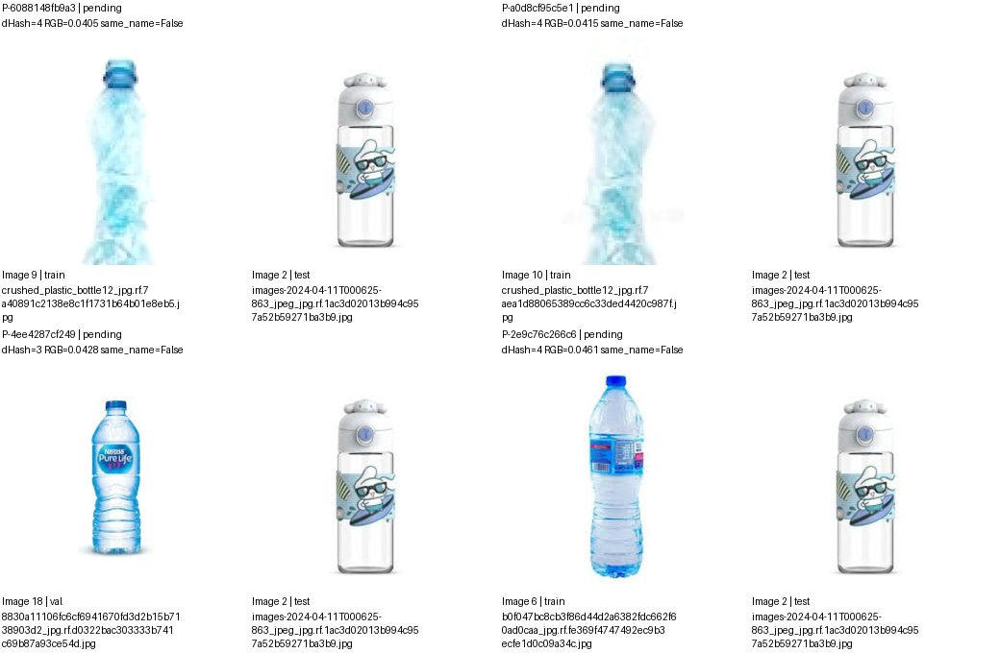

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-6088148fb9a3,images/train/crushed_plastic_bottle12_jpg.rf.7a40891c2138e8c1f1731b64b01e8eb5.jpg,images/test/images-2024-04-11T000625-863_jpeg_jpg.rf.1ac3d02013b994c957a52b59271ba3b9.jpg,pending,
P-a0d8cf95c5e1,images/train/crushed_plastic_bottle12_jpg.rf.7aea1d88065389cc6c33ded4420c987f.jpg,images/test/images-2024-04-11T000625-863_jpeg_jpg.rf.1ac3d02013b994c957a52b59271ba3b9.jpg,pending,
P-4ee4287cf249,images/val/8830a11106fc6cf6941670fd3d2b15b7138903d2_jpg.rf.d0322bac303333b741c69b87a93ce54d.jpg,images/test/images-2024-04-11T000625-863_jpeg_jpg.rf.1ac3d02013b994c957a52b59271ba3b9.jpg,pending,
P-2e9c76c266c6,images/train/b0f047bc8cb3f86d44d2a6382fdc662f60ad0caa_jpg.rf.fe369f4747492ec9b3ecfe1d0c09a34c.jpg,images/test/images-2024-04-11T000625-863_jpeg_jpg.rf.1ac3d02013b994c957a52b59271ba3b9.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 55/166 G-982e454aca22 | 21 ảnh, 56 cặp
Split: {'test': 2, 'train': 15, 'val': 4}
Quyết định: {'pending': 56}
Ảnh trang None/4; cặp trang 9/14. Nhóm liên thông không phải kết luận trùng.


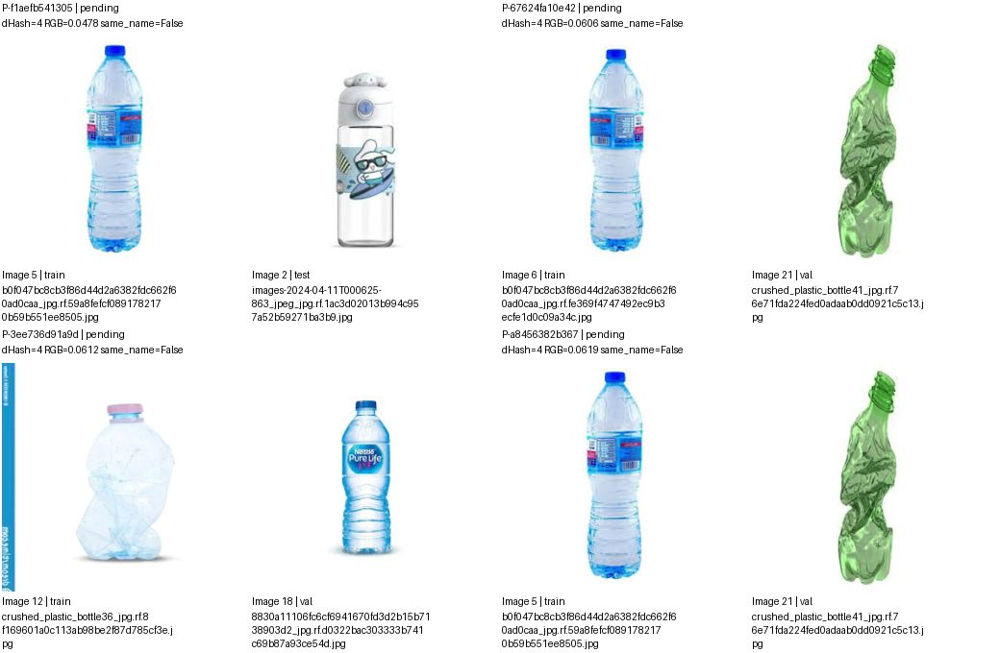

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-f1aefb541305,images/train/b0f047bc8cb3f86d44d2a6382fdc662f60ad0caa_jpg.rf.59a8fefcf0891782170b59b551ee8505.jpg,images/test/images-2024-04-11T000625-863_jpeg_jpg.rf.1ac3d02013b994c957a52b59271ba3b9.jpg,pending,
P-67624fa10e42,images/train/b0f047bc8cb3f86d44d2a6382fdc662f60ad0caa_jpg.rf.fe369f4747492ec9b3ecfe1d0c09a34c.jpg,images/val/crushed_plastic_bottle41_jpg.rf.76e71fda224fed0adaab0dd0921c5c13.jpg,pending,
P-3ee736d91a9d,images/train/crushed_plastic_bottle36_jpg.rf.8f169601a0c113ab98be2f87d785cf3e.jpg,images/val/8830a11106fc6cf6941670fd3d2b15b7138903d2_jpg.rf.d0322bac303333b741c69b87a93ce54d.jpg,pending,
P-a8456382b367,images/train/b0f047bc8cb3f86d44d2a6382fdc662f60ad0caa_jpg.rf.59a8fefcf0891782170b59b551ee8505.jpg,images/val/crushed_plastic_bottle41_jpg.rf.76e71fda224fed0adaab0dd0921c5c13.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 55/166 G-982e454aca22 | 21 ảnh, 56 cặp
Split: {'test': 2, 'train': 15, 'val': 4}
Quyết định: {'pending': 56}
Ảnh trang None/4; cặp trang 10/14. Nhóm liên thông không phải kết luận trùng.


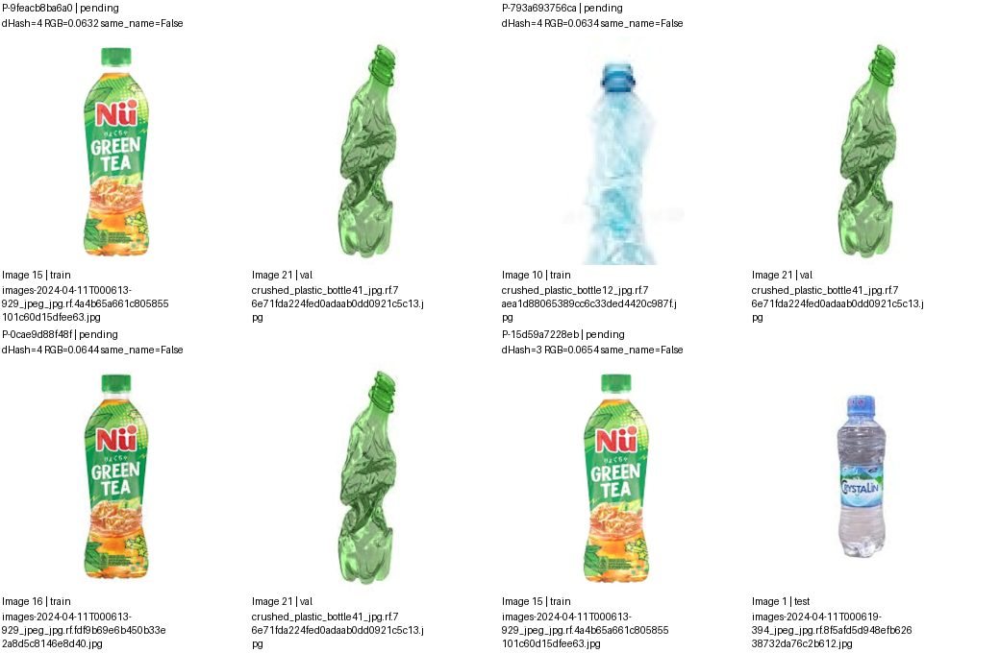

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-9feacb8ba6a0,images/train/images-2024-04-11T000613-929_jpeg_jpg.rf.4a4b65a661c805855101c60d15dfee63.jpg,images/val/crushed_plastic_bottle41_jpg.rf.76e71fda224fed0adaab0dd0921c5c13.jpg,pending,
P-793a693756ca,images/train/crushed_plastic_bottle12_jpg.rf.7aea1d88065389cc6c33ded4420c987f.jpg,images/val/crushed_plastic_bottle41_jpg.rf.76e71fda224fed0adaab0dd0921c5c13.jpg,pending,
P-0cae9d88f48f,images/train/images-2024-04-11T000613-929_jpeg_jpg.rf.fdf9b69e6b450b33e2a8d5c8146e8d40.jpg,images/val/crushed_plastic_bottle41_jpg.rf.76e71fda224fed0adaab0dd0921c5c13.jpg,pending,
P-15d59a7228eb,images/train/images-2024-04-11T000613-929_jpeg_jpg.rf.4a4b65a661c805855101c60d15dfee63.jpg,images/test/images-2024-04-11T000619-394_jpeg_jpg.rf.8f5afd5d948efb62638732da76c2b612.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 55/166 G-982e454aca22 | 21 ảnh, 56 cặp
Split: {'test': 2, 'train': 15, 'val': 4}
Quyết định: {'pending': 56}
Ảnh trang None/4; cặp trang 11/14. Nhóm liên thông không phải kết luận trùng.


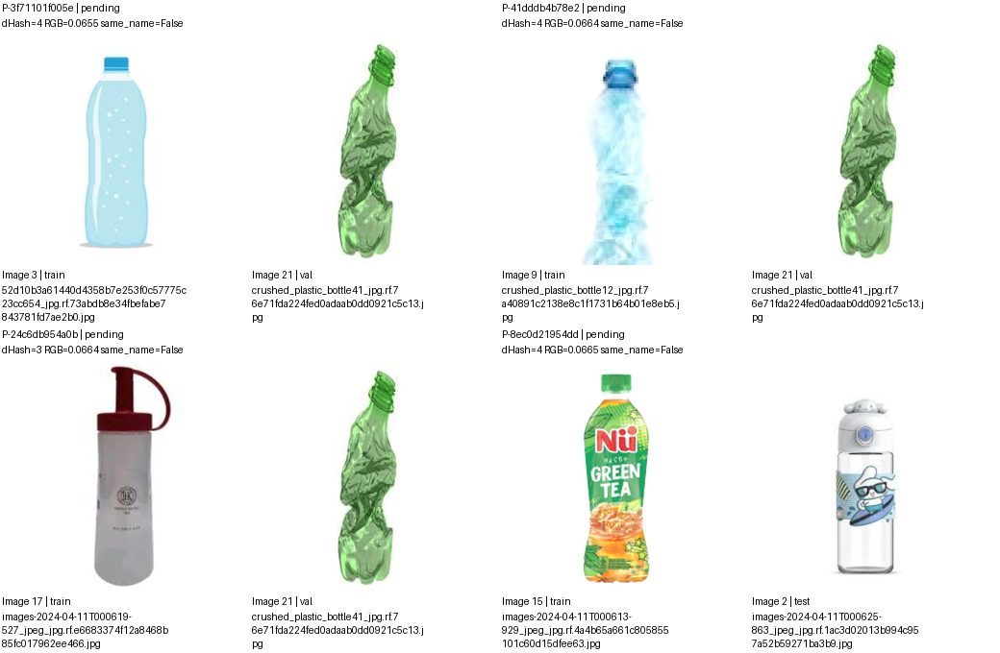

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-3f71101f005e,images/train/52d10b3a61440d4358b7e253f0c57775c23cc654_jpg.rf.73abdb8e34fbefabe7843781fd7ae2b0.jpg,images/val/crushed_plastic_bottle41_jpg.rf.76e71fda224fed0adaab0dd0921c5c13.jpg,pending,
P-41dddb4b78e2,images/train/crushed_plastic_bottle12_jpg.rf.7a40891c2138e8c1f1731b64b01e8eb5.jpg,images/val/crushed_plastic_bottle41_jpg.rf.76e71fda224fed0adaab0dd0921c5c13.jpg,pending,
P-24c6db954a0b,images/train/images-2024-04-11T000619-527_jpeg_jpg.rf.e6683374f12a8468b85fc017962ee466.jpg,images/val/crushed_plastic_bottle41_jpg.rf.76e71fda224fed0adaab0dd0921c5c13.jpg,pending,
P-8ec0d21954dd,images/train/images-2024-04-11T000613-929_jpeg_jpg.rf.4a4b65a661c805855101c60d15dfee63.jpg,images/test/images-2024-04-11T000625-863_jpeg_jpg.rf.1ac3d02013b994c957a52b59271ba3b9.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 55/166 G-982e454aca22 | 21 ảnh, 56 cặp
Split: {'test': 2, 'train': 15, 'val': 4}
Quyết định: {'pending': 56}
Ảnh trang None/4; cặp trang 12/14. Nhóm liên thông không phải kết luận trùng.


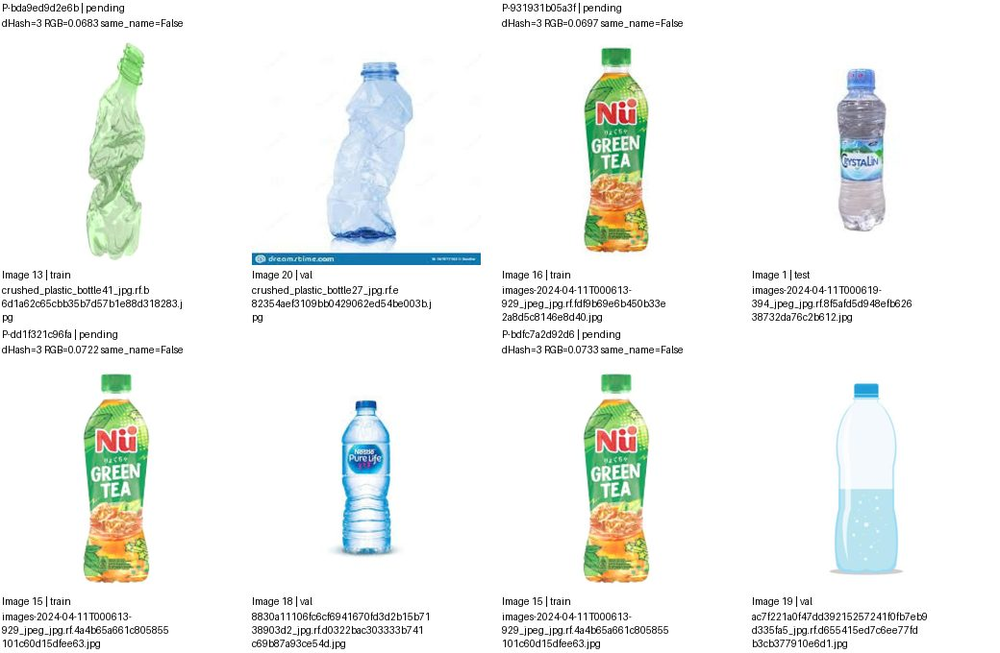

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-bda9ed9d2e6b,images/train/crushed_plastic_bottle41_jpg.rf.b6d1a62c65cbb35b7d57b1e88d318283.jpg,images/val/crushed_plastic_bottle27_jpg.rf.e82354aef3109bb0429062ed54be003b.jpg,pending,
P-931931b05a3f,images/train/images-2024-04-11T000613-929_jpeg_jpg.rf.fdf9b69e6b450b33e2a8d5c8146e8d40.jpg,images/test/images-2024-04-11T000619-394_jpeg_jpg.rf.8f5afd5d948efb62638732da76c2b612.jpg,pending,
P-dd1f321c96fa,images/train/images-2024-04-11T000613-929_jpeg_jpg.rf.4a4b65a661c805855101c60d15dfee63.jpg,images/val/8830a11106fc6cf6941670fd3d2b15b7138903d2_jpg.rf.d0322bac303333b741c69b87a93ce54d.jpg,pending,
P-bdfc7a2d92d6,images/train/images-2024-04-11T000613-929_jpeg_jpg.rf.4a4b65a661c805855101c60d15dfee63.jpg,images/val/ac7f221a0f47dd39215257241f0fb7eb9d335fa5_jpg.rf.d655415ed7c6ee77fdb3cb377910e6d1.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 55/166 G-982e454aca22 | 21 ảnh, 56 cặp
Split: {'test': 2, 'train': 15, 'val': 4}
Quyết định: {'pending': 56}
Ảnh trang None/4; cặp trang 13/14. Nhóm liên thông không phải kết luận trùng.


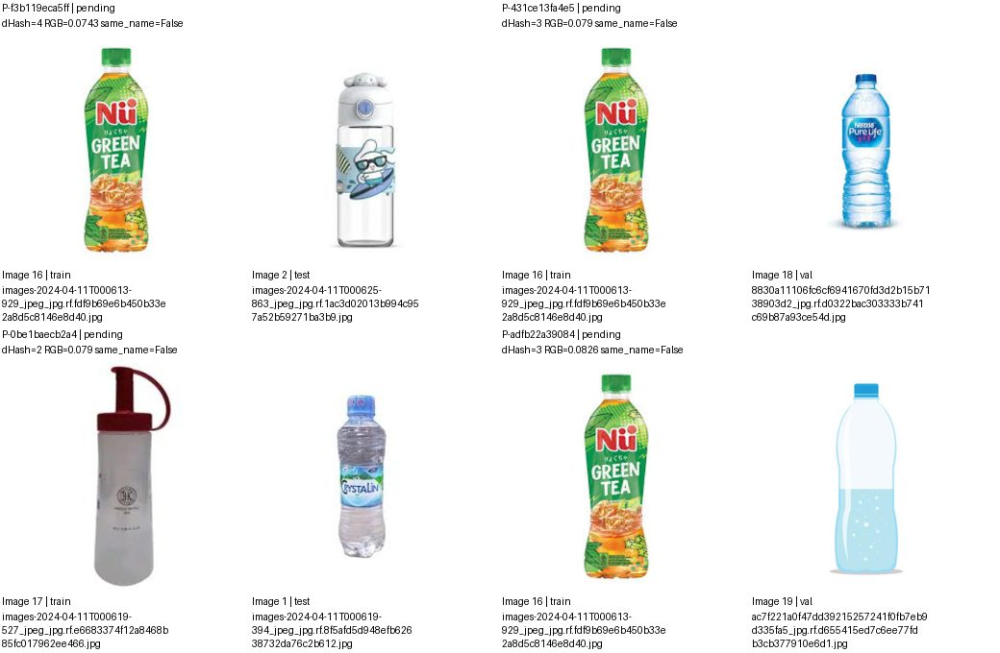

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-f3b119eca5ff,images/train/images-2024-04-11T000613-929_jpeg_jpg.rf.fdf9b69e6b450b33e2a8d5c8146e8d40.jpg,images/test/images-2024-04-11T000625-863_jpeg_jpg.rf.1ac3d02013b994c957a52b59271ba3b9.jpg,pending,
P-431ce13fa4e5,images/train/images-2024-04-11T000613-929_jpeg_jpg.rf.fdf9b69e6b450b33e2a8d5c8146e8d40.jpg,images/val/8830a11106fc6cf6941670fd3d2b15b7138903d2_jpg.rf.d0322bac303333b741c69b87a93ce54d.jpg,pending,
P-0be1baecb2a4,images/train/images-2024-04-11T000619-527_jpeg_jpg.rf.e6683374f12a8468b85fc017962ee466.jpg,images/test/images-2024-04-11T000619-394_jpeg_jpg.rf.8f5afd5d948efb62638732da76c2b612.jpg,pending,
P-adfb22a39084,images/train/images-2024-04-11T000613-929_jpeg_jpg.rf.fdf9b69e6b450b33e2a8d5c8146e8d40.jpg,images/val/ac7f221a0f47dd39215257241f0fb7eb9d335fa5_jpg.rf.d655415ed7c6ee77fdb3cb377910e6d1.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 55/166 G-982e454aca22 | 21 ảnh, 56 cặp
Split: {'test': 2, 'train': 15, 'val': 4}
Quyết định: {'pending': 56}
Ảnh trang None/4; cặp trang 14/14. Nhóm liên thông không phải kết luận trùng.


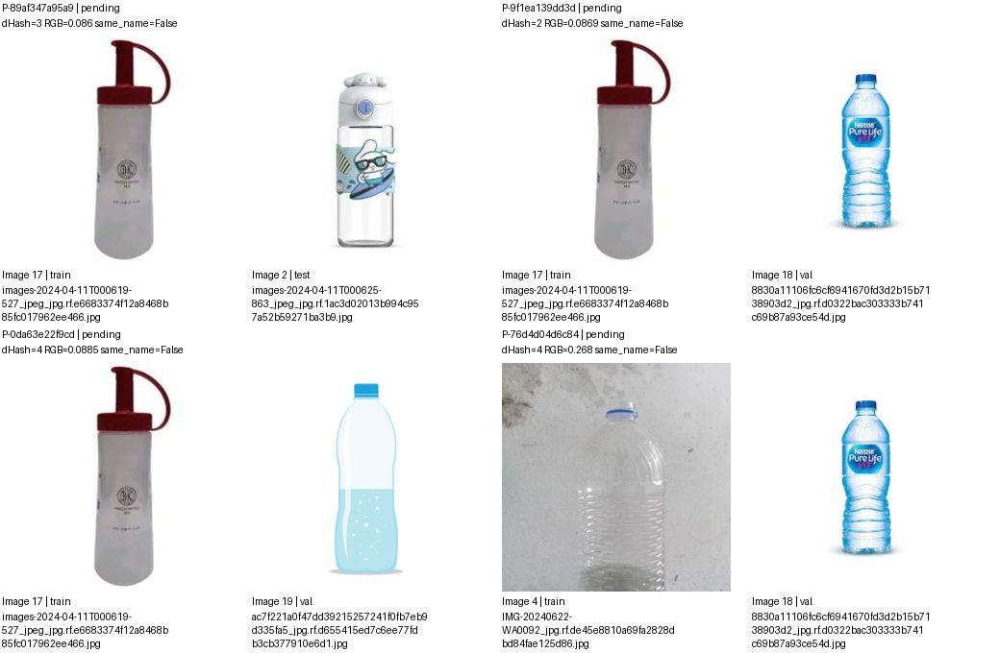

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-89af347a95a9,images/train/images-2024-04-11T000619-527_jpeg_jpg.rf.e6683374f12a8468b85fc017962ee466.jpg,images/test/images-2024-04-11T000625-863_jpeg_jpg.rf.1ac3d02013b994c957a52b59271ba3b9.jpg,pending,
P-9f1ea139dd3d,images/train/images-2024-04-11T000619-527_jpeg_jpg.rf.e6683374f12a8468b85fc017962ee466.jpg,images/val/8830a11106fc6cf6941670fd3d2b15b7138903d2_jpg.rf.d0322bac303333b741c69b87a93ce54d.jpg,pending,
P-0da63e22f9cd,images/train/images-2024-04-11T000619-527_jpeg_jpg.rf.e6683374f12a8468b85fc017962ee466.jpg,images/val/ac7f221a0f47dd39215257241f0fb7eb9d335fa5_jpg.rf.d655415ed7c6ee77fdb3cb377910e6d1.jpg,pending,
P-76d4d04d6c84,images/train/IMG-20240622-WA0092_jpg.rf.de45e8810a69fa2828dbd84fae125d86.jpg,images/val/8830a11106fc6cf6941670fd3d2b15b7138903d2_jpg.rf.d0322bac303333b741c69b87a93ce54d.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 56/166 G-d6ec60961958 | 6 ảnh, 5 cặp
Split: {'test': 1, 'train': 5}
Quyết định: {'pending': 5}
Ảnh trang 1/1; cặp trang 1/2. Nhóm liên thông không phải kết luận trùng.


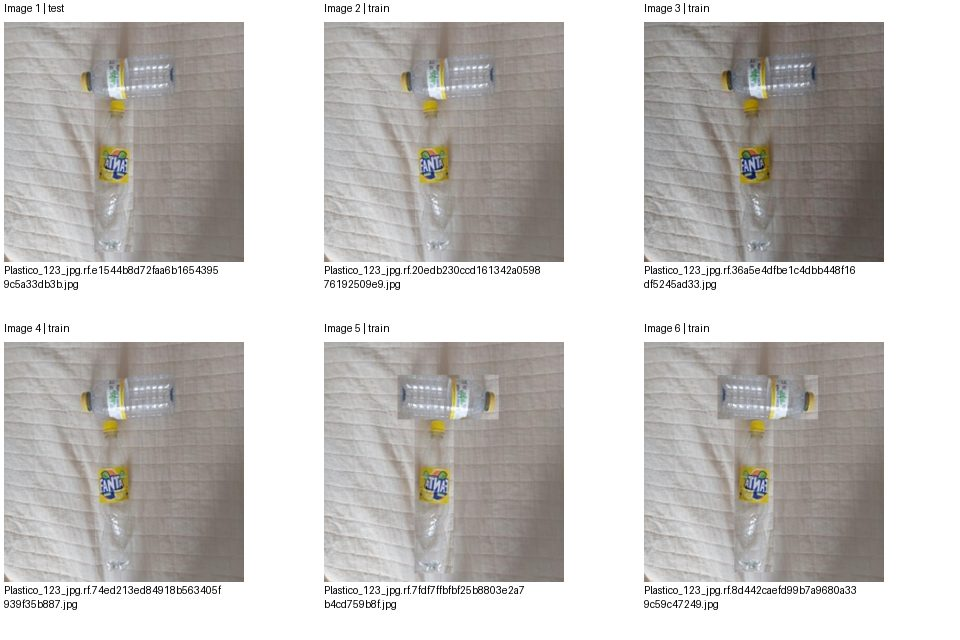

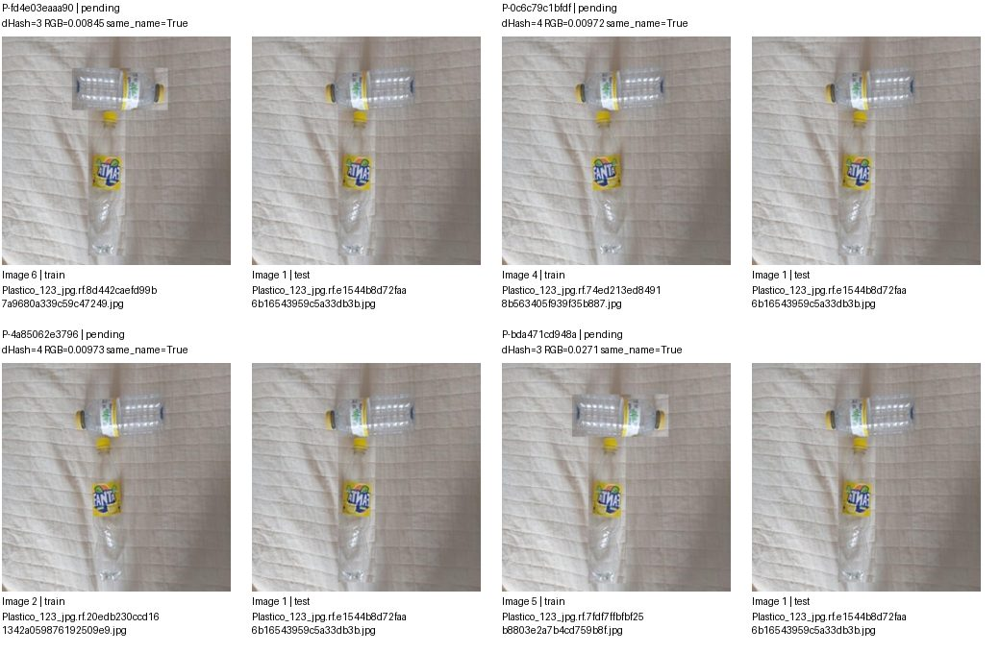

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-fd4e03eaaa90,images/train/Plastico_123_jpg.rf.8d442caefd99b7a9680a339c59c47249.jpg,images/test/Plastico_123_jpg.rf.e1544b8d72faa6b16543959c5a33db3b.jpg,pending,
P-0c6c79c1bfdf,images/train/Plastico_123_jpg.rf.74ed213ed84918b563405f939f35b887.jpg,images/test/Plastico_123_jpg.rf.e1544b8d72faa6b16543959c5a33db3b.jpg,pending,
P-4a85062e3796,images/train/Plastico_123_jpg.rf.20edb230ccd161342a059876192509e9.jpg,images/test/Plastico_123_jpg.rf.e1544b8d72faa6b16543959c5a33db3b.jpg,pending,
P-bda471cd948a,images/train/Plastico_123_jpg.rf.7fdf7ffbfbf25b8803e2a7b4cd759b8f.jpg,images/test/Plastico_123_jpg.rf.e1544b8d72faa6b16543959c5a33db3b.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 56/166 G-d6ec60961958 | 6 ảnh, 5 cặp
Split: {'test': 1, 'train': 5}
Quyết định: {'pending': 5}
Ảnh trang None/1; cặp trang 2/2. Nhóm liên thông không phải kết luận trùng.


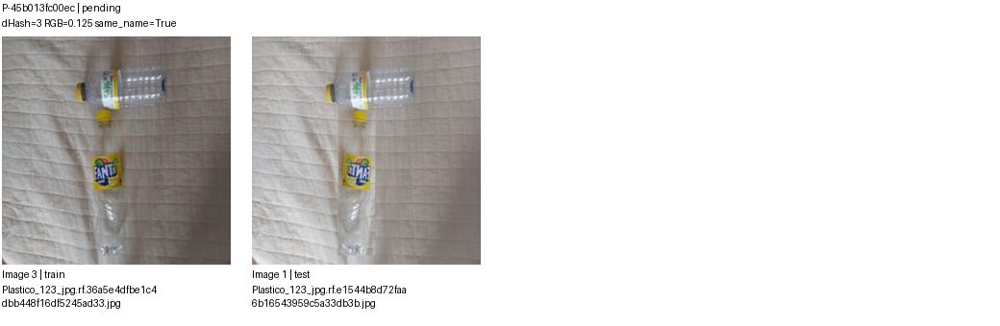

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-45b013fc00ec,images/train/Plastico_123_jpg.rf.36a5e4dfbe1c4dbb448f16df5245ad33.jpg,images/test/Plastico_123_jpg.rf.e1544b8d72faa6b16543959c5a33db3b.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 57/166 G-c2efaeb0e9ce | 3 ảnh, 2 cặp
Split: {'train': 2, 'val': 1}
Quyết định: {'pending': 2}
Ảnh trang 1/1; cặp trang 1/1. Nhóm liên thông không phải kết luận trùng.


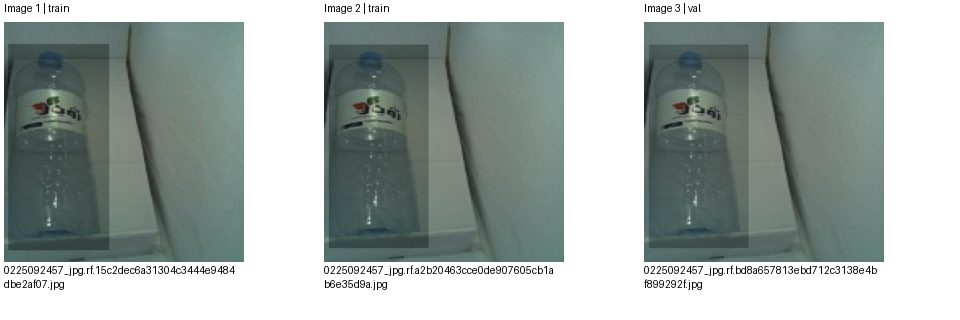

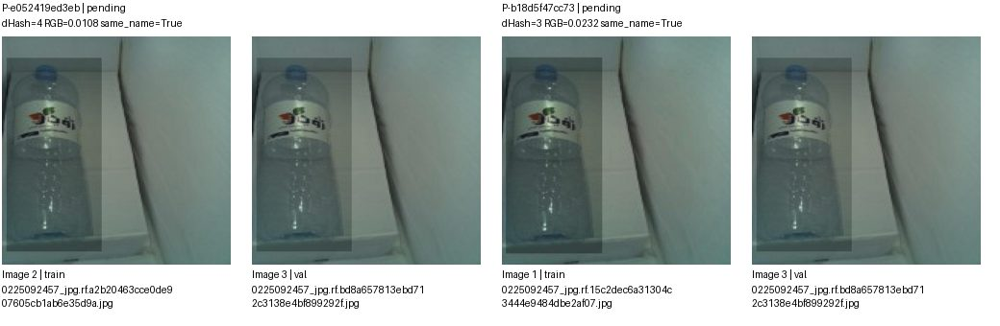

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-e052419ed3eb,images/train/0225092457_jpg.rf.a2b20463cce0de907605cb1ab6e35d9a.jpg,images/val/0225092457_jpg.rf.bd8a657813ebd712c3138e4bf899292f.jpg,pending,
P-b18d5f47cc73,images/train/0225092457_jpg.rf.15c2dec6a31304c3444e9484dbe2af07.jpg,images/val/0225092457_jpg.rf.bd8a657813ebd712c3138e4bf899292f.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 58/166 G-36440b6d17e2 | 5 ảnh, 6 cặp
Split: {'test': 1, 'train': 3, 'val': 1}
Quyết định: {'pending': 6}
Ảnh trang 1/1; cặp trang 1/2. Nhóm liên thông không phải kết luận trùng.


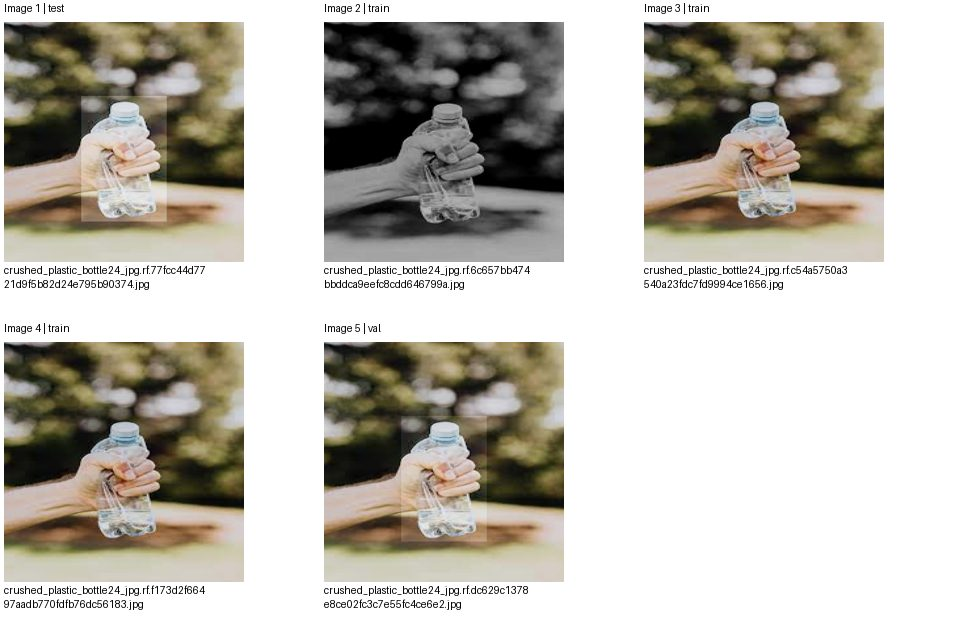

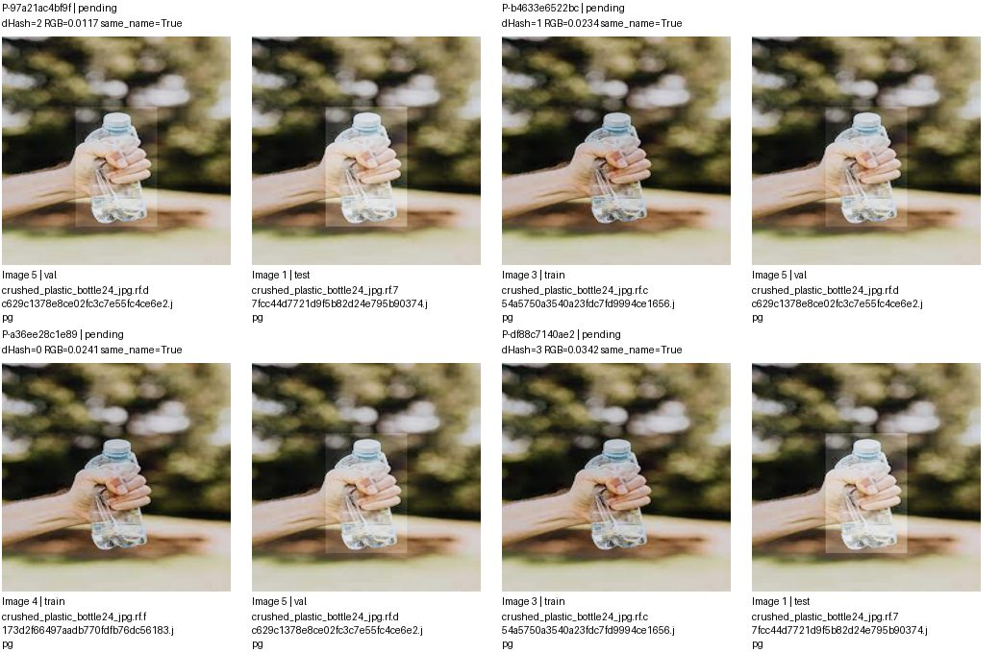

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-97a21ac4bf9f,images/val/crushed_plastic_bottle24_jpg.rf.dc629c1378e8ce02fc3c7e55fc4ce6e2.jpg,images/test/crushed_plastic_bottle24_jpg.rf.77fcc44d7721d9f5b82d24e795b90374.jpg,pending,
P-b4633e6522bc,images/train/crushed_plastic_bottle24_jpg.rf.c54a5750a3540a23fdc7fd9994ce1656.jpg,images/val/crushed_plastic_bottle24_jpg.rf.dc629c1378e8ce02fc3c7e55fc4ce6e2.jpg,pending,
P-a36ee28c1e89,images/train/crushed_plastic_bottle24_jpg.rf.f173d2f66497aadb770fdfb76dc56183.jpg,images/val/crushed_plastic_bottle24_jpg.rf.dc629c1378e8ce02fc3c7e55fc4ce6e2.jpg,pending,
P-df88c7140ae2,images/train/crushed_plastic_bottle24_jpg.rf.c54a5750a3540a23fdc7fd9994ce1656.jpg,images/test/crushed_plastic_bottle24_jpg.rf.77fcc44d7721d9f5b82d24e795b90374.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 58/166 G-36440b6d17e2 | 5 ảnh, 6 cặp
Split: {'test': 1, 'train': 3, 'val': 1}
Quyết định: {'pending': 6}
Ảnh trang None/1; cặp trang 2/2. Nhóm liên thông không phải kết luận trùng.


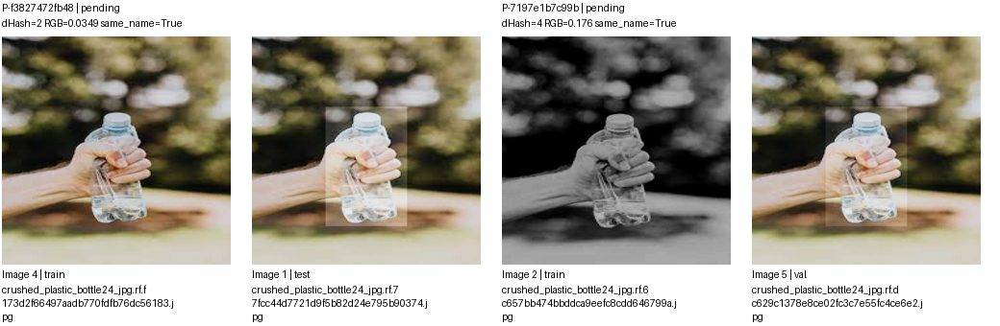

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-f3827472fb48,images/train/crushed_plastic_bottle24_jpg.rf.f173d2f66497aadb770fdfb76dc56183.jpg,images/test/crushed_plastic_bottle24_jpg.rf.77fcc44d7721d9f5b82d24e795b90374.jpg,pending,
P-7197e1b7c99b,images/train/crushed_plastic_bottle24_jpg.rf.6c657bb474bbddca9eefc8cdd646799a.jpg,images/val/crushed_plastic_bottle24_jpg.rf.dc629c1378e8ce02fc3c7e55fc4ce6e2.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 59/166 G-485c6cc34b2f | 4 ảnh, 3 cặp
Split: {'train': 3, 'val': 1}
Quyết định: {'pending': 3}
Ảnh trang 1/1; cặp trang 1/1. Nhóm liên thông không phải kết luận trùng.


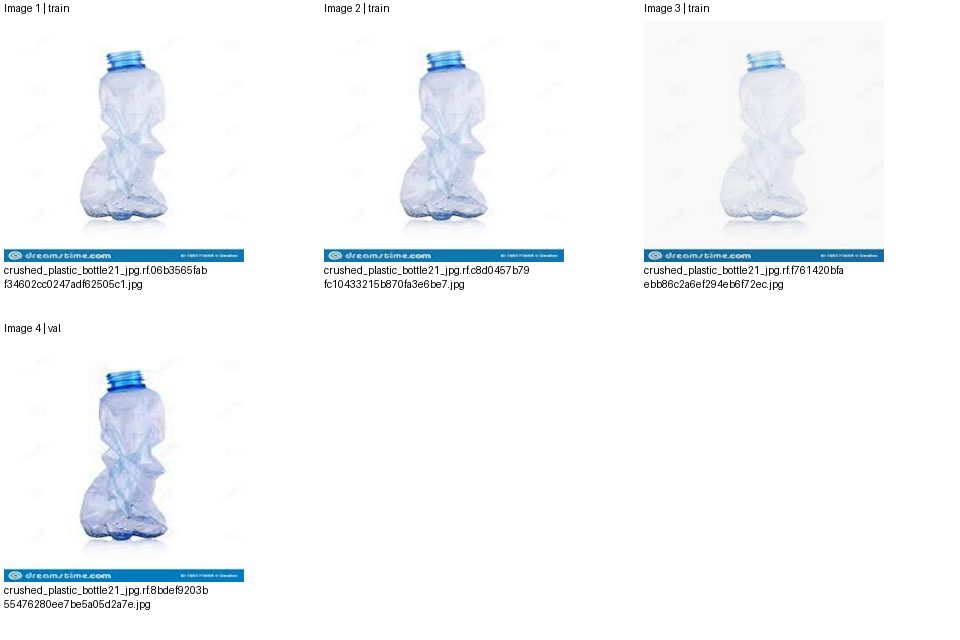

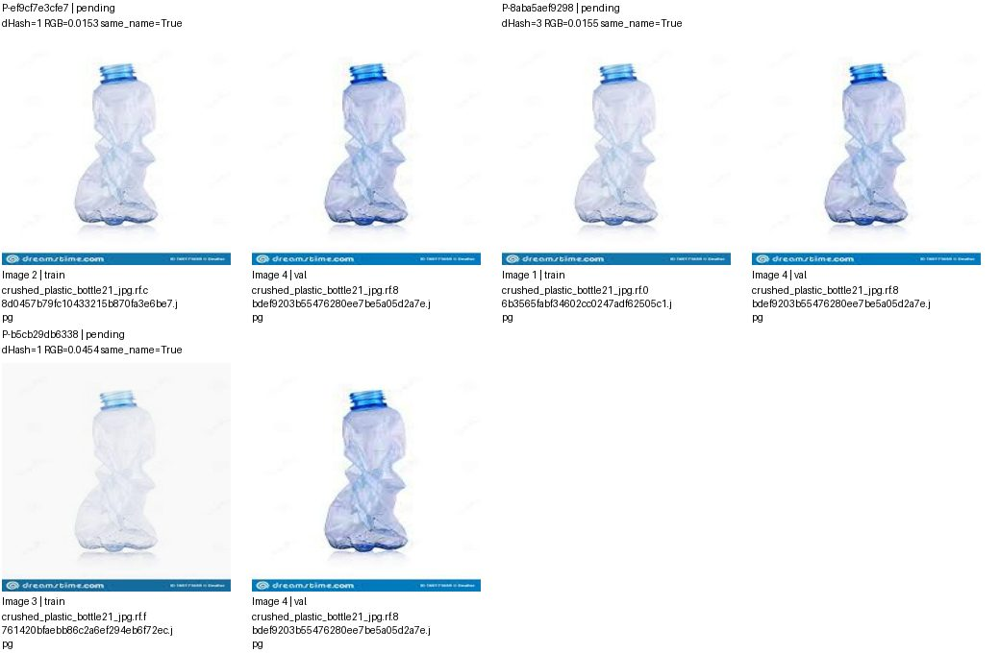

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-ef9cf7e3cfe7,images/train/crushed_plastic_bottle21_jpg.rf.c8d0457b79fc10433215b870fa3e6be7.jpg,images/val/crushed_plastic_bottle21_jpg.rf.8bdef9203b55476280ee7be5a05d2a7e.jpg,pending,
P-8aba5aef9298,images/train/crushed_plastic_bottle21_jpg.rf.06b3565fabf34602cc0247adf62505c1.jpg,images/val/crushed_plastic_bottle21_jpg.rf.8bdef9203b55476280ee7be5a05d2a7e.jpg,pending,
P-b5cb29db6338,images/train/crushed_plastic_bottle21_jpg.rf.f761420bfaebb86c2a6ef294eb6f72ec.jpg,images/val/crushed_plastic_bottle21_jpg.rf.8bdef9203b55476280ee7be5a05d2a7e.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 60/166 G-02b5e0666b2d | 4 ảnh, 3 cặp
Split: {'train': 3, 'val': 1}
Quyết định: {'pending': 3}
Ảnh trang 1/1; cặp trang 1/1. Nhóm liên thông không phải kết luận trùng.


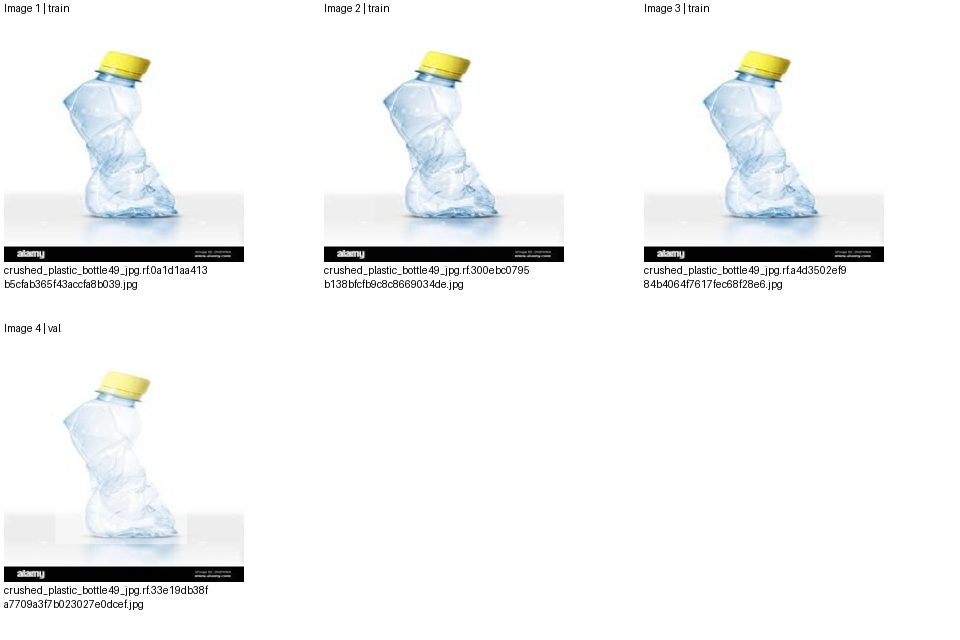

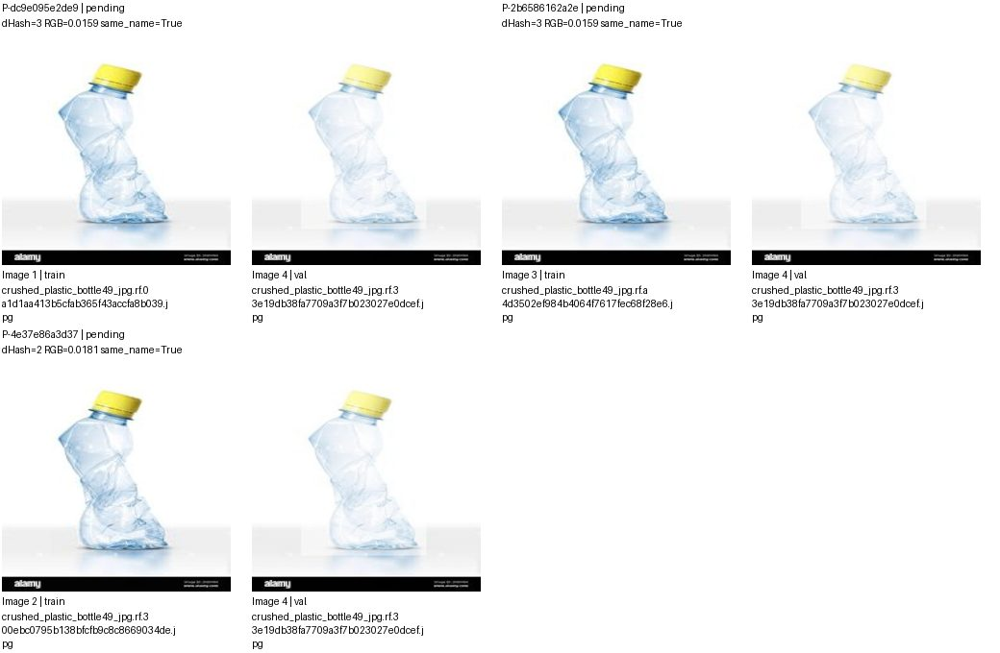

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-dc9e095e2de9,images/train/crushed_plastic_bottle49_jpg.rf.0a1d1aa413b5cfab365f43accfa8b039.jpg,images/val/crushed_plastic_bottle49_jpg.rf.33e19db38fa7709a3f7b023027e0dcef.jpg,pending,
P-2b6586162a2e,images/train/crushed_plastic_bottle49_jpg.rf.a4d3502ef984b4064f7617fec68f28e6.jpg,images/val/crushed_plastic_bottle49_jpg.rf.33e19db38fa7709a3f7b023027e0dcef.jpg,pending,
P-4e37e86a3d37,images/train/crushed_plastic_bottle49_jpg.rf.300ebc0795b138bfcfb9c8c8669034de.jpg,images/val/crushed_plastic_bottle49_jpg.rf.33e19db38fa7709a3f7b023027e0dcef.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 61/166 G-433eaa4cfebf | 2 ảnh, 1 cặp
Split: {'train': 1, 'val': 1}
Quyết định: {'pending': 1}
Ảnh trang 1/1; cặp trang 1/1. Nhóm liên thông không phải kết luận trùng.


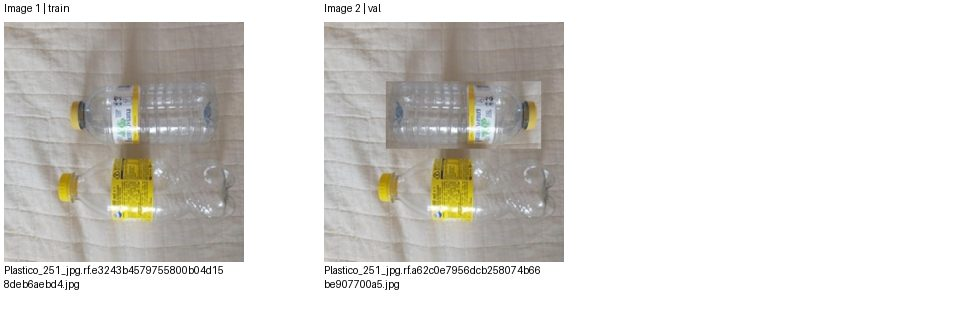

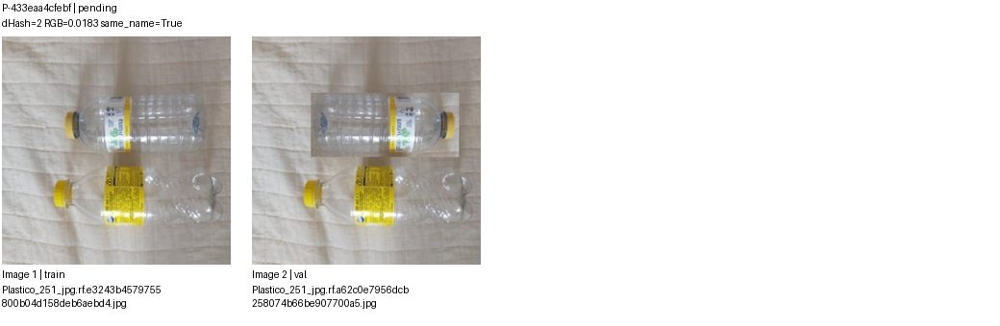

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-433eaa4cfebf,images/train/Plastico_251_jpg.rf.e3243b4579755800b04d158deb6aebd4.jpg,images/val/Plastico_251_jpg.rf.a62c0e7956dcb258074b66be907700a5.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 62/166 G-3d797b8626b2 | 4 ảnh, 3 cặp
Split: {'train': 3, 'val': 1}
Quyết định: {'pending': 3}
Ảnh trang 1/1; cặp trang 1/1. Nhóm liên thông không phải kết luận trùng.


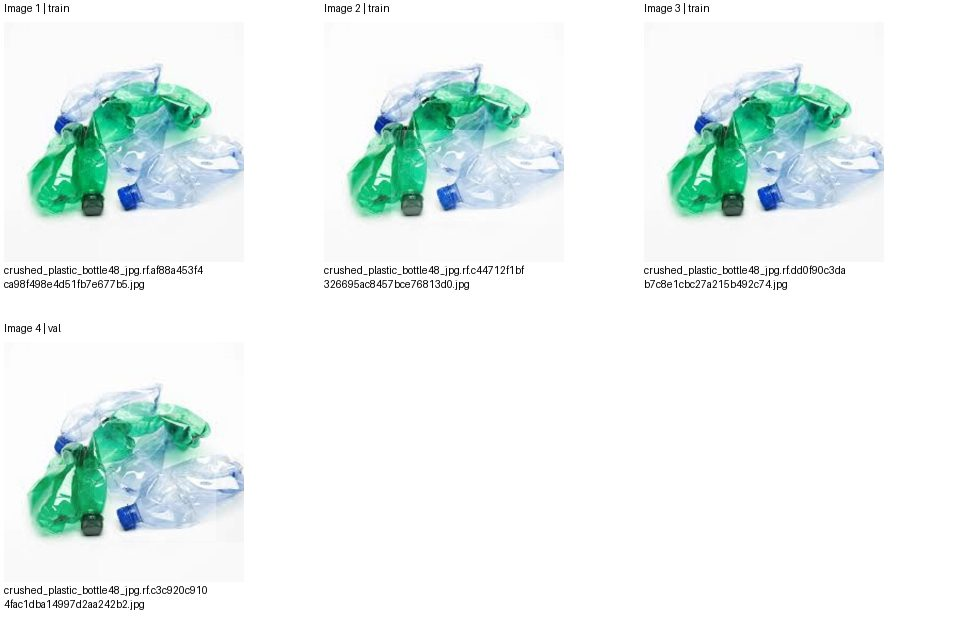

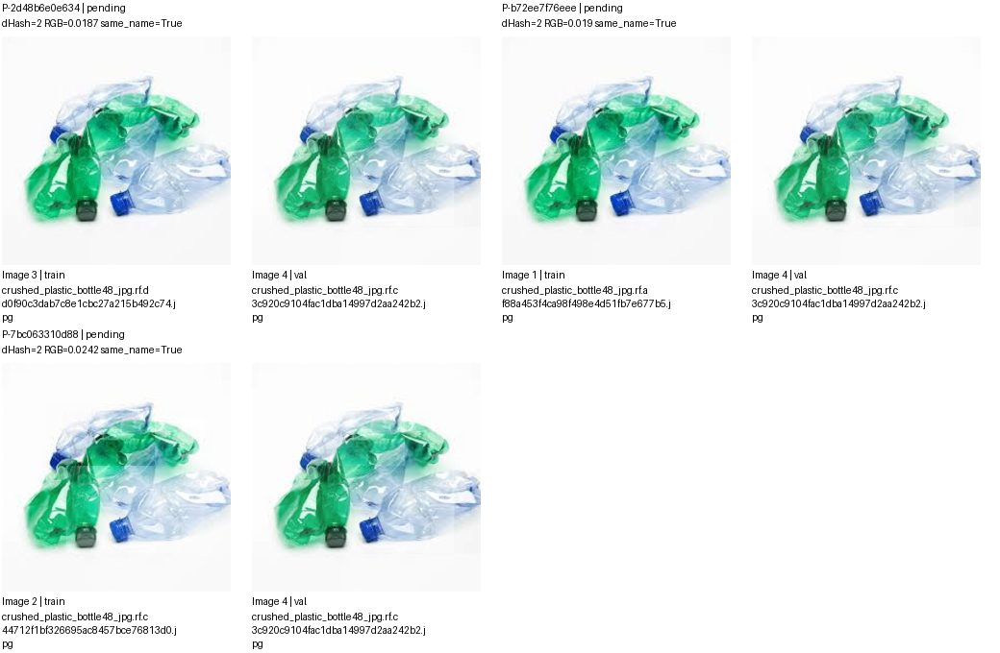

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-2d48b6e0e634,images/train/crushed_plastic_bottle48_jpg.rf.dd0f90c3dab7c8e1cbc27a215b492c74.jpg,images/val/crushed_plastic_bottle48_jpg.rf.c3c920c9104fac1dba14997d2aa242b2.jpg,pending,
P-b72ee7f76eee,images/train/crushed_plastic_bottle48_jpg.rf.af88a453f4ca98f498e4d51fb7e677b5.jpg,images/val/crushed_plastic_bottle48_jpg.rf.c3c920c9104fac1dba14997d2aa242b2.jpg,pending,
P-7bc063310d88,images/train/crushed_plastic_bottle48_jpg.rf.c44712f1bf326695ac8457bce76813d0.jpg,images/val/crushed_plastic_bottle48_jpg.rf.c3c920c9104fac1dba14997d2aa242b2.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 63/166 G-7812d390fe16 | 5 ảnh, 4 cặp
Split: {'train': 4, 'val': 1}
Quyết định: {'pending': 4}
Ảnh trang 1/1; cặp trang 1/1. Nhóm liên thông không phải kết luận trùng.


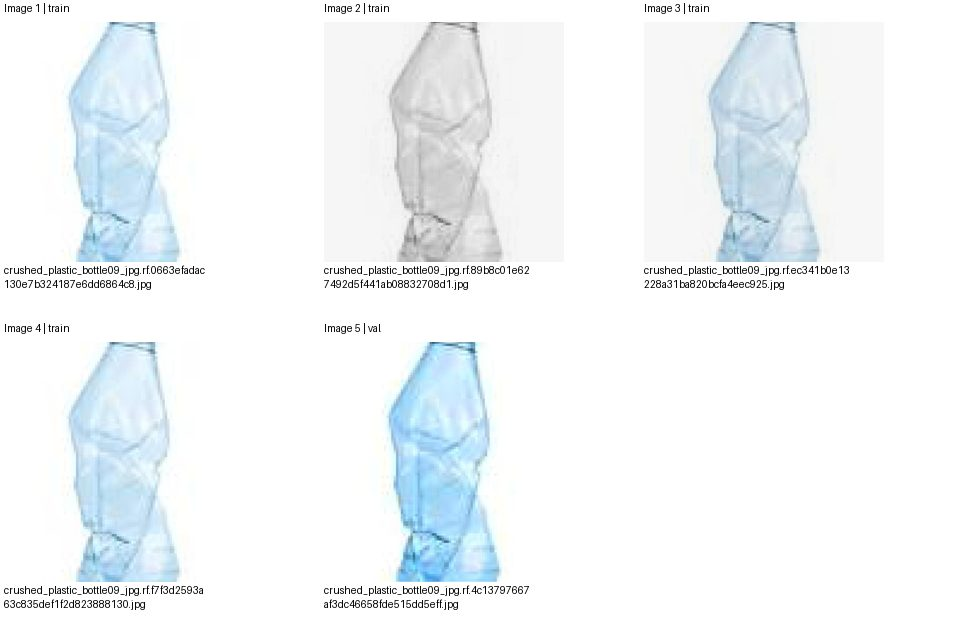

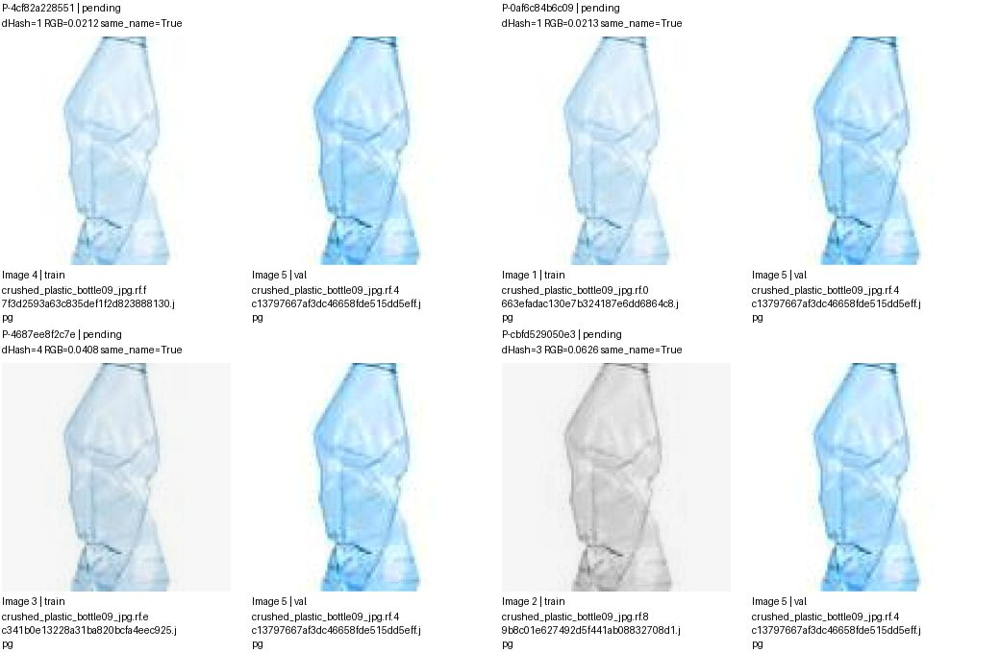

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-4cf82a228551,images/train/crushed_plastic_bottle09_jpg.rf.f7f3d2593a63c835def1f2d823888130.jpg,images/val/crushed_plastic_bottle09_jpg.rf.4c13797667af3dc46658fde515dd5eff.jpg,pending,
P-0af6c84b6c09,images/train/crushed_plastic_bottle09_jpg.rf.0663efadac130e7b324187e6dd6864c8.jpg,images/val/crushed_plastic_bottle09_jpg.rf.4c13797667af3dc46658fde515dd5eff.jpg,pending,
P-4687ee8f2c7e,images/train/crushed_plastic_bottle09_jpg.rf.ec341b0e13228a31ba820bcfa4eec925.jpg,images/val/crushed_plastic_bottle09_jpg.rf.4c13797667af3dc46658fde515dd5eff.jpg,pending,
P-cbfd529050e3,images/train/crushed_plastic_bottle09_jpg.rf.89b8c01e627492d5f441ab08832708d1.jpg,images/val/crushed_plastic_bottle09_jpg.rf.4c13797667af3dc46658fde515dd5eff.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 64/166 G-b5aa94d12afa | 4 ảnh, 4 cặp
Split: {'test': 2, 'train': 2}
Quyết định: {'pending': 4}
Ảnh trang 1/1; cặp trang 1/1. Nhóm liên thông không phải kết luận trùng.


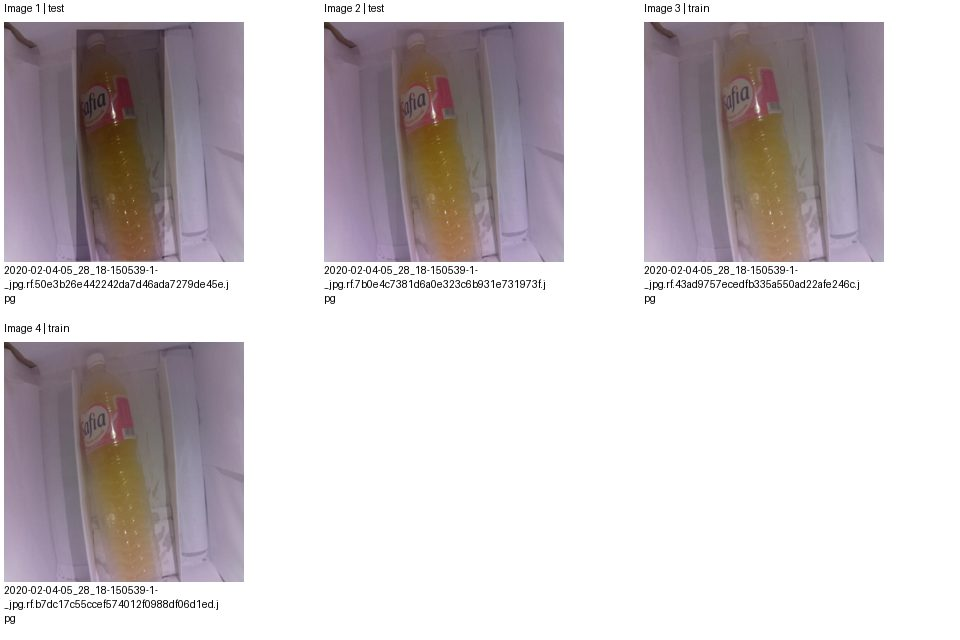

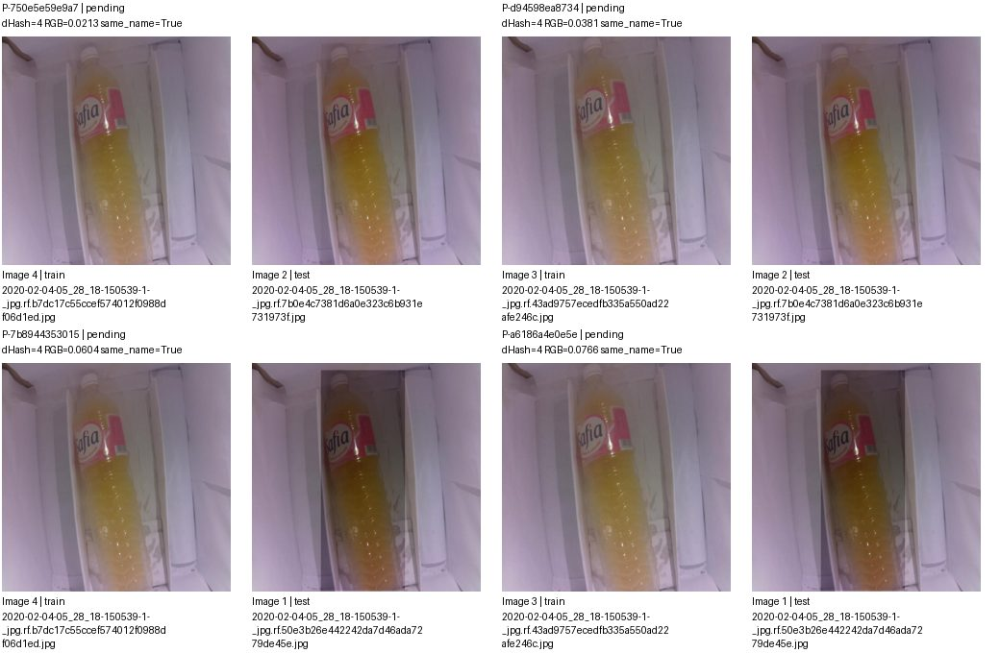

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-750e5e59e9a7,images/train/2020-02-04-05_28_18-150539-1-_jpg.rf.b7dc17c55ccef574012f0988df06d1ed.jpg,images/test/2020-02-04-05_28_18-150539-1-_jpg.rf.7b0e4c7381d6a0e323c6b931e731973f.jpg,pending,
P-d94598ea8734,images/train/2020-02-04-05_28_18-150539-1-_jpg.rf.43ad9757ecedfb335a550ad22afe246c.jpg,images/test/2020-02-04-05_28_18-150539-1-_jpg.rf.7b0e4c7381d6a0e323c6b931e731973f.jpg,pending,
P-7b8944353015,images/train/2020-02-04-05_28_18-150539-1-_jpg.rf.b7dc17c55ccef574012f0988df06d1ed.jpg,images/test/2020-02-04-05_28_18-150539-1-_jpg.rf.50e3b26e442242da7d46ada7279de45e.jpg,pending,
P-a6186a4e0e5e,images/train/2020-02-04-05_28_18-150539-1-_jpg.rf.43ad9757ecedfb335a550ad22afe246c.jpg,images/test/2020-02-04-05_28_18-150539-1-_jpg.rf.50e3b26e442242da7d46ada7279de45e.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 65/166 G-b9303d51a174 | 6 ảnh, 5 cặp
Split: {'train': 5, 'val': 1}
Quyết định: {'pending': 5}
Ảnh trang 1/1; cặp trang 1/2. Nhóm liên thông không phải kết luận trùng.


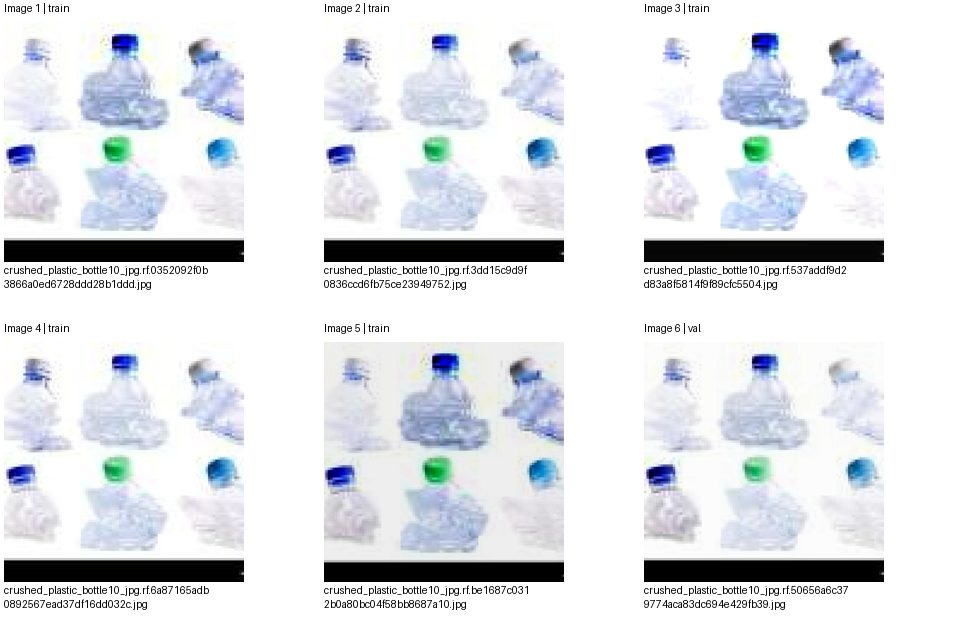

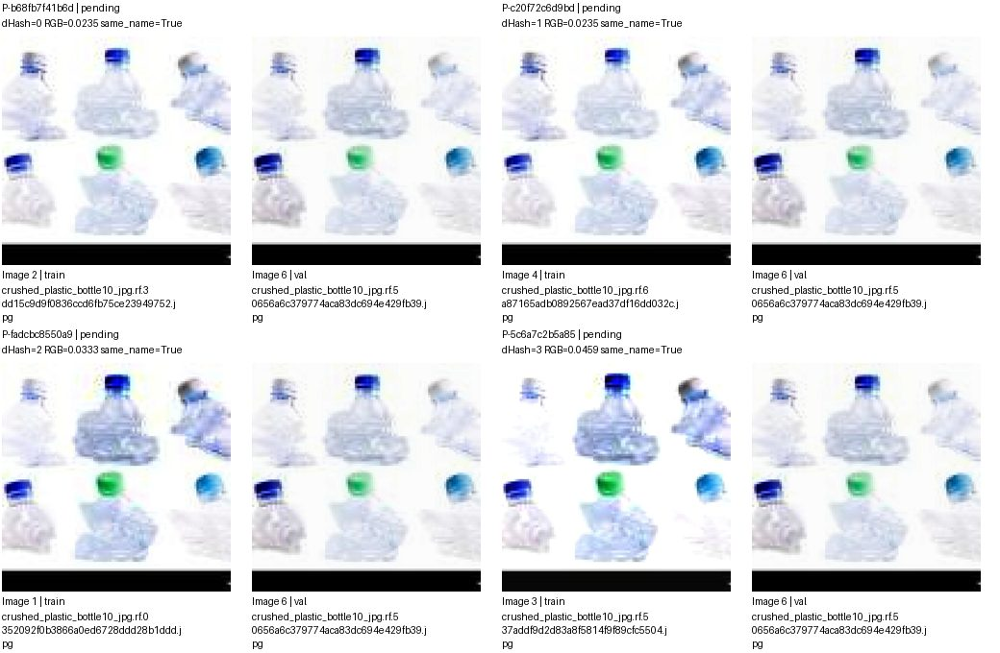

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-b68fb7f41b6d,images/train/crushed_plastic_bottle10_jpg.rf.3dd15c9d9f0836ccd6fb75ce23949752.jpg,images/val/crushed_plastic_bottle10_jpg.rf.50656a6c379774aca83dc694e429fb39.jpg,pending,
P-c20f72c6d9bd,images/train/crushed_plastic_bottle10_jpg.rf.6a87165adb0892567ead37df16dd032c.jpg,images/val/crushed_plastic_bottle10_jpg.rf.50656a6c379774aca83dc694e429fb39.jpg,pending,
P-fadcbc8550a9,images/train/crushed_plastic_bottle10_jpg.rf.0352092f0b3866a0ed6728ddd28b1ddd.jpg,images/val/crushed_plastic_bottle10_jpg.rf.50656a6c379774aca83dc694e429fb39.jpg,pending,
P-5c6a7c2b5a85,images/train/crushed_plastic_bottle10_jpg.rf.537addf9d2d83a8f5814f9f89cfc5504.jpg,images/val/crushed_plastic_bottle10_jpg.rf.50656a6c379774aca83dc694e429fb39.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 65/166 G-b9303d51a174 | 6 ảnh, 5 cặp
Split: {'train': 5, 'val': 1}
Quyết định: {'pending': 5}
Ảnh trang None/1; cặp trang 2/2. Nhóm liên thông không phải kết luận trùng.


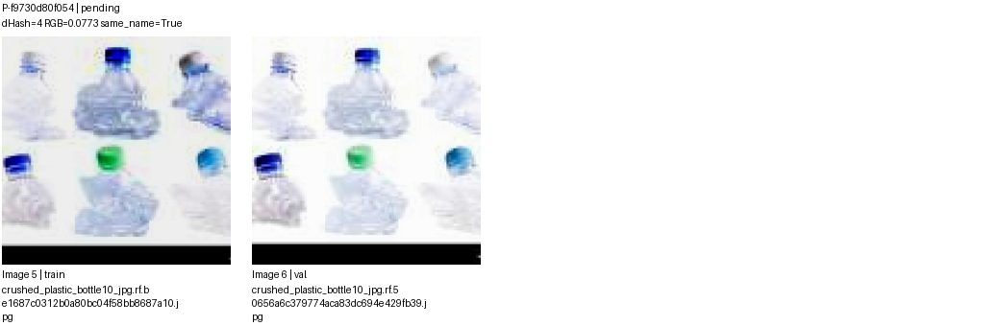

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-f9730d80f054,images/train/crushed_plastic_bottle10_jpg.rf.be1687c0312b0a80bc04f58bb8687a10.jpg,images/val/crushed_plastic_bottle10_jpg.rf.50656a6c379774aca83dc694e429fb39.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 66/166 G-e055653f1251 | 3 ảnh, 2 cặp
Split: {'train': 2, 'val': 1}
Quyết định: {'pending': 2}
Ảnh trang 1/1; cặp trang 1/1. Nhóm liên thông không phải kết luận trùng.


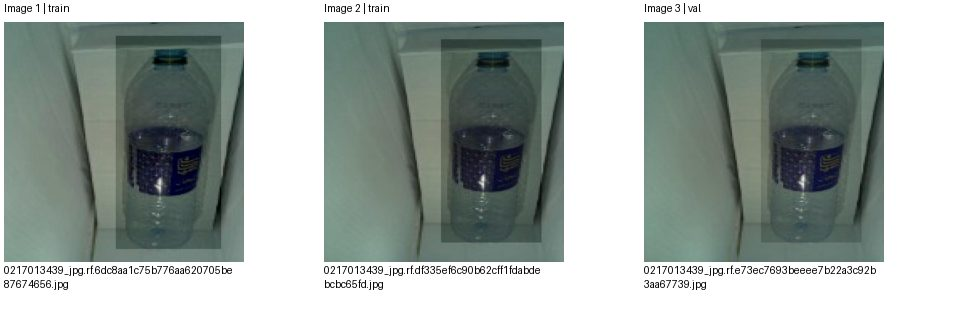

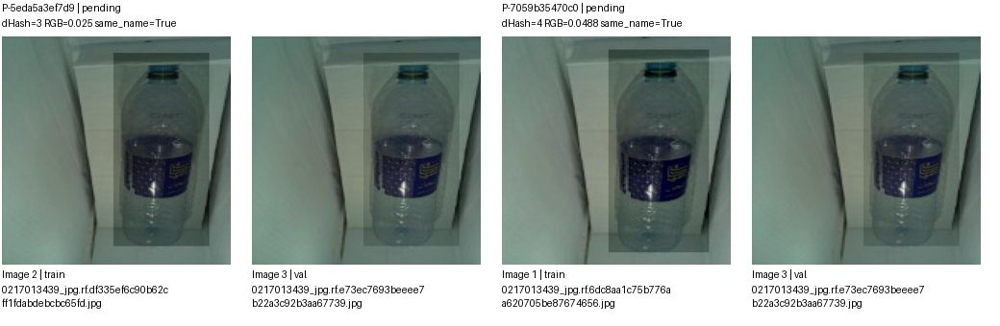

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-5eda5a3ef7d9,images/train/0217013439_jpg.rf.df335ef6c90b62cff1fdabdebcbc65fd.jpg,images/val/0217013439_jpg.rf.e73ec7693beeee7b22a3c92b3aa67739.jpg,pending,
P-7059b35470c0,images/train/0217013439_jpg.rf.6dc8aa1c75b776aa620705be87674656.jpg,images/val/0217013439_jpg.rf.e73ec7693beeee7b22a3c92b3aa67739.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 67/166 G-ddcdd34c1b10 | 3 ảnh, 2 cặp
Split: {'train': 2, 'val': 1}
Quyết định: {'pending': 2}
Ảnh trang 1/1; cặp trang 1/1. Nhóm liên thông không phải kết luận trùng.


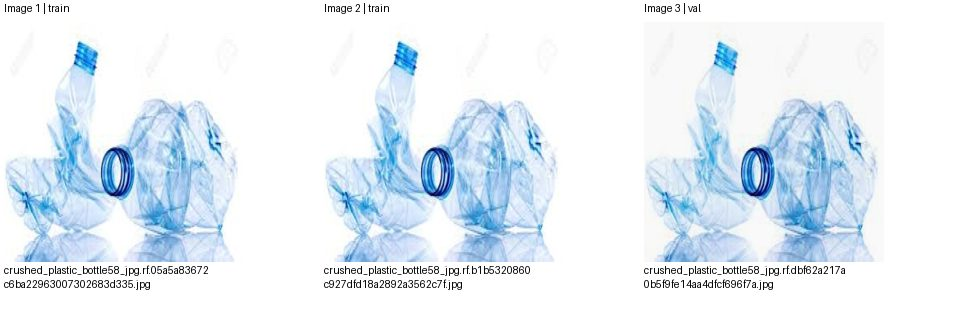

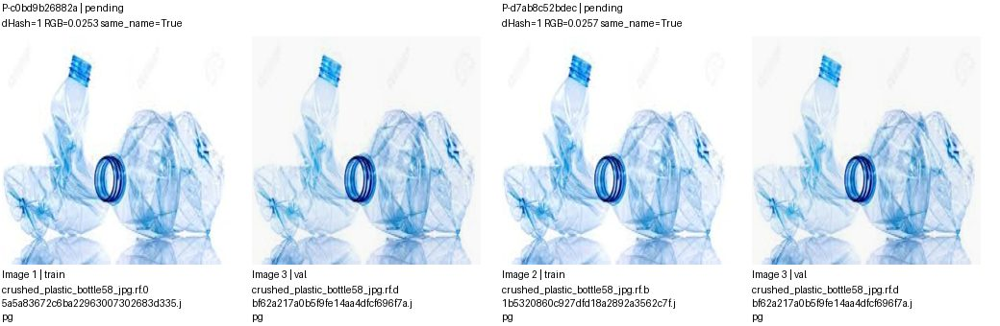

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-c0bd9b26882a,images/train/crushed_plastic_bottle58_jpg.rf.05a5a83672c6ba22963007302683d335.jpg,images/val/crushed_plastic_bottle58_jpg.rf.dbf62a217a0b5f9fe14aa4dfcf696f7a.jpg,pending,
P-d7ab8c52bdec,images/train/crushed_plastic_bottle58_jpg.rf.b1b5320860c927dfd18a2892a3562c7f.jpg,images/val/crushed_plastic_bottle58_jpg.rf.dbf62a217a0b5f9fe14aa4dfcf696f7a.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 68/166 G-eee449b57756 | 3 ảnh, 2 cặp
Split: {'train': 2, 'val': 1}
Quyết định: {'pending': 2}
Ảnh trang 1/1; cặp trang 1/1. Nhóm liên thông không phải kết luận trùng.


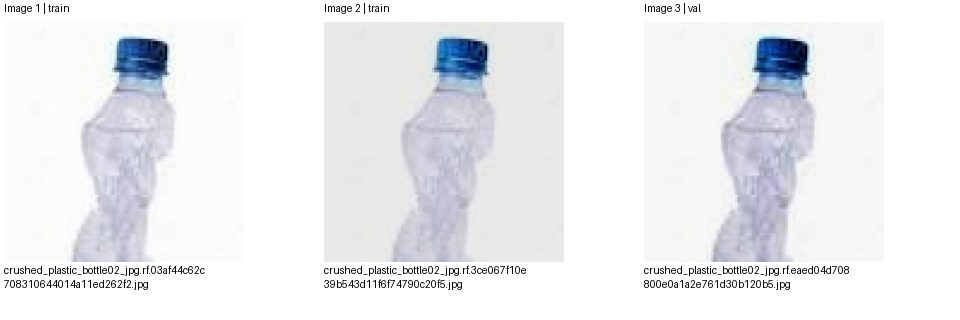

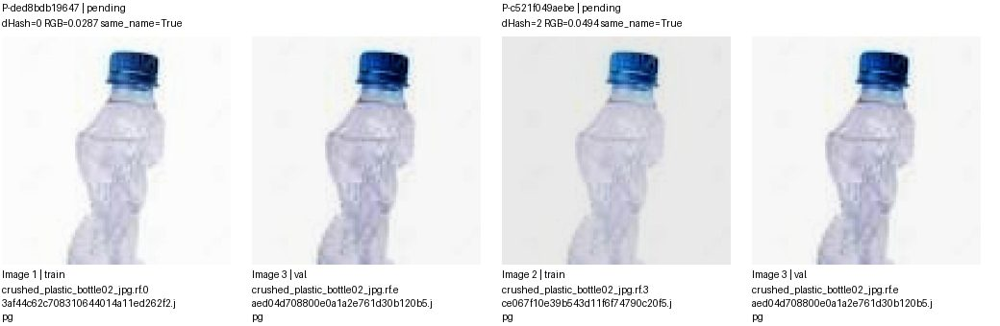

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-ded8bdb19647,images/train/crushed_plastic_bottle02_jpg.rf.03af44c62c708310644014a11ed262f2.jpg,images/val/crushed_plastic_bottle02_jpg.rf.eaed04d708800e0a1a2e761d30b120b5.jpg,pending,
P-c521f049aebe,images/train/crushed_plastic_bottle02_jpg.rf.3ce067f10e39b543d11f6f74790c20f5.jpg,images/val/crushed_plastic_bottle02_jpg.rf.eaed04d708800e0a1a2e761d30b120b5.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 69/166 G-7abae8dddae8 | 4 ảnh, 3 cặp
Split: {'test': 1, 'train': 3}
Quyết định: {'pending': 3}
Ảnh trang 1/1; cặp trang 1/1. Nhóm liên thông không phải kết luận trùng.


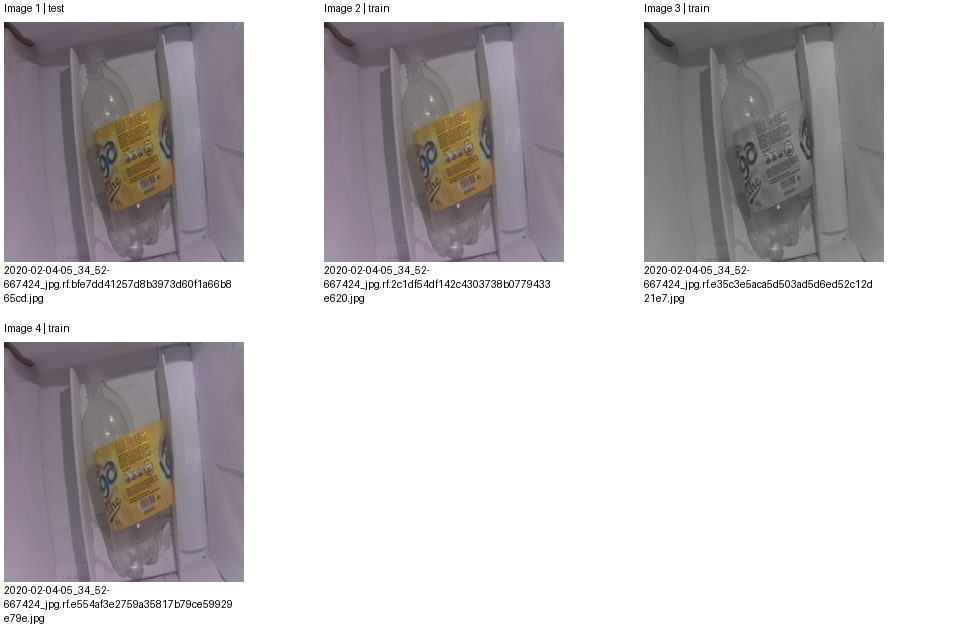

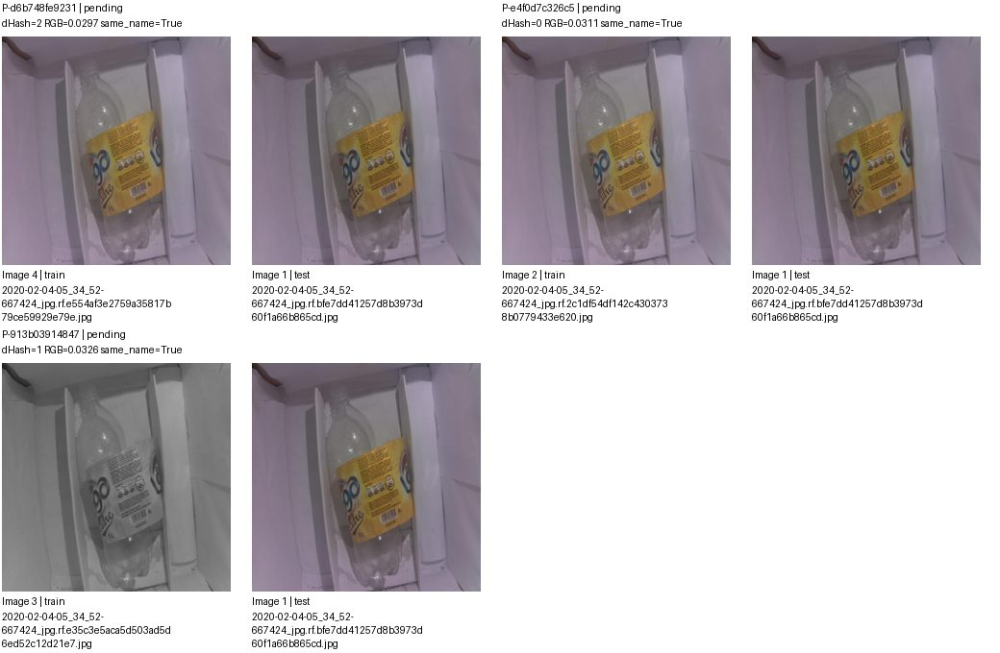

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-d6b748fe9231,images/train/2020-02-04-05_34_52-667424_jpg.rf.e554af3e2759a35817b79ce59929e79e.jpg,images/test/2020-02-04-05_34_52-667424_jpg.rf.bfe7dd41257d8b3973d60f1a66b865cd.jpg,pending,
P-e4f0d7c326c5,images/train/2020-02-04-05_34_52-667424_jpg.rf.2c1df54df142c4303738b0779433e620.jpg,images/test/2020-02-04-05_34_52-667424_jpg.rf.bfe7dd41257d8b3973d60f1a66b865cd.jpg,pending,
P-913b03914847,images/train/2020-02-04-05_34_52-667424_jpg.rf.e35c3e5aca5d503ad5d6ed52c12d21e7.jpg,images/test/2020-02-04-05_34_52-667424_jpg.rf.bfe7dd41257d8b3973d60f1a66b865cd.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 70/166 G-af4d0437e4c0 | 8 ảnh, 14 cặp
Split: {'test': 1, 'train': 3, 'val': 4}
Quyết định: {'pending': 14}
Ảnh trang 1/2; cặp trang 1/4. Nhóm liên thông không phải kết luận trùng.


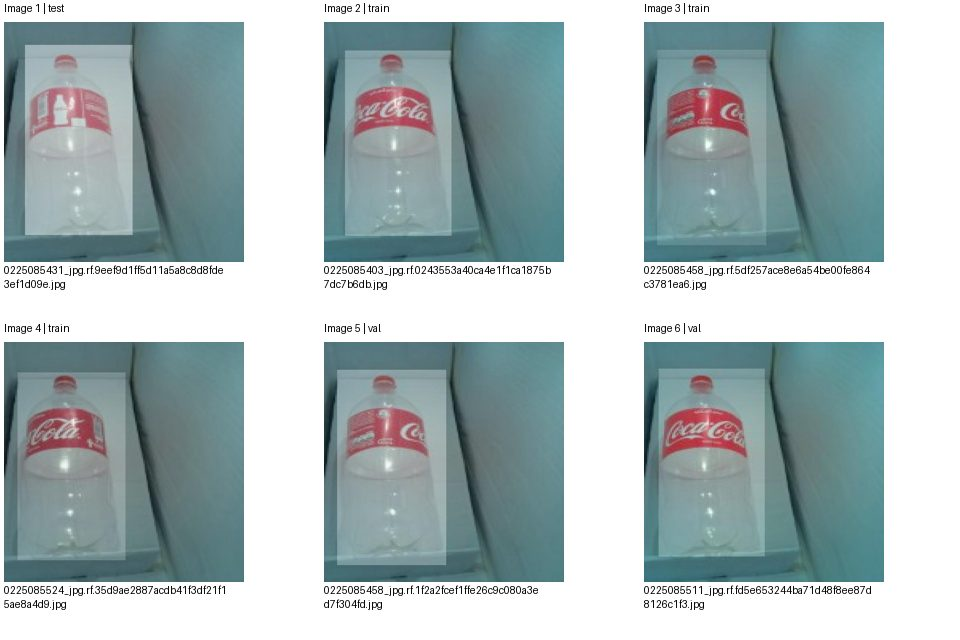

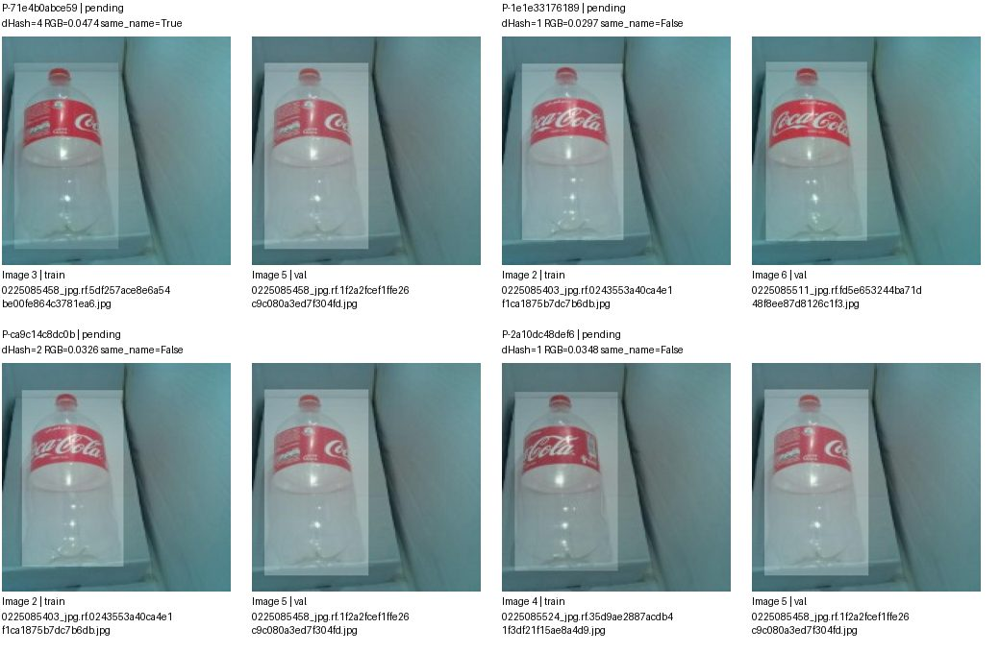

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-71e4b0abce59,images/train/0225085458_jpg.rf.5df257ace8e6a54be00fe864c3781ea6.jpg,images/val/0225085458_jpg.rf.1f2a2fcef1ffe26c9c080a3ed7f304fd.jpg,pending,
P-1e1e33176189,images/train/0225085403_jpg.rf.0243553a40ca4e1f1ca1875b7dc7b6db.jpg,images/val/0225085511_jpg.rf.fd5e653244ba71d48f8ee87d8126c1f3.jpg,pending,
P-ca9c14c8dc0b,images/train/0225085403_jpg.rf.0243553a40ca4e1f1ca1875b7dc7b6db.jpg,images/val/0225085458_jpg.rf.1f2a2fcef1ffe26c9c080a3ed7f304fd.jpg,pending,
P-2a10dc48def6,images/train/0225085524_jpg.rf.35d9ae2887acdb41f3df21f15ae8a4d9.jpg,images/val/0225085458_jpg.rf.1f2a2fcef1ffe26c9c080a3ed7f304fd.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 70/166 G-af4d0437e4c0 | 8 ảnh, 14 cặp
Split: {'test': 1, 'train': 3, 'val': 4}
Quyết định: {'pending': 14}
Ảnh trang 2/2; cặp trang 2/4. Nhóm liên thông không phải kết luận trùng.


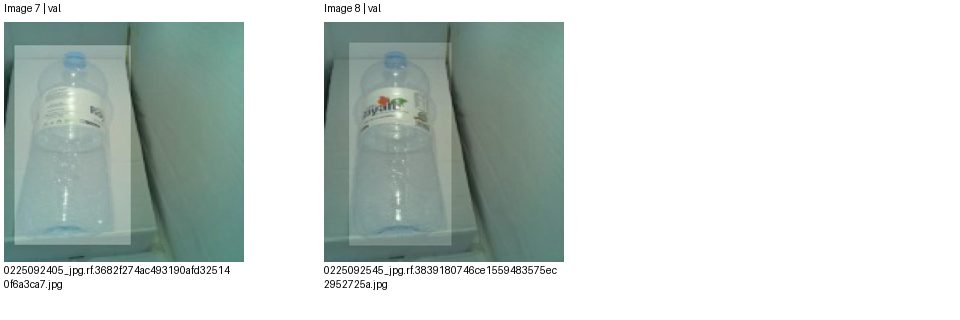

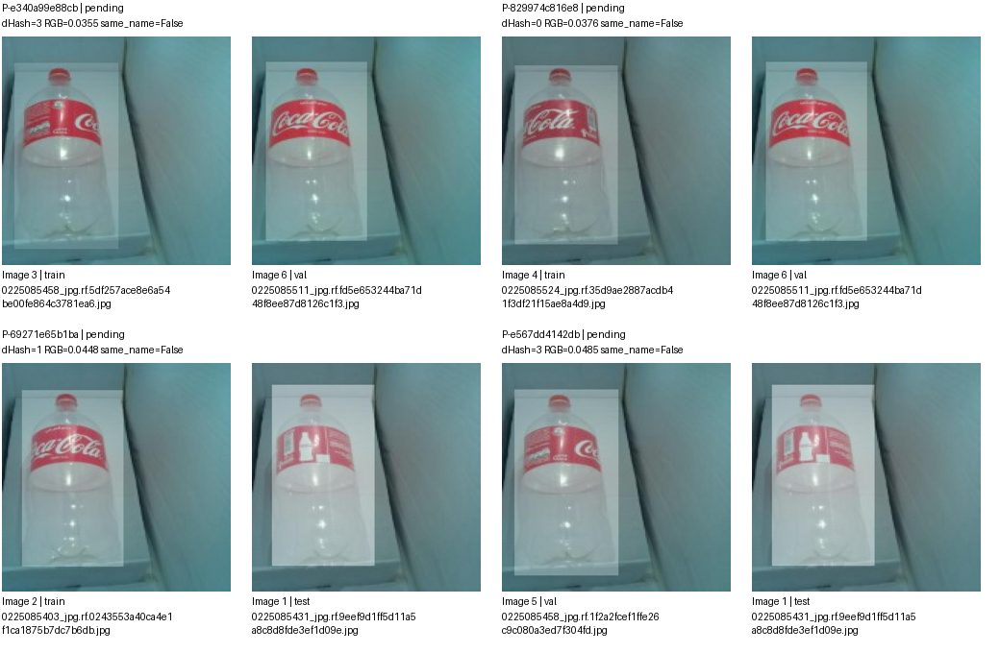

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-e340a99e88cb,images/train/0225085458_jpg.rf.5df257ace8e6a54be00fe864c3781ea6.jpg,images/val/0225085511_jpg.rf.fd5e653244ba71d48f8ee87d8126c1f3.jpg,pending,
P-829974c816e8,images/train/0225085524_jpg.rf.35d9ae2887acdb41f3df21f15ae8a4d9.jpg,images/val/0225085511_jpg.rf.fd5e653244ba71d48f8ee87d8126c1f3.jpg,pending,
P-69271e65b1ba,images/train/0225085403_jpg.rf.0243553a40ca4e1f1ca1875b7dc7b6db.jpg,images/test/0225085431_jpg.rf.9eef9d1ff5d11a5a8c8d8fde3ef1d09e.jpg,pending,
P-e567dd4142db,images/val/0225085458_jpg.rf.1f2a2fcef1ffe26c9c080a3ed7f304fd.jpg,images/test/0225085431_jpg.rf.9eef9d1ff5d11a5a8c8d8fde3ef1d09e.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 70/166 G-af4d0437e4c0 | 8 ảnh, 14 cặp
Split: {'test': 1, 'train': 3, 'val': 4}
Quyết định: {'pending': 14}
Ảnh trang None/2; cặp trang 3/4. Nhóm liên thông không phải kết luận trùng.


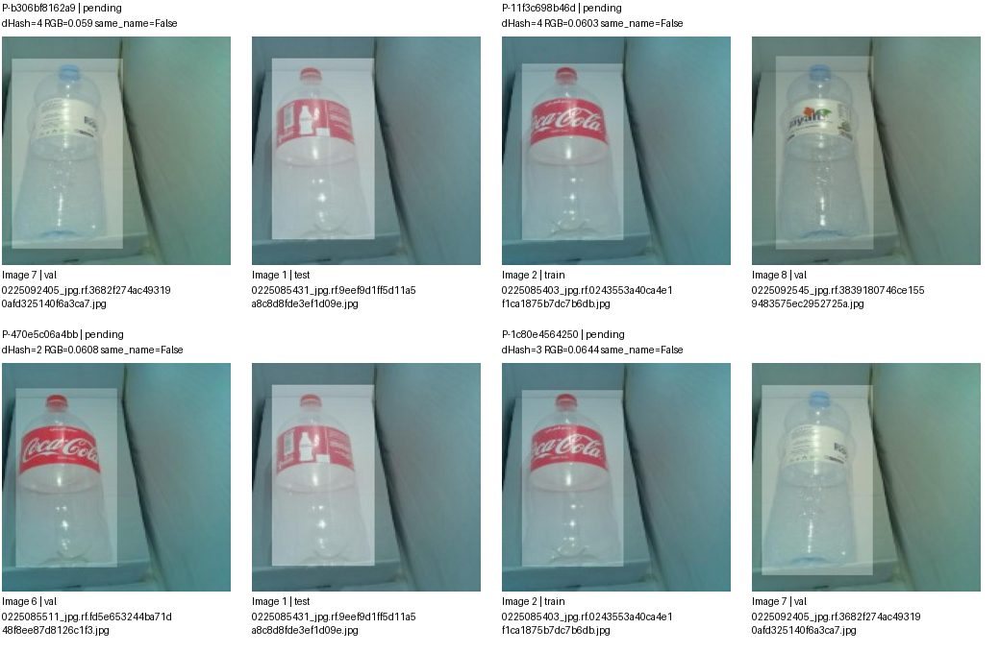

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-b306bf8162a9,images/val/0225092405_jpg.rf.3682f274ac493190afd325140f6a3ca7.jpg,images/test/0225085431_jpg.rf.9eef9d1ff5d11a5a8c8d8fde3ef1d09e.jpg,pending,
P-11f3c698b46d,images/train/0225085403_jpg.rf.0243553a40ca4e1f1ca1875b7dc7b6db.jpg,images/val/0225092545_jpg.rf.3839180746ce1559483575ec2952725a.jpg,pending,
P-470e5c06a4bb,images/val/0225085511_jpg.rf.fd5e653244ba71d48f8ee87d8126c1f3.jpg,images/test/0225085431_jpg.rf.9eef9d1ff5d11a5a8c8d8fde3ef1d09e.jpg,pending,
P-1c80e4564250,images/train/0225085403_jpg.rf.0243553a40ca4e1f1ca1875b7dc7b6db.jpg,images/val/0225092405_jpg.rf.3682f274ac493190afd325140f6a3ca7.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 70/166 G-af4d0437e4c0 | 8 ảnh, 14 cặp
Split: {'test': 1, 'train': 3, 'val': 4}
Quyết định: {'pending': 14}
Ảnh trang None/2; cặp trang 4/4. Nhóm liên thông không phải kết luận trùng.


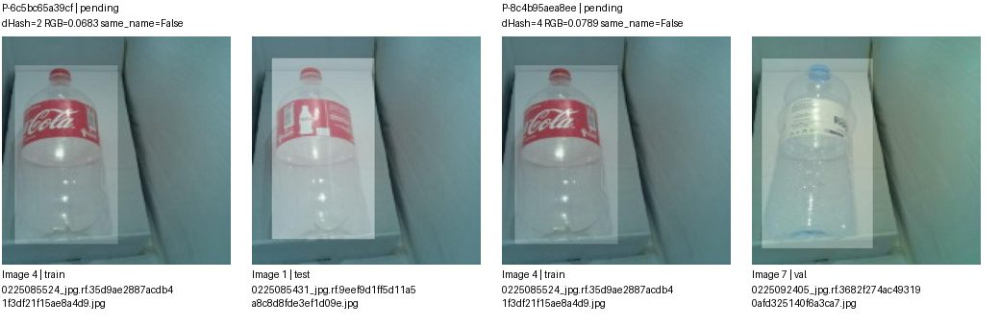

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-6c5bc65a39cf,images/train/0225085524_jpg.rf.35d9ae2887acdb41f3df21f15ae8a4d9.jpg,images/test/0225085431_jpg.rf.9eef9d1ff5d11a5a8c8d8fde3ef1d09e.jpg,pending,
P-8c4b95aea8ee,images/train/0225085524_jpg.rf.35d9ae2887acdb41f3df21f15ae8a4d9.jpg,images/val/0225092405_jpg.rf.3682f274ac493190afd325140f6a3ca7.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 71/166 G-588452757dcb | 4 ảnh, 3 cặp
Split: {'train': 3, 'val': 1}
Quyết định: {'pending': 3}
Ảnh trang 1/1; cặp trang 1/1. Nhóm liên thông không phải kết luận trùng.


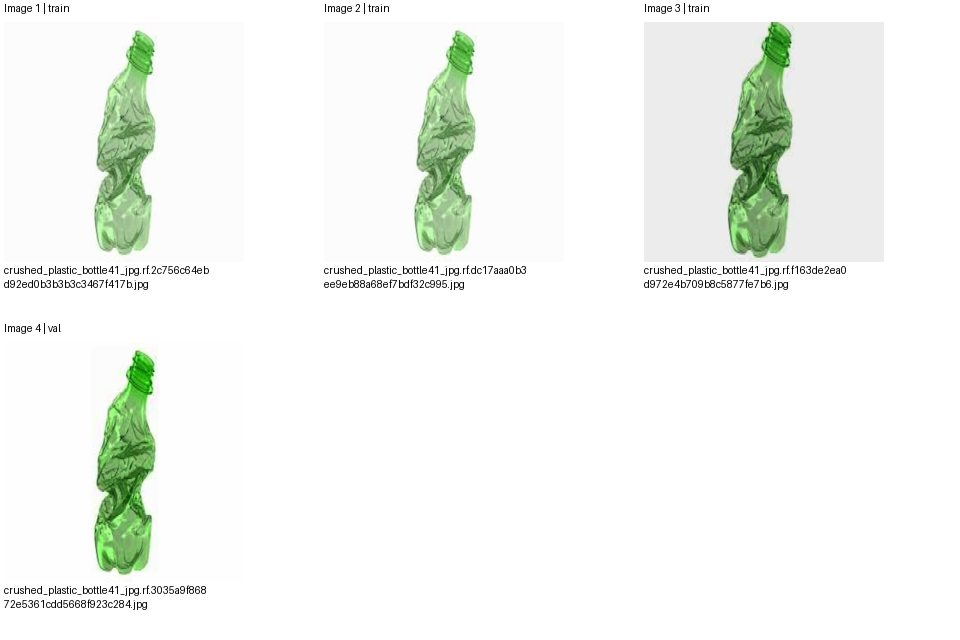

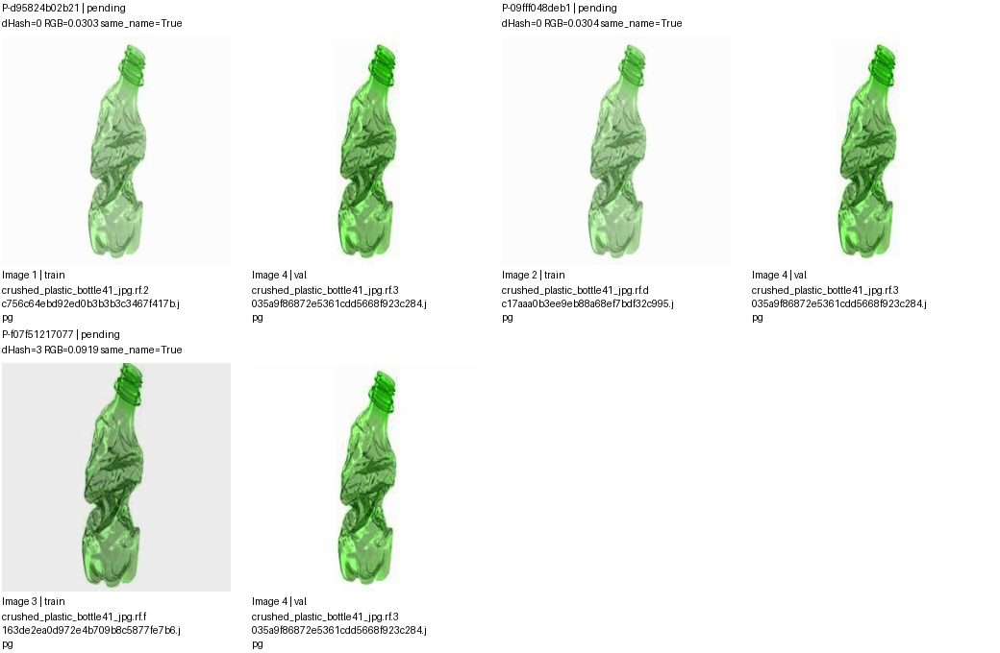

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-d95824b02b21,images/train/crushed_plastic_bottle41_jpg.rf.2c756c64ebd92ed0b3b3b3c3467f417b.jpg,images/val/crushed_plastic_bottle41_jpg.rf.3035a9f86872e5361cdd5668f923c284.jpg,pending,
P-09fff048deb1,images/train/crushed_plastic_bottle41_jpg.rf.dc17aaa0b3ee9eb88a68ef7bdf32c995.jpg,images/val/crushed_plastic_bottle41_jpg.rf.3035a9f86872e5361cdd5668f923c284.jpg,pending,
P-f07f51217077,images/train/crushed_plastic_bottle41_jpg.rf.f163de2ea0d972e4b709b8c5877fe7b6.jpg,images/val/crushed_plastic_bottle41_jpg.rf.3035a9f86872e5361cdd5668f923c284.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 72/166 G-c9cba77da610 | 2 ảnh, 1 cặp
Split: {'test': 1, 'train': 1}
Quyết định: {'pending': 1}
Ảnh trang 1/1; cặp trang 1/1. Nhóm liên thông không phải kết luận trùng.


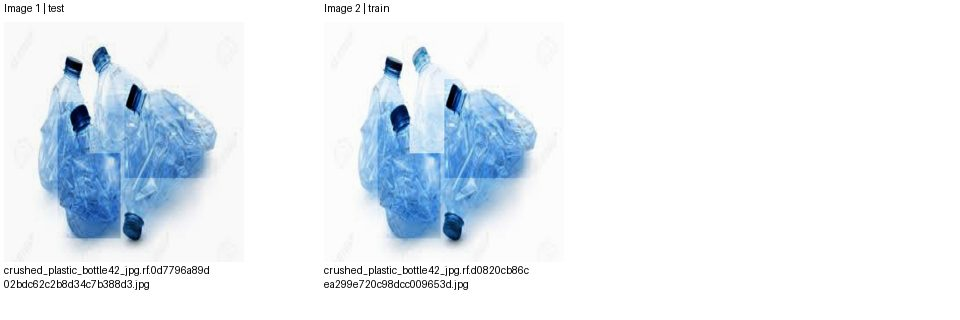

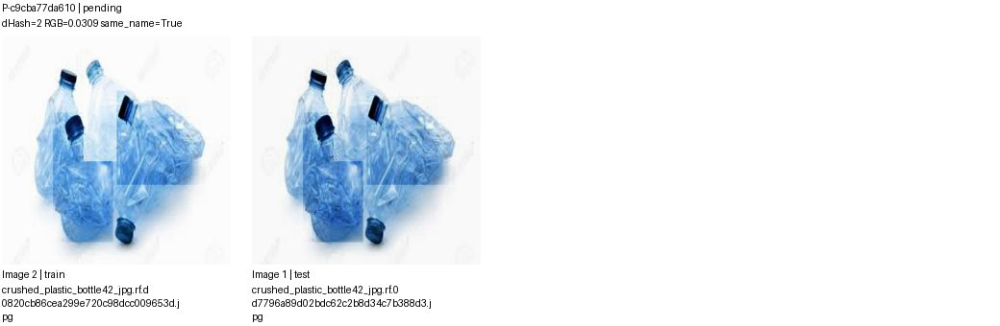

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-c9cba77da610,images/train/crushed_plastic_bottle42_jpg.rf.d0820cb86cea299e720c98dcc009653d.jpg,images/test/crushed_plastic_bottle42_jpg.rf.0d7796a89d02bdc62c2b8d34c7b388d3.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 73/166 G-63ff91017601 | 17 ảnh, 16 cặp
Split: {'test': 2, 'train': 15}
Quyết định: {'pending': 16}
Ảnh trang 1/3; cặp trang 1/4. Nhóm liên thông không phải kết luận trùng.


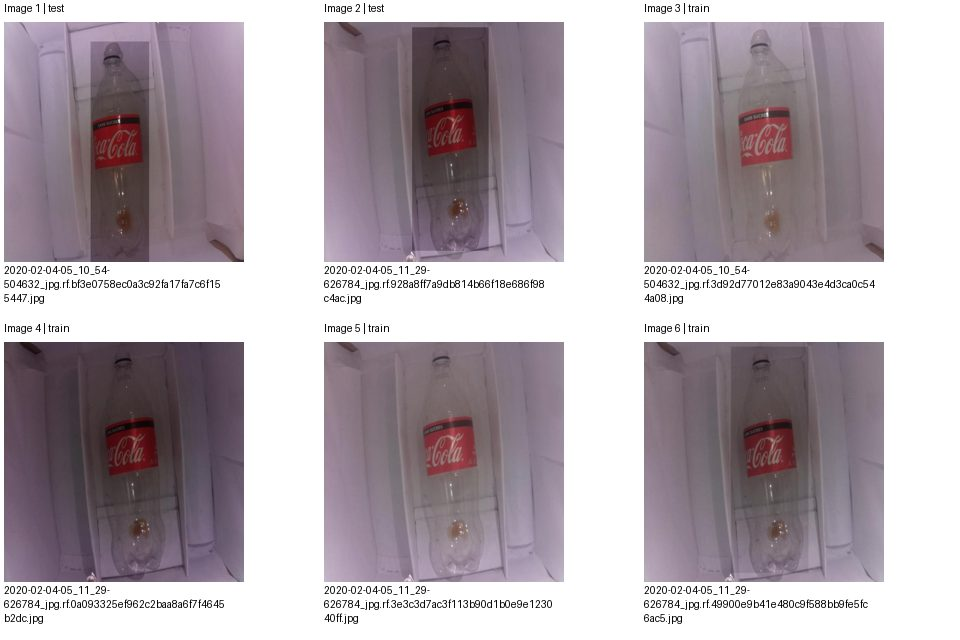

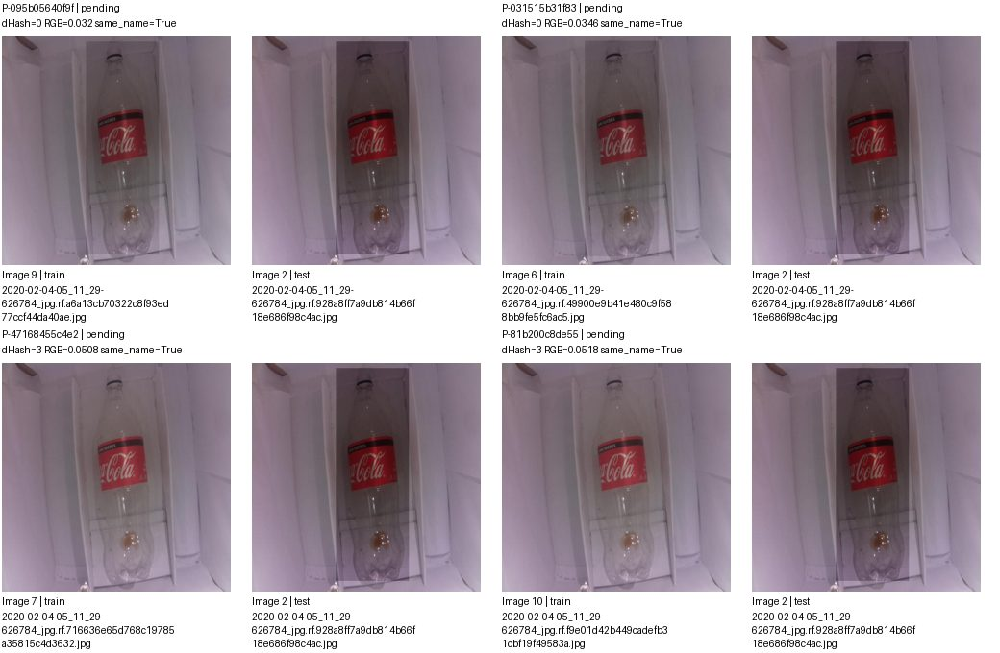

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-095b05640f9f,images/train/2020-02-04-05_11_29-626784_jpg.rf.a6a13cb70322c8f93ed77ccf44da40ae.jpg,images/test/2020-02-04-05_11_29-626784_jpg.rf.928a8ff7a9db814b66f18e686f98c4ac.jpg,pending,
P-031515b31f83,images/train/2020-02-04-05_11_29-626784_jpg.rf.49900e9b41e480c9f588bb9fe5fc6ac5.jpg,images/test/2020-02-04-05_11_29-626784_jpg.rf.928a8ff7a9db814b66f18e686f98c4ac.jpg,pending,
P-47168455c4e2,images/train/2020-02-04-05_11_29-626784_jpg.rf.716636e65d768c19785a35815c4d3632.jpg,images/test/2020-02-04-05_11_29-626784_jpg.rf.928a8ff7a9db814b66f18e686f98c4ac.jpg,pending,
P-81b200c8de55,images/train/2020-02-04-05_11_29-626784_jpg.rf.f9e01d42b449cadefb31cbf19f49583a.jpg,images/test/2020-02-04-05_11_29-626784_jpg.rf.928a8ff7a9db814b66f18e686f98c4ac.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 73/166 G-63ff91017601 | 17 ảnh, 16 cặp
Split: {'test': 2, 'train': 15}
Quyết định: {'pending': 16}
Ảnh trang 2/3; cặp trang 2/4. Nhóm liên thông không phải kết luận trùng.


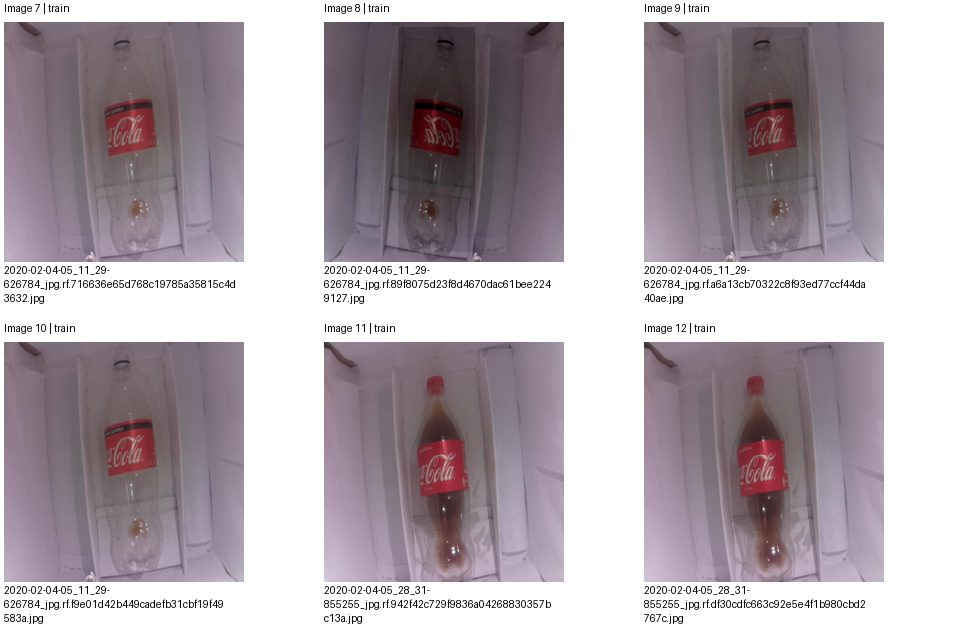

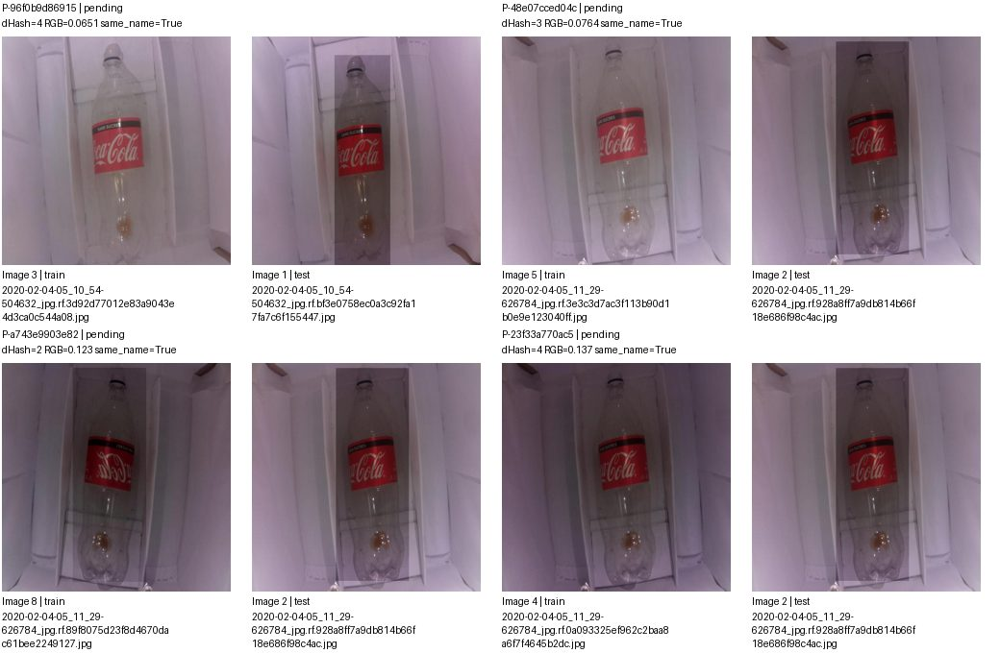

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-96f0b9d86915,images/train/2020-02-04-05_10_54-504632_jpg.rf.3d92d77012e83a9043e4d3ca0c544a08.jpg,images/test/2020-02-04-05_10_54-504632_jpg.rf.bf3e0758ec0a3c92fa17fa7c6f155447.jpg,pending,
P-48e07cced04c,images/train/2020-02-04-05_11_29-626784_jpg.rf.3e3c3d7ac3f113b90d1b0e9e123040ff.jpg,images/test/2020-02-04-05_11_29-626784_jpg.rf.928a8ff7a9db814b66f18e686f98c4ac.jpg,pending,
P-a743e9903e82,images/train/2020-02-04-05_11_29-626784_jpg.rf.89f8075d23f8d4670dac61bee2249127.jpg,images/test/2020-02-04-05_11_29-626784_jpg.rf.928a8ff7a9db814b66f18e686f98c4ac.jpg,pending,
P-23f33a770ac5,images/train/2020-02-04-05_11_29-626784_jpg.rf.0a093325ef962c2baa8a6f7f4645b2dc.jpg,images/test/2020-02-04-05_11_29-626784_jpg.rf.928a8ff7a9db814b66f18e686f98c4ac.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 73/166 G-63ff91017601 | 17 ảnh, 16 cặp
Split: {'test': 2, 'train': 15}
Quyết định: {'pending': 16}
Ảnh trang 3/3; cặp trang 3/4. Nhóm liên thông không phải kết luận trùng.


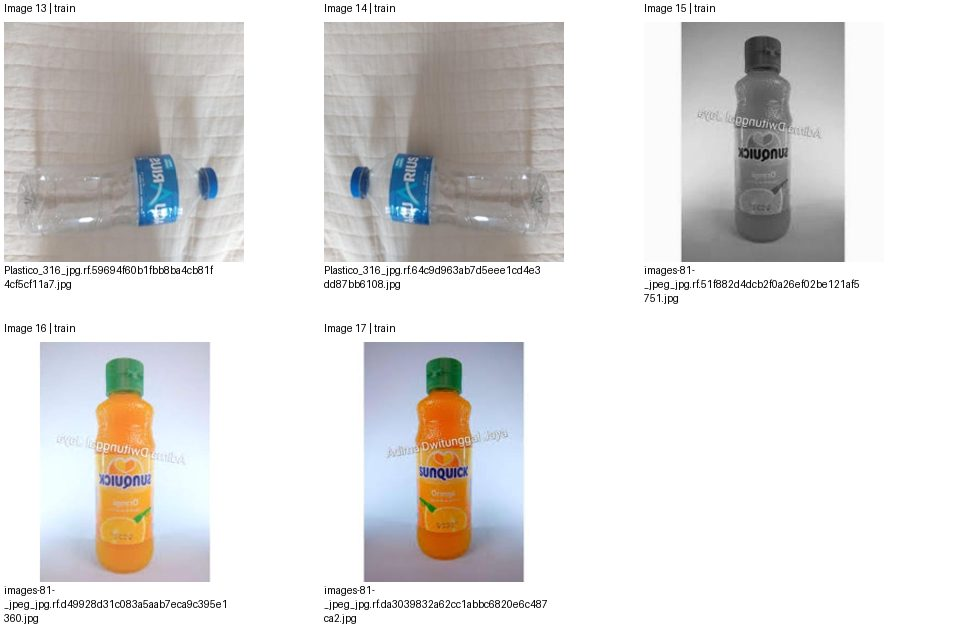

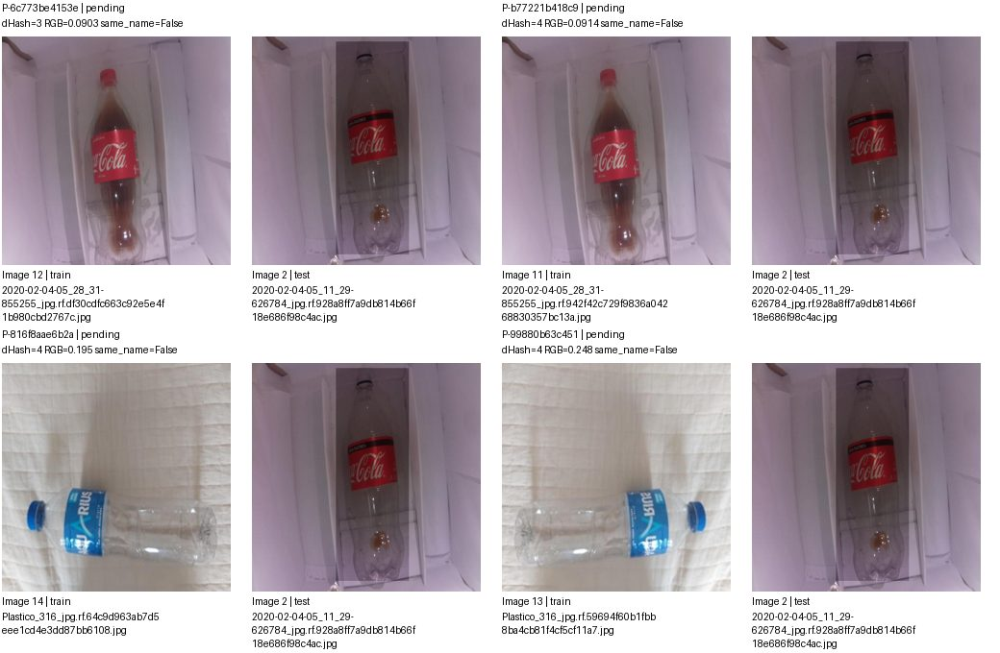

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-6c773be4153e,images/train/2020-02-04-05_28_31-855255_jpg.rf.df30cdfc663c92e5e4f1b980cbd2767c.jpg,images/test/2020-02-04-05_11_29-626784_jpg.rf.928a8ff7a9db814b66f18e686f98c4ac.jpg,pending,
P-b77221b418c9,images/train/2020-02-04-05_28_31-855255_jpg.rf.942f42c729f9836a04268830357bc13a.jpg,images/test/2020-02-04-05_11_29-626784_jpg.rf.928a8ff7a9db814b66f18e686f98c4ac.jpg,pending,
P-816f8aae6b2a,images/train/Plastico_316_jpg.rf.64c9d963ab7d5eee1cd4e3dd87bb6108.jpg,images/test/2020-02-04-05_11_29-626784_jpg.rf.928a8ff7a9db814b66f18e686f98c4ac.jpg,pending,
P-99880b63c451,images/train/Plastico_316_jpg.rf.59694f60b1fbb8ba4cb81f4cf5cf11a7.jpg,images/test/2020-02-04-05_11_29-626784_jpg.rf.928a8ff7a9db814b66f18e686f98c4ac.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 73/166 G-63ff91017601 | 17 ảnh, 16 cặp
Split: {'test': 2, 'train': 15}
Quyết định: {'pending': 16}
Ảnh trang None/3; cặp trang 4/4. Nhóm liên thông không phải kết luận trùng.


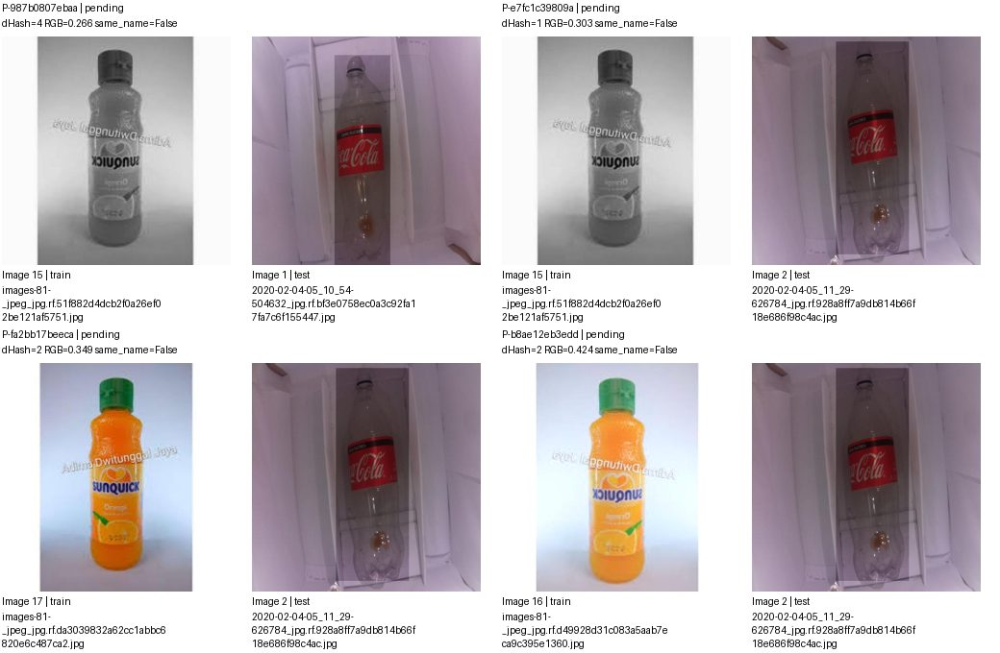

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-987b0807ebaa,images/train/images-81-_jpeg_jpg.rf.51f882d4dcb2f0a26ef02be121af5751.jpg,images/test/2020-02-04-05_10_54-504632_jpg.rf.bf3e0758ec0a3c92fa17fa7c6f155447.jpg,pending,
P-e7fc1c39809a,images/train/images-81-_jpeg_jpg.rf.51f882d4dcb2f0a26ef02be121af5751.jpg,images/test/2020-02-04-05_11_29-626784_jpg.rf.928a8ff7a9db814b66f18e686f98c4ac.jpg,pending,
P-fa2bb17beeca,images/train/images-81-_jpeg_jpg.rf.da3039832a62cc1abbc6820e6c487ca2.jpg,images/test/2020-02-04-05_11_29-626784_jpg.rf.928a8ff7a9db814b66f18e686f98c4ac.jpg,pending,
P-b8ae12eb3edd,images/train/images-81-_jpeg_jpg.rf.d49928d31c083a5aab7eca9c395e1360.jpg,images/test/2020-02-04-05_11_29-626784_jpg.rf.928a8ff7a9db814b66f18e686f98c4ac.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 74/166 G-ea366328b298 | 5 ảnh, 4 cặp
Split: {'test': 1, 'train': 4}
Quyết định: {'pending': 4}
Ảnh trang 1/1; cặp trang 1/1. Nhóm liên thông không phải kết luận trùng.


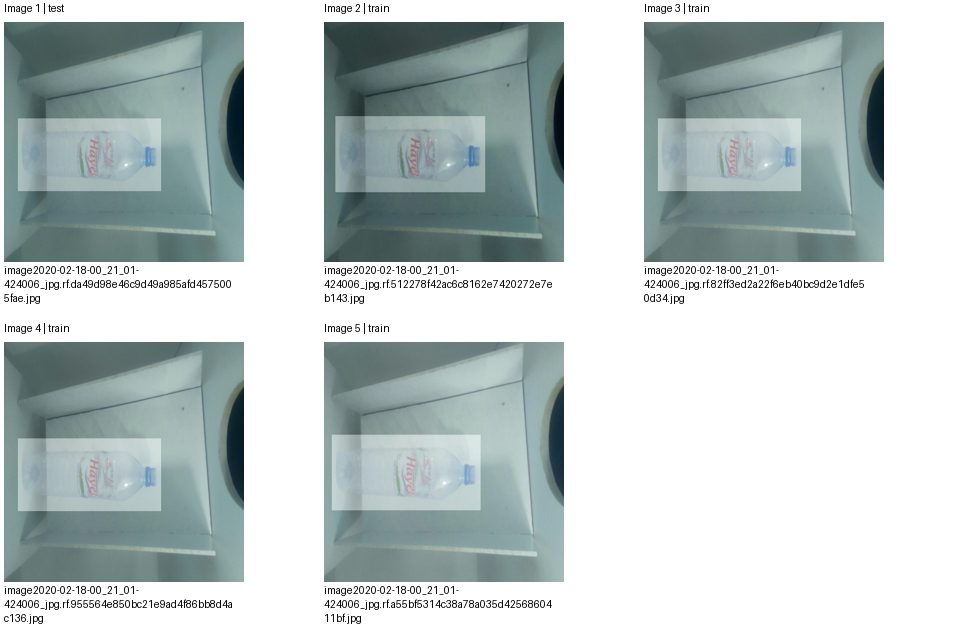

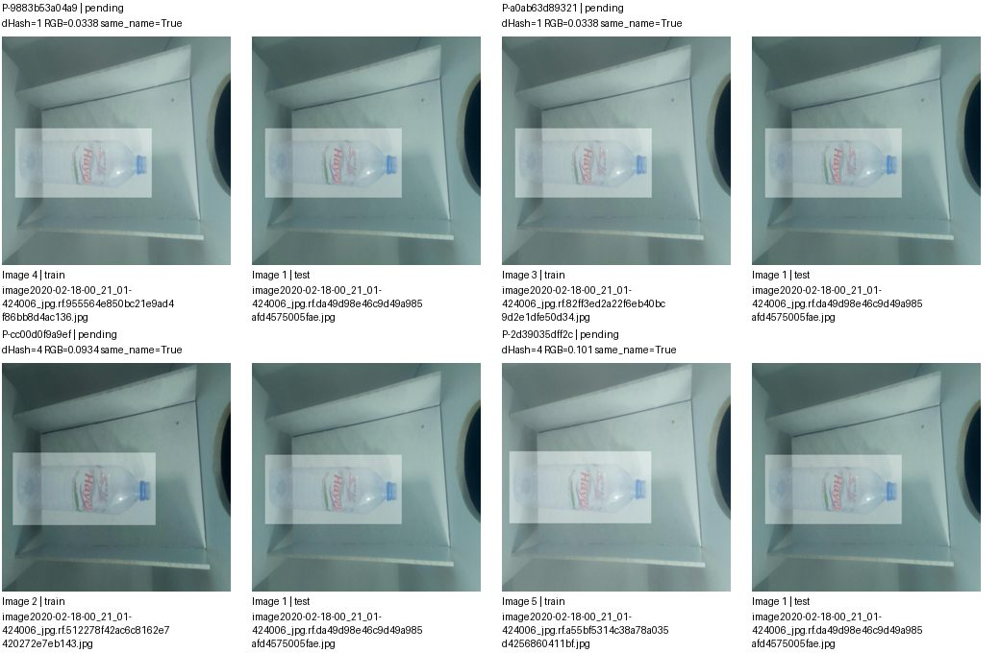

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-9883b53a04a9,images/train/image2020-02-18-00_21_01-424006_jpg.rf.955564e850bc21e9ad4f86bb8d4ac136.jpg,images/test/image2020-02-18-00_21_01-424006_jpg.rf.da49d98e46c9d49a985afd4575005fae.jpg,pending,
P-a0ab63d89321,images/train/image2020-02-18-00_21_01-424006_jpg.rf.82ff3ed2a22f6eb40bc9d2e1dfe50d34.jpg,images/test/image2020-02-18-00_21_01-424006_jpg.rf.da49d98e46c9d49a985afd4575005fae.jpg,pending,
P-cc00d0f9a9ef,images/train/image2020-02-18-00_21_01-424006_jpg.rf.512278f42ac6c8162e7420272e7eb143.jpg,images/test/image2020-02-18-00_21_01-424006_jpg.rf.da49d98e46c9d49a985afd4575005fae.jpg,pending,
P-2d39035dff2c,images/train/image2020-02-18-00_21_01-424006_jpg.rf.a55bf5314c38a78a035d4256860411bf.jpg,images/test/image2020-02-18-00_21_01-424006_jpg.rf.da49d98e46c9d49a985afd4575005fae.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 75/166 G-17dbacd9d679 | 2 ảnh, 1 cặp
Split: {'test': 1, 'train': 1}
Quyết định: {'pending': 1}
Ảnh trang 1/1; cặp trang 1/1. Nhóm liên thông không phải kết luận trùng.


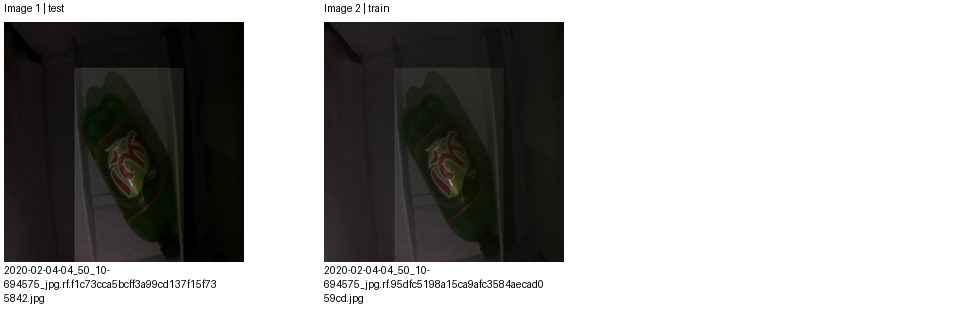

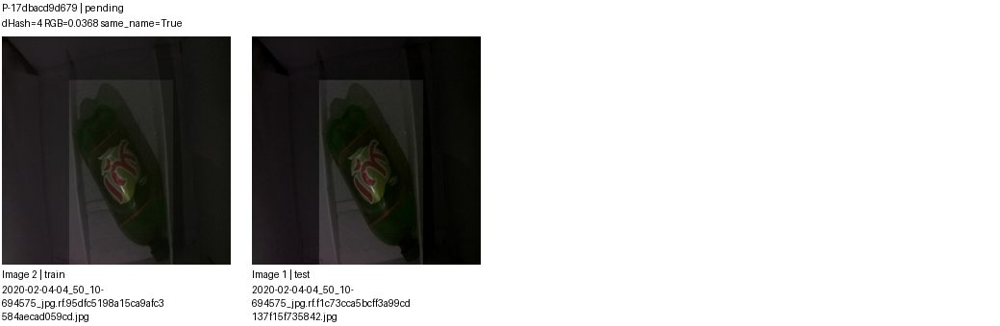

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-17dbacd9d679,images/train/2020-02-04-04_50_10-694575_jpg.rf.95dfc5198a15ca9afc3584aecad059cd.jpg,images/test/2020-02-04-04_50_10-694575_jpg.rf.f1c73cca5bcff3a99cd137f15f735842.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 76/166 G-fd1f19c270e7 | 7 ảnh, 6 cặp
Split: {'test': 1, 'train': 6}
Quyết định: {'pending': 6}
Ảnh trang 1/2; cặp trang 1/2. Nhóm liên thông không phải kết luận trùng.


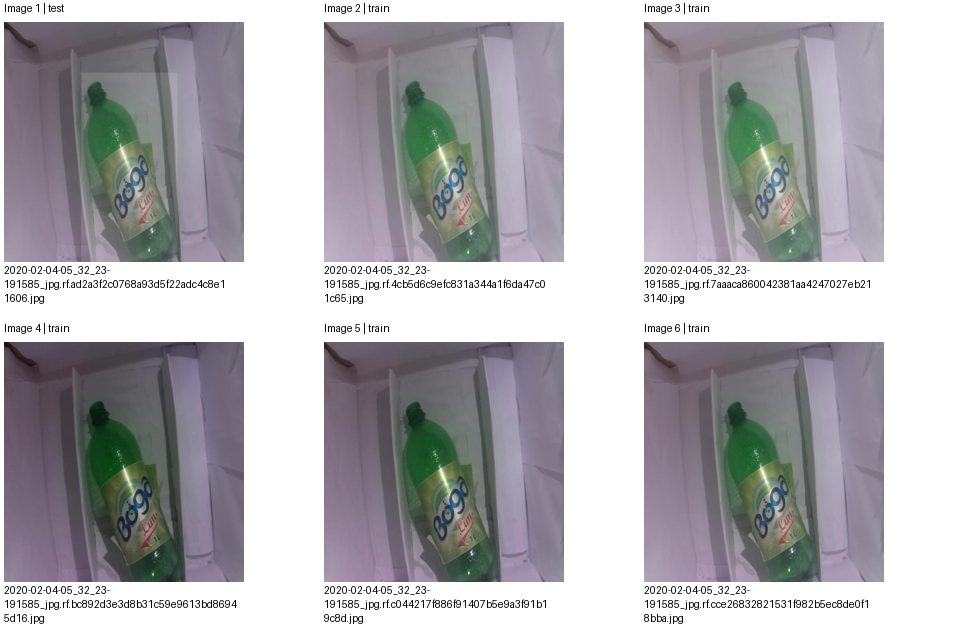

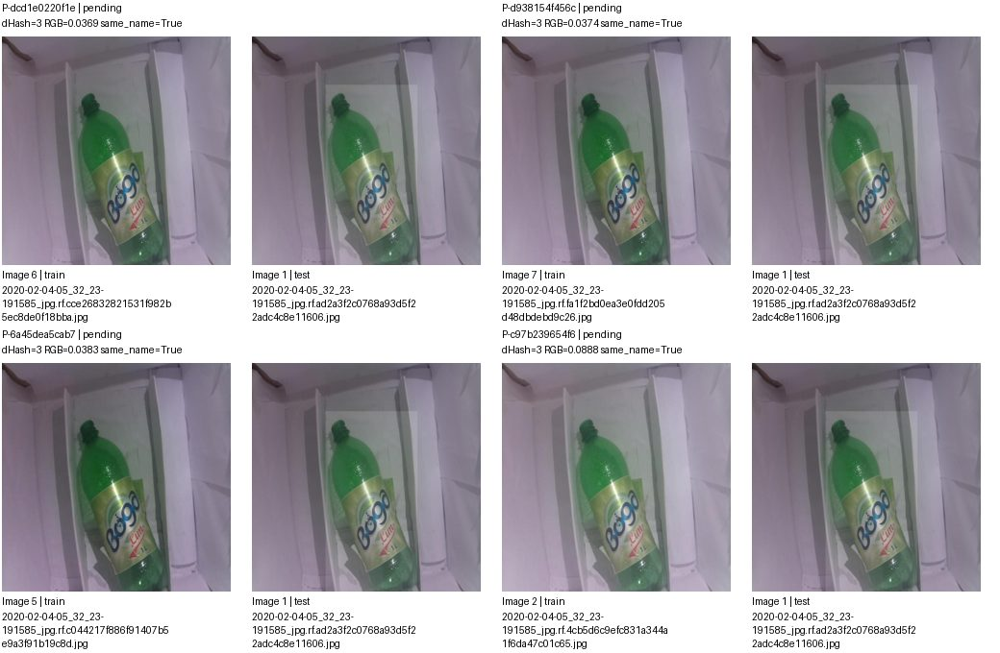

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-dcd1e0220f1e,images/train/2020-02-04-05_32_23-191585_jpg.rf.cce26832821531f982b5ec8de0f18bba.jpg,images/test/2020-02-04-05_32_23-191585_jpg.rf.ad2a3f2c0768a93d5f22adc4c8e11606.jpg,pending,
P-d938154f456c,images/train/2020-02-04-05_32_23-191585_jpg.rf.fa1f2bd0ea3e0fdd205d48dbdebd9c26.jpg,images/test/2020-02-04-05_32_23-191585_jpg.rf.ad2a3f2c0768a93d5f22adc4c8e11606.jpg,pending,
P-6a45dea5cab7,images/train/2020-02-04-05_32_23-191585_jpg.rf.c044217f886f91407b5e9a3f91b19c8d.jpg,images/test/2020-02-04-05_32_23-191585_jpg.rf.ad2a3f2c0768a93d5f22adc4c8e11606.jpg,pending,
P-c97b239654f6,images/train/2020-02-04-05_32_23-191585_jpg.rf.4cb5d6c9efc831a344a1f6da47c01c65.jpg,images/test/2020-02-04-05_32_23-191585_jpg.rf.ad2a3f2c0768a93d5f22adc4c8e11606.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 76/166 G-fd1f19c270e7 | 7 ảnh, 6 cặp
Split: {'test': 1, 'train': 6}
Quyết định: {'pending': 6}
Ảnh trang 2/2; cặp trang 2/2. Nhóm liên thông không phải kết luận trùng.


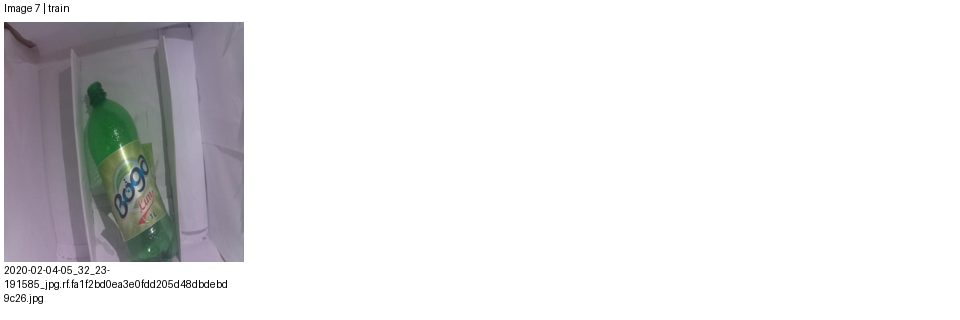

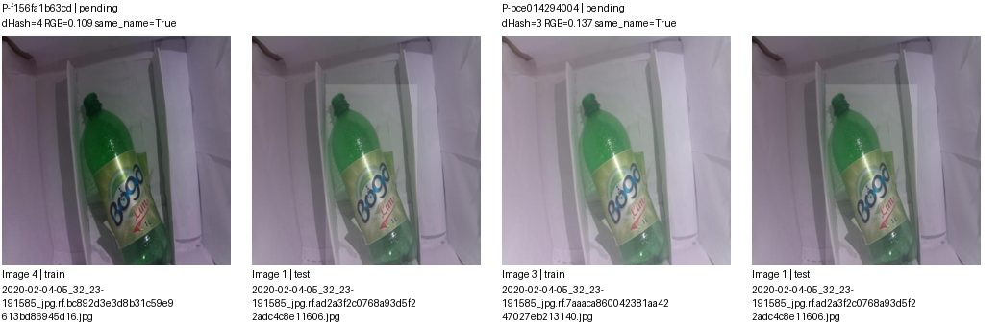

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-f156fa1b63cd,images/train/2020-02-04-05_32_23-191585_jpg.rf.bc892d3e3d8b31c59e9613bd86945d16.jpg,images/test/2020-02-04-05_32_23-191585_jpg.rf.ad2a3f2c0768a93d5f22adc4c8e11606.jpg,pending,
P-bce014294004,images/train/2020-02-04-05_32_23-191585_jpg.rf.7aaaca860042381aa4247027eb213140.jpg,images/test/2020-02-04-05_32_23-191585_jpg.rf.ad2a3f2c0768a93d5f22adc4c8e11606.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 77/166 G-cd452a8ec80e | 6 ảnh, 5 cặp
Split: {'train': 5, 'val': 1}
Quyết định: {'pending': 5}
Ảnh trang 1/1; cặp trang 1/2. Nhóm liên thông không phải kết luận trùng.


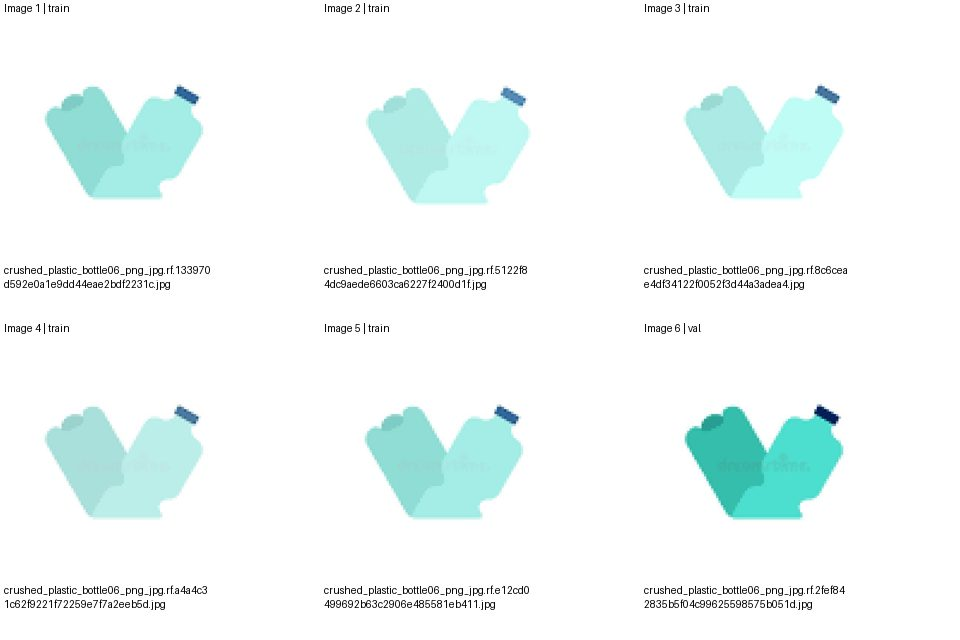

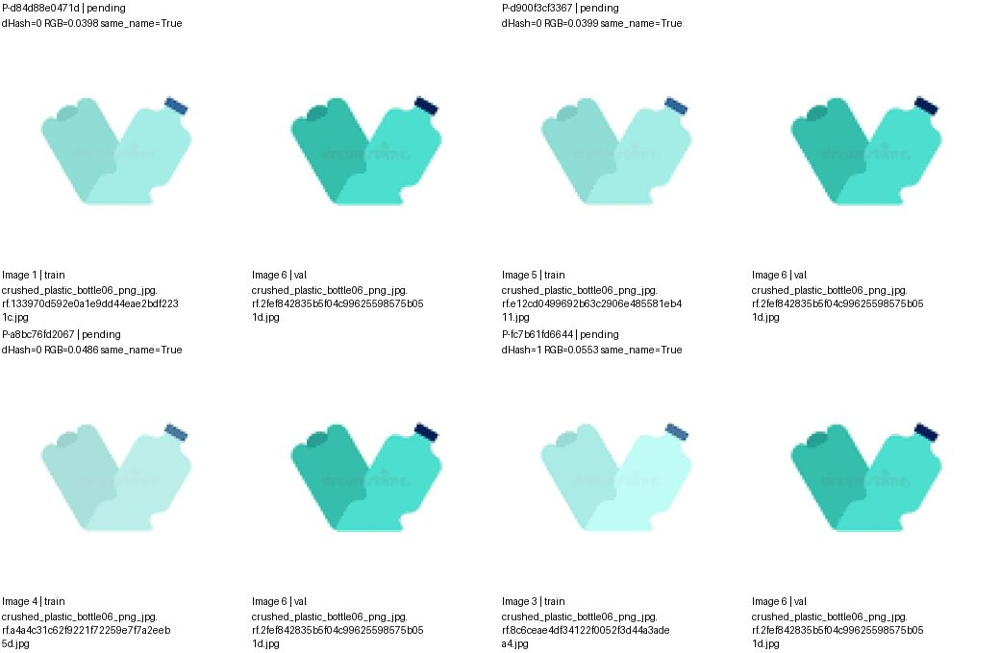

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-d84d88e0471d,images/train/crushed_plastic_bottle06_png_jpg.rf.133970d592e0a1e9dd44eae2bdf2231c.jpg,images/val/crushed_plastic_bottle06_png_jpg.rf.2fef842835b5f04c99625598575b051d.jpg,pending,
P-d900f3cf3367,images/train/crushed_plastic_bottle06_png_jpg.rf.e12cd0499692b63c2906e485581eb411.jpg,images/val/crushed_plastic_bottle06_png_jpg.rf.2fef842835b5f04c99625598575b051d.jpg,pending,
P-a8bc76fd2067,images/train/crushed_plastic_bottle06_png_jpg.rf.a4a4c31c62f9221f72259e7f7a2eeb5d.jpg,images/val/crushed_plastic_bottle06_png_jpg.rf.2fef842835b5f04c99625598575b051d.jpg,pending,
P-fc7b61fd6644,images/train/crushed_plastic_bottle06_png_jpg.rf.8c6ceae4df34122f0052f3d44a3adea4.jpg,images/val/crushed_plastic_bottle06_png_jpg.rf.2fef842835b5f04c99625598575b051d.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 77/166 G-cd452a8ec80e | 6 ảnh, 5 cặp
Split: {'train': 5, 'val': 1}
Quyết định: {'pending': 5}
Ảnh trang None/1; cặp trang 2/2. Nhóm liên thông không phải kết luận trùng.


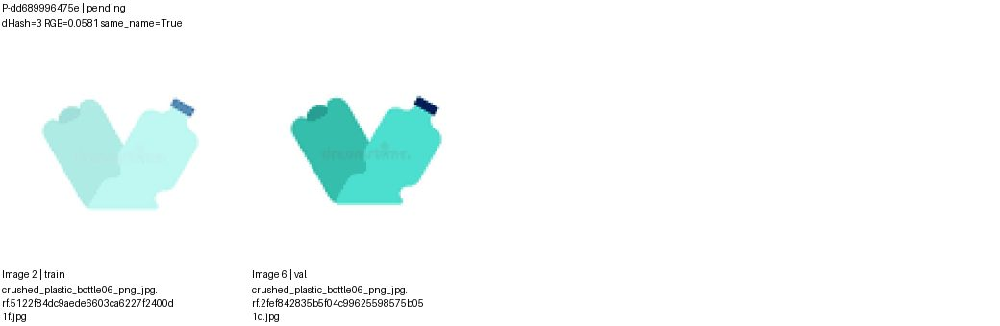

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-dd689996475e,images/train/crushed_plastic_bottle06_png_jpg.rf.5122f84dc9aede6603ca6227f2400d1f.jpg,images/val/crushed_plastic_bottle06_png_jpg.rf.2fef842835b5f04c99625598575b051d.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 78/166 G-db24c8579e27 | 2 ảnh, 1 cặp
Split: {'test': 1, 'train': 1}
Quyết định: {'pending': 1}
Ảnh trang 1/1; cặp trang 1/1. Nhóm liên thông không phải kết luận trùng.


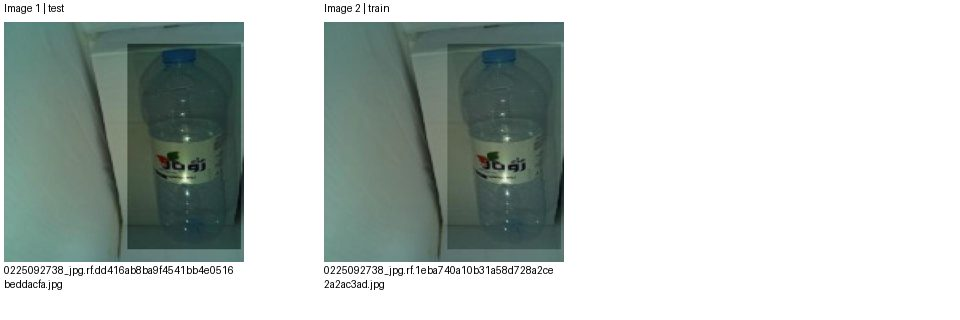

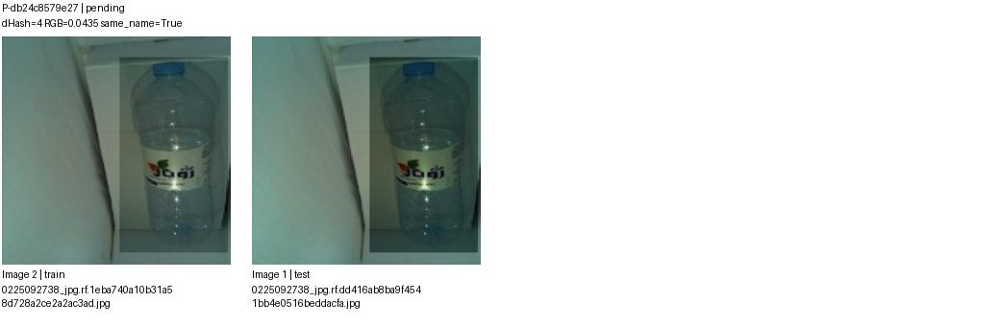

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-db24c8579e27,images/train/0225092738_jpg.rf.1eba740a10b31a58d728a2ce2a2ac3ad.jpg,images/test/0225092738_jpg.rf.dd416ab8ba9f4541bb4e0516beddacfa.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 79/166 G-add0b605770e | 2 ảnh, 1 cặp
Split: {'train': 1, 'val': 1}
Quyết định: {'pending': 1}
Ảnh trang 1/1; cặp trang 1/1. Nhóm liên thông không phải kết luận trùng.


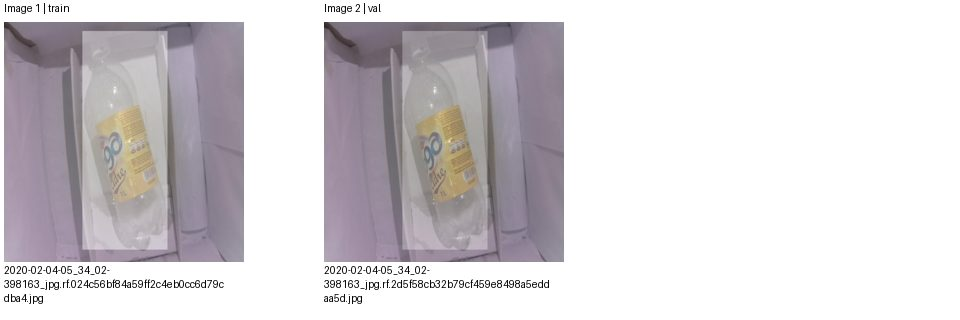

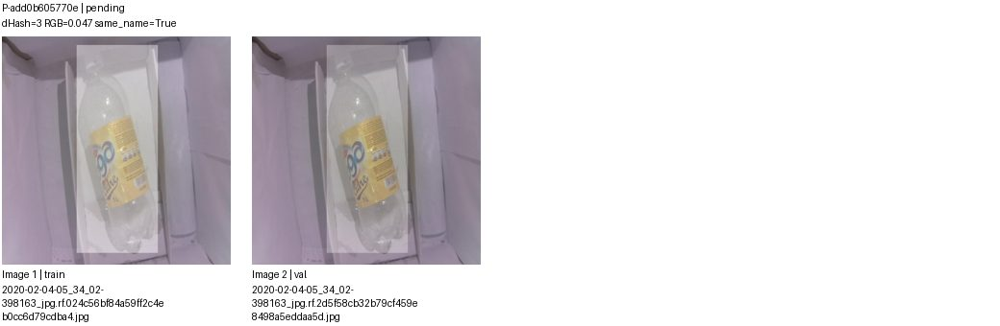

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-add0b605770e,images/train/2020-02-04-05_34_02-398163_jpg.rf.024c56bf84a59ff2c4eb0cc6d79cdba4.jpg,images/val/2020-02-04-05_34_02-398163_jpg.rf.2d5f58cb32b79cf459e8498a5eddaa5d.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 80/166 G-53b9ba3119c2 | 3 ảnh, 2 cặp
Split: {'train': 2, 'val': 1}
Quyết định: {'pending': 2}
Ảnh trang 1/1; cặp trang 1/1. Nhóm liên thông không phải kết luận trùng.


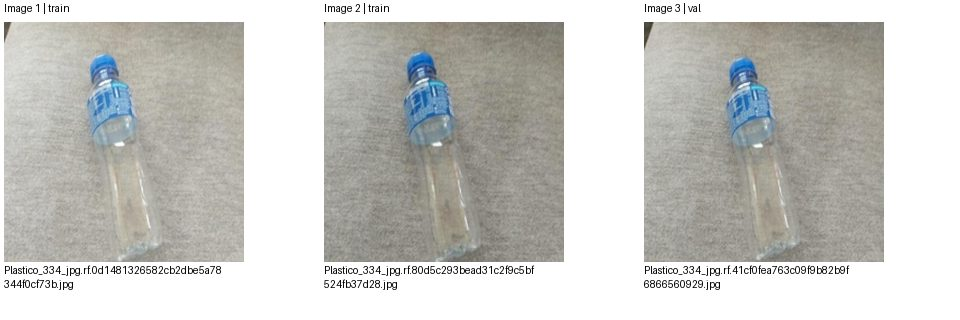

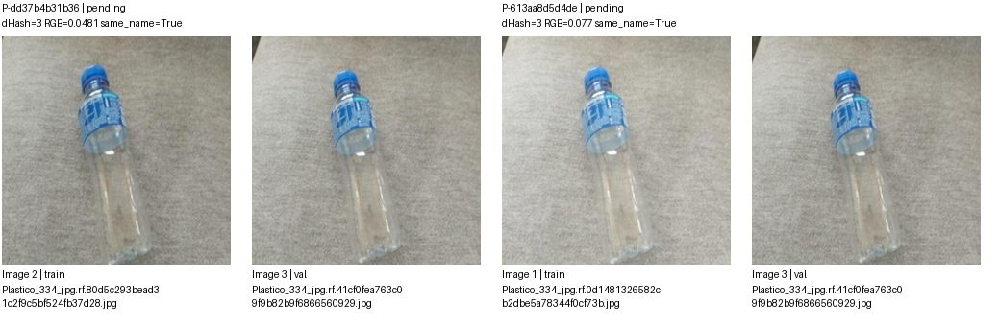

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-dd37b4b31b36,images/train/Plastico_334_jpg.rf.80d5c293bead31c2f9c5bf524fb37d28.jpg,images/val/Plastico_334_jpg.rf.41cf0fea763c09f9b82b9f6866560929.jpg,pending,
P-613aa8d5d4de,images/train/Plastico_334_jpg.rf.0d1481326582cb2dbe5a78344f0cf73b.jpg,images/val/Plastico_334_jpg.rf.41cf0fea763c09f9b82b9f6866560929.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 81/166 G-9eb0d91414b8 | 2 ảnh, 1 cặp
Split: {'train': 1, 'val': 1}
Quyết định: {'pending': 1}
Ảnh trang 1/1; cặp trang 1/1. Nhóm liên thông không phải kết luận trùng.


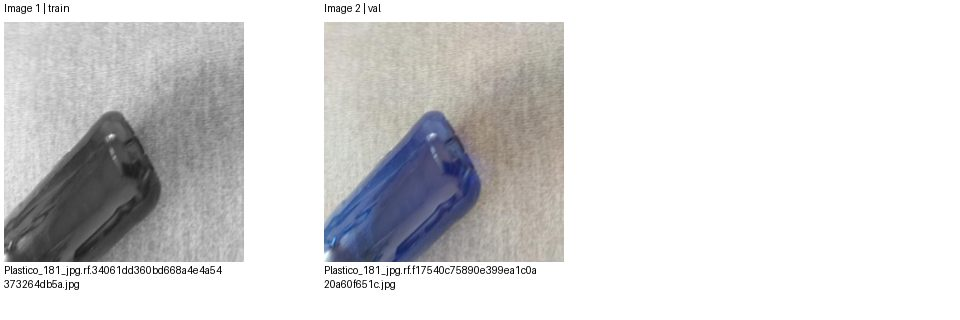

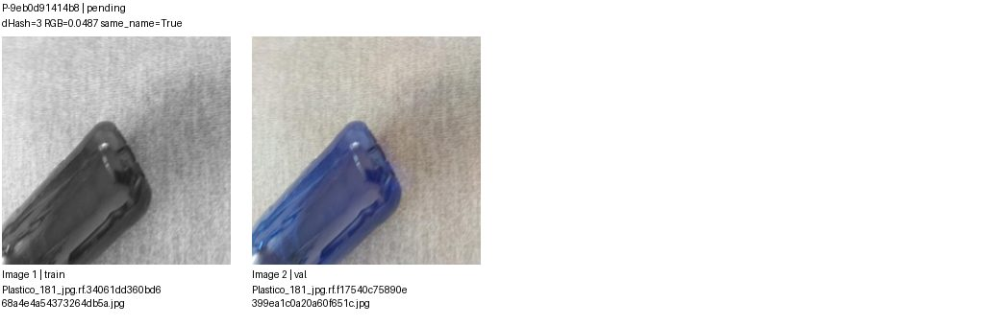

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-9eb0d91414b8,images/train/Plastico_181_jpg.rf.34061dd360bd668a4e4a54373264db5a.jpg,images/val/Plastico_181_jpg.rf.f17540c75890e399ea1c0a20a60f651c.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 82/166 G-01d089c2f429 | 5 ảnh, 4 cặp
Split: {'test': 1, 'train': 4}
Quyết định: {'pending': 4}
Ảnh trang 1/1; cặp trang 1/1. Nhóm liên thông không phải kết luận trùng.


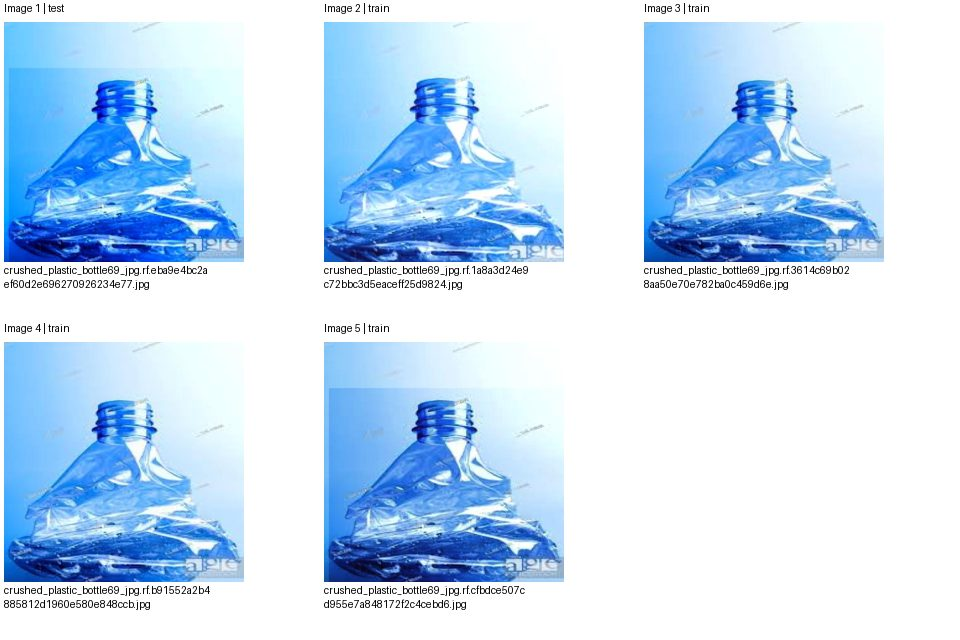

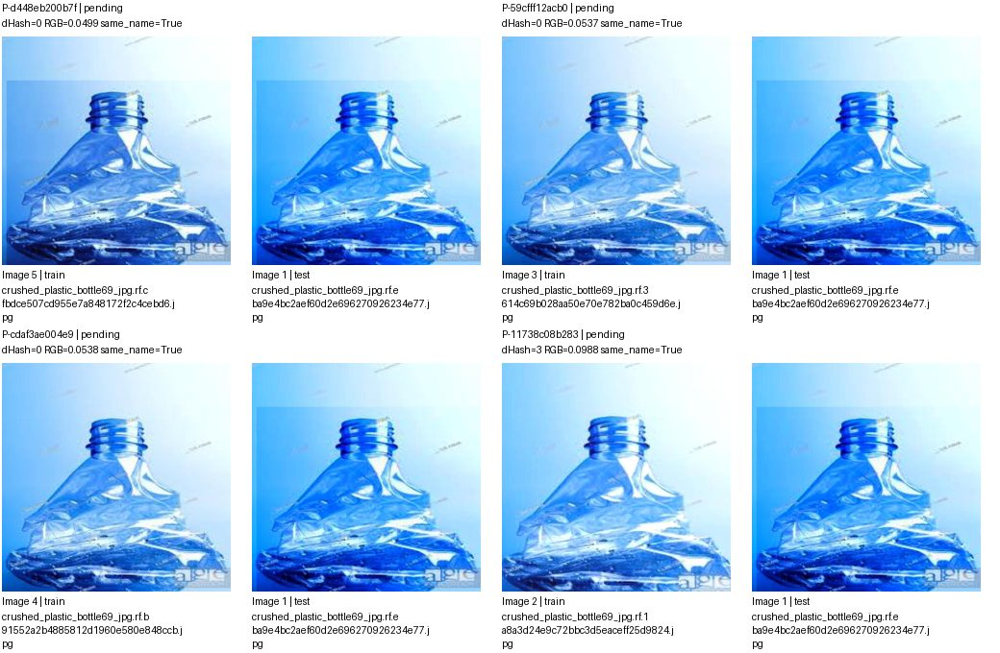

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-d448eb200b7f,images/train/crushed_plastic_bottle69_jpg.rf.cfbdce507cd955e7a848172f2c4cebd6.jpg,images/test/crushed_plastic_bottle69_jpg.rf.eba9e4bc2aef60d2e696270926234e77.jpg,pending,
P-59cfff12acb0,images/train/crushed_plastic_bottle69_jpg.rf.3614c69b028aa50e70e782ba0c459d6e.jpg,images/test/crushed_plastic_bottle69_jpg.rf.eba9e4bc2aef60d2e696270926234e77.jpg,pending,
P-cdaf3ae004e9,images/train/crushed_plastic_bottle69_jpg.rf.b91552a2b4885812d1960e580e848ccb.jpg,images/test/crushed_plastic_bottle69_jpg.rf.eba9e4bc2aef60d2e696270926234e77.jpg,pending,
P-11738c08b283,images/train/crushed_plastic_bottle69_jpg.rf.1a8a3d24e9c72bbc3d5eaceff25d9824.jpg,images/test/crushed_plastic_bottle69_jpg.rf.eba9e4bc2aef60d2e696270926234e77.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 83/166 G-1a179f8a255c | 3 ảnh, 2 cặp
Split: {'test': 1, 'train': 2}
Quyết định: {'pending': 2}
Ảnh trang 1/1; cặp trang 1/1. Nhóm liên thông không phải kết luận trùng.


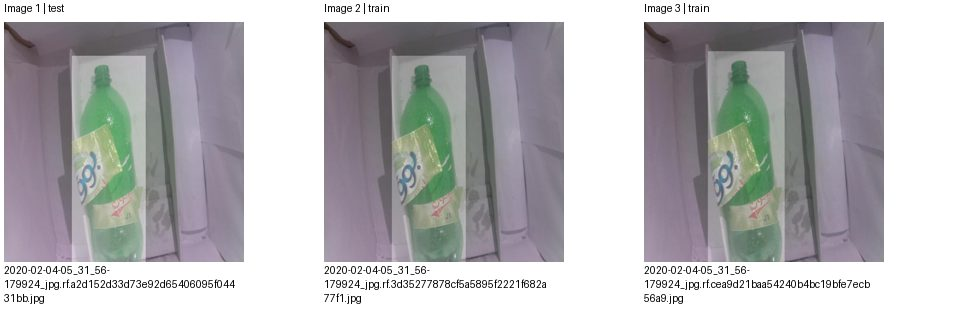

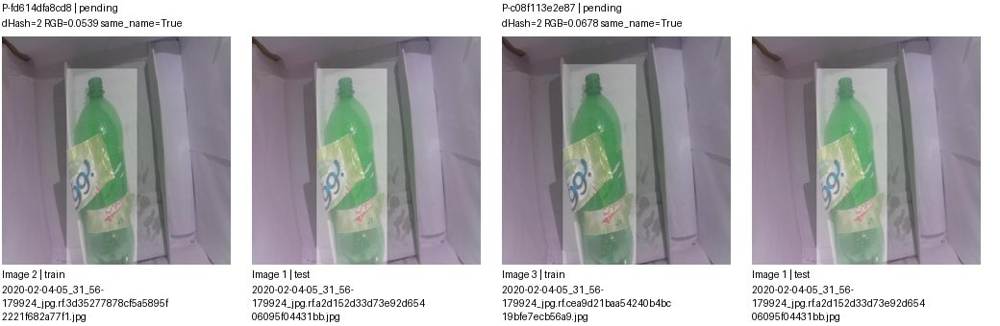

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-fd614dfa8cd8,images/train/2020-02-04-05_31_56-179924_jpg.rf.3d35277878cf5a5895f2221f682a77f1.jpg,images/test/2020-02-04-05_31_56-179924_jpg.rf.a2d152d33d73e92d65406095f04431bb.jpg,pending,
P-c08f113e2e87,images/train/2020-02-04-05_31_56-179924_jpg.rf.cea9d21baa54240b4bc19bfe7ecb56a9.jpg,images/test/2020-02-04-05_31_56-179924_jpg.rf.a2d152d33d73e92d65406095f04431bb.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 84/166 G-d1f5a044fb5d | 3 ảnh, 2 cặp
Split: {'test': 1, 'train': 2}
Quyết định: {'pending': 2}
Ảnh trang 1/1; cặp trang 1/1. Nhóm liên thông không phải kết luận trùng.


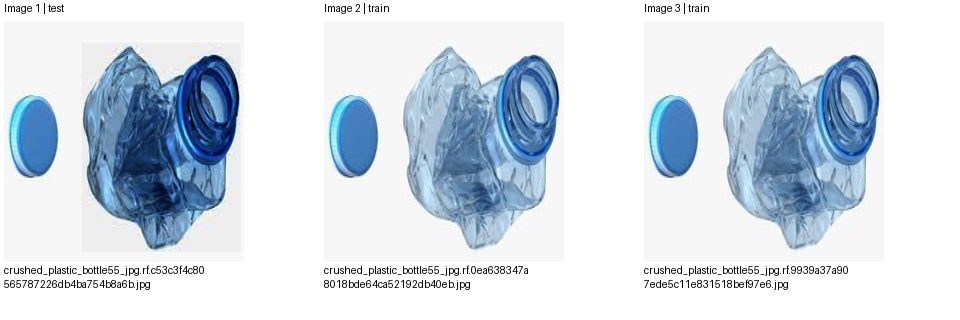

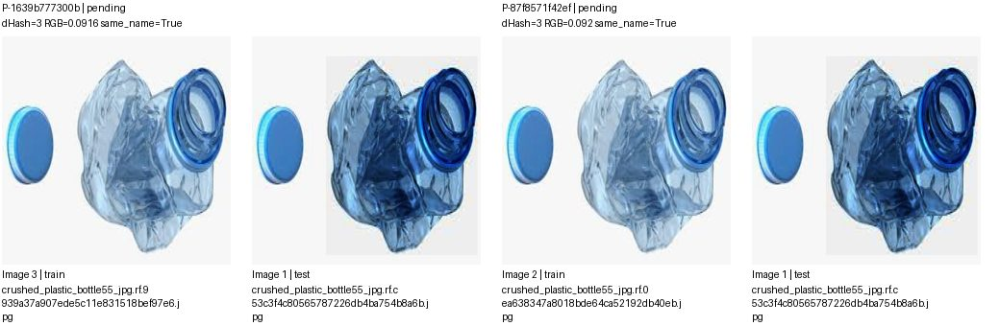

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-1639b777300b,images/train/crushed_plastic_bottle55_jpg.rf.9939a37a907ede5c11e831518bef97e6.jpg,images/test/crushed_plastic_bottle55_jpg.rf.c53c3f4c80565787226db4ba754b8a6b.jpg,pending,
P-87f8571f42ef,images/train/crushed_plastic_bottle55_jpg.rf.0ea638347a8018bde64ca52192db40eb.jpg,images/test/crushed_plastic_bottle55_jpg.rf.c53c3f4c80565787226db4ba754b8a6b.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 85/166 G-77d523cfff9a | 4 ảnh, 3 cặp
Split: {'test': 1, 'train': 3}
Quyết định: {'pending': 3}
Ảnh trang 1/1; cặp trang 1/1. Nhóm liên thông không phải kết luận trùng.


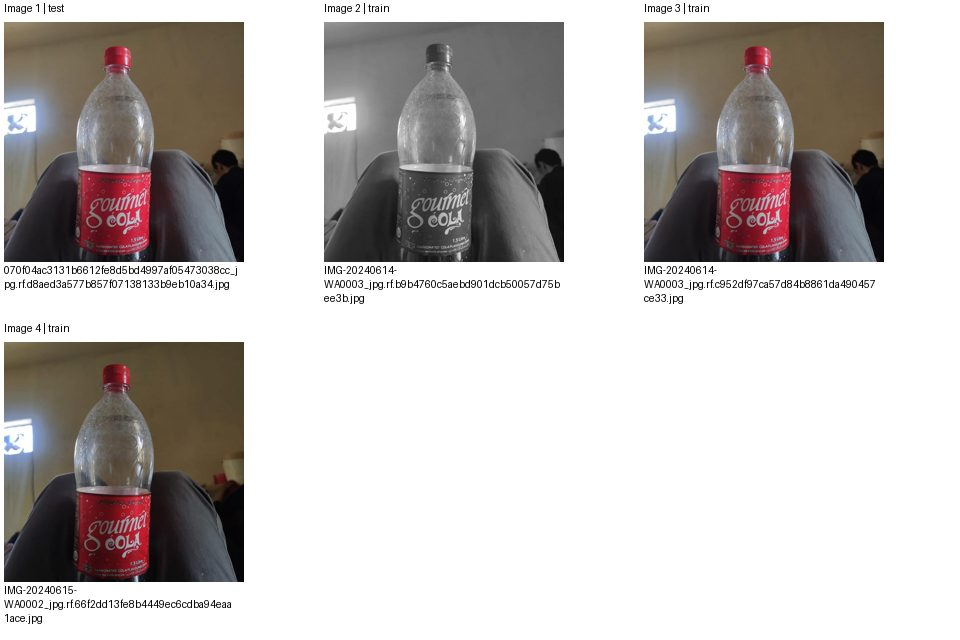

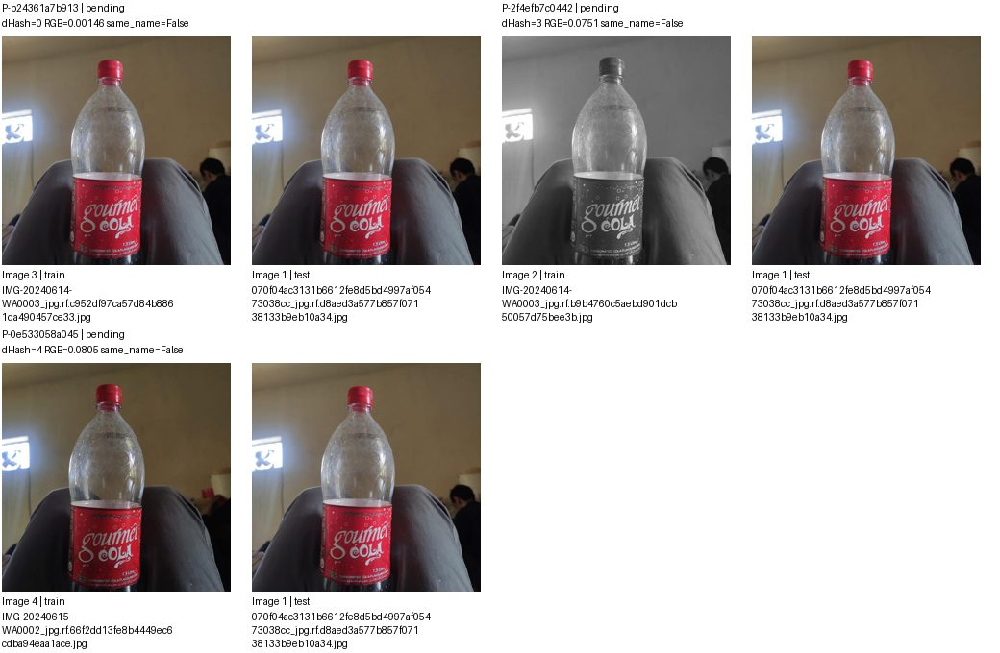

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-b24361a7b913,images/train/IMG-20240614-WA0003_jpg.rf.c952df97ca57d84b8861da490457ce33.jpg,images/test/070f04ac3131b6612fe8d5bd4997af05473038cc_jpg.rf.d8aed3a577b857f07138133b9eb10a34.jpg,pending,
P-2f4efb7c0442,images/train/IMG-20240614-WA0003_jpg.rf.b9b4760c5aebd901dcb50057d75bee3b.jpg,images/test/070f04ac3131b6612fe8d5bd4997af05473038cc_jpg.rf.d8aed3a577b857f07138133b9eb10a34.jpg,pending,
P-0e533058a045,images/train/IMG-20240615-WA0002_jpg.rf.66f2dd13fe8b4449ec6cdba94eaa1ace.jpg,images/test/070f04ac3131b6612fe8d5bd4997af05473038cc_jpg.rf.d8aed3a577b857f07138133b9eb10a34.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 86/166 G-9fc66e8d9424 | 3 ảnh, 2 cặp
Split: {'train': 1, 'val': 2}
Quyết định: {'pending': 2}
Ảnh trang 1/1; cặp trang 1/1. Nhóm liên thông không phải kết luận trùng.


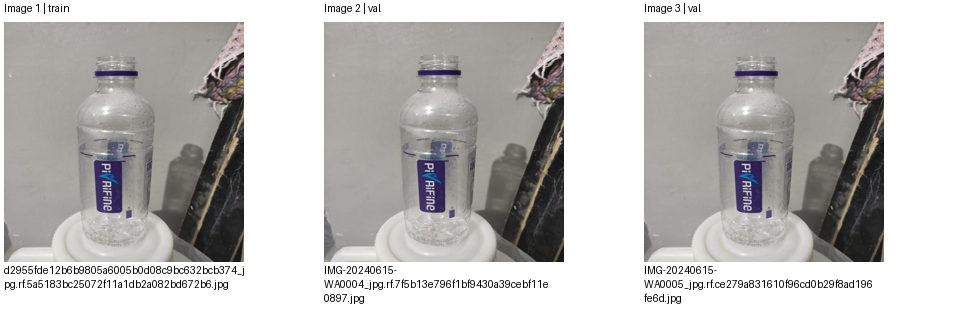

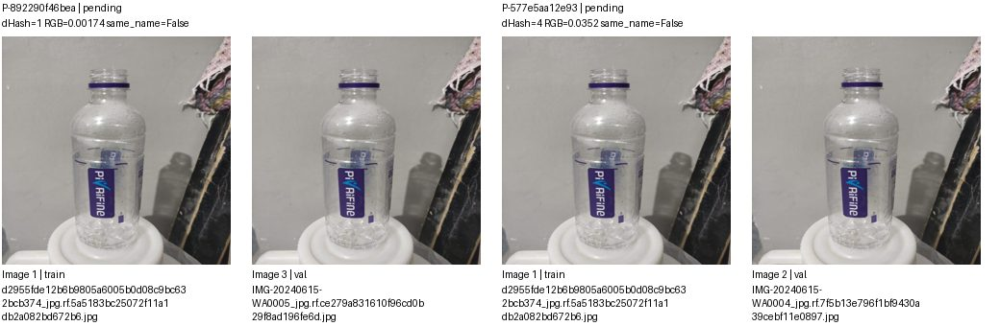

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-892290f46bea,images/train/d2955fde12b6b9805a6005b0d08c9bc632bcb374_jpg.rf.5a5183bc25072f11a1db2a082bd672b6.jpg,images/val/IMG-20240615-WA0005_jpg.rf.ce279a831610f96cd0b29f8ad196fe6d.jpg,pending,
P-577e5aa12e93,images/train/d2955fde12b6b9805a6005b0d08c9bc632bcb374_jpg.rf.5a5183bc25072f11a1db2a082bd672b6.jpg,images/val/IMG-20240615-WA0004_jpg.rf.7f5b13e796f1bf9430a39cebf11e0897.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 87/166 G-b156b25de070 | 12 ảnh, 16 cặp
Split: {'train': 9, 'val': 3}
Quyết định: {'pending': 16}
Ảnh trang 1/2; cặp trang 1/4. Nhóm liên thông không phải kết luận trùng.


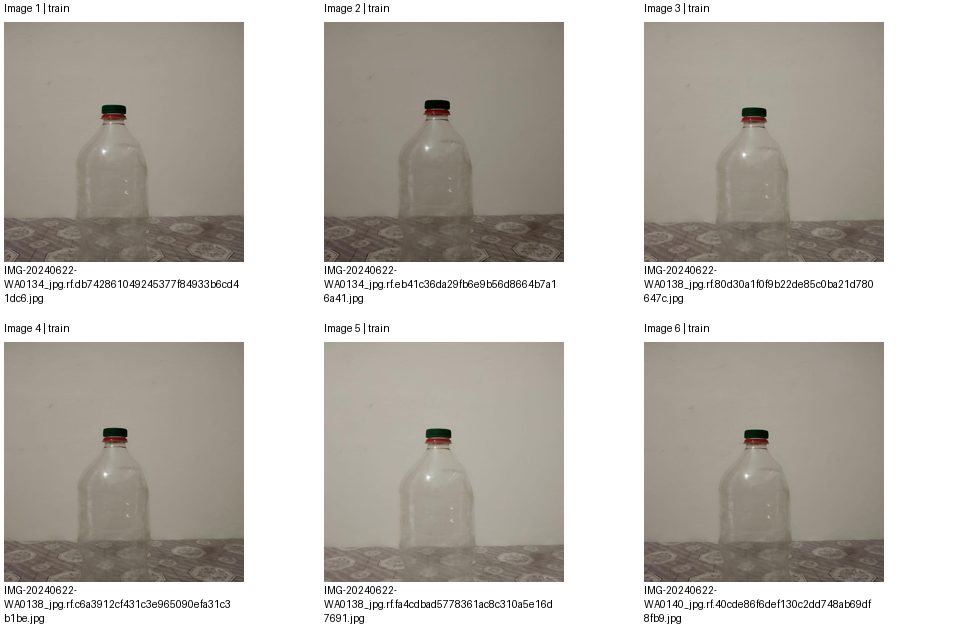

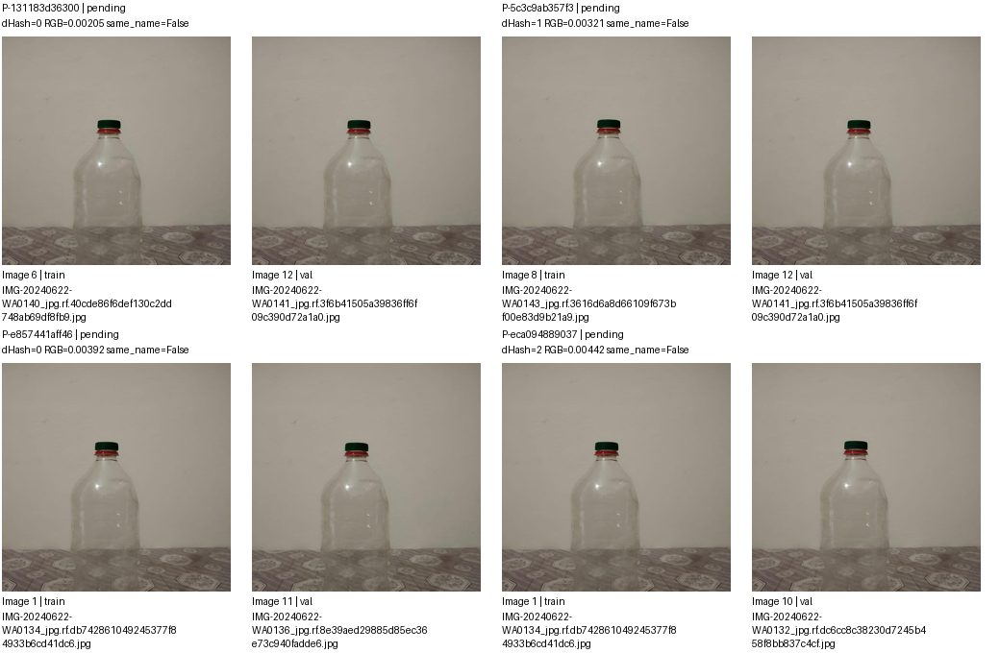

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-131183d36300,images/train/IMG-20240622-WA0140_jpg.rf.40cde86f6def130c2dd748ab69df8fb9.jpg,images/val/IMG-20240622-WA0141_jpg.rf.3f6b41505a39836ff6f09c390d72a1a0.jpg,pending,
P-5c3c9ab357f3,images/train/IMG-20240622-WA0143_jpg.rf.3616d6a8d66109f673bf00e83d9b21a9.jpg,images/val/IMG-20240622-WA0141_jpg.rf.3f6b41505a39836ff6f09c390d72a1a0.jpg,pending,
P-e857441aff46,images/train/IMG-20240622-WA0134_jpg.rf.db742861049245377f84933b6cd41dc6.jpg,images/val/IMG-20240622-WA0136_jpg.rf.8e39aed29885d85ec36e73c940fadde6.jpg,pending,
P-eca094889037,images/train/IMG-20240622-WA0134_jpg.rf.db742861049245377f84933b6cd41dc6.jpg,images/val/IMG-20240622-WA0132_jpg.rf.dc6cc8c38230d7245b458f8bb837c4cf.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 87/166 G-b156b25de070 | 12 ảnh, 16 cặp
Split: {'train': 9, 'val': 3}
Quyết định: {'pending': 16}
Ảnh trang 2/2; cặp trang 2/4. Nhóm liên thông không phải kết luận trùng.


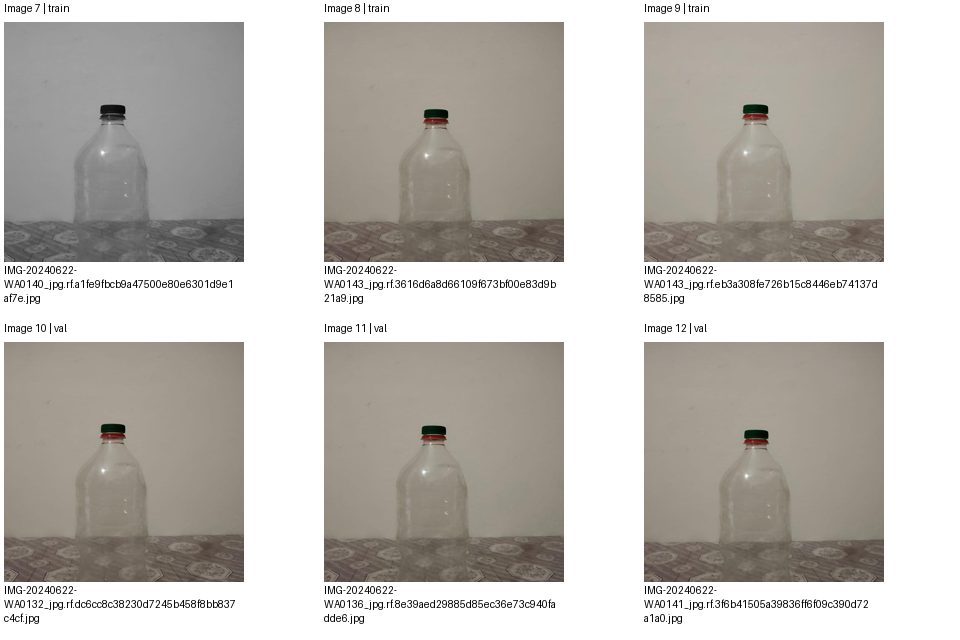

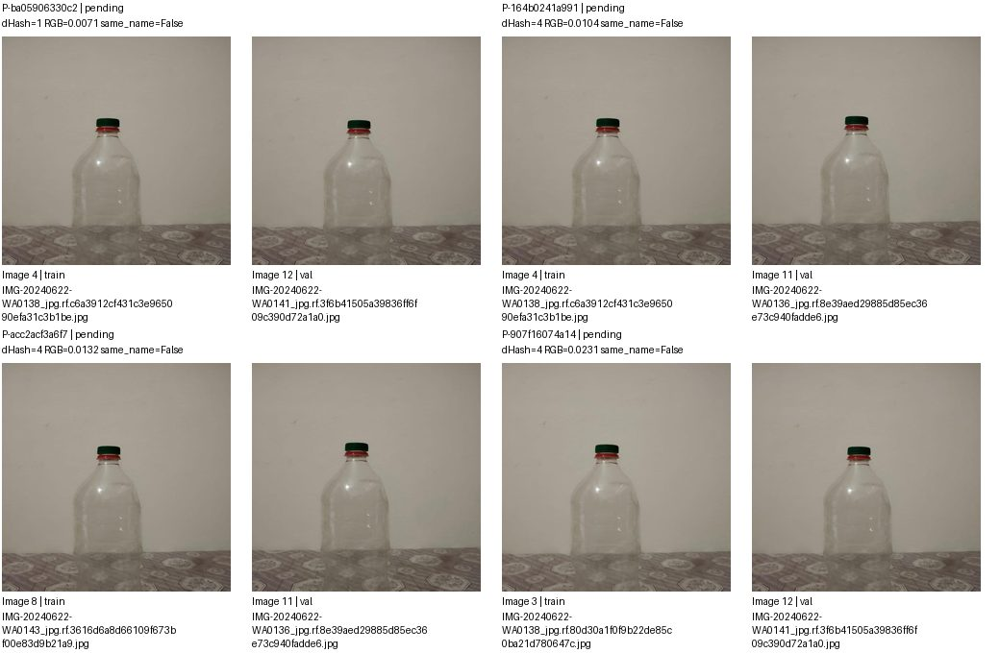

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-ba05906330c2,images/train/IMG-20240622-WA0138_jpg.rf.c6a3912cf431c3e965090efa31c3b1be.jpg,images/val/IMG-20240622-WA0141_jpg.rf.3f6b41505a39836ff6f09c390d72a1a0.jpg,pending,
P-164b0241a991,images/train/IMG-20240622-WA0138_jpg.rf.c6a3912cf431c3e965090efa31c3b1be.jpg,images/val/IMG-20240622-WA0136_jpg.rf.8e39aed29885d85ec36e73c940fadde6.jpg,pending,
P-acc2acf3a6f7,images/train/IMG-20240622-WA0143_jpg.rf.3616d6a8d66109f673bf00e83d9b21a9.jpg,images/val/IMG-20240622-WA0136_jpg.rf.8e39aed29885d85ec36e73c940fadde6.jpg,pending,
P-907f16074a14,images/train/IMG-20240622-WA0138_jpg.rf.80d30a1f0f9b22de85c0ba21d780647c.jpg,images/val/IMG-20240622-WA0141_jpg.rf.3f6b41505a39836ff6f09c390d72a1a0.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 87/166 G-b156b25de070 | 12 ảnh, 16 cặp
Split: {'train': 9, 'val': 3}
Quyết định: {'pending': 16}
Ảnh trang None/2; cặp trang 3/4. Nhóm liên thông không phải kết luận trùng.


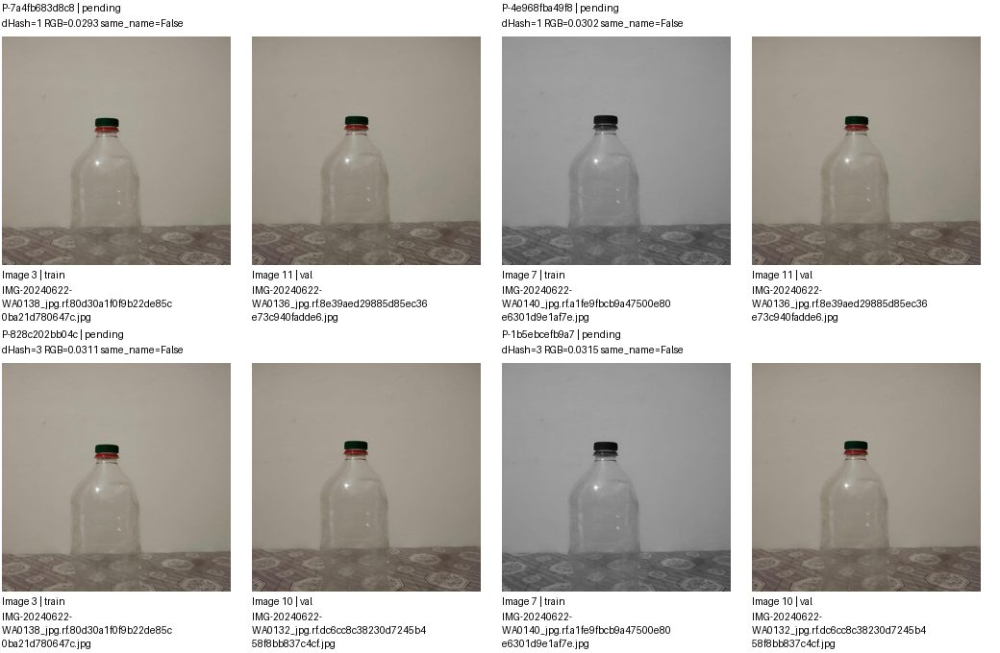

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-7a4fb683d8c8,images/train/IMG-20240622-WA0138_jpg.rf.80d30a1f0f9b22de85c0ba21d780647c.jpg,images/val/IMG-20240622-WA0136_jpg.rf.8e39aed29885d85ec36e73c940fadde6.jpg,pending,
P-4e968fba49f8,images/train/IMG-20240622-WA0140_jpg.rf.a1fe9fbcb9a47500e80e6301d9e1af7e.jpg,images/val/IMG-20240622-WA0136_jpg.rf.8e39aed29885d85ec36e73c940fadde6.jpg,pending,
P-828c202bb04c,images/train/IMG-20240622-WA0138_jpg.rf.80d30a1f0f9b22de85c0ba21d780647c.jpg,images/val/IMG-20240622-WA0132_jpg.rf.dc6cc8c38230d7245b458f8bb837c4cf.jpg,pending,
P-1b5ebcefb9a7,images/train/IMG-20240622-WA0140_jpg.rf.a1fe9fbcb9a47500e80e6301d9e1af7e.jpg,images/val/IMG-20240622-WA0132_jpg.rf.dc6cc8c38230d7245b458f8bb837c4cf.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 87/166 G-b156b25de070 | 12 ảnh, 16 cặp
Split: {'train': 9, 'val': 3}
Quyết định: {'pending': 16}
Ảnh trang None/2; cặp trang 4/4. Nhóm liên thông không phải kết luận trùng.


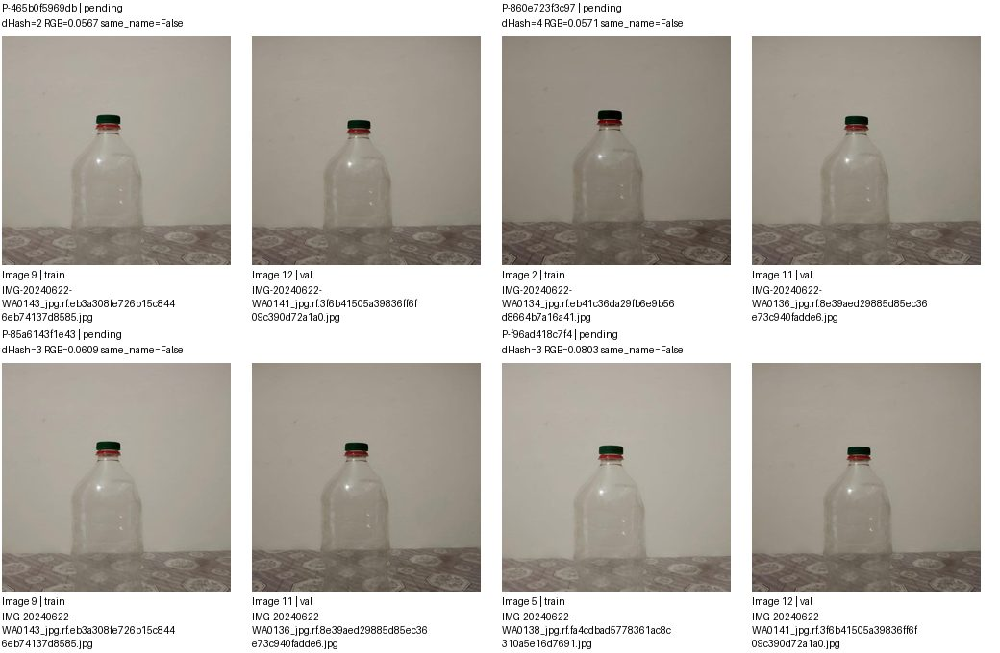

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-465b0f5969db,images/train/IMG-20240622-WA0143_jpg.rf.eb3a308fe726b15c8446eb74137d8585.jpg,images/val/IMG-20240622-WA0141_jpg.rf.3f6b41505a39836ff6f09c390d72a1a0.jpg,pending,
P-860e723f3c97,images/train/IMG-20240622-WA0134_jpg.rf.eb41c36da29fb6e9b56d8664b7a16a41.jpg,images/val/IMG-20240622-WA0136_jpg.rf.8e39aed29885d85ec36e73c940fadde6.jpg,pending,
P-85a6143f1e43,images/train/IMG-20240622-WA0143_jpg.rf.eb3a308fe726b15c8446eb74137d8585.jpg,images/val/IMG-20240622-WA0136_jpg.rf.8e39aed29885d85ec36e73c940fadde6.jpg,pending,
P-f96ad418c7f4,images/train/IMG-20240622-WA0138_jpg.rf.fa4cdbad5778361ac8c310a5e16d7691.jpg,images/val/IMG-20240622-WA0141_jpg.rf.3f6b41505a39836ff6f09c390d72a1a0.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 88/166 G-f4bef8242d52 | 60 ảnh, 147 cặp
Split: {'test': 7, 'train': 47, 'val': 6}
Quyết định: {'pending': 147}
Ảnh trang 1/10; cặp trang 1/37. Nhóm liên thông không phải kết luận trùng.


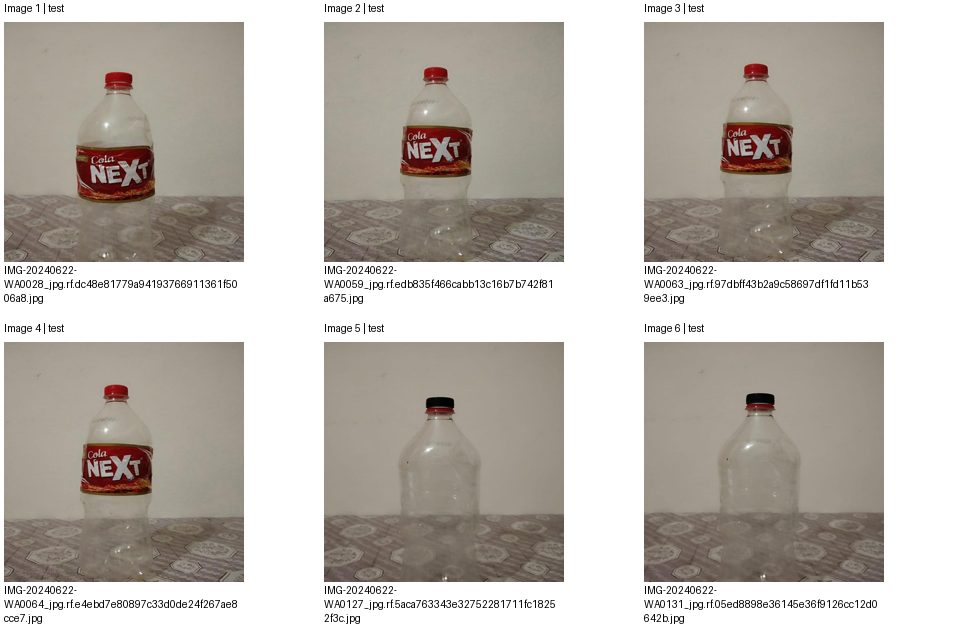

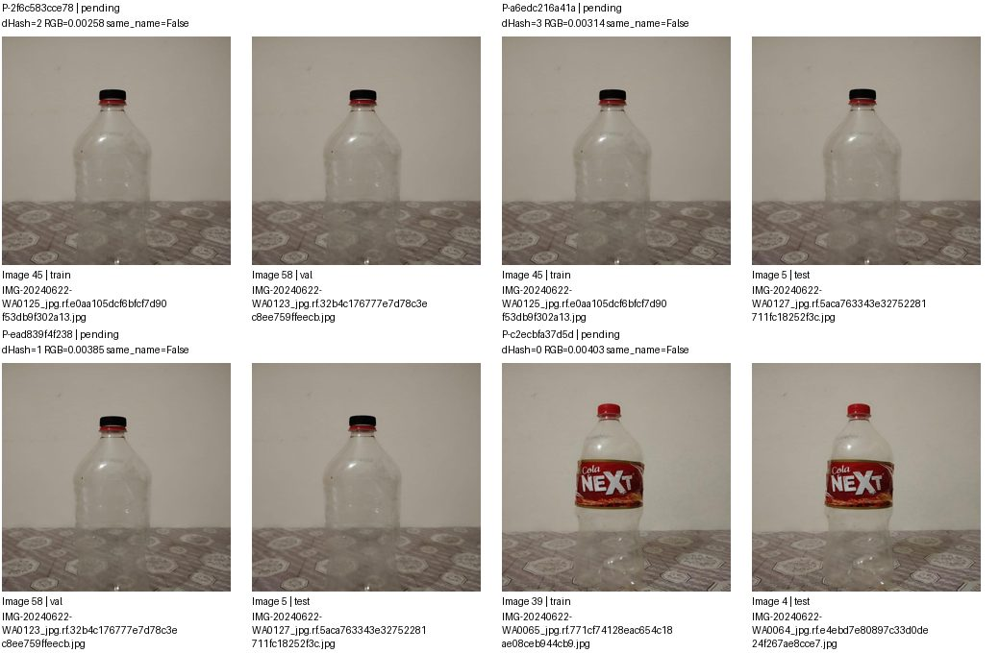

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-2f6c583cce78,images/train/IMG-20240622-WA0125_jpg.rf.e0aa105dcf6bfcf7d90f53db9f302a13.jpg,images/val/IMG-20240622-WA0123_jpg.rf.32b4c176777e7d78c3ec8ee759ffeecb.jpg,pending,
P-a6edc216a41a,images/train/IMG-20240622-WA0125_jpg.rf.e0aa105dcf6bfcf7d90f53db9f302a13.jpg,images/test/IMG-20240622-WA0127_jpg.rf.5aca763343e32752281711fc18252f3c.jpg,pending,
P-ead839f4f238,images/val/IMG-20240622-WA0123_jpg.rf.32b4c176777e7d78c3ec8ee759ffeecb.jpg,images/test/IMG-20240622-WA0127_jpg.rf.5aca763343e32752281711fc18252f3c.jpg,pending,
P-c2ecbfa37d5d,images/train/IMG-20240622-WA0065_jpg.rf.771cf74128eac654c18ae08ceb944cb9.jpg,images/test/IMG-20240622-WA0064_jpg.rf.e4ebd7e80897c33d0de24f267ae8cce7.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 88/166 G-f4bef8242d52 | 60 ảnh, 147 cặp
Split: {'test': 7, 'train': 47, 'val': 6}
Quyết định: {'pending': 147}
Ảnh trang 2/10; cặp trang 2/37. Nhóm liên thông không phải kết luận trùng.


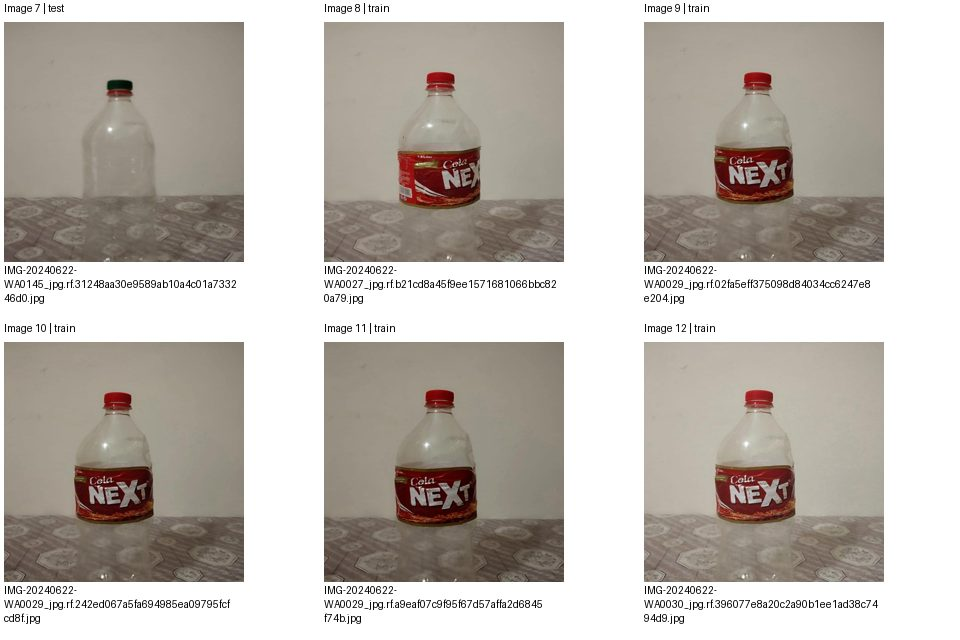

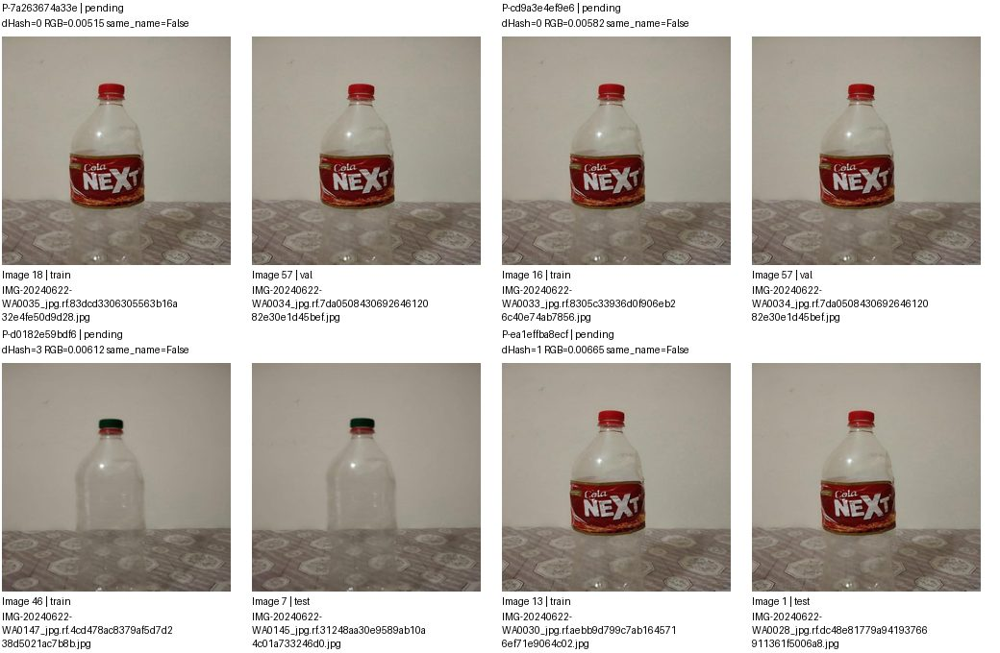

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-7a263674a33e,images/train/IMG-20240622-WA0035_jpg.rf.83dcd3306305563b16a32e4fe50d9d28.jpg,images/val/IMG-20240622-WA0034_jpg.rf.7da050843069264612082e30e1d45bef.jpg,pending,
P-cd9a3e4ef9e6,images/train/IMG-20240622-WA0033_jpg.rf.8305c33936d0f906eb26c40e74ab7856.jpg,images/val/IMG-20240622-WA0034_jpg.rf.7da050843069264612082e30e1d45bef.jpg,pending,
P-d0182e59bdf6,images/train/IMG-20240622-WA0147_jpg.rf.4cd478ac8379af5d7d238d5021ac7b8b.jpg,images/test/IMG-20240622-WA0145_jpg.rf.31248aa30e9589ab10a4c01a733246d0.jpg,pending,
P-ea1effba8ecf,images/train/IMG-20240622-WA0030_jpg.rf.aebb9d799c7ab1645716ef71e9064c02.jpg,images/test/IMG-20240622-WA0028_jpg.rf.dc48e81779a94193766911361f5006a8.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 88/166 G-f4bef8242d52 | 60 ảnh, 147 cặp
Split: {'test': 7, 'train': 47, 'val': 6}
Quyết định: {'pending': 147}
Ảnh trang 3/10; cặp trang 3/37. Nhóm liên thông không phải kết luận trùng.


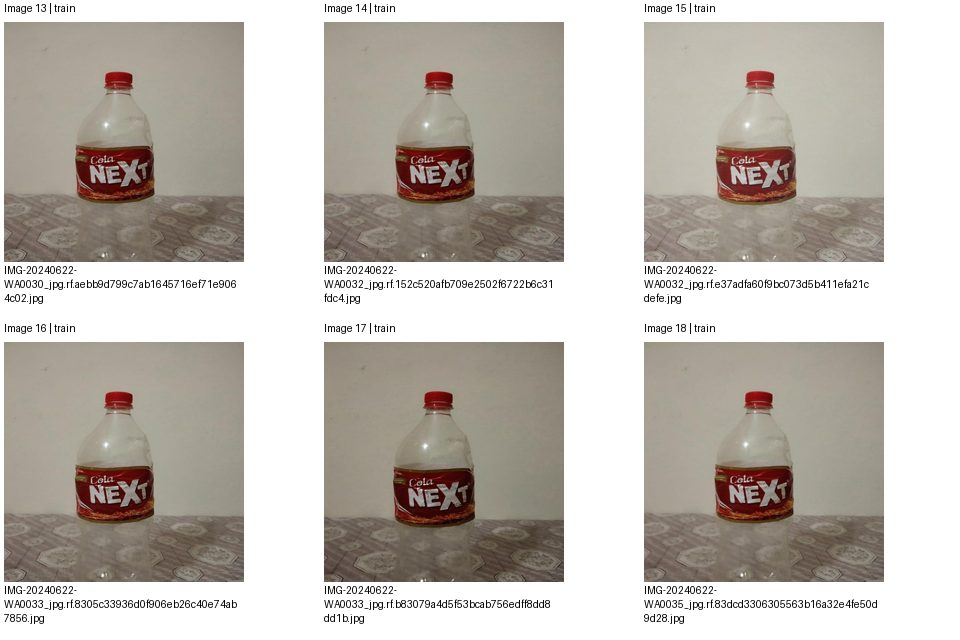

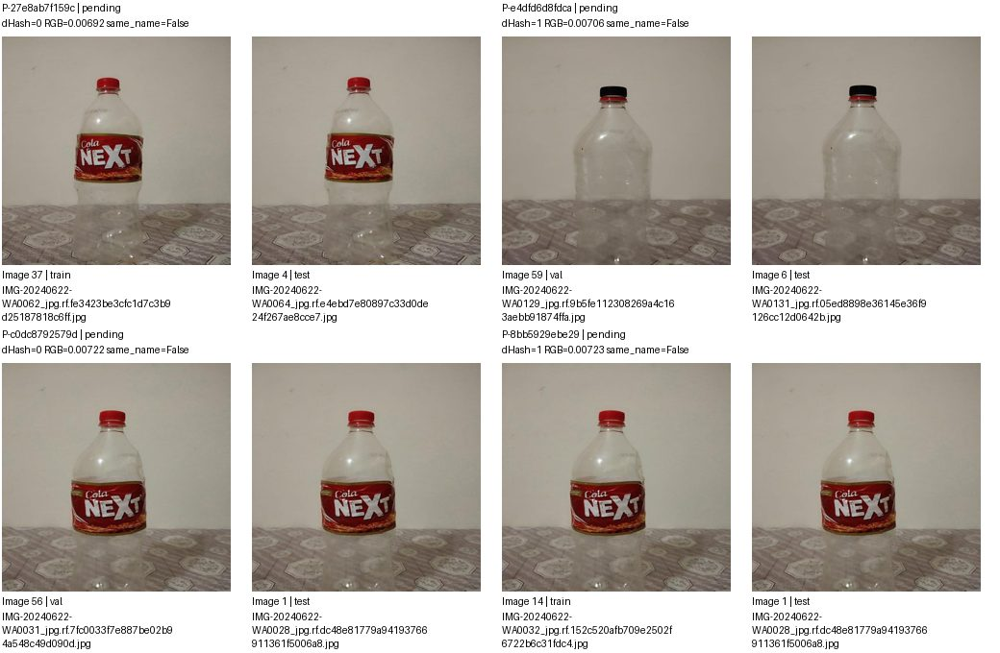

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-27e8ab7f159c,images/train/IMG-20240622-WA0062_jpg.rf.fe3423be3cfc1d7c3b9d25187818c6ff.jpg,images/test/IMG-20240622-WA0064_jpg.rf.e4ebd7e80897c33d0de24f267ae8cce7.jpg,pending,
P-e4dfd6d8fdca,images/val/IMG-20240622-WA0129_jpg.rf.9b5fe112308269a4c163aebb91874ffa.jpg,images/test/IMG-20240622-WA0131_jpg.rf.05ed8898e36145e36f9126cc12d0642b.jpg,pending,
P-c0dc8792579d,images/val/IMG-20240622-WA0031_jpg.rf.7fc0033f7e887be02b94a548c49d090d.jpg,images/test/IMG-20240622-WA0028_jpg.rf.dc48e81779a94193766911361f5006a8.jpg,pending,
P-8bb5929ebe29,images/train/IMG-20240622-WA0032_jpg.rf.152c520afb709e2502f6722b6c31fdc4.jpg,images/test/IMG-20240622-WA0028_jpg.rf.dc48e81779a94193766911361f5006a8.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 88/166 G-f4bef8242d52 | 60 ảnh, 147 cặp
Split: {'test': 7, 'train': 47, 'val': 6}
Quyết định: {'pending': 147}
Ảnh trang 4/10; cặp trang 4/37. Nhóm liên thông không phải kết luận trùng.


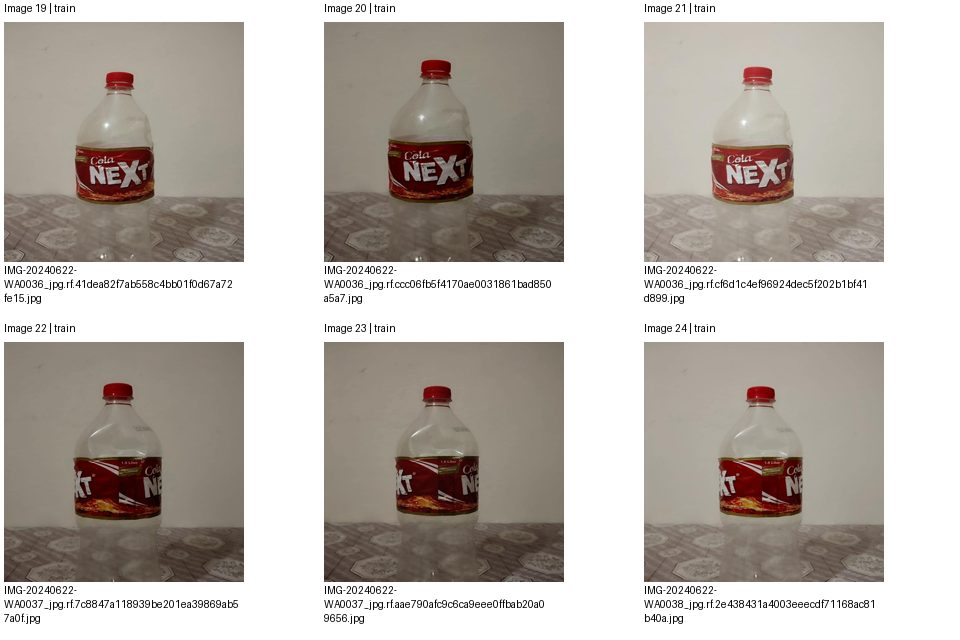

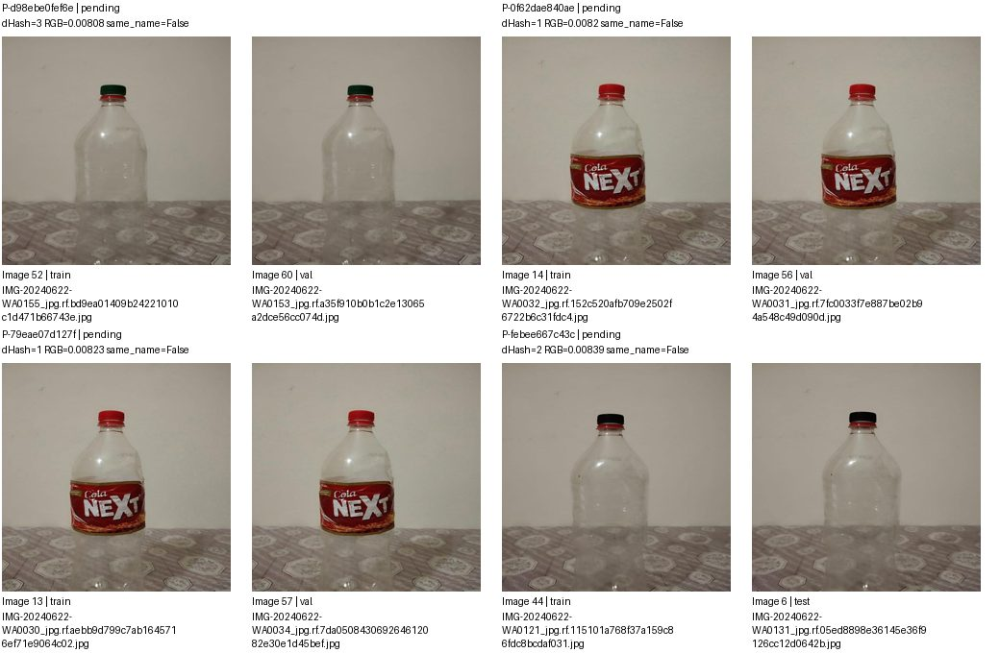

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-d98ebe0fef6e,images/train/IMG-20240622-WA0155_jpg.rf.bd9ea01409b24221010c1d471b66743e.jpg,images/val/IMG-20240622-WA0153_jpg.rf.a35f910b0b1c2e13065a2dce56cc074d.jpg,pending,
P-0f62dae840ae,images/train/IMG-20240622-WA0032_jpg.rf.152c520afb709e2502f6722b6c31fdc4.jpg,images/val/IMG-20240622-WA0031_jpg.rf.7fc0033f7e887be02b94a548c49d090d.jpg,pending,
P-79eae07d127f,images/train/IMG-20240622-WA0030_jpg.rf.aebb9d799c7ab1645716ef71e9064c02.jpg,images/val/IMG-20240622-WA0034_jpg.rf.7da050843069264612082e30e1d45bef.jpg,pending,
P-febee667c43c,images/train/IMG-20240622-WA0121_jpg.rf.115101a768f37a159c86fdc8bcdaf031.jpg,images/test/IMG-20240622-WA0131_jpg.rf.05ed8898e36145e36f9126cc12d0642b.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 88/166 G-f4bef8242d52 | 60 ảnh, 147 cặp
Split: {'test': 7, 'train': 47, 'val': 6}
Quyết định: {'pending': 147}
Ảnh trang 5/10; cặp trang 5/37. Nhóm liên thông không phải kết luận trùng.


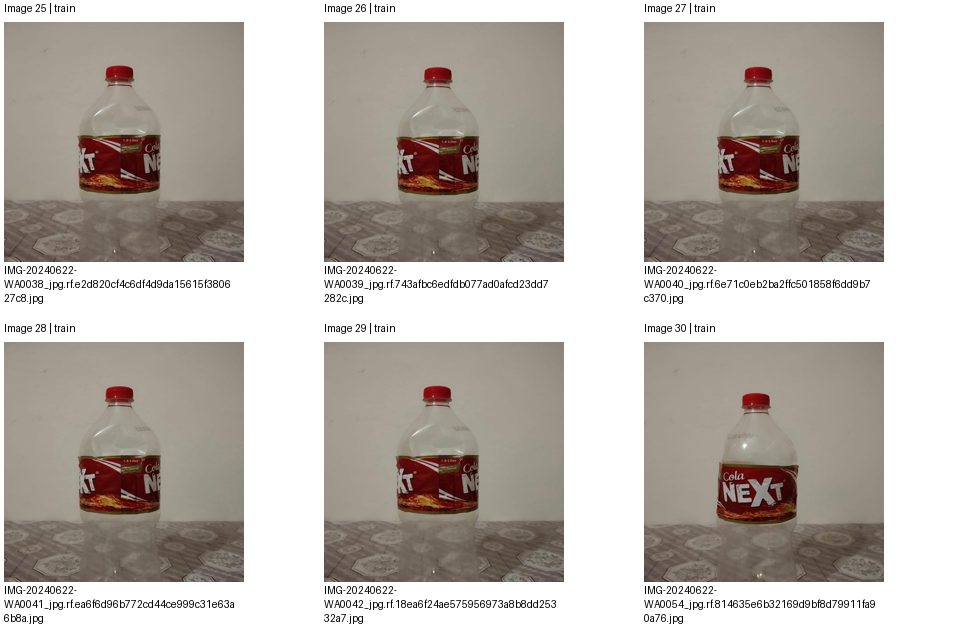

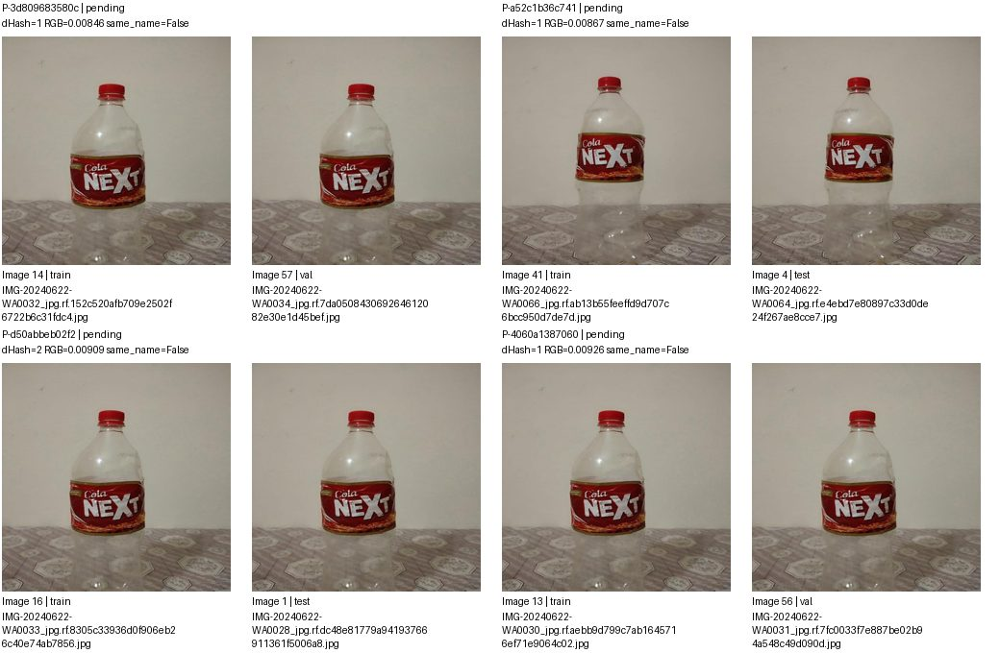

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-3d809683580c,images/train/IMG-20240622-WA0032_jpg.rf.152c520afb709e2502f6722b6c31fdc4.jpg,images/val/IMG-20240622-WA0034_jpg.rf.7da050843069264612082e30e1d45bef.jpg,pending,
P-a52c1b36c741,images/train/IMG-20240622-WA0066_jpg.rf.ab13b55feeffd9d707c6bcc950d7de7d.jpg,images/test/IMG-20240622-WA0064_jpg.rf.e4ebd7e80897c33d0de24f267ae8cce7.jpg,pending,
P-d50abbeb02f2,images/train/IMG-20240622-WA0033_jpg.rf.8305c33936d0f906eb26c40e74ab7856.jpg,images/test/IMG-20240622-WA0028_jpg.rf.dc48e81779a94193766911361f5006a8.jpg,pending,
P-4060a1387060,images/train/IMG-20240622-WA0030_jpg.rf.aebb9d799c7ab1645716ef71e9064c02.jpg,images/val/IMG-20240622-WA0031_jpg.rf.7fc0033f7e887be02b94a548c49d090d.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 88/166 G-f4bef8242d52 | 60 ảnh, 147 cặp
Split: {'test': 7, 'train': 47, 'val': 6}
Quyết định: {'pending': 147}
Ảnh trang 6/10; cặp trang 6/37. Nhóm liên thông không phải kết luận trùng.


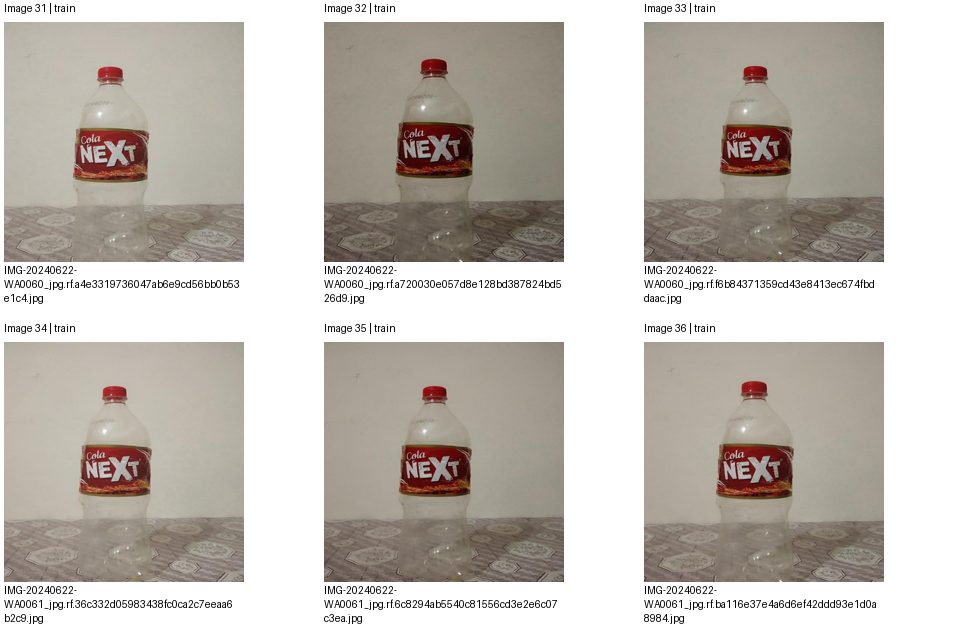

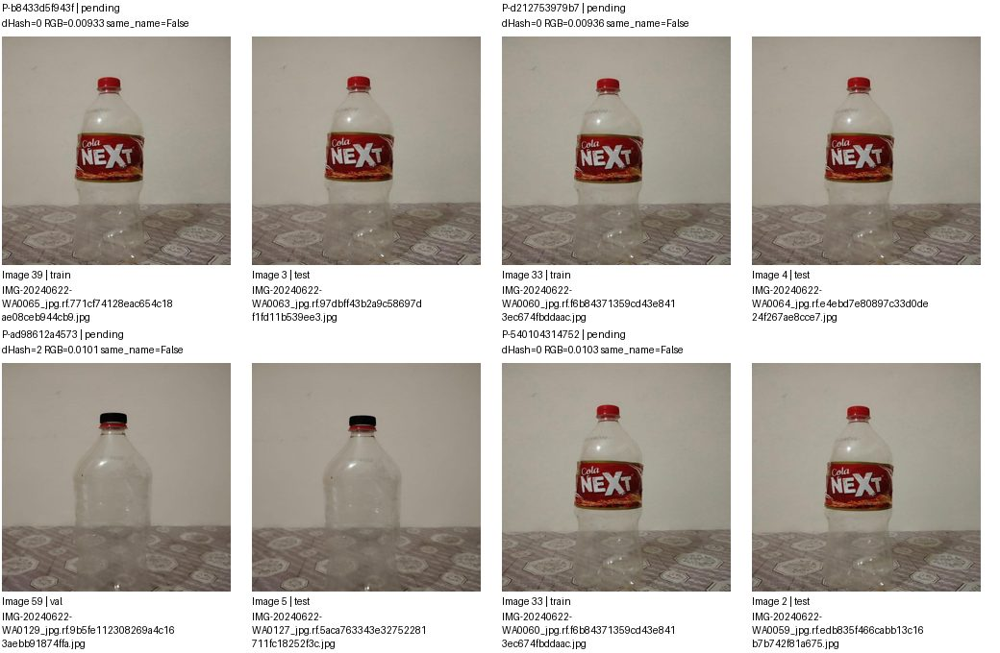

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-b8433d5f943f,images/train/IMG-20240622-WA0065_jpg.rf.771cf74128eac654c18ae08ceb944cb9.jpg,images/test/IMG-20240622-WA0063_jpg.rf.97dbff43b2a9c58697df1fd11b539ee3.jpg,pending,
P-d212753979b7,images/train/IMG-20240622-WA0060_jpg.rf.f6b84371359cd43e8413ec674fbddaac.jpg,images/test/IMG-20240622-WA0064_jpg.rf.e4ebd7e80897c33d0de24f267ae8cce7.jpg,pending,
P-ad98612a4573,images/val/IMG-20240622-WA0129_jpg.rf.9b5fe112308269a4c163aebb91874ffa.jpg,images/test/IMG-20240622-WA0127_jpg.rf.5aca763343e32752281711fc18252f3c.jpg,pending,
P-540104314752,images/train/IMG-20240622-WA0060_jpg.rf.f6b84371359cd43e8413ec674fbddaac.jpg,images/test/IMG-20240622-WA0059_jpg.rf.edb835f466cabb13c16b7b742f81a675.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 88/166 G-f4bef8242d52 | 60 ảnh, 147 cặp
Split: {'test': 7, 'train': 47, 'val': 6}
Quyết định: {'pending': 147}
Ảnh trang 7/10; cặp trang 7/37. Nhóm liên thông không phải kết luận trùng.


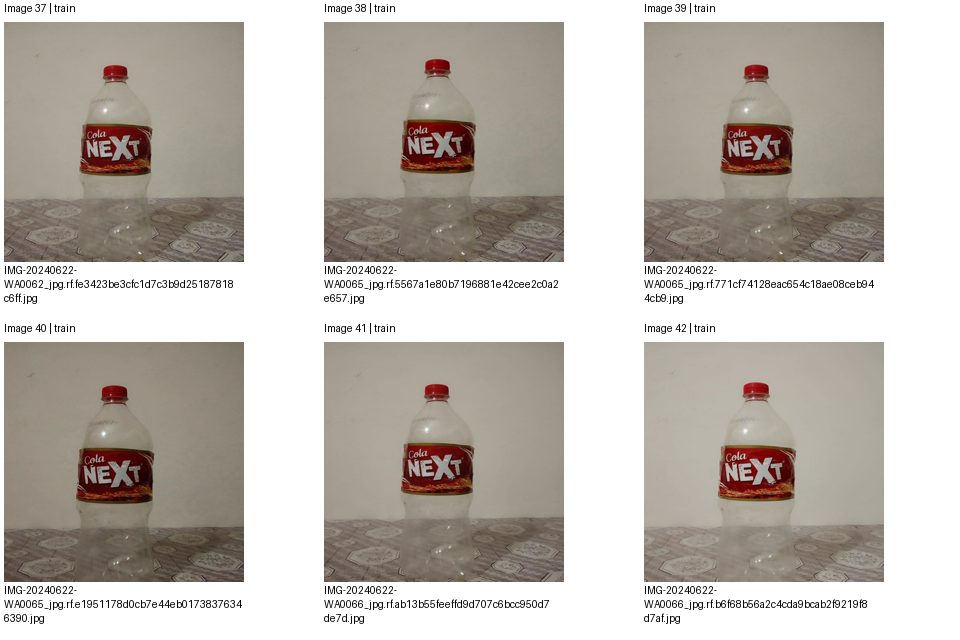

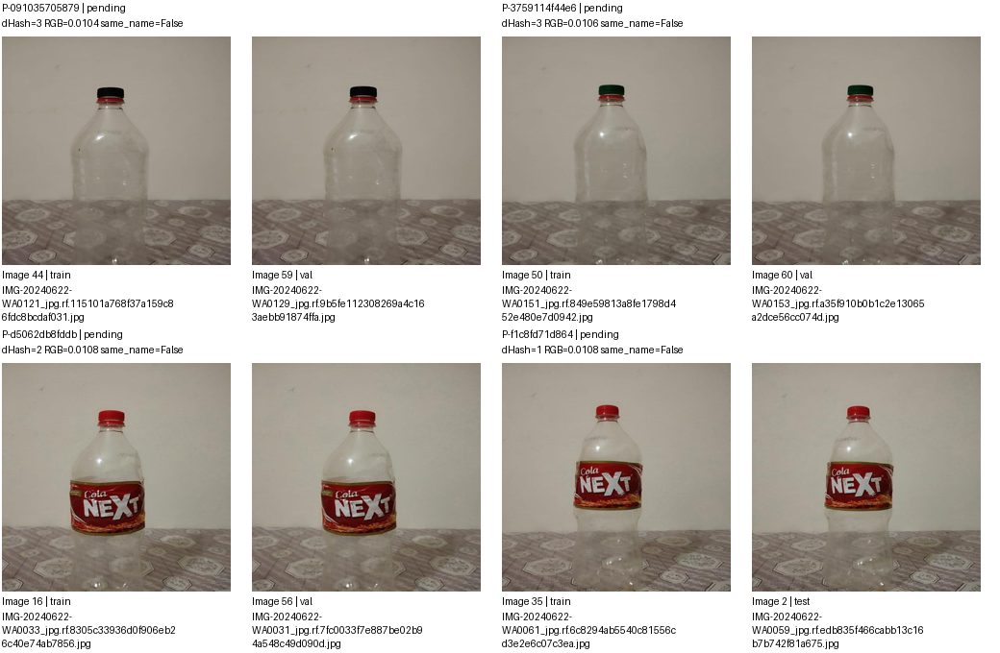

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-091035705879,images/train/IMG-20240622-WA0121_jpg.rf.115101a768f37a159c86fdc8bcdaf031.jpg,images/val/IMG-20240622-WA0129_jpg.rf.9b5fe112308269a4c163aebb91874ffa.jpg,pending,
P-3759114f44e6,images/train/IMG-20240622-WA0151_jpg.rf.849e59813a8fe1798d452e480e7d0942.jpg,images/val/IMG-20240622-WA0153_jpg.rf.a35f910b0b1c2e13065a2dce56cc074d.jpg,pending,
P-d5062db8fddb,images/train/IMG-20240622-WA0033_jpg.rf.8305c33936d0f906eb26c40e74ab7856.jpg,images/val/IMG-20240622-WA0031_jpg.rf.7fc0033f7e887be02b94a548c49d090d.jpg,pending,
P-f1c8fd71d864,images/train/IMG-20240622-WA0061_jpg.rf.6c8294ab5540c81556cd3e2e6c07c3ea.jpg,images/test/IMG-20240622-WA0059_jpg.rf.edb835f466cabb13c16b7b742f81a675.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 88/166 G-f4bef8242d52 | 60 ảnh, 147 cặp
Split: {'test': 7, 'train': 47, 'val': 6}
Quyết định: {'pending': 147}
Ảnh trang 8/10; cặp trang 8/37. Nhóm liên thông không phải kết luận trùng.


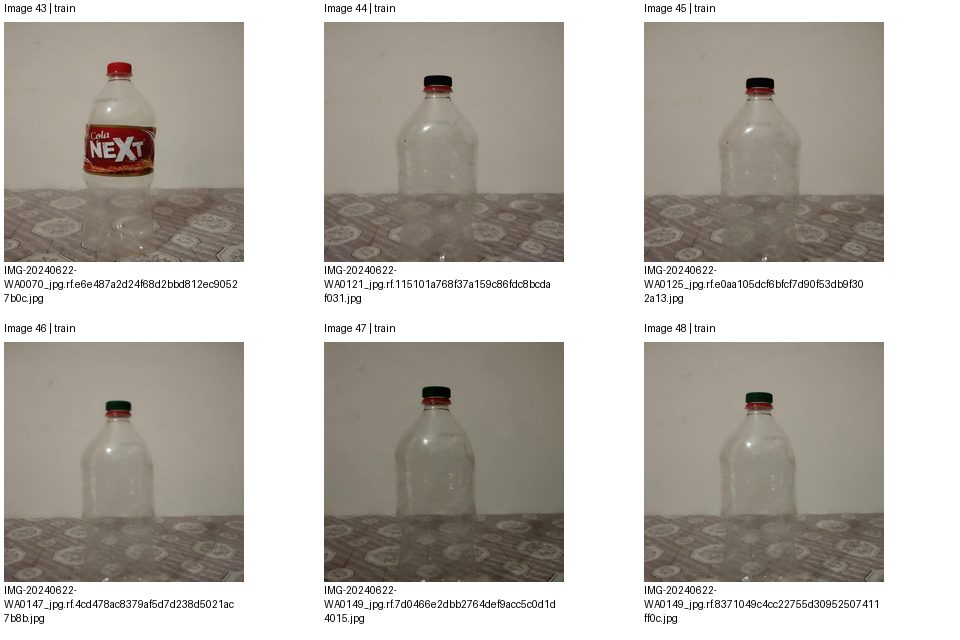

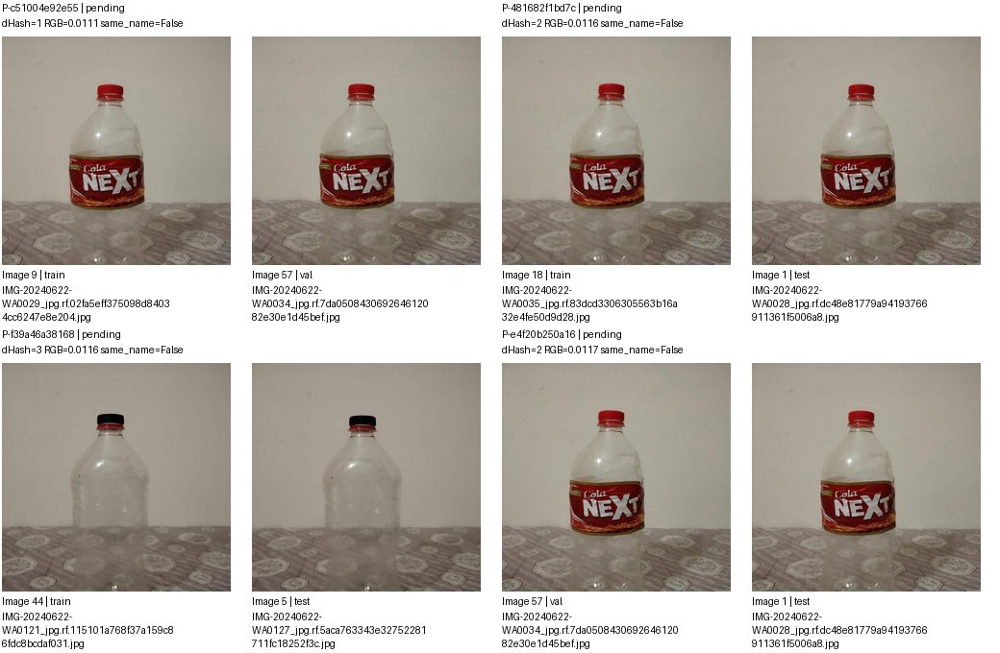

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-c51004e92e55,images/train/IMG-20240622-WA0029_jpg.rf.02fa5eff375098d84034cc6247e8e204.jpg,images/val/IMG-20240622-WA0034_jpg.rf.7da050843069264612082e30e1d45bef.jpg,pending,
P-481682f1bd7c,images/train/IMG-20240622-WA0035_jpg.rf.83dcd3306305563b16a32e4fe50d9d28.jpg,images/test/IMG-20240622-WA0028_jpg.rf.dc48e81779a94193766911361f5006a8.jpg,pending,
P-f39a46a38168,images/train/IMG-20240622-WA0121_jpg.rf.115101a768f37a159c86fdc8bcdaf031.jpg,images/test/IMG-20240622-WA0127_jpg.rf.5aca763343e32752281711fc18252f3c.jpg,pending,
P-e4f20b250a16,images/val/IMG-20240622-WA0034_jpg.rf.7da050843069264612082e30e1d45bef.jpg,images/test/IMG-20240622-WA0028_jpg.rf.dc48e81779a94193766911361f5006a8.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 88/166 G-f4bef8242d52 | 60 ảnh, 147 cặp
Split: {'test': 7, 'train': 47, 'val': 6}
Quyết định: {'pending': 147}
Ảnh trang 9/10; cặp trang 9/37. Nhóm liên thông không phải kết luận trùng.


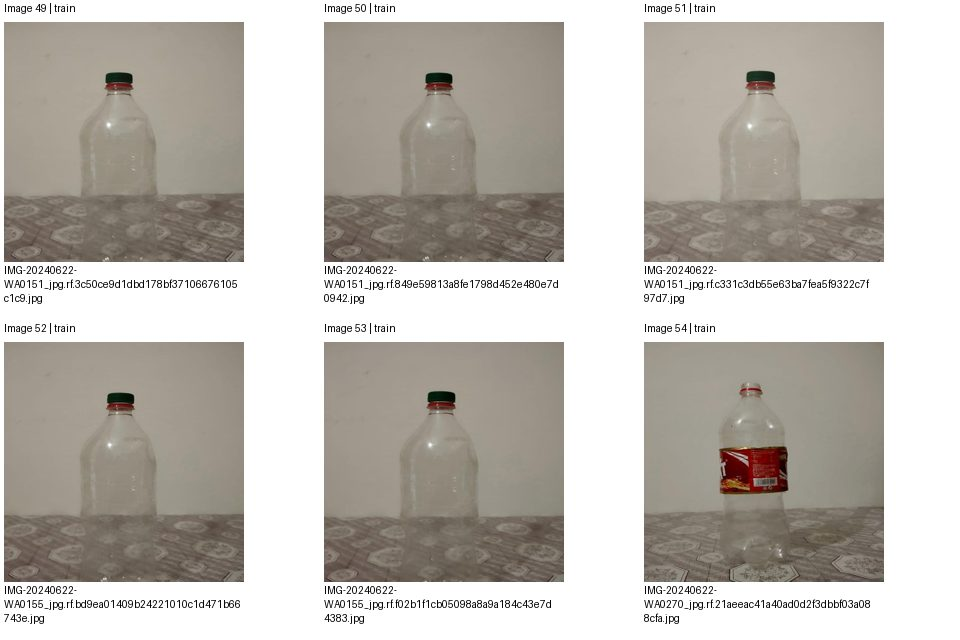

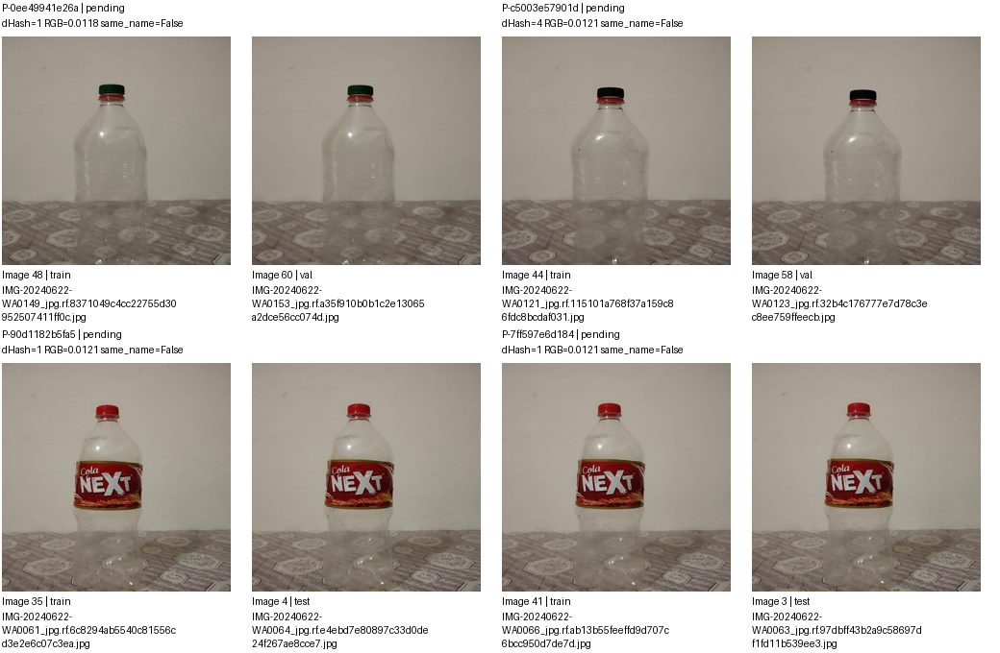

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-0ee49941e26a,images/train/IMG-20240622-WA0149_jpg.rf.8371049c4cc22755d30952507411ff0c.jpg,images/val/IMG-20240622-WA0153_jpg.rf.a35f910b0b1c2e13065a2dce56cc074d.jpg,pending,
P-c5003e57901d,images/train/IMG-20240622-WA0121_jpg.rf.115101a768f37a159c86fdc8bcdaf031.jpg,images/val/IMG-20240622-WA0123_jpg.rf.32b4c176777e7d78c3ec8ee759ffeecb.jpg,pending,
P-90d1182b5fa5,images/train/IMG-20240622-WA0061_jpg.rf.6c8294ab5540c81556cd3e2e6c07c3ea.jpg,images/test/IMG-20240622-WA0064_jpg.rf.e4ebd7e80897c33d0de24f267ae8cce7.jpg,pending,
P-7ff597e6d184,images/train/IMG-20240622-WA0066_jpg.rf.ab13b55feeffd9d707c6bcc950d7de7d.jpg,images/test/IMG-20240622-WA0063_jpg.rf.97dbff43b2a9c58697df1fd11b539ee3.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 88/166 G-f4bef8242d52 | 60 ảnh, 147 cặp
Split: {'test': 7, 'train': 47, 'val': 6}
Quyết định: {'pending': 147}
Ảnh trang 10/10; cặp trang 10/37. Nhóm liên thông không phải kết luận trùng.


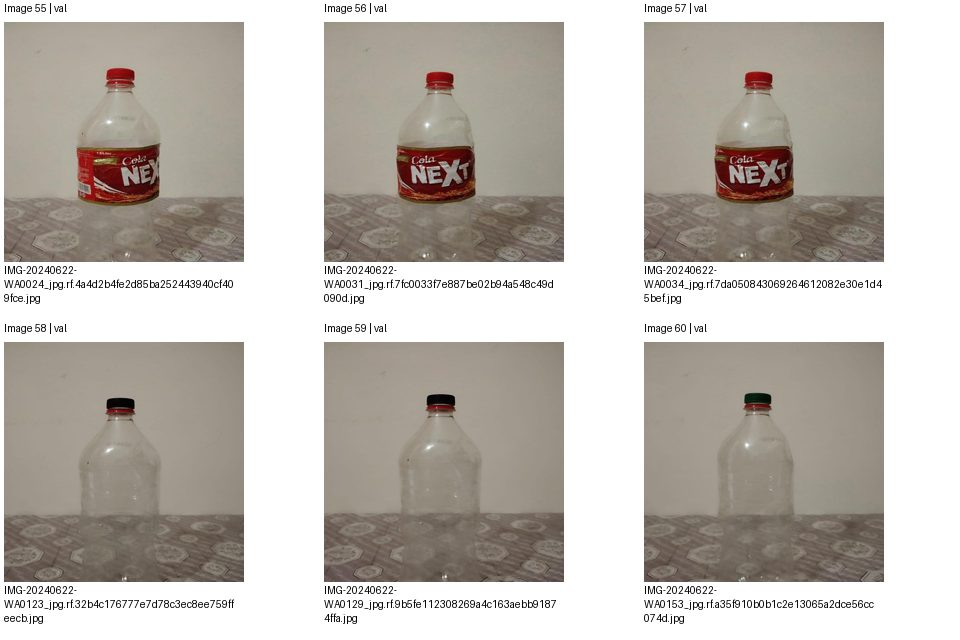

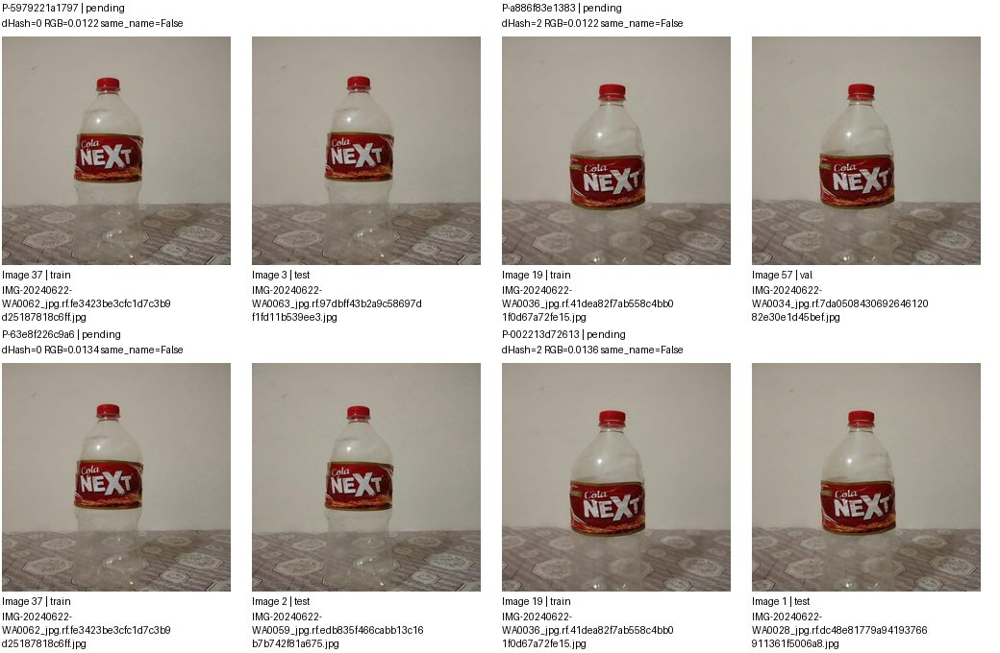

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-5979221a1797,images/train/IMG-20240622-WA0062_jpg.rf.fe3423be3cfc1d7c3b9d25187818c6ff.jpg,images/test/IMG-20240622-WA0063_jpg.rf.97dbff43b2a9c58697df1fd11b539ee3.jpg,pending,
P-a886f83e1383,images/train/IMG-20240622-WA0036_jpg.rf.41dea82f7ab558c4bb01f0d67a72fe15.jpg,images/val/IMG-20240622-WA0034_jpg.rf.7da050843069264612082e30e1d45bef.jpg,pending,
P-63e8f226c9a6,images/train/IMG-20240622-WA0062_jpg.rf.fe3423be3cfc1d7c3b9d25187818c6ff.jpg,images/test/IMG-20240622-WA0059_jpg.rf.edb835f466cabb13c16b7b742f81a675.jpg,pending,
P-002213d72613,images/train/IMG-20240622-WA0036_jpg.rf.41dea82f7ab558c4bb01f0d67a72fe15.jpg,images/test/IMG-20240622-WA0028_jpg.rf.dc48e81779a94193766911361f5006a8.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 88/166 G-f4bef8242d52 | 60 ảnh, 147 cặp
Split: {'test': 7, 'train': 47, 'val': 6}
Quyết định: {'pending': 147}
Ảnh trang None/10; cặp trang 11/37. Nhóm liên thông không phải kết luận trùng.


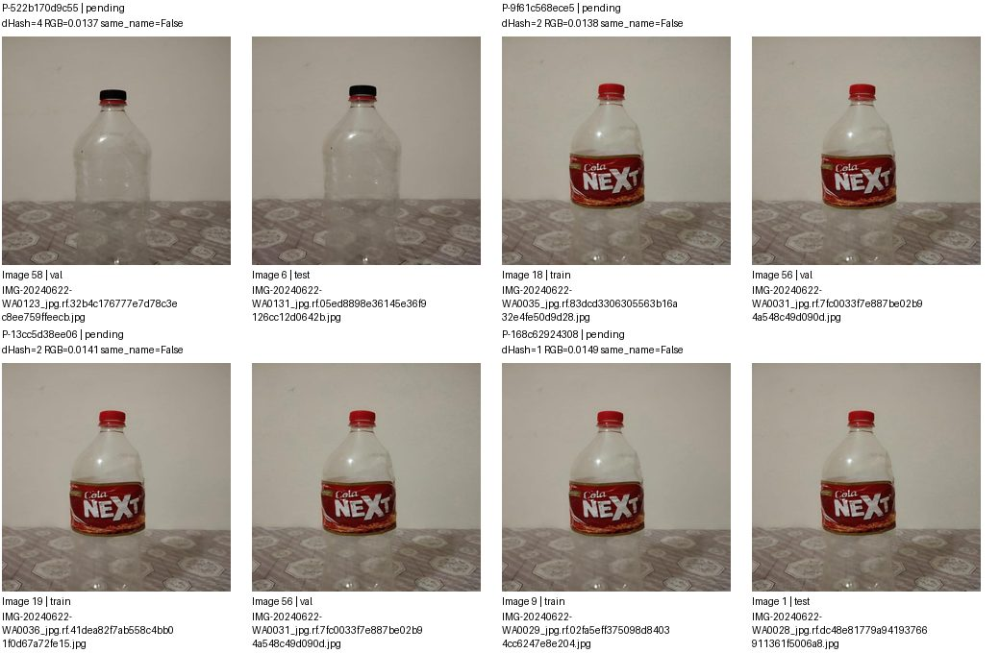

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-522b170d9c55,images/val/IMG-20240622-WA0123_jpg.rf.32b4c176777e7d78c3ec8ee759ffeecb.jpg,images/test/IMG-20240622-WA0131_jpg.rf.05ed8898e36145e36f9126cc12d0642b.jpg,pending,
P-9f61c568ece5,images/train/IMG-20240622-WA0035_jpg.rf.83dcd3306305563b16a32e4fe50d9d28.jpg,images/val/IMG-20240622-WA0031_jpg.rf.7fc0033f7e887be02b94a548c49d090d.jpg,pending,
P-13cc5d38ee06,images/train/IMG-20240622-WA0036_jpg.rf.41dea82f7ab558c4bb01f0d67a72fe15.jpg,images/val/IMG-20240622-WA0031_jpg.rf.7fc0033f7e887be02b94a548c49d090d.jpg,pending,
P-168c62924308,images/train/IMG-20240622-WA0029_jpg.rf.02fa5eff375098d84034cc6247e8e204.jpg,images/test/IMG-20240622-WA0028_jpg.rf.dc48e81779a94193766911361f5006a8.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 88/166 G-f4bef8242d52 | 60 ảnh, 147 cặp
Split: {'test': 7, 'train': 47, 'val': 6}
Quyết định: {'pending': 147}
Ảnh trang None/10; cặp trang 12/37. Nhóm liên thông không phải kết luận trùng.


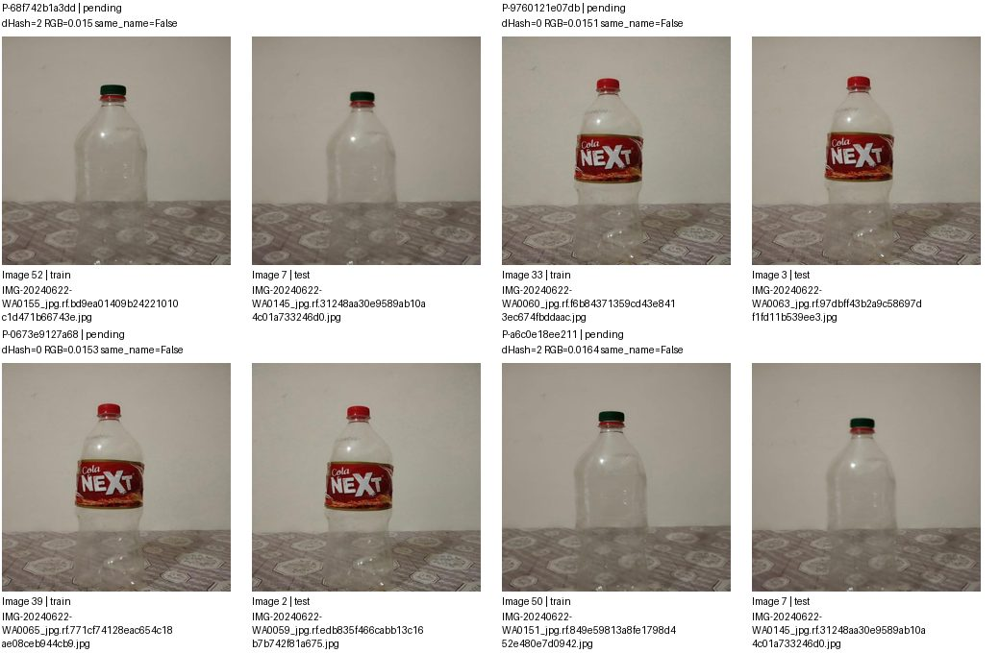

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-68f742b1a3dd,images/train/IMG-20240622-WA0155_jpg.rf.bd9ea01409b24221010c1d471b66743e.jpg,images/test/IMG-20240622-WA0145_jpg.rf.31248aa30e9589ab10a4c01a733246d0.jpg,pending,
P-9760121e07db,images/train/IMG-20240622-WA0060_jpg.rf.f6b84371359cd43e8413ec674fbddaac.jpg,images/test/IMG-20240622-WA0063_jpg.rf.97dbff43b2a9c58697df1fd11b539ee3.jpg,pending,
P-0673e9127a68,images/train/IMG-20240622-WA0065_jpg.rf.771cf74128eac654c18ae08ceb944cb9.jpg,images/test/IMG-20240622-WA0059_jpg.rf.edb835f466cabb13c16b7b742f81a675.jpg,pending,
P-a6c0e18ee211,images/train/IMG-20240622-WA0151_jpg.rf.849e59813a8fe1798d452e480e7d0942.jpg,images/test/IMG-20240622-WA0145_jpg.rf.31248aa30e9589ab10a4c01a733246d0.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 88/166 G-f4bef8242d52 | 60 ảnh, 147 cặp
Split: {'test': 7, 'train': 47, 'val': 6}
Quyết định: {'pending': 147}
Ảnh trang None/10; cặp trang 13/37. Nhóm liên thông không phải kết luận trùng.


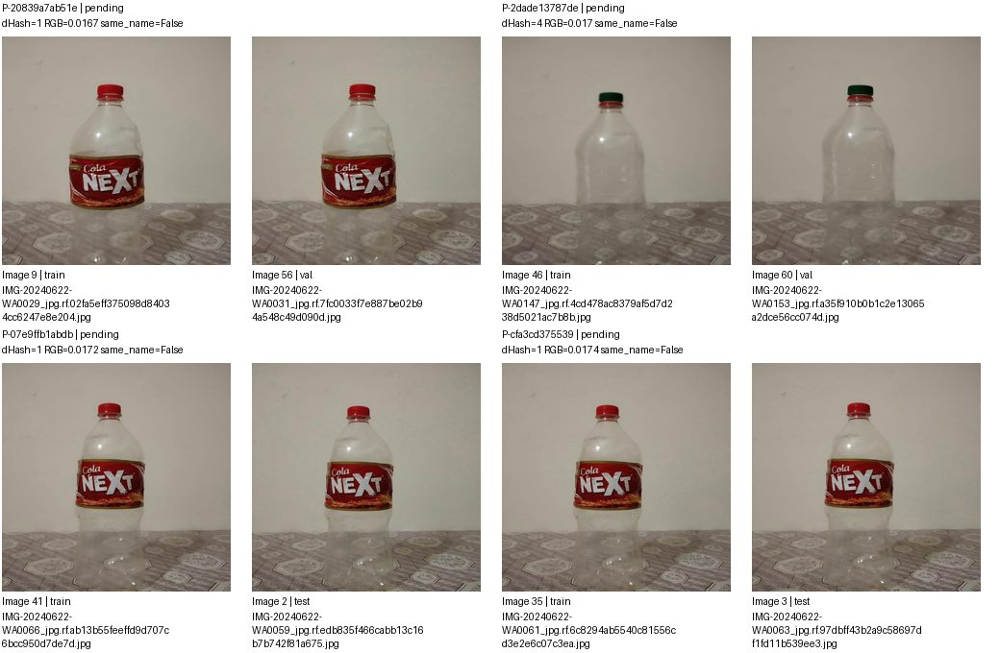

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-20839a7ab51e,images/train/IMG-20240622-WA0029_jpg.rf.02fa5eff375098d84034cc6247e8e204.jpg,images/val/IMG-20240622-WA0031_jpg.rf.7fc0033f7e887be02b94a548c49d090d.jpg,pending,
P-2dade13787de,images/train/IMG-20240622-WA0147_jpg.rf.4cd478ac8379af5d7d238d5021ac7b8b.jpg,images/val/IMG-20240622-WA0153_jpg.rf.a35f910b0b1c2e13065a2dce56cc074d.jpg,pending,
P-07e9ffb1abdb,images/train/IMG-20240622-WA0066_jpg.rf.ab13b55feeffd9d707c6bcc950d7de7d.jpg,images/test/IMG-20240622-WA0059_jpg.rf.edb835f466cabb13c16b7b742f81a675.jpg,pending,
P-cfa3cd375539,images/train/IMG-20240622-WA0061_jpg.rf.6c8294ab5540c81556cd3e2e6c07c3ea.jpg,images/test/IMG-20240622-WA0063_jpg.rf.97dbff43b2a9c58697df1fd11b539ee3.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 88/166 G-f4bef8242d52 | 60 ảnh, 147 cặp
Split: {'test': 7, 'train': 47, 'val': 6}
Quyết định: {'pending': 147}
Ảnh trang None/10; cặp trang 14/37. Nhóm liên thông không phải kết luận trùng.


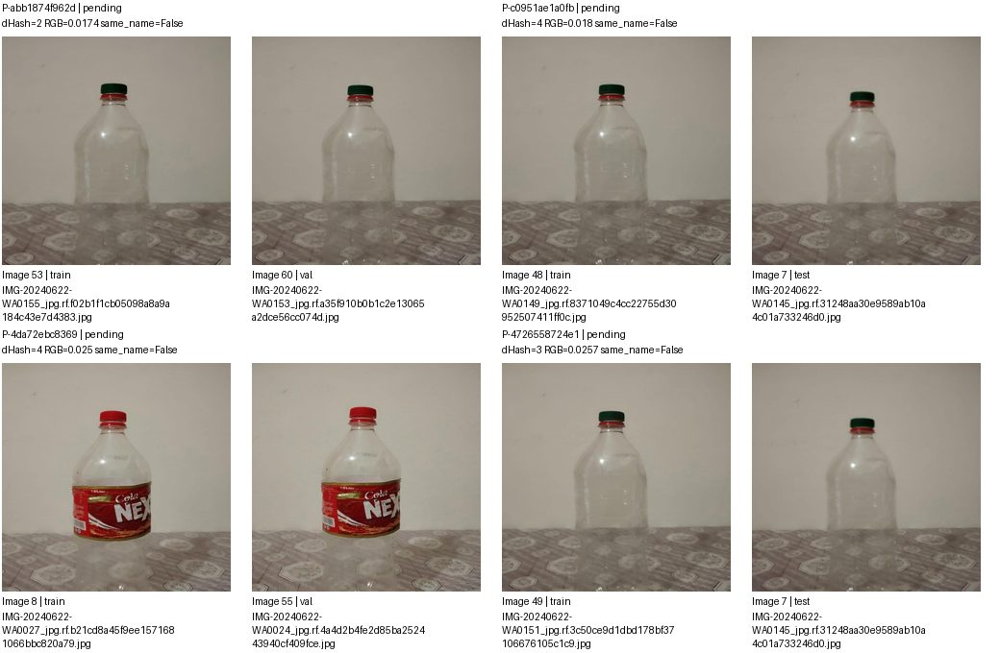

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-abb1874f962d,images/train/IMG-20240622-WA0155_jpg.rf.f02b1f1cb05098a8a9a184c43e7d4383.jpg,images/val/IMG-20240622-WA0153_jpg.rf.a35f910b0b1c2e13065a2dce56cc074d.jpg,pending,
P-c0951ae1a0fb,images/train/IMG-20240622-WA0149_jpg.rf.8371049c4cc22755d30952507411ff0c.jpg,images/test/IMG-20240622-WA0145_jpg.rf.31248aa30e9589ab10a4c01a733246d0.jpg,pending,
P-4da72ebc8369,images/train/IMG-20240622-WA0027_jpg.rf.b21cd8a45f9ee1571681066bbc820a79.jpg,images/val/IMG-20240622-WA0024_jpg.rf.4a4d2b4fe2d85ba252443940cf409fce.jpg,pending,
P-4726558724e1,images/train/IMG-20240622-WA0151_jpg.rf.3c50ce9d1dbd178bf37106676105c1c9.jpg,images/test/IMG-20240622-WA0145_jpg.rf.31248aa30e9589ab10a4c01a733246d0.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 88/166 G-f4bef8242d52 | 60 ảnh, 147 cặp
Split: {'test': 7, 'train': 47, 'val': 6}
Quyết định: {'pending': 147}
Ảnh trang None/10; cặp trang 15/37. Nhóm liên thông không phải kết luận trùng.


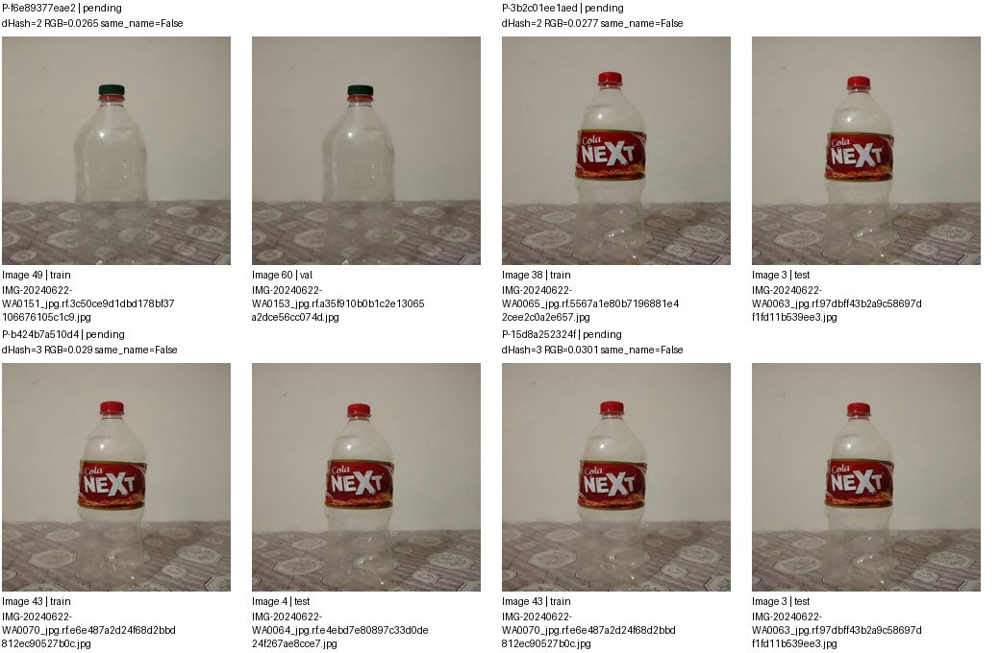

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-f6e89377eae2,images/train/IMG-20240622-WA0151_jpg.rf.3c50ce9d1dbd178bf37106676105c1c9.jpg,images/val/IMG-20240622-WA0153_jpg.rf.a35f910b0b1c2e13065a2dce56cc074d.jpg,pending,
P-3b2c01ee1aed,images/train/IMG-20240622-WA0065_jpg.rf.5567a1e80b7196881e42cee2c0a2e657.jpg,images/test/IMG-20240622-WA0063_jpg.rf.97dbff43b2a9c58697df1fd11b539ee3.jpg,pending,
P-b424b7a510d4,images/train/IMG-20240622-WA0070_jpg.rf.e6e487a2d24f68d2bbd812ec90527b0c.jpg,images/test/IMG-20240622-WA0064_jpg.rf.e4ebd7e80897c33d0de24f267ae8cce7.jpg,pending,
P-15d8a252324f,images/train/IMG-20240622-WA0070_jpg.rf.e6e487a2d24f68d2bbd812ec90527b0c.jpg,images/test/IMG-20240622-WA0063_jpg.rf.97dbff43b2a9c58697df1fd11b539ee3.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 88/166 G-f4bef8242d52 | 60 ảnh, 147 cặp
Split: {'test': 7, 'train': 47, 'val': 6}
Quyết định: {'pending': 147}
Ảnh trang None/10; cặp trang 16/37. Nhóm liên thông không phải kết luận trùng.


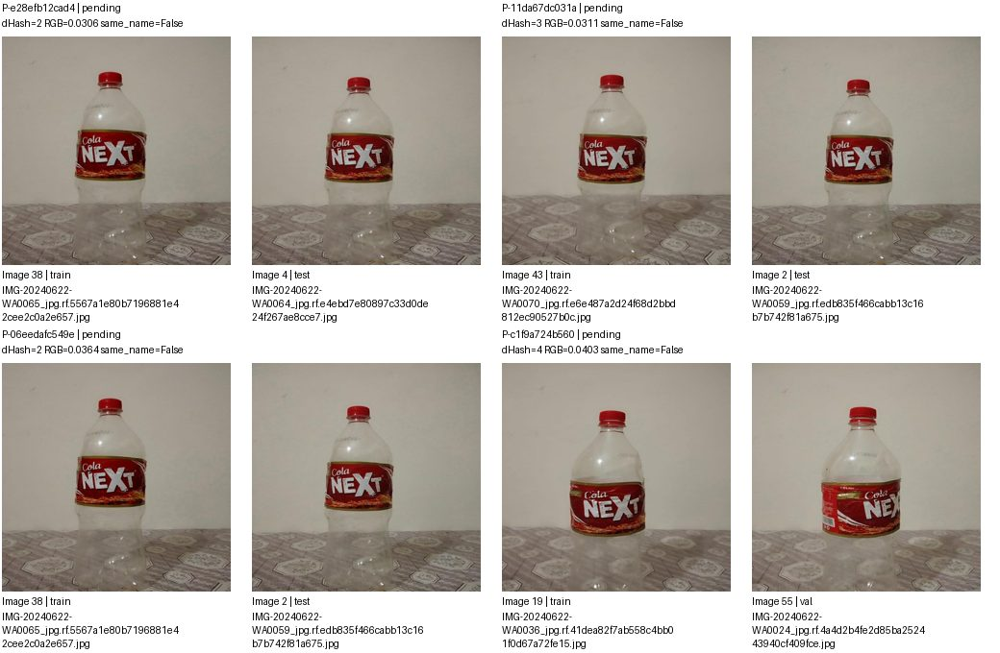

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-e28efb12cad4,images/train/IMG-20240622-WA0065_jpg.rf.5567a1e80b7196881e42cee2c0a2e657.jpg,images/test/IMG-20240622-WA0064_jpg.rf.e4ebd7e80897c33d0de24f267ae8cce7.jpg,pending,
P-11da67dc031a,images/train/IMG-20240622-WA0070_jpg.rf.e6e487a2d24f68d2bbd812ec90527b0c.jpg,images/test/IMG-20240622-WA0059_jpg.rf.edb835f466cabb13c16b7b742f81a675.jpg,pending,
P-06eedafc549e,images/train/IMG-20240622-WA0065_jpg.rf.5567a1e80b7196881e42cee2c0a2e657.jpg,images/test/IMG-20240622-WA0059_jpg.rf.edb835f466cabb13c16b7b742f81a675.jpg,pending,
P-c1f9a724b560,images/train/IMG-20240622-WA0036_jpg.rf.41dea82f7ab558c4bb01f0d67a72fe15.jpg,images/val/IMG-20240622-WA0024_jpg.rf.4a4d2b4fe2d85ba252443940cf409fce.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 88/166 G-f4bef8242d52 | 60 ảnh, 147 cặp
Split: {'test': 7, 'train': 47, 'val': 6}
Quyết định: {'pending': 147}
Ảnh trang None/10; cặp trang 17/37. Nhóm liên thông không phải kết luận trùng.


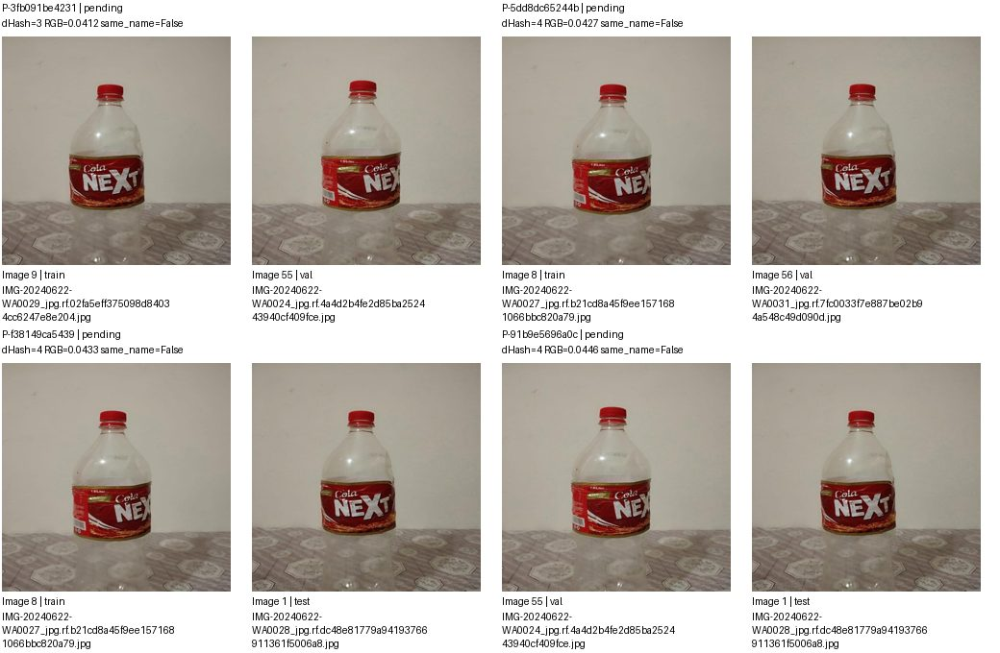

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-3fb091be4231,images/train/IMG-20240622-WA0029_jpg.rf.02fa5eff375098d84034cc6247e8e204.jpg,images/val/IMG-20240622-WA0024_jpg.rf.4a4d2b4fe2d85ba252443940cf409fce.jpg,pending,
P-5dd8dc65244b,images/train/IMG-20240622-WA0027_jpg.rf.b21cd8a45f9ee1571681066bbc820a79.jpg,images/val/IMG-20240622-WA0031_jpg.rf.7fc0033f7e887be02b94a548c49d090d.jpg,pending,
P-f38149ca5439,images/train/IMG-20240622-WA0027_jpg.rf.b21cd8a45f9ee1571681066bbc820a79.jpg,images/test/IMG-20240622-WA0028_jpg.rf.dc48e81779a94193766911361f5006a8.jpg,pending,
P-91b9e5696a0c,images/val/IMG-20240622-WA0024_jpg.rf.4a4d2b4fe2d85ba252443940cf409fce.jpg,images/test/IMG-20240622-WA0028_jpg.rf.dc48e81779a94193766911361f5006a8.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 88/166 G-f4bef8242d52 | 60 ảnh, 147 cặp
Split: {'test': 7, 'train': 47, 'val': 6}
Quyết định: {'pending': 147}
Ảnh trang None/10; cặp trang 18/37. Nhóm liên thông không phải kết luận trùng.


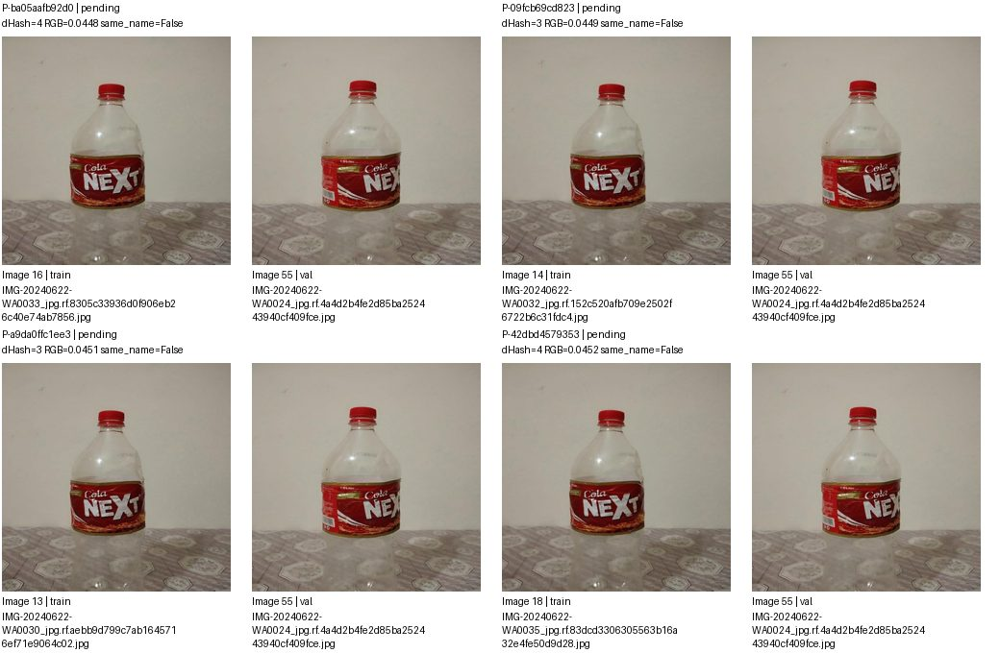

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-ba05aafb92d0,images/train/IMG-20240622-WA0033_jpg.rf.8305c33936d0f906eb26c40e74ab7856.jpg,images/val/IMG-20240622-WA0024_jpg.rf.4a4d2b4fe2d85ba252443940cf409fce.jpg,pending,
P-09fcb69cd823,images/train/IMG-20240622-WA0032_jpg.rf.152c520afb709e2502f6722b6c31fdc4.jpg,images/val/IMG-20240622-WA0024_jpg.rf.4a4d2b4fe2d85ba252443940cf409fce.jpg,pending,
P-a9da0ffc1ee3,images/train/IMG-20240622-WA0030_jpg.rf.aebb9d799c7ab1645716ef71e9064c02.jpg,images/val/IMG-20240622-WA0024_jpg.rf.4a4d2b4fe2d85ba252443940cf409fce.jpg,pending,
P-42dbd4579353,images/train/IMG-20240622-WA0035_jpg.rf.83dcd3306305563b16a32e4fe50d9d28.jpg,images/val/IMG-20240622-WA0024_jpg.rf.4a4d2b4fe2d85ba252443940cf409fce.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 88/166 G-f4bef8242d52 | 60 ảnh, 147 cặp
Split: {'test': 7, 'train': 47, 'val': 6}
Quyết định: {'pending': 147}
Ảnh trang None/10; cặp trang 19/37. Nhóm liên thông không phải kết luận trùng.


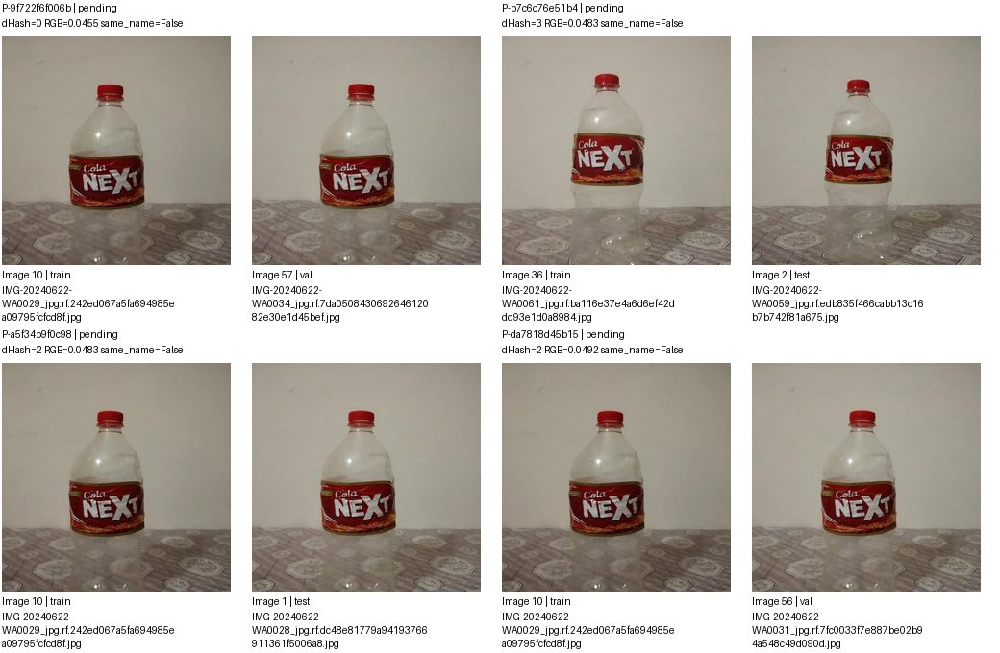

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-9f722f6f006b,images/train/IMG-20240622-WA0029_jpg.rf.242ed067a5fa694985ea09795fcfcd8f.jpg,images/val/IMG-20240622-WA0034_jpg.rf.7da050843069264612082e30e1d45bef.jpg,pending,
P-b7c6c76e51b4,images/train/IMG-20240622-WA0061_jpg.rf.ba116e37e4a6d6ef42ddd93e1d0a8984.jpg,images/test/IMG-20240622-WA0059_jpg.rf.edb835f466cabb13c16b7b742f81a675.jpg,pending,
P-a5f34b9f0c98,images/train/IMG-20240622-WA0029_jpg.rf.242ed067a5fa694985ea09795fcfcd8f.jpg,images/test/IMG-20240622-WA0028_jpg.rf.dc48e81779a94193766911361f5006a8.jpg,pending,
P-da7818d45b15,images/train/IMG-20240622-WA0029_jpg.rf.242ed067a5fa694985ea09795fcfcd8f.jpg,images/val/IMG-20240622-WA0031_jpg.rf.7fc0033f7e887be02b94a548c49d090d.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 88/166 G-f4bef8242d52 | 60 ảnh, 147 cặp
Split: {'test': 7, 'train': 47, 'val': 6}
Quyết định: {'pending': 147}
Ảnh trang None/10; cặp trang 20/37. Nhóm liên thông không phải kết luận trùng.


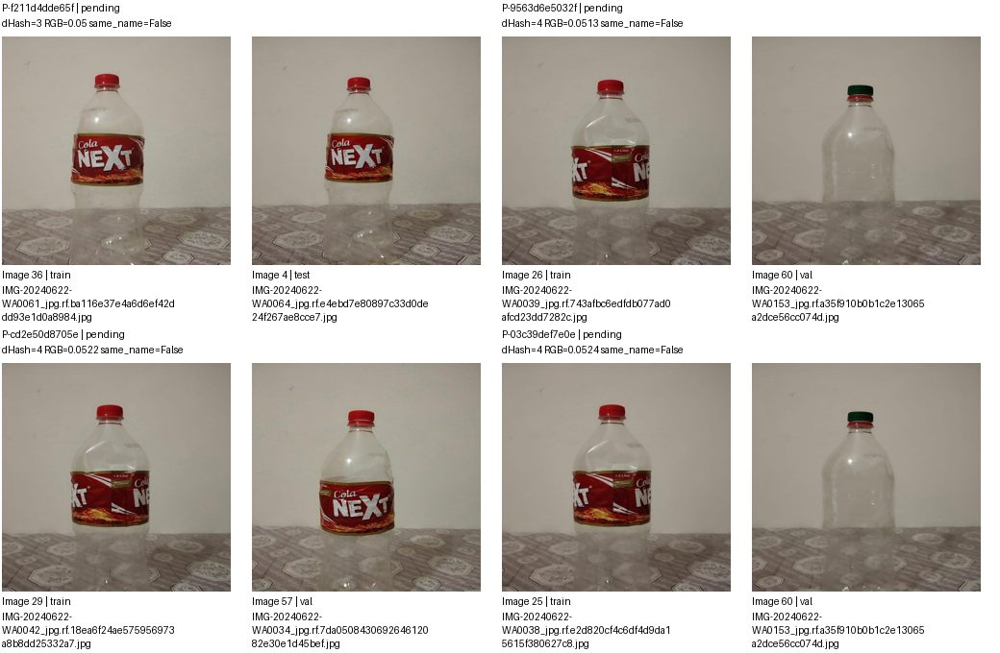

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-f211d4dde65f,images/train/IMG-20240622-WA0061_jpg.rf.ba116e37e4a6d6ef42ddd93e1d0a8984.jpg,images/test/IMG-20240622-WA0064_jpg.rf.e4ebd7e80897c33d0de24f267ae8cce7.jpg,pending,
P-9563d6e5032f,images/train/IMG-20240622-WA0039_jpg.rf.743afbc6edfdb077ad0afcd23dd7282c.jpg,images/val/IMG-20240622-WA0153_jpg.rf.a35f910b0b1c2e13065a2dce56cc074d.jpg,pending,
P-cd2e50d8705e,images/train/IMG-20240622-WA0042_jpg.rf.18ea6f24ae575956973a8b8dd25332a7.jpg,images/val/IMG-20240622-WA0034_jpg.rf.7da050843069264612082e30e1d45bef.jpg,pending,
P-03c39def7e0e,images/train/IMG-20240622-WA0038_jpg.rf.e2d820cf4c6df4d9da15615f380627c8.jpg,images/val/IMG-20240622-WA0153_jpg.rf.a35f910b0b1c2e13065a2dce56cc074d.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 88/166 G-f4bef8242d52 | 60 ảnh, 147 cặp
Split: {'test': 7, 'train': 47, 'val': 6}
Quyết định: {'pending': 147}
Ảnh trang None/10; cặp trang 21/37. Nhóm liên thông không phải kết luận trùng.


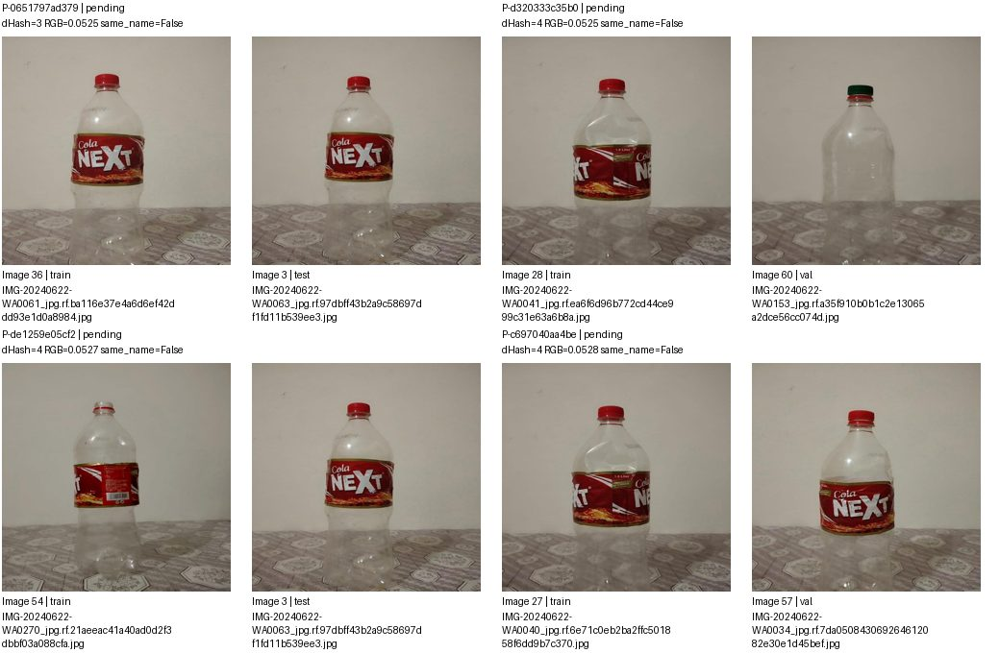

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-0651797ad379,images/train/IMG-20240622-WA0061_jpg.rf.ba116e37e4a6d6ef42ddd93e1d0a8984.jpg,images/test/IMG-20240622-WA0063_jpg.rf.97dbff43b2a9c58697df1fd11b539ee3.jpg,pending,
P-d320333c35b0,images/train/IMG-20240622-WA0041_jpg.rf.ea6f6d96b772cd44ce999c31e63a6b8a.jpg,images/val/IMG-20240622-WA0153_jpg.rf.a35f910b0b1c2e13065a2dce56cc074d.jpg,pending,
P-de1259e05cf2,images/train/IMG-20240622-WA0270_jpg.rf.21aeeac41a40ad0d2f3dbbf03a088cfa.jpg,images/test/IMG-20240622-WA0063_jpg.rf.97dbff43b2a9c58697df1fd11b539ee3.jpg,pending,
P-c697040aa4be,images/train/IMG-20240622-WA0040_jpg.rf.6e71c0eb2ba2ffc501858f6dd9b7c370.jpg,images/val/IMG-20240622-WA0034_jpg.rf.7da050843069264612082e30e1d45bef.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 88/166 G-f4bef8242d52 | 60 ảnh, 147 cặp
Split: {'test': 7, 'train': 47, 'val': 6}
Quyết định: {'pending': 147}
Ảnh trang None/10; cặp trang 22/37. Nhóm liên thông không phải kết luận trùng.


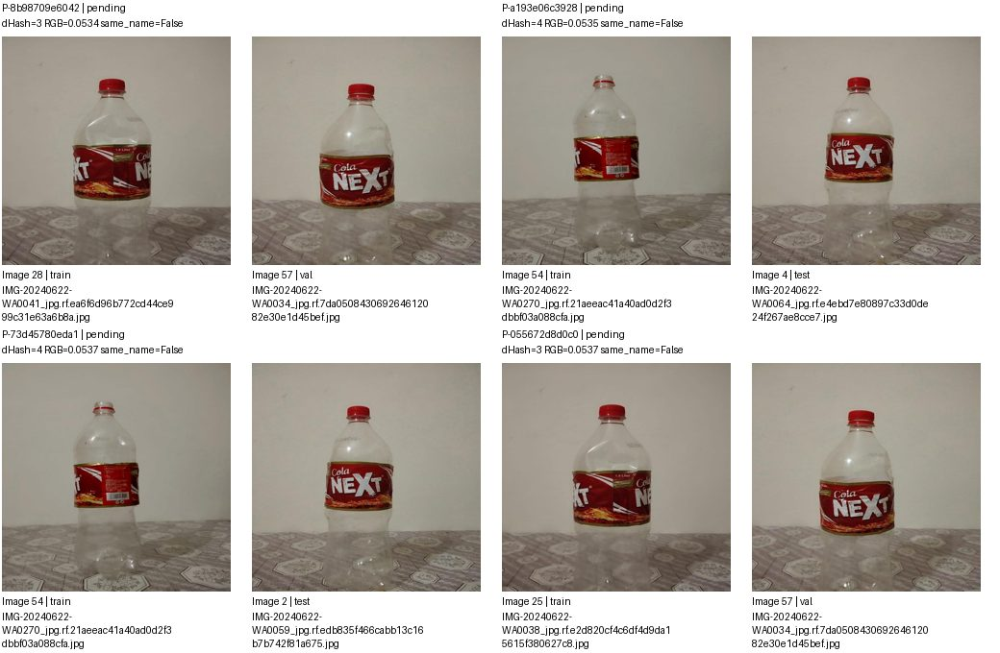

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-8b98709e6042,images/train/IMG-20240622-WA0041_jpg.rf.ea6f6d96b772cd44ce999c31e63a6b8a.jpg,images/val/IMG-20240622-WA0034_jpg.rf.7da050843069264612082e30e1d45bef.jpg,pending,
P-a193e06c3928,images/train/IMG-20240622-WA0270_jpg.rf.21aeeac41a40ad0d2f3dbbf03a088cfa.jpg,images/test/IMG-20240622-WA0064_jpg.rf.e4ebd7e80897c33d0de24f267ae8cce7.jpg,pending,
P-73d45780eda1,images/train/IMG-20240622-WA0270_jpg.rf.21aeeac41a40ad0d2f3dbbf03a088cfa.jpg,images/test/IMG-20240622-WA0059_jpg.rf.edb835f466cabb13c16b7b742f81a675.jpg,pending,
P-055672d8d0c0,images/train/IMG-20240622-WA0038_jpg.rf.e2d820cf4c6df4d9da15615f380627c8.jpg,images/val/IMG-20240622-WA0034_jpg.rf.7da050843069264612082e30e1d45bef.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 88/166 G-f4bef8242d52 | 60 ảnh, 147 cặp
Split: {'test': 7, 'train': 47, 'val': 6}
Quyết định: {'pending': 147}
Ảnh trang None/10; cặp trang 23/37. Nhóm liên thông không phải kết luận trùng.


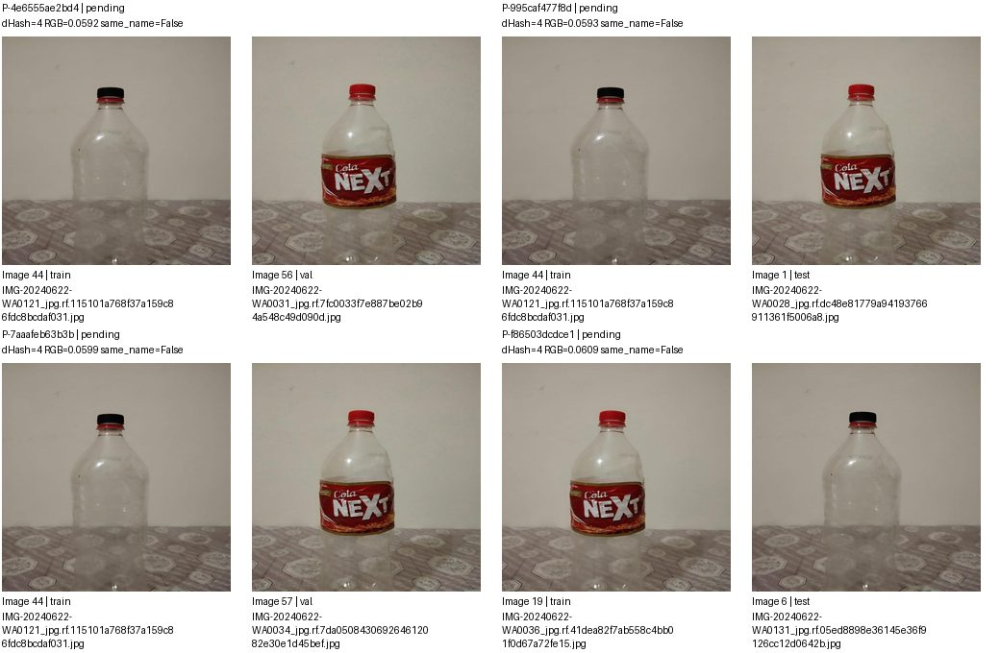

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-4e6555ae2bd4,images/train/IMG-20240622-WA0121_jpg.rf.115101a768f37a159c86fdc8bcdaf031.jpg,images/val/IMG-20240622-WA0031_jpg.rf.7fc0033f7e887be02b94a548c49d090d.jpg,pending,
P-995caf477f8d,images/train/IMG-20240622-WA0121_jpg.rf.115101a768f37a159c86fdc8bcdaf031.jpg,images/test/IMG-20240622-WA0028_jpg.rf.dc48e81779a94193766911361f5006a8.jpg,pending,
P-7aaafeb63b3b,images/train/IMG-20240622-WA0121_jpg.rf.115101a768f37a159c86fdc8bcdaf031.jpg,images/val/IMG-20240622-WA0034_jpg.rf.7da050843069264612082e30e1d45bef.jpg,pending,
P-f86503dcdce1,images/train/IMG-20240622-WA0036_jpg.rf.41dea82f7ab558c4bb01f0d67a72fe15.jpg,images/test/IMG-20240622-WA0131_jpg.rf.05ed8898e36145e36f9126cc12d0642b.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 88/166 G-f4bef8242d52 | 60 ảnh, 147 cặp
Split: {'test': 7, 'train': 47, 'val': 6}
Quyết định: {'pending': 147}
Ảnh trang None/10; cặp trang 24/37. Nhóm liên thông không phải kết luận trùng.


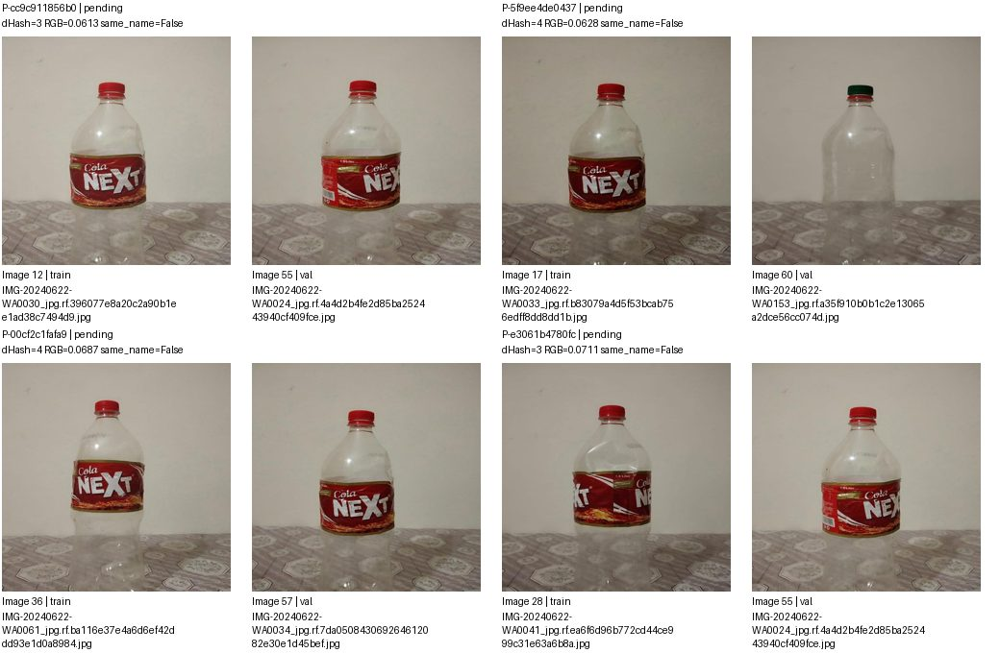

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-cc9c911856b0,images/train/IMG-20240622-WA0030_jpg.rf.396077e8a20c2a90b1ee1ad38c7494d9.jpg,images/val/IMG-20240622-WA0024_jpg.rf.4a4d2b4fe2d85ba252443940cf409fce.jpg,pending,
P-5f9ee4de0437,images/train/IMG-20240622-WA0033_jpg.rf.b83079a4d5f53bcab756edff8dd8dd1b.jpg,images/val/IMG-20240622-WA0153_jpg.rf.a35f910b0b1c2e13065a2dce56cc074d.jpg,pending,
P-00cf2c1fafa9,images/train/IMG-20240622-WA0061_jpg.rf.ba116e37e4a6d6ef42ddd93e1d0a8984.jpg,images/val/IMG-20240622-WA0034_jpg.rf.7da050843069264612082e30e1d45bef.jpg,pending,
P-e3061b4780fc,images/train/IMG-20240622-WA0041_jpg.rf.ea6f6d96b772cd44ce999c31e63a6b8a.jpg,images/val/IMG-20240622-WA0024_jpg.rf.4a4d2b4fe2d85ba252443940cf409fce.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 88/166 G-f4bef8242d52 | 60 ảnh, 147 cặp
Split: {'test': 7, 'train': 47, 'val': 6}
Quyết định: {'pending': 147}
Ảnh trang None/10; cặp trang 25/37. Nhóm liên thông không phải kết luận trùng.


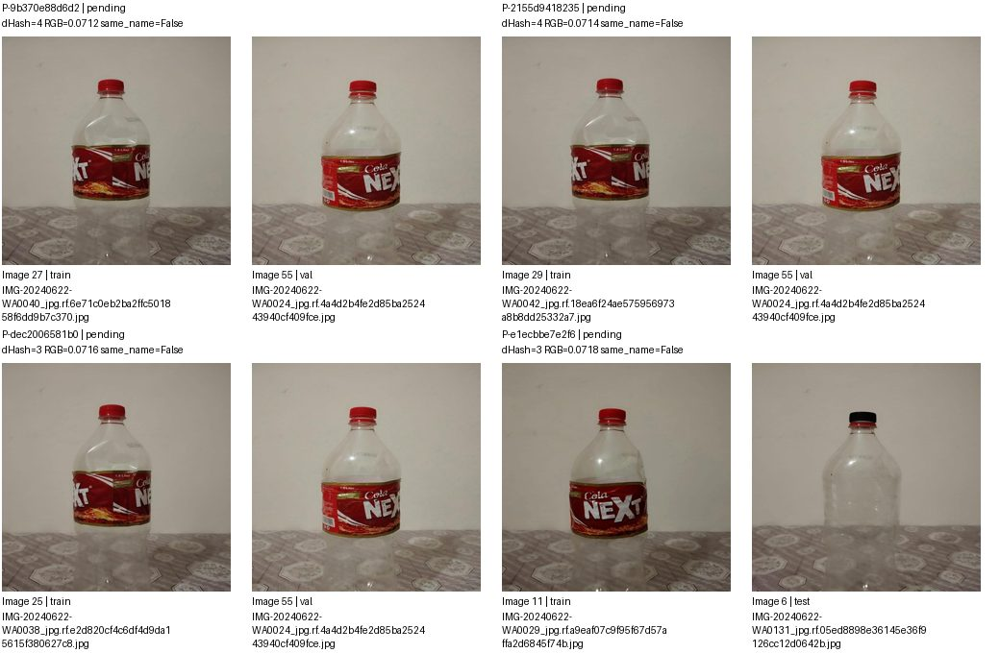

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-9b370e88d6d2,images/train/IMG-20240622-WA0040_jpg.rf.6e71c0eb2ba2ffc501858f6dd9b7c370.jpg,images/val/IMG-20240622-WA0024_jpg.rf.4a4d2b4fe2d85ba252443940cf409fce.jpg,pending,
P-2155d9418235,images/train/IMG-20240622-WA0042_jpg.rf.18ea6f24ae575956973a8b8dd25332a7.jpg,images/val/IMG-20240622-WA0024_jpg.rf.4a4d2b4fe2d85ba252443940cf409fce.jpg,pending,
P-dec2006581b0,images/train/IMG-20240622-WA0038_jpg.rf.e2d820cf4c6df4d9da15615f380627c8.jpg,images/val/IMG-20240622-WA0024_jpg.rf.4a4d2b4fe2d85ba252443940cf409fce.jpg,pending,
P-e1ecbbe7e2f6,images/train/IMG-20240622-WA0029_jpg.rf.a9eaf07c9f95f67d57affa2d6845f74b.jpg,images/test/IMG-20240622-WA0131_jpg.rf.05ed8898e36145e36f9126cc12d0642b.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 88/166 G-f4bef8242d52 | 60 ảnh, 147 cặp
Split: {'test': 7, 'train': 47, 'val': 6}
Quyết định: {'pending': 147}
Ảnh trang None/10; cặp trang 26/37. Nhóm liên thông không phải kết luận trùng.


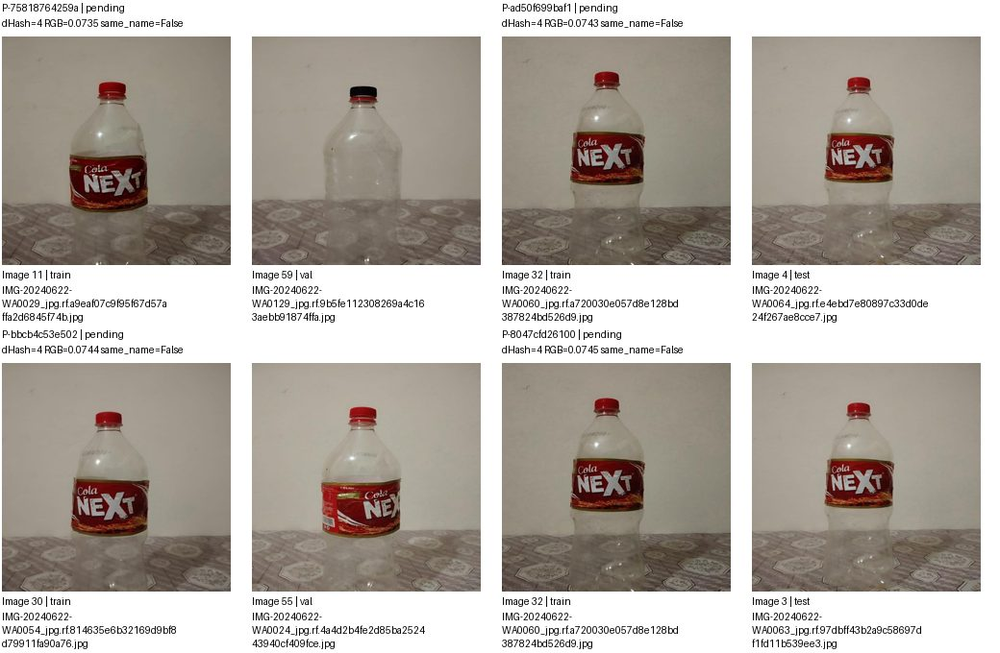

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-75818764259a,images/train/IMG-20240622-WA0029_jpg.rf.a9eaf07c9f95f67d57affa2d6845f74b.jpg,images/val/IMG-20240622-WA0129_jpg.rf.9b5fe112308269a4c163aebb91874ffa.jpg,pending,
P-ad50f699baf1,images/train/IMG-20240622-WA0060_jpg.rf.a720030e057d8e128bd387824bd526d9.jpg,images/test/IMG-20240622-WA0064_jpg.rf.e4ebd7e80897c33d0de24f267ae8cce7.jpg,pending,
P-bbcb4c53e502,images/train/IMG-20240622-WA0054_jpg.rf.814635e6b32169d9bf8d79911fa90a76.jpg,images/val/IMG-20240622-WA0024_jpg.rf.4a4d2b4fe2d85ba252443940cf409fce.jpg,pending,
P-8047cfd26100,images/train/IMG-20240622-WA0060_jpg.rf.a720030e057d8e128bd387824bd526d9.jpg,images/test/IMG-20240622-WA0063_jpg.rf.97dbff43b2a9c58697df1fd11b539ee3.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 88/166 G-f4bef8242d52 | 60 ảnh, 147 cặp
Split: {'test': 7, 'train': 47, 'val': 6}
Quyết định: {'pending': 147}
Ảnh trang None/10; cặp trang 27/37. Nhóm liên thông không phải kết luận trùng.


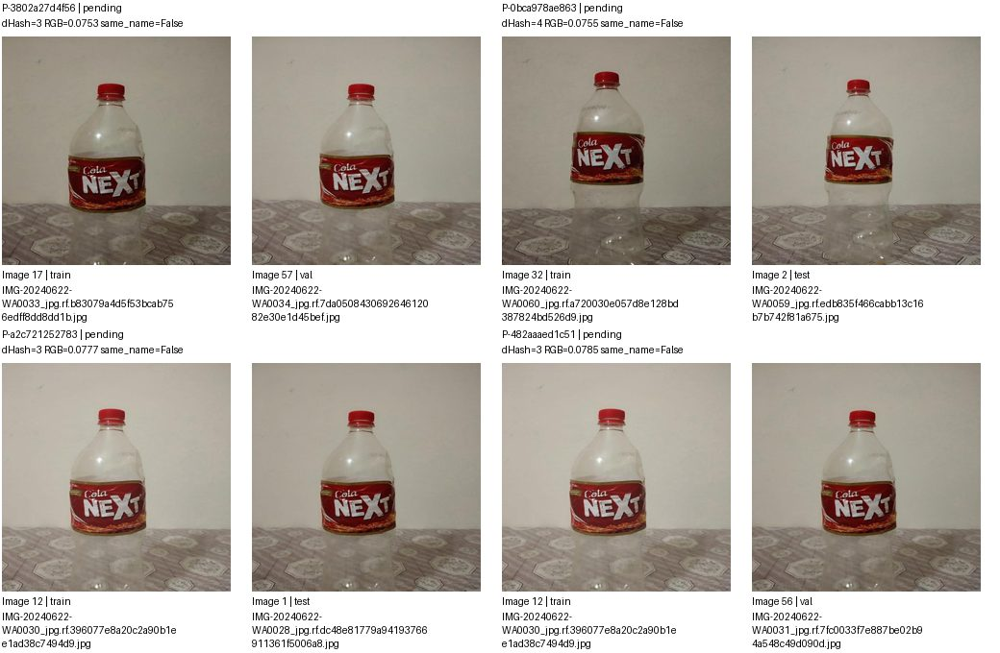

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-3802a27d4f56,images/train/IMG-20240622-WA0033_jpg.rf.b83079a4d5f53bcab756edff8dd8dd1b.jpg,images/val/IMG-20240622-WA0034_jpg.rf.7da050843069264612082e30e1d45bef.jpg,pending,
P-0bca978ae863,images/train/IMG-20240622-WA0060_jpg.rf.a720030e057d8e128bd387824bd526d9.jpg,images/test/IMG-20240622-WA0059_jpg.rf.edb835f466cabb13c16b7b742f81a675.jpg,pending,
P-a2c721252783,images/train/IMG-20240622-WA0030_jpg.rf.396077e8a20c2a90b1ee1ad38c7494d9.jpg,images/test/IMG-20240622-WA0028_jpg.rf.dc48e81779a94193766911361f5006a8.jpg,pending,
P-482aaaed1c51,images/train/IMG-20240622-WA0030_jpg.rf.396077e8a20c2a90b1ee1ad38c7494d9.jpg,images/val/IMG-20240622-WA0031_jpg.rf.7fc0033f7e887be02b94a548c49d090d.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 88/166 G-f4bef8242d52 | 60 ảnh, 147 cặp
Split: {'test': 7, 'train': 47, 'val': 6}
Quyết định: {'pending': 147}
Ảnh trang None/10; cặp trang 28/37. Nhóm liên thông không phải kết luận trùng.


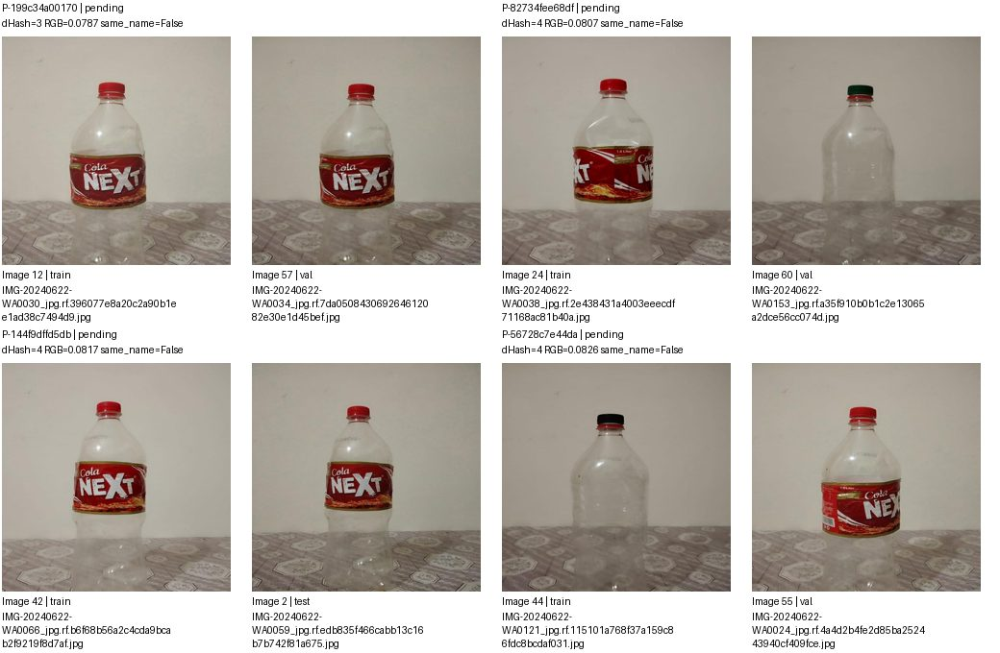

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-199c34a00170,images/train/IMG-20240622-WA0030_jpg.rf.396077e8a20c2a90b1ee1ad38c7494d9.jpg,images/val/IMG-20240622-WA0034_jpg.rf.7da050843069264612082e30e1d45bef.jpg,pending,
P-82734fee68df,images/train/IMG-20240622-WA0038_jpg.rf.2e438431a4003eeecdf71168ac81b40a.jpg,images/val/IMG-20240622-WA0153_jpg.rf.a35f910b0b1c2e13065a2dce56cc074d.jpg,pending,
P-144f9dffd5db,images/train/IMG-20240622-WA0066_jpg.rf.b6f68b56a2c4cda9bcab2f9219f8d7af.jpg,images/test/IMG-20240622-WA0059_jpg.rf.edb835f466cabb13c16b7b742f81a675.jpg,pending,
P-56728c7e44da,images/train/IMG-20240622-WA0121_jpg.rf.115101a768f37a159c86fdc8bcdaf031.jpg,images/val/IMG-20240622-WA0024_jpg.rf.4a4d2b4fe2d85ba252443940cf409fce.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 88/166 G-f4bef8242d52 | 60 ảnh, 147 cặp
Split: {'test': 7, 'train': 47, 'val': 6}
Quyết định: {'pending': 147}
Ảnh trang None/10; cặp trang 29/37. Nhóm liên thông không phải kết luận trùng.


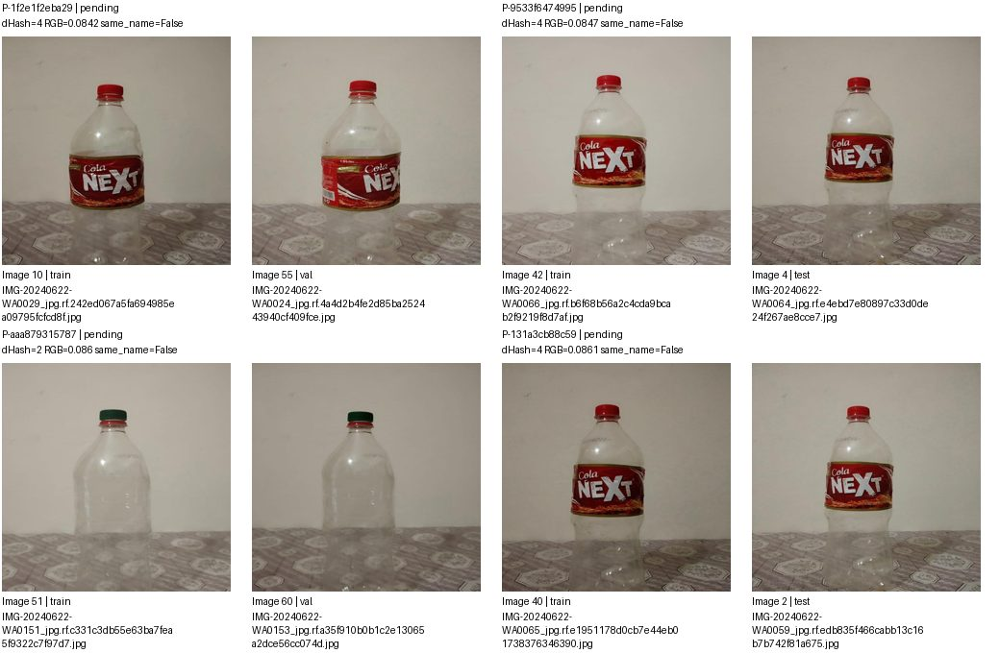

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-1f2e1f2eba29,images/train/IMG-20240622-WA0029_jpg.rf.242ed067a5fa694985ea09795fcfcd8f.jpg,images/val/IMG-20240622-WA0024_jpg.rf.4a4d2b4fe2d85ba252443940cf409fce.jpg,pending,
P-9533f6474995,images/train/IMG-20240622-WA0066_jpg.rf.b6f68b56a2c4cda9bcab2f9219f8d7af.jpg,images/test/IMG-20240622-WA0064_jpg.rf.e4ebd7e80897c33d0de24f267ae8cce7.jpg,pending,
P-aaa879315787,images/train/IMG-20240622-WA0151_jpg.rf.c331c3db55e63ba7fea5f9322c7f97d7.jpg,images/val/IMG-20240622-WA0153_jpg.rf.a35f910b0b1c2e13065a2dce56cc074d.jpg,pending,
P-131a3cb88c59,images/train/IMG-20240622-WA0065_jpg.rf.e1951178d0cb7e44eb01738376346390.jpg,images/test/IMG-20240622-WA0059_jpg.rf.edb835f466cabb13c16b7b742f81a675.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 88/166 G-f4bef8242d52 | 60 ảnh, 147 cặp
Split: {'test': 7, 'train': 47, 'val': 6}
Quyết định: {'pending': 147}
Ảnh trang None/10; cặp trang 30/37. Nhóm liên thông không phải kết luận trùng.


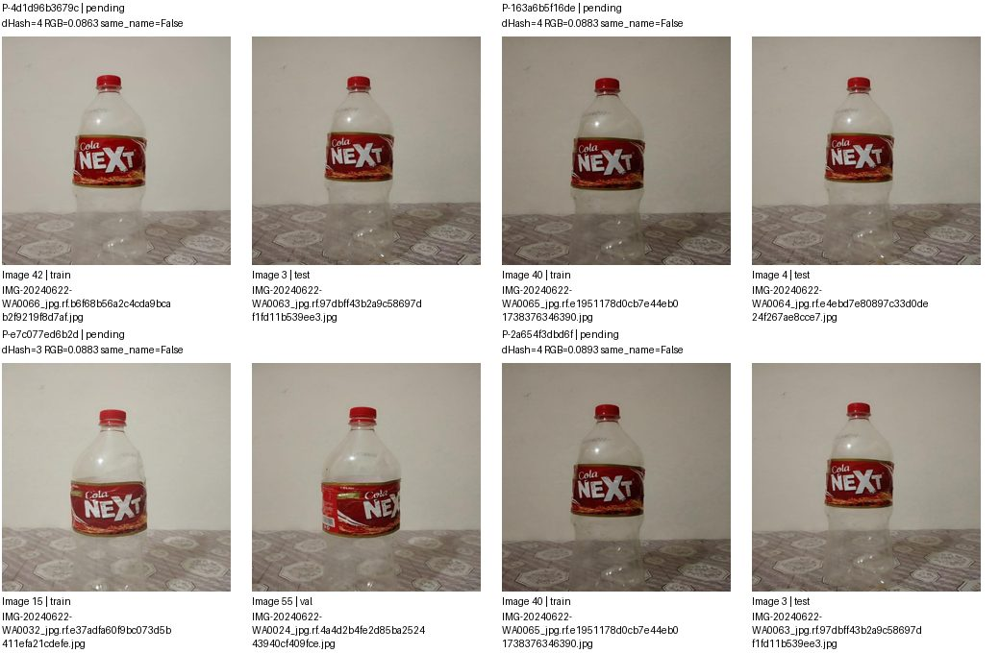

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-4d1d96b3679c,images/train/IMG-20240622-WA0066_jpg.rf.b6f68b56a2c4cda9bcab2f9219f8d7af.jpg,images/test/IMG-20240622-WA0063_jpg.rf.97dbff43b2a9c58697df1fd11b539ee3.jpg,pending,
P-163a6b5f16de,images/train/IMG-20240622-WA0065_jpg.rf.e1951178d0cb7e44eb01738376346390.jpg,images/test/IMG-20240622-WA0064_jpg.rf.e4ebd7e80897c33d0de24f267ae8cce7.jpg,pending,
P-e7c077ed6b2d,images/train/IMG-20240622-WA0032_jpg.rf.e37adfa60f9bc073d5b411efa21cdefe.jpg,images/val/IMG-20240622-WA0024_jpg.rf.4a4d2b4fe2d85ba252443940cf409fce.jpg,pending,
P-2a654f3dbd6f,images/train/IMG-20240622-WA0065_jpg.rf.e1951178d0cb7e44eb01738376346390.jpg,images/test/IMG-20240622-WA0063_jpg.rf.97dbff43b2a9c58697df1fd11b539ee3.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 88/166 G-f4bef8242d52 | 60 ảnh, 147 cặp
Split: {'test': 7, 'train': 47, 'val': 6}
Quyết định: {'pending': 147}
Ảnh trang None/10; cặp trang 31/37. Nhóm liên thông không phải kết luận trùng.


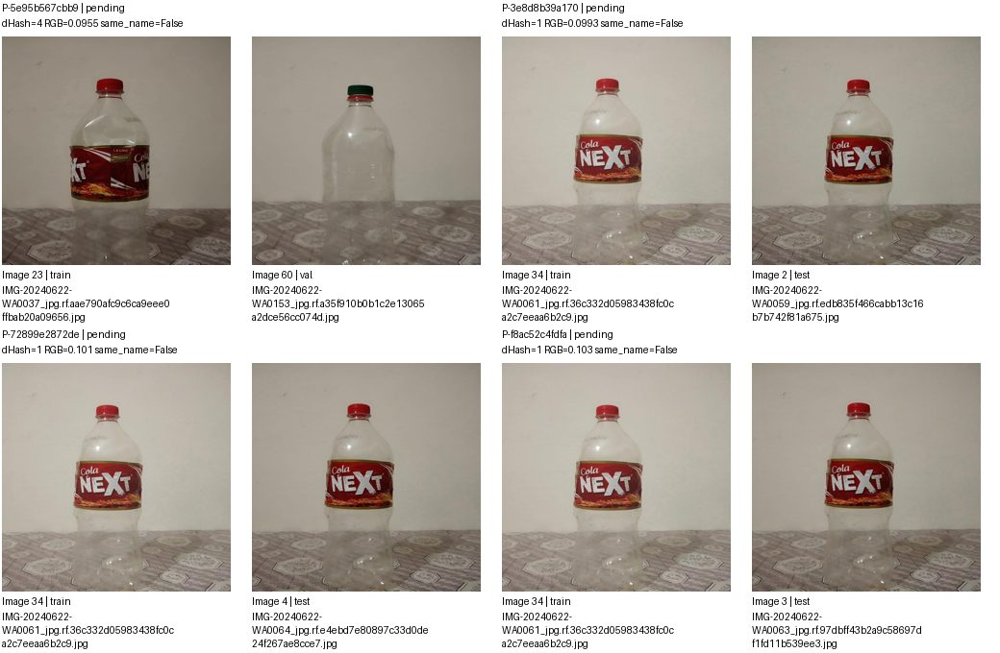

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-5e95b567cbb9,images/train/IMG-20240622-WA0037_jpg.rf.aae790afc9c6ca9eee0ffbab20a09656.jpg,images/val/IMG-20240622-WA0153_jpg.rf.a35f910b0b1c2e13065a2dce56cc074d.jpg,pending,
P-3e8d8b39a170,images/train/IMG-20240622-WA0061_jpg.rf.36c332d05983438fc0ca2c7eeaa6b2c9.jpg,images/test/IMG-20240622-WA0059_jpg.rf.edb835f466cabb13c16b7b742f81a675.jpg,pending,
P-72899e2872de,images/train/IMG-20240622-WA0061_jpg.rf.36c332d05983438fc0ca2c7eeaa6b2c9.jpg,images/test/IMG-20240622-WA0064_jpg.rf.e4ebd7e80897c33d0de24f267ae8cce7.jpg,pending,
P-f8ac52c4fdfa,images/train/IMG-20240622-WA0061_jpg.rf.36c332d05983438fc0ca2c7eeaa6b2c9.jpg,images/test/IMG-20240622-WA0063_jpg.rf.97dbff43b2a9c58697df1fd11b539ee3.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 88/166 G-f4bef8242d52 | 60 ảnh, 147 cặp
Split: {'test': 7, 'train': 47, 'val': 6}
Quyết định: {'pending': 147}
Ảnh trang None/10; cặp trang 32/37. Nhóm liên thông không phải kết luận trùng.


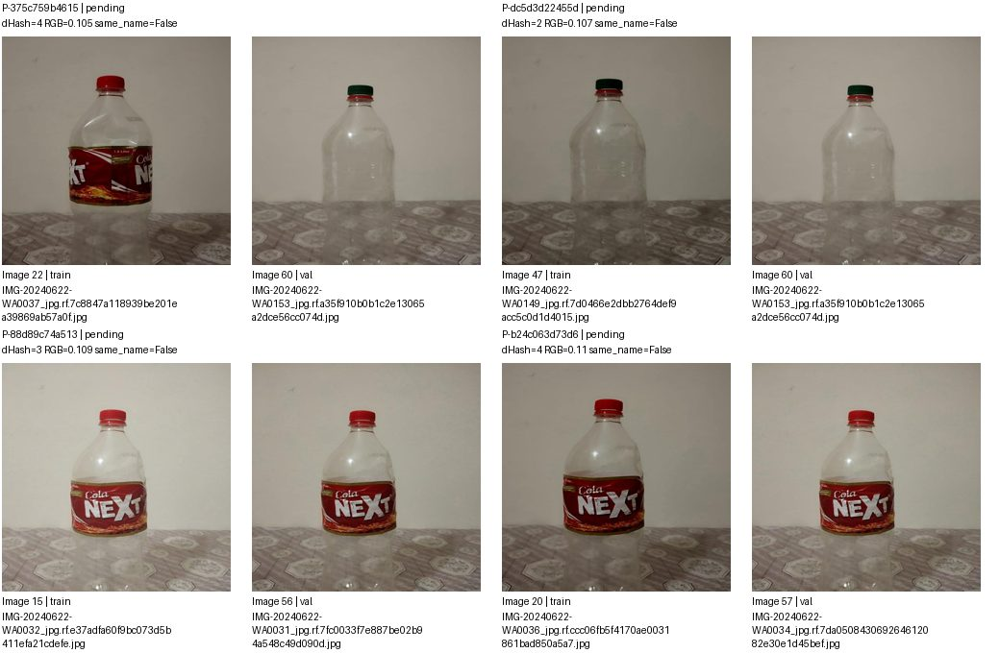

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-375c759b4615,images/train/IMG-20240622-WA0037_jpg.rf.7c8847a118939be201ea39869ab57a0f.jpg,images/val/IMG-20240622-WA0153_jpg.rf.a35f910b0b1c2e13065a2dce56cc074d.jpg,pending,
P-dc5d3d22455d,images/train/IMG-20240622-WA0149_jpg.rf.7d0466e2dbb2764def9acc5c0d1d4015.jpg,images/val/IMG-20240622-WA0153_jpg.rf.a35f910b0b1c2e13065a2dce56cc074d.jpg,pending,
P-88d89c74a513,images/train/IMG-20240622-WA0032_jpg.rf.e37adfa60f9bc073d5b411efa21cdefe.jpg,images/val/IMG-20240622-WA0031_jpg.rf.7fc0033f7e887be02b94a548c49d090d.jpg,pending,
P-b24c063d73d6,images/train/IMG-20240622-WA0036_jpg.rf.ccc06fb5f4170ae0031861bad850a5a7.jpg,images/val/IMG-20240622-WA0034_jpg.rf.7da050843069264612082e30e1d45bef.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 88/166 G-f4bef8242d52 | 60 ảnh, 147 cặp
Split: {'test': 7, 'train': 47, 'val': 6}
Quyết định: {'pending': 147}
Ảnh trang None/10; cặp trang 33/37. Nhóm liên thông không phải kết luận trùng.


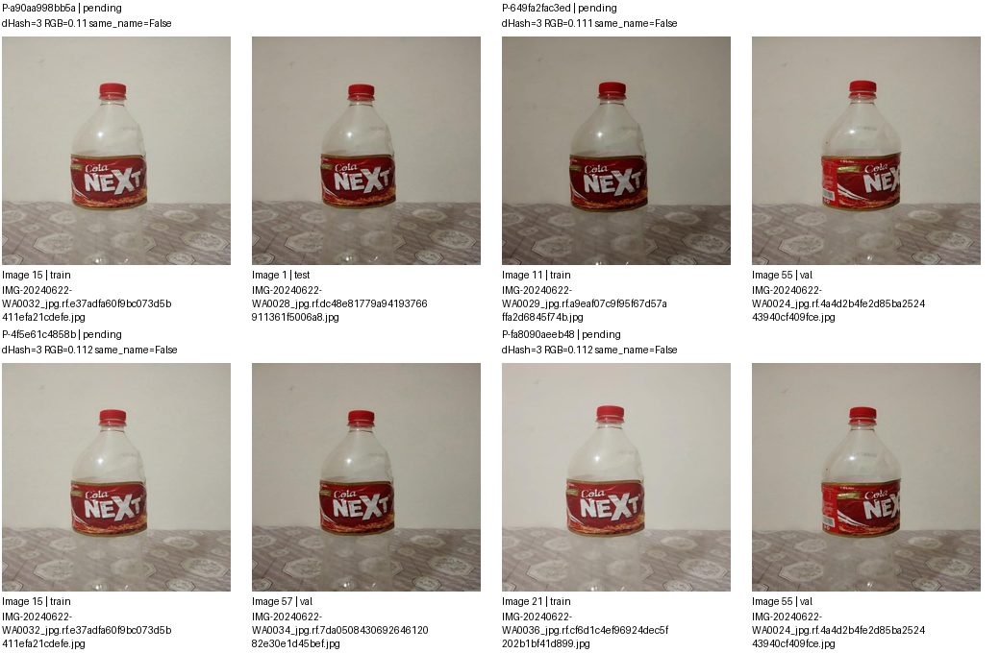

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-a90aa998bb5a,images/train/IMG-20240622-WA0032_jpg.rf.e37adfa60f9bc073d5b411efa21cdefe.jpg,images/test/IMG-20240622-WA0028_jpg.rf.dc48e81779a94193766911361f5006a8.jpg,pending,
P-649fa2fac3ed,images/train/IMG-20240622-WA0029_jpg.rf.a9eaf07c9f95f67d57affa2d6845f74b.jpg,images/val/IMG-20240622-WA0024_jpg.rf.4a4d2b4fe2d85ba252443940cf409fce.jpg,pending,
P-4f5e61c4858b,images/train/IMG-20240622-WA0032_jpg.rf.e37adfa60f9bc073d5b411efa21cdefe.jpg,images/val/IMG-20240622-WA0034_jpg.rf.7da050843069264612082e30e1d45bef.jpg,pending,
P-fa8090aeeb48,images/train/IMG-20240622-WA0036_jpg.rf.cf6d1c4ef96924dec5f202b1bf41d899.jpg,images/val/IMG-20240622-WA0024_jpg.rf.4a4d2b4fe2d85ba252443940cf409fce.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 88/166 G-f4bef8242d52 | 60 ảnh, 147 cặp
Split: {'test': 7, 'train': 47, 'val': 6}
Quyết định: {'pending': 147}
Ảnh trang None/10; cặp trang 34/37. Nhóm liên thông không phải kết luận trùng.


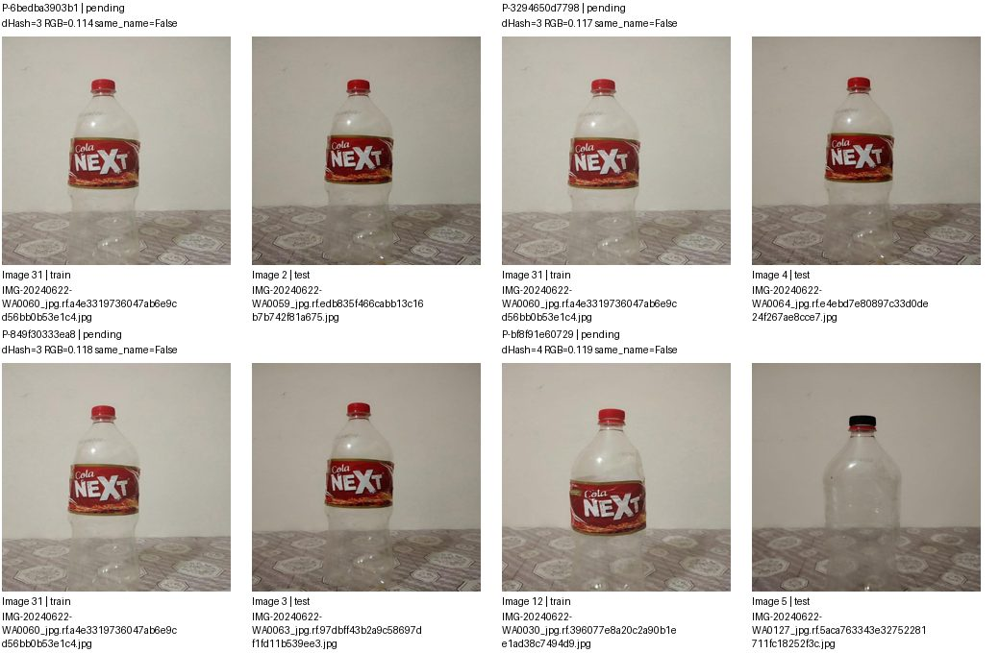

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-6bedba3903b1,images/train/IMG-20240622-WA0060_jpg.rf.a4e3319736047ab6e9cd56bb0b53e1c4.jpg,images/test/IMG-20240622-WA0059_jpg.rf.edb835f466cabb13c16b7b742f81a675.jpg,pending,
P-3294650d7798,images/train/IMG-20240622-WA0060_jpg.rf.a4e3319736047ab6e9cd56bb0b53e1c4.jpg,images/test/IMG-20240622-WA0064_jpg.rf.e4ebd7e80897c33d0de24f267ae8cce7.jpg,pending,
P-849f30333ea8,images/train/IMG-20240622-WA0060_jpg.rf.a4e3319736047ab6e9cd56bb0b53e1c4.jpg,images/test/IMG-20240622-WA0063_jpg.rf.97dbff43b2a9c58697df1fd11b539ee3.jpg,pending,
P-bf8f91e60729,images/train/IMG-20240622-WA0030_jpg.rf.396077e8a20c2a90b1ee1ad38c7494d9.jpg,images/test/IMG-20240622-WA0127_jpg.rf.5aca763343e32752281711fc18252f3c.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 88/166 G-f4bef8242d52 | 60 ảnh, 147 cặp
Split: {'test': 7, 'train': 47, 'val': 6}
Quyết định: {'pending': 147}
Ảnh trang None/10; cặp trang 35/37. Nhóm liên thông không phải kết luận trùng.


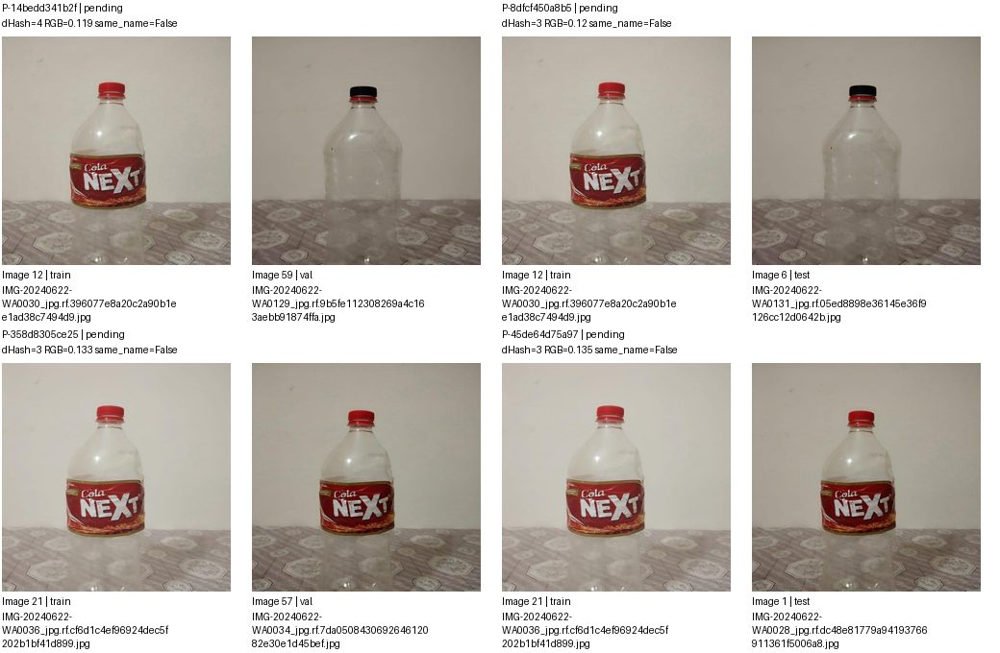

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-14bedd341b2f,images/train/IMG-20240622-WA0030_jpg.rf.396077e8a20c2a90b1ee1ad38c7494d9.jpg,images/val/IMG-20240622-WA0129_jpg.rf.9b5fe112308269a4c163aebb91874ffa.jpg,pending,
P-8dfcf450a8b5,images/train/IMG-20240622-WA0030_jpg.rf.396077e8a20c2a90b1ee1ad38c7494d9.jpg,images/test/IMG-20240622-WA0131_jpg.rf.05ed8898e36145e36f9126cc12d0642b.jpg,pending,
P-358d8305ce25,images/train/IMG-20240622-WA0036_jpg.rf.cf6d1c4ef96924dec5f202b1bf41d899.jpg,images/val/IMG-20240622-WA0034_jpg.rf.7da050843069264612082e30e1d45bef.jpg,pending,
P-45de64d75a97,images/train/IMG-20240622-WA0036_jpg.rf.cf6d1c4ef96924dec5f202b1bf41d899.jpg,images/test/IMG-20240622-WA0028_jpg.rf.dc48e81779a94193766911361f5006a8.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 88/166 G-f4bef8242d52 | 60 ảnh, 147 cặp
Split: {'test': 7, 'train': 47, 'val': 6}
Quyết định: {'pending': 147}
Ảnh trang None/10; cặp trang 36/37. Nhóm liên thông không phải kết luận trùng.


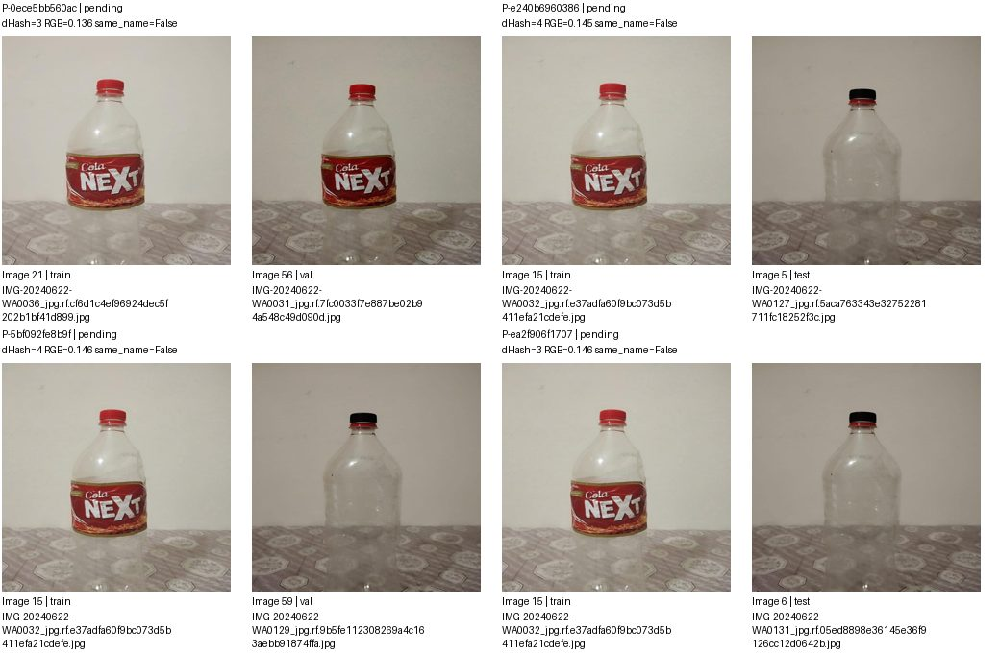

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-0ece5bb560ac,images/train/IMG-20240622-WA0036_jpg.rf.cf6d1c4ef96924dec5f202b1bf41d899.jpg,images/val/IMG-20240622-WA0031_jpg.rf.7fc0033f7e887be02b94a548c49d090d.jpg,pending,
P-e240b6960386,images/train/IMG-20240622-WA0032_jpg.rf.e37adfa60f9bc073d5b411efa21cdefe.jpg,images/test/IMG-20240622-WA0127_jpg.rf.5aca763343e32752281711fc18252f3c.jpg,pending,
P-5bf092fe8b9f,images/train/IMG-20240622-WA0032_jpg.rf.e37adfa60f9bc073d5b411efa21cdefe.jpg,images/val/IMG-20240622-WA0129_jpg.rf.9b5fe112308269a4c163aebb91874ffa.jpg,pending,
P-ea2f906f1707,images/train/IMG-20240622-WA0032_jpg.rf.e37adfa60f9bc073d5b411efa21cdefe.jpg,images/test/IMG-20240622-WA0131_jpg.rf.05ed8898e36145e36f9126cc12d0642b.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 88/166 G-f4bef8242d52 | 60 ảnh, 147 cặp
Split: {'test': 7, 'train': 47, 'val': 6}
Quyết định: {'pending': 147}
Ảnh trang None/10; cặp trang 37/37. Nhóm liên thông không phải kết luận trùng.


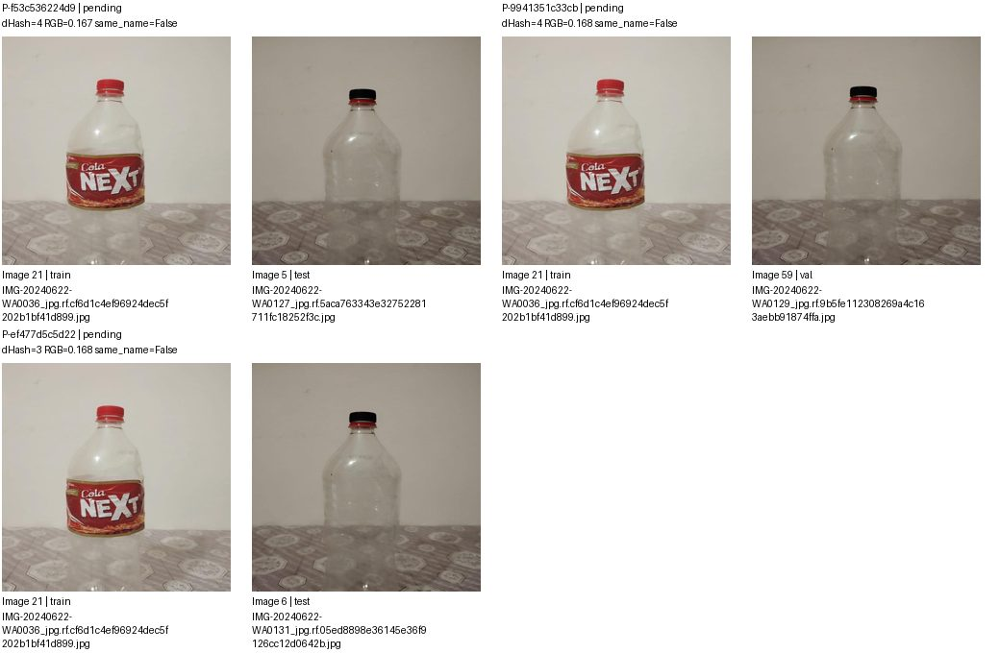

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-f53c536224d9,images/train/IMG-20240622-WA0036_jpg.rf.cf6d1c4ef96924dec5f202b1bf41d899.jpg,images/test/IMG-20240622-WA0127_jpg.rf.5aca763343e32752281711fc18252f3c.jpg,pending,
P-9941351c33cb,images/train/IMG-20240622-WA0036_jpg.rf.cf6d1c4ef96924dec5f202b1bf41d899.jpg,images/val/IMG-20240622-WA0129_jpg.rf.9b5fe112308269a4c163aebb91874ffa.jpg,pending,
P-ef477d5c5d22,images/train/IMG-20240622-WA0036_jpg.rf.cf6d1c4ef96924dec5f202b1bf41d899.jpg,images/test/IMG-20240622-WA0131_jpg.rf.05ed8898e36145e36f9126cc12d0642b.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 89/166 G-292bceb2e2cd | 3 ảnh, 2 cặp
Split: {'test': 1, 'train': 2}
Quyết định: {'pending': 2}
Ảnh trang 1/1; cặp trang 1/1. Nhóm liên thông không phải kết luận trùng.


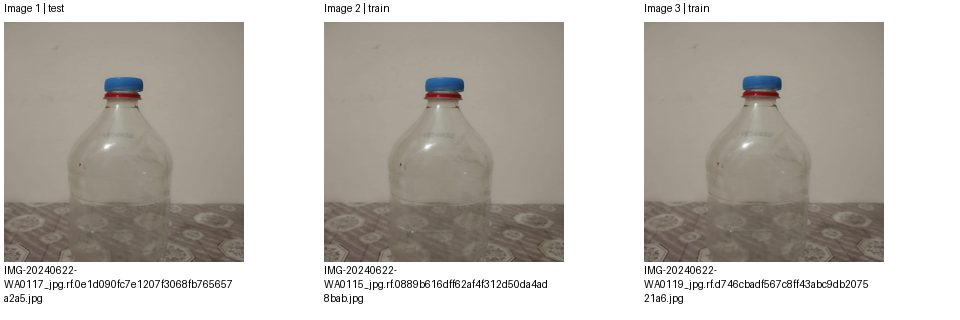

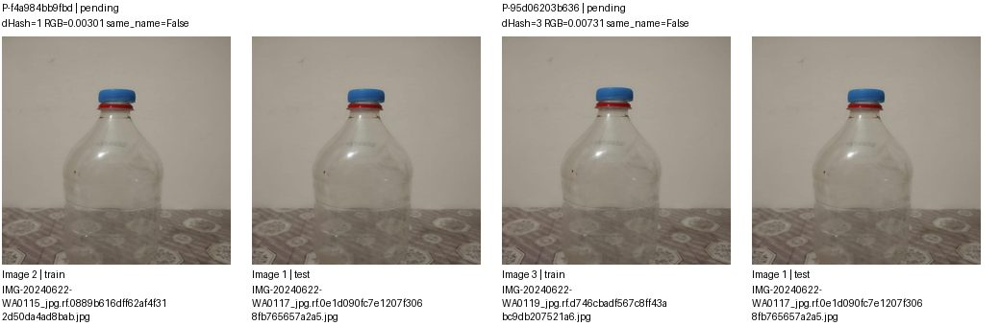

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-f4a984bb9fbd,images/train/IMG-20240622-WA0115_jpg.rf.0889b616dff62af4f312d50da4ad8bab.jpg,images/test/IMG-20240622-WA0117_jpg.rf.0e1d090fc7e1207f3068fb765657a2a5.jpg,pending,
P-95d06203b636,images/train/IMG-20240622-WA0119_jpg.rf.d746cbadf567c8ff43abc9db207521a6.jpg,images/test/IMG-20240622-WA0117_jpg.rf.0e1d090fc7e1207f3068fb765657a2a5.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 90/166 G-aa9778b0533c | 23 ảnh, 47 cặp
Split: {'test': 3, 'train': 14, 'val': 6}
Quyết định: {'pending': 47}
Ảnh trang 1/4; cặp trang 1/12. Nhóm liên thông không phải kết luận trùng.


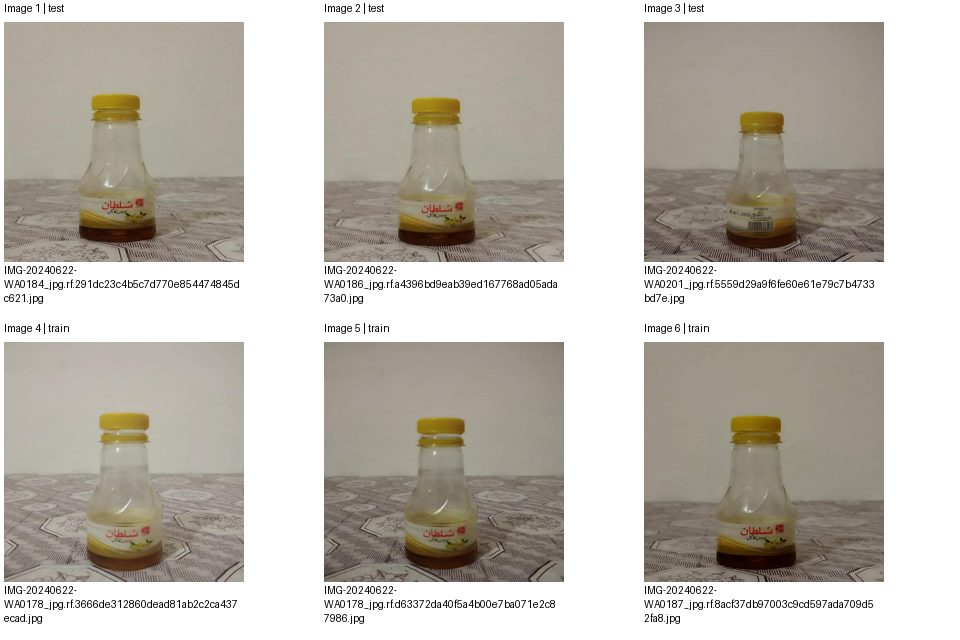

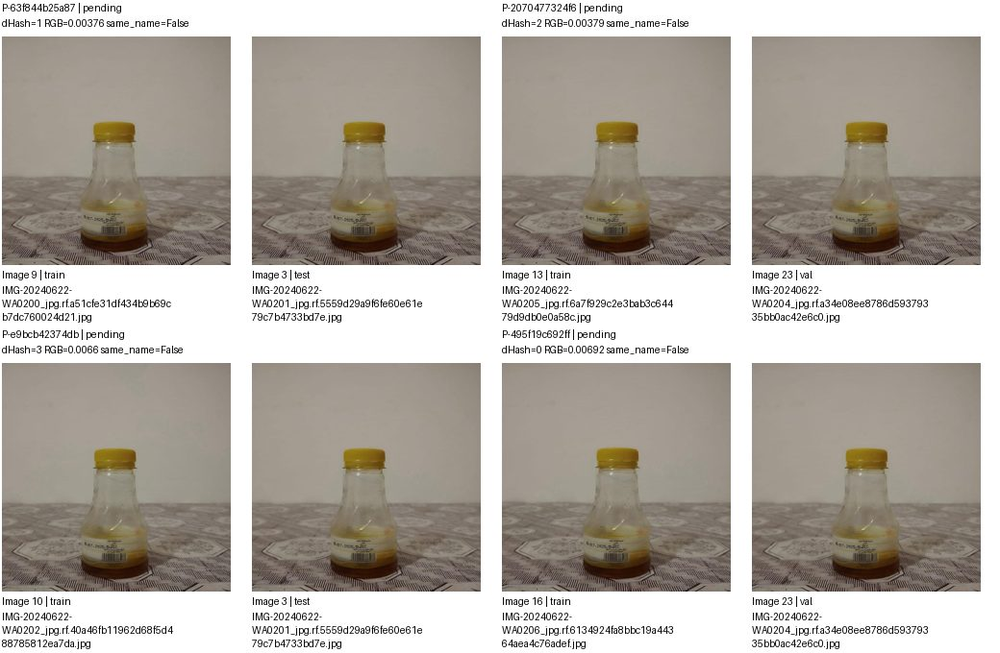

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-63f844b25a87,images/train/IMG-20240622-WA0200_jpg.rf.a51cfe31df434b9b69cb7dc760024d21.jpg,images/test/IMG-20240622-WA0201_jpg.rf.5559d29a9f6fe60e61e79c7b4733bd7e.jpg,pending,
P-2070477324f6,images/train/IMG-20240622-WA0205_jpg.rf.6a7f929c2e3bab3c64479d9db0e0a58c.jpg,images/val/IMG-20240622-WA0204_jpg.rf.a34e08ee8786d59379335bb0ac42e6c0.jpg,pending,
P-e9bcb42374db,images/train/IMG-20240622-WA0202_jpg.rf.40a46fb11962d68f5d488785812ea7da.jpg,images/test/IMG-20240622-WA0201_jpg.rf.5559d29a9f6fe60e61e79c7b4733bd7e.jpg,pending,
P-495f19c692ff,images/train/IMG-20240622-WA0206_jpg.rf.6134924fa8bbc19a44364aea4c76adef.jpg,images/val/IMG-20240622-WA0204_jpg.rf.a34e08ee8786d59379335bb0ac42e6c0.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 90/166 G-aa9778b0533c | 23 ảnh, 47 cặp
Split: {'test': 3, 'train': 14, 'val': 6}
Quyết định: {'pending': 47}
Ảnh trang 2/4; cặp trang 2/12. Nhóm liên thông không phải kết luận trùng.


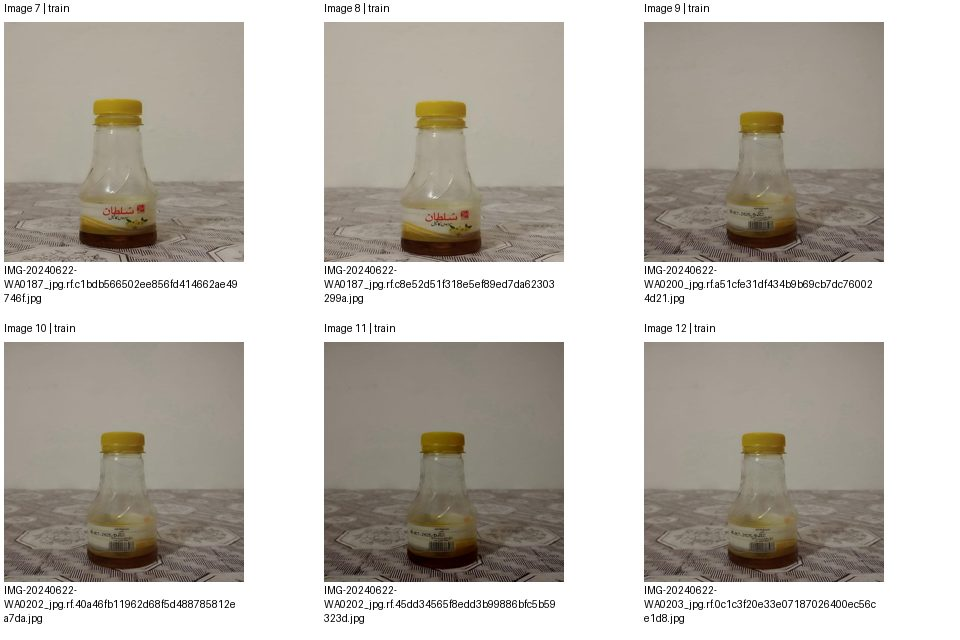

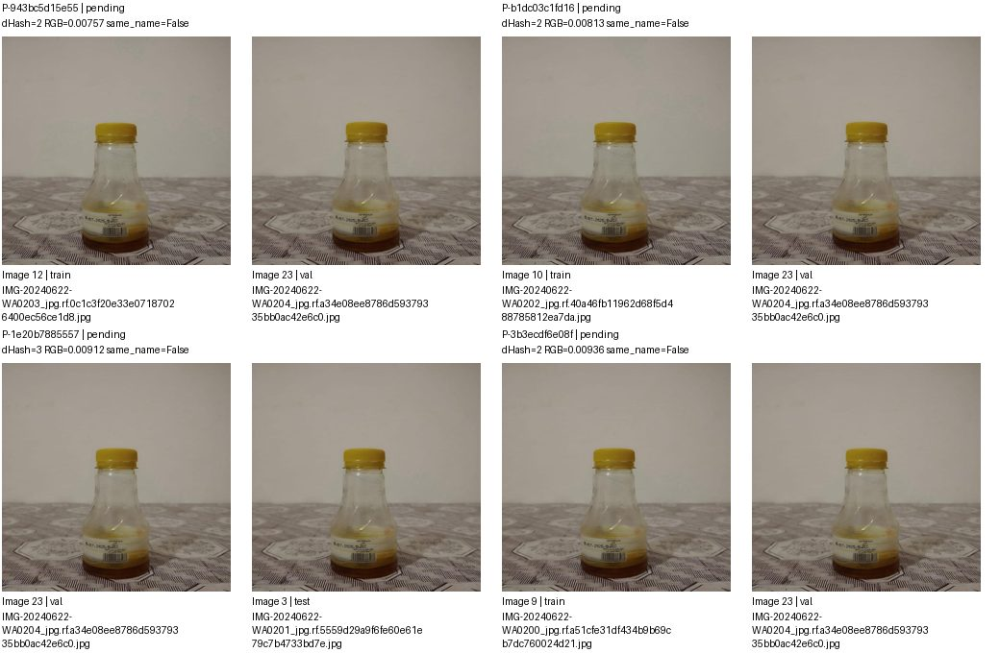

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-943bc5d15e55,images/train/IMG-20240622-WA0203_jpg.rf.0c1c3f20e33e07187026400ec56ce1d8.jpg,images/val/IMG-20240622-WA0204_jpg.rf.a34e08ee8786d59379335bb0ac42e6c0.jpg,pending,
P-b1dc03c1fd16,images/train/IMG-20240622-WA0202_jpg.rf.40a46fb11962d68f5d488785812ea7da.jpg,images/val/IMG-20240622-WA0204_jpg.rf.a34e08ee8786d59379335bb0ac42e6c0.jpg,pending,
P-1e20b7885557,images/val/IMG-20240622-WA0204_jpg.rf.a34e08ee8786d59379335bb0ac42e6c0.jpg,images/test/IMG-20240622-WA0201_jpg.rf.5559d29a9f6fe60e61e79c7b4733bd7e.jpg,pending,
P-3b3ecdf6e08f,images/train/IMG-20240622-WA0200_jpg.rf.a51cfe31df434b9b69cb7dc760024d21.jpg,images/val/IMG-20240622-WA0204_jpg.rf.a34e08ee8786d59379335bb0ac42e6c0.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 90/166 G-aa9778b0533c | 23 ảnh, 47 cặp
Split: {'test': 3, 'train': 14, 'val': 6}
Quyết định: {'pending': 47}
Ảnh trang 3/4; cặp trang 3/12. Nhóm liên thông không phải kết luận trùng.


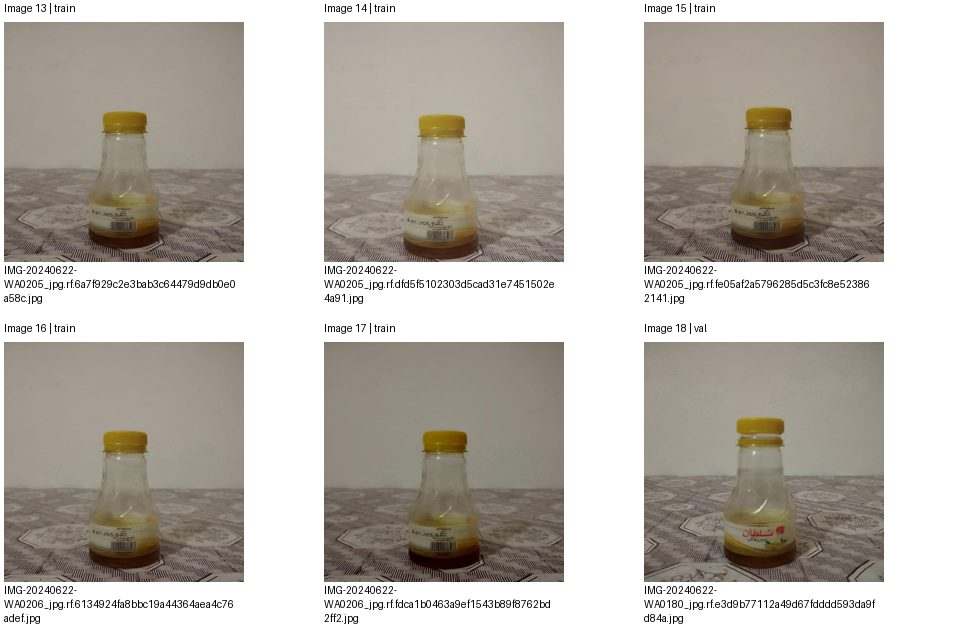

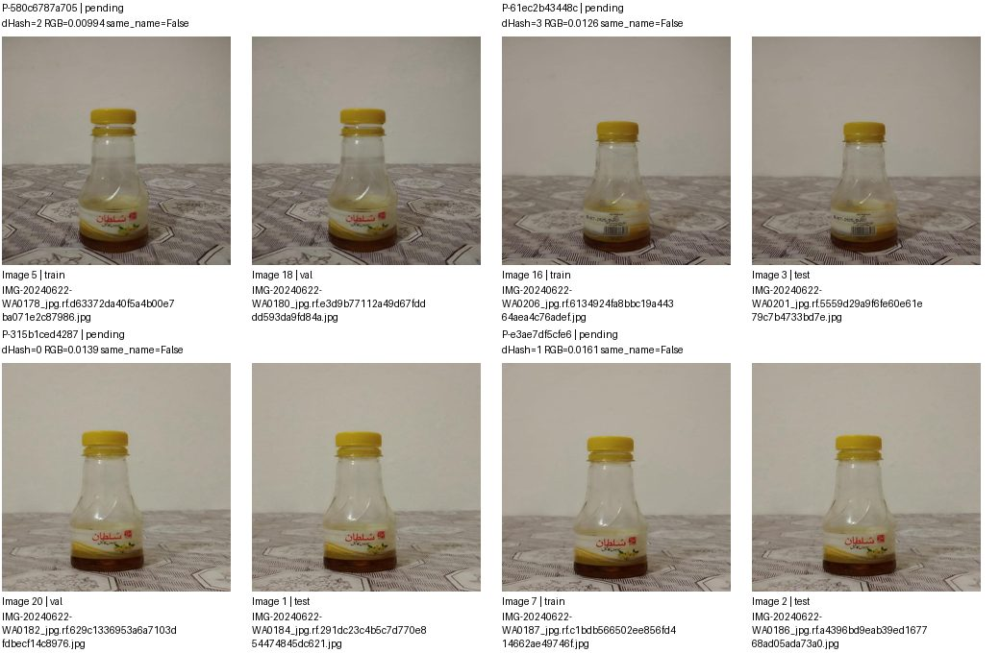

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-580c6787a705,images/train/IMG-20240622-WA0178_jpg.rf.d63372da40f5a4b00e7ba071e2c87986.jpg,images/val/IMG-20240622-WA0180_jpg.rf.e3d9b77112a49d67fdddd593da9fd84a.jpg,pending,
P-61ec2b43448c,images/train/IMG-20240622-WA0206_jpg.rf.6134924fa8bbc19a44364aea4c76adef.jpg,images/test/IMG-20240622-WA0201_jpg.rf.5559d29a9f6fe60e61e79c7b4733bd7e.jpg,pending,
P-315b1ced4287,images/val/IMG-20240622-WA0182_jpg.rf.629c1336953a6a7103dfdbecf14c8976.jpg,images/test/IMG-20240622-WA0184_jpg.rf.291dc23c4b5c7d770e854474845dc621.jpg,pending,
P-e3ae7df5cfe6,images/train/IMG-20240622-WA0187_jpg.rf.c1bdb566502ee856fd414662ae49746f.jpg,images/test/IMG-20240622-WA0186_jpg.rf.a4396bd9eab39ed167768ad05ada73a0.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 90/166 G-aa9778b0533c | 23 ảnh, 47 cặp
Split: {'test': 3, 'train': 14, 'val': 6}
Quyết định: {'pending': 47}
Ảnh trang 4/4; cặp trang 4/12. Nhóm liên thông không phải kết luận trùng.


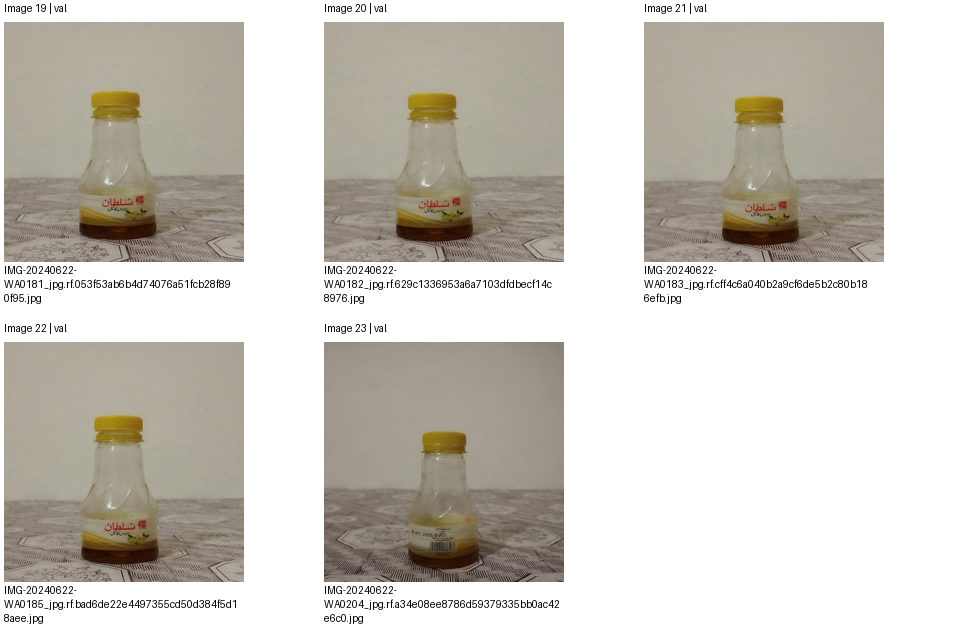

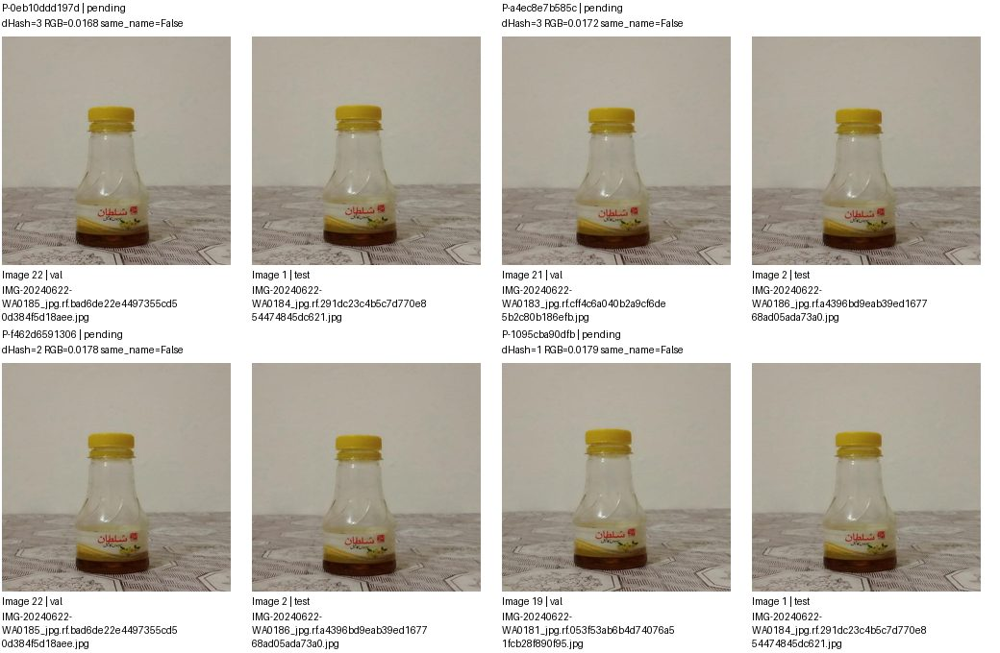

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-0eb10ddd197d,images/val/IMG-20240622-WA0185_jpg.rf.bad6de22e4497355cd50d384f5d18aee.jpg,images/test/IMG-20240622-WA0184_jpg.rf.291dc23c4b5c7d770e854474845dc621.jpg,pending,
P-a4ec8e7b585c,images/val/IMG-20240622-WA0183_jpg.rf.cff4c6a040b2a9cf6de5b2c80b186efb.jpg,images/test/IMG-20240622-WA0186_jpg.rf.a4396bd9eab39ed167768ad05ada73a0.jpg,pending,
P-f462d6591306,images/val/IMG-20240622-WA0185_jpg.rf.bad6de22e4497355cd50d384f5d18aee.jpg,images/test/IMG-20240622-WA0186_jpg.rf.a4396bd9eab39ed167768ad05ada73a0.jpg,pending,
P-1095cba90dfb,images/val/IMG-20240622-WA0181_jpg.rf.053f53ab6b4d74076a51fcb28f890f95.jpg,images/test/IMG-20240622-WA0184_jpg.rf.291dc23c4b5c7d770e854474845dc621.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 90/166 G-aa9778b0533c | 23 ảnh, 47 cặp
Split: {'test': 3, 'train': 14, 'val': 6}
Quyết định: {'pending': 47}
Ảnh trang None/4; cặp trang 5/12. Nhóm liên thông không phải kết luận trùng.


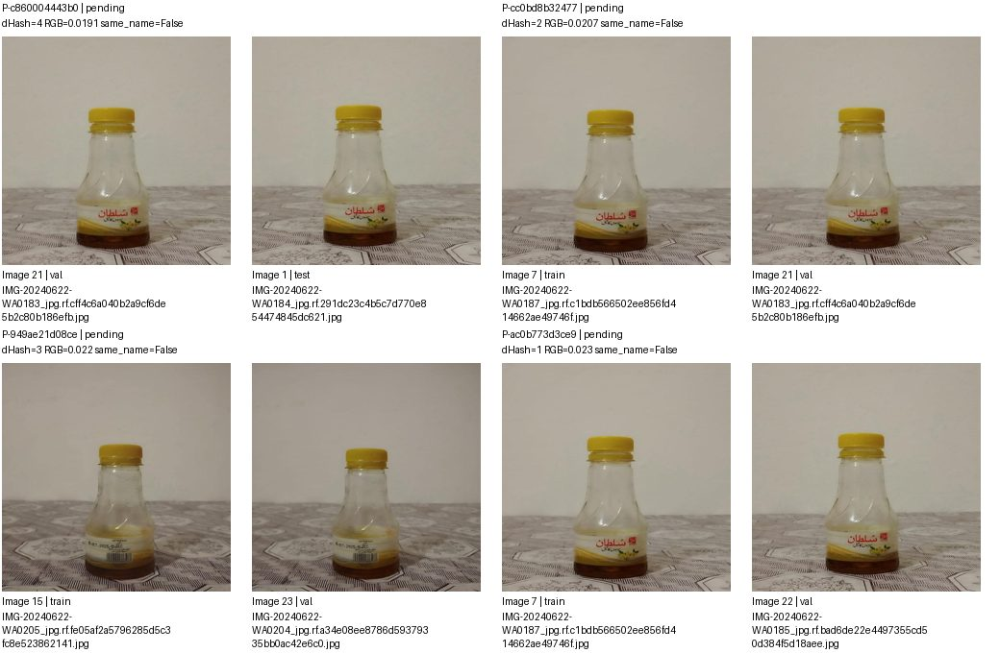

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-c860004443b0,images/val/IMG-20240622-WA0183_jpg.rf.cff4c6a040b2a9cf6de5b2c80b186efb.jpg,images/test/IMG-20240622-WA0184_jpg.rf.291dc23c4b5c7d770e854474845dc621.jpg,pending,
P-cc0bd8b32477,images/train/IMG-20240622-WA0187_jpg.rf.c1bdb566502ee856fd414662ae49746f.jpg,images/val/IMG-20240622-WA0183_jpg.rf.cff4c6a040b2a9cf6de5b2c80b186efb.jpg,pending,
P-949ae21d08ce,images/train/IMG-20240622-WA0205_jpg.rf.fe05af2a5796285d5c3fc8e523862141.jpg,images/val/IMG-20240622-WA0204_jpg.rf.a34e08ee8786d59379335bb0ac42e6c0.jpg,pending,
P-ac0b773d3ce9,images/train/IMG-20240622-WA0187_jpg.rf.c1bdb566502ee856fd414662ae49746f.jpg,images/val/IMG-20240622-WA0185_jpg.rf.bad6de22e4497355cd50d384f5d18aee.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 90/166 G-aa9778b0533c | 23 ảnh, 47 cặp
Split: {'test': 3, 'train': 14, 'val': 6}
Quyết định: {'pending': 47}
Ảnh trang None/4; cặp trang 6/12. Nhóm liên thông không phải kết luận trùng.


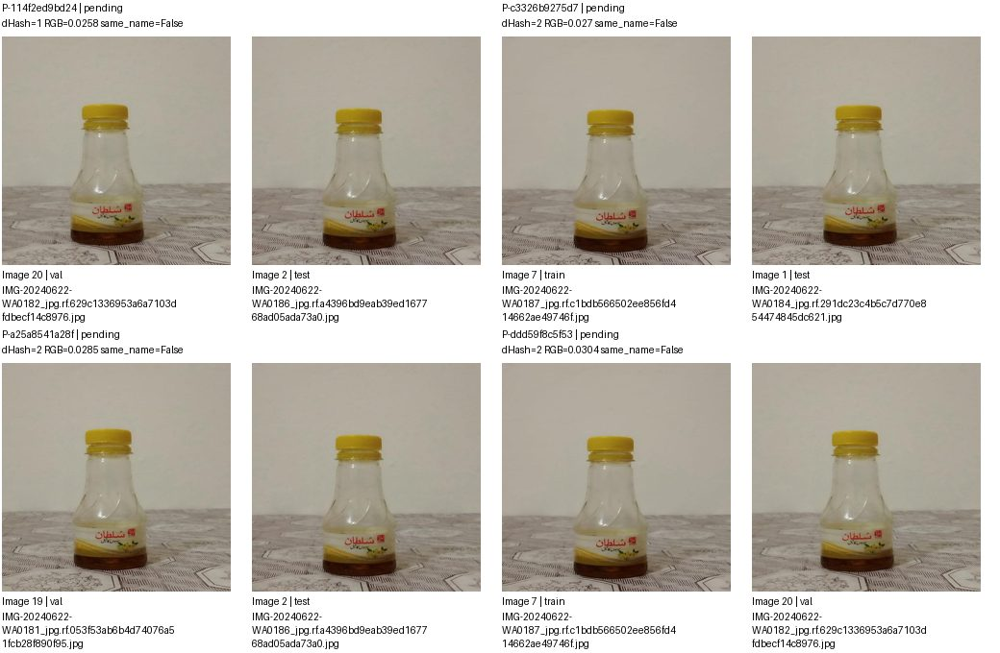

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-114f2ed9bd24,images/val/IMG-20240622-WA0182_jpg.rf.629c1336953a6a7103dfdbecf14c8976.jpg,images/test/IMG-20240622-WA0186_jpg.rf.a4396bd9eab39ed167768ad05ada73a0.jpg,pending,
P-c3326b9275d7,images/train/IMG-20240622-WA0187_jpg.rf.c1bdb566502ee856fd414662ae49746f.jpg,images/test/IMG-20240622-WA0184_jpg.rf.291dc23c4b5c7d770e854474845dc621.jpg,pending,
P-a25a8541a28f,images/val/IMG-20240622-WA0181_jpg.rf.053f53ab6b4d74076a51fcb28f890f95.jpg,images/test/IMG-20240622-WA0186_jpg.rf.a4396bd9eab39ed167768ad05ada73a0.jpg,pending,
P-ddd59f8c5f53,images/train/IMG-20240622-WA0187_jpg.rf.c1bdb566502ee856fd414662ae49746f.jpg,images/val/IMG-20240622-WA0182_jpg.rf.629c1336953a6a7103dfdbecf14c8976.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 90/166 G-aa9778b0533c | 23 ảnh, 47 cặp
Split: {'test': 3, 'train': 14, 'val': 6}
Quyết định: {'pending': 47}
Ảnh trang None/4; cặp trang 7/12. Nhóm liên thông không phải kết luận trùng.


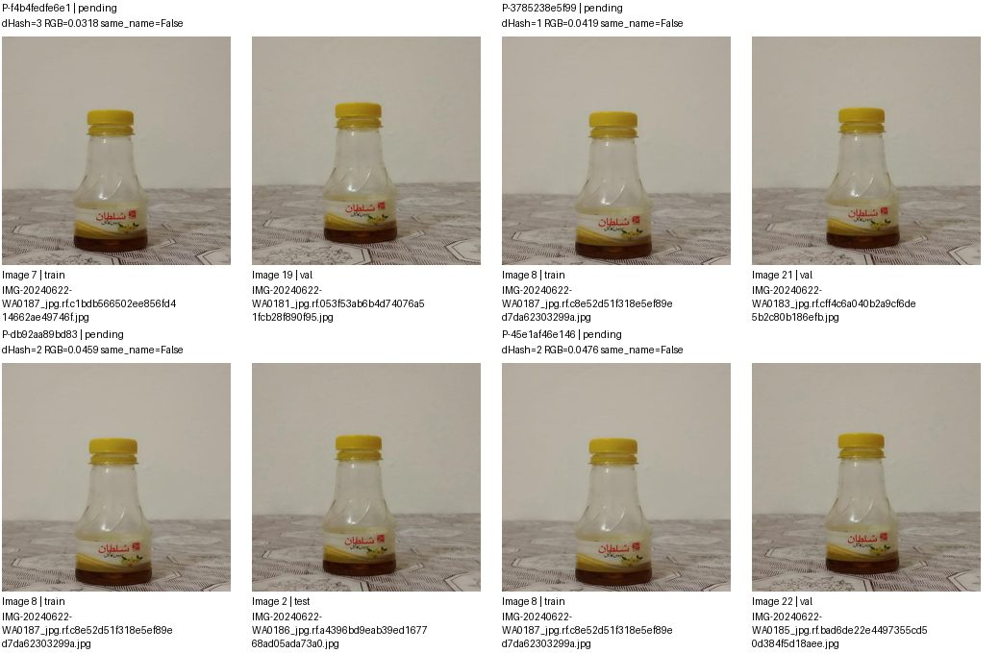

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-f4b4fedfe6e1,images/train/IMG-20240622-WA0187_jpg.rf.c1bdb566502ee856fd414662ae49746f.jpg,images/val/IMG-20240622-WA0181_jpg.rf.053f53ab6b4d74076a51fcb28f890f95.jpg,pending,
P-3785238e5f99,images/train/IMG-20240622-WA0187_jpg.rf.c8e52d51f318e5ef89ed7da62303299a.jpg,images/val/IMG-20240622-WA0183_jpg.rf.cff4c6a040b2a9cf6de5b2c80b186efb.jpg,pending,
P-db92aa89bd83,images/train/IMG-20240622-WA0187_jpg.rf.c8e52d51f318e5ef89ed7da62303299a.jpg,images/test/IMG-20240622-WA0186_jpg.rf.a4396bd9eab39ed167768ad05ada73a0.jpg,pending,
P-45e1af46e146,images/train/IMG-20240622-WA0187_jpg.rf.c8e52d51f318e5ef89ed7da62303299a.jpg,images/val/IMG-20240622-WA0185_jpg.rf.bad6de22e4497355cd50d384f5d18aee.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 90/166 G-aa9778b0533c | 23 ảnh, 47 cặp
Split: {'test': 3, 'train': 14, 'val': 6}
Quyết định: {'pending': 47}
Ảnh trang None/4; cặp trang 8/12. Nhóm liên thông không phải kết luận trùng.


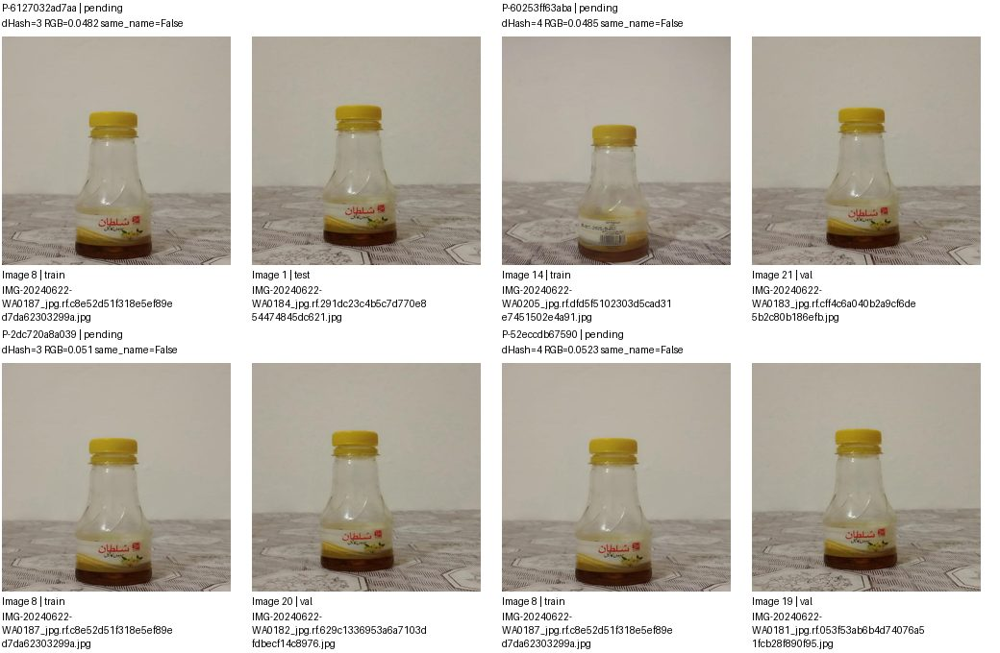

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-6127032ad7aa,images/train/IMG-20240622-WA0187_jpg.rf.c8e52d51f318e5ef89ed7da62303299a.jpg,images/test/IMG-20240622-WA0184_jpg.rf.291dc23c4b5c7d770e854474845dc621.jpg,pending,
P-60253ff63aba,images/train/IMG-20240622-WA0205_jpg.rf.dfd5f5102303d5cad31e7451502e4a91.jpg,images/val/IMG-20240622-WA0183_jpg.rf.cff4c6a040b2a9cf6de5b2c80b186efb.jpg,pending,
P-2dc720a8a039,images/train/IMG-20240622-WA0187_jpg.rf.c8e52d51f318e5ef89ed7da62303299a.jpg,images/val/IMG-20240622-WA0182_jpg.rf.629c1336953a6a7103dfdbecf14c8976.jpg,pending,
P-52eccdb67590,images/train/IMG-20240622-WA0187_jpg.rf.c8e52d51f318e5ef89ed7da62303299a.jpg,images/val/IMG-20240622-WA0181_jpg.rf.053f53ab6b4d74076a51fcb28f890f95.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 90/166 G-aa9778b0533c | 23 ảnh, 47 cặp
Split: {'test': 3, 'train': 14, 'val': 6}
Quyết định: {'pending': 47}
Ảnh trang None/4; cặp trang 9/12. Nhóm liên thông không phải kết luận trùng.


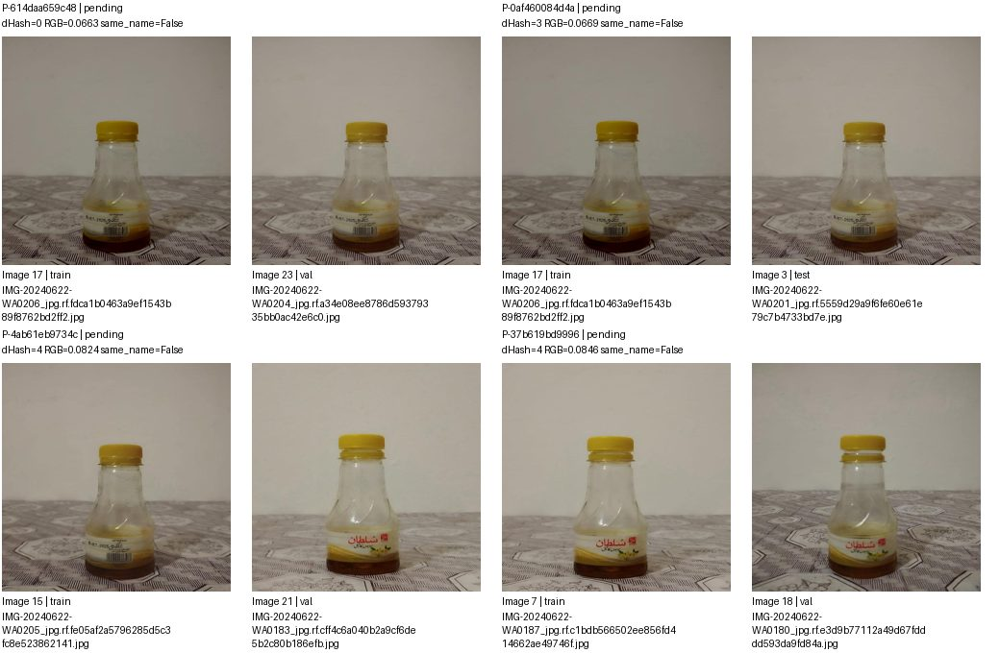

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-614daa659c48,images/train/IMG-20240622-WA0206_jpg.rf.fdca1b0463a9ef1543b89f8762bd2ff2.jpg,images/val/IMG-20240622-WA0204_jpg.rf.a34e08ee8786d59379335bb0ac42e6c0.jpg,pending,
P-0af460084d4a,images/train/IMG-20240622-WA0206_jpg.rf.fdca1b0463a9ef1543b89f8762bd2ff2.jpg,images/test/IMG-20240622-WA0201_jpg.rf.5559d29a9f6fe60e61e79c7b4733bd7e.jpg,pending,
P-4ab61eb9734c,images/train/IMG-20240622-WA0205_jpg.rf.fe05af2a5796285d5c3fc8e523862141.jpg,images/val/IMG-20240622-WA0183_jpg.rf.cff4c6a040b2a9cf6de5b2c80b186efb.jpg,pending,
P-37b619bd9996,images/train/IMG-20240622-WA0187_jpg.rf.c1bdb566502ee856fd414662ae49746f.jpg,images/val/IMG-20240622-WA0180_jpg.rf.e3d9b77112a49d67fdddd593da9fd84a.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 90/166 G-aa9778b0533c | 23 ảnh, 47 cặp
Split: {'test': 3, 'train': 14, 'val': 6}
Quyết định: {'pending': 47}
Ảnh trang None/4; cặp trang 10/12. Nhóm liên thông không phải kết luận trùng.


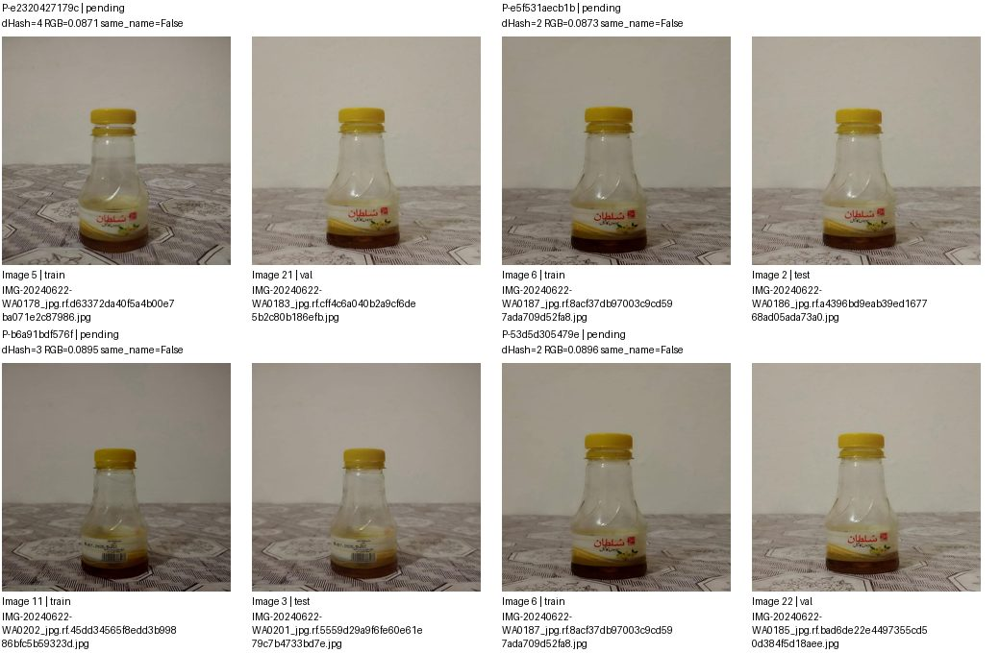

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-e2320427179c,images/train/IMG-20240622-WA0178_jpg.rf.d63372da40f5a4b00e7ba071e2c87986.jpg,images/val/IMG-20240622-WA0183_jpg.rf.cff4c6a040b2a9cf6de5b2c80b186efb.jpg,pending,
P-e5f531aecb1b,images/train/IMG-20240622-WA0187_jpg.rf.8acf37db97003c9cd597ada709d52fa8.jpg,images/test/IMG-20240622-WA0186_jpg.rf.a4396bd9eab39ed167768ad05ada73a0.jpg,pending,
P-b6a91bdf576f,images/train/IMG-20240622-WA0202_jpg.rf.45dd34565f8edd3b99886bfc5b59323d.jpg,images/test/IMG-20240622-WA0201_jpg.rf.5559d29a9f6fe60e61e79c7b4733bd7e.jpg,pending,
P-53d5d305479e,images/train/IMG-20240622-WA0187_jpg.rf.8acf37db97003c9cd597ada709d52fa8.jpg,images/val/IMG-20240622-WA0185_jpg.rf.bad6de22e4497355cd50d384f5d18aee.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 90/166 G-aa9778b0533c | 23 ảnh, 47 cặp
Split: {'test': 3, 'train': 14, 'val': 6}
Quyết định: {'pending': 47}
Ảnh trang None/4; cặp trang 11/12. Nhóm liên thông không phải kết luận trùng.


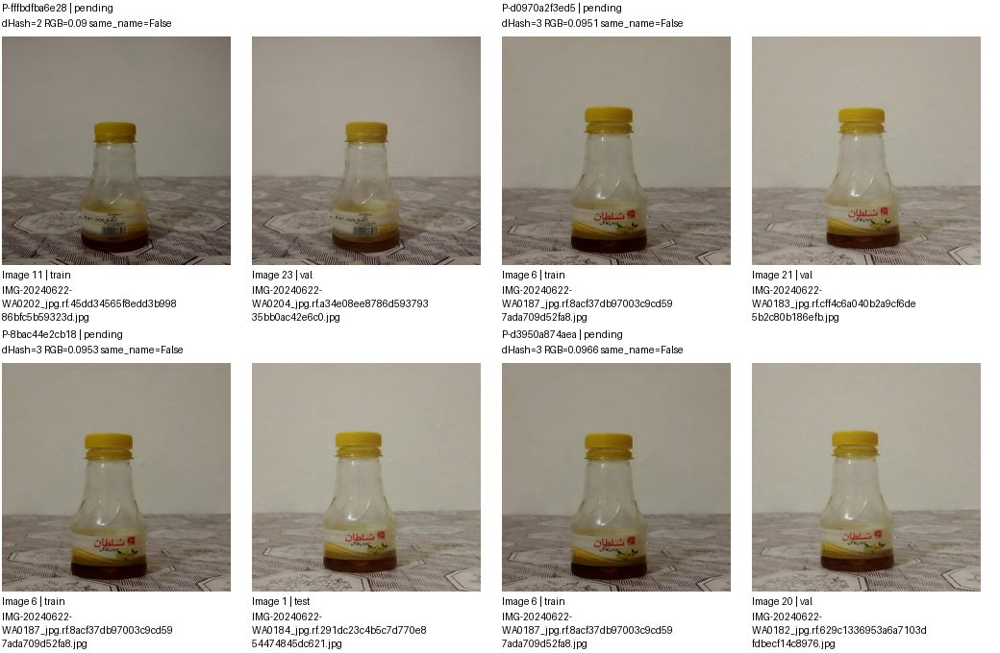

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-fffbdfba6e28,images/train/IMG-20240622-WA0202_jpg.rf.45dd34565f8edd3b99886bfc5b59323d.jpg,images/val/IMG-20240622-WA0204_jpg.rf.a34e08ee8786d59379335bb0ac42e6c0.jpg,pending,
P-d0970a2f3ed5,images/train/IMG-20240622-WA0187_jpg.rf.8acf37db97003c9cd597ada709d52fa8.jpg,images/val/IMG-20240622-WA0183_jpg.rf.cff4c6a040b2a9cf6de5b2c80b186efb.jpg,pending,
P-8bac44e2cb18,images/train/IMG-20240622-WA0187_jpg.rf.8acf37db97003c9cd597ada709d52fa8.jpg,images/test/IMG-20240622-WA0184_jpg.rf.291dc23c4b5c7d770e854474845dc621.jpg,pending,
P-d3950a874aea,images/train/IMG-20240622-WA0187_jpg.rf.8acf37db97003c9cd597ada709d52fa8.jpg,images/val/IMG-20240622-WA0182_jpg.rf.629c1336953a6a7103dfdbecf14c8976.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 90/166 G-aa9778b0533c | 23 ảnh, 47 cặp
Split: {'test': 3, 'train': 14, 'val': 6}
Quyết định: {'pending': 47}
Ảnh trang None/4; cặp trang 12/12. Nhóm liên thông không phải kết luận trùng.


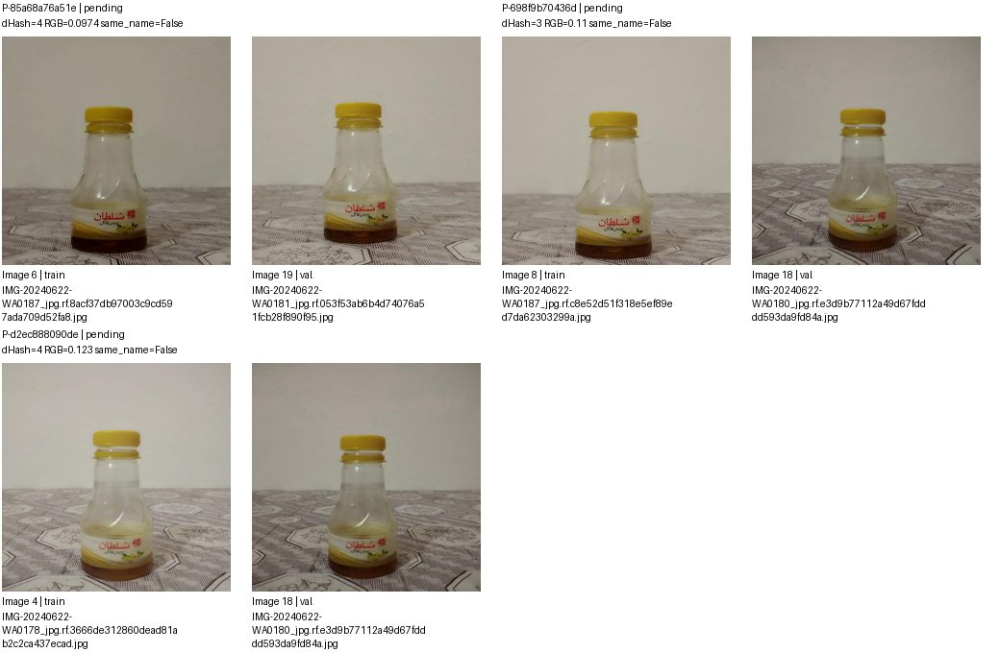

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-85a68a76a51e,images/train/IMG-20240622-WA0187_jpg.rf.8acf37db97003c9cd597ada709d52fa8.jpg,images/val/IMG-20240622-WA0181_jpg.rf.053f53ab6b4d74076a51fcb28f890f95.jpg,pending,
P-698f9b70436d,images/train/IMG-20240622-WA0187_jpg.rf.c8e52d51f318e5ef89ed7da62303299a.jpg,images/val/IMG-20240622-WA0180_jpg.rf.e3d9b77112a49d67fdddd593da9fd84a.jpg,pending,
P-d2ec888090de,images/train/IMG-20240622-WA0178_jpg.rf.3666de312860dead81ab2c2ca437ecad.jpg,images/val/IMG-20240622-WA0180_jpg.rf.e3d9b77112a49d67fdddd593da9fd84a.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 91/166 G-f2b46d371c81 | 8 ảnh, 12 cặp
Split: {'train': 6, 'val': 2}
Quyết định: {'pending': 12}
Ảnh trang 1/2; cặp trang 1/3. Nhóm liên thông không phải kết luận trùng.


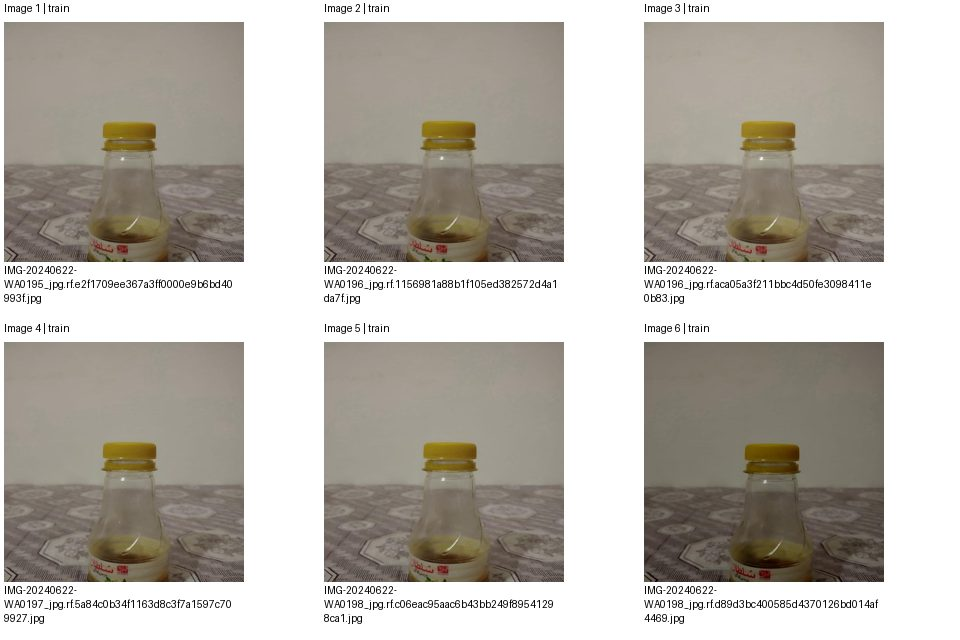

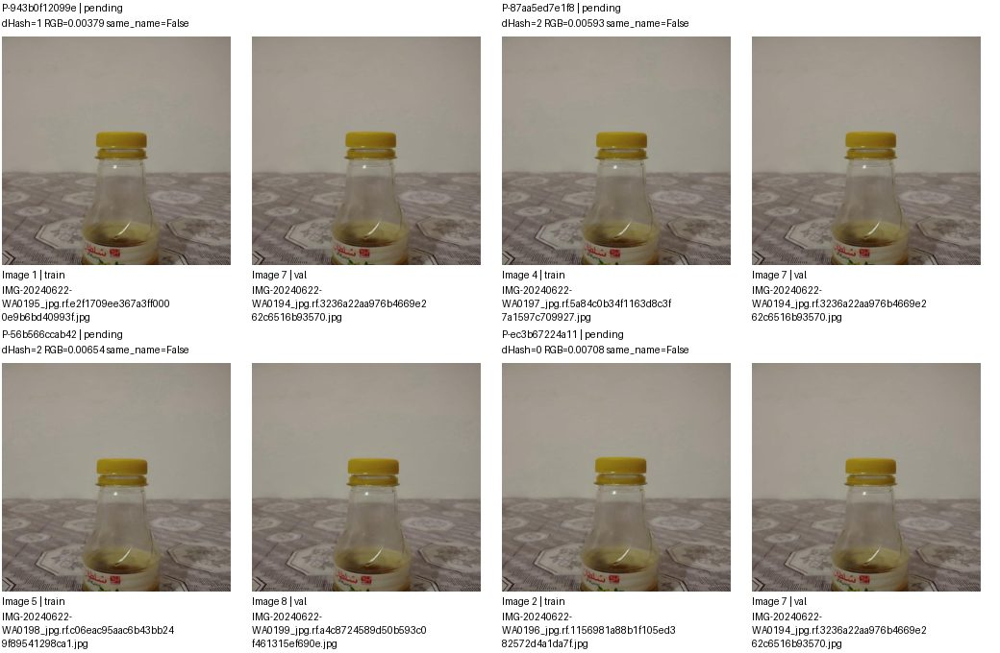

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-943b0f12099e,images/train/IMG-20240622-WA0195_jpg.rf.e2f1709ee367a3ff0000e9b6bd40993f.jpg,images/val/IMG-20240622-WA0194_jpg.rf.3236a22aa976b4669e262c6516b93570.jpg,pending,
P-87aa5ed7e1f8,images/train/IMG-20240622-WA0197_jpg.rf.5a84c0b34f1163d8c3f7a1597c709927.jpg,images/val/IMG-20240622-WA0194_jpg.rf.3236a22aa976b4669e262c6516b93570.jpg,pending,
P-56b566ccab42,images/train/IMG-20240622-WA0198_jpg.rf.c06eac95aac6b43bb249f89541298ca1.jpg,images/val/IMG-20240622-WA0199_jpg.rf.a4c8724589d50b593c0f461315ef690e.jpg,pending,
P-ec3b67224a11,images/train/IMG-20240622-WA0196_jpg.rf.1156981a88b1f105ed382572d4a1da7f.jpg,images/val/IMG-20240622-WA0194_jpg.rf.3236a22aa976b4669e262c6516b93570.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 91/166 G-f2b46d371c81 | 8 ảnh, 12 cặp
Split: {'train': 6, 'val': 2}
Quyết định: {'pending': 12}
Ảnh trang 2/2; cặp trang 2/3. Nhóm liên thông không phải kết luận trùng.


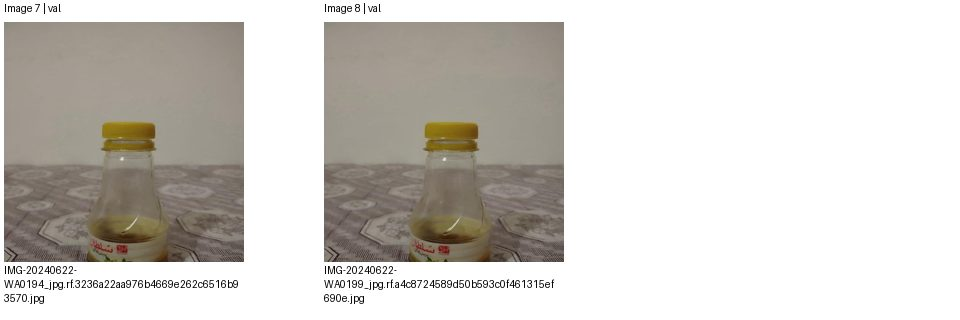

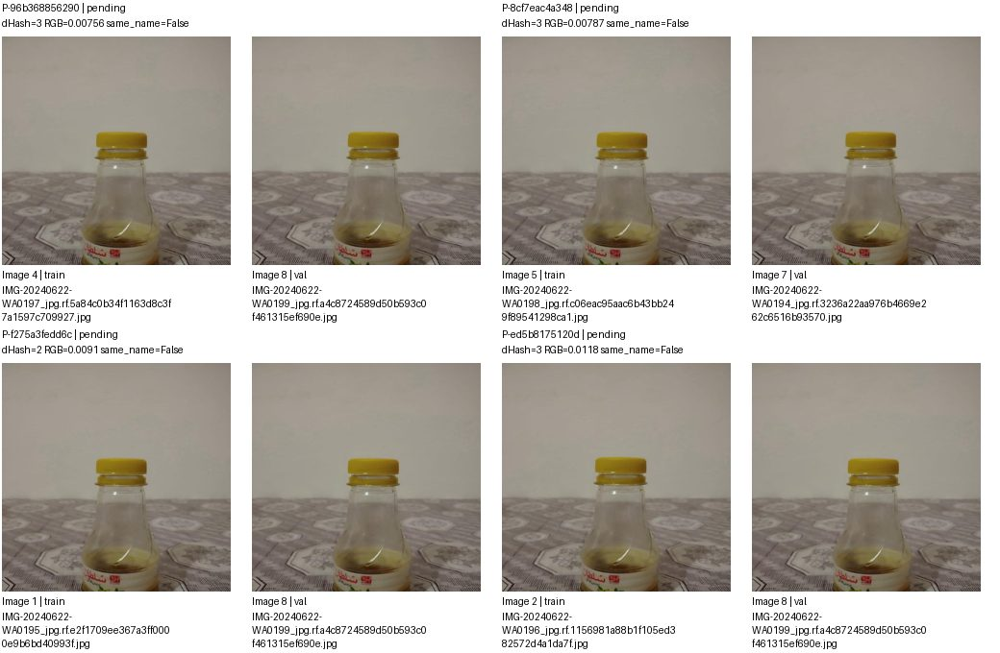

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-96b368856290,images/train/IMG-20240622-WA0197_jpg.rf.5a84c0b34f1163d8c3f7a1597c709927.jpg,images/val/IMG-20240622-WA0199_jpg.rf.a4c8724589d50b593c0f461315ef690e.jpg,pending,
P-8cf7eac4a348,images/train/IMG-20240622-WA0198_jpg.rf.c06eac95aac6b43bb249f89541298ca1.jpg,images/val/IMG-20240622-WA0194_jpg.rf.3236a22aa976b4669e262c6516b93570.jpg,pending,
P-f275a3fedd6c,images/train/IMG-20240622-WA0195_jpg.rf.e2f1709ee367a3ff0000e9b6bd40993f.jpg,images/val/IMG-20240622-WA0199_jpg.rf.a4c8724589d50b593c0f461315ef690e.jpg,pending,
P-ed5b8175120d,images/train/IMG-20240622-WA0196_jpg.rf.1156981a88b1f105ed382572d4a1da7f.jpg,images/val/IMG-20240622-WA0199_jpg.rf.a4c8724589d50b593c0f461315ef690e.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 91/166 G-f2b46d371c81 | 8 ảnh, 12 cặp
Split: {'train': 6, 'val': 2}
Quyết định: {'pending': 12}
Ảnh trang None/2; cặp trang 3/3. Nhóm liên thông không phải kết luận trùng.


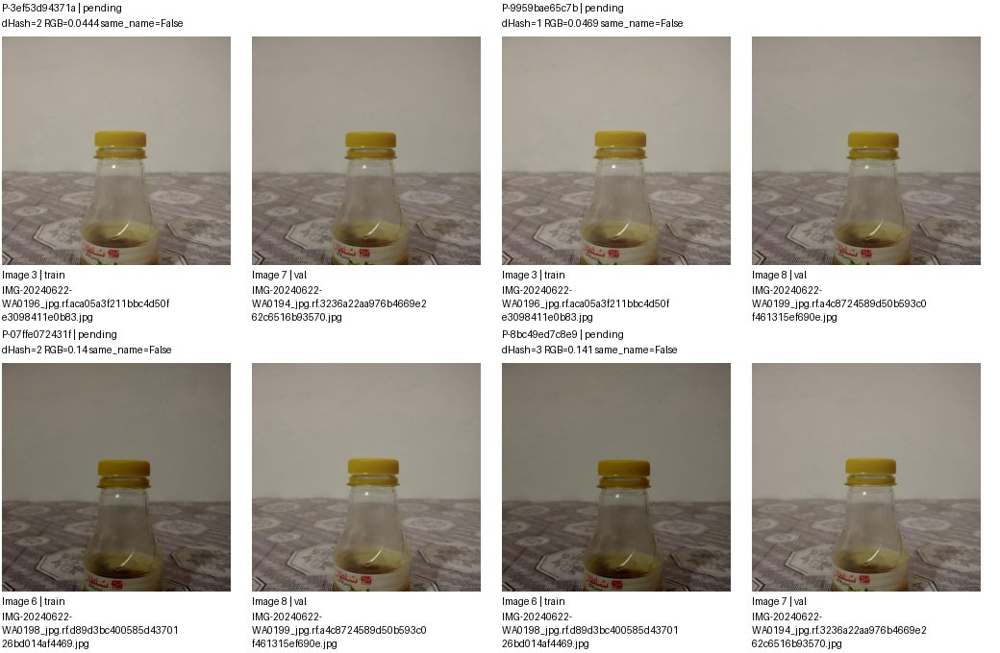

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-3ef53d94371a,images/train/IMG-20240622-WA0196_jpg.rf.aca05a3f211bbc4d50fe3098411e0b83.jpg,images/val/IMG-20240622-WA0194_jpg.rf.3236a22aa976b4669e262c6516b93570.jpg,pending,
P-9959bae65c7b,images/train/IMG-20240622-WA0196_jpg.rf.aca05a3f211bbc4d50fe3098411e0b83.jpg,images/val/IMG-20240622-WA0199_jpg.rf.a4c8724589d50b593c0f461315ef690e.jpg,pending,
P-07ffe072431f,images/train/IMG-20240622-WA0198_jpg.rf.d89d3bc400585d4370126bd014af4469.jpg,images/val/IMG-20240622-WA0199_jpg.rf.a4c8724589d50b593c0f461315ef690e.jpg,pending,
P-8bc49ed7c8e9,images/train/IMG-20240622-WA0198_jpg.rf.d89d3bc400585d4370126bd014af4469.jpg,images/val/IMG-20240622-WA0194_jpg.rf.3236a22aa976b4669e262c6516b93570.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 92/166 G-2895f5813db7 | 46 ảnh, 108 cặp
Split: {'test': 4, 'train': 35, 'val': 7}
Quyết định: {'pending': 108}
Ảnh trang 1/8; cặp trang 1/27. Nhóm liên thông không phải kết luận trùng.


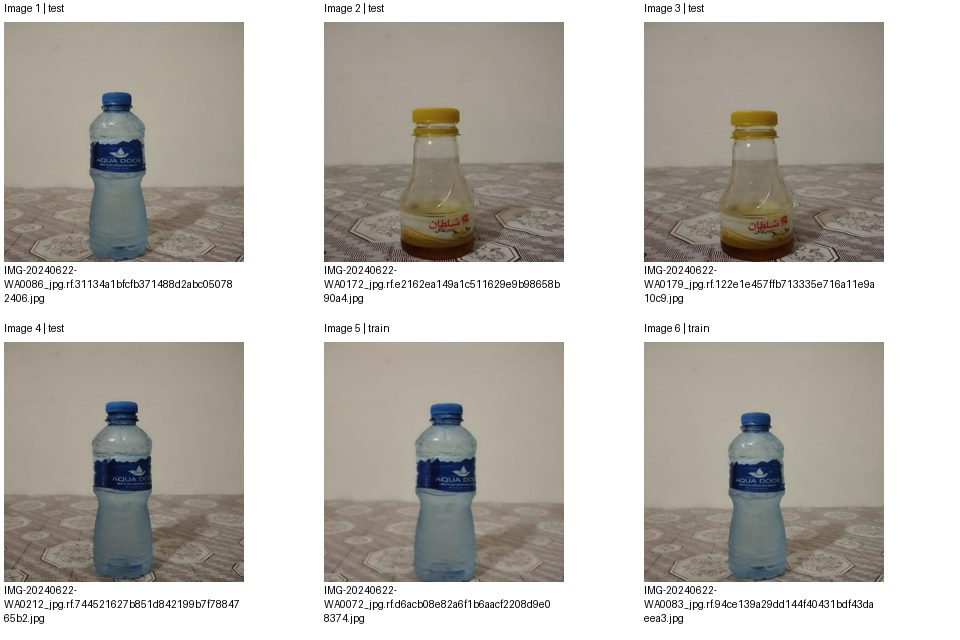

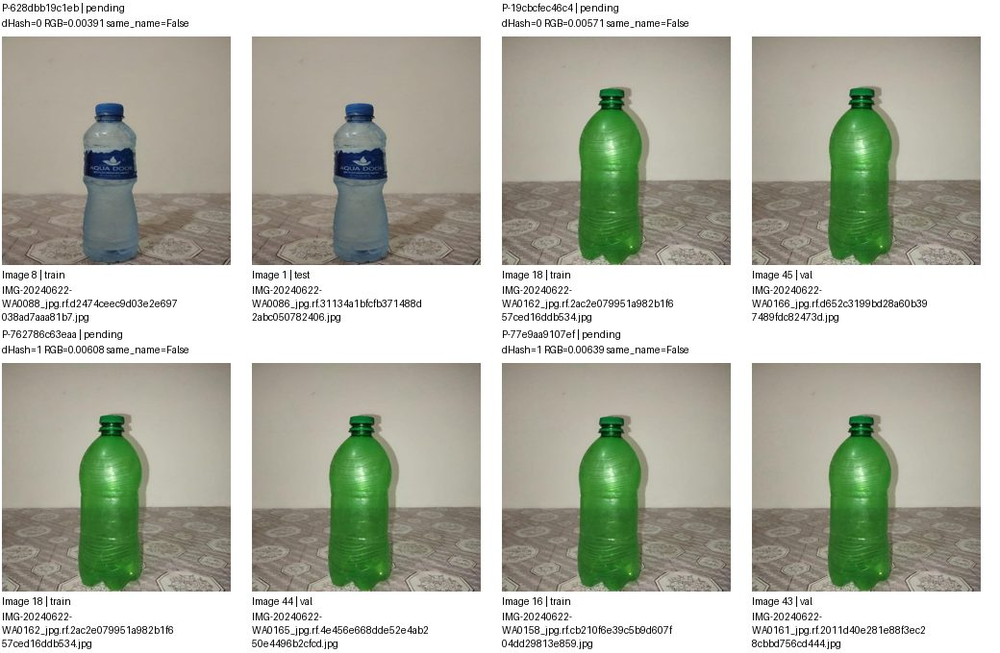

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-628dbb19c1eb,images/train/IMG-20240622-WA0088_jpg.rf.d2474ceec9d03e2e697038ad7aaa81b7.jpg,images/test/IMG-20240622-WA0086_jpg.rf.31134a1bfcfb371488d2abc050782406.jpg,pending,
P-19cbcfec46c4,images/train/IMG-20240622-WA0162_jpg.rf.2ac2e079951a982b1f657ced16ddb534.jpg,images/val/IMG-20240622-WA0166_jpg.rf.d652c3199bd28a60b397489fdc82473d.jpg,pending,
P-762786c63eaa,images/train/IMG-20240622-WA0162_jpg.rf.2ac2e079951a982b1f657ced16ddb534.jpg,images/val/IMG-20240622-WA0165_jpg.rf.4e456e668dde52e4ab250e4496b2cfcd.jpg,pending,
P-77e9aa9107ef,images/train/IMG-20240622-WA0158_jpg.rf.cb210f6e39c5b9d607f04dd29813e859.jpg,images/val/IMG-20240622-WA0161_jpg.rf.2011d40e281e88f3ec28cbbd756cd444.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 92/166 G-2895f5813db7 | 46 ảnh, 108 cặp
Split: {'test': 4, 'train': 35, 'val': 7}
Quyết định: {'pending': 108}
Ảnh trang 2/8; cặp trang 2/27. Nhóm liên thông không phải kết luận trùng.


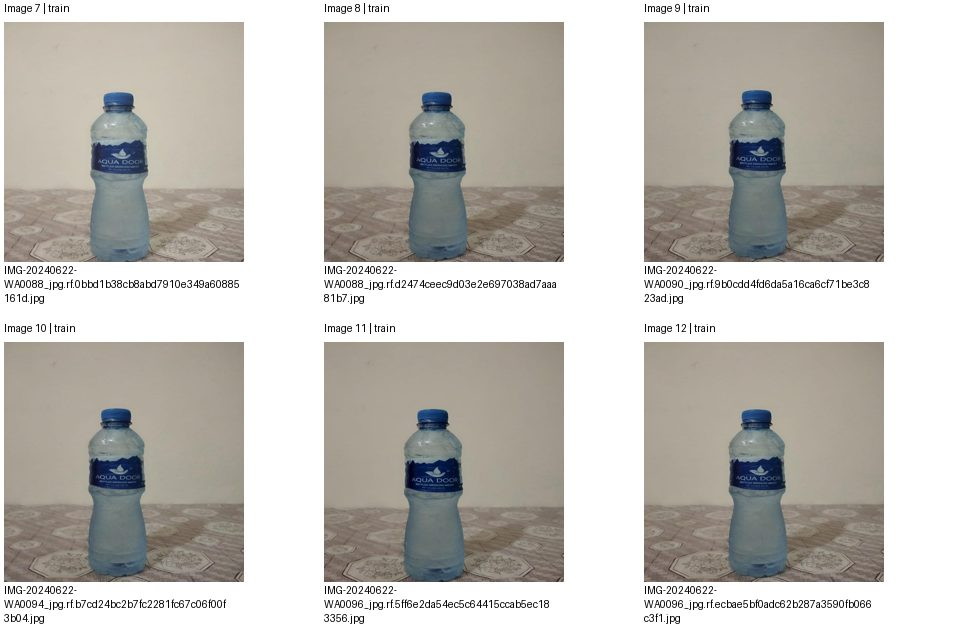

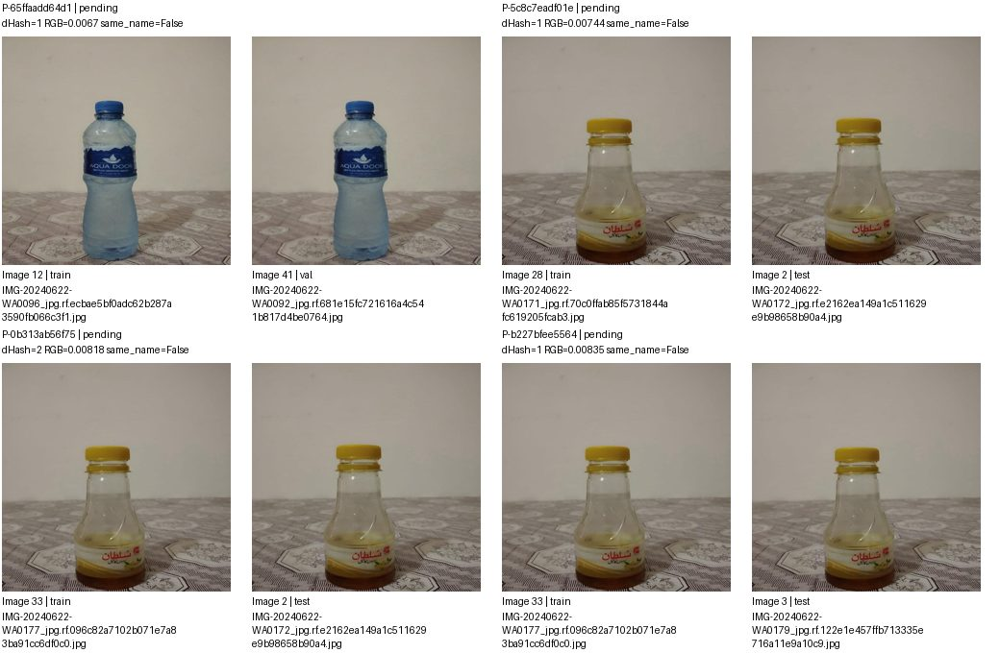

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-65ffaadd64d1,images/train/IMG-20240622-WA0096_jpg.rf.ecbae5bf0adc62b287a3590fb066c3f1.jpg,images/val/IMG-20240622-WA0092_jpg.rf.681e15fc721616a4c541b817d4be0764.jpg,pending,
P-5c8c7eadf01e,images/train/IMG-20240622-WA0171_jpg.rf.70c0ffab85f5731844afc619205fcab3.jpg,images/test/IMG-20240622-WA0172_jpg.rf.e2162ea149a1c511629e9b98658b90a4.jpg,pending,
P-0b313ab56f75,images/train/IMG-20240622-WA0177_jpg.rf.096c82a7102b071e7a83ba91cc6df0c0.jpg,images/test/IMG-20240622-WA0172_jpg.rf.e2162ea149a1c511629e9b98658b90a4.jpg,pending,
P-b227bfee5564,images/train/IMG-20240622-WA0177_jpg.rf.096c82a7102b071e7a83ba91cc6df0c0.jpg,images/test/IMG-20240622-WA0179_jpg.rf.122e1e457ffb713335e716a11e9a10c9.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 92/166 G-2895f5813db7 | 46 ảnh, 108 cặp
Split: {'test': 4, 'train': 35, 'val': 7}
Quyết định: {'pending': 108}
Ảnh trang 3/8; cặp trang 3/27. Nhóm liên thông không phải kết luận trùng.


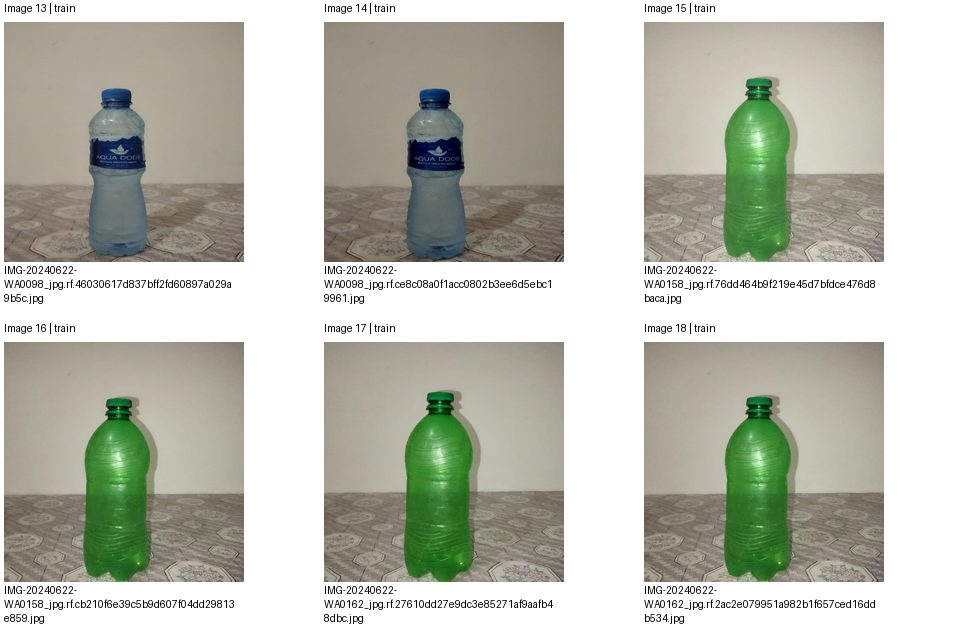

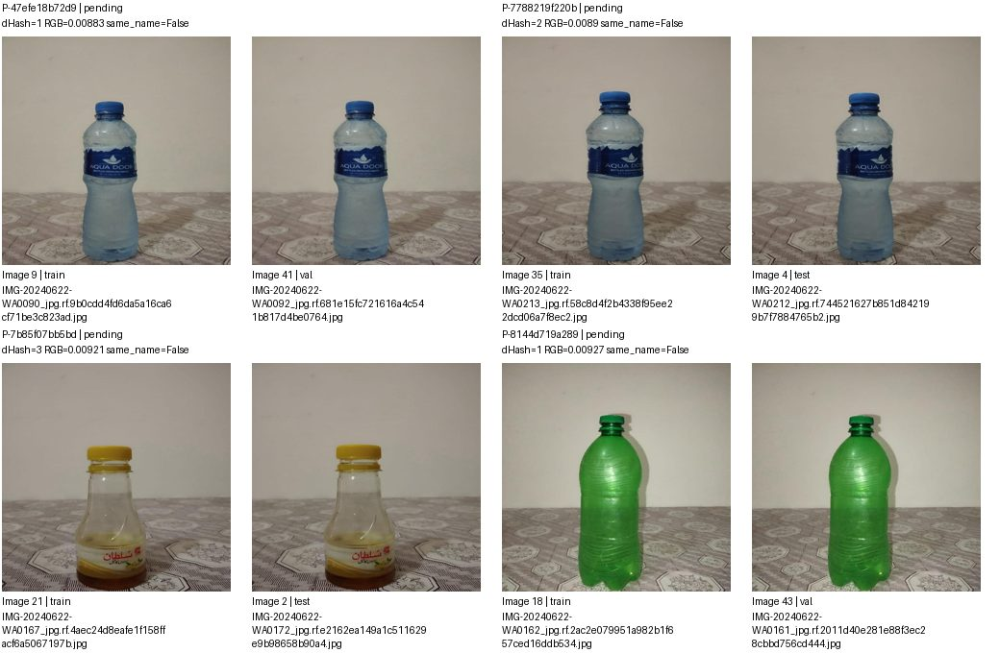

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-47efe18b72d9,images/train/IMG-20240622-WA0090_jpg.rf.9b0cdd4fd6da5a16ca6cf71be3c823ad.jpg,images/val/IMG-20240622-WA0092_jpg.rf.681e15fc721616a4c541b817d4be0764.jpg,pending,
P-7788219f220b,images/train/IMG-20240622-WA0213_jpg.rf.58c8d4f2b4338f95ee22dcd06a7f8ec2.jpg,images/test/IMG-20240622-WA0212_jpg.rf.744521627b851d842199b7f7884765b2.jpg,pending,
P-7b85f07bb5bd,images/train/IMG-20240622-WA0167_jpg.rf.4aec24d8eafe1f158ffacf6a5067197b.jpg,images/test/IMG-20240622-WA0172_jpg.rf.e2162ea149a1c511629e9b98658b90a4.jpg,pending,
P-8144d719a289,images/train/IMG-20240622-WA0162_jpg.rf.2ac2e079951a982b1f657ced16ddb534.jpg,images/val/IMG-20240622-WA0161_jpg.rf.2011d40e281e88f3ec28cbbd756cd444.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 92/166 G-2895f5813db7 | 46 ảnh, 108 cặp
Split: {'test': 4, 'train': 35, 'val': 7}
Quyết định: {'pending': 108}
Ảnh trang 4/8; cặp trang 4/27. Nhóm liên thông không phải kết luận trùng.


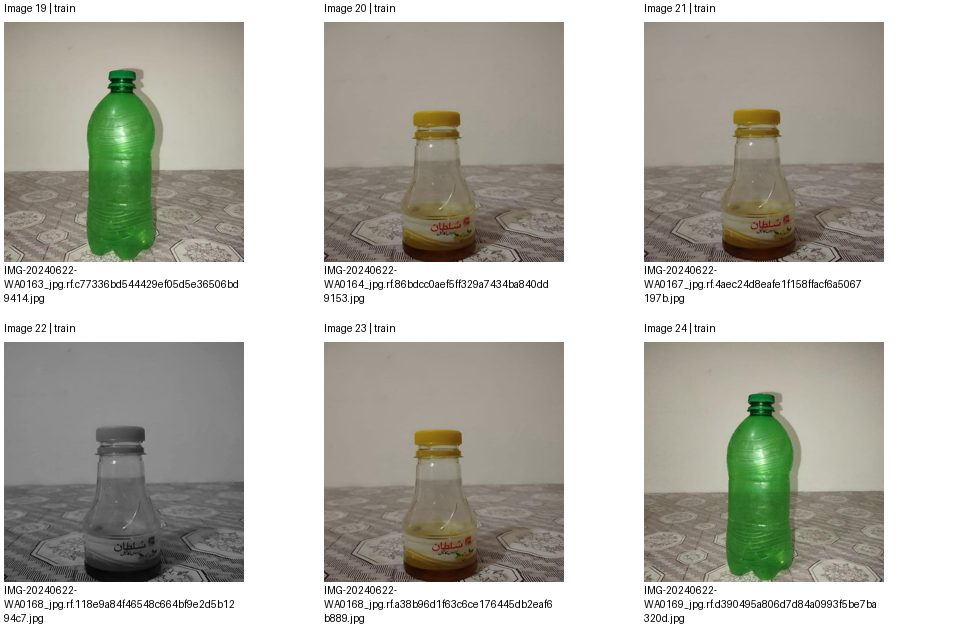

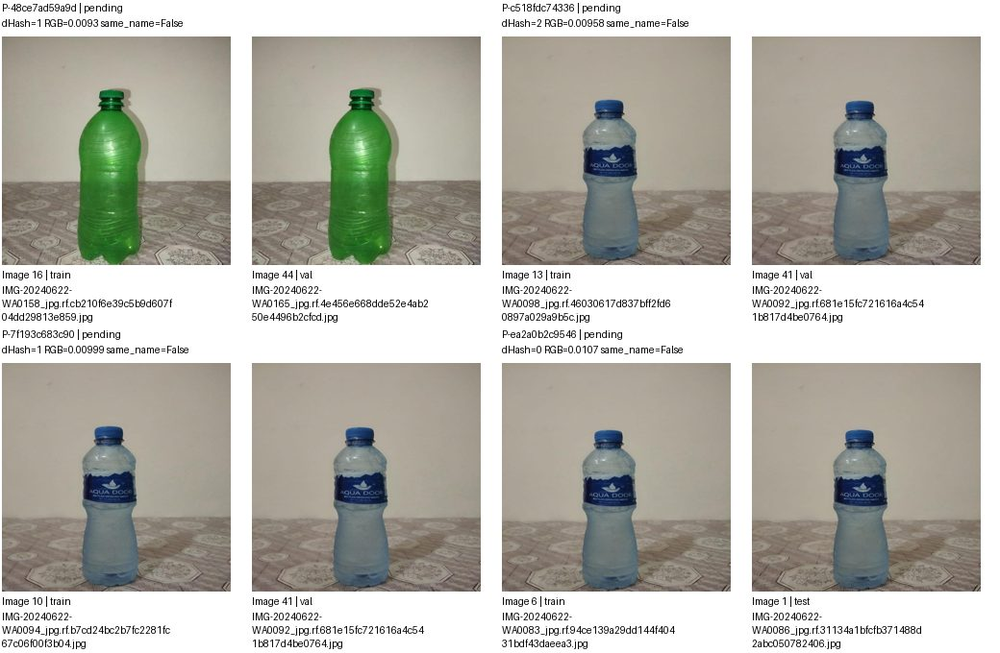

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-48ce7ad59a9d,images/train/IMG-20240622-WA0158_jpg.rf.cb210f6e39c5b9d607f04dd29813e859.jpg,images/val/IMG-20240622-WA0165_jpg.rf.4e456e668dde52e4ab250e4496b2cfcd.jpg,pending,
P-c518fdc74336,images/train/IMG-20240622-WA0098_jpg.rf.46030617d837bff2fd60897a029a9b5c.jpg,images/val/IMG-20240622-WA0092_jpg.rf.681e15fc721616a4c541b817d4be0764.jpg,pending,
P-7f193c683c90,images/train/IMG-20240622-WA0094_jpg.rf.b7cd24bc2b7fc2281fc67c06f00f3b04.jpg,images/val/IMG-20240622-WA0092_jpg.rf.681e15fc721616a4c541b817d4be0764.jpg,pending,
P-ea2a0b2c9546,images/train/IMG-20240622-WA0083_jpg.rf.94ce139a29dd144f40431bdf43daeea3.jpg,images/test/IMG-20240622-WA0086_jpg.rf.31134a1bfcfb371488d2abc050782406.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 92/166 G-2895f5813db7 | 46 ảnh, 108 cặp
Split: {'test': 4, 'train': 35, 'val': 7}
Quyết định: {'pending': 108}
Ảnh trang 5/8; cặp trang 5/27. Nhóm liên thông không phải kết luận trùng.


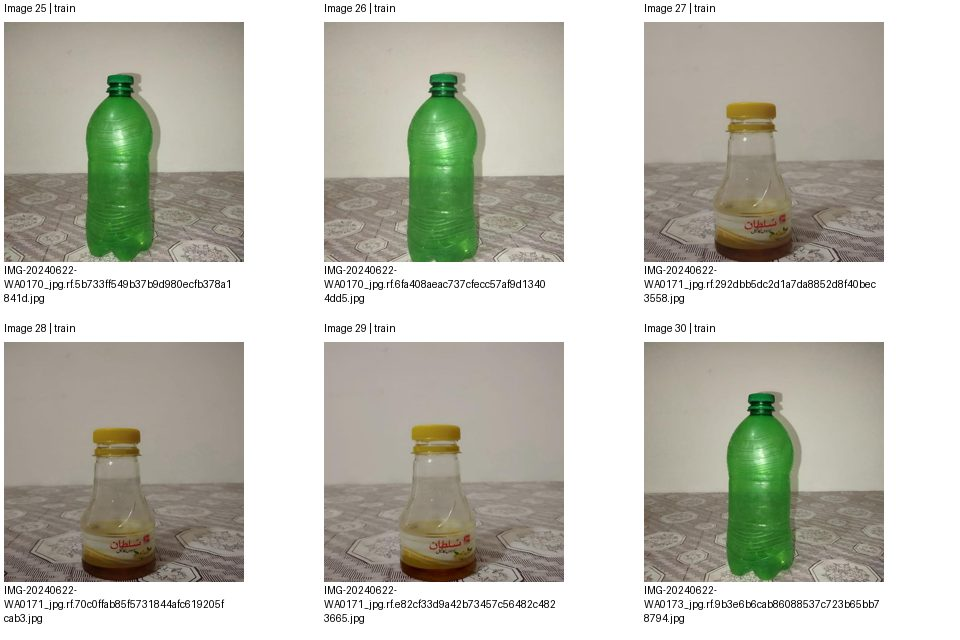

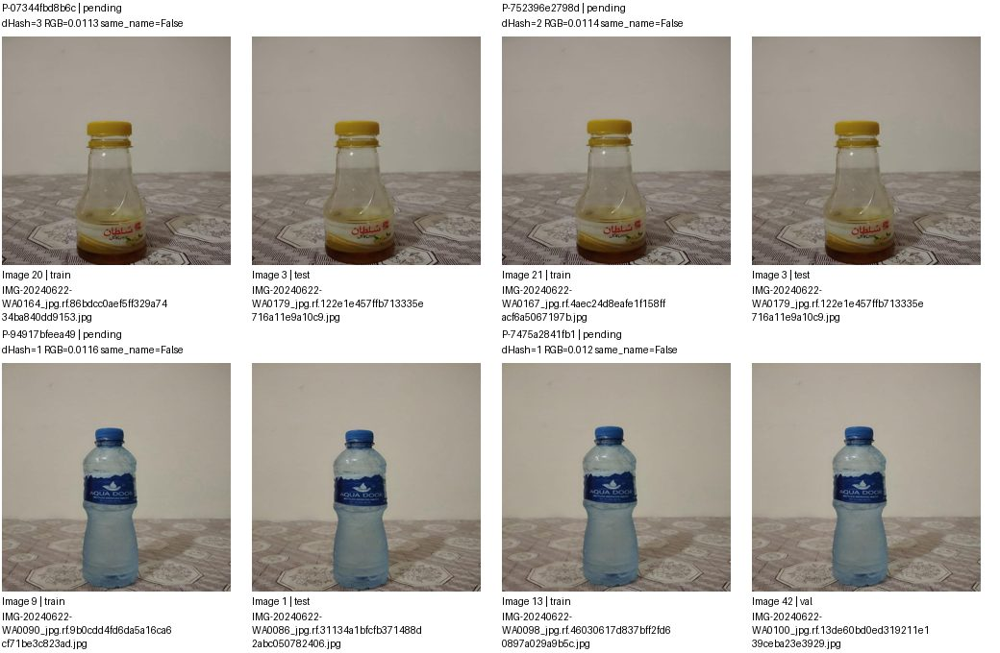

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-07344fbd8b6c,images/train/IMG-20240622-WA0164_jpg.rf.86bdcc0aef5ff329a7434ba840dd9153.jpg,images/test/IMG-20240622-WA0179_jpg.rf.122e1e457ffb713335e716a11e9a10c9.jpg,pending,
P-752396e2798d,images/train/IMG-20240622-WA0167_jpg.rf.4aec24d8eafe1f158ffacf6a5067197b.jpg,images/test/IMG-20240622-WA0179_jpg.rf.122e1e457ffb713335e716a11e9a10c9.jpg,pending,
P-94917bfeea49,images/train/IMG-20240622-WA0090_jpg.rf.9b0cdd4fd6da5a16ca6cf71be3c823ad.jpg,images/test/IMG-20240622-WA0086_jpg.rf.31134a1bfcfb371488d2abc050782406.jpg,pending,
P-7475a2841fb1,images/train/IMG-20240622-WA0098_jpg.rf.46030617d837bff2fd60897a029a9b5c.jpg,images/val/IMG-20240622-WA0100_jpg.rf.13de60bd0ed319211e139ceba23e3929.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 92/166 G-2895f5813db7 | 46 ảnh, 108 cặp
Split: {'test': 4, 'train': 35, 'val': 7}
Quyết định: {'pending': 108}
Ảnh trang 6/8; cặp trang 6/27. Nhóm liên thông không phải kết luận trùng.


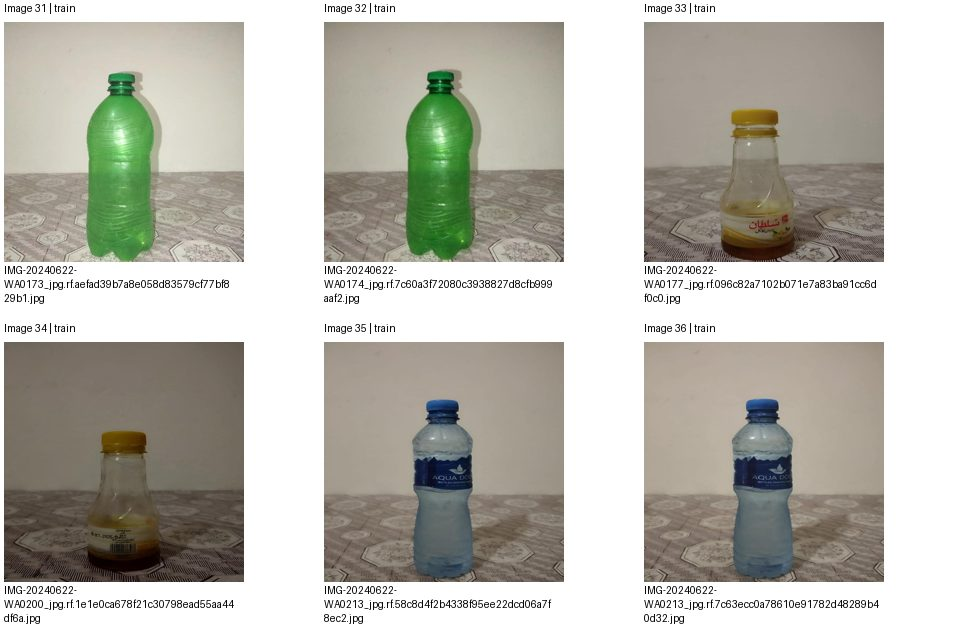

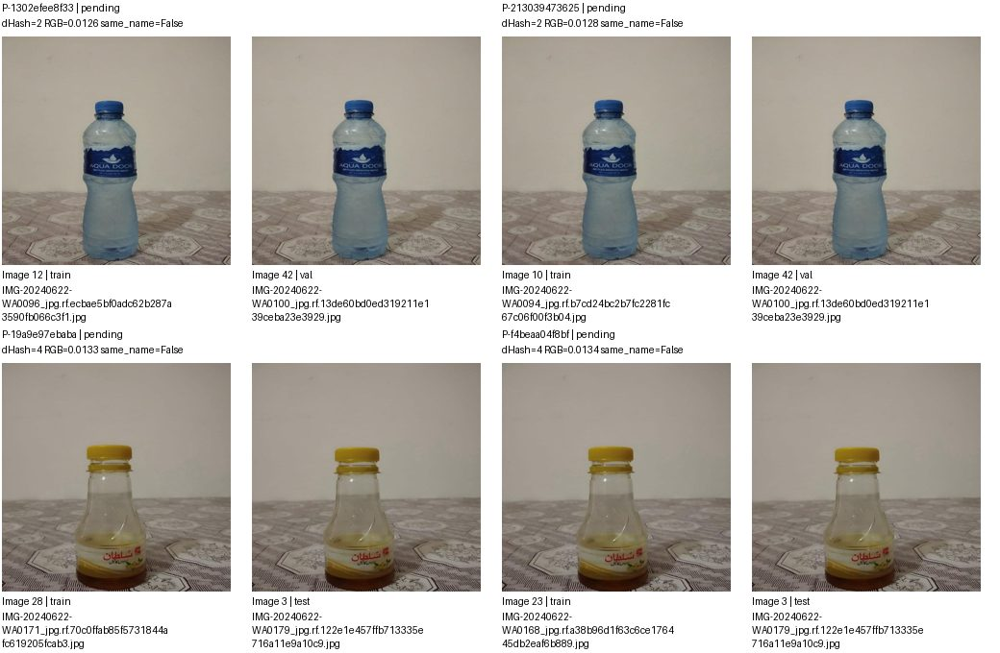

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-1302efee8f33,images/train/IMG-20240622-WA0096_jpg.rf.ecbae5bf0adc62b287a3590fb066c3f1.jpg,images/val/IMG-20240622-WA0100_jpg.rf.13de60bd0ed319211e139ceba23e3929.jpg,pending,
P-213039473625,images/train/IMG-20240622-WA0094_jpg.rf.b7cd24bc2b7fc2281fc67c06f00f3b04.jpg,images/val/IMG-20240622-WA0100_jpg.rf.13de60bd0ed319211e139ceba23e3929.jpg,pending,
P-19a9e97ebaba,images/train/IMG-20240622-WA0171_jpg.rf.70c0ffab85f5731844afc619205fcab3.jpg,images/test/IMG-20240622-WA0179_jpg.rf.122e1e457ffb713335e716a11e9a10c9.jpg,pending,
P-f4beaa04f8bf,images/train/IMG-20240622-WA0168_jpg.rf.a38b96d1f63c6ce176445db2eaf6b889.jpg,images/test/IMG-20240622-WA0179_jpg.rf.122e1e457ffb713335e716a11e9a10c9.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 92/166 G-2895f5813db7 | 46 ảnh, 108 cặp
Split: {'test': 4, 'train': 35, 'val': 7}
Quyết định: {'pending': 108}
Ảnh trang 7/8; cặp trang 7/27. Nhóm liên thông không phải kết luận trùng.


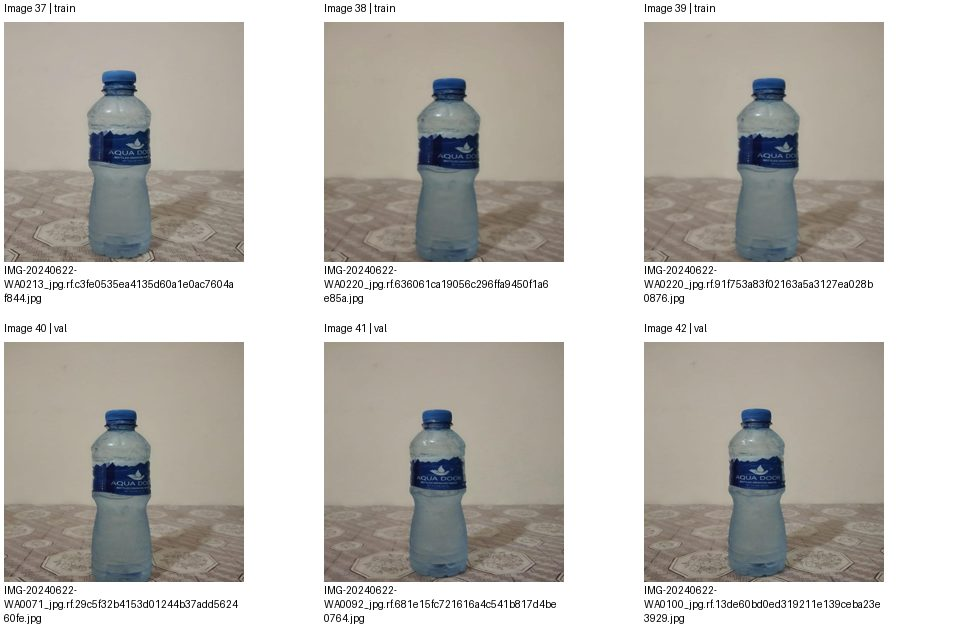

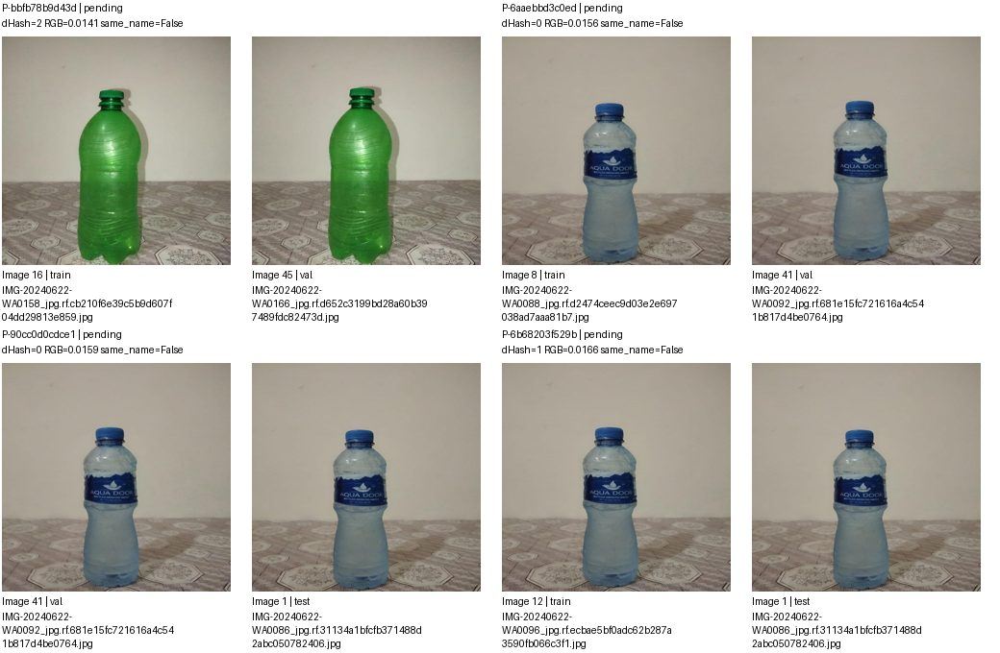

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-bbfb78b9d43d,images/train/IMG-20240622-WA0158_jpg.rf.cb210f6e39c5b9d607f04dd29813e859.jpg,images/val/IMG-20240622-WA0166_jpg.rf.d652c3199bd28a60b397489fdc82473d.jpg,pending,
P-6aaebbd3c0ed,images/train/IMG-20240622-WA0088_jpg.rf.d2474ceec9d03e2e697038ad7aaa81b7.jpg,images/val/IMG-20240622-WA0092_jpg.rf.681e15fc721616a4c541b817d4be0764.jpg,pending,
P-90cc0d0cdce1,images/val/IMG-20240622-WA0092_jpg.rf.681e15fc721616a4c541b817d4be0764.jpg,images/test/IMG-20240622-WA0086_jpg.rf.31134a1bfcfb371488d2abc050782406.jpg,pending,
P-6b68203f529b,images/train/IMG-20240622-WA0096_jpg.rf.ecbae5bf0adc62b287a3590fb066c3f1.jpg,images/test/IMG-20240622-WA0086_jpg.rf.31134a1bfcfb371488d2abc050782406.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 92/166 G-2895f5813db7 | 46 ảnh, 108 cặp
Split: {'test': 4, 'train': 35, 'val': 7}
Quyết định: {'pending': 108}
Ảnh trang 8/8; cặp trang 8/27. Nhóm liên thông không phải kết luận trùng.


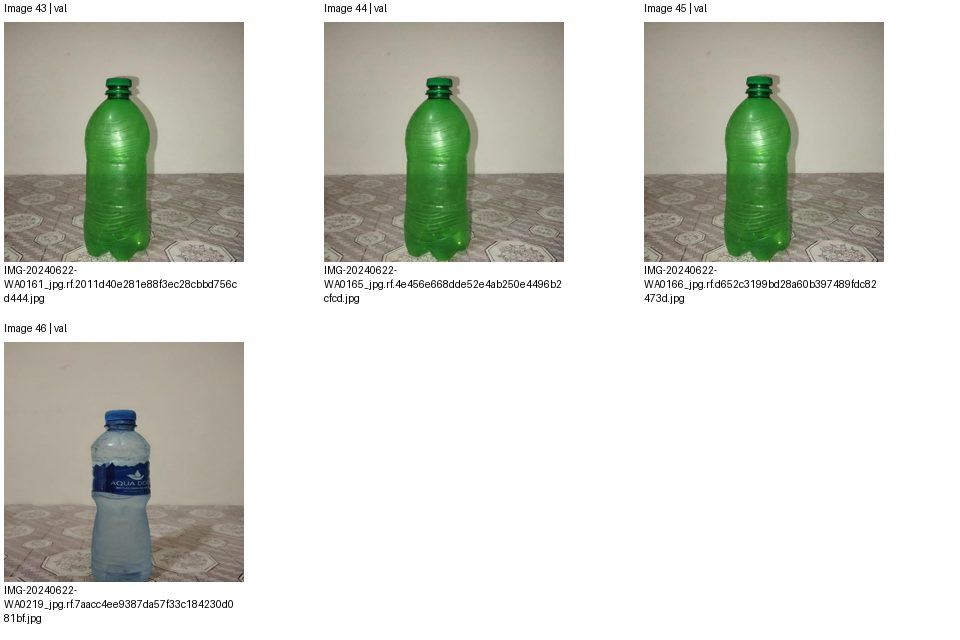

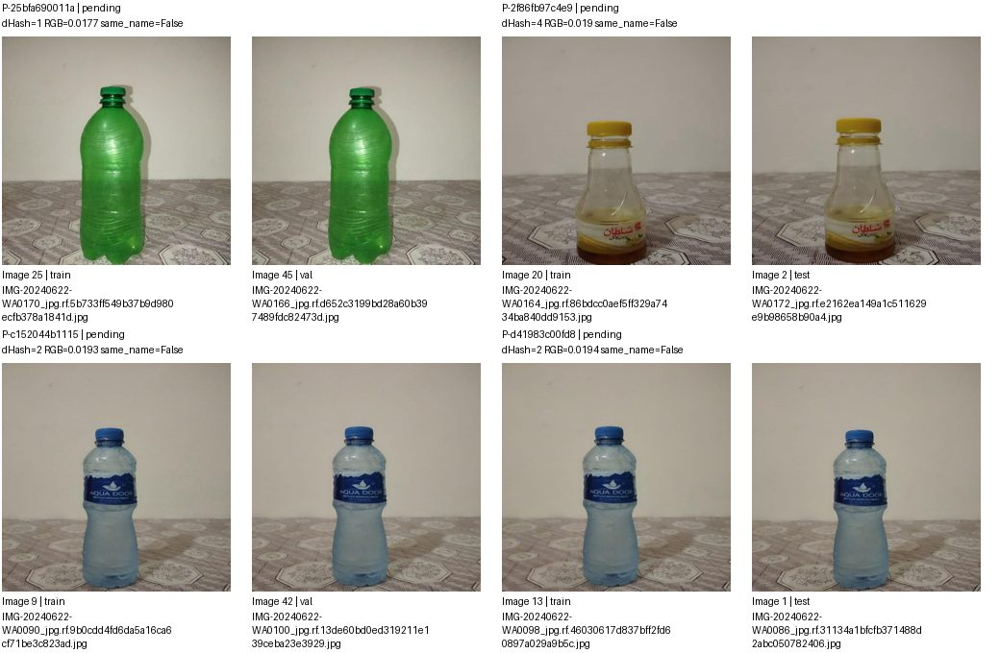

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-25bfa690011a,images/train/IMG-20240622-WA0170_jpg.rf.5b733ff549b37b9d980ecfb378a1841d.jpg,images/val/IMG-20240622-WA0166_jpg.rf.d652c3199bd28a60b397489fdc82473d.jpg,pending,
P-2f86fb97c4e9,images/train/IMG-20240622-WA0164_jpg.rf.86bdcc0aef5ff329a7434ba840dd9153.jpg,images/test/IMG-20240622-WA0172_jpg.rf.e2162ea149a1c511629e9b98658b90a4.jpg,pending,
P-c152044b1115,images/train/IMG-20240622-WA0090_jpg.rf.9b0cdd4fd6da5a16ca6cf71be3c823ad.jpg,images/val/IMG-20240622-WA0100_jpg.rf.13de60bd0ed319211e139ceba23e3929.jpg,pending,
P-d41983c00fd8,images/train/IMG-20240622-WA0098_jpg.rf.46030617d837bff2fd60897a029a9b5c.jpg,images/test/IMG-20240622-WA0086_jpg.rf.31134a1bfcfb371488d2abc050782406.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 92/166 G-2895f5813db7 | 46 ảnh, 108 cặp
Split: {'test': 4, 'train': 35, 'val': 7}
Quyết định: {'pending': 108}
Ảnh trang None/8; cặp trang 9/27. Nhóm liên thông không phải kết luận trùng.


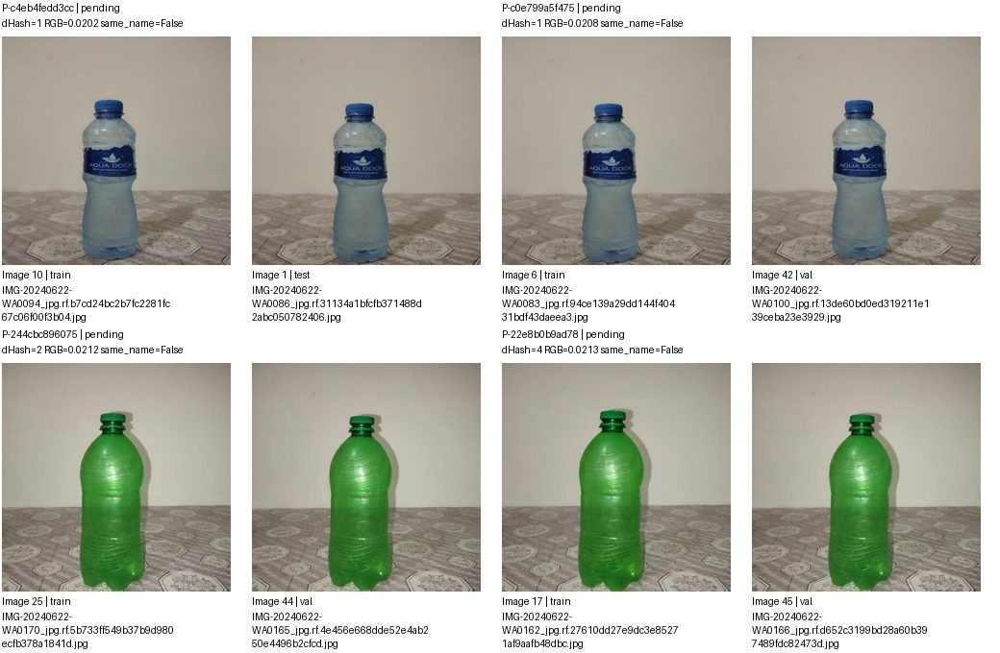

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-c4eb4fedd3cc,images/train/IMG-20240622-WA0094_jpg.rf.b7cd24bc2b7fc2281fc67c06f00f3b04.jpg,images/test/IMG-20240622-WA0086_jpg.rf.31134a1bfcfb371488d2abc050782406.jpg,pending,
P-c0e799a5f475,images/train/IMG-20240622-WA0083_jpg.rf.94ce139a29dd144f40431bdf43daeea3.jpg,images/val/IMG-20240622-WA0100_jpg.rf.13de60bd0ed319211e139ceba23e3929.jpg,pending,
P-244cbc896075,images/train/IMG-20240622-WA0170_jpg.rf.5b733ff549b37b9d980ecfb378a1841d.jpg,images/val/IMG-20240622-WA0165_jpg.rf.4e456e668dde52e4ab250e4496b2cfcd.jpg,pending,
P-22e8b0b9ad78,images/train/IMG-20240622-WA0162_jpg.rf.27610dd27e9dc3e85271af9aafb48dbc.jpg,images/val/IMG-20240622-WA0166_jpg.rf.d652c3199bd28a60b397489fdc82473d.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 92/166 G-2895f5813db7 | 46 ảnh, 108 cặp
Split: {'test': 4, 'train': 35, 'val': 7}
Quyết định: {'pending': 108}
Ảnh trang None/8; cặp trang 10/27. Nhóm liên thông không phải kết luận trùng.


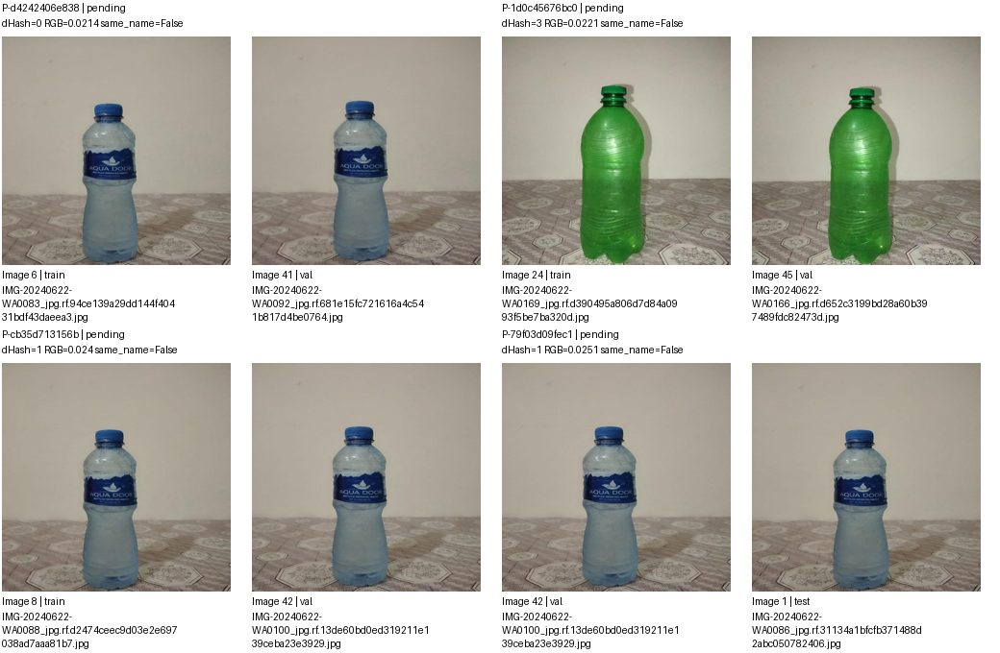

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-d4242406e838,images/train/IMG-20240622-WA0083_jpg.rf.94ce139a29dd144f40431bdf43daeea3.jpg,images/val/IMG-20240622-WA0092_jpg.rf.681e15fc721616a4c541b817d4be0764.jpg,pending,
P-1d0c45676bc0,images/train/IMG-20240622-WA0169_jpg.rf.d390495a806d7d84a0993f5be7ba320d.jpg,images/val/IMG-20240622-WA0166_jpg.rf.d652c3199bd28a60b397489fdc82473d.jpg,pending,
P-cb35d713156b,images/train/IMG-20240622-WA0088_jpg.rf.d2474ceec9d03e2e697038ad7aaa81b7.jpg,images/val/IMG-20240622-WA0100_jpg.rf.13de60bd0ed319211e139ceba23e3929.jpg,pending,
P-79f03d09fec1,images/val/IMG-20240622-WA0100_jpg.rf.13de60bd0ed319211e139ceba23e3929.jpg,images/test/IMG-20240622-WA0086_jpg.rf.31134a1bfcfb371488d2abc050782406.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 92/166 G-2895f5813db7 | 46 ảnh, 108 cặp
Split: {'test': 4, 'train': 35, 'val': 7}
Quyết định: {'pending': 108}
Ảnh trang None/8; cặp trang 11/27. Nhóm liên thông không phải kết luận trùng.


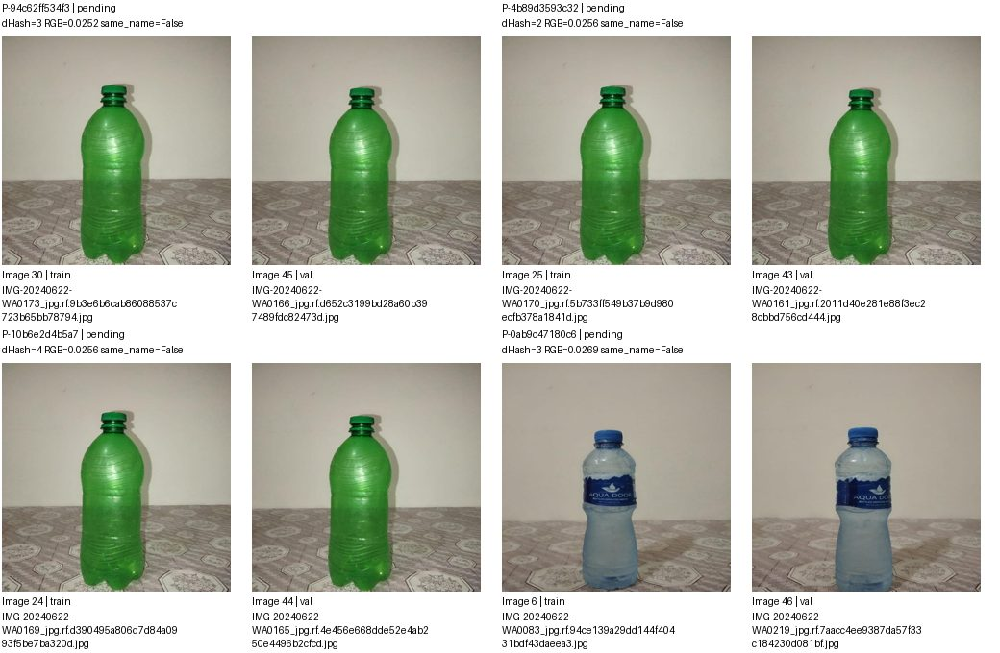

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-94c62ff534f3,images/train/IMG-20240622-WA0173_jpg.rf.9b3e6b6cab86088537c723b65bb78794.jpg,images/val/IMG-20240622-WA0166_jpg.rf.d652c3199bd28a60b397489fdc82473d.jpg,pending,
P-4b89d3593c32,images/train/IMG-20240622-WA0170_jpg.rf.5b733ff549b37b9d980ecfb378a1841d.jpg,images/val/IMG-20240622-WA0161_jpg.rf.2011d40e281e88f3ec28cbbd756cd444.jpg,pending,
P-10b6e2d4b5a7,images/train/IMG-20240622-WA0169_jpg.rf.d390495a806d7d84a0993f5be7ba320d.jpg,images/val/IMG-20240622-WA0165_jpg.rf.4e456e668dde52e4ab250e4496b2cfcd.jpg,pending,
P-0ab9c47180c6,images/train/IMG-20240622-WA0083_jpg.rf.94ce139a29dd144f40431bdf43daeea3.jpg,images/val/IMG-20240622-WA0219_jpg.rf.7aacc4ee9387da57f33c184230d081bf.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 92/166 G-2895f5813db7 | 46 ảnh, 108 cặp
Split: {'test': 4, 'train': 35, 'val': 7}
Quyết định: {'pending': 108}
Ảnh trang None/8; cặp trang 12/27. Nhóm liên thông không phải kết luận trùng.


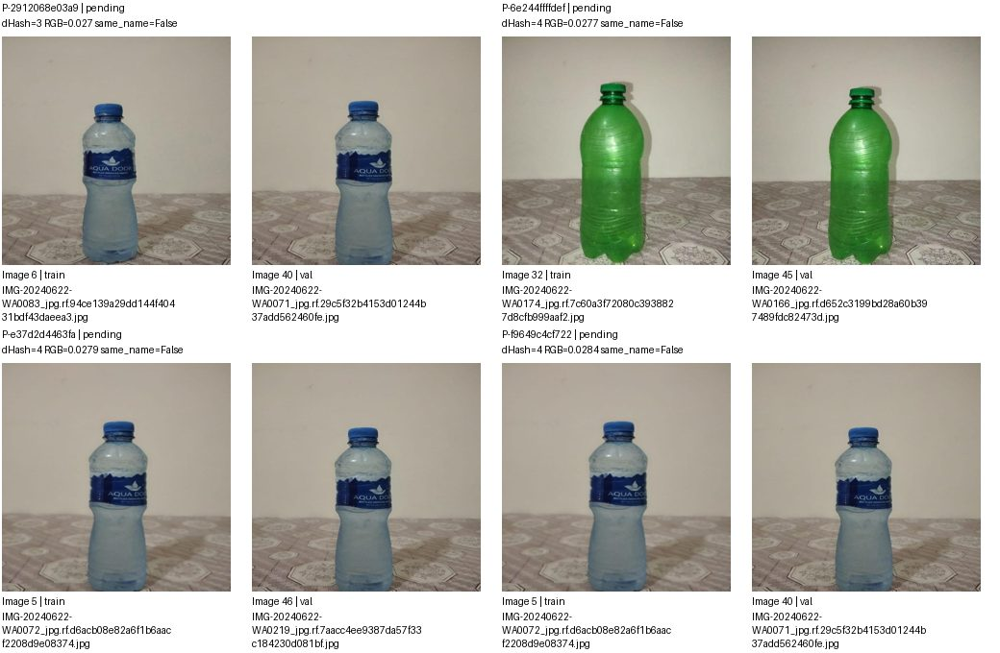

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-2912068e03a9,images/train/IMG-20240622-WA0083_jpg.rf.94ce139a29dd144f40431bdf43daeea3.jpg,images/val/IMG-20240622-WA0071_jpg.rf.29c5f32b4153d01244b37add562460fe.jpg,pending,
P-6e244ffffdef,images/train/IMG-20240622-WA0174_jpg.rf.7c60a3f72080c3938827d8cfb999aaf2.jpg,images/val/IMG-20240622-WA0166_jpg.rf.d652c3199bd28a60b397489fdc82473d.jpg,pending,
P-e37d2d4463fa,images/train/IMG-20240622-WA0072_jpg.rf.d6acb08e82a6f1b6aacf2208d9e08374.jpg,images/val/IMG-20240622-WA0219_jpg.rf.7aacc4ee9387da57f33c184230d081bf.jpg,pending,
P-f9649c4cf722,images/train/IMG-20240622-WA0072_jpg.rf.d6acb08e82a6f1b6aacf2208d9e08374.jpg,images/val/IMG-20240622-WA0071_jpg.rf.29c5f32b4153d01244b37add562460fe.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 92/166 G-2895f5813db7 | 46 ảnh, 108 cặp
Split: {'test': 4, 'train': 35, 'val': 7}
Quyết định: {'pending': 108}
Ảnh trang None/8; cặp trang 13/27. Nhóm liên thông không phải kết luận trùng.


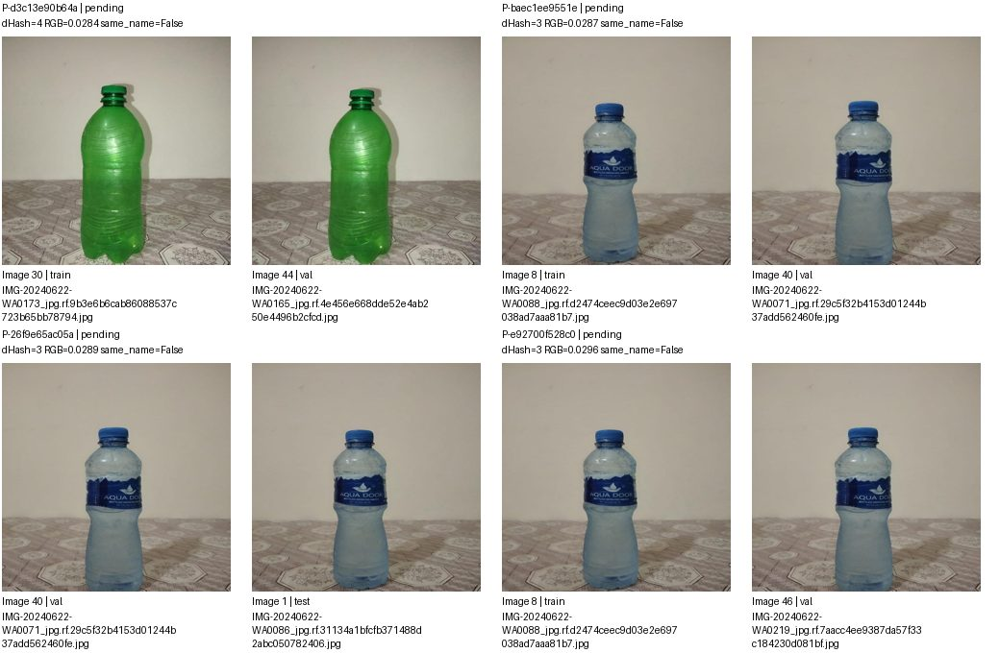

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-d3c13e90b64a,images/train/IMG-20240622-WA0173_jpg.rf.9b3e6b6cab86088537c723b65bb78794.jpg,images/val/IMG-20240622-WA0165_jpg.rf.4e456e668dde52e4ab250e4496b2cfcd.jpg,pending,
P-baec1ee9551e,images/train/IMG-20240622-WA0088_jpg.rf.d2474ceec9d03e2e697038ad7aaa81b7.jpg,images/val/IMG-20240622-WA0071_jpg.rf.29c5f32b4153d01244b37add562460fe.jpg,pending,
P-26f9e65ac05a,images/val/IMG-20240622-WA0071_jpg.rf.29c5f32b4153d01244b37add562460fe.jpg,images/test/IMG-20240622-WA0086_jpg.rf.31134a1bfcfb371488d2abc050782406.jpg,pending,
P-e92700f528c0,images/train/IMG-20240622-WA0088_jpg.rf.d2474ceec9d03e2e697038ad7aaa81b7.jpg,images/val/IMG-20240622-WA0219_jpg.rf.7aacc4ee9387da57f33c184230d081bf.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 92/166 G-2895f5813db7 | 46 ảnh, 108 cặp
Split: {'test': 4, 'train': 35, 'val': 7}
Quyết định: {'pending': 108}
Ảnh trang None/8; cặp trang 14/27. Nhóm liên thông không phải kết luận trùng.


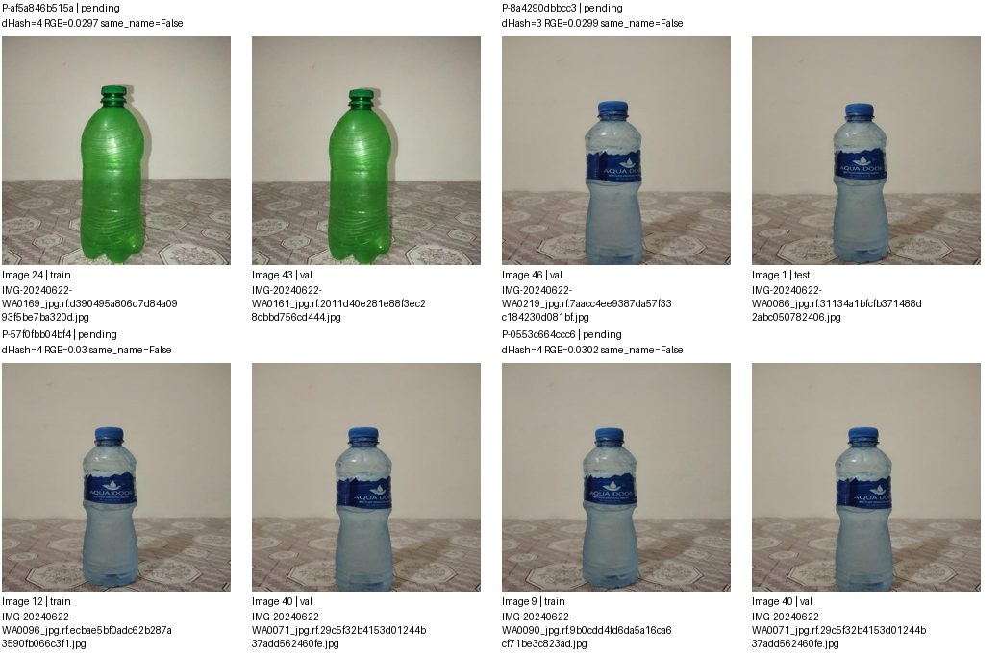

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-af5a846b515a,images/train/IMG-20240622-WA0169_jpg.rf.d390495a806d7d84a0993f5be7ba320d.jpg,images/val/IMG-20240622-WA0161_jpg.rf.2011d40e281e88f3ec28cbbd756cd444.jpg,pending,
P-8a4290dbbcc3,images/val/IMG-20240622-WA0219_jpg.rf.7aacc4ee9387da57f33c184230d081bf.jpg,images/test/IMG-20240622-WA0086_jpg.rf.31134a1bfcfb371488d2abc050782406.jpg,pending,
P-57f0fbb04bf4,images/train/IMG-20240622-WA0096_jpg.rf.ecbae5bf0adc62b287a3590fb066c3f1.jpg,images/val/IMG-20240622-WA0071_jpg.rf.29c5f32b4153d01244b37add562460fe.jpg,pending,
P-0553c664ccc6,images/train/IMG-20240622-WA0090_jpg.rf.9b0cdd4fd6da5a16ca6cf71be3c823ad.jpg,images/val/IMG-20240622-WA0071_jpg.rf.29c5f32b4153d01244b37add562460fe.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 92/166 G-2895f5813db7 | 46 ảnh, 108 cặp
Split: {'test': 4, 'train': 35, 'val': 7}
Quyết định: {'pending': 108}
Ảnh trang None/8; cặp trang 15/27. Nhóm liên thông không phải kết luận trùng.


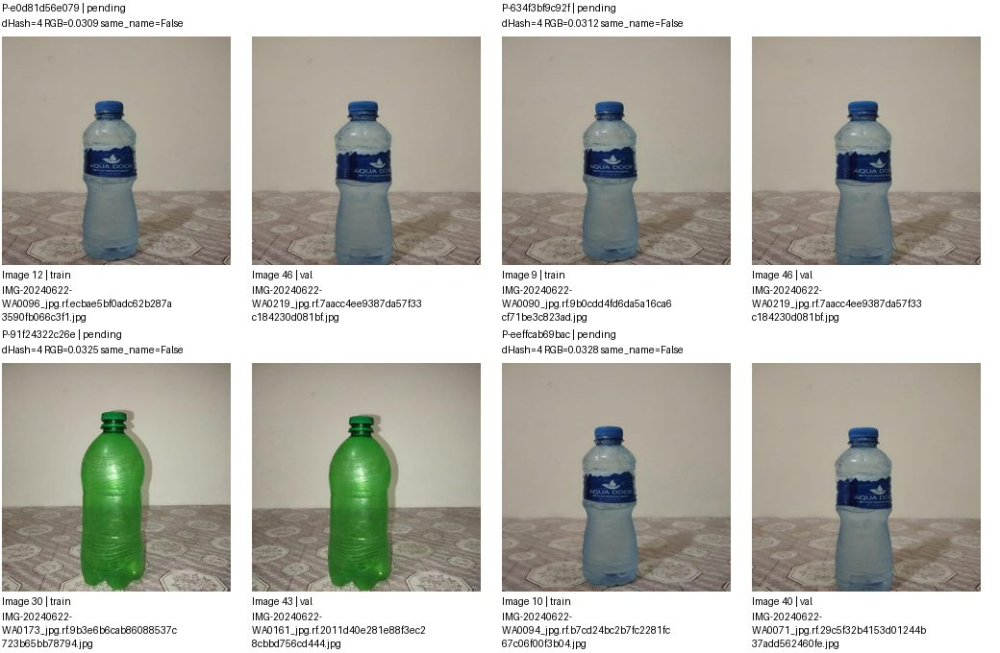

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-e0d81d56e079,images/train/IMG-20240622-WA0096_jpg.rf.ecbae5bf0adc62b287a3590fb066c3f1.jpg,images/val/IMG-20240622-WA0219_jpg.rf.7aacc4ee9387da57f33c184230d081bf.jpg,pending,
P-634f3bf9c92f,images/train/IMG-20240622-WA0090_jpg.rf.9b0cdd4fd6da5a16ca6cf71be3c823ad.jpg,images/val/IMG-20240622-WA0219_jpg.rf.7aacc4ee9387da57f33c184230d081bf.jpg,pending,
P-91f24322c26e,images/train/IMG-20240622-WA0173_jpg.rf.9b3e6b6cab86088537c723b65bb78794.jpg,images/val/IMG-20240622-WA0161_jpg.rf.2011d40e281e88f3ec28cbbd756cd444.jpg,pending,
P-eeffcab69bac,images/train/IMG-20240622-WA0094_jpg.rf.b7cd24bc2b7fc2281fc67c06f00f3b04.jpg,images/val/IMG-20240622-WA0071_jpg.rf.29c5f32b4153d01244b37add562460fe.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 92/166 G-2895f5813db7 | 46 ảnh, 108 cặp
Split: {'test': 4, 'train': 35, 'val': 7}
Quyết định: {'pending': 108}
Ảnh trang None/8; cặp trang 16/27. Nhóm liên thông không phải kết luận trùng.


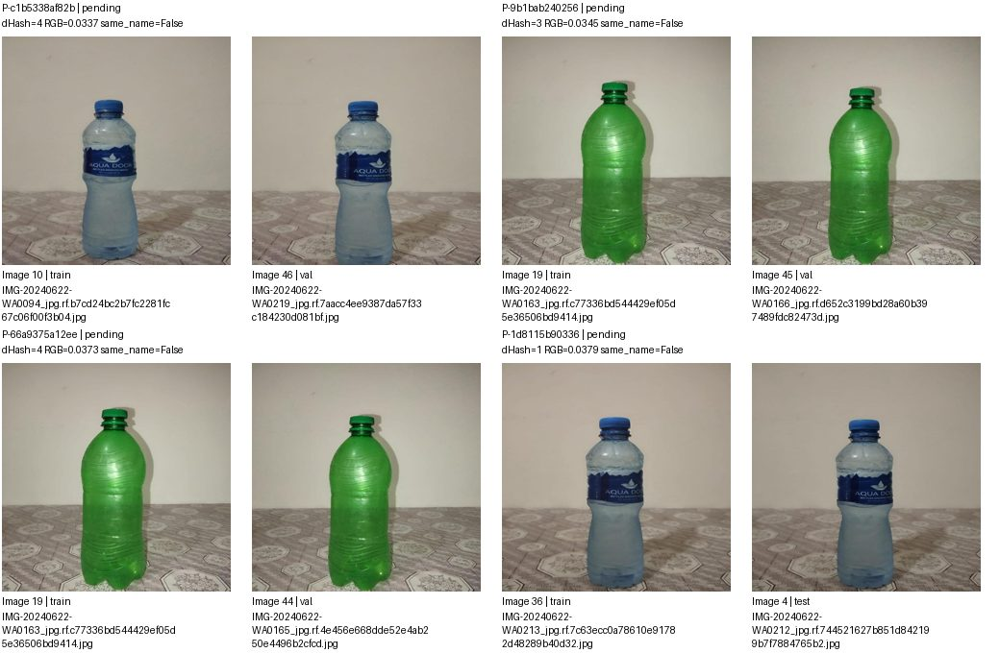

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-c1b5338af82b,images/train/IMG-20240622-WA0094_jpg.rf.b7cd24bc2b7fc2281fc67c06f00f3b04.jpg,images/val/IMG-20240622-WA0219_jpg.rf.7aacc4ee9387da57f33c184230d081bf.jpg,pending,
P-9b1bab240256,images/train/IMG-20240622-WA0163_jpg.rf.c77336bd544429ef05d5e36506bd9414.jpg,images/val/IMG-20240622-WA0166_jpg.rf.d652c3199bd28a60b397489fdc82473d.jpg,pending,
P-66a9375a12ee,images/train/IMG-20240622-WA0163_jpg.rf.c77336bd544429ef05d5e36506bd9414.jpg,images/val/IMG-20240622-WA0165_jpg.rf.4e456e668dde52e4ab250e4496b2cfcd.jpg,pending,
P-1d8115b90336,images/train/IMG-20240622-WA0213_jpg.rf.7c63ecc0a78610e91782d48289b40d32.jpg,images/test/IMG-20240622-WA0212_jpg.rf.744521627b851d842199b7f7884765b2.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 92/166 G-2895f5813db7 | 46 ảnh, 108 cặp
Split: {'test': 4, 'train': 35, 'val': 7}
Quyết định: {'pending': 108}
Ảnh trang None/8; cặp trang 17/27. Nhóm liên thông không phải kết luận trùng.


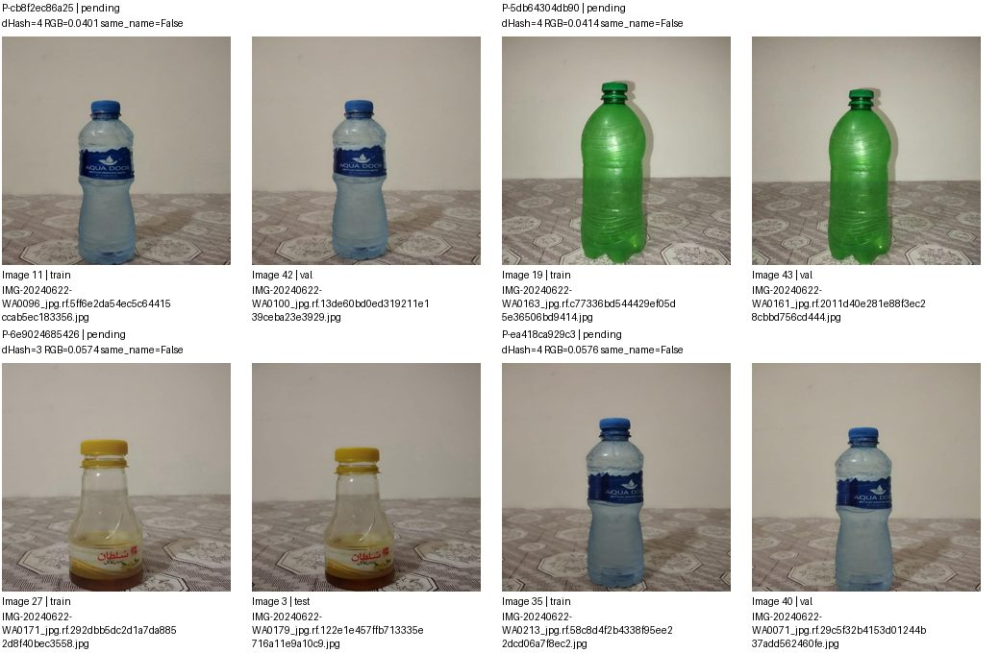

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-cb8f2ec86a25,images/train/IMG-20240622-WA0096_jpg.rf.5ff6e2da54ec5c64415ccab5ec183356.jpg,images/val/IMG-20240622-WA0100_jpg.rf.13de60bd0ed319211e139ceba23e3929.jpg,pending,
P-5db64304db90,images/train/IMG-20240622-WA0163_jpg.rf.c77336bd544429ef05d5e36506bd9414.jpg,images/val/IMG-20240622-WA0161_jpg.rf.2011d40e281e88f3ec28cbbd756cd444.jpg,pending,
P-6e9024685426,images/train/IMG-20240622-WA0171_jpg.rf.292dbb5dc2d1a7da8852d8f40bec3558.jpg,images/test/IMG-20240622-WA0179_jpg.rf.122e1e457ffb713335e716a11e9a10c9.jpg,pending,
P-ea418ca929c3,images/train/IMG-20240622-WA0213_jpg.rf.58c8d4f2b4338f95ee22dcd06a7f8ec2.jpg,images/val/IMG-20240622-WA0071_jpg.rf.29c5f32b4153d01244b37add562460fe.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 92/166 G-2895f5813db7 | 46 ảnh, 108 cặp
Split: {'test': 4, 'train': 35, 'val': 7}
Quyết định: {'pending': 108}
Ảnh trang None/8; cặp trang 18/27. Nhóm liên thông không phải kết luận trùng.


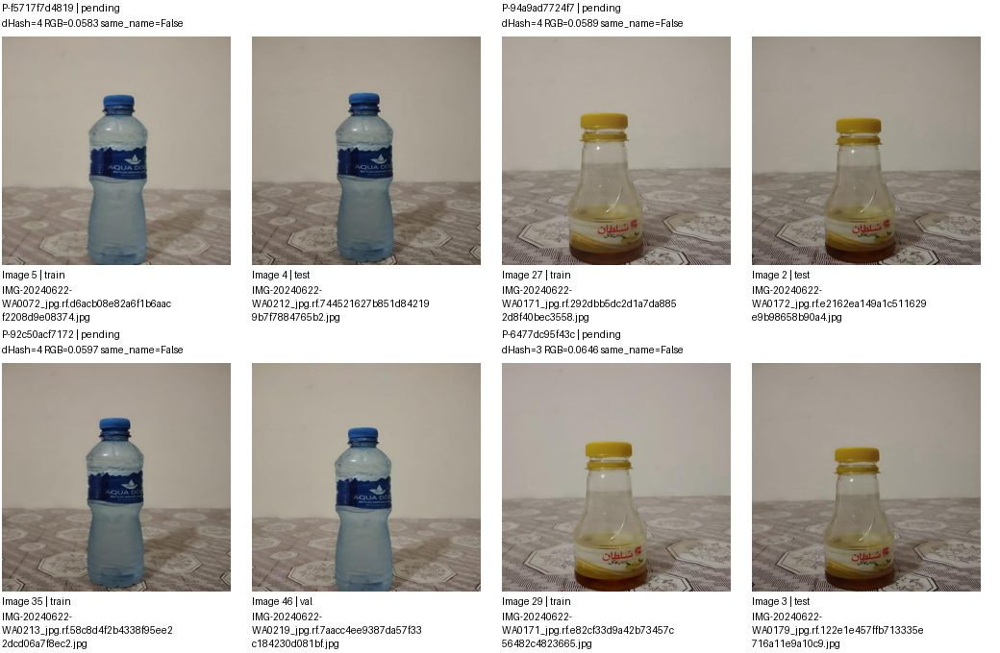

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-f5717f7d4819,images/train/IMG-20240622-WA0072_jpg.rf.d6acb08e82a6f1b6aacf2208d9e08374.jpg,images/test/IMG-20240622-WA0212_jpg.rf.744521627b851d842199b7f7884765b2.jpg,pending,
P-94a9ad7724f7,images/train/IMG-20240622-WA0171_jpg.rf.292dbb5dc2d1a7da8852d8f40bec3558.jpg,images/test/IMG-20240622-WA0172_jpg.rf.e2162ea149a1c511629e9b98658b90a4.jpg,pending,
P-92c50acf7172,images/train/IMG-20240622-WA0213_jpg.rf.58c8d4f2b4338f95ee22dcd06a7f8ec2.jpg,images/val/IMG-20240622-WA0219_jpg.rf.7aacc4ee9387da57f33c184230d081bf.jpg,pending,
P-6477dc95f43c,images/train/IMG-20240622-WA0171_jpg.rf.e82cf33d9a42b73457c56482c4823665.jpg,images/test/IMG-20240622-WA0179_jpg.rf.122e1e457ffb713335e716a11e9a10c9.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 92/166 G-2895f5813db7 | 46 ảnh, 108 cặp
Split: {'test': 4, 'train': 35, 'val': 7}
Quyết định: {'pending': 108}
Ảnh trang None/8; cặp trang 19/27. Nhóm liên thông không phải kết luận trùng.


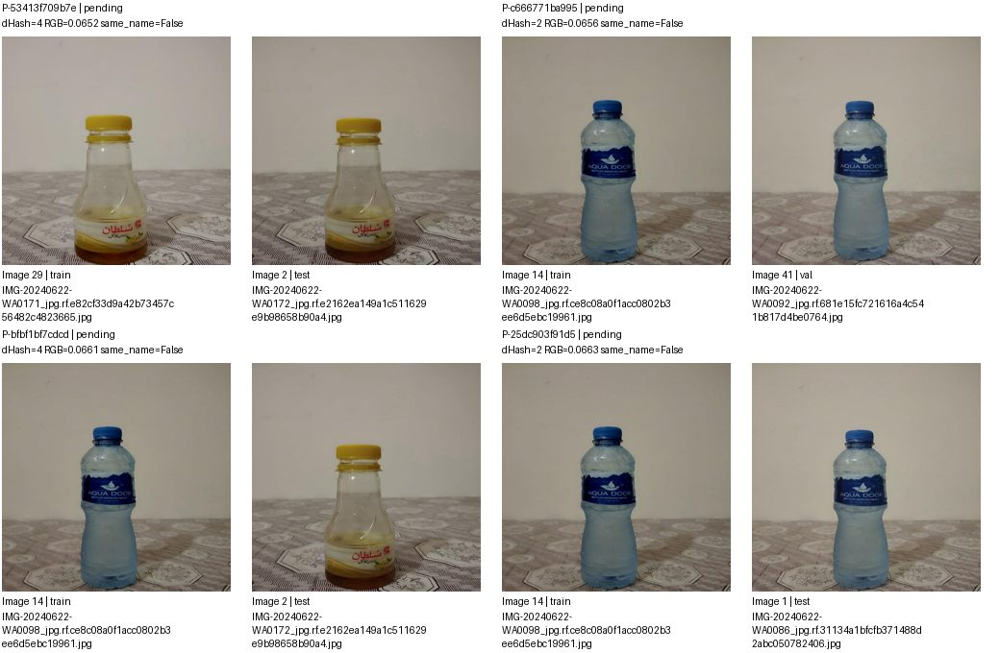

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-53413f709b7e,images/train/IMG-20240622-WA0171_jpg.rf.e82cf33d9a42b73457c56482c4823665.jpg,images/test/IMG-20240622-WA0172_jpg.rf.e2162ea149a1c511629e9b98658b90a4.jpg,pending,
P-c666771ba995,images/train/IMG-20240622-WA0098_jpg.rf.ce8c08a0f1acc0802b3ee6d5ebc19961.jpg,images/val/IMG-20240622-WA0092_jpg.rf.681e15fc721616a4c541b817d4be0764.jpg,pending,
P-bfbf1bf7cdcd,images/train/IMG-20240622-WA0098_jpg.rf.ce8c08a0f1acc0802b3ee6d5ebc19961.jpg,images/test/IMG-20240622-WA0172_jpg.rf.e2162ea149a1c511629e9b98658b90a4.jpg,pending,
P-25dc903f91d5,images/train/IMG-20240622-WA0098_jpg.rf.ce8c08a0f1acc0802b3ee6d5ebc19961.jpg,images/test/IMG-20240622-WA0086_jpg.rf.31134a1bfcfb371488d2abc050782406.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 92/166 G-2895f5813db7 | 46 ảnh, 108 cặp
Split: {'test': 4, 'train': 35, 'val': 7}
Quyết định: {'pending': 108}
Ảnh trang None/8; cặp trang 20/27. Nhóm liên thông không phải kết luận trùng.


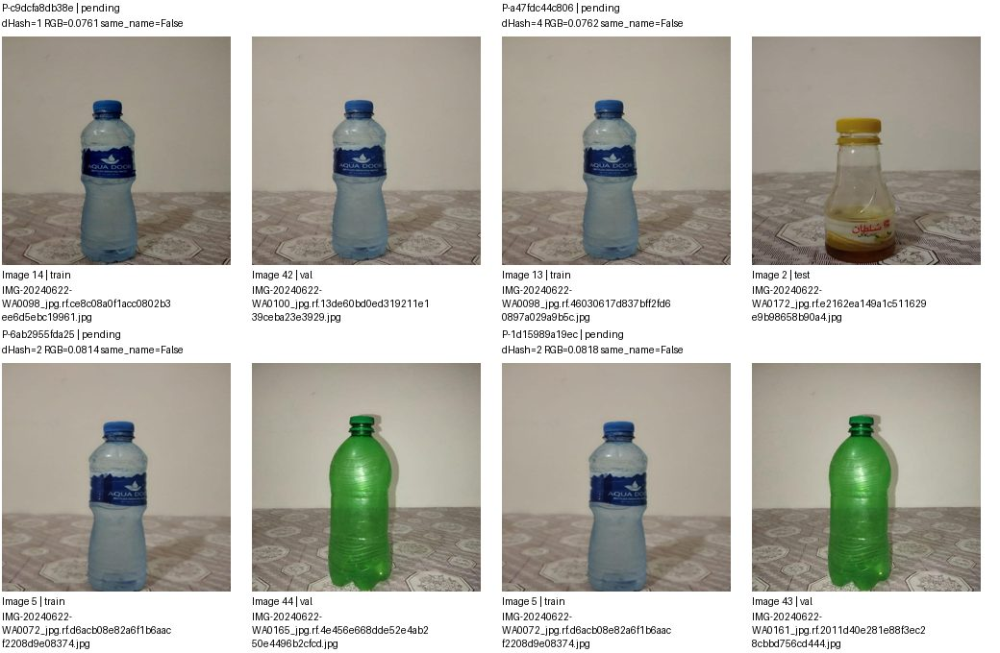

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-c9dcfa8db38e,images/train/IMG-20240622-WA0098_jpg.rf.ce8c08a0f1acc0802b3ee6d5ebc19961.jpg,images/val/IMG-20240622-WA0100_jpg.rf.13de60bd0ed319211e139ceba23e3929.jpg,pending,
P-a47fdc44c806,images/train/IMG-20240622-WA0098_jpg.rf.46030617d837bff2fd60897a029a9b5c.jpg,images/test/IMG-20240622-WA0172_jpg.rf.e2162ea149a1c511629e9b98658b90a4.jpg,pending,
P-6ab2955fda25,images/train/IMG-20240622-WA0072_jpg.rf.d6acb08e82a6f1b6aacf2208d9e08374.jpg,images/val/IMG-20240622-WA0165_jpg.rf.4e456e668dde52e4ab250e4496b2cfcd.jpg,pending,
P-1d15989a19ec,images/train/IMG-20240622-WA0072_jpg.rf.d6acb08e82a6f1b6aacf2208d9e08374.jpg,images/val/IMG-20240622-WA0161_jpg.rf.2011d40e281e88f3ec28cbbd756cd444.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 92/166 G-2895f5813db7 | 46 ảnh, 108 cặp
Split: {'test': 4, 'train': 35, 'val': 7}
Quyết định: {'pending': 108}
Ảnh trang None/8; cặp trang 21/27. Nhóm liên thông không phải kết luận trùng.


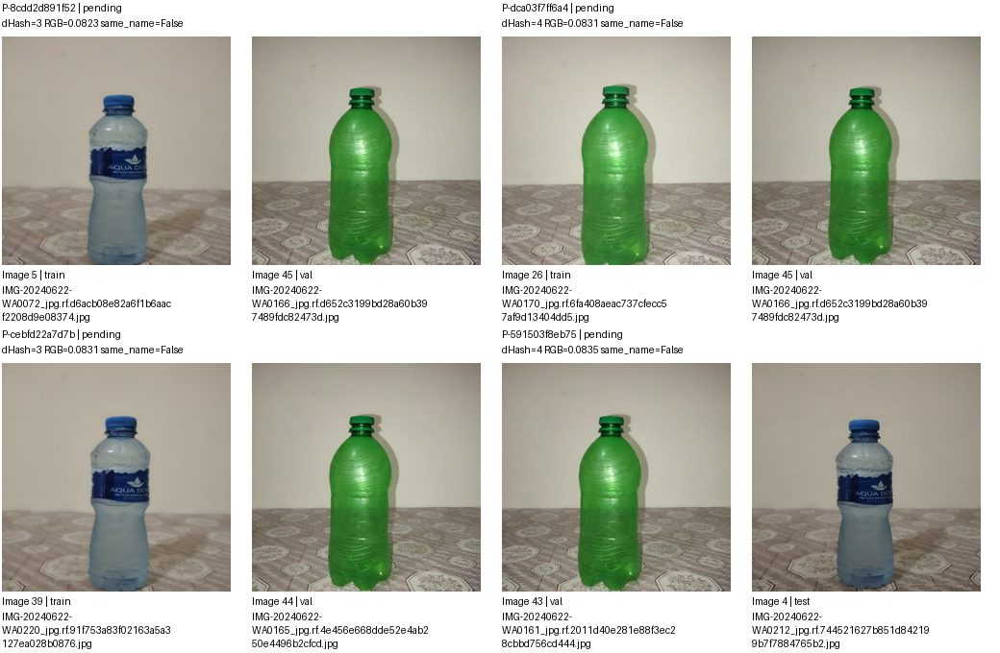

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-8cdd2d891f52,images/train/IMG-20240622-WA0072_jpg.rf.d6acb08e82a6f1b6aacf2208d9e08374.jpg,images/val/IMG-20240622-WA0166_jpg.rf.d652c3199bd28a60b397489fdc82473d.jpg,pending,
P-dca03f7ff6a4,images/train/IMG-20240622-WA0170_jpg.rf.6fa408aeac737cfecc57af9d13404dd5.jpg,images/val/IMG-20240622-WA0166_jpg.rf.d652c3199bd28a60b397489fdc82473d.jpg,pending,
P-cebfd22a7d7b,images/train/IMG-20240622-WA0220_jpg.rf.91f753a83f02163a5a3127ea028b0876.jpg,images/val/IMG-20240622-WA0165_jpg.rf.4e456e668dde52e4ab250e4496b2cfcd.jpg,pending,
P-591503f8eb75,images/val/IMG-20240622-WA0161_jpg.rf.2011d40e281e88f3ec28cbbd756cd444.jpg,images/test/IMG-20240622-WA0212_jpg.rf.744521627b851d842199b7f7884765b2.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 92/166 G-2895f5813db7 | 46 ảnh, 108 cặp
Split: {'test': 4, 'train': 35, 'val': 7}
Quyết định: {'pending': 108}
Ảnh trang None/8; cặp trang 22/27. Nhóm liên thông không phải kết luận trùng.


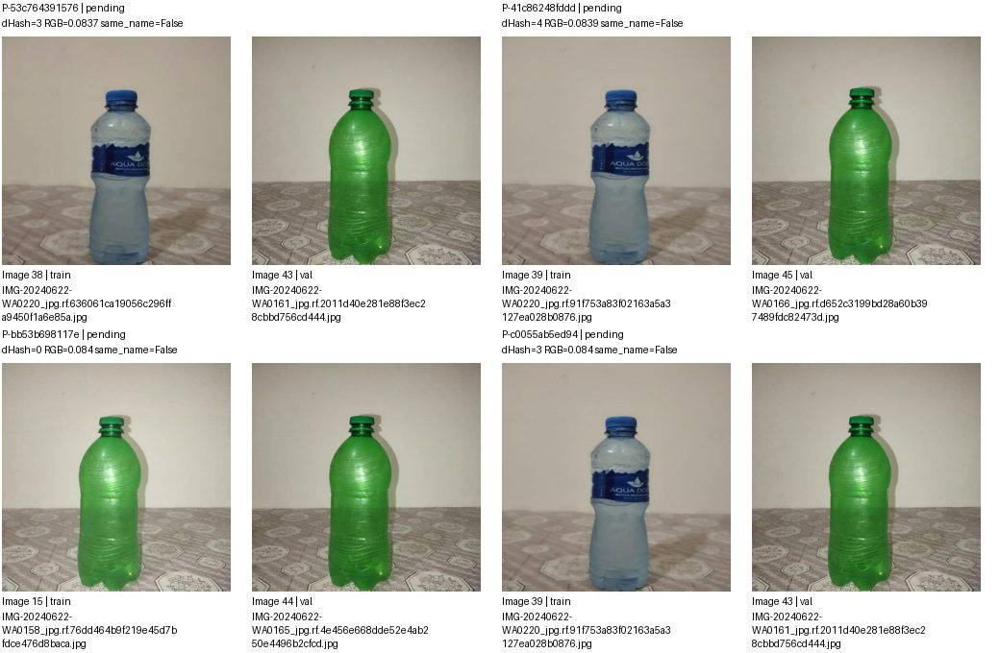

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-53c764391576,images/train/IMG-20240622-WA0220_jpg.rf.636061ca19056c296ffa9450f1a6e85a.jpg,images/val/IMG-20240622-WA0161_jpg.rf.2011d40e281e88f3ec28cbbd756cd444.jpg,pending,
P-41c86248fddd,images/train/IMG-20240622-WA0220_jpg.rf.91f753a83f02163a5a3127ea028b0876.jpg,images/val/IMG-20240622-WA0166_jpg.rf.d652c3199bd28a60b397489fdc82473d.jpg,pending,
P-bb53b698117e,images/train/IMG-20240622-WA0158_jpg.rf.76dd464b9f219e45d7bfdce476d8baca.jpg,images/val/IMG-20240622-WA0165_jpg.rf.4e456e668dde52e4ab250e4496b2cfcd.jpg,pending,
P-c0055ab5ed94,images/train/IMG-20240622-WA0220_jpg.rf.91f753a83f02163a5a3127ea028b0876.jpg,images/val/IMG-20240622-WA0161_jpg.rf.2011d40e281e88f3ec28cbbd756cd444.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 92/166 G-2895f5813db7 | 46 ảnh, 108 cặp
Split: {'test': 4, 'train': 35, 'val': 7}
Quyết định: {'pending': 108}
Ảnh trang None/8; cặp trang 23/27. Nhóm liên thông không phải kết luận trùng.


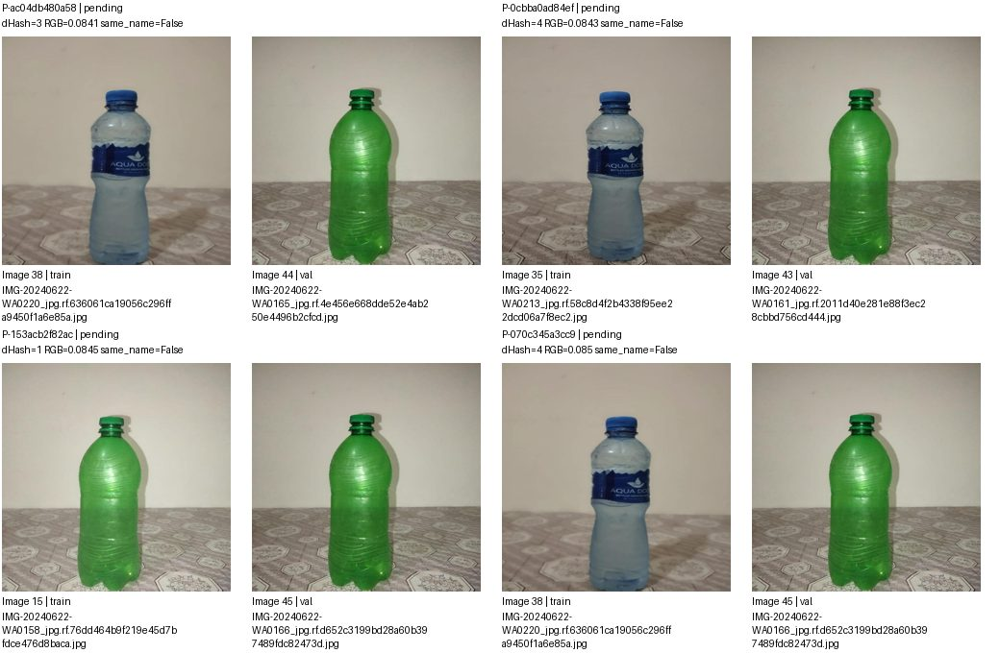

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-ac04db480a58,images/train/IMG-20240622-WA0220_jpg.rf.636061ca19056c296ffa9450f1a6e85a.jpg,images/val/IMG-20240622-WA0165_jpg.rf.4e456e668dde52e4ab250e4496b2cfcd.jpg,pending,
P-0cbba0ad84ef,images/train/IMG-20240622-WA0213_jpg.rf.58c8d4f2b4338f95ee22dcd06a7f8ec2.jpg,images/val/IMG-20240622-WA0161_jpg.rf.2011d40e281e88f3ec28cbbd756cd444.jpg,pending,
P-153acb2f82ac,images/train/IMG-20240622-WA0158_jpg.rf.76dd464b9f219e45d7bfdce476d8baca.jpg,images/val/IMG-20240622-WA0166_jpg.rf.d652c3199bd28a60b397489fdc82473d.jpg,pending,
P-070c345a3cc9,images/train/IMG-20240622-WA0220_jpg.rf.636061ca19056c296ffa9450f1a6e85a.jpg,images/val/IMG-20240622-WA0166_jpg.rf.d652c3199bd28a60b397489fdc82473d.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 92/166 G-2895f5813db7 | 46 ảnh, 108 cặp
Split: {'test': 4, 'train': 35, 'val': 7}
Quyết định: {'pending': 108}
Ảnh trang None/8; cặp trang 24/27. Nhóm liên thông không phải kết luận trùng.


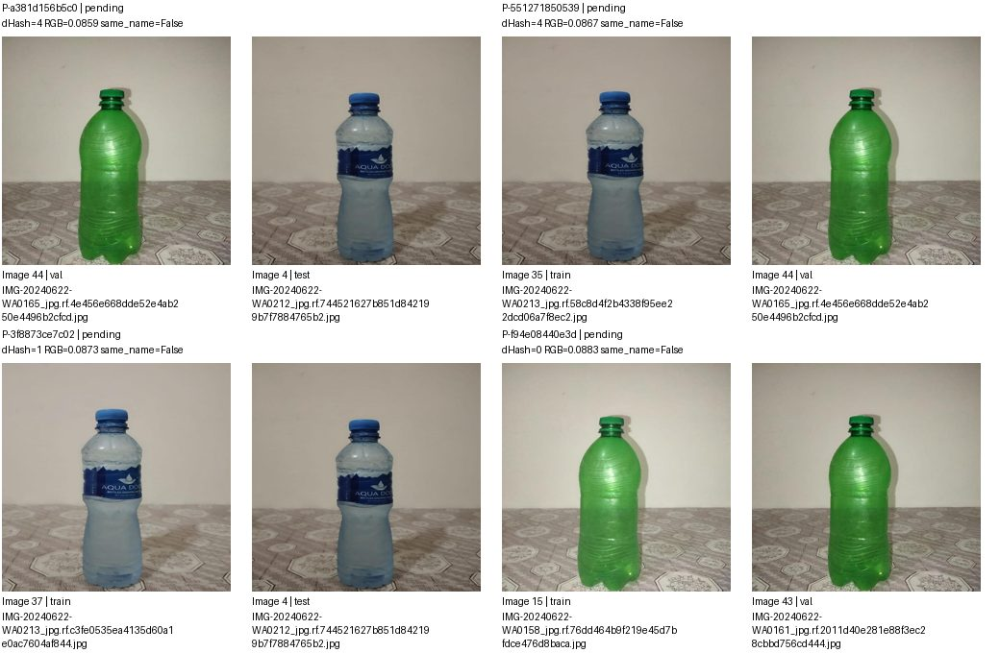

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-a381d156b5c0,images/val/IMG-20240622-WA0165_jpg.rf.4e456e668dde52e4ab250e4496b2cfcd.jpg,images/test/IMG-20240622-WA0212_jpg.rf.744521627b851d842199b7f7884765b2.jpg,pending,
P-551271850539,images/train/IMG-20240622-WA0213_jpg.rf.58c8d4f2b4338f95ee22dcd06a7f8ec2.jpg,images/val/IMG-20240622-WA0165_jpg.rf.4e456e668dde52e4ab250e4496b2cfcd.jpg,pending,
P-3f8873ce7c02,images/train/IMG-20240622-WA0213_jpg.rf.c3fe0535ea4135d60a1e0ac7604af844.jpg,images/test/IMG-20240622-WA0212_jpg.rf.744521627b851d842199b7f7884765b2.jpg,pending,
P-f94e08440e3d,images/train/IMG-20240622-WA0158_jpg.rf.76dd464b9f219e45d7bfdce476d8baca.jpg,images/val/IMG-20240622-WA0161_jpg.rf.2011d40e281e88f3ec28cbbd756cd444.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 92/166 G-2895f5813db7 | 46 ảnh, 108 cặp
Split: {'test': 4, 'train': 35, 'val': 7}
Quyết định: {'pending': 108}
Ảnh trang None/8; cặp trang 25/27. Nhóm liên thông không phải kết luận trùng.


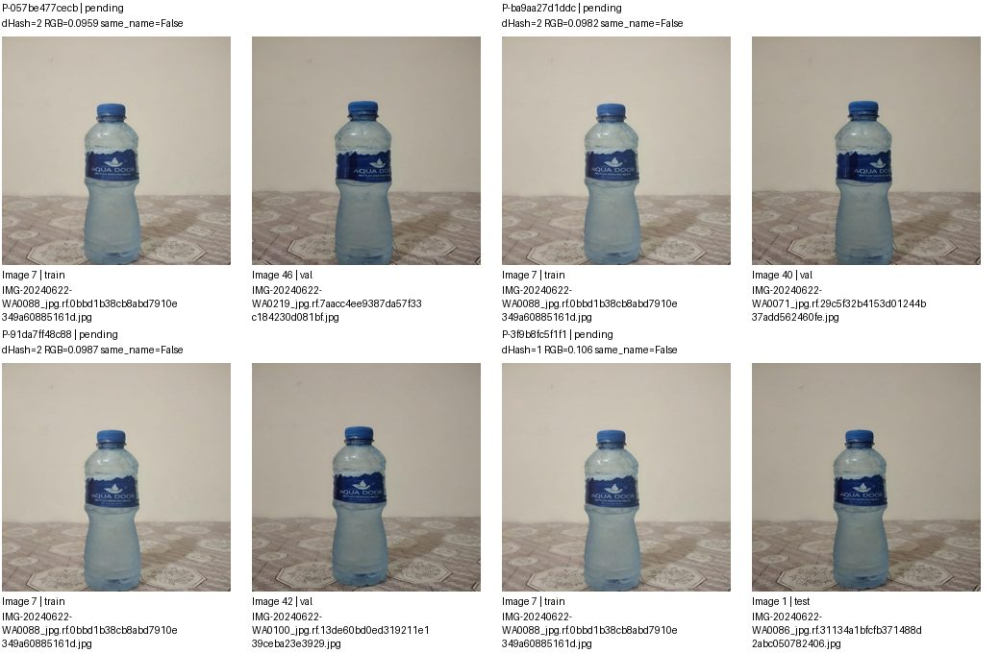

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-057be477cecb,images/train/IMG-20240622-WA0088_jpg.rf.0bbd1b38cb8abd7910e349a60885161d.jpg,images/val/IMG-20240622-WA0219_jpg.rf.7aacc4ee9387da57f33c184230d081bf.jpg,pending,
P-ba9aa27d1ddc,images/train/IMG-20240622-WA0088_jpg.rf.0bbd1b38cb8abd7910e349a60885161d.jpg,images/val/IMG-20240622-WA0071_jpg.rf.29c5f32b4153d01244b37add562460fe.jpg,pending,
P-91da7ff48c88,images/train/IMG-20240622-WA0088_jpg.rf.0bbd1b38cb8abd7910e349a60885161d.jpg,images/val/IMG-20240622-WA0100_jpg.rf.13de60bd0ed319211e139ceba23e3929.jpg,pending,
P-3f9b8fc5f1f1,images/train/IMG-20240622-WA0088_jpg.rf.0bbd1b38cb8abd7910e349a60885161d.jpg,images/test/IMG-20240622-WA0086_jpg.rf.31134a1bfcfb371488d2abc050782406.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 92/166 G-2895f5813db7 | 46 ảnh, 108 cặp
Split: {'test': 4, 'train': 35, 'val': 7}
Quyết định: {'pending': 108}
Ảnh trang None/8; cặp trang 26/27. Nhóm liên thông không phải kết luận trùng.


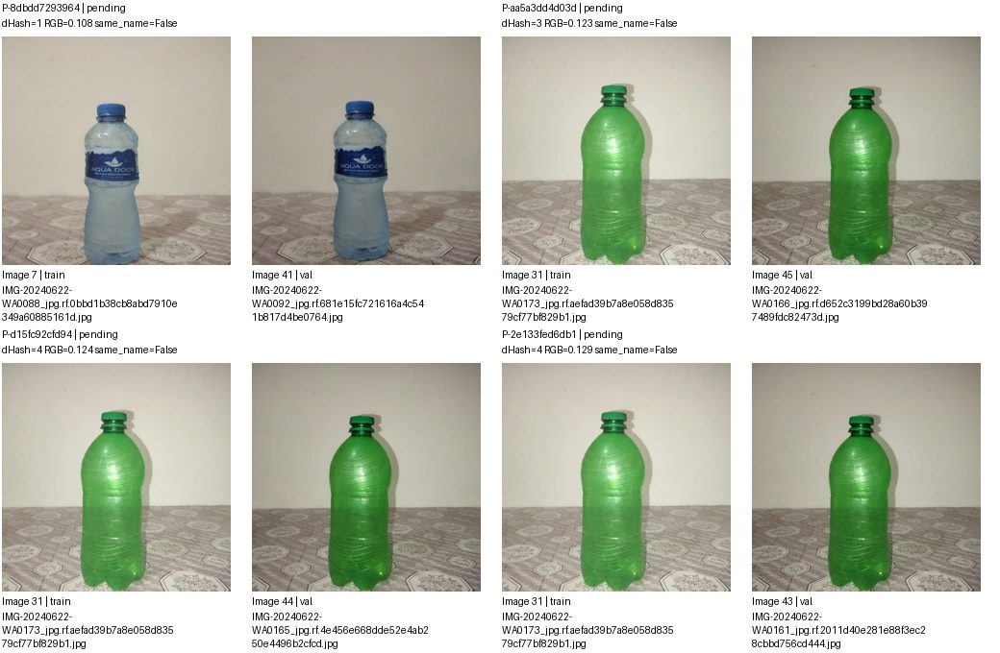

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-8dbdd7293964,images/train/IMG-20240622-WA0088_jpg.rf.0bbd1b38cb8abd7910e349a60885161d.jpg,images/val/IMG-20240622-WA0092_jpg.rf.681e15fc721616a4c541b817d4be0764.jpg,pending,
P-aa5a3dd4d03d,images/train/IMG-20240622-WA0173_jpg.rf.aefad39b7a8e058d83579cf77bf829b1.jpg,images/val/IMG-20240622-WA0166_jpg.rf.d652c3199bd28a60b397489fdc82473d.jpg,pending,
P-d15fc92cfd94,images/train/IMG-20240622-WA0173_jpg.rf.aefad39b7a8e058d83579cf77bf829b1.jpg,images/val/IMG-20240622-WA0165_jpg.rf.4e456e668dde52e4ab250e4496b2cfcd.jpg,pending,
P-2e133fed6db1,images/train/IMG-20240622-WA0173_jpg.rf.aefad39b7a8e058d83579cf77bf829b1.jpg,images/val/IMG-20240622-WA0161_jpg.rf.2011d40e281e88f3ec28cbbd756cd444.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 92/166 G-2895f5813db7 | 46 ảnh, 108 cặp
Split: {'test': 4, 'train': 35, 'val': 7}
Quyết định: {'pending': 108}
Ảnh trang None/8; cặp trang 27/27. Nhóm liên thông không phải kết luận trùng.


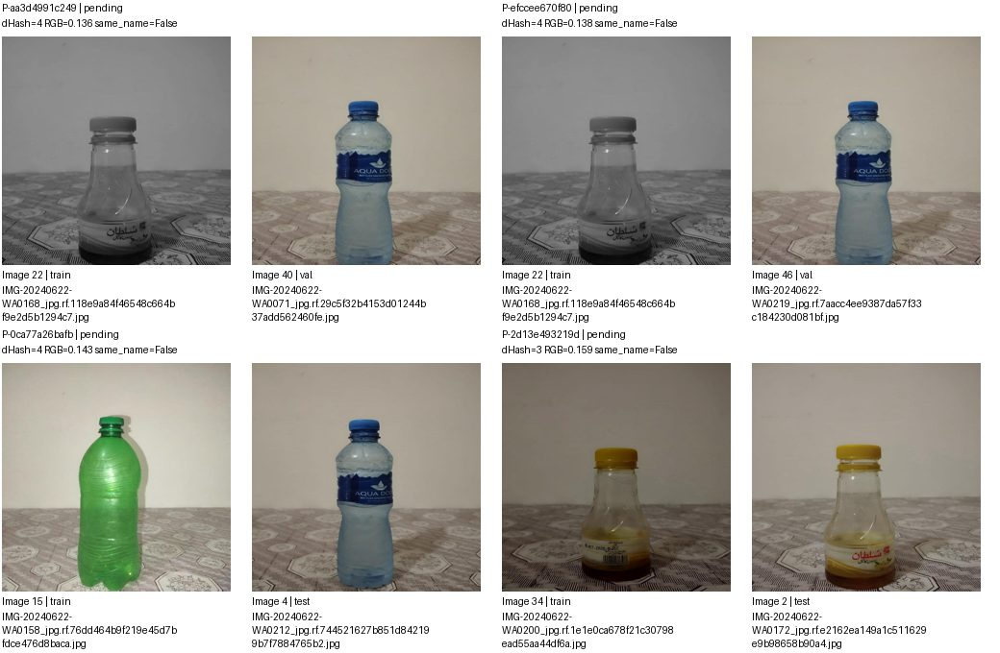

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-aa3d4991c249,images/train/IMG-20240622-WA0168_jpg.rf.118e9a84f46548c664bf9e2d5b1294c7.jpg,images/val/IMG-20240622-WA0071_jpg.rf.29c5f32b4153d01244b37add562460fe.jpg,pending,
P-efccee670f80,images/train/IMG-20240622-WA0168_jpg.rf.118e9a84f46548c664bf9e2d5b1294c7.jpg,images/val/IMG-20240622-WA0219_jpg.rf.7aacc4ee9387da57f33c184230d081bf.jpg,pending,
P-0ca77a26bafb,images/train/IMG-20240622-WA0158_jpg.rf.76dd464b9f219e45d7bfdce476d8baca.jpg,images/test/IMG-20240622-WA0212_jpg.rf.744521627b851d842199b7f7884765b2.jpg,pending,
P-2d13e493219d,images/train/IMG-20240622-WA0200_jpg.rf.1e1e0ca678f21c30798ead55aa44df6a.jpg,images/test/IMG-20240622-WA0172_jpg.rf.e2162ea149a1c511629e9b98658b90a4.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 93/166 G-cef9e1025bfc | 8 ảnh, 15 cặp
Split: {'test': 1, 'train': 4, 'val': 3}
Quyết định: {'pending': 15}
Ảnh trang 1/2; cặp trang 1/4. Nhóm liên thông không phải kết luận trùng.


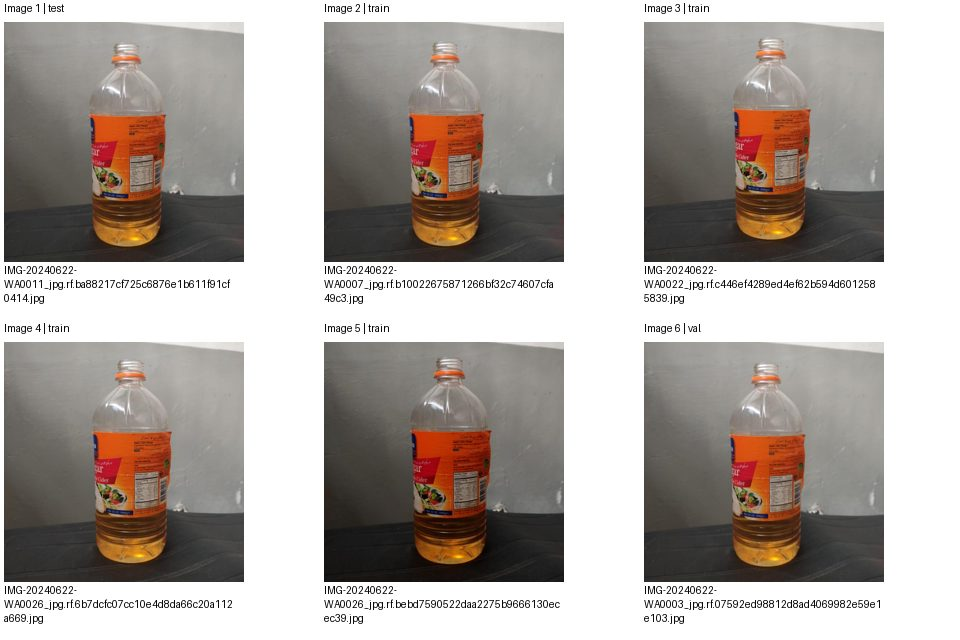

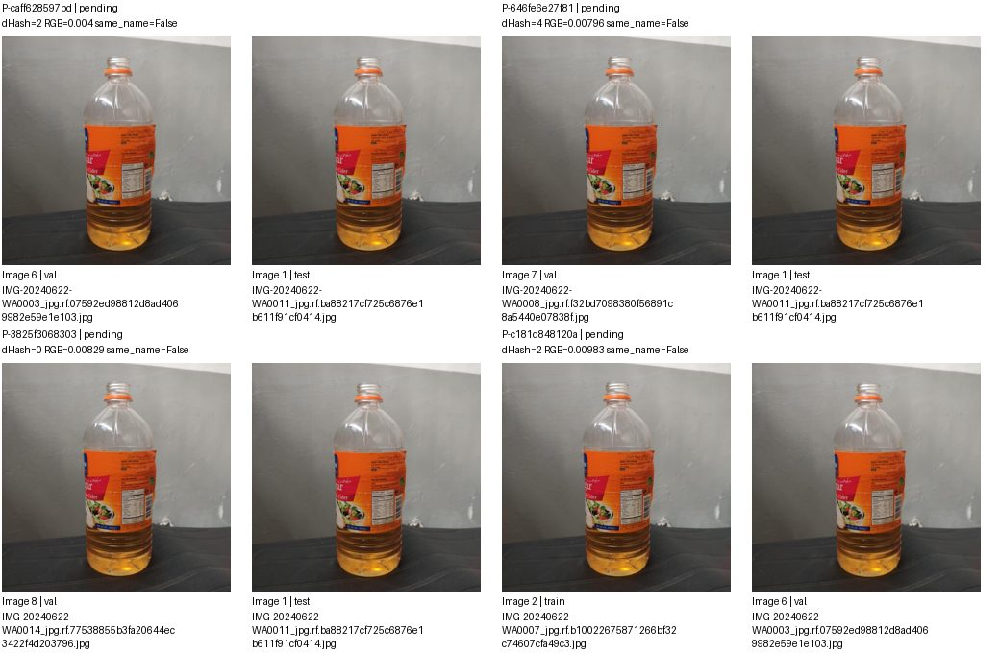

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-caff628597bd,images/val/IMG-20240622-WA0003_jpg.rf.07592ed98812d8ad4069982e59e1e103.jpg,images/test/IMG-20240622-WA0011_jpg.rf.ba88217cf725c6876e1b611f91cf0414.jpg,pending,
P-646fe6e27f81,images/val/IMG-20240622-WA0008_jpg.rf.f32bd7098380f56891c8a5440e07838f.jpg,images/test/IMG-20240622-WA0011_jpg.rf.ba88217cf725c6876e1b611f91cf0414.jpg,pending,
P-3825f3068303,images/val/IMG-20240622-WA0014_jpg.rf.77538855b3fa20644ec3422f4d203796.jpg,images/test/IMG-20240622-WA0011_jpg.rf.ba88217cf725c6876e1b611f91cf0414.jpg,pending,
P-c181d848120a,images/train/IMG-20240622-WA0007_jpg.rf.b10022675871266bf32c74607cfa49c3.jpg,images/val/IMG-20240622-WA0003_jpg.rf.07592ed98812d8ad4069982e59e1e103.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 93/166 G-cef9e1025bfc | 8 ảnh, 15 cặp
Split: {'test': 1, 'train': 4, 'val': 3}
Quyết định: {'pending': 15}
Ảnh trang 2/2; cặp trang 2/4. Nhóm liên thông không phải kết luận trùng.


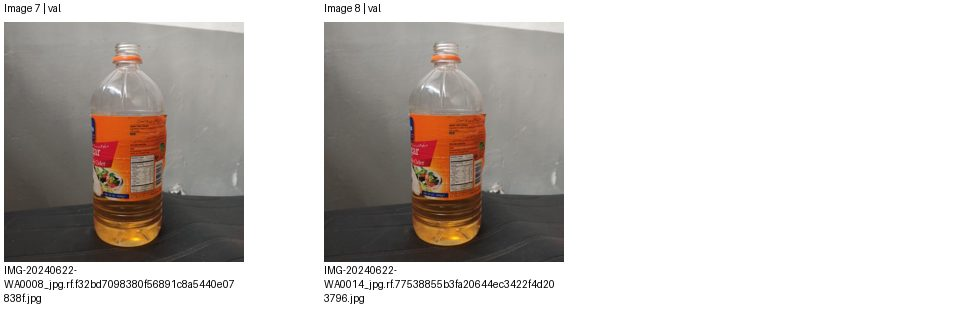

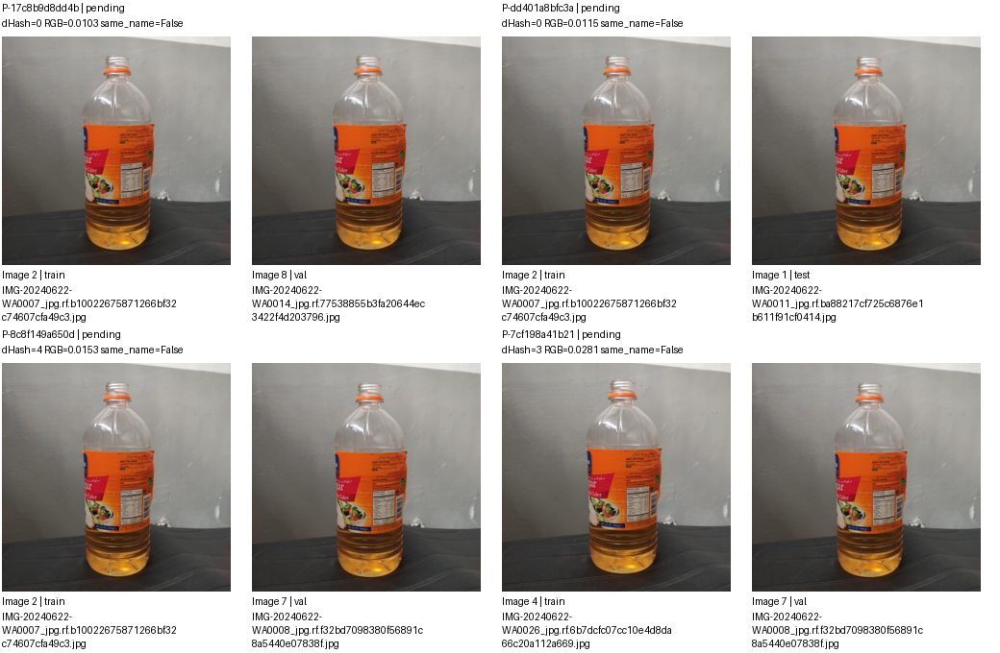

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-17c8b9d8dd4b,images/train/IMG-20240622-WA0007_jpg.rf.b10022675871266bf32c74607cfa49c3.jpg,images/val/IMG-20240622-WA0014_jpg.rf.77538855b3fa20644ec3422f4d203796.jpg,pending,
P-dd401a8bfc3a,images/train/IMG-20240622-WA0007_jpg.rf.b10022675871266bf32c74607cfa49c3.jpg,images/test/IMG-20240622-WA0011_jpg.rf.ba88217cf725c6876e1b611f91cf0414.jpg,pending,
P-8c8f149a650d,images/train/IMG-20240622-WA0007_jpg.rf.b10022675871266bf32c74607cfa49c3.jpg,images/val/IMG-20240622-WA0008_jpg.rf.f32bd7098380f56891c8a5440e07838f.jpg,pending,
P-7cf198a41b21,images/train/IMG-20240622-WA0026_jpg.rf.6b7dcfc07cc10e4d8da66c20a112a669.jpg,images/val/IMG-20240622-WA0008_jpg.rf.f32bd7098380f56891c8a5440e07838f.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 93/166 G-cef9e1025bfc | 8 ảnh, 15 cặp
Split: {'test': 1, 'train': 4, 'val': 3}
Quyết định: {'pending': 15}
Ảnh trang None/2; cặp trang 3/4. Nhóm liên thông không phải kết luận trùng.


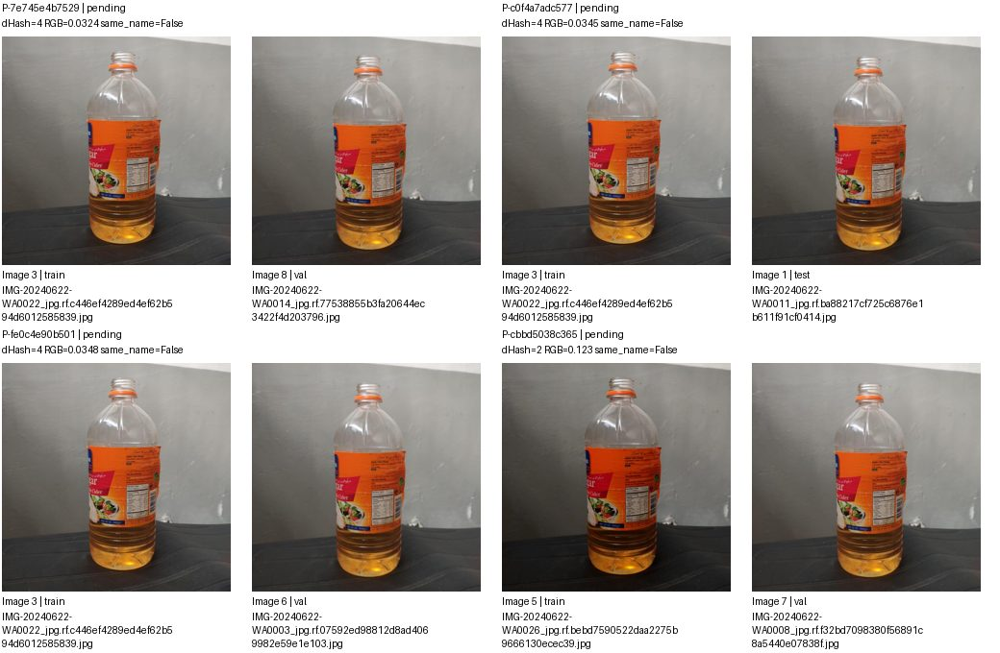

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-7e745e4b7529,images/train/IMG-20240622-WA0022_jpg.rf.c446ef4289ed4ef62b594d6012585839.jpg,images/val/IMG-20240622-WA0014_jpg.rf.77538855b3fa20644ec3422f4d203796.jpg,pending,
P-c0f4a7adc577,images/train/IMG-20240622-WA0022_jpg.rf.c446ef4289ed4ef62b594d6012585839.jpg,images/test/IMG-20240622-WA0011_jpg.rf.ba88217cf725c6876e1b611f91cf0414.jpg,pending,
P-fe0c4e90b501,images/train/IMG-20240622-WA0022_jpg.rf.c446ef4289ed4ef62b594d6012585839.jpg,images/val/IMG-20240622-WA0003_jpg.rf.07592ed98812d8ad4069982e59e1e103.jpg,pending,
P-cbbd5038c365,images/train/IMG-20240622-WA0026_jpg.rf.bebd7590522daa2275b9666130ecec39.jpg,images/val/IMG-20240622-WA0008_jpg.rf.f32bd7098380f56891c8a5440e07838f.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 93/166 G-cef9e1025bfc | 8 ảnh, 15 cặp
Split: {'test': 1, 'train': 4, 'val': 3}
Quyết định: {'pending': 15}
Ảnh trang None/2; cặp trang 4/4. Nhóm liên thông không phải kết luận trùng.


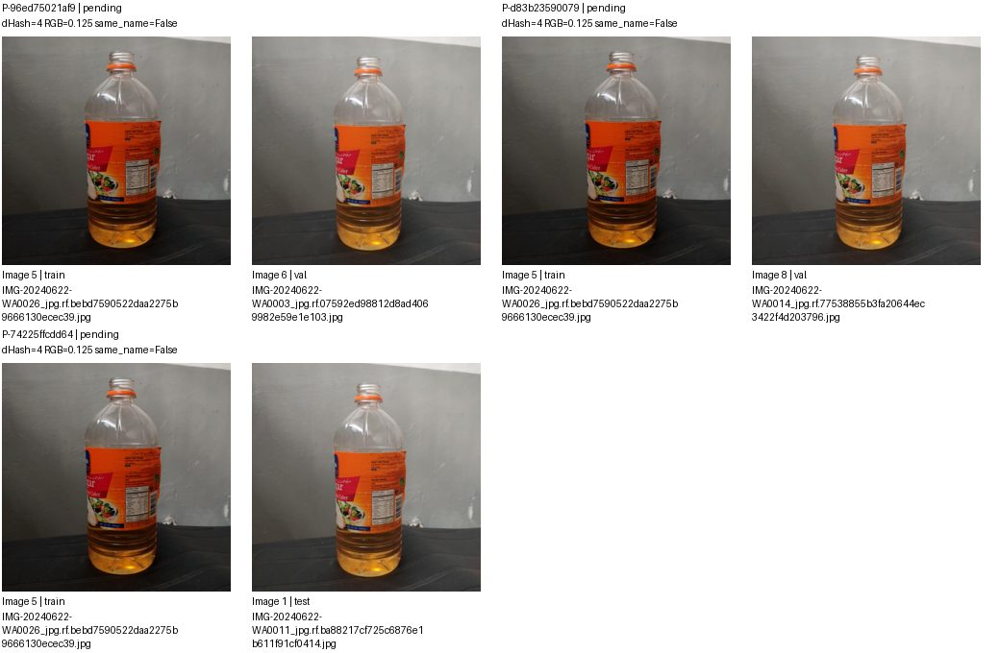

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-96ed75021af9,images/train/IMG-20240622-WA0026_jpg.rf.bebd7590522daa2275b9666130ecec39.jpg,images/val/IMG-20240622-WA0003_jpg.rf.07592ed98812d8ad4069982e59e1e103.jpg,pending,
P-d83b23590079,images/train/IMG-20240622-WA0026_jpg.rf.bebd7590522daa2275b9666130ecec39.jpg,images/val/IMG-20240622-WA0014_jpg.rf.77538855b3fa20644ec3422f4d203796.jpg,pending,
P-74225ffcdd64,images/train/IMG-20240622-WA0026_jpg.rf.bebd7590522daa2275b9666130ecec39.jpg,images/test/IMG-20240622-WA0011_jpg.rf.ba88217cf725c6876e1b611f91cf0414.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 94/166 G-77712b983400 | 44 ảnh, 120 cặp
Split: {'test': 1, 'train': 39, 'val': 4}
Quyết định: {'pending': 120}
Ảnh trang 1/8; cặp trang 1/30. Nhóm liên thông không phải kết luận trùng.


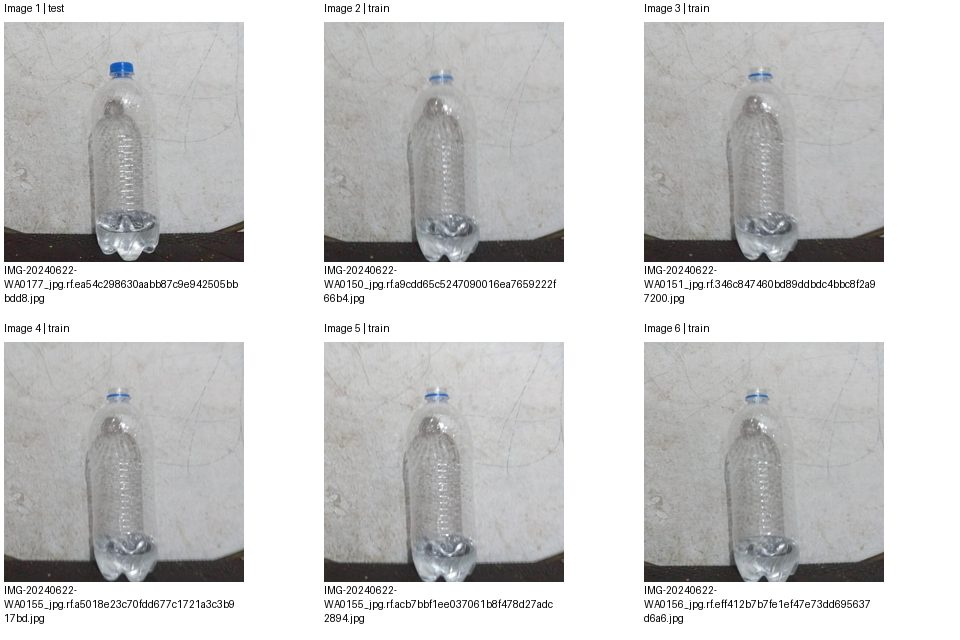

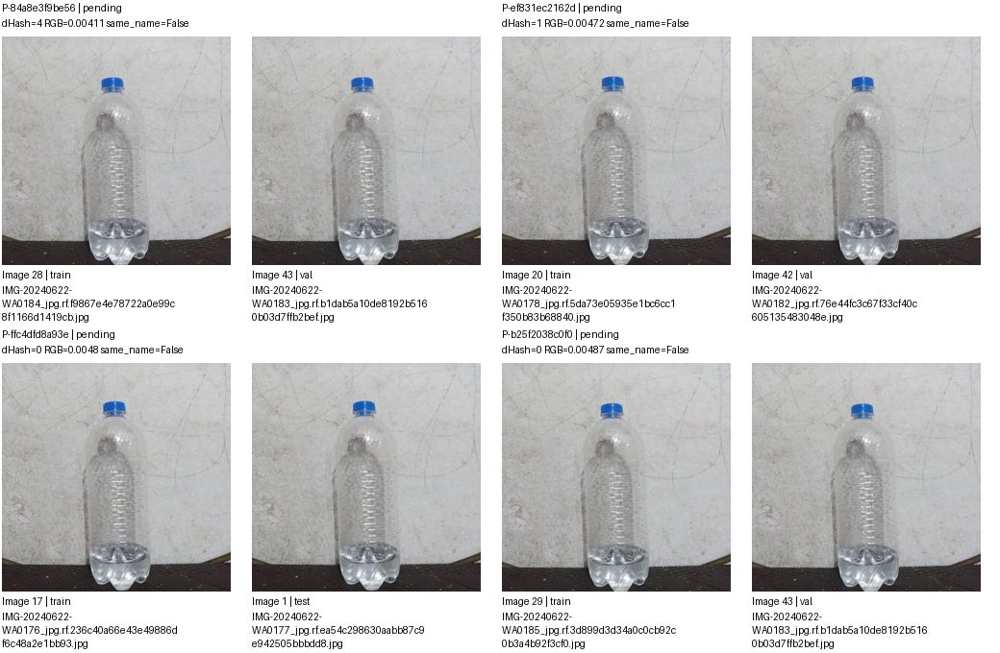

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-84a8e3f9be56,images/train/IMG-20240622-WA0184_jpg.rf.f9867e4e78722a0e99c8f1166d1419cb.jpg,images/val/IMG-20240622-WA0183_jpg.rf.b1dab5a10de8192b5160b03d7ffb2bef.jpg,pending,
P-ef831ec2162d,images/train/IMG-20240622-WA0178_jpg.rf.5da73e05935e1bc6cc1f350b83b68840.jpg,images/val/IMG-20240622-WA0182_jpg.rf.76e44fc3c67f33cf40c605135483048e.jpg,pending,
P-ffc4dfd8a93e,images/train/IMG-20240622-WA0176_jpg.rf.236c40a66e43e49886df6c48a2e1bb93.jpg,images/test/IMG-20240622-WA0177_jpg.rf.ea54c298630aabb87c9e942505bbbdd8.jpg,pending,
P-b25f2038c0f0,images/train/IMG-20240622-WA0185_jpg.rf.3d899d3d34a0c0cb92c0b3a4b92f3cf0.jpg,images/val/IMG-20240622-WA0183_jpg.rf.b1dab5a10de8192b5160b03d7ffb2bef.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 94/166 G-77712b983400 | 44 ảnh, 120 cặp
Split: {'test': 1, 'train': 39, 'val': 4}
Quyết định: {'pending': 120}
Ảnh trang 2/8; cặp trang 2/30. Nhóm liên thông không phải kết luận trùng.


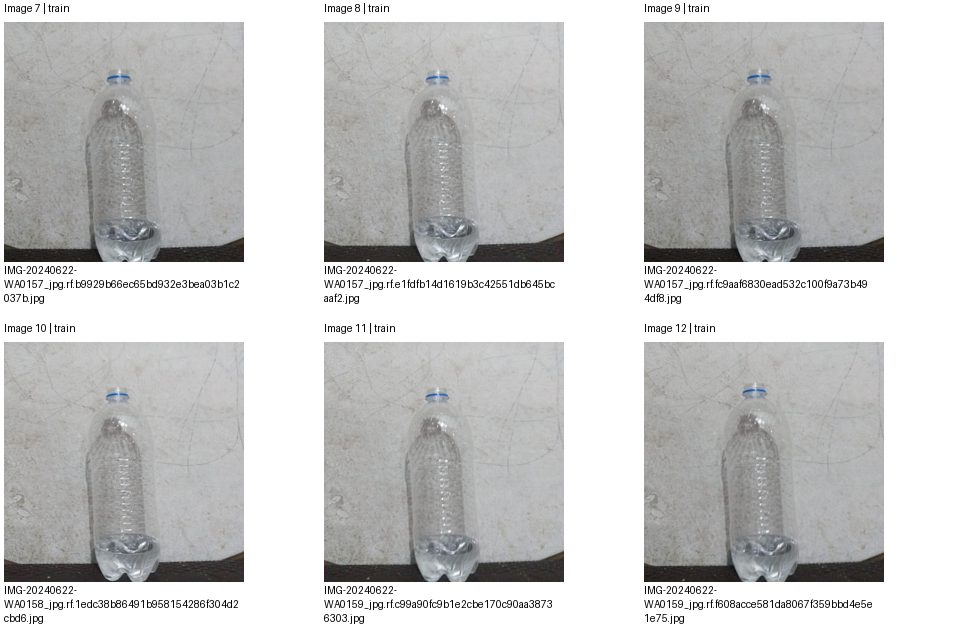

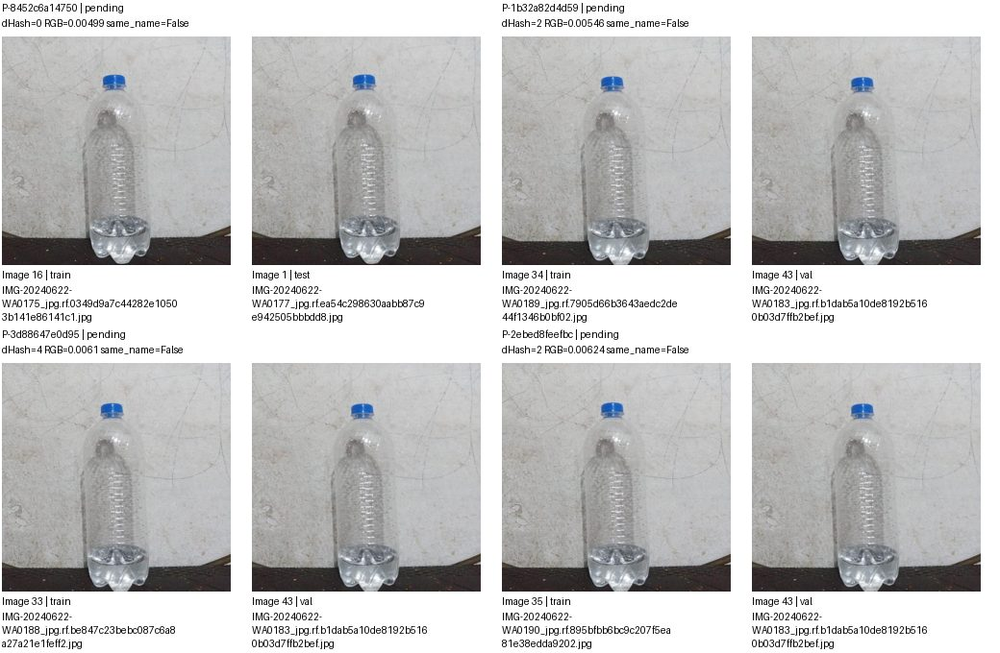

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-8452c6a14750,images/train/IMG-20240622-WA0175_jpg.rf.0349d9a7c44282e10503b141e86141c1.jpg,images/test/IMG-20240622-WA0177_jpg.rf.ea54c298630aabb87c9e942505bbbdd8.jpg,pending,
P-1b32a82d4d59,images/train/IMG-20240622-WA0189_jpg.rf.7905d66b3643aedc2de44f1346b0bf02.jpg,images/val/IMG-20240622-WA0183_jpg.rf.b1dab5a10de8192b5160b03d7ffb2bef.jpg,pending,
P-3d88647e0d95,images/train/IMG-20240622-WA0188_jpg.rf.be847c23bebc087c6a8a27a21e1feff2.jpg,images/val/IMG-20240622-WA0183_jpg.rf.b1dab5a10de8192b5160b03d7ffb2bef.jpg,pending,
P-2ebed8feefbc,images/train/IMG-20240622-WA0190_jpg.rf.895bfbb6bc9c207f5ea81e38edda9202.jpg,images/val/IMG-20240622-WA0183_jpg.rf.b1dab5a10de8192b5160b03d7ffb2bef.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 94/166 G-77712b983400 | 44 ảnh, 120 cặp
Split: {'test': 1, 'train': 39, 'val': 4}
Quyết định: {'pending': 120}
Ảnh trang 3/8; cặp trang 3/30. Nhóm liên thông không phải kết luận trùng.


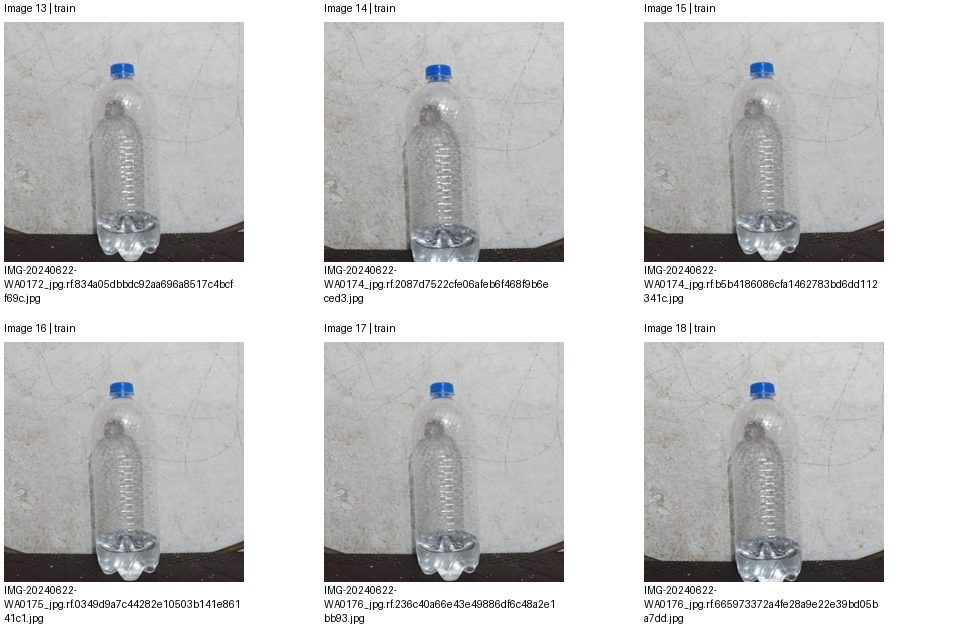

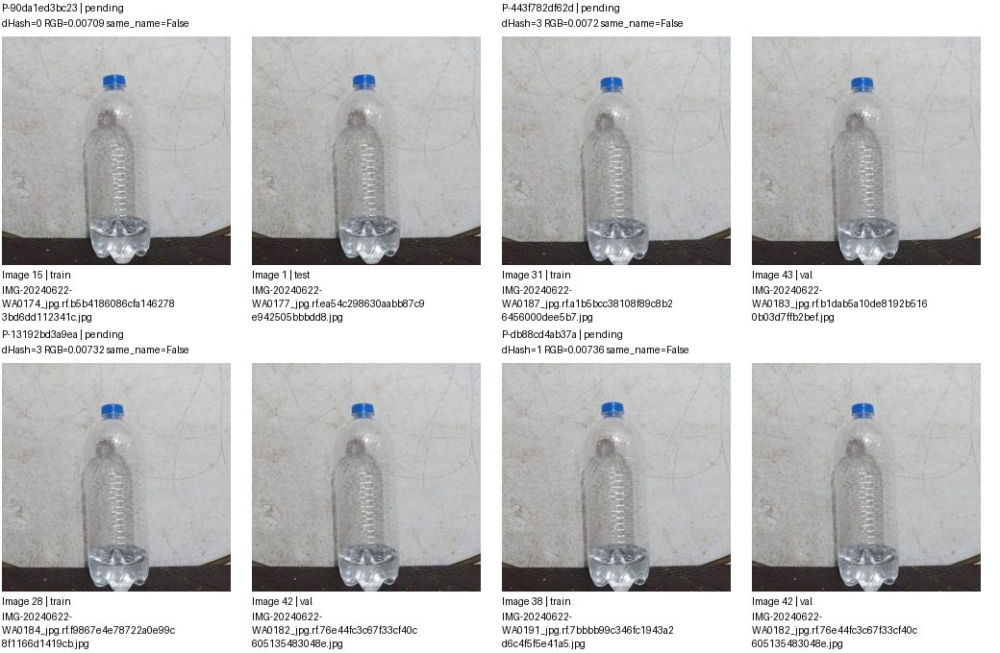

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-90da1ed3bc23,images/train/IMG-20240622-WA0174_jpg.rf.b5b4186086cfa1462783bd6dd112341c.jpg,images/test/IMG-20240622-WA0177_jpg.rf.ea54c298630aabb87c9e942505bbbdd8.jpg,pending,
P-443f782df62d,images/train/IMG-20240622-WA0187_jpg.rf.a1b5bcc38108f89c8b26456000dee5b7.jpg,images/val/IMG-20240622-WA0183_jpg.rf.b1dab5a10de8192b5160b03d7ffb2bef.jpg,pending,
P-13192bd3a9ea,images/train/IMG-20240622-WA0184_jpg.rf.f9867e4e78722a0e99c8f1166d1419cb.jpg,images/val/IMG-20240622-WA0182_jpg.rf.76e44fc3c67f33cf40c605135483048e.jpg,pending,
P-db88cd4ab37a,images/train/IMG-20240622-WA0191_jpg.rf.7bbbb99c346fc1943a2d6c4f5f5e41a5.jpg,images/val/IMG-20240622-WA0182_jpg.rf.76e44fc3c67f33cf40c605135483048e.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 94/166 G-77712b983400 | 44 ảnh, 120 cặp
Split: {'test': 1, 'train': 39, 'val': 4}
Quyết định: {'pending': 120}
Ảnh trang 4/8; cặp trang 4/30. Nhóm liên thông không phải kết luận trùng.


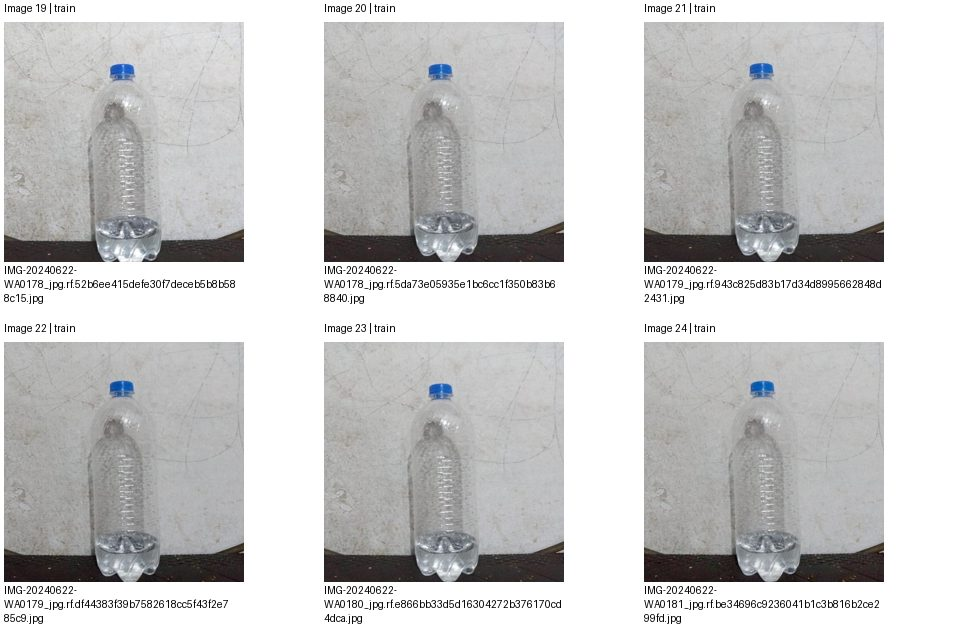

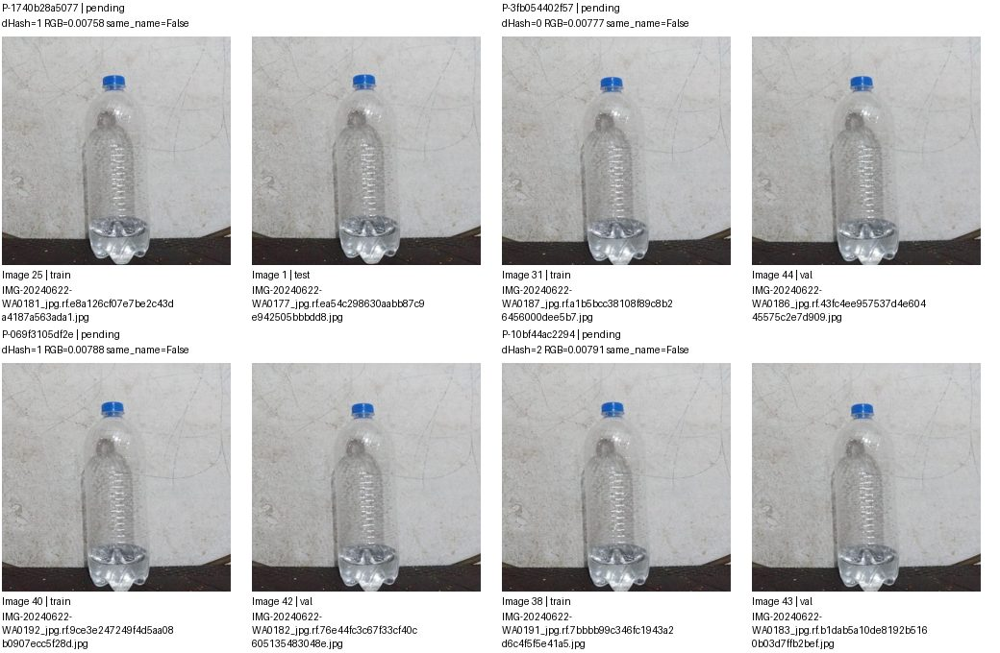

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-1740b28a5077,images/train/IMG-20240622-WA0181_jpg.rf.e8a126cf07e7be2c43da4187a563ada1.jpg,images/test/IMG-20240622-WA0177_jpg.rf.ea54c298630aabb87c9e942505bbbdd8.jpg,pending,
P-3fb054402f57,images/train/IMG-20240622-WA0187_jpg.rf.a1b5bcc38108f89c8b26456000dee5b7.jpg,images/val/IMG-20240622-WA0186_jpg.rf.43fc4ee957537d4e60445575c2e7d909.jpg,pending,
P-069f3105df2e,images/train/IMG-20240622-WA0192_jpg.rf.9ce3e247249f4d5aa08b0907ecc5f28d.jpg,images/val/IMG-20240622-WA0182_jpg.rf.76e44fc3c67f33cf40c605135483048e.jpg,pending,
P-10bf44ac2294,images/train/IMG-20240622-WA0191_jpg.rf.7bbbb99c346fc1943a2d6c4f5f5e41a5.jpg,images/val/IMG-20240622-WA0183_jpg.rf.b1dab5a10de8192b5160b03d7ffb2bef.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 94/166 G-77712b983400 | 44 ảnh, 120 cặp
Split: {'test': 1, 'train': 39, 'val': 4}
Quyết định: {'pending': 120}
Ảnh trang 5/8; cặp trang 5/30. Nhóm liên thông không phải kết luận trùng.


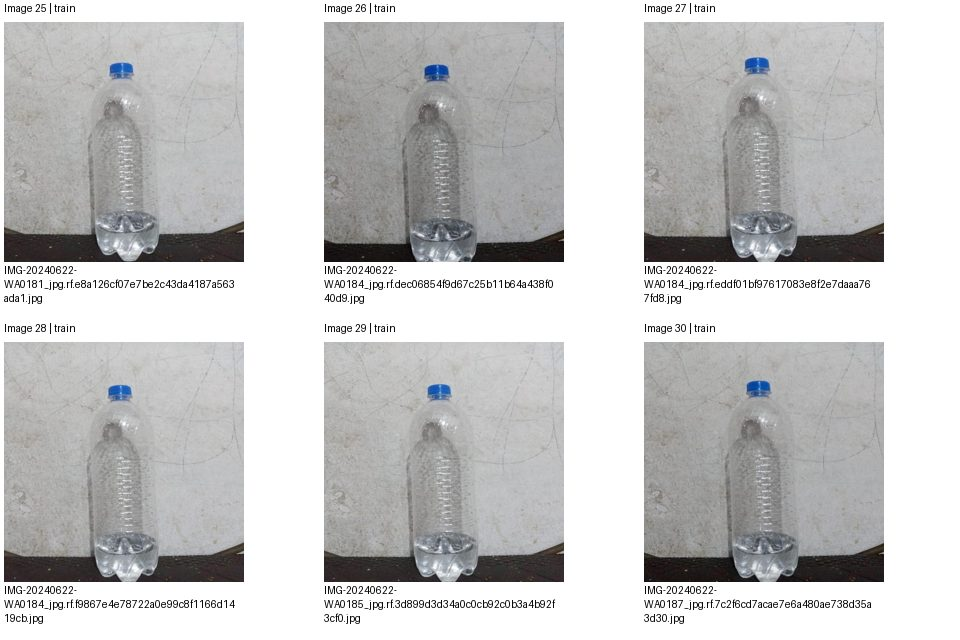

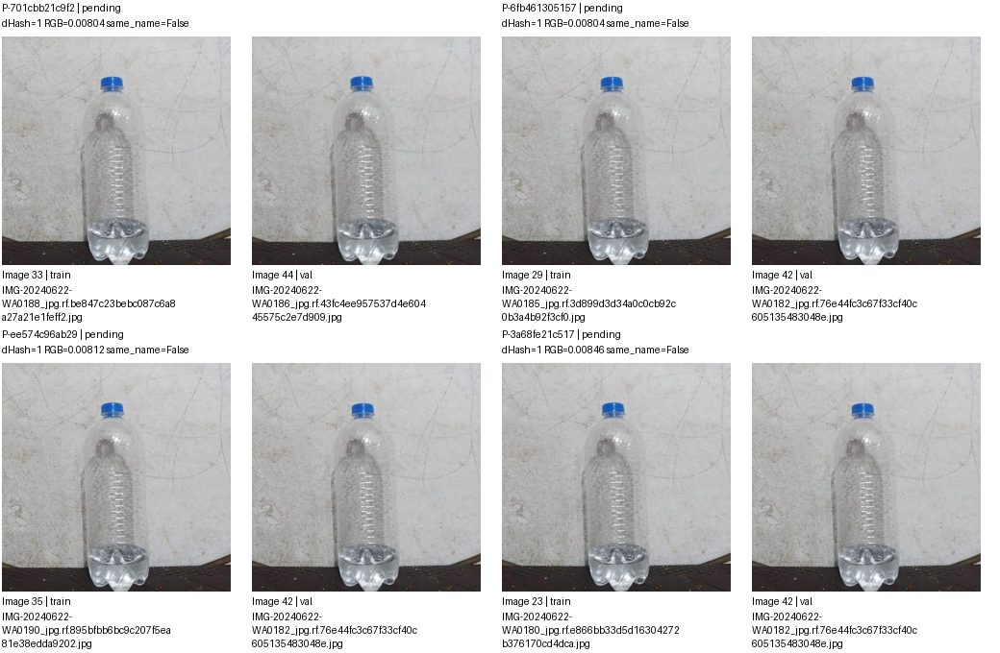

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-701cbb21c9f2,images/train/IMG-20240622-WA0188_jpg.rf.be847c23bebc087c6a8a27a21e1feff2.jpg,images/val/IMG-20240622-WA0186_jpg.rf.43fc4ee957537d4e60445575c2e7d909.jpg,pending,
P-6fb461305157,images/train/IMG-20240622-WA0185_jpg.rf.3d899d3d34a0c0cb92c0b3a4b92f3cf0.jpg,images/val/IMG-20240622-WA0182_jpg.rf.76e44fc3c67f33cf40c605135483048e.jpg,pending,
P-ee574c96ab29,images/train/IMG-20240622-WA0190_jpg.rf.895bfbb6bc9c207f5ea81e38edda9202.jpg,images/val/IMG-20240622-WA0182_jpg.rf.76e44fc3c67f33cf40c605135483048e.jpg,pending,
P-3a68fe21c517,images/train/IMG-20240622-WA0180_jpg.rf.e866bb33d5d16304272b376170cd4dca.jpg,images/val/IMG-20240622-WA0182_jpg.rf.76e44fc3c67f33cf40c605135483048e.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 94/166 G-77712b983400 | 44 ảnh, 120 cặp
Split: {'test': 1, 'train': 39, 'val': 4}
Quyết định: {'pending': 120}
Ảnh trang 6/8; cặp trang 6/30. Nhóm liên thông không phải kết luận trùng.


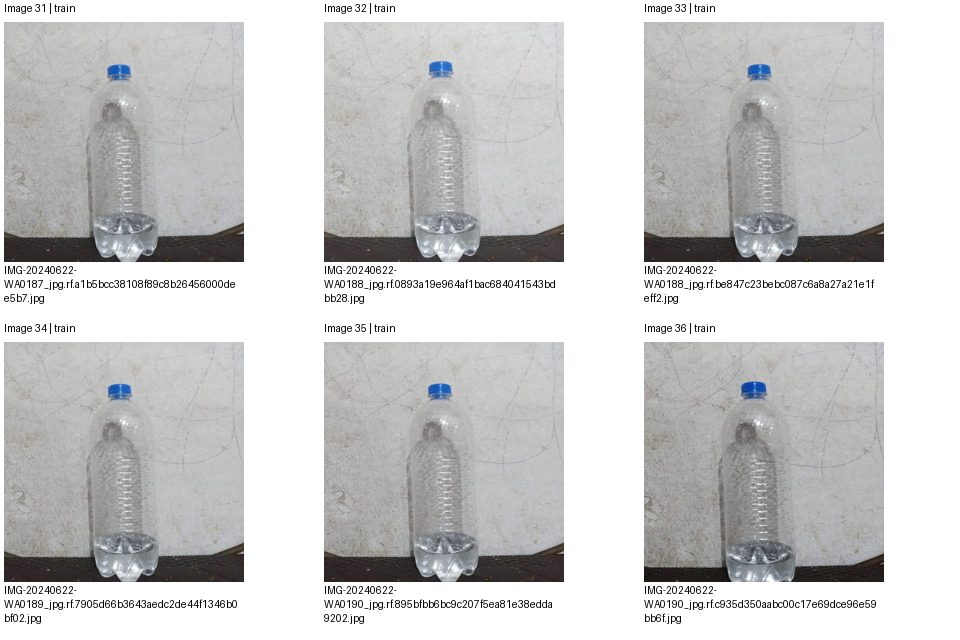

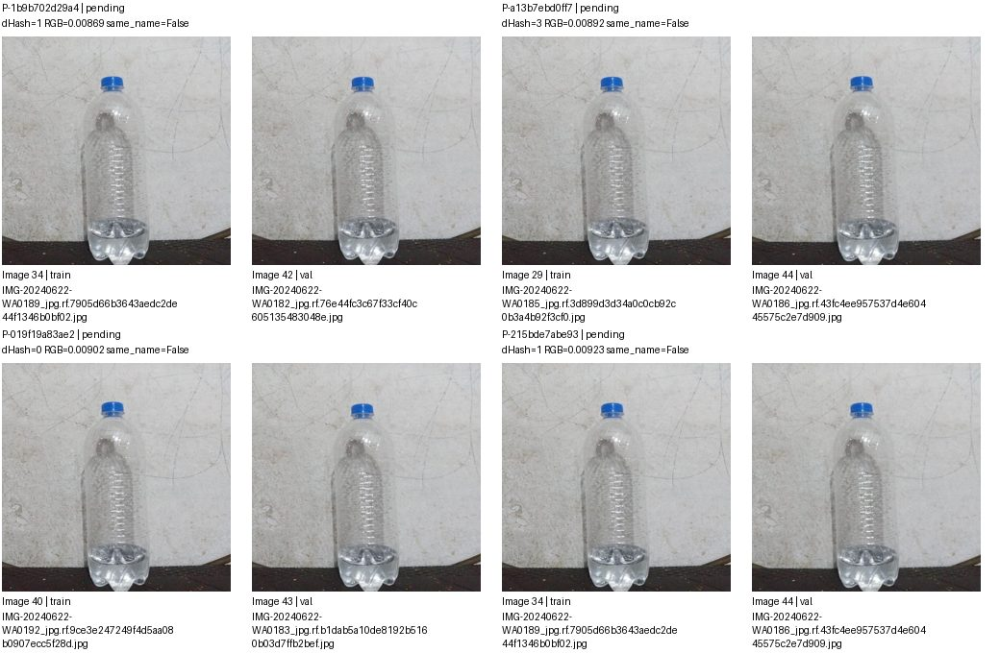

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-1b9b702d29a4,images/train/IMG-20240622-WA0189_jpg.rf.7905d66b3643aedc2de44f1346b0bf02.jpg,images/val/IMG-20240622-WA0182_jpg.rf.76e44fc3c67f33cf40c605135483048e.jpg,pending,
P-a13b7ebd0ff7,images/train/IMG-20240622-WA0185_jpg.rf.3d899d3d34a0c0cb92c0b3a4b92f3cf0.jpg,images/val/IMG-20240622-WA0186_jpg.rf.43fc4ee957537d4e60445575c2e7d909.jpg,pending,
P-019f19a83ae2,images/train/IMG-20240622-WA0192_jpg.rf.9ce3e247249f4d5aa08b0907ecc5f28d.jpg,images/val/IMG-20240622-WA0183_jpg.rf.b1dab5a10de8192b5160b03d7ffb2bef.jpg,pending,
P-215bde7abe93,images/train/IMG-20240622-WA0189_jpg.rf.7905d66b3643aedc2de44f1346b0bf02.jpg,images/val/IMG-20240622-WA0186_jpg.rf.43fc4ee957537d4e60445575c2e7d909.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 94/166 G-77712b983400 | 44 ảnh, 120 cặp
Split: {'test': 1, 'train': 39, 'val': 4}
Quyết định: {'pending': 120}
Ảnh trang 7/8; cặp trang 7/30. Nhóm liên thông không phải kết luận trùng.


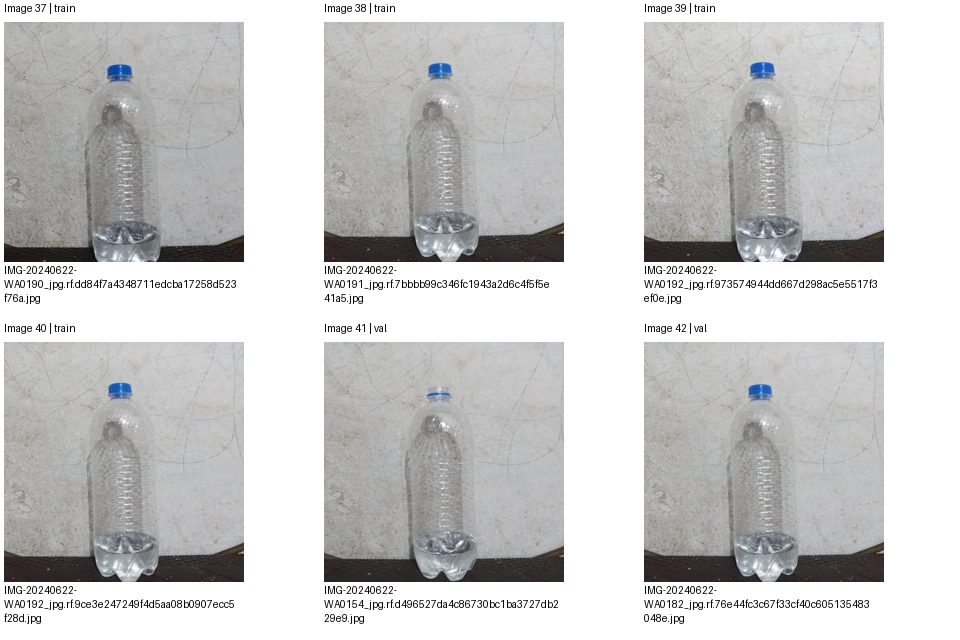

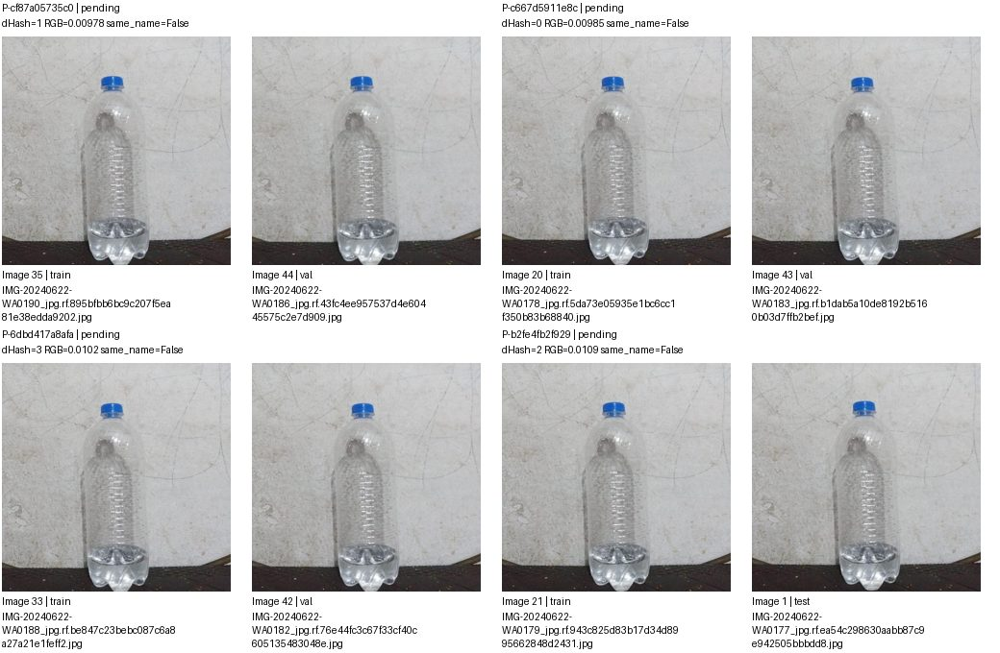

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-cf87a05735c0,images/train/IMG-20240622-WA0190_jpg.rf.895bfbb6bc9c207f5ea81e38edda9202.jpg,images/val/IMG-20240622-WA0186_jpg.rf.43fc4ee957537d4e60445575c2e7d909.jpg,pending,
P-c667d5911e8c,images/train/IMG-20240622-WA0178_jpg.rf.5da73e05935e1bc6cc1f350b83b68840.jpg,images/val/IMG-20240622-WA0183_jpg.rf.b1dab5a10de8192b5160b03d7ffb2bef.jpg,pending,
P-6dbd417a8afa,images/train/IMG-20240622-WA0188_jpg.rf.be847c23bebc087c6a8a27a21e1feff2.jpg,images/val/IMG-20240622-WA0182_jpg.rf.76e44fc3c67f33cf40c605135483048e.jpg,pending,
P-b2fe4fb2f929,images/train/IMG-20240622-WA0179_jpg.rf.943c825d83b17d34d8995662848d2431.jpg,images/test/IMG-20240622-WA0177_jpg.rf.ea54c298630aabb87c9e942505bbbdd8.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 94/166 G-77712b983400 | 44 ảnh, 120 cặp
Split: {'test': 1, 'train': 39, 'val': 4}
Quyết định: {'pending': 120}
Ảnh trang 8/8; cặp trang 8/30. Nhóm liên thông không phải kết luận trùng.


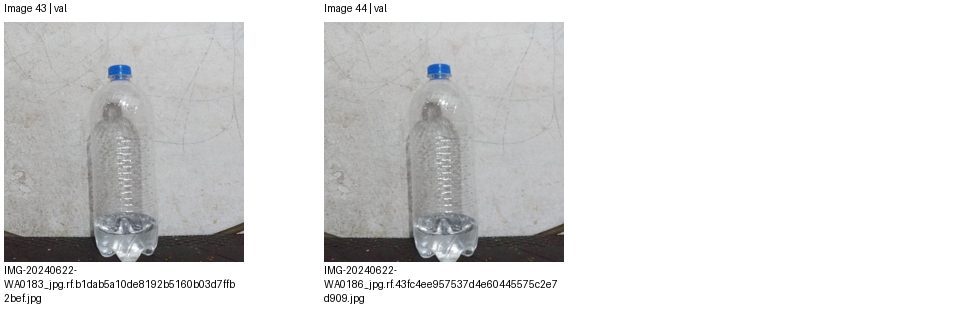

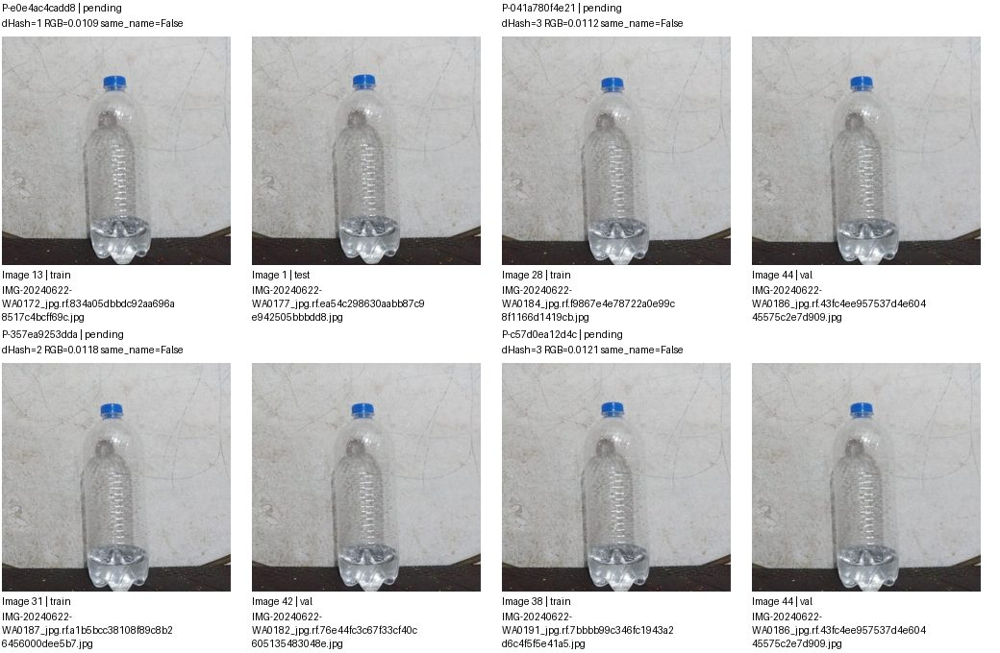

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-e0e4ac4cadd8,images/train/IMG-20240622-WA0172_jpg.rf.834a05dbbdc92aa696a8517c4bcff69c.jpg,images/test/IMG-20240622-WA0177_jpg.rf.ea54c298630aabb87c9e942505bbbdd8.jpg,pending,
P-041a780f4e21,images/train/IMG-20240622-WA0184_jpg.rf.f9867e4e78722a0e99c8f1166d1419cb.jpg,images/val/IMG-20240622-WA0186_jpg.rf.43fc4ee957537d4e60445575c2e7d909.jpg,pending,
P-357ea9253dda,images/train/IMG-20240622-WA0187_jpg.rf.a1b5bcc38108f89c8b26456000dee5b7.jpg,images/val/IMG-20240622-WA0182_jpg.rf.76e44fc3c67f33cf40c605135483048e.jpg,pending,
P-c57d0ea12d4c,images/train/IMG-20240622-WA0191_jpg.rf.7bbbb99c346fc1943a2d6c4f5f5e41a5.jpg,images/val/IMG-20240622-WA0186_jpg.rf.43fc4ee957537d4e60445575c2e7d909.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 94/166 G-77712b983400 | 44 ảnh, 120 cặp
Split: {'test': 1, 'train': 39, 'val': 4}
Quyết định: {'pending': 120}
Ảnh trang None/8; cặp trang 9/30. Nhóm liên thông không phải kết luận trùng.


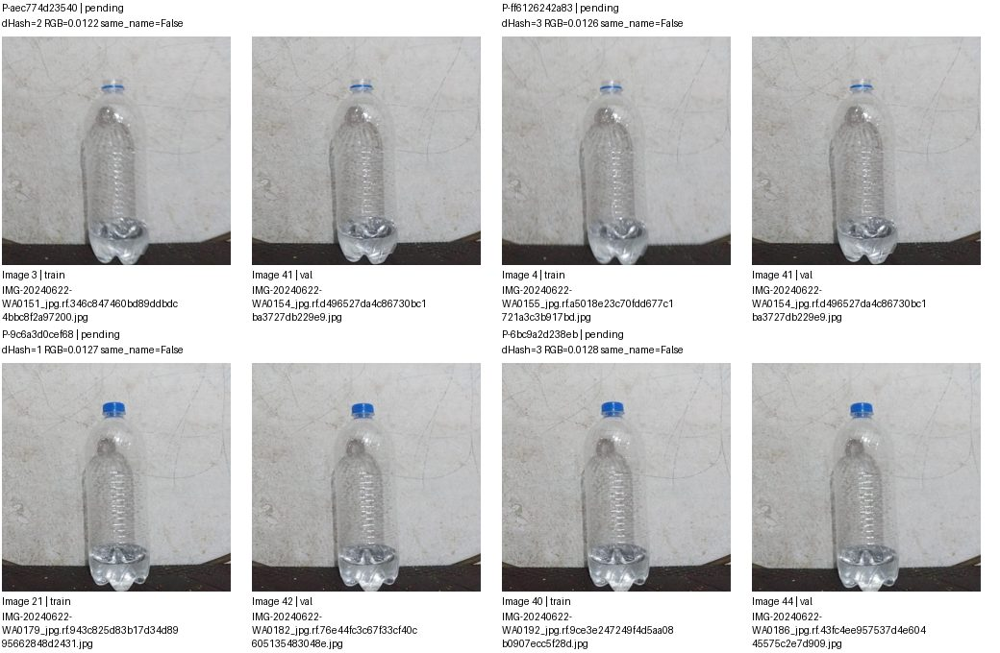

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-aec774d23540,images/train/IMG-20240622-WA0151_jpg.rf.346c847460bd89ddbdc4bbc8f2a97200.jpg,images/val/IMG-20240622-WA0154_jpg.rf.d496527da4c86730bc1ba3727db229e9.jpg,pending,
P-ff6126242a83,images/train/IMG-20240622-WA0155_jpg.rf.a5018e23c70fdd677c1721a3c3b917bd.jpg,images/val/IMG-20240622-WA0154_jpg.rf.d496527da4c86730bc1ba3727db229e9.jpg,pending,
P-9c6a3d0cef68,images/train/IMG-20240622-WA0179_jpg.rf.943c825d83b17d34d8995662848d2431.jpg,images/val/IMG-20240622-WA0182_jpg.rf.76e44fc3c67f33cf40c605135483048e.jpg,pending,
P-6bc9a2d238eb,images/train/IMG-20240622-WA0192_jpg.rf.9ce3e247249f4d5aa08b0907ecc5f28d.jpg,images/val/IMG-20240622-WA0186_jpg.rf.43fc4ee957537d4e60445575c2e7d909.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 94/166 G-77712b983400 | 44 ảnh, 120 cặp
Split: {'test': 1, 'train': 39, 'val': 4}
Quyết định: {'pending': 120}
Ảnh trang None/8; cặp trang 10/30. Nhóm liên thông không phải kết luận trùng.


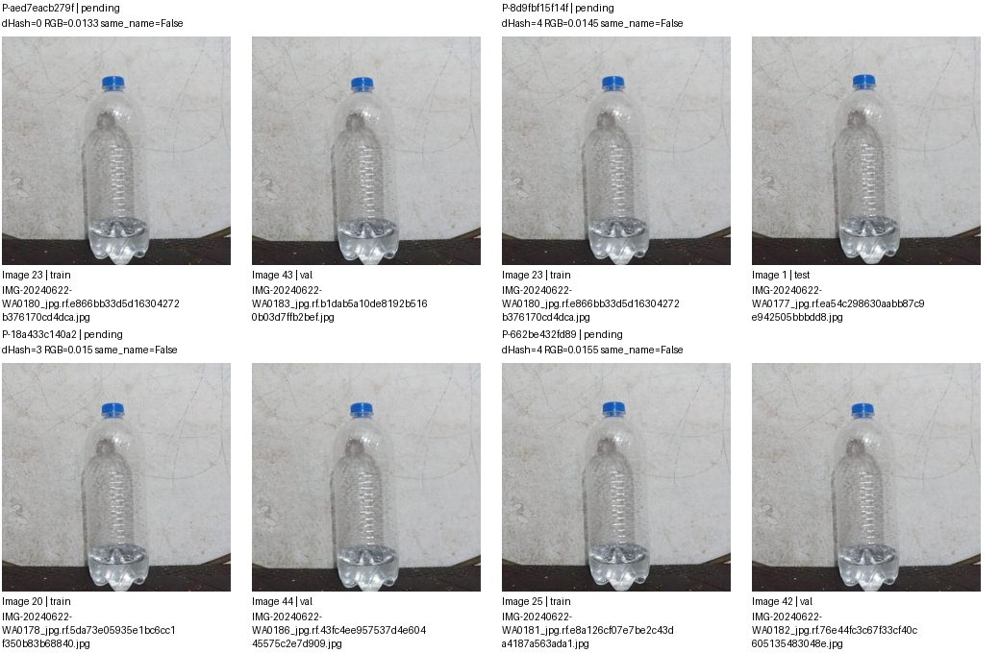

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-aed7eacb279f,images/train/IMG-20240622-WA0180_jpg.rf.e866bb33d5d16304272b376170cd4dca.jpg,images/val/IMG-20240622-WA0183_jpg.rf.b1dab5a10de8192b5160b03d7ffb2bef.jpg,pending,
P-8d9fbf15f14f,images/train/IMG-20240622-WA0180_jpg.rf.e866bb33d5d16304272b376170cd4dca.jpg,images/test/IMG-20240622-WA0177_jpg.rf.ea54c298630aabb87c9e942505bbbdd8.jpg,pending,
P-18a433c140a2,images/train/IMG-20240622-WA0178_jpg.rf.5da73e05935e1bc6cc1f350b83b68840.jpg,images/val/IMG-20240622-WA0186_jpg.rf.43fc4ee957537d4e60445575c2e7d909.jpg,pending,
P-662be432fd89,images/train/IMG-20240622-WA0181_jpg.rf.e8a126cf07e7be2c43da4187a563ada1.jpg,images/val/IMG-20240622-WA0182_jpg.rf.76e44fc3c67f33cf40c605135483048e.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 94/166 G-77712b983400 | 44 ảnh, 120 cặp
Split: {'test': 1, 'train': 39, 'val': 4}
Quyết định: {'pending': 120}
Ảnh trang None/8; cặp trang 11/30. Nhóm liên thông không phải kết luận trùng.


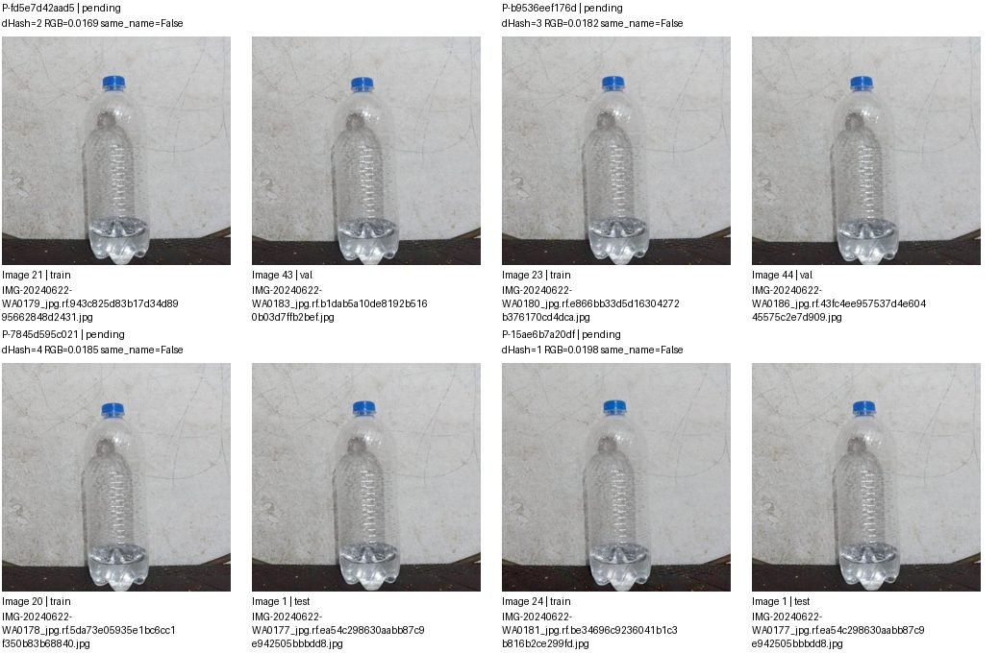

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-fd5e7d42aad5,images/train/IMG-20240622-WA0179_jpg.rf.943c825d83b17d34d8995662848d2431.jpg,images/val/IMG-20240622-WA0183_jpg.rf.b1dab5a10de8192b5160b03d7ffb2bef.jpg,pending,
P-b9536eef176d,images/train/IMG-20240622-WA0180_jpg.rf.e866bb33d5d16304272b376170cd4dca.jpg,images/val/IMG-20240622-WA0186_jpg.rf.43fc4ee957537d4e60445575c2e7d909.jpg,pending,
P-7845d595c021,images/train/IMG-20240622-WA0178_jpg.rf.5da73e05935e1bc6cc1f350b83b68840.jpg,images/test/IMG-20240622-WA0177_jpg.rf.ea54c298630aabb87c9e942505bbbdd8.jpg,pending,
P-15ae6b7a20df,images/train/IMG-20240622-WA0181_jpg.rf.be34696c9236041b1c3b816b2ce299fd.jpg,images/test/IMG-20240622-WA0177_jpg.rf.ea54c298630aabb87c9e942505bbbdd8.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 94/166 G-77712b983400 | 44 ảnh, 120 cặp
Split: {'test': 1, 'train': 39, 'val': 4}
Quyết định: {'pending': 120}
Ảnh trang None/8; cặp trang 12/30. Nhóm liên thông không phải kết luận trùng.


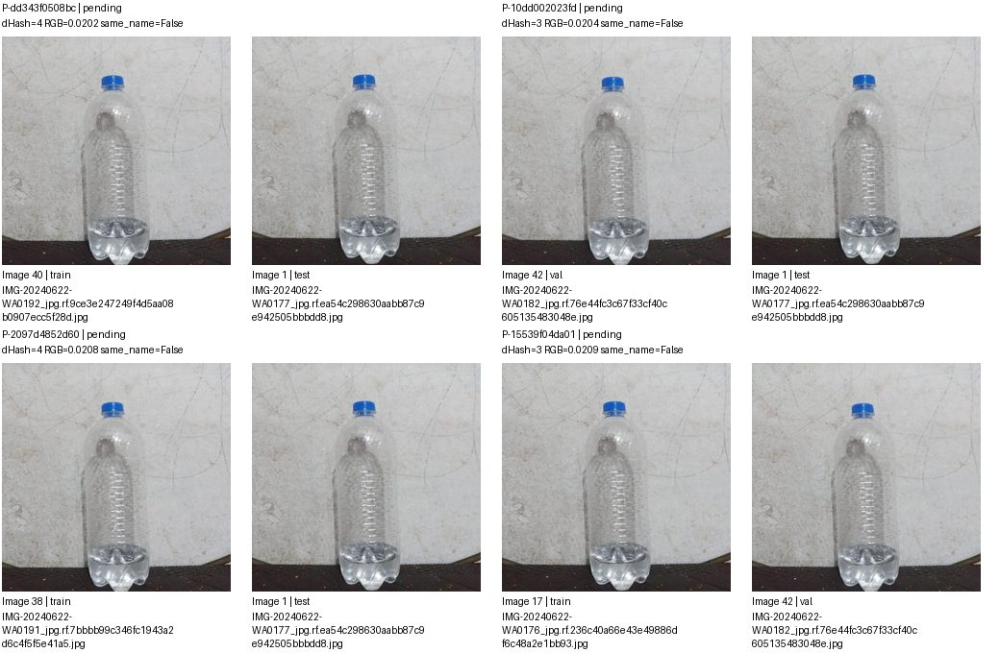

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-dd343f0508bc,images/train/IMG-20240622-WA0192_jpg.rf.9ce3e247249f4d5aa08b0907ecc5f28d.jpg,images/test/IMG-20240622-WA0177_jpg.rf.ea54c298630aabb87c9e942505bbbdd8.jpg,pending,
P-10dd002023fd,images/val/IMG-20240622-WA0182_jpg.rf.76e44fc3c67f33cf40c605135483048e.jpg,images/test/IMG-20240622-WA0177_jpg.rf.ea54c298630aabb87c9e942505bbbdd8.jpg,pending,
P-2097d4852d60,images/train/IMG-20240622-WA0191_jpg.rf.7bbbb99c346fc1943a2d6c4f5f5e41a5.jpg,images/test/IMG-20240622-WA0177_jpg.rf.ea54c298630aabb87c9e942505bbbdd8.jpg,pending,
P-15539f04da01,images/train/IMG-20240622-WA0176_jpg.rf.236c40a66e43e49886df6c48a2e1bb93.jpg,images/val/IMG-20240622-WA0182_jpg.rf.76e44fc3c67f33cf40c605135483048e.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 94/166 G-77712b983400 | 44 ảnh, 120 cặp
Split: {'test': 1, 'train': 39, 'val': 4}
Quyết định: {'pending': 120}
Ảnh trang None/8; cặp trang 13/30. Nhóm liên thông không phải kết luận trùng.


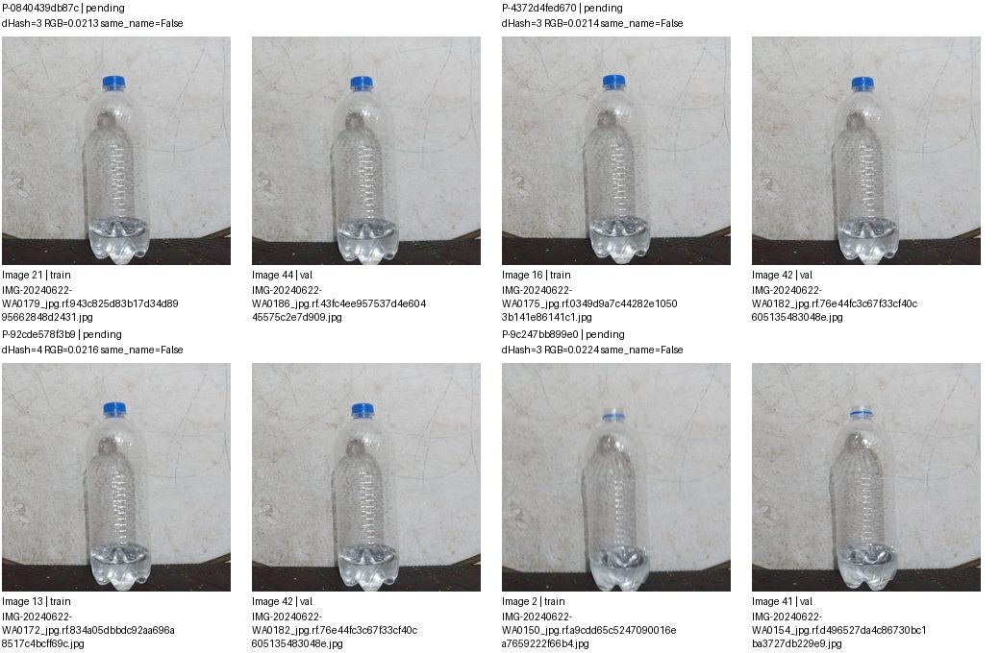

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-0840439db87c,images/train/IMG-20240622-WA0179_jpg.rf.943c825d83b17d34d8995662848d2431.jpg,images/val/IMG-20240622-WA0186_jpg.rf.43fc4ee957537d4e60445575c2e7d909.jpg,pending,
P-4372d4fed670,images/train/IMG-20240622-WA0175_jpg.rf.0349d9a7c44282e10503b141e86141c1.jpg,images/val/IMG-20240622-WA0182_jpg.rf.76e44fc3c67f33cf40c605135483048e.jpg,pending,
P-92cde578f3b9,images/train/IMG-20240622-WA0172_jpg.rf.834a05dbbdc92aa696a8517c4bcff69c.jpg,images/val/IMG-20240622-WA0182_jpg.rf.76e44fc3c67f33cf40c605135483048e.jpg,pending,
P-9c247bb899e0,images/train/IMG-20240622-WA0150_jpg.rf.a9cdd65c5247090016ea7659222f66b4.jpg,images/val/IMG-20240622-WA0154_jpg.rf.d496527da4c86730bc1ba3727db229e9.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 94/166 G-77712b983400 | 44 ảnh, 120 cặp
Split: {'test': 1, 'train': 39, 'val': 4}
Quyết định: {'pending': 120}
Ảnh trang None/8; cặp trang 14/30. Nhóm liên thông không phải kết luận trùng.


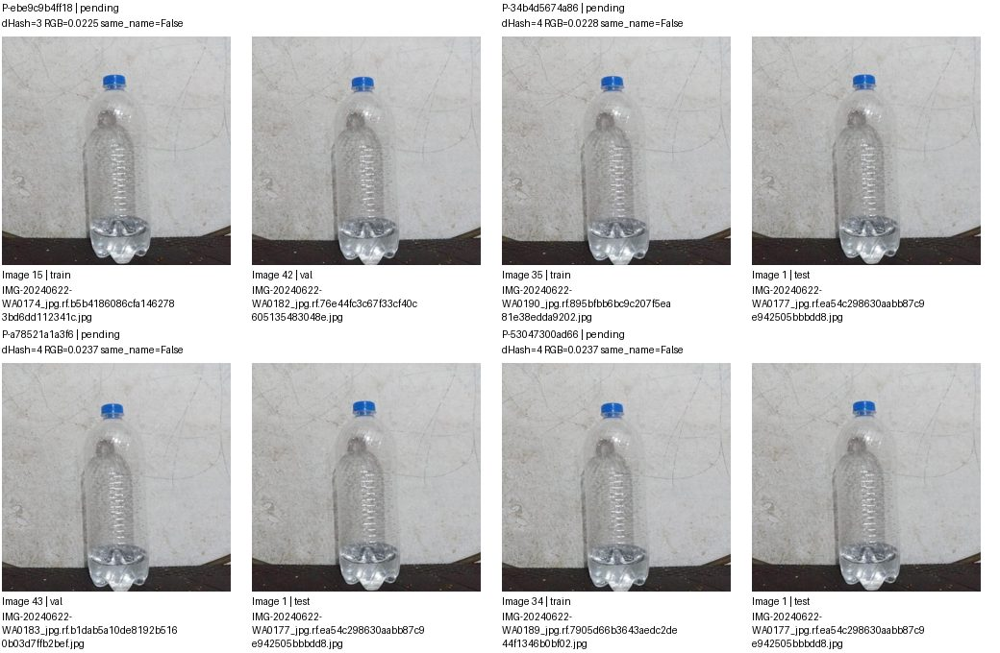

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-ebe9c9b4ff18,images/train/IMG-20240622-WA0174_jpg.rf.b5b4186086cfa1462783bd6dd112341c.jpg,images/val/IMG-20240622-WA0182_jpg.rf.76e44fc3c67f33cf40c605135483048e.jpg,pending,
P-34b4d5674a86,images/train/IMG-20240622-WA0190_jpg.rf.895bfbb6bc9c207f5ea81e38edda9202.jpg,images/test/IMG-20240622-WA0177_jpg.rf.ea54c298630aabb87c9e942505bbbdd8.jpg,pending,
P-a78521a1a3f6,images/val/IMG-20240622-WA0183_jpg.rf.b1dab5a10de8192b5160b03d7ffb2bef.jpg,images/test/IMG-20240622-WA0177_jpg.rf.ea54c298630aabb87c9e942505bbbdd8.jpg,pending,
P-53047300ad66,images/train/IMG-20240622-WA0189_jpg.rf.7905d66b3643aedc2de44f1346b0bf02.jpg,images/test/IMG-20240622-WA0177_jpg.rf.ea54c298630aabb87c9e942505bbbdd8.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 94/166 G-77712b983400 | 44 ảnh, 120 cặp
Split: {'test': 1, 'train': 39, 'val': 4}
Quyết định: {'pending': 120}
Ảnh trang None/8; cặp trang 15/30. Nhóm liên thông không phải kết luận trùng.


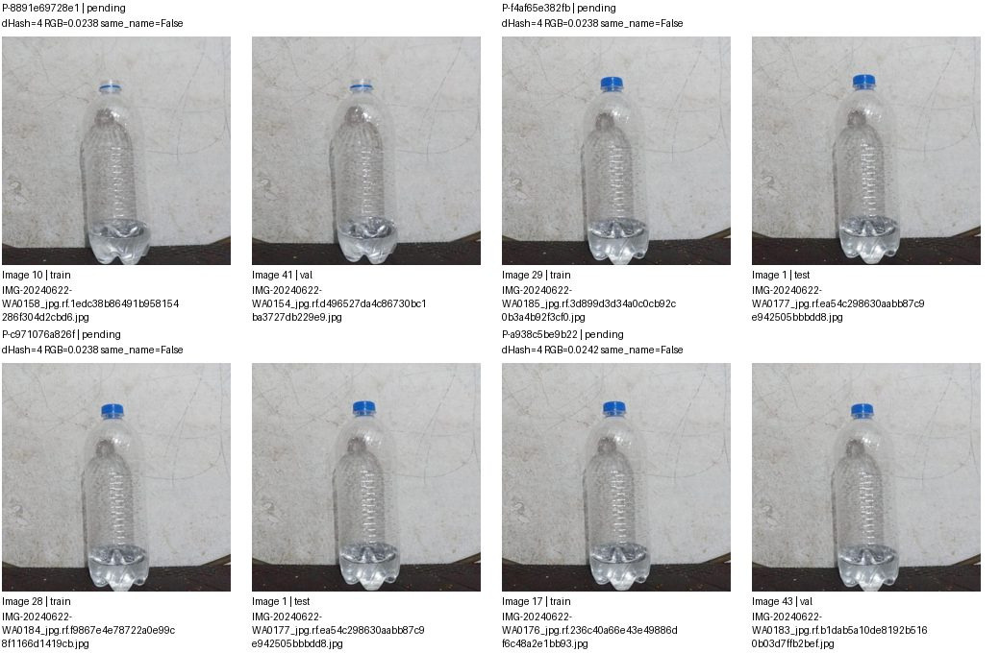

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-8891e69728e1,images/train/IMG-20240622-WA0158_jpg.rf.1edc38b86491b958154286f304d2cbd6.jpg,images/val/IMG-20240622-WA0154_jpg.rf.d496527da4c86730bc1ba3727db229e9.jpg,pending,
P-f4af65e382fb,images/train/IMG-20240622-WA0185_jpg.rf.3d899d3d34a0c0cb92c0b3a4b92f3cf0.jpg,images/test/IMG-20240622-WA0177_jpg.rf.ea54c298630aabb87c9e942505bbbdd8.jpg,pending,
P-c971076a826f,images/train/IMG-20240622-WA0184_jpg.rf.f9867e4e78722a0e99c8f1166d1419cb.jpg,images/test/IMG-20240622-WA0177_jpg.rf.ea54c298630aabb87c9e942505bbbdd8.jpg,pending,
P-a938c5be9b22,images/train/IMG-20240622-WA0176_jpg.rf.236c40a66e43e49886df6c48a2e1bb93.jpg,images/val/IMG-20240622-WA0183_jpg.rf.b1dab5a10de8192b5160b03d7ffb2bef.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 94/166 G-77712b983400 | 44 ảnh, 120 cặp
Split: {'test': 1, 'train': 39, 'val': 4}
Quyết định: {'pending': 120}
Ảnh trang None/8; cặp trang 16/30. Nhóm liên thông không phải kết luận trùng.


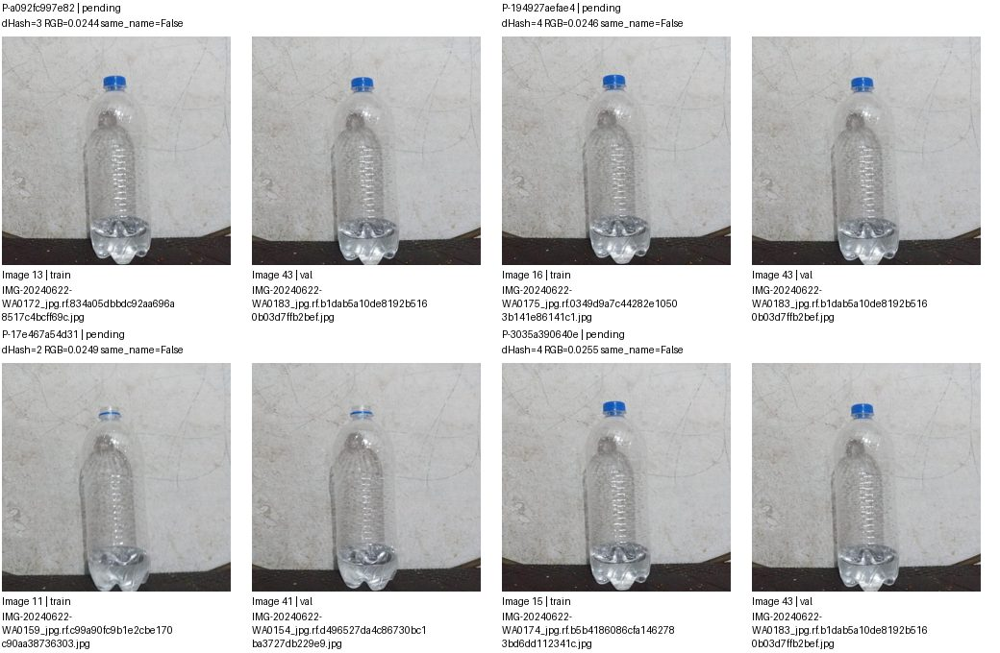

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-a092fc997e82,images/train/IMG-20240622-WA0172_jpg.rf.834a05dbbdc92aa696a8517c4bcff69c.jpg,images/val/IMG-20240622-WA0183_jpg.rf.b1dab5a10de8192b5160b03d7ffb2bef.jpg,pending,
P-194927aefae4,images/train/IMG-20240622-WA0175_jpg.rf.0349d9a7c44282e10503b141e86141c1.jpg,images/val/IMG-20240622-WA0183_jpg.rf.b1dab5a10de8192b5160b03d7ffb2bef.jpg,pending,
P-17e467a54d31,images/train/IMG-20240622-WA0159_jpg.rf.c99a90fc9b1e2cbe170c90aa38736303.jpg,images/val/IMG-20240622-WA0154_jpg.rf.d496527da4c86730bc1ba3727db229e9.jpg,pending,
P-3035a390640e,images/train/IMG-20240622-WA0174_jpg.rf.b5b4186086cfa1462783bd6dd112341c.jpg,images/val/IMG-20240622-WA0183_jpg.rf.b1dab5a10de8192b5160b03d7ffb2bef.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 94/166 G-77712b983400 | 44 ảnh, 120 cặp
Split: {'test': 1, 'train': 39, 'val': 4}
Quyết định: {'pending': 120}
Ảnh trang None/8; cặp trang 17/30. Nhóm liên thông không phải kết luận trùng.


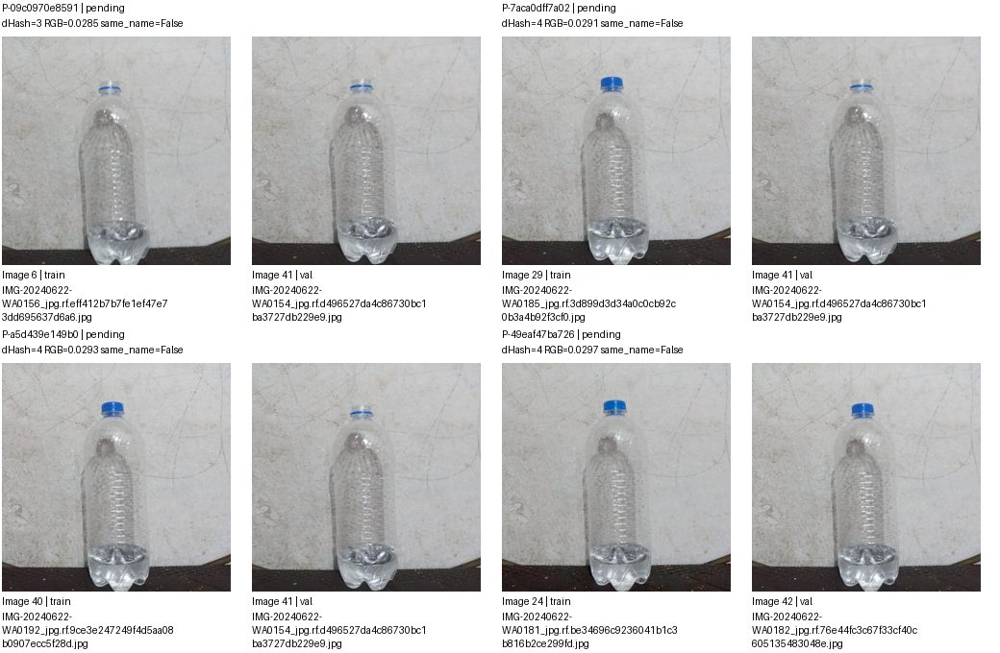

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-09c0970e8591,images/train/IMG-20240622-WA0156_jpg.rf.eff412b7b7fe1ef47e73dd695637d6a6.jpg,images/val/IMG-20240622-WA0154_jpg.rf.d496527da4c86730bc1ba3727db229e9.jpg,pending,
P-7aca0dff7a02,images/train/IMG-20240622-WA0185_jpg.rf.3d899d3d34a0c0cb92c0b3a4b92f3cf0.jpg,images/val/IMG-20240622-WA0154_jpg.rf.d496527da4c86730bc1ba3727db229e9.jpg,pending,
P-a5d439e149b0,images/train/IMG-20240622-WA0192_jpg.rf.9ce3e247249f4d5aa08b0907ecc5f28d.jpg,images/val/IMG-20240622-WA0154_jpg.rf.d496527da4c86730bc1ba3727db229e9.jpg,pending,
P-49eaf47ba726,images/train/IMG-20240622-WA0181_jpg.rf.be34696c9236041b1c3b816b2ce299fd.jpg,images/val/IMG-20240622-WA0182_jpg.rf.76e44fc3c67f33cf40c605135483048e.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 94/166 G-77712b983400 | 44 ảnh, 120 cặp
Split: {'test': 1, 'train': 39, 'val': 4}
Quyết định: {'pending': 120}
Ảnh trang None/8; cặp trang 18/30. Nhóm liên thông không phải kết luận trùng.


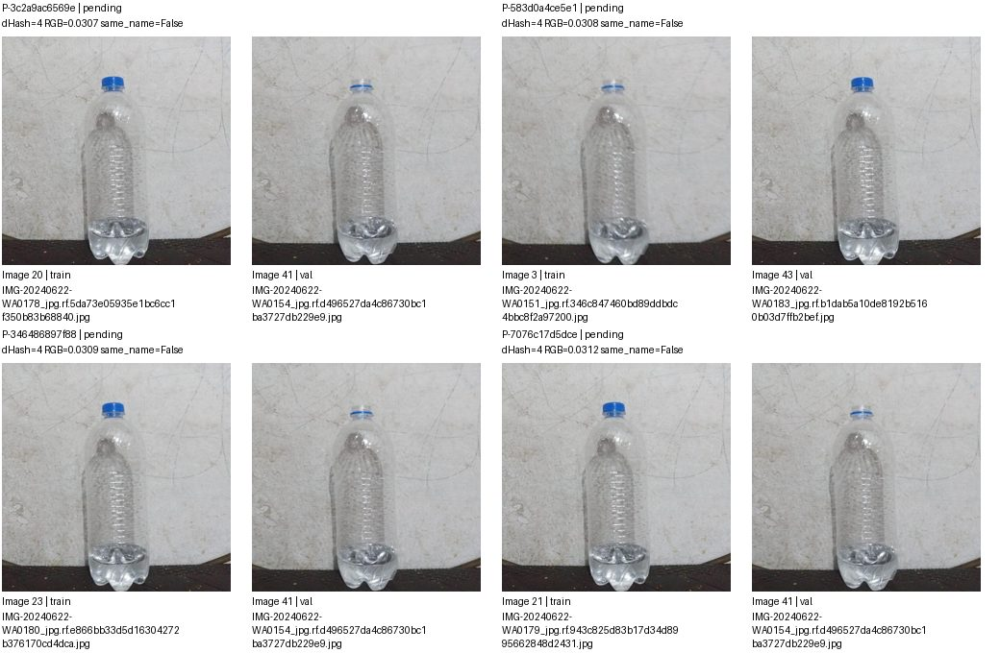

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-3c2a9ac6569e,images/train/IMG-20240622-WA0178_jpg.rf.5da73e05935e1bc6cc1f350b83b68840.jpg,images/val/IMG-20240622-WA0154_jpg.rf.d496527da4c86730bc1ba3727db229e9.jpg,pending,
P-583d0a4ce5e1,images/train/IMG-20240622-WA0151_jpg.rf.346c847460bd89ddbdc4bbc8f2a97200.jpg,images/val/IMG-20240622-WA0183_jpg.rf.b1dab5a10de8192b5160b03d7ffb2bef.jpg,pending,
P-346486897f88,images/train/IMG-20240622-WA0180_jpg.rf.e866bb33d5d16304272b376170cd4dca.jpg,images/val/IMG-20240622-WA0154_jpg.rf.d496527da4c86730bc1ba3727db229e9.jpg,pending,
P-7076c17d5dce,images/train/IMG-20240622-WA0179_jpg.rf.943c825d83b17d34d8995662848d2431.jpg,images/val/IMG-20240622-WA0154_jpg.rf.d496527da4c86730bc1ba3727db229e9.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 94/166 G-77712b983400 | 44 ảnh, 120 cặp
Split: {'test': 1, 'train': 39, 'val': 4}
Quyết định: {'pending': 120}
Ảnh trang None/8; cặp trang 19/30. Nhóm liên thông không phải kết luận trùng.


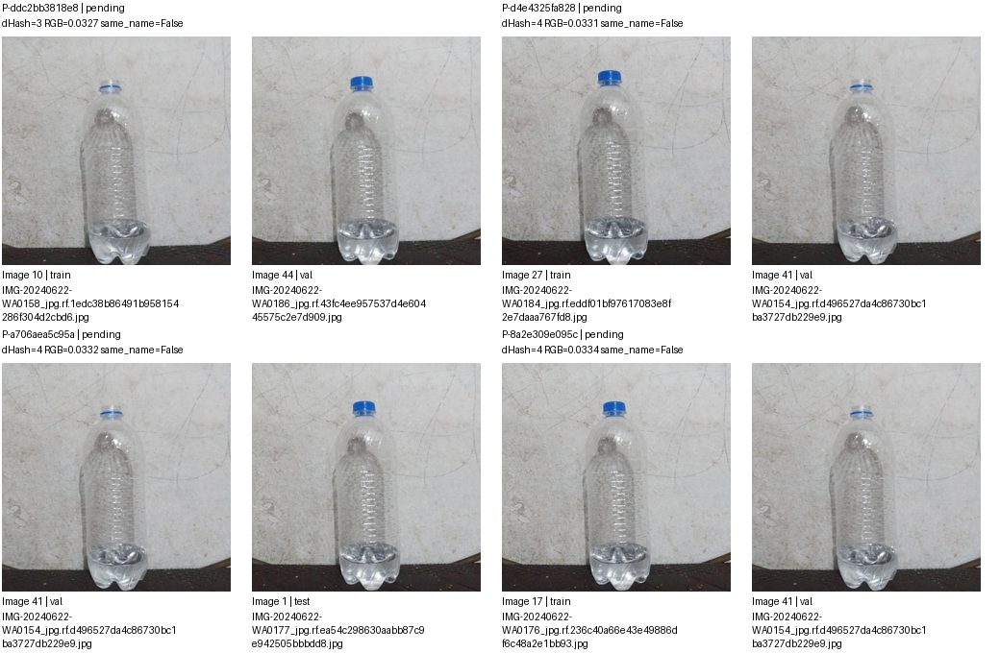

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-ddc2bb3818e8,images/train/IMG-20240622-WA0158_jpg.rf.1edc38b86491b958154286f304d2cbd6.jpg,images/val/IMG-20240622-WA0186_jpg.rf.43fc4ee957537d4e60445575c2e7d909.jpg,pending,
P-d4e4325fa828,images/train/IMG-20240622-WA0184_jpg.rf.eddf01bf97617083e8f2e7daaa767fd8.jpg,images/val/IMG-20240622-WA0154_jpg.rf.d496527da4c86730bc1ba3727db229e9.jpg,pending,
P-a706aea5c95a,images/val/IMG-20240622-WA0154_jpg.rf.d496527da4c86730bc1ba3727db229e9.jpg,images/test/IMG-20240622-WA0177_jpg.rf.ea54c298630aabb87c9e942505bbbdd8.jpg,pending,
P-8a2e309e095c,images/train/IMG-20240622-WA0176_jpg.rf.236c40a66e43e49886df6c48a2e1bb93.jpg,images/val/IMG-20240622-WA0154_jpg.rf.d496527da4c86730bc1ba3727db229e9.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 94/166 G-77712b983400 | 44 ảnh, 120 cặp
Split: {'test': 1, 'train': 39, 'val': 4}
Quyết định: {'pending': 120}
Ảnh trang None/8; cặp trang 20/30. Nhóm liên thông không phải kết luận trùng.


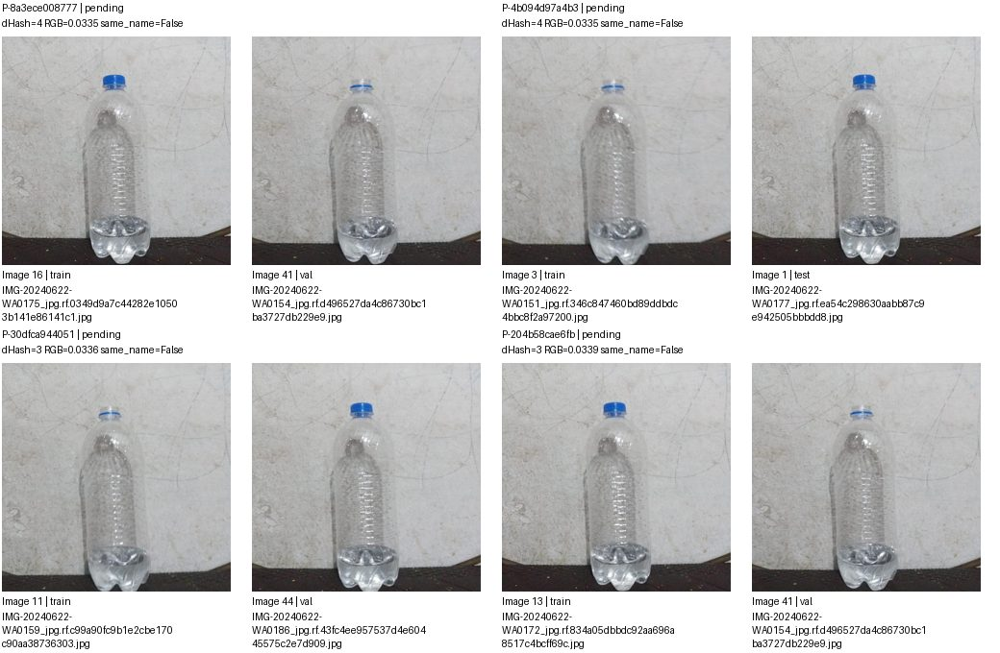

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-8a3ece008777,images/train/IMG-20240622-WA0175_jpg.rf.0349d9a7c44282e10503b141e86141c1.jpg,images/val/IMG-20240622-WA0154_jpg.rf.d496527da4c86730bc1ba3727db229e9.jpg,pending,
P-4b094d97a4b3,images/train/IMG-20240622-WA0151_jpg.rf.346c847460bd89ddbdc4bbc8f2a97200.jpg,images/test/IMG-20240622-WA0177_jpg.rf.ea54c298630aabb87c9e942505bbbdd8.jpg,pending,
P-30dfca944051,images/train/IMG-20240622-WA0159_jpg.rf.c99a90fc9b1e2cbe170c90aa38736303.jpg,images/val/IMG-20240622-WA0186_jpg.rf.43fc4ee957537d4e60445575c2e7d909.jpg,pending,
P-204b58cae6fb,images/train/IMG-20240622-WA0172_jpg.rf.834a05dbbdc92aa696a8517c4bcff69c.jpg,images/val/IMG-20240622-WA0154_jpg.rf.d496527da4c86730bc1ba3727db229e9.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 94/166 G-77712b983400 | 44 ảnh, 120 cặp
Split: {'test': 1, 'train': 39, 'val': 4}
Quyết định: {'pending': 120}
Ảnh trang None/8; cặp trang 21/30. Nhóm liên thông không phải kết luận trùng.


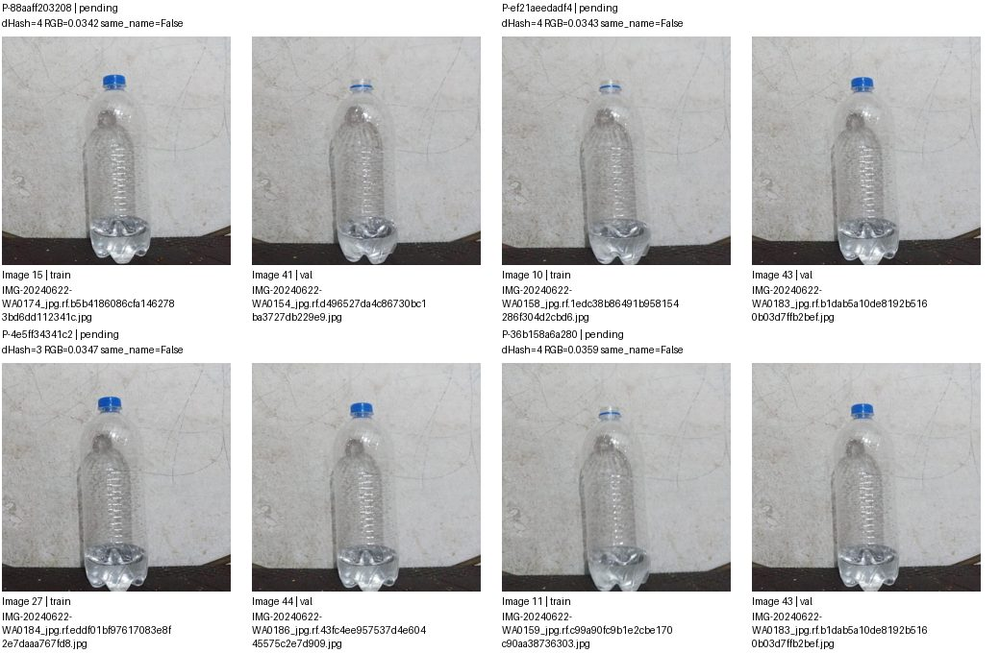

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-88aaff203208,images/train/IMG-20240622-WA0174_jpg.rf.b5b4186086cfa1462783bd6dd112341c.jpg,images/val/IMG-20240622-WA0154_jpg.rf.d496527da4c86730bc1ba3727db229e9.jpg,pending,
P-ef21aeedadf4,images/train/IMG-20240622-WA0158_jpg.rf.1edc38b86491b958154286f304d2cbd6.jpg,images/val/IMG-20240622-WA0183_jpg.rf.b1dab5a10de8192b5160b03d7ffb2bef.jpg,pending,
P-4e5ff34341c2,images/train/IMG-20240622-WA0184_jpg.rf.eddf01bf97617083e8f2e7daaa767fd8.jpg,images/val/IMG-20240622-WA0186_jpg.rf.43fc4ee957537d4e60445575c2e7d909.jpg,pending,
P-36b158a6a280,images/train/IMG-20240622-WA0159_jpg.rf.c99a90fc9b1e2cbe170c90aa38736303.jpg,images/val/IMG-20240622-WA0183_jpg.rf.b1dab5a10de8192b5160b03d7ffb2bef.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 94/166 G-77712b983400 | 44 ảnh, 120 cặp
Split: {'test': 1, 'train': 39, 'val': 4}
Quyết định: {'pending': 120}
Ảnh trang None/8; cặp trang 22/30. Nhóm liên thông không phải kết luận trùng.


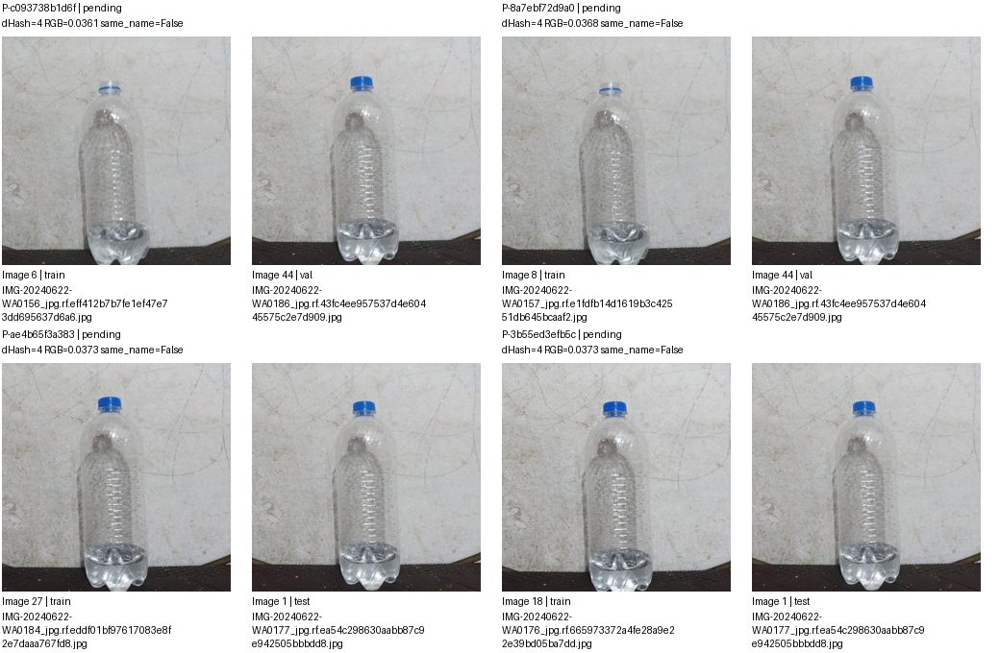

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-c093738b1d6f,images/train/IMG-20240622-WA0156_jpg.rf.eff412b7b7fe1ef47e73dd695637d6a6.jpg,images/val/IMG-20240622-WA0186_jpg.rf.43fc4ee957537d4e60445575c2e7d909.jpg,pending,
P-8a7ebf72d9a0,images/train/IMG-20240622-WA0157_jpg.rf.e1fdfb14d1619b3c42551db645bcaaf2.jpg,images/val/IMG-20240622-WA0186_jpg.rf.43fc4ee957537d4e60445575c2e7d909.jpg,pending,
P-ae4b65f3a383,images/train/IMG-20240622-WA0184_jpg.rf.eddf01bf97617083e8f2e7daaa767fd8.jpg,images/test/IMG-20240622-WA0177_jpg.rf.ea54c298630aabb87c9e942505bbbdd8.jpg,pending,
P-3b55ed3efb5c,images/train/IMG-20240622-WA0176_jpg.rf.665973372a4fe28a9e22e39bd05ba7dd.jpg,images/test/IMG-20240622-WA0177_jpg.rf.ea54c298630aabb87c9e942505bbbdd8.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 94/166 G-77712b983400 | 44 ảnh, 120 cặp
Split: {'test': 1, 'train': 39, 'val': 4}
Quyết định: {'pending': 120}
Ảnh trang None/8; cặp trang 23/30. Nhóm liên thông không phải kết luận trùng.


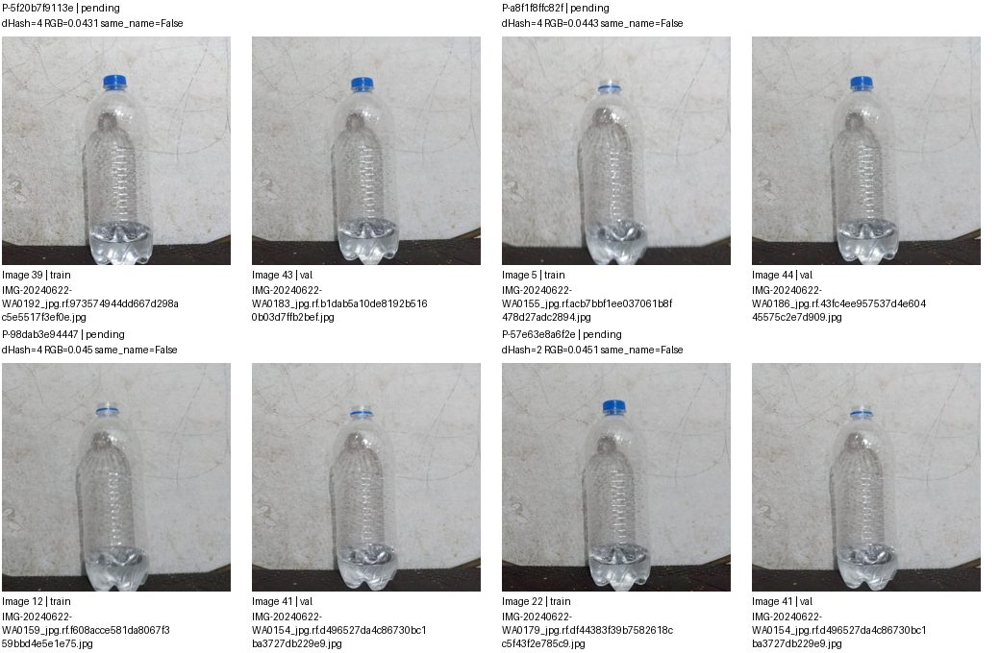

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-5f20b7f9113e,images/train/IMG-20240622-WA0192_jpg.rf.973574944dd667d298ac5e5517f3ef0e.jpg,images/val/IMG-20240622-WA0183_jpg.rf.b1dab5a10de8192b5160b03d7ffb2bef.jpg,pending,
P-a8f1f8ffc82f,images/train/IMG-20240622-WA0155_jpg.rf.acb7bbf1ee037061b8f478d27adc2894.jpg,images/val/IMG-20240622-WA0186_jpg.rf.43fc4ee957537d4e60445575c2e7d909.jpg,pending,
P-98dab3e94447,images/train/IMG-20240622-WA0159_jpg.rf.f608acce581da8067f359bbd4e5e1e75.jpg,images/val/IMG-20240622-WA0154_jpg.rf.d496527da4c86730bc1ba3727db229e9.jpg,pending,
P-57e63e8a6f2e,images/train/IMG-20240622-WA0179_jpg.rf.df44383f39b7582618cc5f43f2e785c9.jpg,images/val/IMG-20240622-WA0154_jpg.rf.d496527da4c86730bc1ba3727db229e9.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 94/166 G-77712b983400 | 44 ảnh, 120 cặp
Split: {'test': 1, 'train': 39, 'val': 4}
Quyết định: {'pending': 120}
Ảnh trang None/8; cặp trang 24/30. Nhóm liên thông không phải kết luận trùng.


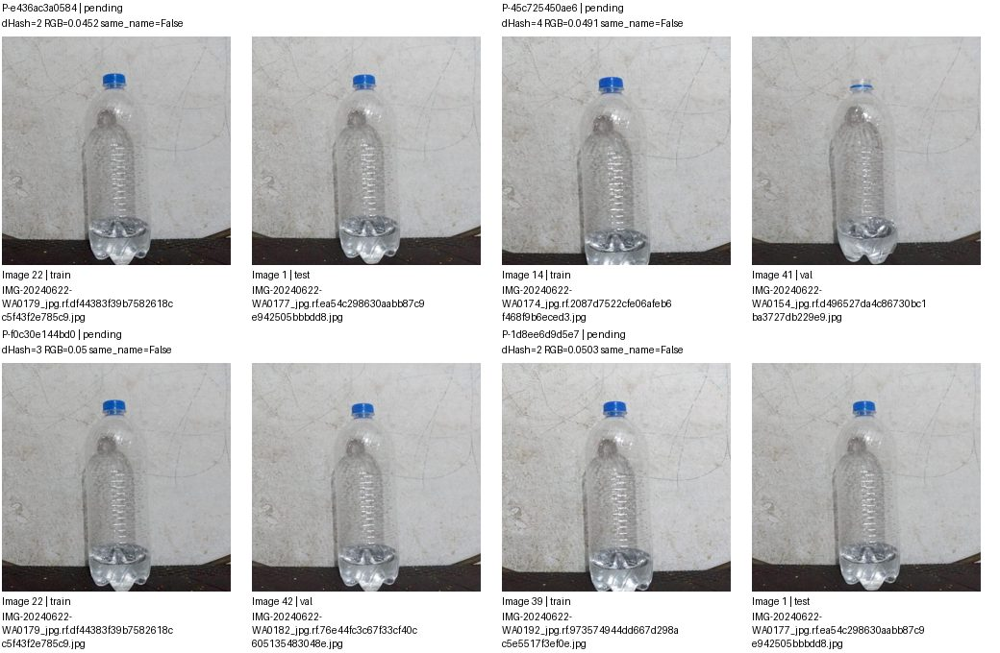

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-e436ac3a0584,images/train/IMG-20240622-WA0179_jpg.rf.df44383f39b7582618cc5f43f2e785c9.jpg,images/test/IMG-20240622-WA0177_jpg.rf.ea54c298630aabb87c9e942505bbbdd8.jpg,pending,
P-45c725450ae6,images/train/IMG-20240622-WA0174_jpg.rf.2087d7522cfe06afeb6f468f9b6eced3.jpg,images/val/IMG-20240622-WA0154_jpg.rf.d496527da4c86730bc1ba3727db229e9.jpg,pending,
P-f0c30e144bd0,images/train/IMG-20240622-WA0179_jpg.rf.df44383f39b7582618cc5f43f2e785c9.jpg,images/val/IMG-20240622-WA0182_jpg.rf.76e44fc3c67f33cf40c605135483048e.jpg,pending,
P-1d8ee6d9d5e7,images/train/IMG-20240622-WA0192_jpg.rf.973574944dd667d298ac5e5517f3ef0e.jpg,images/test/IMG-20240622-WA0177_jpg.rf.ea54c298630aabb87c9e942505bbbdd8.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 94/166 G-77712b983400 | 44 ảnh, 120 cặp
Split: {'test': 1, 'train': 39, 'val': 4}
Quyết định: {'pending': 120}
Ảnh trang None/8; cặp trang 25/30. Nhóm liên thông không phải kết luận trùng.


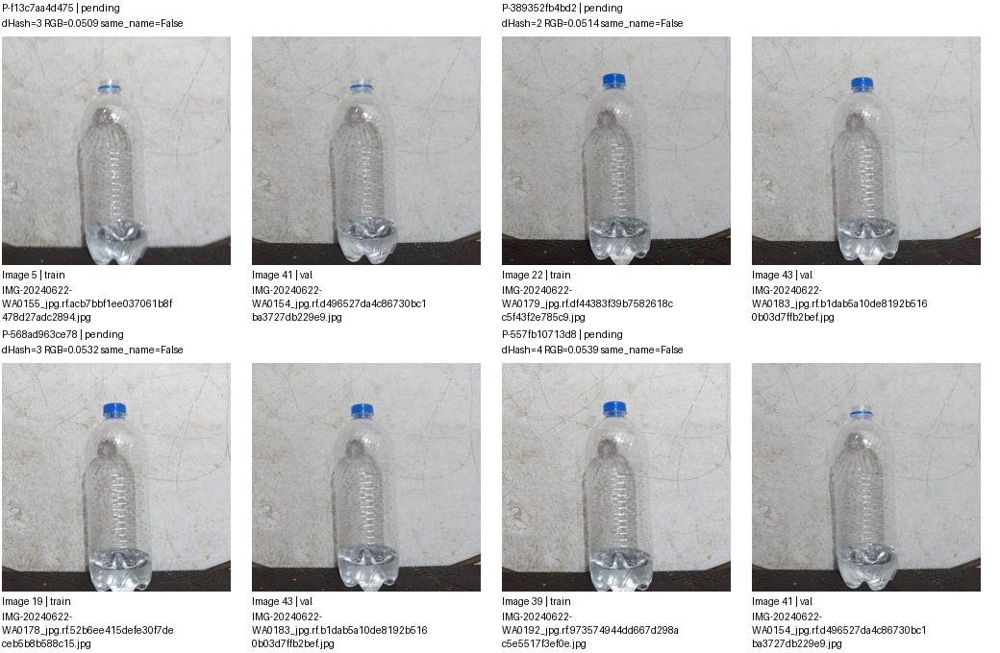

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-f13c7aa4d475,images/train/IMG-20240622-WA0155_jpg.rf.acb7bbf1ee037061b8f478d27adc2894.jpg,images/val/IMG-20240622-WA0154_jpg.rf.d496527da4c86730bc1ba3727db229e9.jpg,pending,
P-389352fb4bd2,images/train/IMG-20240622-WA0179_jpg.rf.df44383f39b7582618cc5f43f2e785c9.jpg,images/val/IMG-20240622-WA0183_jpg.rf.b1dab5a10de8192b5160b03d7ffb2bef.jpg,pending,
P-568ad963ce78,images/train/IMG-20240622-WA0178_jpg.rf.52b6ee415defe30f7deceb5b8b588c15.jpg,images/val/IMG-20240622-WA0183_jpg.rf.b1dab5a10de8192b5160b03d7ffb2bef.jpg,pending,
P-557fb10713d8,images/train/IMG-20240622-WA0192_jpg.rf.973574944dd667d298ac5e5517f3ef0e.jpg,images/val/IMG-20240622-WA0154_jpg.rf.d496527da4c86730bc1ba3727db229e9.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 94/166 G-77712b983400 | 44 ảnh, 120 cặp
Split: {'test': 1, 'train': 39, 'val': 4}
Quyết định: {'pending': 120}
Ảnh trang None/8; cặp trang 26/30. Nhóm liên thông không phải kết luận trùng.


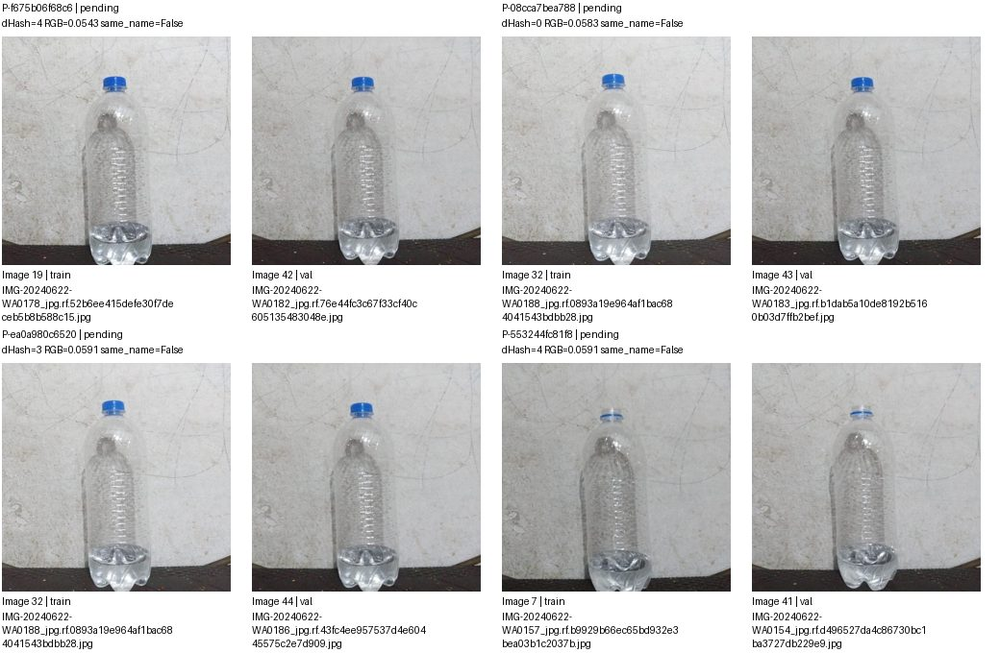

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-f675b06f68c6,images/train/IMG-20240622-WA0178_jpg.rf.52b6ee415defe30f7deceb5b8b588c15.jpg,images/val/IMG-20240622-WA0182_jpg.rf.76e44fc3c67f33cf40c605135483048e.jpg,pending,
P-08cca7bea788,images/train/IMG-20240622-WA0188_jpg.rf.0893a19e964af1bac684041543bdbb28.jpg,images/val/IMG-20240622-WA0183_jpg.rf.b1dab5a10de8192b5160b03d7ffb2bef.jpg,pending,
P-ea0a980c6520,images/train/IMG-20240622-WA0188_jpg.rf.0893a19e964af1bac684041543bdbb28.jpg,images/val/IMG-20240622-WA0186_jpg.rf.43fc4ee957537d4e60445575c2e7d909.jpg,pending,
P-553244fc81f8,images/train/IMG-20240622-WA0157_jpg.rf.b9929b66ec65bd932e3bea03b1c2037b.jpg,images/val/IMG-20240622-WA0154_jpg.rf.d496527da4c86730bc1ba3727db229e9.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 94/166 G-77712b983400 | 44 ảnh, 120 cặp
Split: {'test': 1, 'train': 39, 'val': 4}
Quyết định: {'pending': 120}
Ảnh trang None/8; cặp trang 27/30. Nhóm liên thông không phải kết luận trùng.


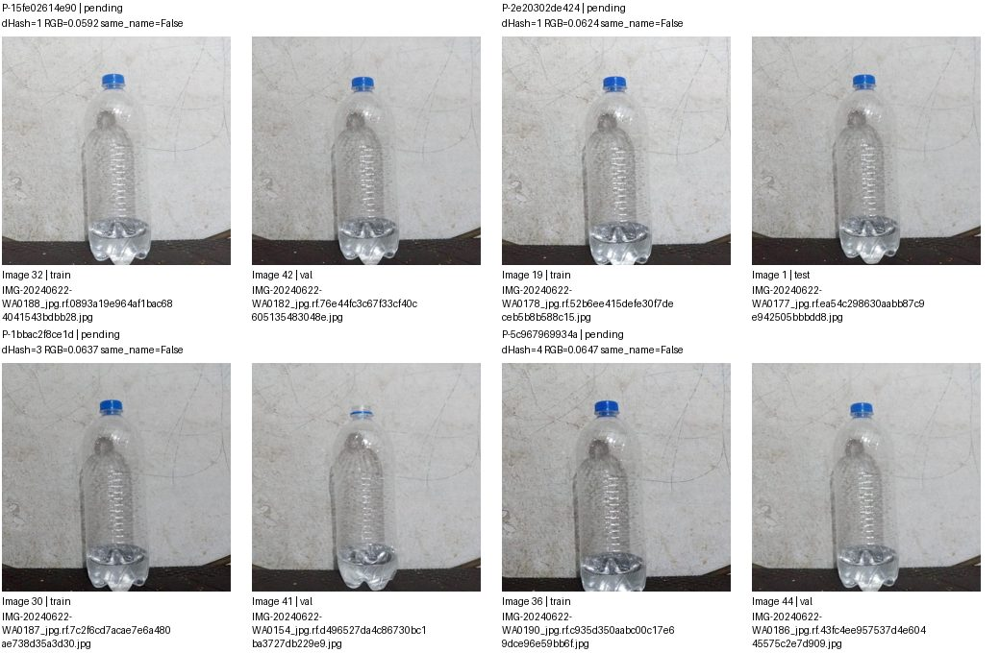

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-15fe02614e90,images/train/IMG-20240622-WA0188_jpg.rf.0893a19e964af1bac684041543bdbb28.jpg,images/val/IMG-20240622-WA0182_jpg.rf.76e44fc3c67f33cf40c605135483048e.jpg,pending,
P-2e20302de424,images/train/IMG-20240622-WA0178_jpg.rf.52b6ee415defe30f7deceb5b8b588c15.jpg,images/test/IMG-20240622-WA0177_jpg.rf.ea54c298630aabb87c9e942505bbbdd8.jpg,pending,
P-1bbac2f8ce1d,images/train/IMG-20240622-WA0187_jpg.rf.7c2f6cd7acae7e6a480ae738d35a3d30.jpg,images/val/IMG-20240622-WA0154_jpg.rf.d496527da4c86730bc1ba3727db229e9.jpg,pending,
P-5c967969934a,images/train/IMG-20240622-WA0190_jpg.rf.c935d350aabc00c17e69dce96e59bb6f.jpg,images/val/IMG-20240622-WA0186_jpg.rf.43fc4ee957537d4e60445575c2e7d909.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 94/166 G-77712b983400 | 44 ảnh, 120 cặp
Split: {'test': 1, 'train': 39, 'val': 4}
Quyết định: {'pending': 120}
Ảnh trang None/8; cặp trang 28/30. Nhóm liên thông không phải kết luận trùng.


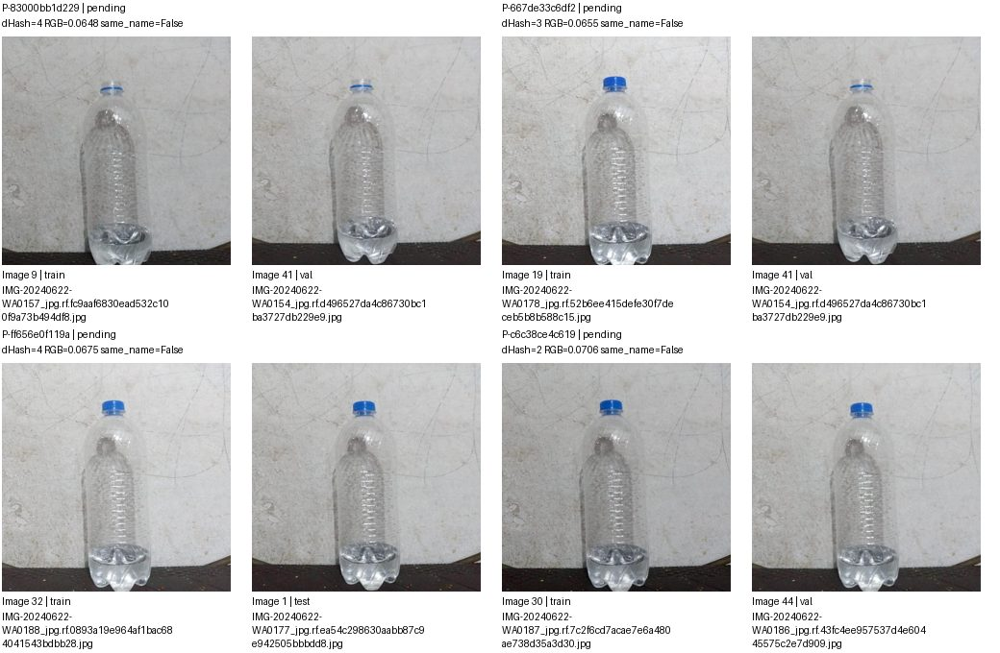

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-83000bb1d229,images/train/IMG-20240622-WA0157_jpg.rf.fc9aaf6830ead532c100f9a73b494df8.jpg,images/val/IMG-20240622-WA0154_jpg.rf.d496527da4c86730bc1ba3727db229e9.jpg,pending,
P-667de33c6df2,images/train/IMG-20240622-WA0178_jpg.rf.52b6ee415defe30f7deceb5b8b588c15.jpg,images/val/IMG-20240622-WA0154_jpg.rf.d496527da4c86730bc1ba3727db229e9.jpg,pending,
P-ff656e0f119a,images/train/IMG-20240622-WA0188_jpg.rf.0893a19e964af1bac684041543bdbb28.jpg,images/test/IMG-20240622-WA0177_jpg.rf.ea54c298630aabb87c9e942505bbbdd8.jpg,pending,
P-c6c38ce4c619,images/train/IMG-20240622-WA0187_jpg.rf.7c2f6cd7acae7e6a480ae738d35a3d30.jpg,images/val/IMG-20240622-WA0186_jpg.rf.43fc4ee957537d4e60445575c2e7d909.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 94/166 G-77712b983400 | 44 ảnh, 120 cặp
Split: {'test': 1, 'train': 39, 'val': 4}
Quyết định: {'pending': 120}
Ảnh trang None/8; cặp trang 29/30. Nhóm liên thông không phải kết luận trùng.


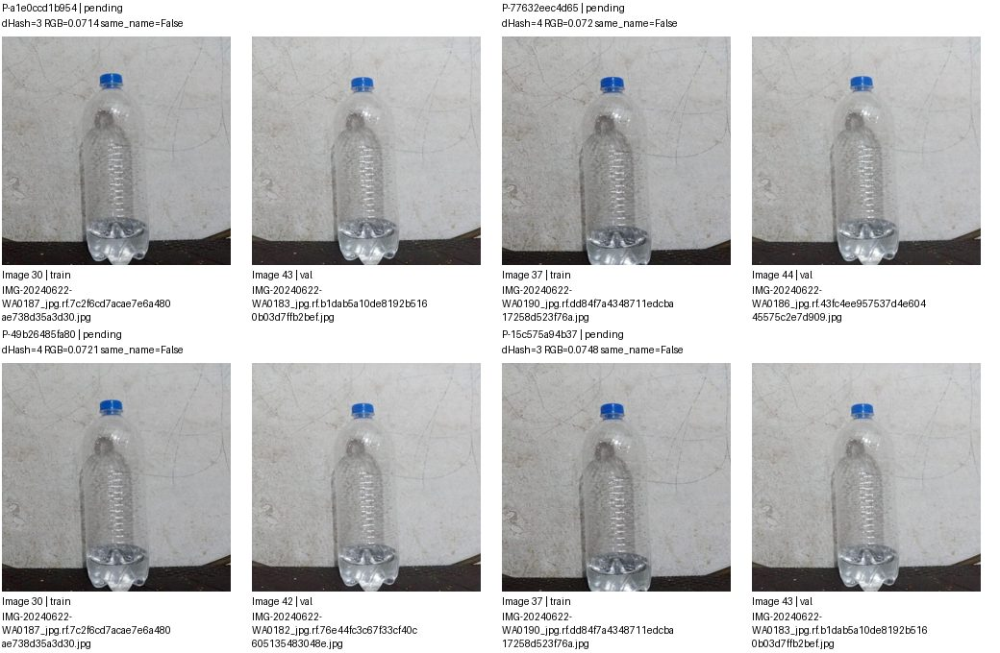

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-a1e0ccd1b954,images/train/IMG-20240622-WA0187_jpg.rf.7c2f6cd7acae7e6a480ae738d35a3d30.jpg,images/val/IMG-20240622-WA0183_jpg.rf.b1dab5a10de8192b5160b03d7ffb2bef.jpg,pending,
P-77632eec4d65,images/train/IMG-20240622-WA0190_jpg.rf.dd84f7a4348711edcba17258d523f76a.jpg,images/val/IMG-20240622-WA0186_jpg.rf.43fc4ee957537d4e60445575c2e7d909.jpg,pending,
P-49b26485fa80,images/train/IMG-20240622-WA0187_jpg.rf.7c2f6cd7acae7e6a480ae738d35a3d30.jpg,images/val/IMG-20240622-WA0182_jpg.rf.76e44fc3c67f33cf40c605135483048e.jpg,pending,
P-15c575a94b37,images/train/IMG-20240622-WA0190_jpg.rf.dd84f7a4348711edcba17258d523f76a.jpg,images/val/IMG-20240622-WA0183_jpg.rf.b1dab5a10de8192b5160b03d7ffb2bef.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 94/166 G-77712b983400 | 44 ảnh, 120 cặp
Split: {'test': 1, 'train': 39, 'val': 4}
Quyết định: {'pending': 120}
Ảnh trang None/8; cặp trang 30/30. Nhóm liên thông không phải kết luận trùng.


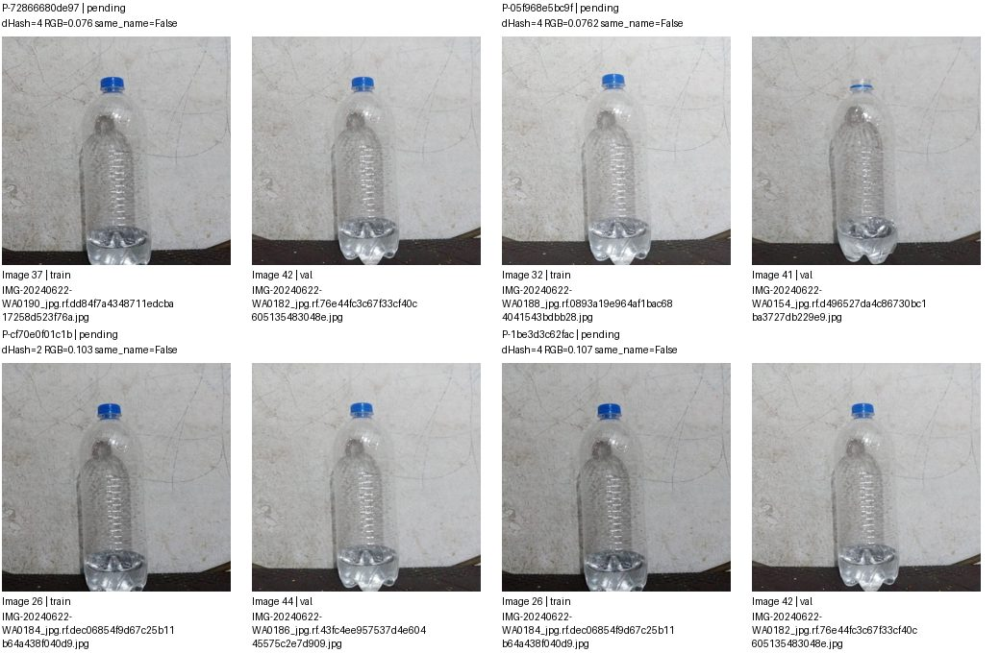

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-72866680de97,images/train/IMG-20240622-WA0190_jpg.rf.dd84f7a4348711edcba17258d523f76a.jpg,images/val/IMG-20240622-WA0182_jpg.rf.76e44fc3c67f33cf40c605135483048e.jpg,pending,
P-05f968e5bc9f,images/train/IMG-20240622-WA0188_jpg.rf.0893a19e964af1bac684041543bdbb28.jpg,images/val/IMG-20240622-WA0154_jpg.rf.d496527da4c86730bc1ba3727db229e9.jpg,pending,
P-cf70e0f01c1b,images/train/IMG-20240622-WA0184_jpg.rf.dec06854f9d67c25b11b64a438f040d9.jpg,images/val/IMG-20240622-WA0186_jpg.rf.43fc4ee957537d4e60445575c2e7d909.jpg,pending,
P-1be3d3c62fac,images/train/IMG-20240622-WA0184_jpg.rf.dec06854f9d67c25b11b64a438f040d9.jpg,images/val/IMG-20240622-WA0182_jpg.rf.76e44fc3c67f33cf40c605135483048e.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 95/166 G-5c813f24f3db | 12 ảnh, 11 cặp
Split: {'train': 11, 'val': 1}
Quyết định: {'pending': 11}
Ảnh trang 1/2; cặp trang 1/3. Nhóm liên thông không phải kết luận trùng.


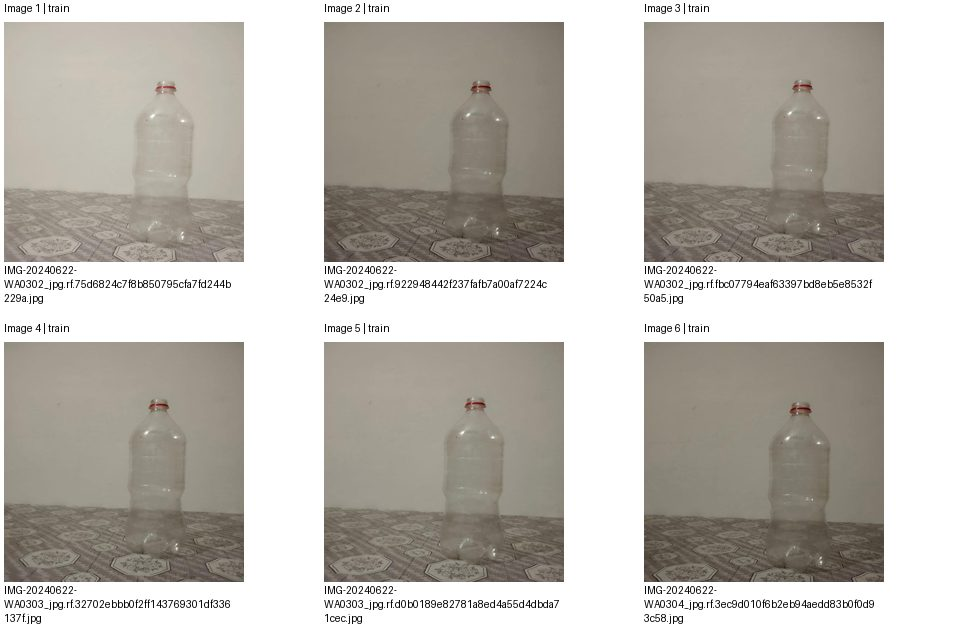

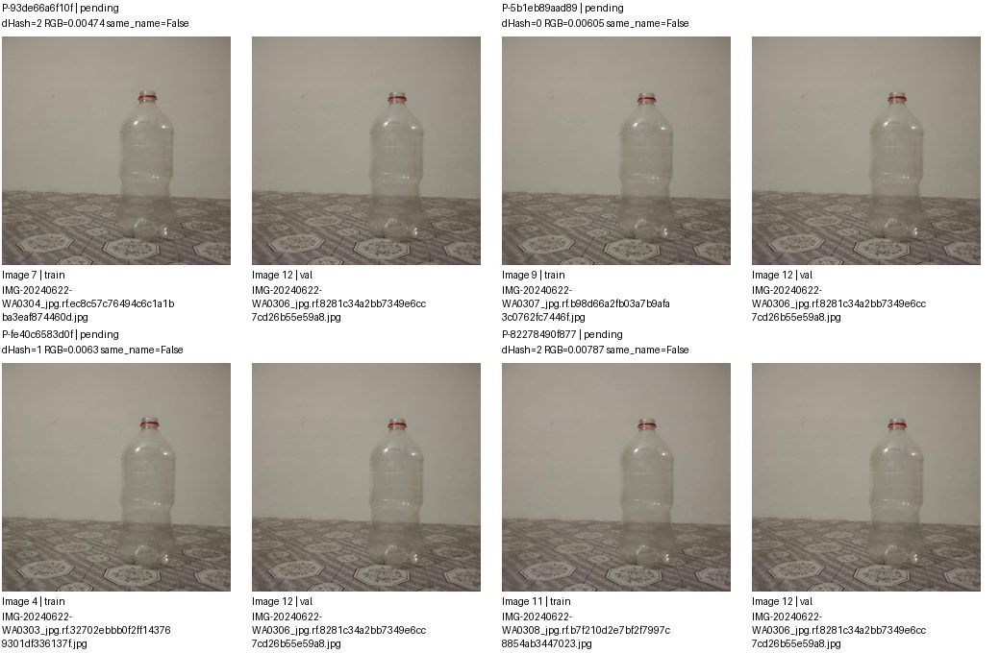

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-93de66a6f10f,images/train/IMG-20240622-WA0304_jpg.rf.ec8c57c76494c6c1a1bba3eaf874460d.jpg,images/val/IMG-20240622-WA0306_jpg.rf.8281c34a2bb7349e6cc7cd26b55e59a8.jpg,pending,
P-5b1eb89aad89,images/train/IMG-20240622-WA0307_jpg.rf.b98d66a2fb03a7b9afa3c0762fc7446f.jpg,images/val/IMG-20240622-WA0306_jpg.rf.8281c34a2bb7349e6cc7cd26b55e59a8.jpg,pending,
P-fe40c6583d0f,images/train/IMG-20240622-WA0303_jpg.rf.32702ebbb0f2ff143769301df336137f.jpg,images/val/IMG-20240622-WA0306_jpg.rf.8281c34a2bb7349e6cc7cd26b55e59a8.jpg,pending,
P-82278490f877,images/train/IMG-20240622-WA0308_jpg.rf.b7f210d2e7bf2f7997c8854ab3447023.jpg,images/val/IMG-20240622-WA0306_jpg.rf.8281c34a2bb7349e6cc7cd26b55e59a8.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 95/166 G-5c813f24f3db | 12 ảnh, 11 cặp
Split: {'train': 11, 'val': 1}
Quyết định: {'pending': 11}
Ảnh trang 2/2; cặp trang 2/3. Nhóm liên thông không phải kết luận trùng.


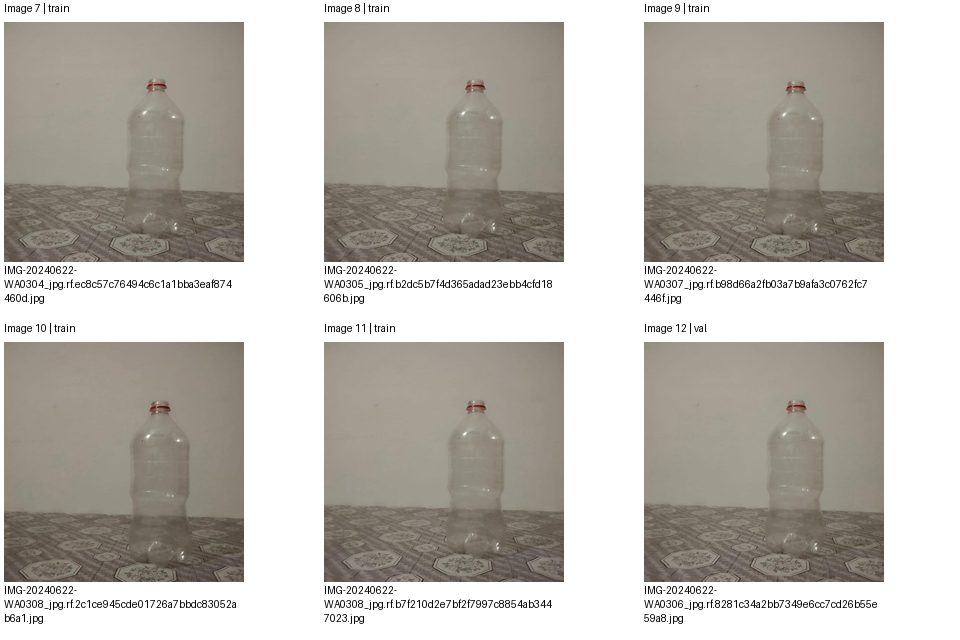

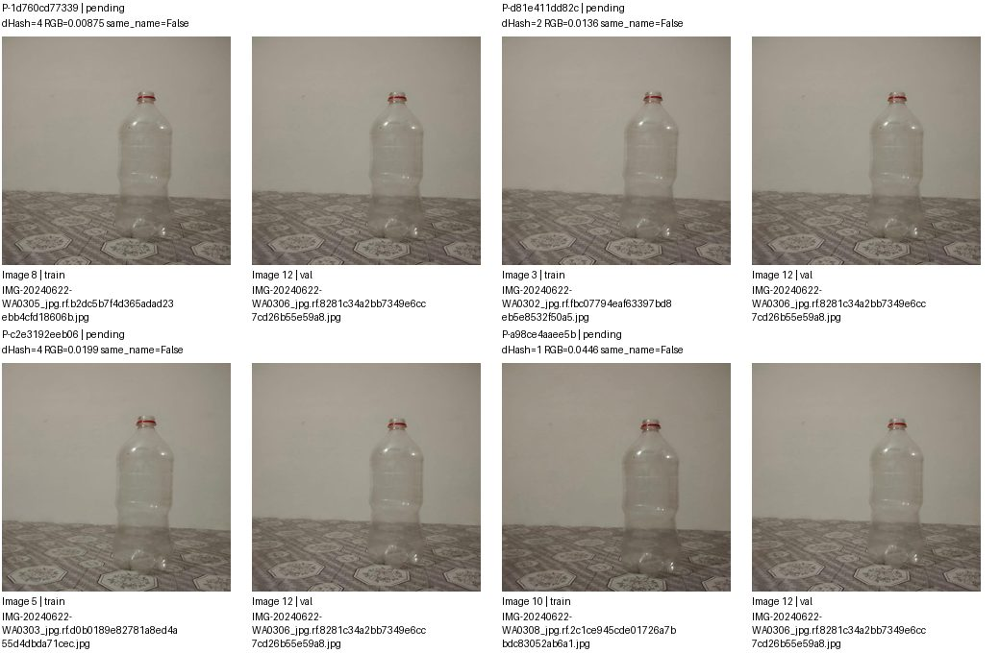

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-1d760cd77339,images/train/IMG-20240622-WA0305_jpg.rf.b2dc5b7f4d365adad23ebb4cfd18606b.jpg,images/val/IMG-20240622-WA0306_jpg.rf.8281c34a2bb7349e6cc7cd26b55e59a8.jpg,pending,
P-d81e411dd82c,images/train/IMG-20240622-WA0302_jpg.rf.fbc07794eaf63397bd8eb5e8532f50a5.jpg,images/val/IMG-20240622-WA0306_jpg.rf.8281c34a2bb7349e6cc7cd26b55e59a8.jpg,pending,
P-c2e3192eeb06,images/train/IMG-20240622-WA0303_jpg.rf.d0b0189e82781a8ed4a55d4dbda71cec.jpg,images/val/IMG-20240622-WA0306_jpg.rf.8281c34a2bb7349e6cc7cd26b55e59a8.jpg,pending,
P-a98ce4aaee5b,images/train/IMG-20240622-WA0308_jpg.rf.2c1ce945cde01726a7bbdc83052ab6a1.jpg,images/val/IMG-20240622-WA0306_jpg.rf.8281c34a2bb7349e6cc7cd26b55e59a8.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 95/166 G-5c813f24f3db | 12 ảnh, 11 cặp
Split: {'train': 11, 'val': 1}
Quyết định: {'pending': 11}
Ảnh trang None/2; cặp trang 3/3. Nhóm liên thông không phải kết luận trùng.


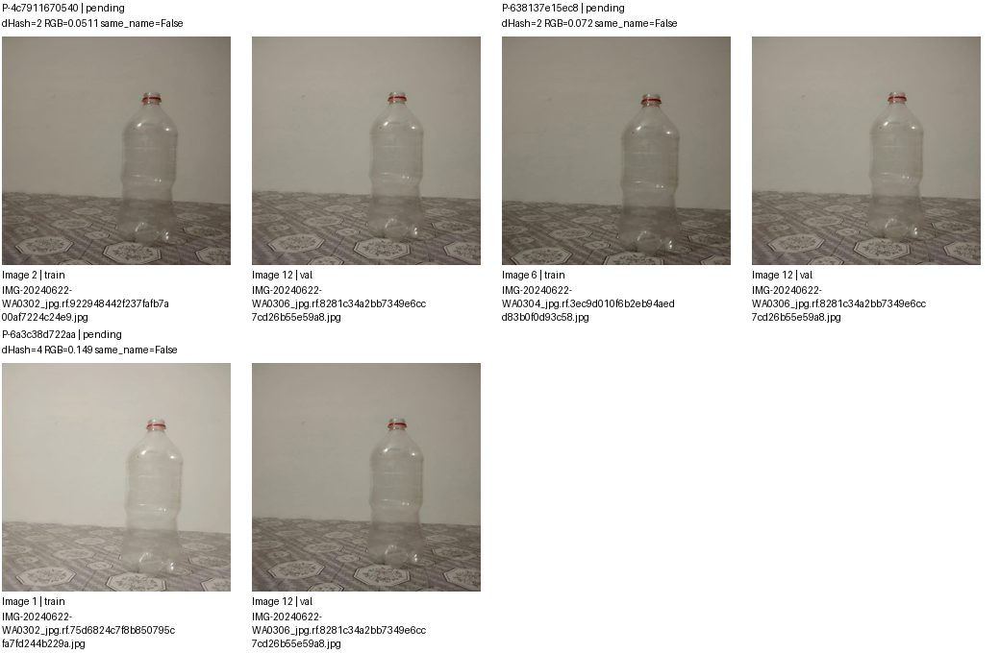

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-4c7911670540,images/train/IMG-20240622-WA0302_jpg.rf.922948442f237fafb7a00af7224c24e9.jpg,images/val/IMG-20240622-WA0306_jpg.rf.8281c34a2bb7349e6cc7cd26b55e59a8.jpg,pending,
P-638137e15ec8,images/train/IMG-20240622-WA0304_jpg.rf.3ec9d010f6b2eb94aedd83b0f0d93c58.jpg,images/val/IMG-20240622-WA0306_jpg.rf.8281c34a2bb7349e6cc7cd26b55e59a8.jpg,pending,
P-6a3c38d722aa,images/train/IMG-20240622-WA0302_jpg.rf.75d6824c7f8b850795cfa7fd244b229a.jpg,images/val/IMG-20240622-WA0306_jpg.rf.8281c34a2bb7349e6cc7cd26b55e59a8.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 96/166 G-19da0440f68e | 6 ảnh, 5 cặp
Split: {'test': 1, 'train': 5}
Quyết định: {'pending': 5}
Ảnh trang 1/1; cặp trang 1/2. Nhóm liên thông không phải kết luận trùng.


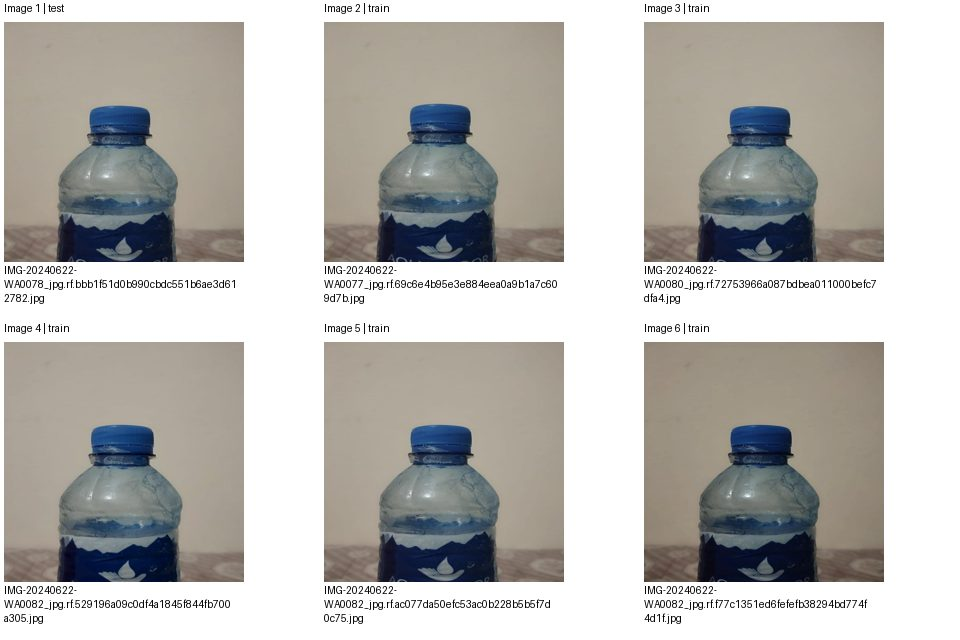

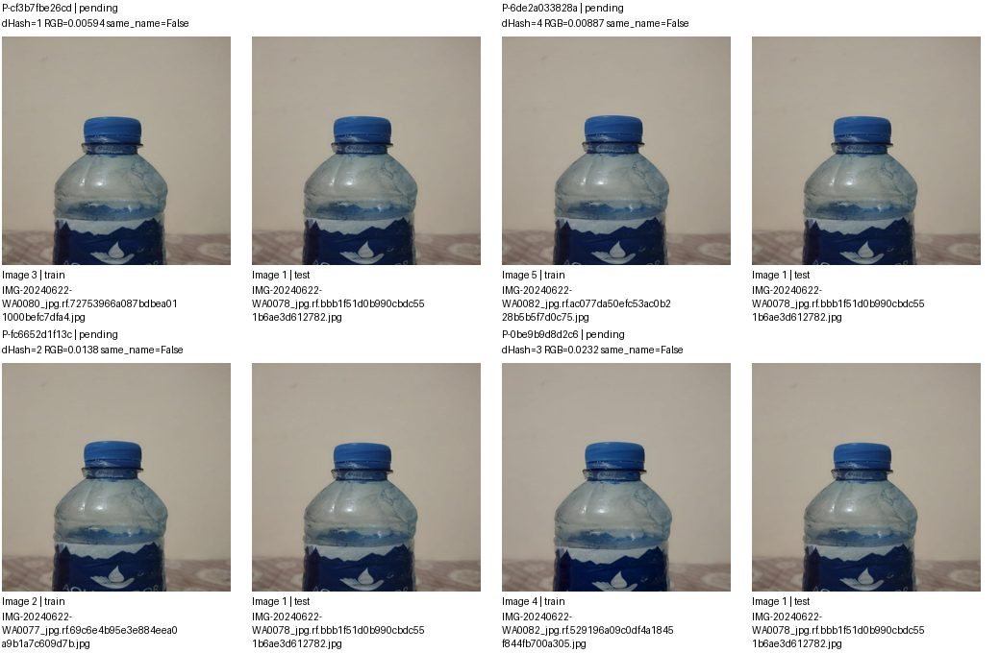

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-cf3b7fbe26cd,images/train/IMG-20240622-WA0080_jpg.rf.72753966a087bdbea011000befc7dfa4.jpg,images/test/IMG-20240622-WA0078_jpg.rf.bbb1f51d0b990cbdc551b6ae3d612782.jpg,pending,
P-6de2a033828a,images/train/IMG-20240622-WA0082_jpg.rf.ac077da50efc53ac0b228b5b5f7d0c75.jpg,images/test/IMG-20240622-WA0078_jpg.rf.bbb1f51d0b990cbdc551b6ae3d612782.jpg,pending,
P-fc6652d1f13c,images/train/IMG-20240622-WA0077_jpg.rf.69c6e4b95e3e884eea0a9b1a7c609d7b.jpg,images/test/IMG-20240622-WA0078_jpg.rf.bbb1f51d0b990cbdc551b6ae3d612782.jpg,pending,
P-0be9b9d8d2c6,images/train/IMG-20240622-WA0082_jpg.rf.529196a09c0df4a1845f844fb700a305.jpg,images/test/IMG-20240622-WA0078_jpg.rf.bbb1f51d0b990cbdc551b6ae3d612782.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 96/166 G-19da0440f68e | 6 ảnh, 5 cặp
Split: {'test': 1, 'train': 5}
Quyết định: {'pending': 5}
Ảnh trang None/1; cặp trang 2/2. Nhóm liên thông không phải kết luận trùng.


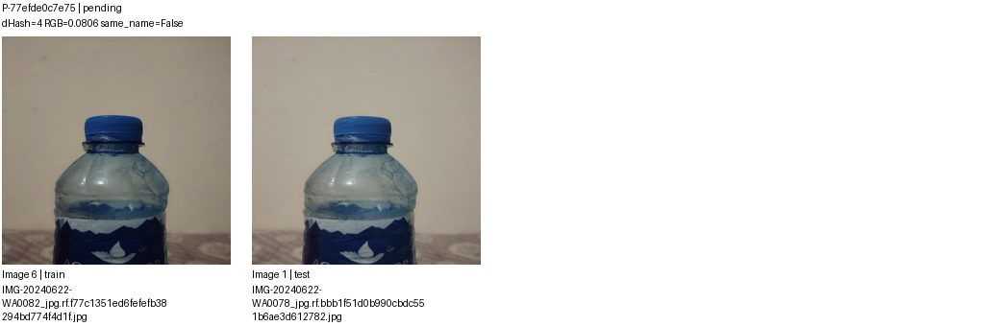

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-77efde0c7e75,images/train/IMG-20240622-WA0082_jpg.rf.f77c1351ed6fefefb38294bd774f4d1f.jpg,images/test/IMG-20240622-WA0078_jpg.rf.bbb1f51d0b990cbdc551b6ae3d612782.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 97/166 G-614f04b2a5ba | 2 ảnh, 1 cặp
Split: {'train': 1, 'val': 1}
Quyết định: {'pending': 1}
Ảnh trang 1/1; cặp trang 1/1. Nhóm liên thông không phải kết luận trùng.


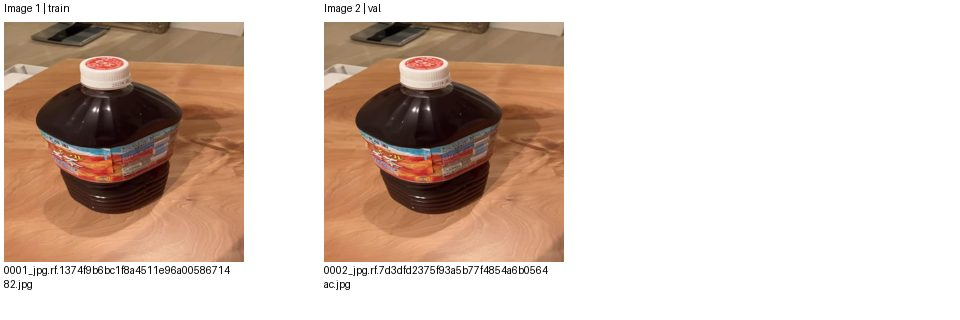

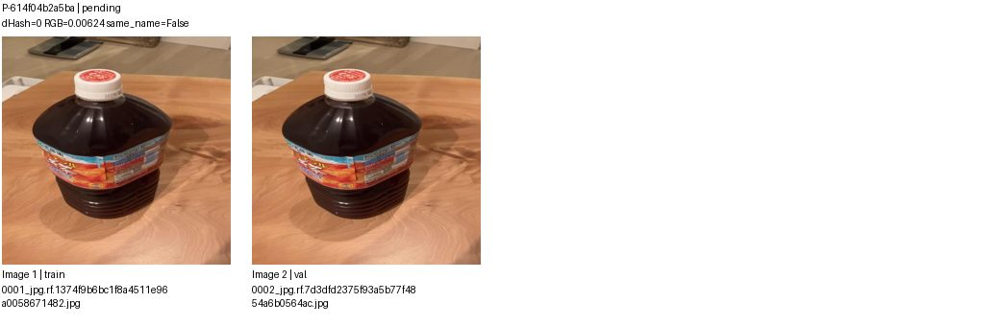

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-614f04b2a5ba,images/train/0001_jpg.rf.1374f9b6bc1f8a4511e96a0058671482.jpg,images/val/0002_jpg.rf.7d3dfd2375f93a5b77f4854a6b0564ac.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 98/166 G-110947dfa5ab | 18 ảnh, 59 cặp
Split: {'test': 1, 'train': 14, 'val': 3}
Quyết định: {'pending': 59}
Ảnh trang 1/3; cặp trang 1/15. Nhóm liên thông không phải kết luận trùng.


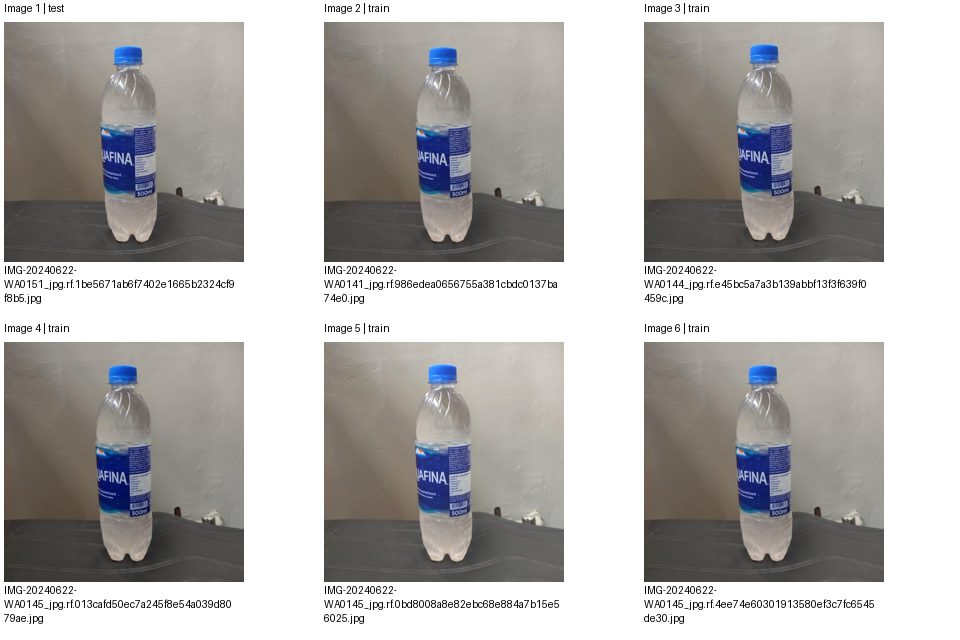

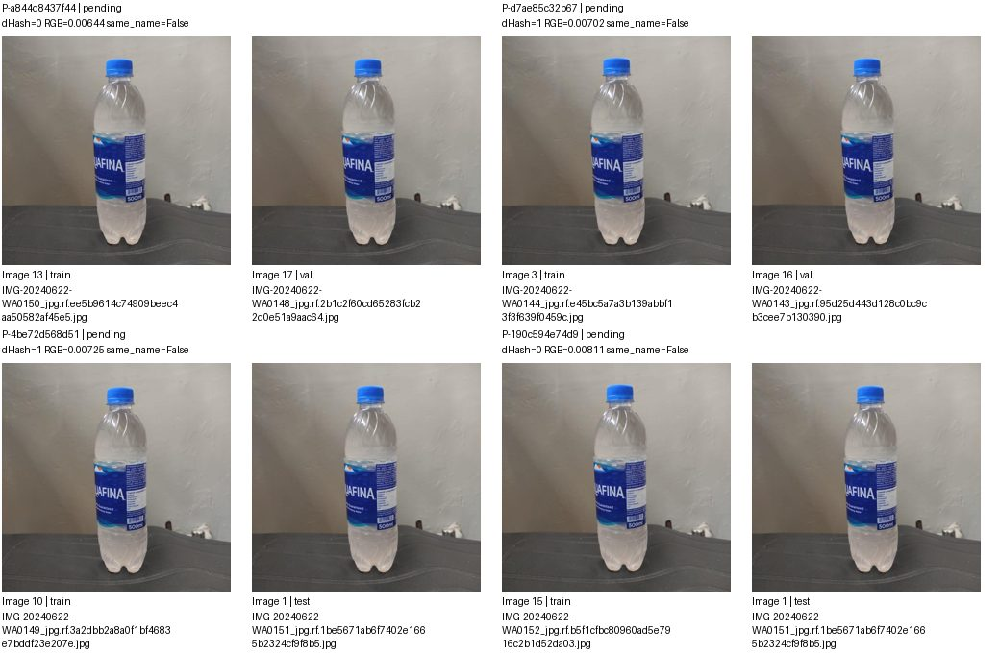

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-a844d8437f44,images/train/IMG-20240622-WA0150_jpg.rf.ee5b9614c74909beec4aa50582af45e5.jpg,images/val/IMG-20240622-WA0148_jpg.rf.2b1c2f60cd65283fcb22d0e51a9aac64.jpg,pending,
P-d7ae85c32b67,images/train/IMG-20240622-WA0144_jpg.rf.e45bc5a7a3b139abbf13f3f639f0459c.jpg,images/val/IMG-20240622-WA0143_jpg.rf.95d25d443d128c0bc9cb3cee7b130390.jpg,pending,
P-4be72d568d51,images/train/IMG-20240622-WA0149_jpg.rf.3a2dbb2a8a0f1bf4683e7bddf23e207e.jpg,images/test/IMG-20240622-WA0151_jpg.rf.1be5671ab6f7402e1665b2324cf9f8b5.jpg,pending,
P-190c594e74d9,images/train/IMG-20240622-WA0152_jpg.rf.b5f1cfbc80960ad5e7916c2b1d52da03.jpg,images/test/IMG-20240622-WA0151_jpg.rf.1be5671ab6f7402e1665b2324cf9f8b5.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 98/166 G-110947dfa5ab | 18 ảnh, 59 cặp
Split: {'test': 1, 'train': 14, 'val': 3}
Quyết định: {'pending': 59}
Ảnh trang 2/3; cặp trang 2/15. Nhóm liên thông không phải kết luận trùng.


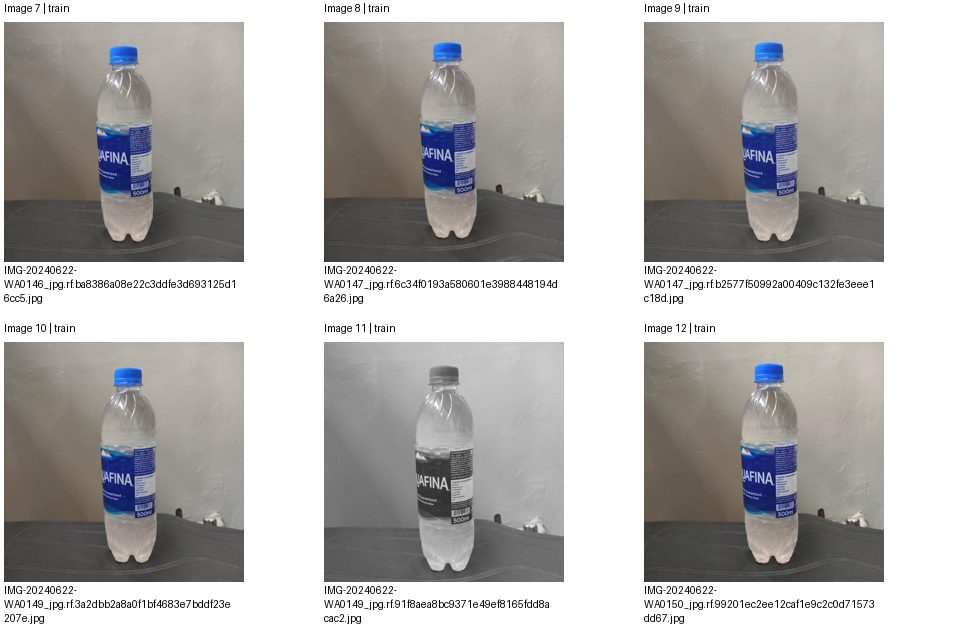

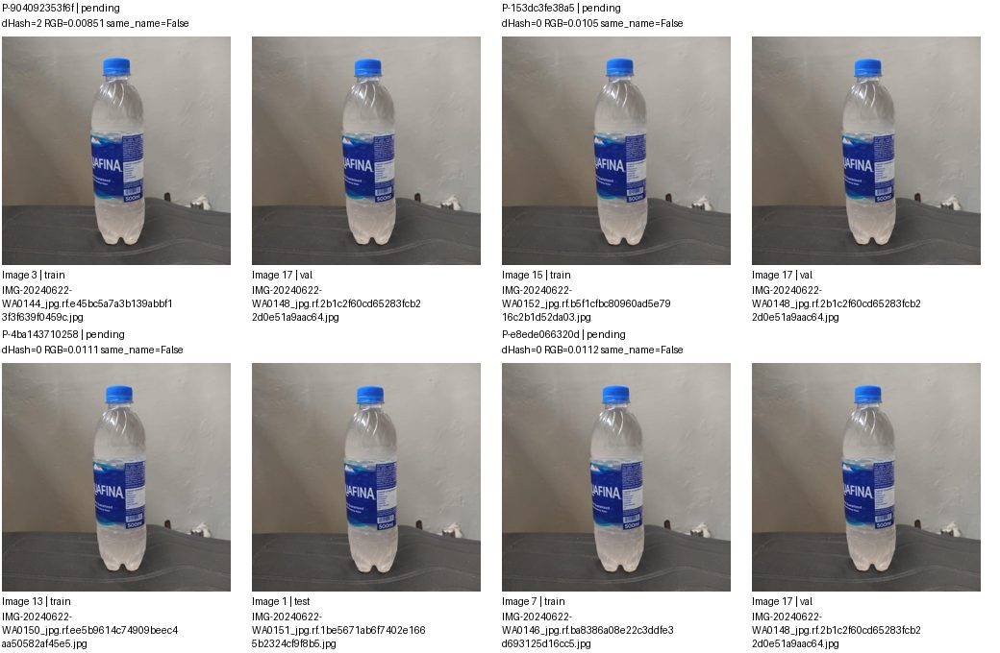

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-904092353f6f,images/train/IMG-20240622-WA0144_jpg.rf.e45bc5a7a3b139abbf13f3f639f0459c.jpg,images/val/IMG-20240622-WA0148_jpg.rf.2b1c2f60cd65283fcb22d0e51a9aac64.jpg,pending,
P-153dc3fe38a5,images/train/IMG-20240622-WA0152_jpg.rf.b5f1cfbc80960ad5e7916c2b1d52da03.jpg,images/val/IMG-20240622-WA0148_jpg.rf.2b1c2f60cd65283fcb22d0e51a9aac64.jpg,pending,
P-4ba143710258,images/train/IMG-20240622-WA0150_jpg.rf.ee5b9614c74909beec4aa50582af45e5.jpg,images/test/IMG-20240622-WA0151_jpg.rf.1be5671ab6f7402e1665b2324cf9f8b5.jpg,pending,
P-e8ede066320d,images/train/IMG-20240622-WA0146_jpg.rf.ba8386a08e22c3ddfe3d693125d16cc5.jpg,images/val/IMG-20240622-WA0148_jpg.rf.2b1c2f60cd65283fcb22d0e51a9aac64.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 98/166 G-110947dfa5ab | 18 ảnh, 59 cặp
Split: {'test': 1, 'train': 14, 'val': 3}
Quyết định: {'pending': 59}
Ảnh trang 3/3; cặp trang 3/15. Nhóm liên thông không phải kết luận trùng.


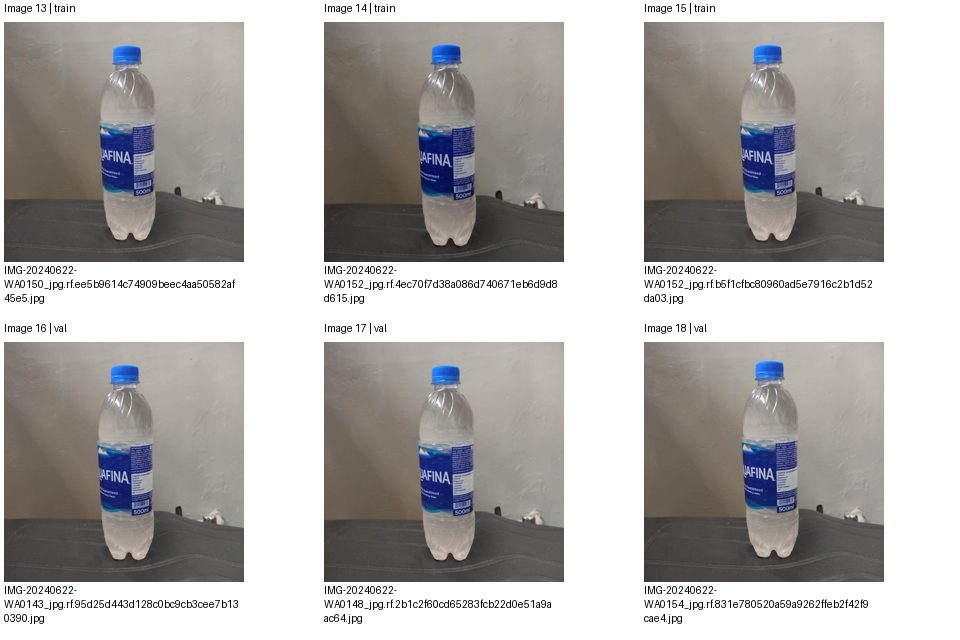

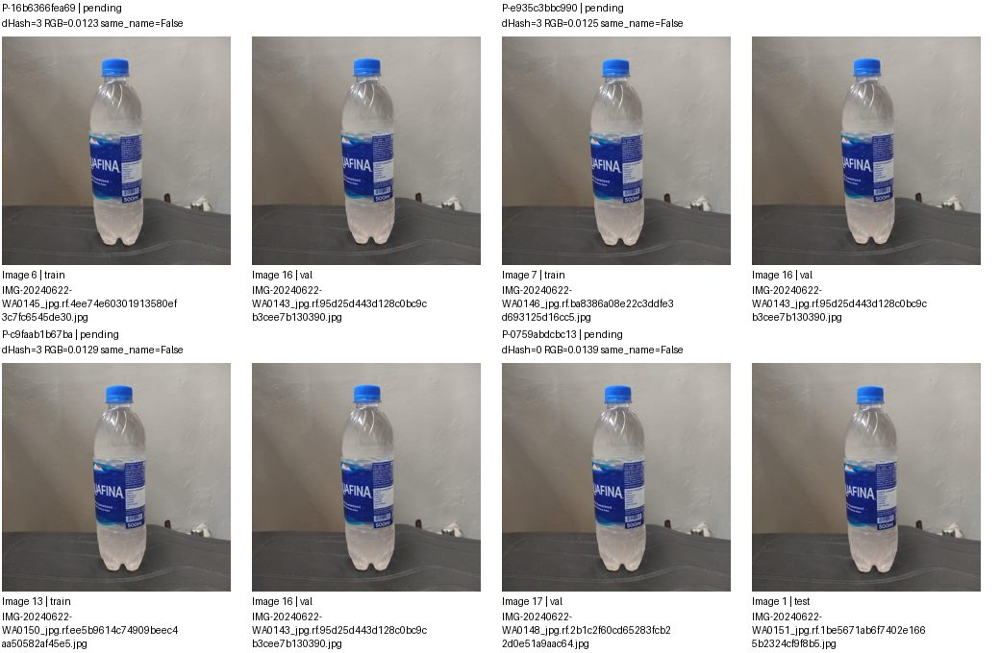

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-16b6366fea69,images/train/IMG-20240622-WA0145_jpg.rf.4ee74e60301913580ef3c7fc6545de30.jpg,images/val/IMG-20240622-WA0143_jpg.rf.95d25d443d128c0bc9cb3cee7b130390.jpg,pending,
P-e935c3bbc990,images/train/IMG-20240622-WA0146_jpg.rf.ba8386a08e22c3ddfe3d693125d16cc5.jpg,images/val/IMG-20240622-WA0143_jpg.rf.95d25d443d128c0bc9cb3cee7b130390.jpg,pending,
P-c9faab1b67ba,images/train/IMG-20240622-WA0150_jpg.rf.ee5b9614c74909beec4aa50582af45e5.jpg,images/val/IMG-20240622-WA0143_jpg.rf.95d25d443d128c0bc9cb3cee7b130390.jpg,pending,
P-0759abdcbc13,images/val/IMG-20240622-WA0148_jpg.rf.2b1c2f60cd65283fcb22d0e51a9aac64.jpg,images/test/IMG-20240622-WA0151_jpg.rf.1be5671ab6f7402e1665b2324cf9f8b5.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 98/166 G-110947dfa5ab | 18 ảnh, 59 cặp
Split: {'test': 1, 'train': 14, 'val': 3}
Quyết định: {'pending': 59}
Ảnh trang None/3; cặp trang 4/15. Nhóm liên thông không phải kết luận trùng.


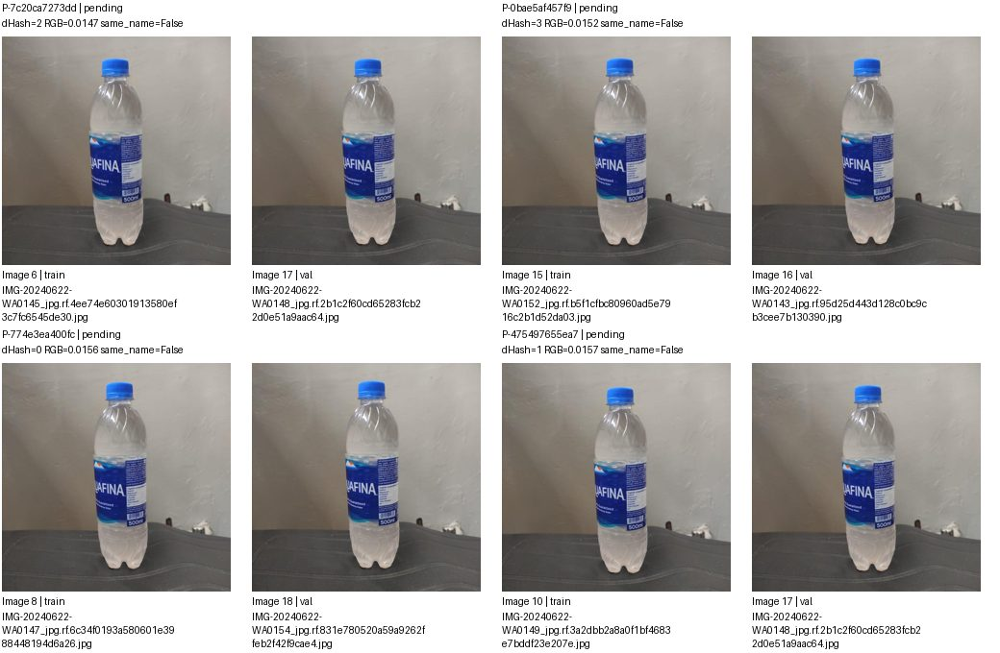

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-7c20ca7273dd,images/train/IMG-20240622-WA0145_jpg.rf.4ee74e60301913580ef3c7fc6545de30.jpg,images/val/IMG-20240622-WA0148_jpg.rf.2b1c2f60cd65283fcb22d0e51a9aac64.jpg,pending,
P-0bae5af457f9,images/train/IMG-20240622-WA0152_jpg.rf.b5f1cfbc80960ad5e7916c2b1d52da03.jpg,images/val/IMG-20240622-WA0143_jpg.rf.95d25d443d128c0bc9cb3cee7b130390.jpg,pending,
P-774e3ea400fc,images/train/IMG-20240622-WA0147_jpg.rf.6c34f0193a580601e3988448194d6a26.jpg,images/val/IMG-20240622-WA0154_jpg.rf.831e780520a59a9262ffeb2f42f9cae4.jpg,pending,
P-475497655ea7,images/train/IMG-20240622-WA0149_jpg.rf.3a2dbb2a8a0f1bf4683e7bddf23e207e.jpg,images/val/IMG-20240622-WA0148_jpg.rf.2b1c2f60cd65283fcb22d0e51a9aac64.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 98/166 G-110947dfa5ab | 18 ảnh, 59 cặp
Split: {'test': 1, 'train': 14, 'val': 3}
Quyết định: {'pending': 59}
Ảnh trang None/3; cặp trang 5/15. Nhóm liên thông không phải kết luận trùng.


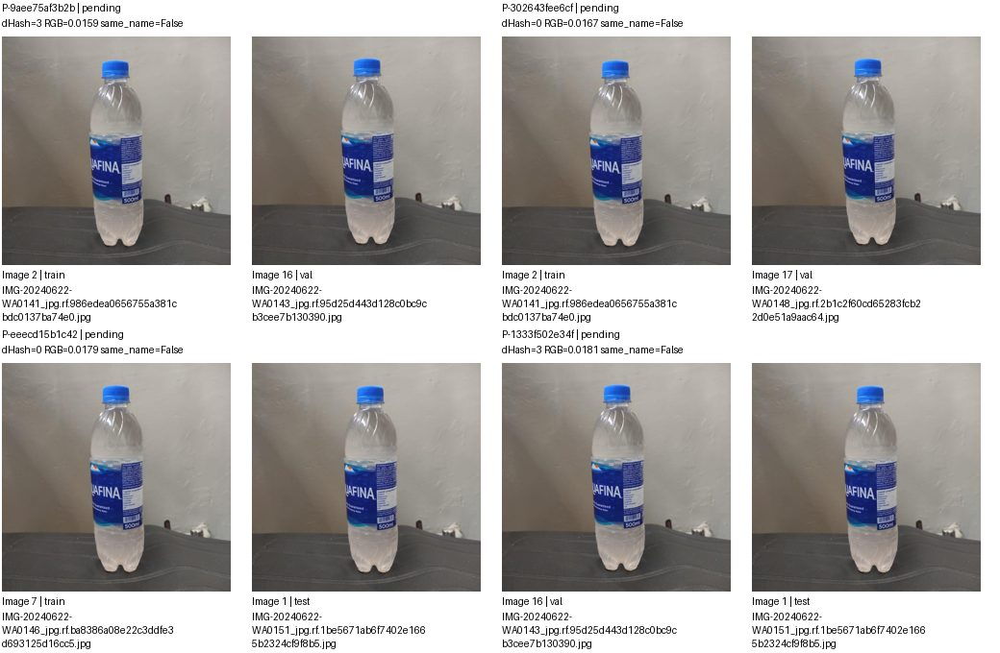

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-9aee75af3b2b,images/train/IMG-20240622-WA0141_jpg.rf.986edea0656755a381cbdc0137ba74e0.jpg,images/val/IMG-20240622-WA0143_jpg.rf.95d25d443d128c0bc9cb3cee7b130390.jpg,pending,
P-302643fee6cf,images/train/IMG-20240622-WA0141_jpg.rf.986edea0656755a381cbdc0137ba74e0.jpg,images/val/IMG-20240622-WA0148_jpg.rf.2b1c2f60cd65283fcb22d0e51a9aac64.jpg,pending,
P-eeecd15b1c42,images/train/IMG-20240622-WA0146_jpg.rf.ba8386a08e22c3ddfe3d693125d16cc5.jpg,images/test/IMG-20240622-WA0151_jpg.rf.1be5671ab6f7402e1665b2324cf9f8b5.jpg,pending,
P-1333f502e34f,images/val/IMG-20240622-WA0143_jpg.rf.95d25d443d128c0bc9cb3cee7b130390.jpg,images/test/IMG-20240622-WA0151_jpg.rf.1be5671ab6f7402e1665b2324cf9f8b5.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 98/166 G-110947dfa5ab | 18 ảnh, 59 cặp
Split: {'test': 1, 'train': 14, 'val': 3}
Quyết định: {'pending': 59}
Ảnh trang None/3; cặp trang 6/15. Nhóm liên thông không phải kết luận trùng.


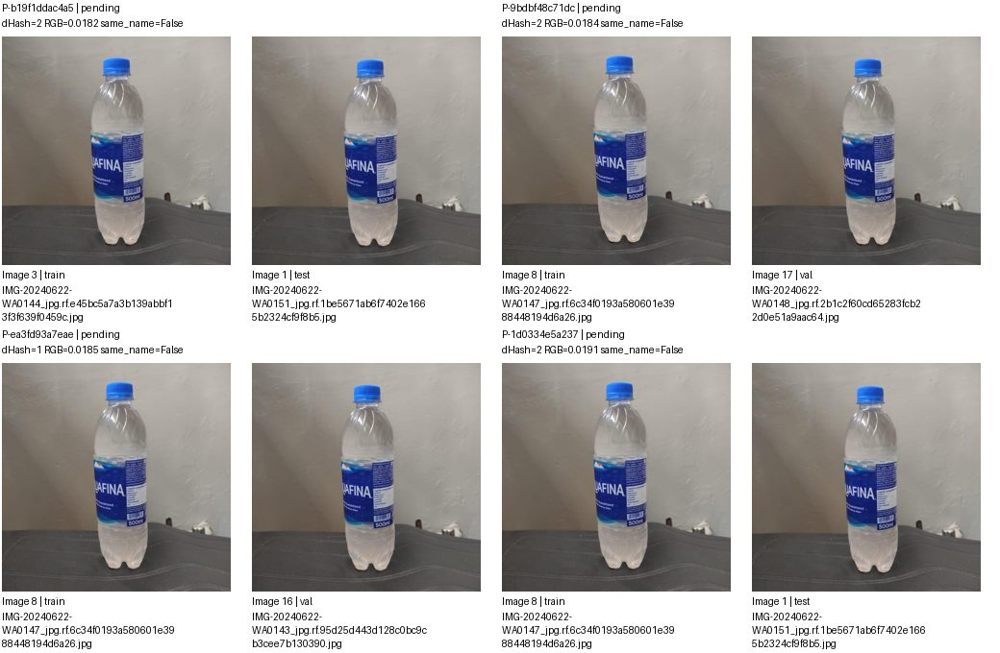

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-b19f1ddac4a5,images/train/IMG-20240622-WA0144_jpg.rf.e45bc5a7a3b139abbf13f3f639f0459c.jpg,images/test/IMG-20240622-WA0151_jpg.rf.1be5671ab6f7402e1665b2324cf9f8b5.jpg,pending,
P-9bdbf48c71dc,images/train/IMG-20240622-WA0147_jpg.rf.6c34f0193a580601e3988448194d6a26.jpg,images/val/IMG-20240622-WA0148_jpg.rf.2b1c2f60cd65283fcb22d0e51a9aac64.jpg,pending,
P-ea3fd93a7eae,images/train/IMG-20240622-WA0147_jpg.rf.6c34f0193a580601e3988448194d6a26.jpg,images/val/IMG-20240622-WA0143_jpg.rf.95d25d443d128c0bc9cb3cee7b130390.jpg,pending,
P-1d0334e5a237,images/train/IMG-20240622-WA0147_jpg.rf.6c34f0193a580601e3988448194d6a26.jpg,images/test/IMG-20240622-WA0151_jpg.rf.1be5671ab6f7402e1665b2324cf9f8b5.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 98/166 G-110947dfa5ab | 18 ảnh, 59 cặp
Split: {'test': 1, 'train': 14, 'val': 3}
Quyết định: {'pending': 59}
Ảnh trang None/3; cặp trang 7/15. Nhóm liên thông không phải kết luận trùng.


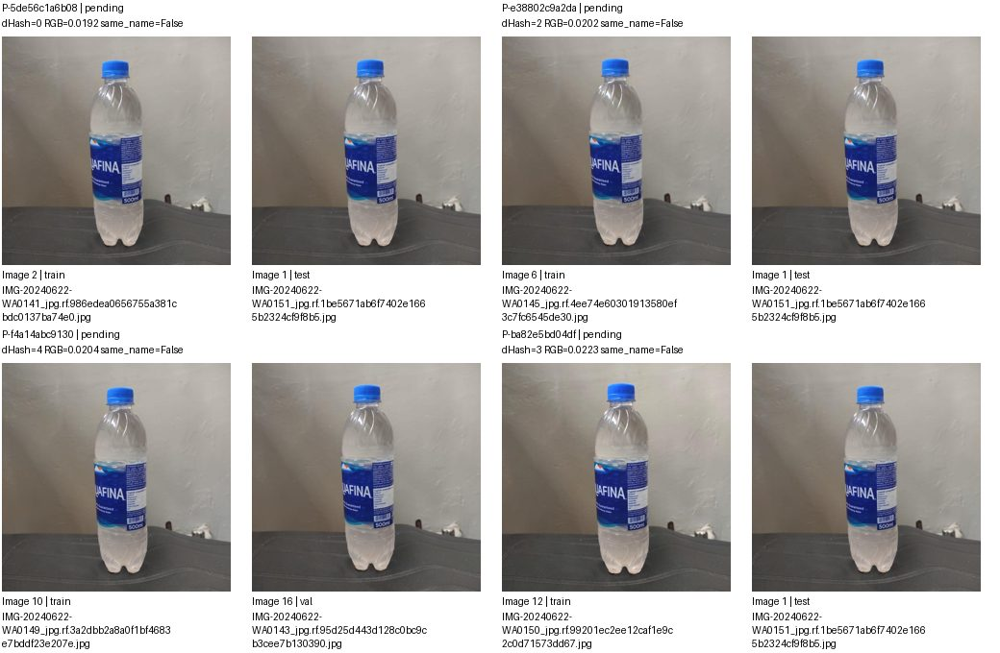

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-5de56c1a6b08,images/train/IMG-20240622-WA0141_jpg.rf.986edea0656755a381cbdc0137ba74e0.jpg,images/test/IMG-20240622-WA0151_jpg.rf.1be5671ab6f7402e1665b2324cf9f8b5.jpg,pending,
P-e38802c9a2da,images/train/IMG-20240622-WA0145_jpg.rf.4ee74e60301913580ef3c7fc6545de30.jpg,images/test/IMG-20240622-WA0151_jpg.rf.1be5671ab6f7402e1665b2324cf9f8b5.jpg,pending,
P-f4a14abc9130,images/train/IMG-20240622-WA0149_jpg.rf.3a2dbb2a8a0f1bf4683e7bddf23e207e.jpg,images/val/IMG-20240622-WA0143_jpg.rf.95d25d443d128c0bc9cb3cee7b130390.jpg,pending,
P-ba82e5bd04df,images/train/IMG-20240622-WA0150_jpg.rf.99201ec2ee12caf1e9c2c0d71573dd67.jpg,images/test/IMG-20240622-WA0151_jpg.rf.1be5671ab6f7402e1665b2324cf9f8b5.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 98/166 G-110947dfa5ab | 18 ảnh, 59 cặp
Split: {'test': 1, 'train': 14, 'val': 3}
Quyết định: {'pending': 59}
Ảnh trang None/3; cặp trang 8/15. Nhóm liên thông không phải kết luận trùng.


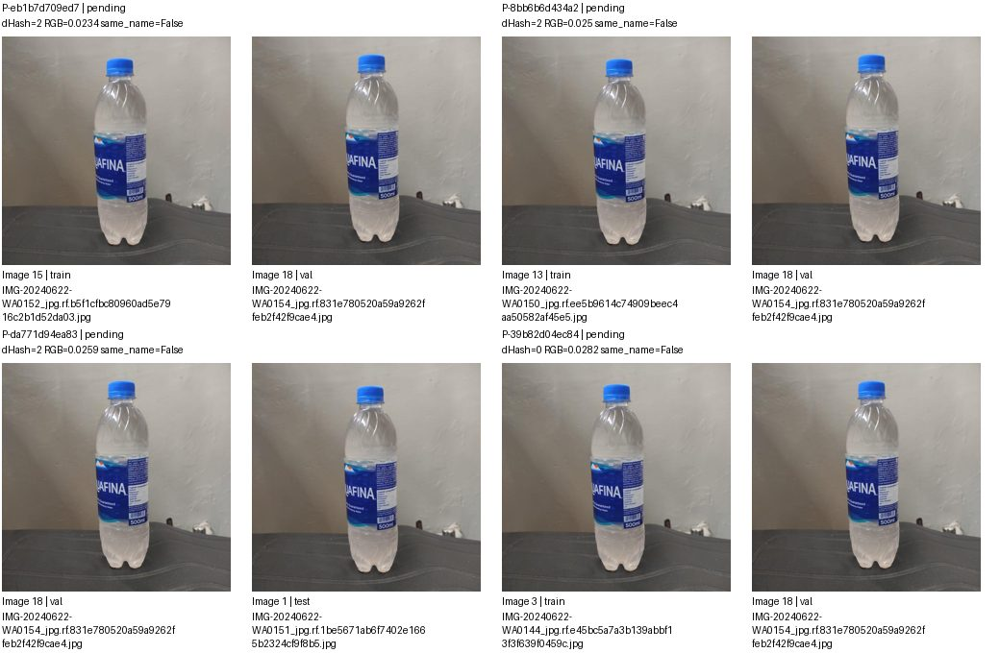

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-eb1b7d709ed7,images/train/IMG-20240622-WA0152_jpg.rf.b5f1cfbc80960ad5e7916c2b1d52da03.jpg,images/val/IMG-20240622-WA0154_jpg.rf.831e780520a59a9262ffeb2f42f9cae4.jpg,pending,
P-8bb6b6d434a2,images/train/IMG-20240622-WA0150_jpg.rf.ee5b9614c74909beec4aa50582af45e5.jpg,images/val/IMG-20240622-WA0154_jpg.rf.831e780520a59a9262ffeb2f42f9cae4.jpg,pending,
P-da771d94ea83,images/val/IMG-20240622-WA0154_jpg.rf.831e780520a59a9262ffeb2f42f9cae4.jpg,images/test/IMG-20240622-WA0151_jpg.rf.1be5671ab6f7402e1665b2324cf9f8b5.jpg,pending,
P-39b82d04ec84,images/train/IMG-20240622-WA0144_jpg.rf.e45bc5a7a3b139abbf13f3f639f0459c.jpg,images/val/IMG-20240622-WA0154_jpg.rf.831e780520a59a9262ffeb2f42f9cae4.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 98/166 G-110947dfa5ab | 18 ảnh, 59 cặp
Split: {'test': 1, 'train': 14, 'val': 3}
Quyết định: {'pending': 59}
Ảnh trang None/3; cặp trang 9/15. Nhóm liên thông không phải kết luận trùng.


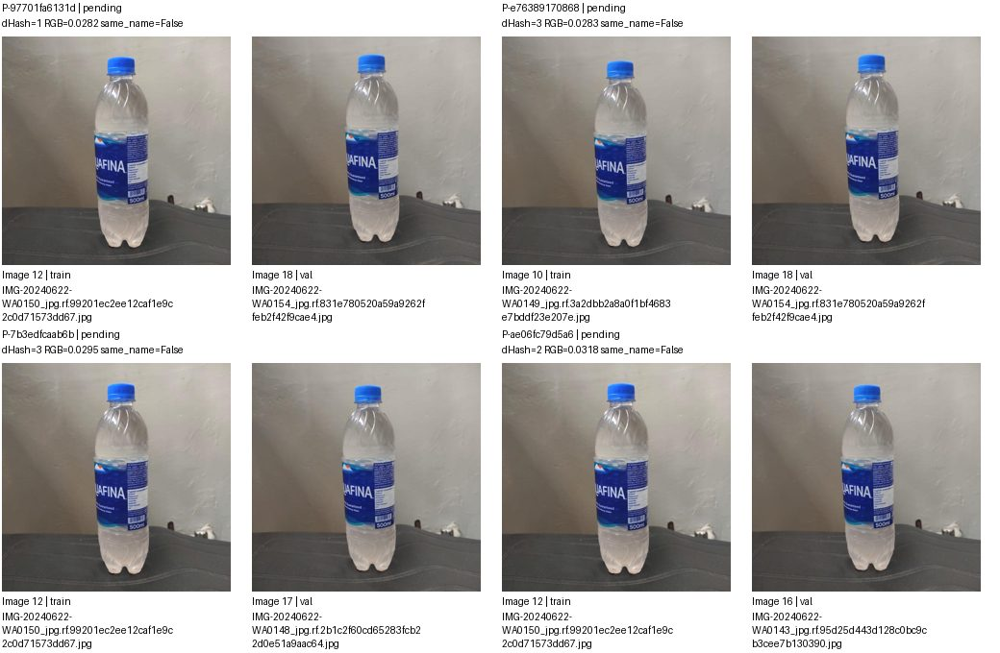

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-97701fa6131d,images/train/IMG-20240622-WA0150_jpg.rf.99201ec2ee12caf1e9c2c0d71573dd67.jpg,images/val/IMG-20240622-WA0154_jpg.rf.831e780520a59a9262ffeb2f42f9cae4.jpg,pending,
P-e76389170868,images/train/IMG-20240622-WA0149_jpg.rf.3a2dbb2a8a0f1bf4683e7bddf23e207e.jpg,images/val/IMG-20240622-WA0154_jpg.rf.831e780520a59a9262ffeb2f42f9cae4.jpg,pending,
P-7b3edfcaab6b,images/train/IMG-20240622-WA0150_jpg.rf.99201ec2ee12caf1e9c2c0d71573dd67.jpg,images/val/IMG-20240622-WA0148_jpg.rf.2b1c2f60cd65283fcb22d0e51a9aac64.jpg,pending,
P-ae06fc79d5a6,images/train/IMG-20240622-WA0150_jpg.rf.99201ec2ee12caf1e9c2c0d71573dd67.jpg,images/val/IMG-20240622-WA0143_jpg.rf.95d25d443d128c0bc9cb3cee7b130390.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 98/166 G-110947dfa5ab | 18 ảnh, 59 cặp
Split: {'test': 1, 'train': 14, 'val': 3}
Quyết định: {'pending': 59}
Ảnh trang None/3; cặp trang 10/15. Nhóm liên thông không phải kết luận trùng.


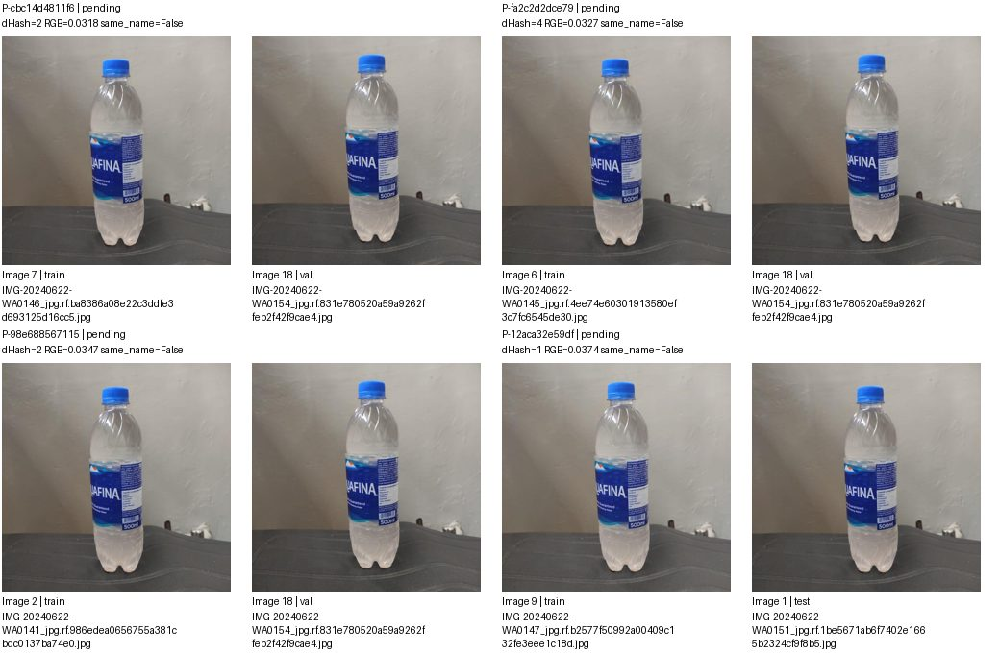

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-cbc14d4811f6,images/train/IMG-20240622-WA0146_jpg.rf.ba8386a08e22c3ddfe3d693125d16cc5.jpg,images/val/IMG-20240622-WA0154_jpg.rf.831e780520a59a9262ffeb2f42f9cae4.jpg,pending,
P-fa2c2d2dce79,images/train/IMG-20240622-WA0145_jpg.rf.4ee74e60301913580ef3c7fc6545de30.jpg,images/val/IMG-20240622-WA0154_jpg.rf.831e780520a59a9262ffeb2f42f9cae4.jpg,pending,
P-98e688567115,images/train/IMG-20240622-WA0141_jpg.rf.986edea0656755a381cbdc0137ba74e0.jpg,images/val/IMG-20240622-WA0154_jpg.rf.831e780520a59a9262ffeb2f42f9cae4.jpg,pending,
P-12aca32e59df,images/train/IMG-20240622-WA0147_jpg.rf.b2577f50992a00409c132fe3eee1c18d.jpg,images/test/IMG-20240622-WA0151_jpg.rf.1be5671ab6f7402e1665b2324cf9f8b5.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 98/166 G-110947dfa5ab | 18 ảnh, 59 cặp
Split: {'test': 1, 'train': 14, 'val': 3}
Quyết định: {'pending': 59}
Ảnh trang None/3; cặp trang 11/15. Nhóm liên thông không phải kết luận trùng.


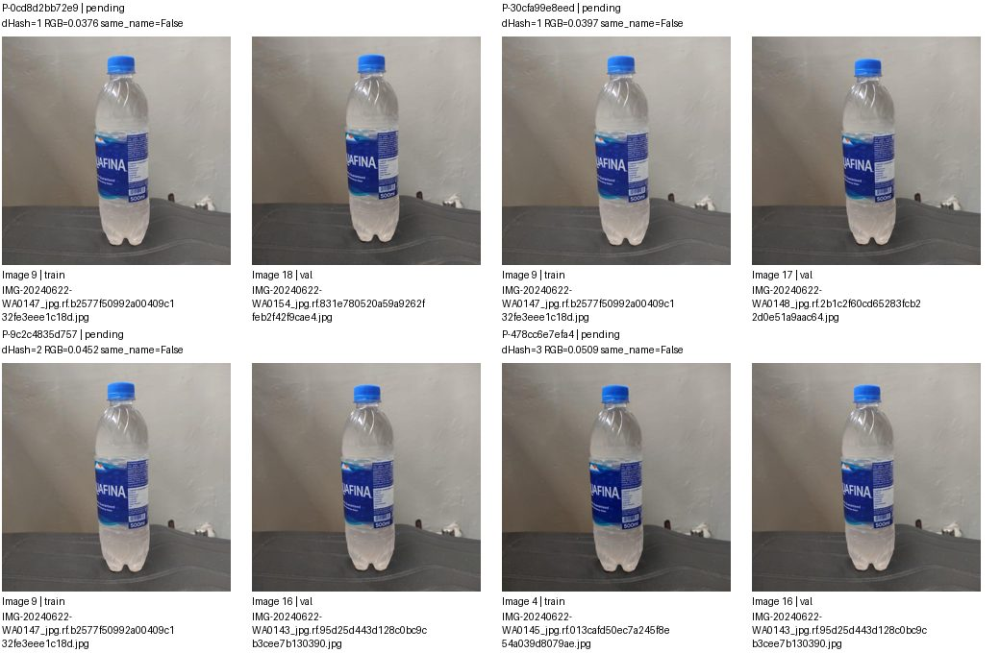

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-0cd8d2bb72e9,images/train/IMG-20240622-WA0147_jpg.rf.b2577f50992a00409c132fe3eee1c18d.jpg,images/val/IMG-20240622-WA0154_jpg.rf.831e780520a59a9262ffeb2f42f9cae4.jpg,pending,
P-30cfa99e8eed,images/train/IMG-20240622-WA0147_jpg.rf.b2577f50992a00409c132fe3eee1c18d.jpg,images/val/IMG-20240622-WA0148_jpg.rf.2b1c2f60cd65283fcb22d0e51a9aac64.jpg,pending,
P-9c2c4835d757,images/train/IMG-20240622-WA0147_jpg.rf.b2577f50992a00409c132fe3eee1c18d.jpg,images/val/IMG-20240622-WA0143_jpg.rf.95d25d443d128c0bc9cb3cee7b130390.jpg,pending,
P-478cc6e7efa4,images/train/IMG-20240622-WA0145_jpg.rf.013cafd50ec7a245f8e54a039d8079ae.jpg,images/val/IMG-20240622-WA0143_jpg.rf.95d25d443d128c0bc9cb3cee7b130390.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 98/166 G-110947dfa5ab | 18 ảnh, 59 cặp
Split: {'test': 1, 'train': 14, 'val': 3}
Quyết định: {'pending': 59}
Ảnh trang None/3; cặp trang 12/15. Nhóm liên thông không phải kết luận trùng.


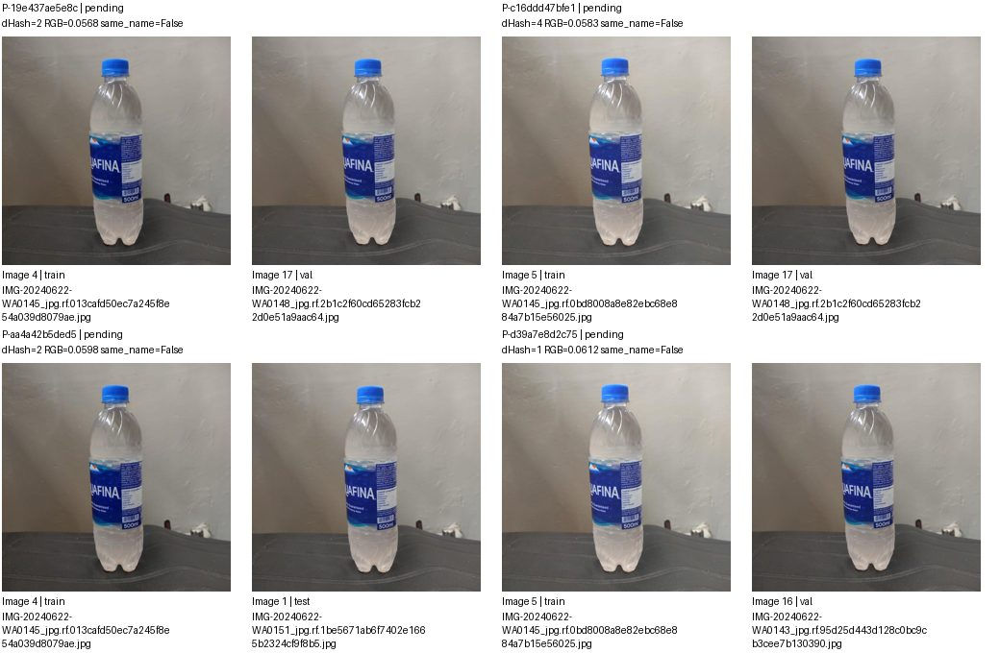

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-19e437ae5e8c,images/train/IMG-20240622-WA0145_jpg.rf.013cafd50ec7a245f8e54a039d8079ae.jpg,images/val/IMG-20240622-WA0148_jpg.rf.2b1c2f60cd65283fcb22d0e51a9aac64.jpg,pending,
P-c16ddd47bfe1,images/train/IMG-20240622-WA0145_jpg.rf.0bd8008a8e82ebc68e884a7b15e56025.jpg,images/val/IMG-20240622-WA0148_jpg.rf.2b1c2f60cd65283fcb22d0e51a9aac64.jpg,pending,
P-aa4a42b5ded5,images/train/IMG-20240622-WA0145_jpg.rf.013cafd50ec7a245f8e54a039d8079ae.jpg,images/test/IMG-20240622-WA0151_jpg.rf.1be5671ab6f7402e1665b2324cf9f8b5.jpg,pending,
P-d39a7e8d2c75,images/train/IMG-20240622-WA0145_jpg.rf.0bd8008a8e82ebc68e884a7b15e56025.jpg,images/val/IMG-20240622-WA0143_jpg.rf.95d25d443d128c0bc9cb3cee7b130390.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 98/166 G-110947dfa5ab | 18 ảnh, 59 cặp
Split: {'test': 1, 'train': 14, 'val': 3}
Quyết định: {'pending': 59}
Ảnh trang None/3; cặp trang 13/15. Nhóm liên thông không phải kết luận trùng.


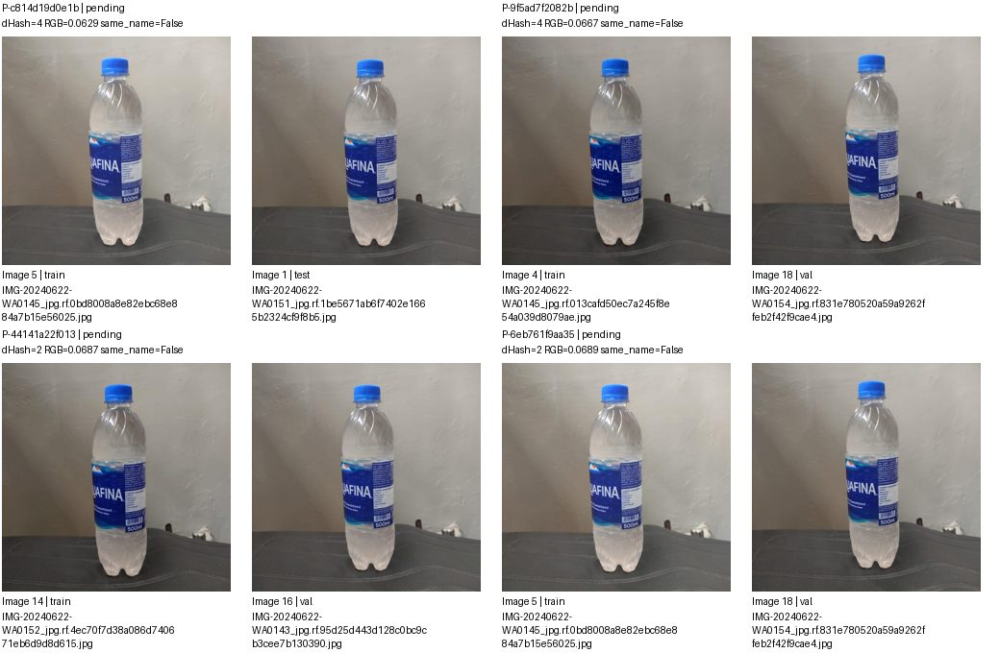

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-c814d19d0e1b,images/train/IMG-20240622-WA0145_jpg.rf.0bd8008a8e82ebc68e884a7b15e56025.jpg,images/test/IMG-20240622-WA0151_jpg.rf.1be5671ab6f7402e1665b2324cf9f8b5.jpg,pending,
P-9f5ad7f2082b,images/train/IMG-20240622-WA0145_jpg.rf.013cafd50ec7a245f8e54a039d8079ae.jpg,images/val/IMG-20240622-WA0154_jpg.rf.831e780520a59a9262ffeb2f42f9cae4.jpg,pending,
P-44141a22f013,images/train/IMG-20240622-WA0152_jpg.rf.4ec70f7d38a086d740671eb6d9d8d615.jpg,images/val/IMG-20240622-WA0143_jpg.rf.95d25d443d128c0bc9cb3cee7b130390.jpg,pending,
P-6eb761f9aa35,images/train/IMG-20240622-WA0145_jpg.rf.0bd8008a8e82ebc68e884a7b15e56025.jpg,images/val/IMG-20240622-WA0154_jpg.rf.831e780520a59a9262ffeb2f42f9cae4.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 98/166 G-110947dfa5ab | 18 ảnh, 59 cặp
Split: {'test': 1, 'train': 14, 'val': 3}
Quyết định: {'pending': 59}
Ảnh trang None/3; cặp trang 14/15. Nhóm liên thông không phải kết luận trùng.


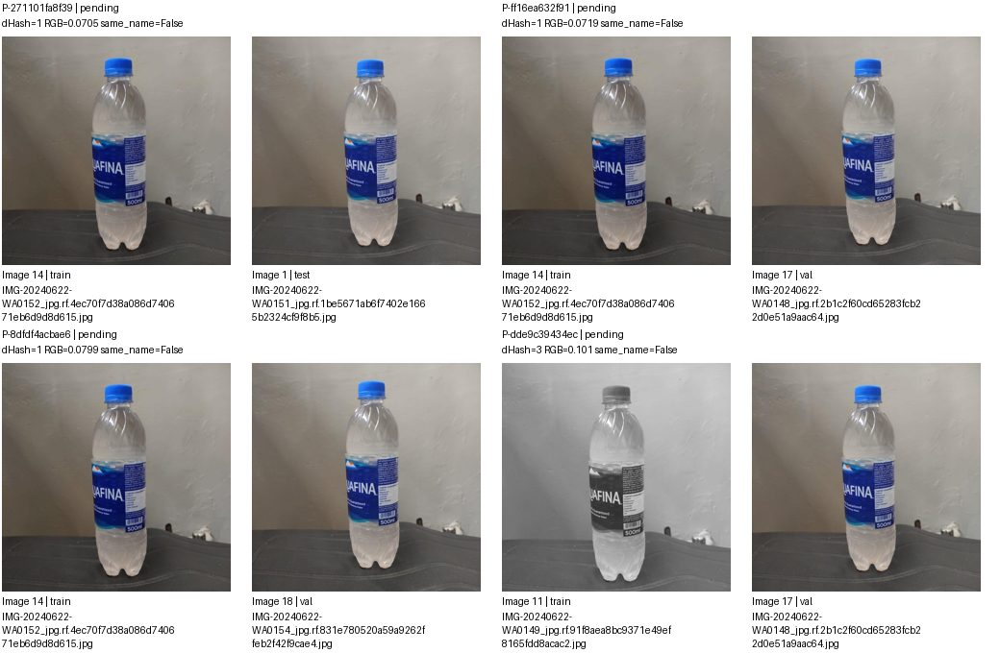

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-271101fa8f39,images/train/IMG-20240622-WA0152_jpg.rf.4ec70f7d38a086d740671eb6d9d8d615.jpg,images/test/IMG-20240622-WA0151_jpg.rf.1be5671ab6f7402e1665b2324cf9f8b5.jpg,pending,
P-ff16ea632f91,images/train/IMG-20240622-WA0152_jpg.rf.4ec70f7d38a086d740671eb6d9d8d615.jpg,images/val/IMG-20240622-WA0148_jpg.rf.2b1c2f60cd65283fcb22d0e51a9aac64.jpg,pending,
P-8dfdf4acbae6,images/train/IMG-20240622-WA0152_jpg.rf.4ec70f7d38a086d740671eb6d9d8d615.jpg,images/val/IMG-20240622-WA0154_jpg.rf.831e780520a59a9262ffeb2f42f9cae4.jpg,pending,
P-dde9c39434ec,images/train/IMG-20240622-WA0149_jpg.rf.91f8aea8bc9371e49ef8165fdd8acac2.jpg,images/val/IMG-20240622-WA0148_jpg.rf.2b1c2f60cd65283fcb22d0e51a9aac64.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 98/166 G-110947dfa5ab | 18 ảnh, 59 cặp
Split: {'test': 1, 'train': 14, 'val': 3}
Quyết định: {'pending': 59}
Ảnh trang None/3; cặp trang 15/15. Nhóm liên thông không phải kết luận trùng.


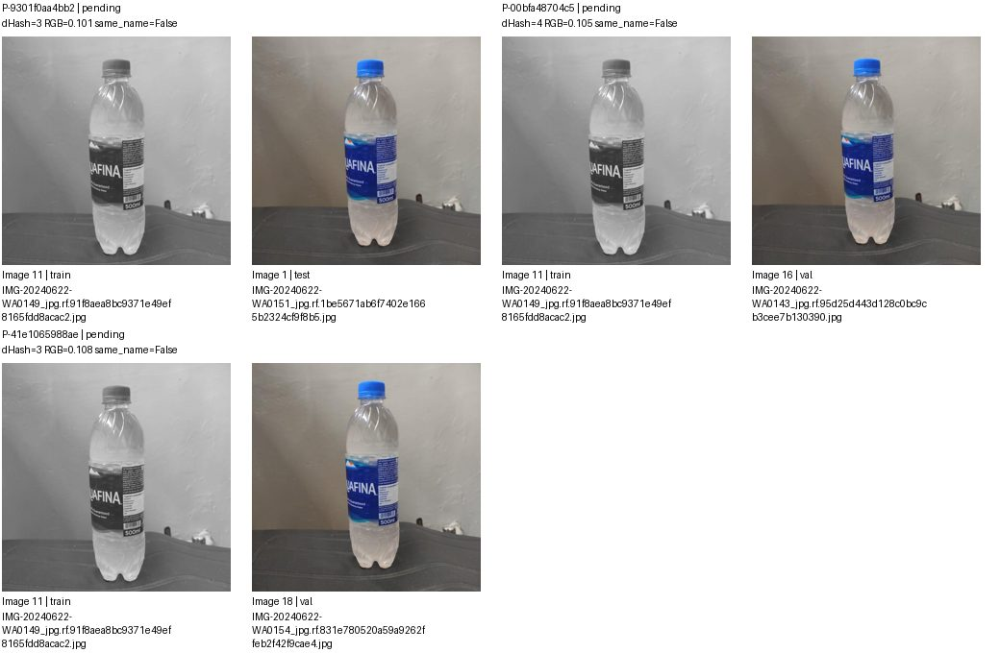

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-9301f0aa4bb2,images/train/IMG-20240622-WA0149_jpg.rf.91f8aea8bc9371e49ef8165fdd8acac2.jpg,images/test/IMG-20240622-WA0151_jpg.rf.1be5671ab6f7402e1665b2324cf9f8b5.jpg,pending,
P-00bfa48704c5,images/train/IMG-20240622-WA0149_jpg.rf.91f8aea8bc9371e49ef8165fdd8acac2.jpg,images/val/IMG-20240622-WA0143_jpg.rf.95d25d443d128c0bc9cb3cee7b130390.jpg,pending,
P-41e1065988ae,images/train/IMG-20240622-WA0149_jpg.rf.91f8aea8bc9371e49ef8165fdd8acac2.jpg,images/val/IMG-20240622-WA0154_jpg.rf.831e780520a59a9262ffeb2f42f9cae4.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 99/166 G-211ba479698f | 4 ảnh, 3 cặp
Split: {'train': 3, 'val': 1}
Quyết định: {'pending': 3}
Ảnh trang 1/1; cặp trang 1/1. Nhóm liên thông không phải kết luận trùng.


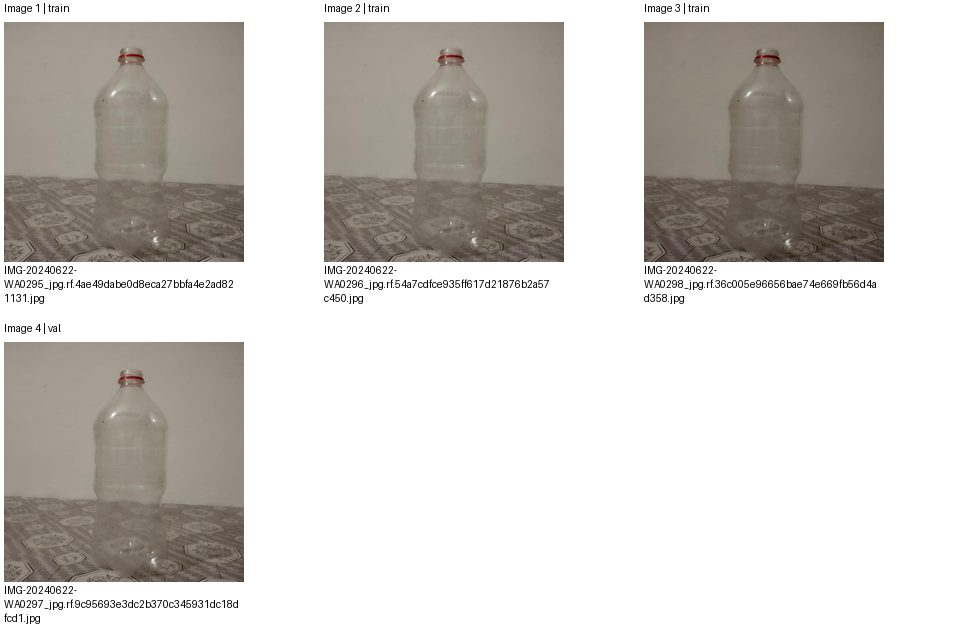

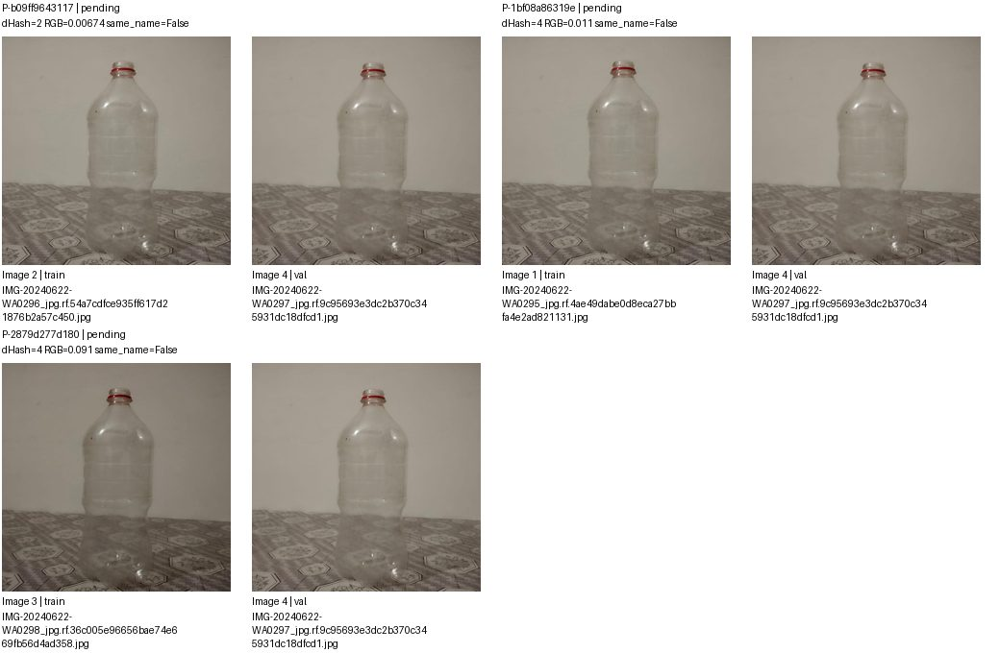

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-b09ff9643117,images/train/IMG-20240622-WA0296_jpg.rf.54a7cdfce935ff617d21876b2a57c450.jpg,images/val/IMG-20240622-WA0297_jpg.rf.9c95693e3dc2b370c345931dc18dfcd1.jpg,pending,
P-1bf08a86319e,images/train/IMG-20240622-WA0295_jpg.rf.4ae49dabe0d8eca27bbfa4e2ad821131.jpg,images/val/IMG-20240622-WA0297_jpg.rf.9c95693e3dc2b370c345931dc18dfcd1.jpg,pending,
P-2879d277d180,images/train/IMG-20240622-WA0298_jpg.rf.36c005e96656bae74e669fb56d4ad358.jpg,images/val/IMG-20240622-WA0297_jpg.rf.9c95693e3dc2b370c345931dc18dfcd1.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 100/166 G-5cc687b00eb5 | 2 ảnh, 1 cặp
Split: {'test': 1, 'train': 1}
Quyết định: {'pending': 1}
Ảnh trang 1/1; cặp trang 1/1. Nhóm liên thông không phải kết luận trùng.


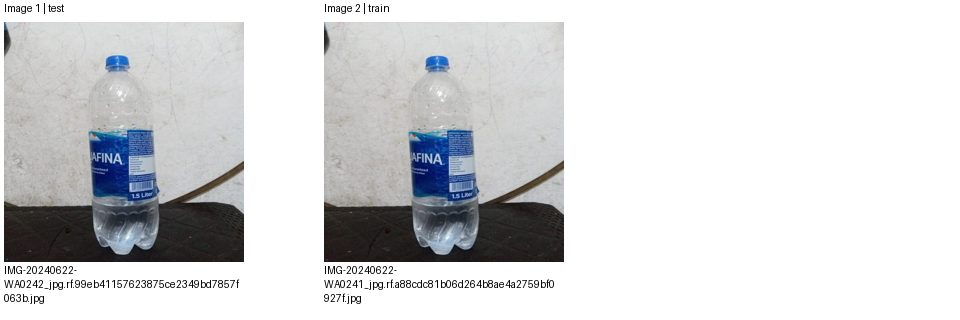

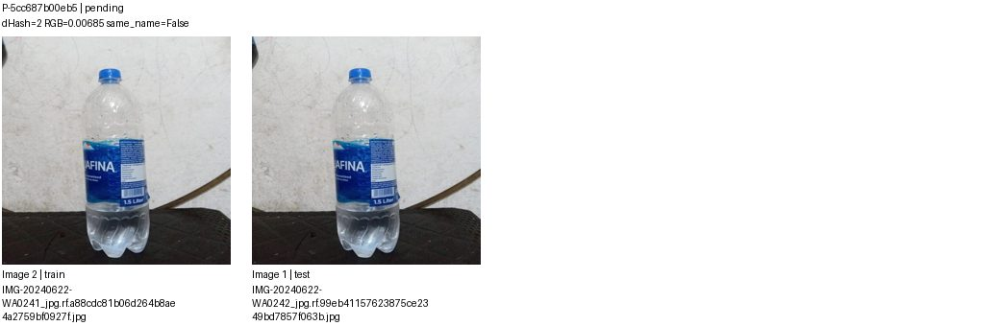

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-5cc687b00eb5,images/train/IMG-20240622-WA0241_jpg.rf.a88cdc81b06d264b8ae4a2759bf0927f.jpg,images/test/IMG-20240622-WA0242_jpg.rf.99eb41157623875ce2349bd7857f063b.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 101/166 G-b98cfb91d7a7 | 8 ảnh, 7 cặp
Split: {'train': 7, 'val': 1}
Quyết định: {'pending': 7}
Ảnh trang 1/2; cặp trang 1/2. Nhóm liên thông không phải kết luận trùng.


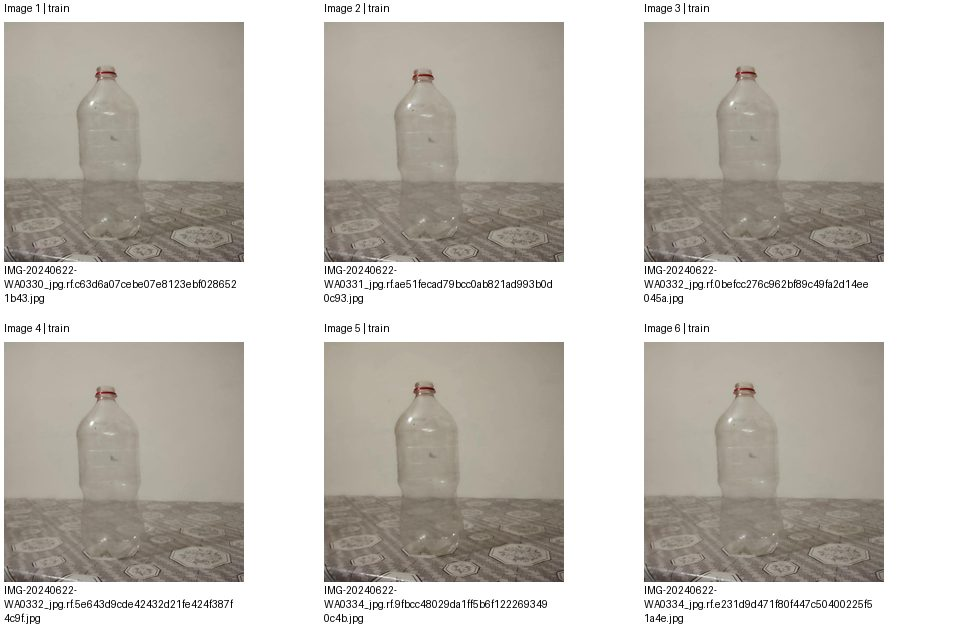

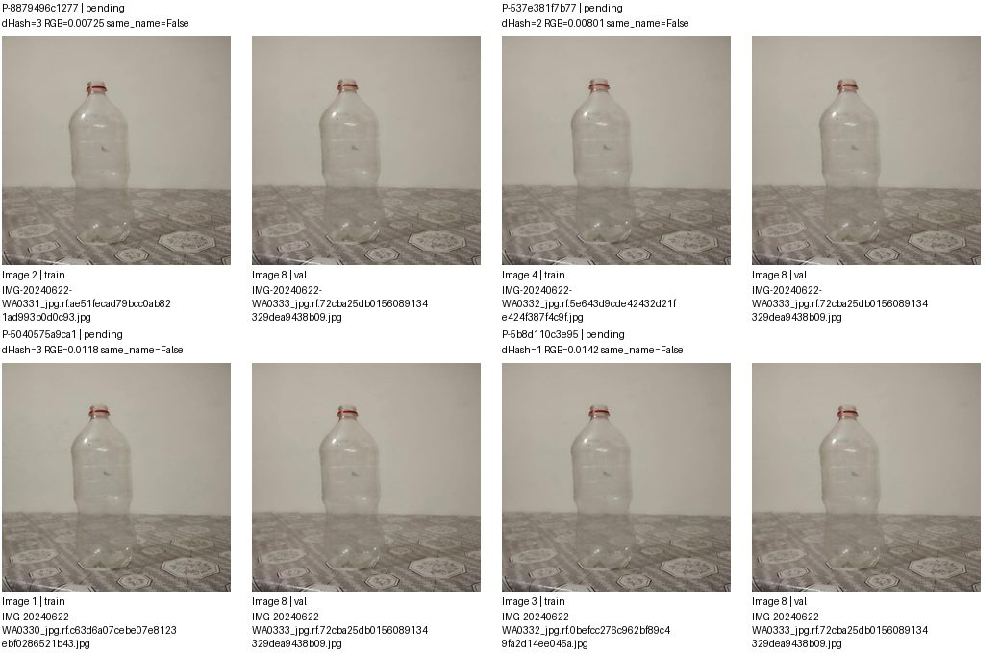

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-8879496c1277,images/train/IMG-20240622-WA0331_jpg.rf.ae51fecad79bcc0ab821ad993b0d0c93.jpg,images/val/IMG-20240622-WA0333_jpg.rf.72cba25db0156089134329dea9438b09.jpg,pending,
P-537e381f7b77,images/train/IMG-20240622-WA0332_jpg.rf.5e643d9cde42432d21fe424f387f4c9f.jpg,images/val/IMG-20240622-WA0333_jpg.rf.72cba25db0156089134329dea9438b09.jpg,pending,
P-5040575a9ca1,images/train/IMG-20240622-WA0330_jpg.rf.c63d6a07cebe07e8123ebf0286521b43.jpg,images/val/IMG-20240622-WA0333_jpg.rf.72cba25db0156089134329dea9438b09.jpg,pending,
P-5b8d110c3e95,images/train/IMG-20240622-WA0332_jpg.rf.0befcc276c962bf89c49fa2d14ee045a.jpg,images/val/IMG-20240622-WA0333_jpg.rf.72cba25db0156089134329dea9438b09.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 101/166 G-b98cfb91d7a7 | 8 ảnh, 7 cặp
Split: {'train': 7, 'val': 1}
Quyết định: {'pending': 7}
Ảnh trang 2/2; cặp trang 2/2. Nhóm liên thông không phải kết luận trùng.


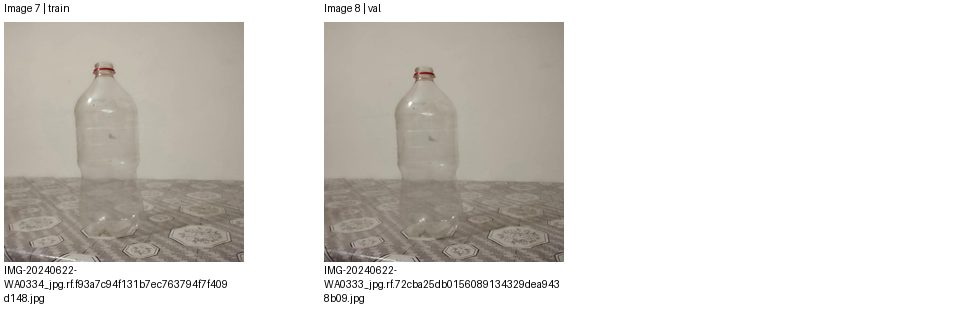

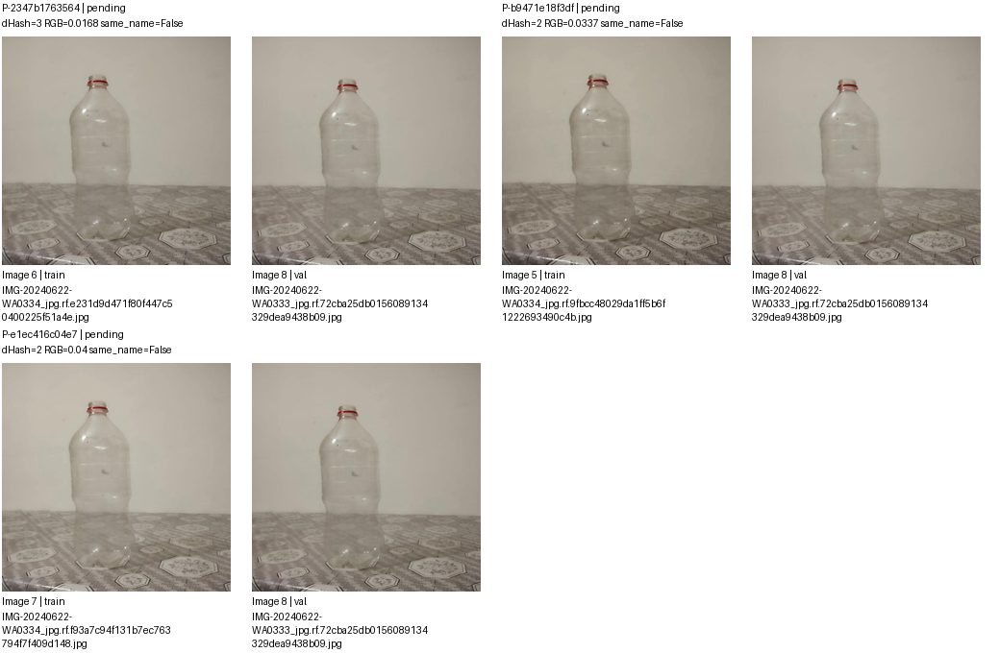

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-2347b1763564,images/train/IMG-20240622-WA0334_jpg.rf.e231d9d471f80f447c50400225f51a4e.jpg,images/val/IMG-20240622-WA0333_jpg.rf.72cba25db0156089134329dea9438b09.jpg,pending,
P-b9471e18f3df,images/train/IMG-20240622-WA0334_jpg.rf.9fbcc48029da1ff5b6f1222693490c4b.jpg,images/val/IMG-20240622-WA0333_jpg.rf.72cba25db0156089134329dea9438b09.jpg,pending,
P-e1ec416c04e7,images/train/IMG-20240622-WA0334_jpg.rf.f93a7c94f131b7ec763794f7f409d148.jpg,images/val/IMG-20240622-WA0333_jpg.rf.72cba25db0156089134329dea9438b09.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 102/166 G-feeb8b90b6dc | 9 ảnh, 9 cặp
Split: {'train': 7, 'val': 2}
Quyết định: {'pending': 9}
Ảnh trang 1/2; cặp trang 1/3. Nhóm liên thông không phải kết luận trùng.


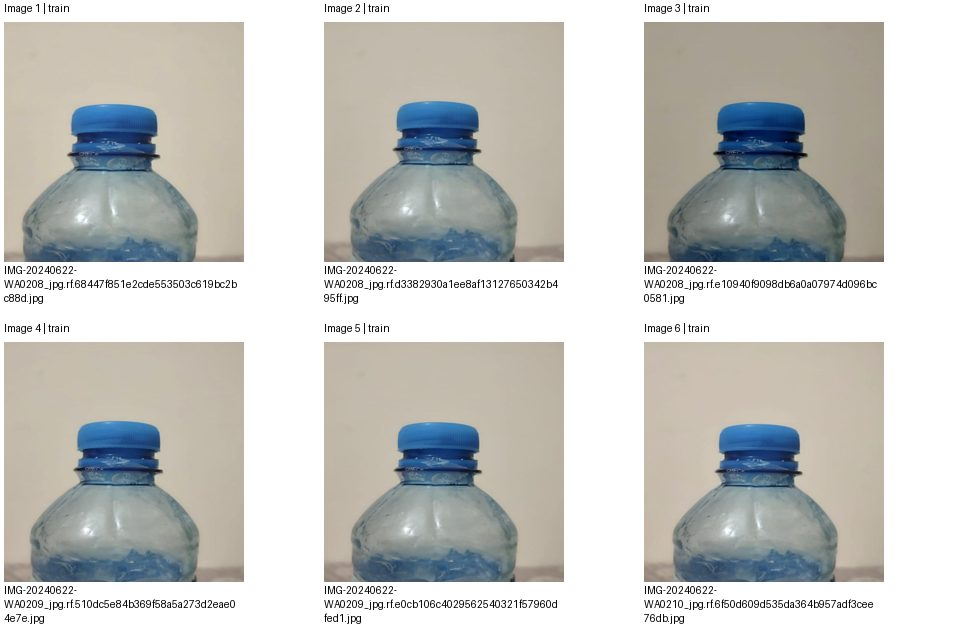

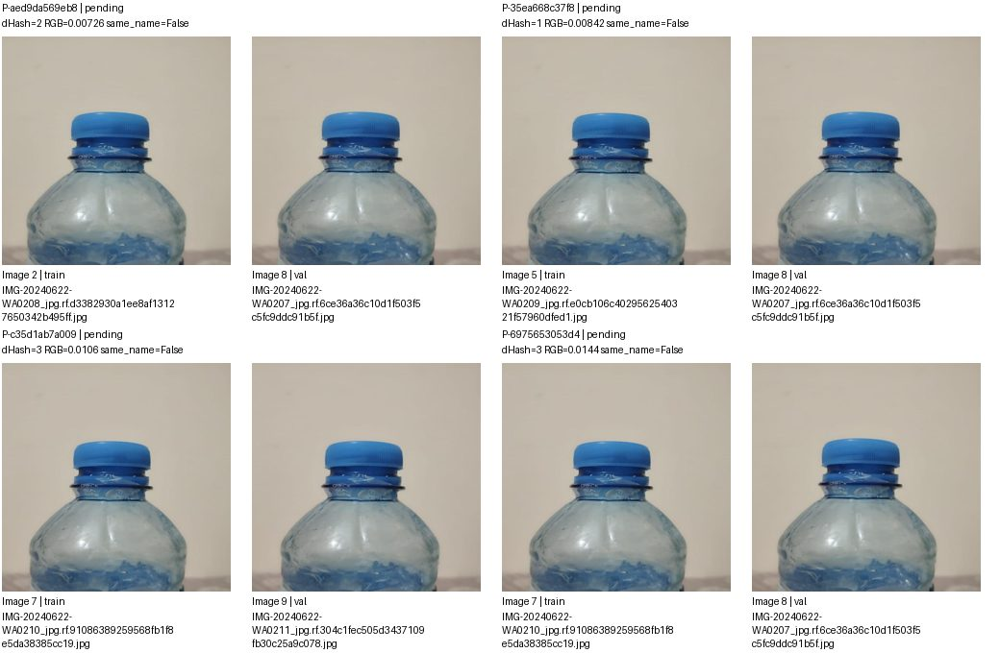

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-aed9da569eb8,images/train/IMG-20240622-WA0208_jpg.rf.d3382930a1ee8af13127650342b495ff.jpg,images/val/IMG-20240622-WA0207_jpg.rf.6ce36a36c10d1f503f5c5fc9ddc91b5f.jpg,pending,
P-35ea668c37f8,images/train/IMG-20240622-WA0209_jpg.rf.e0cb106c4029562540321f57960dfed1.jpg,images/val/IMG-20240622-WA0207_jpg.rf.6ce36a36c10d1f503f5c5fc9ddc91b5f.jpg,pending,
P-c35d1ab7a009,images/train/IMG-20240622-WA0210_jpg.rf.91086389259568fb1f8e5da38385cc19.jpg,images/val/IMG-20240622-WA0211_jpg.rf.304c1fec505d3437109fb30c25a9c078.jpg,pending,
P-6975653053d4,images/train/IMG-20240622-WA0210_jpg.rf.91086389259568fb1f8e5da38385cc19.jpg,images/val/IMG-20240622-WA0207_jpg.rf.6ce36a36c10d1f503f5c5fc9ddc91b5f.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 102/166 G-feeb8b90b6dc | 9 ảnh, 9 cặp
Split: {'train': 7, 'val': 2}
Quyết định: {'pending': 9}
Ảnh trang 2/2; cặp trang 2/3. Nhóm liên thông không phải kết luận trùng.


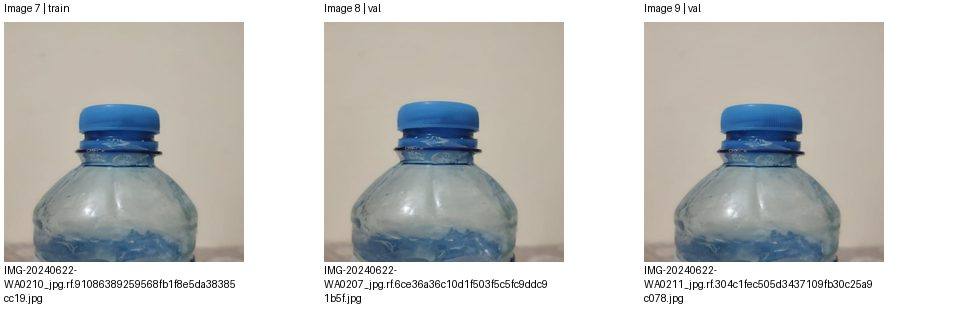

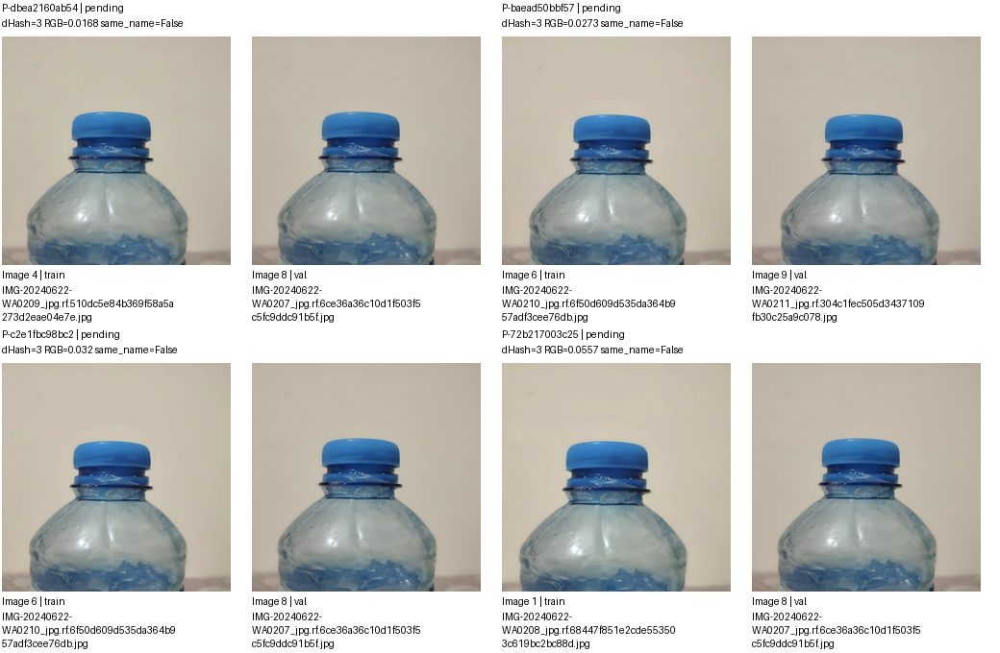

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-dbea2160ab54,images/train/IMG-20240622-WA0209_jpg.rf.510dc5e84b369f58a5a273d2eae04e7e.jpg,images/val/IMG-20240622-WA0207_jpg.rf.6ce36a36c10d1f503f5c5fc9ddc91b5f.jpg,pending,
P-baead50bbf57,images/train/IMG-20240622-WA0210_jpg.rf.6f50d609d535da364b957adf3cee76db.jpg,images/val/IMG-20240622-WA0211_jpg.rf.304c1fec505d3437109fb30c25a9c078.jpg,pending,
P-c2e1fbc98bc2,images/train/IMG-20240622-WA0210_jpg.rf.6f50d609d535da364b957adf3cee76db.jpg,images/val/IMG-20240622-WA0207_jpg.rf.6ce36a36c10d1f503f5c5fc9ddc91b5f.jpg,pending,
P-72b217003c25,images/train/IMG-20240622-WA0208_jpg.rf.68447f851e2cde553503c619bc2bc88d.jpg,images/val/IMG-20240622-WA0207_jpg.rf.6ce36a36c10d1f503f5c5fc9ddc91b5f.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 102/166 G-feeb8b90b6dc | 9 ảnh, 9 cặp
Split: {'train': 7, 'val': 2}
Quyết định: {'pending': 9}
Ảnh trang None/2; cặp trang 3/3. Nhóm liên thông không phải kết luận trùng.


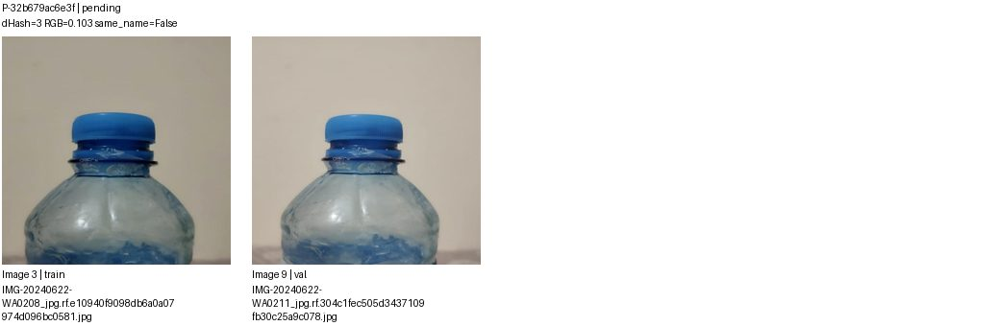

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-32b679ac6e3f,images/train/IMG-20240622-WA0208_jpg.rf.e10940f9098db6a0a07974d096bc0581.jpg,images/val/IMG-20240622-WA0211_jpg.rf.304c1fec505d3437109fb30c25a9c078.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 103/166 G-a1afe02e96c9 | 2 ảnh, 1 cặp
Split: {'test': 1, 'train': 1}
Quyết định: {'pending': 1}
Ảnh trang 1/1; cặp trang 1/1. Nhóm liên thông không phải kết luận trùng.


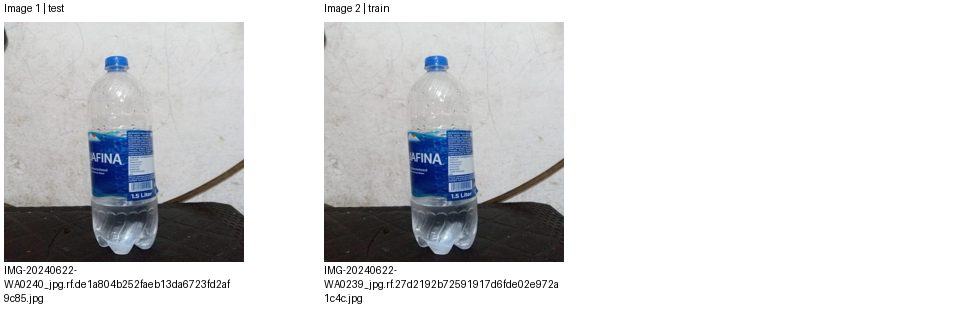

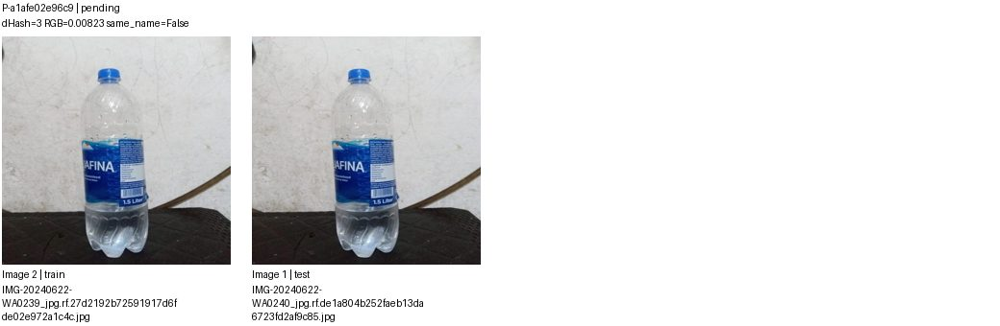

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-a1afe02e96c9,images/train/IMG-20240622-WA0239_jpg.rf.27d2192b72591917d6fde02e972a1c4c.jpg,images/test/IMG-20240622-WA0240_jpg.rf.de1a804b252faeb13da6723fd2af9c85.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 104/166 G-947b2d97d667 | 26 ảnh, 207 cặp
Split: {'test': 7, 'train': 9, 'val': 10}
Quyết định: {'pending': 207}
Ảnh trang 1/5; cặp trang 1/52. Nhóm liên thông không phải kết luận trùng.


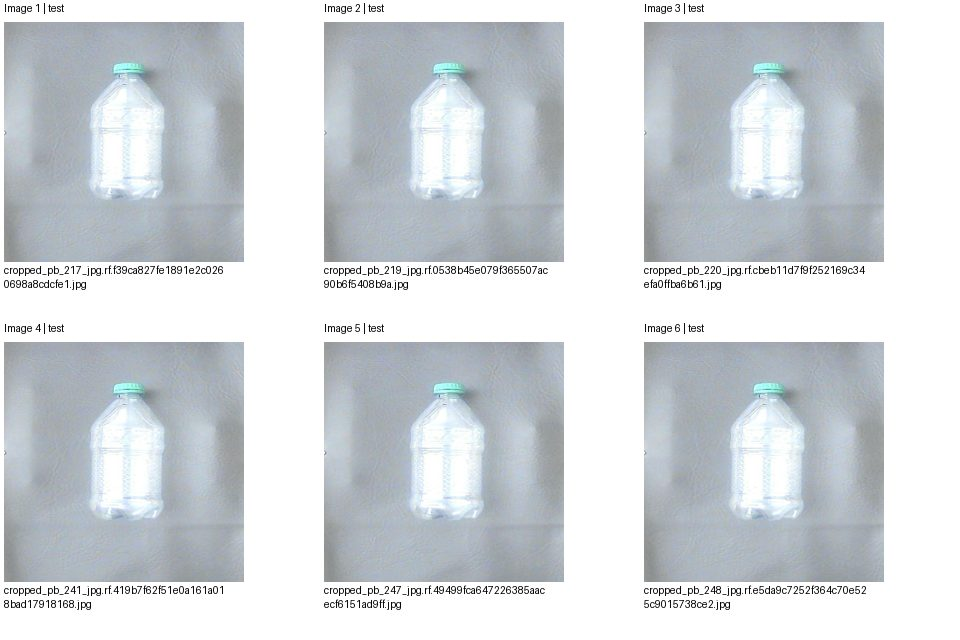

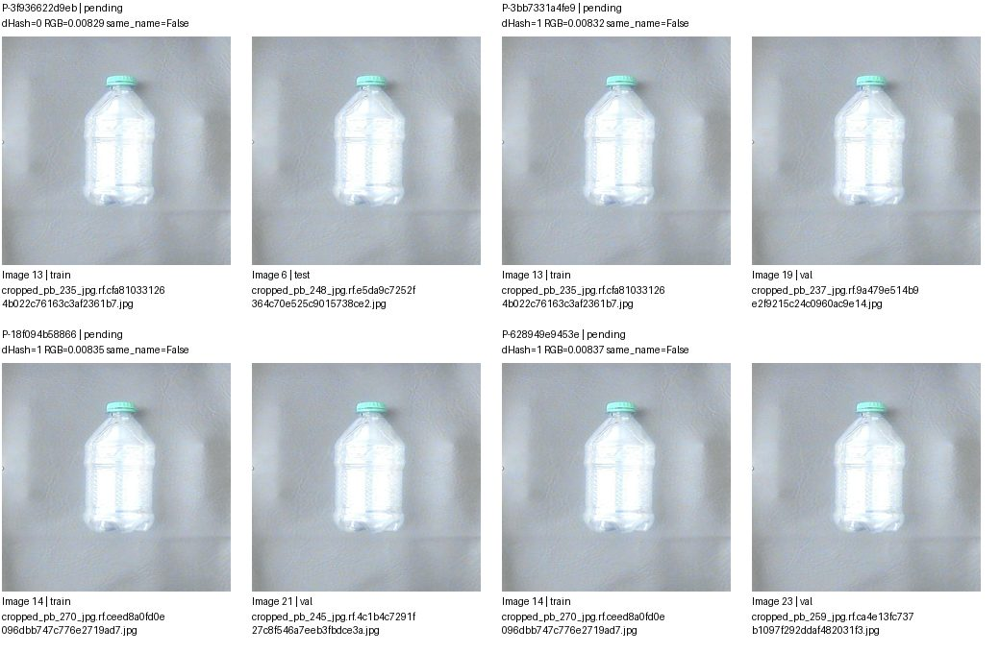

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-3f936622d9eb,images/train/cropped_pb_235_jpg.rf.cfa810331264b022c76163c3af2361b7.jpg,images/test/cropped_pb_248_jpg.rf.e5da9c7252f364c70e525c9015738ce2.jpg,pending,
P-3bb7331a4fe9,images/train/cropped_pb_235_jpg.rf.cfa810331264b022c76163c3af2361b7.jpg,images/val/cropped_pb_237_jpg.rf.9a479e514b9e2f9215c24c0960ac9e14.jpg,pending,
P-18f094b58866,images/train/cropped_pb_270_jpg.rf.ceed8a0fd0e096dbb747c776e2719ad7.jpg,images/val/cropped_pb_245_jpg.rf.4c1b4c7291f27c8f546a7eeb3fbdce3a.jpg,pending,
P-628949e9453e,images/train/cropped_pb_270_jpg.rf.ceed8a0fd0e096dbb747c776e2719ad7.jpg,images/val/cropped_pb_259_jpg.rf.ca4e13fc737b1097f292ddaf482031f3.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 104/166 G-947b2d97d667 | 26 ảnh, 207 cặp
Split: {'test': 7, 'train': 9, 'val': 10}
Quyết định: {'pending': 207}
Ảnh trang 2/5; cặp trang 2/52. Nhóm liên thông không phải kết luận trùng.


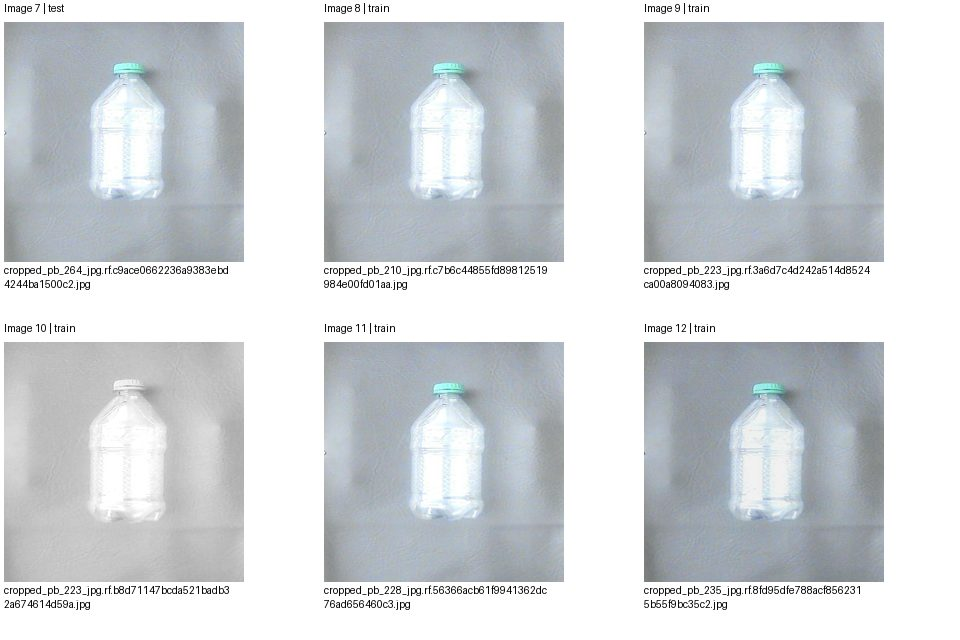

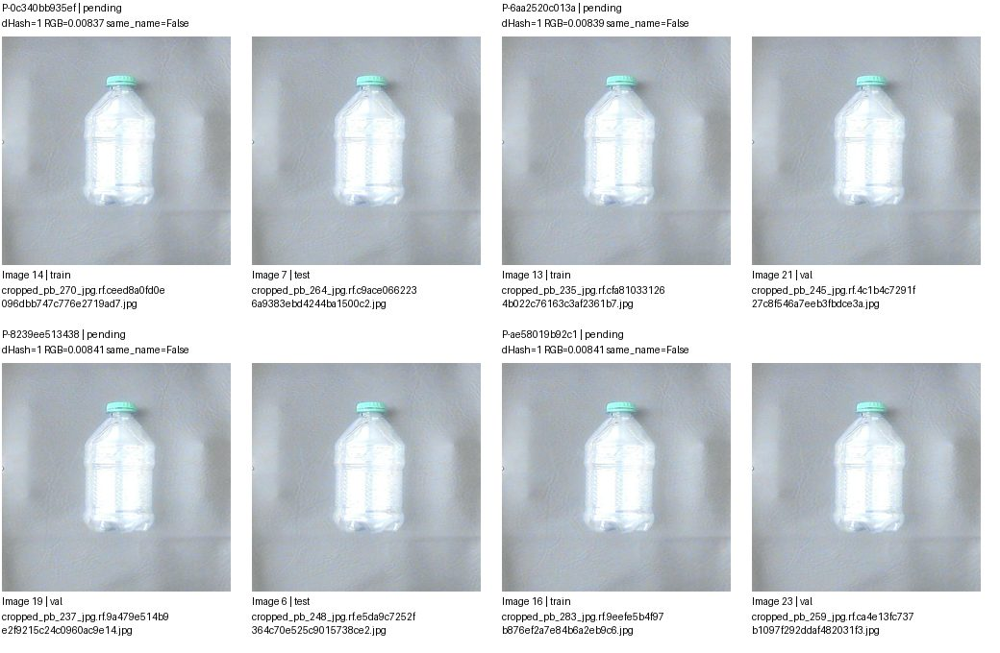

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-0c340bb935ef,images/train/cropped_pb_270_jpg.rf.ceed8a0fd0e096dbb747c776e2719ad7.jpg,images/test/cropped_pb_264_jpg.rf.c9ace0662236a9383ebd4244ba1500c2.jpg,pending,
P-6aa2520c013a,images/train/cropped_pb_235_jpg.rf.cfa810331264b022c76163c3af2361b7.jpg,images/val/cropped_pb_245_jpg.rf.4c1b4c7291f27c8f546a7eeb3fbdce3a.jpg,pending,
P-8239ee513438,images/val/cropped_pb_237_jpg.rf.9a479e514b9e2f9215c24c0960ac9e14.jpg,images/test/cropped_pb_248_jpg.rf.e5da9c7252f364c70e525c9015738ce2.jpg,pending,
P-ae58019b92c1,images/train/cropped_pb_283_jpg.rf.9eefe5b4f97b876ef2a7e84b6a2eb9c6.jpg,images/val/cropped_pb_259_jpg.rf.ca4e13fc737b1097f292ddaf482031f3.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 104/166 G-947b2d97d667 | 26 ảnh, 207 cặp
Split: {'test': 7, 'train': 9, 'val': 10}
Quyết định: {'pending': 207}
Ảnh trang 3/5; cặp trang 3/52. Nhóm liên thông không phải kết luận trùng.


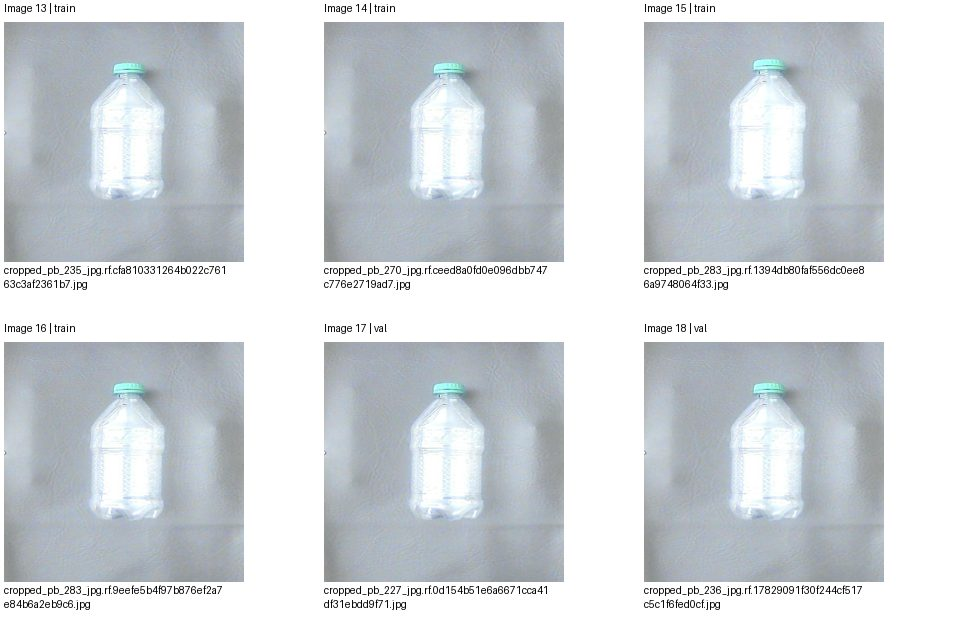

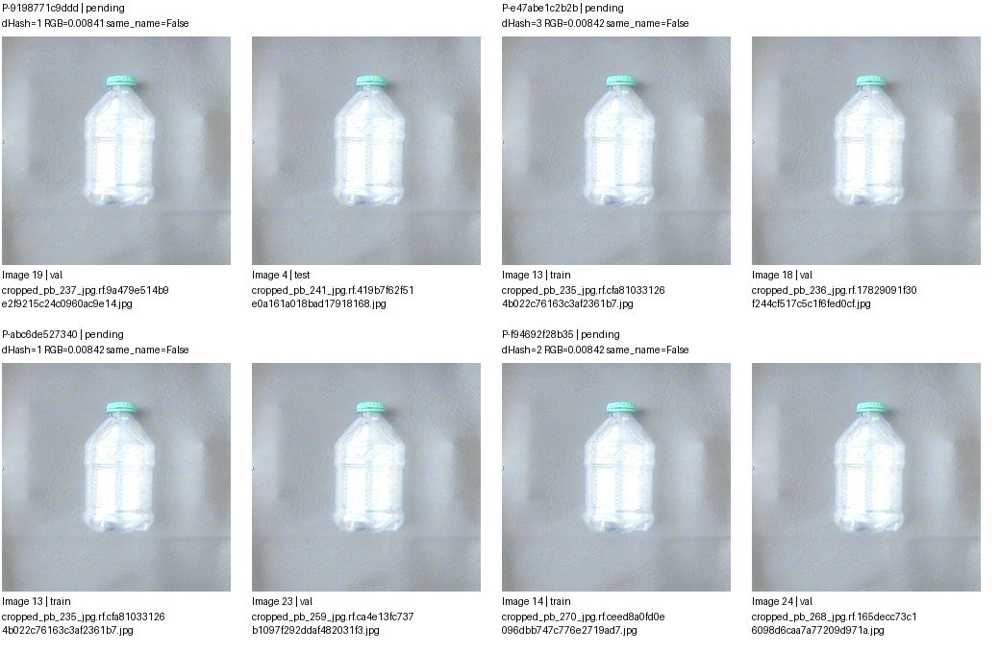

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-9198771c9ddd,images/val/cropped_pb_237_jpg.rf.9a479e514b9e2f9215c24c0960ac9e14.jpg,images/test/cropped_pb_241_jpg.rf.419b7f62f51e0a161a018bad17918168.jpg,pending,
P-e47abe1c2b2b,images/train/cropped_pb_235_jpg.rf.cfa810331264b022c76163c3af2361b7.jpg,images/val/cropped_pb_236_jpg.rf.17829091f30f244cf517c5c1f6fed0cf.jpg,pending,
P-abc6de527340,images/train/cropped_pb_235_jpg.rf.cfa810331264b022c76163c3af2361b7.jpg,images/val/cropped_pb_259_jpg.rf.ca4e13fc737b1097f292ddaf482031f3.jpg,pending,
P-f94692f28b35,images/train/cropped_pb_270_jpg.rf.ceed8a0fd0e096dbb747c776e2719ad7.jpg,images/val/cropped_pb_268_jpg.rf.165decc73c16098d6caa7a77209d971a.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 104/166 G-947b2d97d667 | 26 ảnh, 207 cặp
Split: {'test': 7, 'train': 9, 'val': 10}
Quyết định: {'pending': 207}
Ảnh trang 4/5; cặp trang 4/52. Nhóm liên thông không phải kết luận trùng.


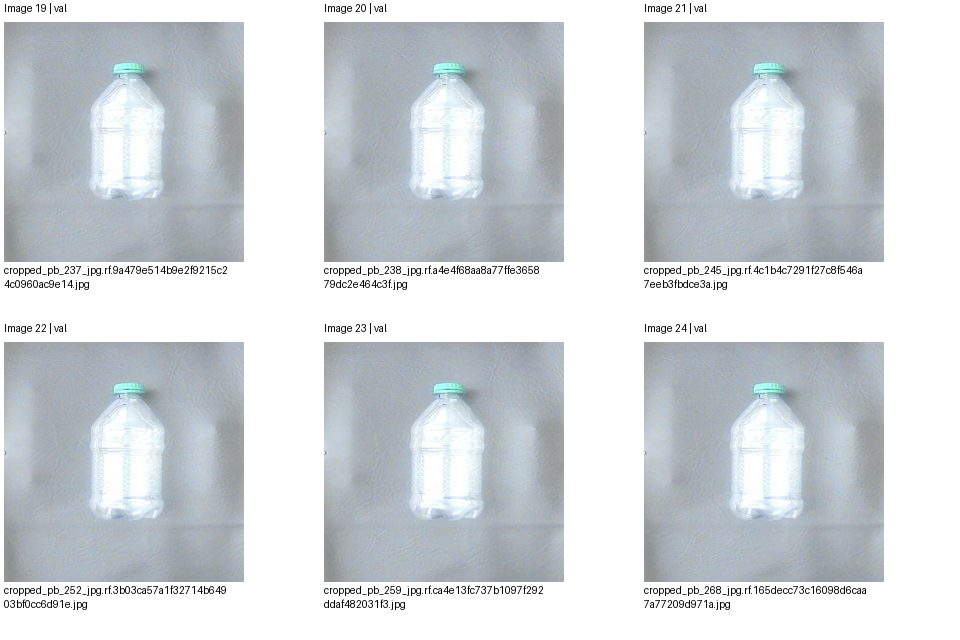

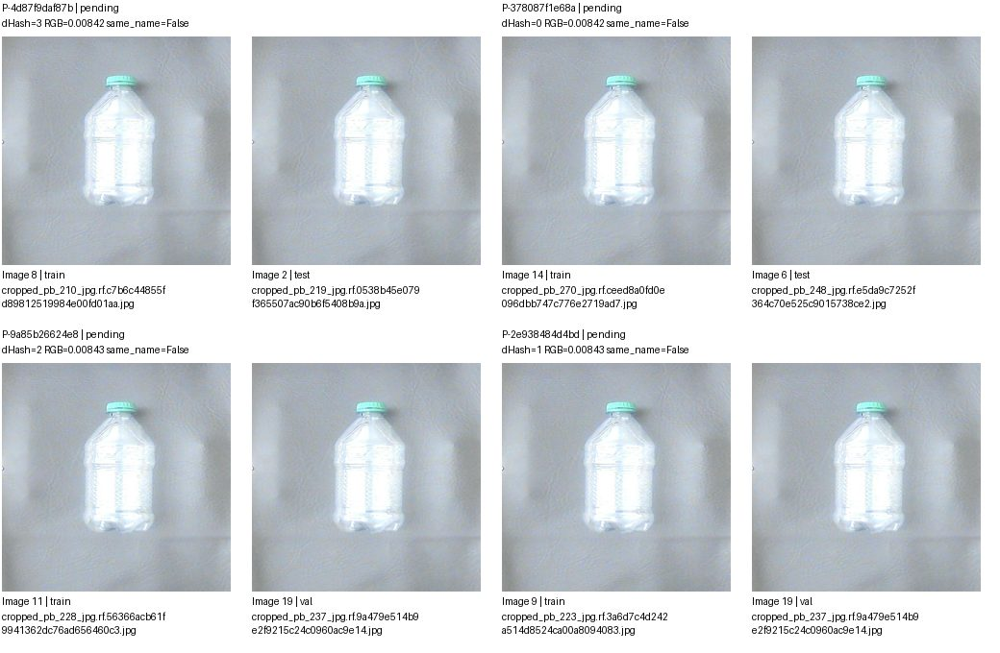

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-4d87f9daf87b,images/train/cropped_pb_210_jpg.rf.c7b6c44855fd89812519984e00fd01aa.jpg,images/test/cropped_pb_219_jpg.rf.0538b45e079f365507ac90b6f5408b9a.jpg,pending,
P-378087f1e68a,images/train/cropped_pb_270_jpg.rf.ceed8a0fd0e096dbb747c776e2719ad7.jpg,images/test/cropped_pb_248_jpg.rf.e5da9c7252f364c70e525c9015738ce2.jpg,pending,
P-9a85b26624e8,images/train/cropped_pb_228_jpg.rf.56366acb61f9941362dc76ad656460c3.jpg,images/val/cropped_pb_237_jpg.rf.9a479e514b9e2f9215c24c0960ac9e14.jpg,pending,
P-2e938484d4bd,images/train/cropped_pb_223_jpg.rf.3a6d7c4d242a514d8524ca00a8094083.jpg,images/val/cropped_pb_237_jpg.rf.9a479e514b9e2f9215c24c0960ac9e14.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 104/166 G-947b2d97d667 | 26 ảnh, 207 cặp
Split: {'test': 7, 'train': 9, 'val': 10}
Quyết định: {'pending': 207}
Ảnh trang 5/5; cặp trang 5/52. Nhóm liên thông không phải kết luận trùng.


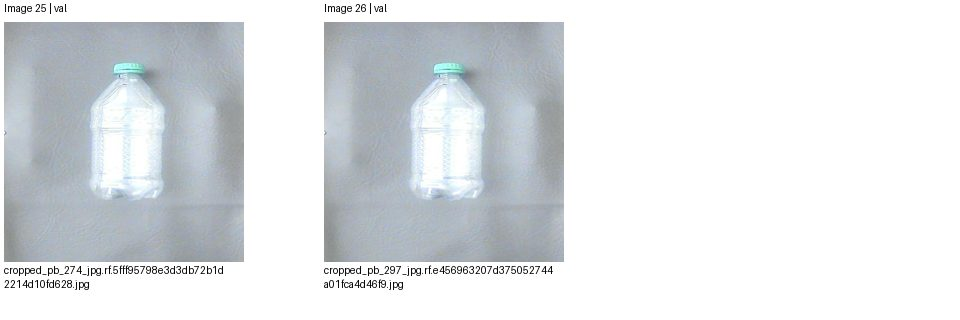

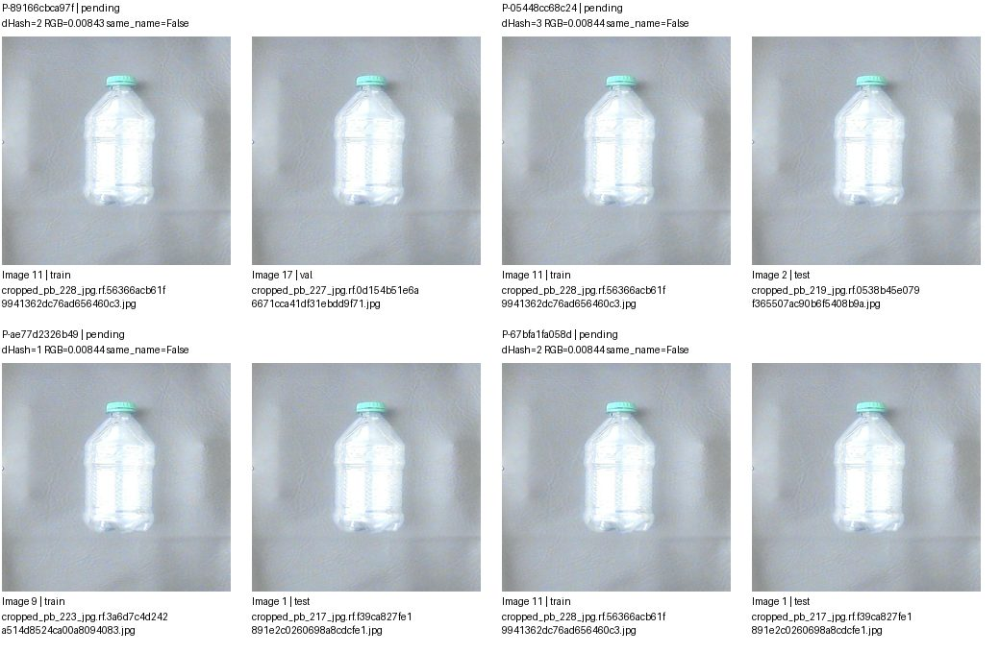

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-89166cbca97f,images/train/cropped_pb_228_jpg.rf.56366acb61f9941362dc76ad656460c3.jpg,images/val/cropped_pb_227_jpg.rf.0d154b51e6a6671cca41df31ebdd9f71.jpg,pending,
P-05448cc68c24,images/train/cropped_pb_228_jpg.rf.56366acb61f9941362dc76ad656460c3.jpg,images/test/cropped_pb_219_jpg.rf.0538b45e079f365507ac90b6f5408b9a.jpg,pending,
P-ae77d2326b49,images/train/cropped_pb_223_jpg.rf.3a6d7c4d242a514d8524ca00a8094083.jpg,images/test/cropped_pb_217_jpg.rf.f39ca827fe1891e2c0260698a8cdcfe1.jpg,pending,
P-67bfa1fa058d,images/train/cropped_pb_228_jpg.rf.56366acb61f9941362dc76ad656460c3.jpg,images/test/cropped_pb_217_jpg.rf.f39ca827fe1891e2c0260698a8cdcfe1.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 104/166 G-947b2d97d667 | 26 ảnh, 207 cặp
Split: {'test': 7, 'train': 9, 'val': 10}
Quyết định: {'pending': 207}
Ảnh trang None/5; cặp trang 6/52. Nhóm liên thông không phải kết luận trùng.


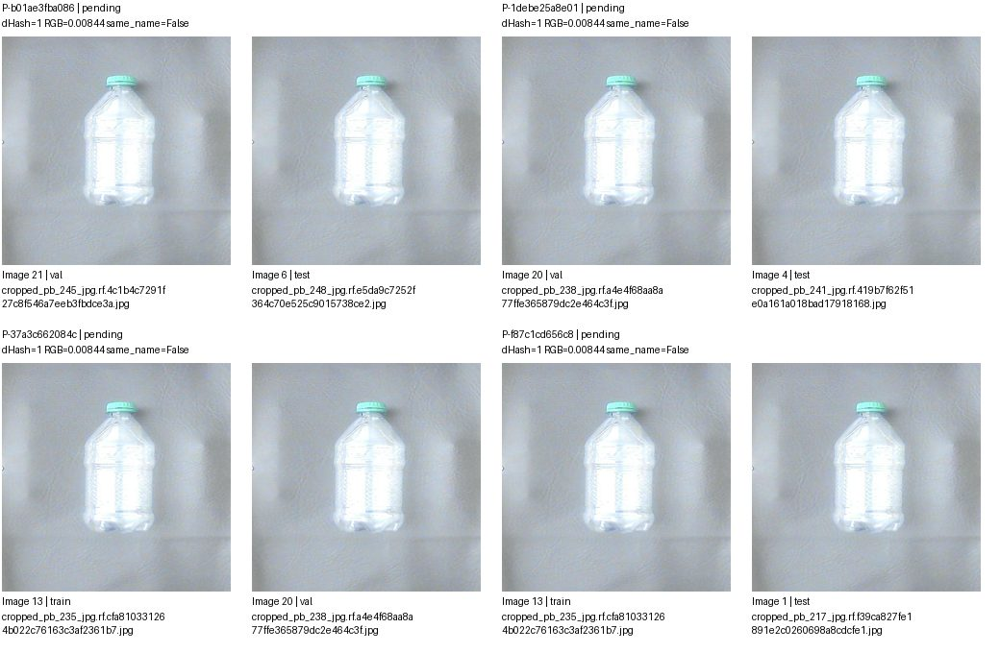

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-b01ae3fba086,images/val/cropped_pb_245_jpg.rf.4c1b4c7291f27c8f546a7eeb3fbdce3a.jpg,images/test/cropped_pb_248_jpg.rf.e5da9c7252f364c70e525c9015738ce2.jpg,pending,
P-1debe25a8e01,images/val/cropped_pb_238_jpg.rf.a4e4f68aa8a77ffe365879dc2e464c3f.jpg,images/test/cropped_pb_241_jpg.rf.419b7f62f51e0a161a018bad17918168.jpg,pending,
P-37a3c662084c,images/train/cropped_pb_235_jpg.rf.cfa810331264b022c76163c3af2361b7.jpg,images/val/cropped_pb_238_jpg.rf.a4e4f68aa8a77ffe365879dc2e464c3f.jpg,pending,
P-f87c1cd656c8,images/train/cropped_pb_235_jpg.rf.cfa810331264b022c76163c3af2361b7.jpg,images/test/cropped_pb_217_jpg.rf.f39ca827fe1891e2c0260698a8cdcfe1.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 104/166 G-947b2d97d667 | 26 ảnh, 207 cặp
Split: {'test': 7, 'train': 9, 'val': 10}
Quyết định: {'pending': 207}
Ảnh trang None/5; cặp trang 7/52. Nhóm liên thông không phải kết luận trùng.


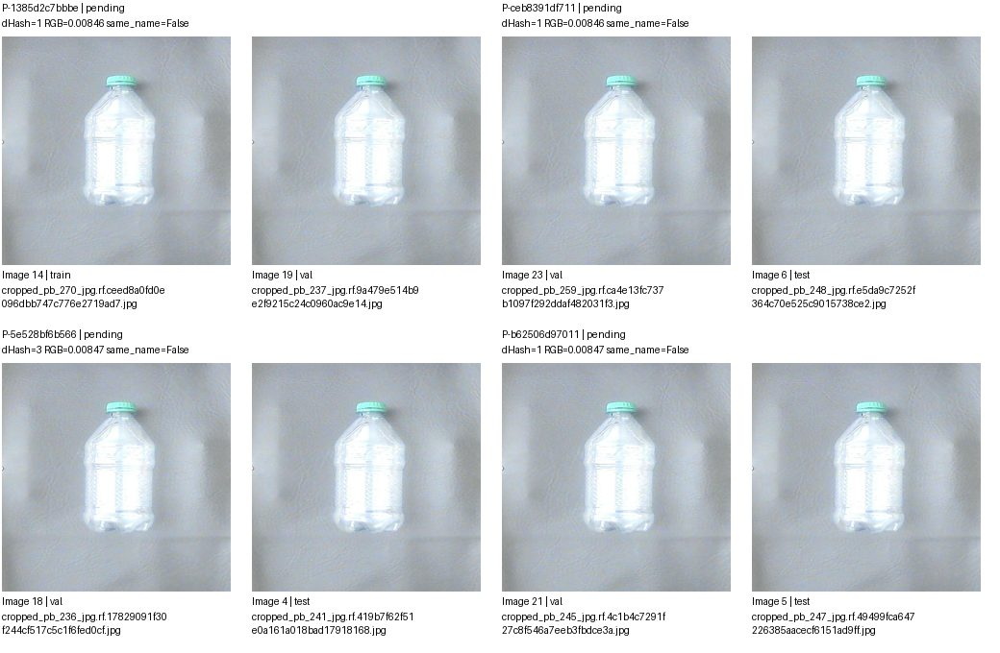

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-1385d2c7bbbe,images/train/cropped_pb_270_jpg.rf.ceed8a0fd0e096dbb747c776e2719ad7.jpg,images/val/cropped_pb_237_jpg.rf.9a479e514b9e2f9215c24c0960ac9e14.jpg,pending,
P-ceb8391df711,images/val/cropped_pb_259_jpg.rf.ca4e13fc737b1097f292ddaf482031f3.jpg,images/test/cropped_pb_248_jpg.rf.e5da9c7252f364c70e525c9015738ce2.jpg,pending,
P-5e528bf6b566,images/val/cropped_pb_236_jpg.rf.17829091f30f244cf517c5c1f6fed0cf.jpg,images/test/cropped_pb_241_jpg.rf.419b7f62f51e0a161a018bad17918168.jpg,pending,
P-b62506d97011,images/val/cropped_pb_245_jpg.rf.4c1b4c7291f27c8f546a7eeb3fbdce3a.jpg,images/test/cropped_pb_247_jpg.rf.49499fca647226385aacecf6151ad9ff.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 104/166 G-947b2d97d667 | 26 ảnh, 207 cặp
Split: {'test': 7, 'train': 9, 'val': 10}
Quyết định: {'pending': 207}
Ảnh trang None/5; cặp trang 8/52. Nhóm liên thông không phải kết luận trùng.


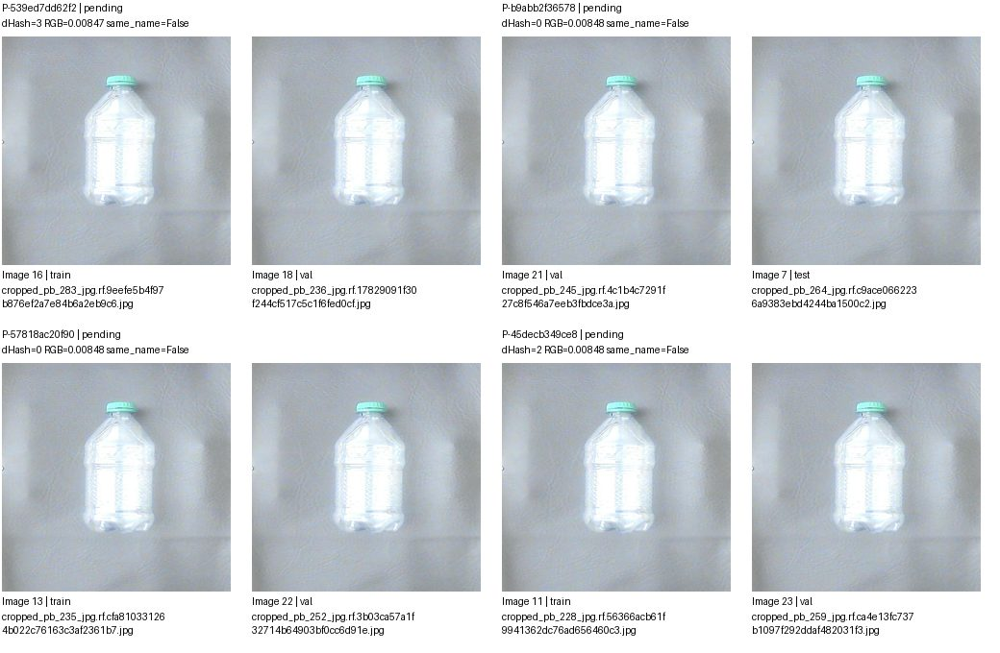

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-539ed7dd62f2,images/train/cropped_pb_283_jpg.rf.9eefe5b4f97b876ef2a7e84b6a2eb9c6.jpg,images/val/cropped_pb_236_jpg.rf.17829091f30f244cf517c5c1f6fed0cf.jpg,pending,
P-b9abb2f36578,images/val/cropped_pb_245_jpg.rf.4c1b4c7291f27c8f546a7eeb3fbdce3a.jpg,images/test/cropped_pb_264_jpg.rf.c9ace0662236a9383ebd4244ba1500c2.jpg,pending,
P-57818ac20f90,images/train/cropped_pb_235_jpg.rf.cfa810331264b022c76163c3af2361b7.jpg,images/val/cropped_pb_252_jpg.rf.3b03ca57a1f32714b64903bf0cc6d91e.jpg,pending,
P-45decb349ce8,images/train/cropped_pb_228_jpg.rf.56366acb61f9941362dc76ad656460c3.jpg,images/val/cropped_pb_259_jpg.rf.ca4e13fc737b1097f292ddaf482031f3.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 104/166 G-947b2d97d667 | 26 ảnh, 207 cặp
Split: {'test': 7, 'train': 9, 'val': 10}
Quyết định: {'pending': 207}
Ảnh trang None/5; cặp trang 9/52. Nhóm liên thông không phải kết luận trùng.


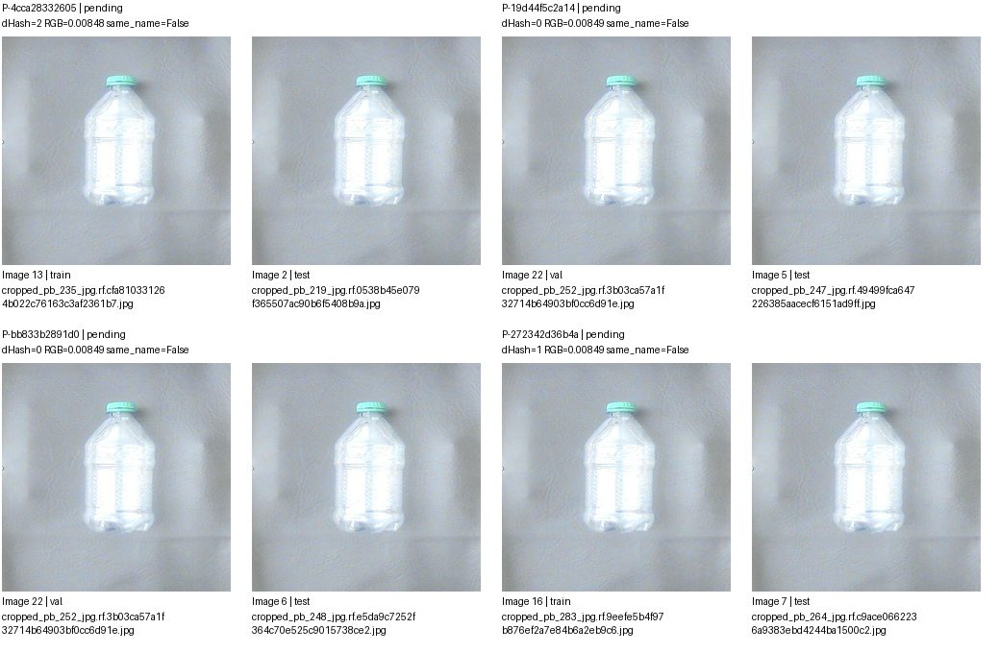

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-4cca28332605,images/train/cropped_pb_235_jpg.rf.cfa810331264b022c76163c3af2361b7.jpg,images/test/cropped_pb_219_jpg.rf.0538b45e079f365507ac90b6f5408b9a.jpg,pending,
P-19d44f5c2a14,images/val/cropped_pb_252_jpg.rf.3b03ca57a1f32714b64903bf0cc6d91e.jpg,images/test/cropped_pb_247_jpg.rf.49499fca647226385aacecf6151ad9ff.jpg,pending,
P-bb833b2891d0,images/val/cropped_pb_252_jpg.rf.3b03ca57a1f32714b64903bf0cc6d91e.jpg,images/test/cropped_pb_248_jpg.rf.e5da9c7252f364c70e525c9015738ce2.jpg,pending,
P-272342d36b4a,images/train/cropped_pb_283_jpg.rf.9eefe5b4f97b876ef2a7e84b6a2eb9c6.jpg,images/test/cropped_pb_264_jpg.rf.c9ace0662236a9383ebd4244ba1500c2.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 104/166 G-947b2d97d667 | 26 ảnh, 207 cặp
Split: {'test': 7, 'train': 9, 'val': 10}
Quyết định: {'pending': 207}
Ảnh trang None/5; cặp trang 10/52. Nhóm liên thông không phải kết luận trùng.


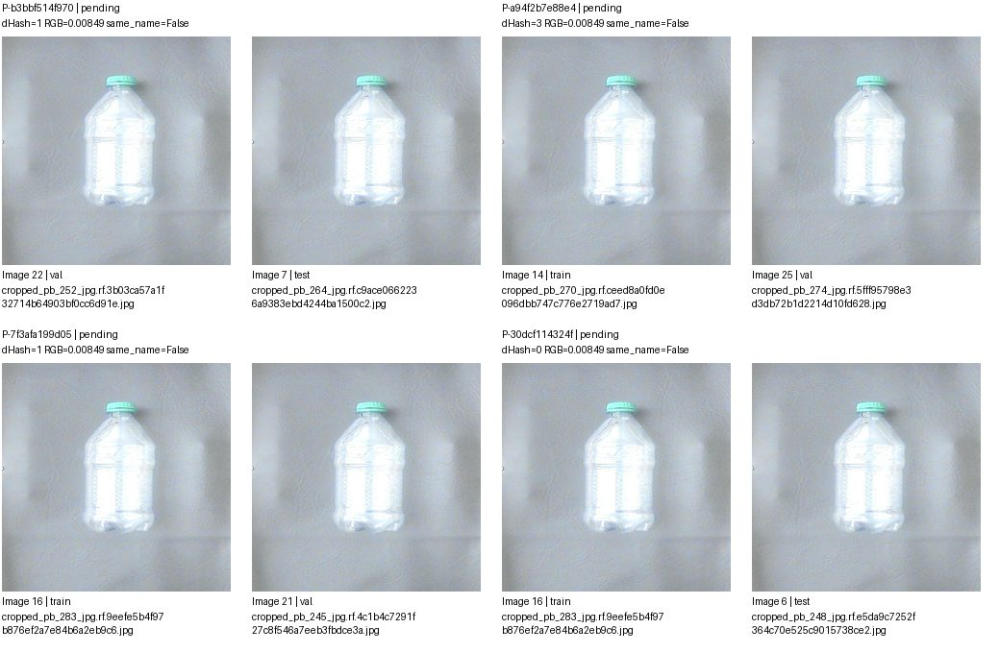

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-b3bbf514f970,images/val/cropped_pb_252_jpg.rf.3b03ca57a1f32714b64903bf0cc6d91e.jpg,images/test/cropped_pb_264_jpg.rf.c9ace0662236a9383ebd4244ba1500c2.jpg,pending,
P-a94f2b7e88e4,images/train/cropped_pb_270_jpg.rf.ceed8a0fd0e096dbb747c776e2719ad7.jpg,images/val/cropped_pb_274_jpg.rf.5fff95798e3d3db72b1d2214d10fd628.jpg,pending,
P-7f3afa199d05,images/train/cropped_pb_283_jpg.rf.9eefe5b4f97b876ef2a7e84b6a2eb9c6.jpg,images/val/cropped_pb_245_jpg.rf.4c1b4c7291f27c8f546a7eeb3fbdce3a.jpg,pending,
P-30dcf114324f,images/train/cropped_pb_283_jpg.rf.9eefe5b4f97b876ef2a7e84b6a2eb9c6.jpg,images/test/cropped_pb_248_jpg.rf.e5da9c7252f364c70e525c9015738ce2.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 104/166 G-947b2d97d667 | 26 ảnh, 207 cặp
Split: {'test': 7, 'train': 9, 'val': 10}
Quyết định: {'pending': 207}
Ảnh trang None/5; cặp trang 11/52. Nhóm liên thông không phải kết luận trùng.


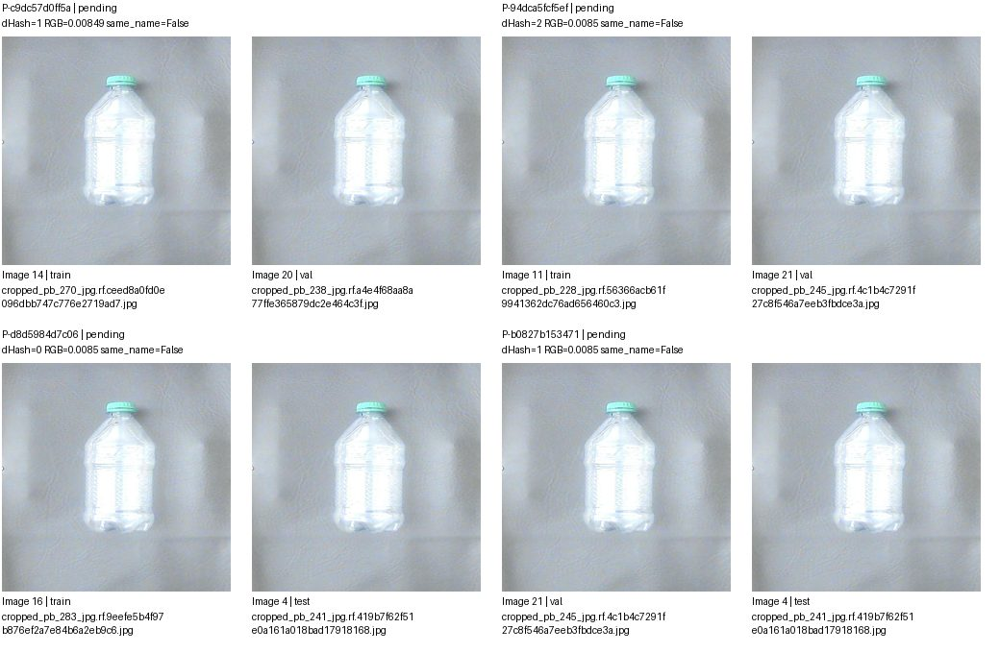

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-c9dc57d0ff5a,images/train/cropped_pb_270_jpg.rf.ceed8a0fd0e096dbb747c776e2719ad7.jpg,images/val/cropped_pb_238_jpg.rf.a4e4f68aa8a77ffe365879dc2e464c3f.jpg,pending,
P-94dca5fcf5ef,images/train/cropped_pb_228_jpg.rf.56366acb61f9941362dc76ad656460c3.jpg,images/val/cropped_pb_245_jpg.rf.4c1b4c7291f27c8f546a7eeb3fbdce3a.jpg,pending,
P-d8d5984d7c06,images/train/cropped_pb_283_jpg.rf.9eefe5b4f97b876ef2a7e84b6a2eb9c6.jpg,images/test/cropped_pb_241_jpg.rf.419b7f62f51e0a161a018bad17918168.jpg,pending,
P-b0827b153471,images/val/cropped_pb_245_jpg.rf.4c1b4c7291f27c8f546a7eeb3fbdce3a.jpg,images/test/cropped_pb_241_jpg.rf.419b7f62f51e0a161a018bad17918168.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 104/166 G-947b2d97d667 | 26 ảnh, 207 cặp
Split: {'test': 7, 'train': 9, 'val': 10}
Quyết định: {'pending': 207}
Ảnh trang None/5; cặp trang 12/52. Nhóm liên thông không phải kết luận trùng.


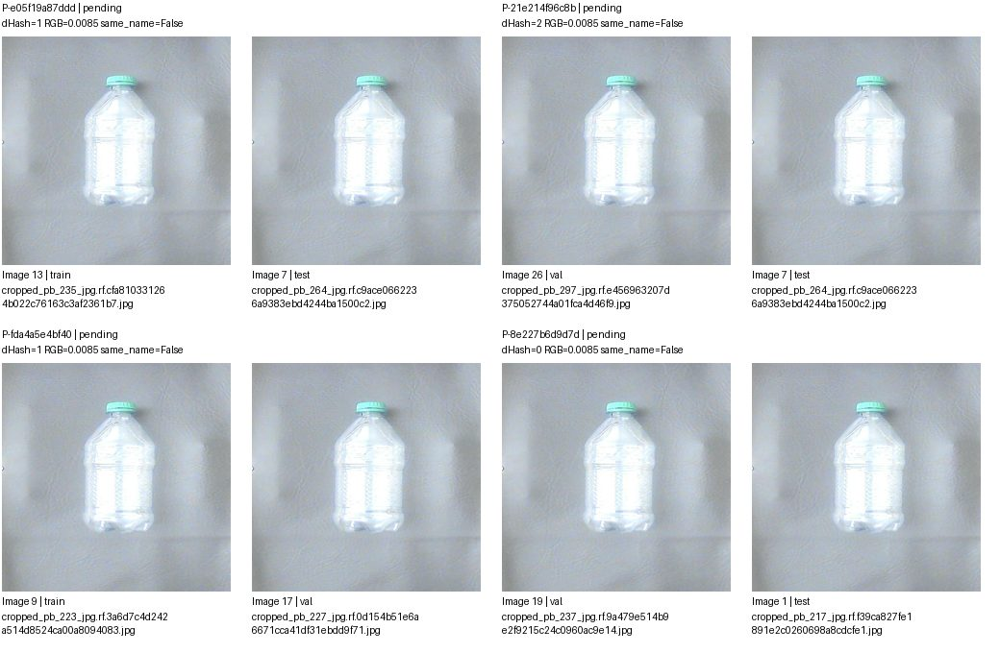

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-e05f19a87ddd,images/train/cropped_pb_235_jpg.rf.cfa810331264b022c76163c3af2361b7.jpg,images/test/cropped_pb_264_jpg.rf.c9ace0662236a9383ebd4244ba1500c2.jpg,pending,
P-21e214f96c8b,images/val/cropped_pb_297_jpg.rf.e456963207d375052744a01fca4d46f9.jpg,images/test/cropped_pb_264_jpg.rf.c9ace0662236a9383ebd4244ba1500c2.jpg,pending,
P-fda4a5e4bf40,images/train/cropped_pb_223_jpg.rf.3a6d7c4d242a514d8524ca00a8094083.jpg,images/val/cropped_pb_227_jpg.rf.0d154b51e6a6671cca41df31ebdd9f71.jpg,pending,
P-8e227b6d9d7d,images/val/cropped_pb_237_jpg.rf.9a479e514b9e2f9215c24c0960ac9e14.jpg,images/test/cropped_pb_217_jpg.rf.f39ca827fe1891e2c0260698a8cdcfe1.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 104/166 G-947b2d97d667 | 26 ảnh, 207 cặp
Split: {'test': 7, 'train': 9, 'val': 10}
Quyết định: {'pending': 207}
Ảnh trang None/5; cặp trang 13/52. Nhóm liên thông không phải kết luận trùng.


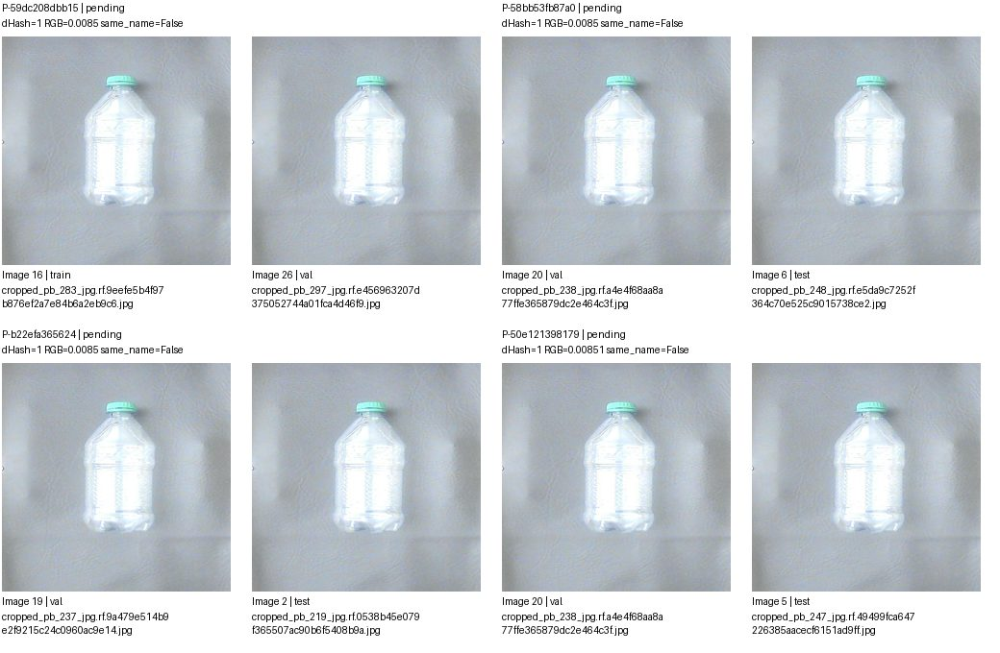

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-59dc208dbb15,images/train/cropped_pb_283_jpg.rf.9eefe5b4f97b876ef2a7e84b6a2eb9c6.jpg,images/val/cropped_pb_297_jpg.rf.e456963207d375052744a01fca4d46f9.jpg,pending,
P-58bb53fb87a0,images/val/cropped_pb_238_jpg.rf.a4e4f68aa8a77ffe365879dc2e464c3f.jpg,images/test/cropped_pb_248_jpg.rf.e5da9c7252f364c70e525c9015738ce2.jpg,pending,
P-b22efa365624,images/val/cropped_pb_237_jpg.rf.9a479e514b9e2f9215c24c0960ac9e14.jpg,images/test/cropped_pb_219_jpg.rf.0538b45e079f365507ac90b6f5408b9a.jpg,pending,
P-50e121398179,images/val/cropped_pb_238_jpg.rf.a4e4f68aa8a77ffe365879dc2e464c3f.jpg,images/test/cropped_pb_247_jpg.rf.49499fca647226385aacecf6151ad9ff.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 104/166 G-947b2d97d667 | 26 ảnh, 207 cặp
Split: {'test': 7, 'train': 9, 'val': 10}
Quyết định: {'pending': 207}
Ảnh trang None/5; cặp trang 14/52. Nhóm liên thông không phải kết luận trùng.


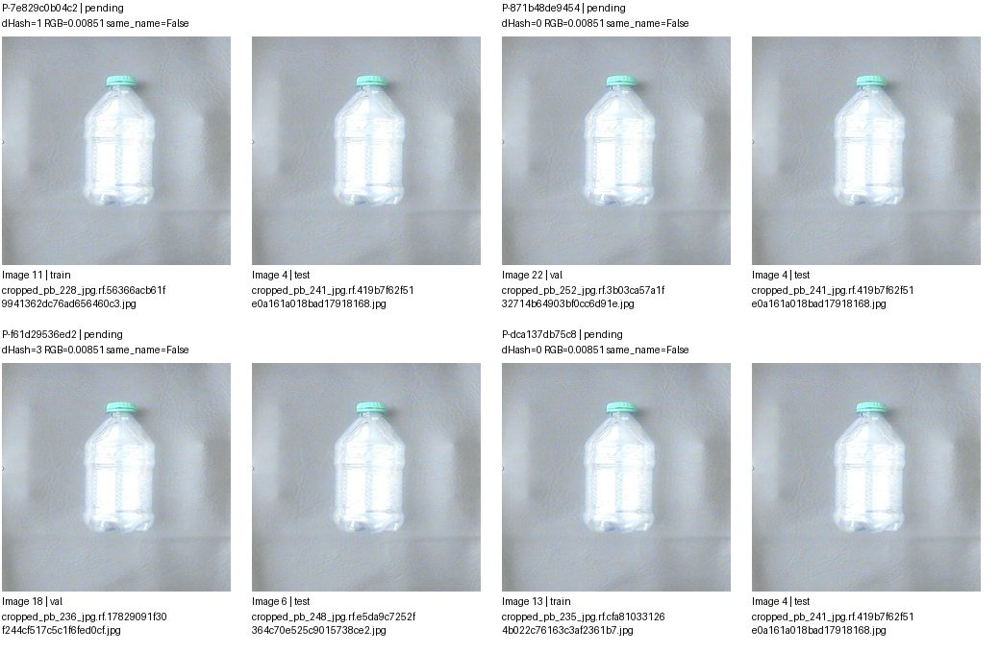

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-7e829c0b04c2,images/train/cropped_pb_228_jpg.rf.56366acb61f9941362dc76ad656460c3.jpg,images/test/cropped_pb_241_jpg.rf.419b7f62f51e0a161a018bad17918168.jpg,pending,
P-871b48de9454,images/val/cropped_pb_252_jpg.rf.3b03ca57a1f32714b64903bf0cc6d91e.jpg,images/test/cropped_pb_241_jpg.rf.419b7f62f51e0a161a018bad17918168.jpg,pending,
P-f61d29536ed2,images/val/cropped_pb_236_jpg.rf.17829091f30f244cf517c5c1f6fed0cf.jpg,images/test/cropped_pb_248_jpg.rf.e5da9c7252f364c70e525c9015738ce2.jpg,pending,
P-dca137db75c8,images/train/cropped_pb_235_jpg.rf.cfa810331264b022c76163c3af2361b7.jpg,images/test/cropped_pb_241_jpg.rf.419b7f62f51e0a161a018bad17918168.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 104/166 G-947b2d97d667 | 26 ảnh, 207 cặp
Split: {'test': 7, 'train': 9, 'val': 10}
Quyết định: {'pending': 207}
Ảnh trang None/5; cặp trang 15/52. Nhóm liên thông không phải kết luận trùng.


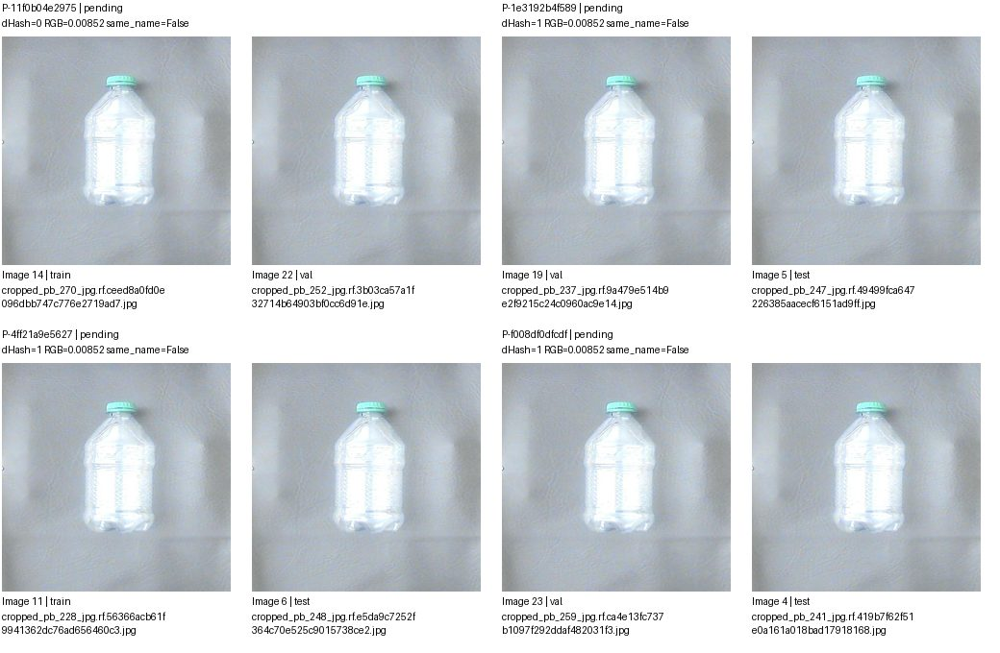

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-11f0b04e2975,images/train/cropped_pb_270_jpg.rf.ceed8a0fd0e096dbb747c776e2719ad7.jpg,images/val/cropped_pb_252_jpg.rf.3b03ca57a1f32714b64903bf0cc6d91e.jpg,pending,
P-1e3192b4f589,images/val/cropped_pb_237_jpg.rf.9a479e514b9e2f9215c24c0960ac9e14.jpg,images/test/cropped_pb_247_jpg.rf.49499fca647226385aacecf6151ad9ff.jpg,pending,
P-4ff21a9e5627,images/train/cropped_pb_228_jpg.rf.56366acb61f9941362dc76ad656460c3.jpg,images/test/cropped_pb_248_jpg.rf.e5da9c7252f364c70e525c9015738ce2.jpg,pending,
P-f008df0dfcdf,images/val/cropped_pb_259_jpg.rf.ca4e13fc737b1097f292ddaf482031f3.jpg,images/test/cropped_pb_241_jpg.rf.419b7f62f51e0a161a018bad17918168.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 104/166 G-947b2d97d667 | 26 ảnh, 207 cặp
Split: {'test': 7, 'train': 9, 'val': 10}
Quyết định: {'pending': 207}
Ảnh trang None/5; cặp trang 16/52. Nhóm liên thông không phải kết luận trùng.


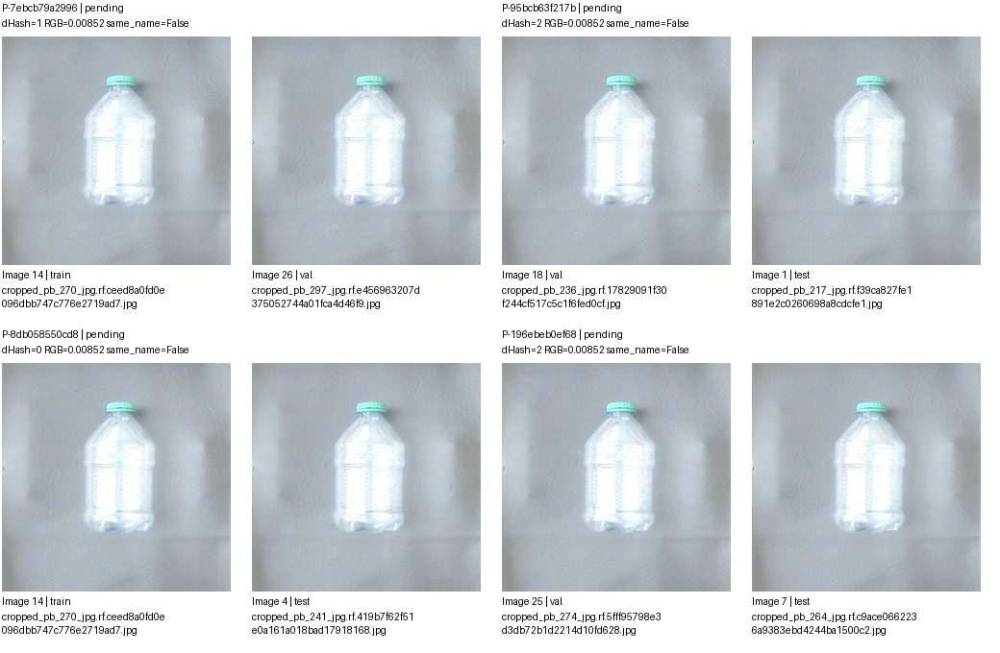

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-7ebcb79a2996,images/train/cropped_pb_270_jpg.rf.ceed8a0fd0e096dbb747c776e2719ad7.jpg,images/val/cropped_pb_297_jpg.rf.e456963207d375052744a01fca4d46f9.jpg,pending,
P-95bcb63f217b,images/val/cropped_pb_236_jpg.rf.17829091f30f244cf517c5c1f6fed0cf.jpg,images/test/cropped_pb_217_jpg.rf.f39ca827fe1891e2c0260698a8cdcfe1.jpg,pending,
P-8db058550cd8,images/train/cropped_pb_270_jpg.rf.ceed8a0fd0e096dbb747c776e2719ad7.jpg,images/test/cropped_pb_241_jpg.rf.419b7f62f51e0a161a018bad17918168.jpg,pending,
P-196ebeb0ef68,images/val/cropped_pb_274_jpg.rf.5fff95798e3d3db72b1d2214d10fd628.jpg,images/test/cropped_pb_264_jpg.rf.c9ace0662236a9383ebd4244ba1500c2.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 104/166 G-947b2d97d667 | 26 ảnh, 207 cặp
Split: {'test': 7, 'train': 9, 'val': 10}
Quyết định: {'pending': 207}
Ảnh trang None/5; cặp trang 17/52. Nhóm liên thông không phải kết luận trùng.


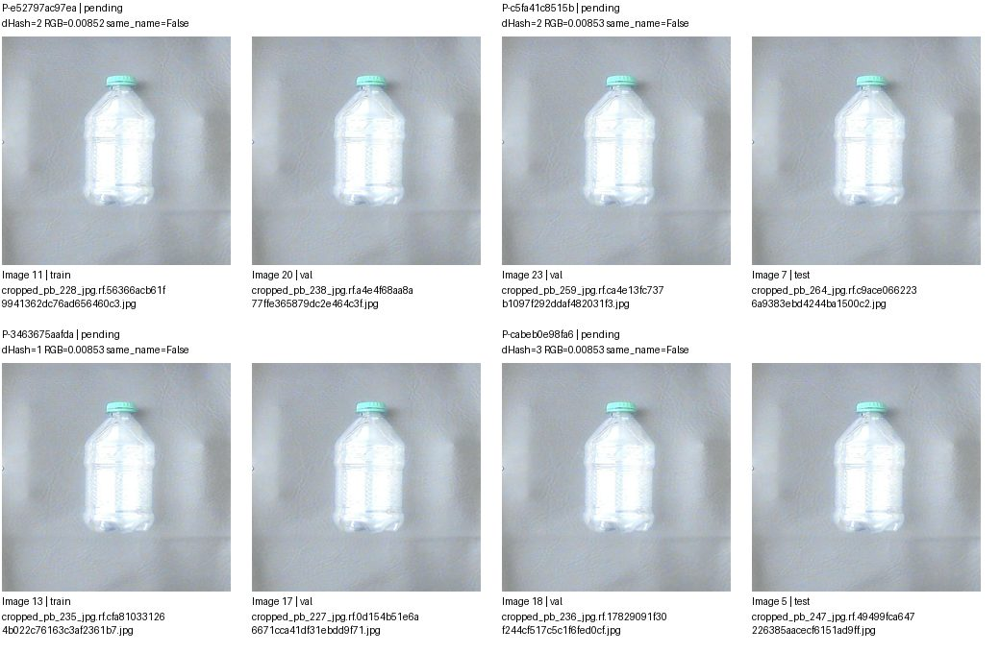

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-e52797ac97ea,images/train/cropped_pb_228_jpg.rf.56366acb61f9941362dc76ad656460c3.jpg,images/val/cropped_pb_238_jpg.rf.a4e4f68aa8a77ffe365879dc2e464c3f.jpg,pending,
P-c5fa41c8515b,images/val/cropped_pb_259_jpg.rf.ca4e13fc737b1097f292ddaf482031f3.jpg,images/test/cropped_pb_264_jpg.rf.c9ace0662236a9383ebd4244ba1500c2.jpg,pending,
P-3463675aafda,images/train/cropped_pb_235_jpg.rf.cfa810331264b022c76163c3af2361b7.jpg,images/val/cropped_pb_227_jpg.rf.0d154b51e6a6671cca41df31ebdd9f71.jpg,pending,
P-cabeb0e98fa6,images/val/cropped_pb_236_jpg.rf.17829091f30f244cf517c5c1f6fed0cf.jpg,images/test/cropped_pb_247_jpg.rf.49499fca647226385aacecf6151ad9ff.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 104/166 G-947b2d97d667 | 26 ảnh, 207 cặp
Split: {'test': 7, 'train': 9, 'val': 10}
Quyết định: {'pending': 207}
Ảnh trang None/5; cặp trang 18/52. Nhóm liên thông không phải kết luận trùng.


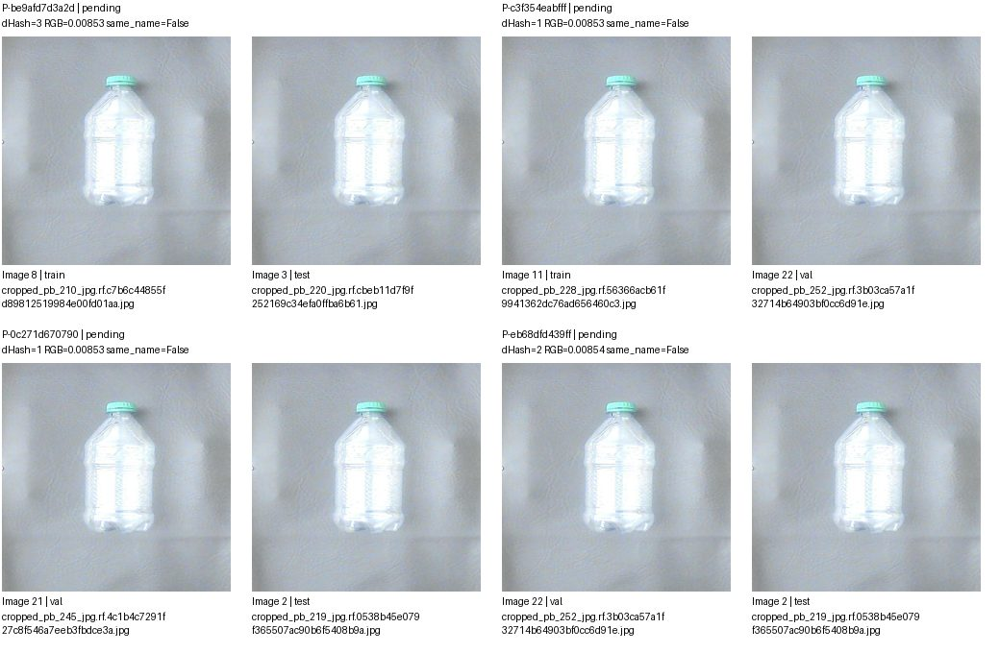

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-be9afd7d3a2d,images/train/cropped_pb_210_jpg.rf.c7b6c44855fd89812519984e00fd01aa.jpg,images/test/cropped_pb_220_jpg.rf.cbeb11d7f9f252169c34efa0ffba6b61.jpg,pending,
P-c3f354eabfff,images/train/cropped_pb_228_jpg.rf.56366acb61f9941362dc76ad656460c3.jpg,images/val/cropped_pb_252_jpg.rf.3b03ca57a1f32714b64903bf0cc6d91e.jpg,pending,
P-0c271d670790,images/val/cropped_pb_245_jpg.rf.4c1b4c7291f27c8f546a7eeb3fbdce3a.jpg,images/test/cropped_pb_219_jpg.rf.0538b45e079f365507ac90b6f5408b9a.jpg,pending,
P-eb68dfd439ff,images/val/cropped_pb_252_jpg.rf.3b03ca57a1f32714b64903bf0cc6d91e.jpg,images/test/cropped_pb_219_jpg.rf.0538b45e079f365507ac90b6f5408b9a.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 104/166 G-947b2d97d667 | 26 ảnh, 207 cặp
Split: {'test': 7, 'train': 9, 'val': 10}
Quyết định: {'pending': 207}
Ảnh trang None/5; cặp trang 19/52. Nhóm liên thông không phải kết luận trùng.


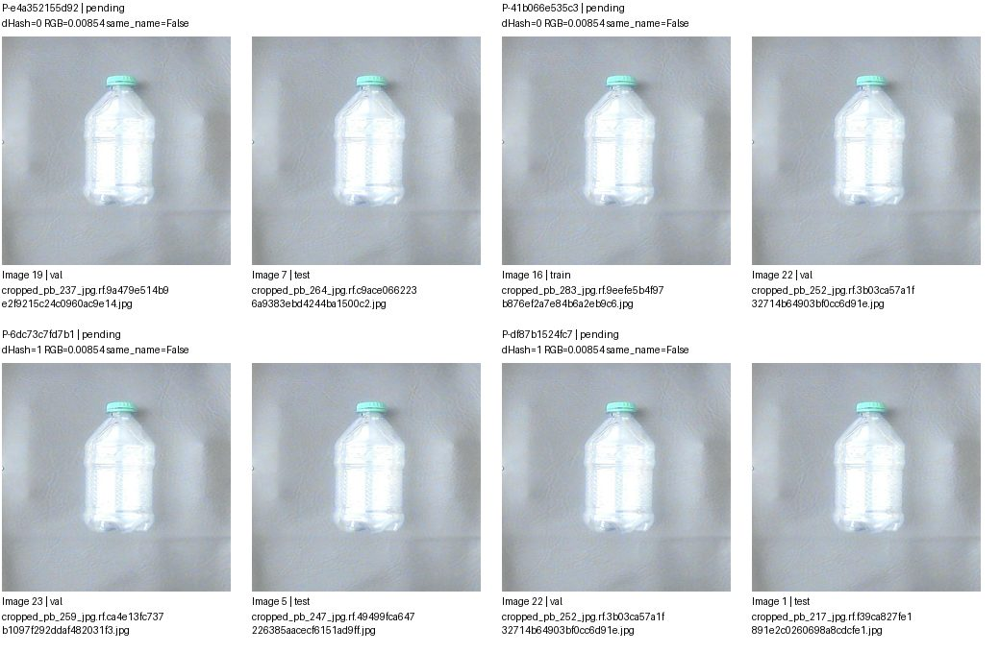

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-e4a352155d92,images/val/cropped_pb_237_jpg.rf.9a479e514b9e2f9215c24c0960ac9e14.jpg,images/test/cropped_pb_264_jpg.rf.c9ace0662236a9383ebd4244ba1500c2.jpg,pending,
P-41b066e535c3,images/train/cropped_pb_283_jpg.rf.9eefe5b4f97b876ef2a7e84b6a2eb9c6.jpg,images/val/cropped_pb_252_jpg.rf.3b03ca57a1f32714b64903bf0cc6d91e.jpg,pending,
P-6dc73c7fd7b1,images/val/cropped_pb_259_jpg.rf.ca4e13fc737b1097f292ddaf482031f3.jpg,images/test/cropped_pb_247_jpg.rf.49499fca647226385aacecf6151ad9ff.jpg,pending,
P-df87b1524fc7,images/val/cropped_pb_252_jpg.rf.3b03ca57a1f32714b64903bf0cc6d91e.jpg,images/test/cropped_pb_217_jpg.rf.f39ca827fe1891e2c0260698a8cdcfe1.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 104/166 G-947b2d97d667 | 26 ảnh, 207 cặp
Split: {'test': 7, 'train': 9, 'val': 10}
Quyết định: {'pending': 207}
Ảnh trang None/5; cặp trang 20/52. Nhóm liên thông không phải kết luận trùng.


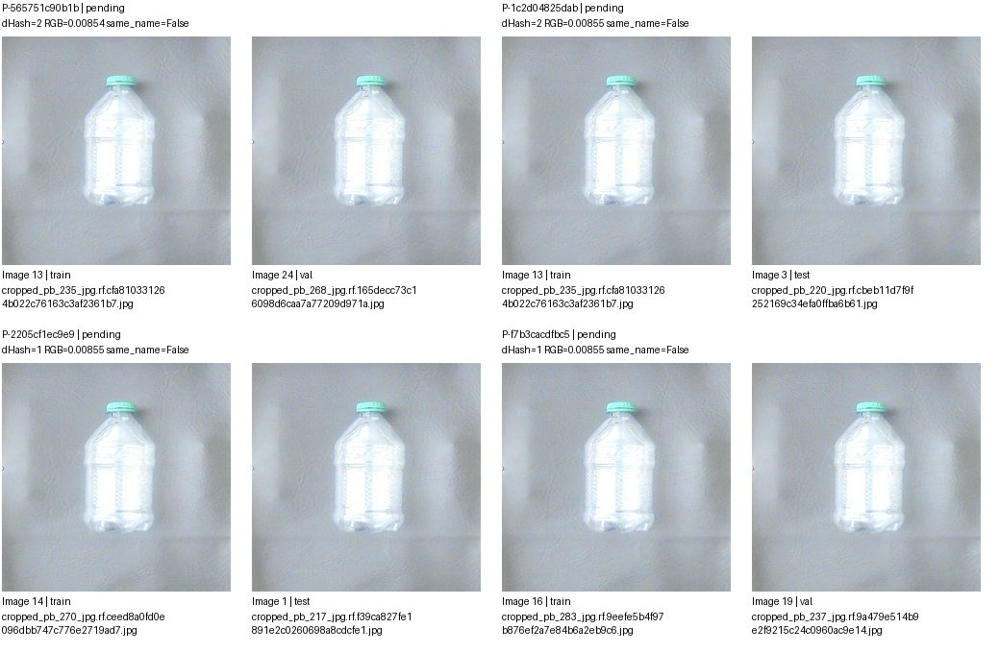

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-565751c90b1b,images/train/cropped_pb_235_jpg.rf.cfa810331264b022c76163c3af2361b7.jpg,images/val/cropped_pb_268_jpg.rf.165decc73c16098d6caa7a77209d971a.jpg,pending,
P-1c2d04825dab,images/train/cropped_pb_235_jpg.rf.cfa810331264b022c76163c3af2361b7.jpg,images/test/cropped_pb_220_jpg.rf.cbeb11d7f9f252169c34efa0ffba6b61.jpg,pending,
P-2205cf1ec9e9,images/train/cropped_pb_270_jpg.rf.ceed8a0fd0e096dbb747c776e2719ad7.jpg,images/test/cropped_pb_217_jpg.rf.f39ca827fe1891e2c0260698a8cdcfe1.jpg,pending,
P-f7b3cacdfbc5,images/train/cropped_pb_283_jpg.rf.9eefe5b4f97b876ef2a7e84b6a2eb9c6.jpg,images/val/cropped_pb_237_jpg.rf.9a479e514b9e2f9215c24c0960ac9e14.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 104/166 G-947b2d97d667 | 26 ảnh, 207 cặp
Split: {'test': 7, 'train': 9, 'val': 10}
Quyết định: {'pending': 207}
Ảnh trang None/5; cặp trang 21/52. Nhóm liên thông không phải kết luận trùng.


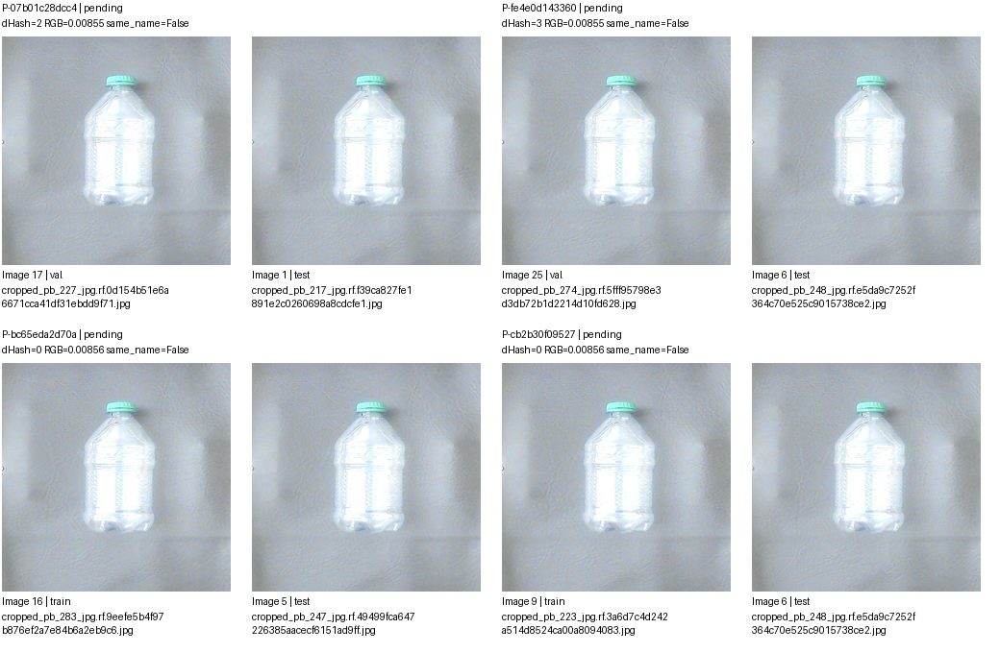

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-07b01c28dcc4,images/val/cropped_pb_227_jpg.rf.0d154b51e6a6671cca41df31ebdd9f71.jpg,images/test/cropped_pb_217_jpg.rf.f39ca827fe1891e2c0260698a8cdcfe1.jpg,pending,
P-fe4e0d143360,images/val/cropped_pb_274_jpg.rf.5fff95798e3d3db72b1d2214d10fd628.jpg,images/test/cropped_pb_248_jpg.rf.e5da9c7252f364c70e525c9015738ce2.jpg,pending,
P-bc65eda2d70a,images/train/cropped_pb_283_jpg.rf.9eefe5b4f97b876ef2a7e84b6a2eb9c6.jpg,images/test/cropped_pb_247_jpg.rf.49499fca647226385aacecf6151ad9ff.jpg,pending,
P-cb2b30f09527,images/train/cropped_pb_223_jpg.rf.3a6d7c4d242a514d8524ca00a8094083.jpg,images/test/cropped_pb_248_jpg.rf.e5da9c7252f364c70e525c9015738ce2.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 104/166 G-947b2d97d667 | 26 ảnh, 207 cặp
Split: {'test': 7, 'train': 9, 'val': 10}
Quyết định: {'pending': 207}
Ảnh trang None/5; cặp trang 22/52. Nhóm liên thông không phải kết luận trùng.


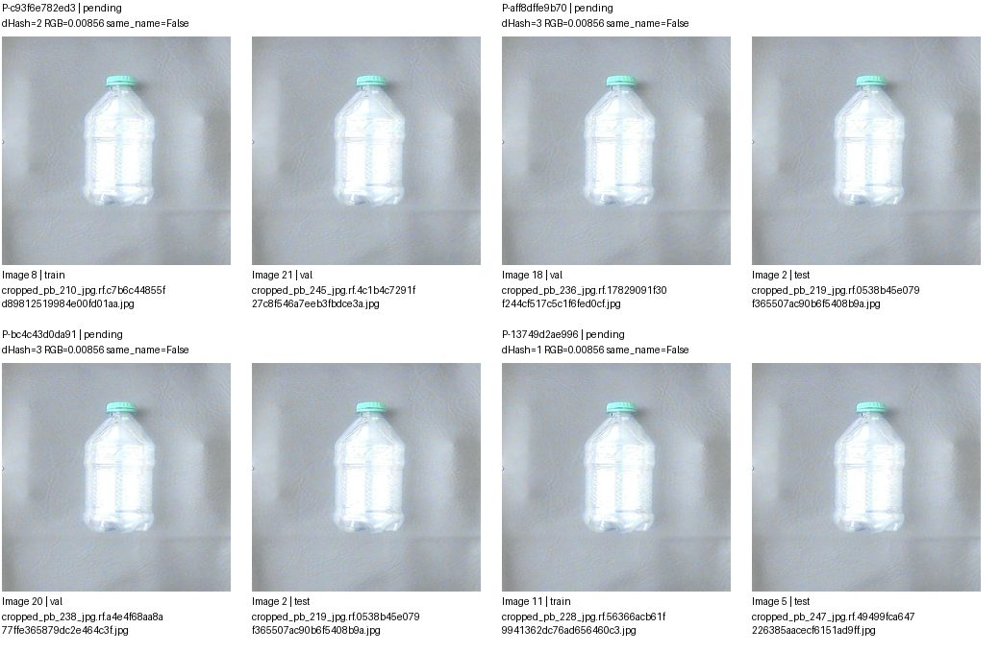

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-c93f6e782ed3,images/train/cropped_pb_210_jpg.rf.c7b6c44855fd89812519984e00fd01aa.jpg,images/val/cropped_pb_245_jpg.rf.4c1b4c7291f27c8f546a7eeb3fbdce3a.jpg,pending,
P-aff8dffe9b70,images/val/cropped_pb_236_jpg.rf.17829091f30f244cf517c5c1f6fed0cf.jpg,images/test/cropped_pb_219_jpg.rf.0538b45e079f365507ac90b6f5408b9a.jpg,pending,
P-bc4c43d0da91,images/val/cropped_pb_238_jpg.rf.a4e4f68aa8a77ffe365879dc2e464c3f.jpg,images/test/cropped_pb_219_jpg.rf.0538b45e079f365507ac90b6f5408b9a.jpg,pending,
P-13749d2ae996,images/train/cropped_pb_228_jpg.rf.56366acb61f9941362dc76ad656460c3.jpg,images/test/cropped_pb_247_jpg.rf.49499fca647226385aacecf6151ad9ff.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 104/166 G-947b2d97d667 | 26 ảnh, 207 cặp
Split: {'test': 7, 'train': 9, 'val': 10}
Quyết định: {'pending': 207}
Ảnh trang None/5; cặp trang 23/52. Nhóm liên thông không phải kết luận trùng.


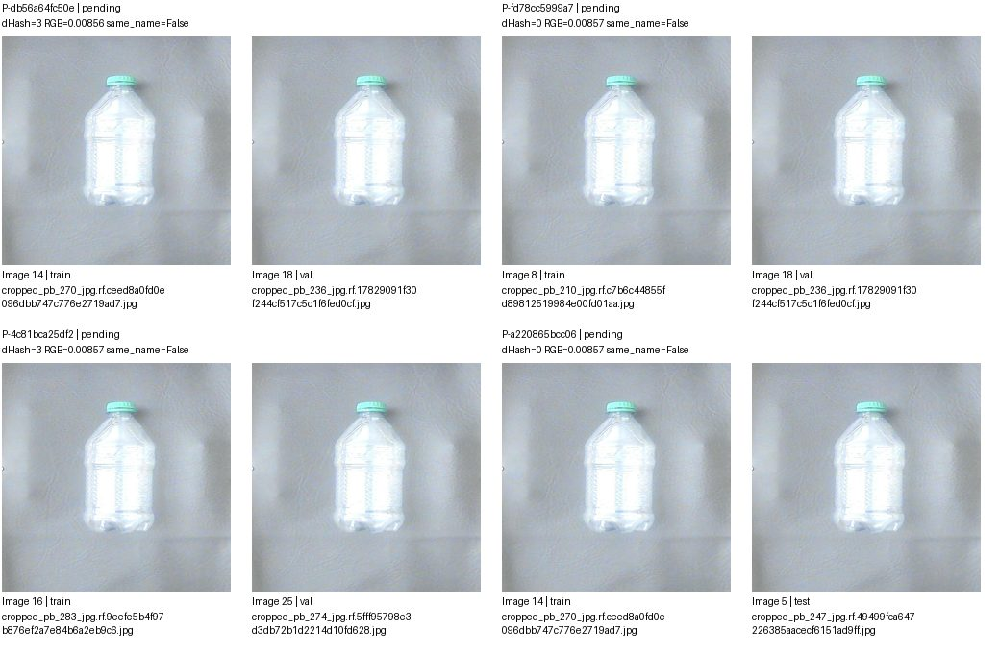

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-db56a64fc50e,images/train/cropped_pb_270_jpg.rf.ceed8a0fd0e096dbb747c776e2719ad7.jpg,images/val/cropped_pb_236_jpg.rf.17829091f30f244cf517c5c1f6fed0cf.jpg,pending,
P-fd78cc5999a7,images/train/cropped_pb_210_jpg.rf.c7b6c44855fd89812519984e00fd01aa.jpg,images/val/cropped_pb_236_jpg.rf.17829091f30f244cf517c5c1f6fed0cf.jpg,pending,
P-4c81bca25df2,images/train/cropped_pb_283_jpg.rf.9eefe5b4f97b876ef2a7e84b6a2eb9c6.jpg,images/val/cropped_pb_274_jpg.rf.5fff95798e3d3db72b1d2214d10fd628.jpg,pending,
P-a220865bcc06,images/train/cropped_pb_270_jpg.rf.ceed8a0fd0e096dbb747c776e2719ad7.jpg,images/test/cropped_pb_247_jpg.rf.49499fca647226385aacecf6151ad9ff.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 104/166 G-947b2d97d667 | 26 ảnh, 207 cặp
Split: {'test': 7, 'train': 9, 'val': 10}
Quyết định: {'pending': 207}
Ảnh trang None/5; cặp trang 24/52. Nhóm liên thông không phải kết luận trùng.


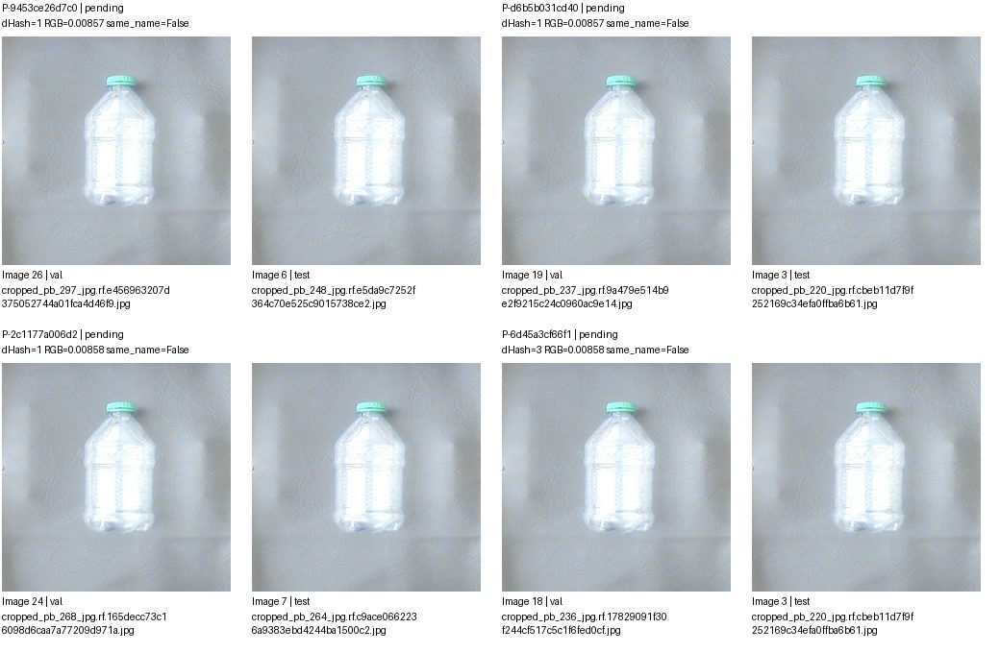

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-9453ce26d7c0,images/val/cropped_pb_297_jpg.rf.e456963207d375052744a01fca4d46f9.jpg,images/test/cropped_pb_248_jpg.rf.e5da9c7252f364c70e525c9015738ce2.jpg,pending,
P-d6b5b031cd40,images/val/cropped_pb_237_jpg.rf.9a479e514b9e2f9215c24c0960ac9e14.jpg,images/test/cropped_pb_220_jpg.rf.cbeb11d7f9f252169c34efa0ffba6b61.jpg,pending,
P-2c1177a006d2,images/val/cropped_pb_268_jpg.rf.165decc73c16098d6caa7a77209d971a.jpg,images/test/cropped_pb_264_jpg.rf.c9ace0662236a9383ebd4244ba1500c2.jpg,pending,
P-6d45a3cf66f1,images/val/cropped_pb_236_jpg.rf.17829091f30f244cf517c5c1f6fed0cf.jpg,images/test/cropped_pb_220_jpg.rf.cbeb11d7f9f252169c34efa0ffba6b61.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 104/166 G-947b2d97d667 | 26 ảnh, 207 cặp
Split: {'test': 7, 'train': 9, 'val': 10}
Quyết định: {'pending': 207}
Ảnh trang None/5; cặp trang 25/52. Nhóm liên thông không phải kết luận trùng.


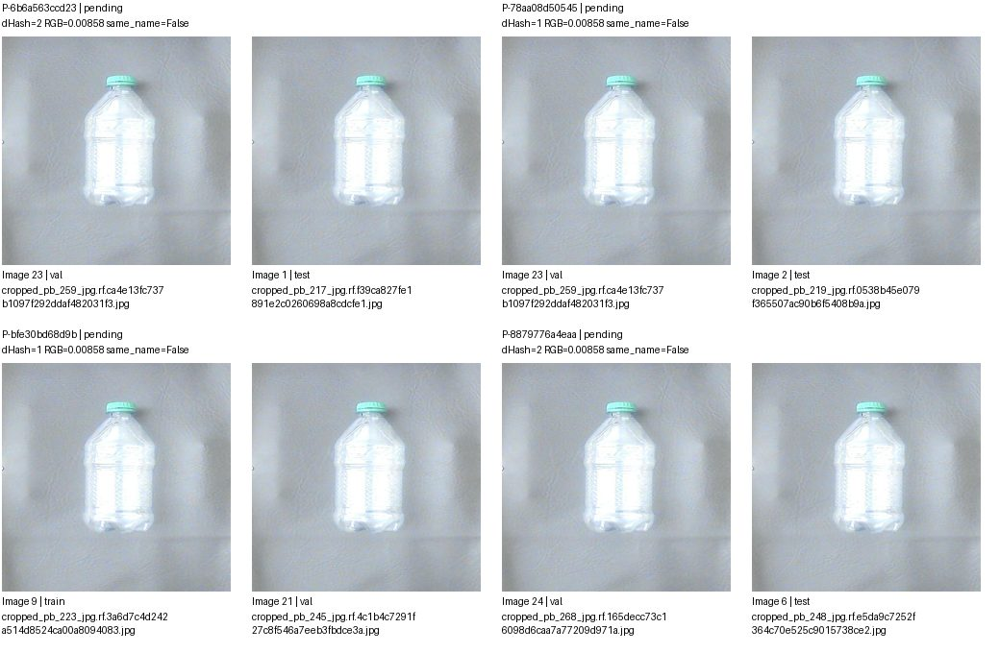

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-6b6a563ccd23,images/val/cropped_pb_259_jpg.rf.ca4e13fc737b1097f292ddaf482031f3.jpg,images/test/cropped_pb_217_jpg.rf.f39ca827fe1891e2c0260698a8cdcfe1.jpg,pending,
P-78aa08d50545,images/val/cropped_pb_259_jpg.rf.ca4e13fc737b1097f292ddaf482031f3.jpg,images/test/cropped_pb_219_jpg.rf.0538b45e079f365507ac90b6f5408b9a.jpg,pending,
P-bfe30bd68d9b,images/train/cropped_pb_223_jpg.rf.3a6d7c4d242a514d8524ca00a8094083.jpg,images/val/cropped_pb_245_jpg.rf.4c1b4c7291f27c8f546a7eeb3fbdce3a.jpg,pending,
P-8879776a4eaa,images/val/cropped_pb_268_jpg.rf.165decc73c16098d6caa7a77209d971a.jpg,images/test/cropped_pb_248_jpg.rf.e5da9c7252f364c70e525c9015738ce2.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 104/166 G-947b2d97d667 | 26 ảnh, 207 cặp
Split: {'test': 7, 'train': 9, 'val': 10}
Quyết định: {'pending': 207}
Ảnh trang None/5; cặp trang 26/52. Nhóm liên thông không phải kết luận trùng.


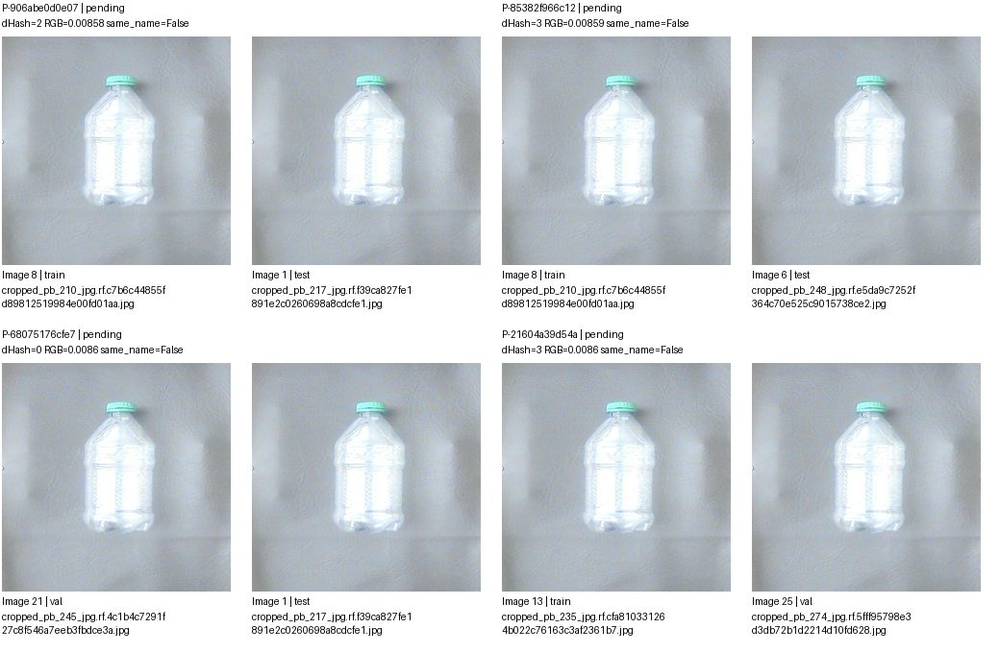

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-906abe0d0e07,images/train/cropped_pb_210_jpg.rf.c7b6c44855fd89812519984e00fd01aa.jpg,images/test/cropped_pb_217_jpg.rf.f39ca827fe1891e2c0260698a8cdcfe1.jpg,pending,
P-85382f966c12,images/train/cropped_pb_210_jpg.rf.c7b6c44855fd89812519984e00fd01aa.jpg,images/test/cropped_pb_248_jpg.rf.e5da9c7252f364c70e525c9015738ce2.jpg,pending,
P-68075176cfe7,images/val/cropped_pb_245_jpg.rf.4c1b4c7291f27c8f546a7eeb3fbdce3a.jpg,images/test/cropped_pb_217_jpg.rf.f39ca827fe1891e2c0260698a8cdcfe1.jpg,pending,
P-21604a39d54a,images/train/cropped_pb_235_jpg.rf.cfa810331264b022c76163c3af2361b7.jpg,images/val/cropped_pb_274_jpg.rf.5fff95798e3d3db72b1d2214d10fd628.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 104/166 G-947b2d97d667 | 26 ảnh, 207 cặp
Split: {'test': 7, 'train': 9, 'val': 10}
Quyết định: {'pending': 207}
Ảnh trang None/5; cặp trang 27/52. Nhóm liên thông không phải kết luận trùng.


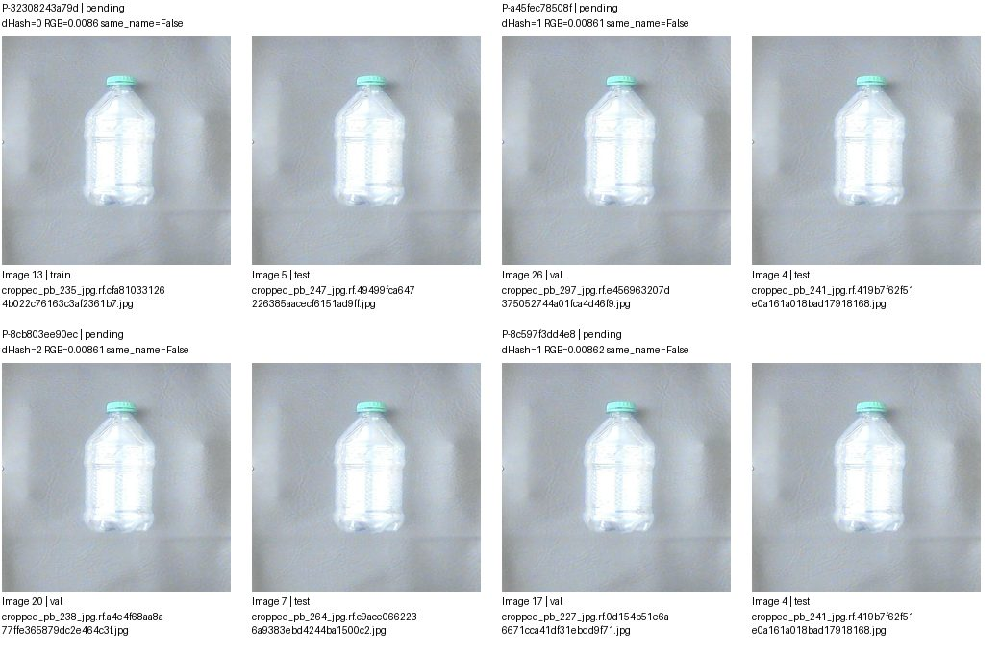

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-32308243a79d,images/train/cropped_pb_235_jpg.rf.cfa810331264b022c76163c3af2361b7.jpg,images/test/cropped_pb_247_jpg.rf.49499fca647226385aacecf6151ad9ff.jpg,pending,
P-a45fec78508f,images/val/cropped_pb_297_jpg.rf.e456963207d375052744a01fca4d46f9.jpg,images/test/cropped_pb_241_jpg.rf.419b7f62f51e0a161a018bad17918168.jpg,pending,
P-8cb803ee90ec,images/val/cropped_pb_238_jpg.rf.a4e4f68aa8a77ffe365879dc2e464c3f.jpg,images/test/cropped_pb_264_jpg.rf.c9ace0662236a9383ebd4244ba1500c2.jpg,pending,
P-8c597f3dd4e8,images/val/cropped_pb_227_jpg.rf.0d154b51e6a6671cca41df31ebdd9f71.jpg,images/test/cropped_pb_241_jpg.rf.419b7f62f51e0a161a018bad17918168.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 104/166 G-947b2d97d667 | 26 ảnh, 207 cặp
Split: {'test': 7, 'train': 9, 'val': 10}
Quyết định: {'pending': 207}
Ảnh trang None/5; cặp trang 28/52. Nhóm liên thông không phải kết luận trùng.


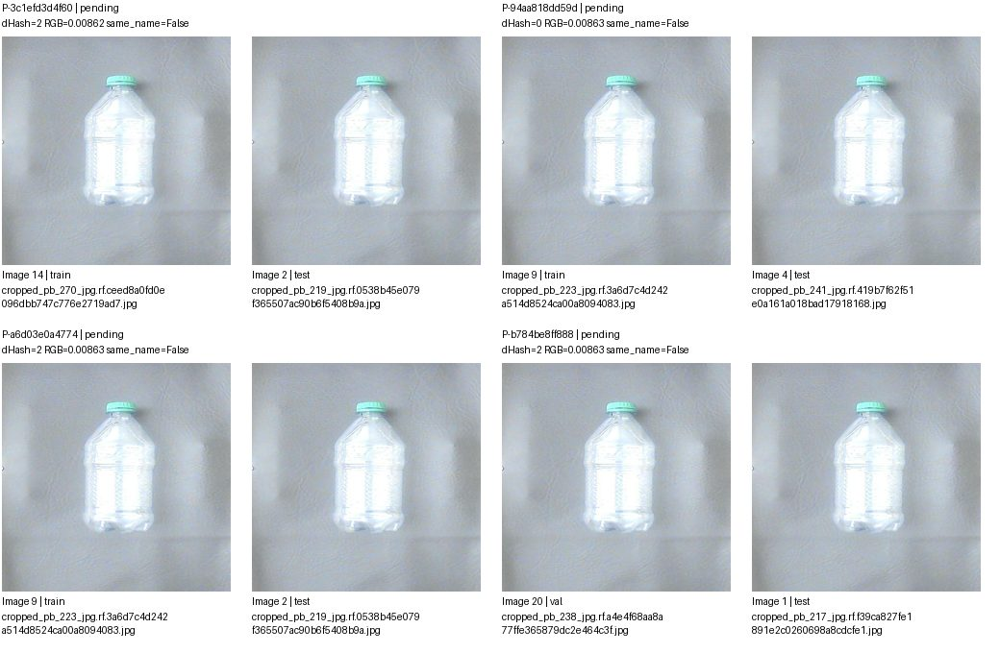

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-3c1efd3d4f60,images/train/cropped_pb_270_jpg.rf.ceed8a0fd0e096dbb747c776e2719ad7.jpg,images/test/cropped_pb_219_jpg.rf.0538b45e079f365507ac90b6f5408b9a.jpg,pending,
P-94aa818dd59d,images/train/cropped_pb_223_jpg.rf.3a6d7c4d242a514d8524ca00a8094083.jpg,images/test/cropped_pb_241_jpg.rf.419b7f62f51e0a161a018bad17918168.jpg,pending,
P-a6d03e0a4774,images/train/cropped_pb_223_jpg.rf.3a6d7c4d242a514d8524ca00a8094083.jpg,images/test/cropped_pb_219_jpg.rf.0538b45e079f365507ac90b6f5408b9a.jpg,pending,
P-b784be8ff888,images/val/cropped_pb_238_jpg.rf.a4e4f68aa8a77ffe365879dc2e464c3f.jpg,images/test/cropped_pb_217_jpg.rf.f39ca827fe1891e2c0260698a8cdcfe1.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 104/166 G-947b2d97d667 | 26 ảnh, 207 cặp
Split: {'test': 7, 'train': 9, 'val': 10}
Quyết định: {'pending': 207}
Ảnh trang None/5; cặp trang 29/52. Nhóm liên thông không phải kết luận trùng.


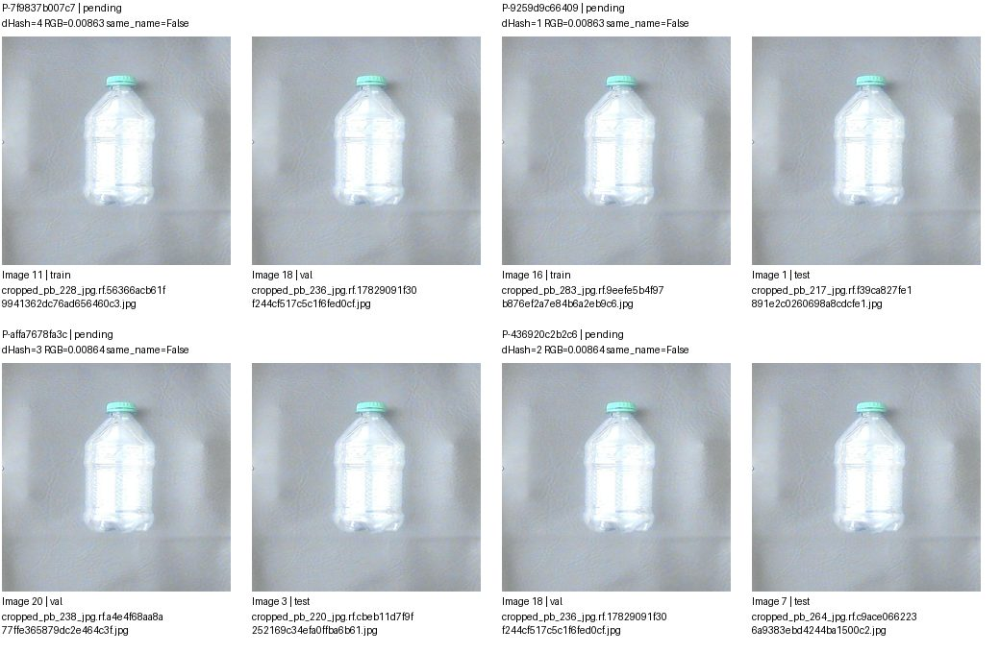

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-7f9837b007c7,images/train/cropped_pb_228_jpg.rf.56366acb61f9941362dc76ad656460c3.jpg,images/val/cropped_pb_236_jpg.rf.17829091f30f244cf517c5c1f6fed0cf.jpg,pending,
P-9259d9c66409,images/train/cropped_pb_283_jpg.rf.9eefe5b4f97b876ef2a7e84b6a2eb9c6.jpg,images/test/cropped_pb_217_jpg.rf.f39ca827fe1891e2c0260698a8cdcfe1.jpg,pending,
P-affa7678fa3c,images/val/cropped_pb_238_jpg.rf.a4e4f68aa8a77ffe365879dc2e464c3f.jpg,images/test/cropped_pb_220_jpg.rf.cbeb11d7f9f252169c34efa0ffba6b61.jpg,pending,
P-436920c2b2c6,images/val/cropped_pb_236_jpg.rf.17829091f30f244cf517c5c1f6fed0cf.jpg,images/test/cropped_pb_264_jpg.rf.c9ace0662236a9383ebd4244ba1500c2.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 104/166 G-947b2d97d667 | 26 ảnh, 207 cặp
Split: {'test': 7, 'train': 9, 'val': 10}
Quyết định: {'pending': 207}
Ảnh trang None/5; cặp trang 30/52. Nhóm liên thông không phải kết luận trùng.


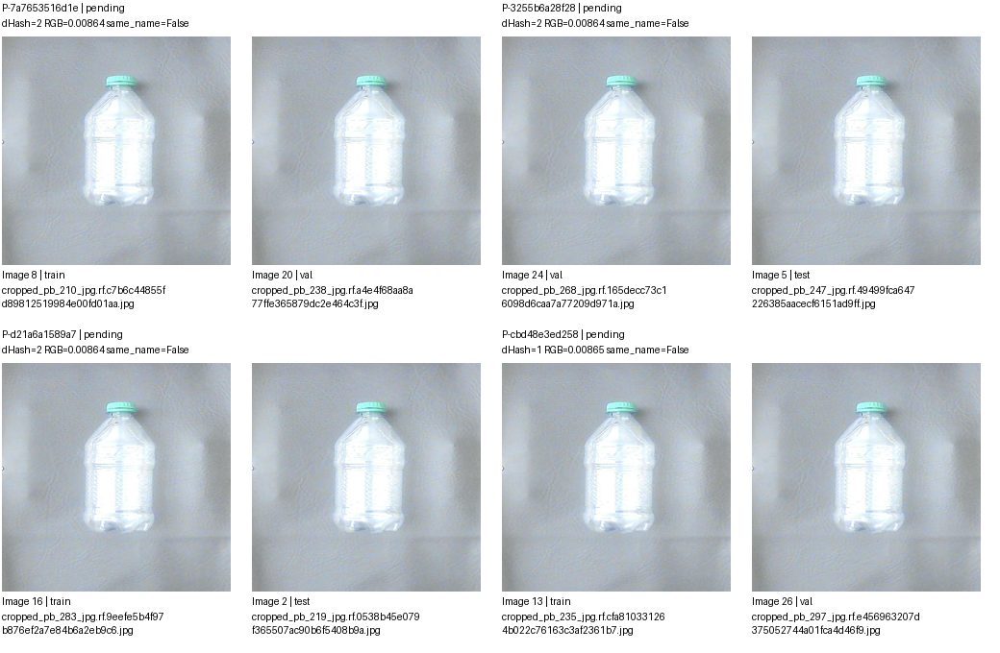

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-7a7653516d1e,images/train/cropped_pb_210_jpg.rf.c7b6c44855fd89812519984e00fd01aa.jpg,images/val/cropped_pb_238_jpg.rf.a4e4f68aa8a77ffe365879dc2e464c3f.jpg,pending,
P-3255b6a28f28,images/val/cropped_pb_268_jpg.rf.165decc73c16098d6caa7a77209d971a.jpg,images/test/cropped_pb_247_jpg.rf.49499fca647226385aacecf6151ad9ff.jpg,pending,
P-d21a6a1589a7,images/train/cropped_pb_283_jpg.rf.9eefe5b4f97b876ef2a7e84b6a2eb9c6.jpg,images/test/cropped_pb_219_jpg.rf.0538b45e079f365507ac90b6f5408b9a.jpg,pending,
P-cbd48e3ed258,images/train/cropped_pb_235_jpg.rf.cfa810331264b022c76163c3af2361b7.jpg,images/val/cropped_pb_297_jpg.rf.e456963207d375052744a01fca4d46f9.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 104/166 G-947b2d97d667 | 26 ảnh, 207 cặp
Split: {'test': 7, 'train': 9, 'val': 10}
Quyết định: {'pending': 207}
Ảnh trang None/5; cặp trang 31/52. Nhóm liên thông không phải kết luận trùng.


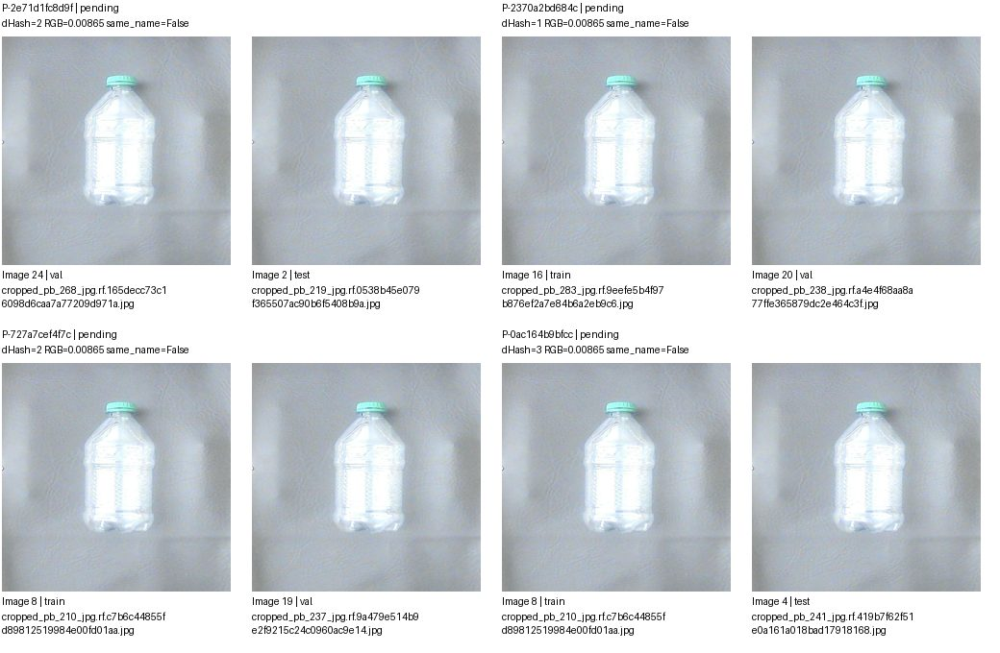

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-2e71d1fc8d9f,images/val/cropped_pb_268_jpg.rf.165decc73c16098d6caa7a77209d971a.jpg,images/test/cropped_pb_219_jpg.rf.0538b45e079f365507ac90b6f5408b9a.jpg,pending,
P-2370a2bd684c,images/train/cropped_pb_283_jpg.rf.9eefe5b4f97b876ef2a7e84b6a2eb9c6.jpg,images/val/cropped_pb_238_jpg.rf.a4e4f68aa8a77ffe365879dc2e464c3f.jpg,pending,
P-727a7cef4f7c,images/train/cropped_pb_210_jpg.rf.c7b6c44855fd89812519984e00fd01aa.jpg,images/val/cropped_pb_237_jpg.rf.9a479e514b9e2f9215c24c0960ac9e14.jpg,pending,
P-0ac164b9bfcc,images/train/cropped_pb_210_jpg.rf.c7b6c44855fd89812519984e00fd01aa.jpg,images/test/cropped_pb_241_jpg.rf.419b7f62f51e0a161a018bad17918168.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 104/166 G-947b2d97d667 | 26 ảnh, 207 cặp
Split: {'test': 7, 'train': 9, 'val': 10}
Quyết định: {'pending': 207}
Ảnh trang None/5; cặp trang 32/52. Nhóm liên thông không phải kết luận trùng.


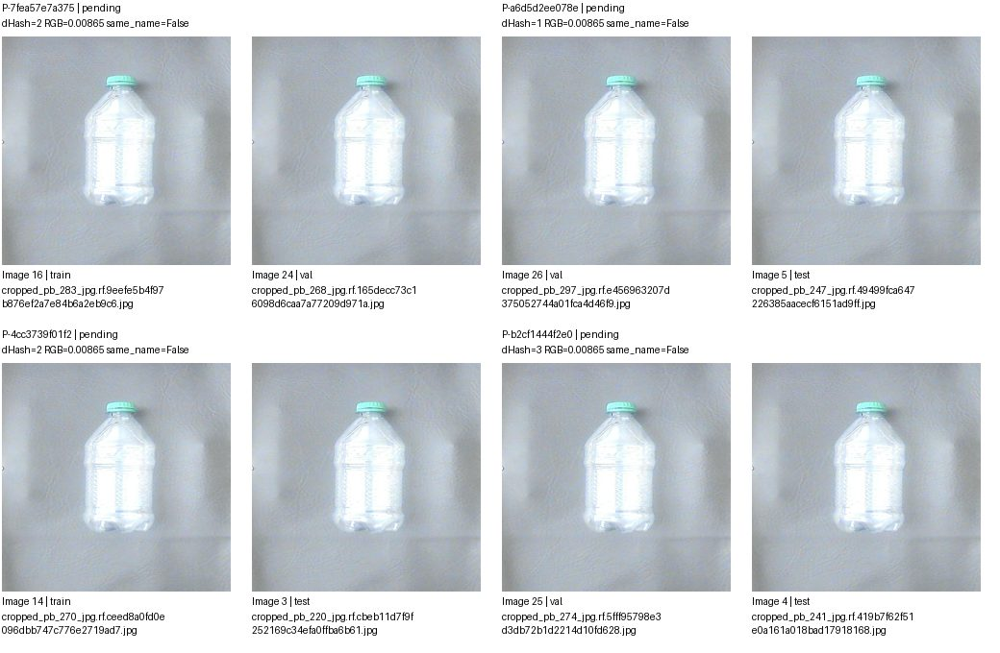

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-7fea57e7a375,images/train/cropped_pb_283_jpg.rf.9eefe5b4f97b876ef2a7e84b6a2eb9c6.jpg,images/val/cropped_pb_268_jpg.rf.165decc73c16098d6caa7a77209d971a.jpg,pending,
P-a6d5d2ee078e,images/val/cropped_pb_297_jpg.rf.e456963207d375052744a01fca4d46f9.jpg,images/test/cropped_pb_247_jpg.rf.49499fca647226385aacecf6151ad9ff.jpg,pending,
P-4cc3739f01f2,images/train/cropped_pb_270_jpg.rf.ceed8a0fd0e096dbb747c776e2719ad7.jpg,images/test/cropped_pb_220_jpg.rf.cbeb11d7f9f252169c34efa0ffba6b61.jpg,pending,
P-b2cf1444f2e0,images/val/cropped_pb_274_jpg.rf.5fff95798e3d3db72b1d2214d10fd628.jpg,images/test/cropped_pb_241_jpg.rf.419b7f62f51e0a161a018bad17918168.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 104/166 G-947b2d97d667 | 26 ảnh, 207 cặp
Split: {'test': 7, 'train': 9, 'val': 10}
Quyết định: {'pending': 207}
Ảnh trang None/5; cặp trang 33/52. Nhóm liên thông không phải kết luận trùng.


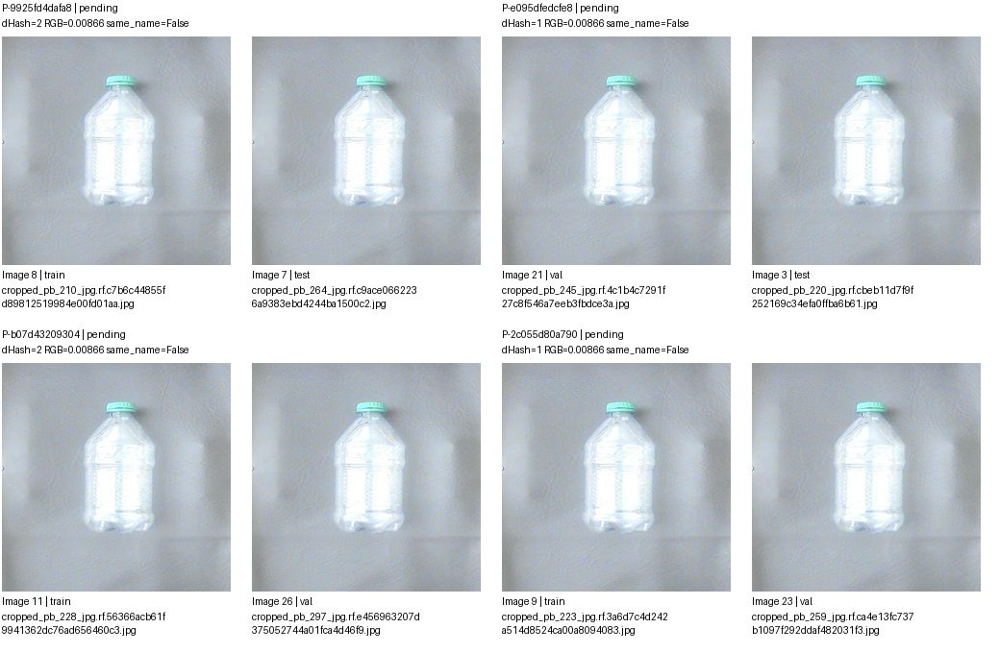

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-9925fd4dafa8,images/train/cropped_pb_210_jpg.rf.c7b6c44855fd89812519984e00fd01aa.jpg,images/test/cropped_pb_264_jpg.rf.c9ace0662236a9383ebd4244ba1500c2.jpg,pending,
P-e095dfedcfe8,images/val/cropped_pb_245_jpg.rf.4c1b4c7291f27c8f546a7eeb3fbdce3a.jpg,images/test/cropped_pb_220_jpg.rf.cbeb11d7f9f252169c34efa0ffba6b61.jpg,pending,
P-b07d43209304,images/train/cropped_pb_228_jpg.rf.56366acb61f9941362dc76ad656460c3.jpg,images/val/cropped_pb_297_jpg.rf.e456963207d375052744a01fca4d46f9.jpg,pending,
P-2c055d80a790,images/train/cropped_pb_223_jpg.rf.3a6d7c4d242a514d8524ca00a8094083.jpg,images/val/cropped_pb_259_jpg.rf.ca4e13fc737b1097f292ddaf482031f3.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 104/166 G-947b2d97d667 | 26 ảnh, 207 cặp
Split: {'test': 7, 'train': 9, 'val': 10}
Quyết định: {'pending': 207}
Ảnh trang None/5; cặp trang 34/52. Nhóm liên thông không phải kết luận trùng.


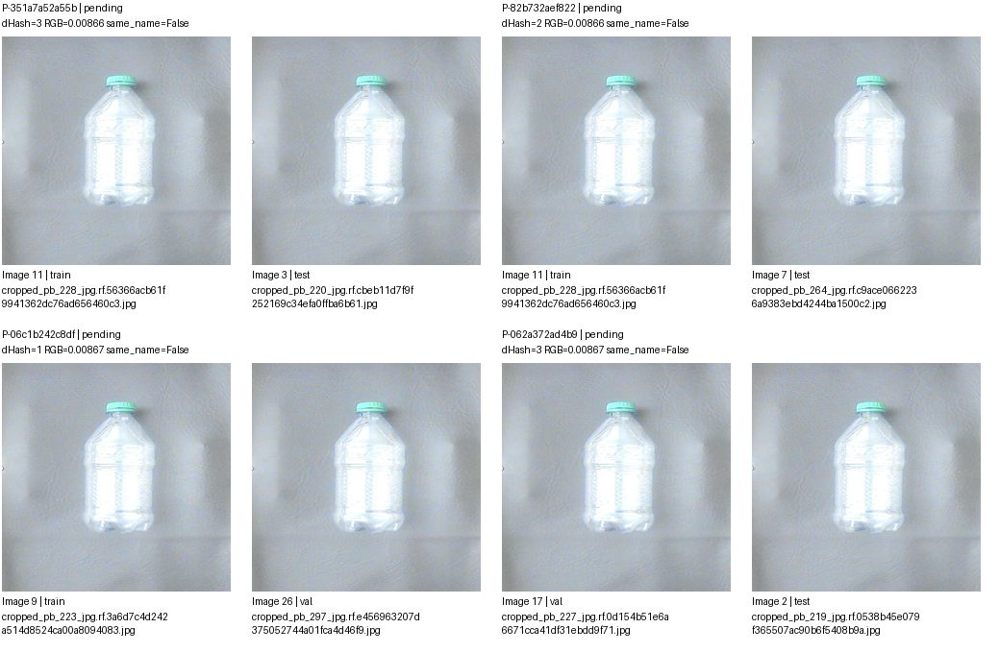

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-351a7a52a55b,images/train/cropped_pb_228_jpg.rf.56366acb61f9941362dc76ad656460c3.jpg,images/test/cropped_pb_220_jpg.rf.cbeb11d7f9f252169c34efa0ffba6b61.jpg,pending,
P-82b732aef822,images/train/cropped_pb_228_jpg.rf.56366acb61f9941362dc76ad656460c3.jpg,images/test/cropped_pb_264_jpg.rf.c9ace0662236a9383ebd4244ba1500c2.jpg,pending,
P-06c1b242c8df,images/train/cropped_pb_223_jpg.rf.3a6d7c4d242a514d8524ca00a8094083.jpg,images/val/cropped_pb_297_jpg.rf.e456963207d375052744a01fca4d46f9.jpg,pending,
P-062a372ad4b9,images/val/cropped_pb_227_jpg.rf.0d154b51e6a6671cca41df31ebdd9f71.jpg,images/test/cropped_pb_219_jpg.rf.0538b45e079f365507ac90b6f5408b9a.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 104/166 G-947b2d97d667 | 26 ảnh, 207 cặp
Split: {'test': 7, 'train': 9, 'val': 10}
Quyết định: {'pending': 207}
Ảnh trang None/5; cặp trang 35/52. Nhóm liên thông không phải kết luận trùng.


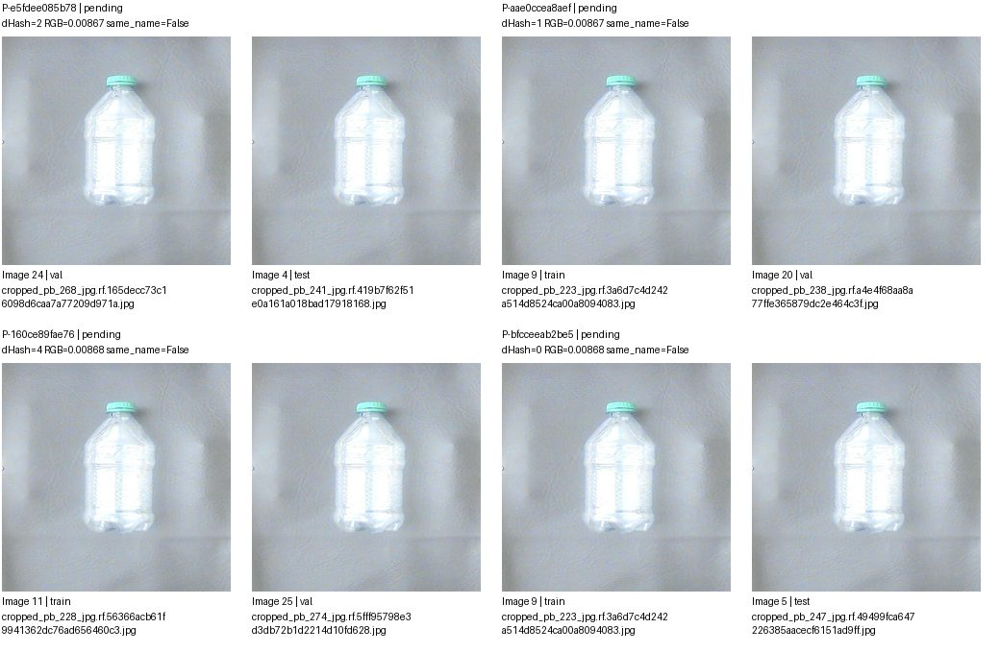

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-e5fdee085b78,images/val/cropped_pb_268_jpg.rf.165decc73c16098d6caa7a77209d971a.jpg,images/test/cropped_pb_241_jpg.rf.419b7f62f51e0a161a018bad17918168.jpg,pending,
P-aae0ccea8aef,images/train/cropped_pb_223_jpg.rf.3a6d7c4d242a514d8524ca00a8094083.jpg,images/val/cropped_pb_238_jpg.rf.a4e4f68aa8a77ffe365879dc2e464c3f.jpg,pending,
P-160ce89fae76,images/train/cropped_pb_228_jpg.rf.56366acb61f9941362dc76ad656460c3.jpg,images/val/cropped_pb_274_jpg.rf.5fff95798e3d3db72b1d2214d10fd628.jpg,pending,
P-bfcceeab2be5,images/train/cropped_pb_223_jpg.rf.3a6d7c4d242a514d8524ca00a8094083.jpg,images/test/cropped_pb_247_jpg.rf.49499fca647226385aacecf6151ad9ff.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 104/166 G-947b2d97d667 | 26 ảnh, 207 cặp
Split: {'test': 7, 'train': 9, 'val': 10}
Quyết định: {'pending': 207}
Ảnh trang None/5; cặp trang 36/52. Nhóm liên thông không phải kết luận trùng.


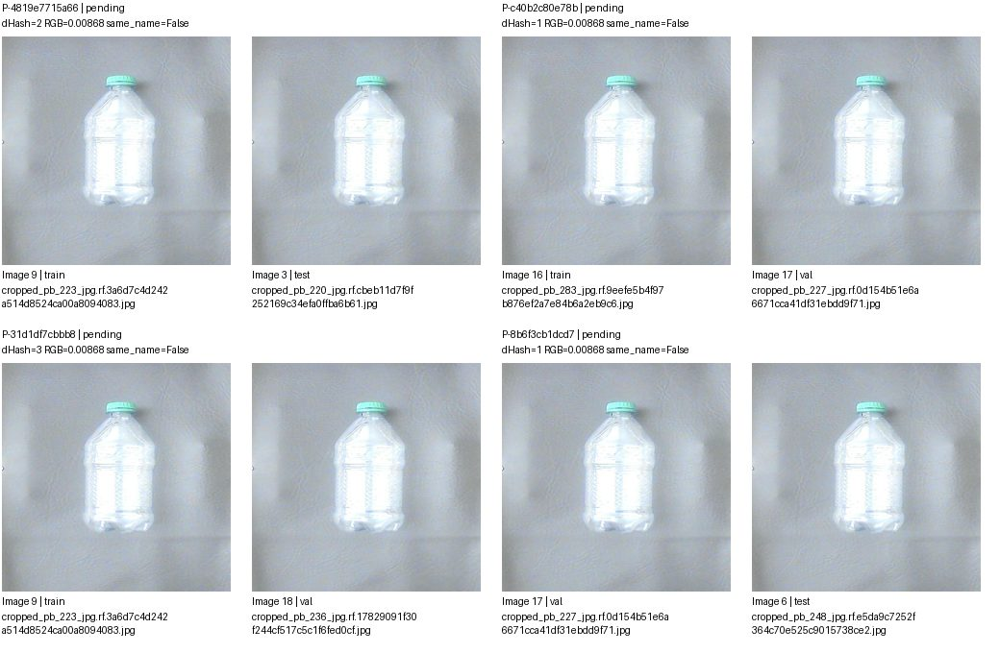

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-4819e7715a66,images/train/cropped_pb_223_jpg.rf.3a6d7c4d242a514d8524ca00a8094083.jpg,images/test/cropped_pb_220_jpg.rf.cbeb11d7f9f252169c34efa0ffba6b61.jpg,pending,
P-c40b2c80e78b,images/train/cropped_pb_283_jpg.rf.9eefe5b4f97b876ef2a7e84b6a2eb9c6.jpg,images/val/cropped_pb_227_jpg.rf.0d154b51e6a6671cca41df31ebdd9f71.jpg,pending,
P-31d1df7cbbb8,images/train/cropped_pb_223_jpg.rf.3a6d7c4d242a514d8524ca00a8094083.jpg,images/val/cropped_pb_236_jpg.rf.17829091f30f244cf517c5c1f6fed0cf.jpg,pending,
P-8b6f3cb1dcd7,images/val/cropped_pb_227_jpg.rf.0d154b51e6a6671cca41df31ebdd9f71.jpg,images/test/cropped_pb_248_jpg.rf.e5da9c7252f364c70e525c9015738ce2.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 104/166 G-947b2d97d667 | 26 ảnh, 207 cặp
Split: {'test': 7, 'train': 9, 'val': 10}
Quyết định: {'pending': 207}
Ảnh trang None/5; cặp trang 37/52. Nhóm liên thông không phải kết luận trùng.


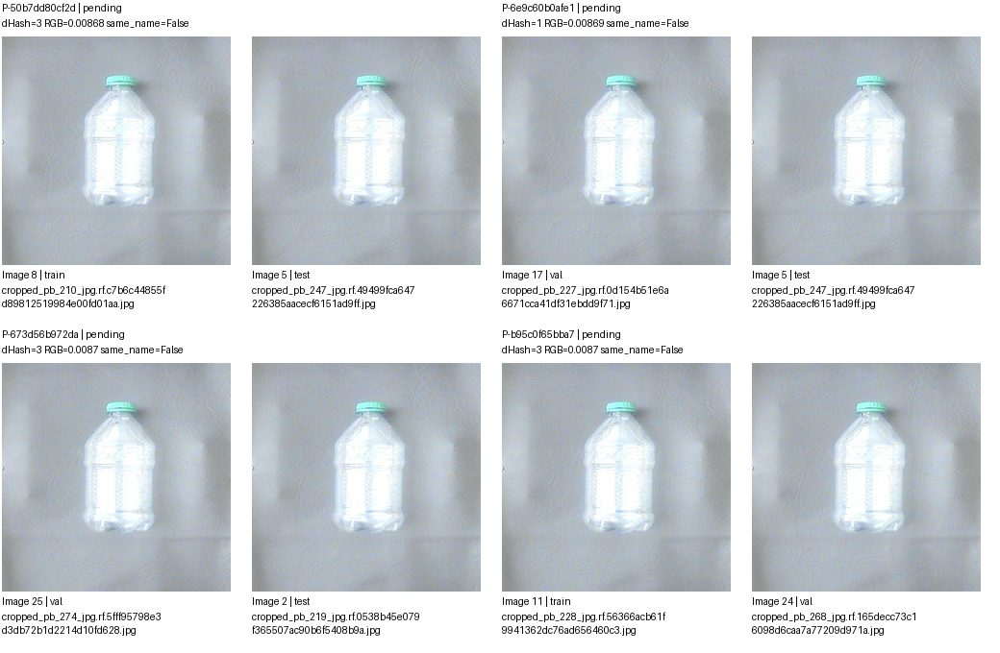

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-50b7dd80cf2d,images/train/cropped_pb_210_jpg.rf.c7b6c44855fd89812519984e00fd01aa.jpg,images/test/cropped_pb_247_jpg.rf.49499fca647226385aacecf6151ad9ff.jpg,pending,
P-6e9c60b0afe1,images/val/cropped_pb_227_jpg.rf.0d154b51e6a6671cca41df31ebdd9f71.jpg,images/test/cropped_pb_247_jpg.rf.49499fca647226385aacecf6151ad9ff.jpg,pending,
P-673d56b972da,images/val/cropped_pb_274_jpg.rf.5fff95798e3d3db72b1d2214d10fd628.jpg,images/test/cropped_pb_219_jpg.rf.0538b45e079f365507ac90b6f5408b9a.jpg,pending,
P-b95c0f65bba7,images/train/cropped_pb_228_jpg.rf.56366acb61f9941362dc76ad656460c3.jpg,images/val/cropped_pb_268_jpg.rf.165decc73c16098d6caa7a77209d971a.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 104/166 G-947b2d97d667 | 26 ảnh, 207 cặp
Split: {'test': 7, 'train': 9, 'val': 10}
Quyết định: {'pending': 207}
Ảnh trang None/5; cặp trang 38/52. Nhóm liên thông không phải kết luận trùng.


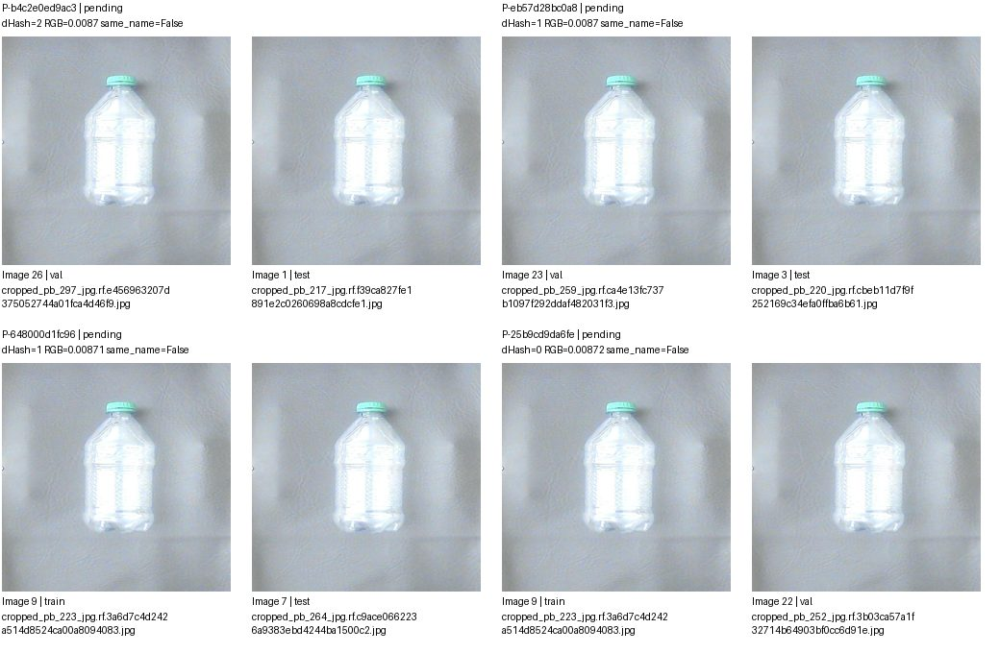

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-b4c2e0ed9ac3,images/val/cropped_pb_297_jpg.rf.e456963207d375052744a01fca4d46f9.jpg,images/test/cropped_pb_217_jpg.rf.f39ca827fe1891e2c0260698a8cdcfe1.jpg,pending,
P-eb57d28bc0a8,images/val/cropped_pb_259_jpg.rf.ca4e13fc737b1097f292ddaf482031f3.jpg,images/test/cropped_pb_220_jpg.rf.cbeb11d7f9f252169c34efa0ffba6b61.jpg,pending,
P-648000d1fc96,images/train/cropped_pb_223_jpg.rf.3a6d7c4d242a514d8524ca00a8094083.jpg,images/test/cropped_pb_264_jpg.rf.c9ace0662236a9383ebd4244ba1500c2.jpg,pending,
P-25b9cd9da6fe,images/train/cropped_pb_223_jpg.rf.3a6d7c4d242a514d8524ca00a8094083.jpg,images/val/cropped_pb_252_jpg.rf.3b03ca57a1f32714b64903bf0cc6d91e.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 104/166 G-947b2d97d667 | 26 ảnh, 207 cặp
Split: {'test': 7, 'train': 9, 'val': 10}
Quyết định: {'pending': 207}
Ảnh trang None/5; cặp trang 39/52. Nhóm liên thông không phải kết luận trùng.


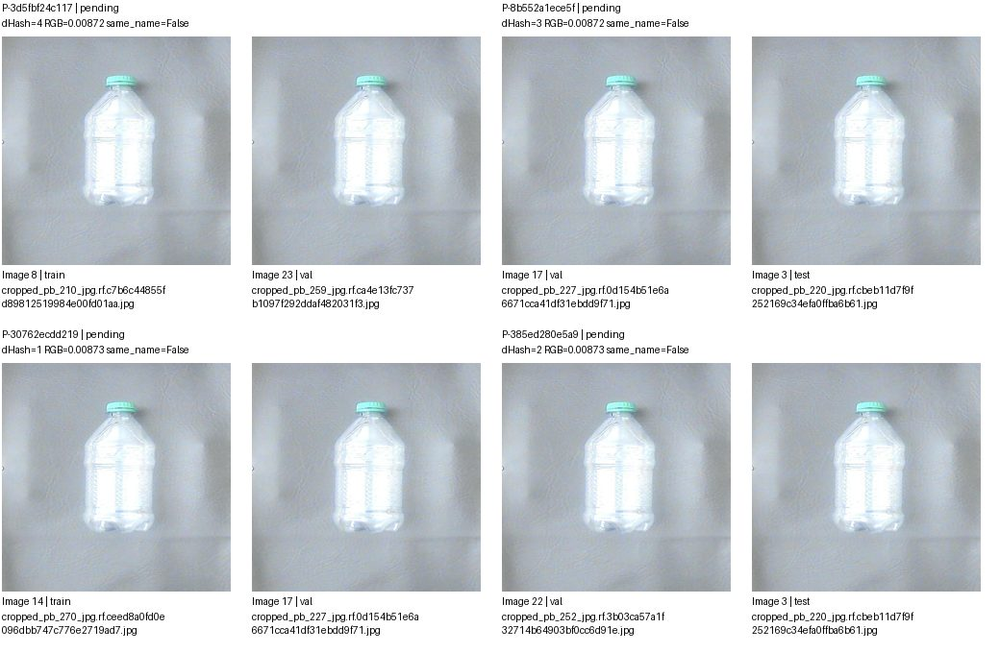

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-3d5fbf24c117,images/train/cropped_pb_210_jpg.rf.c7b6c44855fd89812519984e00fd01aa.jpg,images/val/cropped_pb_259_jpg.rf.ca4e13fc737b1097f292ddaf482031f3.jpg,pending,
P-8b552a1ece5f,images/val/cropped_pb_227_jpg.rf.0d154b51e6a6671cca41df31ebdd9f71.jpg,images/test/cropped_pb_220_jpg.rf.cbeb11d7f9f252169c34efa0ffba6b61.jpg,pending,
P-30762ecdd219,images/train/cropped_pb_270_jpg.rf.ceed8a0fd0e096dbb747c776e2719ad7.jpg,images/val/cropped_pb_227_jpg.rf.0d154b51e6a6671cca41df31ebdd9f71.jpg,pending,
P-385ed280e5a9,images/val/cropped_pb_252_jpg.rf.3b03ca57a1f32714b64903bf0cc6d91e.jpg,images/test/cropped_pb_220_jpg.rf.cbeb11d7f9f252169c34efa0ffba6b61.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 104/166 G-947b2d97d667 | 26 ảnh, 207 cặp
Split: {'test': 7, 'train': 9, 'val': 10}
Quyết định: {'pending': 207}
Ảnh trang None/5; cặp trang 40/52. Nhóm liên thông không phải kết luận trùng.


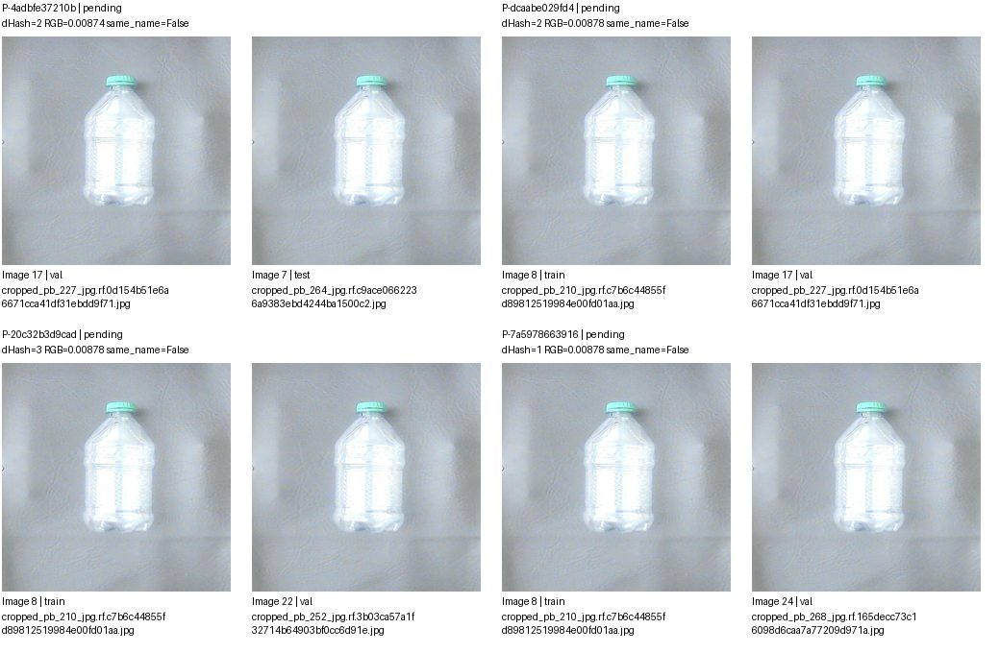

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-4adbfe37210b,images/val/cropped_pb_227_jpg.rf.0d154b51e6a6671cca41df31ebdd9f71.jpg,images/test/cropped_pb_264_jpg.rf.c9ace0662236a9383ebd4244ba1500c2.jpg,pending,
P-dcaabe029fd4,images/train/cropped_pb_210_jpg.rf.c7b6c44855fd89812519984e00fd01aa.jpg,images/val/cropped_pb_227_jpg.rf.0d154b51e6a6671cca41df31ebdd9f71.jpg,pending,
P-20c32b3d9cad,images/train/cropped_pb_210_jpg.rf.c7b6c44855fd89812519984e00fd01aa.jpg,images/val/cropped_pb_252_jpg.rf.3b03ca57a1f32714b64903bf0cc6d91e.jpg,pending,
P-7a5978663916,images/train/cropped_pb_210_jpg.rf.c7b6c44855fd89812519984e00fd01aa.jpg,images/val/cropped_pb_268_jpg.rf.165decc73c16098d6caa7a77209d971a.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 104/166 G-947b2d97d667 | 26 ảnh, 207 cặp
Split: {'test': 7, 'train': 9, 'val': 10}
Quyết định: {'pending': 207}
Ảnh trang None/5; cặp trang 41/52. Nhóm liên thông không phải kết luận trùng.


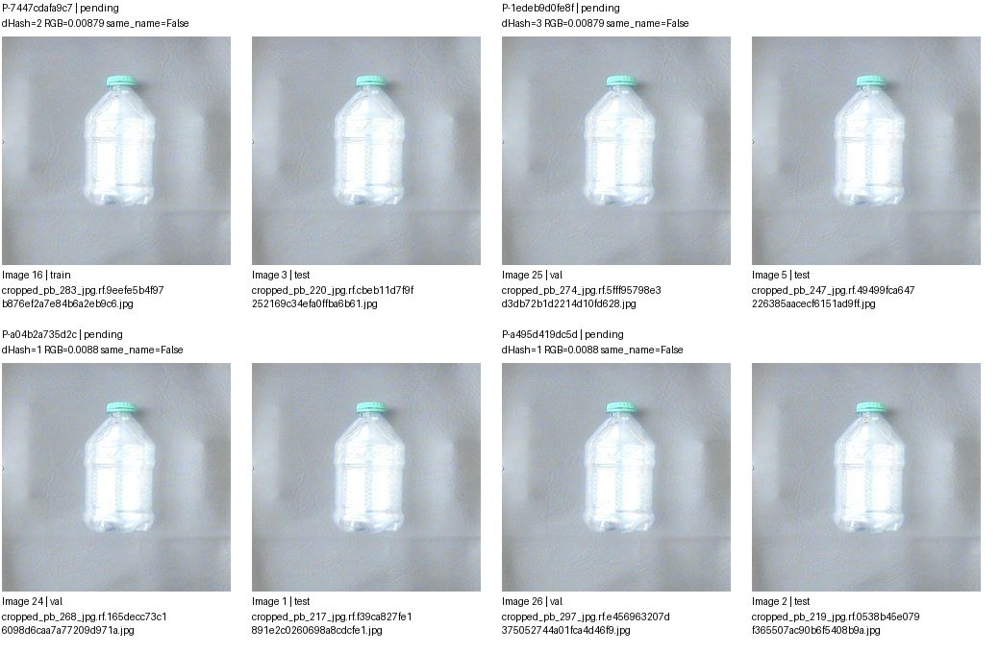

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-7447cdafa9c7,images/train/cropped_pb_283_jpg.rf.9eefe5b4f97b876ef2a7e84b6a2eb9c6.jpg,images/test/cropped_pb_220_jpg.rf.cbeb11d7f9f252169c34efa0ffba6b61.jpg,pending,
P-1edeb9d0fe8f,images/val/cropped_pb_274_jpg.rf.5fff95798e3d3db72b1d2214d10fd628.jpg,images/test/cropped_pb_247_jpg.rf.49499fca647226385aacecf6151ad9ff.jpg,pending,
P-a04b2a735d2c,images/val/cropped_pb_268_jpg.rf.165decc73c16098d6caa7a77209d971a.jpg,images/test/cropped_pb_217_jpg.rf.f39ca827fe1891e2c0260698a8cdcfe1.jpg,pending,
P-a495d419dc5d,images/val/cropped_pb_297_jpg.rf.e456963207d375052744a01fca4d46f9.jpg,images/test/cropped_pb_219_jpg.rf.0538b45e079f365507ac90b6f5408b9a.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 104/166 G-947b2d97d667 | 26 ảnh, 207 cặp
Split: {'test': 7, 'train': 9, 'val': 10}
Quyết định: {'pending': 207}
Ảnh trang None/5; cặp trang 42/52. Nhóm liên thông không phải kết luận trùng.


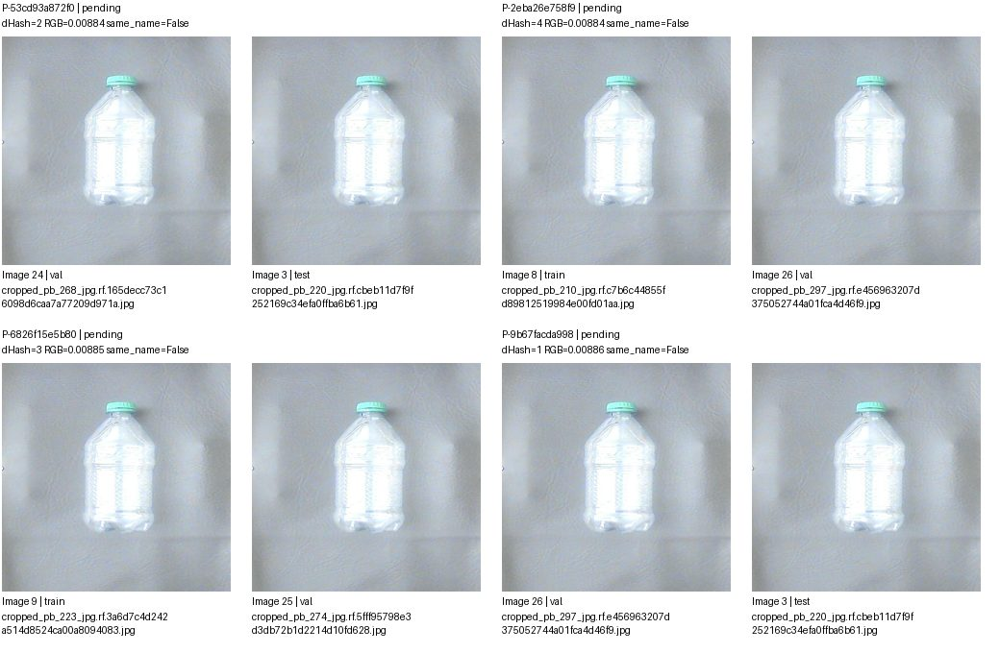

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-53cd93a872f0,images/val/cropped_pb_268_jpg.rf.165decc73c16098d6caa7a77209d971a.jpg,images/test/cropped_pb_220_jpg.rf.cbeb11d7f9f252169c34efa0ffba6b61.jpg,pending,
P-2eba26e758f9,images/train/cropped_pb_210_jpg.rf.c7b6c44855fd89812519984e00fd01aa.jpg,images/val/cropped_pb_297_jpg.rf.e456963207d375052744a01fca4d46f9.jpg,pending,
P-6826f15e5b80,images/train/cropped_pb_223_jpg.rf.3a6d7c4d242a514d8524ca00a8094083.jpg,images/val/cropped_pb_274_jpg.rf.5fff95798e3d3db72b1d2214d10fd628.jpg,pending,
P-9b67facda998,images/val/cropped_pb_297_jpg.rf.e456963207d375052744a01fca4d46f9.jpg,images/test/cropped_pb_220_jpg.rf.cbeb11d7f9f252169c34efa0ffba6b61.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 104/166 G-947b2d97d667 | 26 ảnh, 207 cặp
Split: {'test': 7, 'train': 9, 'val': 10}
Quyết định: {'pending': 207}
Ảnh trang None/5; cặp trang 43/52. Nhóm liên thông không phải kết luận trùng.


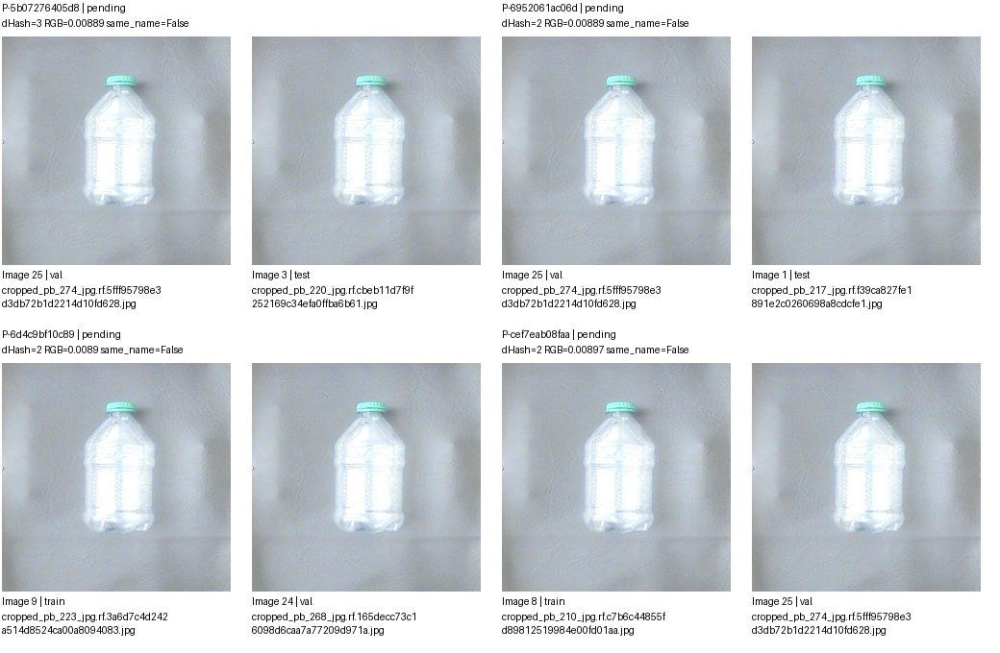

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-5b07276405d8,images/val/cropped_pb_274_jpg.rf.5fff95798e3d3db72b1d2214d10fd628.jpg,images/test/cropped_pb_220_jpg.rf.cbeb11d7f9f252169c34efa0ffba6b61.jpg,pending,
P-6952061ac06d,images/val/cropped_pb_274_jpg.rf.5fff95798e3d3db72b1d2214d10fd628.jpg,images/test/cropped_pb_217_jpg.rf.f39ca827fe1891e2c0260698a8cdcfe1.jpg,pending,
P-6d4c9bf10c89,images/train/cropped_pb_223_jpg.rf.3a6d7c4d242a514d8524ca00a8094083.jpg,images/val/cropped_pb_268_jpg.rf.165decc73c16098d6caa7a77209d971a.jpg,pending,
P-cef7eab08faa,images/train/cropped_pb_210_jpg.rf.c7b6c44855fd89812519984e00fd01aa.jpg,images/val/cropped_pb_274_jpg.rf.5fff95798e3d3db72b1d2214d10fd628.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 104/166 G-947b2d97d667 | 26 ảnh, 207 cặp
Split: {'test': 7, 'train': 9, 'val': 10}
Quyết định: {'pending': 207}
Ảnh trang None/5; cặp trang 44/52. Nhóm liên thông không phải kết luận trùng.


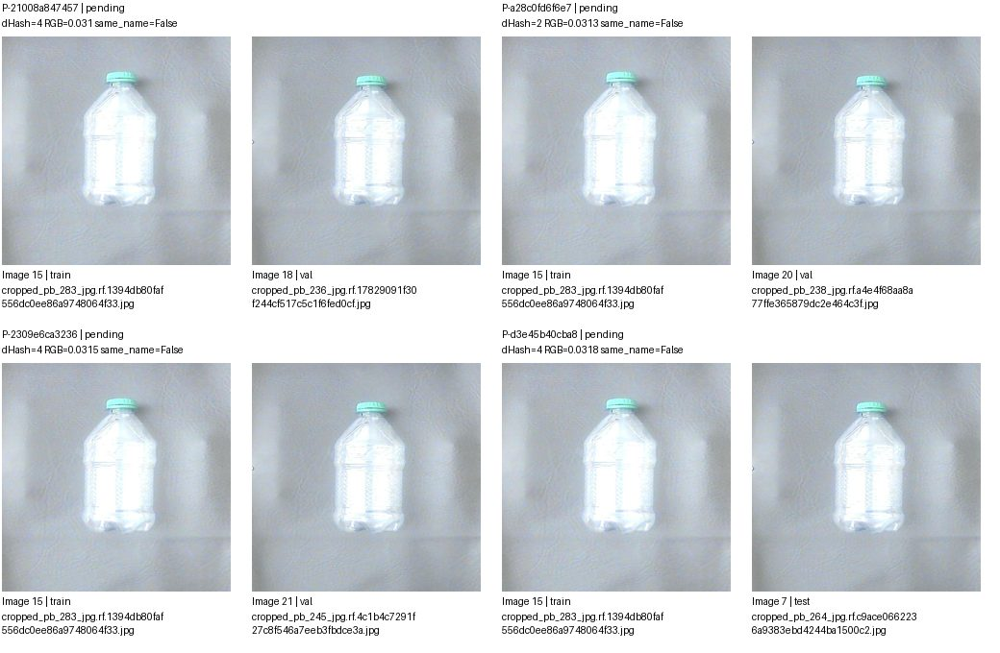

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-21008a847457,images/train/cropped_pb_283_jpg.rf.1394db80faf556dc0ee86a9748064f33.jpg,images/val/cropped_pb_236_jpg.rf.17829091f30f244cf517c5c1f6fed0cf.jpg,pending,
P-a28c0fd6f6e7,images/train/cropped_pb_283_jpg.rf.1394db80faf556dc0ee86a9748064f33.jpg,images/val/cropped_pb_238_jpg.rf.a4e4f68aa8a77ffe365879dc2e464c3f.jpg,pending,
P-2309e6ca3236,images/train/cropped_pb_283_jpg.rf.1394db80faf556dc0ee86a9748064f33.jpg,images/val/cropped_pb_245_jpg.rf.4c1b4c7291f27c8f546a7eeb3fbdce3a.jpg,pending,
P-d3e45b40cba8,images/train/cropped_pb_283_jpg.rf.1394db80faf556dc0ee86a9748064f33.jpg,images/test/cropped_pb_264_jpg.rf.c9ace0662236a9383ebd4244ba1500c2.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 104/166 G-947b2d97d667 | 26 ảnh, 207 cặp
Split: {'test': 7, 'train': 9, 'val': 10}
Quyết định: {'pending': 207}
Ảnh trang None/5; cặp trang 45/52. Nhóm liên thông không phải kết luận trùng.


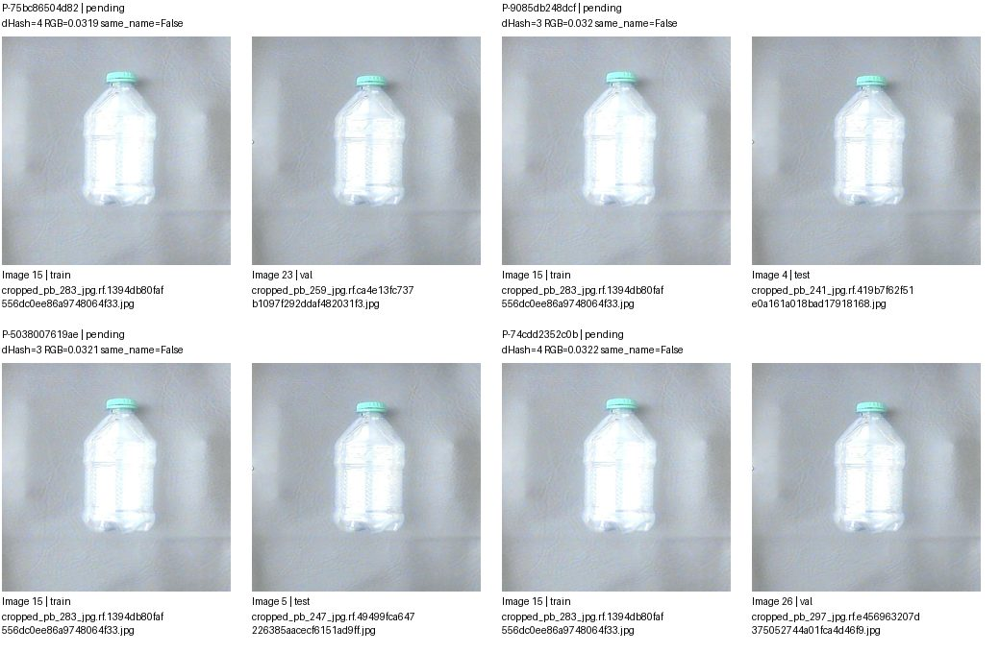

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-75bc86504d82,images/train/cropped_pb_283_jpg.rf.1394db80faf556dc0ee86a9748064f33.jpg,images/val/cropped_pb_259_jpg.rf.ca4e13fc737b1097f292ddaf482031f3.jpg,pending,
P-9085db248dcf,images/train/cropped_pb_283_jpg.rf.1394db80faf556dc0ee86a9748064f33.jpg,images/test/cropped_pb_241_jpg.rf.419b7f62f51e0a161a018bad17918168.jpg,pending,
P-5038007619ae,images/train/cropped_pb_283_jpg.rf.1394db80faf556dc0ee86a9748064f33.jpg,images/test/cropped_pb_247_jpg.rf.49499fca647226385aacecf6151ad9ff.jpg,pending,
P-74cdd2352c0b,images/train/cropped_pb_283_jpg.rf.1394db80faf556dc0ee86a9748064f33.jpg,images/val/cropped_pb_297_jpg.rf.e456963207d375052744a01fca4d46f9.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 104/166 G-947b2d97d667 | 26 ảnh, 207 cặp
Split: {'test': 7, 'train': 9, 'val': 10}
Quyết định: {'pending': 207}
Ảnh trang None/5; cặp trang 46/52. Nhóm liên thông không phải kết luận trùng.


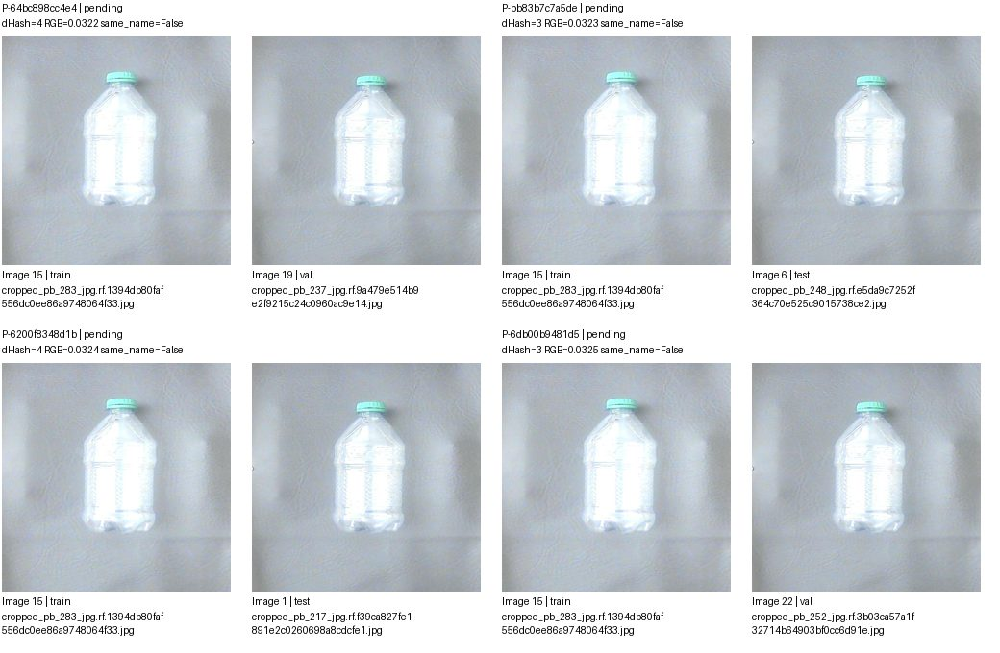

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-64bc898cc4e4,images/train/cropped_pb_283_jpg.rf.1394db80faf556dc0ee86a9748064f33.jpg,images/val/cropped_pb_237_jpg.rf.9a479e514b9e2f9215c24c0960ac9e14.jpg,pending,
P-bb83b7c7a5de,images/train/cropped_pb_283_jpg.rf.1394db80faf556dc0ee86a9748064f33.jpg,images/test/cropped_pb_248_jpg.rf.e5da9c7252f364c70e525c9015738ce2.jpg,pending,
P-6200f8348d1b,images/train/cropped_pb_283_jpg.rf.1394db80faf556dc0ee86a9748064f33.jpg,images/test/cropped_pb_217_jpg.rf.f39ca827fe1891e2c0260698a8cdcfe1.jpg,pending,
P-6db00b9481d5,images/train/cropped_pb_283_jpg.rf.1394db80faf556dc0ee86a9748064f33.jpg,images/val/cropped_pb_252_jpg.rf.3b03ca57a1f32714b64903bf0cc6d91e.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 104/166 G-947b2d97d667 | 26 ảnh, 207 cặp
Split: {'test': 7, 'train': 9, 'val': 10}
Quyết định: {'pending': 207}
Ảnh trang None/5; cặp trang 47/52. Nhóm liên thông không phải kết luận trùng.


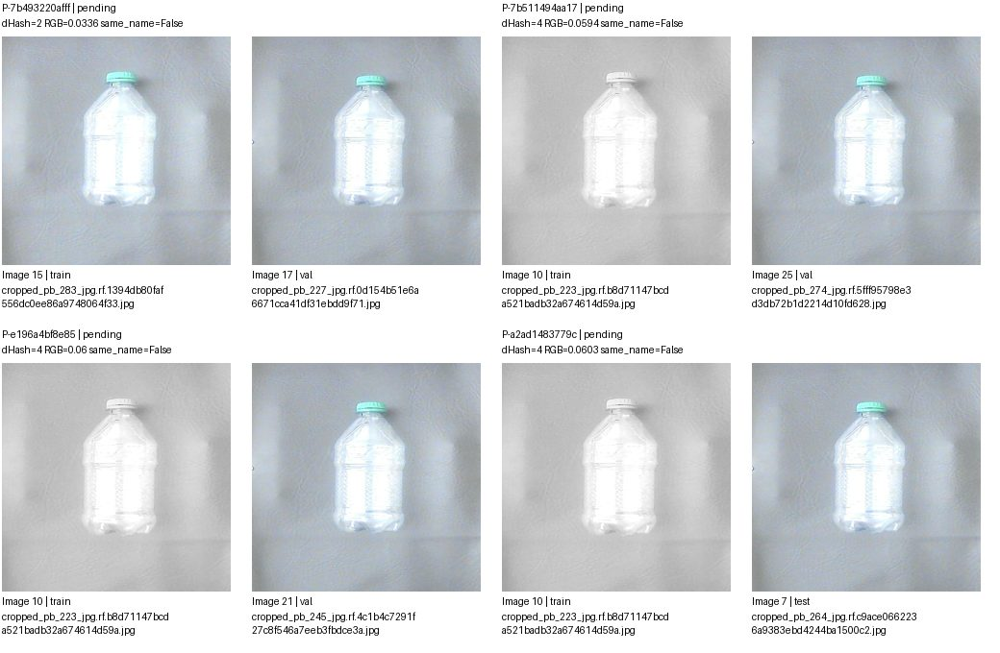

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-7b493220afff,images/train/cropped_pb_283_jpg.rf.1394db80faf556dc0ee86a9748064f33.jpg,images/val/cropped_pb_227_jpg.rf.0d154b51e6a6671cca41df31ebdd9f71.jpg,pending,
P-7b511494aa17,images/train/cropped_pb_223_jpg.rf.b8d71147bcda521badb32a674614d59a.jpg,images/val/cropped_pb_274_jpg.rf.5fff95798e3d3db72b1d2214d10fd628.jpg,pending,
P-e196a4bf8e85,images/train/cropped_pb_223_jpg.rf.b8d71147bcda521badb32a674614d59a.jpg,images/val/cropped_pb_245_jpg.rf.4c1b4c7291f27c8f546a7eeb3fbdce3a.jpg,pending,
P-a2ad1483779c,images/train/cropped_pb_223_jpg.rf.b8d71147bcda521badb32a674614d59a.jpg,images/test/cropped_pb_264_jpg.rf.c9ace0662236a9383ebd4244ba1500c2.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 104/166 G-947b2d97d667 | 26 ảnh, 207 cặp
Split: {'test': 7, 'train': 9, 'val': 10}
Quyết định: {'pending': 207}
Ảnh trang None/5; cặp trang 48/52. Nhóm liên thông không phải kết luận trùng.


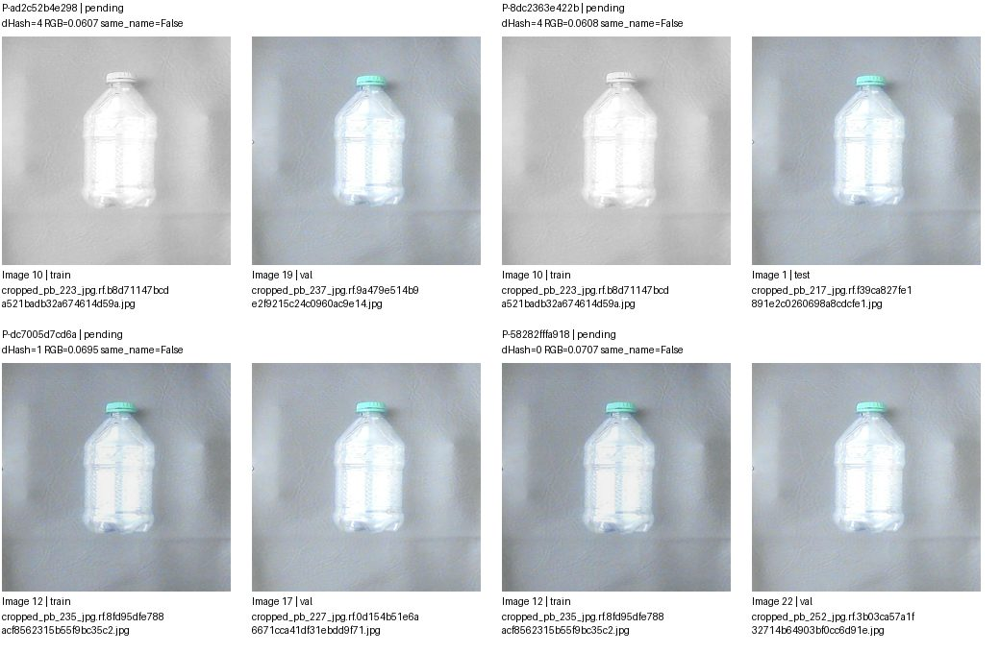

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-ad2c52b4e298,images/train/cropped_pb_223_jpg.rf.b8d71147bcda521badb32a674614d59a.jpg,images/val/cropped_pb_237_jpg.rf.9a479e514b9e2f9215c24c0960ac9e14.jpg,pending,
P-8dc2363e422b,images/train/cropped_pb_223_jpg.rf.b8d71147bcda521badb32a674614d59a.jpg,images/test/cropped_pb_217_jpg.rf.f39ca827fe1891e2c0260698a8cdcfe1.jpg,pending,
P-dc7005d7cd6a,images/train/cropped_pb_235_jpg.rf.8fd95dfe788acf8562315b55f9bc35c2.jpg,images/val/cropped_pb_227_jpg.rf.0d154b51e6a6671cca41df31ebdd9f71.jpg,pending,
P-58282fffa918,images/train/cropped_pb_235_jpg.rf.8fd95dfe788acf8562315b55f9bc35c2.jpg,images/val/cropped_pb_252_jpg.rf.3b03ca57a1f32714b64903bf0cc6d91e.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 104/166 G-947b2d97d667 | 26 ảnh, 207 cặp
Split: {'test': 7, 'train': 9, 'val': 10}
Quyết định: {'pending': 207}
Ảnh trang None/5; cặp trang 49/52. Nhóm liên thông không phải kết luận trùng.


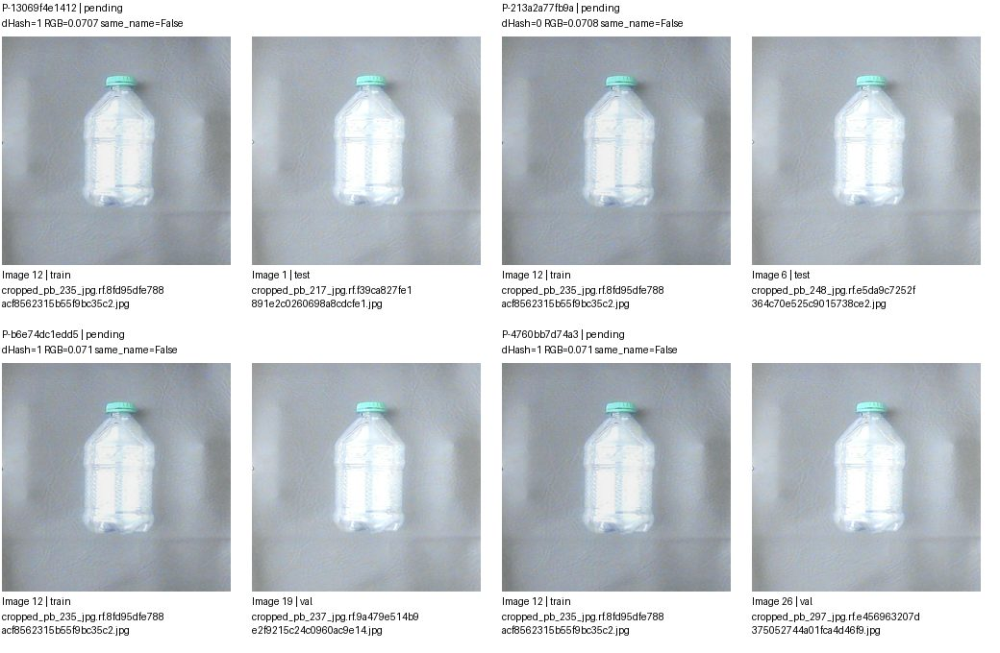

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-13069f4e1412,images/train/cropped_pb_235_jpg.rf.8fd95dfe788acf8562315b55f9bc35c2.jpg,images/test/cropped_pb_217_jpg.rf.f39ca827fe1891e2c0260698a8cdcfe1.jpg,pending,
P-213a2a77fb9a,images/train/cropped_pb_235_jpg.rf.8fd95dfe788acf8562315b55f9bc35c2.jpg,images/test/cropped_pb_248_jpg.rf.e5da9c7252f364c70e525c9015738ce2.jpg,pending,
P-b6e74dc1edd5,images/train/cropped_pb_235_jpg.rf.8fd95dfe788acf8562315b55f9bc35c2.jpg,images/val/cropped_pb_237_jpg.rf.9a479e514b9e2f9215c24c0960ac9e14.jpg,pending,
P-4760bb7d74a3,images/train/cropped_pb_235_jpg.rf.8fd95dfe788acf8562315b55f9bc35c2.jpg,images/val/cropped_pb_297_jpg.rf.e456963207d375052744a01fca4d46f9.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 104/166 G-947b2d97d667 | 26 ảnh, 207 cặp
Split: {'test': 7, 'train': 9, 'val': 10}
Quyết định: {'pending': 207}
Ảnh trang None/5; cặp trang 50/52. Nhóm liên thông không phải kết luận trùng.


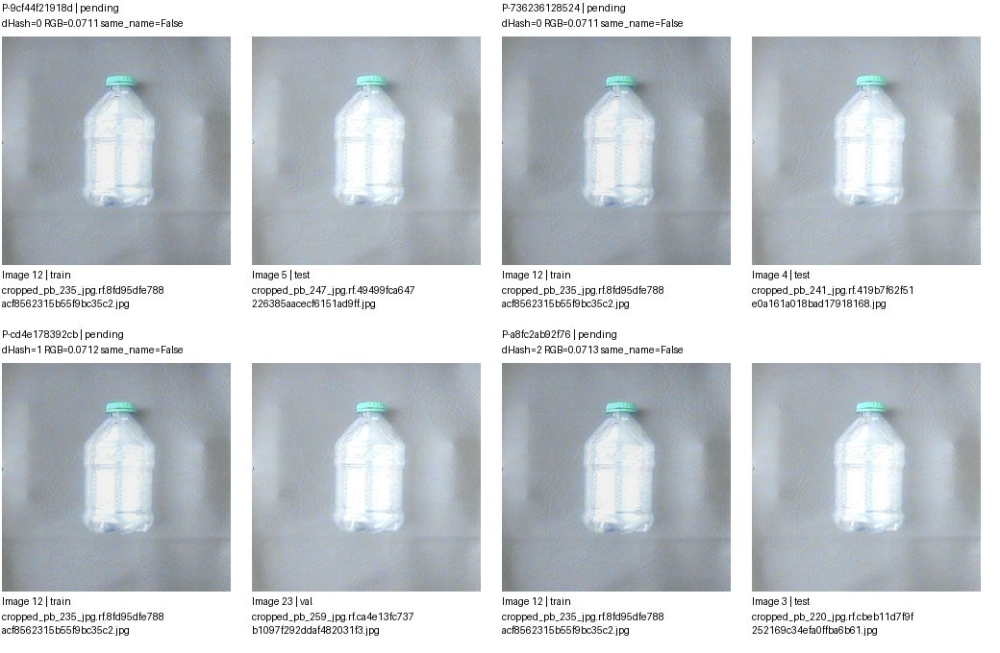

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-9cf44f21918d,images/train/cropped_pb_235_jpg.rf.8fd95dfe788acf8562315b55f9bc35c2.jpg,images/test/cropped_pb_247_jpg.rf.49499fca647226385aacecf6151ad9ff.jpg,pending,
P-736236128524,images/train/cropped_pb_235_jpg.rf.8fd95dfe788acf8562315b55f9bc35c2.jpg,images/test/cropped_pb_241_jpg.rf.419b7f62f51e0a161a018bad17918168.jpg,pending,
P-cd4e178392cb,images/train/cropped_pb_235_jpg.rf.8fd95dfe788acf8562315b55f9bc35c2.jpg,images/val/cropped_pb_259_jpg.rf.ca4e13fc737b1097f292ddaf482031f3.jpg,pending,
P-a8fc2ab92f76,images/train/cropped_pb_235_jpg.rf.8fd95dfe788acf8562315b55f9bc35c2.jpg,images/test/cropped_pb_220_jpg.rf.cbeb11d7f9f252169c34efa0ffba6b61.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 104/166 G-947b2d97d667 | 26 ảnh, 207 cặp
Split: {'test': 7, 'train': 9, 'val': 10}
Quyết định: {'pending': 207}
Ảnh trang None/5; cặp trang 51/52. Nhóm liên thông không phải kết luận trùng.


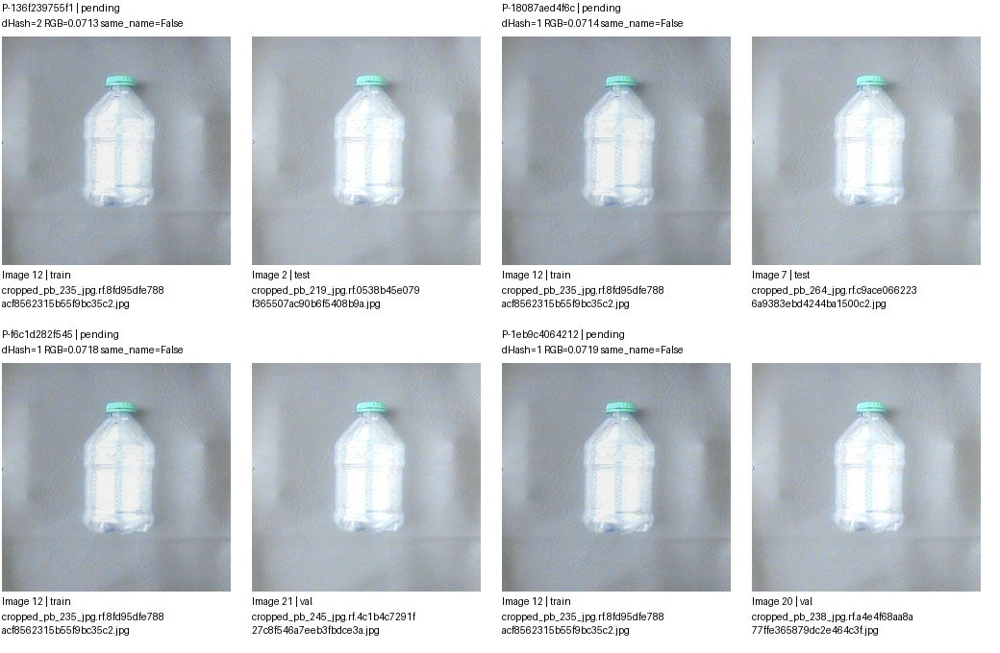

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-136f239755f1,images/train/cropped_pb_235_jpg.rf.8fd95dfe788acf8562315b55f9bc35c2.jpg,images/test/cropped_pb_219_jpg.rf.0538b45e079f365507ac90b6f5408b9a.jpg,pending,
P-18087aed4f6c,images/train/cropped_pb_235_jpg.rf.8fd95dfe788acf8562315b55f9bc35c2.jpg,images/test/cropped_pb_264_jpg.rf.c9ace0662236a9383ebd4244ba1500c2.jpg,pending,
P-f6c1d282f545,images/train/cropped_pb_235_jpg.rf.8fd95dfe788acf8562315b55f9bc35c2.jpg,images/val/cropped_pb_245_jpg.rf.4c1b4c7291f27c8f546a7eeb3fbdce3a.jpg,pending,
P-1eb9c4064212,images/train/cropped_pb_235_jpg.rf.8fd95dfe788acf8562315b55f9bc35c2.jpg,images/val/cropped_pb_238_jpg.rf.a4e4f68aa8a77ffe365879dc2e464c3f.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 104/166 G-947b2d97d667 | 26 ảnh, 207 cặp
Split: {'test': 7, 'train': 9, 'val': 10}
Quyết định: {'pending': 207}
Ảnh trang None/5; cặp trang 52/52. Nhóm liên thông không phải kết luận trùng.


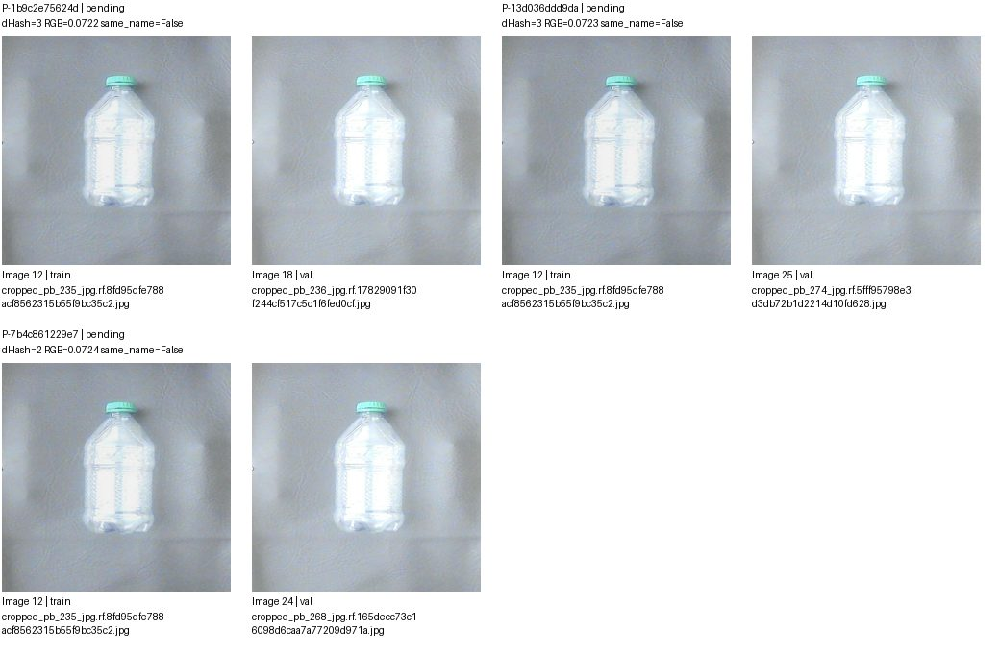

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-1b9c2e75624d,images/train/cropped_pb_235_jpg.rf.8fd95dfe788acf8562315b55f9bc35c2.jpg,images/val/cropped_pb_236_jpg.rf.17829091f30f244cf517c5c1f6fed0cf.jpg,pending,
P-13d036ddd9da,images/train/cropped_pb_235_jpg.rf.8fd95dfe788acf8562315b55f9bc35c2.jpg,images/val/cropped_pb_274_jpg.rf.5fff95798e3d3db72b1d2214d10fd628.jpg,pending,
P-7b4c861229e7,images/train/cropped_pb_235_jpg.rf.8fd95dfe788acf8562315b55f9bc35c2.jpg,images/val/cropped_pb_268_jpg.rf.165decc73c16098d6caa7a77209d971a.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 105/166 G-90031528f80a | 23 ảnh, 42 cặp
Split: {'train': 20, 'val': 3}
Quyết định: {'pending': 42}
Ảnh trang 1/4; cặp trang 1/11. Nhóm liên thông không phải kết luận trùng.


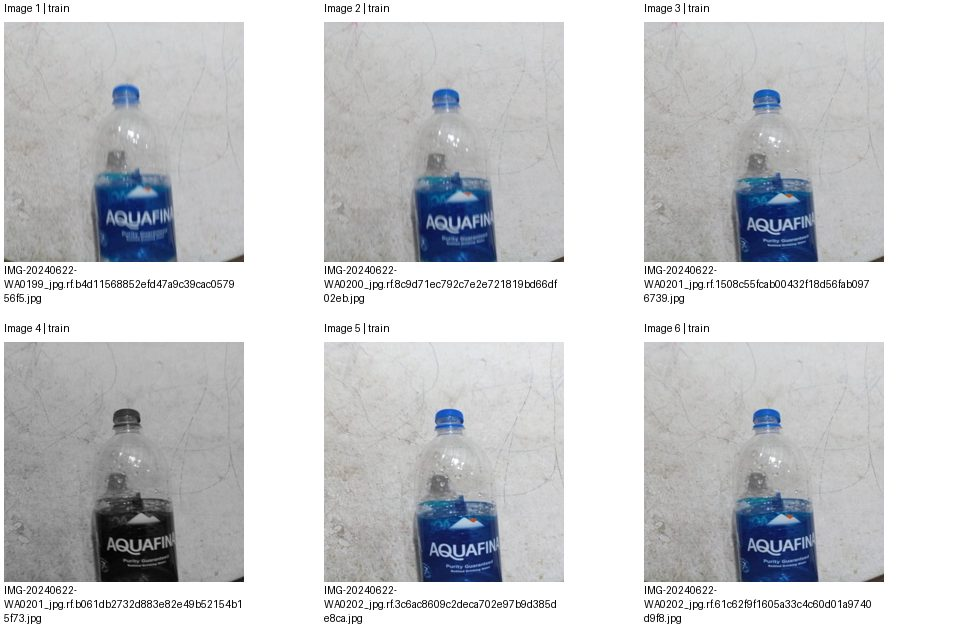

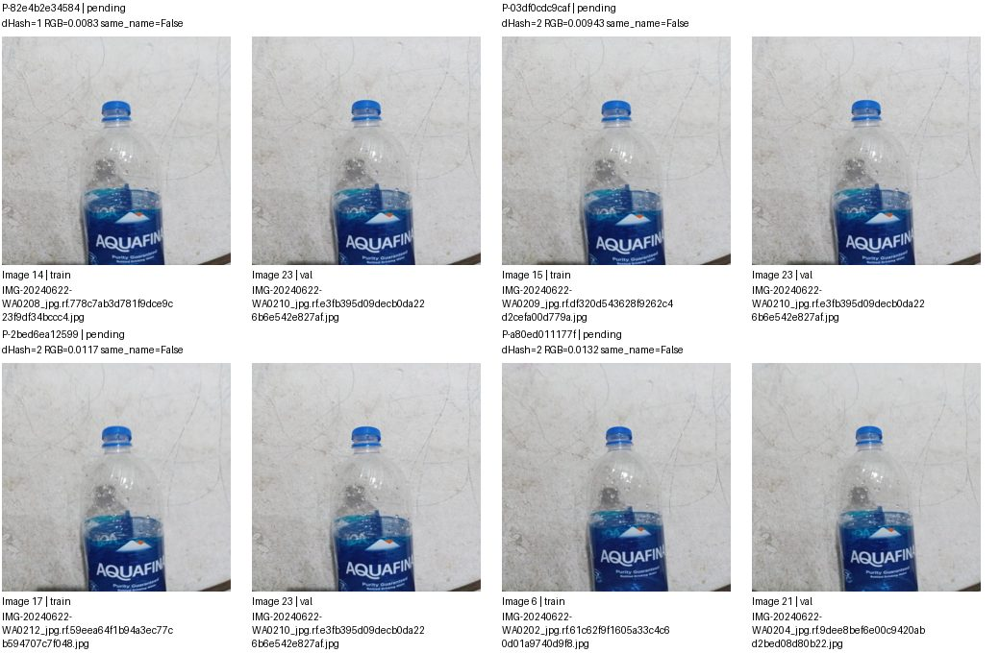

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-82e4b2e34584,images/train/IMG-20240622-WA0208_jpg.rf.778c7ab3d781f9dce9c23f9df34bccc4.jpg,images/val/IMG-20240622-WA0210_jpg.rf.e3fb395d09decb0da226b6e542e827af.jpg,pending,
P-03df0cdc9caf,images/train/IMG-20240622-WA0209_jpg.rf.df320d543628f9262c4d2cefa00d779a.jpg,images/val/IMG-20240622-WA0210_jpg.rf.e3fb395d09decb0da226b6e542e827af.jpg,pending,
P-2bed6ea12599,images/train/IMG-20240622-WA0212_jpg.rf.59eea64f1b94a3ec77cb594707c7f048.jpg,images/val/IMG-20240622-WA0210_jpg.rf.e3fb395d09decb0da226b6e542e827af.jpg,pending,
P-a80ed011177f,images/train/IMG-20240622-WA0202_jpg.rf.61c62f9f1605a33c4c60d01a9740d9f8.jpg,images/val/IMG-20240622-WA0204_jpg.rf.9dee8bef6e00c9420abd2bed08d80b22.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 105/166 G-90031528f80a | 23 ảnh, 42 cặp
Split: {'train': 20, 'val': 3}
Quyết định: {'pending': 42}
Ảnh trang 2/4; cặp trang 2/11. Nhóm liên thông không phải kết luận trùng.


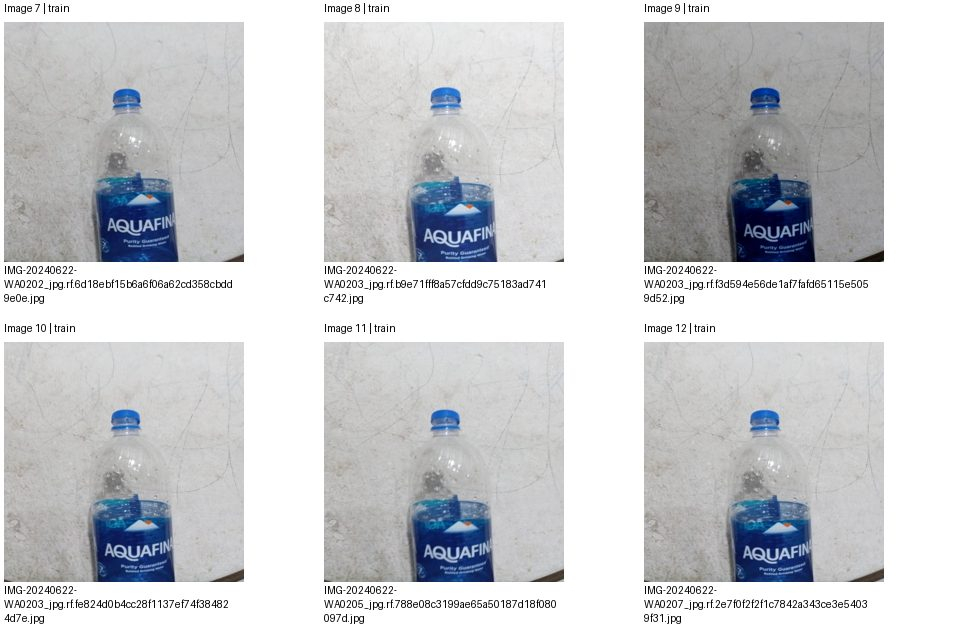

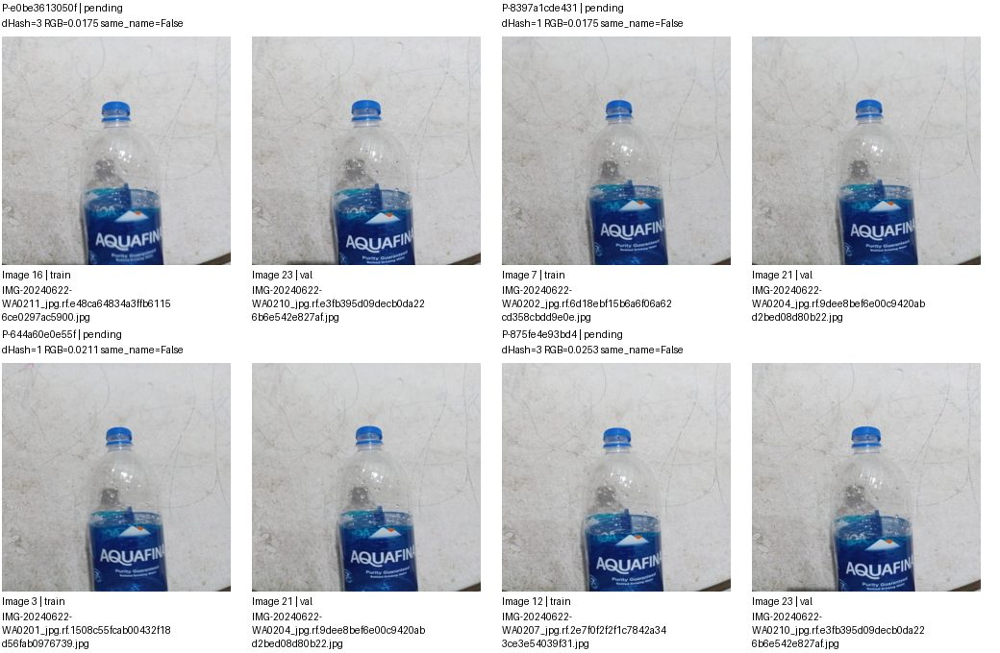

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-e0be3613050f,images/train/IMG-20240622-WA0211_jpg.rf.e48ca64834a3ffb61156ce0297ac5900.jpg,images/val/IMG-20240622-WA0210_jpg.rf.e3fb395d09decb0da226b6e542e827af.jpg,pending,
P-8397a1cde431,images/train/IMG-20240622-WA0202_jpg.rf.6d18ebf15b6a6f06a62cd358cbdd9e0e.jpg,images/val/IMG-20240622-WA0204_jpg.rf.9dee8bef6e00c9420abd2bed08d80b22.jpg,pending,
P-644a60e0e55f,images/train/IMG-20240622-WA0201_jpg.rf.1508c55fcab00432f18d56fab0976739.jpg,images/val/IMG-20240622-WA0204_jpg.rf.9dee8bef6e00c9420abd2bed08d80b22.jpg,pending,
P-875fe4e93bd4,images/train/IMG-20240622-WA0207_jpg.rf.2e7f0f2f2f1c7842a343ce3e54039f31.jpg,images/val/IMG-20240622-WA0210_jpg.rf.e3fb395d09decb0da226b6e542e827af.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 105/166 G-90031528f80a | 23 ảnh, 42 cặp
Split: {'train': 20, 'val': 3}
Quyết định: {'pending': 42}
Ảnh trang 3/4; cặp trang 3/11. Nhóm liên thông không phải kết luận trùng.


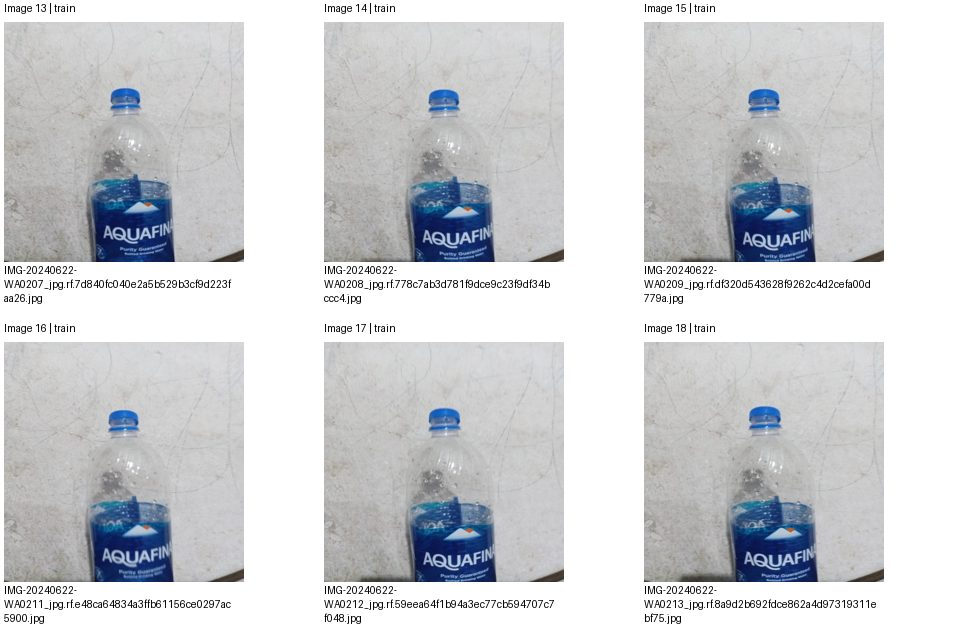

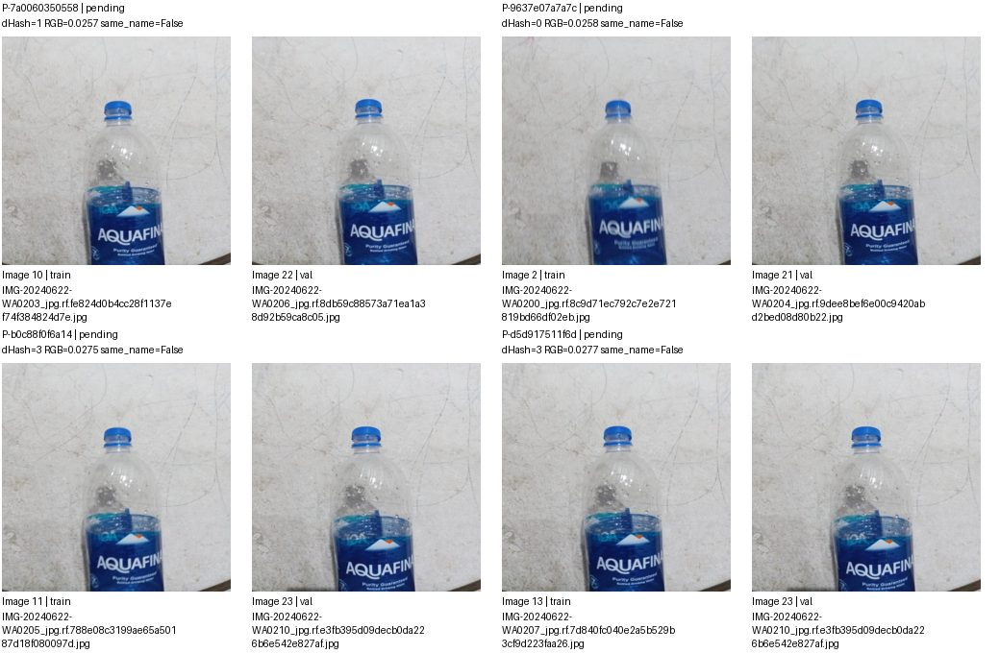

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-7a0060350558,images/train/IMG-20240622-WA0203_jpg.rf.fe824d0b4cc28f1137ef74f384824d7e.jpg,images/val/IMG-20240622-WA0206_jpg.rf.8db59c88573a71ea1a38d92b59ca8c05.jpg,pending,
P-9637e07a7a7c,images/train/IMG-20240622-WA0200_jpg.rf.8c9d71ec792c7e2e721819bd66df02eb.jpg,images/val/IMG-20240622-WA0204_jpg.rf.9dee8bef6e00c9420abd2bed08d80b22.jpg,pending,
P-b0c88f0f6a14,images/train/IMG-20240622-WA0205_jpg.rf.788e08c3199ae65a50187d18f080097d.jpg,images/val/IMG-20240622-WA0210_jpg.rf.e3fb395d09decb0da226b6e542e827af.jpg,pending,
P-d5d917511f6d,images/train/IMG-20240622-WA0207_jpg.rf.7d840fc040e2a5b529b3cf9d223faa26.jpg,images/val/IMG-20240622-WA0210_jpg.rf.e3fb395d09decb0da226b6e542e827af.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 105/166 G-90031528f80a | 23 ảnh, 42 cặp
Split: {'train': 20, 'val': 3}
Quyết định: {'pending': 42}
Ảnh trang 4/4; cặp trang 4/11. Nhóm liên thông không phải kết luận trùng.


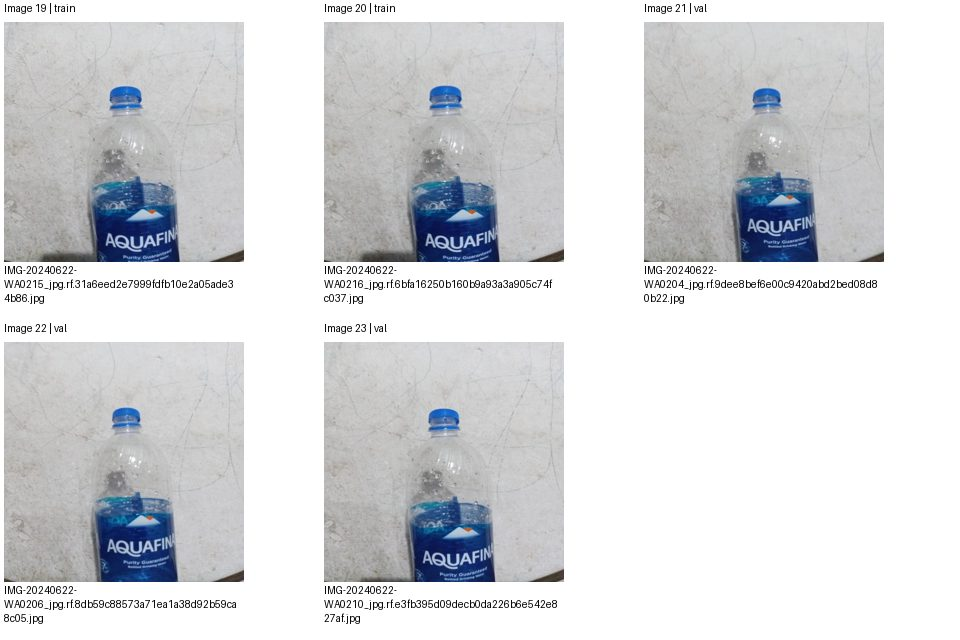

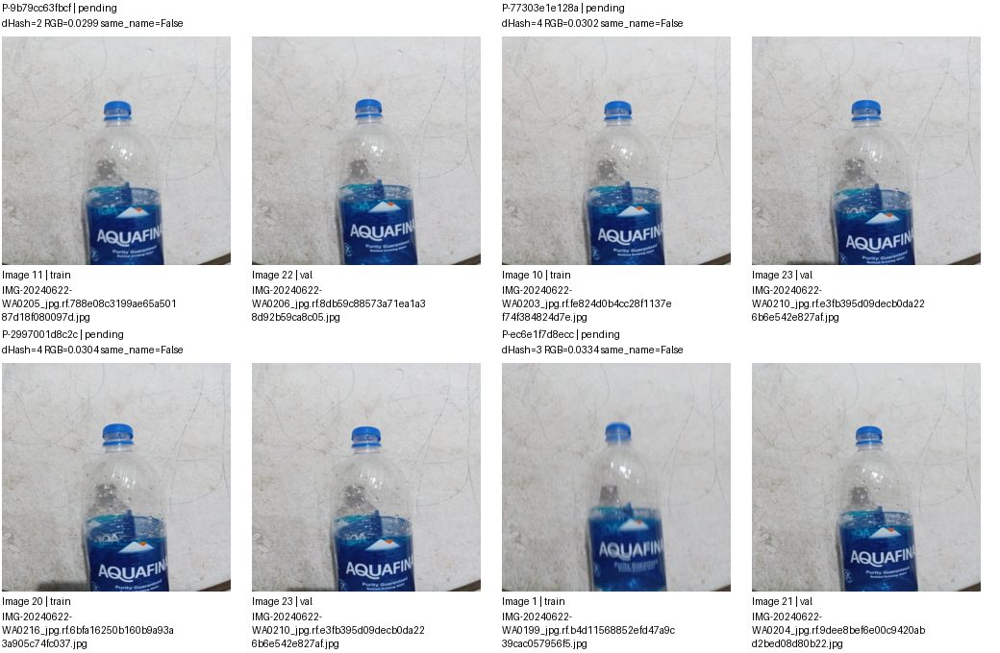

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-9b79cc63fbcf,images/train/IMG-20240622-WA0205_jpg.rf.788e08c3199ae65a50187d18f080097d.jpg,images/val/IMG-20240622-WA0206_jpg.rf.8db59c88573a71ea1a38d92b59ca8c05.jpg,pending,
P-77303e1e128a,images/train/IMG-20240622-WA0203_jpg.rf.fe824d0b4cc28f1137ef74f384824d7e.jpg,images/val/IMG-20240622-WA0210_jpg.rf.e3fb395d09decb0da226b6e542e827af.jpg,pending,
P-2997001d8c2c,images/train/IMG-20240622-WA0216_jpg.rf.6bfa16250b160b9a93a3a905c74fc037.jpg,images/val/IMG-20240622-WA0210_jpg.rf.e3fb395d09decb0da226b6e542e827af.jpg,pending,
P-ec6e1f7d8ecc,images/train/IMG-20240622-WA0199_jpg.rf.b4d11568852efd47a9c39cac057956f5.jpg,images/val/IMG-20240622-WA0204_jpg.rf.9dee8bef6e00c9420abd2bed08d80b22.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 105/166 G-90031528f80a | 23 ảnh, 42 cặp
Split: {'train': 20, 'val': 3}
Quyết định: {'pending': 42}
Ảnh trang None/4; cặp trang 5/11. Nhóm liên thông không phải kết luận trùng.


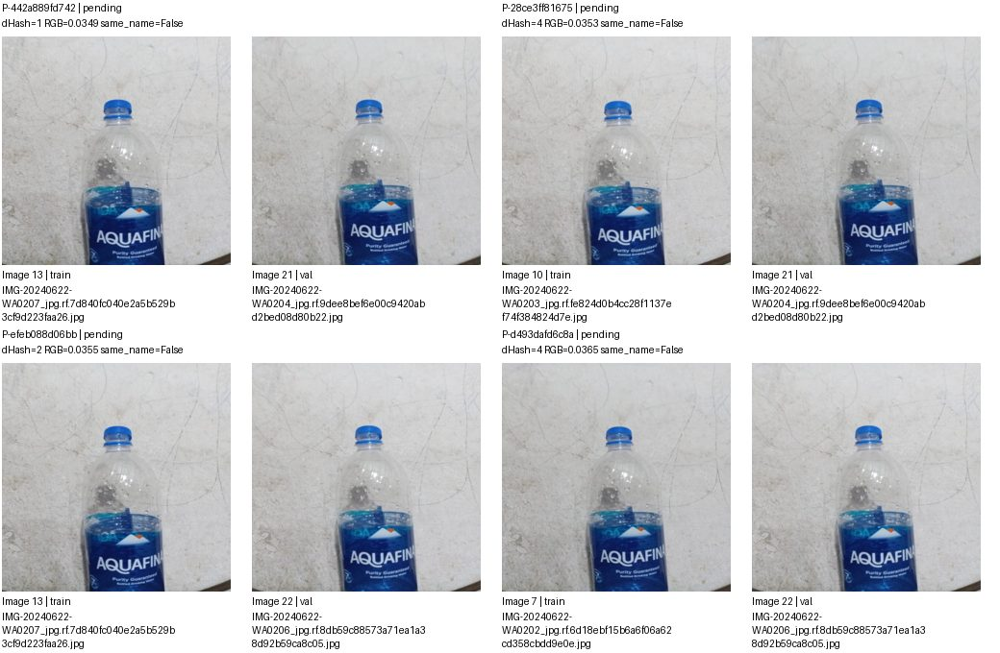

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-442a889fd742,images/train/IMG-20240622-WA0207_jpg.rf.7d840fc040e2a5b529b3cf9d223faa26.jpg,images/val/IMG-20240622-WA0204_jpg.rf.9dee8bef6e00c9420abd2bed08d80b22.jpg,pending,
P-28ce3ff81675,images/train/IMG-20240622-WA0203_jpg.rf.fe824d0b4cc28f1137ef74f384824d7e.jpg,images/val/IMG-20240622-WA0204_jpg.rf.9dee8bef6e00c9420abd2bed08d80b22.jpg,pending,
P-efeb088d06bb,images/train/IMG-20240622-WA0207_jpg.rf.7d840fc040e2a5b529b3cf9d223faa26.jpg,images/val/IMG-20240622-WA0206_jpg.rf.8db59c88573a71ea1a38d92b59ca8c05.jpg,pending,
P-d493dafd6c8a,images/train/IMG-20240622-WA0202_jpg.rf.6d18ebf15b6a6f06a62cd358cbdd9e0e.jpg,images/val/IMG-20240622-WA0206_jpg.rf.8db59c88573a71ea1a38d92b59ca8c05.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 105/166 G-90031528f80a | 23 ảnh, 42 cặp
Split: {'train': 20, 'val': 3}
Quyết định: {'pending': 42}
Ảnh trang None/4; cặp trang 6/11. Nhóm liên thông không phải kết luận trùng.


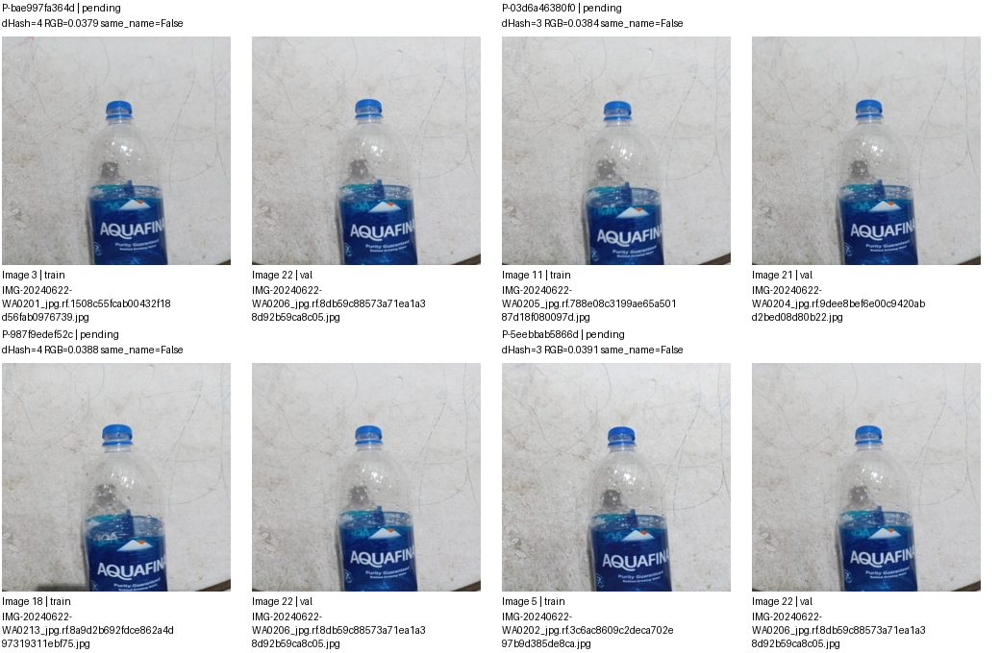

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-bae997fa364d,images/train/IMG-20240622-WA0201_jpg.rf.1508c55fcab00432f18d56fab0976739.jpg,images/val/IMG-20240622-WA0206_jpg.rf.8db59c88573a71ea1a38d92b59ca8c05.jpg,pending,
P-03d6a46380f0,images/train/IMG-20240622-WA0205_jpg.rf.788e08c3199ae65a50187d18f080097d.jpg,images/val/IMG-20240622-WA0204_jpg.rf.9dee8bef6e00c9420abd2bed08d80b22.jpg,pending,
P-987f9edef52c,images/train/IMG-20240622-WA0213_jpg.rf.8a9d2b692fdce862a4d97319311ebf75.jpg,images/val/IMG-20240622-WA0206_jpg.rf.8db59c88573a71ea1a38d92b59ca8c05.jpg,pending,
P-5eebbab5866d,images/train/IMG-20240622-WA0202_jpg.rf.3c6ac8609c2deca702e97b9d385de8ca.jpg,images/val/IMG-20240622-WA0206_jpg.rf.8db59c88573a71ea1a38d92b59ca8c05.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 105/166 G-90031528f80a | 23 ảnh, 42 cặp
Split: {'train': 20, 'val': 3}
Quyết định: {'pending': 42}
Ảnh trang None/4; cặp trang 7/11. Nhóm liên thông không phải kết luận trùng.


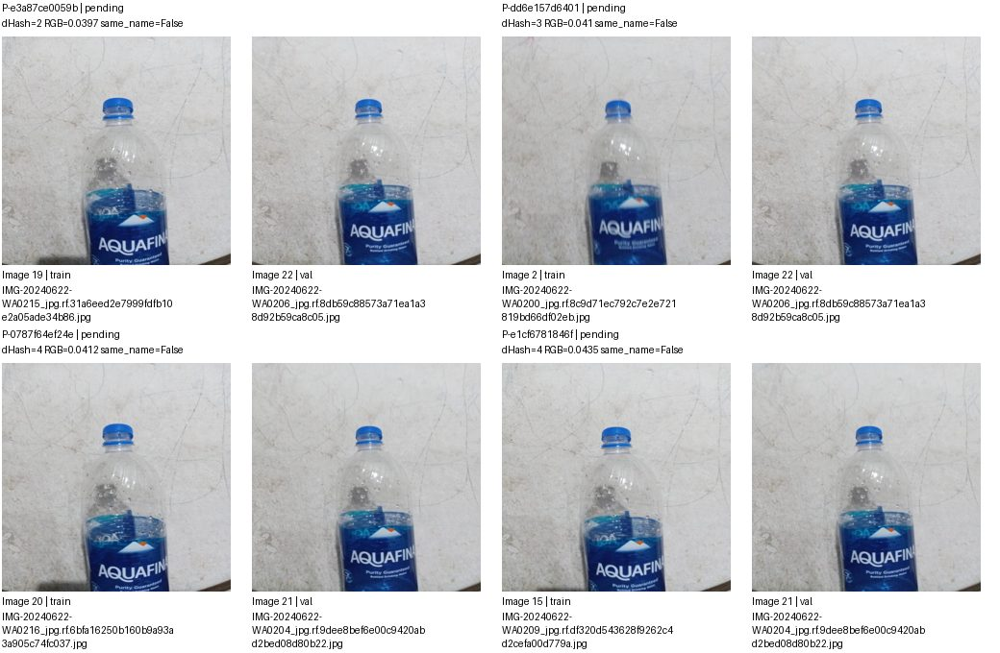

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-e3a87ce0059b,images/train/IMG-20240622-WA0215_jpg.rf.31a6eed2e7999fdfb10e2a05ade34b86.jpg,images/val/IMG-20240622-WA0206_jpg.rf.8db59c88573a71ea1a38d92b59ca8c05.jpg,pending,
P-dd6e157d6401,images/train/IMG-20240622-WA0200_jpg.rf.8c9d71ec792c7e2e721819bd66df02eb.jpg,images/val/IMG-20240622-WA0206_jpg.rf.8db59c88573a71ea1a38d92b59ca8c05.jpg,pending,
P-0787f64ef24e,images/train/IMG-20240622-WA0216_jpg.rf.6bfa16250b160b9a93a3a905c74fc037.jpg,images/val/IMG-20240622-WA0204_jpg.rf.9dee8bef6e00c9420abd2bed08d80b22.jpg,pending,
P-e1cf6781846f,images/train/IMG-20240622-WA0209_jpg.rf.df320d543628f9262c4d2cefa00d779a.jpg,images/val/IMG-20240622-WA0204_jpg.rf.9dee8bef6e00c9420abd2bed08d80b22.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 105/166 G-90031528f80a | 23 ảnh, 42 cặp
Split: {'train': 20, 'val': 3}
Quyết định: {'pending': 42}
Ảnh trang None/4; cặp trang 8/11. Nhóm liên thông không phải kết luận trùng.


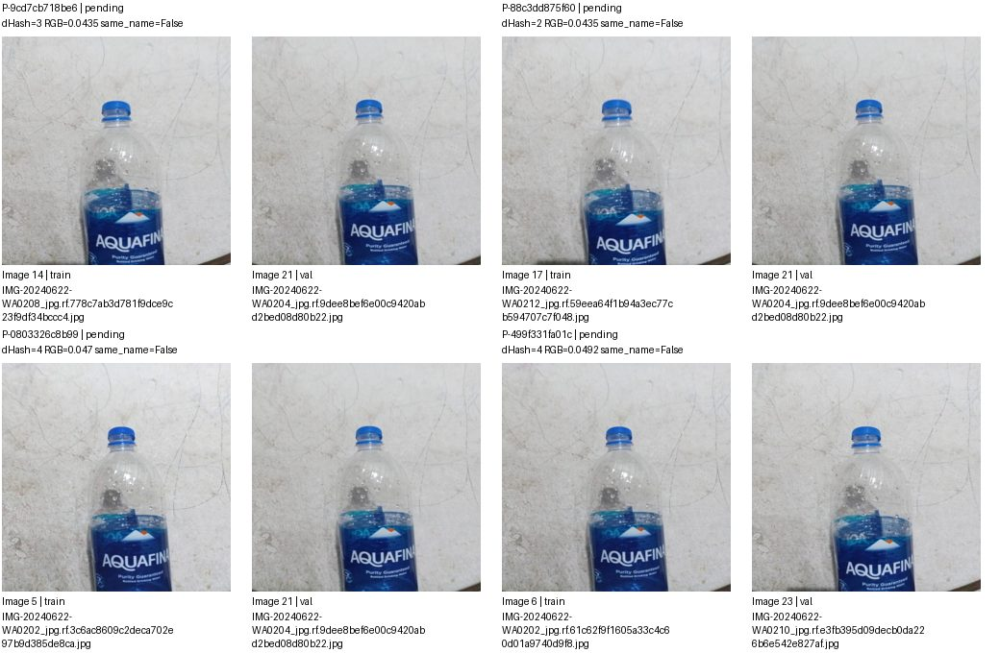

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-9cd7cb718be6,images/train/IMG-20240622-WA0208_jpg.rf.778c7ab3d781f9dce9c23f9df34bccc4.jpg,images/val/IMG-20240622-WA0204_jpg.rf.9dee8bef6e00c9420abd2bed08d80b22.jpg,pending,
P-88c3dd875f60,images/train/IMG-20240622-WA0212_jpg.rf.59eea64f1b94a3ec77cb594707c7f048.jpg,images/val/IMG-20240622-WA0204_jpg.rf.9dee8bef6e00c9420abd2bed08d80b22.jpg,pending,
P-0803326c8b99,images/train/IMG-20240622-WA0202_jpg.rf.3c6ac8609c2deca702e97b9d385de8ca.jpg,images/val/IMG-20240622-WA0204_jpg.rf.9dee8bef6e00c9420abd2bed08d80b22.jpg,pending,
P-499f331fa01c,images/train/IMG-20240622-WA0202_jpg.rf.61c62f9f1605a33c4c60d01a9740d9f8.jpg,images/val/IMG-20240622-WA0210_jpg.rf.e3fb395d09decb0da226b6e542e827af.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 105/166 G-90031528f80a | 23 ảnh, 42 cặp
Split: {'train': 20, 'val': 3}
Quyết định: {'pending': 42}
Ảnh trang None/4; cặp trang 9/11. Nhóm liên thông không phải kết luận trùng.


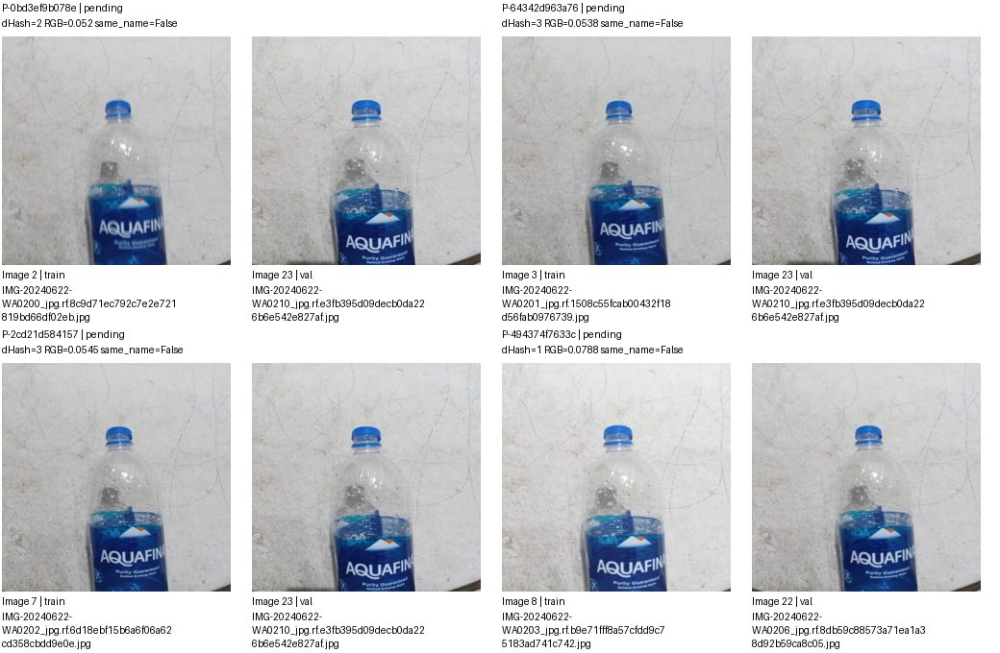

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-0bd3ef9b078e,images/train/IMG-20240622-WA0200_jpg.rf.8c9d71ec792c7e2e721819bd66df02eb.jpg,images/val/IMG-20240622-WA0210_jpg.rf.e3fb395d09decb0da226b6e542e827af.jpg,pending,
P-64342d963a76,images/train/IMG-20240622-WA0201_jpg.rf.1508c55fcab00432f18d56fab0976739.jpg,images/val/IMG-20240622-WA0210_jpg.rf.e3fb395d09decb0da226b6e542e827af.jpg,pending,
P-2cd21d584157,images/train/IMG-20240622-WA0202_jpg.rf.6d18ebf15b6a6f06a62cd358cbdd9e0e.jpg,images/val/IMG-20240622-WA0210_jpg.rf.e3fb395d09decb0da226b6e542e827af.jpg,pending,
P-494374f7633c,images/train/IMG-20240622-WA0203_jpg.rf.b9e71fff8a57cfdd9c75183ad741c742.jpg,images/val/IMG-20240622-WA0206_jpg.rf.8db59c88573a71ea1a38d92b59ca8c05.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 105/166 G-90031528f80a | 23 ảnh, 42 cặp
Split: {'train': 20, 'val': 3}
Quyết định: {'pending': 42}
Ảnh trang None/4; cặp trang 10/11. Nhóm liên thông không phải kết luận trùng.


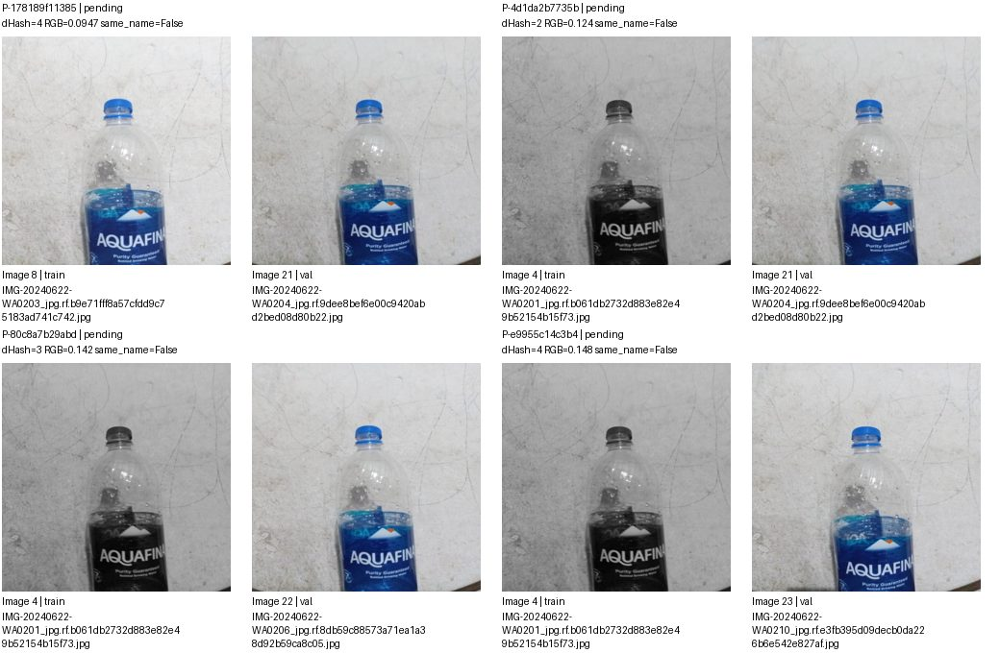

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-178189f11385,images/train/IMG-20240622-WA0203_jpg.rf.b9e71fff8a57cfdd9c75183ad741c742.jpg,images/val/IMG-20240622-WA0204_jpg.rf.9dee8bef6e00c9420abd2bed08d80b22.jpg,pending,
P-4d1da2b7735b,images/train/IMG-20240622-WA0201_jpg.rf.b061db2732d883e82e49b52154b15f73.jpg,images/val/IMG-20240622-WA0204_jpg.rf.9dee8bef6e00c9420abd2bed08d80b22.jpg,pending,
P-80c8a7b29abd,images/train/IMG-20240622-WA0201_jpg.rf.b061db2732d883e82e49b52154b15f73.jpg,images/val/IMG-20240622-WA0206_jpg.rf.8db59c88573a71ea1a38d92b59ca8c05.jpg,pending,
P-e9955c14c3b4,images/train/IMG-20240622-WA0201_jpg.rf.b061db2732d883e82e49b52154b15f73.jpg,images/val/IMG-20240622-WA0210_jpg.rf.e3fb395d09decb0da226b6e542e827af.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 105/166 G-90031528f80a | 23 ảnh, 42 cặp
Split: {'train': 20, 'val': 3}
Quyết định: {'pending': 42}
Ảnh trang None/4; cặp trang 11/11. Nhóm liên thông không phải kết luận trùng.


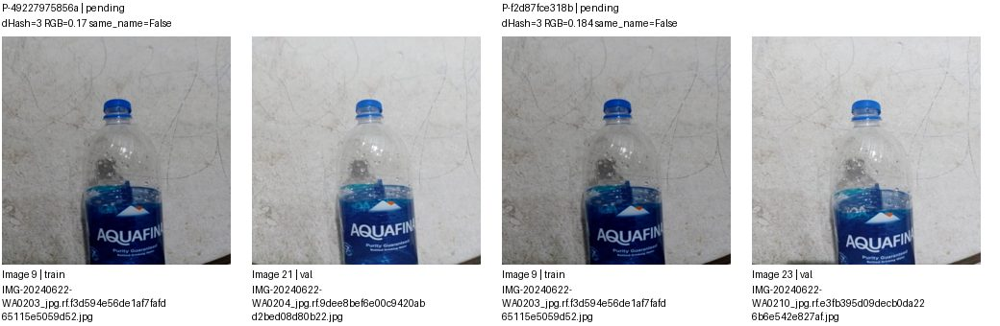

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-49227975856a,images/train/IMG-20240622-WA0203_jpg.rf.f3d594e56de1af7fafd65115e5059d52.jpg,images/val/IMG-20240622-WA0204_jpg.rf.9dee8bef6e00c9420abd2bed08d80b22.jpg,pending,
P-f2d87fce318b,images/train/IMG-20240622-WA0203_jpg.rf.f3d594e56de1af7fafd65115e5059d52.jpg,images/val/IMG-20240622-WA0210_jpg.rf.e3fb395d09decb0da226b6e542e827af.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 106/166 G-6e574f252b78 | 8 ảnh, 13 cặp
Split: {'test': 1, 'train': 6, 'val': 1}
Quyết định: {'pending': 13}
Ảnh trang 1/2; cặp trang 1/4. Nhóm liên thông không phải kết luận trùng.


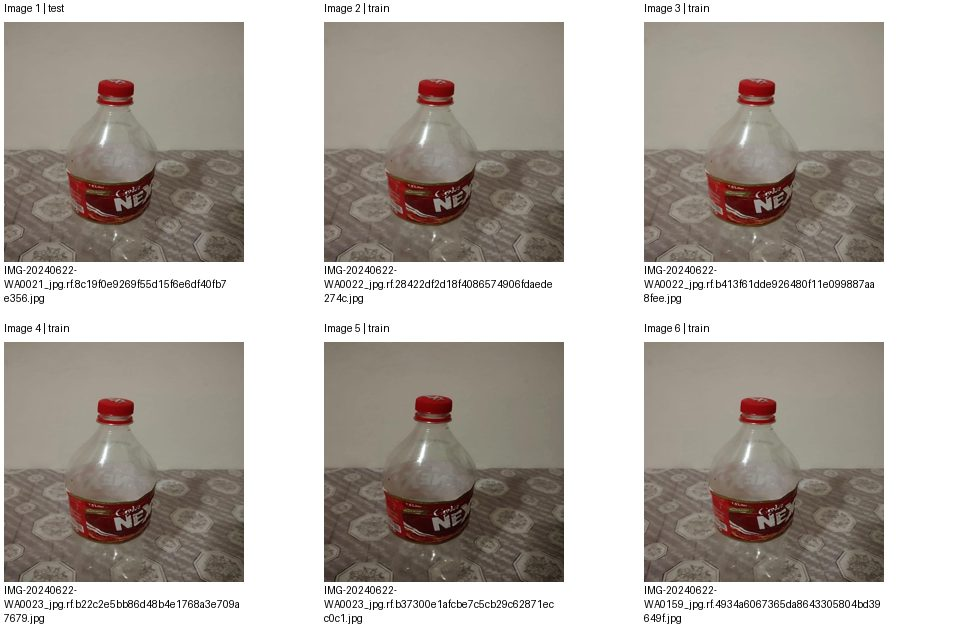

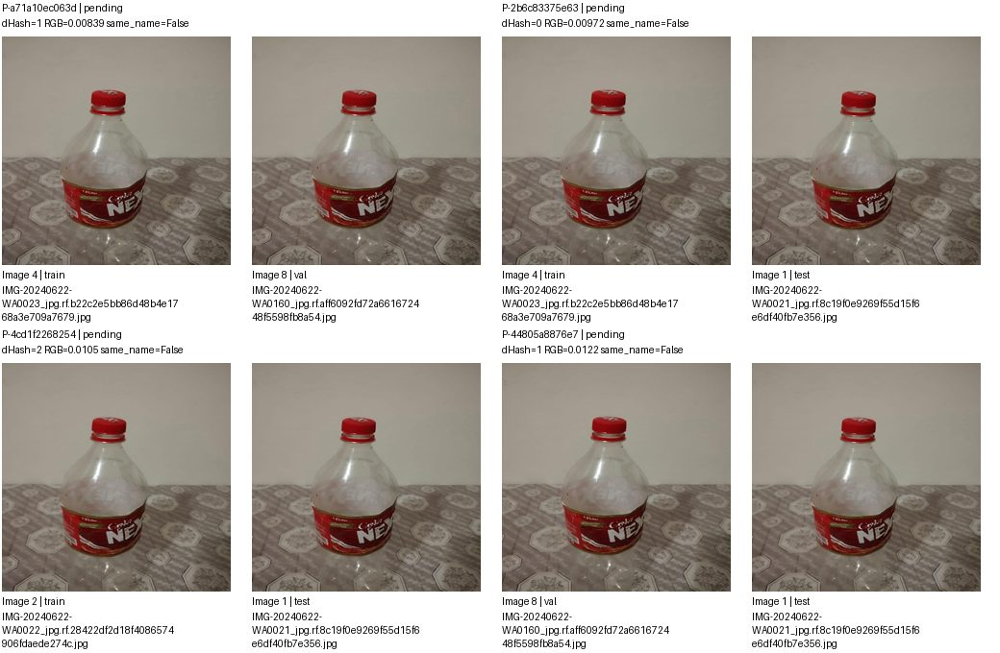

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-a71a10ec063d,images/train/IMG-20240622-WA0023_jpg.rf.b22c2e5bb86d48b4e1768a3e709a7679.jpg,images/val/IMG-20240622-WA0160_jpg.rf.aff6092fd72a661672448f5598fb8a54.jpg,pending,
P-2b6c83375e63,images/train/IMG-20240622-WA0023_jpg.rf.b22c2e5bb86d48b4e1768a3e709a7679.jpg,images/test/IMG-20240622-WA0021_jpg.rf.8c19f0e9269f55d15f6e6df40fb7e356.jpg,pending,
P-4cd1f2268254,images/train/IMG-20240622-WA0022_jpg.rf.28422df2d18f4086574906fdaede274c.jpg,images/test/IMG-20240622-WA0021_jpg.rf.8c19f0e9269f55d15f6e6df40fb7e356.jpg,pending,
P-44805a8876e7,images/val/IMG-20240622-WA0160_jpg.rf.aff6092fd72a661672448f5598fb8a54.jpg,images/test/IMG-20240622-WA0021_jpg.rf.8c19f0e9269f55d15f6e6df40fb7e356.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 106/166 G-6e574f252b78 | 8 ảnh, 13 cặp
Split: {'test': 1, 'train': 6, 'val': 1}
Quyết định: {'pending': 13}
Ảnh trang 2/2; cặp trang 2/4. Nhóm liên thông không phải kết luận trùng.


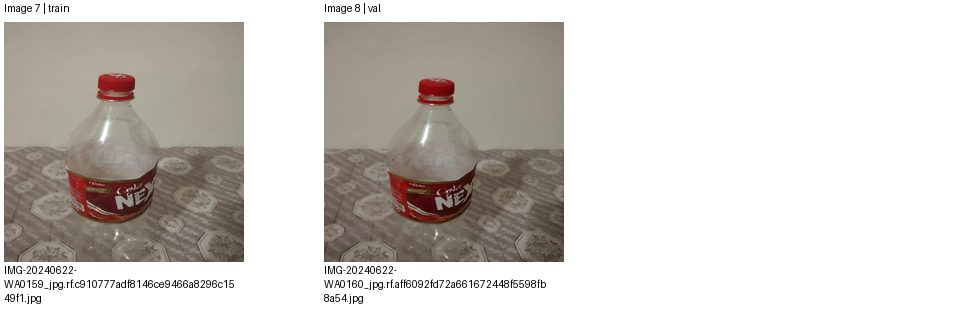

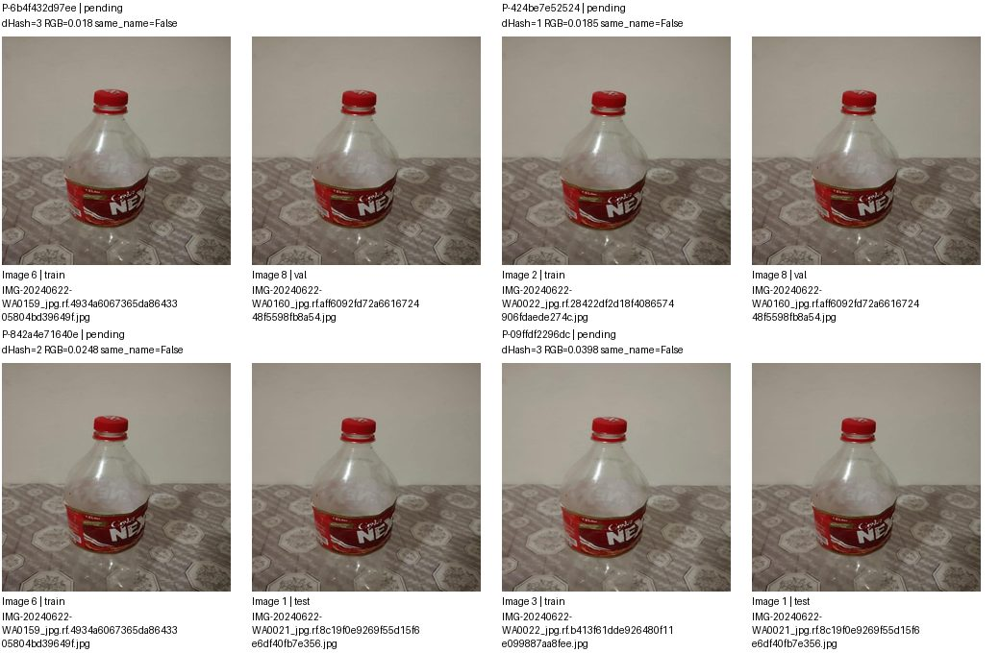

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-6b4f432d97ee,images/train/IMG-20240622-WA0159_jpg.rf.4934a6067365da8643305804bd39649f.jpg,images/val/IMG-20240622-WA0160_jpg.rf.aff6092fd72a661672448f5598fb8a54.jpg,pending,
P-424be7e52524,images/train/IMG-20240622-WA0022_jpg.rf.28422df2d18f4086574906fdaede274c.jpg,images/val/IMG-20240622-WA0160_jpg.rf.aff6092fd72a661672448f5598fb8a54.jpg,pending,
P-842a4e71640e,images/train/IMG-20240622-WA0159_jpg.rf.4934a6067365da8643305804bd39649f.jpg,images/test/IMG-20240622-WA0021_jpg.rf.8c19f0e9269f55d15f6e6df40fb7e356.jpg,pending,
P-09ffdf2296dc,images/train/IMG-20240622-WA0022_jpg.rf.b413f61dde926480f11e099887aa8fee.jpg,images/test/IMG-20240622-WA0021_jpg.rf.8c19f0e9269f55d15f6e6df40fb7e356.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 106/166 G-6e574f252b78 | 8 ảnh, 13 cặp
Split: {'test': 1, 'train': 6, 'val': 1}
Quyết định: {'pending': 13}
Ảnh trang None/2; cặp trang 3/4. Nhóm liên thông không phải kết luận trùng.


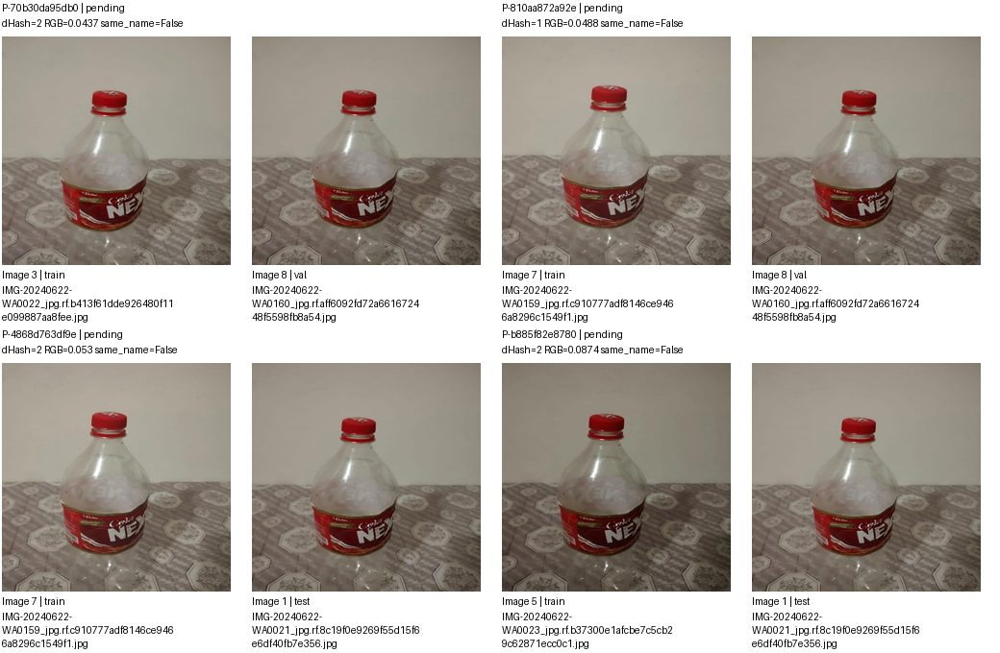

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-70b30da95db0,images/train/IMG-20240622-WA0022_jpg.rf.b413f61dde926480f11e099887aa8fee.jpg,images/val/IMG-20240622-WA0160_jpg.rf.aff6092fd72a661672448f5598fb8a54.jpg,pending,
P-810aa872a92e,images/train/IMG-20240622-WA0159_jpg.rf.c910777adf8146ce9466a8296c1549f1.jpg,images/val/IMG-20240622-WA0160_jpg.rf.aff6092fd72a661672448f5598fb8a54.jpg,pending,
P-4868d763df9e,images/train/IMG-20240622-WA0159_jpg.rf.c910777adf8146ce9466a8296c1549f1.jpg,images/test/IMG-20240622-WA0021_jpg.rf.8c19f0e9269f55d15f6e6df40fb7e356.jpg,pending,
P-b885f82e8780,images/train/IMG-20240622-WA0023_jpg.rf.b37300e1afcbe7c5cb29c62871ecc0c1.jpg,images/test/IMG-20240622-WA0021_jpg.rf.8c19f0e9269f55d15f6e6df40fb7e356.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 106/166 G-6e574f252b78 | 8 ảnh, 13 cặp
Split: {'test': 1, 'train': 6, 'val': 1}
Quyết định: {'pending': 13}
Ảnh trang None/2; cặp trang 4/4. Nhóm liên thông không phải kết luận trùng.


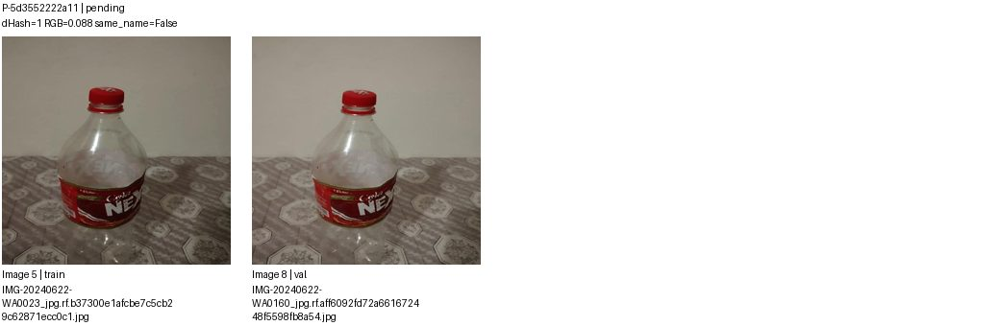

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-5d3552222a11,images/train/IMG-20240622-WA0023_jpg.rf.b37300e1afcbe7c5cb29c62871ecc0c1.jpg,images/val/IMG-20240622-WA0160_jpg.rf.aff6092fd72a661672448f5598fb8a54.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 107/166 G-ac085b36b91a | 19 ảnh, 113 cặp
Split: {'test': 5, 'train': 5, 'val': 9}
Quyết định: {'pending': 113}
Ảnh trang 1/4; cặp trang 1/29. Nhóm liên thông không phải kết luận trùng.


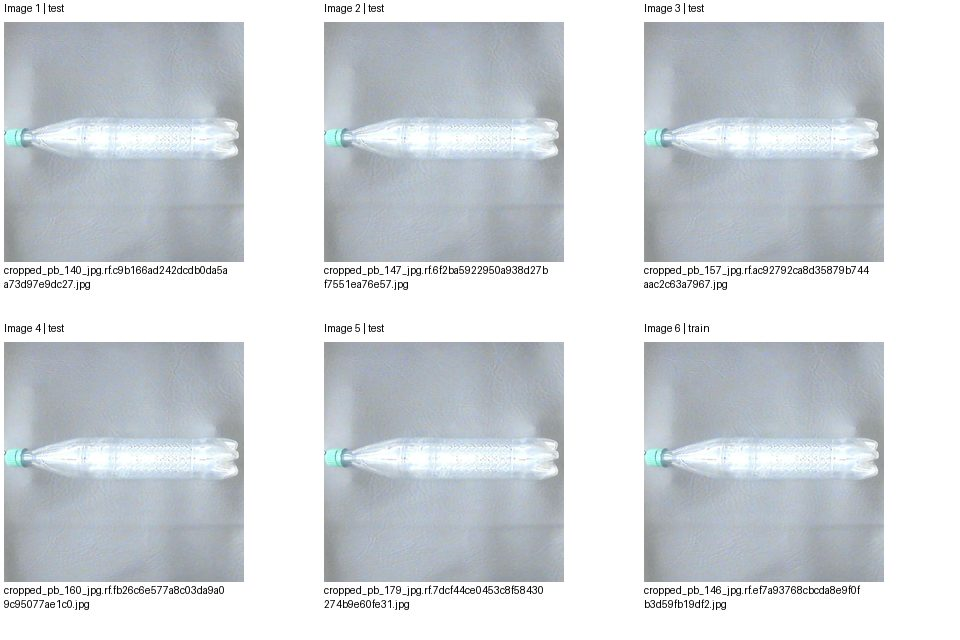

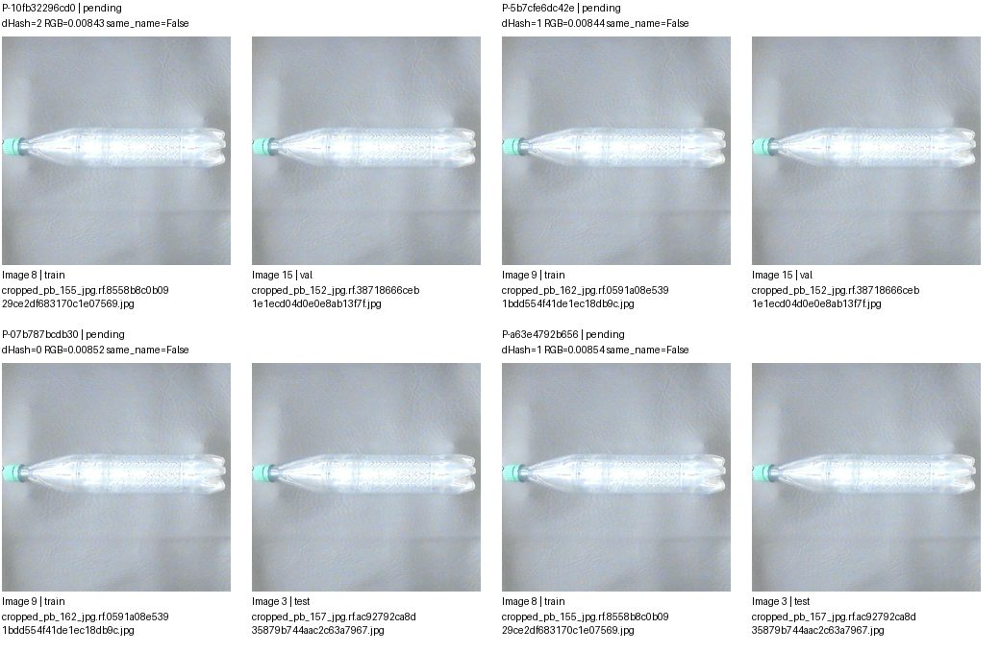

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-10fb32296cd0,images/train/cropped_pb_155_jpg.rf.8558b8c0b0929ce2df683170c1e07569.jpg,images/val/cropped_pb_152_jpg.rf.38718666ceb1e1ecd04d0e0e8ab13f7f.jpg,pending,
P-5b7cfe6dc42e,images/train/cropped_pb_162_jpg.rf.0591a08e5391bdd554f41de1ec18db9c.jpg,images/val/cropped_pb_152_jpg.rf.38718666ceb1e1ecd04d0e0e8ab13f7f.jpg,pending,
P-07b787bcdb30,images/train/cropped_pb_162_jpg.rf.0591a08e5391bdd554f41de1ec18db9c.jpg,images/test/cropped_pb_157_jpg.rf.ac92792ca8d35879b744aac2c63a7967.jpg,pending,
P-a63e4792b656,images/train/cropped_pb_155_jpg.rf.8558b8c0b0929ce2df683170c1e07569.jpg,images/test/cropped_pb_157_jpg.rf.ac92792ca8d35879b744aac2c63a7967.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 107/166 G-ac085b36b91a | 19 ảnh, 113 cặp
Split: {'test': 5, 'train': 5, 'val': 9}
Quyết định: {'pending': 113}
Ảnh trang 2/4; cặp trang 2/29. Nhóm liên thông không phải kết luận trùng.


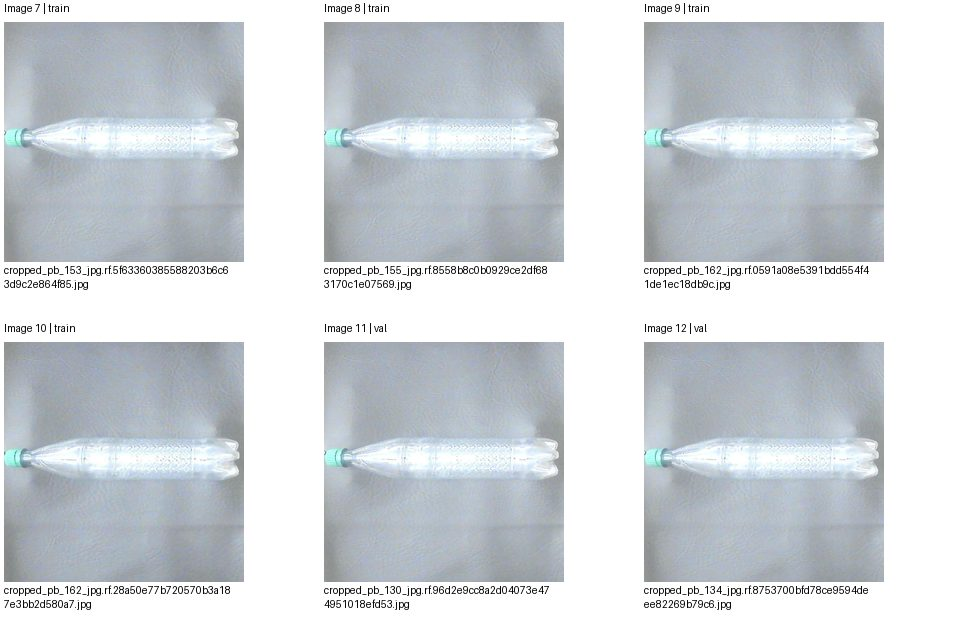

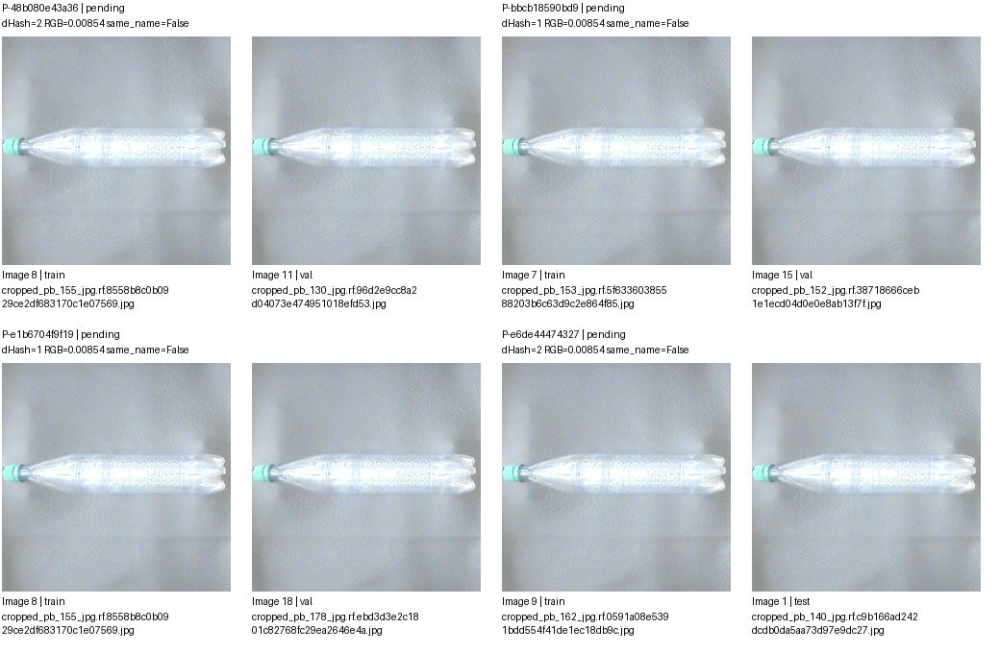

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-48b080e43a36,images/train/cropped_pb_155_jpg.rf.8558b8c0b0929ce2df683170c1e07569.jpg,images/val/cropped_pb_130_jpg.rf.96d2e9cc8a2d04073e474951018efd53.jpg,pending,
P-bbcb18590bd9,images/train/cropped_pb_153_jpg.rf.5f63360385588203b6c63d9c2e864f85.jpg,images/val/cropped_pb_152_jpg.rf.38718666ceb1e1ecd04d0e0e8ab13f7f.jpg,pending,
P-e1b6704f9f19,images/train/cropped_pb_155_jpg.rf.8558b8c0b0929ce2df683170c1e07569.jpg,images/val/cropped_pb_178_jpg.rf.ebd3d3e2c1801c82768fc29ea2646e4a.jpg,pending,
P-e6de44474327,images/train/cropped_pb_162_jpg.rf.0591a08e5391bdd554f41de1ec18db9c.jpg,images/test/cropped_pb_140_jpg.rf.c9b166ad242dcdb0da5aa73d97e9dc27.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 107/166 G-ac085b36b91a | 19 ảnh, 113 cặp
Split: {'test': 5, 'train': 5, 'val': 9}
Quyết định: {'pending': 113}
Ảnh trang 3/4; cặp trang 3/29. Nhóm liên thông không phải kết luận trùng.


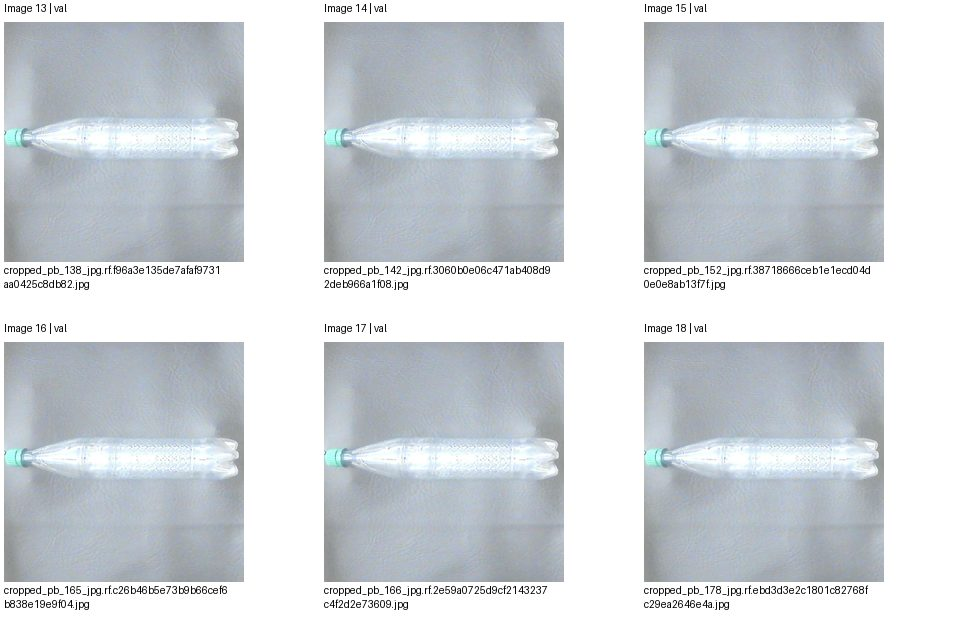

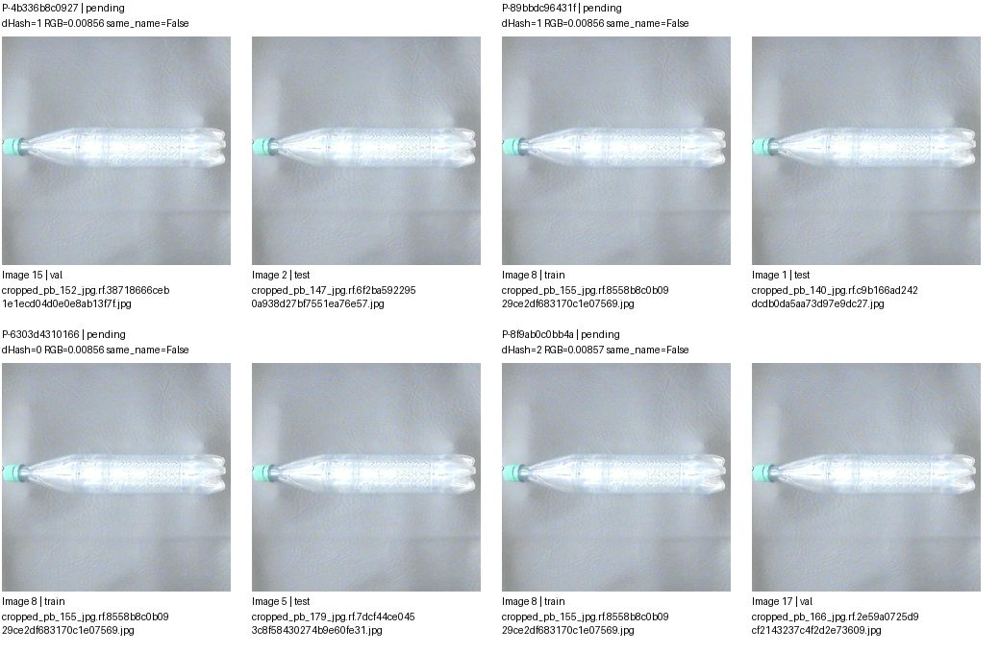

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-4b336b8c0927,images/val/cropped_pb_152_jpg.rf.38718666ceb1e1ecd04d0e0e8ab13f7f.jpg,images/test/cropped_pb_147_jpg.rf.6f2ba5922950a938d27bf7551ea76e57.jpg,pending,
P-89bbdc96431f,images/train/cropped_pb_155_jpg.rf.8558b8c0b0929ce2df683170c1e07569.jpg,images/test/cropped_pb_140_jpg.rf.c9b166ad242dcdb0da5aa73d97e9dc27.jpg,pending,
P-6303d4310166,images/train/cropped_pb_155_jpg.rf.8558b8c0b0929ce2df683170c1e07569.jpg,images/test/cropped_pb_179_jpg.rf.7dcf44ce0453c8f58430274b9e60fe31.jpg,pending,
P-8f9ab0c0bb4a,images/train/cropped_pb_155_jpg.rf.8558b8c0b0929ce2df683170c1e07569.jpg,images/val/cropped_pb_166_jpg.rf.2e59a0725d9cf2143237c4f2d2e73609.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 107/166 G-ac085b36b91a | 19 ảnh, 113 cặp
Split: {'test': 5, 'train': 5, 'val': 9}
Quyết định: {'pending': 113}
Ảnh trang 4/4; cặp trang 4/29. Nhóm liên thông không phải kết luận trùng.


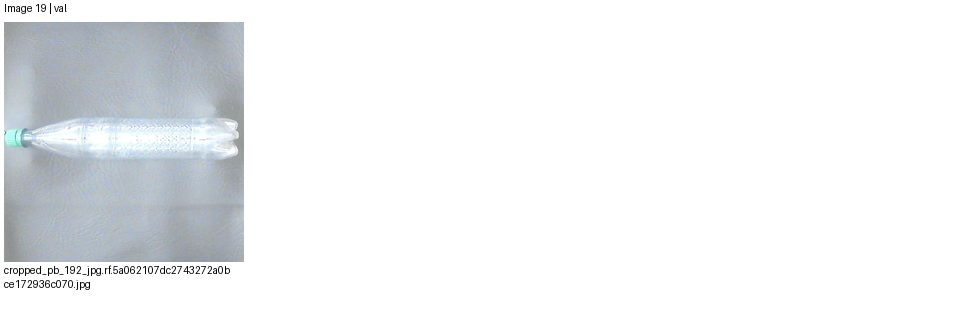

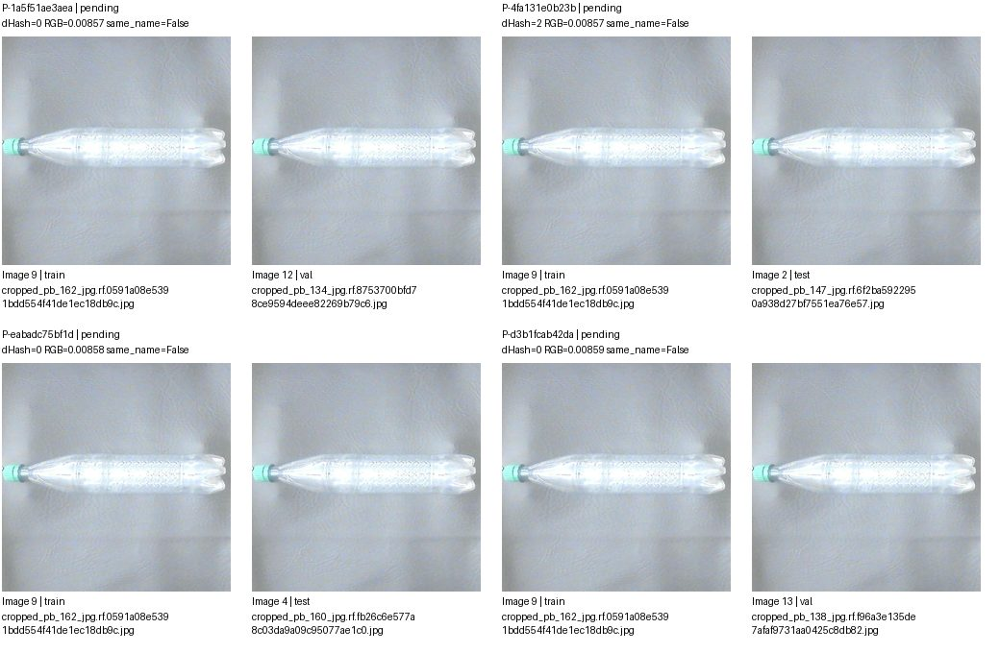

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-1a5f51ae3aea,images/train/cropped_pb_162_jpg.rf.0591a08e5391bdd554f41de1ec18db9c.jpg,images/val/cropped_pb_134_jpg.rf.8753700bfd78ce9594deee82269b79c6.jpg,pending,
P-4fa131e0b23b,images/train/cropped_pb_162_jpg.rf.0591a08e5391bdd554f41de1ec18db9c.jpg,images/test/cropped_pb_147_jpg.rf.6f2ba5922950a938d27bf7551ea76e57.jpg,pending,
P-eabadc75bf1d,images/train/cropped_pb_162_jpg.rf.0591a08e5391bdd554f41de1ec18db9c.jpg,images/test/cropped_pb_160_jpg.rf.fb26c6e577a8c03da9a09c95077ae1c0.jpg,pending,
P-d3b1fcab42da,images/train/cropped_pb_162_jpg.rf.0591a08e5391bdd554f41de1ec18db9c.jpg,images/val/cropped_pb_138_jpg.rf.f96a3e135de7afaf9731aa0425c8db82.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 107/166 G-ac085b36b91a | 19 ảnh, 113 cặp
Split: {'test': 5, 'train': 5, 'val': 9}
Quyết định: {'pending': 113}
Ảnh trang None/4; cặp trang 5/29. Nhóm liên thông không phải kết luận trùng.


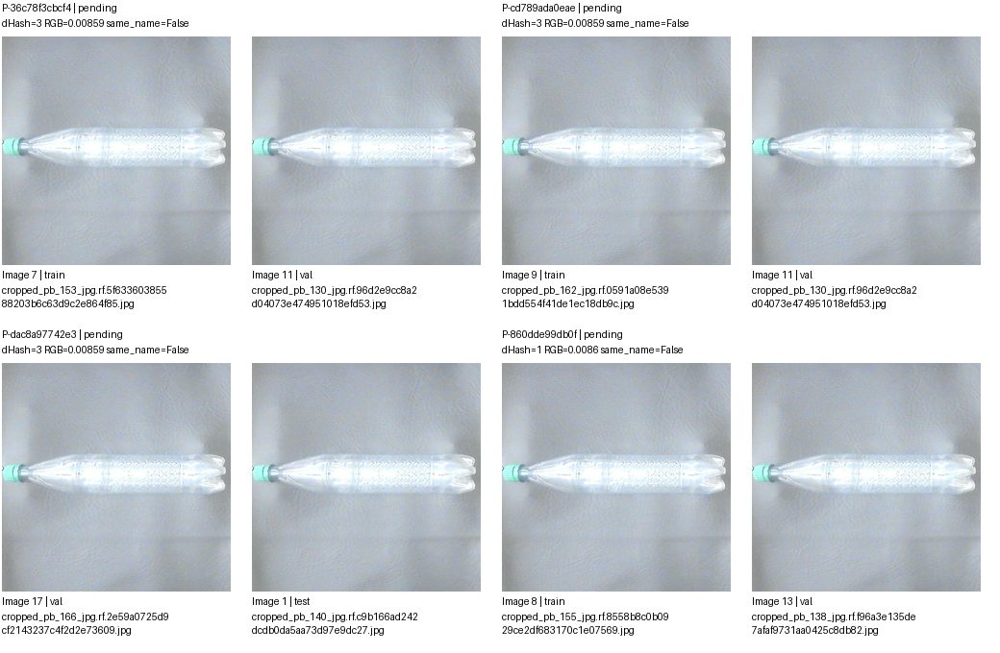

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-36c78f3cbcf4,images/train/cropped_pb_153_jpg.rf.5f63360385588203b6c63d9c2e864f85.jpg,images/val/cropped_pb_130_jpg.rf.96d2e9cc8a2d04073e474951018efd53.jpg,pending,
P-cd789ada0eae,images/train/cropped_pb_162_jpg.rf.0591a08e5391bdd554f41de1ec18db9c.jpg,images/val/cropped_pb_130_jpg.rf.96d2e9cc8a2d04073e474951018efd53.jpg,pending,
P-dac8a97742e3,images/val/cropped_pb_166_jpg.rf.2e59a0725d9cf2143237c4f2d2e73609.jpg,images/test/cropped_pb_140_jpg.rf.c9b166ad242dcdb0da5aa73d97e9dc27.jpg,pending,
P-860dde99db0f,images/train/cropped_pb_155_jpg.rf.8558b8c0b0929ce2df683170c1e07569.jpg,images/val/cropped_pb_138_jpg.rf.f96a3e135de7afaf9731aa0425c8db82.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 107/166 G-ac085b36b91a | 19 ảnh, 113 cặp
Split: {'test': 5, 'train': 5, 'val': 9}
Quyết định: {'pending': 113}
Ảnh trang None/4; cặp trang 6/29. Nhóm liên thông không phải kết luận trùng.


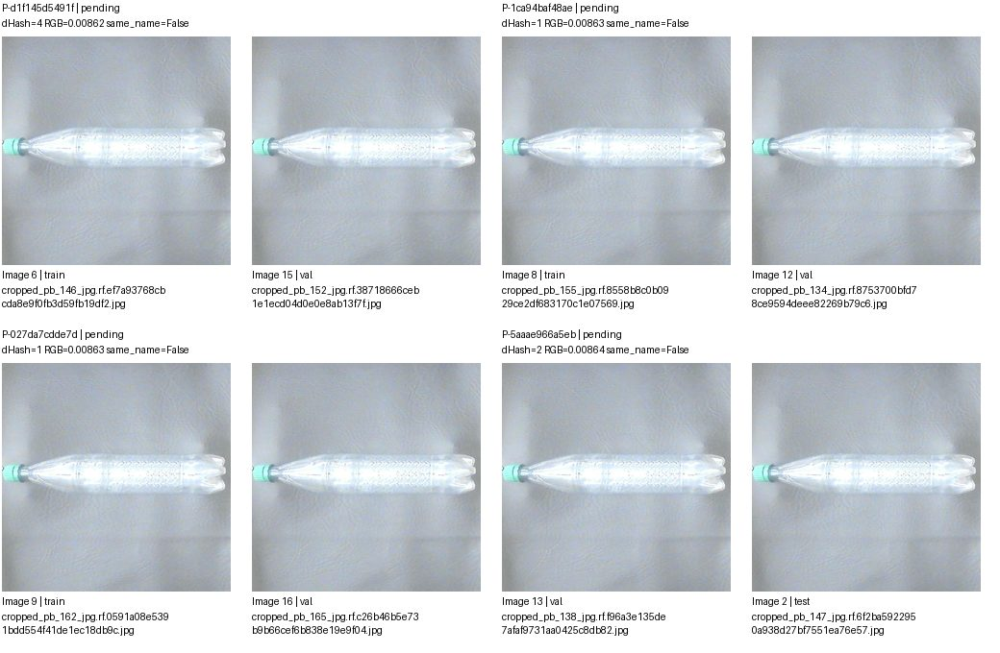

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-d1f145d5491f,images/train/cropped_pb_146_jpg.rf.ef7a93768cbcda8e9f0fb3d59fb19df2.jpg,images/val/cropped_pb_152_jpg.rf.38718666ceb1e1ecd04d0e0e8ab13f7f.jpg,pending,
P-1ca94baf48ae,images/train/cropped_pb_155_jpg.rf.8558b8c0b0929ce2df683170c1e07569.jpg,images/val/cropped_pb_134_jpg.rf.8753700bfd78ce9594deee82269b79c6.jpg,pending,
P-027da7cdde7d,images/train/cropped_pb_162_jpg.rf.0591a08e5391bdd554f41de1ec18db9c.jpg,images/val/cropped_pb_165_jpg.rf.c26b46b5e73b9b66cef6b838e19e9f04.jpg,pending,
P-5aaae966a5eb,images/val/cropped_pb_138_jpg.rf.f96a3e135de7afaf9731aa0425c8db82.jpg,images/test/cropped_pb_147_jpg.rf.6f2ba5922950a938d27bf7551ea76e57.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 107/166 G-ac085b36b91a | 19 ảnh, 113 cặp
Split: {'test': 5, 'train': 5, 'val': 9}
Quyết định: {'pending': 113}
Ảnh trang None/4; cặp trang 7/29. Nhóm liên thông không phải kết luận trùng.


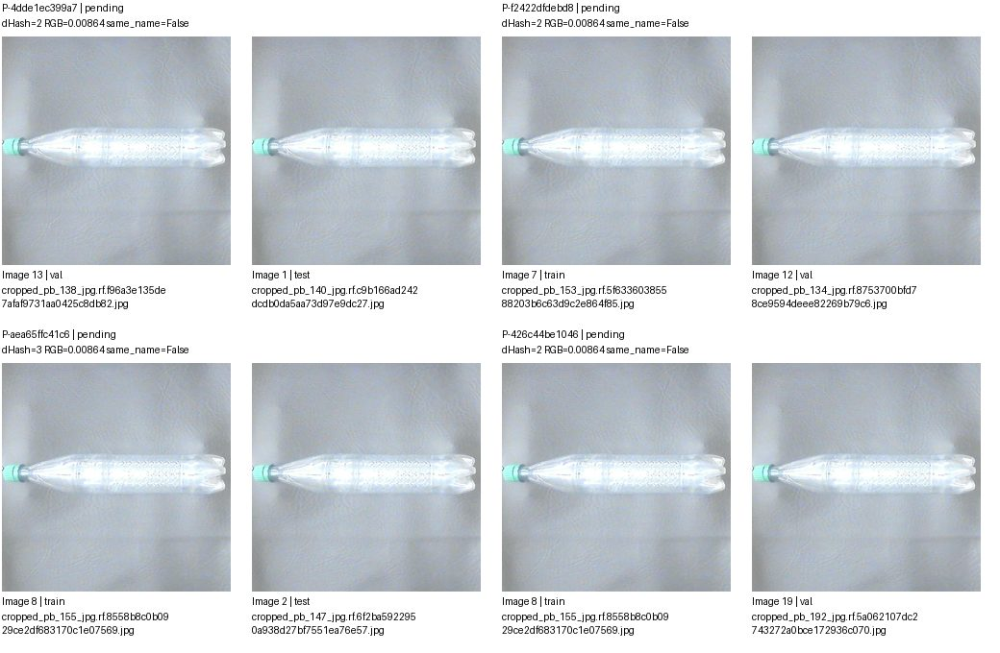

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-4dde1ec399a7,images/val/cropped_pb_138_jpg.rf.f96a3e135de7afaf9731aa0425c8db82.jpg,images/test/cropped_pb_140_jpg.rf.c9b166ad242dcdb0da5aa73d97e9dc27.jpg,pending,
P-f2422dfdebd8,images/train/cropped_pb_153_jpg.rf.5f63360385588203b6c63d9c2e864f85.jpg,images/val/cropped_pb_134_jpg.rf.8753700bfd78ce9594deee82269b79c6.jpg,pending,
P-aea65ffc41c6,images/train/cropped_pb_155_jpg.rf.8558b8c0b0929ce2df683170c1e07569.jpg,images/test/cropped_pb_147_jpg.rf.6f2ba5922950a938d27bf7551ea76e57.jpg,pending,
P-426c44be1046,images/train/cropped_pb_155_jpg.rf.8558b8c0b0929ce2df683170c1e07569.jpg,images/val/cropped_pb_192_jpg.rf.5a062107dc2743272a0bce172936c070.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 107/166 G-ac085b36b91a | 19 ảnh, 113 cặp
Split: {'test': 5, 'train': 5, 'val': 9}
Quyết định: {'pending': 113}
Ảnh trang None/4; cặp trang 8/29. Nhóm liên thông không phải kết luận trùng.


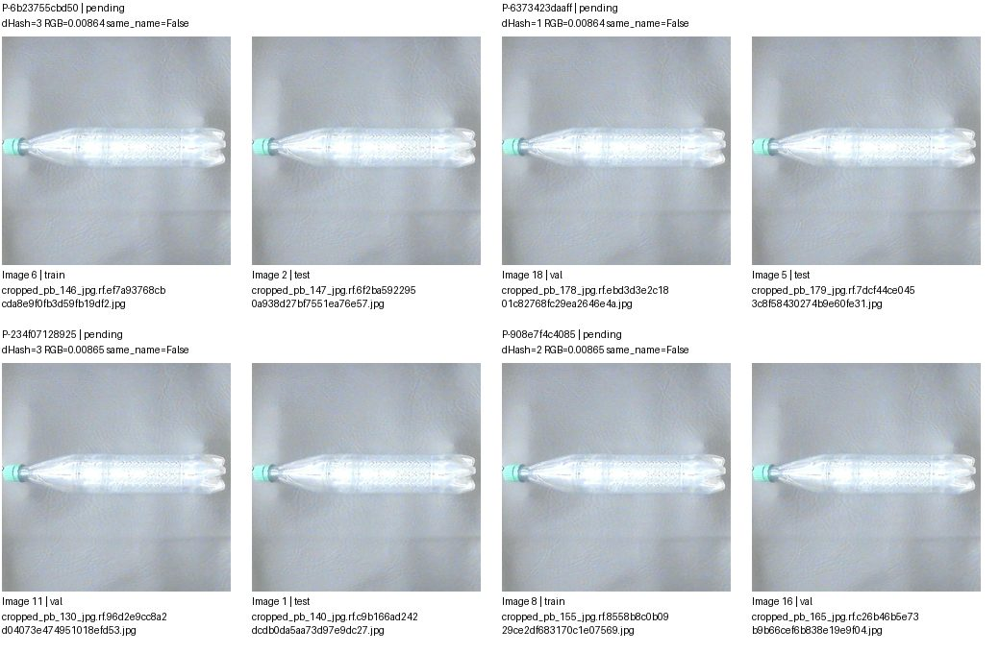

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-6b23755cbd50,images/train/cropped_pb_146_jpg.rf.ef7a93768cbcda8e9f0fb3d59fb19df2.jpg,images/test/cropped_pb_147_jpg.rf.6f2ba5922950a938d27bf7551ea76e57.jpg,pending,
P-6373423daaff,images/val/cropped_pb_178_jpg.rf.ebd3d3e2c1801c82768fc29ea2646e4a.jpg,images/test/cropped_pb_179_jpg.rf.7dcf44ce0453c8f58430274b9e60fe31.jpg,pending,
P-234f07128925,images/val/cropped_pb_130_jpg.rf.96d2e9cc8a2d04073e474951018efd53.jpg,images/test/cropped_pb_140_jpg.rf.c9b166ad242dcdb0da5aa73d97e9dc27.jpg,pending,
P-908e7f4c4085,images/train/cropped_pb_155_jpg.rf.8558b8c0b0929ce2df683170c1e07569.jpg,images/val/cropped_pb_165_jpg.rf.c26b46b5e73b9b66cef6b838e19e9f04.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 107/166 G-ac085b36b91a | 19 ảnh, 113 cặp
Split: {'test': 5, 'train': 5, 'val': 9}
Quyết định: {'pending': 113}
Ảnh trang None/4; cặp trang 9/29. Nhóm liên thông không phải kết luận trùng.


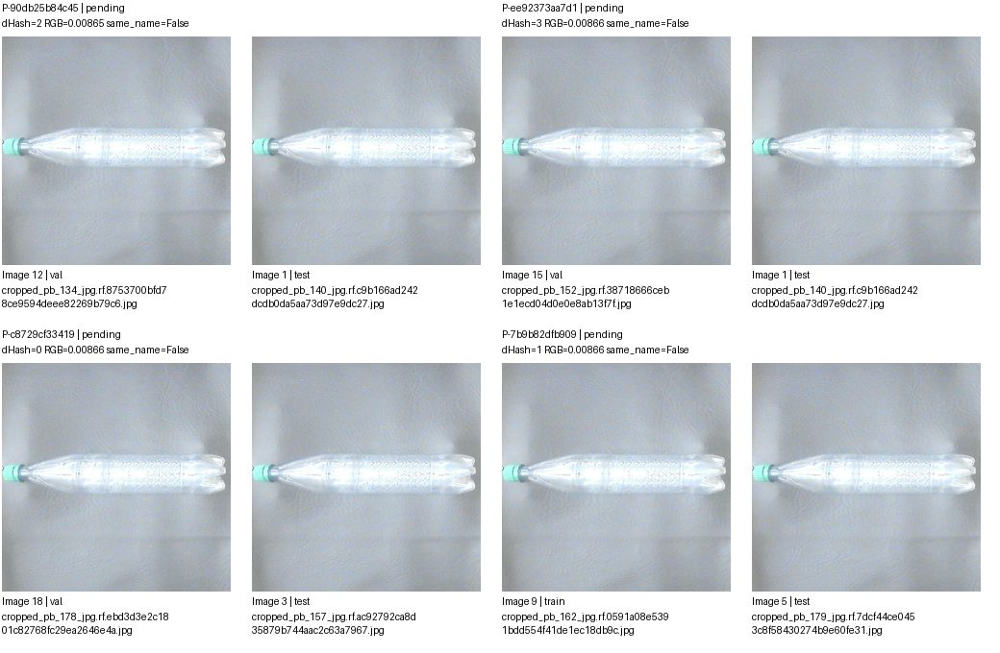

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-90db25b84c45,images/val/cropped_pb_134_jpg.rf.8753700bfd78ce9594deee82269b79c6.jpg,images/test/cropped_pb_140_jpg.rf.c9b166ad242dcdb0da5aa73d97e9dc27.jpg,pending,
P-ee92373aa7d1,images/val/cropped_pb_152_jpg.rf.38718666ceb1e1ecd04d0e0e8ab13f7f.jpg,images/test/cropped_pb_140_jpg.rf.c9b166ad242dcdb0da5aa73d97e9dc27.jpg,pending,
P-c8729cf33419,images/val/cropped_pb_178_jpg.rf.ebd3d3e2c1801c82768fc29ea2646e4a.jpg,images/test/cropped_pb_157_jpg.rf.ac92792ca8d35879b744aac2c63a7967.jpg,pending,
P-7b9b82dfb909,images/train/cropped_pb_162_jpg.rf.0591a08e5391bdd554f41de1ec18db9c.jpg,images/test/cropped_pb_179_jpg.rf.7dcf44ce0453c8f58430274b9e60fe31.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 107/166 G-ac085b36b91a | 19 ảnh, 113 cặp
Split: {'test': 5, 'train': 5, 'val': 9}
Quyết định: {'pending': 113}
Ảnh trang None/4; cặp trang 10/29. Nhóm liên thông không phải kết luận trùng.


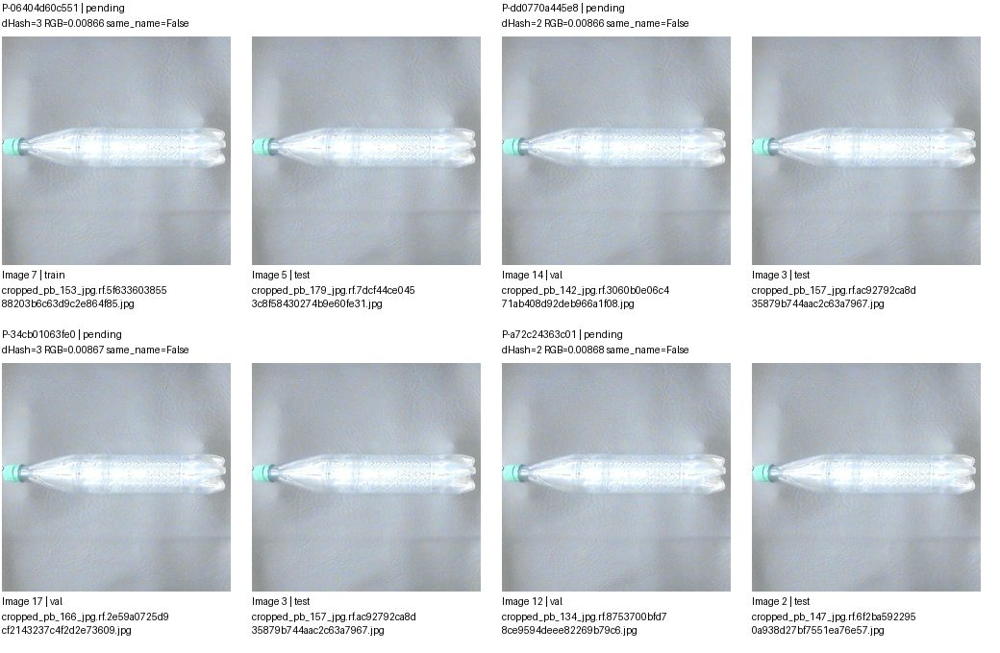

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-06404d60c551,images/train/cropped_pb_153_jpg.rf.5f63360385588203b6c63d9c2e864f85.jpg,images/test/cropped_pb_179_jpg.rf.7dcf44ce0453c8f58430274b9e60fe31.jpg,pending,
P-dd0770a445e8,images/val/cropped_pb_142_jpg.rf.3060b0e06c471ab408d92deb966a1f08.jpg,images/test/cropped_pb_157_jpg.rf.ac92792ca8d35879b744aac2c63a7967.jpg,pending,
P-34cb01063fe0,images/val/cropped_pb_166_jpg.rf.2e59a0725d9cf2143237c4f2d2e73609.jpg,images/test/cropped_pb_157_jpg.rf.ac92792ca8d35879b744aac2c63a7967.jpg,pending,
P-a72c24363c01,images/val/cropped_pb_134_jpg.rf.8753700bfd78ce9594deee82269b79c6.jpg,images/test/cropped_pb_147_jpg.rf.6f2ba5922950a938d27bf7551ea76e57.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 107/166 G-ac085b36b91a | 19 ảnh, 113 cặp
Split: {'test': 5, 'train': 5, 'val': 9}
Quyết định: {'pending': 113}
Ảnh trang None/4; cặp trang 11/29. Nhóm liên thông không phải kết luận trùng.


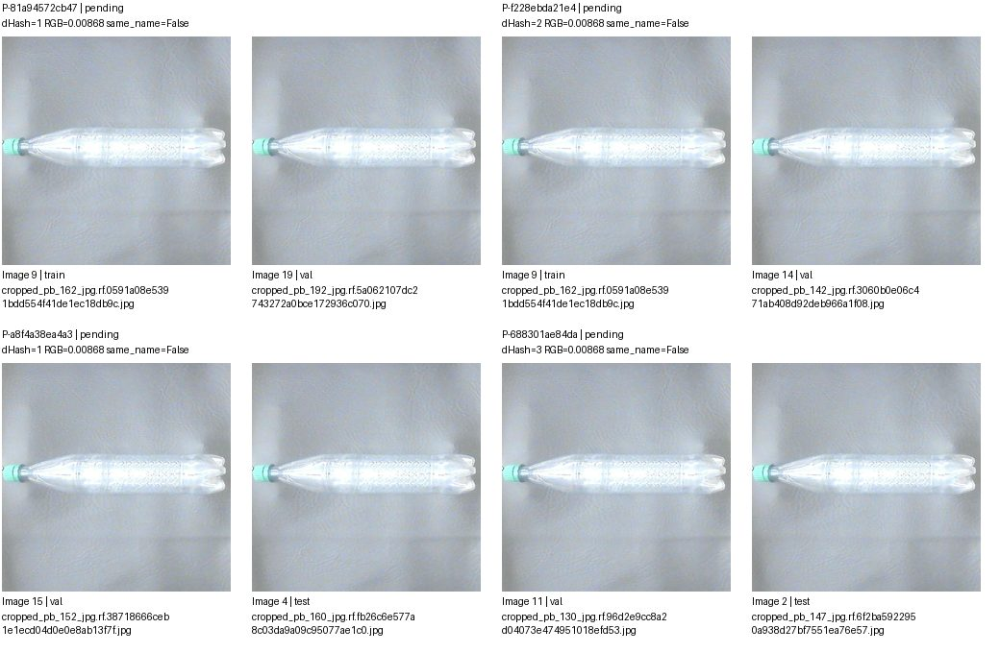

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-81a94572cb47,images/train/cropped_pb_162_jpg.rf.0591a08e5391bdd554f41de1ec18db9c.jpg,images/val/cropped_pb_192_jpg.rf.5a062107dc2743272a0bce172936c070.jpg,pending,
P-f228ebda21e4,images/train/cropped_pb_162_jpg.rf.0591a08e5391bdd554f41de1ec18db9c.jpg,images/val/cropped_pb_142_jpg.rf.3060b0e06c471ab408d92deb966a1f08.jpg,pending,
P-a8f4a38ea4a3,images/val/cropped_pb_152_jpg.rf.38718666ceb1e1ecd04d0e0e8ab13f7f.jpg,images/test/cropped_pb_160_jpg.rf.fb26c6e577a8c03da9a09c95077ae1c0.jpg,pending,
P-688301ae84da,images/val/cropped_pb_130_jpg.rf.96d2e9cc8a2d04073e474951018efd53.jpg,images/test/cropped_pb_147_jpg.rf.6f2ba5922950a938d27bf7551ea76e57.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 107/166 G-ac085b36b91a | 19 ảnh, 113 cặp
Split: {'test': 5, 'train': 5, 'val': 9}
Quyết định: {'pending': 113}
Ảnh trang None/4; cặp trang 12/29. Nhóm liên thông không phải kết luận trùng.


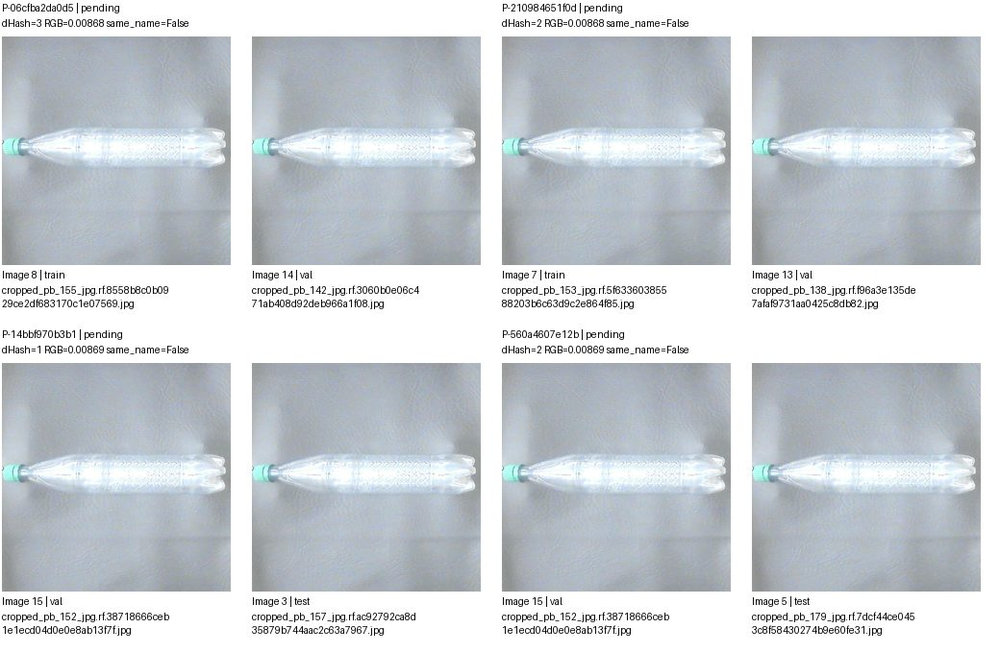

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-06cfba2da0d5,images/train/cropped_pb_155_jpg.rf.8558b8c0b0929ce2df683170c1e07569.jpg,images/val/cropped_pb_142_jpg.rf.3060b0e06c471ab408d92deb966a1f08.jpg,pending,
P-210984651f0d,images/train/cropped_pb_153_jpg.rf.5f63360385588203b6c63d9c2e864f85.jpg,images/val/cropped_pb_138_jpg.rf.f96a3e135de7afaf9731aa0425c8db82.jpg,pending,
P-14bbf970b3b1,images/val/cropped_pb_152_jpg.rf.38718666ceb1e1ecd04d0e0e8ab13f7f.jpg,images/test/cropped_pb_157_jpg.rf.ac92792ca8d35879b744aac2c63a7967.jpg,pending,
P-560a4607e12b,images/val/cropped_pb_152_jpg.rf.38718666ceb1e1ecd04d0e0e8ab13f7f.jpg,images/test/cropped_pb_179_jpg.rf.7dcf44ce0453c8f58430274b9e60fe31.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 107/166 G-ac085b36b91a | 19 ảnh, 113 cặp
Split: {'test': 5, 'train': 5, 'val': 9}
Quyết định: {'pending': 113}
Ảnh trang None/4; cặp trang 13/29. Nhóm liên thông không phải kết luận trùng.


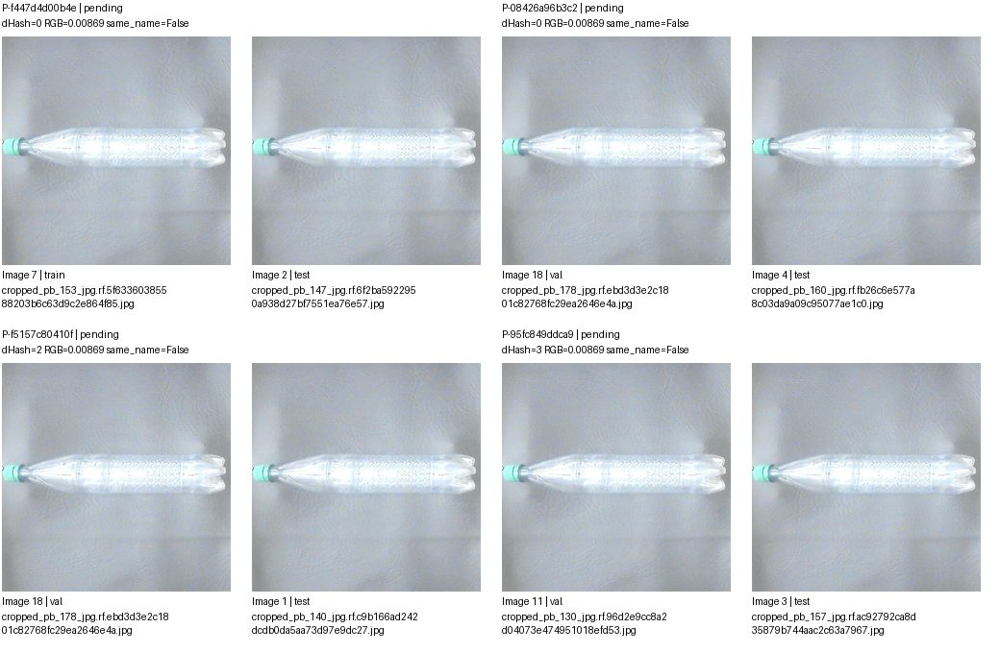

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-f447d4d00b4e,images/train/cropped_pb_153_jpg.rf.5f63360385588203b6c63d9c2e864f85.jpg,images/test/cropped_pb_147_jpg.rf.6f2ba5922950a938d27bf7551ea76e57.jpg,pending,
P-08426a96b3c2,images/val/cropped_pb_178_jpg.rf.ebd3d3e2c1801c82768fc29ea2646e4a.jpg,images/test/cropped_pb_160_jpg.rf.fb26c6e577a8c03da9a09c95077ae1c0.jpg,pending,
P-f5157c80410f,images/val/cropped_pb_178_jpg.rf.ebd3d3e2c1801c82768fc29ea2646e4a.jpg,images/test/cropped_pb_140_jpg.rf.c9b166ad242dcdb0da5aa73d97e9dc27.jpg,pending,
P-95fc849ddca9,images/val/cropped_pb_130_jpg.rf.96d2e9cc8a2d04073e474951018efd53.jpg,images/test/cropped_pb_157_jpg.rf.ac92792ca8d35879b744aac2c63a7967.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 107/166 G-ac085b36b91a | 19 ảnh, 113 cặp
Split: {'test': 5, 'train': 5, 'val': 9}
Quyết định: {'pending': 113}
Ảnh trang None/4; cặp trang 14/29. Nhóm liên thông không phải kết luận trùng.


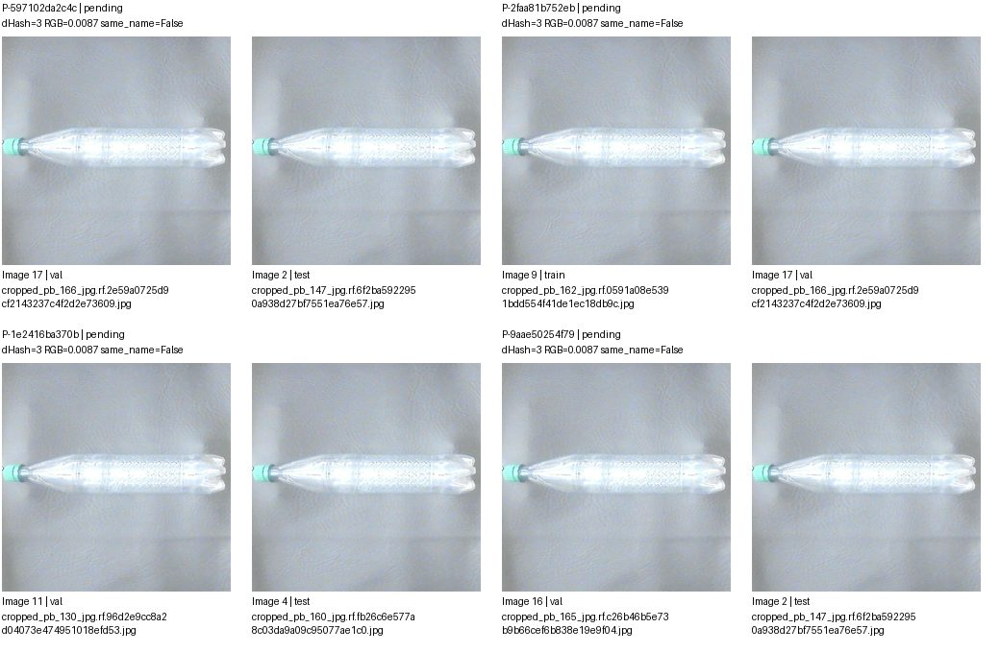

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-597102da2c4c,images/val/cropped_pb_166_jpg.rf.2e59a0725d9cf2143237c4f2d2e73609.jpg,images/test/cropped_pb_147_jpg.rf.6f2ba5922950a938d27bf7551ea76e57.jpg,pending,
P-2faa81b752eb,images/train/cropped_pb_162_jpg.rf.0591a08e5391bdd554f41de1ec18db9c.jpg,images/val/cropped_pb_166_jpg.rf.2e59a0725d9cf2143237c4f2d2e73609.jpg,pending,
P-1e2416ba370b,images/val/cropped_pb_130_jpg.rf.96d2e9cc8a2d04073e474951018efd53.jpg,images/test/cropped_pb_160_jpg.rf.fb26c6e577a8c03da9a09c95077ae1c0.jpg,pending,
P-9aae50254f79,images/val/cropped_pb_165_jpg.rf.c26b46b5e73b9b66cef6b838e19e9f04.jpg,images/test/cropped_pb_147_jpg.rf.6f2ba5922950a938d27bf7551ea76e57.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 107/166 G-ac085b36b91a | 19 ảnh, 113 cặp
Split: {'test': 5, 'train': 5, 'val': 9}
Quyết định: {'pending': 113}
Ảnh trang None/4; cặp trang 15/29. Nhóm liên thông không phải kết luận trùng.


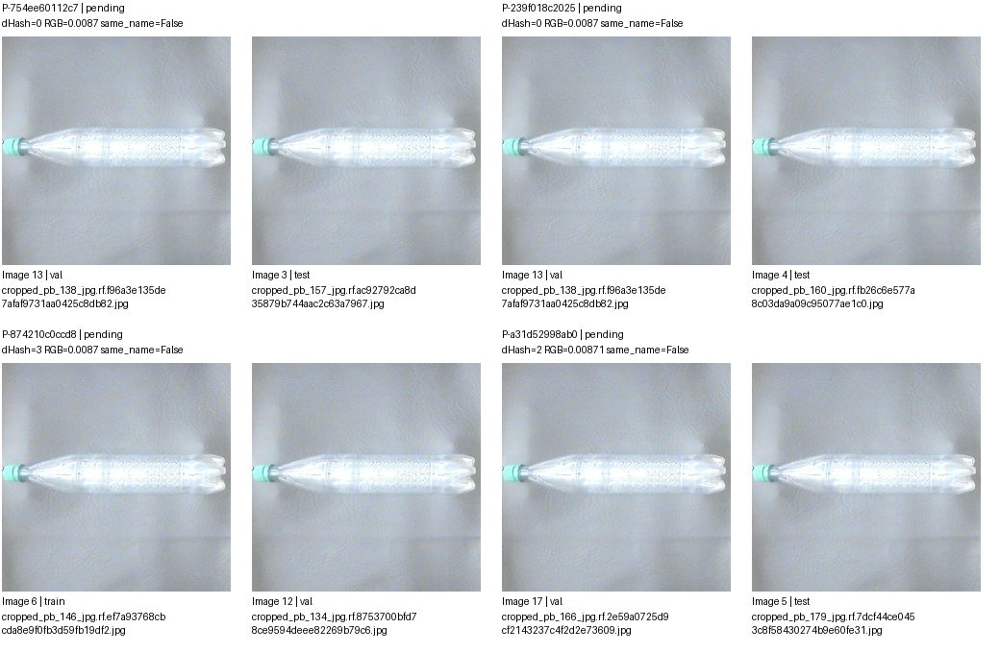

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-754ee60112c7,images/val/cropped_pb_138_jpg.rf.f96a3e135de7afaf9731aa0425c8db82.jpg,images/test/cropped_pb_157_jpg.rf.ac92792ca8d35879b744aac2c63a7967.jpg,pending,
P-239f018c2025,images/val/cropped_pb_138_jpg.rf.f96a3e135de7afaf9731aa0425c8db82.jpg,images/test/cropped_pb_160_jpg.rf.fb26c6e577a8c03da9a09c95077ae1c0.jpg,pending,
P-874210c0ccd8,images/train/cropped_pb_146_jpg.rf.ef7a93768cbcda8e9f0fb3d59fb19df2.jpg,images/val/cropped_pb_134_jpg.rf.8753700bfd78ce9594deee82269b79c6.jpg,pending,
P-a31d52998ab0,images/val/cropped_pb_166_jpg.rf.2e59a0725d9cf2143237c4f2d2e73609.jpg,images/test/cropped_pb_179_jpg.rf.7dcf44ce0453c8f58430274b9e60fe31.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 107/166 G-ac085b36b91a | 19 ảnh, 113 cặp
Split: {'test': 5, 'train': 5, 'val': 9}
Quyết định: {'pending': 113}
Ảnh trang None/4; cặp trang 16/29. Nhóm liên thông không phải kết luận trùng.


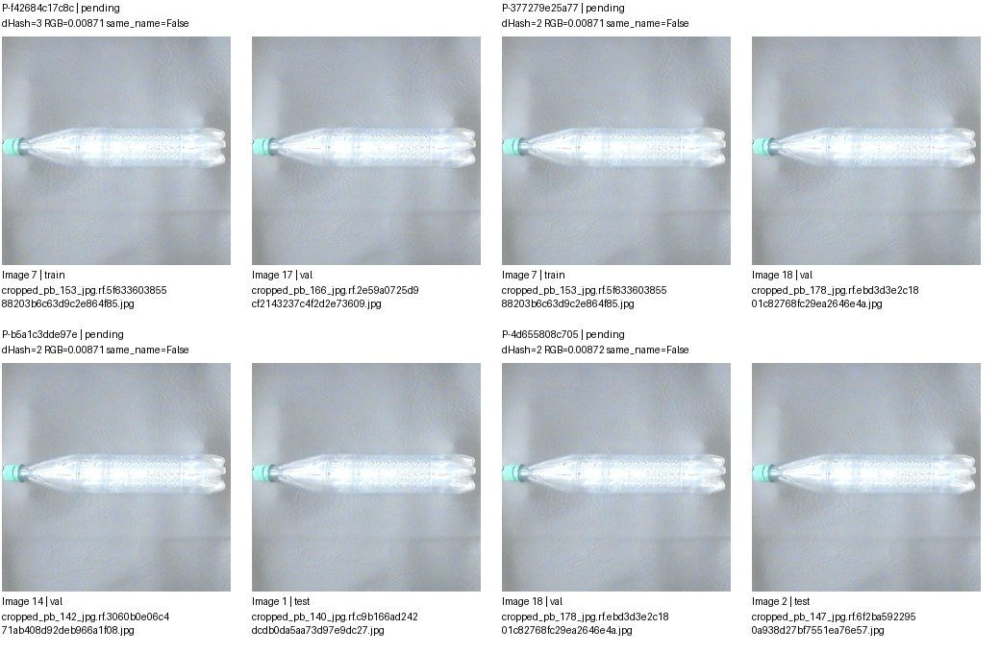

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-f42684c17c8c,images/train/cropped_pb_153_jpg.rf.5f63360385588203b6c63d9c2e864f85.jpg,images/val/cropped_pb_166_jpg.rf.2e59a0725d9cf2143237c4f2d2e73609.jpg,pending,
P-377279e25a77,images/train/cropped_pb_153_jpg.rf.5f63360385588203b6c63d9c2e864f85.jpg,images/val/cropped_pb_178_jpg.rf.ebd3d3e2c1801c82768fc29ea2646e4a.jpg,pending,
P-b5a1c3dde97e,images/val/cropped_pb_142_jpg.rf.3060b0e06c471ab408d92deb966a1f08.jpg,images/test/cropped_pb_140_jpg.rf.c9b166ad242dcdb0da5aa73d97e9dc27.jpg,pending,
P-4d655808c705,images/val/cropped_pb_178_jpg.rf.ebd3d3e2c1801c82768fc29ea2646e4a.jpg,images/test/cropped_pb_147_jpg.rf.6f2ba5922950a938d27bf7551ea76e57.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 107/166 G-ac085b36b91a | 19 ảnh, 113 cặp
Split: {'test': 5, 'train': 5, 'val': 9}
Quyết định: {'pending': 113}
Ảnh trang None/4; cặp trang 17/29. Nhóm liên thông không phải kết luận trùng.


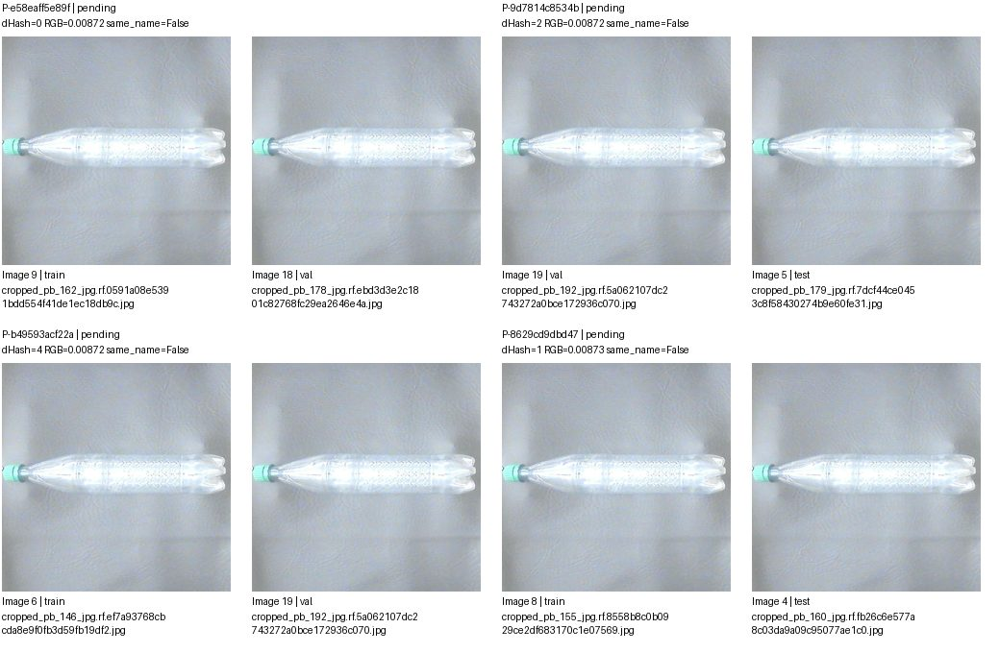

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-e58eaff5e89f,images/train/cropped_pb_162_jpg.rf.0591a08e5391bdd554f41de1ec18db9c.jpg,images/val/cropped_pb_178_jpg.rf.ebd3d3e2c1801c82768fc29ea2646e4a.jpg,pending,
P-9d7814c8534b,images/val/cropped_pb_192_jpg.rf.5a062107dc2743272a0bce172936c070.jpg,images/test/cropped_pb_179_jpg.rf.7dcf44ce0453c8f58430274b9e60fe31.jpg,pending,
P-b49593acf22a,images/train/cropped_pb_146_jpg.rf.ef7a93768cbcda8e9f0fb3d59fb19df2.jpg,images/val/cropped_pb_192_jpg.rf.5a062107dc2743272a0bce172936c070.jpg,pending,
P-8629cd9dbd47,images/train/cropped_pb_155_jpg.rf.8558b8c0b0929ce2df683170c1e07569.jpg,images/test/cropped_pb_160_jpg.rf.fb26c6e577a8c03da9a09c95077ae1c0.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 107/166 G-ac085b36b91a | 19 ảnh, 113 cặp
Split: {'test': 5, 'train': 5, 'val': 9}
Quyết định: {'pending': 113}
Ảnh trang None/4; cặp trang 18/29. Nhóm liên thông không phải kết luận trùng.


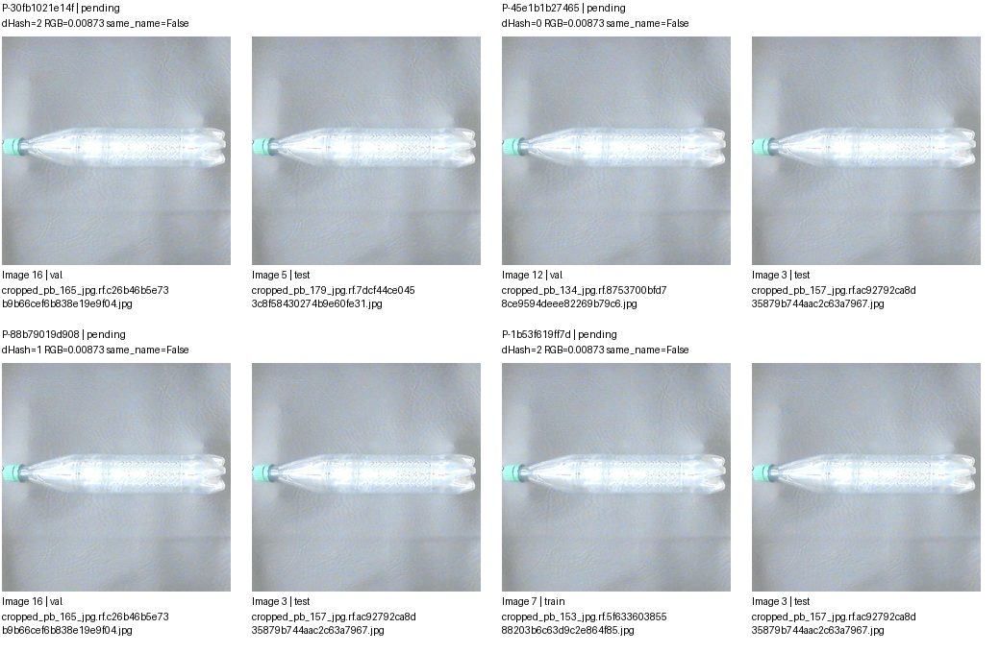

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-30fb1021e14f,images/val/cropped_pb_165_jpg.rf.c26b46b5e73b9b66cef6b838e19e9f04.jpg,images/test/cropped_pb_179_jpg.rf.7dcf44ce0453c8f58430274b9e60fe31.jpg,pending,
P-45e1b1b27465,images/val/cropped_pb_134_jpg.rf.8753700bfd78ce9594deee82269b79c6.jpg,images/test/cropped_pb_157_jpg.rf.ac92792ca8d35879b744aac2c63a7967.jpg,pending,
P-88b79019d908,images/val/cropped_pb_165_jpg.rf.c26b46b5e73b9b66cef6b838e19e9f04.jpg,images/test/cropped_pb_157_jpg.rf.ac92792ca8d35879b744aac2c63a7967.jpg,pending,
P-1b53f619ff7d,images/train/cropped_pb_153_jpg.rf.5f63360385588203b6c63d9c2e864f85.jpg,images/test/cropped_pb_157_jpg.rf.ac92792ca8d35879b744aac2c63a7967.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 107/166 G-ac085b36b91a | 19 ảnh, 113 cặp
Split: {'test': 5, 'train': 5, 'val': 9}
Quyết định: {'pending': 113}
Ảnh trang None/4; cặp trang 19/29. Nhóm liên thông không phải kết luận trùng.


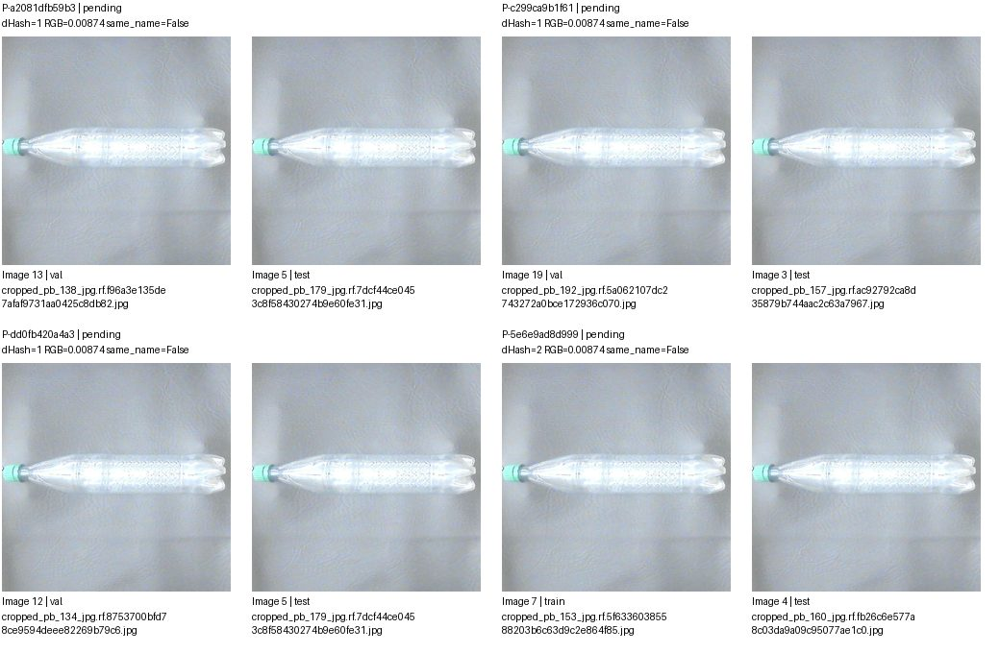

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-a2081dfb59b3,images/val/cropped_pb_138_jpg.rf.f96a3e135de7afaf9731aa0425c8db82.jpg,images/test/cropped_pb_179_jpg.rf.7dcf44ce0453c8f58430274b9e60fe31.jpg,pending,
P-c299ca9b1f61,images/val/cropped_pb_192_jpg.rf.5a062107dc2743272a0bce172936c070.jpg,images/test/cropped_pb_157_jpg.rf.ac92792ca8d35879b744aac2c63a7967.jpg,pending,
P-dd0fb420a4a3,images/val/cropped_pb_134_jpg.rf.8753700bfd78ce9594deee82269b79c6.jpg,images/test/cropped_pb_179_jpg.rf.7dcf44ce0453c8f58430274b9e60fe31.jpg,pending,
P-5e6e9ad8d999,images/train/cropped_pb_153_jpg.rf.5f63360385588203b6c63d9c2e864f85.jpg,images/test/cropped_pb_160_jpg.rf.fb26c6e577a8c03da9a09c95077ae1c0.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 107/166 G-ac085b36b91a | 19 ảnh, 113 cặp
Split: {'test': 5, 'train': 5, 'val': 9}
Quyết định: {'pending': 113}
Ảnh trang None/4; cặp trang 20/29. Nhóm liên thông không phải kết luận trùng.


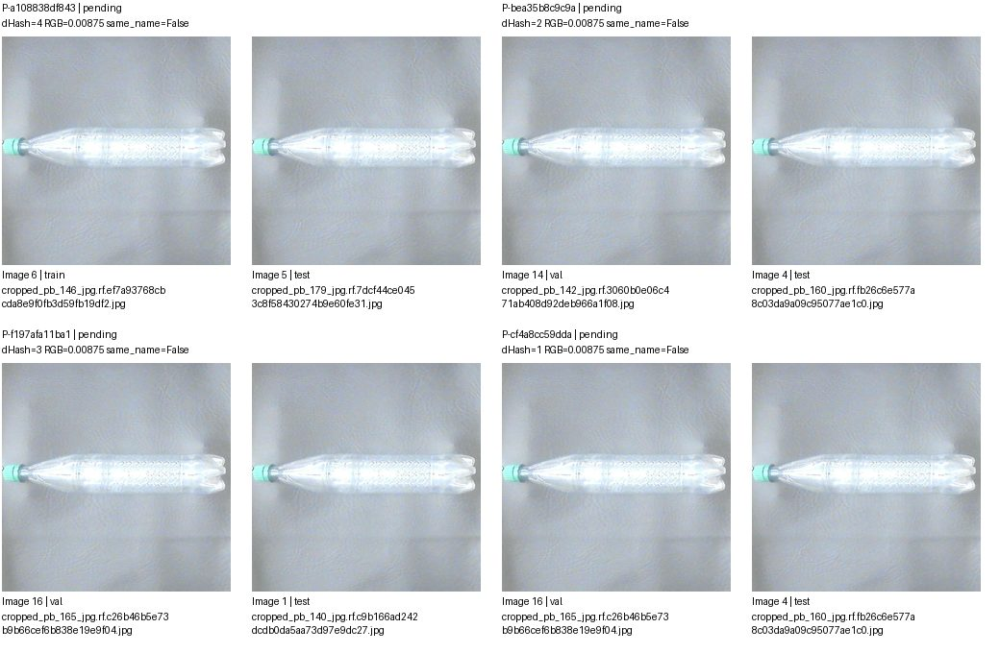

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-a108838df843,images/train/cropped_pb_146_jpg.rf.ef7a93768cbcda8e9f0fb3d59fb19df2.jpg,images/test/cropped_pb_179_jpg.rf.7dcf44ce0453c8f58430274b9e60fe31.jpg,pending,
P-bea35b8c9c9a,images/val/cropped_pb_142_jpg.rf.3060b0e06c471ab408d92deb966a1f08.jpg,images/test/cropped_pb_160_jpg.rf.fb26c6e577a8c03da9a09c95077ae1c0.jpg,pending,
P-f197afa11ba1,images/val/cropped_pb_165_jpg.rf.c26b46b5e73b9b66cef6b838e19e9f04.jpg,images/test/cropped_pb_140_jpg.rf.c9b166ad242dcdb0da5aa73d97e9dc27.jpg,pending,
P-cf4a8cc59dda,images/val/cropped_pb_165_jpg.rf.c26b46b5e73b9b66cef6b838e19e9f04.jpg,images/test/cropped_pb_160_jpg.rf.fb26c6e577a8c03da9a09c95077ae1c0.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 107/166 G-ac085b36b91a | 19 ảnh, 113 cặp
Split: {'test': 5, 'train': 5, 'val': 9}
Quyết định: {'pending': 113}
Ảnh trang None/4; cặp trang 21/29. Nhóm liên thông không phải kết luận trùng.


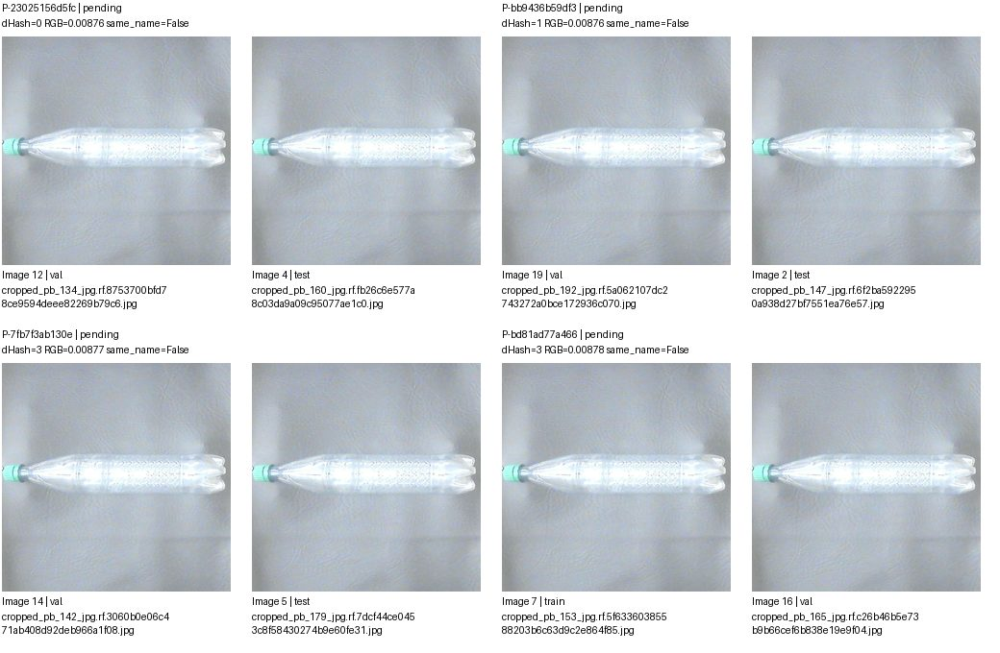

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-23025156d5fc,images/val/cropped_pb_134_jpg.rf.8753700bfd78ce9594deee82269b79c6.jpg,images/test/cropped_pb_160_jpg.rf.fb26c6e577a8c03da9a09c95077ae1c0.jpg,pending,
P-bb9436b59df3,images/val/cropped_pb_192_jpg.rf.5a062107dc2743272a0bce172936c070.jpg,images/test/cropped_pb_147_jpg.rf.6f2ba5922950a938d27bf7551ea76e57.jpg,pending,
P-7fb7f3ab130e,images/val/cropped_pb_142_jpg.rf.3060b0e06c471ab408d92deb966a1f08.jpg,images/test/cropped_pb_179_jpg.rf.7dcf44ce0453c8f58430274b9e60fe31.jpg,pending,
P-bd81ad77a466,images/train/cropped_pb_153_jpg.rf.5f63360385588203b6c63d9c2e864f85.jpg,images/val/cropped_pb_165_jpg.rf.c26b46b5e73b9b66cef6b838e19e9f04.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 107/166 G-ac085b36b91a | 19 ảnh, 113 cặp
Split: {'test': 5, 'train': 5, 'val': 9}
Quyết định: {'pending': 113}
Ảnh trang None/4; cặp trang 22/29. Nhóm liên thông không phải kết luận trùng.


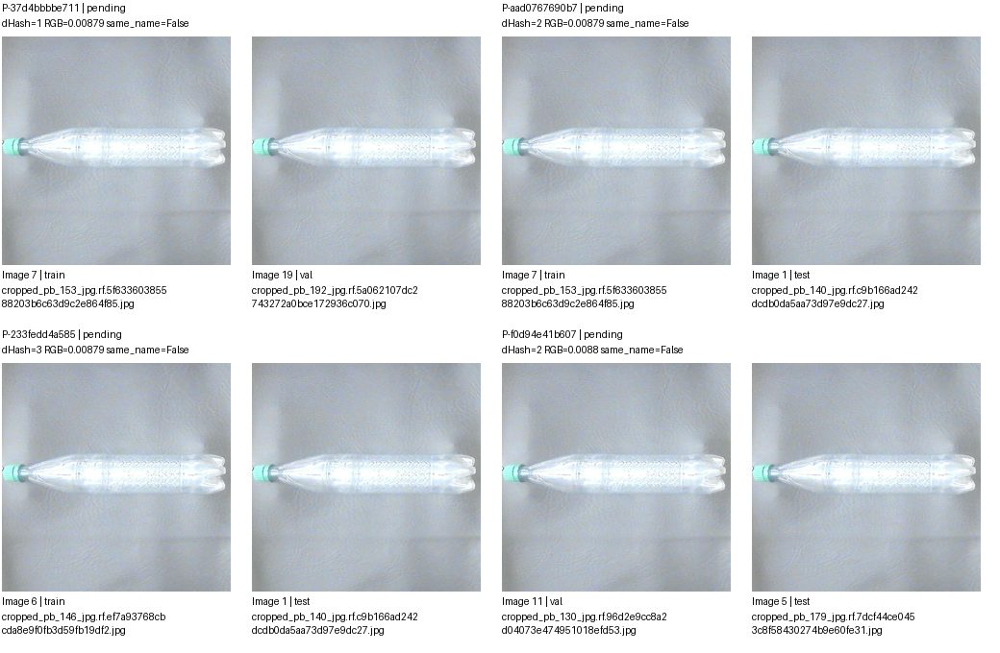

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-37d4bbbbe711,images/train/cropped_pb_153_jpg.rf.5f63360385588203b6c63d9c2e864f85.jpg,images/val/cropped_pb_192_jpg.rf.5a062107dc2743272a0bce172936c070.jpg,pending,
P-aad0767690b7,images/train/cropped_pb_153_jpg.rf.5f63360385588203b6c63d9c2e864f85.jpg,images/test/cropped_pb_140_jpg.rf.c9b166ad242dcdb0da5aa73d97e9dc27.jpg,pending,
P-233fedd4a585,images/train/cropped_pb_146_jpg.rf.ef7a93768cbcda8e9f0fb3d59fb19df2.jpg,images/test/cropped_pb_140_jpg.rf.c9b166ad242dcdb0da5aa73d97e9dc27.jpg,pending,
P-f0d94e41b607,images/val/cropped_pb_130_jpg.rf.96d2e9cc8a2d04073e474951018efd53.jpg,images/test/cropped_pb_179_jpg.rf.7dcf44ce0453c8f58430274b9e60fe31.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 107/166 G-ac085b36b91a | 19 ảnh, 113 cặp
Split: {'test': 5, 'train': 5, 'val': 9}
Quyết định: {'pending': 113}
Ảnh trang None/4; cặp trang 23/29. Nhóm liên thông không phải kết luận trùng.


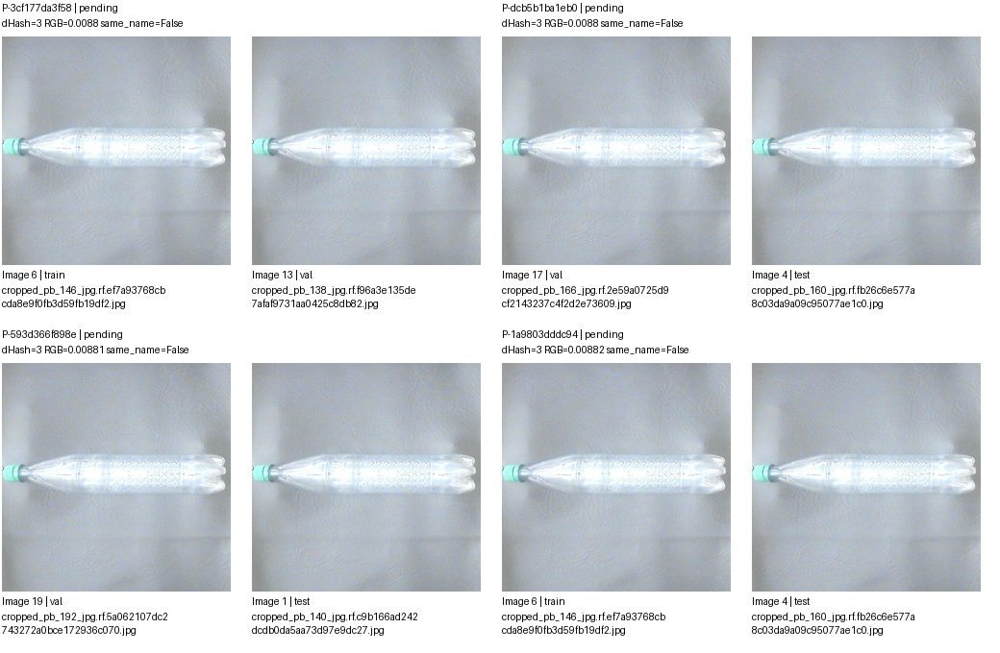

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-3cf177da3f58,images/train/cropped_pb_146_jpg.rf.ef7a93768cbcda8e9f0fb3d59fb19df2.jpg,images/val/cropped_pb_138_jpg.rf.f96a3e135de7afaf9731aa0425c8db82.jpg,pending,
P-dcb5b1ba1eb0,images/val/cropped_pb_166_jpg.rf.2e59a0725d9cf2143237c4f2d2e73609.jpg,images/test/cropped_pb_160_jpg.rf.fb26c6e577a8c03da9a09c95077ae1c0.jpg,pending,
P-593d366f898e,images/val/cropped_pb_192_jpg.rf.5a062107dc2743272a0bce172936c070.jpg,images/test/cropped_pb_140_jpg.rf.c9b166ad242dcdb0da5aa73d97e9dc27.jpg,pending,
P-1a9803dddc94,images/train/cropped_pb_146_jpg.rf.ef7a93768cbcda8e9f0fb3d59fb19df2.jpg,images/test/cropped_pb_160_jpg.rf.fb26c6e577a8c03da9a09c95077ae1c0.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 107/166 G-ac085b36b91a | 19 ảnh, 113 cặp
Split: {'test': 5, 'train': 5, 'val': 9}
Quyết định: {'pending': 113}
Ảnh trang None/4; cặp trang 24/29. Nhóm liên thông không phải kết luận trùng.


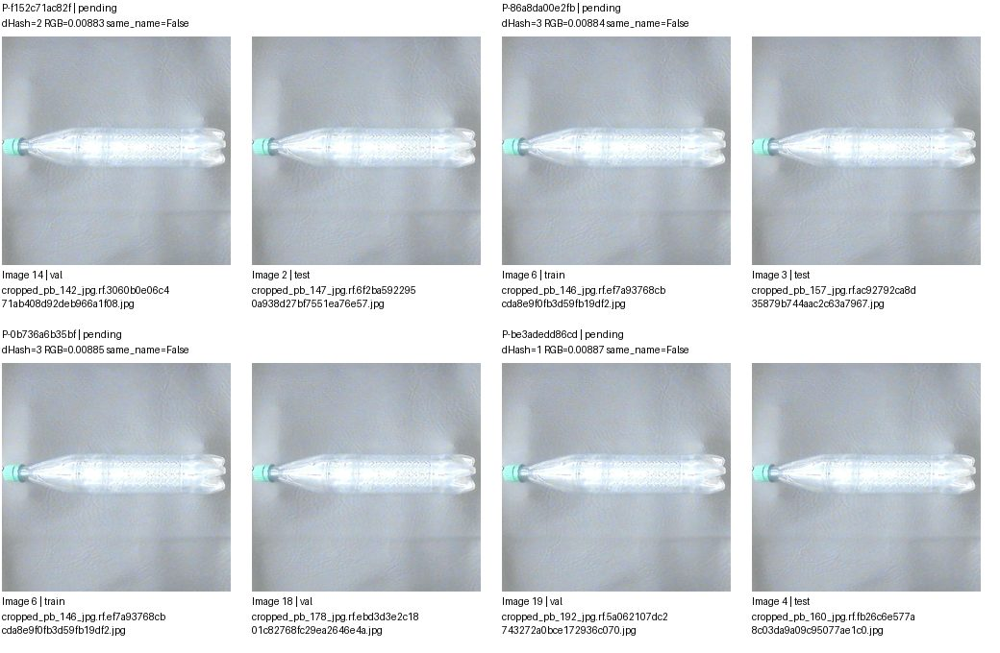

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-f152c71ac82f,images/val/cropped_pb_142_jpg.rf.3060b0e06c471ab408d92deb966a1f08.jpg,images/test/cropped_pb_147_jpg.rf.6f2ba5922950a938d27bf7551ea76e57.jpg,pending,
P-86a8da00e2fb,images/train/cropped_pb_146_jpg.rf.ef7a93768cbcda8e9f0fb3d59fb19df2.jpg,images/test/cropped_pb_157_jpg.rf.ac92792ca8d35879b744aac2c63a7967.jpg,pending,
P-0b736a6b35bf,images/train/cropped_pb_146_jpg.rf.ef7a93768cbcda8e9f0fb3d59fb19df2.jpg,images/val/cropped_pb_178_jpg.rf.ebd3d3e2c1801c82768fc29ea2646e4a.jpg,pending,
P-be3adedd86cd,images/val/cropped_pb_192_jpg.rf.5a062107dc2743272a0bce172936c070.jpg,images/test/cropped_pb_160_jpg.rf.fb26c6e577a8c03da9a09c95077ae1c0.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 107/166 G-ac085b36b91a | 19 ảnh, 113 cặp
Split: {'test': 5, 'train': 5, 'val': 9}
Quyết định: {'pending': 113}
Ảnh trang None/4; cặp trang 25/29. Nhóm liên thông không phải kết luận trùng.


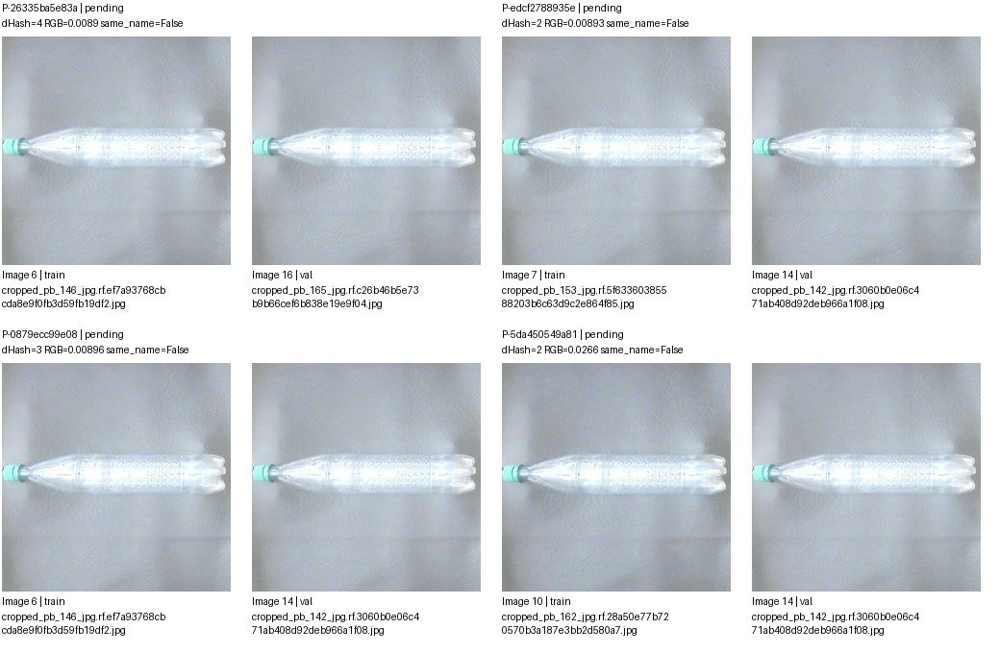

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-26335ba5e83a,images/train/cropped_pb_146_jpg.rf.ef7a93768cbcda8e9f0fb3d59fb19df2.jpg,images/val/cropped_pb_165_jpg.rf.c26b46b5e73b9b66cef6b838e19e9f04.jpg,pending,
P-edcf2788935e,images/train/cropped_pb_153_jpg.rf.5f63360385588203b6c63d9c2e864f85.jpg,images/val/cropped_pb_142_jpg.rf.3060b0e06c471ab408d92deb966a1f08.jpg,pending,
P-0879ecc99e08,images/train/cropped_pb_146_jpg.rf.ef7a93768cbcda8e9f0fb3d59fb19df2.jpg,images/val/cropped_pb_142_jpg.rf.3060b0e06c471ab408d92deb966a1f08.jpg,pending,
P-5da450549a81,images/train/cropped_pb_162_jpg.rf.28a50e77b720570b3a187e3bb2d580a7.jpg,images/val/cropped_pb_142_jpg.rf.3060b0e06c471ab408d92deb966a1f08.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 107/166 G-ac085b36b91a | 19 ảnh, 113 cặp
Split: {'test': 5, 'train': 5, 'val': 9}
Quyết định: {'pending': 113}
Ảnh trang None/4; cặp trang 26/29. Nhóm liên thông không phải kết luận trùng.


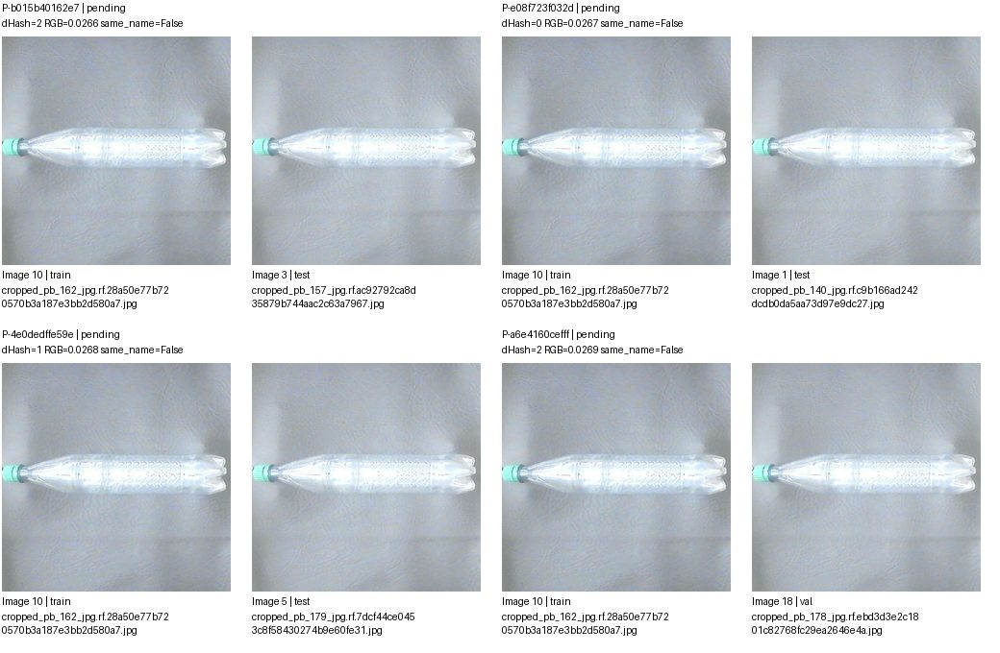

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-b015b40162e7,images/train/cropped_pb_162_jpg.rf.28a50e77b720570b3a187e3bb2d580a7.jpg,images/test/cropped_pb_157_jpg.rf.ac92792ca8d35879b744aac2c63a7967.jpg,pending,
P-e08f723f032d,images/train/cropped_pb_162_jpg.rf.28a50e77b720570b3a187e3bb2d580a7.jpg,images/test/cropped_pb_140_jpg.rf.c9b166ad242dcdb0da5aa73d97e9dc27.jpg,pending,
P-4e0dedffe59e,images/train/cropped_pb_162_jpg.rf.28a50e77b720570b3a187e3bb2d580a7.jpg,images/test/cropped_pb_179_jpg.rf.7dcf44ce0453c8f58430274b9e60fe31.jpg,pending,
P-a6e4160cefff,images/train/cropped_pb_162_jpg.rf.28a50e77b720570b3a187e3bb2d580a7.jpg,images/val/cropped_pb_178_jpg.rf.ebd3d3e2c1801c82768fc29ea2646e4a.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 107/166 G-ac085b36b91a | 19 ảnh, 113 cặp
Split: {'test': 5, 'train': 5, 'val': 9}
Quyết định: {'pending': 113}
Ảnh trang None/4; cặp trang 27/29. Nhóm liên thông không phải kết luận trùng.


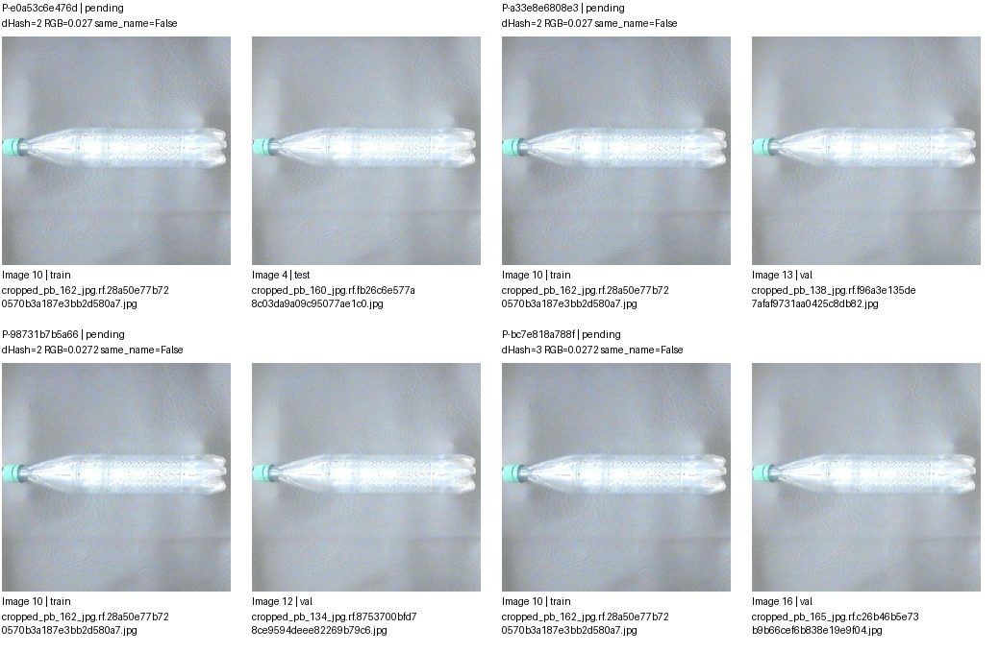

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-e0a53c6e476d,images/train/cropped_pb_162_jpg.rf.28a50e77b720570b3a187e3bb2d580a7.jpg,images/test/cropped_pb_160_jpg.rf.fb26c6e577a8c03da9a09c95077ae1c0.jpg,pending,
P-a33e8e6808e3,images/train/cropped_pb_162_jpg.rf.28a50e77b720570b3a187e3bb2d580a7.jpg,images/val/cropped_pb_138_jpg.rf.f96a3e135de7afaf9731aa0425c8db82.jpg,pending,
P-98731b7b5a66,images/train/cropped_pb_162_jpg.rf.28a50e77b720570b3a187e3bb2d580a7.jpg,images/val/cropped_pb_134_jpg.rf.8753700bfd78ce9594deee82269b79c6.jpg,pending,
P-bc7e818a788f,images/train/cropped_pb_162_jpg.rf.28a50e77b720570b3a187e3bb2d580a7.jpg,images/val/cropped_pb_165_jpg.rf.c26b46b5e73b9b66cef6b838e19e9f04.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 107/166 G-ac085b36b91a | 19 ảnh, 113 cặp
Split: {'test': 5, 'train': 5, 'val': 9}
Quyết định: {'pending': 113}
Ảnh trang None/4; cặp trang 28/29. Nhóm liên thông không phải kết luận trùng.


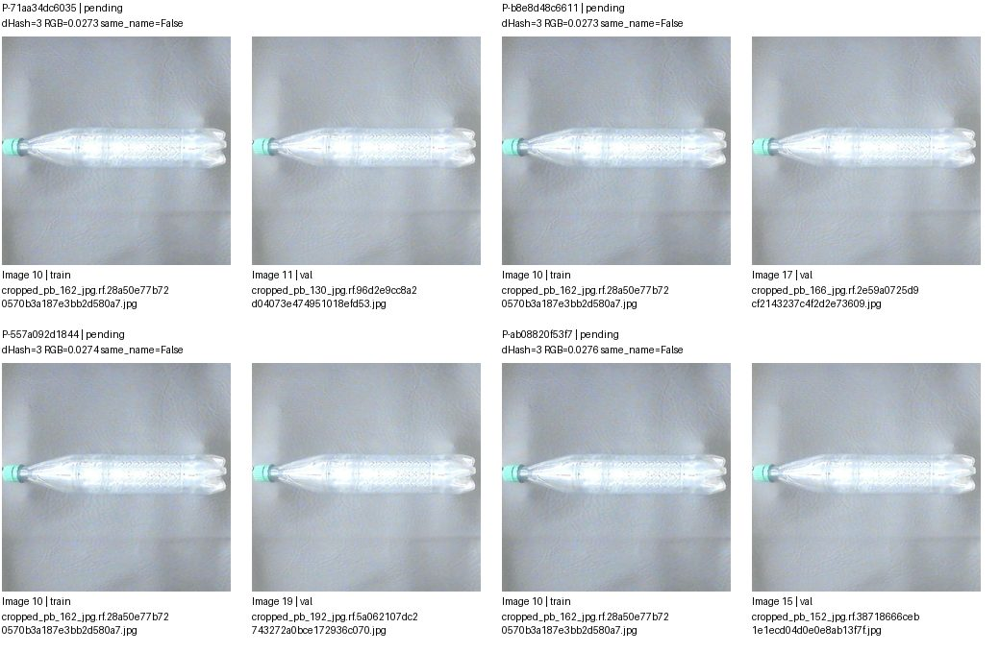

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-71aa34dc6035,images/train/cropped_pb_162_jpg.rf.28a50e77b720570b3a187e3bb2d580a7.jpg,images/val/cropped_pb_130_jpg.rf.96d2e9cc8a2d04073e474951018efd53.jpg,pending,
P-b8e8d48c6611,images/train/cropped_pb_162_jpg.rf.28a50e77b720570b3a187e3bb2d580a7.jpg,images/val/cropped_pb_166_jpg.rf.2e59a0725d9cf2143237c4f2d2e73609.jpg,pending,
P-557a092d1844,images/train/cropped_pb_162_jpg.rf.28a50e77b720570b3a187e3bb2d580a7.jpg,images/val/cropped_pb_192_jpg.rf.5a062107dc2743272a0bce172936c070.jpg,pending,
P-ab08820f53f7,images/train/cropped_pb_162_jpg.rf.28a50e77b720570b3a187e3bb2d580a7.jpg,images/val/cropped_pb_152_jpg.rf.38718666ceb1e1ecd04d0e0e8ab13f7f.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 107/166 G-ac085b36b91a | 19 ảnh, 113 cặp
Split: {'test': 5, 'train': 5, 'val': 9}
Quyết định: {'pending': 113}
Ảnh trang None/4; cặp trang 29/29. Nhóm liên thông không phải kết luận trùng.


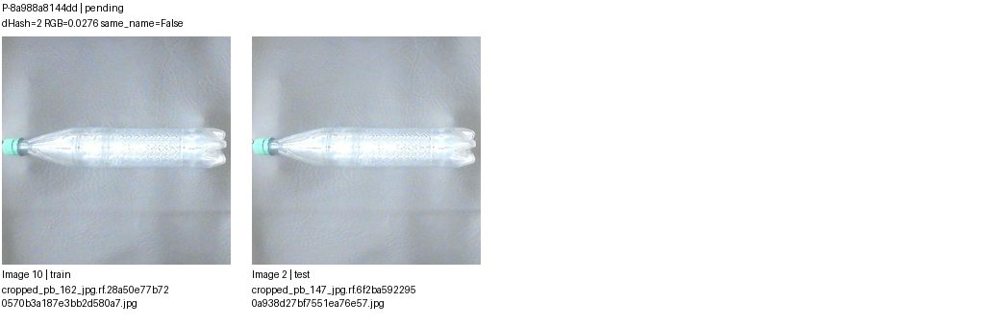

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-8a988a8144dd,images/train/cropped_pb_162_jpg.rf.28a50e77b720570b3a187e3bb2d580a7.jpg,images/test/cropped_pb_147_jpg.rf.6f2ba5922950a938d27bf7551ea76e57.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 108/166 G-c1f1522f9172 | 11 ảnh, 10 cặp
Split: {'test': 1, 'train': 10}
Quyết định: {'pending': 10}
Ảnh trang 1/2; cặp trang 1/3. Nhóm liên thông không phải kết luận trùng.


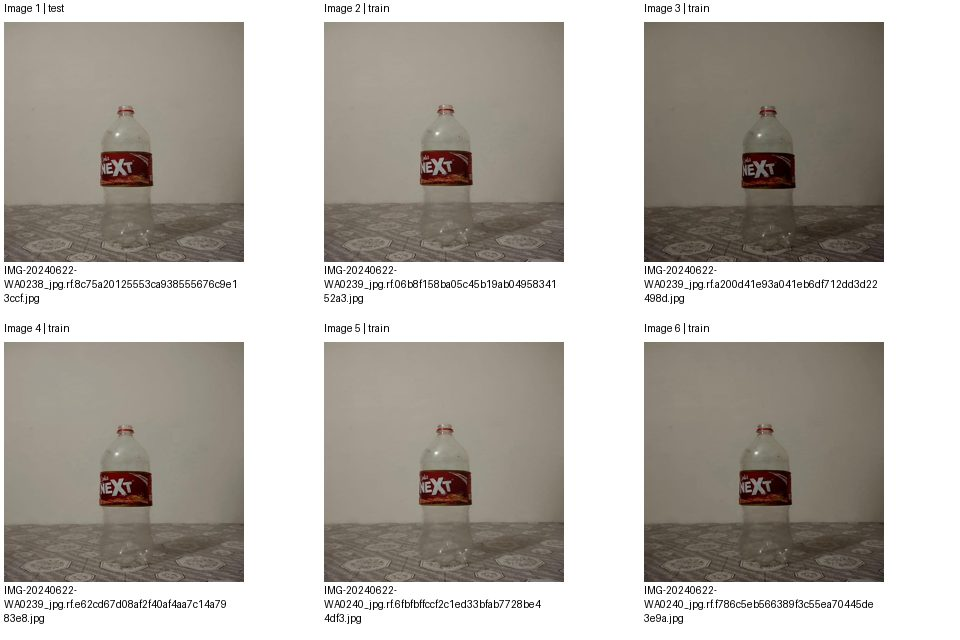

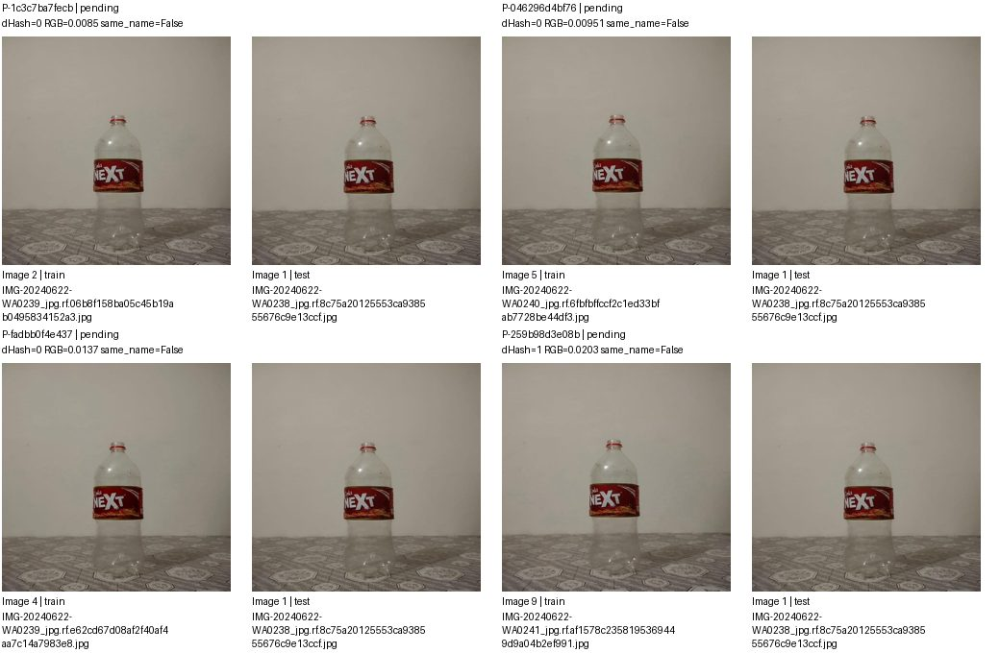

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-1c3c7ba7fecb,images/train/IMG-20240622-WA0239_jpg.rf.06b8f158ba05c45b19ab0495834152a3.jpg,images/test/IMG-20240622-WA0238_jpg.rf.8c75a20125553ca938555676c9e13ccf.jpg,pending,
P-046296d4bf76,images/train/IMG-20240622-WA0240_jpg.rf.6fbfbffccf2c1ed33bfab7728be44df3.jpg,images/test/IMG-20240622-WA0238_jpg.rf.8c75a20125553ca938555676c9e13ccf.jpg,pending,
P-fadbb0f4e437,images/train/IMG-20240622-WA0239_jpg.rf.e62cd67d08af2f40af4aa7c14a7983e8.jpg,images/test/IMG-20240622-WA0238_jpg.rf.8c75a20125553ca938555676c9e13ccf.jpg,pending,
P-259b98d3e08b,images/train/IMG-20240622-WA0241_jpg.rf.af1578c2358195369449d9a04b2ef991.jpg,images/test/IMG-20240622-WA0238_jpg.rf.8c75a20125553ca938555676c9e13ccf.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 108/166 G-c1f1522f9172 | 11 ảnh, 10 cặp
Split: {'test': 1, 'train': 10}
Quyết định: {'pending': 10}
Ảnh trang 2/2; cặp trang 2/3. Nhóm liên thông không phải kết luận trùng.


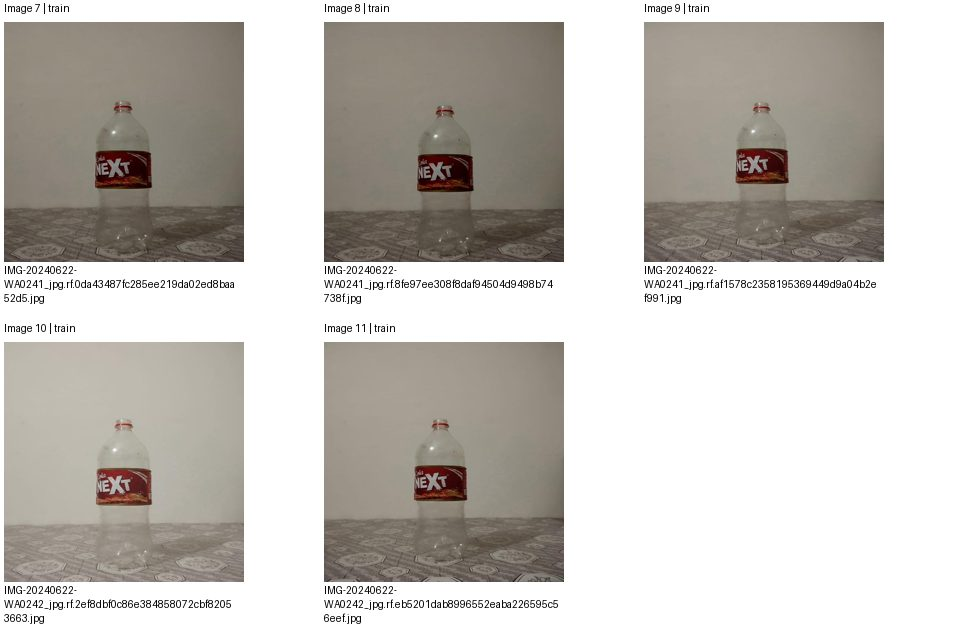

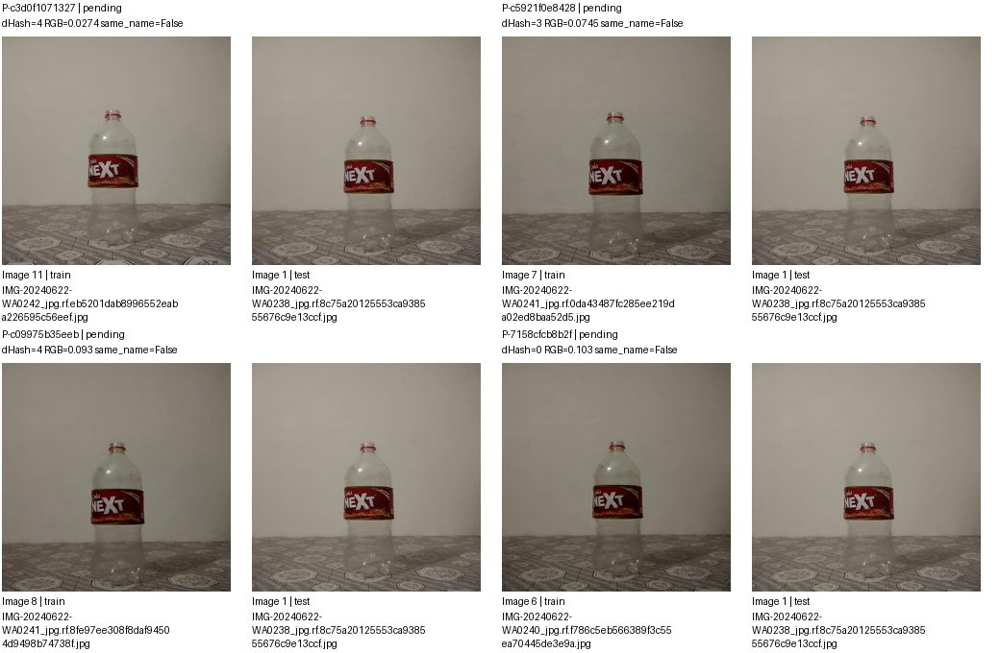

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-c3d0f1071327,images/train/IMG-20240622-WA0242_jpg.rf.eb5201dab8996552eaba226595c56eef.jpg,images/test/IMG-20240622-WA0238_jpg.rf.8c75a20125553ca938555676c9e13ccf.jpg,pending,
P-c5921f0e8428,images/train/IMG-20240622-WA0241_jpg.rf.0da43487fc285ee219da02ed8baa52d5.jpg,images/test/IMG-20240622-WA0238_jpg.rf.8c75a20125553ca938555676c9e13ccf.jpg,pending,
P-c09975b35eeb,images/train/IMG-20240622-WA0241_jpg.rf.8fe97ee308f8daf94504d9498b74738f.jpg,images/test/IMG-20240622-WA0238_jpg.rf.8c75a20125553ca938555676c9e13ccf.jpg,pending,
P-7158cfcb8b2f,images/train/IMG-20240622-WA0240_jpg.rf.f786c5eb566389f3c55ea70445de3e9a.jpg,images/test/IMG-20240622-WA0238_jpg.rf.8c75a20125553ca938555676c9e13ccf.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 108/166 G-c1f1522f9172 | 11 ảnh, 10 cặp
Split: {'test': 1, 'train': 10}
Quyết định: {'pending': 10}
Ảnh trang None/2; cặp trang 3/3. Nhóm liên thông không phải kết luận trùng.


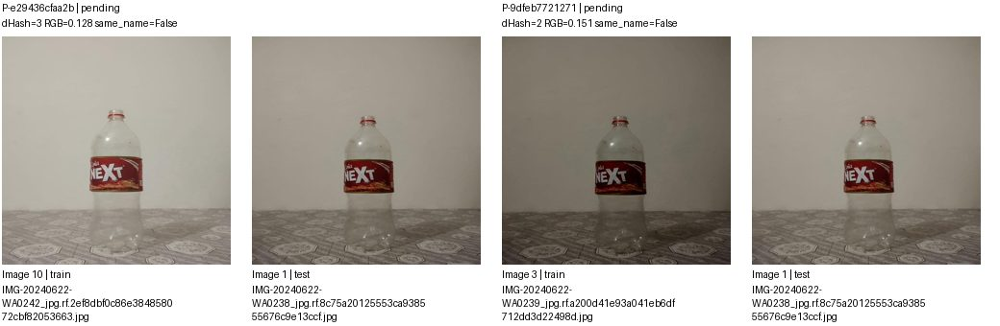

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-e29436cfaa2b,images/train/IMG-20240622-WA0242_jpg.rf.2ef8dbf0c86e384858072cbf82053663.jpg,images/test/IMG-20240622-WA0238_jpg.rf.8c75a20125553ca938555676c9e13ccf.jpg,pending,
P-9dfeb7721271,images/train/IMG-20240622-WA0239_jpg.rf.a200d41e93a041eb6df712dd3d22498d.jpg,images/test/IMG-20240622-WA0238_jpg.rf.8c75a20125553ca938555676c9e13ccf.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 109/166 G-69bfc230c261 | 5 ảnh, 6 cặp
Split: {'train': 3, 'val': 2}
Quyết định: {'pending': 6}
Ảnh trang 1/1; cặp trang 1/2. Nhóm liên thông không phải kết luận trùng.


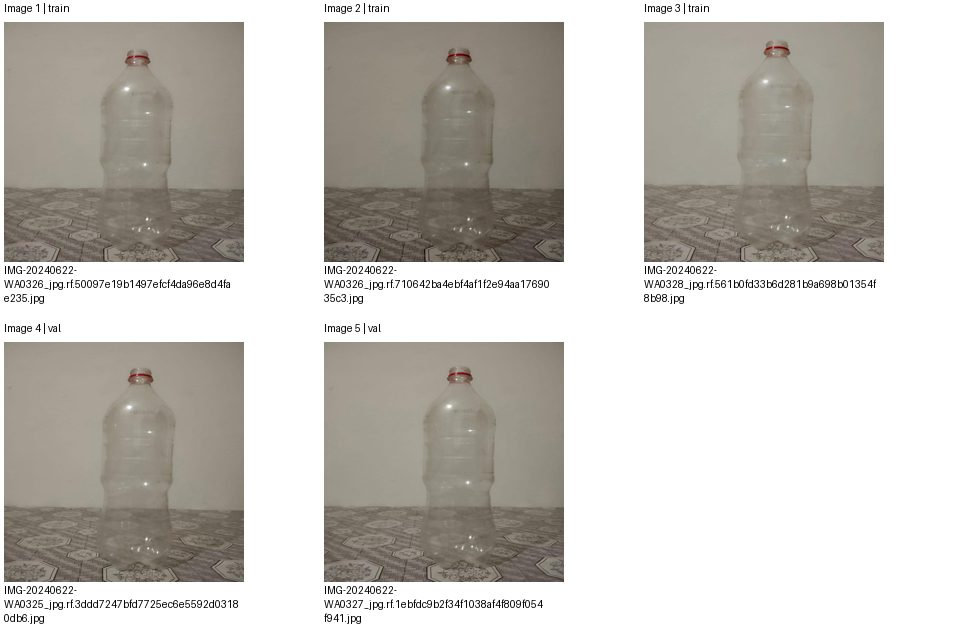

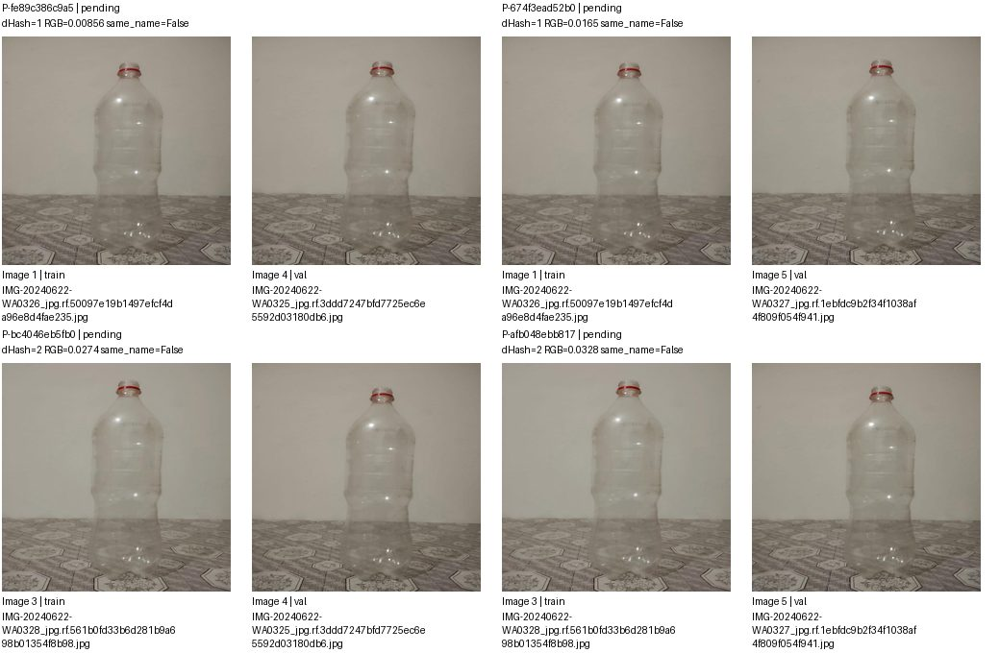

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-fe89c386c9a5,images/train/IMG-20240622-WA0326_jpg.rf.50097e19b1497efcf4da96e8d4fae235.jpg,images/val/IMG-20240622-WA0325_jpg.rf.3ddd7247bfd7725ec6e5592d03180db6.jpg,pending,
P-674f3ead52b0,images/train/IMG-20240622-WA0326_jpg.rf.50097e19b1497efcf4da96e8d4fae235.jpg,images/val/IMG-20240622-WA0327_jpg.rf.1ebfdc9b2f34f1038af4f809f054f941.jpg,pending,
P-bc4046eb5fb0,images/train/IMG-20240622-WA0328_jpg.rf.561b0fd33b6d281b9a698b01354f8b98.jpg,images/val/IMG-20240622-WA0325_jpg.rf.3ddd7247bfd7725ec6e5592d03180db6.jpg,pending,
P-afb048ebb817,images/train/IMG-20240622-WA0328_jpg.rf.561b0fd33b6d281b9a698b01354f8b98.jpg,images/val/IMG-20240622-WA0327_jpg.rf.1ebfdc9b2f34f1038af4f809f054f941.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 109/166 G-69bfc230c261 | 5 ảnh, 6 cặp
Split: {'train': 3, 'val': 2}
Quyết định: {'pending': 6}
Ảnh trang None/1; cặp trang 2/2. Nhóm liên thông không phải kết luận trùng.


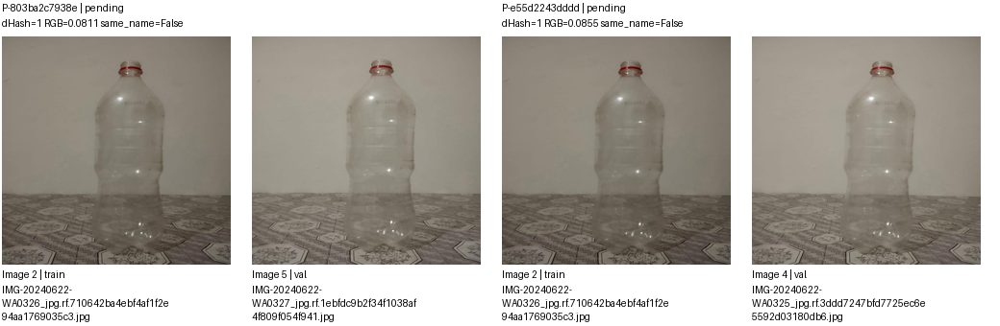

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-803ba2c7938e,images/train/IMG-20240622-WA0326_jpg.rf.710642ba4ebf4af1f2e94aa1769035c3.jpg,images/val/IMG-20240622-WA0327_jpg.rf.1ebfdc9b2f34f1038af4f809f054f941.jpg,pending,
P-e55d2243dddd,images/train/IMG-20240622-WA0326_jpg.rf.710642ba4ebf4af1f2e94aa1769035c3.jpg,images/val/IMG-20240622-WA0325_jpg.rf.3ddd7247bfd7725ec6e5592d03180db6.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 110/166 G-e04bfda07beb | 8 ảnh, 7 cặp
Split: {'train': 7, 'val': 1}
Quyết định: {'pending': 7}
Ảnh trang 1/2; cặp trang 1/2. Nhóm liên thông không phải kết luận trùng.


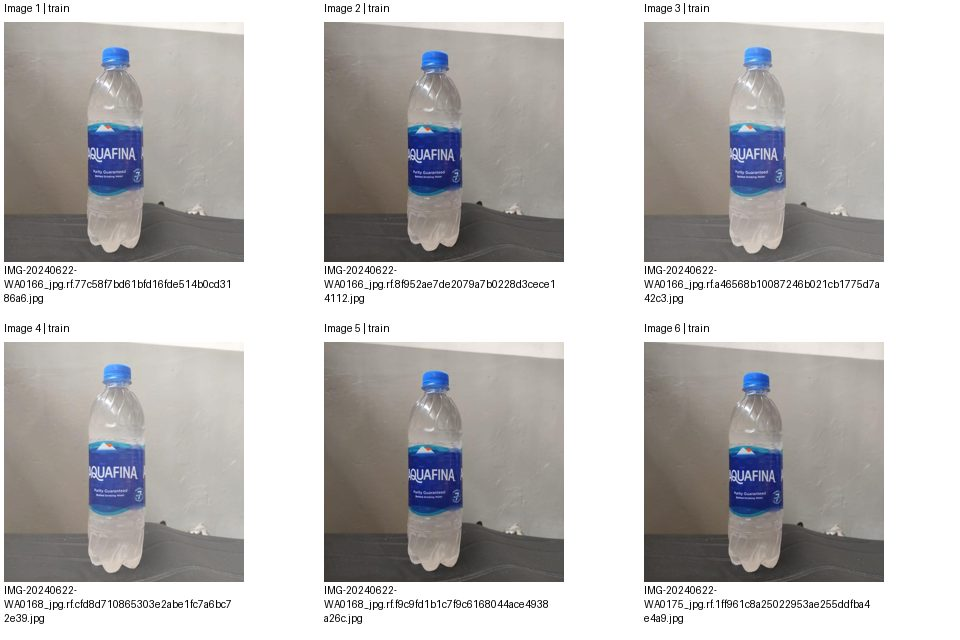

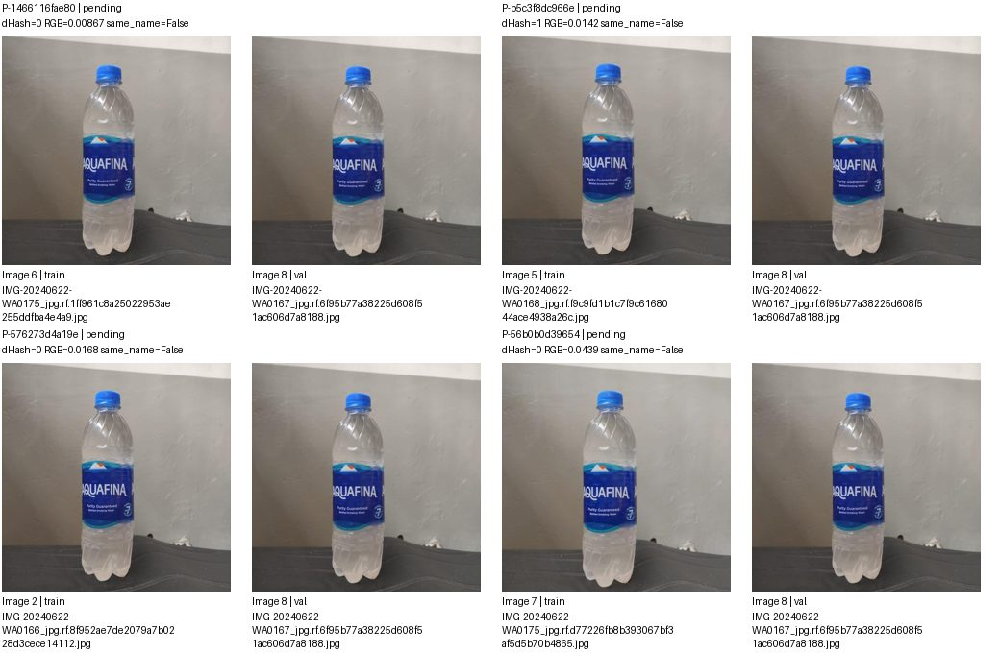

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-1466116fae80,images/train/IMG-20240622-WA0175_jpg.rf.1ff961c8a25022953ae255ddfba4e4a9.jpg,images/val/IMG-20240622-WA0167_jpg.rf.6f95b77a38225d608f51ac606d7a8188.jpg,pending,
P-b5c3f8dc966e,images/train/IMG-20240622-WA0168_jpg.rf.f9c9fd1b1c7f9c6168044ace4938a26c.jpg,images/val/IMG-20240622-WA0167_jpg.rf.6f95b77a38225d608f51ac606d7a8188.jpg,pending,
P-576273d4a19e,images/train/IMG-20240622-WA0166_jpg.rf.8f952ae7de2079a7b0228d3cece14112.jpg,images/val/IMG-20240622-WA0167_jpg.rf.6f95b77a38225d608f51ac606d7a8188.jpg,pending,
P-56b0b0d39654,images/train/IMG-20240622-WA0175_jpg.rf.d77226fb8b393067bf3af5d5b70b4865.jpg,images/val/IMG-20240622-WA0167_jpg.rf.6f95b77a38225d608f51ac606d7a8188.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 110/166 G-e04bfda07beb | 8 ảnh, 7 cặp
Split: {'train': 7, 'val': 1}
Quyết định: {'pending': 7}
Ảnh trang 2/2; cặp trang 2/2. Nhóm liên thông không phải kết luận trùng.


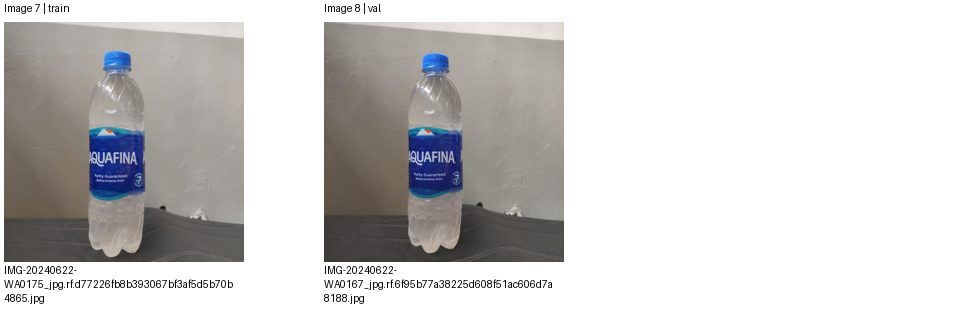

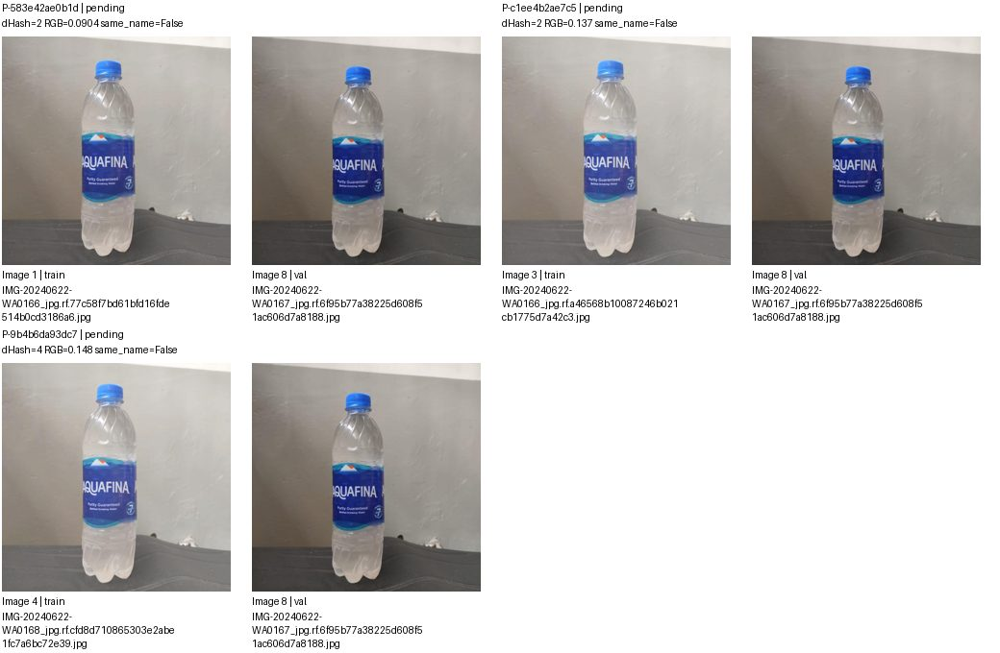

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-583e42ae0b1d,images/train/IMG-20240622-WA0166_jpg.rf.77c58f7bd61bfd16fde514b0cd3186a6.jpg,images/val/IMG-20240622-WA0167_jpg.rf.6f95b77a38225d608f51ac606d7a8188.jpg,pending,
P-c1ee4b2ae7c5,images/train/IMG-20240622-WA0166_jpg.rf.a46568b10087246b021cb1775d7a42c3.jpg,images/val/IMG-20240622-WA0167_jpg.rf.6f95b77a38225d608f51ac606d7a8188.jpg,pending,
P-9b4b6da93dc7,images/train/IMG-20240622-WA0168_jpg.rf.cfd8d710865303e2abe1fc7a6bc72e39.jpg,images/val/IMG-20240622-WA0167_jpg.rf.6f95b77a38225d608f51ac606d7a8188.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 111/166 G-602abfc175dd | 4 ảnh, 3 cặp
Split: {'test': 1, 'train': 3}
Quyết định: {'pending': 3}
Ảnh trang 1/1; cặp trang 1/1. Nhóm liên thông không phải kết luận trùng.


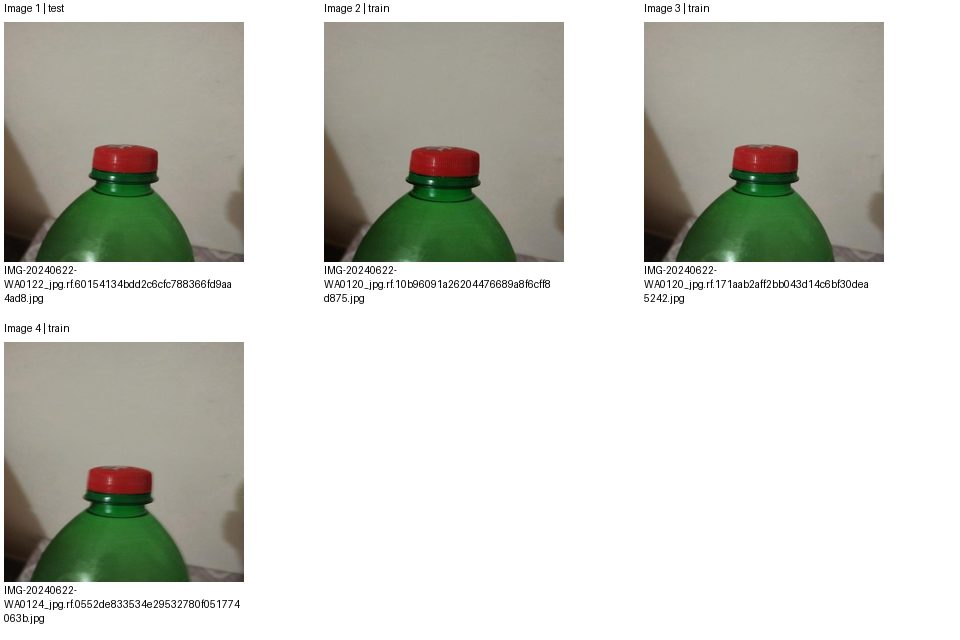

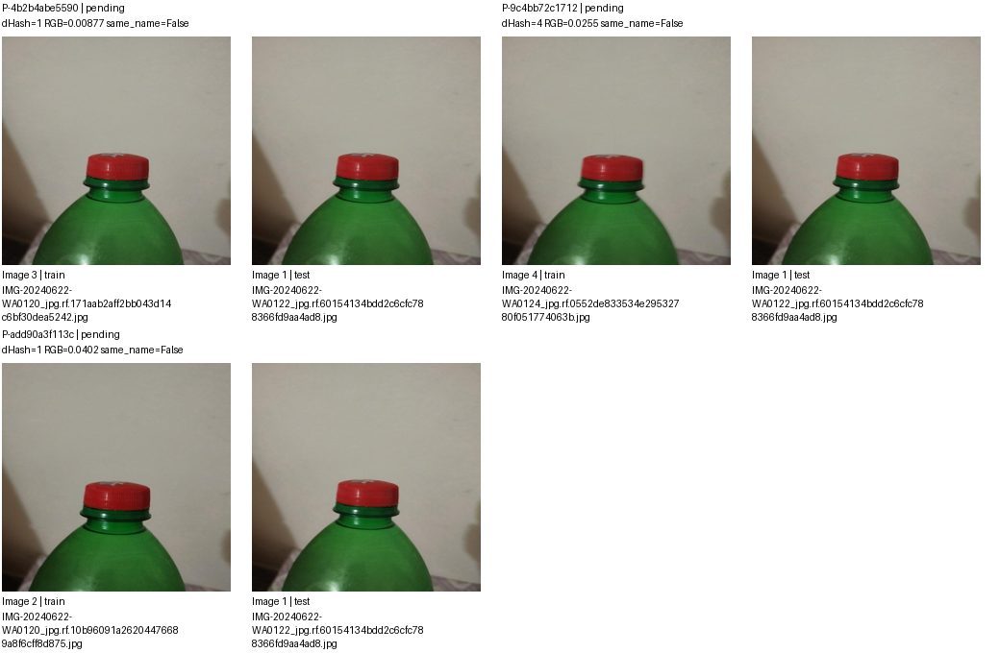

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-4b2b4abe5590,images/train/IMG-20240622-WA0120_jpg.rf.171aab2aff2bb043d14c6bf30dea5242.jpg,images/test/IMG-20240622-WA0122_jpg.rf.60154134bdd2c6cfc788366fd9aa4ad8.jpg,pending,
P-9c4bb72c1712,images/train/IMG-20240622-WA0124_jpg.rf.0552de833534e29532780f051774063b.jpg,images/test/IMG-20240622-WA0122_jpg.rf.60154134bdd2c6cfc788366fd9aa4ad8.jpg,pending,
P-add90a3f113c,images/train/IMG-20240622-WA0120_jpg.rf.10b96091a26204476689a8f6cff8d875.jpg,images/test/IMG-20240622-WA0122_jpg.rf.60154134bdd2c6cfc788366fd9aa4ad8.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 112/166 G-a97b3bb18ad4 | 20 ảnh, 56 cặp
Split: {'test': 1, 'train': 11, 'val': 8}
Quyết định: {'pending': 56}
Ảnh trang 1/4; cặp trang 1/14. Nhóm liên thông không phải kết luận trùng.


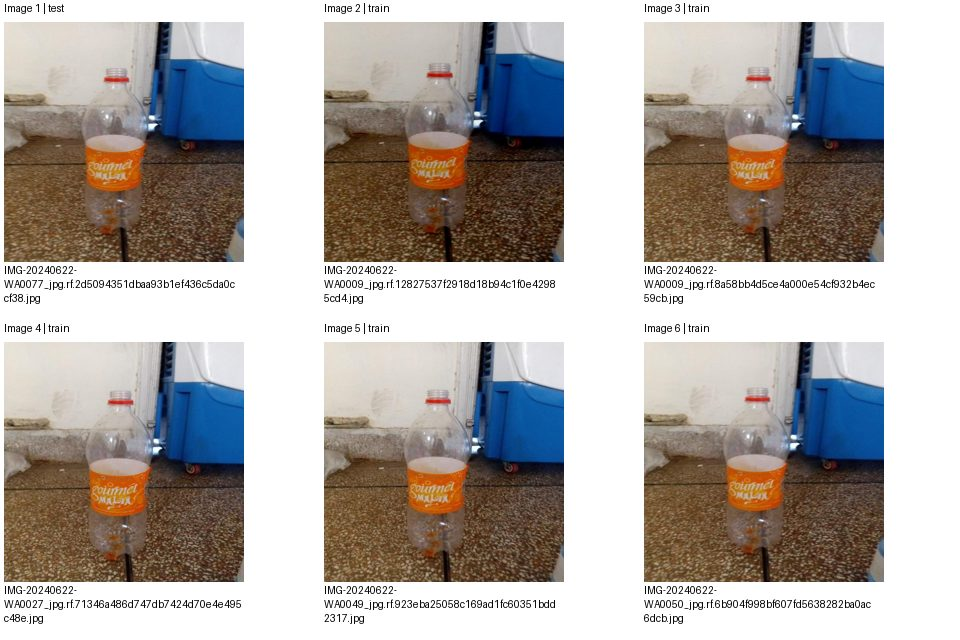

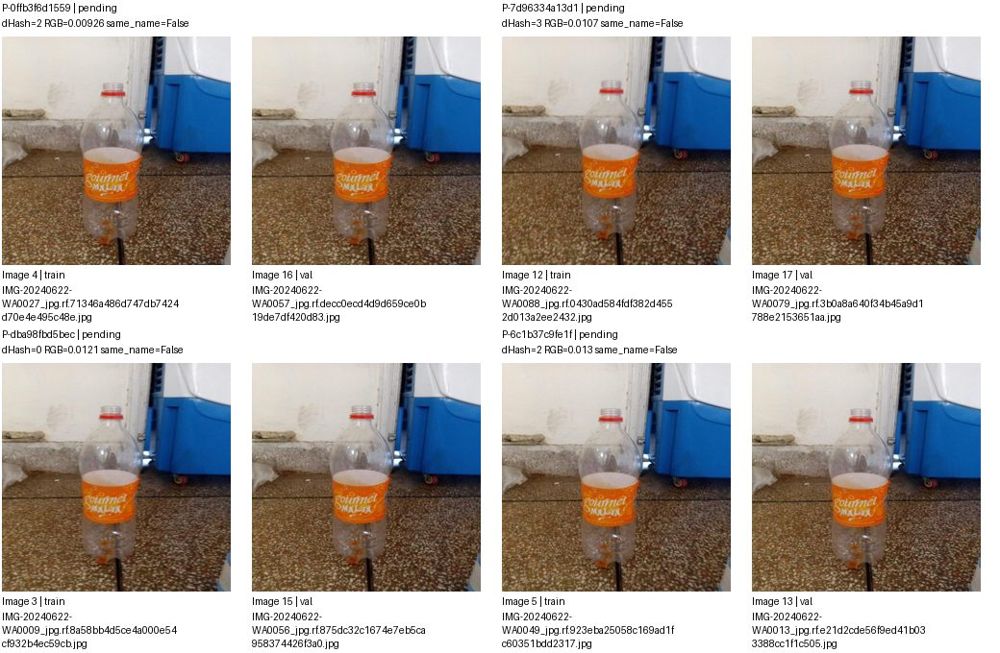

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-0ffb3f6d1559,images/train/IMG-20240622-WA0027_jpg.rf.71346a486d747db7424d70e4e495c48e.jpg,images/val/IMG-20240622-WA0057_jpg.rf.decc0ecd4d9d659ce0b19de7df420d83.jpg,pending,
P-7d96334a13d1,images/train/IMG-20240622-WA0088_jpg.rf.0430ad584fdf382d4552d013a2ee2432.jpg,images/val/IMG-20240622-WA0079_jpg.rf.3b0a8a640f34b45a9d1788e2153651aa.jpg,pending,
P-dba98fbd5bec,images/train/IMG-20240622-WA0009_jpg.rf.8a58bb4d5ce4a000e54cf932b4ec59cb.jpg,images/val/IMG-20240622-WA0056_jpg.rf.875dc32c1674e7eb5ca958374426f3a0.jpg,pending,
P-6c1b37c9fe1f,images/train/IMG-20240622-WA0049_jpg.rf.923eba25058c169ad1fc60351bdd2317.jpg,images/val/IMG-20240622-WA0013_jpg.rf.e21d2cde56f9ed41b033388cc1f1c505.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 112/166 G-a97b3bb18ad4 | 20 ảnh, 56 cặp
Split: {'test': 1, 'train': 11, 'val': 8}
Quyết định: {'pending': 56}
Ảnh trang 2/4; cặp trang 2/14. Nhóm liên thông không phải kết luận trùng.


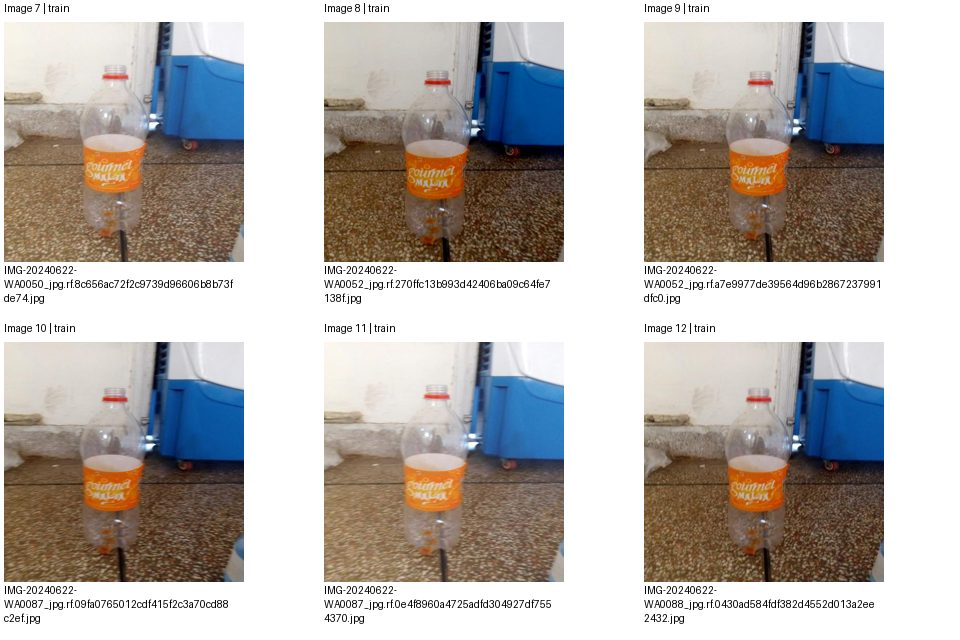

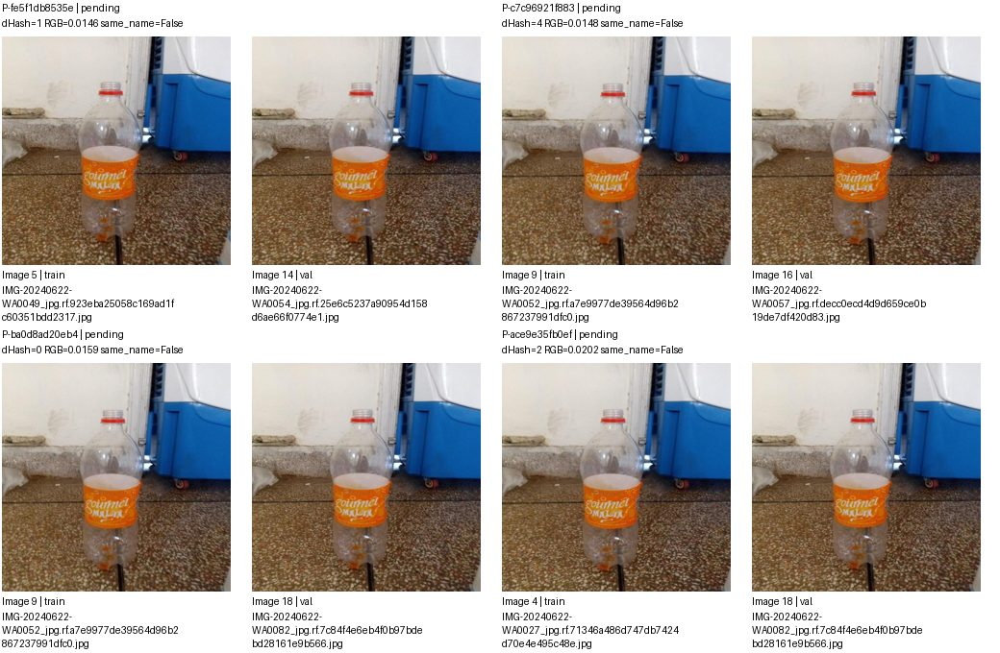

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-fe5f1db8535e,images/train/IMG-20240622-WA0049_jpg.rf.923eba25058c169ad1fc60351bdd2317.jpg,images/val/IMG-20240622-WA0054_jpg.rf.25e6c5237a90954d158d6ae66f0774e1.jpg,pending,
P-c7c96921f883,images/train/IMG-20240622-WA0052_jpg.rf.a7e9977de39564d96b2867237991dfc0.jpg,images/val/IMG-20240622-WA0057_jpg.rf.decc0ecd4d9d659ce0b19de7df420d83.jpg,pending,
P-ba0d8ad20eb4,images/train/IMG-20240622-WA0052_jpg.rf.a7e9977de39564d96b2867237991dfc0.jpg,images/val/IMG-20240622-WA0082_jpg.rf.7c84f4e6eb4f0b97bdebd28161e9b566.jpg,pending,
P-ace9e35fb0ef,images/train/IMG-20240622-WA0027_jpg.rf.71346a486d747db7424d70e4e495c48e.jpg,images/val/IMG-20240622-WA0082_jpg.rf.7c84f4e6eb4f0b97bdebd28161e9b566.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 112/166 G-a97b3bb18ad4 | 20 ảnh, 56 cặp
Split: {'test': 1, 'train': 11, 'val': 8}
Quyết định: {'pending': 56}
Ảnh trang 3/4; cặp trang 3/14. Nhóm liên thông không phải kết luận trùng.


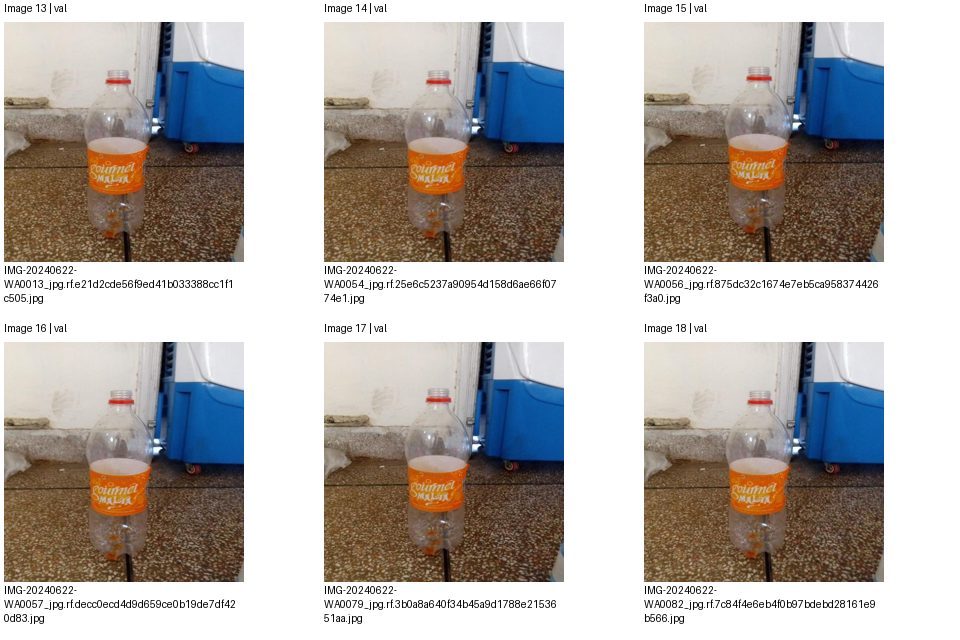

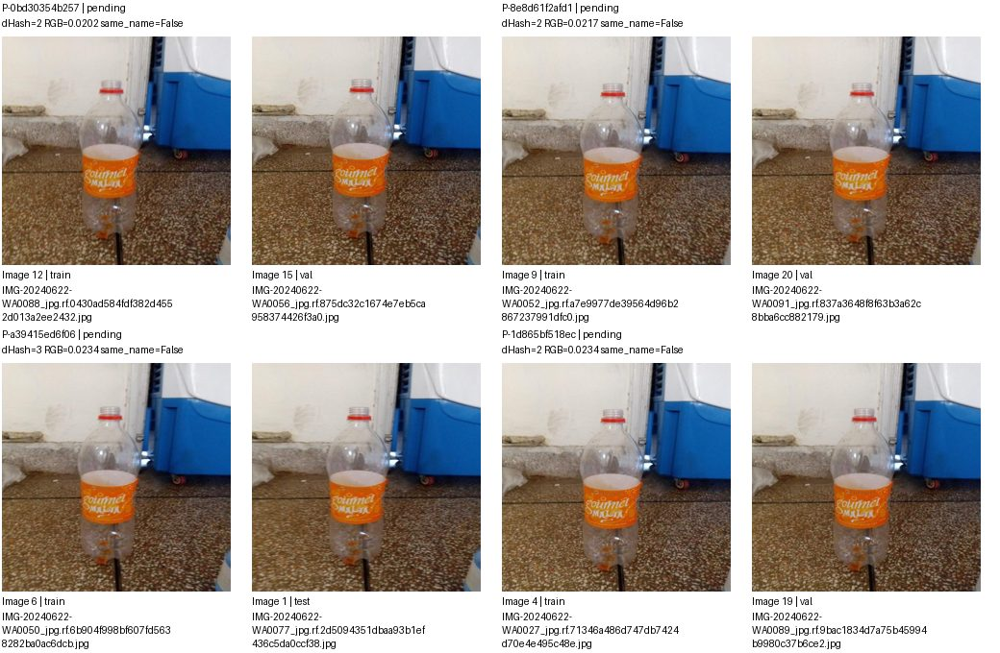

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-0bd30354b257,images/train/IMG-20240622-WA0088_jpg.rf.0430ad584fdf382d4552d013a2ee2432.jpg,images/val/IMG-20240622-WA0056_jpg.rf.875dc32c1674e7eb5ca958374426f3a0.jpg,pending,
P-8e8d61f2afd1,images/train/IMG-20240622-WA0052_jpg.rf.a7e9977de39564d96b2867237991dfc0.jpg,images/val/IMG-20240622-WA0091_jpg.rf.837a3648f8f63b3a62c8bba6cc882179.jpg,pending,
P-a39415ed6f06,images/train/IMG-20240622-WA0050_jpg.rf.6b904f998bf607fd5638282ba0ac6dcb.jpg,images/test/IMG-20240622-WA0077_jpg.rf.2d5094351dbaa93b1ef436c5da0ccf38.jpg,pending,
P-1d865bf518ec,images/train/IMG-20240622-WA0027_jpg.rf.71346a486d747db7424d70e4e495c48e.jpg,images/val/IMG-20240622-WA0089_jpg.rf.9bac1834d7a75b45994b9980c37b6ce2.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 112/166 G-a97b3bb18ad4 | 20 ảnh, 56 cặp
Split: {'test': 1, 'train': 11, 'val': 8}
Quyết định: {'pending': 56}
Ảnh trang 4/4; cặp trang 4/14. Nhóm liên thông không phải kết luận trùng.


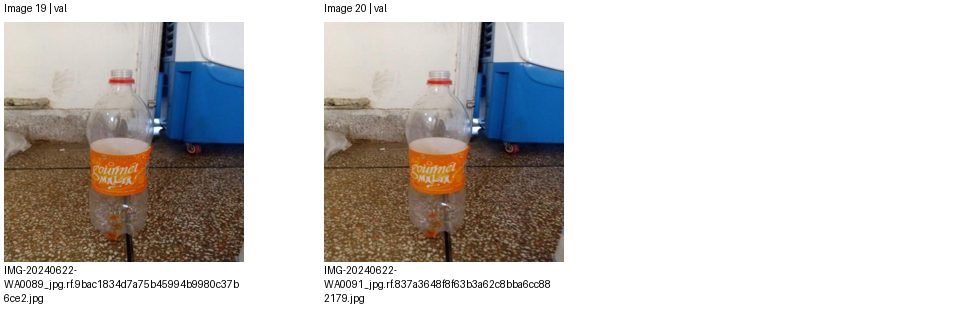

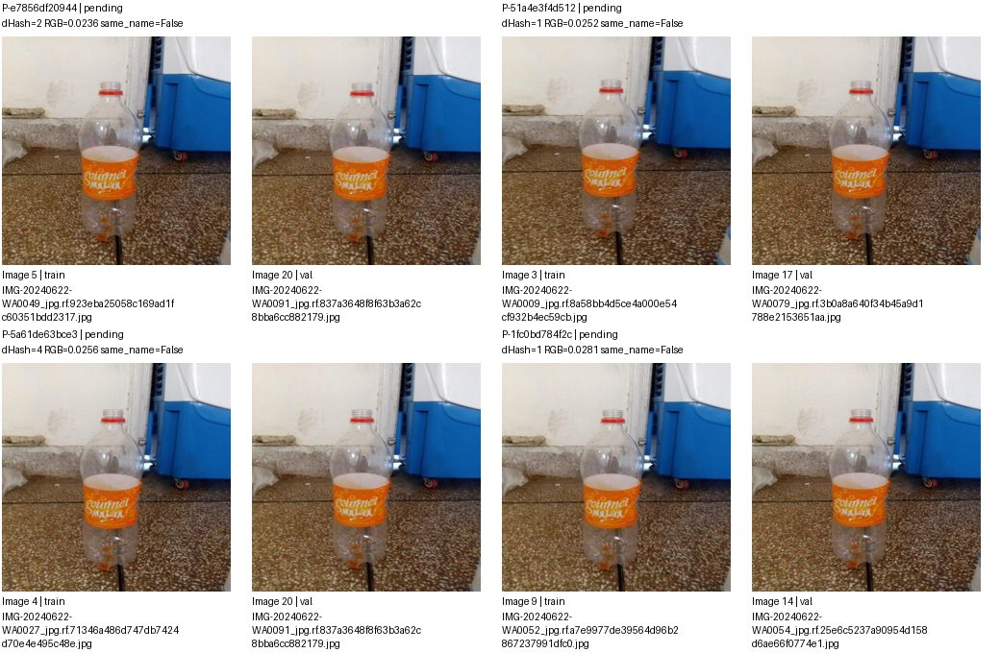

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-e7856df20944,images/train/IMG-20240622-WA0049_jpg.rf.923eba25058c169ad1fc60351bdd2317.jpg,images/val/IMG-20240622-WA0091_jpg.rf.837a3648f8f63b3a62c8bba6cc882179.jpg,pending,
P-51a4e3f4d512,images/train/IMG-20240622-WA0009_jpg.rf.8a58bb4d5ce4a000e54cf932b4ec59cb.jpg,images/val/IMG-20240622-WA0079_jpg.rf.3b0a8a640f34b45a9d1788e2153651aa.jpg,pending,
P-5a61de63bce3,images/train/IMG-20240622-WA0027_jpg.rf.71346a486d747db7424d70e4e495c48e.jpg,images/val/IMG-20240622-WA0091_jpg.rf.837a3648f8f63b3a62c8bba6cc882179.jpg,pending,
P-1fc0bd784f2c,images/train/IMG-20240622-WA0052_jpg.rf.a7e9977de39564d96b2867237991dfc0.jpg,images/val/IMG-20240622-WA0054_jpg.rf.25e6c5237a90954d158d6ae66f0774e1.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 112/166 G-a97b3bb18ad4 | 20 ảnh, 56 cặp
Split: {'test': 1, 'train': 11, 'val': 8}
Quyết định: {'pending': 56}
Ảnh trang None/4; cặp trang 5/14. Nhóm liên thông không phải kết luận trùng.


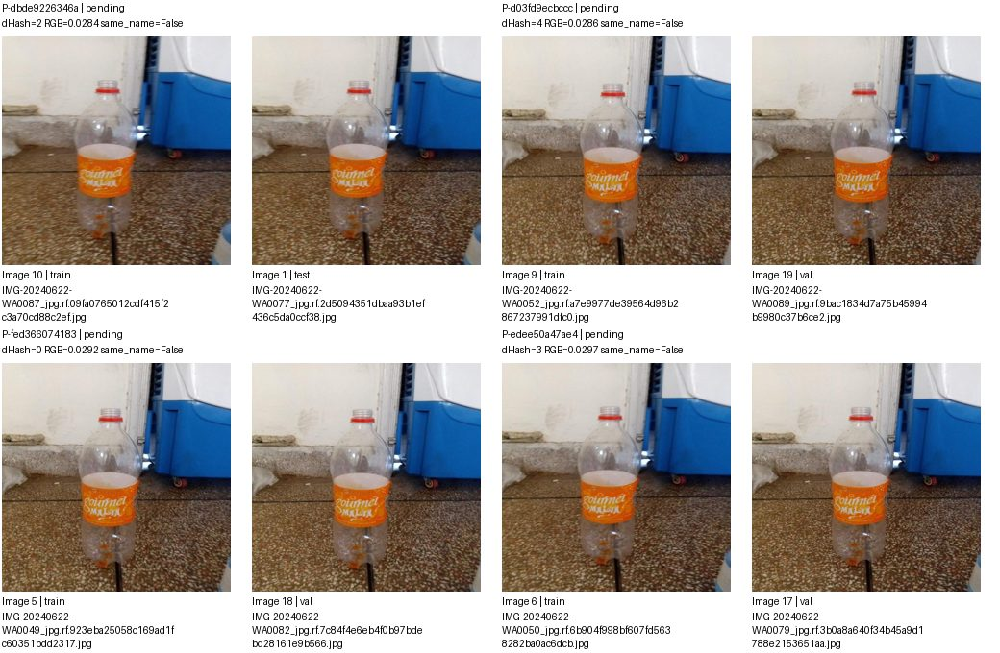

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-dbde9226346a,images/train/IMG-20240622-WA0087_jpg.rf.09fa0765012cdf415f2c3a70cd88c2ef.jpg,images/test/IMG-20240622-WA0077_jpg.rf.2d5094351dbaa93b1ef436c5da0ccf38.jpg,pending,
P-d03fd9ecbccc,images/train/IMG-20240622-WA0052_jpg.rf.a7e9977de39564d96b2867237991dfc0.jpg,images/val/IMG-20240622-WA0089_jpg.rf.9bac1834d7a75b45994b9980c37b6ce2.jpg,pending,
P-fed366074183,images/train/IMG-20240622-WA0049_jpg.rf.923eba25058c169ad1fc60351bdd2317.jpg,images/val/IMG-20240622-WA0082_jpg.rf.7c84f4e6eb4f0b97bdebd28161e9b566.jpg,pending,
P-edee50a47ae4,images/train/IMG-20240622-WA0050_jpg.rf.6b904f998bf607fd5638282ba0ac6dcb.jpg,images/val/IMG-20240622-WA0079_jpg.rf.3b0a8a640f34b45a9d1788e2153651aa.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 112/166 G-a97b3bb18ad4 | 20 ảnh, 56 cặp
Split: {'test': 1, 'train': 11, 'val': 8}
Quyết định: {'pending': 56}
Ảnh trang None/4; cặp trang 6/14. Nhóm liên thông không phải kết luận trùng.


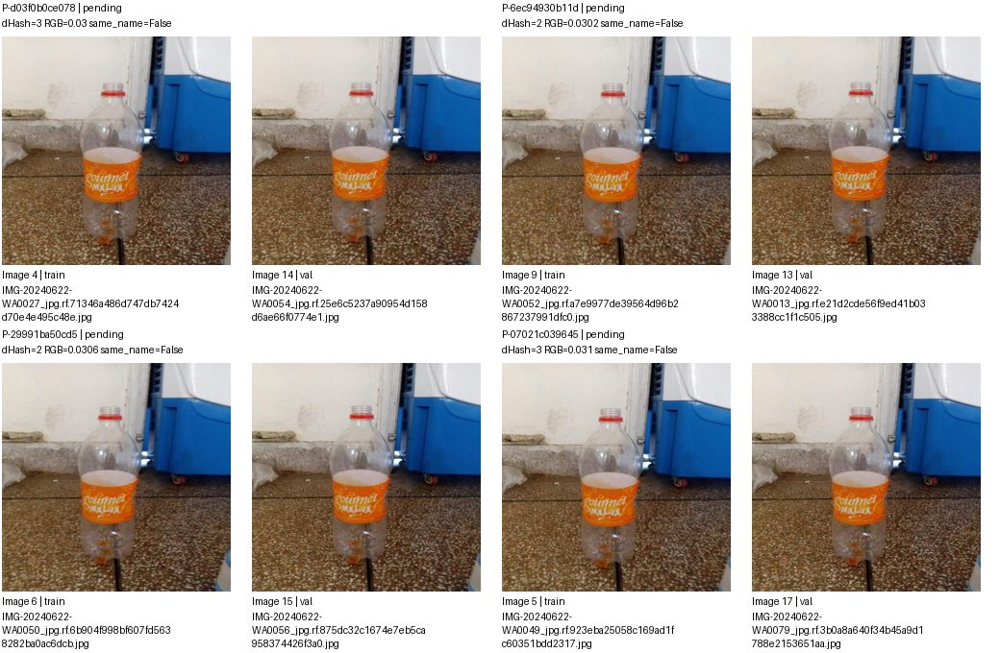

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-d03f0b0ce078,images/train/IMG-20240622-WA0027_jpg.rf.71346a486d747db7424d70e4e495c48e.jpg,images/val/IMG-20240622-WA0054_jpg.rf.25e6c5237a90954d158d6ae66f0774e1.jpg,pending,
P-6ec94930b11d,images/train/IMG-20240622-WA0052_jpg.rf.a7e9977de39564d96b2867237991dfc0.jpg,images/val/IMG-20240622-WA0013_jpg.rf.e21d2cde56f9ed41b033388cc1f1c505.jpg,pending,
P-29991ba50cd5,images/train/IMG-20240622-WA0050_jpg.rf.6b904f998bf607fd5638282ba0ac6dcb.jpg,images/val/IMG-20240622-WA0056_jpg.rf.875dc32c1674e7eb5ca958374426f3a0.jpg,pending,
P-07021c039645,images/train/IMG-20240622-WA0049_jpg.rf.923eba25058c169ad1fc60351bdd2317.jpg,images/val/IMG-20240622-WA0079_jpg.rf.3b0a8a640f34b45a9d1788e2153651aa.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 112/166 G-a97b3bb18ad4 | 20 ảnh, 56 cặp
Split: {'test': 1, 'train': 11, 'val': 8}
Quyết định: {'pending': 56}
Ảnh trang None/4; cặp trang 7/14. Nhóm liên thông không phải kết luận trùng.


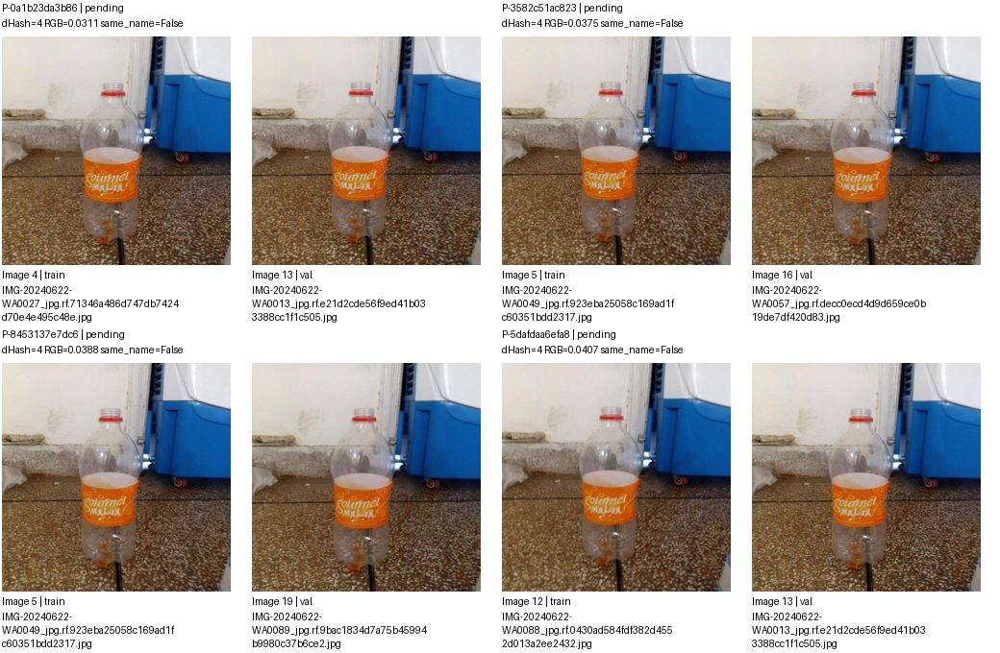

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-0a1b23da3b86,images/train/IMG-20240622-WA0027_jpg.rf.71346a486d747db7424d70e4e495c48e.jpg,images/val/IMG-20240622-WA0013_jpg.rf.e21d2cde56f9ed41b033388cc1f1c505.jpg,pending,
P-3582c51ac823,images/train/IMG-20240622-WA0049_jpg.rf.923eba25058c169ad1fc60351bdd2317.jpg,images/val/IMG-20240622-WA0057_jpg.rf.decc0ecd4d9d659ce0b19de7df420d83.jpg,pending,
P-8453137e7dc6,images/train/IMG-20240622-WA0049_jpg.rf.923eba25058c169ad1fc60351bdd2317.jpg,images/val/IMG-20240622-WA0089_jpg.rf.9bac1834d7a75b45994b9980c37b6ce2.jpg,pending,
P-5dafdaa6efa8,images/train/IMG-20240622-WA0088_jpg.rf.0430ad584fdf382d4552d013a2ee2432.jpg,images/val/IMG-20240622-WA0013_jpg.rf.e21d2cde56f9ed41b033388cc1f1c505.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 112/166 G-a97b3bb18ad4 | 20 ảnh, 56 cặp
Split: {'test': 1, 'train': 11, 'val': 8}
Quyết định: {'pending': 56}
Ảnh trang None/4; cặp trang 8/14. Nhóm liên thông không phải kết luận trùng.


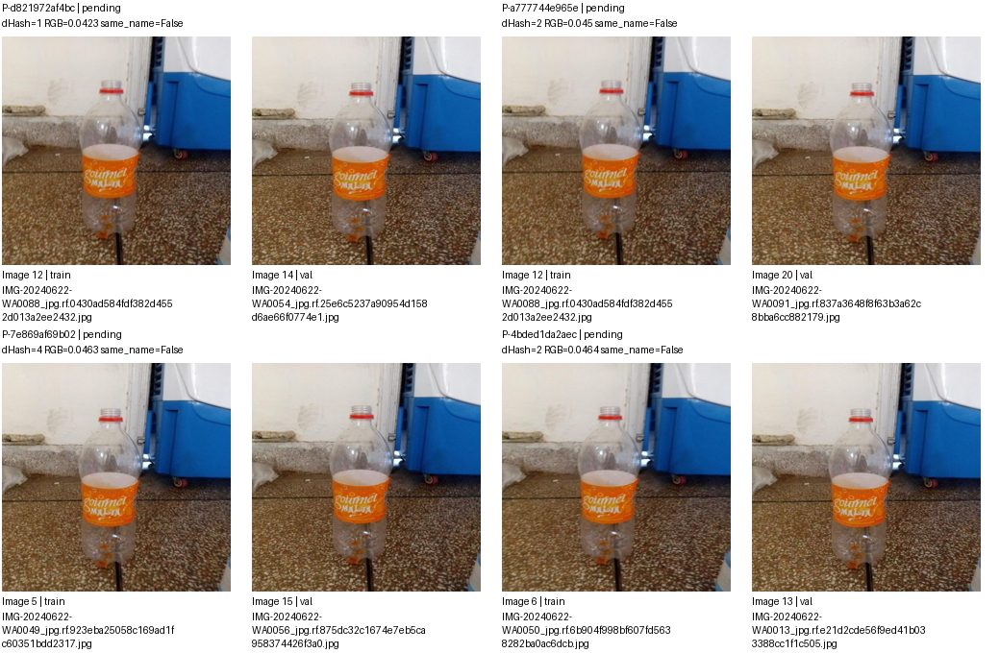

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-d821972af4bc,images/train/IMG-20240622-WA0088_jpg.rf.0430ad584fdf382d4552d013a2ee2432.jpg,images/val/IMG-20240622-WA0054_jpg.rf.25e6c5237a90954d158d6ae66f0774e1.jpg,pending,
P-a777744e965e,images/train/IMG-20240622-WA0088_jpg.rf.0430ad584fdf382d4552d013a2ee2432.jpg,images/val/IMG-20240622-WA0091_jpg.rf.837a3648f8f63b3a62c8bba6cc882179.jpg,pending,
P-7e869af69b02,images/train/IMG-20240622-WA0049_jpg.rf.923eba25058c169ad1fc60351bdd2317.jpg,images/val/IMG-20240622-WA0056_jpg.rf.875dc32c1674e7eb5ca958374426f3a0.jpg,pending,
P-4bded1da2aec,images/train/IMG-20240622-WA0050_jpg.rf.6b904f998bf607fd5638282ba0ac6dcb.jpg,images/val/IMG-20240622-WA0013_jpg.rf.e21d2cde56f9ed41b033388cc1f1c505.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 112/166 G-a97b3bb18ad4 | 20 ảnh, 56 cặp
Split: {'test': 1, 'train': 11, 'val': 8}
Quyết định: {'pending': 56}
Ảnh trang None/4; cặp trang 9/14. Nhóm liên thông không phải kết luận trùng.


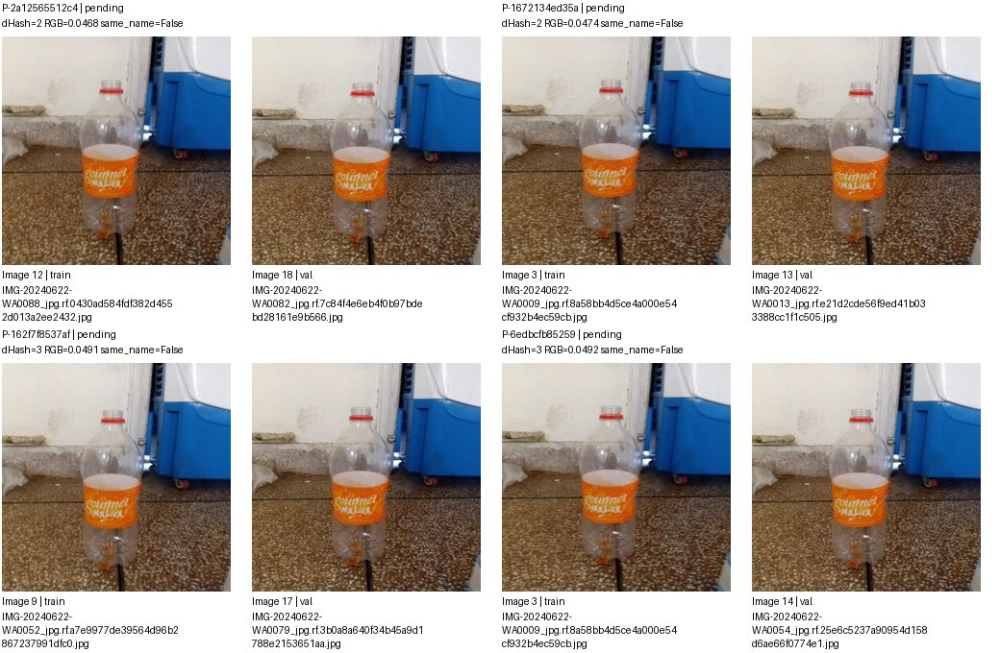

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-2a12565512c4,images/train/IMG-20240622-WA0088_jpg.rf.0430ad584fdf382d4552d013a2ee2432.jpg,images/val/IMG-20240622-WA0082_jpg.rf.7c84f4e6eb4f0b97bdebd28161e9b566.jpg,pending,
P-1672134ed35a,images/train/IMG-20240622-WA0009_jpg.rf.8a58bb4d5ce4a000e54cf932b4ec59cb.jpg,images/val/IMG-20240622-WA0013_jpg.rf.e21d2cde56f9ed41b033388cc1f1c505.jpg,pending,
P-162f7f8537af,images/train/IMG-20240622-WA0052_jpg.rf.a7e9977de39564d96b2867237991dfc0.jpg,images/val/IMG-20240622-WA0079_jpg.rf.3b0a8a640f34b45a9d1788e2153651aa.jpg,pending,
P-6edbcfb85259,images/train/IMG-20240622-WA0009_jpg.rf.8a58bb4d5ce4a000e54cf932b4ec59cb.jpg,images/val/IMG-20240622-WA0054_jpg.rf.25e6c5237a90954d158d6ae66f0774e1.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 112/166 G-a97b3bb18ad4 | 20 ảnh, 56 cặp
Split: {'test': 1, 'train': 11, 'val': 8}
Quyết định: {'pending': 56}
Ảnh trang None/4; cặp trang 10/14. Nhóm liên thông không phải kết luận trùng.


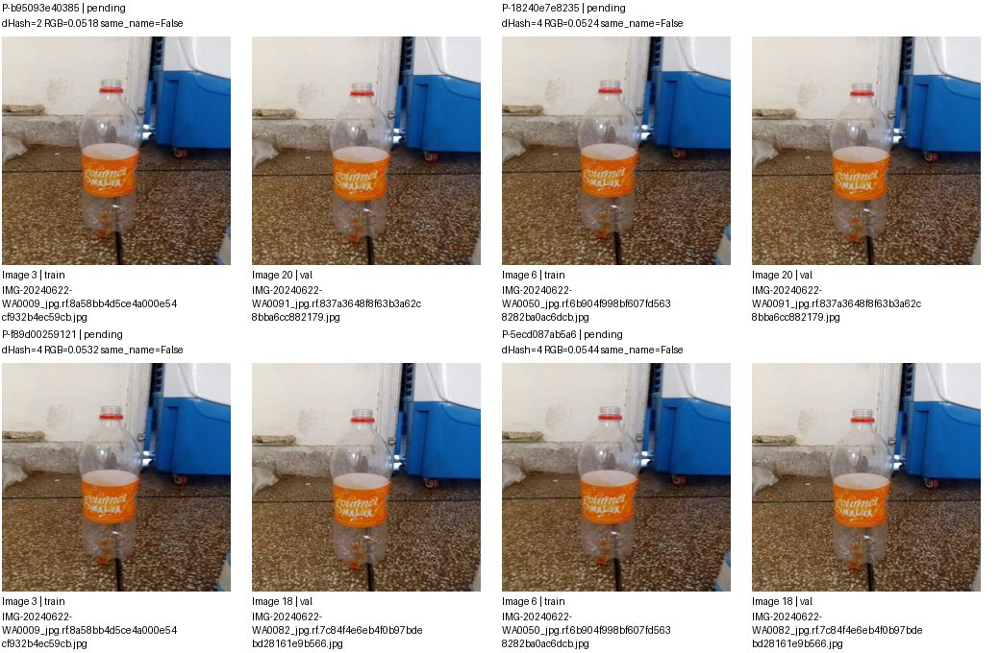

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-b95093e40385,images/train/IMG-20240622-WA0009_jpg.rf.8a58bb4d5ce4a000e54cf932b4ec59cb.jpg,images/val/IMG-20240622-WA0091_jpg.rf.837a3648f8f63b3a62c8bba6cc882179.jpg,pending,
P-18240e7e8235,images/train/IMG-20240622-WA0050_jpg.rf.6b904f998bf607fd5638282ba0ac6dcb.jpg,images/val/IMG-20240622-WA0091_jpg.rf.837a3648f8f63b3a62c8bba6cc882179.jpg,pending,
P-f89d00259121,images/train/IMG-20240622-WA0009_jpg.rf.8a58bb4d5ce4a000e54cf932b4ec59cb.jpg,images/val/IMG-20240622-WA0082_jpg.rf.7c84f4e6eb4f0b97bdebd28161e9b566.jpg,pending,
P-5ecd087ab5a6,images/train/IMG-20240622-WA0050_jpg.rf.6b904f998bf607fd5638282ba0ac6dcb.jpg,images/val/IMG-20240622-WA0082_jpg.rf.7c84f4e6eb4f0b97bdebd28161e9b566.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 112/166 G-a97b3bb18ad4 | 20 ảnh, 56 cặp
Split: {'test': 1, 'train': 11, 'val': 8}
Quyết định: {'pending': 56}
Ảnh trang None/4; cặp trang 11/14. Nhóm liên thông không phải kết luận trùng.


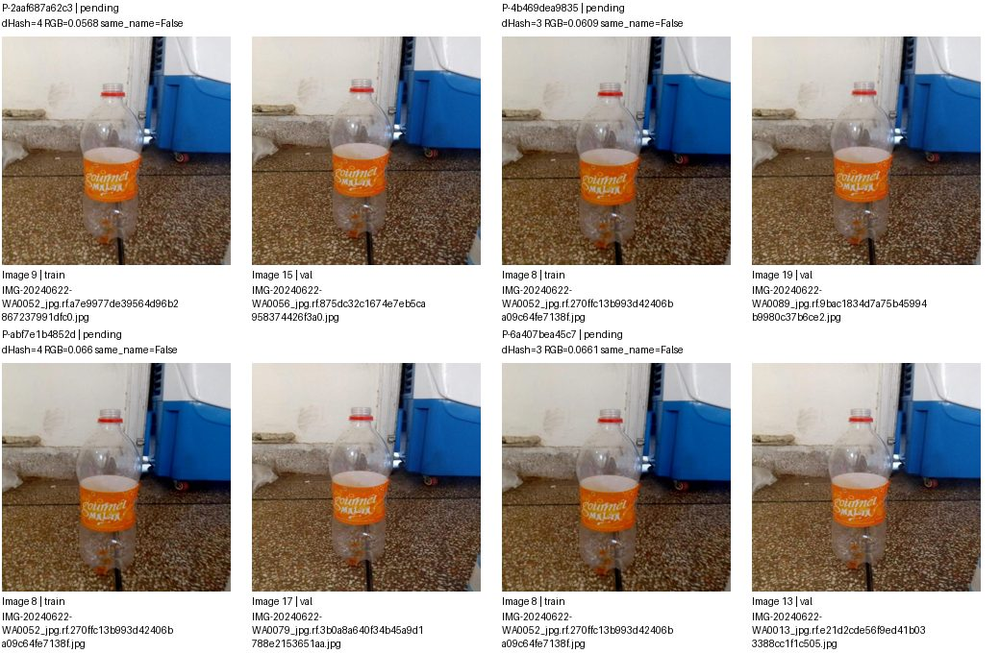

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-2aaf687a62c3,images/train/IMG-20240622-WA0052_jpg.rf.a7e9977de39564d96b2867237991dfc0.jpg,images/val/IMG-20240622-WA0056_jpg.rf.875dc32c1674e7eb5ca958374426f3a0.jpg,pending,
P-4b469dea9835,images/train/IMG-20240622-WA0052_jpg.rf.270ffc13b993d42406ba09c64fe7138f.jpg,images/val/IMG-20240622-WA0089_jpg.rf.9bac1834d7a75b45994b9980c37b6ce2.jpg,pending,
P-abf7e1b4852d,images/train/IMG-20240622-WA0052_jpg.rf.270ffc13b993d42406ba09c64fe7138f.jpg,images/val/IMG-20240622-WA0079_jpg.rf.3b0a8a640f34b45a9d1788e2153651aa.jpg,pending,
P-6a407bea45c7,images/train/IMG-20240622-WA0052_jpg.rf.270ffc13b993d42406ba09c64fe7138f.jpg,images/val/IMG-20240622-WA0013_jpg.rf.e21d2cde56f9ed41b033388cc1f1c505.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 112/166 G-a97b3bb18ad4 | 20 ảnh, 56 cặp
Split: {'test': 1, 'train': 11, 'val': 8}
Quyết định: {'pending': 56}
Ảnh trang None/4; cặp trang 12/14. Nhóm liên thông không phải kết luận trùng.


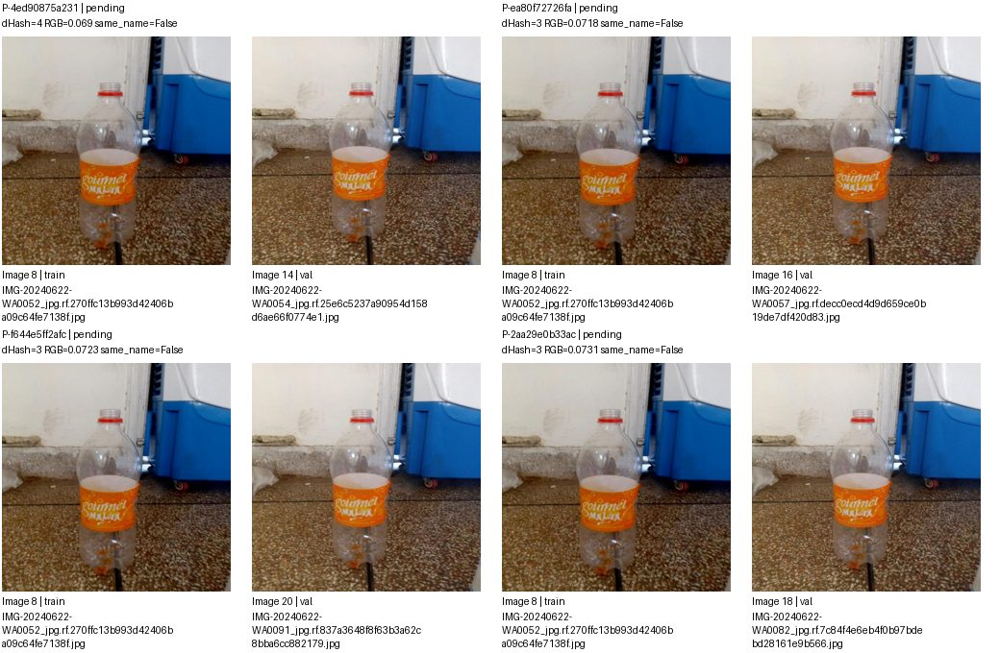

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-4ed90875a231,images/train/IMG-20240622-WA0052_jpg.rf.270ffc13b993d42406ba09c64fe7138f.jpg,images/val/IMG-20240622-WA0054_jpg.rf.25e6c5237a90954d158d6ae66f0774e1.jpg,pending,
P-ea80f72726fa,images/train/IMG-20240622-WA0052_jpg.rf.270ffc13b993d42406ba09c64fe7138f.jpg,images/val/IMG-20240622-WA0057_jpg.rf.decc0ecd4d9d659ce0b19de7df420d83.jpg,pending,
P-f644e5ff2afc,images/train/IMG-20240622-WA0052_jpg.rf.270ffc13b993d42406ba09c64fe7138f.jpg,images/val/IMG-20240622-WA0091_jpg.rf.837a3648f8f63b3a62c8bba6cc882179.jpg,pending,
P-2aa29e0b33ac,images/train/IMG-20240622-WA0052_jpg.rf.270ffc13b993d42406ba09c64fe7138f.jpg,images/val/IMG-20240622-WA0082_jpg.rf.7c84f4e6eb4f0b97bdebd28161e9b566.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 112/166 G-a97b3bb18ad4 | 20 ảnh, 56 cặp
Split: {'test': 1, 'train': 11, 'val': 8}
Quyết định: {'pending': 56}
Ảnh trang None/4; cặp trang 13/14. Nhóm liên thông không phải kết luận trùng.


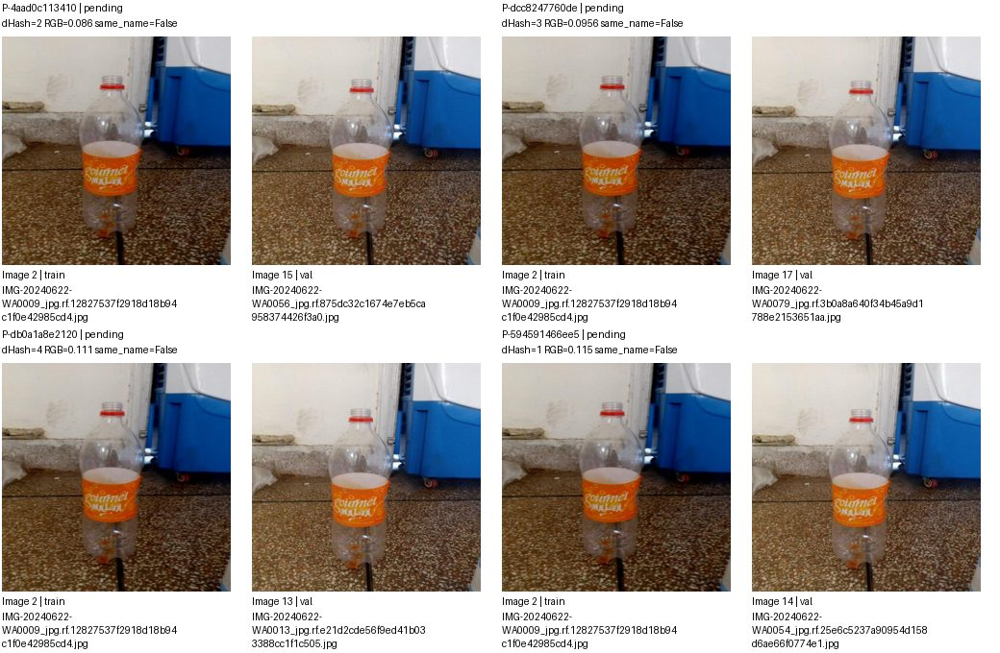

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-4aad0c113410,images/train/IMG-20240622-WA0009_jpg.rf.12827537f2918d18b94c1f0e42985cd4.jpg,images/val/IMG-20240622-WA0056_jpg.rf.875dc32c1674e7eb5ca958374426f3a0.jpg,pending,
P-dcc8247760de,images/train/IMG-20240622-WA0009_jpg.rf.12827537f2918d18b94c1f0e42985cd4.jpg,images/val/IMG-20240622-WA0079_jpg.rf.3b0a8a640f34b45a9d1788e2153651aa.jpg,pending,
P-db0a1a8e2120,images/train/IMG-20240622-WA0009_jpg.rf.12827537f2918d18b94c1f0e42985cd4.jpg,images/val/IMG-20240622-WA0013_jpg.rf.e21d2cde56f9ed41b033388cc1f1c505.jpg,pending,
P-594591466ee5,images/train/IMG-20240622-WA0009_jpg.rf.12827537f2918d18b94c1f0e42985cd4.jpg,images/val/IMG-20240622-WA0054_jpg.rf.25e6c5237a90954d158d6ae66f0774e1.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 112/166 G-a97b3bb18ad4 | 20 ảnh, 56 cặp
Split: {'test': 1, 'train': 11, 'val': 8}
Quyết định: {'pending': 56}
Ảnh trang None/4; cặp trang 14/14. Nhóm liên thông không phải kết luận trùng.


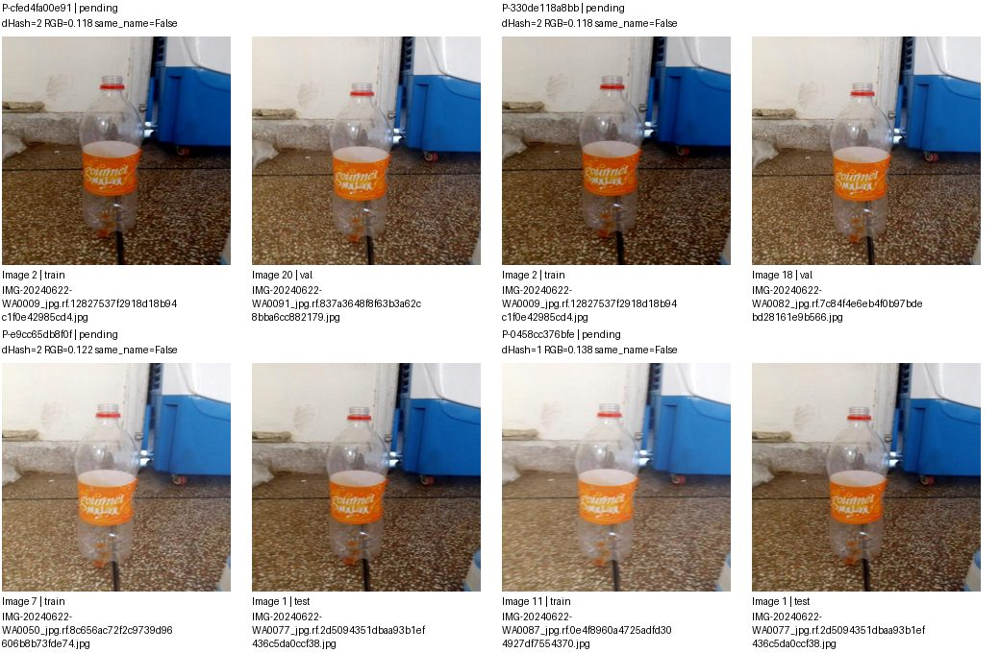

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-cfed4fa00e91,images/train/IMG-20240622-WA0009_jpg.rf.12827537f2918d18b94c1f0e42985cd4.jpg,images/val/IMG-20240622-WA0091_jpg.rf.837a3648f8f63b3a62c8bba6cc882179.jpg,pending,
P-330de118a8bb,images/train/IMG-20240622-WA0009_jpg.rf.12827537f2918d18b94c1f0e42985cd4.jpg,images/val/IMG-20240622-WA0082_jpg.rf.7c84f4e6eb4f0b97bdebd28161e9b566.jpg,pending,
P-e9cc65db8f0f,images/train/IMG-20240622-WA0050_jpg.rf.8c656ac72f2c9739d96606b8b73fde74.jpg,images/test/IMG-20240622-WA0077_jpg.rf.2d5094351dbaa93b1ef436c5da0ccf38.jpg,pending,
P-0458cc376bfe,images/train/IMG-20240622-WA0087_jpg.rf.0e4f8960a4725adfd304927df7554370.jpg,images/test/IMG-20240622-WA0077_jpg.rf.2d5094351dbaa93b1ef436c5da0ccf38.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 113/166 G-f35f811cdcf6 | 3 ảnh, 2 cặp
Split: {'train': 2, 'val': 1}
Quyết định: {'pending': 2}
Ảnh trang 1/1; cặp trang 1/1. Nhóm liên thông không phải kết luận trùng.


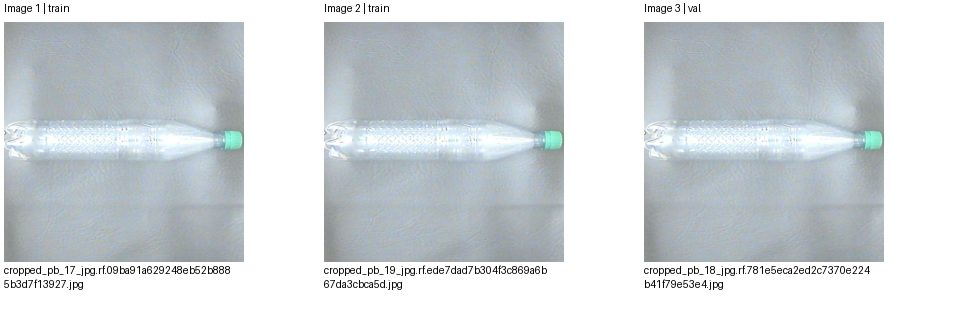

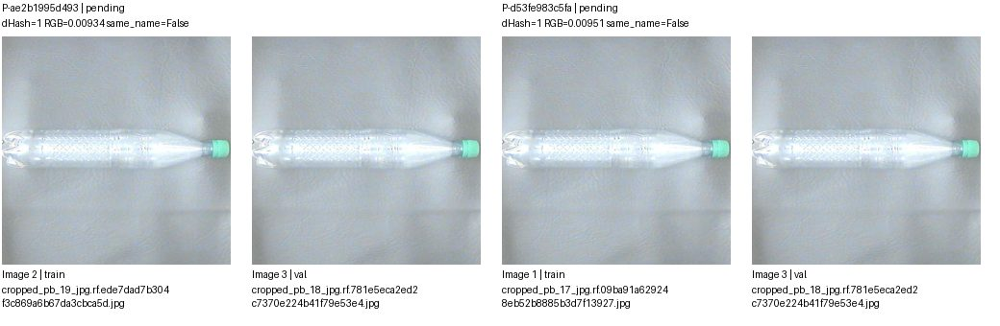

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-ae2b1995d493,images/train/cropped_pb_19_jpg.rf.ede7dad7b304f3c869a6b67da3cbca5d.jpg,images/val/cropped_pb_18_jpg.rf.781e5eca2ed2c7370e224b41f79e53e4.jpg,pending,
P-d53fe983c5fa,images/train/cropped_pb_17_jpg.rf.09ba91a629248eb52b8885b3d7f13927.jpg,images/val/cropped_pb_18_jpg.rf.781e5eca2ed2c7370e224b41f79e53e4.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 114/166 G-e3732901d706 | 3 ảnh, 2 cặp
Split: {'train': 2, 'val': 1}
Quyết định: {'pending': 2}
Ảnh trang 1/1; cặp trang 1/1. Nhóm liên thông không phải kết luận trùng.


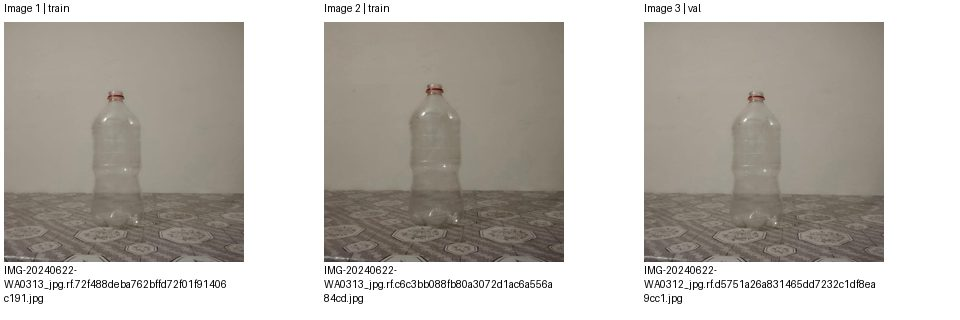

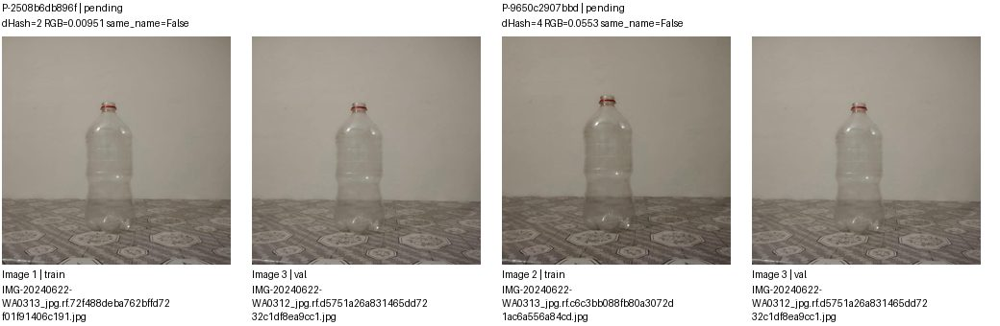

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-2508b6db896f,images/train/IMG-20240622-WA0313_jpg.rf.72f488deba762bffd72f01f91406c191.jpg,images/val/IMG-20240622-WA0312_jpg.rf.d5751a26a831465dd7232c1df8ea9cc1.jpg,pending,
P-9650c2907bbd,images/train/IMG-20240622-WA0313_jpg.rf.c6c3bb088fb80a3072d1ac6a556a84cd.jpg,images/val/IMG-20240622-WA0312_jpg.rf.d5751a26a831465dd7232c1df8ea9cc1.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 115/166 G-8909152947b4 | 6 ảnh, 8 cặp
Split: {'test': 1, 'train': 3, 'val': 2}
Quyết định: {'pending': 8}
Ảnh trang 1/1; cặp trang 1/2. Nhóm liên thông không phải kết luận trùng.


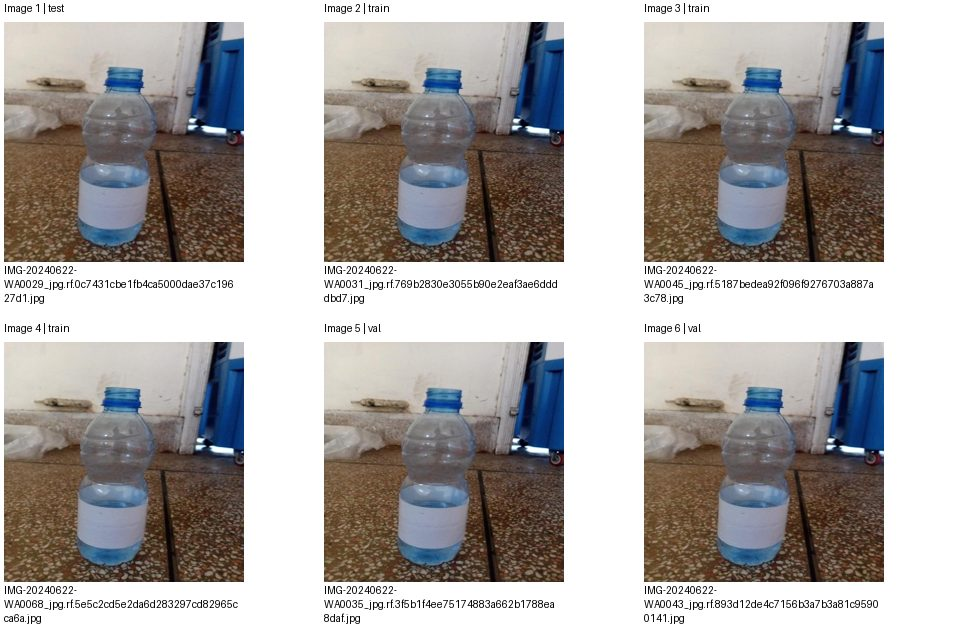

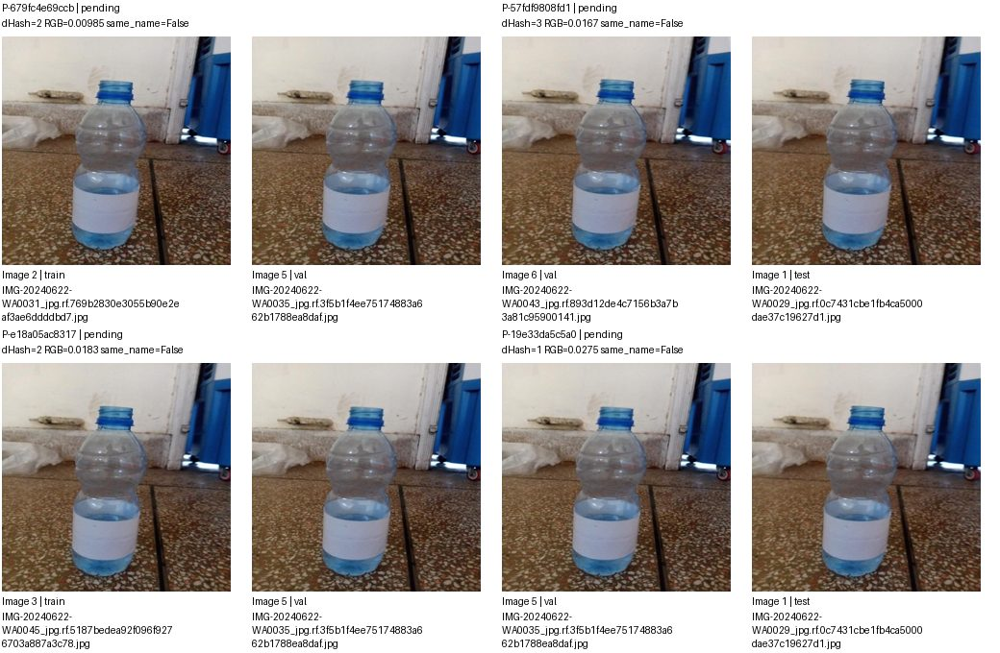

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-679fc4e69ccb,images/train/IMG-20240622-WA0031_jpg.rf.769b2830e3055b90e2eaf3ae6ddddbd7.jpg,images/val/IMG-20240622-WA0035_jpg.rf.3f5b1f4ee75174883a662b1788ea8daf.jpg,pending,
P-57fdf9808fd1,images/val/IMG-20240622-WA0043_jpg.rf.893d12de4c7156b3a7b3a81c95900141.jpg,images/test/IMG-20240622-WA0029_jpg.rf.0c7431cbe1fb4ca5000dae37c19627d1.jpg,pending,
P-e18a05ac8317,images/train/IMG-20240622-WA0045_jpg.rf.5187bedea92f096f9276703a887a3c78.jpg,images/val/IMG-20240622-WA0035_jpg.rf.3f5b1f4ee75174883a662b1788ea8daf.jpg,pending,
P-19e33da5c5a0,images/val/IMG-20240622-WA0035_jpg.rf.3f5b1f4ee75174883a662b1788ea8daf.jpg,images/test/IMG-20240622-WA0029_jpg.rf.0c7431cbe1fb4ca5000dae37c19627d1.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 115/166 G-8909152947b4 | 6 ảnh, 8 cặp
Split: {'test': 1, 'train': 3, 'val': 2}
Quyết định: {'pending': 8}
Ảnh trang None/1; cặp trang 2/2. Nhóm liên thông không phải kết luận trùng.


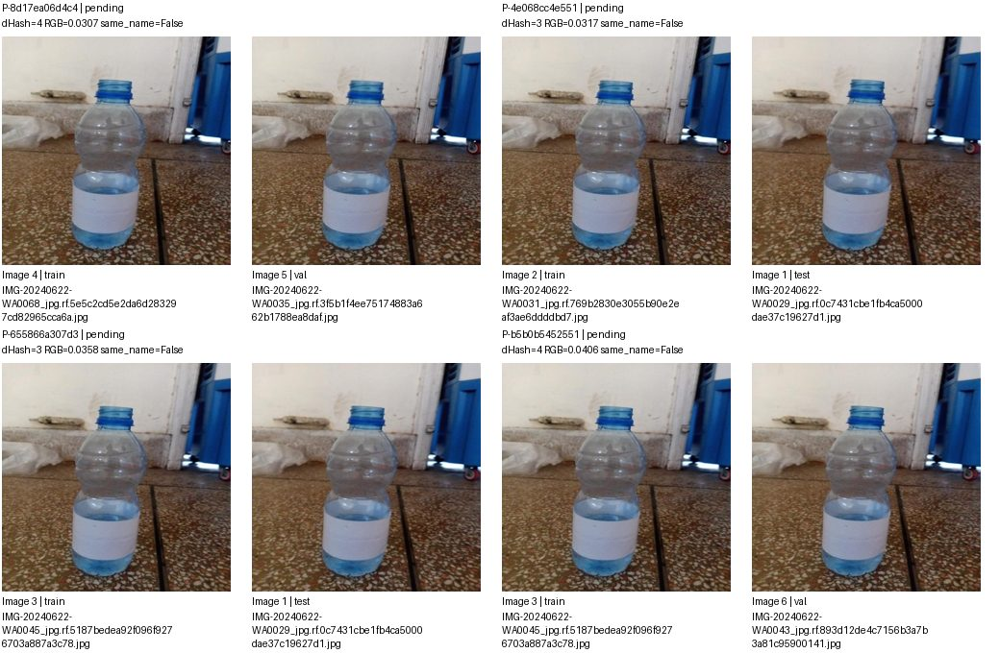

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-8d17ea06d4c4,images/train/IMG-20240622-WA0068_jpg.rf.5e5c2cd5e2da6d283297cd82965cca6a.jpg,images/val/IMG-20240622-WA0035_jpg.rf.3f5b1f4ee75174883a662b1788ea8daf.jpg,pending,
P-4e068cc4e551,images/train/IMG-20240622-WA0031_jpg.rf.769b2830e3055b90e2eaf3ae6ddddbd7.jpg,images/test/IMG-20240622-WA0029_jpg.rf.0c7431cbe1fb4ca5000dae37c19627d1.jpg,pending,
P-655866a307d3,images/train/IMG-20240622-WA0045_jpg.rf.5187bedea92f096f9276703a887a3c78.jpg,images/test/IMG-20240622-WA0029_jpg.rf.0c7431cbe1fb4ca5000dae37c19627d1.jpg,pending,
P-b5b0b5452551,images/train/IMG-20240622-WA0045_jpg.rf.5187bedea92f096f9276703a887a3c78.jpg,images/val/IMG-20240622-WA0043_jpg.rf.893d12de4c7156b3a7b3a81c95900141.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 116/166 G-13205e85c76f | 3 ảnh, 2 cặp
Split: {'test': 1, 'train': 1, 'val': 1}
Quyết định: {'pending': 2}
Ảnh trang 1/1; cặp trang 1/1. Nhóm liên thông không phải kết luận trùng.


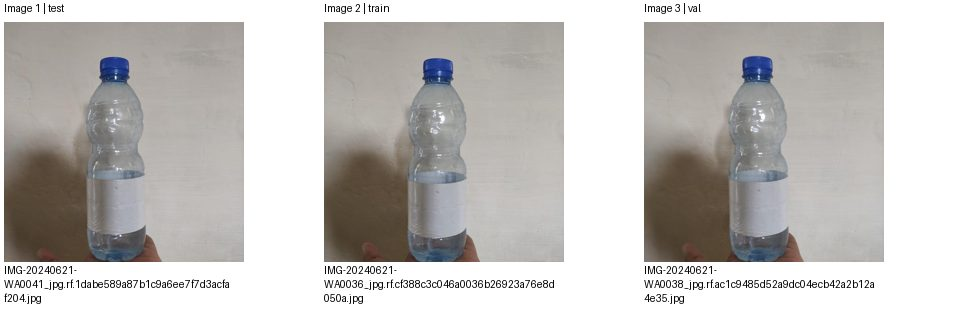

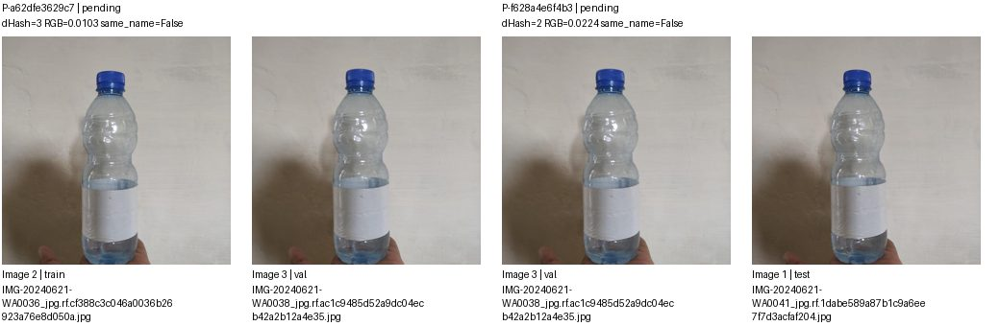

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-a62dfe3629c7,images/train/IMG-20240621-WA0036_jpg.rf.cf388c3c046a0036b26923a76e8d050a.jpg,images/val/IMG-20240621-WA0038_jpg.rf.ac1c9485d52a9dc04ecb42a2b12a4e35.jpg,pending,
P-f628a4e6f4b3,images/val/IMG-20240621-WA0038_jpg.rf.ac1c9485d52a9dc04ecb42a2b12a4e35.jpg,images/test/IMG-20240621-WA0041_jpg.rf.1dabe589a87b1c9a6ee7f7d3acfaf204.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 117/166 G-a356153d30d0 | 5 ảnh, 4 cặp
Split: {'test': 1, 'train': 4}
Quyết định: {'pending': 4}
Ảnh trang 1/1; cặp trang 1/1. Nhóm liên thông không phải kết luận trùng.


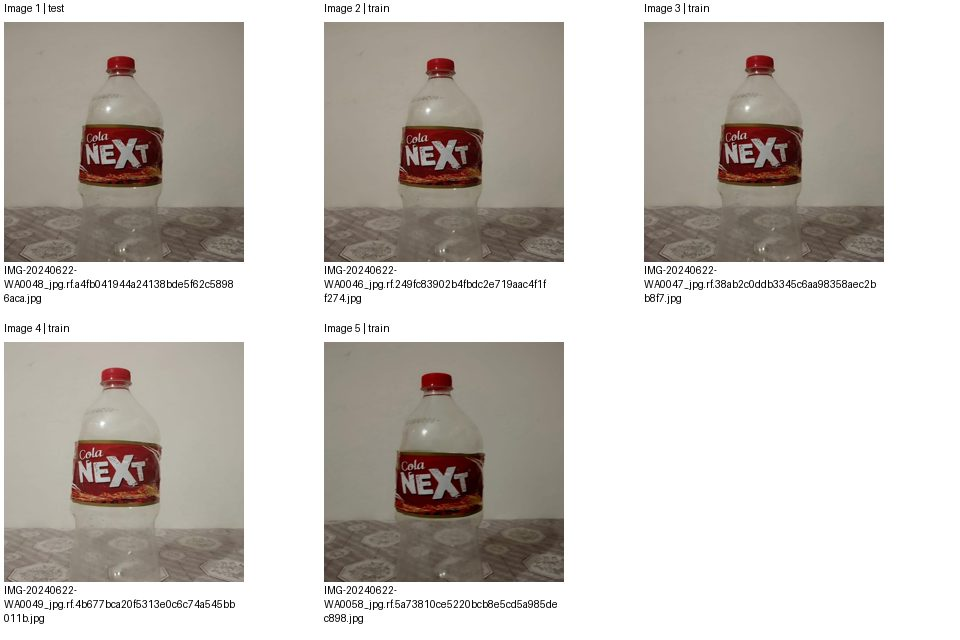

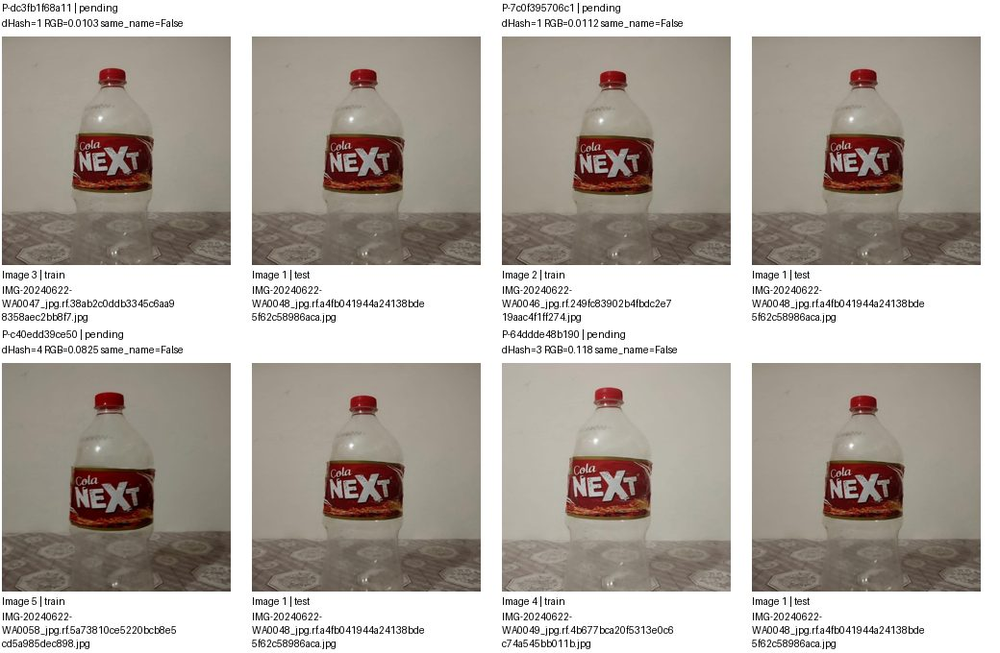

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-dc3fb1f68a11,images/train/IMG-20240622-WA0047_jpg.rf.38ab2c0ddb3345c6aa98358aec2bb8f7.jpg,images/test/IMG-20240622-WA0048_jpg.rf.a4fb041944a24138bde5f62c58986aca.jpg,pending,
P-7c0f395706c1,images/train/IMG-20240622-WA0046_jpg.rf.249fc83902b4fbdc2e719aac4f1ff274.jpg,images/test/IMG-20240622-WA0048_jpg.rf.a4fb041944a24138bde5f62c58986aca.jpg,pending,
P-c40edd39ce50,images/train/IMG-20240622-WA0058_jpg.rf.5a73810ce5220bcb8e5cd5a985dec898.jpg,images/test/IMG-20240622-WA0048_jpg.rf.a4fb041944a24138bde5f62c58986aca.jpg,pending,
P-64ddde48b190,images/train/IMG-20240622-WA0049_jpg.rf.4b677bca20f5313e0c6c74a545bb011b.jpg,images/test/IMG-20240622-WA0048_jpg.rf.a4fb041944a24138bde5f62c58986aca.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 118/166 G-a6484b687b19 | 3 ảnh, 3 cặp
Split: {'test': 1, 'train': 1, 'val': 1}
Quyết định: {'pending': 3}
Ảnh trang 1/1; cặp trang 1/1. Nhóm liên thông không phải kết luận trùng.


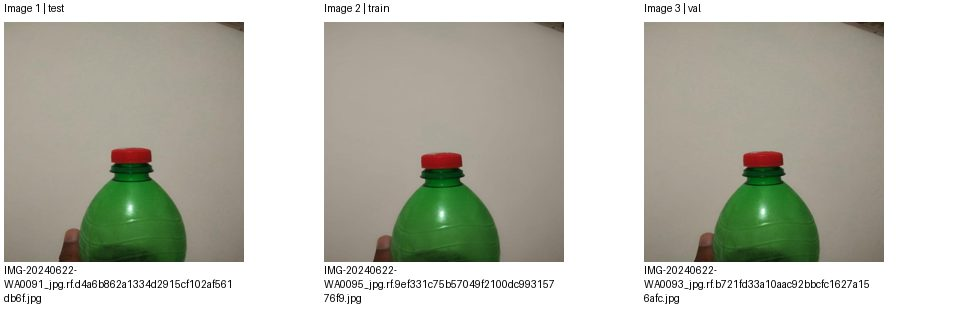

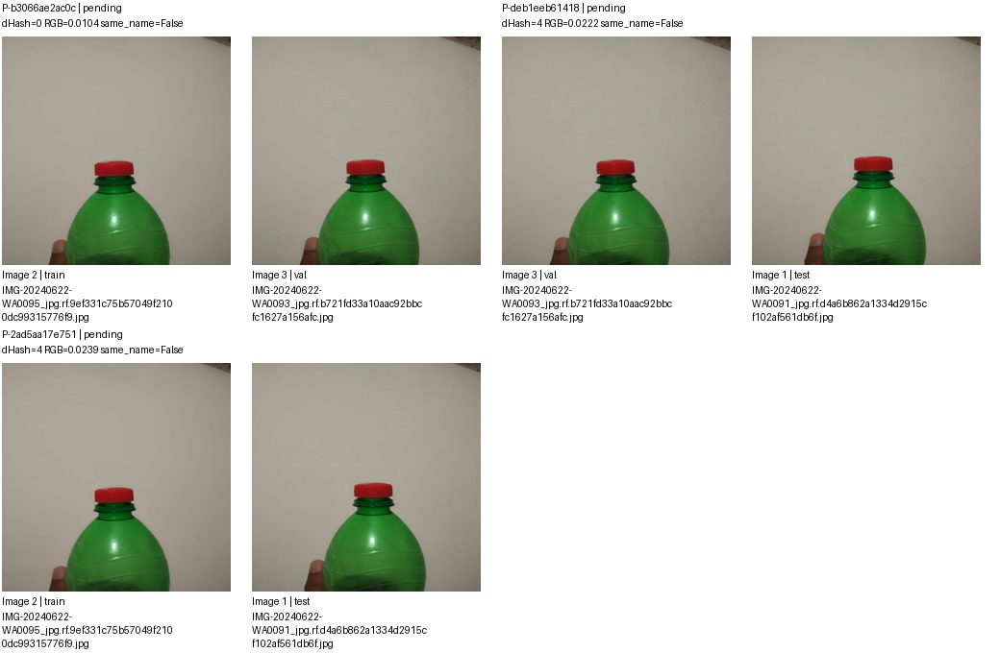

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-b3066ae2ac0c,images/train/IMG-20240622-WA0095_jpg.rf.9ef331c75b57049f2100dc99315776f9.jpg,images/val/IMG-20240622-WA0093_jpg.rf.b721fd33a10aac92bbcfc1627a156afc.jpg,pending,
P-deb1eeb61418,images/val/IMG-20240622-WA0093_jpg.rf.b721fd33a10aac92bbcfc1627a156afc.jpg,images/test/IMG-20240622-WA0091_jpg.rf.d4a6b862a1334d2915cf102af561db6f.jpg,pending,
P-2ad5aa17e751,images/train/IMG-20240622-WA0095_jpg.rf.9ef331c75b57049f2100dc99315776f9.jpg,images/test/IMG-20240622-WA0091_jpg.rf.d4a6b862a1334d2915cf102af561db6f.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 119/166 G-7c16fdd202bb | 4 ảnh, 3 cặp
Split: {'test': 1, 'train': 3}
Quyết định: {'pending': 3}
Ảnh trang 1/1; cặp trang 1/1. Nhóm liên thông không phải kết luận trùng.


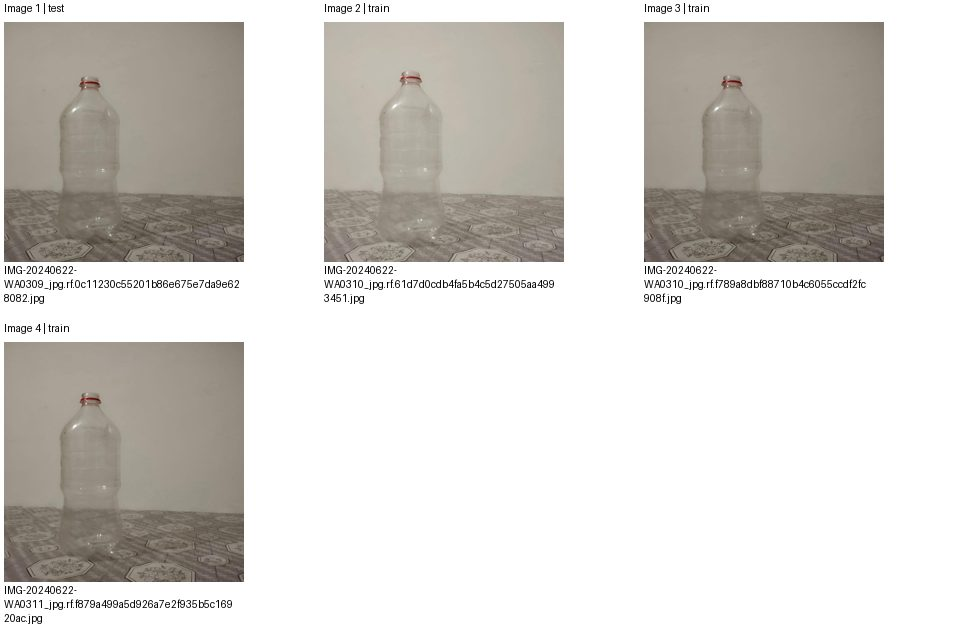

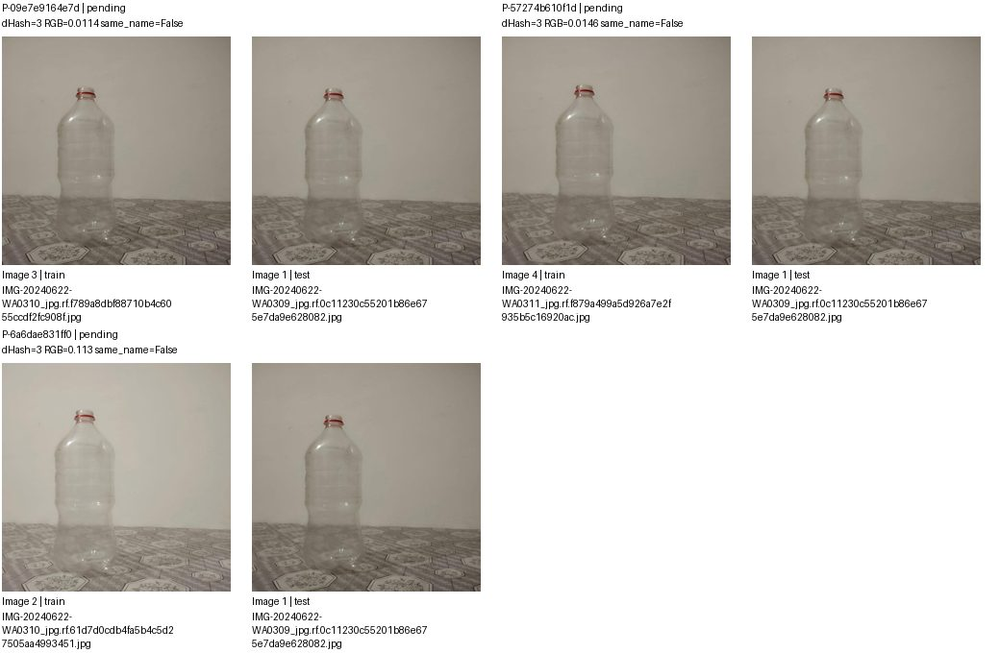

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-09e7e9164e7d,images/train/IMG-20240622-WA0310_jpg.rf.f789a8dbf88710b4c6055ccdf2fc908f.jpg,images/test/IMG-20240622-WA0309_jpg.rf.0c11230c55201b86e675e7da9e628082.jpg,pending,
P-57274b610f1d,images/train/IMG-20240622-WA0311_jpg.rf.f879a499a5d926a7e2f935b5c16920ac.jpg,images/test/IMG-20240622-WA0309_jpg.rf.0c11230c55201b86e675e7da9e628082.jpg,pending,
P-6a6dae831ff0,images/train/IMG-20240622-WA0310_jpg.rf.61d7d0cdb4fa5b4c5d27505aa4993451.jpg,images/test/IMG-20240622-WA0309_jpg.rf.0c11230c55201b86e675e7da9e628082.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 120/166 G-7d0fb7e64f61 | 4 ảnh, 3 cặp
Split: {'train': 3, 'val': 1}
Quyết định: {'pending': 3}
Ảnh trang 1/1; cặp trang 1/1. Nhóm liên thông không phải kết luận trùng.


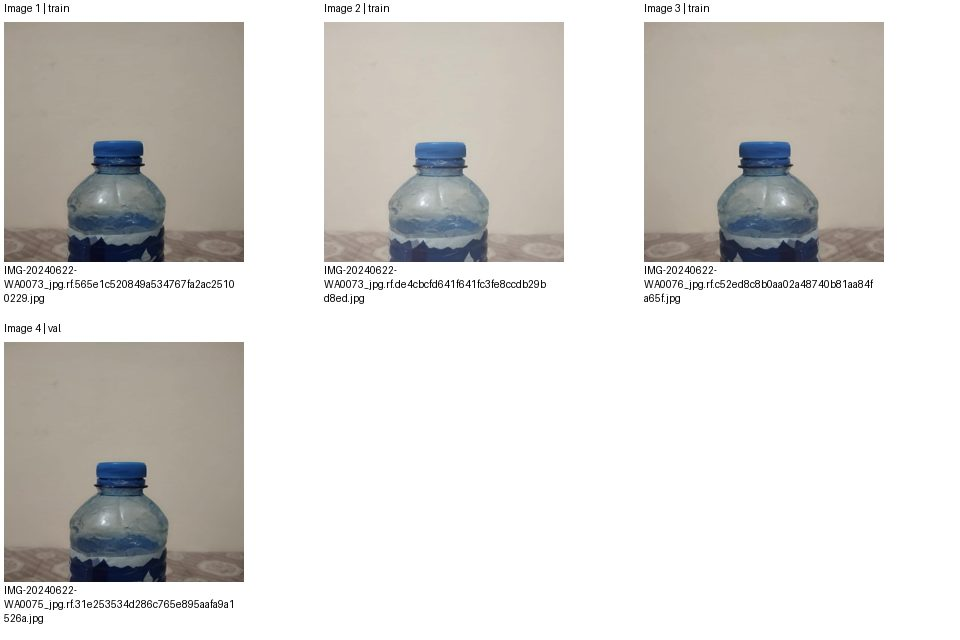

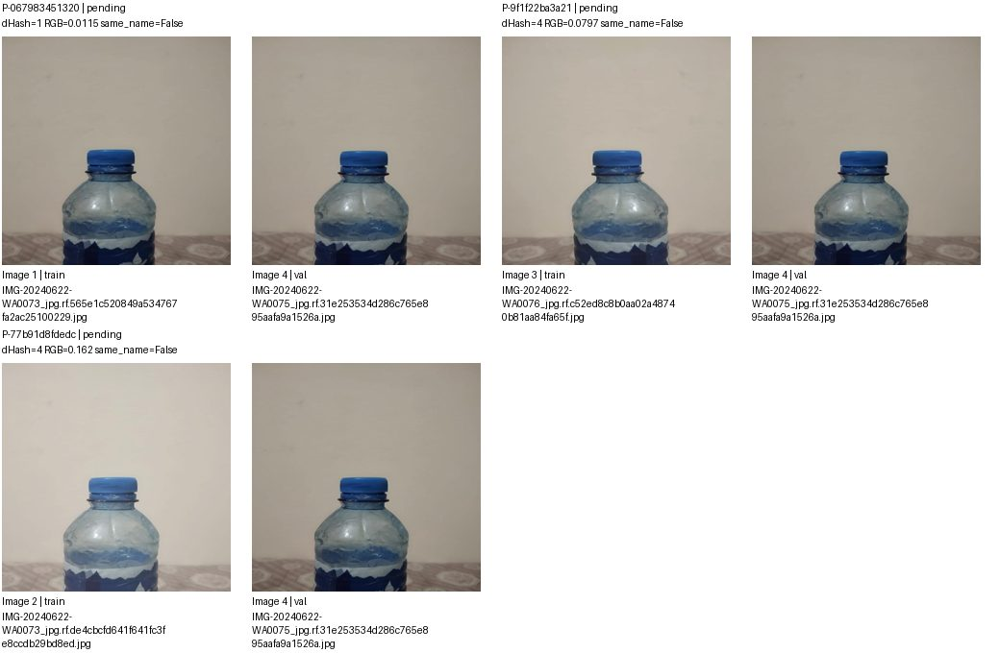

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-067983451320,images/train/IMG-20240622-WA0073_jpg.rf.565e1c520849a534767fa2ac25100229.jpg,images/val/IMG-20240622-WA0075_jpg.rf.31e253534d286c765e895aafa9a1526a.jpg,pending,
P-9f1f22ba3a21,images/train/IMG-20240622-WA0076_jpg.rf.c52ed8c8b0aa02a48740b81aa84fa65f.jpg,images/val/IMG-20240622-WA0075_jpg.rf.31e253534d286c765e895aafa9a1526a.jpg,pending,
P-77b91d8fdedc,images/train/IMG-20240622-WA0073_jpg.rf.de4cbcfd641f641fc3fe8ccdb29bd8ed.jpg,images/val/IMG-20240622-WA0075_jpg.rf.31e253534d286c765e895aafa9a1526a.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 121/166 G-a3a9cc573088 | 3 ảnh, 3 cặp
Split: {'test': 1, 'train': 1, 'val': 1}
Quyết định: {'pending': 3}
Ảnh trang 1/1; cặp trang 1/1. Nhóm liên thông không phải kết luận trùng.


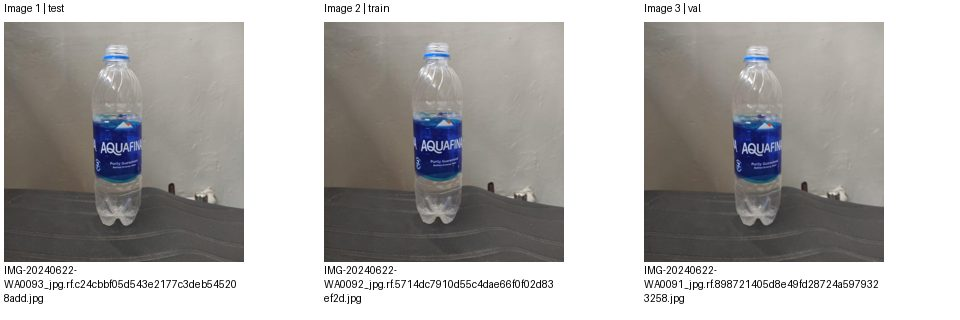

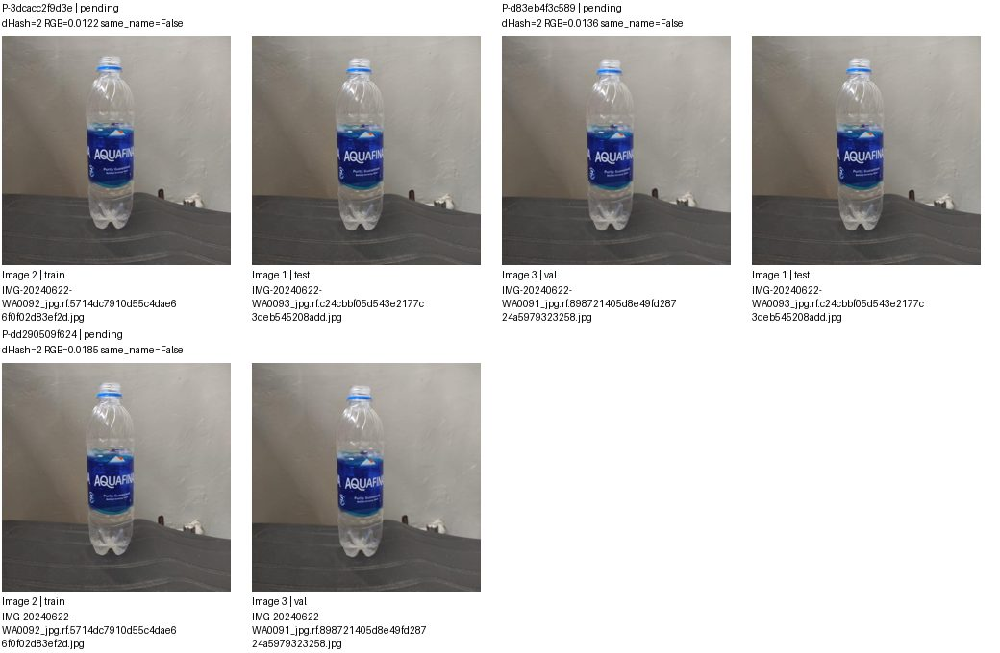

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-3dcacc2f9d3e,images/train/IMG-20240622-WA0092_jpg.rf.5714dc7910d55c4dae66f0f02d83ef2d.jpg,images/test/IMG-20240622-WA0093_jpg.rf.c24cbbf05d543e2177c3deb545208add.jpg,pending,
P-d83eb4f3c589,images/val/IMG-20240622-WA0091_jpg.rf.898721405d8e49fd28724a5979323258.jpg,images/test/IMG-20240622-WA0093_jpg.rf.c24cbbf05d543e2177c3deb545208add.jpg,pending,
P-dd290509f624,images/train/IMG-20240622-WA0092_jpg.rf.5714dc7910d55c4dae66f0f02d83ef2d.jpg,images/val/IMG-20240622-WA0091_jpg.rf.898721405d8e49fd28724a5979323258.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 122/166 G-d0f2d40dbf57 | 11 ảnh, 19 cặp
Split: {'test': 1, 'train': 9, 'val': 1}
Quyết định: {'pending': 19}
Ảnh trang 1/2; cặp trang 1/5. Nhóm liên thông không phải kết luận trùng.


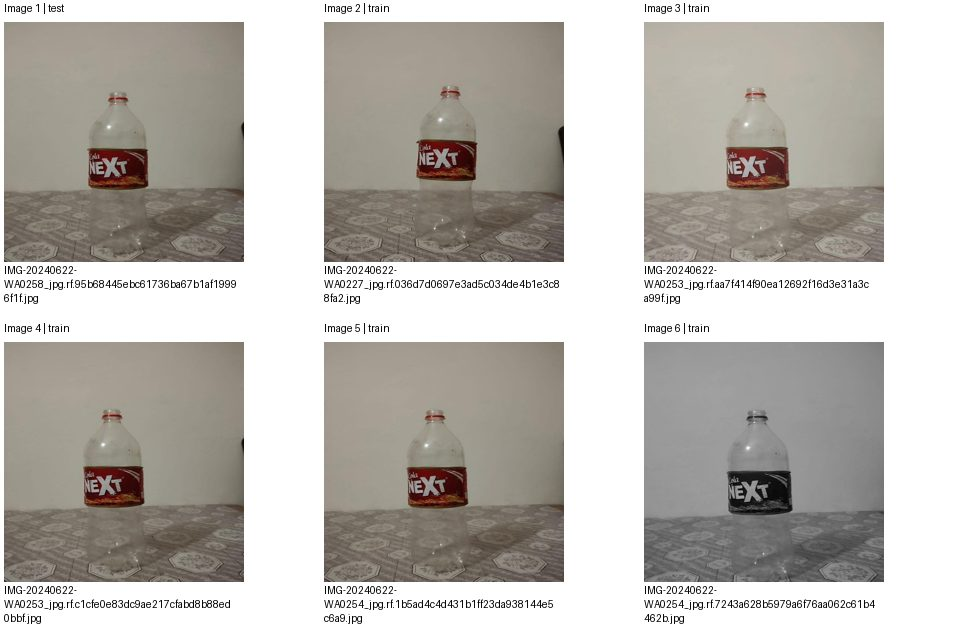

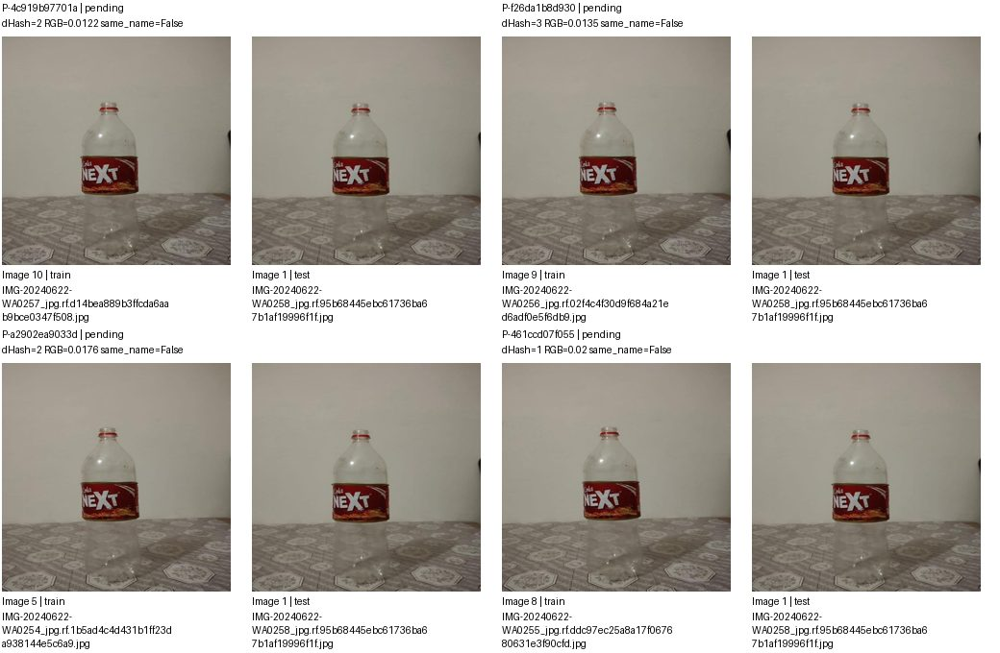

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-4c919b97701a,images/train/IMG-20240622-WA0257_jpg.rf.d14bea889b3ffcda6aab9bce0347f508.jpg,images/test/IMG-20240622-WA0258_jpg.rf.95b68445ebc61736ba67b1af19996f1f.jpg,pending,
P-f26da1b8d930,images/train/IMG-20240622-WA0256_jpg.rf.02f4c4f30d9f684a21ed6adf0e5f6db9.jpg,images/test/IMG-20240622-WA0258_jpg.rf.95b68445ebc61736ba67b1af19996f1f.jpg,pending,
P-a2902ea9033d,images/train/IMG-20240622-WA0254_jpg.rf.1b5ad4c4d431b1ff23da938144e5c6a9.jpg,images/test/IMG-20240622-WA0258_jpg.rf.95b68445ebc61736ba67b1af19996f1f.jpg,pending,
P-461ccd07f055,images/train/IMG-20240622-WA0255_jpg.rf.ddc97ec25a8a17f067680631e3f90cfd.jpg,images/test/IMG-20240622-WA0258_jpg.rf.95b68445ebc61736ba67b1af19996f1f.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 122/166 G-d0f2d40dbf57 | 11 ảnh, 19 cặp
Split: {'test': 1, 'train': 9, 'val': 1}
Quyết định: {'pending': 19}
Ảnh trang 2/2; cặp trang 2/5. Nhóm liên thông không phải kết luận trùng.


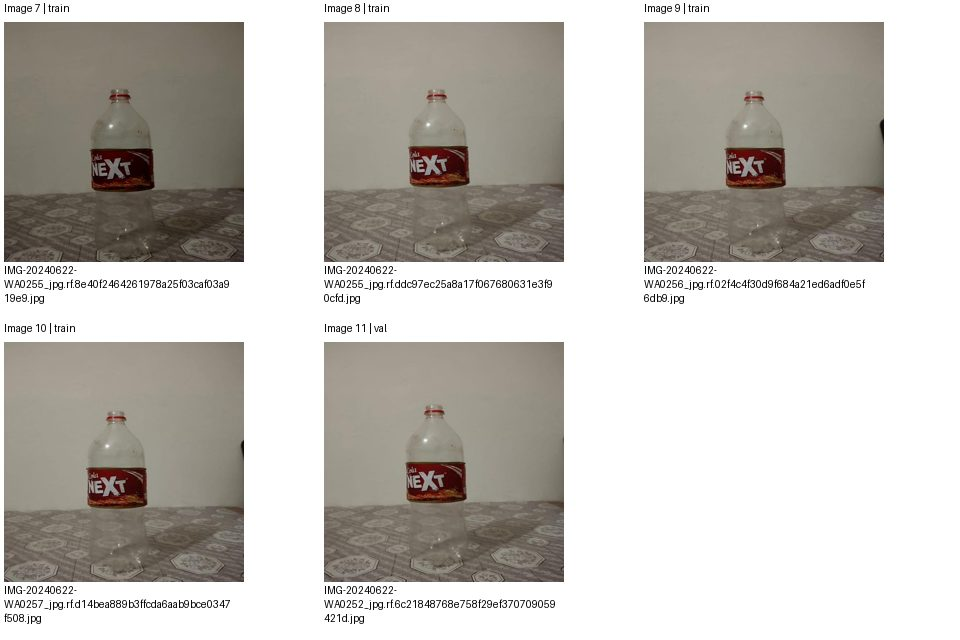

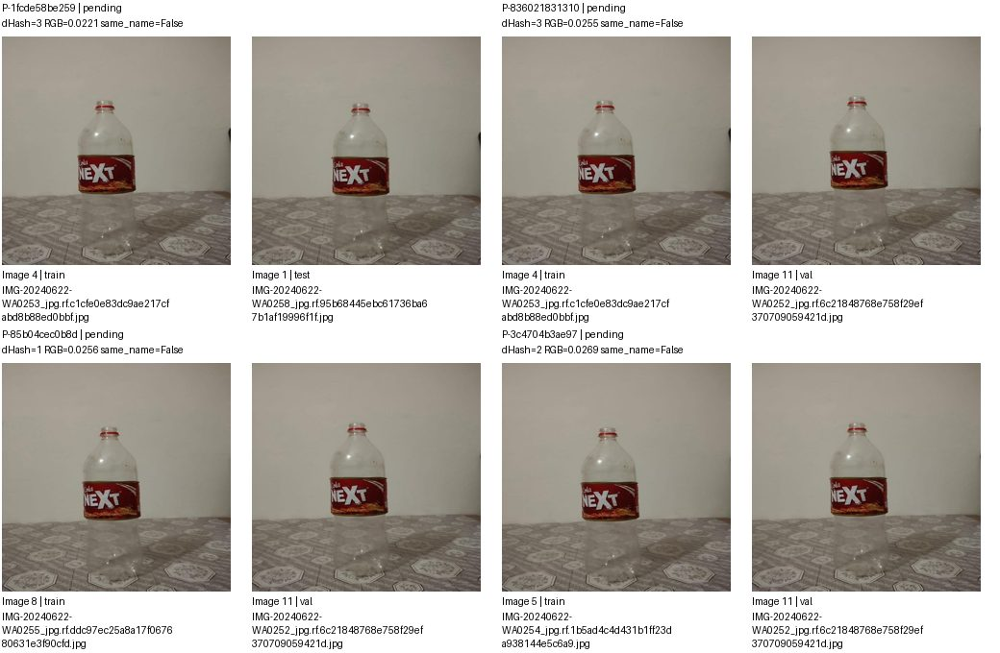

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-1fcde58be259,images/train/IMG-20240622-WA0253_jpg.rf.c1cfe0e83dc9ae217cfabd8b88ed0bbf.jpg,images/test/IMG-20240622-WA0258_jpg.rf.95b68445ebc61736ba67b1af19996f1f.jpg,pending,
P-836021831310,images/train/IMG-20240622-WA0253_jpg.rf.c1cfe0e83dc9ae217cfabd8b88ed0bbf.jpg,images/val/IMG-20240622-WA0252_jpg.rf.6c21848768e758f29ef370709059421d.jpg,pending,
P-85b04cec0b8d,images/train/IMG-20240622-WA0255_jpg.rf.ddc97ec25a8a17f067680631e3f90cfd.jpg,images/val/IMG-20240622-WA0252_jpg.rf.6c21848768e758f29ef370709059421d.jpg,pending,
P-3c4704b3ae97,images/train/IMG-20240622-WA0254_jpg.rf.1b5ad4c4d431b1ff23da938144e5c6a9.jpg,images/val/IMG-20240622-WA0252_jpg.rf.6c21848768e758f29ef370709059421d.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 122/166 G-d0f2d40dbf57 | 11 ảnh, 19 cặp
Split: {'test': 1, 'train': 9, 'val': 1}
Quyết định: {'pending': 19}
Ảnh trang None/2; cặp trang 3/5. Nhóm liên thông không phải kết luận trùng.


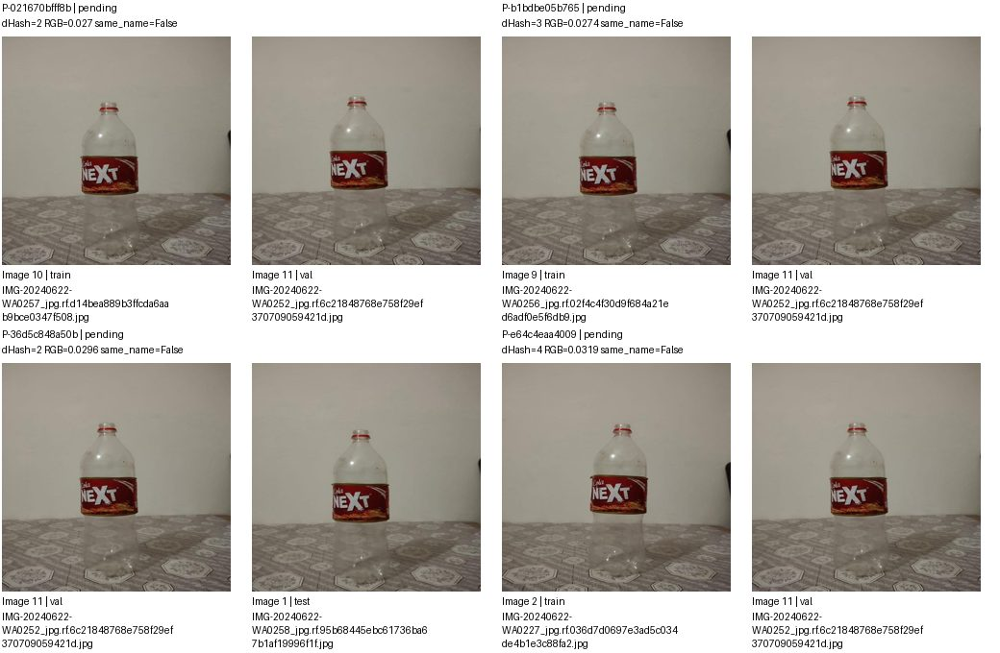

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-021670bfff8b,images/train/IMG-20240622-WA0257_jpg.rf.d14bea889b3ffcda6aab9bce0347f508.jpg,images/val/IMG-20240622-WA0252_jpg.rf.6c21848768e758f29ef370709059421d.jpg,pending,
P-b1bdbe05b765,images/train/IMG-20240622-WA0256_jpg.rf.02f4c4f30d9f684a21ed6adf0e5f6db9.jpg,images/val/IMG-20240622-WA0252_jpg.rf.6c21848768e758f29ef370709059421d.jpg,pending,
P-36d5c848a50b,images/val/IMG-20240622-WA0252_jpg.rf.6c21848768e758f29ef370709059421d.jpg,images/test/IMG-20240622-WA0258_jpg.rf.95b68445ebc61736ba67b1af19996f1f.jpg,pending,
P-e64c4eaa4009,images/train/IMG-20240622-WA0227_jpg.rf.036d7d0697e3ad5c034de4b1e3c88fa2.jpg,images/val/IMG-20240622-WA0252_jpg.rf.6c21848768e758f29ef370709059421d.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 122/166 G-d0f2d40dbf57 | 11 ảnh, 19 cặp
Split: {'test': 1, 'train': 9, 'val': 1}
Quyết định: {'pending': 19}
Ảnh trang None/2; cặp trang 4/5. Nhóm liên thông không phải kết luận trùng.


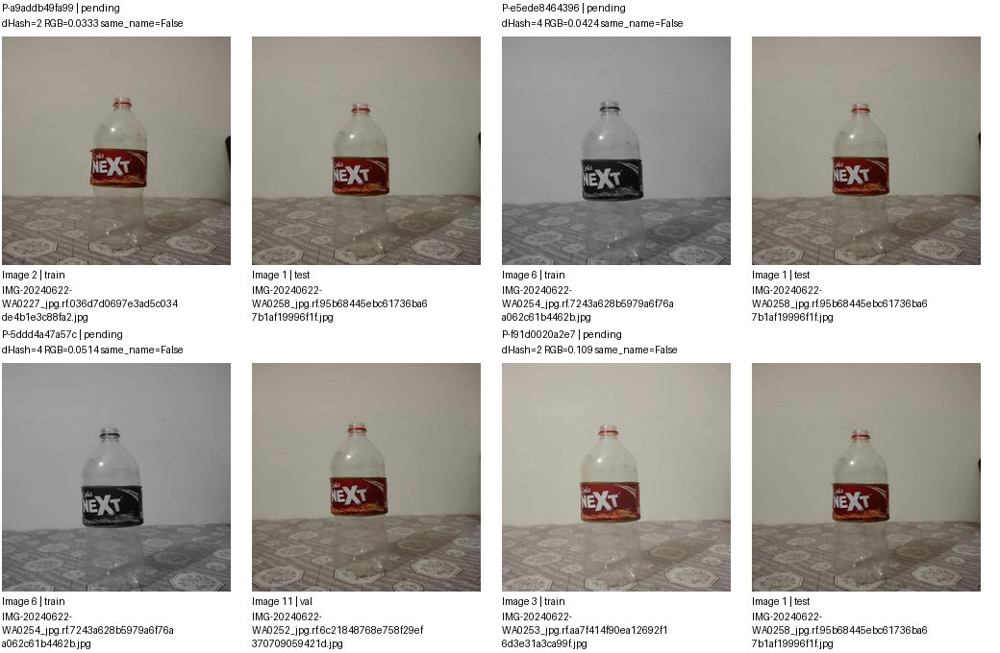

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-a9addb49fa99,images/train/IMG-20240622-WA0227_jpg.rf.036d7d0697e3ad5c034de4b1e3c88fa2.jpg,images/test/IMG-20240622-WA0258_jpg.rf.95b68445ebc61736ba67b1af19996f1f.jpg,pending,
P-e5ede8464396,images/train/IMG-20240622-WA0254_jpg.rf.7243a628b5979a6f76aa062c61b4462b.jpg,images/test/IMG-20240622-WA0258_jpg.rf.95b68445ebc61736ba67b1af19996f1f.jpg,pending,
P-5ddd4a47a57c,images/train/IMG-20240622-WA0254_jpg.rf.7243a628b5979a6f76aa062c61b4462b.jpg,images/val/IMG-20240622-WA0252_jpg.rf.6c21848768e758f29ef370709059421d.jpg,pending,
P-f91d0020a2e7,images/train/IMG-20240622-WA0253_jpg.rf.aa7f414f90ea12692f16d3e31a3ca99f.jpg,images/test/IMG-20240622-WA0258_jpg.rf.95b68445ebc61736ba67b1af19996f1f.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 122/166 G-d0f2d40dbf57 | 11 ảnh, 19 cặp
Split: {'test': 1, 'train': 9, 'val': 1}
Quyết định: {'pending': 19}
Ảnh trang None/2; cặp trang 5/5. Nhóm liên thông không phải kết luận trùng.


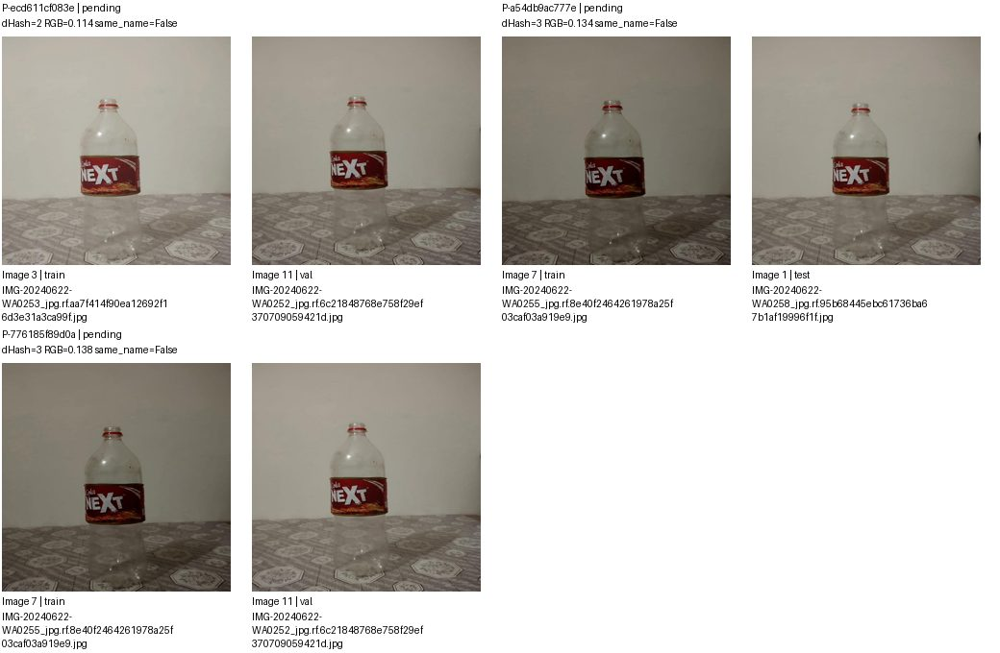

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-ecd611cf083e,images/train/IMG-20240622-WA0253_jpg.rf.aa7f414f90ea12692f16d3e31a3ca99f.jpg,images/val/IMG-20240622-WA0252_jpg.rf.6c21848768e758f29ef370709059421d.jpg,pending,
P-a54db9ac777e,images/train/IMG-20240622-WA0255_jpg.rf.8e40f2464261978a25f03caf03a919e9.jpg,images/test/IMG-20240622-WA0258_jpg.rf.95b68445ebc61736ba67b1af19996f1f.jpg,pending,
P-776185f89d0a,images/train/IMG-20240622-WA0255_jpg.rf.8e40f2464261978a25f03caf03a919e9.jpg,images/val/IMG-20240622-WA0252_jpg.rf.6c21848768e758f29ef370709059421d.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 123/166 G-554d972c7656 | 6 ảnh, 5 cặp
Split: {'train': 5, 'val': 1}
Quyết định: {'pending': 5}
Ảnh trang 1/1; cặp trang 1/2. Nhóm liên thông không phải kết luận trùng.


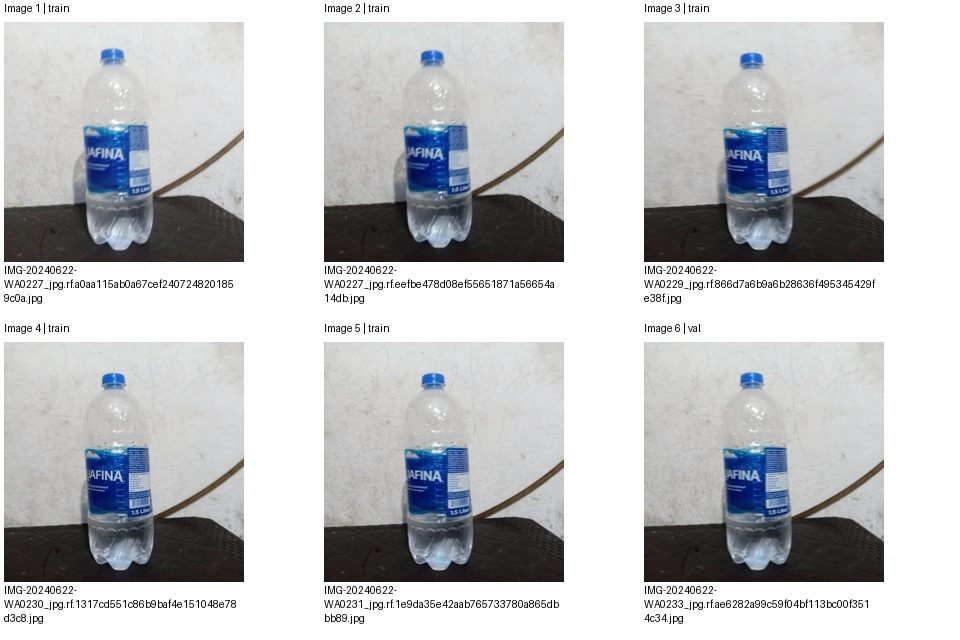

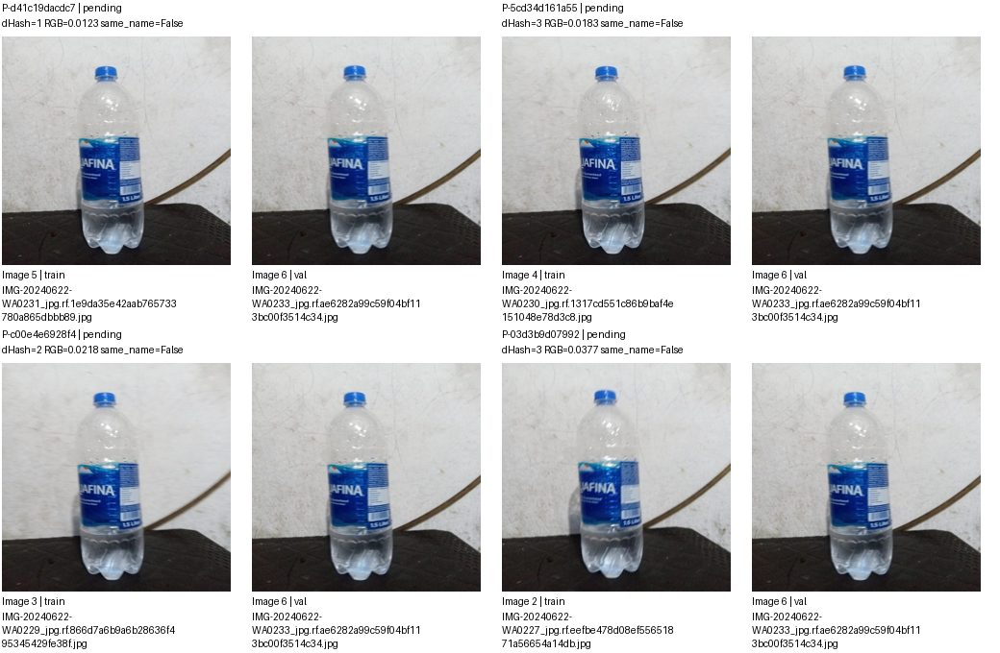

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-d41c19dacdc7,images/train/IMG-20240622-WA0231_jpg.rf.1e9da35e42aab765733780a865dbbb89.jpg,images/val/IMG-20240622-WA0233_jpg.rf.ae6282a99c59f04bf113bc00f3514c34.jpg,pending,
P-5cd34d161a55,images/train/IMG-20240622-WA0230_jpg.rf.1317cd551c86b9baf4e151048e78d3c8.jpg,images/val/IMG-20240622-WA0233_jpg.rf.ae6282a99c59f04bf113bc00f3514c34.jpg,pending,
P-c00e4e6928f4,images/train/IMG-20240622-WA0229_jpg.rf.866d7a6b9a6b28636f495345429fe38f.jpg,images/val/IMG-20240622-WA0233_jpg.rf.ae6282a99c59f04bf113bc00f3514c34.jpg,pending,
P-03d3b9d07992,images/train/IMG-20240622-WA0227_jpg.rf.eefbe478d08ef55651871a56654a14db.jpg,images/val/IMG-20240622-WA0233_jpg.rf.ae6282a99c59f04bf113bc00f3514c34.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 123/166 G-554d972c7656 | 6 ảnh, 5 cặp
Split: {'train': 5, 'val': 1}
Quyết định: {'pending': 5}
Ảnh trang None/1; cặp trang 2/2. Nhóm liên thông không phải kết luận trùng.


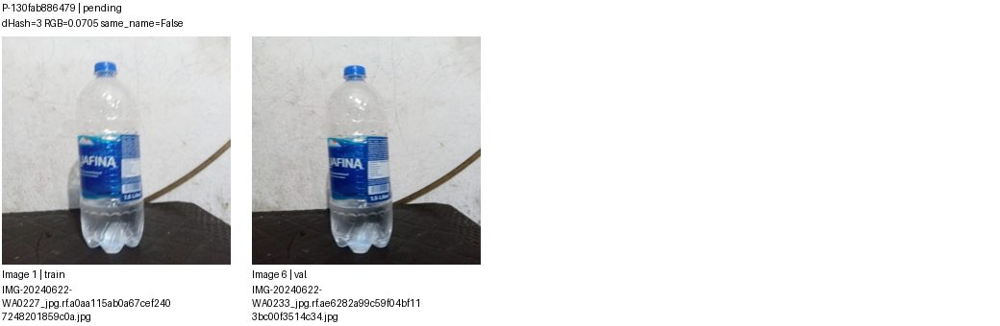

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-130fab886479,images/train/IMG-20240622-WA0227_jpg.rf.a0aa115ab0a67cef2407248201859c0a.jpg,images/val/IMG-20240622-WA0233_jpg.rf.ae6282a99c59f04bf113bc00f3514c34.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 124/166 G-b7764c24cf44 | 3 ảnh, 2 cặp
Split: {'train': 1, 'val': 2}
Quyết định: {'pending': 2}
Ảnh trang 1/1; cặp trang 1/1. Nhóm liên thông không phải kết luận trùng.


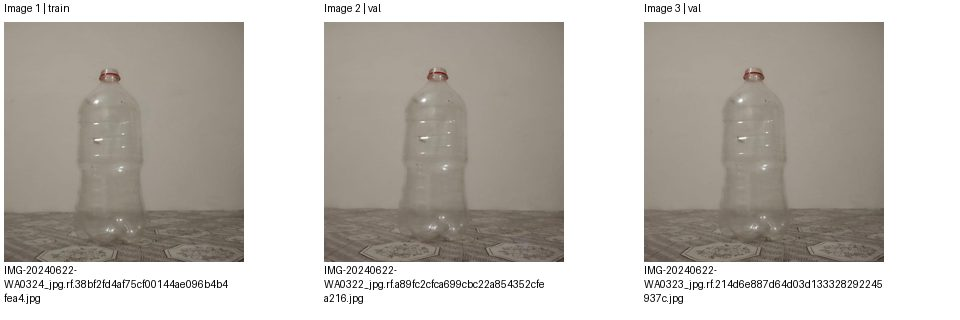

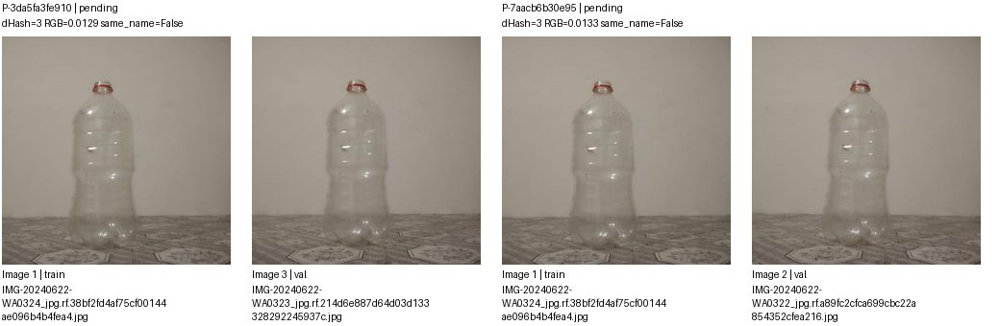

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-3da5fa3fe910,images/train/IMG-20240622-WA0324_jpg.rf.38bf2fd4af75cf00144ae096b4b4fea4.jpg,images/val/IMG-20240622-WA0323_jpg.rf.214d6e887d64d03d133328292245937c.jpg,pending,
P-7aacb6b30e95,images/train/IMG-20240622-WA0324_jpg.rf.38bf2fd4af75cf00144ae096b4b4fea4.jpg,images/val/IMG-20240622-WA0322_jpg.rf.a89fc2cfca699cbc22a854352cfea216.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 125/166 G-360a62d5595f | 4 ảnh, 3 cặp
Split: {'train': 3, 'val': 1}
Quyết định: {'pending': 3}
Ảnh trang 1/1; cặp trang 1/1. Nhóm liên thông không phải kết luận trùng.


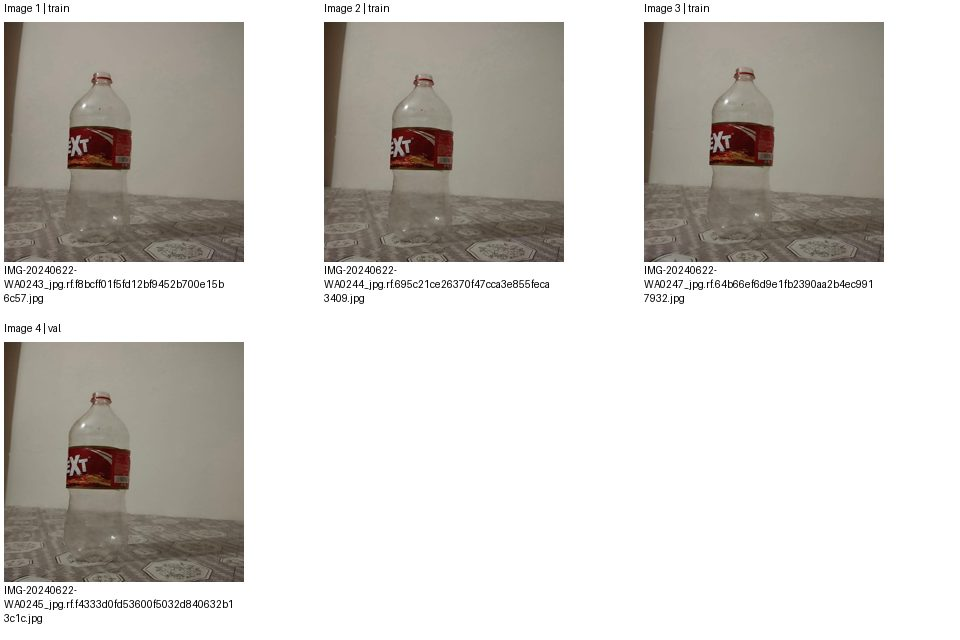

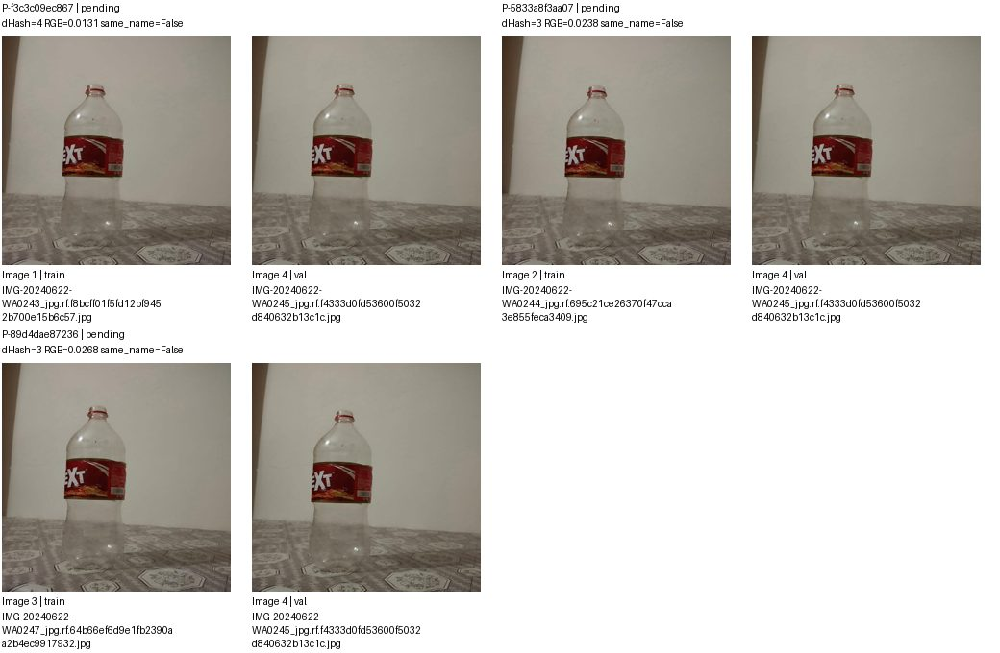

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-f3c3c09ec867,images/train/IMG-20240622-WA0243_jpg.rf.f8bcff01f5fd12bf9452b700e15b6c57.jpg,images/val/IMG-20240622-WA0245_jpg.rf.f4333d0fd53600f5032d840632b13c1c.jpg,pending,
P-5833a8f3aa07,images/train/IMG-20240622-WA0244_jpg.rf.695c21ce26370f47cca3e855feca3409.jpg,images/val/IMG-20240622-WA0245_jpg.rf.f4333d0fd53600f5032d840632b13c1c.jpg,pending,
P-89d4dae87236,images/train/IMG-20240622-WA0247_jpg.rf.64b66ef6d9e1fb2390aa2b4ec9917932.jpg,images/val/IMG-20240622-WA0245_jpg.rf.f4333d0fd53600f5032d840632b13c1c.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 126/166 G-42463d1dfc9b | 2 ảnh, 1 cặp
Split: {'train': 1, 'val': 1}
Quyết định: {'pending': 1}
Ảnh trang 1/1; cặp trang 1/1. Nhóm liên thông không phải kết luận trùng.


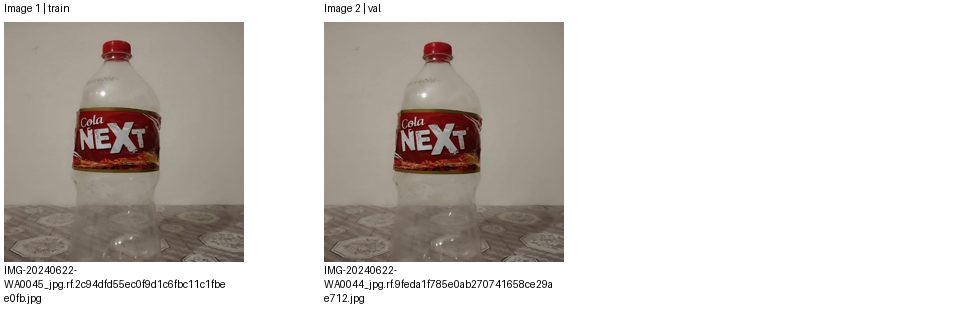

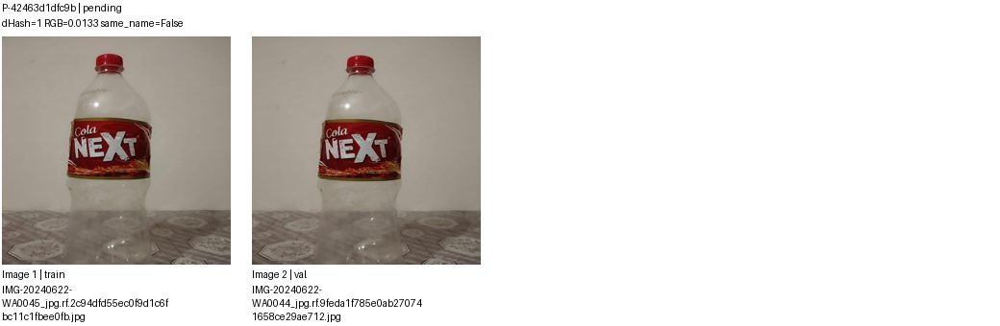

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-42463d1dfc9b,images/train/IMG-20240622-WA0045_jpg.rf.2c94dfd55ec0f9d1c6fbc11c1fbee0fb.jpg,images/val/IMG-20240622-WA0044_jpg.rf.9feda1f785e0ab270741658ce29ae712.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 127/166 G-2418618fc5c7 | 3 ảnh, 2 cặp
Split: {'test': 1, 'train': 2}
Quyết định: {'pending': 2}
Ảnh trang 1/1; cặp trang 1/1. Nhóm liên thông không phải kết luận trùng.


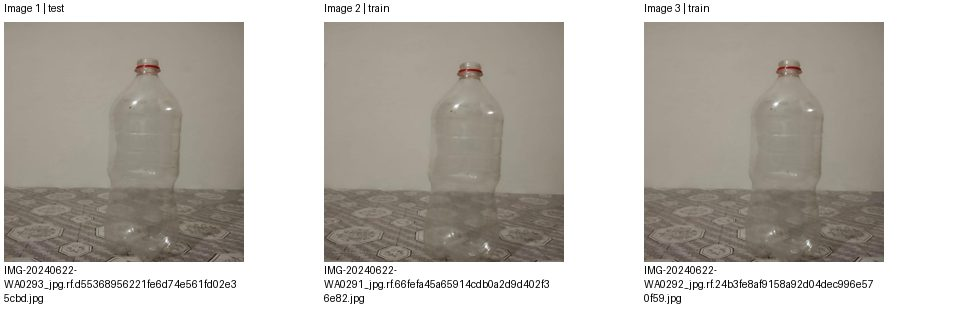

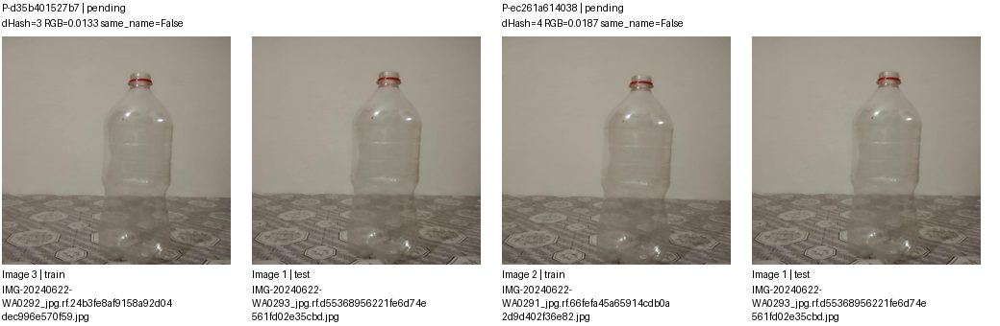

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-d35b401527b7,images/train/IMG-20240622-WA0292_jpg.rf.24b3fe8af9158a92d04dec996e570f59.jpg,images/test/IMG-20240622-WA0293_jpg.rf.d55368956221fe6d74e561fd02e35cbd.jpg,pending,
P-ec261a614038,images/train/IMG-20240622-WA0291_jpg.rf.66fefa45a65914cdb0a2d9d402f36e82.jpg,images/test/IMG-20240622-WA0293_jpg.rf.d55368956221fe6d74e561fd02e35cbd.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 128/166 G-84cf2f1fdaf0 | 6 ảnh, 6 cặp
Split: {'test': 1, 'train': 4, 'val': 1}
Quyết định: {'pending': 6}
Ảnh trang 1/1; cặp trang 1/2. Nhóm liên thông không phải kết luận trùng.


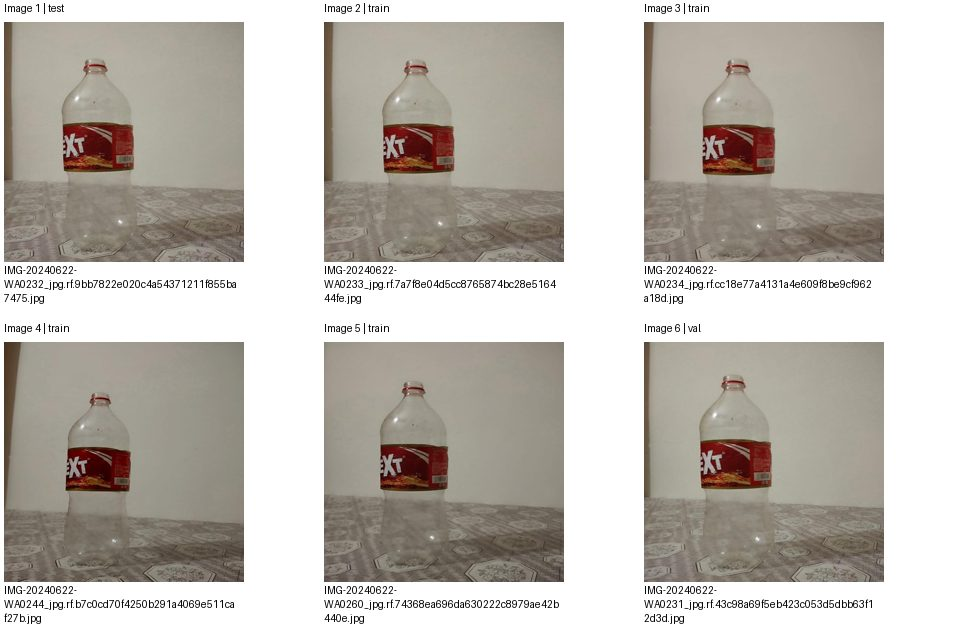

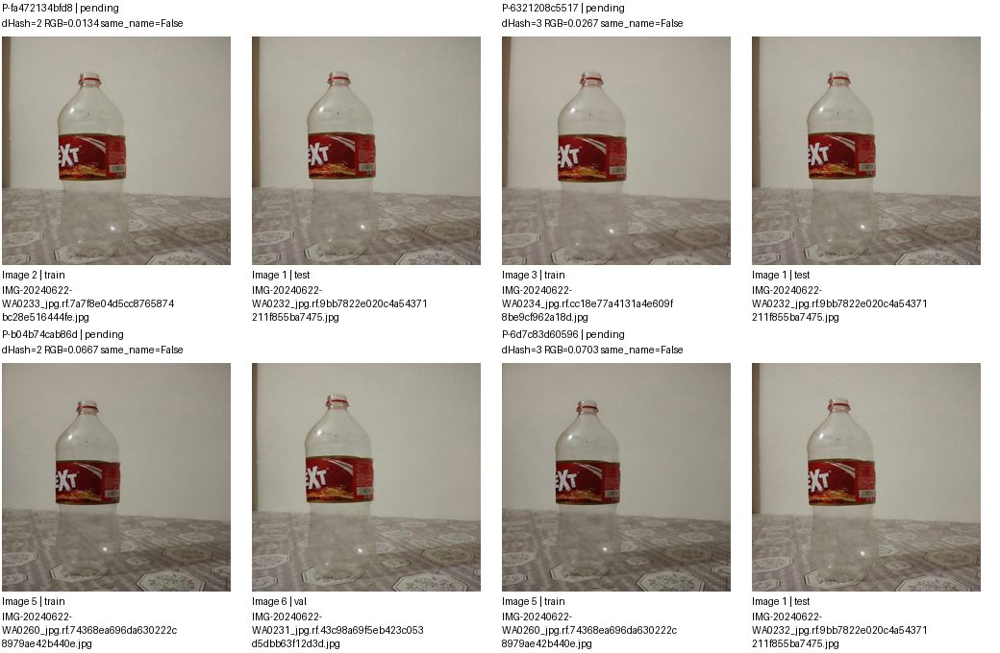

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-fa472134bfd8,images/train/IMG-20240622-WA0233_jpg.rf.7a7f8e04d5cc8765874bc28e516444fe.jpg,images/test/IMG-20240622-WA0232_jpg.rf.9bb7822e020c4a54371211f855ba7475.jpg,pending,
P-6321208c5517,images/train/IMG-20240622-WA0234_jpg.rf.cc18e77a4131a4e609f8be9cf962a18d.jpg,images/test/IMG-20240622-WA0232_jpg.rf.9bb7822e020c4a54371211f855ba7475.jpg,pending,
P-b04b74cab86d,images/train/IMG-20240622-WA0260_jpg.rf.74368ea696da630222c8979ae42b440e.jpg,images/val/IMG-20240622-WA0231_jpg.rf.43c98a69f5eb423c053d5dbb63f12d3d.jpg,pending,
P-6d7c83d60596,images/train/IMG-20240622-WA0260_jpg.rf.74368ea696da630222c8979ae42b440e.jpg,images/test/IMG-20240622-WA0232_jpg.rf.9bb7822e020c4a54371211f855ba7475.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 128/166 G-84cf2f1fdaf0 | 6 ảnh, 6 cặp
Split: {'test': 1, 'train': 4, 'val': 1}
Quyết định: {'pending': 6}
Ảnh trang None/1; cặp trang 2/2. Nhóm liên thông không phải kết luận trùng.


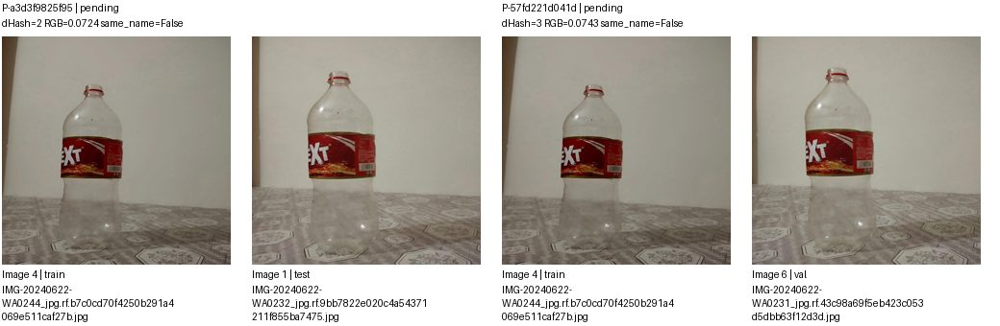

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-a3d3f9825f95,images/train/IMG-20240622-WA0244_jpg.rf.b7c0cd70f4250b291a4069e511caf27b.jpg,images/test/IMG-20240622-WA0232_jpg.rf.9bb7822e020c4a54371211f855ba7475.jpg,pending,
P-57fd221d041d,images/train/IMG-20240622-WA0244_jpg.rf.b7c0cd70f4250b291a4069e511caf27b.jpg,images/val/IMG-20240622-WA0231_jpg.rf.43c98a69f5eb423c053d5dbb63f12d3d.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 129/166 G-0f36cadfb5ef | 2 ảnh, 1 cặp
Split: {'test': 1, 'val': 1}
Quyết định: {'pending': 1}
Ảnh trang 1/1; cặp trang 1/1. Nhóm liên thông không phải kết luận trùng.


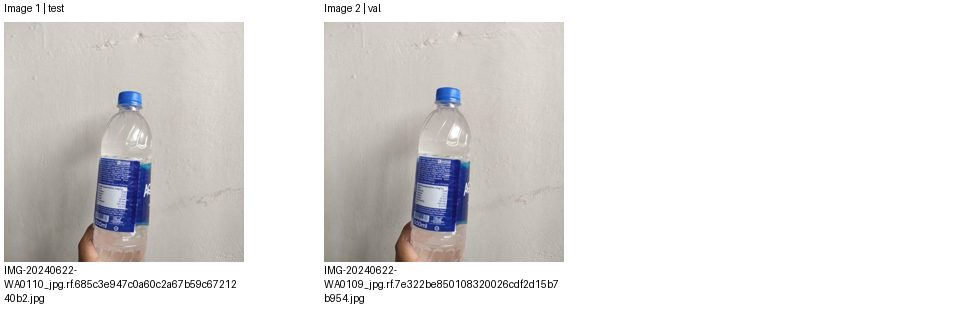

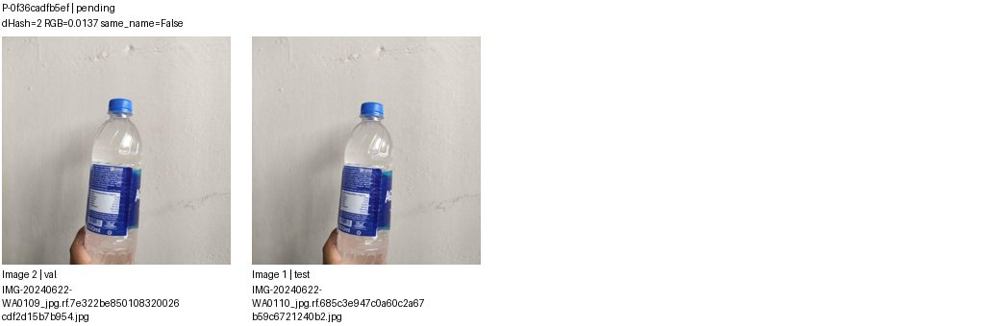

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-0f36cadfb5ef,images/val/IMG-20240622-WA0109_jpg.rf.7e322be850108320026cdf2d15b7b954.jpg,images/test/IMG-20240622-WA0110_jpg.rf.685c3e947c0a60c2a67b59c6721240b2.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 130/166 G-624f3edd3005 | 3 ảnh, 2 cặp
Split: {'train': 2, 'val': 1}
Quyết định: {'pending': 2}
Ảnh trang 1/1; cặp trang 1/1. Nhóm liên thông không phải kết luận trùng.


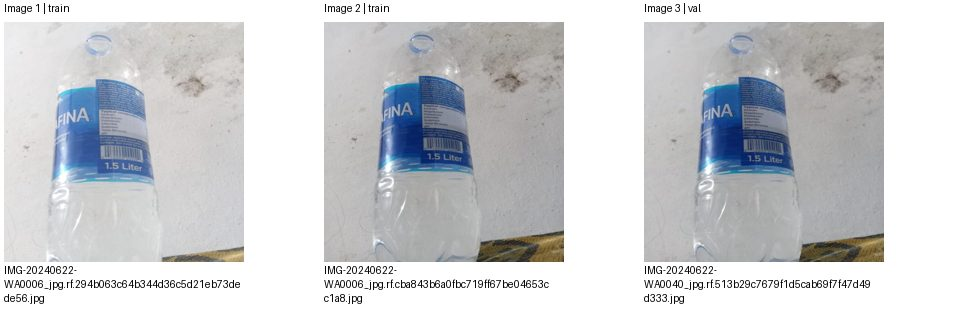

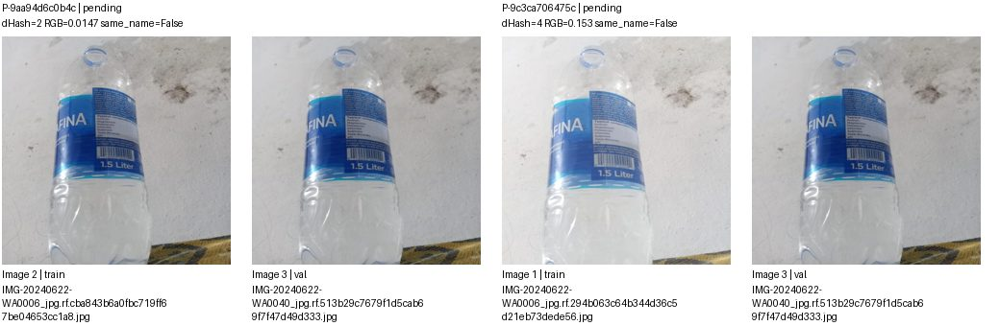

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-9aa94d6c0b4c,images/train/IMG-20240622-WA0006_jpg.rf.cba843b6a0fbc719ff67be04653cc1a8.jpg,images/val/IMG-20240622-WA0040_jpg.rf.513b29c7679f1d5cab69f7f47d49d333.jpg,pending,
P-9c3ca706475c,images/train/IMG-20240622-WA0006_jpg.rf.294b063c64b344d36c5d21eb73dede56.jpg,images/val/IMG-20240622-WA0040_jpg.rf.513b29c7679f1d5cab69f7f47d49d333.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 131/166 G-7be83c4007e1 | 3 ảnh, 3 cặp
Split: {'test': 1, 'train': 1, 'val': 1}
Quyết định: {'pending': 3}
Ảnh trang 1/1; cặp trang 1/1. Nhóm liên thông không phải kết luận trùng.


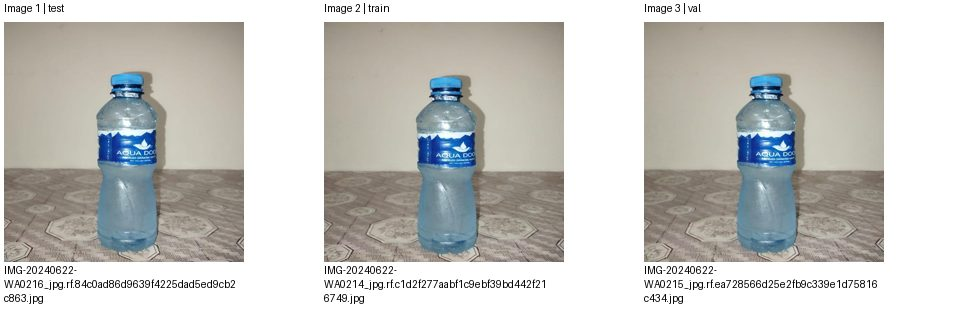

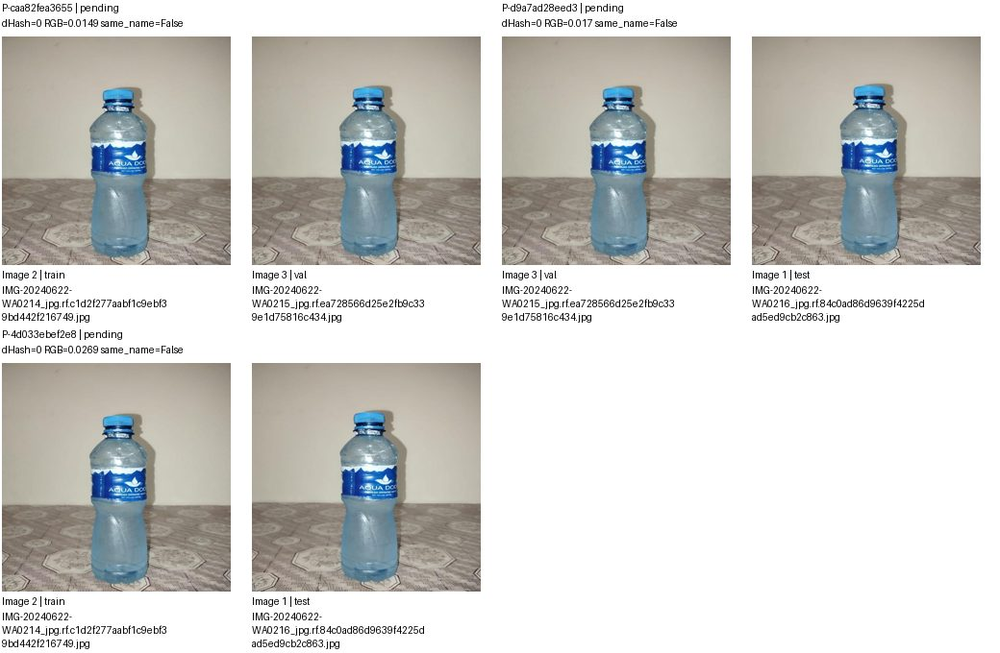

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-caa82fea3655,images/train/IMG-20240622-WA0214_jpg.rf.c1d2f277aabf1c9ebf39bd442f216749.jpg,images/val/IMG-20240622-WA0215_jpg.rf.ea728566d25e2fb9c339e1d75816c434.jpg,pending,
P-d9a7ad28eed3,images/val/IMG-20240622-WA0215_jpg.rf.ea728566d25e2fb9c339e1d75816c434.jpg,images/test/IMG-20240622-WA0216_jpg.rf.84c0ad86d9639f4225dad5ed9cb2c863.jpg,pending,
P-4d033ebef2e8,images/train/IMG-20240622-WA0214_jpg.rf.c1d2f277aabf1c9ebf39bd442f216749.jpg,images/test/IMG-20240622-WA0216_jpg.rf.84c0ad86d9639f4225dad5ed9cb2c863.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 132/166 G-17846324753b | 8 ảnh, 7 cặp
Split: {'test': 1, 'train': 5, 'val': 2}
Quyết định: {'pending': 7}
Ảnh trang 1/2; cặp trang 1/2. Nhóm liên thông không phải kết luận trùng.


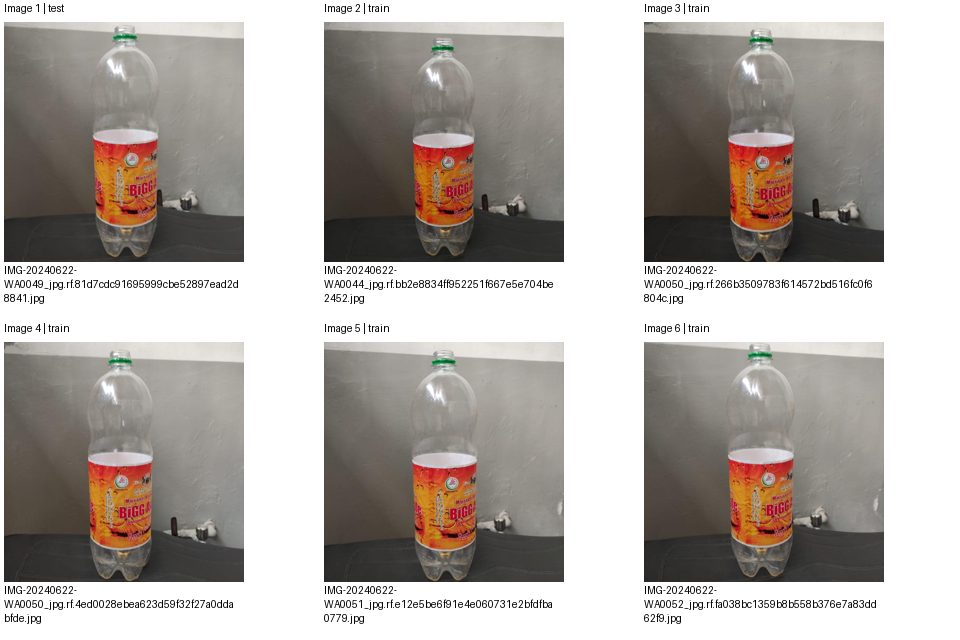

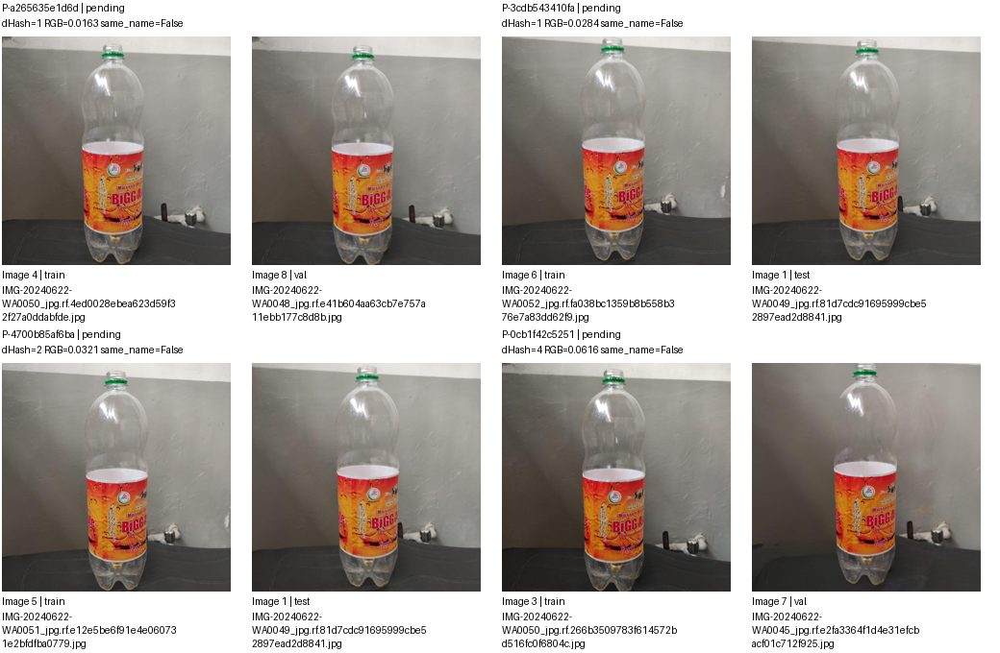

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-a265635e1d6d,images/train/IMG-20240622-WA0050_jpg.rf.4ed0028ebea623d59f32f27a0ddabfde.jpg,images/val/IMG-20240622-WA0048_jpg.rf.e41b604aa63cb7e757a11ebb177c8d8b.jpg,pending,
P-3cdb543410fa,images/train/IMG-20240622-WA0052_jpg.rf.fa038bc1359b8b558b376e7a83dd62f9.jpg,images/test/IMG-20240622-WA0049_jpg.rf.81d7cdc91695999cbe52897ead2d8841.jpg,pending,
P-4700b85af6ba,images/train/IMG-20240622-WA0051_jpg.rf.e12e5be6f91e4e060731e2bfdfba0779.jpg,images/test/IMG-20240622-WA0049_jpg.rf.81d7cdc91695999cbe52897ead2d8841.jpg,pending,
P-0cb1f42c5251,images/train/IMG-20240622-WA0050_jpg.rf.266b3509783f614572bd516fc0f6804c.jpg,images/val/IMG-20240622-WA0045_jpg.rf.e2fa3364f1d4e31efcbacf01c712f925.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 132/166 G-17846324753b | 8 ảnh, 7 cặp
Split: {'test': 1, 'train': 5, 'val': 2}
Quyết định: {'pending': 7}
Ảnh trang 2/2; cặp trang 2/2. Nhóm liên thông không phải kết luận trùng.


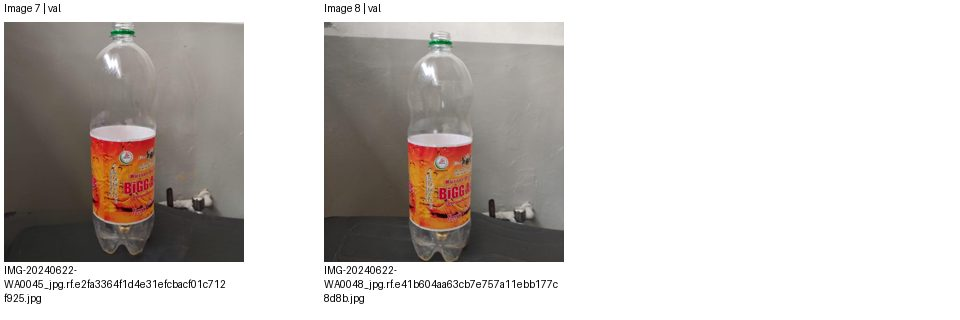

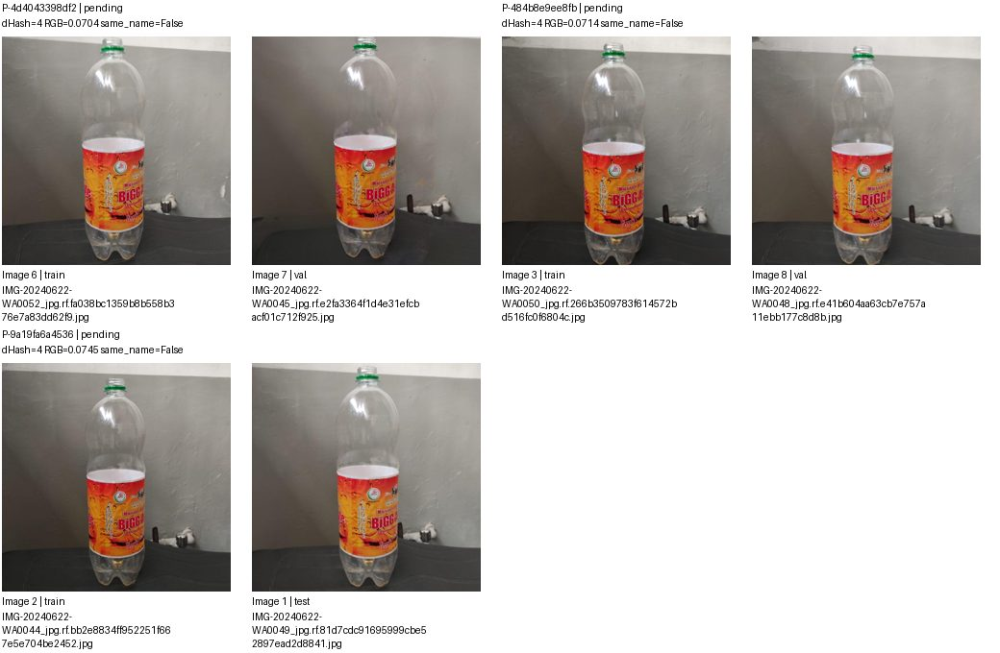

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-4d4043398df2,images/train/IMG-20240622-WA0052_jpg.rf.fa038bc1359b8b558b376e7a83dd62f9.jpg,images/val/IMG-20240622-WA0045_jpg.rf.e2fa3364f1d4e31efcbacf01c712f925.jpg,pending,
P-484b8e9ee8fb,images/train/IMG-20240622-WA0050_jpg.rf.266b3509783f614572bd516fc0f6804c.jpg,images/val/IMG-20240622-WA0048_jpg.rf.e41b604aa63cb7e757a11ebb177c8d8b.jpg,pending,
P-9a19fa6a4536,images/train/IMG-20240622-WA0044_jpg.rf.bb2e8834ff952251f667e5e704be2452.jpg,images/test/IMG-20240622-WA0049_jpg.rf.81d7cdc91695999cbe52897ead2d8841.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 133/166 G-a52975d73a93 | 2 ảnh, 1 cặp
Split: {'test': 1, 'train': 1}
Quyết định: {'pending': 1}
Ảnh trang 1/1; cặp trang 1/1. Nhóm liên thông không phải kết luận trùng.


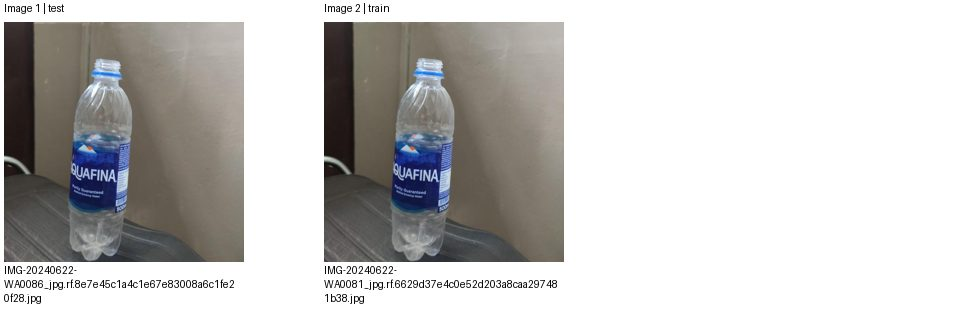

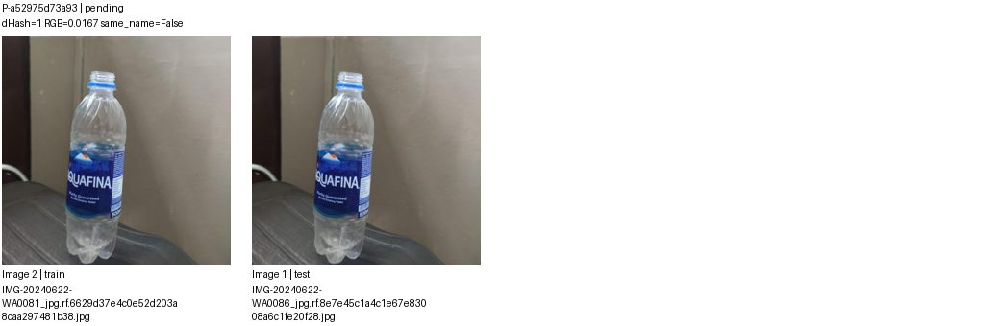

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-a52975d73a93,images/train/IMG-20240622-WA0081_jpg.rf.6629d37e4c0e52d203a8caa297481b38.jpg,images/test/IMG-20240622-WA0086_jpg.rf.8e7e45c1a4c1e67e83008a6c1fe20f28.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 134/166 G-d9a50cabd37a | 10 ảnh, 13 cặp
Split: {'test': 1, 'train': 8, 'val': 1}
Quyết định: {'pending': 13}
Ảnh trang 1/2; cặp trang 1/4. Nhóm liên thông không phải kết luận trùng.


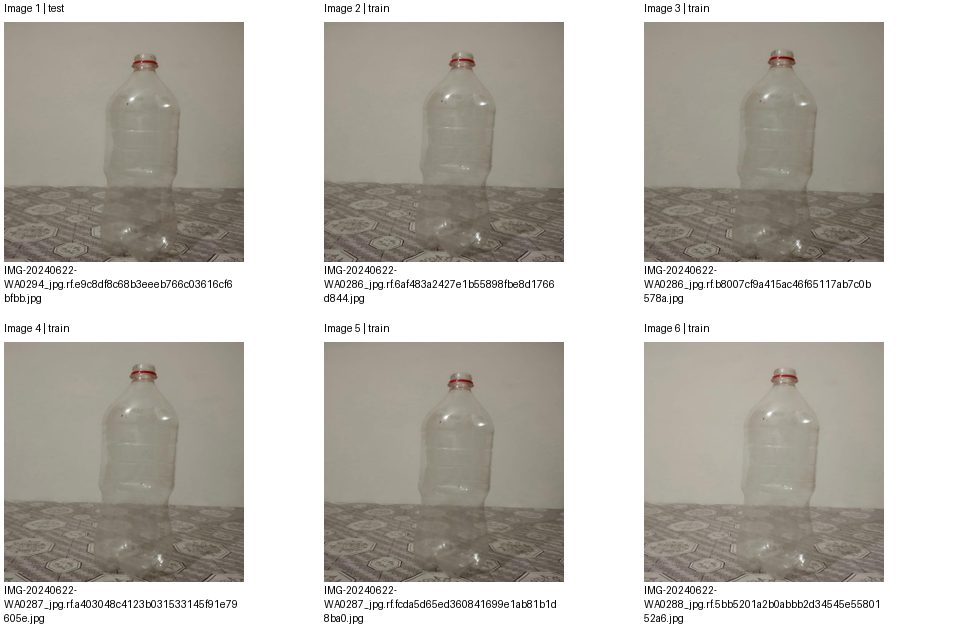

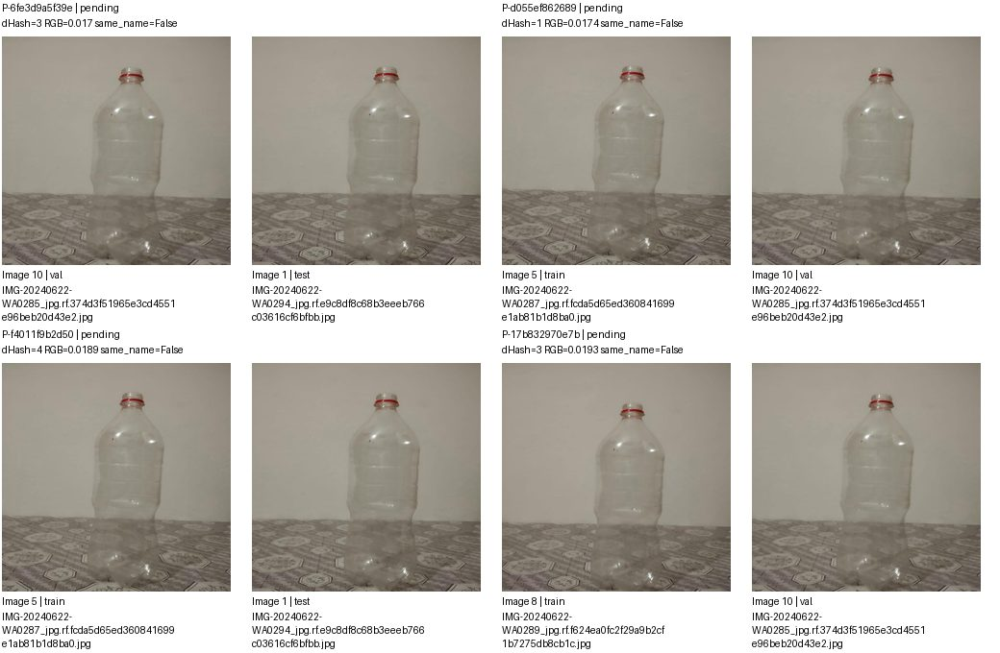

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-6fe3d9a5f39e,images/val/IMG-20240622-WA0285_jpg.rf.374d3f51965e3cd4551e96beb20d43e2.jpg,images/test/IMG-20240622-WA0294_jpg.rf.e9c8df8c68b3eeeb766c03616cf6bfbb.jpg,pending,
P-d055ef862689,images/train/IMG-20240622-WA0287_jpg.rf.fcda5d65ed360841699e1ab81b1d8ba0.jpg,images/val/IMG-20240622-WA0285_jpg.rf.374d3f51965e3cd4551e96beb20d43e2.jpg,pending,
P-f4011f9b2d50,images/train/IMG-20240622-WA0287_jpg.rf.fcda5d65ed360841699e1ab81b1d8ba0.jpg,images/test/IMG-20240622-WA0294_jpg.rf.e9c8df8c68b3eeeb766c03616cf6bfbb.jpg,pending,
P-17b832970e7b,images/train/IMG-20240622-WA0289_jpg.rf.f624ea0fc2f29a9b2cf1b7275db8cb1c.jpg,images/val/IMG-20240622-WA0285_jpg.rf.374d3f51965e3cd4551e96beb20d43e2.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 134/166 G-d9a50cabd37a | 10 ảnh, 13 cặp
Split: {'test': 1, 'train': 8, 'val': 1}
Quyết định: {'pending': 13}
Ảnh trang 2/2; cặp trang 2/4. Nhóm liên thông không phải kết luận trùng.


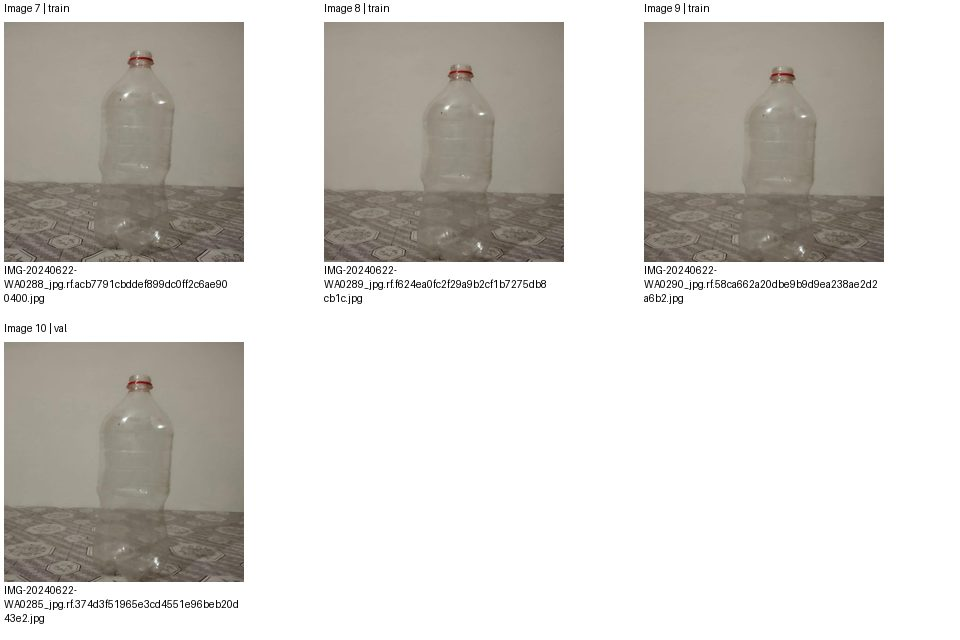

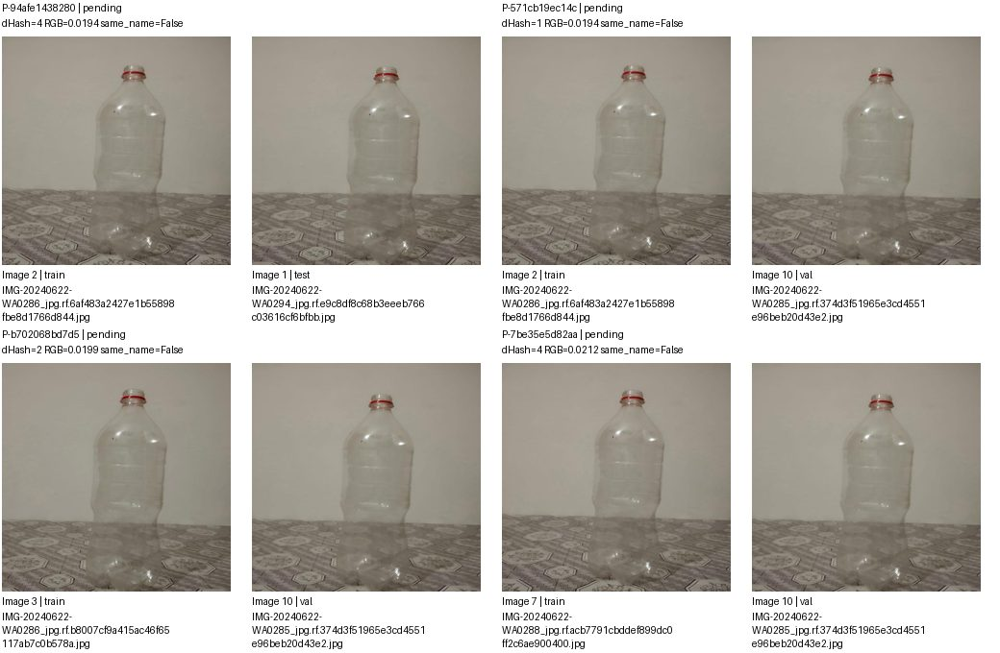

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-94afe1438280,images/train/IMG-20240622-WA0286_jpg.rf.6af483a2427e1b55898fbe8d1766d844.jpg,images/test/IMG-20240622-WA0294_jpg.rf.e9c8df8c68b3eeeb766c03616cf6bfbb.jpg,pending,
P-571cb19ec14c,images/train/IMG-20240622-WA0286_jpg.rf.6af483a2427e1b55898fbe8d1766d844.jpg,images/val/IMG-20240622-WA0285_jpg.rf.374d3f51965e3cd4551e96beb20d43e2.jpg,pending,
P-b702068bd7d5,images/train/IMG-20240622-WA0286_jpg.rf.b8007cf9a415ac46f65117ab7c0b578a.jpg,images/val/IMG-20240622-WA0285_jpg.rf.374d3f51965e3cd4551e96beb20d43e2.jpg,pending,
P-7be35e5d82aa,images/train/IMG-20240622-WA0288_jpg.rf.acb7791cbddef899dc0ff2c6ae900400.jpg,images/val/IMG-20240622-WA0285_jpg.rf.374d3f51965e3cd4551e96beb20d43e2.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 134/166 G-d9a50cabd37a | 10 ảnh, 13 cặp
Split: {'test': 1, 'train': 8, 'val': 1}
Quyết định: {'pending': 13}
Ảnh trang None/2; cặp trang 3/4. Nhóm liên thông không phải kết luận trùng.


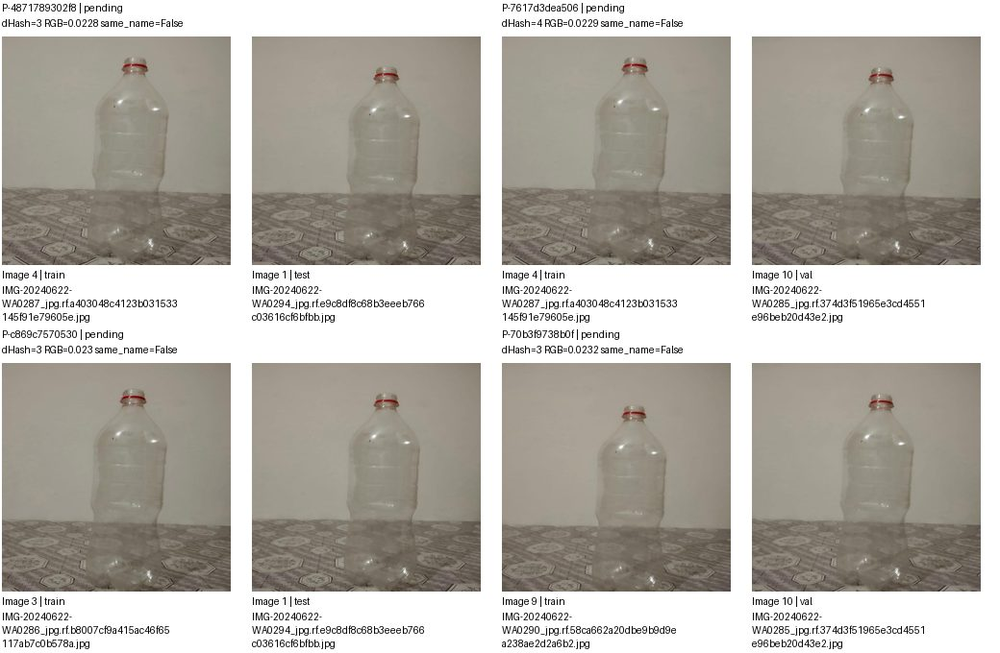

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-4871789302f8,images/train/IMG-20240622-WA0287_jpg.rf.a403048c4123b031533145f91e79605e.jpg,images/test/IMG-20240622-WA0294_jpg.rf.e9c8df8c68b3eeeb766c03616cf6bfbb.jpg,pending,
P-7617d3dea506,images/train/IMG-20240622-WA0287_jpg.rf.a403048c4123b031533145f91e79605e.jpg,images/val/IMG-20240622-WA0285_jpg.rf.374d3f51965e3cd4551e96beb20d43e2.jpg,pending,
P-c869c7570530,images/train/IMG-20240622-WA0286_jpg.rf.b8007cf9a415ac46f65117ab7c0b578a.jpg,images/test/IMG-20240622-WA0294_jpg.rf.e9c8df8c68b3eeeb766c03616cf6bfbb.jpg,pending,
P-70b3f9738b0f,images/train/IMG-20240622-WA0290_jpg.rf.58ca662a20dbe9b9d9ea238ae2d2a6b2.jpg,images/val/IMG-20240622-WA0285_jpg.rf.374d3f51965e3cd4551e96beb20d43e2.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 134/166 G-d9a50cabd37a | 10 ảnh, 13 cặp
Split: {'test': 1, 'train': 8, 'val': 1}
Quyết định: {'pending': 13}
Ảnh trang None/2; cặp trang 4/4. Nhóm liên thông không phải kết luận trùng.


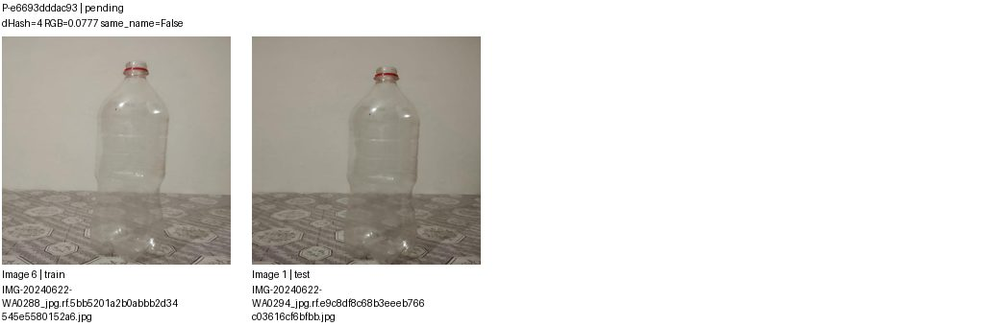

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-e6693dddac93,images/train/IMG-20240622-WA0288_jpg.rf.5bb5201a2b0abbb2d34545e5580152a6.jpg,images/test/IMG-20240622-WA0294_jpg.rf.e9c8df8c68b3eeeb766c03616cf6bfbb.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 135/166 G-ca1aa7943f35 | 7 ảnh, 8 cặp
Split: {'train': 5, 'val': 2}
Quyết định: {'pending': 8}
Ảnh trang 1/2; cặp trang 1/2. Nhóm liên thông không phải kết luận trùng.


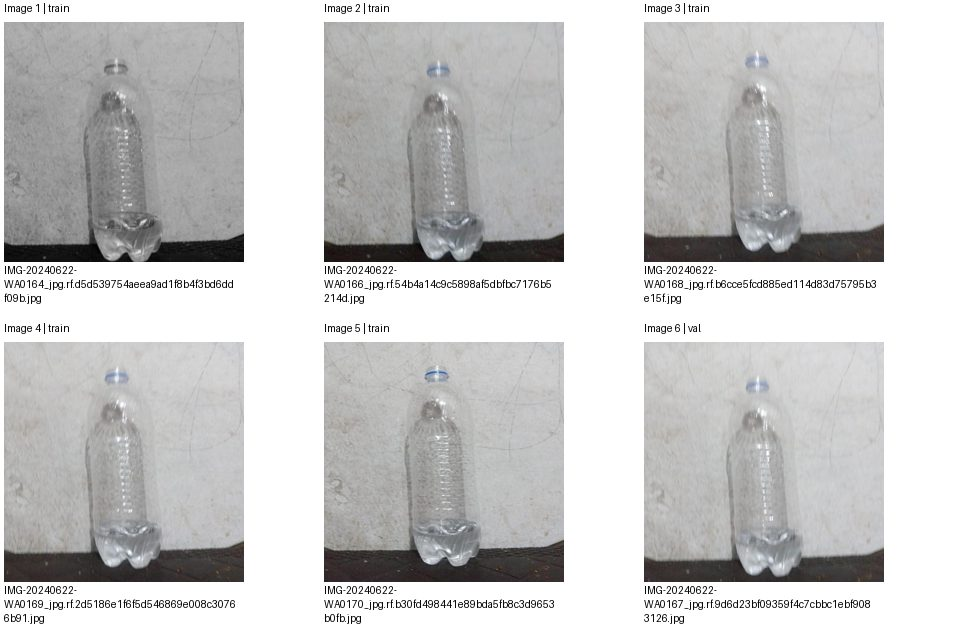

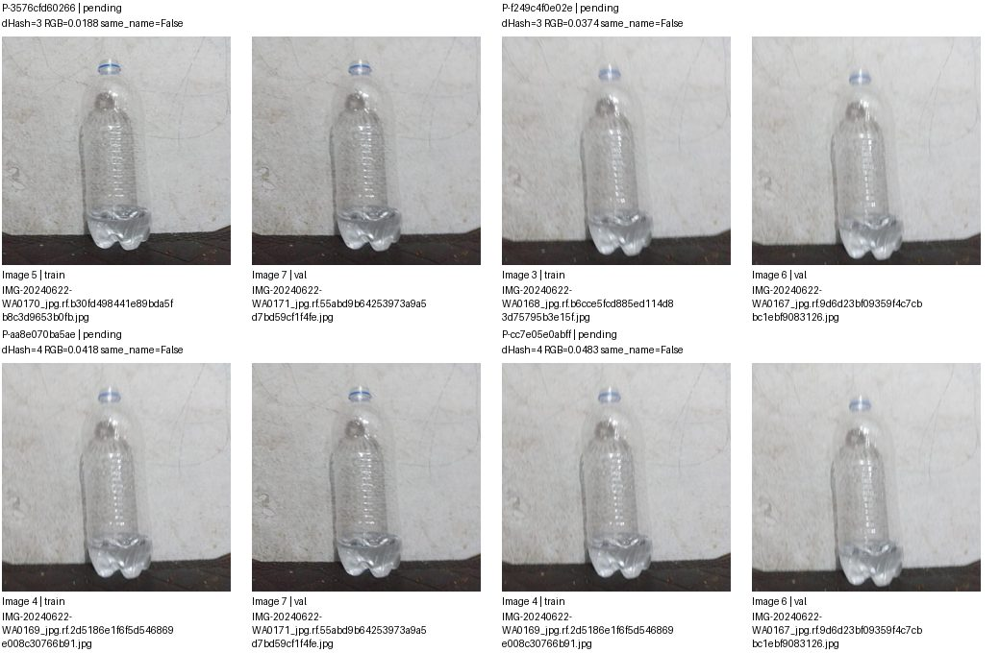

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-3576cfd60266,images/train/IMG-20240622-WA0170_jpg.rf.b30fd498441e89bda5fb8c3d9653b0fb.jpg,images/val/IMG-20240622-WA0171_jpg.rf.55abd9b64253973a9a5d7bd59cf1f4fe.jpg,pending,
P-f249c4f0e02e,images/train/IMG-20240622-WA0168_jpg.rf.b6cce5fcd885ed114d83d75795b3e15f.jpg,images/val/IMG-20240622-WA0167_jpg.rf.9d6d23bf09359f4c7cbbc1ebf9083126.jpg,pending,
P-aa8e070ba5ae,images/train/IMG-20240622-WA0169_jpg.rf.2d5186e1f6f5d546869e008c30766b91.jpg,images/val/IMG-20240622-WA0171_jpg.rf.55abd9b64253973a9a5d7bd59cf1f4fe.jpg,pending,
P-cc7e05e0abff,images/train/IMG-20240622-WA0169_jpg.rf.2d5186e1f6f5d546869e008c30766b91.jpg,images/val/IMG-20240622-WA0167_jpg.rf.9d6d23bf09359f4c7cbbc1ebf9083126.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 135/166 G-ca1aa7943f35 | 7 ảnh, 8 cặp
Split: {'train': 5, 'val': 2}
Quyết định: {'pending': 8}
Ảnh trang 2/2; cặp trang 2/2. Nhóm liên thông không phải kết luận trùng.


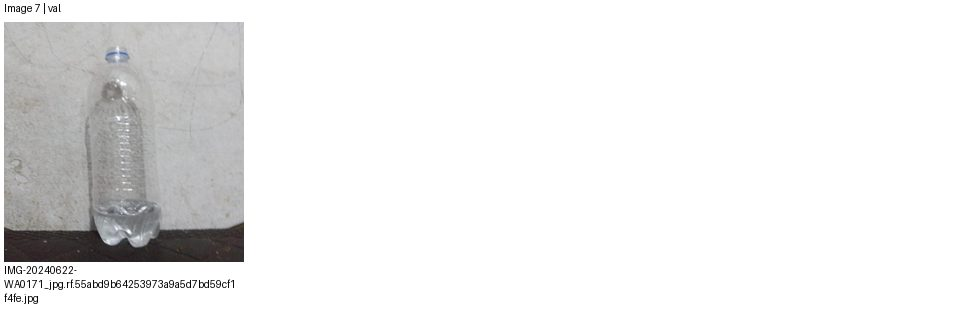

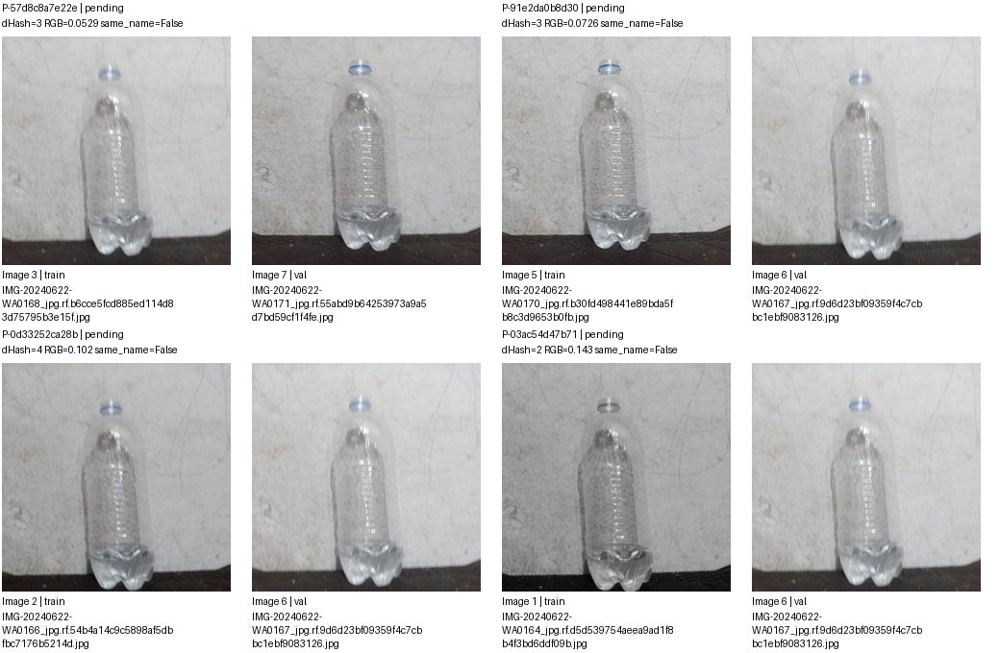

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-57d8c8a7e22e,images/train/IMG-20240622-WA0168_jpg.rf.b6cce5fcd885ed114d83d75795b3e15f.jpg,images/val/IMG-20240622-WA0171_jpg.rf.55abd9b64253973a9a5d7bd59cf1f4fe.jpg,pending,
P-91e2da0b8d30,images/train/IMG-20240622-WA0170_jpg.rf.b30fd498441e89bda5fb8c3d9653b0fb.jpg,images/val/IMG-20240622-WA0167_jpg.rf.9d6d23bf09359f4c7cbbc1ebf9083126.jpg,pending,
P-0d33252ca28b,images/train/IMG-20240622-WA0166_jpg.rf.54b4a14c9c5898af5dbfbc7176b5214d.jpg,images/val/IMG-20240622-WA0167_jpg.rf.9d6d23bf09359f4c7cbbc1ebf9083126.jpg,pending,
P-03ac54d47b71,images/train/IMG-20240622-WA0164_jpg.rf.d5d539754aeea9ad1f8b4f3bd6ddf09b.jpg,images/val/IMG-20240622-WA0167_jpg.rf.9d6d23bf09359f4c7cbbc1ebf9083126.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 136/166 G-188cc8655abf | 5 ảnh, 4 cặp
Split: {'train': 2, 'val': 3}
Quyết định: {'pending': 4}
Ảnh trang 1/1; cặp trang 1/1. Nhóm liên thông không phải kết luận trùng.


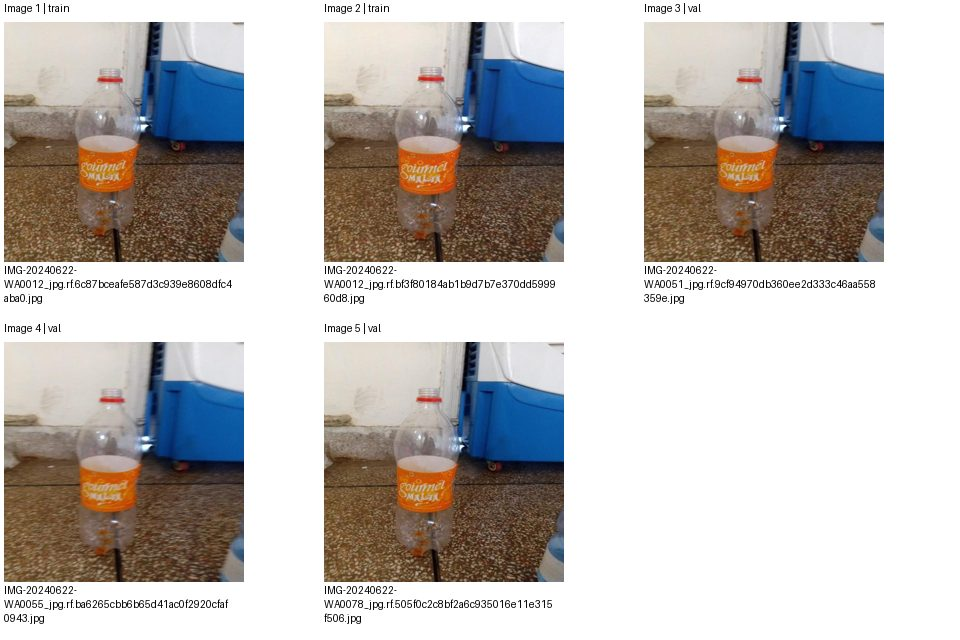

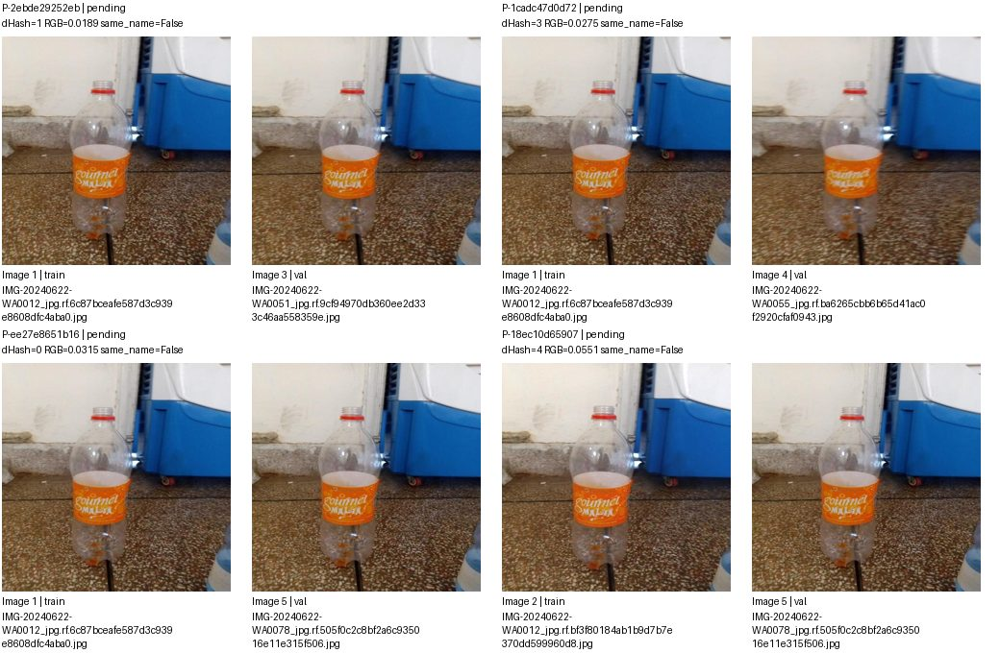

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-2ebde29252eb,images/train/IMG-20240622-WA0012_jpg.rf.6c87bceafe587d3c939e8608dfc4aba0.jpg,images/val/IMG-20240622-WA0051_jpg.rf.9cf94970db360ee2d333c46aa558359e.jpg,pending,
P-1cadc47d0d72,images/train/IMG-20240622-WA0012_jpg.rf.6c87bceafe587d3c939e8608dfc4aba0.jpg,images/val/IMG-20240622-WA0055_jpg.rf.ba6265cbb6b65d41ac0f2920cfaf0943.jpg,pending,
P-ee27e8651b16,images/train/IMG-20240622-WA0012_jpg.rf.6c87bceafe587d3c939e8608dfc4aba0.jpg,images/val/IMG-20240622-WA0078_jpg.rf.505f0c2c8bf2a6c935016e11e315f506.jpg,pending,
P-18ec10d65907,images/train/IMG-20240622-WA0012_jpg.rf.bf3f80184ab1b9d7b7e370dd599960d8.jpg,images/val/IMG-20240622-WA0078_jpg.rf.505f0c2c8bf2a6c935016e11e315f506.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 137/166 G-eeb6be34874e | 6 ảnh, 8 cặp
Split: {'train': 4, 'val': 2}
Quyết định: {'pending': 8}
Ảnh trang 1/1; cặp trang 1/2. Nhóm liên thông không phải kết luận trùng.


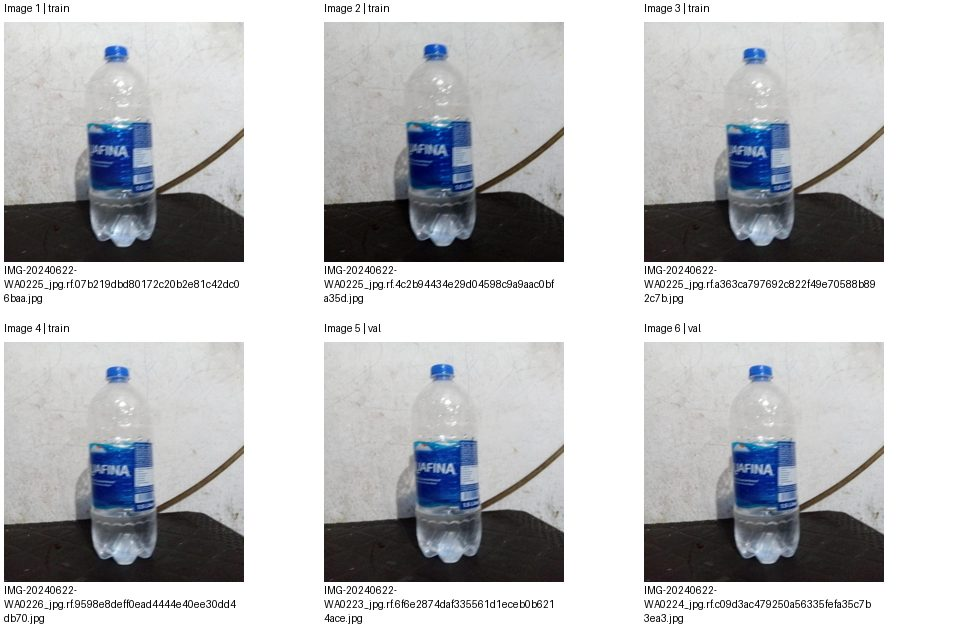

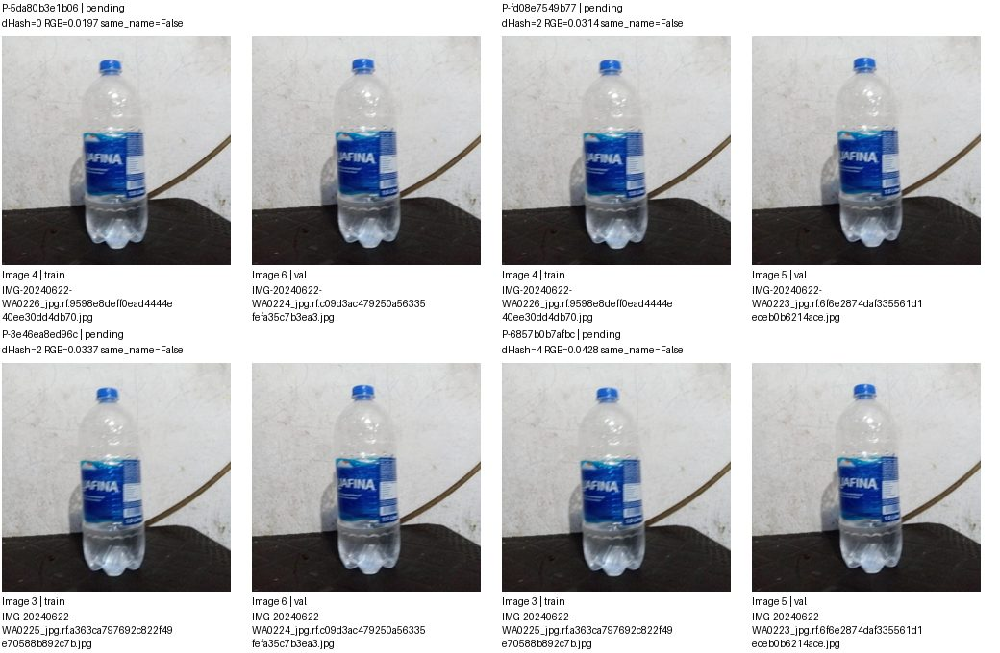

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-5da80b3e1b06,images/train/IMG-20240622-WA0226_jpg.rf.9598e8deff0ead4444e40ee30dd4db70.jpg,images/val/IMG-20240622-WA0224_jpg.rf.c09d3ac479250a56335fefa35c7b3ea3.jpg,pending,
P-fd08e7549b77,images/train/IMG-20240622-WA0226_jpg.rf.9598e8deff0ead4444e40ee30dd4db70.jpg,images/val/IMG-20240622-WA0223_jpg.rf.6f6e2874daf335561d1eceb0b6214ace.jpg,pending,
P-3e46ea8ed96c,images/train/IMG-20240622-WA0225_jpg.rf.a363ca797692c822f49e70588b892c7b.jpg,images/val/IMG-20240622-WA0224_jpg.rf.c09d3ac479250a56335fefa35c7b3ea3.jpg,pending,
P-6857b0b7afbc,images/train/IMG-20240622-WA0225_jpg.rf.a363ca797692c822f49e70588b892c7b.jpg,images/val/IMG-20240622-WA0223_jpg.rf.6f6e2874daf335561d1eceb0b6214ace.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 137/166 G-eeb6be34874e | 6 ảnh, 8 cặp
Split: {'train': 4, 'val': 2}
Quyết định: {'pending': 8}
Ảnh trang None/1; cặp trang 2/2. Nhóm liên thông không phải kết luận trùng.


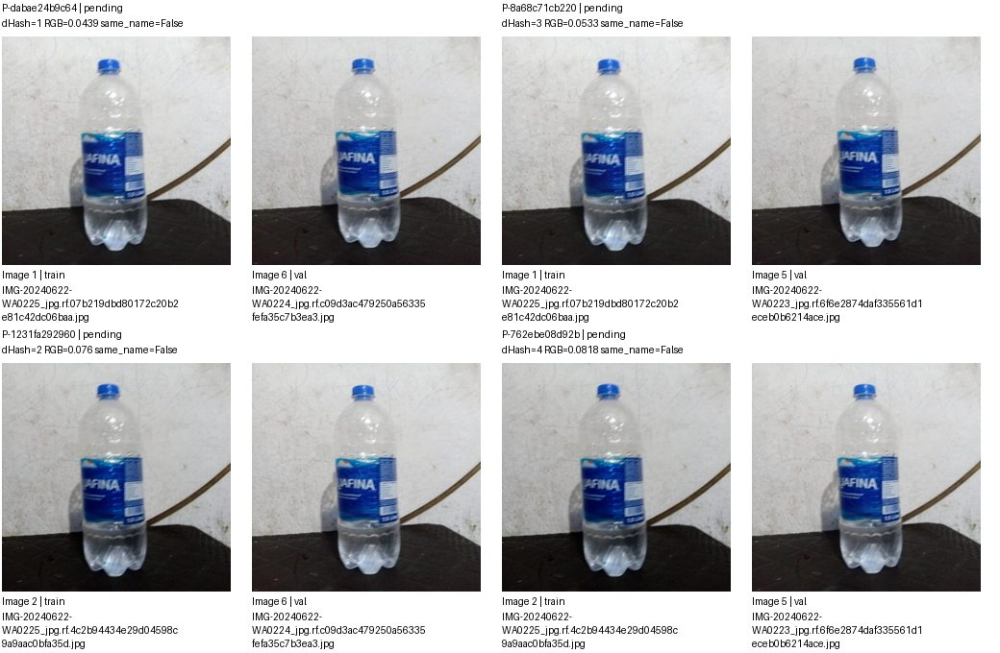

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-dabae24b9c64,images/train/IMG-20240622-WA0225_jpg.rf.07b219dbd80172c20b2e81c42dc06baa.jpg,images/val/IMG-20240622-WA0224_jpg.rf.c09d3ac479250a56335fefa35c7b3ea3.jpg,pending,
P-8a68c71cb220,images/train/IMG-20240622-WA0225_jpg.rf.07b219dbd80172c20b2e81c42dc06baa.jpg,images/val/IMG-20240622-WA0223_jpg.rf.6f6e2874daf335561d1eceb0b6214ace.jpg,pending,
P-1231fa292960,images/train/IMG-20240622-WA0225_jpg.rf.4c2b94434e29d04598c9a9aac0bfa35d.jpg,images/val/IMG-20240622-WA0224_jpg.rf.c09d3ac479250a56335fefa35c7b3ea3.jpg,pending,
P-762ebe08d92b,images/train/IMG-20240622-WA0225_jpg.rf.4c2b94434e29d04598c9a9aac0bfa35d.jpg,images/val/IMG-20240622-WA0223_jpg.rf.6f6e2874daf335561d1eceb0b6214ace.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 138/166 G-425e30c45146 | 2 ảnh, 1 cặp
Split: {'train': 1, 'val': 1}
Quyết định: {'pending': 1}
Ảnh trang 1/1; cặp trang 1/1. Nhóm liên thông không phải kết luận trùng.


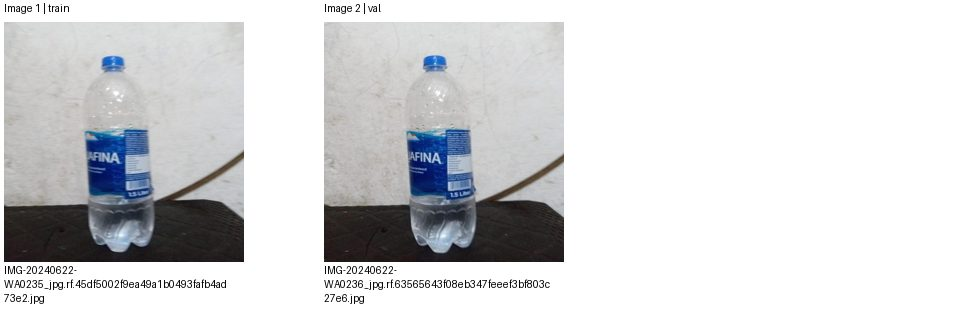

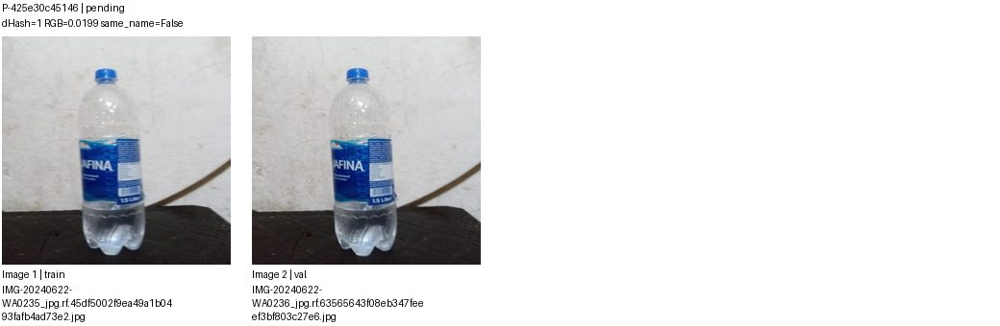

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-425e30c45146,images/train/IMG-20240622-WA0235_jpg.rf.45df5002f9ea49a1b0493fafb4ad73e2.jpg,images/val/IMG-20240622-WA0236_jpg.rf.63565643f08eb347feeef3bf803c27e6.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 139/166 G-8eeb10cf08c0 | 5 ảnh, 4 cặp
Split: {'train': 4, 'val': 1}
Quyết định: {'pending': 4}
Ảnh trang 1/1; cặp trang 1/1. Nhóm liên thông không phải kết luận trùng.


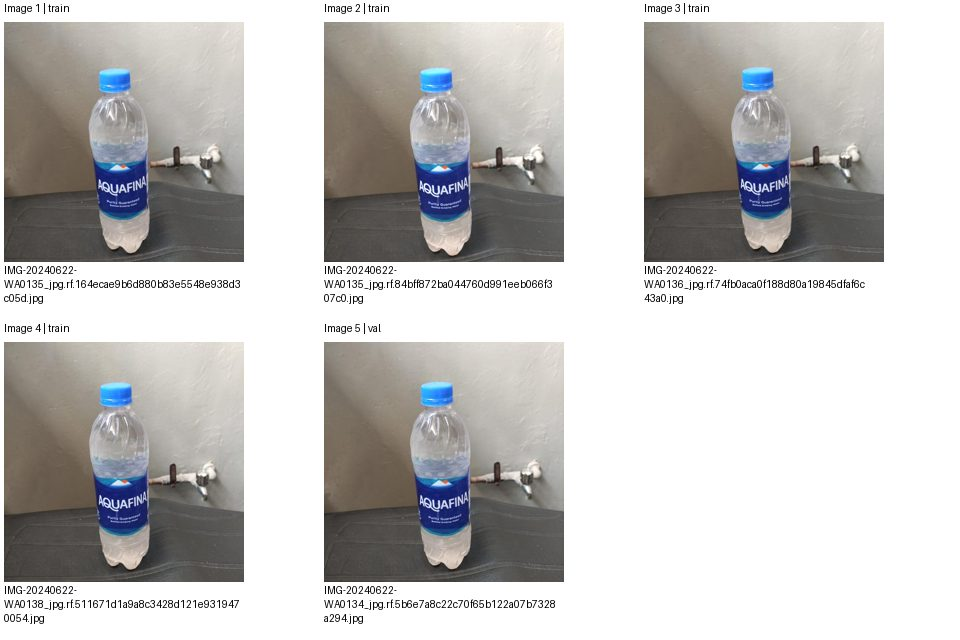

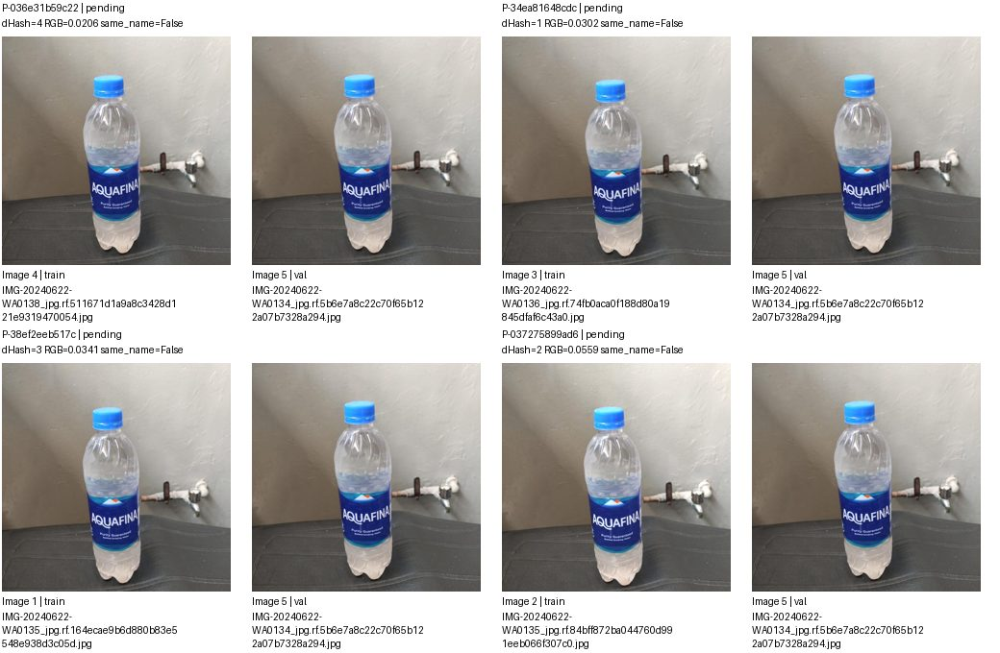

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-036e31b59c22,images/train/IMG-20240622-WA0138_jpg.rf.511671d1a9a8c3428d121e9319470054.jpg,images/val/IMG-20240622-WA0134_jpg.rf.5b6e7a8c22c70f65b122a07b7328a294.jpg,pending,
P-34ea81648cdc,images/train/IMG-20240622-WA0136_jpg.rf.74fb0aca0f188d80a19845dfaf6c43a0.jpg,images/val/IMG-20240622-WA0134_jpg.rf.5b6e7a8c22c70f65b122a07b7328a294.jpg,pending,
P-38ef2eeb517c,images/train/IMG-20240622-WA0135_jpg.rf.164ecae9b6d880b83e5548e938d3c05d.jpg,images/val/IMG-20240622-WA0134_jpg.rf.5b6e7a8c22c70f65b122a07b7328a294.jpg,pending,
P-037275899ad6,images/train/IMG-20240622-WA0135_jpg.rf.84bff872ba044760d991eeb066f307c0.jpg,images/val/IMG-20240622-WA0134_jpg.rf.5b6e7a8c22c70f65b122a07b7328a294.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 140/166 G-cb93eb46bd5a | 2 ảnh, 1 cặp
Split: {'train': 1, 'val': 1}
Quyết định: {'pending': 1}
Ảnh trang 1/1; cặp trang 1/1. Nhóm liên thông không phải kết luận trùng.


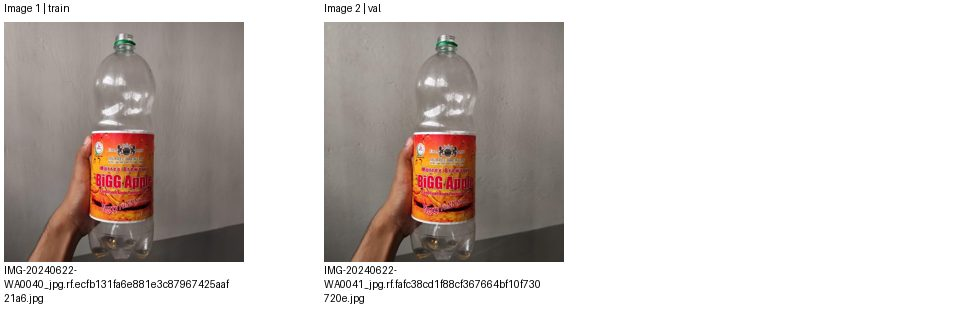

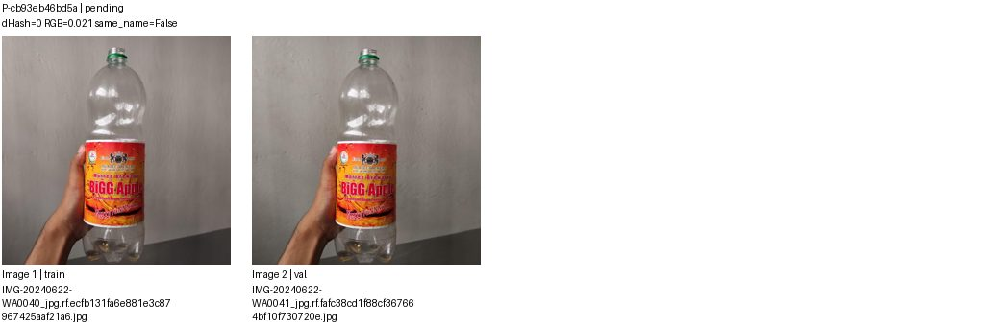

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-cb93eb46bd5a,images/train/IMG-20240622-WA0040_jpg.rf.ecfb131fa6e881e3c87967425aaf21a6.jpg,images/val/IMG-20240622-WA0041_jpg.rf.fafc38cd1f88cf367664bf10f730720e.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 141/166 G-8f948ffdfc0c | 7 ảnh, 6 cặp
Split: {'train': 6, 'val': 1}
Quyết định: {'pending': 6}
Ảnh trang 1/2; cặp trang 1/2. Nhóm liên thông không phải kết luận trùng.


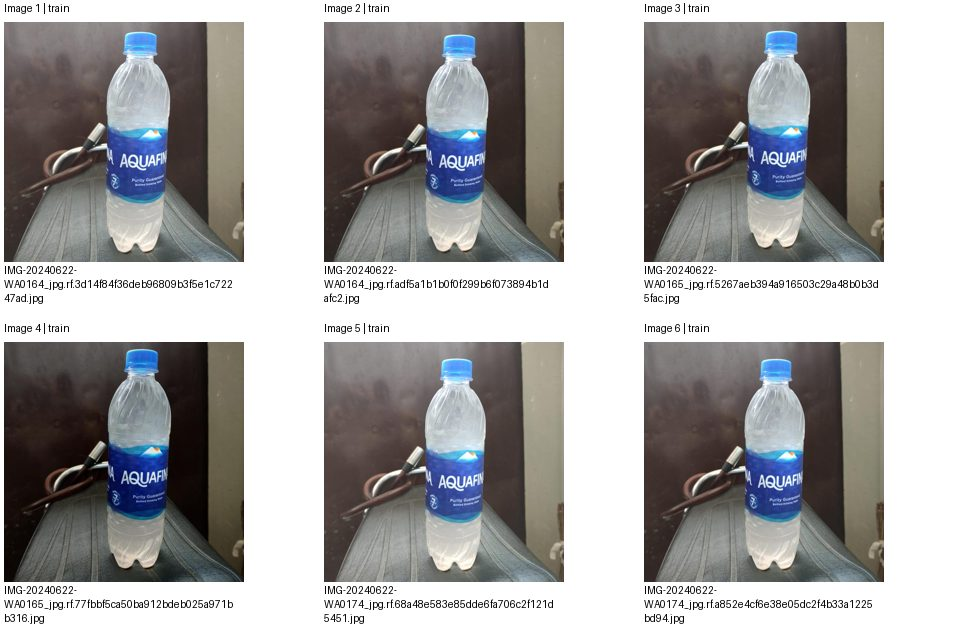

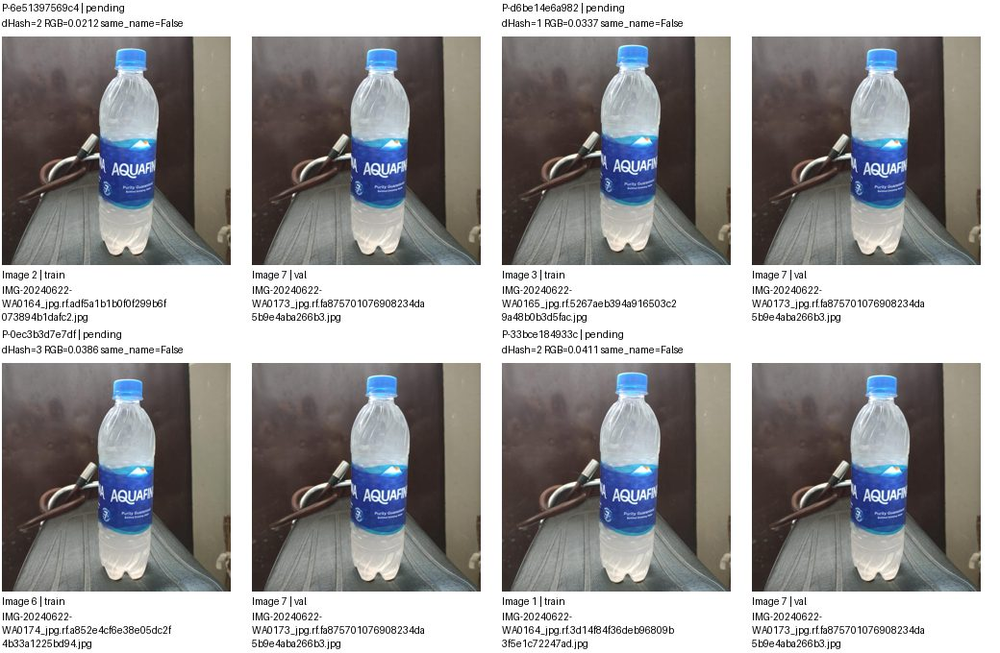

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-6e51397569c4,images/train/IMG-20240622-WA0164_jpg.rf.adf5a1b1b0f0f299b6f073894b1dafc2.jpg,images/val/IMG-20240622-WA0173_jpg.rf.fa875701076908234da5b9e4aba266b3.jpg,pending,
P-d6be14e6a982,images/train/IMG-20240622-WA0165_jpg.rf.5267aeb394a916503c29a48b0b3d5fac.jpg,images/val/IMG-20240622-WA0173_jpg.rf.fa875701076908234da5b9e4aba266b3.jpg,pending,
P-0ec3b3d7e7df,images/train/IMG-20240622-WA0174_jpg.rf.a852e4cf6e38e05dc2f4b33a1225bd94.jpg,images/val/IMG-20240622-WA0173_jpg.rf.fa875701076908234da5b9e4aba266b3.jpg,pending,
P-33bce184933c,images/train/IMG-20240622-WA0164_jpg.rf.3d14f84f36deb96809b3f5e1c72247ad.jpg,images/val/IMG-20240622-WA0173_jpg.rf.fa875701076908234da5b9e4aba266b3.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 141/166 G-8f948ffdfc0c | 7 ảnh, 6 cặp
Split: {'train': 6, 'val': 1}
Quyết định: {'pending': 6}
Ảnh trang 2/2; cặp trang 2/2. Nhóm liên thông không phải kết luận trùng.


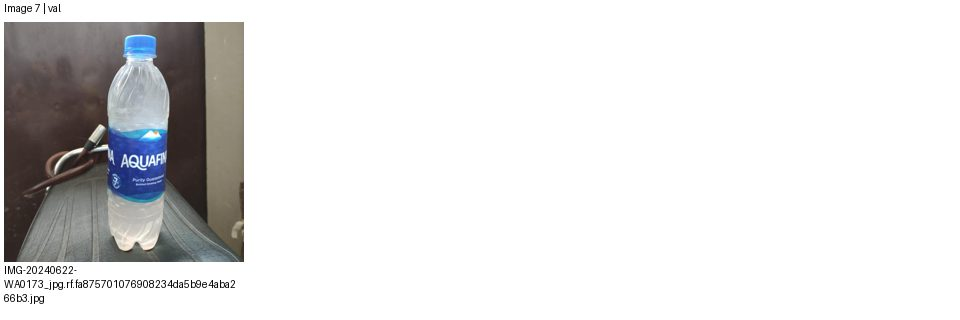

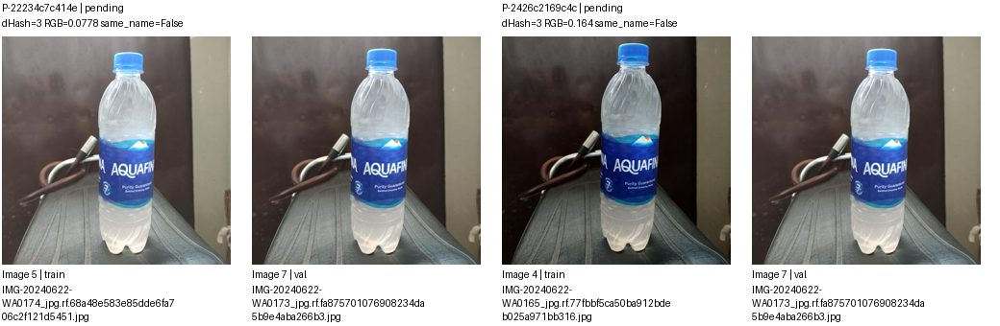

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-22234c7c414e,images/train/IMG-20240622-WA0174_jpg.rf.68a48e583e85dde6fa706c2f121d5451.jpg,images/val/IMG-20240622-WA0173_jpg.rf.fa875701076908234da5b9e4aba266b3.jpg,pending,
P-2426c2169c4c,images/train/IMG-20240622-WA0165_jpg.rf.77fbbf5ca50ba912bdeb025a971bb316.jpg,images/val/IMG-20240622-WA0173_jpg.rf.fa875701076908234da5b9e4aba266b3.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 142/166 G-ba30e3cc31c7 | 5 ảnh, 5 cặp
Split: {'test': 1, 'train': 2, 'val': 2}
Quyết định: {'pending': 5}
Ảnh trang 1/1; cặp trang 1/2. Nhóm liên thông không phải kết luận trùng.


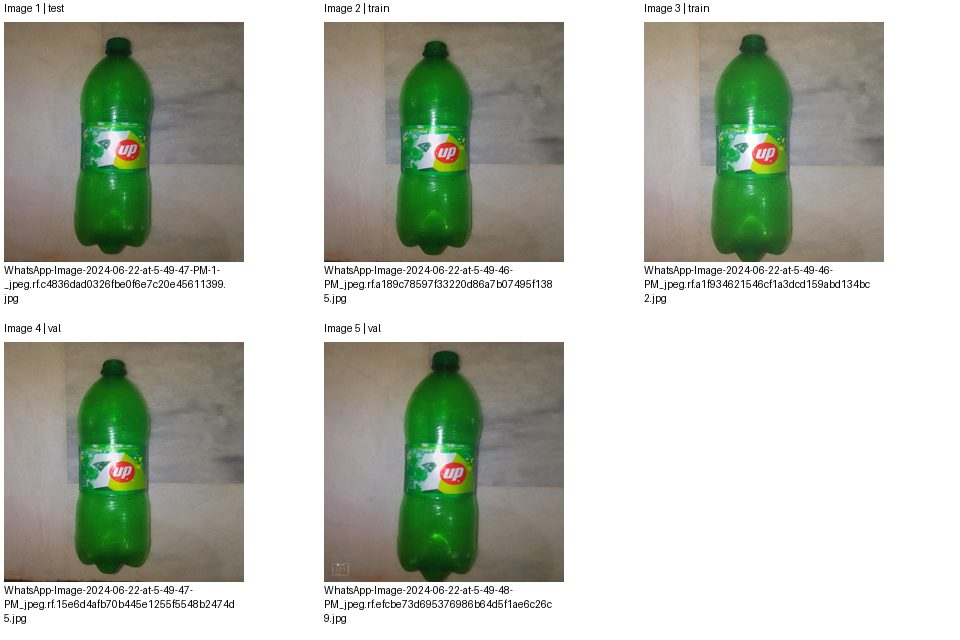

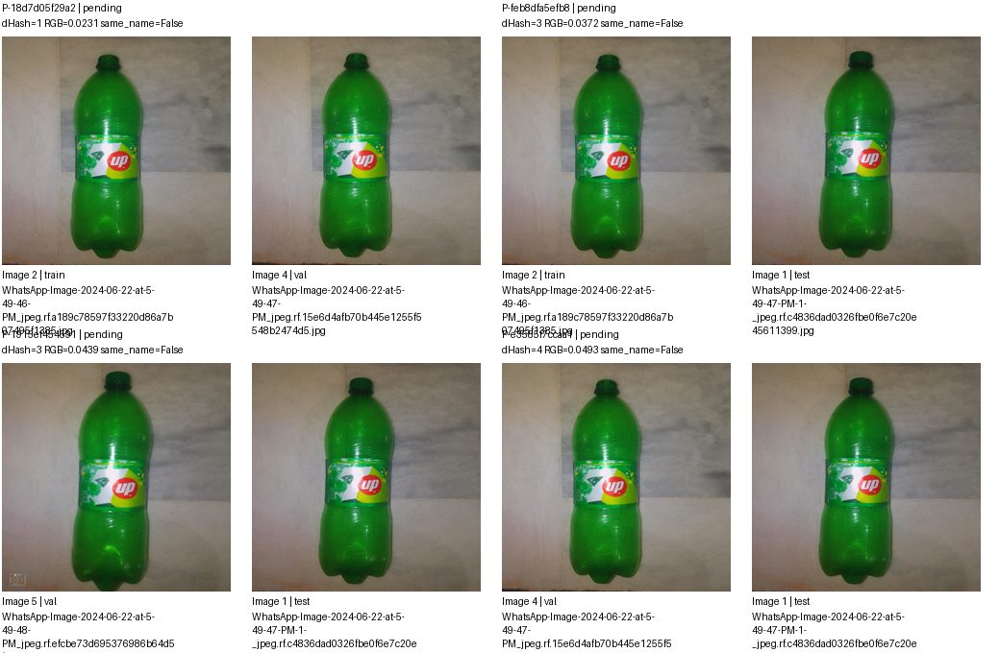

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-18d7d05f29a2,images/train/WhatsApp-Image-2024-06-22-at-5-49-46-PM_jpeg.rf.a189c78597f33220d86a7b07495f1385.jpg,images/val/WhatsApp-Image-2024-06-22-at-5-49-47-PM_jpeg.rf.15e6d4afb70b445e1255f5548b2474d5.jpg,pending,
P-feb8dfa5efb8,images/train/WhatsApp-Image-2024-06-22-at-5-49-46-PM_jpeg.rf.a189c78597f33220d86a7b07495f1385.jpg,images/test/WhatsApp-Image-2024-06-22-at-5-49-47-PM-1-_jpeg.rf.c4836dad0326fbe0f6e7c20e45611399.jpg,pending,
P-1915ef454591,images/val/WhatsApp-Image-2024-06-22-at-5-49-48-PM_jpeg.rf.efcbe73d695376986b64d5f1ae6c26c9.jpg,images/test/WhatsApp-Image-2024-06-22-at-5-49-47-PM-1-_jpeg.rf.c4836dad0326fbe0f6e7c20e45611399.jpg,pending,
P-e3585f7ccaa1,images/val/WhatsApp-Image-2024-06-22-at-5-49-47-PM_jpeg.rf.15e6d4afb70b445e1255f5548b2474d5.jpg,images/test/WhatsApp-Image-2024-06-22-at-5-49-47-PM-1-_jpeg.rf.c4836dad0326fbe0f6e7c20e45611399.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 142/166 G-ba30e3cc31c7 | 5 ảnh, 5 cặp
Split: {'test': 1, 'train': 2, 'val': 2}
Quyết định: {'pending': 5}
Ảnh trang None/1; cặp trang 2/2. Nhóm liên thông không phải kết luận trùng.


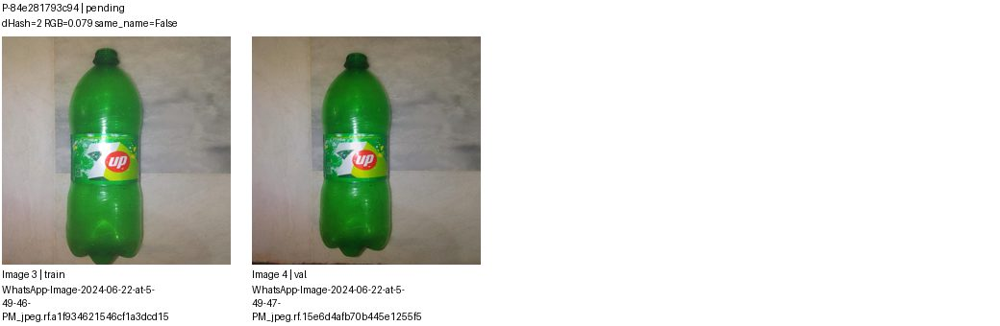

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-84e281793c94,images/train/WhatsApp-Image-2024-06-22-at-5-49-46-PM_jpeg.rf.a1f934621546cf1a3dcd159abd134bc2.jpg,images/val/WhatsApp-Image-2024-06-22-at-5-49-47-PM_jpeg.rf.15e6d4afb70b445e1255f5548b2474d5.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 143/166 G-d4596c16f8b6 | 3 ảnh, 2 cặp
Split: {'train': 2, 'val': 1}
Quyết định: {'pending': 2}
Ảnh trang 1/1; cặp trang 1/1. Nhóm liên thông không phải kết luận trùng.


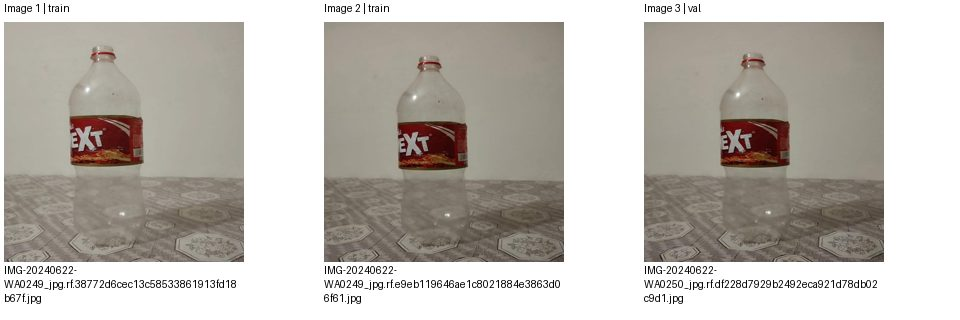

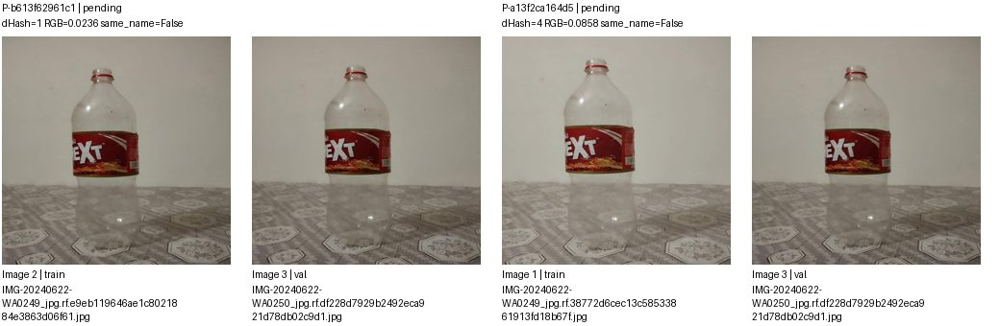

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-b613f62961c1,images/train/IMG-20240622-WA0249_jpg.rf.e9eb119646ae1c8021884e3863d06f61.jpg,images/val/IMG-20240622-WA0250_jpg.rf.df228d7929b2492eca921d78db02c9d1.jpg,pending,
P-a13f2ca164d5,images/train/IMG-20240622-WA0249_jpg.rf.38772d6cec13c58533861913fd18b67f.jpg,images/val/IMG-20240622-WA0250_jpg.rf.df228d7929b2492eca921d78db02c9d1.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 144/166 G-a73da3845637 | 7 ảnh, 6 cặp
Split: {'test': 1, 'train': 6}
Quyết định: {'pending': 6}
Ảnh trang 1/2; cặp trang 1/2. Nhóm liên thông không phải kết luận trùng.


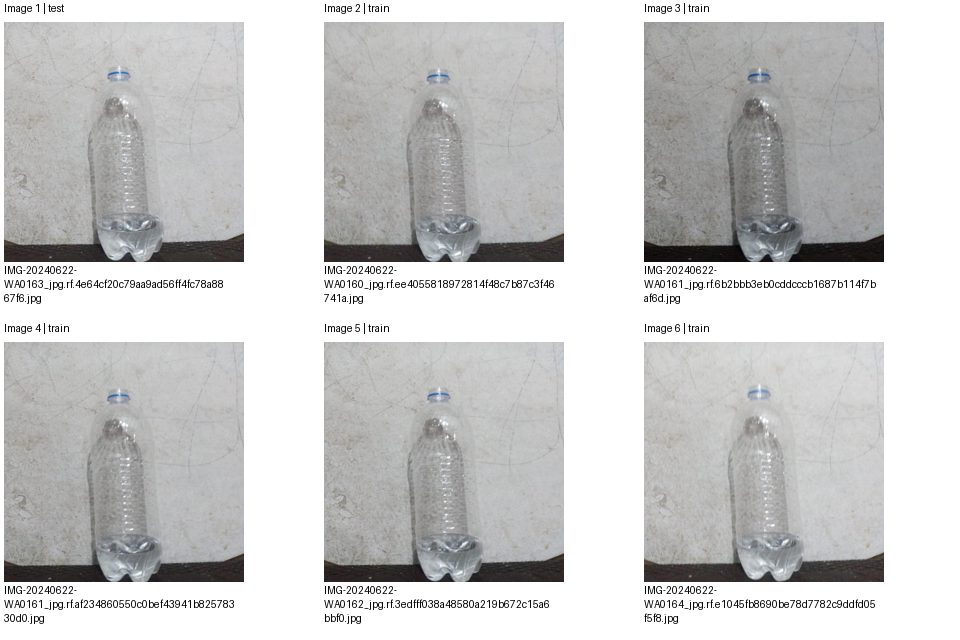

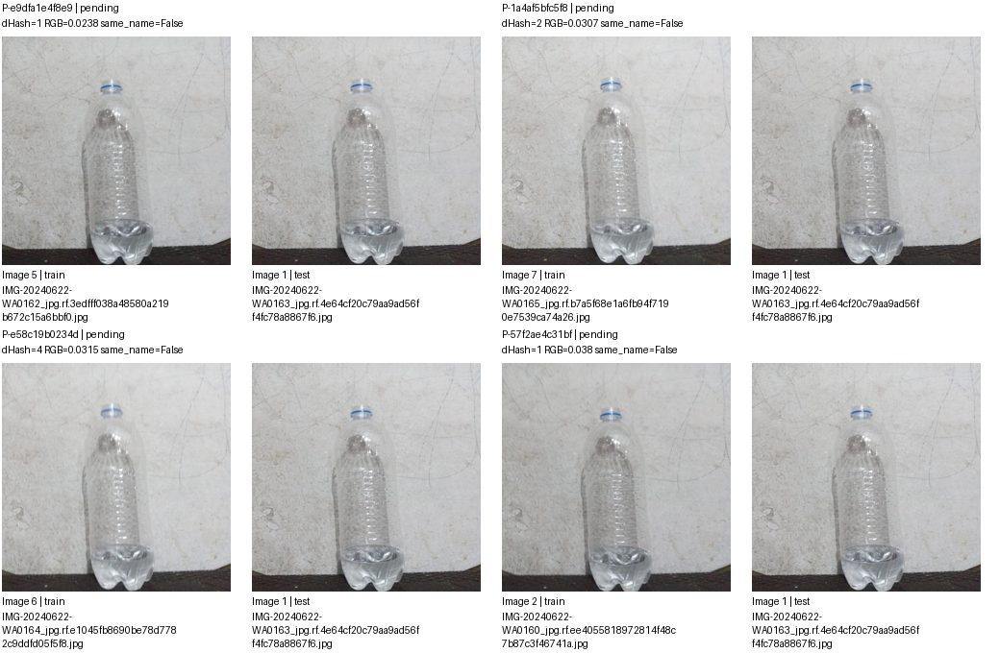

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-e9dfa1e4f8e9,images/train/IMG-20240622-WA0162_jpg.rf.3edfff038a48580a219b672c15a6bbf0.jpg,images/test/IMG-20240622-WA0163_jpg.rf.4e64cf20c79aa9ad56ff4fc78a8867f6.jpg,pending,
P-1a4af5bfc5f8,images/train/IMG-20240622-WA0165_jpg.rf.b7a5f68e1a6fb94f7190e7539ca74a26.jpg,images/test/IMG-20240622-WA0163_jpg.rf.4e64cf20c79aa9ad56ff4fc78a8867f6.jpg,pending,
P-e58c19b0234d,images/train/IMG-20240622-WA0164_jpg.rf.e1045fb8690be78d7782c9ddfd05f5f8.jpg,images/test/IMG-20240622-WA0163_jpg.rf.4e64cf20c79aa9ad56ff4fc78a8867f6.jpg,pending,
P-57f2ae4c31bf,images/train/IMG-20240622-WA0160_jpg.rf.ee4055818972814f48c7b87c3f46741a.jpg,images/test/IMG-20240622-WA0163_jpg.rf.4e64cf20c79aa9ad56ff4fc78a8867f6.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 144/166 G-a73da3845637 | 7 ảnh, 6 cặp
Split: {'test': 1, 'train': 6}
Quyết định: {'pending': 6}
Ảnh trang 2/2; cặp trang 2/2. Nhóm liên thông không phải kết luận trùng.


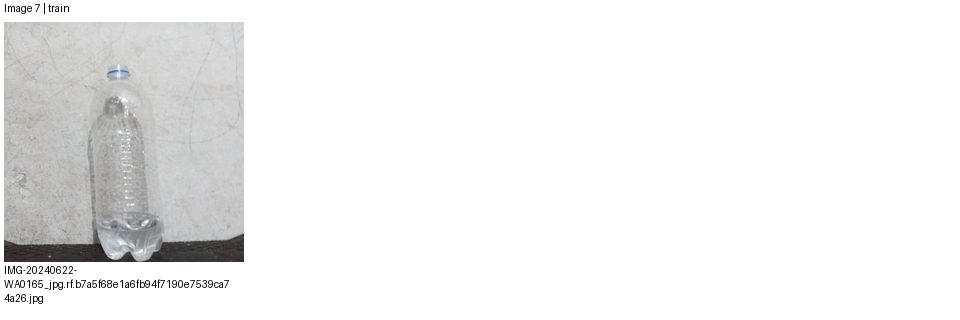

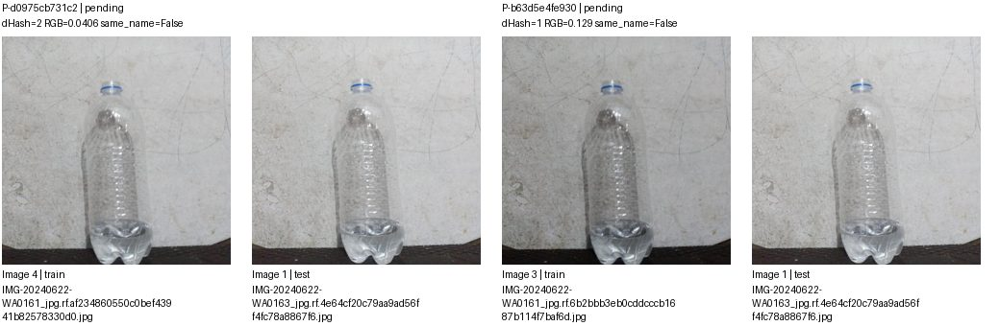

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-d0975cb731c2,images/train/IMG-20240622-WA0161_jpg.rf.af234860550c0bef43941b82578330d0.jpg,images/test/IMG-20240622-WA0163_jpg.rf.4e64cf20c79aa9ad56ff4fc78a8867f6.jpg,pending,
P-b63d5e4fe930,images/train/IMG-20240622-WA0161_jpg.rf.6b2bbb3eb0cddcccb1687b114f7baf6d.jpg,images/test/IMG-20240622-WA0163_jpg.rf.4e64cf20c79aa9ad56ff4fc78a8867f6.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 145/166 G-c68c3dba3c4f | 2 ảnh, 1 cặp
Split: {'train': 1, 'val': 1}
Quyết định: {'pending': 1}
Ảnh trang 1/1; cặp trang 1/1. Nhóm liên thông không phải kết luận trùng.


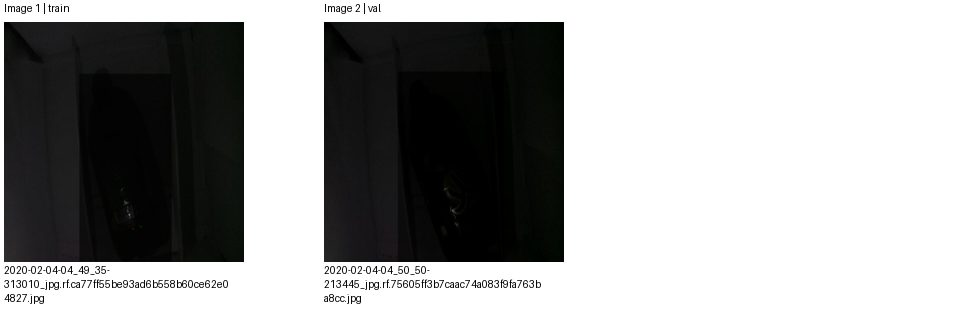

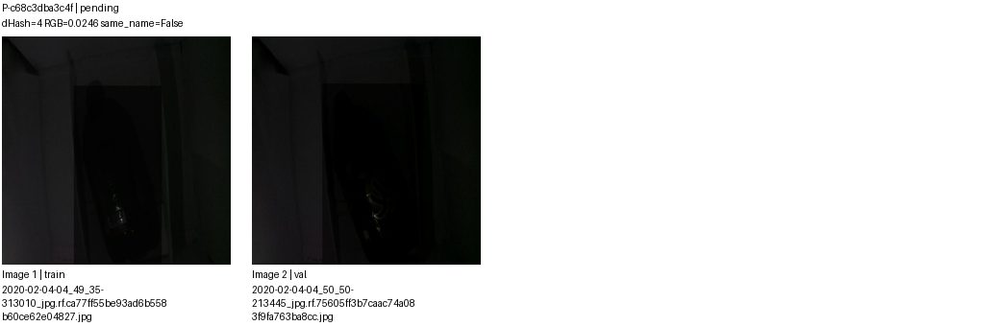

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-c68c3dba3c4f,images/train/2020-02-04-04_49_35-313010_jpg.rf.ca77ff55be93ad6b558b60ce62e04827.jpg,images/val/2020-02-04-04_50_50-213445_jpg.rf.75605ff3b7caac74a083f9fa763ba8cc.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 146/166 G-70cace40b4fc | 3 ảnh, 2 cặp
Split: {'train': 1, 'val': 2}
Quyết định: {'pending': 2}
Ảnh trang 1/1; cặp trang 1/1. Nhóm liên thông không phải kết luận trùng.


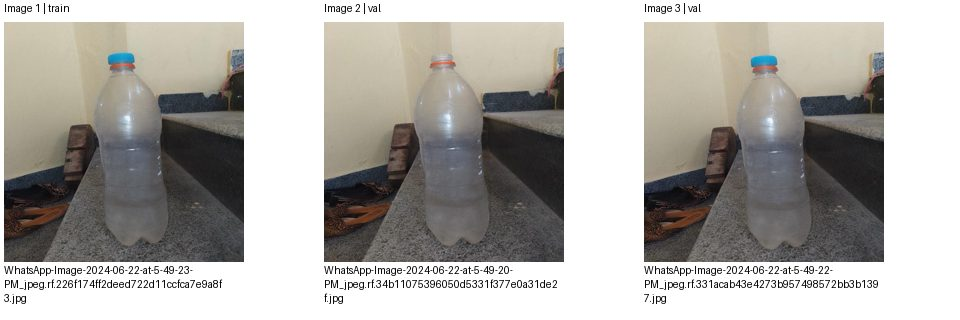

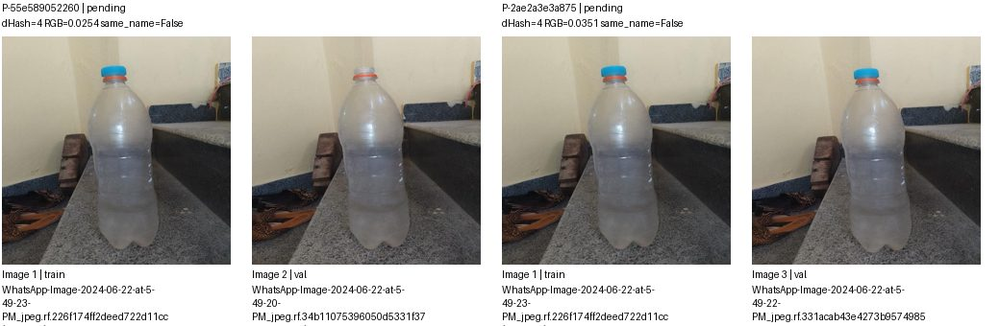

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-55e589052260,images/train/WhatsApp-Image-2024-06-22-at-5-49-23-PM_jpeg.rf.226f174ff2deed722d11ccfca7e9a8f3.jpg,images/val/WhatsApp-Image-2024-06-22-at-5-49-20-PM_jpeg.rf.34b11075396050d5331f377e0a31de2f.jpg,pending,
P-2ae2a3e3a875,images/train/WhatsApp-Image-2024-06-22-at-5-49-23-PM_jpeg.rf.226f174ff2deed722d11ccfca7e9a8f3.jpg,images/val/WhatsApp-Image-2024-06-22-at-5-49-22-PM_jpeg.rf.331acab43e4273b957498572bb3b1397.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 147/166 G-1376a936f6d9 | 2 ảnh, 1 cặp
Split: {'train': 1, 'val': 1}
Quyết định: {'pending': 1}
Ảnh trang 1/1; cặp trang 1/1. Nhóm liên thông không phải kết luận trùng.


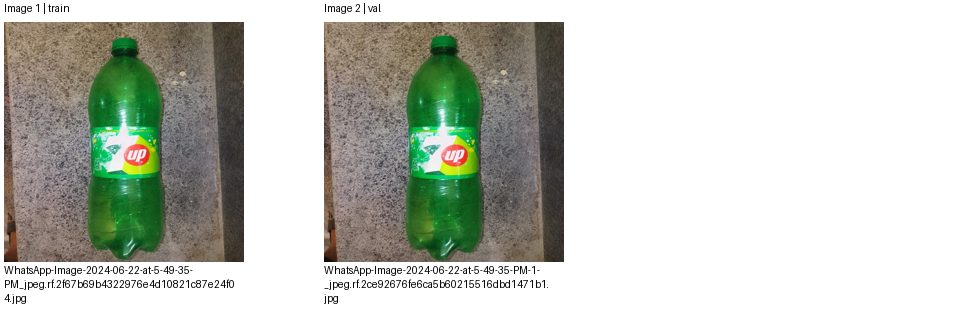

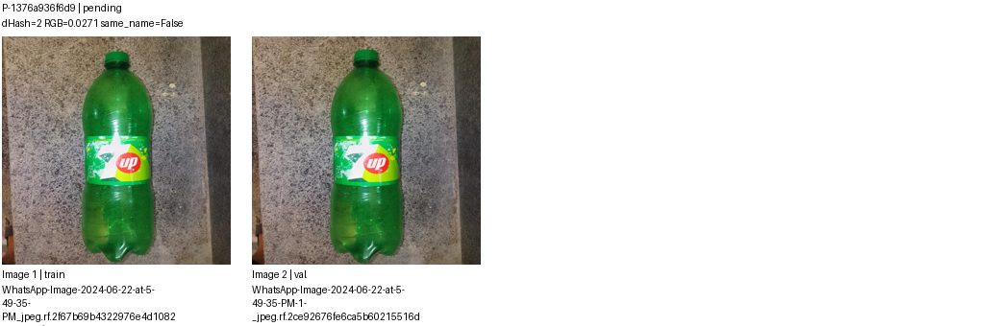

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-1376a936f6d9,images/train/WhatsApp-Image-2024-06-22-at-5-49-35-PM_jpeg.rf.2f67b69b4322976e4d10821c87e24f04.jpg,images/val/WhatsApp-Image-2024-06-22-at-5-49-35-PM-1-_jpeg.rf.2ce92676fe6ca5b60215516dbd1471b1.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 148/166 G-ad528ba04cbf | 4 ảnh, 3 cặp
Split: {'train': 3, 'val': 1}
Quyết định: {'pending': 3}
Ảnh trang 1/1; cặp trang 1/1. Nhóm liên thông không phải kết luận trùng.


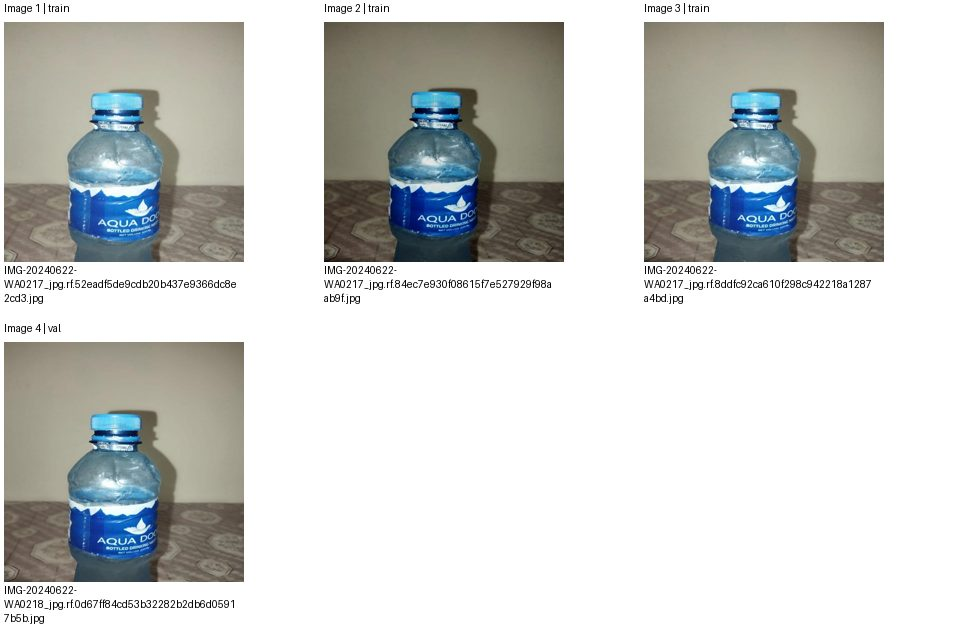

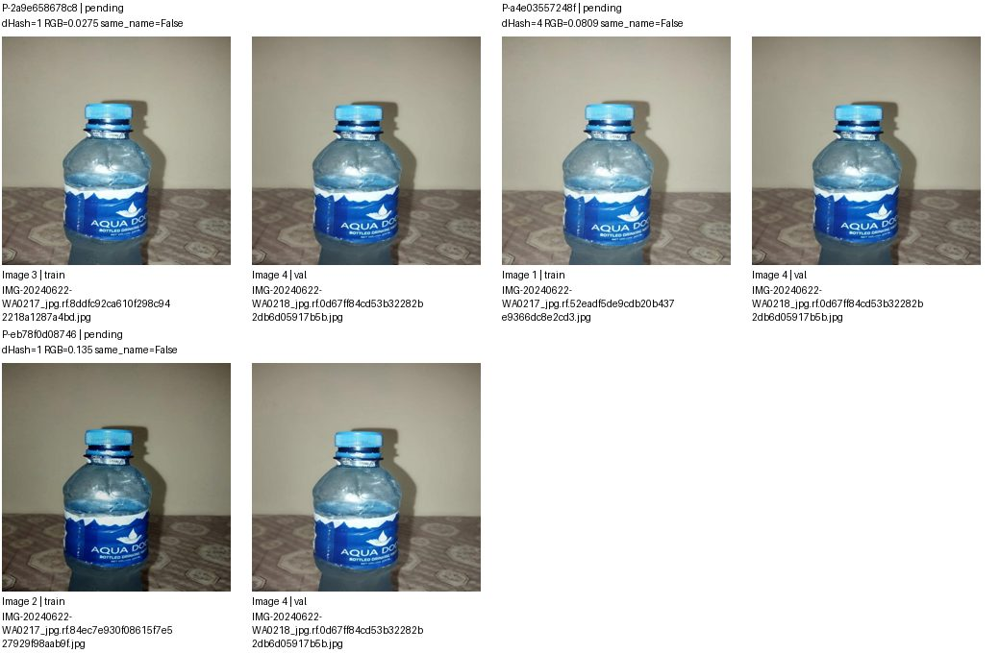

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-2a9e658678c8,images/train/IMG-20240622-WA0217_jpg.rf.8ddfc92ca610f298c942218a1287a4bd.jpg,images/val/IMG-20240622-WA0218_jpg.rf.0d67ff84cd53b32282b2db6d05917b5b.jpg,pending,
P-a4e03557248f,images/train/IMG-20240622-WA0217_jpg.rf.52eadf5de9cdb20b437e9366dc8e2cd3.jpg,images/val/IMG-20240622-WA0218_jpg.rf.0d67ff84cd53b32282b2db6d05917b5b.jpg,pending,
P-eb78f0d08746,images/train/IMG-20240622-WA0217_jpg.rf.84ec7e930f08615f7e527929f98aab9f.jpg,images/val/IMG-20240622-WA0218_jpg.rf.0d67ff84cd53b32282b2db6d05917b5b.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 149/166 G-a0e8f707221f | 2 ảnh, 1 cặp
Split: {'train': 1, 'val': 1}
Quyết định: {'pending': 1}
Ảnh trang 1/1; cặp trang 1/1. Nhóm liên thông không phải kết luận trùng.


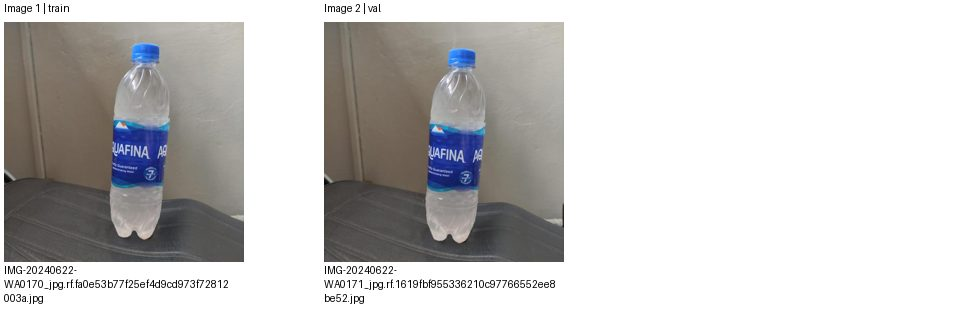

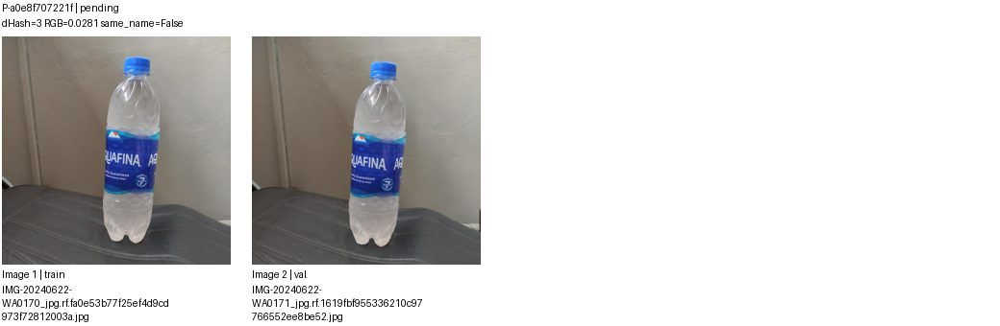

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-a0e8f707221f,images/train/IMG-20240622-WA0170_jpg.rf.fa0e53b77f25ef4d9cd973f72812003a.jpg,images/val/IMG-20240622-WA0171_jpg.rf.1619fbf955336210c97766552ee8be52.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 150/166 G-f1a582693e89 | 2 ảnh, 1 cặp
Split: {'train': 1, 'val': 1}
Quyết định: {'pending': 1}
Ảnh trang 1/1; cặp trang 1/1. Nhóm liên thông không phải kết luận trùng.


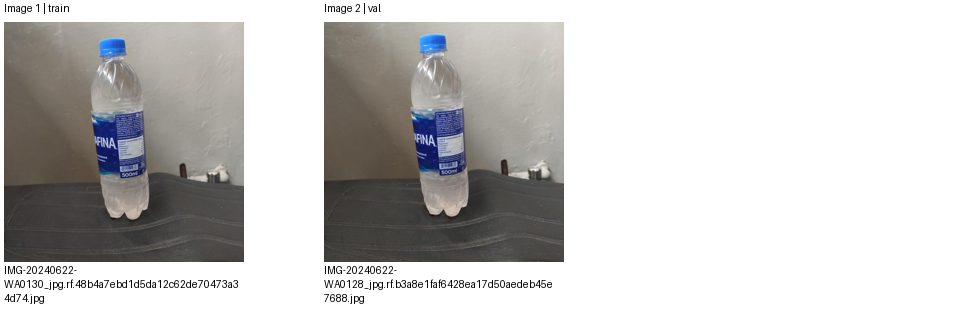

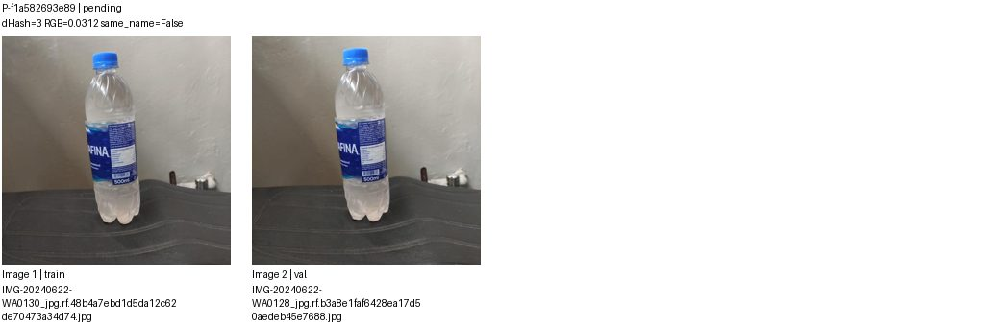

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-f1a582693e89,images/train/IMG-20240622-WA0130_jpg.rf.48b4a7ebd1d5da12c62de70473a34d74.jpg,images/val/IMG-20240622-WA0128_jpg.rf.b3a8e1faf6428ea17d50aedeb45e7688.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 151/166 G-6549a578d840 | 3 ảnh, 2 cặp
Split: {'test': 1, 'train': 2}
Quyết định: {'pending': 2}
Ảnh trang 1/1; cặp trang 1/1. Nhóm liên thông không phải kết luận trùng.


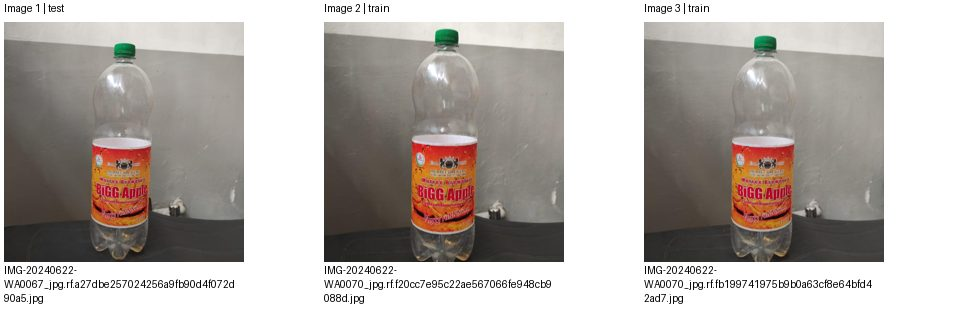

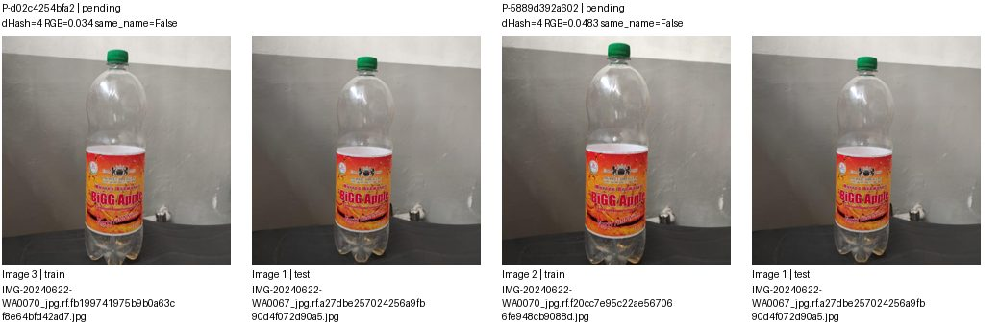

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-d02c4254bfa2,images/train/IMG-20240622-WA0070_jpg.rf.fb199741975b9b0a63cf8e64bfd42ad7.jpg,images/test/IMG-20240622-WA0067_jpg.rf.a27dbe257024256a9fb90d4f072d90a5.jpg,pending,
P-5889d392a602,images/train/IMG-20240622-WA0070_jpg.rf.f20cc7e95c22ae567066fe948cb9088d.jpg,images/test/IMG-20240622-WA0067_jpg.rf.a27dbe257024256a9fb90d4f072d90a5.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 152/166 G-182b0c8ef4b6 | 3 ảnh, 2 cặp
Split: {'test': 1, 'train': 2}
Quyết định: {'pending': 2}
Ảnh trang 1/1; cặp trang 1/1. Nhóm liên thông không phải kết luận trùng.


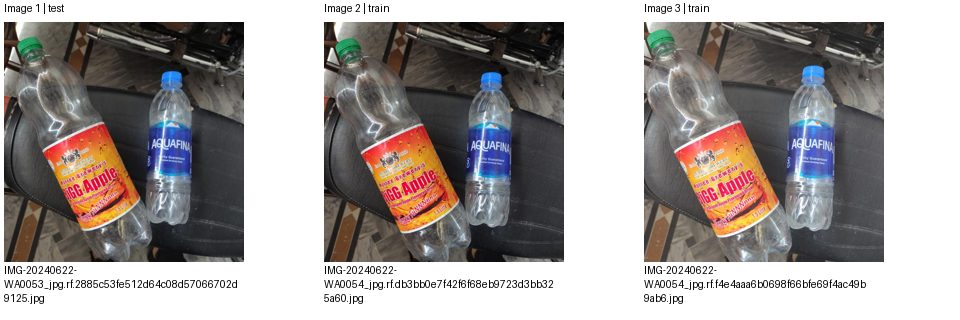

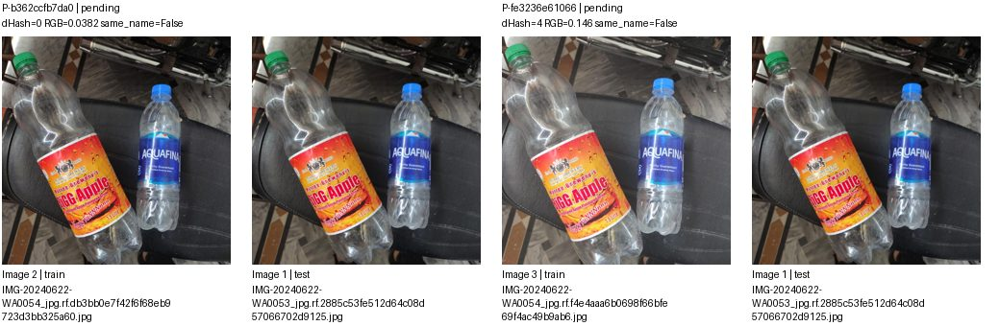

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-b362ccfb7da0,images/train/IMG-20240622-WA0054_jpg.rf.db3bb0e7f42f6f68eb9723d3bb325a60.jpg,images/test/IMG-20240622-WA0053_jpg.rf.2885c53fe512d64c08d57066702d9125.jpg,pending,
P-fe3236e61066,images/train/IMG-20240622-WA0054_jpg.rf.f4e4aaa6b0698f66bfe69f4ac49b9ab6.jpg,images/test/IMG-20240622-WA0053_jpg.rf.2885c53fe512d64c08d57066702d9125.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 153/166 G-84de771067e9 | 4 ảnh, 3 cặp
Split: {'test': 1, 'train': 3}
Quyết định: {'pending': 3}
Ảnh trang 1/1; cặp trang 1/1. Nhóm liên thông không phải kết luận trùng.


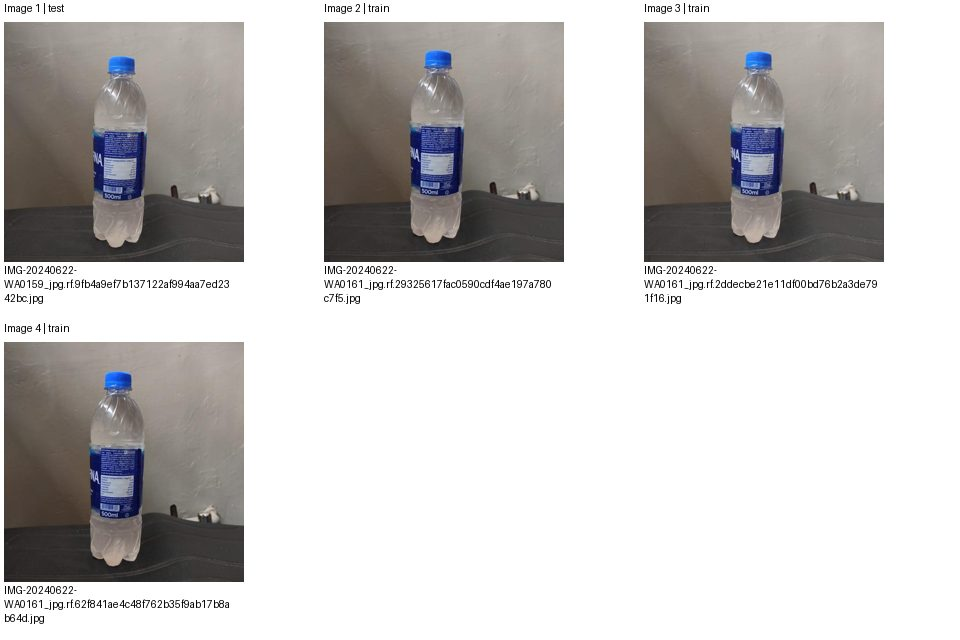

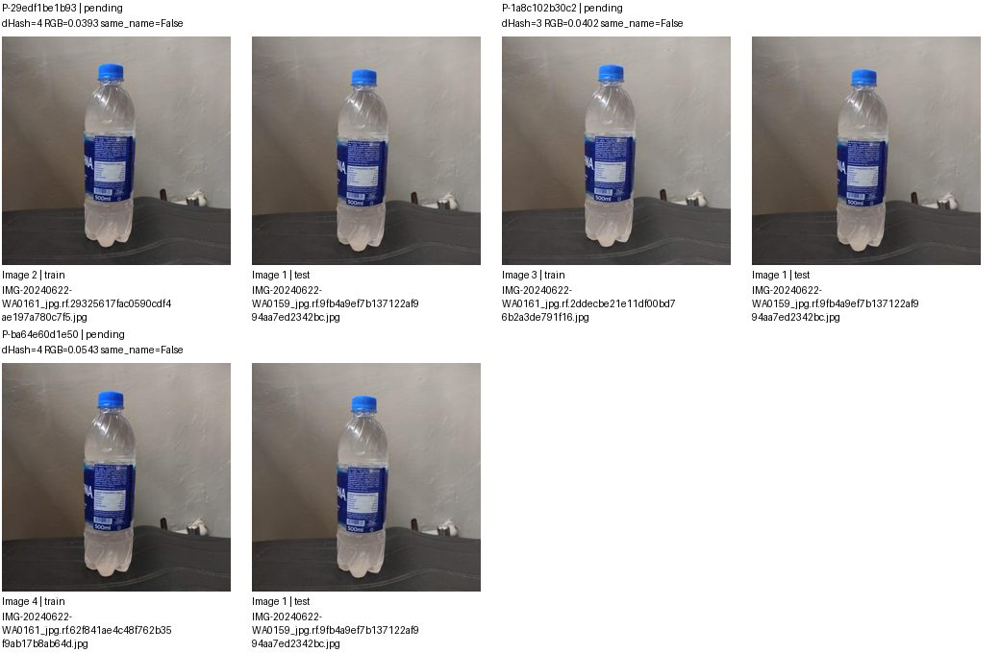

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-29edf1be1b93,images/train/IMG-20240622-WA0161_jpg.rf.29325617fac0590cdf4ae197a780c7f5.jpg,images/test/IMG-20240622-WA0159_jpg.rf.9fb4a9ef7b137122af994aa7ed2342bc.jpg,pending,
P-1a8c102b30c2,images/train/IMG-20240622-WA0161_jpg.rf.2ddecbe21e11df00bd76b2a3de791f16.jpg,images/test/IMG-20240622-WA0159_jpg.rf.9fb4a9ef7b137122af994aa7ed2342bc.jpg,pending,
P-ba64e60d1e50,images/train/IMG-20240622-WA0161_jpg.rf.62f841ae4c48f762b35f9ab17b8ab64d.jpg,images/test/IMG-20240622-WA0159_jpg.rf.9fb4a9ef7b137122af994aa7ed2342bc.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 154/166 G-9f9eef1a5340 | 5 ảnh, 4 cặp
Split: {'test': 1, 'train': 4}
Quyết định: {'pending': 4}
Ảnh trang 1/1; cặp trang 1/1. Nhóm liên thông không phải kết luận trùng.


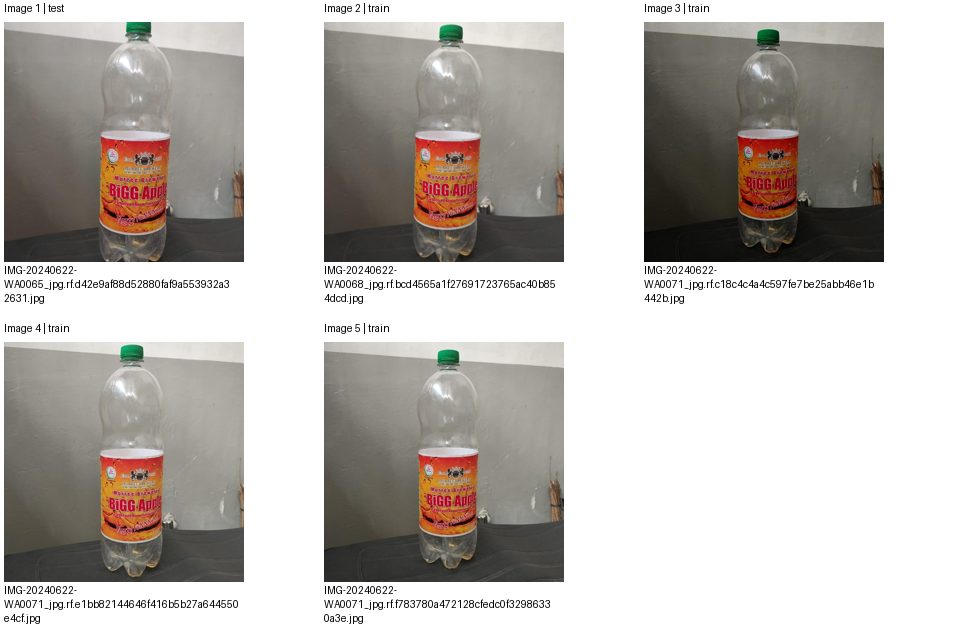

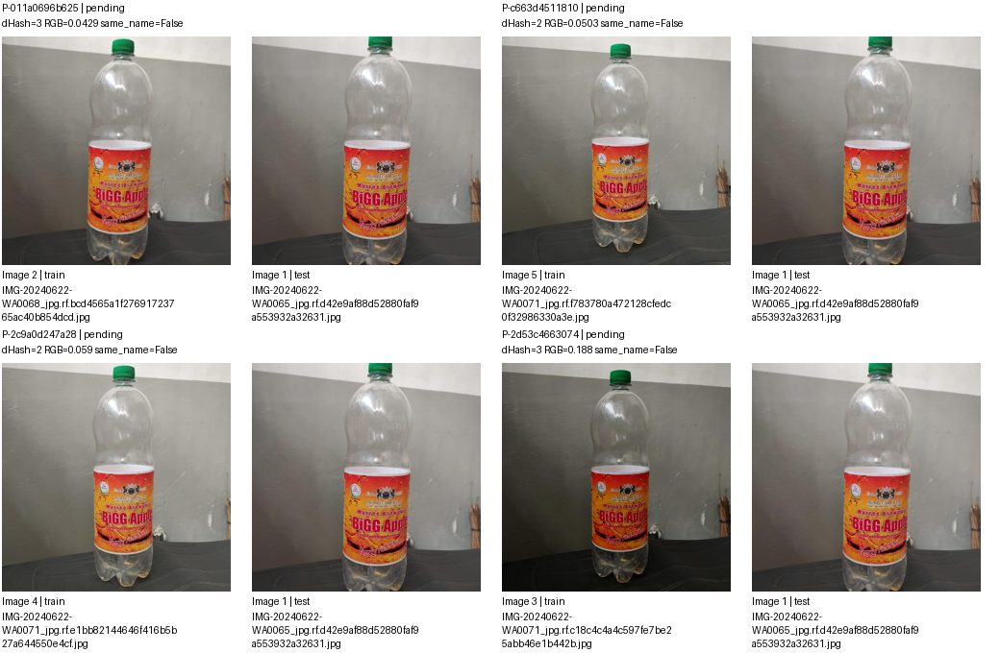

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-011a0696b625,images/train/IMG-20240622-WA0068_jpg.rf.bcd4565a1f27691723765ac40b854dcd.jpg,images/test/IMG-20240622-WA0065_jpg.rf.d42e9af88d52880faf9a553932a32631.jpg,pending,
P-c663d4511810,images/train/IMG-20240622-WA0071_jpg.rf.f783780a472128cfedc0f32986330a3e.jpg,images/test/IMG-20240622-WA0065_jpg.rf.d42e9af88d52880faf9a553932a32631.jpg,pending,
P-2c9a0d247a28,images/train/IMG-20240622-WA0071_jpg.rf.e1bb82144646f416b5b27a644550e4cf.jpg,images/test/IMG-20240622-WA0065_jpg.rf.d42e9af88d52880faf9a553932a32631.jpg,pending,
P-2d53c4663074,images/train/IMG-20240622-WA0071_jpg.rf.c18c4c4a4c597fe7be25abb46e1b442b.jpg,images/test/IMG-20240622-WA0065_jpg.rf.d42e9af88d52880faf9a553932a32631.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 155/166 G-fde57be98edc | 3 ảnh, 2 cặp
Split: {'test': 1, 'train': 2}
Quyết định: {'pending': 2}
Ảnh trang 1/1; cặp trang 1/1. Nhóm liên thông không phải kết luận trùng.


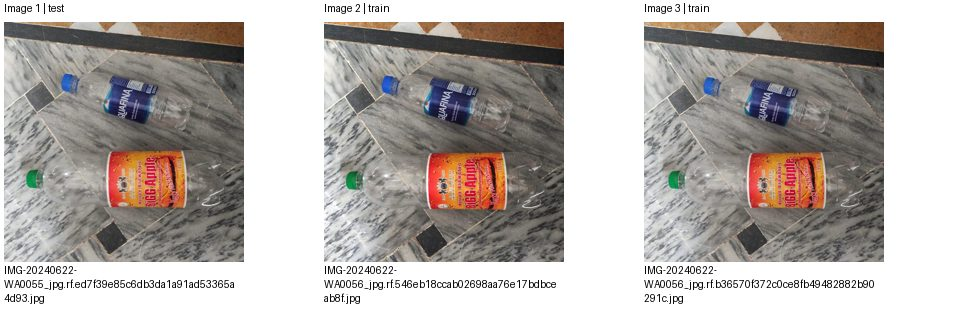

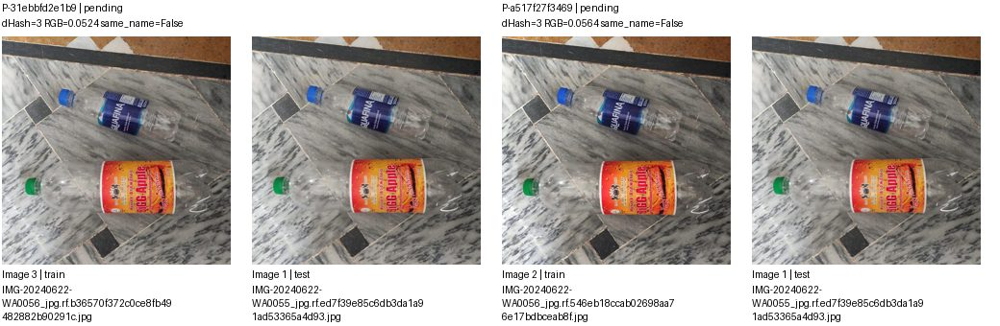

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-31ebbfd2e1b9,images/train/IMG-20240622-WA0056_jpg.rf.b36570f372c0ce8fb49482882b90291c.jpg,images/test/IMG-20240622-WA0055_jpg.rf.ed7f39e85c6db3da1a91ad53365a4d93.jpg,pending,
P-a517f27f3469,images/train/IMG-20240622-WA0056_jpg.rf.546eb18ccab02698aa76e17bdbceab8f.jpg,images/test/IMG-20240622-WA0055_jpg.rf.ed7f39e85c6db3da1a91ad53365a4d93.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 156/166 G-36872fe05f28 | 3 ảnh, 2 cặp
Split: {'test': 1, 'train': 2}
Quyết định: {'pending': 2}
Ảnh trang 1/1; cặp trang 1/1. Nhóm liên thông không phải kết luận trùng.


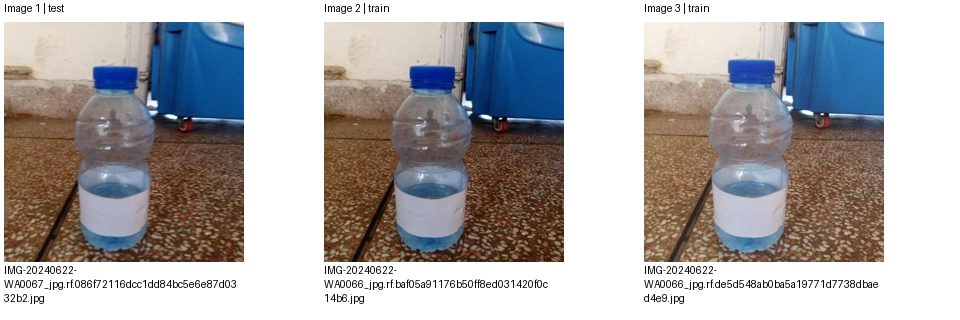

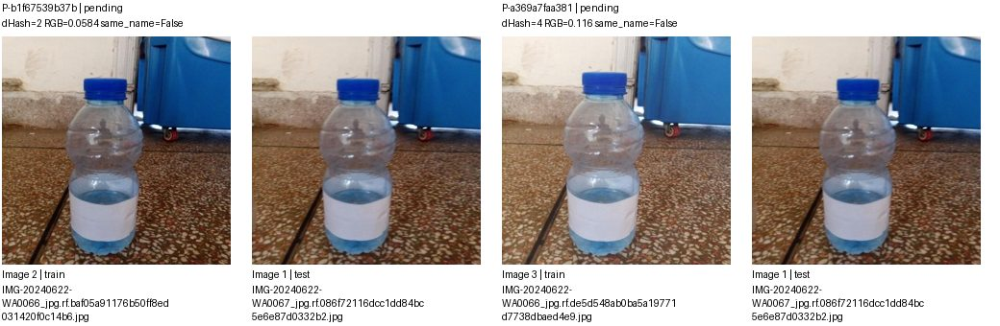

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-b1f67539b37b,images/train/IMG-20240622-WA0066_jpg.rf.baf05a91176b50ff8ed031420f0c14b6.jpg,images/test/IMG-20240622-WA0067_jpg.rf.086f72116dcc1dd84bc5e6e87d0332b2.jpg,pending,
P-a369a7faa381,images/train/IMG-20240622-WA0066_jpg.rf.de5d548ab0ba5a19771d7738dbaed4e9.jpg,images/test/IMG-20240622-WA0067_jpg.rf.086f72116dcc1dd84bc5e6e87d0332b2.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 157/166 G-65a5a188bea9 | 2 ảnh, 1 cặp
Split: {'train': 1, 'val': 1}
Quyết định: {'pending': 1}
Ảnh trang 1/1; cặp trang 1/1. Nhóm liên thông không phải kết luận trùng.


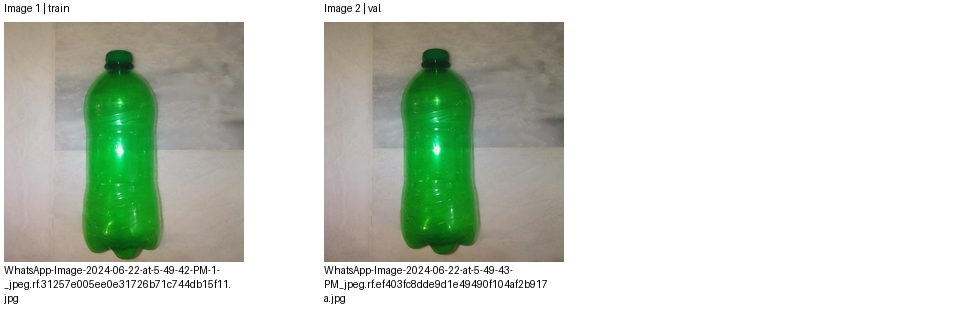

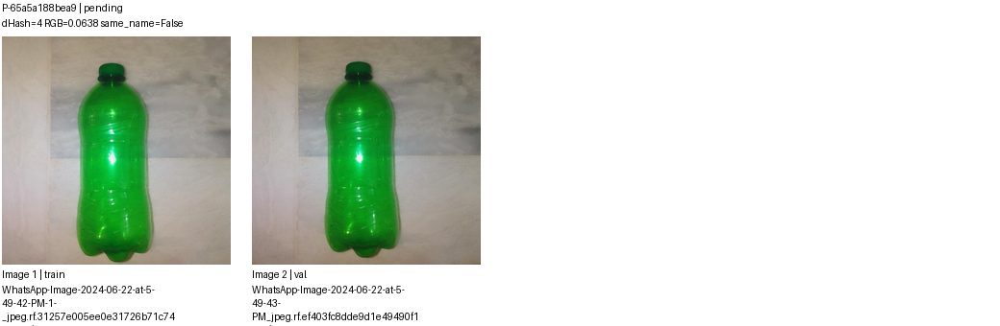

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-65a5a188bea9,images/train/WhatsApp-Image-2024-06-22-at-5-49-42-PM-1-_jpeg.rf.31257e005ee0e31726b71c744db15f11.jpg,images/val/WhatsApp-Image-2024-06-22-at-5-49-43-PM_jpeg.rf.ef403fc8dde9d1e49490f104af2b917a.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 158/166 G-e2efde55197e | 2 ảnh, 1 cặp
Split: {'train': 1, 'val': 1}
Quyết định: {'pending': 1}
Ảnh trang 1/1; cặp trang 1/1. Nhóm liên thông không phải kết luận trùng.


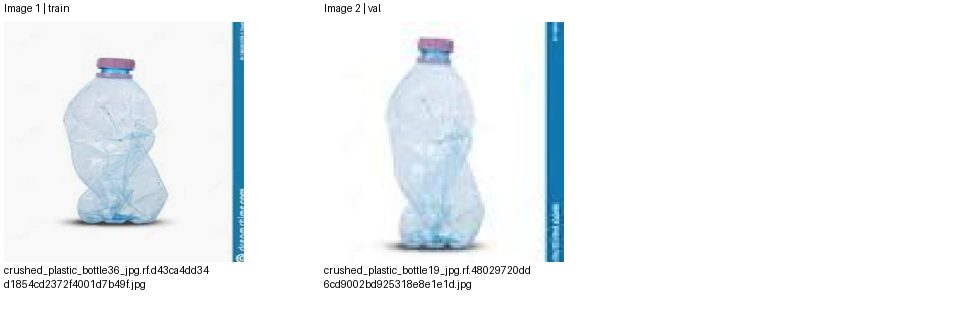

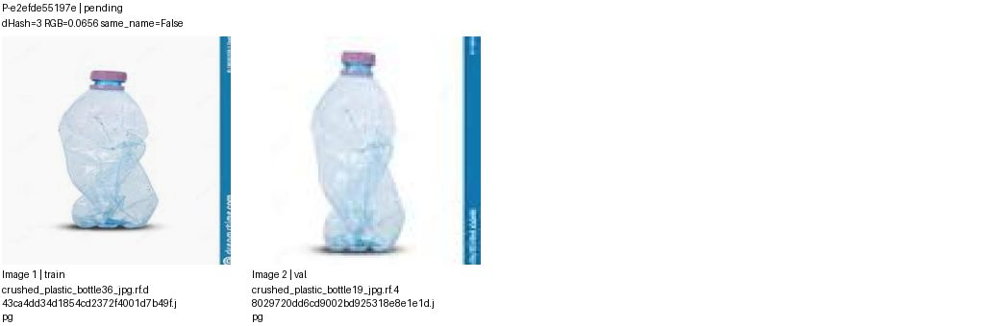

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-e2efde55197e,images/train/crushed_plastic_bottle36_jpg.rf.d43ca4dd34d1854cd2372f4001d7b49f.jpg,images/val/crushed_plastic_bottle19_jpg.rf.48029720dd6cd9002bd925318e8e1e1d.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 159/166 G-049da4c818e5 | 2 ảnh, 1 cặp
Split: {'train': 1, 'val': 1}
Quyết định: {'pending': 1}
Ảnh trang 1/1; cặp trang 1/1. Nhóm liên thông không phải kết luận trùng.


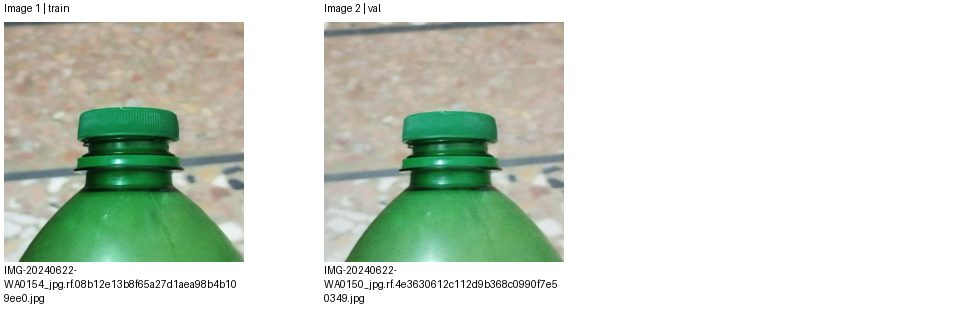

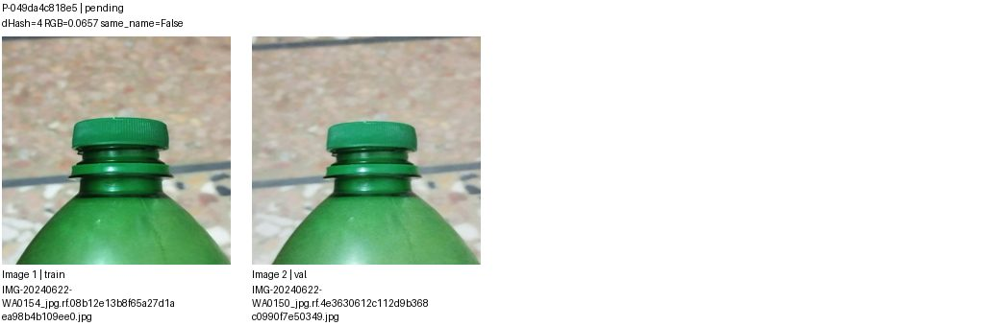

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-049da4c818e5,images/train/IMG-20240622-WA0154_jpg.rf.08b12e13b8f65a27d1aea98b4b109ee0.jpg,images/val/IMG-20240622-WA0150_jpg.rf.4e3630612c112d9b368c0990f7e50349.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 160/166 G-cb2e2709e384 | 2 ảnh, 1 cặp
Split: {'train': 1, 'val': 1}
Quyết định: {'pending': 1}
Ảnh trang 1/1; cặp trang 1/1. Nhóm liên thông không phải kết luận trùng.


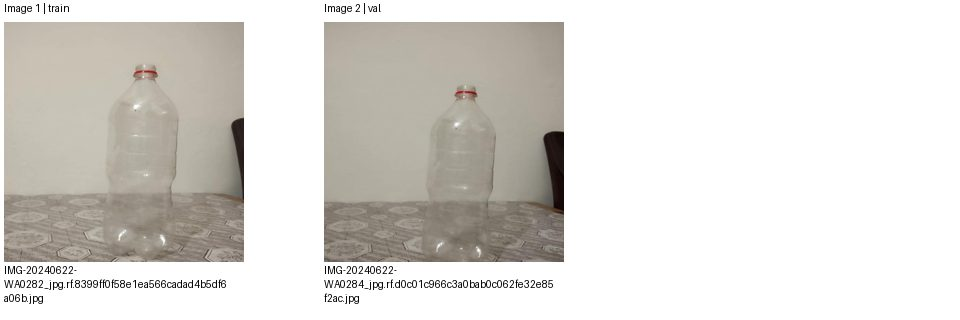

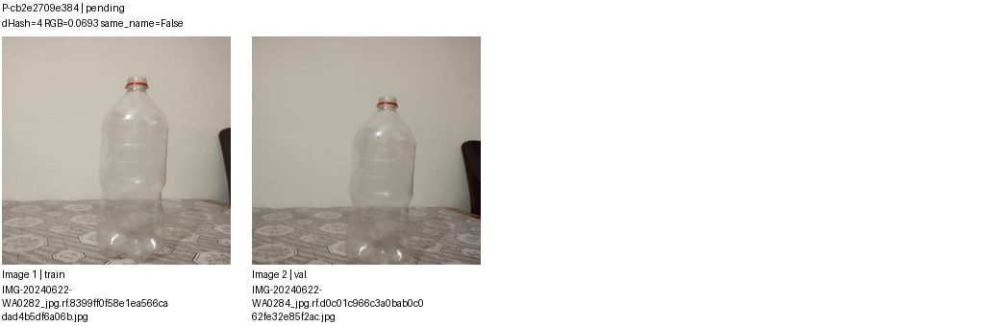

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-cb2e2709e384,images/train/IMG-20240622-WA0282_jpg.rf.8399ff0f58e1ea566cadad4b5df6a06b.jpg,images/val/IMG-20240622-WA0284_jpg.rf.d0c01c966c3a0bab0c062fe32e85f2ac.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 161/166 G-c15a8afa909a | 2 ảnh, 1 cặp
Split: {'train': 1, 'val': 1}
Quyết định: {'pending': 1}
Ảnh trang 1/1; cặp trang 1/1. Nhóm liên thông không phải kết luận trùng.


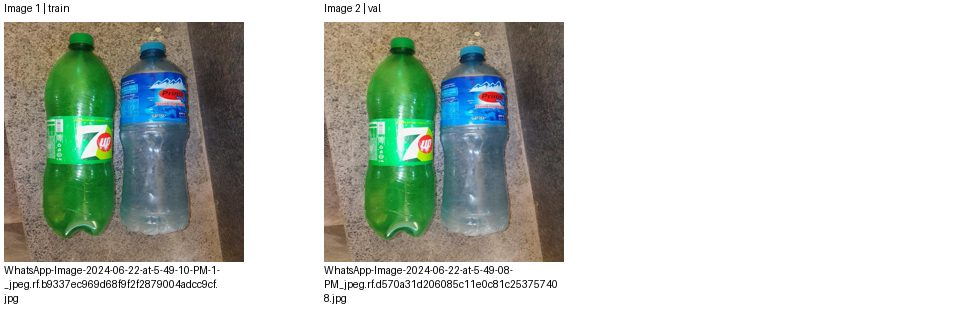

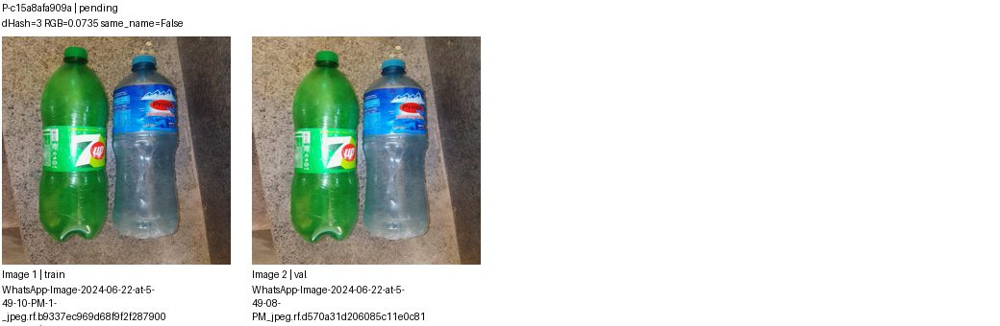

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-c15a8afa909a,images/train/WhatsApp-Image-2024-06-22-at-5-49-10-PM-1-_jpeg.rf.b9337ec969d68f9f2f2879004adcc9cf.jpg,images/val/WhatsApp-Image-2024-06-22-at-5-49-08-PM_jpeg.rf.d570a31d206085c11e0c81c253757408.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 162/166 G-a524b68487ab | 2 ảnh, 1 cặp
Split: {'train': 1, 'val': 1}
Quyết định: {'pending': 1}
Ảnh trang 1/1; cặp trang 1/1. Nhóm liên thông không phải kết luận trùng.


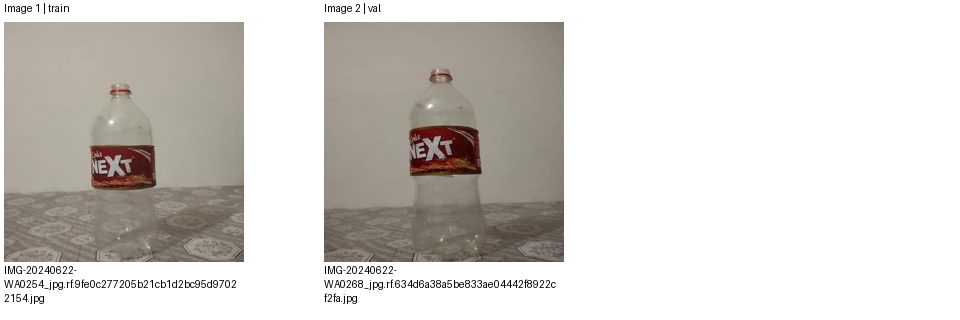

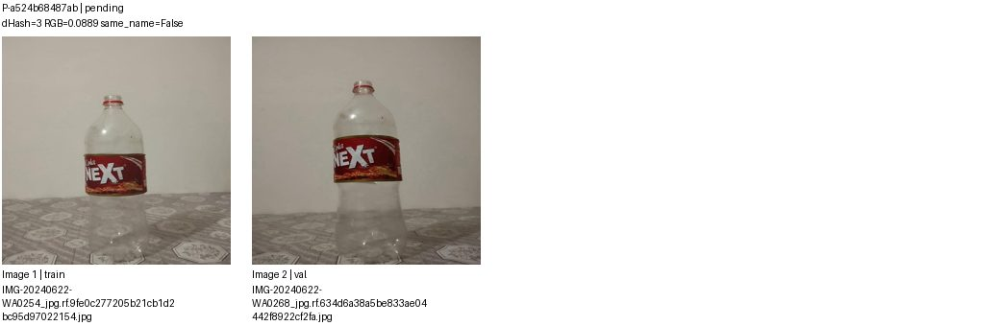

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-a524b68487ab,images/train/IMG-20240622-WA0254_jpg.rf.9fe0c277205b21cb1d2bc95d97022154.jpg,images/val/IMG-20240622-WA0268_jpg.rf.634d6a38a5be833ae04442f8922cf2fa.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 163/166 G-916dfb2c2043 | 2 ảnh, 1 cặp
Split: {'train': 1, 'val': 1}
Quyết định: {'pending': 1}
Ảnh trang 1/1; cặp trang 1/1. Nhóm liên thông không phải kết luận trùng.


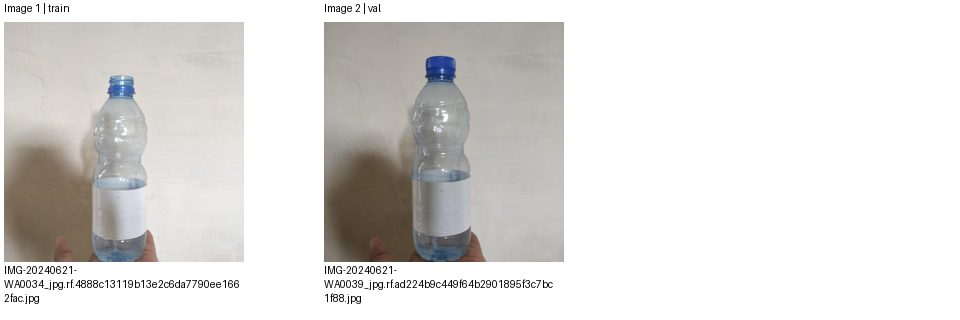

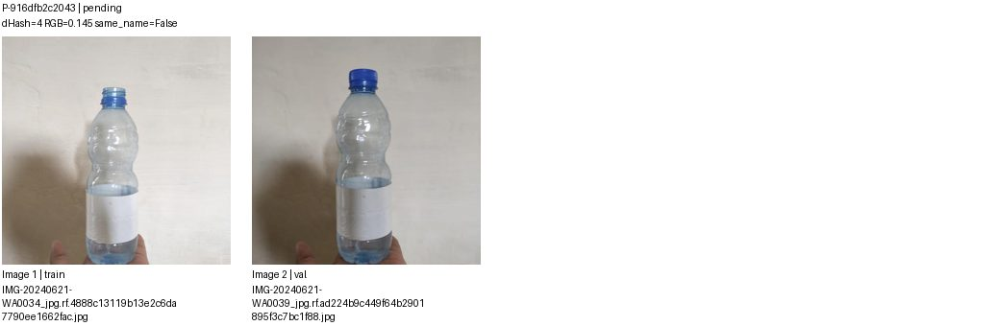

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-916dfb2c2043,images/train/IMG-20240621-WA0034_jpg.rf.4888c13119b13e2c6da7790ee1662fac.jpg,images/val/IMG-20240621-WA0039_jpg.rf.ad224b9c449f64b2901895f3c7bc1f88.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 164/166 G-bf6cb03fe95d | 2 ảnh, 1 cặp
Split: {'train': 1, 'val': 1}
Quyết định: {'pending': 1}
Ảnh trang 1/1; cặp trang 1/1. Nhóm liên thông không phải kết luận trùng.


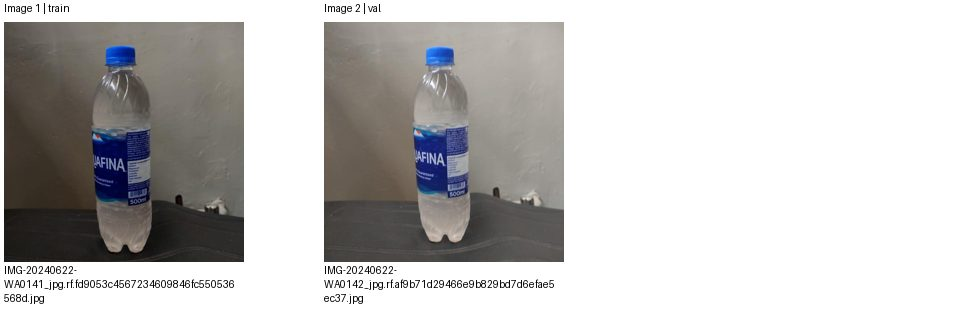

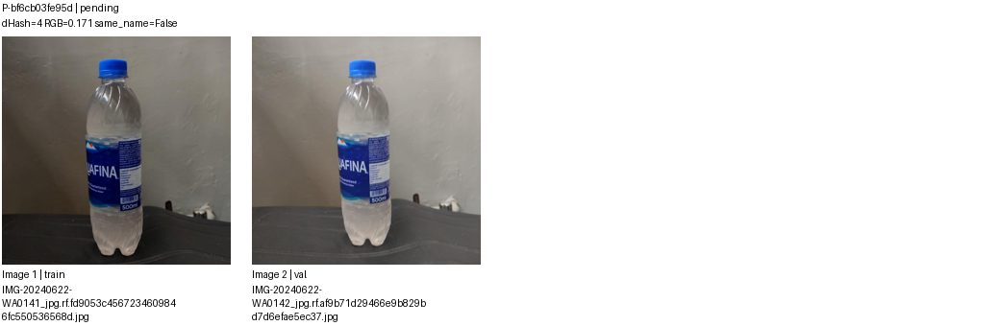

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-bf6cb03fe95d,images/train/IMG-20240622-WA0141_jpg.rf.fd9053c4567234609846fc550536568d.jpg,images/val/IMG-20240622-WA0142_jpg.rf.af9b71d29466e9b829bd7d6efae5ec37.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 165/166 G-2d748f09343d | 2 ảnh, 1 cặp
Split: {'train': 1, 'val': 1}
Quyết định: {'pending': 1}
Ảnh trang 1/1; cặp trang 1/1. Nhóm liên thông không phải kết luận trùng.


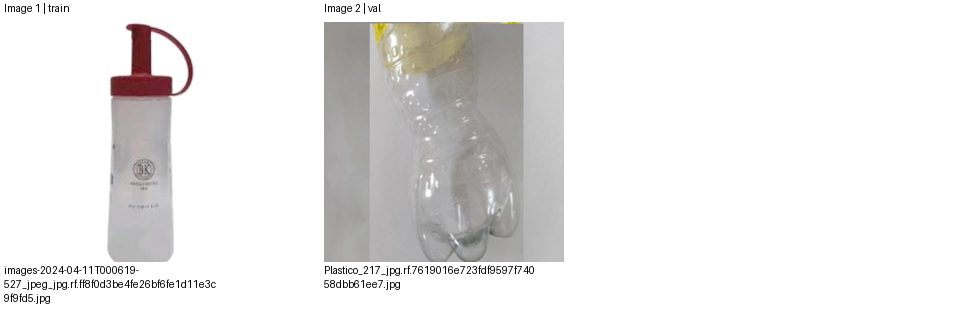

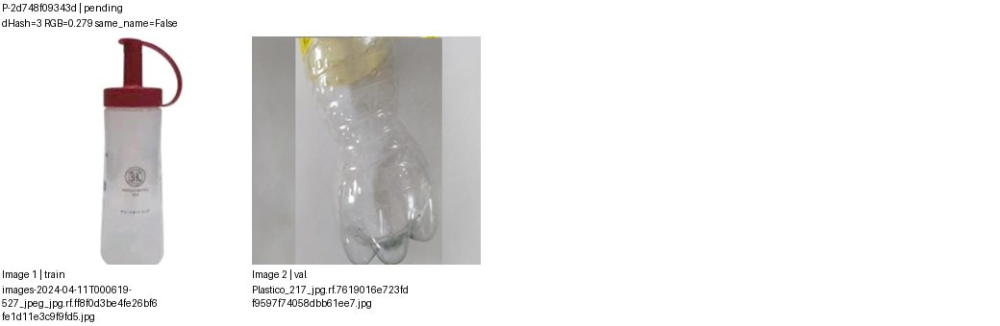

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-2d748f09343d,images/train/images-2024-04-11T000619-527_jpeg_jpg.rf.ff8f0d3be4fe26bf6fe1d11e3c9f9fd5.jpg,images/val/Plastico_217_jpg.rf.7619016e723fdf9597f74058dbb61ee7.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.


GROUP 166/166 G-3875aa49eb33 | 2 ảnh, 1 cặp
Split: {'train': 1, 'val': 1}
Quyết định: {'pending': 1}
Ảnh trang 1/1; cặp trang 1/1. Nhóm liên thông không phải kết luận trùng.


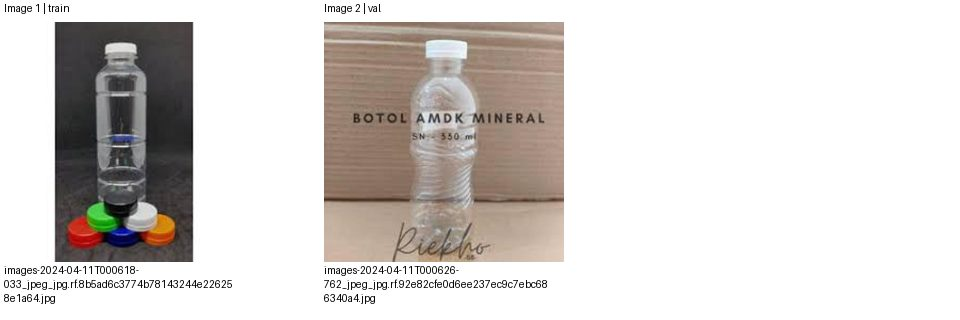

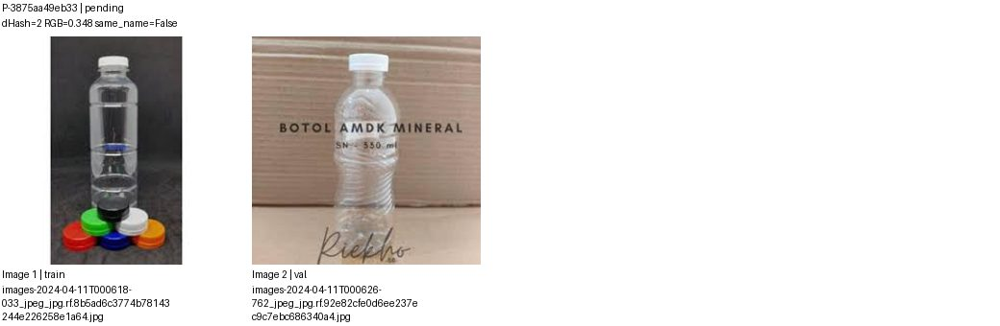

pair_id,Ảnh A,Ảnh B,Quyết định,Lý do
P-3875aa49eb33,images/train/images-2024-04-11T000618-033_jpeg_jpg.rf.8b5ad6c3774b78143244e226258e1a64.jpg,images/val/images-2024-04-11T000626-762_jpeg_jpg.rf.92e82cfe0d6ee237ec9c7ebc686340a4.jpg,pending,


Quyết định theo pair_id trong bảng CSV chung của 9B; 9C lưu cả lô.
ALL_GROUPS_EXPORTED: {"groups": 166, "images": 1084, "pairs": 2065, "image_pages": 255, "pair_pages": 589}
FULL_HTML_REPORT: /content/drive/MyDrive/BottleQC/datasets/industrial-watch-v2/20261102T070951Z-85f802/near-duplicate-all-groups-v1.html
BATCH_CSV: /content/drive/MyDrive/BottleQC/datasets/industrial-watch-v2/20261102T070951Z-85f802/near-duplicate-review-input-v1.csv
9B đã xuất hết. Điền CSV chung rồi chạy 9C một lần; chưa có quyết định mới được ghi.


In [9]:
require_cloud()
import base64
import io
from IPython.display import Image as DisplayImage

if not all(name in globals() for name in (
        "review_groups", "review_pairs", "review_fingerprint", "show_review_group")):
    raise RuntimeError("Chạy 9R nếu runtime mới, rồi chạy 9A trước 9B.")

BATCH_CSV = SAVED / "near-duplicate-review-input-v1.csv"
BATCH_FIELDS = ["fingerprint"] + PAIR_FIELDS + ["decision", "note"]


def read_review_batch(path):
    # Validate the complete file before 9C can write any decisions.
    updates, seen = {}, set()
    with path.open("r", encoding="utf-8-sig", newline="") as stream:
        reader = csv.DictReader(stream)
        if reader.fieldnames is None or set(reader.fieldnames) != set(BATCH_FIELDS) or len(reader.fieldnames) != len(BATCH_FIELDS):
            raise ValueError("CSV sai cột; dùng đúng bảng near-duplicate-review-input-v1.csv do 9B tạo.")
        for line, row in enumerate(reader, 2):
            pair_id = row.get("pair_id")
            if None in row or any(value is None for value in row.values()):
                raise ValueError(f"CSV dòng {line} sai số cột.")
            if pair_id not in review_pairs or pair_id in seen:
                raise ValueError(f"CSV dòng {line}: mã cặp lạ hoặc bị lặp: {pair_id}")
            seen.add(pair_id)
            pair = review_pairs[pair_id]
            numeric_fields = {"group_number", "dhash_distance", "rgb_mean_absolute_difference"}
            exact_fields = set(PAIR_FIELDS) - numeric_fields - {"same_source_key"}
            try:
                numbers_match = all(math.isclose(float(row[key]), float(pair[key]), rel_tol=1e-12, abs_tol=1e-12)
                                    for key in numeric_fields)
            except ValueError:
                numbers_match = False
            # Spreadsheet CSV exports may uppercase booleans or reformat numbers.
            if (row["fingerprint"] != review_fingerprint
                    or any(row[key] != str(pair[key]) for key in exact_fields)
                    or row["same_source_key"].lower() != str(pair["same_source_key"]).lower()
                    or not numbers_match):
                raise ValueError(f"CSV dòng {line}: candidate/danh sách cặp khác hoặc cột định danh bị sửa.")
            decision, note = row["decision"].strip(), row["note"].strip()
            if decision in {"", "pending"}:
                if note:
                    raise ValueError(f"CSV dòng {line}: đã ghi note nhưng chưa chọn decision.")
                continue
            if decision not in REVIEW_CHOICES or not note:
                raise ValueError(f"CSV dòng {line}: cần duplicate/different/unsure và note không rỗng.")
            updates[pair_id] = {"decision": decision, "note": note}
    if seen != set(review_pairs):
        raise ValueError(f"CSV thiếu {len(set(review_pairs) - seen)} cặp; không lưu một bảng bị mất dòng.")
    return updates


decisions_for_report = load_review_decisions()
if BATCH_CSV.exists():
    batch_updates = read_review_batch(BATCH_CSV)
    print("BATCH_CSV_KEPT:", BATCH_CSV, "| Đã nhập:", len(batch_updates), "cặp; chưa áp dụng.")
else:
    write_review_csv(BATCH_CSV, BATCH_FIELDS, (
        {"fingerprint": review_fingerprint, **{key: pair[key] for key in PAIR_FIELDS},
         "decision": decisions_for_report.get(pair["pair_id"], {}).get("decision", "pending"),
         "note": decisions_for_report.get(pair["pair_id"], {}).get("note", "")}
        for group in review_groups for pair in group["pairs"]))
    print("BATCH_CSV_CREATED:", BATCH_CSV)


def export_all_review_groups():
    require_cloud()
    report = SAVED / "near-duplicate-all-groups-v1.html"
    temporary = report.with_name(report.name + ".tmp")
    image_count = pair_count = image_pages_done = pair_pages_done = 0
    with temporary.open("w", encoding="utf-8") as stream:
        stream.write('<!doctype html><html lang="vi"><meta charset="utf-8">'
                     '<meta name="viewport" content="width=device-width,initial-scale=1">'
                     '<title>BottleQC — toàn bộ ứng viên gần trùng</title>'
                     '<style>body{font-family:system-ui;margin:24px;line-height:1.5}'
                     'img{max-width:100%;height:auto}table{border-collapse:collapse;width:100%;margin:16px 0}'
                     'td,th{border:1px solid #aaa;padding:6px;text-align:left;overflow-wrap:anywhere}'
                     'h2{border-top:2px solid #555;padding-top:20px}nav a{display:inline-block;margin:4px 10px}</style><body>')
        stream.write('<h1>Toàn bộ ứng viên gần trùng</h1><p>Nhóm liên thông chỉ hỗ trợ duyệt; '
                     'không tự xác nhận trùng. Split cleaning: NOT_APPLIED.</p>')
        stream.write('<p>Fingerprint: <code>' + html.escape(review_fingerprint) + '</code></p>')
        stream.write('<p>Quyết định là ảnh chụp tại thời điểm xuất báo cáo; CSV nhập riêng, 9C lưu lên Drive.</p><nav>')
        for group in review_groups:
            number = group["group_number"]
            stream.write(f'<a href="#group-{number}">Nhóm {number}</a>')
        stream.write('</nav>')

        def emit_report(item):
            if isinstance(item, Image.Image):
                buffer = io.BytesIO()
                item.save(buffer, format="JPEG", quality=82, optimize=True)
                data = buffer.getvalue()
                encoded = base64.b64encode(data).decode("ascii")
                stream.write('<img alt="Trang ảnh/cặp ứng viên" loading="lazy" src="data:image/jpeg;base64,' + encoded + '">')
                display(DisplayImage(data=data, format="jpeg"))
            else:
                stream.write(item.data)
                display(item)

        for group in review_groups:
            number = group["group_number"]
            heading = (f"Nhóm {number}/{len(review_groups)} — {group['group_id']} | "
                       f"{len(group['members'])} ảnh, {len(group['pairs'])} cặp")
            emit_report(HTML(f'<h2 id="group-{number}">{html.escape(heading)}</h2>'))
            # Each image page and pair page is emitted exactly once, including tail pages.
            image_pages = math.ceil(len(group["members"]) / 6)
            pair_pages = math.ceil(len(group["pairs"]) / 4)
            for page in range(1, max(image_pages, pair_pages) + 1):
                image_page = page if page <= image_pages else None
                pair_page = page if page <= pair_pages else None
                emit_report(HTML(f'<h3>Trang {page} | ảnh {image_page or "—"}/{image_pages}; '
                                 f'cặp {pair_page or "—"}/{pair_pages}</h3>'))
                show_review_group(number, image_page=image_page, pair_page=pair_page,
                                  decisions=decisions_for_report, emit=emit_report)
            image_count += len(group["members"])
            pair_count += len(group["pairs"])
            image_pages_done += image_pages
            pair_pages_done += pair_pages
        if image_count != len(review_images) or pair_count != len(review_pairs):
            raise RuntimeError("Số ảnh/cặp đã xuất không khớp; chưa công bố báo cáo hoàn tất.")
        summary = {"groups": len(review_groups), "images": image_count, "pairs": pair_count,
                   "image_pages": image_pages_done, "pair_pages": pair_pages_done}
        stream.write('<h2>Xuất hoàn tất</h2><pre>' + html.escape(json.dumps(summary, indent=2)) + '</pre></body></html>')
    temporary.replace(report)
    print("ALL_GROUPS_EXPORTED:", json.dumps(summary, ensure_ascii=False))
    print("FULL_HTML_REPORT:", report)
    print("BATCH_CSV:", BATCH_CSV)
    print("9B đã xuất hết. Điền CSV chung rồi chạy 9C một lần; chưa có quyết định mới được ghi.")


export_all_review_groups()


### 9C. Lưu kết quả preview đã chuẩn bị — chạy một lần

**Đã nhúng sẵn gói quyết định cho đủ 2.065 cặp từ output 9B đã lưu. Không phải nhập CSV hay đổi từng group.**
Chỉ chạy **cell 9C này** trong kernel vừa chạy 9A/9B, rồi Ctrl+S. Không cần xuất lại 9B.

Kết quả lượt preview: **327 duplicate, 353 different, 1385 unsure**.
Đã xem toàn bộ ảnh thành viên qua gallery và kiểm tra một số trang cặp gốc. Đây là lượt xem preview, **chưa phải kiểm tra ảnh gốc ở độ phân giải đầy đủ cho mọi cặp**. Những cặp chưa đủ bằng chứng vẫn `unsure` và tiếp tục tính unresolved. Các cảnh chụp liên tiếp cùng chai/nền cần kiểm tra quan hệ nguồn/capture, kể cả khi hai ảnh khác nhau.

Cell kiểm tra đủ mã cặp/đường dẫn, đúng thư mục candidate, lựa chọn/lý do và tổng số trước khi lưu. Quyết định đã ghi được giữ lại; nếu có sửa tay hoặc CSV đã điền thì CSV được ưu tiên. CSV đầu vào đang nhập dở không bị ghi đè. Kết quả đầy đủ nằm ở `near-duplicate-decisions-v1.csv/json`; `near-duplicate-unresolved-v1.csv` chỉ liệt kê những cặp còn cần xử lý. Gói bằng chứng cũng được lưu vào Drive cùng fingerprint hiện tại.

5 mục nhập cũ đã được đối chiếu và bao gồm trong gói mới. Bản code nhập trùng lặp đã được dọn khỏi repo sau khi tích hợp; không cần dùng lại. Không tự xác nhận từ dHash, tên file hay quan hệ bắc cầu. Cell không chọn ảnh để loại/chuyển split và không train.


In [10]:
require_cloud()
import base64
import gzip

# Saved visual review, revision saved-preview-2026-11-03-v1.
# These are explicit per-pair observations, NOT decisions computed from similarity scores.
# Conservative scope: all member previews screened + selected full pair sheets.
# Unsure comparisons remain unresolved. No image, label, split or candidate is changed.
# Prepared choices: {"different": 353, "duplicate": 327, "unsure": 1385}
PREVIEW_PACK_SHA256 = 'e8d94b91dd3e1f4a7506f40b5d80b676b710abfb07dba1c08693947f7ad01e0e'
PREVIEW_PACK_BASE64 = (
    '...'
    '/j+0R8tH+z8UAA=='
)

preview_bytes = gzip.decompress(base64.b64decode(PREVIEW_PACK_BASE64, validate=True))
if hashlib.sha256(preview_bytes).hexdigest() != PREVIEW_PACK_SHA256:
    raise RuntimeError("Gói quyết định preview bị thay đổi hoặc chép thiếu; chưa lưu gì.")
PREVIEW_REVIEW_PACK = json.loads(preview_bytes)


def validate_preview_review(pack):
    """Bind explicit saved-preview choices to the complete current pair/path list."""
    if pack.get("schema") != 1 or pack.get("candidate_run_id") != SAVED.name:
        raise ValueError("Gói preview thuộc candidate khác; không lưu.")
    identities = sorted([[pair_id, pair["a"], pair["b"]] for pair_id, pair in review_pairs.items()])
    digest = hashlib.sha256(json.dumps(identities, ensure_ascii=True, separators=(",", ":")).encode()).hexdigest()
    if pack.get("pair_identity_sha256") != digest or pack.get("pair_count") != len(review_pairs):
        raise ValueError("Danh sách mã cặp/đường dẫn khác output 9B đã xem; không lưu.")
    rows = pack.get("decisions")
    if not isinstance(rows, list) or len(rows) != len(review_pairs):
        raise ValueError("Gói preview thiếu/thừa quyết định.")
    updates = {}
    for row in rows:
        pair_id = row.get("pair_id")
        if pair_id not in review_pairs or pair_id in updates:
            raise ValueError("Gói preview có mã lạ hoặc bị lặp: " + str(pair_id))
        pair = review_pairs[pair_id]
        if row.get("a") != pair["a"] or row.get("b") != pair["b"] or row.get("group_number") != pair["group_number"]:
            raise ValueError("Gói preview khác ảnh/nhóm hiện tại: " + pair_id)
        if (row.get("decision") not in REVIEW_CHOICES or not isinstance(row.get("note"), str)
                or not row["note"].strip()):
            raise ValueError("Gói preview thiếu quyết định/lý do hợp lệ: " + pair_id)
        updates[pair_id] = {"decision": row["decision"], "note": row["note"].strip()}
    if set(updates) != set(review_pairs):
        raise ValueError("Gói preview không bao phủ đúng toàn bộ cặp.")
    if dict(Counter(entry["decision"] for entry in updates.values())) != pack.get("summary"):
        raise ValueError("Tổng quyết định preview không khớp nội dung.")
    return updates


def apply_prepared_review(preview_pack=None):
    require_cloud()
    if not all(name in globals() for name in ("read_review_batch", "BATCH_CSV")):
        raise RuntimeError("Cần trạng thái 9A/9B. Runtime mới: mount Drive, chạy 9R → 9A → 9B.")
    # Validate both complete inputs before any durable write, even when existing state wins.
    proposed = validate_preview_review(preview_pack) if preview_pack is not None else {}
    csv_updates = read_review_batch(BATCH_CSV)
    existing = load_review_decisions()
    # Preserve recorded decisions and notes. Explicit CSV edits can correct them later.
    updates = {pair_id: entry for pair_id, entry in proposed.items() if pair_id not in existing}
    # Optional manual corrections kept in an already-running kernel; CSV takes precedence.
    manual = globals().get("REVIEW_UPDATES", {})
    if not isinstance(manual, dict):
        raise ValueError("REVIEW_UPDATES phải là dict; dùng {} nếu không nhập tay.")
    for pair_id, entry in manual.items():
        if (pair_id not in review_pairs or not isinstance(entry, dict)
                or set(entry) != {"decision", "note"} or entry["decision"] not in REVIEW_CHOICES
                or not isinstance(entry["note"], str) or not entry["note"].strip()):
            raise ValueError("Mục nhập tay không hợp lệ: " + str(pair_id))
    updates.update(manual)
    updates.update(csv_updates)
    changes = {pair_id: entry for pair_id, entry in updates.items()
               if existing.get(pair_id, {}).get("decision") != entry["decision"]
               or existing.get(pair_id, {}).get("note") != entry["note"].strip()}
    print("PREVIEW_REVIEW_CHOICES:", dict(Counter(entry["decision"] for entry in proposed.values())))
    print("EXISTING_RECORDED:", len(existing), "| CSV:", len(csv_updates), "| CHANGES:", len(changes))
    save_review_decisions(changes)
    saved = load_review_decisions()
    if preview_pack is not None:
        # Archive the exact prepared input plus runtime binding; preserve input CSV drafts.
        write_review_json(SAVED / (preview_pack["revision"] + ".json"), {
            **preview_pack, "runtime_fingerprint": review_fingerprint, "candidate_sha256": candidate_sha,
            "application": "Fill unrecorded pairs; preserve existing entries; explicit CSV/manual corrections take precedence",
            "applied_progress": review_progress(saved)})
    unresolved = [pair for pair_id, pair in review_pairs.items()
                  if saved.get(pair_id, {}).get("decision", "pending") in {"pending", "unsure"}]
    write_review_csv(SAVED / "near-duplicate-unresolved-v1.csv", PAIR_FIELDS + ["decision", "note"], (
        {**{key: pair[key] for key in PAIR_FIELDS},
         "decision": saved.get(pair["pair_id"], {}).get("decision", "pending"),
         "note": saved.get(pair["pair_id"], {}).get("note", "")}
        for pair in unresolved))
    print("REVIEW_BATCH_SAVED | unresolved:", len(unresolved))
    print("DECISION_TABLE:", SAVED / "near-duplicate-decisions-v1.csv")
    print("UNRESOLVED_TABLE:", SAVED / "near-duplicate-unresolved-v1.csv")
    print("Chưa áp dụng cleaning; unsure vẫn unresolved. Chưa dùng candidate này để training.")


# Run this cell once. The reviewed pack is embedded; no CSV upload/edit is required.
apply_prepared_review(PREVIEW_REVIEW_PACK)


PREVIEW_REVIEW_CHOICES: {'duplicate': 327, 'unsure': 1385, 'different': 353}
EXISTING_RECORDED: 3 | CSV: 3 | CHANGES: 2062
{
  "pairs": 2065,
  "images": 1084,
  "groups": 166,
  "pending": 0,
  "duplicate": 327,
  "different": 353,
  "unsure": 1385,
  "unresolved": 1385,
  "split_cleaning": "NOT_APPLIED"
}
DECISIONS_SAVED: /content/drive/MyDrive/BottleQC/datasets/industrial-watch-v2/20261102T070951Z-85f802/near-duplicate-decisions-v1.json
Chỉ ghi kết quả duyệt; candidate và các split chưa thay đổi.
REVIEW_BATCH_SAVED | unresolved: 1385
DECISION_TABLE: /content/drive/MyDrive/BottleQC/datasets/industrial-watch-v2/20261102T070951Z-85f802/near-duplicate-decisions-v1.csv
UNRESOLVED_TABLE: /content/drive/MyDrive/BottleQC/datasets/industrial-watch-v2/20261102T070951Z-85f802/near-duplicate-unresolved-v1.csv
Chưa áp dụng cleaning; unsure vẫn unresolved. Chưa dùng candidate này để training.


### 9D. Tạo candidate mới theo nhóm split — chạy một lần sau 9C

Ưu tiên **test → val → train**: mỗi nhóm liên thông từ các cặp `duplicate` hoặc `unsure` chỉ giữ ảnh trong split có ưu tiên cao nhất của nhóm. Các cặp `different` không nối nhóm. Nhóm này là đơn vị chặn rò rỉ thận trọng, **không phải kết luận mọi ảnh cùng nguồn hay trùng nhau**. `unsure` vẫn là chưa rõ trong lịch sử quyết định. Phương án có thể loại cả ảnh chưa xác nhận trùng khỏi candidate mới.

Với bảng 9C hiện tại, dự kiến loại **705 train + 95 val**, còn **3849 train / 307 val / 201 test**. Số thực tế được tính lại từ ZIP và quyết định trên Drive. Cell kiểm tra ảnh/nhãn, ba lớp, số box theo split, trùng pixel và tính lại toàn bộ cảnh báo dHash của bản còn giữ. Không huấn luyện.

Candidate mới được lưu dưới thư mục `split-candidates/test-val-train-...` của bản hiện tại trên Drive. Ảnh và nhãn còn giữ được chép nguyên byte từ ZIP nguồn đã kiểm checksum; ZIP cũ, quyết định review và bản `/content` cũ không bị sửa. `COMPLETE.json` chỉ ghi khi ZIP mới đã kiểm CRC và SHA-256 trên Drive. Chạy lại cùng đầu vào sẽ xác minh rồi dùng lại bản hoàn tất. Lần bị ngắt có thể chạy lại.

Chạy **9D một lần rồi Ctrl+S**. Đọc `SPLIT_CANDIDATE_SAVED` (hoặc `REUSED`), `retained_counts`, `retained_boxes`, `new_dhash_candidate_pairs` và `training_readiness`. Kết quả này chưa chứng minh độc lập giữa các đợt chụp hoặc đúng hết nhãn; cần xem báo cáo trước training. `data.yaml` trong ZIP dùng đường dẫn tương đối; khi giải nén cho training phải cập nhật `path` sang thư mục runtime thật.


In [11]:
require_cloud()
import csv
import hashlib
import io
import json
import math
import shutil
import stat
import zipfile
from collections import Counter, defaultdict
from pathlib import Path, PurePosixPath
from PIL import Image
import yaml


def split_candidate_sha(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()


def plan_split_blocks(pairs, decisions, priority=("test", "val", "train")):
    if set(priority) != {"train", "val", "test"} or len(priority) != 3:
        raise ValueError("Ưu tiên split không hợp lệ.")
    if set(decisions) != set(pairs):
        raise ValueError("Chạy 9C: cần ghi quyết định cho đủ danh sách cặp.")
    adjacency = defaultdict(set)
    for pair_id, pair in pairs.items():
        decision = decisions[pair_id]["decision"]
        if decision not in {"duplicate", "different", "unsure"}:
            raise ValueError("Quyết định chưa hợp lệ: " + pair_id)
        if decision in {"duplicate", "unsure"}:
            adjacency[pair["a"]].add(pair["b"])
            adjacency[pair["b"]].add(pair["a"])
    visited, blocks, exclusions = set(), [], {}
    for seed in sorted(adjacency):
        if seed in visited:
            continue
        visited.add(seed)
        stack, members = [seed], []
        while stack:
            name = stack.pop()
            members.append(name)
            for neighbour in adjacency[name]:
                if neighbour not in visited:
                    visited.add(neighbour)
                    stack.append(neighbour)
        members.sort()
        splits = {name.split("/")[1] for name in members}
        keep_split = next(split for split in priority if split in splits)
        block_id = "B-" + hashlib.sha256(json.dumps(members).encode()).hexdigest()[:16]
        blocks.append({"block_id": block_id, "members": members, "keep_split": keep_split})
        retained = [name for name in members if name.split("/")[1] == keep_split]
        for name in members:
            if name.split("/")[1] != keep_split:
                exclusions[name] = {"image": name, "block_id": block_id,
                                    "keep_split": keep_split, "retained_members": retained,
                                    "reason": "conservative_split_block_duplicate_or_unsure"}
    return {"policy": "conservative-split-blocks-v1", "priority": list(priority),
            "meaning": "Split-blocking units from duplicate+unsure edges, NOT confirmed duplicate/source groups",
            "blocks": blocks, "exclusions": exclusions}


def candidate_dhash(picture):
    pixels = list(picture.convert("L").resize((9, 8)).tobytes())
    value = 0
    for y in range(8):
        for x in range(8):
            value = (value << 1) | int(pixels[y * 9 + x] > pixels[y * 9 + x + 1])
    return value


def audit_candidate_near_pairs(records):
    # Five disjoint chunks cover 64 bits. A distance<=4 pair must share a chunk.
    buckets, matches = defaultdict(list), []
    for index, record in enumerate(records):
        keys = [(offset, (record["dhash"] >> offset) & ((1 << width) - 1))
                for offset, width in ((0, 13), (13, 13), (26, 13), (39, 13), (52, 12))]
        candidates = set()
        for key in keys:
            candidates.update(buckets[key])
        for other_index in sorted(candidates):
            other = records[other_index]
            if other["split"] == record["split"]:
                continue
            distance = (record["dhash"] ^ other["dhash"]).bit_count()
            if distance <= 4:
                matches.append({"a": other["image"], "b": record["image"], "dhash_distance": distance})
        for key in keys:
            buckets[key].append(index)
    return matches


def create_split_candidate(local_root=None):
    require_cloud()
    decisions = load_review_decisions()
    plan = plan_split_blocks(review_pairs, decisions)
    parent = SAVED / "prepared-candidate.zip"
    if split_candidate_sha(parent) != candidate_sha:
        raise RuntimeError("Candidate gốc thay đổi; dừng trước khi tạo bản mới.")
    binding = {"parent_sha256": candidate_sha, "review_fingerprint": review_fingerprint,
               "decisions": decisions, "policy": plan["policy"], "priority": plan["priority"]}
    binding_sha = hashlib.sha256(json.dumps(binding, sort_keys=True).encode()).hexdigest()
    destination = SAVED / "split-candidates" / ("test-val-train-" + binding_sha[:16])
    complete = destination / "COMPLETE.json"
    if complete.exists():
        saved = json.loads(complete.read_text(encoding="utf-8"))
        archive = destination / "prepared-candidate.zip"
        if (saved.get("binding_sha256") != binding_sha or not archive.is_file()
                or split_candidate_sha(archive) != saved.get("archive_sha256")):
            raise RuntimeError("Bản 9D đã lưu không khớp; không ghi đè bản hoàn tất.")
        print("SPLIT_CANDIDATE_REUSED:", archive)
        print(json.dumps(saved["summary"], ensure_ascii=False, indent=2))
        return {"directory": destination, **saved}

    records, removed, source_counts = [], [], Counter()
    box_counts = {split: Counter() for split in ("train", "val", "test")}
    local_root = Path(local_root) if local_root is not None else Path("/content/bottleqc/split-candidates")
    local_root.mkdir(parents=True, exist_ok=True)
    if shutil.disk_usage(local_root).free < parent.stat().st_size * 2:
        raise RuntimeError("Không đủ ổ tạm Colab để tạo và kiểm tra candidate mới.")
    # The temporary working ZIP is expendable. No existing dataset tree is edited.
    local_zip = local_root / ("candidate-" + binding_sha + ".zip")
    expected_classes = {0: "bottle", 1: "cap", 2: "label"}
    with zipfile.ZipFile(parent) as source:
        entries = {}
        for entry in source.infolist():
            relative = PurePosixPath(entry.filename)
            if (relative.is_absolute() or ".." in relative.parts or "\\" in entry.filename
                    or ":" in entry.filename or stat.S_ISLNK(entry.external_attr >> 16)):
                raise ValueError("ZIP nguồn có đường dẫn không hợp lệ.")
            if entry.filename in entries:
                raise ValueError("ZIP nguồn có tên file trùng.")
            if not entry.is_dir():
                entries[entry.filename] = entry
        config = yaml.safe_load(source.read("data.yaml").decode("utf-8"))
        names = config.get("names")
        if isinstance(names, list):
            names = dict(enumerate(names))
        if names != expected_classes:
            raise ValueError("Candidate phải có đúng 0=bottle, 1=cap, 2=label.")
        images = sorted(name for name in entries if name.startswith("images/"))
        labels = {name for name in entries if name.startswith("labels/")}
        if not images:
            raise ValueError("Candidate nguồn không có ảnh.")
        label_by_image = {}
        for name in images:
            relative = PurePosixPath(name)
            if len(relative.parts) < 3 or relative.parts[1] not in {"train", "val", "test"}:
                raise ValueError("Đường dẫn ảnh/split không hợp lệ: " + name)
            label_by_image[name] = str(PurePosixPath("labels", *relative.parts[1:]).with_suffix(".txt"))
        if len(set(label_by_image.values())) != len(images) or set(label_by_image.values()) != labels:
            raise ValueError("Ảnh/nhãn thiếu, thừa hoặc trùng stem.")
        all_review_images = {p[key] for p in review_pairs.values() for key in ("a", "b")}
        if not all_review_images <= set(images):
            raise ValueError("Danh sách review chứa ảnh ngoài candidate nguồn.")
        with zipfile.ZipFile(local_zip, "w", compression=zipfile.ZIP_DEFLATED) as output:
            for index, name in enumerate(images, 1):
                split = PurePosixPath(name).parts[1]
                source_counts[split] += 1
                label_name = label_by_image[name]
                image_bytes, label_bytes = source.read(name), source.read(label_name)
                labels_text = label_bytes.decode("utf-8").strip()
                if not labels_text:
                    raise ValueError("Có nhãn rỗng trong candidate nguồn: " + label_name)
                per_image_boxes = Counter()
                for line in labels_text.splitlines():
                    values = line.split()
                    if len(values) != 5 or values[0] not in {"0", "1", "2"}:
                        raise ValueError("Nhãn không phải detection 3 lớp: " + label_name)
                    coords = list(map(float, values[1:]))
                    if (not all(math.isfinite(v) and 0 <= v <= 1 for v in coords)
                            or coords[2] <= 0 or coords[3] <= 0):
                        raise ValueError("Tọa độ detection không hợp lệ: " + label_name)
                    per_image_boxes[expected_classes[int(values[0])]] += 1
                with Image.open(io.BytesIO(image_bytes)) as picture:
                    rgb = picture.convert("RGB")
                    pixel_sha = hashlib.sha256(str(rgb.size).encode() + rgb.tobytes()).hexdigest()
                    image_dhash = candidate_dhash(rgb)
                if name in plan["exclusions"]:
                    removed.append({**plan["exclusions"][name], "label": label_name,
                                    "image_sha256": hashlib.sha256(image_bytes).hexdigest(),
                                    "label_sha256": hashlib.sha256(label_bytes).hexdigest()})
                else:
                    output.writestr(name, image_bytes)
                    output.writestr(label_name, label_bytes)
                    box_counts[split].update(per_image_boxes)
                    records.append({"image": name, "label": label_name, "split": split,
                                    "image_sha256": hashlib.sha256(image_bytes).hexdigest(),
                                    "label_sha256": hashlib.sha256(label_bytes).hexdigest(),
                                    "pixel_sha256": pixel_sha, "dhash": image_dhash})
                if index % 500 == 0:
                    print("9D_PROGRESS:", index, "/", len(images))
            if {r["image"] for r in removed} != set(plan["exclusions"]):
                raise ValueError("Không loại đúng danh sách đã tính.")
            retained = {r["image"] for r in records}
            source_stats = audit.get("splits", {})
            for split, count in source_counts.items():
                observed = source_stats.get(split, {}).get("images")
                if observed is not None and observed != count:
                    raise ValueError("Số ảnh ZIP không khớp audit nguồn: " + split)
            for pair_id, pair in review_pairs.items():
                if (decisions[pair_id]["decision"] in {"duplicate", "unsure"}
                        and pair["a"] in retained and pair["b"] in retained
                        and pair["split_a"] != pair["split_b"]):
                    raise ValueError("Còn cặp duplicate/unsure đã biết qua hai split: " + pair_id)
            counts = Counter(r["split"] for r in records)
            if any(counts[split] == 0 for split in ("train", "val", "test")):
                raise ValueError("Một split bị rỗng; chưa xuất candidate mới.")
            pixels = defaultdict(list)
            for record in records:
                pixels[record["pixel_sha256"]].append(record)
            exact = [[r["image"] for r in group] for group in pixels.values()
                     if len({r["split"] for r in group}) > 1]
            if exact:
                raise ValueError("Còn trùng pixel giữa split; chưa xuất candidate mới.")
            near_pairs = audit_candidate_near_pairs(records)
            report = {"schema": 1, "policy": plan["policy"], "priority": plan["priority"],
                      "parent_directory": str(SAVED), "parent_sha256": candidate_sha,
                      "review_fingerprint": review_fingerprint, "binding_sha256": binding_sha,
                      "source_counts": dict(source_counts), "retained_counts": dict(counts),
                      "excluded_counts": dict(Counter(PurePosixPath(r["image"]).parts[1] for r in removed)),
                      "excluded_total": len(removed), "split_blocks": len(plan["blocks"]),
                      "retained_boxes": {s: dict(v) for s, v in box_counts.items()},
                      "structural_errors": 0, "known_duplicate_or_unsure_cross_split_pairs": 0,
                      "cross_split_exact_pixel_groups": 0, "new_dhash_candidate_pairs": len(near_pairs),
                      "parent_review_counts": dict(Counter(d["decision"] for d in decisions.values())),
                      "parent_unsure_still_unresolved": sum(d["decision"] == "unsure" for d in decisions.values()),
                      "training_readiness": "NOT_ESTABLISHED",
                      "limits": "Blocking known duplicate/unsure edges does not confirm unsure as duplicate, "
                                "prove capture-session independence, or audit all label correctness. "
                                "New dHash warnings require review. Restore data.yaml path after extraction."}
            # Preserve attribution and parent reports, without putting stale stats at root.
            for name in entries:
                if name.startswith(("images/", "labels/")) or name == "data.yaml":
                    continue
                if name in {"audit.json", "exclusions.json"}:
                    output.writestr("provenance/parent-" + name, source.read(name))
                else:
                    output.writestr(name, source.read(name))
            portable_yaml = {"path": ".", "train": "images/train", "val": "images/val",
                             "test": "images/test", "nc": 3, "names": expected_classes}
            output.writestr("data.yaml", yaml.safe_dump(portable_yaml, sort_keys=False))
            for name, value in (("audit.json", report), ("exclusions.json", removed),
                                ("split-block-plan.json", plan), ("parent-decisions.json", decisions),
                                ("retained-checksums.json", records), ("near-duplicate-candidates.json", near_pairs)):
                output.writestr(name, json.dumps(value, ensure_ascii=False, indent=2))
    local_sha = split_candidate_sha(local_zip)
    with zipfile.ZipFile(local_zip) as check:
        bad = check.testzip()
        if bad:
            raise RuntimeError("ZIP mới lỗi CRC: " + bad)
    destination.mkdir(parents=True, exist_ok=True)
    durable = destination / "prepared-candidate.zip"
    partial = durable.with_suffix(".zip.part")
    shutil.copyfile(local_zip, partial)
    if split_candidate_sha(partial) != local_sha:
        raise RuntimeError("ZIP sao chép lên Drive không khớp; chưa công bố hoàn tất.")
    partial.replace(durable)
    write_review_json(destination / "audit.json", report)
    write_review_json(destination / "exclusions.json", removed)
    write_review_json(destination / "split-block-plan.json", plan)
    write_review_json(destination / "checksums.json", {durable.name: local_sha})
    manifest = {"binding_sha256": binding_sha, "archive_sha256": local_sha,
                "summary": report, "status": "COMPLETE"}
    write_review_json(complete, manifest)  # Published last; reruns verify before reusing.
    print("SPLIT_CANDIDATE_SAVED:", durable)
    print(json.dumps(report, ensure_ascii=False, indent=2))
    print("Bản cũ vẫn là đầu vào review. Candidate mới nằm ở thư mục riêng; chưa train.")
    return {"directory": destination, **manifest}


SPLIT_CANDIDATE_RESULT = create_split_candidate()


9D_PROGRESS: 500 / 5157
9D_PROGRESS: 1000 / 5157
9D_PROGRESS: 1500 / 5157
9D_PROGRESS: 2000 / 5157
9D_PROGRESS: 2500 / 5157
9D_PROGRESS: 3000 / 5157
9D_PROGRESS: 3500 / 5157
9D_PROGRESS: 4000 / 5157
9D_PROGRESS: 4500 / 5157
9D_PROGRESS: 5000 / 5157
SPLIT_CANDIDATE_SAVED: /content/drive/MyDrive/BottleQC/datasets/industrial-watch-v2/20261102T070951Z-85f802/split-candidates/test-val-train-9a23a171beefc8a5/prepared-candidate.zip
{
  "schema": 1,
  "policy": "conservative-split-blocks-v1",
  "priority": [
    "test",
    "val",
    "train"
  ],
  "parent_directory": "/content/drive/MyDrive/BottleQC/datasets/industrial-watch-v2/20261102T070951Z-85f802",
  "parent_sha256": "e4e5384f3c3cdc56e2ca9d48c0e2701590afdca3cb56307b856f28f1bdc4472a",
  "review_fingerprint": "494dcd7214efe90dab11716a8fc79d9d010a87cf7de1a49cd7f86210a23a9e2e",
  "binding_sha256": "9a23a171beefc8a57224bf989f61903691e7a9c9f8d35f850778a6d8d4ef2436",
  "source_counts": {
    "test": 201,
    "train": 4554,
    "val": 402
  },


### 9E. Đối chiếu cảnh báo dHash còn lại — chỉ kiểm tra, chạy một lần

9D thực tế đã lưu candidate **3849 train / 307 val / 201 test**, không có lỗi cấu trúc/trùng pixel/cặp duplicate hoặc unsure đã biết vắt qua split. Còn **88 cảnh báo dHash**; con số này chưa nói chúng là cặp mới hay các cặp đã được duyệt `different`.

**Chạy riêng 9E trong kernel vừa chạy 9D, rồi Ctrl+S.** Cell xác minh checksum ZIP mới, đọc danh sách cảnh báo và đối chiếu mã cặp/đường dẫn với quyết định 9C. Chỉ những cặp mới hoặc còn duplicate/unsure mới được liệt kê cần xem. Nếu `requires_review=0`, toàn bộ cảnh báo còn lại đã được đánh giá khác ảnh trong lượt preview trước; đây không phải một lần kiểm tra ảnh gốc độc lập hay bằng chứng về độ chính xác model.

Cell chỉ thêm báo cáo `residual-dhash-review.json/csv` bên cạnh ZIP 9D. Không sửa ảnh/nhãn, loại thêm ảnh, đổi quyết định hay train. Nếu mất biến kết quả 9D, chạy lại 9D để xác minh và dùng lại bản đã lưu rồi chạy 9E.


In [12]:
require_cloud()
import csv
import hashlib
import json
import zipfile
from collections import Counter
from pathlib import Path


def check_split_candidate_warnings(candidate_result=None):
    require_cloud()
    result = candidate_result if candidate_result is not None else globals().get("SPLIT_CANDIDATE_RESULT")
    if not isinstance(result, dict) or "directory" not in result:
        raise RuntimeError("Cần kết quả 9D trong kernel này. Chạy lại 9D để xác minh/dùng lại bản đã lưu.")
    folder = Path(result["directory"])
    complete = json.loads((folder / "COMPLETE.json").read_text(encoding="utf-8"))
    archive = folder / "prepared-candidate.zip"
    digest = hashlib.sha256()
    with archive.open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(block)
    if digest.hexdigest() != complete.get("archive_sha256"):
        raise RuntimeError("Checksum candidate 9D không khớp; chưa đối chiếu cảnh báo.")
    current = load_review_decisions()
    with zipfile.ZipFile(archive) as source:
        audit_9d = json.loads(source.read("audit.json"))
        residuals = json.loads(source.read("near-duplicate-candidates.json"))
        retained = {r["image"]: r for r in json.loads(source.read("retained-checksums.json"))}
        parent_decisions = json.loads(source.read("parent-decisions.json"))
    if (audit_9d.get("parent_sha256") != candidate_sha
            or audit_9d.get("review_fingerprint") != review_fingerprint
            or len(residuals) != audit_9d.get("new_dhash_candidate_pairs")):
        raise ValueError("Candidate 9D không khớp phiên review hoặc số cảnh báo.")
    lookup = {frozenset((p["a"], p["b"])): pair_id for pair_id, p in review_pairs.items()}
    rows, seen = [], set()
    for pair in residuals:
        a, b = pair["a"], pair["b"]
        key = frozenset((a, b))
        if a == b or key in seen or a not in retained or b not in retained:
            raise ValueError("Cảnh báo 9D bị lặp hoặc trỏ tới ảnh không còn giữ.")
        seen.add(key)
        ra, rb = retained[a], retained[b]
        actual_distance = (ra["dhash"] ^ rb["dhash"]).bit_count()
        if (ra["split"] == rb["split"] or actual_distance > 4
                or actual_distance != pair["dhash_distance"]):
            raise ValueError("Cảnh báo 9D không khớp hash/split đã lưu.")
        pair_id = lookup.get(key)
        entry = current.get(pair_id, {})
        decision = entry.get("decision", "pending")
        if pair_id is None or decision == "pending":
            classification = "not_previously_reviewed"
        elif decision == "different":
            classification = "already_reviewed_different"
        elif decision in {"duplicate", "unsure"}:
            classification = "review_required_duplicate_or_unsure"
        else:
            raise ValueError("Quyết định hiện tại không hợp lệ.")
        rows.append({"pair_id": pair_id or "", "a": a, "b": b,
                     "dhash_distance": actual_distance, "decision": decision,
                     "classification": classification, "note": entry.get("note", "")})
    counts = Counter(row["classification"] for row in rows)
    needs_review = [row for row in rows if row["classification"] != "already_reviewed_different"]
    summary = {"candidate_directory": str(folder), "archive_sha256": digest.hexdigest(),
               "total_dhash_warnings": len(rows),
               "already_reviewed_different": counts["already_reviewed_different"],
               "not_previously_reviewed": counts["not_previously_reviewed"],
               "duplicate_or_unsure": counts["review_required_duplicate_or_unsure"],
               "requires_review": len(needs_review),
               "decisions_changed_since_9d": current != parent_decisions,
               "status": "REVIEW_REQUIRED" if needs_review else "ALL_WARNINGS_ALREADY_REVIEWED_DIFFERENT",
               "scope": "Matches dHash warnings to saved visual decisions; not an independent original-image review, "
                        "capture-session independence proof, annotation-quality audit, or model evaluation."}
    write_review_csv(folder / "residual-dhash-review.csv",
                     ["pair_id", "a", "b", "dhash_distance", "decision", "classification", "note"], rows)
    write_review_json(folder / "residual-dhash-review.json", summary)
    print("RESIDUAL_DHASH_CHECKED")
    print(json.dumps(summary, ensure_ascii=False, indent=2))
    if needs_review:
        print("REVIEW_REQUIRED_PAIRS:")
        for row in needs_review:
            print(json.dumps(row, ensure_ascii=False))
    print("CHECK_REPORT:", folder / "residual-dhash-review.json")
    return summary


SPLIT_RESIDUAL_CHECK = check_split_candidate_warnings()


RESIDUAL_DHASH_CHECKED
{
  "candidate_directory": "/content/drive/MyDrive/BottleQC/datasets/industrial-watch-v2/20261102T070951Z-85f802/split-candidates/test-val-train-9a23a171beefc8a5",
  "archive_sha256": "28ee24280bce8184acd1cdf9a97e850788e908109bfa662efecb07a8a7b179eb",
  "total_dhash_warnings": 88,
  "already_reviewed_different": 88,
  "not_previously_reviewed": 0,
  "duplicate_or_unsure": 0,
  "requires_review": 0,
  "decisions_changed_since_9d": false,
  "status": "ALL_WARNINGS_ALREADY_REVIEWED_DIFFERENT",
  "scope": "Matches dHash warnings to saved visual decisions; not an independent original-image review, capture-session independence proof, annotation-quality audit, or model evaluation."
}
CHECK_REPORT: /content/drive/MyDrive/BottleQC/datasets/industrial-watch-v2/20261102T070951Z-85f802/split-candidates/test-val-train-9a23a171beefc8a5/residual-dhash-review.json


## Sau khi duyệt và tạo candidate mới

- 9C lưu quyết định, 9D tạo candidate phiên bản riêng theo chính sách test → val → train. Quyết định `unsure` vẫn chưa được xác nhận trùng.
- Đọc báo cáo thực tế 9D và các cảnh báo mới trước khi chuẩn bị training; chưa có training hay đánh giá model.
- ZIP gốc, candidate cũ và quyết định cũ được giữ trên Drive. Bản 9D có audit, exclusions, kế hoạch split và checksums riêng.
- Khôi phục runtime review bằng 9R → 9A; 9B/9C nạp lại dữ liệu khi cần. Không tải lại nguồn chỉ để mở phiên mới.
